# Assignment 8 — Movie Recommendation Systems

**Juan Luna Santibanez**  
**Miami Dade College | CAI2100C — Machine Learning Foundations**  
**Professor Beth Muturi**

## My assignment

I completed the **two tasks** in my instructor's Assignment 8:

1. **Task 1 — Content-Based Filtering:** I use movie metadata, TF-IDF and cosine similarity.
2. **Task 2 — Collaborative Filtering approximation:** I analyze the patterns of IMDb's aggregated ratings across six audience groups.

I designed this as **one Jupyter notebook** that runs in Google Colab, Kaggle Code or local Jupyter with ordinary scientific Python libraries. The data required for both tasks are already included as **readable CSV text** in one collapsed cell. I do not need to download files, set a path, enter credentials, or use external datasets.

**Data scope:** I use a reproducible research sample of **3,000 authentic IMDb films** and their **3,000 matching cohort-rating records**, selected from the public IMDb Extensive collection. This is not an analysis of all IMDb titles.

[IMDb Extensive — Stefano Leone](https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset) · [Project GitHub](https://github.com/SupaHumano/CAI2100C-Movie-Recommendation-Systems) · [Instructor reference — Rounak Banik](https://www.kaggle.com/code/rounakbanik/movie-recommender-systems)


## How I organized my notebook

I keep source data, methodology and results separate. I placed the two real CSV research samples into a single folded cell as **plain text**, so they remain readable when expanded. I use `StringIO` to load them directly into Pandas. I do not need hashes, Base64 strings, compressed data, installers or extra ZIP files.

**To reproduce my results:** Open this `.ipynb`, choose **Run all**, and read the tables, graphs, MAE/RMSE metrics and conclusions. I save the results in the notebook itself.


In [1]:
from io import StringIO
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import linear_kernel

np.random.seed(42)
print('Python:', platform.python_version(), '| Pandas:', pd.__version__)

def recommend_by_content(frame, matrix, selected_title, k=10):
    found = np.flatnonzero(frame.title.astype(str).str.casefold().eq(selected_title.casefold()))
    if not len(found):
        raise ValueError('Title not found: '+selected_title)
    target = int(found[0])
    similarity = linear_kernel(matrix[target],matrix).ravel()
    indices = np.argsort(-similarity,kind='stable')
    indices = indices[indices!=target][:k]
    result = frame.iloc[indices][['title']].copy()
    result['cosine_similarity']=similarity[indices]
    return result.reset_index(drop=True)


Python: 3.11.17 | Pandas: 3.1.0


## Data — two IMDb CSV research samples

I selected up to 3,000 movies with at least 1,000 overall votes and joined their original IMDb IDs with the available demographic-rating rows. I retain genre, description, director, actors, votes, average rating and six age/gender cohort ratings. **These records are real but selected; the sample does not represent every title in the original source.**

The next cell contains the actual CSV rows, not encoded or synthetic values. I leave it collapsed in notebook interfaces so I can focus on the two assignments. Expanding the cell reveals ordinary CSV lines.


In [2]:
# @title Data — IMDb CSV records included in this notebook { display-mode: "form" }
# @markdown 3,000 genuine movies and matching audience-cohort ratings. No downloads.
# The CSV records below are plain text, not an encoded payload.
_IMDB_MOVIES_CSV = '''imdb_title_id,title,genre,description,director,actors,votes,avg_vote
tt0111161,Le ali della libertà,Drama,"Two imprisoned men bond over a number of years, finding solace and eventual redemption through acts of common decency.",Frank Darabont,"Tim Robbins, Morgan Freeman, Bob Gunton, William Sadler, Clancy Brown, Gil Bellows, Mark Rolston, James Whitmore, Jeffrey DeMunn, Larry Brandenburg, Neil Giuntoli, Brian Libby, David Proval, Joseph Ragno, Jude Ciccolella",2278845,9.3
tt0468569,Il cavaliere oscuro,"Action, Crime, Drama","When the menace known as the Joker wreaks havoc and chaos on the people of Gotham, Batman must accept one of the greatest psychological and physical tests of his ability to fight injustice.",Christopher Nolan,"Christian Bale, Heath Ledger, Aaron Eckhart, Michael Caine, Maggie Gyllenhaal, Gary Oldman, Morgan Freeman, Monique Gabriela Curnen, Ron Dean, Cillian Murphy, Chin Han, Nestor Carbonell, Eric Roberts, Ritchie Coster, Anthony Michael Hall",2241615,9.0
tt1375666,Inception,"Action, Adventure, Sci-Fi",A thief who steals corporate secrets through the use of dream-sharing technology is given the inverse task of planting an idea into the mind of a C.E.O.,Christopher Nolan,"Leonardo DiCaprio, Joseph Gordon-Levitt, Ellen Page, Tom Hardy, Ken Watanabe, Dileep Rao, Cillian Murphy, Tom Berenger, Marion Cotillard, Pete Postlethwaite, Michael Caine, Lukas Haas, Tai-Li Lee, Claire Geare, Magnus Nolan",2002816,8.8
tt0137523,Fight Club,Drama,"An insomniac office worker and a devil-may-care soapmaker form an underground fight club that evolves into something much, much more.",David Fincher,"Edward Norton, Brad Pitt, Meat Loaf, Zach Grenier, Richmond Arquette, David Andrews, George Maguire, Eugenie Bondurant, Helena Bonham Carter, Christina Cabot, Sydney 'Big Dawg' Colston, Rachel Singer, Christie Cronenweth, Tim DeZarn, Ezra Buzzington",1807440,8.8
tt0110912,Pulp Fiction,"Crime, Drama","The lives of two mob hitmen, a boxer, a gangster and his wife, and a pair of diner bandits intertwine in four tales of violence and redemption.",Quentin Tarantino,"Tim Roth, Amanda Plummer, Laura Lovelace, John Travolta, Samuel L. Jackson, Phil LaMarr, Frank Whaley, Burr Steers, Bruce Willis, Ving Rhames, Paul Calderon, Bronagh Gallagher, Rosanna Arquette, Eric Stoltz, Uma Thurman",1780147,8.9
tt0109830,Forrest Gump,"Drama, Romance","The presidencies of Kennedy and Johnson, the events of Vietnam, Watergate and other historical events unfold through the perspective of an Alabama man with an IQ of 75, whose only desire is to be reunited with his childhood sweetheart.",Robert Zemeckis,"Tom Hanks, Rebecca Williams, Sally Field, Michael Conner Humphreys, Harold G. Herthum, George Kelly, Bob Penny, John Randall, Sam Anderson, Margo Moorer, Ione M. Telech, Christine Seabrook, John Worsham, Peter Dobson, Siobhan Fallon Hogan",1755490,8.8
tt0133093,Matrix,"Action, Sci-Fi",A computer hacker learns from mysterious rebels about the true nature of his reality and his role in the war against its controllers.,"Lana Wachowski, Lilly Wachowski","Keanu Reeves, Laurence Fishburne, Carrie-Anne Moss, Hugo Weaving, Gloria Foster, Joe Pantoliano, Marcus Chong, Julian Arahanga, Matt Doran, Belinda McClory, Anthony Ray Parker, Paul Goddard, Robert Taylor, David Aston, Marc Aden Gray",1632315,8.7
tt0120737,Il Signore degli Anelli - La compagnia dell'Anello,"Action, Adventure, Drama",A meek Hobbit from the Shire and eight companions set out on a journey to destroy the powerful One Ring and save Middle-earth from the Dark Lord Sauron.,Peter Jackson,"Alan Howard, Noel Appleby, Sean Astin, Sala Baker, Sean Bean, Cate Blanchett, Orlando Bloom, Billy Boyd, Marton Csokas, Megan Edwards, Michael Elsworth, Mark Ferguson, Ian Holm, Christopher Lee, Lawrence Makoare",1619920,8.8
tt0167260,Il Signore degli Anelli - Il ritorno del re,"Action, Adventure, Drama",Gandalf and Aragorn lead the World of Men against Sauron's army to draw his gaze from Frodo and Sam as they approach Mount Doom with the One Ring.,Peter Jackson,"Noel Appleby, Ali Astin, Sean Astin, David Aston, John Bach, Sean Bean, Cate Blanchett, Orlando Bloom, Billy Boyd, Sadwyn Brophy, Alistair Browning, Marton Csokas, Richard Edge, Jason Fitch, Bernard Hill",1604280,8.9
tt0068646,Il padrino,"Crime, Drama",The aging patriarch of an organized crime dynasty transfers control of his clandestine empire to his reluctant son.,Francis Ford Coppola,"Marlon Brando, Al Pacino, James Caan, Richard S. Castellano, Robert Duvall, Sterling Hayden, John Marley, Richard Conte, Al Lettieri, Diane Keaton, Abe Vigoda, Talia Shire, Gianni Russo, John Cazale, Rudy Bond",1572674,9.2
tt1345836,Il cavaliere oscuro - Il ritorno,"Action, Adventure","Eight years after the Joker's reign of anarchy, Batman, with the help of the enigmatic Catwoman, is forced from his exile to save Gotham City from the brutal guerrilla terrorist Bane.",Christopher Nolan,"Christian Bale, Gary Oldman, Tom Hardy, Joseph Gordon-Levitt, Anne Hathaway, Marion Cotillard, Morgan Freeman, Michael Caine, Matthew Modine, Alon Aboutboul, Ben Mendelsohn, Burn Gorman, Daniel Sunjata, Aidan Gillen, Sam Kennard",1480582,8.4
tt0167261,Il Signore degli Anelli - Le due torri,"Action, Adventure, Drama","While Frodo and Sam edge closer to Mordor with the help of the shifty Gollum, the divided fellowship makes a stand against Sauron's new ally, Saruman, and his hordes of Isengard.",Peter Jackson,"Bruce Allpress, Sean Astin, John Bach, Sala Baker, Cate Blanchett, Orlando Bloom, Billy Boyd, Jed Brophy, Sam Comery, Brad Dourif, Calum Gittins, Bernard Hill, Bruce Hopkins, Paris Howe Strewe, Christopher Lee",1449778,8.7
tt0816692,Interstellar,"Adventure, Drama, Sci-Fi",A team of explorers travel through a wormhole in space in an attempt to ensure humanity's survival.,Christopher Nolan,"Ellen Burstyn, Matthew McConaughey, Mackenzie Foy, John Lithgow, Timothée Chalamet, David Oyelowo, Collette Wolfe, Francis X. McCarthy, Bill Irwin, Anne Hathaway, Andrew Borba, Wes Bentley, William Devane, Michael Caine, David Gyasi",1449256,8.6
tt0114369,Seven,"Crime, Drama, Mystery","Two detectives, a rookie and a veteran, hunt a serial killer who uses the seven deadly sins as his motives.",David Fincher,"Morgan Freeman, Andrew Kevin Walker, Daniel Zacapa, Brad Pitt, Gwyneth Paltrow, John Cassini, Bob Mack, Peter Crombie, Reg E. Cathey, R. Lee Ermey, George Christy, Endre Hules, Hawthorne James, William Davidson, Bob Collins",1402015,8.6
tt1853728,Django Unchained,"Drama, Western","With the help of a German bounty hunter, a freed slave sets out to rescue his wife from a brutal Mississippi plantation owner.",Quentin Tarantino,"Jamie Foxx, Christoph Waltz, Leonardo DiCaprio, Kerry Washington, Samuel L. Jackson, Walton Goggins, Dennis Christopher, James Remar, David Steen, Dana Gourrier, Nichole Galicia, Laura Cayouette, Ato Essandoh, Sammi Rotibi, Clay Donahue Fontenot",1317856,8.4
tt0172495,Il gladiatore,"Action, Adventure, Drama",A former Roman General sets out to exact vengeance against the corrupt emperor who murdered his family and sent him into slavery.,Ridley Scott,"Russell Crowe, Joaquin Phoenix, Connie Nielsen, Oliver Reed, Richard Harris, Derek Jacobi, Djimon Hounsou, David Schofield, John Shrapnel, Tomas Arana, Ralf Moeller, Spencer Treat Clark, David Hemmings, Tommy Flanagan, Sven-Ole Thorsen",1308193,8.5
tt0372784,Batman Begins,"Action, Adventure","After training with his mentor, Batman begins his fight to free crime-ridden Gotham City from corruption.",Christopher Nolan,"Christian Bale, Michael Caine, Liam Neeson, Katie Holmes, Gary Oldman, Cillian Murphy, Tom Wilkinson, Rutger Hauer, Ken Watanabe, Mark Boone Junior, Linus Roache, Morgan Freeman, Larry Holden, Gerard Murphy, Colin McFarlane",1278075,8.2
tt0848228,The Avengers,"Action, Adventure, Sci-Fi",Earth's mightiest heroes must come together and learn to fight as a team if they are going to stop the mischievous Loki and his alien army from enslaving humanity.,Joss Whedon,"Robert Downey Jr., Chris Evans, Mark Ruffalo, Chris Hemsworth, Scarlett Johansson, Jeremy Renner, Tom Hiddleston, Clark Gregg, Cobie Smulders, Stellan Skarsgård, Samuel L. Jackson, Gwyneth Paltrow, Paul Bettany, Alexis Denisof, Tina Benko",1241220,8.0
tt0102926,Il silenzio degli innocenti,"Crime, Drama, Thriller","A young F.B.I. cadet must receive the help of an incarcerated and manipulative cannibal killer to help catch another serial killer, a madman who skins his victims.",Jonathan Demme,"Jodie Foster, Lawrence A. Bonney, Kasi Lemmons, Lawrence T. Wrentz, Scott Glenn, Anthony Heald, Frankie Faison, Don Brockett, Frank Seals Jr., Stuart Rudin, Anthony Hopkins, Maria Skorobogatov, Jeffrie Lane, Leib Lensky, George 'Red' Schwartz",1234134,8.6
tt0361748,Bastardi senza gloria,"Adventure, Drama, War","In Nazi-occupied France during World War II, a plan to assassinate Nazi leaders by a group of Jewish U.S. soldiers coincides with a theatre owner's vengeful plans for the same.",Quentin Tarantino,"Brad Pitt, Mélanie Laurent, Christoph Waltz, Eli Roth, Michael Fassbender, Diane Kruger, Daniel Brühl, Til Schweiger, Gedeon Burkhard, Jacky Ido, B.J. Novak, Omar Doom, August Diehl, Denis Ménochet, Sylvester Groth",1229958,8.3
tt0076759,Guerre stellari,"Action, Adventure, Fantasy","Luke Skywalker joins forces with a Jedi Knight, a cocky pilot, a Wookiee and two droids to save the galaxy from the Empire's world-destroying battle station, while also attempting to rescue Princess Leia from the mysterious Darth Vader.",George Lucas,"Mark Hamill, Harrison Ford, Carrie Fisher, Peter Cushing, Alec Guinness, Anthony Daniels, Kenny Baker, Peter Mayhew, David Prowse, Phil Brown, Shelagh Fraser, Jack Purvis, Alex McCrindle, Eddie Byrne, Drewe Henley",1204107,8.6
tt0120815,Salvate il soldato Ryan,"Drama, War","Following the Normandy Landings, a group of U.S. soldiers go behind enemy lines to retrieve a paratrooper whose brothers have been killed in action.",Steven Spielberg,"Tom Hanks, Tom Sizemore, Edward Burns, Barry Pepper, Adam Goldberg, Vin Diesel, Giovanni Ribisi, Jeremy Davies, Matt Damon, Ted Danson, Paul Giamatti, Dennis Farina, Joerg Stadler, Max Martini, Dylan Bruno",1203825,8.6
tt0108052,Schindler's List,"Biography, Drama, History","In German-occupied Poland during World War II, industrialist",Steven Spielberg,"Liam Neeson, Ben Kingsley, Ralph Fiennes, Caroline Goodall, Jonathan Sagall, Embeth Davidtz, Malgorzata Gebel, Shmuel Levy, Mark Ivanir, Béatrice Macola, Andrzej Seweryn, Friedrich von Thun, Krzysztof Luft, Harry Nehring, Norbert Weisser",1183248,8.9
tt0407887,The Departed - Il bene e il male,"Crime, Drama, Thriller",An undercover cop and a mole in the police attempt to identify each other while infiltrating an Irish gang in South Boston.,Martin Scorsese,"Leonardo DiCaprio, Matt Damon, Jack Nicholson, Mark Wahlberg, Martin Sheen, Ray Winstone, Vera Farmiga, Anthony Anderson, Alec Baldwin, Kevin Corrigan, James Badge Dale, David O'Hara, Mark Rolston, Robert Wahlberg, Kristen Dalton",1159703,8.5
tt0482571,The Prestige,"Drama, Mystery, Sci-Fi","After a tragic accident, two stage magicians engage in a battle to create the ultimate illusion while sacrificing everything they have to outwit each other.",Christopher Nolan,"Hugh Jackman, Christian Bale, Michael Caine, Piper Perabo, Rebecca Hall, Scarlett Johansson, Samantha Mahurin, David Bowie, Andy Serkis, Daniel Davis, Jim Piddock, Christopher Neame, Mark Ryan, Roger Rees, Jamie Harris",1155723,8.5
tt0993846,The Wolf of Wall Street,"Biography, Crime, Drama",Based on the true story of,Martin Scorsese,"Leonardo DiCaprio, Jonah Hill, Margot Robbie, Matthew McConaughey, Kyle Chandler, Rob Reiner, Jon Bernthal, Jon Favreau, Jean Dujardin, Joanna Lumley, Cristin Milioti, Christine Ebersole, Shea Whigham, Katarina Cas, P.J. Byrne",1141549,8.2
tt0080684,L'Impero colpisce ancora,"Action, Adventure, Fantasy","After the Rebels are brutally overpowered by the Empire on the ice planet Hoth, Luke Skywalker begins Jedi training with Yoda, while his friends are pursued by Darth Vader and a bounty hunter named Boba Fett all over the galaxy.",Irvin Kershner,"Mark Hamill, Harrison Ford, Carrie Fisher, Billy Dee Williams, Anthony Daniels, David Prowse, Peter Mayhew, Kenny Baker, Frank Oz, Alec Guinness, Jeremy Bulloch, John Hollis, Jack Purvis, Des Webb, Clive Revill",1132073,8.7
tt0120689,Il miglio verde,"Crime, Drama, Fantasy","The lives of guards on Death Row are affected by one of their charges: a black man accused of child murder and rape, yet who has a mysterious gift.",Frank Darabont,"Tom Hanks, David Morse, Bonnie Hunt, Michael Clarke Duncan, James Cromwell, Michael Jeter, Graham Greene, Doug Hutchison, Sam Rockwell, Barry Pepper, Jeffrey DeMunn, Patricia Clarkson, Harry Dean Stanton, Dabbs Greer, Eve Brent",1112336,8.6
tt0499549,Avatar,"Action, Adventure, Fantasy",A paraplegic Marine dispatched to the moon Pandora on a unique mission becomes torn between following his orders and protecting the world he feels is his home.,James Cameron,"Sam Worthington, Zoe Saldana, Sigourney Weaver, Stephen Lang, Michelle Rodriguez, Giovanni Ribisi, Joel David Moore, CCH Pounder, Wes Studi, Laz Alonso, Dileep Rao, Matt Gerald, Sean Anthony Moran, Jason Whyte, Scott Lawrence",1101160,7.8
tt0209144,Memento,"Mystery, Thriller",A man with short-term memory loss attempts to track down his wife's murderer.,Christopher Nolan,"Guy Pearce, Carrie-Anne Moss, Joe Pantoliano, Mark Boone Junior, Russ Fega, Jorja Fox, Stephen Tobolowsky, Harriet Sansom Harris, Thomas Lennon, Callum Keith Rennie, Kimberly Campbell, Marianne Muellerleile, Larry Holden",1098879,8.4
tt0071562,Il padrino - Parte II,"Crime, Drama","The early life and career of Vito Corleone in 1920s New York City is portrayed, while his son, Michael, expands and tightens his grip on the family crime syndicate.",Francis Ford Coppola,"Al Pacino, Robert Duvall, Diane Keaton, Robert De Niro, John Cazale, Talia Shire, Lee Strasberg, Michael V. Gazzo, G.D. Spradlin, Richard Bright, Gastone Moschin, Tom Rosqui, Bruno Kirby, Frank Sivero, Francesca De Sapio",1098714,9.0
tt1130884,Shutter Island,"Mystery, Thriller","In 1954, a U.S. Marshal investigates the disappearance of a murderer who escaped from a hospital for the criminally insane.",Martin Scorsese,"Leonardo DiCaprio, Mark Ruffalo, Ben Kingsley, Max von Sydow, Michelle Williams, Emily Mortimer, Patricia Clarkson, Jackie Earle Haley, Ted Levine, John Carroll Lynch, Elias Koteas, Robin Bartlett, Christopher Denham, Nellie Sciutto, Joseph Sikora",1096024,8.2
tt0169547,American Beauty,Drama,A sexually frustrated suburban father has a mid-life crisis after becoming infatuated with his daughter's best friend.,Sam Mendes,"Kevin Spacey, Annette Bening, Thora Birch, Wes Bentley, Mena Suvari, Peter Gallagher, Allison Janney, Chris Cooper, Scott Bakula, Sam Robards, Barry Del Sherman, Ara Celi, John Cho, Fort Atkinson, Sue Casey",1049009,8.3
tt0088763,Ritorno al futuro,"Adventure, Comedy, Sci-Fi","Marty McFly, a 17-year-old high school student, is accidentally sent thirty years into the past in a time-traveling DeLorean invented by his close friend, the eccentric scientist Doc Brown.",Robert Zemeckis,"Michael J. Fox, Christopher Lloyd, Lea Thompson, Crispin Glover, Thomas F. Wilson, Claudia Wells, Marc McClure, Wendie Jo Sperber, George DiCenzo, Frances Lee McCain, James Tolkan, J.J. Cohen, Casey Siemaszko, Billy Zane, Harry Waters Jr.",1027330,8.5
tt2015381,Guardiani della Galassia,"Action, Adventure, Comedy",A group of intergalactic criminals must pull together to stop a fanatical warrior with plans to purge the universe.,James Gunn,"Chris Pratt, Zoe Saldana, Dave Bautista, Vin Diesel, Bradley Cooper, Lee Pace, Michael Rooker, Karen Gillan, Djimon Hounsou, John C. Reilly, Glenn Close, Benicio Del Toro, Laura Haddock, Sean Gunn, Peter Serafinowicz",1023350,8.0
tt0120338,Titanic,"Drama, Romance","A seventeen-year-old aristocrat falls in love with a kind but poor artist aboard the luxurious, ill-fated R.M.S. Titanic.",James Cameron,"Leonardo DiCaprio, Kate Winslet, Billy Zane, Kathy Bates, Frances Fisher, Gloria Stuart, Bill Paxton, Bernard Hill, David Warner, Victor Garber, Jonathan Hyde, Suzy Amis, Lewis Abernathy, Nicholas Cascone, Anatoly M. Sagalevitch",1023181,7.8
tt0120586,American History X,Drama,A former neo-nazi skinhead tries to prevent his younger brother from going down the same wrong path that he did.,Tony Kaye,"Edward Norton, Edward Furlong, Beverly D'Angelo, Jennifer Lien, Ethan Suplee, Fairuza Balk, Avery Brooks, Elliott Gould, Stacy Keach, William Russ, Guy Torry, Joe Cortese, Jason Bose Smith, Antonio David Lyons, Alex Sol",1014218,8.5
tt0434409,V per Vendetta,"Action, Drama, Sci-Fi","In a future British tyranny, a shadowy freedom fighter, known only by the alias of ""V"", plots to overthrow it with the help of a young woman.",James McTeigue,"Natalie Portman, Hugo Weaving, Stephen Rea, Stephen Fry, John Hurt, Tim Pigott-Smith, Rupert Graves, Roger Allam, Ben Miles, Sinéad Cusack, Natasha Wightman, John Standing, Eddie Marsan, Clive Ashborn, Emma Field-Rayner",1009729,8.2
tt0110413,Léon,"Action, Crime, Drama","Mathilda, a 12-year-old girl, is reluctantly taken in by Léon, a professional assassin, after her family is murdered. An unusual relationship forms as she becomes his protégée and learns the assassin's trade.",Luc Besson,"Jean Reno, Gary Oldman, Natalie Portman, Danny Aiello, Peter Appel, Willi One Blood, Don Creech, Keith A. Glascoe, Randolph Scott, Michael Badalucco, Ellen Greene, Elizabeth Regen, Carl J. Matusovich, Frank Senger, Lucius Wyatt Cherokee",1007598,8.5
tt0325980,La maledizione della prima luna,"Action, Adventure, Fantasy","Blacksmith Will Turner teams up with eccentric pirate ""Captain"" Jack Sparrow to save his love, the governor's daughter, from Jack's former pirate allies, who are now undead.",Gore Verbinski,"Johnny Depp, Geoffrey Rush, Orlando Bloom, Keira Knightley, Jack Davenport, Jonathan Pryce, Lee Arenberg, Mackenzie Crook, Damian O'Hare, Giles New, Angus Barnett, David Bailie, Michael Berry Jr., Isaac C. Singleton Jr., Kevin McNally",1001260,8.0
tt0099685,Quei bravi ragazzi,"Biography, Crime, Drama",The story of,Martin Scorsese,"Robert De Niro, Ray Liotta, Joe Pesci, Lorraine Bracco, Paul Sorvino, Frank Sivero, Tony Darrow, Mike Starr, Frank Vincent, Chuck Low, Frank DiLeo, Henny Youngman, Gina Mastrogiacomo, Catherine Scorsese, Charles Scorsese",991505,8.7
tt0266697,Kill Bill - Volume 1,"Action, Crime, Thriller","After awakening from a four-year coma, a former assassin wreaks vengeance on the team of assassins who betrayed her.",Quentin Tarantino,"Uma Thurman, Lucy Liu, Vivica A. Fox, Daryl Hannah, David Carradine, Michael Madsen, Julie Dreyfus, Chiaki Kuriyama, Shin'ichi Chiba, Chia-Hui Liu, Michael Parks, Michael Bowen, Jun Kunimura, Kenji Ohba, Yuki Kazamatsuri",977296,8.1
tt0103064,Terminator 2 - Il giorno del giudizio,"Action, Sci-Fi","A cyborg, identical to the one who failed to kill Sarah Connor, must now protect her teenage son, John Connor, from a more advanced and powerful cyborg.",James Cameron,"Arnold Schwarzenegger, Linda Hamilton, Edward Furlong, Robert Patrick, Earl Boen, Joe Morton, S. Epatha Merkerson, Castulo Guerra, Danny Cooksey, Jenette Goldstein, Xander Berkeley, Leslie Hamilton Gearren, Ken Gibbel, Robert Winley, Peter Schrum",974970,8.5
tt0910970,WALL·E,"Animation, Adventure, Family","In the distant future, a small waste-collecting robot inadvertently embarks on a space journey that will ultimately decide the fate of mankind.",Andrew Stanton,"Ben Burtt, Elissa Knight, Jeff Garlin, Fred Willard, MacInTalk, John Ratzenberger, Kathy Najimy, Sigourney Weaver, Teddy Newton, Bob Bergen, John Cygan, Pete Docter, Paul Eiding, Donald Fullilove, Teresa Ganzel",974734,8.4
tt0114814,I soliti sospetti,"Crime, Mystery, Thriller","A sole survivor tells of the twisty events leading up to a horrific gun battle on a boat, which began when five criminals met at a seemingly random police lineup.",Bryan Singer,"Stephen Baldwin, Gabriel Byrne, Benicio Del Toro, Kevin Pollak, Kevin Spacey, Chazz Palminteri, Pete Postlethwaite, Suzy Amis, Giancarlo Esposito, Dan Hedaya, Paul Bartel, Carl Bressler, Phillipe Simon, Jack Shearer, Christine Estabrook",968947,8.5
tt0112573,Braveheart - Cuore impavido,"Biography, Drama, History",Scottish warrior William Wallace leads his countrymen in a rebellion to free his homeland from the tyranny of King Edward I of England.,Mel Gibson,"James Robinson, Sean Lawlor, Sandy Nelson, James Cosmo, Sean McGinley, Alan Tall, Andrew Weir, Gerda Stevenson, Ralph Riach, Mhairi Calvey, Brian Cox, Patrick McGoohan, Peter Hanly, Sophie Marceau, Stephen Billington",941683,8.3
tt0086190,Il ritorno dello Jedi,"Action, Adventure, Fantasy","After a daring mission to rescue Han Solo from Jabba the Hutt, the Rebels dispatch to Endor to destroy the second Death Star. Meanwhile, Luke struggles to help Darth Vader back from the dark side without falling into the Emperor's trap.",Richard Marquand,"Mark Hamill, Harrison Ford, Carrie Fisher, Billy Dee Williams, Anthony Daniels, Peter Mayhew, Sebastian Shaw, Ian McDiarmid, Frank Oz, James Earl Jones, David Prowse, Alec Guinness, Kenny Baker, Michael Pennington, Kenneth Colley",928036,8.3
tt0266543,Alla ricerca di Nemo,"Animation, Adventure, Comedy","After his son is captured in the Great Barrier Reef and taken to Sydney, a timid clownfish sets out on a journey to bring him home.","Andrew Stanton, Lee Unkrich","Albert Brooks, Ellen DeGeneres, Alexander Gould, Willem Dafoe, Brad Garrett, Allison Janney, Austin Pendleton, Stephen Root, Vicki Lewis, Joe Ranft, Geoffrey Rush, Andrew Stanton, Elizabeth Perkins, Nicholas Bird, Bob Peterson",927957,8.1
tt0371746,Iron Man,"Action, Adventure, Sci-Fi","After being held captive in an Afghan cave, billionaire engineer Tony Stark creates a unique weaponized suit of armor to fight evil.",Jon Favreau,"Robert Downey Jr., Terrence Howard, Jeff Bridges, Gwyneth Paltrow, Leslie Bibb, Shaun Toub, Faran Tahir, Clark Gregg, Bill Smitrovich, Sayed Badreya, Paul Bettany, Jon Favreau, Peter Billingsley, Tim Guinee, Will Lyman",920706,7.9
tt0110357,The Lion King,"Animation, Adventure, Drama","Lion prince Simba and his father are targeted by his bitter uncle, who wants to ascend the throne himself.","Roger Allers, Rob Minkoff","Rowan Atkinson, Matthew Broderick, Niketa Calame-Harris, Jim Cummings, Whoopi Goldberg, Robert Guillaume, Jeremy Irons, James Earl Jones, Moira Kelly, Nathan Lane, Zoe Leader, Cheech Marin, Ernie Sabella, Madge Sinclair, Jonathan Taylor Thomas",917248,8.5
tt1049413,Up,"Animation, Adventure, Comedy","78-year-old Carl Fredricksen travels to Paradise Falls in his house equipped with balloons, inadvertently taking a young stowaway.","Pete Docter, Bob Peterson","Edward Asner, Christopher Plummer, Jordan Nagai, Bob Peterson, Delroy Lindo, Jerome Ranft, John Ratzenberger, David Kaye, Elie Docter, Jeremy Leary, Mickie McGowan, Danny Mann, Donald Fullilove, Jess Harnell, Josh Cooley",911402,8.2
tt0120382,The Truman Show,"Comedy, Drama, Sci-Fi",An insurance salesman discovers his whole life is actually a reality TV show.,Peter Weir,"Jim Carrey, Laura Linney, Noah Emmerich, Natascha McElhone, Holland Taylor, Brian Delate, Blair Slater, Peter Krause, Heidi Schanz, Ron Taylor, Don Taylor, Ted Raymond, Judy Clayton, Fritz Dominique, Angel Schmiedt",910502,8.1
tt0105236,Le iene,"Crime, Drama, Thriller","When a simple jewelry heist goes horribly wrong, the surviving criminals begin to suspect that one of them is a police informant.",Quentin Tarantino,"Harvey Keitel, Tim Roth, Michael Madsen, Chris Penn, Steve Buscemi, Lawrence Tierney, Randy Brooks, Kirk Baltz, Edward Bunker, Quentin Tarantino, Rich Turner, David Steen, Tony Cosmo, Stevo Polyi, Michael Sottile",896551,8.3
tt0167404,The Sixth Sense - Il sesto senso,"Drama, Mystery, Thriller",A boy who communicates with spirits seeks the help of a disheartened child psychologist.,M. Night Shyamalan,"Bruce Willis, Haley Joel Osment, Toni Collette, Olivia Williams, Trevor Morgan, Donnie Wahlberg, Peter Anthony Tambakis, Jeffrey Zubernis, Bruce Norris, Glenn Fitzgerald, Greg Wood, Mischa Barton, Angelica Page, Lisa Summerour, Firdous Bamji",894385,8.1
tt0073486,Qualcuno volò sul nido del cuculo,Drama,"A criminal pleads insanity and is admitted to a mental institution, where he rebels against the oppressive nurse and rallies up the scared patients.",Milos Forman,"Jack Nicholson, Louise Fletcher, Will Sampson, Michael Berryman, Alonzo Brown, Peter Brocco, Scatman Crothers, Dean R. Brooks, Mwako Cumbuka, Danny DeVito, William Duell, Josip Elic, Lan Fendors, Nathan George, Ken Kenny",891071,8.7
tt0338013,Se mi lasci ti cancello,"Drama, Romance, Sci-Fi","When their relationship turns sour, a couple undergoes a medical procedure to have each other erased from their memories.",Michel Gondry,"Jim Carrey, Kate Winslet, Gerry Robert Byrne, Elijah Wood, Thomas Jay Ryan, Mark Ruffalo, Jane Adams, David Cross, Kirsten Dunst, Tom Wilkinson, Ryan Whitney, Debbon Ayer, Amir Ali Said, Brian Price, Paulie Litt",889875,8.3
tt1431045,Deadpool,"Action, Adventure, Comedy","A wisecracking mercenary gets experimented on and becomes immortal but ugly, and sets out to track down the man who ruined his looks.",Tim Miller,"Ryan Reynolds, Karan Soni, Ed Skrein, Michael Benyaer, Stefan Kapicic, Brianna Hildebrand, Style Dayne, Kyle Cassie, Taylor Hickson, Ayzee, Naika Toussaint, Randal Reeder, T.J. Miller, Isaac C. Singleton Jr., Morena Baccarin",882037,8.0
tt0081505,Shining,"Drama, Horror","A family heads to an isolated hotel for the winter where a sinister presence influences the father into violence, while his psychic son sees horrific forebodings from both past and future.",Stanley Kubrick,"Jack Nicholson, Shelley Duvall, Danny Lloyd, Scatman Crothers, Barry Nelson, Philip Stone, Joe Turkel, Anne Jackson, Tony Burton, Lia Beldam, Billie Gibson, Barry Dennen, David Baxt, Manning Redwood, Lisa Burns",869480,8.4
tt0082971,I predatori dell'arca perduta,"Action, Adventure","In 1936, archaeologist and adventurer Indiana Jones is hired by the U.S. government to find the Ark of the Covenant before",Steven Spielberg,"Harrison Ford, Karen Allen, Paul Freeman, Ronald Lacey, John Rhys-Davies, Denholm Elliott, Alfred Molina, Wolf Kahler, Anthony Higgins, Vic Tablian, Don Fellows, William Hootkins, Bill Reimbold, Fred Sorenson, Patrick Durkin",865510,8.4
tt0114709,Toy Story - Il mondo dei giocattoli,"Animation, Adventure, Comedy",A cowboy doll is profoundly threatened and jealous when a new spaceman figure supplants him as top toy in a boy's room.,John Lasseter,"Tom Hanks, Tim Allen, Don Rickles, Jim Varney, Wallace Shawn, John Ratzenberger, Annie Potts, John Morris, Erik von Detten, Laurie Metcalf, R. Lee Ermey, Sarah Freeman, Penn Jillette, Jack Angel, Spencer Aste",864461,8.3
tt1392190,Mad Max: Fury Road,"Action, Adventure, Sci-Fi","In a post-apocalyptic wasteland, a woman rebels against a tyrannical ruler in search for her homeland with the aid of a group of female prisoners, a psychotic worshiper, and a drifter named Max.",George Miller,"Tom Hardy, Charlize Theron, Nicholas Hoult, Hugh Keays-Byrne, Josh Helman, Nathan Jones, Zoë Kravitz, Rosie Huntington-Whiteley, Riley Keough, Abbey Lee, Courtney Eaton, John Howard, Richard Carter, Iota, Angus Sampson",856553,8.1
tt7286456,Joker,"Crime, Drama, Thriller","In Gotham City, mentally troubled comedian Arthur Fleck is disregarded and mistreated by society. He then embarks on a downward spiral of revolution and bloody crime. This path brings him face-to-face with his alter-ego: the Joker.",Todd Phillips,"Joaquin Phoenix, Robert De Niro, Zazie Beetz, Frances Conroy, Brett Cullen, Shea Whigham, Bill Camp, Glenn Fleshler, Leigh Gill, Josh Pais, Rocco Luna, Marc Maron, Sondra James, Murphy Guyer, Douglas Hodge",855097,8.5
tt0107290,Jurassic Park,"Action, Adventure, Sci-Fi",A pragmatic paleontologist visiting an almost complete theme park is tasked with protecting a couple of kids after a power failure causes the park's cloned dinosaurs to run loose.,Steven Spielberg,"Sam Neill, Laura Dern, Jeff Goldblum, Richard Attenborough, Bob Peck, Martin Ferrero, BD Wong, Joseph Mazzello, Ariana Richards, Samuel L. Jackson, Wayne Knight, Gerald R. Molen, Miguel Sandoval, Cameron Thor, Christopher John Fields",846021,8.1
tt2488496,Star Wars - Il risveglio della Forza,"Action, Adventure, Sci-Fi","As a new threat to the galaxy rises, Rey, a desert scavenger, and Finn, an ex-stormtrooper, must join Han Solo and Chewbacca to search for the one hope of restoring peace.",J.J. Abrams,"Harrison Ford, Mark Hamill, Carrie Fisher, Adam Driver, Daisy Ridley, John Boyega, Oscar Isaac, Lupita Nyong'o, Andy Serkis, Domhnall Gleeson, Anthony Daniels, Max von Sydow, Peter Mayhew, Gwendoline Christie, Joonas Suotamo",845102,7.9
tt0119217,Will Hunting - Genio ribelle,"Drama, Romance","Will Hunting, a janitor at M.I.T., has a gift for mathematics, but needs help from a psychologist to find direction in his life.",Gus Van Sant,"Matt Damon, Ben Affleck, Stellan Skarsgård, John Mighton, Rachel Majorowski, Colleen McCauley, Casey Affleck, Cole Hauser, Matt Mercier, Ralph St. George, Rob Lynds, Dan Washington, Alison Folland, Derrick Bridgeman, Vik Sahay",837379,8.3
tt2267998,L'amore bugiardo - Gone Girl,"Drama, Mystery, Thriller","With his wife's disappearance having become the focus of an intense media circus, a man sees the spotlight turned on him when it's suspected that he may not be innocent.",David Fincher,"Ben Affleck, Rosamund Pike, Neil Patrick Harris, Tyler Perry, Carrie Coon, Kim Dickens, Patrick Fugit, David Clennon, Lisa Banes, Missi Pyle, Emily Ratajkowski, Casey Wilson, Lola Kirke, Boyd Holbrook, Sela Ward",833485,8.1
tt0477348,Non è un paese per vecchi,"Crime, Drama, Thriller",Violence and mayhem ensue after a hunter stumbles upon a drug deal gone wrong and more than two million dollars in cash near the Rio Grande.,"Ethan Coen, Joel Coen","Tommy Lee Jones, Javier Bardem, Josh Brolin, Woody Harrelson, Kelly Macdonald, Garret Dillahunt, Tess Harper, Barry Corbin, Stephen Root, Rodger Boyce, Beth Grant, Ana Reeder, Kit Gwin, Zach Hopkins, Chip Love",831694,8.1
tt1392170,Hunger Games,"Action, Adventure, Sci-Fi",Katniss Everdeen voluntarily takes her younger sister's place in the Hunger Games: a televised competition in which two teenagers from each of the twelve Districts of Panem are chosen at random to fight to the death.,Gary Ross,"Stanley Tucci, Wes Bentley, Jennifer Lawrence, Willow Shields, Liam Hemsworth, Elizabeth Banks, Sandra Ellis Lafferty, Paula Malcomson, Rhoda Griffis, Sandino Moya-Smith, Josh Hutcherson, Raiko Bowman, Dwayne Boyd, Anthony Reynolds, Judd Lormand",830511,7.2
tt0268978,A Beautiful Mind,"Biography, Drama",After,Ron Howard,"Russell Crowe, Ed Harris, Jennifer Connelly, Christopher Plummer, Paul Bettany, Adam Goldberg, Josh Lucas, Anthony Rapp, Jason Gray-Stanford, Judd Hirsch, Austin Pendleton, Vivien Cardone, Jillie Simon, Victor Steinbach, Tanya Clarke",827595,8.2
tt0264464,Prova a prendermi,"Biography, Crime, Drama",A seasoned FBI agent pursues,Steven Spielberg,"Leonardo DiCaprio, Tom Hanks, Christopher Walken, Martin Sheen, Nathalie Baye, Amy Adams, James Brolin, Brian Howe, Frank John Hughes, Steve Eastin, Chris Ellis, John Finn, Jennifer Garner, Nancy Lenehan, Ellen Pompeo",800449,8.1
tt4154756,Avengers: Infinity War,"Action, Adventure, Sci-Fi",The Avengers and their allies must be willing to sacrifice all in an attempt to defeat the powerful Thanos before his blitz of devastation and ruin puts an end to the universe.,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Hemsworth, Mark Ruffalo, Chris Evans, Scarlett Johansson, Don Cheadle, Benedict Cumberbatch, Tom Holland, Chadwick Boseman, Zoe Saldana, Karen Gillan, Tom Hiddleston, Paul Bettany, Elizabeth Olsen, Anthony Mackie",796486,8.4
tt0198781,Monsters & Co.,"Animation, Adventure, Comedy","In order to power the city, monsters have to scare children so that they scream. However, the children are toxic to the monsters, and after a child gets through, 2 monsters realize things may not be what they think.","Pete Docter, David Silverman","John Goodman, Billy Crystal, Mary Gibbs, Steve Buscemi, James Coburn, Jennifer Tilly, Bob Peterson, John Ratzenberger, Frank Oz, Daniel Gerson, Steve Susskind, Bonnie Hunt, Jeff Pidgeon, Samuel Lord Black, Jack Angel",794964,8.0
tt1010048,The Millionaire,"Drama, Romance","A Mumbai teenager reflects on his life after being accused of cheating on the Indian version of ""Who Wants to be a Millionaire?"".","Danny Boyle, Loveleen Tandan","Dev Patel, Saurabh Shukla, Anil Kapoor, Raj Zutshi, Jeneva Talwar, Freida Pinto, Irrfan Khan, Azharuddin Mohammed Ismail, Ayush Mahesh Khedekar, Jira Banjara, Sheikh Wali, Mahesh Manjrekar, Sanchita Choudhary, Himanshu Tyagi, Sharib Hashmi",786365,8.0
tt0088247,Terminator,"Action, Sci-Fi","A human soldier is sent from 2029 to 1984 to stop an almost indestructible cyborg killing machine, sent from the same year, which has been programmed to execute a young woman whose unborn son is the key to humanity's future salvation.",James Cameron,"Arnold Schwarzenegger, Michael Biehn, Linda Hamilton, Paul Winfield, Lance Henriksen, Rick Rossovich, Bess Motta, Earl Boen, Dick Miller, Shawn Schepps, Bruce M. Kerner, Franco Columbu, Bill Paxton, Brad Rearden, Brian Thompson",784356,8.0
tt0078748,Alien,"Horror, Sci-Fi","After a space merchant vessel receives an unknown transmission as a distress call, one of the crew is attacked by a mysterious life form and they soon realize that its life cycle has merely begun.",Ridley Scott,"Tom Skerritt, Sigourney Weaver, Veronica Cartwright, Harry Dean Stanton, John Hurt, Ian Holm, Yaphet Kotto, Bolaji Badejo, Helen Horton",768874,8.4
tt0095016,Trappola di cristallo,"Action, Thriller",An NYPD officer tries to save his wife and several others taken hostage by German terrorists during a Christmas party at the Nakatomi Plaza in Los Angeles.,John McTiernan,"Bruce Willis, Bonnie Bedelia, Reginald VelJohnson, Paul Gleason, De'voreaux White, William Atherton, Hart Bochner, James Shigeta, Alan Rickman, Alexander Godunov, Bruno Doyon, Andreas Wisniewski, Clarence Gilyard Jr., Joey Plewa, Lorenzo Caccialanza",767893,8.2
tt0208092,Snatch - Lo strappo,"Comedy, Crime","Unscrupulous boxing promoters, violent bookmakers, a Russian gangster, incompetent amateur robbers and supposedly Jewish jewelers fight to track down a priceless stolen diamond.",Guy Ritchie,"Benicio Del Toro, Dennis Farina, Vinnie Jones, Brad Pitt, Rade Serbedzija, Jason Statham, Alan Ford, Mike Reid, Robbie Gee, Lennie James, Ewen Bremner, Jason Flemyng, Ade, William Beck, Andy Beckwith",766589,8.3
tt1454468,Gravity,"Drama, Sci-Fi, Thriller",Two astronauts work together to survive after an accident leaves them stranded in space.,Alfonso Cuarón,"Sandra Bullock, George Clooney, Ed Harris, Orto Ignatiussen, Phaldut Sharma, Amy Warren, Basher Savage",755710,7.7
tt4154796,Avengers: Endgame,"Action, Adventure, Drama",After the devastating events of,"Anthony Russo, Joe Russo","Robert Downey Jr., Chris Evans, Mark Ruffalo, Chris Hemsworth, Scarlett Johansson, Jeremy Renner, Don Cheadle, Paul Rudd, Benedict Cumberbatch, Chadwick Boseman, Brie Larson, Tom Holland, Karen Gillan, Zoe Saldana, Evangeline Lilly",754786,8.4
tt0180093,Requiem for a Dream,Drama,The drug-induced utopias of four Coney Island people are shattered when their addictions run deep.,Darren Aronofsky,"Ellen Burstyn, Jared Leto, Jennifer Connelly, Marlon Wayans, Christopher McDonald, Louise Lasser, Marcia Jean Kurtz, Janet Sarno, Suzanne Shepherd, Joanne Gordon, Charlotte Aronofsky, Mark Margolis, Michael Kaycheck, Jack O'Connell, Chas Mastin",748291,8.3
tt0903624,Lo Hobbit - Un viaggio inaspettato,"Adventure, Fantasy","A reluctant Hobbit, Bilbo Baggins, sets out to the Lonely Mountain with a spirited group of dwarves to reclaim their mountain home, and the gold within it from the dragon Smaug.",Peter Jackson,"Ian McKellen, Martin Freeman, Richard Armitage, Ken Stott, Graham McTavish, William Kircher, James Nesbitt, Stephen Hunter, Dean O'Gorman, Aidan Turner, John Callen, Peter Hambleton, Jed Brophy, Mark Hadlow, Adam Brown",746008,7.8
tt1201607,Harry Potter e i Doni della Morte - Parte 2,"Adventure, Drama, Fantasy","Harry, Ron, and Hermione search for Voldemort's remaining Horcruxes in their effort to destroy the Dark Lord as the final battle rages on at Hogwarts.",David Yates,"Ralph Fiennes, Michael Gambon, Alan Rickman, Daniel Radcliffe, Rupert Grint, Emma Watson, Evanna Lynch, Domhnall Gleeson, Clémence Poésy, Warwick Davis, John Hurt, Helena Bonham Carter, Graham Duff, Anthony Allgood, Rusty Goffe",743339,8.1
tt3659388,Sopravvissuto - The Martian,"Adventure, Drama, Sci-Fi","An astronaut becomes stranded on Mars after his team assume him dead, and must rely on his ingenuity to find a way to signal to Earth that he is alive.",Ridley Scott,"Matt Damon, Jessica Chastain, Kristen Wiig, Jeff Daniels, Michael Peña, Sean Bean, Kate Mara, Sebastian Stan, Aksel Hennie, Chiwetel Ejiofor, Benedict Wong, Mackenzie Davis, Donald Glover, Nick Mohammed, Shu Chen",740757,8.0
tt0066921,Arancia meccanica,"Crime, Drama, Sci-Fi","In the future, a sadistic gang leader is imprisoned and volunteers for a conduct-aversion experiment, but it doesn't go as planned.",Stanley Kubrick,"Malcolm McDowell, Patrick Magee, Michael Bates, Warren Clarke, John Clive, Adrienne Corri, Carl Duering, Paul Farrell, Clive Francis, Michael Gover, Miriam Karlin, James Marcus, Aubrey Morris, Godfrey Quigley, Sheila Raynor",740301,8.3
tt1300854,Iron Man 3,"Action, Adventure, Sci-Fi","When Tony Stark's world is torn apart by a formidable terrorist called the Mandarin, he starts an odyssey of rebuilding and retribution.",Shane Black,"Robert Downey Jr., Gwyneth Paltrow, Don Cheadle, Guy Pearce, Rebecca Hall, Jon Favreau, Ben Kingsley, James Badge Dale, Stephanie Szostak, Paul Bettany, William Sadler, Dale Dickey, Ty Simpkins, Miguel Ferrer, Xueqi Wang",739816,7.2
tt0435761,Toy Story 3 - La grande fuga,"Animation, Adventure, Comedy","The toys are mistakenly delivered to a day-care center instead of the attic right before Andy leaves for college, and it's up to Woody to convince the other toys that they weren't abandoned and to return home.",Lee Unkrich,"Tom Hanks, Tim Allen, Joan Cusack, Ned Beatty, Don Rickles, Michael Keaton, Wallace Shawn, John Ratzenberger, Estelle Harris, John Morris, Jodi Benson, Emily Hahn, Laurie Metcalf, Blake Clark, Teddy Newton",739717,8.3
tt1675434,Quasi amici - Intouchables,"Biography, Comedy, Drama","After he becomes a quadriplegic from a paragliding accident, an aristocrat hires a young man from the projects to be his caregiver.","Olivier Nakache, Éric Toledano","François Cluzet, Omar Sy, Anne Le Ny, Audrey Fleurot, Joséphine de Meaux, Clotilde Mollet, Alba Gaïa Bellugi, Cyril Mendy, Salimata Kamate, Absa Diatou Toure, Grégoire Oestermann, Dominique Daguier, François Caron, Christian Ameri, Thomas Solivérès",736691,8.5
tt0401792,Sin City,"Crime, Thriller","A movie that explores the dark and miserable town, Basin City, tells the story of three different people, all caught up in violent corruption.","Frank Miller, Quentin Tarantino","Jessica Alba, Devon Aoki, Alexis Bledel, Powers Boothe, Cara D. Briggs, Jude Ciccolella, Jeffrey J. Dashnaw, Rosario Dawson, Jesse De Luna, Benicio Del Toro, Jason Douglas, Michael Clarke Duncan, Tommy Flanagan, Christina Frankenfield, Rick Gomez",733158,8.0
tt0800369,Thor,"Action, Adventure, Fantasy","The powerful but arrogant god Thor is cast out of Asgard to live amongst humans in Midgard (Earth), where he soon becomes one of their finest defenders.",Kenneth Branagh,"Chris Hemsworth, Natalie Portman, Tom Hiddleston, Anthony Hopkins, Stellan Skarsgård, Kat Dennings, Clark Gregg, Colm Feore, Idris Elba, Ray Stevenson, Tadanobu Asano, Josh Dallas, Jaimie Alexander, Rene Russo, Adriana Barraza",731043,7.0
tt0246578,Donnie Darko,"Drama, Mystery, Sci-Fi","After narrowly escaping a bizarre accident, a troubled teenager is plagued by visions of a man in a large rabbit suit who manipulates him to commit a series of crimes.",Richard Kelly,"Jake Gyllenhaal, Holmes Osborne, Maggie Gyllenhaal, Daveigh Chase, Mary McDonnell, James Duval, Arthur Taxier, Patrick Swayze, Mark Hoffman, David St. James, Tom Tangen, Jazzie Mahannah, Jolene Purdy, Stuart Stone, Gary Lundy",728383,8.0
tt0458339,Captain America - Il primo Vendicatore,"Action, Adventure, Sci-Fi","Steve Rogers, a rejected military soldier, transforms into Captain America after taking a dose of a ""Super-Soldier serum"". But being Captain America comes at a price as he attempts to take down a war monger and a terrorist organization.",Joe Johnston,"Chris Evans, Hayley Atwell, Sebastian Stan, Tommy Lee Jones, Hugo Weaving, Dominic Cooper, Richard Armitage, Stanley Tucci, Samuel L. Jackson, Toby Jones, Neal McDonough, Derek Luke, Kenneth Choi, JJ Feild, Bruno Ricci",723473,6.9
tt2395427,Avengers: Age of Ultron,"Action, Adventure, Sci-Fi","When Tony Stark and Bruce Banner try to jump-start a dormant peacekeeping program called Ultron, things go horribly wrong and it's up to Earth's mightiest heroes to stop the villainous Ultron from enacting his terrible plan.",Joss Whedon,"Robert Downey Jr., Chris Hemsworth, Mark Ruffalo, Chris Evans, Scarlett Johansson, Jeremy Renner, James Spader, Samuel L. Jackson, Don Cheadle, Aaron Taylor-Johnson, Elizabeth Olsen, Paul Bettany, Cobie Smulders, Anthony Mackie, Hayley Atwell",722685,7.3
tt0416449,300,"Action, Drama",King Leonidas of Sparta and a force of 300 men fight the Persians at Thermopylae in 480 B.C.,Zack Snyder,"Gerard Butler, Lena Headey, Dominic West, David Wenham, Vincent Regan, Michael Fassbender, Tom Wisdom, Andrew Pleavin, Andrew Tiernan, Rodrigo Santoro, Giovani Cimmino, Stephen McHattie, Greg Kramer, Alex Ivanovici, Kelly Craig",722519,7.6
tt0086250,Scarface,"Crime, Drama","In 1980 Miami, a determined Cuban immigrant takes over a drug cartel and succumbs to greed.",Brian De Palma,"Al Pacino, Steven Bauer, Michelle Pfeiffer, Mary Elizabeth Mastrantonio, Robert Loggia, Miriam Colon, F. Murray Abraham, Paul Shenar, Harris Yulin, Ángel Salazar, Arnaldo Santana, Pepe Serna, Michael P. Moran, Al Israel, Dennis Holahan",721343,8.3
tt1843866,Captain America: The Winter Soldier,"Action, Adventure, Sci-Fi","As Steve Rogers struggles to embrace his role in the modern world, he teams up with a fellow Avenger and S.H.I.E.L.D agent, Black Widow, to battle a new threat from history: an assassin known as the Winter Soldier.","Anthony Russo, Joe Russo","Chris Evans, Samuel L. Jackson, Scarlett Johansson, Robert Redford, Sebastian Stan, Anthony Mackie, Cobie Smulders, Frank Grillo, Maximiliano Hernández, Emily VanCamp, Hayley Atwell, Toby Jones, Stan Lee, Callan Mulvey, Jenny Agutter",719085,7.7
tt0118715,Il grande Lebowski,"Comedy, Crime, Sport","Jeff ""The Dude"" Lebowski, mistaken for a millionaire of the same name, seeks restitution for his ruined rug and enlists his bowling buddies to help get it.","Joel Coen, Ethan Coen","Jeff Bridges, John Goodman, Julianne Moore, Steve Buscemi, David Huddleston, Philip Seymour Hoffman, Tara Reid, Philip Moon, Mark Pellegrino, Peter Stormare, Flea, Torsten Voges, Jimmie Dale Gilmore, Jack Kehler, John Turturro",713883,8.1
tt0120915,Star Wars: Episodio I - La minaccia fantasma,"Action, Adventure, Fantasy","Two Jedi escape a hostile blockade to find allies and come across a young boy who may bring balance to the Force, but the long dormant Sith resurface to claim their original glory.",George Lucas,"Liam Neeson, Ewan McGregor, Natalie Portman, Jake Lloyd, Ian McDiarmid, Pernilla August, Oliver Ford Davies, Hugh Quarshie, Ahmed Best, Anthony Daniels, Kenny Baker, Frank Oz, Terence Stamp, Brian Blessed, Andy Secombe",713119,6.5
tt0253474,Il pianista,"Biography, Drama, Music",A Polish Jewish musician struggles to survive the destruction of the Warsaw ghetto of World War II.,Roman Polanski,"Adrien Brody, Emilia Fox, Michal Zebrowski, Ed Stoppard, Maureen Lipman, Frank Finlay, Jessica Kate Meyer, Julia Rayner, Wanja Mues, Richard Ridings, Nomi Sharron, Anthony Milner, Lucy Skeaping, Roddy Skeaping, Ben Harlan",707942,8.5
tt1205489,Gran Torino,Drama,"Disgruntled Korean War veteran Walt Kowalski sets out to reform his neighbor, Thao Lor, a Hmong teenager who tried to steal Kowalski's prized possession: a 1972 Gran Torino.",Clint Eastwood,"Clint Eastwood, Christopher Carley, Bee Vang, Ahney Her, Brian Haley, Geraldine Hughes, Dreama Walker, Brian Howe, John Carroll Lynch, William Hill, Brooke Chia Thao, Chee Thao, Choua Kue, Scott Eastwood, Xia Soua Chang",707142,8.1
tt1228705,Iron Man 2,"Action, Adventure, Sci-Fi","With the world now aware of his identity as Iron Man, Tony Stark must contend with both his declining health and a vengeful mad man with ties to his father's legacy.",Jon Favreau,"Robert Downey Jr., Gwyneth Paltrow, Don Cheadle, Scarlett Johansson, Sam Rockwell, Mickey Rourke, Samuel L. Jackson, Clark Gregg, John Slattery, Garry Shandling, Paul Bettany, Kate Mara, Leslie Bibb, Jon Favreau, Christiane Amanpour",706284,7.0
tt1119646,Una notte da leoni,Comedy,"Three buddies wake up from a bachelor party in Las Vegas, with no memory of the previous night and the bachelor missing. They make their way around the city in order to find their friend before his wedding.",Todd Phillips,"Bradley Cooper, Ed Helms, Zach Galifianakis, Justin Bartha, Heather Graham, Sasha Barrese, Jeffrey Tambor, Ken Jeong, Rachael Harris, Mike Tyson, Mike Epps, Jernard Burks, Rob Riggle, Cleo King, Bryan Callen",705947,7.7
tt0075314,Taxi Driver,"Crime, Drama","A mentally unstable veteran works as a nighttime taxi driver in New York City, where the perceived decadence and sleaze fuels his urge for violent action by attempting to liberate a presidential campaign worker and an underage prostitute.",Martin Scorsese,"Diahnne Abbott, Frank Adu, Victor Argo, Gino Ardito, Garth Avery, Peter Boyle, Albert Brooks, Harry Cohn, Copper Cunningham, Robert De Niro, Brenda Dickson, Harry Fischler, Jodie Foster, Nat Grant, Leonard Harris",703264,8.3
tt0121766,Star Wars: Episodio III - La vendetta dei Sith,"Action, Adventure, Fantasy","Three years into the Clone Wars, the Jedi rescue Palpatine from Count Dooku. As Obi-Wan pursues a new threat, Anakin acts as a double agent between the Jedi Council and Palpatine and is lured into a sinister plan to rule the galaxy.",George Lucas,"Ewan McGregor, Natalie Portman, Hayden Christensen, Ian McDiarmid, Samuel L. Jackson, Jimmy Smits, Frank Oz, Anthony Daniels, Christopher Lee, Keisha Castle-Hughes, Silas Carson, Jay Laga'aia, Bruce Spence, Wayne Pygram, Temuera Morrison",694239,7.5
tt2582802,Whiplash,"Drama, Music",A promising young drummer enrolls at a cut-throat music conservatory where his dreams of greatness are mentored by an instructor who will stop at nothing to realize a student's potential.,Damien Chazelle,"Miles Teller, J.K. Simmons, Paul Reiser, Melissa Benoist, Austin Stowell, Nate Lang, Chris Mulkey, Damon Gupton, Suanne Spoke, Max Kasch, Charlie Ian, Jayson Blair, Kofi Siriboe, Kavita Patil, C.J. Vana",690732,8.5
tt0211915,Il favoloso mondo di Amélie,"Comedy, Romance","Amélie is an innocent and naive girl in Paris with her own sense of justice. She decides to help those around her and, along the way, discovers love.",Jean-Pierre Jeunet,"Audrey Tautou, Mathieu Kassovitz, Rufus, Lorella Cravotta, Serge Merlin, Jamel Debbouze, Clotilde Mollet, Claire Maurier, Isabelle Nanty, Dominique Pinon, Artus de Penguern, Yolande Moreau, Urbain Cancelier, Maurice Bénichou, Michel Robin",690480,8.3
tt2278388,Grand Budapest Hotel,"Adventure, Comedy, Crime","A writer encounters the owner of an aging high-class hotel, who tells him of his early years serving as a lobby boy in the hotel's glorious years under an exceptional concierge.",Wes Anderson,"Ralph Fiennes, F. Murray Abraham, Mathieu Amalric, Adrien Brody, Willem Dafoe, Jeff Goldblum, Harvey Keitel, Jude Law, Bill Murray, Edward Norton, Saoirse Ronan, Jason Schwartzman, Léa Seydoux, Tilda Swinton, Tom Wilkinson",687669,8.1
tt0947798,Il cigno nero,"Drama, Thriller","A committed dancer struggles to maintain her sanity after winning the lead role in a production of Tchaikovsky's ""Swan Lake"".",Darren Aronofsky,"Natalie Portman, Mila Kunis, Vincent Cassel, Barbara Hershey, Winona Ryder, Benjamin Millepied, Ksenia Solo, Kristina Anapau, Janet Montgomery, Sebastian Stan, Toby Hemingway, Sergio Torrado, Mark Margolis, Tina Sloan, Abraham Aronofsky",686153,8.0
tt0317248,City of God,"Crime, Drama","In the slums of Rio, two kids' paths diverge as one struggles to become a photographer and the other a kingpin.","Fernando Meirelles, Kátia Lund","Alexandre Rodrigues, Leandro Firmino, Phellipe Haagensen, Douglas Silva, Jonathan Haagensen, Matheus Nachtergaele, Seu Jorge, Jefechander Suplino, Alice Braga, Emerson Gomes, Edson Oliveira, Michel Gomes, Roberta Rodrigues, Luis Otávio, Kiko Marques",685856,8.6
tt1663202,Revenant - Redivivo,"Action, Adventure, Drama",A frontiersman on a fur trading expedition in the 1820s fights for survival after being mauled by a bear and left for dead by members of his own hunting team.,Alejandro G. Iñárritu,"Leonardo DiCaprio, Tom Hardy, Domhnall Gleeson, Will Poulter, Forrest Goodluck, Paul Anderson, Kristoffer Joner, Joshua Burge, Duane Howard, Melaw Nakehk'o, Fabrice Adde, Arthur RedCloud, Christopher Rosamond, Robert Moloney, Lukas Haas",684961,8.0
tt0770828,L'uomo d'acciaio,"Action, Adventure, Sci-Fi","An alien child is evacuated from his dying world and sent to Earth to live among humans. His peace is threatened, when other survivors of his home planet invade Earth.",Zack Snyder,"Henry Cavill, Amy Adams, Michael Shannon, Diane Lane, Russell Crowe, Antje Traue, Harry Lennix, Richard Schiff, Christopher Meloni, Kevin Costner, Ayelet Zurer, Laurence Fishburne, Dylan Sprayberry, Cooper Timberline, Richard Cetrone",678921,7.0
tt0083658,Blade Runner,"Action, Sci-Fi, Thriller","A blade runner must pursue and terminate four replicants who stole a ship in space, and have returned to Earth to find their creator.",Ridley Scott,"Harrison Ford, Rutger Hauer, Sean Young, Edward James Olmos, M. Emmet Walsh, Daryl Hannah, William Sanderson, Brion James, Joe Turkel, Joanna Cassidy, James Hong, Morgan Paull, Kevin Thompson, John Edward Allen, Hy Pyke",677998,8.1
tt0097576,Indiana Jones e l'ultima crociata,"Action, Adventure","In 1938, after his father Professor Henry Jones, Sr. goes missing while pursuing the Holy Grail, Professor Henry ""Indiana"" Jones, Jr. finds himself up against",Steven Spielberg,"Harrison Ford, Sean Connery, Denholm Elliott, Alison Doody, John Rhys-Davies, Julian Glover, River Phoenix, Michael Byrne, Kevork Malikyan, Robert Eddison, Richard Young, Alexei Sayle, Alex Hyde-White, Paul Maxwell, Isla Blair",676976,8.2
tt0145487,Spider-Man,"Action, Adventure, Sci-Fi","When bitten by a genetically modified spider, a nerdy, shy, and awkward high school student gains spider-like abilities that he eventually must use to fight evil as a superhero after tragedy befalls his family.",Sam Raimi,"Tobey Maguire, Willem Dafoe, Kirsten Dunst, James Franco, Cliff Robertson, Rosemary Harris, J.K. Simmons, Joe Manganiello, Gerry Becker, Bill Nunn, Jack Betts, Stanley Anderson, Ron Perkins, Michael Papajohn, K.K. Dodds",675212,7.3
tt0480249,Io sono leggenda,"Action, Adventure, Drama","Years after a plague kills most of humanity and transforms the rest into monsters, the sole survivor in New York City struggles valiantly to find a cure in this post-apocalyptic action thriller.",Francis Lawrence,"Will Smith, Alice Braga, Charlie Tahan, Salli Richardson-Whitfield, Willow Smith, Darrell Foster, April Grace, Dash Mihok, Joanna Numata, Abbey, Kona, Samuel Glen, James McCauley, Marin Ireland, Pedro Mojica",674397,7.2
tt0060196,"Il buono, il brutto, il cattivo",Western,A bounty hunting scam joins two men in an uneasy alliance against a third in a race to find a fortune in gold buried in a remote cemetery.,Sergio Leone,"Eli Wallach, Clint Eastwood, Lee Van Cleef, Aldo Giuffrè, Luigi Pistilli, Rada Rassimov, Enzo Petito, Claudio Scarchilli, John Bartha, Livio Lorenzon, Antonio Casale, Sandro Scarchilli, Benito Stefanelli, Angelo Novi, Antonio Casas",672499,8.8
tt0050083,La parola ai giurati,"Crime, Drama",A jury holdout attempts to prevent a miscarriage of justice by forcing his colleagues to reconsider the evidence.,Sidney Lumet,"Martin Balsam, John Fiedler, Lee J. Cobb, E.G. Marshall, Jack Klugman, Edward Binns, Jack Warden, Henry Fonda, Joseph Sweeney, Ed Begley, George Voskovec, Robert Webber",668473,8.9
tt0378194,Kill Bill - Volume 2,"Action, Crime, Thriller","The Bride continues her quest of vengeance against her former boss and lover Bill, the reclusive bouncer Budd, and the treacherous, one-eyed Elle.",Quentin Tarantino,"Vivica A. Fox, Ambrosia Kelley, Michael Parks, James Parks, Jonathan Loughran, Michael Bowen, Kenji Ohba, Yoshiyuki Morishita, Jun Kunimura, Goro Daimon, Kazuki Kitamura, Akaji Maro, Shun Sugata, Sachiko Fujii, Ronnie Yoshiko Fujiyama",668215,8.0
tt2084970,The Imitation Game,"Biography, Drama, Thriller","During World War II, the English mathematical genius",Morten Tyldum,"Benedict Cumberbatch, Keira Knightley, Matthew Goode, Rory Kinnear, Allen Leech, Matthew Beard, Charles Dance, Mark Strong, James Northcote, Tom Goodman-Hill, Steven Waddington, Ilan Goodman, Jack Tarlton, Alex Lawther, Jack Bannon",668033,8.0
tt0093058,Full Metal Jacket,"Drama, War",A pragmatic U.S. Marine observes the dehumanizing effects the Vietnam War has on his fellow recruits from their brutal boot camp training to the bloody street fighting in Hue.,Stanley Kubrick,"Matthew Modine, Adam Baldwin, Vincent D'Onofrio, R. Lee Ermey, Dorian Harewood, Kevyn Major Howard, Arliss Howard, Ed O'Ross, John Terry, Kieron Jecchinis, Kirk Taylor, Tim Colceri, Jon Stafford, Bruce Boa, Ian Tyler",658175,8.3
tt0892769,Dragon Trainer,"Animation, Action, Adventure","A hapless young Viking who aspires to hunt dragons becomes the unlikely friend of a young dragon himself, and learns there may be more to the creatures than he assumed.","Dean DeBlois, Chris Sanders","Jay Baruchel, Gerard Butler, Craig Ferguson, America Ferrera, Jonah Hill, Christopher Mintz-Plasse, T.J. Miller, Kristen Wiig, Robin Atkin Downes, Philip McGrade, Kieron Elliott, Ashley Jensen, David Tennant",651499,8.1
tt1045658,Il lato positivo - Silver Linings Playbook,"Comedy, Drama, Romance","After a stint in a mental institution, former teacher Pat Solitano moves back in with his parents and tries to reconcile with his ex-wife. Things get more challenging when Pat meets Tiffany, a mysterious girl with problems of her own.",David O. Russell,"Bradley Cooper, Jennifer Lawrence, Robert De Niro, Jacki Weaver, Chris Tucker, Anupam Kher, John Ortiz, Shea Whigham, Julia Stiles, Paul Herman, Dash Mihok, Matthew Russell, Cheryl Williams, Patrick McDade, Brea Bee",651122,7.7
tt1877832,X-Men - Giorni di un futuro passato,"Action, Adventure, Sci-Fi",The X-Men send Wolverine to the past in a desperate effort to change history and prevent an event that results in doom for both humans and mutants.,Bryan Singer,"Hugh Jackman, James McAvoy, Michael Fassbender, Jennifer Lawrence, Halle Berry, Nicholas Hoult, Anna Paquin, Ellen Page, Peter Dinklage, Shawn Ashmore, Omar Sy, Evan Peters, Josh Helman, Daniel Cudmore, Bingbing Fan",650414,8.0
tt0383574,Pirati dei Caraibi - La maledizione del forziere fantasma,"Action, Adventure, Fantasy","Jack Sparrow races to recover the heart of Davy Jones to avoid enslaving his soul to Jones' service, as other friends and foes seek the heart for their own agenda as well.",Gore Verbinski,"Johnny Depp, Orlando Bloom, Keira Knightley, Jack Davenport, Bill Nighy, Jonathan Pryce, Lee Arenberg, Mackenzie Crook, Kevin McNally, David Bailie, Stellan Skarsgård, Tom Hollander, Naomie Harris, Martin Klebba, David Schofield",644330,7.3
tt3498820,Captain America: Civil War,"Action, Adventure, Sci-Fi",Political involvement in the Avengers' affairs causes a rift between Captain America and Iron Man.,"Anthony Russo, Joe Russo","Chris Evans, Robert Downey Jr., Scarlett Johansson, Sebastian Stan, Anthony Mackie, Don Cheadle, Jeremy Renner, Chadwick Boseman, Paul Bettany, Elizabeth Olsen, Paul Rudd, Emily VanCamp, Tom Holland, Daniel Brühl, Frank Grillo",644241,7.8
tt0317705,Gli Incredibili - Una 'normale' famiglia di supereroi,"Animation, Action, Adventure","A family of undercover superheroes, while trying to live the quiet suburban life, are forced into action to save the world.",Brad Bird,"Craig T. Nelson, Holly Hunter, Samuel L. Jackson, Jason Lee, Dominique Louis, Teddy Newton, Jean Sincere, Eli Fucile, Maeve Andrews, Wallace Shawn, Spencer Fox, Lou Romano, Wayne Canney, Sarah Vowell, Michael Bird",642759,8.0
tt0090605,Aliens - Scontro finale,"Action, Adventure, Sci-Fi","Ellen Ripley is rescued by a deep salvage team after being in hypersleep for 57 years. The moon that the Nostromo visited has been colonized, but contact is lost. This time, colonial marines have impressive firepower, but will that be enough?",James Cameron,"Sigourney Weaver, Carrie Henn, Michael Biehn, Paul Reiser, Lance Henriksen, Bill Paxton, William Hope, Jenette Goldstein, Al Matthews, Mark Rolston, Ricco Ross, Colette Hiller, Daniel Kash, Cynthia Dale Scott, Tip Tipping",639500,8.3
tt1270798,X-Men - L'inizio,"Action, Adventure, Sci-Fi","In the 1960s, superpowered humans Charles Xavier and Erik Lensherr work together to find others like them, but Erik's vengeful pursuit of an ambitious mutant who ruined his life causes a schism to divide them.",Matthew Vaughn,"James McAvoy, Laurence Belcher, Michael Fassbender, Bill Milner, Kevin Bacon, Rose Byrne, Jennifer Lawrence, Beth Goddard, Morgan Lily, Oliver Platt, Álex González, Jason Flemyng, Zoë Kravitz, January Jones, Nicholas Hoult",636920,7.7
tt1136608,District 9,"Action, Sci-Fi, Thriller",Violence ensues after an extraterrestrial race forced to live in slum-like conditions on Earth finds a kindred spirit in a government agent exposed to their biotechnology.,Neill Blomkamp,"Sharlto Copley, Jason Cope, Nathalie Boltt, Sylvaine Strike, Elizabeth Mkandawie, John Sumner, William Allen Young, Greg Melvill-Smith, Nick Blake, Morena Busa Sesatsa, Themba Nkosi, Mzwandile Nqoba, Barry Strydom, Jed Brophy, Louis Minnaar",630278,7.9
tt1504320,Il discorso del re,"Biography, Drama, History",The story of,Tom Hooper,"Colin Firth, Helena Bonham Carter, Derek Jacobi, Robert Portal, Richard Dixon, Paul Trussell, Adrian Scarborough, Andrew Havill, Charles Armstrong, Roger Hammond, Geoffrey Rush, Calum Gittins, Jennifer Ehle, Dominic Applewhite, Ben Wimsett",628323,8.0
tt3315342,Logan - The Wolverine,"Action, Drama, Sci-Fi","In a future where mutants are nearly extinct, an elderly and weary Logan leads a quiet life. But when Laura, a mutant child pursued by scientists, comes to him for help, he must get her to safety.",James Mangold,"Hugh Jackman, Patrick Stewart, Dafne Keen, Boyd Holbrook, Stephen Merchant, Elizabeth Rodriguez, Richard E. Grant, Eriq La Salle, Elise Neal, Quincy Fouse, Al Coronel, Frank Gallegos, Anthony Escobar, Reynaldo Gallegos, Krzysztof Soszynski",627493,8.1
tt0245429,La città incantata,"Animation, Adventure, Family","During her family's move to the suburbs, a sullen 10-year-old girl wanders into a world ruled by gods, witches, and spirits, and where humans are changed into beasts.",Hayao Miyazaki,"Rumi Hiiragi, Miyu Irino, Mari Natsuki, Takashi Naitô, Yasuko Sawaguchi, Tatsuya Gashûin, Ryûnosuke Kamiki, Yumi Tamai, Yô Ôizumi, Koba Hayashi, Tsunehiko Kamijô, Takehiko Ono, Bunta Sugawara, Shigeru Wakita, Shirô Saitô",626693,8.6
tt0121765,Star Wars: Episodio II - L'attacco dei cloni,"Action, Adventure, Fantasy","Ten years after initially meeting, Anakin Skywalker shares a forbidden romance with Padmé Amidala, while Obi-Wan Kenobi investigates an assassination attempt on the senator and discovers a secret clone army crafted for the Jedi.",George Lucas,"Ewan McGregor, Natalie Portman, Hayden Christensen, Christopher Lee, Samuel L. Jackson, Frank Oz, Ian McDiarmid, Pernilla August, Temuera Morrison, Jimmy Smits, Jack Thompson, Leeanna Walsman, Ahmed Best, Rose Byrne, Oliver Ford Davies",625761,6.5
tt0241527,Harry Potter e la pietra filosofale,"Adventure, Family, Fantasy","An orphaned boy enrolls in a school of wizardry, where he learns the truth about himself, his family and the terrible evil that haunts the magical world.",Chris Columbus,"Richard Harris, Maggie Smith, Robbie Coltrane, Saunders Triplets, Daniel Radcliffe, Fiona Shaw, Harry Melling, Richard Griffiths, Derek Deadman, Ian Hart, Ben Borowiecki, Warwick Davis, Verne Troyer, John Hurt, Richard Bremmer",625097,7.6
tt0382932,Ratatouille,"Animation, Adventure, Comedy",A rat who can cook makes an unusual alliance with a young kitchen worker at a famous restaurant.,"Brad Bird, Jan Pinkava","Patton Oswalt, Ian Holm, Lou Romano, Brian Dennehy, Peter Sohn, Peter O'Toole, Brad Garrett, Janeane Garofalo, Will Arnett, Julius Callahan, James Remar, John Ratzenberger, Teddy Newton, Tony Fucile, Jake Steinfeld",624762,8.0
tt2024544,12 anni schiavo,"Biography, Drama, History","In the antebellum United States,",Steve McQueen,"Chiwetel Ejiofor, Dwight Henry, Dickie Gravois, Bryan Batt, Ashley Dyke, Kelsey Scott, Quvenzhané Wallis, Cameron Zeigler, Tony Bentley, Scoot McNairy, Taran Killam, Christopher Berry, Bill Camp, Mister Mackey Jr., Chris Chalk",624629,8.1
tt0117951,Trainspotting,Drama,"Renton, deeply immersed in the Edinburgh drug scene, tries to clean up and get out, despite the allure of the drugs and influence of friends.",Danny Boyle,"Ewan McGregor, Ewen Bremner, Jonny Lee Miller, Kevin McKidd, Robert Carlyle, Kelly Macdonald, Peter Mullan, James Cosmo, Eileen Nicholas, Susan Vidler, Pauline Lynch, Shirley Henderson, Stuart McQuarrie, Irvine Welsh, Dale Winton",623437,8.1
tt0405159,Million Dollar Baby,"Drama, Sport",A determined woman works with a hardened boxing trainer to become a professional.,Clint Eastwood,"Clint Eastwood, Hilary Swank, Morgan Freeman, Jay Baruchel, Mike Colter, Lucia Rijker, Brían F. O'Byrne, Anthony Mackie, Margo Martindale, Riki Lindhome, Michael Peña, Benito Martinez, Bruce MacVittie, David Powledge, Joe D'Angerio",623282,8.1
tt1074638,Skyfall,"Action, Adventure, Thriller","James Bond's loyalty to M is tested when her past comes back to haunt her. When MI6 comes under attack, 007 must track down and destroy the threat, no matter how personal the cost.",Sam Mendes,"Daniel Craig, Judi Dench, Javier Bardem, Ralph Fiennes, Naomie Harris, Bérénice Marlohe, Albert Finney, Ben Whishaw, Rory Kinnear, Ola Rapace, Helen McCrory, Nicholas Woodeson, Bill Buckhurst, Elize du Toit, Ian Bonar",620267,7.7
tt2975590,Batman v Superman: Dawn of Justice,"Action, Adventure, Sci-Fi","Fearing that the actions of Superman are left unchecked, Batman takes on the Man of Steel, while the world wrestles with what kind of a hero it really needs.",Zack Snyder,"Ben Affleck, Henry Cavill, Amy Adams, Jesse Eisenberg, Diane Lane, Laurence Fishburne, Jeremy Irons, Holly Hunter, Gal Gadot, Scoot McNairy, Callan Mulvey, Tao Okamoto, Brandon Spink, Lauren Cohan, Alan D. Purwin",612550,6.4
tt1285016,The Social Network,"Biography, Drama",As Harvard student,David Fincher,"Jesse Eisenberg, Rooney Mara, Bryan Barter, Dustin Fitzsimons, Joseph Mazzello, Patrick Mapel, Andrew Garfield, Toby Meuli, Alecia Svensen, Jami Owen, James Dastoli, Robert Dastoli, Scotty Crowe, Jayk Gallagher, Marcella Lentz-Pope",608745,7.7
tt0457430,Il labirinto del fauno,"Drama, Fantasy, War","In the Falangist Spain of 1944, the bookish young stepdaughter of a sadistic army officer escapes into an eerie but captivating fantasy world.",Guillermo del Toro,"Ivana Baquero, Sergi López, Maribel Verdú, Doug Jones, Ariadna Gil, Álex Angulo, Manolo Solo, César Vea, Roger Casamajor, Ivan Massagué, Gonzalo Uriarte, Eusebio Lázaro, Francisco Vidal, Juanjo Cucalón, Lina Mira",606985,8.2
tt0118799,La vita è bella,"Comedy, Drama, Romance","When an open-minded Jewish librarian and his son become victims of the Holocaust, he uses a perfect mixture of will, humor, and imagination to protect his son from the dangers around their camp.",Roberto Benigni,"Roberto Benigni, Nicoletta Braschi, Giorgio Cantarini, Giustino Durano, Sergio Bini Bustric, Marisa Paredes, Horst Buchholz, Lidia Alfonsi, Giuliana Lojodice, Amerigo Fontani, Pietro De Silva, Francesco Guzzo, Raffaella Lebboroni, Claudio Alfonsi, Gil Baroni",605648,8.6
tt1951264,Hunger Games: La ragazza di fuoco,"Action, Adventure, Mystery",Katniss Everdeen and Peeta Mellark become targets of the Capitol after their victory in the 74th Hunger Games sparks a rebellion in the Districts of Panem.,Francis Lawrence,"Jennifer Lawrence, Liam Hemsworth, Jack Quaid, Taylor St. Clair, Sandra Ellis Lafferty, Woody Harrelson, Josh Hutcherson, Paula Malcomson, Willow Shields, Donald Sutherland, Elizabeth Banks, Bruce Bundy, Nelson Ascencio, Lenny Kravitz, Stanley Tucci",603034,7.5
tt0116282,Fargo,"Crime, Drama, Thriller",Jerry Lundegaard's inept crime falls apart due to his and his henchmen's bungling and the persistent police work of the quite pregnant Marge Gunderson.,"Joel Coen, Ethan Coen","William H. Macy, Steve Buscemi, Peter Stormare, Kristin Rudrüd, Harve Presnell, Tony Denman, Gary Houston, Sally Wingert, Kurt Schweickhardt, Larissa Kokernot, Melissa Peterman, Steve Reevis, Warren Keith, Steve Edelman, Sharon Anderson",600952,8.1
tt0126029,Shrek,"Animation, Adventure, Comedy","A mean lord exiles fairytale creatures to the swamp of a grumpy ogre, who must go on a quest and rescue a princess for the lord in order to get his land back.","Andrew Adamson, Vicky Jenson","Mike Myers, Eddie Murphy, Cameron Diaz, John Lithgow, Vincent Cassel, Peter Dennis, Clive Pearse, Jim Cummings, Bobby Block, Chris Miller, Cody Cameron, Kathleen Freeman, Michael Galasso, Christopher Knights, Simon J. Smith",600116,7.8
tt0440963,The Bourne Ultimatum - Il ritorno dello sciacallo,"Action, Mystery, Thriller",Jason Bourne dodges a ruthless C.I.A. official and his Agents from a new assassination program while searching for the origins of his life as a trained killer.,Paul Greengrass,"Matt Damon, Julia Stiles, David Strathairn, Scott Glenn, Paddy Considine, Edgar Ramírez, Albert Finney, Joan Allen, Tom Gallop, Corey Johnson, Daniel Brühl, Joey Ansah, Colin Stinton, Dan Fredenburgh, Lucy Liemann",597616,8.0
tt1825683,Black Panther,"Action, Adventure, Sci-Fi","T'Challa, heir to the hidden but advanced kingdom of Wakanda, must step forward to lead his people into a new future and must confront a challenger from his country's past.",Ryan Coogler,"Chadwick Boseman, Michael B. Jordan, Lupita Nyong'o, Danai Gurira, Martin Freeman, Daniel Kaluuya, Letitia Wright, Winston Duke, Sterling K. Brown, Angela Bassett, Forest Whitaker, Andy Serkis, Florence Kasumba, John Kani, David S. Lee",597058,7.3
tt2096673,Inside Out,"Animation, Adventure, Comedy","After young Riley is uprooted from her Midwest life and moved to San Francisco, her emotions - Joy, Fear, Anger, Disgust and Sadness - conflict on how best to navigate a new city, house, and school.","Pete Docter, Ronnie Del Carmen","Amy Poehler, Phyllis Smith, Richard Kind, Bill Hader, Lewis Black, Mindy Kaling, Kaitlyn Dias, Diane Lane, Kyle MacLachlan, Paula Poundstone, Bobby Moynihan, Paula Pell, Dave Goelz, Frank Oz, Josh Cooley",592575,8.1
tt0078788,Apocalypse Now,"Drama, Mystery, War",A U.S. Army officer serving in Vietnam is tasked with assassinating a renegade Special Forces Colonel who sees himself as a god.,Francis Ford Coppola,"Marlon Brando, Martin Sheen, Robert Duvall, Frederic Forrest, Sam Bottoms, Laurence Fishburne, Albert Hall, Harrison Ford, Dennis Hopper, G.D. Spradlin, Jerry Ziesmer, Scott Glenn, Bo Byers, James Keane, Kerry Rossall",591251,8.4
tt1170358,The Hobbit: The Desolation of Smaug,"Adventure, Fantasy","The dwarves, along with Bilbo Baggins and Gandalf the Grey, continue their quest to reclaim Erebor, their homeland, from Smaug. Bilbo Baggins is in possession of a mysterious and magical ring.",Peter Jackson,"Ian McKellen, Martin Freeman, Richard Armitage, Ken Stott, Graham McTavish, William Kircher, James Nesbitt, Stephen Hunter, Dean O'Gorman, Aidan Turner, John Callen, Peter Hambleton, Jed Brophy, Mark Hadlow, Adam Brown",590831,7.8
tt0816711,World War Z,"Action, Adventure, Horror",Former United Nations employee Gerry Lane traverses the world in a race against time to stop a zombie pandemic that is toppling armies and governments and threatens to destroy humanity itself.,Marc Forster,"Brad Pitt, Mireille Enos, Daniella Kertesz, James Badge Dale, Ludi Boeken, Matthew Fox, Fana Mokoena, David Morse, Elyes Gabel, Peter Capaldi, Pierfrancesco Favino, Ruth Negga, Moritz Bleibtreu, Sterling Jerins, Abigail Hargrove",590172,7.0
tt0418279,Transformers,"Action, Adventure, Sci-Fi","An ancient struggle between two Cybertronian races, the heroic Autobots and the evil Decepticons, comes to Earth, with a clue to the ultimate power held by a teenager.",Michael Bay,"Shia LaBeouf, Megan Fox, Josh Duhamel, Tyrese Gibson, Rachael Taylor, Anthony Anderson, Jon Voight, John Turturro, Michael O'Neill, Kevin Dunn, Julie White, Amaury Nolasco, Zack Ward, Luis Echagarruga, Patrick Mulderrig",589274,7.0
tt0062622,2001: Odissea nello spazio,"Adventure, Sci-Fi","After discovering a mysterious artifact buried beneath the Lunar surface, mankind sets off on a quest to find its origins with help from intelligent supercomputer H.A.L. 9000.",Stanley Kubrick,"Keir Dullea, Gary Lockwood, William Sylvester, Daniel Richter, Leonard Rossiter, Margaret Tyzack, Robert Beatty, Sean Sullivan, Douglas Rain, Frank Miller, Bill Weston, Ed Bishop, Glenn Beck, Alan Gifford, Ann Gillis",587866,8.3
tt0054215,Psyco,"Horror, Mystery, Thriller","A Phoenix secretary embezzles $40,000 from her employer's client, goes on the run, and checks into a remote motel run by a young man under the domination of his mother.",Alfred Hitchcock,"Anthony Perkins, Vera Miles, John Gavin, Janet Leigh, Martin Balsam, John McIntire, Simon Oakland, Frank Albertson, Patricia Hitchcock, Vaughn Taylor, Lurene Tuttle, John Anderson, Mort Mills",586765,8.5
tt1386697,Suicide Squad,"Action, Adventure, Fantasy",A secret government agency recruits some of the most dangerous incarcerated super-villains to form a defensive task force. Their first mission: save the world from the apocalypse.,David Ayer,"Will Smith, Jaime FitzSimons, Ike Barinholtz, Margot Robbie, Christopher Dyson, Bambadjan Bamba, Viola Davis, Ted Whittall, David Harbour, Robin Atkin Downes, Robert B. Kennedy, Billy Otis, Shailyn Pierre-Dixon, Jared Leto, James McGowan",586474,6.0
tt1631867,Edge of Tomorrow - Senza domani,"Action, Adventure, Sci-Fi","A soldier fighting aliens gets to relive the same day over and over again, the day restarting every time he dies.",Doug Liman,"Tom Cruise, Emily Blunt, Brendan Gleeson, Bill Paxton, Jonas Armstrong, Tony Way, Kick Gurry, Franz Drameh, Dragomir Mrsic, Charlotte Riley, Masayoshi Haneda, Terence Maynard, Noah Taylor, Lara Pulver, Madeleine Mantock",586141,7.9
tt0449088,Pirati dei Caraibi - Ai confini del mondo,"Action, Adventure, Fantasy","Captain Barbossa, Will Turner and Elizabeth Swann must sail off the edge of the map, navigate treachery and betrayal, find Jack Sparrow, and make their final alliances for one last decisive battle.",Gore Verbinski,"Johnny Depp, Geoffrey Rush, Orlando Bloom, Keira Knightley, Jack Davenport, Bill Nighy, Jonathan Pryce, Lee Arenberg, Mackenzie Crook, Kevin McNally, David Bailie, Stellan Skarsgård, Tom Hollander, Naomie Harris, Martin Klebba",585229,7.1
tt1670345,Now You See Me - I maghi del crimine,"Crime, Mystery, Thriller","An F.B.I. Agent and an Interpol Detective track a team of illusionists who pull off bank heists during their performances, and reward their audiences with the money.",Louis Leterrier,"Jesse Eisenberg, Mark Ruffalo, Woody Harrelson, Isla Fisher, Dave Franco, Mélanie Laurent, Morgan Freeman, Michael Caine, Michael Kelly, Common, David Warshofsky, José Garcia, Jessica Lindsey, Caitriona Balfe, Stephanie Honoré",585135,7.3
tt1981115,Thor: The Dark World,"Action, Adventure, Fantasy","When the Dark Elves attempt to plunge the universe into darkness, Thor must embark on a perilous and personal journey that will reunite him with doctor Jane Foster.",Alan Taylor,"Chris Hemsworth, Natalie Portman, Tom Hiddleston, Anthony Hopkins, Christopher Eccleston, Jaimie Alexander, Zachary Levi, Ray Stevenson, Tadanobu Asano, Idris Elba, Rene Russo, Adewale Akinnuoye-Agbaje, Kat Dennings, Stellan Skarsgård, Alice Krige",582153,6.9
tt1392214,Prisoners,"Crime, Drama, Mystery","When Keller Dover's daughter and her friend go missing, he takes matters into his own hands as the police pursue multiple leads and the pressure mounts.",Denis Villeneuve,"Hugh Jackman, Jake Gyllenhaal, Viola Davis, Maria Bello, Terrence Howard, Melissa Leo, Paul Dano, Dylan Minnette, Zoë Soul, Erin Gerasimovich, Kyla-Drew, Wayne Duvall, Len Cariou, David Dastmalchian, Brad James",581167,8.1
tt2802144,Kingsman: Secret Service,"Action, Adventure, Comedy","A spy organisation recruits a promising street kid into the agency's training program, while a global threat emerges from a twisted tech genius.",Matthew Vaughn,"Adrian Quinton, Colin Firth, Mark Strong, Jonno Davies, Jack Davenport, Alex Nikolov, Samantha Womack, Mark Hamill, Velibor Topic, Sofia Boutella, Samuel L. Jackson, Michael Caine, Taron Egerton, Geoff Bell, Jordan Long",579388,7.7
tt1211837,Doctor Strange,"Action, Adventure, Fantasy","While on a journey of physical and spiritual healing, a brilliant neurosurgeon is drawn into the world of the mystic arts.",Scott Derrickson,"Benedict Cumberbatch, Chiwetel Ejiofor, Rachel McAdams, Benedict Wong, Mads Mikkelsen, Tilda Swinton, Michael Stuhlbarg, Benjamin Bratt, Scott Adkins, Zara Phythian, Alaa Safi, Katrina Durden, Topo Wresniwiro, Umit Ulgen, Linda Louise Duan",578675,7.5
tt0421715,Il curioso caso di Benjamin Button,"Drama, Fantasy, Romance","Tells the story of Benjamin Button, a man who starts aging backwards with consequences.",David Fincher,"Cate Blanchett, Brad Pitt, Julia Ormond, Faune Chambers Watkins, Elias Koteas, Donna Duplantier, Jacob Tolano, Earl Maddox, Ed Metzger, Jason Flemyng, Danny Vinson, David Jensen, Joeanna Sayler, Taraji P. Henson, Mahershala Ali",575714,7.8
tt2543164,Arrival,"Drama, Mystery, Sci-Fi",A linguist works with the military to communicate with alien lifeforms after twelve mysterious spacecraft appear around the world.,Denis Villeneuve,"Amy Adams, Jeremy Renner, Forest Whitaker, Michael Stuhlbarg, Mark O'Brien, Tzi Ma, Abigail Pniowsky, Julia Scarlett Dan, Jadyn Malone, Frank Schorpion, Lucas Chartier-Dessert, Christian Jadah, Lucy Van Oldenbarneveld, Andrew Shaver, Pat Kiely",575657,7.9
tt0988045,Sherlock Holmes,"Action, Adventure, Mystery",Detective Sherlock Holmes and his stalwart partner Watson engage in a battle of wits and brawn with a nemesis whose plot is a threat to all of England.,Guy Ritchie,"Robert Downey Jr., Jude Law, Rachel McAdams, Mark Strong, Eddie Marsan, Robert Maillet, Geraldine James, Kelly Reilly, William Houston, Hans Matheson, James Fox, William Hope, Clive Russell, Oran Gurel, David Garrick",574055,7.6
tt0796366,Star Trek,"Action, Adventure, Sci-Fi",The brash James T. Kirk tries to live up to his father's legacy with Mr. Spock keeping him in check as a vengeful Romulan from the future creates black holes to destroy the Federation one planet at a time.,J.J. Abrams,"Chris Pine, Zachary Quinto, Leonard Nimoy, Eric Bana, Bruce Greenwood, Karl Urban, Zoe Saldana, Simon Pegg, John Cho, Anton Yelchin, Ben Cross, Winona Ryder, Chris Hemsworth, Jennifer Morrison, Rachel Nichols",571847,7.9
tt0454876,Vita di Pi,"Adventure, Drama, Fantasy","A young man who survives a disaster at sea is hurtled into an epic journey of adventure and discovery. While cast away, he forms an unexpected connection with another survivor: a fearsome Bengal tiger.",Ang Lee,"Suraj Sharma, Irrfan Khan, Ayush Tandon, Gautam Belur, Adil Hussain, Tabu, Ayaan Khan, Mohd. Abbas Khaleeli, Vibish Sivakumar, Rafe Spall, Gérard Depardieu, James Saito, Jun Naito, Andrea Di Stefano, Shravanthi Sainath",570273,7.9
tt0381061,Casino Royale,"Action, Adventure, Thriller","After earning 00 status and a licence to kill, Secret Agent James Bond sets out on his first mission as 007. Bond must defeat a private banker funding terrorists in a high-stakes game of poker at Casino Royale, Montenegro.",Martin Campbell,"Daniel Craig, Eva Green, Mads Mikkelsen, Judi Dench, Jeffrey Wright, Giancarlo Giannini, Caterina Murino, Simon Abkarian, Isaach De Bankolé, Jesper Christensen, Ivana Milicevic, Tobias Menzies, Claudio Santamaria, Sebastien Foucan, Malcolm Sinclair",569968,8.0
tt0369610,Jurassic World,"Action, Adventure, Sci-Fi","A new theme park, built on the original site of Jurassic Park, creates a genetically modified hybrid dinosaur, the Indominus Rex, which escapes containment and goes on a killing spree.",Colin Trevorrow,"Chris Pratt, Bryce Dallas Howard, Irrfan Khan, Vincent D'Onofrio, Ty Simpkins, Nick Robinson, Jake Johnson, Omar Sy, BD Wong, Judy Greer, Lauren Lapkus, Brian Tee, Katie McGrath, Andy Buckley, Eric Edelstein",569512,7.0
tt0107048,Ricomincio da capo,"Comedy, Fantasy, Romance",A weatherman finds himself inexplicably living the same day over and over again.,Harold Ramis,"Bill Murray, Andie MacDowell, Chris Elliott, Stephen Tobolowsky, Brian Doyle-Murray, Marita Geraghty, Angela Paton, Rick Ducommun, Rick Overton, Robin Duke, Carol Bivins, Willie Garson, Ken Hudson Campbell, Les Podewell, Rod Sell",569359,8.0
tt0114746,L'esercito delle 12 scimmie,"Mystery, Sci-Fi, Thriller","In a future world devastated by disease, a convict is sent back in time to gather information about the man-made virus that wiped out most of the human population on the planet.",Terry Gilliam,"Joseph Melito, Bruce Willis, Jon Seda, Michael Chance, Vernon Campbell, H. Michael Walls, Bob Adrian, Simon Jones, Carol Florence, Bill Raymond, Ernest Abuba, Irma St. Paule, Madeleine Stowe, Joey Perillo, Bruce Kirkpatrick",568702,8.0
tt2562232,Birdman o (L'imprevedibile virtù dell'ignoranza),"Comedy, Drama","A washed-up superhero actor attempts to revive his fading career by writing, directing, and starring in a Broadway production.",Alejandro G. Iñárritu,"Michael Keaton, Emma Stone, Kenny Chin, Jamahl Garrison-Lowe, Zach Galifianakis, Naomi Watts, Jeremy Shamos, Andrea Riseborough, Katherine O'Sullivan, Damian Young, Keenan Shimizu, Akira Ito, Natalie Gold, Merritt Wever, Edward Norton",566487,7.7
tt3501632,Thor: Ragnarok,"Action, Adventure, Comedy","Imprisoned on the planet Sakaar, Thor must race against time to return to Asgard and stop Ragnarök, the destruction of his world, at the hands of the powerful and ruthless villain Hela.",Taika Waititi,"Chris Hemsworth, Tom Hiddleston, Cate Blanchett, Idris Elba, Jeff Goldblum, Tessa Thompson, Karl Urban, Mark Ruffalo, Anthony Hopkins, Benedict Cumberbatch, Taika Waititi, Rachel House, Clancy Brown, Tadanobu Asano, Ray Stevenson",564511,7.9
tt1024648,Argo,"Biography, Drama, Thriller","Acting under the cover of a Hollywood producer scouting a location for a science fiction film, a CIA agent launches a dangerous operation to rescue six Americans in Tehran during the U.S. hostage crisis in Iran in 1979.",Ben Affleck,"Ben Affleck, Bryan Cranston, Alan Arkin, John Goodman, Victor Garber, Tate Donovan, Clea DuVall, Scoot McNairy, Rory Cochrane, Christopher Denham, Kerry Bishé, Kyle Chandler, Chris Messina, Zeljko Ivanek, Titus Welliver",563198,7.7
tt0113277,Heat - La sfida,"Crime, Drama, Thriller",A group of professional bank robbers start to feel the heat from police when they unknowingly leave a clue at their latest heist.,Michael Mann,"Al Pacino, Robert De Niro, Val Kilmer, Jon Voight, Tom Sizemore, Diane Venora, Amy Brenneman, Ashley Judd, Mykelti Williamson, Wes Studi, Ted Levine, Dennis Haysbert, William Fichtner, Natalie Portman, Tom Noonan",562387,8.2
tt1637725,Ted,Comedy,"John Bennett, a man whose childhood wish of bringing his teddy bear to life came true, now must decide between keeping the relationship with the bear or his girlfriend, Lori.",Seth MacFarlane,"Mark Wahlberg, Mila Kunis, Seth MacFarlane, Joel McHale, Giovanni Ribisi, Patrick Warburton, Matt Walsh, Jessica Barth, Aedin Mincks, Bill Smitrovich, Patrick Stewart, Norah Jones, Sam J. Jones, Tom Skerritt, Bretton Manley",562136,6.9
tt0120903,X-Men,"Action, Adventure, Sci-Fi","In a world where mutants (evolved super-powered humans) exist and are discriminated against, two groups form for an inevitable clash: the supremacist Brotherhood, and the pacifist X-Men.",Bryan Singer,"Hugh Jackman, Patrick Stewart, Ian McKellen, Famke Janssen, James Marsden, Halle Berry, Anna Paquin, Tyler Mane, Ray Park, Rebecca Romijn, Bruce Davison, Matthew Sharp, Brett Morris, Rhona Shekter, Kenneth McGregor",562022,7.4
tt0758758,Into the Wild - Nelle terre selvagge,"Adventure, Biography, Drama","After graduating from Emory University, top student and athlete Christopher McCandless abandons his possessions, gives his entire $24,000 savings account to charity and hitchhikes to Alaska to live in the wilderness. Along the way, Christopher encounters a series of characters that shape his life.",Sean Penn,"Emile Hirsch, Marcia Gay Harden, William Hurt, Jena Malone, Brian H. Dierker, Catherine Keener, Vince Vaughn, Kristen Stewart, Hal Holbrook, Jim Gallien, James O'Neill, Malinda McCollum, Paul Knauls, Zach Galifianakis, Craig Mutsch",560692,8.1
tt2294629,Frozen - Il regno di ghiaccio,"Animation, Adventure, Comedy","When the newly crowned Queen Elsa accidentally uses her power to turn things into ice to curse her home in infinite winter, her sister Anna teams up with a mountain man, his playful reindeer, and a snowman to change the weather condition.","Chris Buck, Jennifer Lee","Kristen Bell, Idina Menzel, Jonathan Groff, Josh Gad, Santino Fontana, Alan Tudyk, Ciarán Hinds, Chris Williams, Stephen J. Anderson, Maia Wilson, Edie McClurg, Robert Pine, Maurice LaMarche, Livvy Stubenrauch, Eva Bella",560595,7.4
tt1446714,Prometheus,"Adventure, Mystery, Sci-Fi","Following clues to the origin of mankind, a team finds a structure on a distant moon, but they soon realize they are not alone.",Ridley Scott,"Noomi Rapace, Michael Fassbender, Charlize Theron, Idris Elba, Guy Pearce, Logan Marshall-Green, Sean Harris, Rafe Spall, Emun Elliott, Benedict Wong, Kate Dickie, Branwell Donaghey, Vladimir 'Furdo' Furdik, C.C. Smiff, Shane Steyn",560484,7.0
tt0780504,Drive,"Crime, Drama",A mysterious Hollywood stuntman and mechanic moonlights as a getaway driver and finds himself in trouble when he helps out his neighbor in this action drama.,Nicolas Winding Refn,"Ryan Gosling, Carey Mulligan, Bryan Cranston, Albert Brooks, Oscar Isaac, Christina Hendricks, Ron Perlman, Kaden Leos, Jeff Wolfe, James Biberi, Russ Tamblyn, Joe Bucaro III, Tiara Parker, Tim Trella, Jimmy Hart",558693,7.8
tt0936501,Io vi troverò,"Action, Thriller","A retired CIA agent travels across Europe and relies on his old skills to save his estranged daughter, who has been kidnapped while on a trip to Paris.",Pierre Morel,"Liam Neeson, Maggie Grace, Leland Orser, Jon Gries, David Warshofsky, Holly Valance, Katie Cassidy, Xander Berkeley, Olivier Rabourdin, Gérard Watkins, Famke Janssen, Marc Amyot, Arben Bajraktaraj, Radivoje Bukvic, Mathieu Busson",558000,7.8
tt0478970,Ant-Man,"Action, Adventure, Comedy","Armed with a super-suit with the astonishing ability to shrink in scale but increase in strength, cat burglar Scott Lang must embrace his inner hero and help his mentor, Dr. Hank Pym, plan and pull off a heist that will save the world.",Peyton Reed,"Paul Rudd, Michael Douglas, Evangeline Lilly, Corey Stoll, Bobby Cannavale, Anthony Mackie, Judy Greer, Abby Ryder Fortson, Michael Peña, David Dastmalchian, T.I., Wood Harris, Hayley Atwell, John Slattery, Martin Donovan",553758,7.3
tt3896198,Guardiani della Galassia Vol. 2,"Action, Adventure, Comedy","The Guardians struggle to keep together as a team while dealing with their personal family issues, notably Star-Lord's encounter with his father the ambitious celestial being Ego.",James Gunn,"Chris Pratt, Zoe Saldana, Dave Bautista, Vin Diesel, Bradley Cooper, Michael Rooker, Karen Gillan, Pom Klementieff, Sylvester Stallone, Kurt Russell, Elizabeth Debicki, Chris Sullivan, Sean Gunn, Tommy Flanagan, Laura Haddock",550182,7.6
tt0948470,The Amazing Spider-Man,"Action, Adventure, Sci-Fi","After Peter Parker is bitten by a genetically altered spider, he gains newfound, spider-like powers and ventures out to save the city from the machinations of a mysterious reptilian foe.",Marc Webb,"Andrew Garfield, Emma Stone, Rhys Ifans, Denis Leary, Martin Sheen, Sally Field, Irrfan Khan, Campbell Scott, Embeth Davidtz, Chris Zylka, Max Charles, C. Thomas Howell, Jake Keiffer, Kari Coleman, Michael Barra",550033,6.9
tt2527336,Star Wars - Gli ultimi Jedi,"Action, Adventure, Fantasy","Rey develops her newly discovered abilities with the guidance of Luke Skywalker, who is unsettled by the strength of her powers. Meanwhile, the Resistance prepares for battle with the First Order.",Rian Johnson,"Mark Hamill, Carrie Fisher, Adam Driver, Daisy Ridley, John Boyega, Oscar Isaac, Andy Serkis, Lupita Nyong'o, Domhnall Gleeson, Anthony Daniels, Gwendoline Christie, Kelly Marie Tran, Laura Dern, Benicio Del Toro, Frank Oz",547797,7.0
tt3748528,Rogue One: A Star Wars Story,"Action, Adventure, Sci-Fi",The daughter of an Imperial scientist joins the Rebel Alliance in a risky move to steal the plans for the Death Star.,Gareth Edwards,"Felicity Jones, Diego Luna, Alan Tudyk, Donnie Yen, Wen Jiang, Ben Mendelsohn, Guy Henry, Forest Whitaker, Riz Ahmed, Mads Mikkelsen, Jimmy Smits, Alistair Petrie, Genevieve O'Reilly, Ben Daniels, Paul Kasey",538641,7.8
tt0295297,Harry Potter e la camera dei segreti,"Adventure, Family, Fantasy",An ancient prophecy seems to be coming true when a mysterious presence begins stalking the corridors of a school of magic and leaving its victims paralyzed.,Chris Columbus,"Daniel Radcliffe, Rupert Grint, Emma Watson, Richard Griffiths, Fiona Shaw, Harry Melling, Toby Jones, Jim Norton, Veronica Clifford, James Phelps, Oliver Phelps, Julie Walters, Bonnie Wright, Mark Williams, Chris Rankin",535906,7.4
tt0451279,Wonder Woman,"Action, Adventure, Fantasy","When a pilot crashes and tells of conflict in the outside world, Diana, an Amazonian warrior in training, leaves home to fight a war, discovering her full powers and true destiny.",Patty Jenkins,"Gal Gadot, Chris Pine, Connie Nielsen, Robin Wright, Danny Huston, David Thewlis, Saïd Taghmaoui, Ewen Bremner, Eugene Brave Rock, Lucy Davis, Elena Anaya, Lilly Aspell, Lisa Loven Kongsli, Ann Wolfe, Ann Ogbomo",535903,7.4
tt0073195,Lo squalo,"Adventure, Thriller","When a killer shark unleashes chaos on a beach community, it's up to a local sheriff, a marine biologist, and an old seafarer to hunt the beast down.",Steven Spielberg,"Roy Scheider, Robert Shaw, Richard Dreyfuss, Lorraine Gary, Murray Hamilton, Carl Gottlieb, Jeffrey Kramer, Susan Backlinie, Jonathan Filley, Ted Grossman, Chris Rebello, Jay Mello, Lee Fierro, Jeffrey Voorhees, Craig Kingsbury",535807,8.0
tt0304141,Harry Potter e il prigioniero di Azkaban,"Adventure, Family, Fantasy","Harry Potter, Ron and Hermione return to Hogwarts School of Witchcraft and Wizardry for their third year of study, where they delve into the mystery surrounding an escaped prisoner who poses a dangerous threat to the young wizard.",Alfonso Cuarón,"Daniel Radcliffe, Richard Griffiths, Pam Ferris, Fiona Shaw, Harry Melling, Adrian Rawlins, Geraldine Somerville, Lee Ingleby, Lenny Henry, Jimmy Gardner, Gary Oldman, Jim Tavaré, Robert Hardy, Abby Ford, Rupert Grint",533229,7.9
tt0316654,Spider-Man 2,"Action, Adventure, Sci-Fi",Peter Parker is beset with troubles in his failing personal life as he battles a brilliant scientist named Doctor Otto Octavius.,Sam Raimi,"Tobey Maguire, Kirsten Dunst, James Franco, Alfred Molina, Rosemary Harris, J.K. Simmons, Donna Murphy, Daniel Gillies, Dylan Baker, Bill Nunn, Vanessa Ferlito, Aasif Mandvi, Willem Dafoe, Cliff Robertson, Ted Raimi",532565,7.3
tt5013056,Dunkirk,"Action, Drama, History","Allied soldiers from Belgium, the British Empire, and France are surrounded by the German Army and evacuated during a fierce battle in World War II.",Christopher Nolan,"Fionn Whitehead, Damien Bonnard, Aneurin Barnard, Lee Armstrong, James Bloor, Barry Keoghan, Mark Rylance, Tom Glynn-Carney, Tom Hardy, Jack Lowden, Luke Thompson, Michel Biel, Constantin Balsan, Billy Howle, Mikey Collins",531422,7.9
tt0330373,Harry Potter e il calice di fuoco,"Adventure, Family, Fantasy","Harry Potter finds himself competing in a hazardous tournament between rival schools of magic, but he is distracted by recurring nightmares.",Mike Newell,"Eric Sykes, Timothy Spall, David Tennant, Daniel Radcliffe, Emma Watson, Rupert Grint, Mark Williams, James Phelps, Oliver Phelps, Bonnie Wright, Jeff Rawle, Robert Pattinson, Jason Isaacs, Tom Felton, Stanislav Yanevski",530516,7.7
tt1276104,Looper,"Action, Drama, Sci-Fi","In 2074, when the mob wants to get rid of someone, the target is sent into the past, where a hired gun awaits - someone like Joe - who one day learns the mob wants to 'close the loop' by sending back Joe's future self for assassination.",Rian Johnson,"Joseph Gordon-Levitt, Bruce Willis, Emily Blunt, Paul Dano, Noah Segan, Piper Perabo, Jeff Daniels, Pierce Gagnon, Qing Xu, Tracie Thoms, Frank Brennan, Garret Dillahunt, Nick Gomez, Marcus Hester, Jon Eyez",526225,7.4
tt0120735,Lock & Stock - Pazzi scatenati,"Action, Comedy, Crime","A botched card game in London triggers four friends, thugs, weed-growers, hard gangsters, loan sharks and debt collectors to collide with each other in a series of unexpected events, all for the sake of weed, cash and two antique shotguns.",Guy Ritchie,"Jason Flemyng, Dexter Fletcher, Nick Moran, Jason Statham, Steven Mackintosh, Nicholas Rowe, Nick Marcq, Charles Forbes, Vinnie Jones, Lenny McLean, Peter McNicholl, P.H. Moriarty, Frank Harper, Steve Sweeney, Huggy Leaver",524527,8.2
tt1798709,Lei,"Drama, Romance, Sci-Fi","In a near future, a lonely writer develops an unlikely relationship with an operating system designed to meet his every need.",Spike Jonze,"Joaquin Phoenix, Lynn Adrianna Freedman, Lisa Renee Pitts, Gabe Gomez, Chris Pratt, Artt Butler, May Lindstrom, Rooney Mara, Bill Hader, Kristen Wiig, Brian Johnson, Scarlett Johansson, Amy Adams, Matt Letscher, Spike Jonze",523975,8.0
tt0119488,L.A. Confidential,"Crime, Drama, Mystery","As corruption grows in 1950s Los Angeles, three policemen - one strait-laced, one brutal, and one sleazy - investigate a series of murders with their own brand of justice.",Curtis Hanson,"Kevin Spacey, Russell Crowe, Guy Pearce, James Cromwell, Kim Basinger, Danny DeVito, David Strathairn, Ron Rifkin, Matt McCoy, Paul Guilfoyle, Paolo Seganti, Elisabeth Granli, Sandra Taylor, Steve Rankin, Graham Beckel",521530,8.2
tt2911666,John Wick,"Action, Crime, Thriller",An ex-hit-man comes out of retirement to track down the gangsters that killed his dog and took everything from him.,"Chad Stahelski, David Leitch","Keanu Reeves, Michael Nyqvist, Alfie Allen, Willem Dafoe, Dean Winters, Adrianne Palicki, Omer Barnea, Toby Leonard Moore, Daniel Bernhardt, Bridget Moynahan, John Leguizamo, Ian McShane, Bridget Regan, Lance Reddick, Keith Jardine",520351,7.4
tt0116629,Independence Day,"Action, Adventure, Sci-Fi","The aliens are coming and their goal is to invade and destroy Earth. Fighting superior technology, mankind's best weapon is the will to survive.",Roland Emmerich,"Will Smith, Bill Pullman, Jeff Goldblum, Mary McDonnell, Judd Hirsch, Robert Loggia, Randy Quaid, Margaret Colin, James Rebhorn, Harvey Fierstein, Adam Baldwin, Brent Spiner, James Duval, Vivica A. Fox, Lisa Jakub",520255,7.0
tt1219289,Limitless,"Sci-Fi, Thriller","With the help of a mysterious pill that enables the user to access 100% of his brain abilities, a struggling writer becomes a financial wizard, but it also puts him in a new world with lots of dangers.",Neil Burger,"Bradley Cooper, Robert De Niro, Abbie Cornish, Andrew Howard, Anna Friel, Johnny Whitworth, Tomas Arana, Robert John Burke, Darren Goldstein, Ned Eisenberg, T.V. Carpio, Richard Bekins, Patricia Kalember, Cindy Katz, Brian Anthony Wilson",519061,7.4
tt1250777,Kick-Ass,"Action, Comedy, Crime","Dave Lizewski is an unnoticed high school student and comic book fan who one day decides to become a superhero, even though he has no powers, training or meaningful reason to do so.",Matthew Vaughn,"Aaron Taylor-Johnson, Garrett M. Brown, Evan Peters, Deborah Twiss, Lyndsy Fonseca, Sophie Wu, Elizabeth McGovern, Christopher Mintz-Plasse, Stu 'Large' Riley, Johnny Hopkins, Ohene Cornelius, Mark Strong, Michael Rispoli, Corey Johnson, Kenneth Simmons",517708,7.6
tt0120363,Toy Story 2 - Woody & Buzz alla riscossa,"Animation, Adventure, Comedy","When Woody is stolen by a toy collector, Buzz and his friends set out on a rescue mission to save Woody before he becomes a museum toy property with his roundup gang Jessie, Prospector, and Bullseye.","John Lasseter, Ash Brannon","Tom Hanks, Tim Allen, Joan Cusack, Kelsey Grammer, Don Rickles, Jim Varney, Wallace Shawn, John Ratzenberger, Annie Potts, Wayne Knight, John Morris, Laurie Metcalf, Estelle Harris, R. Lee Ermey, Jodi Benson",514519,7.9
tt0829482,Suxbad: Tre menti sopra il pelo,Comedy,Two co-dependent high school seniors are forced to deal with separation anxiety after their plan to stage a booze-soaked party goes awry.,Greg Mottola,"Jonah Hill, Michael Cera, Christopher Mintz-Plasse, Bill Hader, Seth Rogen, Martha MacIsaac, Emma Stone, Aviva Baumann, Joe Lo Truglio, Kevin Corrigan, Clement Blake, Erica Vittina Phillips, Joe Nunez, Dave Franco, Marcella Lentz-Pope",511454,7.6
tt1156398,Benvenuti a Zombieland,"Adventure, Comedy, Fantasy","A shy student trying to reach his family in Ohio, a gun-toting tough guy trying to find the last Twinkie, and a pair of sisters trying to get to an amusement park join forces to travel across a zombie-filled America.",Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, Abigail Breslin, Amber Heard, Bill Murray, Derek Graf",510818,7.6
tt0162222,Cast Away,"Adventure, Drama, Romance",A FedEx executive undergoes a physical and emotional transformation after crash landing on a deserted island.,Robert Zemeckis,"Paul Sanchez, Lari White, Leonid Citer, David Allen Brooks, Yelena Popovic, Valentina Ananina, Semion Sudarikov, Tom Hanks, Peter Von Berg, Dmitri S. Boudrine, François Duhamel, Michael Forest, Viveka Davis, Nick Searcy, Jennifer Choe",510788,7.8
tt0034583,Casablanca,"Drama, Romance, War",A cynical American expatriate struggles to decide whether or not he should help his former lover and her fugitive husband escape French Morocco.,Michael Curtiz,"Humphrey Bogart, Ingrid Bergman, Paul Henreid, Claude Rains, Conrad Veidt, Sydney Greenstreet, Peter Lorre, S.Z. Sakall, Madeleine Lebeau, Dooley Wilson, Joy Page, John Qualen, Leonid Kinskey, Curt Bois",509953,8.5
tt0332280,Le pagine della nostra vita,"Drama, Romance","A poor yet passionate young man falls in love with a rich young woman, giving her a sense of freedom, but they are soon separated because of their social differences.",Nick Cassavetes,"Tim Ivey, Gena Rowlands, Starletta DuPois, James Garner, Anthony-Michael Q. Thomas, Ed Grady, Renée Amber, Jennifer Echols, Geoffrey Knight, Kevin Connolly, Ryan Gosling, Heather Wahlquist, Rachel McAdams, Andrew Schaff, Matt Shelly",508136,7.8
tt7131622,C'era una volta a... Hollywood,"Comedy, Drama",A faded television actor and his stunt double strive to achieve fame and success in the final years of Hollywood's Golden Age in 1969 Los Angeles.,Quentin Tarantino,"Leonardo DiCaprio, Brad Pitt, Margot Robbie, Emile Hirsch, Margaret Qualley, Timothy Olyphant, Julia Butters, Austin Butler, Dakota Fanning, Bruce Dern, Mike Moh, Luke Perry, Damian Lewis, Al Pacino, Nicholas Hammond",507214,7.6
tt0119654,Men in Black,"Action, Adventure, Comedy",A police officer joins a secret organization that polices and monitors extraterrestrial interactions on Earth.,Barry Sonnenfeld,"Tommy Lee Jones, Will Smith, Linda Fiorentino, Vincent D'Onofrio, Rip Torn, Tony Shalhoub, Siobhan Fallon Hogan, Mike Nussbaum, Jon Gries, Sergio Calderón, Carel Struycken, Fredric Lehne, Richard Hamilton, Kent Faulcon, John Alexander",506999,7.3
tt0075148,Rocky,"Drama, Sport",A small-time boxer gets a supremely rare chance to fight a heavy-weight champion in a bout in which he strives to go the distance for his self-respect.,John G. Avildsen,"Sylvester Stallone, Talia Shire, Burt Young, Carl Weathers, Burgess Meredith, Thayer David, Joe Spinell, Jimmy Gambina, Bill Baldwin, Al Silvani, George Memmoli, Jodi Letizia, Diana Lewis, George O'Hanlon, Larry Carroll",506246,8.1
tt0234215,Matrix Reloaded,"Action, Sci-Fi","Neo and his allies race against time before the machines discover the city of Zion and destroy it. While seeking the truth about the Matrix, Neo must save Trinity from a dark fate within his dreams.","Lana Wachowski, Lilly Wachowski","Ray Anthony, Christine Anu, Andy Arness, Alima Ashton-Sheibu, Helmut Bakaitis, Steve Bastoni, Don Battee, Monica Bellucci, Daniel Bernhardt, Valerie Berry, Ian Bliss, Liliana Bogatko, Michael Budd, Stoney Burke, Kelly Butler",506036,7.2
tt0240772,Ocean's Eleven - Fate il vostro gioco,"Crime, Thriller",Danny Ocean and his ten accomplices plan to rob three Las Vegas casinos simultaneously.,Steven Soderbergh,"George Clooney, Cecelia Ann Birt, Paul L. Nolan, Carol Florence, Lori Galinski, Bernie Mac, Brad Pitt, Mark Gantt, Tim Perez, Elliott Gould, Frank Patton III, Casey Affleck, Scott Caan, Eddie Jemison, Jorge R. Hernandez",504464,7.7
tt0290334,X-Men 2,"Action, Sci-Fi, Thriller","When anti-mutant Colonel William Stryker kidnaps Professor X and attacks his school, the X-Men must ally with their archenemy Magneto to stop him.",Bryan Singer,"Patrick Stewart, Hugh Jackman, Ian McKellen, Halle Berry, Famke Janssen, James Marsden, Anna Paquin, Rebecca Romijn, Brian Cox, Alan Cumming, Bruce Davison, Aaron Stanford, Shawn Ashmore, Kelly Hu, Katie Stuart",504086,7.4
tt0469494,Il petroliere,Drama,"A story of family, religion, hatred, oil and madness, focusing on a turn-of-the-century prospector in the early days of the business.",Paul Thomas Anderson,"Daniel Day-Lewis, Martin Stringer, Matthew Braden Stringer, Jacob Stringer, Joseph Mussey, Barry Del Sherman, Harrison Taylor, Stockton Taylor, Paul F. Tompkins, Dillon Freasier, Kevin Breznahan, Jim Meskimen, Erica Sullivan, Randall Carver, Coco Leigh",502968,8.2
tt0365748,L'alba dei morti dementi,"Comedy, Horror",A man's uneventful life is disrupted by the zombie apocalypse.,Edgar Wright,"Simon Pegg, Kate Ashfield, Nick Frost, Lucy Davis, Dylan Moran, Nicola Cunningham, Keir Mills, Matt Jaynes, Gavin Ferguson, Peter Serafinowicz, Horton Jupiter, Tim Baggaley, Arvind Doshi, Rafe Spall, Sonnell Dadral",502322,7.9
tt1232829,21 Jump Street,"Action, Comedy, Crime",A pair of underachieving cops are sent back to a local high school to blend in and bring down a synthetic drug ring.,"Phil Lord, Christopher Miller","Jonah Hill, Channing Tatum, Brie Larson, Dave Franco, Rob Riggle, DeRay Davis, Ice Cube, Dax Flame, Chris Parnell, Ellie Kemper, Jake Johnson, Nick Offerman, Holly Robinson Peete, Johnny Pemberton, Stanley Wong",502220,7.2
tt0364569,Oldboy,"Action, Drama, Mystery","After being kidnapped and imprisoned for fifteen years, Oh Dae-Su is released, only to find that he must find his captor in five days.",Chan-wook Park,"Min-sik Choi, Ji-Tae Yoo, Hye-jeong Kang, Dae-han Ji, Dal-su Oh, Byeong-ok Kim, Seung-shin Lee, Jin-Seo Yoon, Dae-yeon Lee, Kwang-rok Oh, Tae-kyung Oh, Yeon-Seok Yoo, Il-han Oo, Su-hyeon Kim, Seung-jin Lee",501082,8.4
tt0258463,The Bourne Identity,"Action, Mystery, Thriller","A man is picked up by a fishing boat, bullet-riddled and suffering from amnesia, before racing to elude assassins and attempting to regain his memory.",Doug Liman,"Matt Damon, Franka Potente, Chris Cooper, Clive Owen, Brian Cox, Adewale Akinnuoye-Agbaje, Gabriel Mann, Walton Goggins, Josh Hamilton, Julia Stiles, Orso Maria Guerrini, Tim Dutton, Denis Braccini, Nicky Naudé, David Selburg",499095,7.9
tt3460252,The Hateful Eight,"Crime, Drama, Mystery","In the dead of a Wyoming winter, a bounty hunter and his prisoner find shelter in a cabin currently inhabited by a collection of nefarious characters.",Quentin Tarantino,"Samuel L. Jackson, Kurt Russell, Jennifer Jason Leigh, Walton Goggins, Demián Bichir, Tim Roth, Michael Madsen, Bruce Dern, James Parks, Dana Gourrier, Zoë Bell, Lee Horsley, Gene Jones, Keith Jefferson, Craig Stark",499070,7.8
tt0181689,Minority Report,"Action, Crime, Mystery","In a future where a special police unit is able to arrest murderers before they commit their crimes, an officer from that unit is himself accused of a future murder.",Steven Spielberg,"Tom Cruise, Max von Sydow, Steve Harris, Neal McDonough, Patrick Kilpatrick, Jessica Capshaw, Richard Coca, Keith Campbell, Kirk B.R. Woller, Klea Scott, Frank Grillo, Anna Maria Horsford, Sarah Simmons, Eugene Osment, James Henderson",498830,7.6
tt0373889,Harry Potter e l'Ordine della Fenice,"Action, Adventure, Family","With their warning about Lord Voldemort's (Ralph Fiennes') return scoffed at, Harry (Daniel Radcliffe) and Dumbledore (Sir Michael Gambon) are targeted by the Wizard authorities as an authoritarian bureaucrat slowly seizes power at Hogwarts.",David Yates,"Daniel Radcliffe, Harry Melling, Jason Boyd, Richard Macklin, Kathryn Hunter, Miles Jupp, Fiona Shaw, Richard Griffiths, Jessica Hynes, Adrian Rawlins, Geraldine Somerville, Robert Pattinson, Ralph Fiennes, Natalia Tena, Brendan Gleeson",494073,7.5
tt2250912,Spider-Man: Homecoming,"Action, Adventure, Sci-Fi","Peter Parker balances his life as an ordinary high school student in Queens with his superhero alter-ego Spider-Man, and finds himself on the trail of a new menace prowling the skies of New York City.",Jon Watts,"Tom Holland, Michael Keaton, Robert Downey Jr., Marisa Tomei, Jon Favreau, Gwyneth Paltrow, Zendaya, Donald Glover, Jacob Batalon, Laura Harrier, Tony Revolori, Bokeem Woodbine, Tyne Daly, Abraham Attah, Hannibal Buress",494060,7.4
tt0071853,Monty Python e il Sacro Graal,"Adventure, Comedy, Fantasy",King Arthur (,"Terry Gilliam, Terry Jones","Graham Chapman, John Cleese, Eric Idle, Terry Gilliam, Terry Jones, Michael Palin, Connie Booth, Carol Cleveland, Neil Innes, Bee Duffell, John Young, Rita Davies, Avril Stewart, Sally Kinghorn, Mark Zycon",491629,8.2
tt1323594,Cattivissimo me,"Animation, Comedy, Family","When a criminal mastermind uses a trio of orphan girls as pawns for a grand scheme, he finds their love is profoundly changing him for the better.","Pierre Coffin, Chris Renaud","Steve Carell, Jason Segel, Russell Brand, Julie Andrews, Will Arnett, Kristen Wiig, Miranda Cosgrove, Dana Gaier, Elsie Fisher, Pierre Coffin, Chris Renaud, Jemaine Clement, Jack McBrayer, Danny McBride, Mindy Kaling",491257,7.6
tt0409459,Watchmen,"Action, Drama, Mystery","In 1985 where former superheroes exist, the murder of a colleague sends active vigilante Rorschach into his own sprawling investigation, uncovering something that could completely change the course of history as we know it.",Zack Snyder,"Malin Akerman, Billy Crudup, Matthew Goode, Jackie Earle Haley, Jeffrey Dean Morgan, Patrick Wilson, Carla Gugino, Matt Frewer, Stephen McHattie, Laura Mennell, Rob LaBelle, Gary Houston, James M. Connor, Mary Ann Burger, John Shaw",491133,7.6
tt0343818,"Io, robot","Action, Drama, Sci-Fi","In 2035, a technophobic cop investigates a crime that may have been perpetrated by a robot, which leads to a larger threat to humanity.",Alex Proyas,"Will Smith, Bridget Moynahan, Alan Tudyk, James Cromwell, Bruce Greenwood, Adrian Ricard, Chi McBride, Jerry Wasserman, Fiona Hogan, Peter Shinkoda, Terry Chen, David Haysom, Scott Heindl, Sharon Wilkins, Craig March",490975,7.1
tt1318514,L'alba del pianeta delle scimmie,"Action, Drama, Sci-Fi",A substance designed to help the brain repair itself gives advanced intelligence to a chimpanzee who leads an ape uprising.,Rupert Wyatt,"Andy Serkis, Karin Konoval, Terry Notary, Richard Ridings, Christopher Gordon, Devyn Dalton, Jay Caputo, James Franco, Freida Pinto, John Lithgow, Brian Cox, Tom Felton, David Oyelowo, Tyler Labine, Jamie Harris",490488,7.6
tt0450259,Blood Diamond - Diamanti di sangue,"Adventure, Drama, Thriller","A fisherman, a smuggler, and a syndicate of businessmen match wits over the possession of a priceless diamond.",Edward Zwick,"Leonardo DiCaprio, Djimon Hounsou, Jennifer Connelly, Kagiso Kuypers, Arnold Vosloo, Antony Coleman, Benu Mabhena, Anointing Lukola, David Harewood, Basil Wallace, Jimi Mistry, Michael Sheen, Marius Weyers, Stephen Collins, Ntare Guma Mbaho Mwine",489786,8.0
tt0413300,Spider-Man 3,"Action, Adventure, Sci-Fi","A strange black entity from another world bonds with Peter Parker and causes inner turmoil as he contends with new villains, temptations, and revenge.",Sam Raimi,"Tobey Maguire, Kirsten Dunst, James Franco, Thomas Haden Church, Topher Grace, Bryce Dallas Howard, Rosemary Harris, J.K. Simmons, James Cromwell, Theresa Russell, Dylan Baker, Bill Nunn, Bruce Campbell, Elizabeth Banks, Ted Raimi",489497,6.2
tt3783958,La La Land,"Comedy, Drama, Music","While navigating their careers in Los Angeles, a pianist and an actress fall in love while attempting to reconcile their aspirations for the future.",Damien Chazelle,"Ryan Gosling, Emma Stone, Amiée Conn, Terry Walters, Thom Shelton, Cinda Adams, Callie Hernandez, Jessica Rothe, Sonoya Mizuno, Rosemarie DeWitt, J.K. Simmons, Claudine Claudio, Jason Fuchs, D.A. Wallach, Trevor Lissauer",488112,8.0
tt0467406,Juno,"Comedy, Drama","Faced with an unplanned pregnancy, an offbeat young woman makes an unusual decision regarding her unborn child.",Jason Reitman,"Ellen Page, Michael Cera, Jennifer Garner, Jason Bateman, Allison Janney, J.K. Simmons, Olivia Thirlby, Eileen Pedde, Rainn Wilson, Daniel Clark, Darla Fay, Aman Johal, Valerie Tian, Emily Perkins, Kaaren de Zilva",483876,7.4
tt0332452,Troy,"Drama, History","An adaptation of Homer's great epic, the film follows the assault on Troy by the united Greek forces and chronicles the fates of the men involved.",Wolfgang Petersen,"Julian Glover, Brian Cox, Nathan Jones, Adoni Maropis, Jacob Smith, Brad Pitt, John Shrapnel, Brendan Gleeson, Diane Kruger, Eric Bana, Orlando Bloom, Siri Svegler, Lucie Barat, Ken Bones, Manuel Cauchi",479687,7.2
tt1483013,Oblivion,"Action, Adventure, Sci-Fi",A veteran assigned to extract Earth's remaining resources begins to question what he knows about his mission and himself.,Joseph Kosinski,"Tom Cruise, Morgan Freeman, Olga Kurylenko, Andrea Riseborough, Nikolaj Coster-Waldau, Melissa Leo, Zoë Bell, Abigail Lowe, Isabelle Lowe",476845,7.0
tt0945513,Source Code,"Action, Drama, Mystery",A soldier wakes up in someone else's body and discovers he's part of an experimental government program to find the bomber of a commuter train within 8 minutes.,Duncan Jones,"Jake Gyllenhaal, Michelle Monaghan, Vera Farmiga, Jeffrey Wright, Michael Arden, Cas Anvar, Russell Peters, Brent Skagford, Craig Thomas, Gordon Masten, Susan Bain, Paula Jean Hixson, Lincoln Ward, Kyle Gatehouse, Albert Kwan",476758,7.5
tt0376994,X-Men: Conflitto finale,"Action, Adventure, Sci-Fi","The human government develops a cure for mutations, and Jean Gray becomes a darker uncontrollable persona called the Phoenix who allies with Magneto, causing escalation into an all-out battle for the X-Men.",Brett Ratner,"Hugh Jackman, Halle Berry, Ian McKellen, Patrick Stewart, Famke Janssen, Anna Paquin, Kelsey Grammer, James Marsden, Rebecca Romijn, Shawn Ashmore, Aaron Stanford, Vinnie Jones, Ellen Page, Daniel Cudmore, Ben Foster",475426,6.7
tt0144084,American Psycho,"Comedy, Crime, Drama","A wealthy New York City investment banking executive, Patrick Bateman, hides his alternate psychopathic ego from his co-workers and friends as he delves deeper into his violent, hedonistic fantasies.",Mary Harron,"Christian Bale, Justin Theroux, Josh Lucas, Bill Sage, Chloë Sevigny, Reese Witherspoon, Samantha Mathis, Matt Ross, Jared Leto, Willem Dafoe, Cara Seymour, Guinevere Turner, Stephen Bogaert, Monika Meier, Reg E. Cathey",473137,7.6
tt1298650,Pirati dei Caraibi - Oltre i confini del mare,"Action, Adventure, Fantasy","Jack Sparrow and Barbossa embark on a quest to find the elusive fountain of youth, only to discover that Blackbeard and his daughter are after it too.",Rob Marshall,"Johnny Depp, Penélope Cruz, Geoffrey Rush, Ian McShane, Kevin McNally, Sam Claflin, Astrid Bergès-Frisbey, Stephen Graham, Keith Richards, Richard Griffiths, Greg Ellis, Damian O'Hare, Óscar Jaenada, Anton Lesser, Roger Allam",472435,6.6
tt5052448,Scappa - Get Out,"Horror, Mystery, Thriller","A young African-American visits his white girlfriend's parents for the weekend, where his simmering uneasiness about their reception of him eventually reaches a boiling point.",Jordan Peele,"Daniel Kaluuya, Allison Williams, Catherine Keener, Bradley Whitford, Caleb Landry Jones, Marcus Henderson, Betty Gabriel, LaKeith Stanfield, Stephen Root, Lil Rel Howery, Ashley LeConte Campbell, John Wilmot, Caren L. Larkey, Julie Ann Doan, Rutherford Cravens",472430,7.7
tt6751668,Parasite,"Comedy, Drama, Thriller",Greed and class discrimination threaten the newly formed symbiotic relationship between the wealthy Park family and the destitute Kim clan.,Bong Joon Ho,"Kang-ho Song, Sun-kyun Lee, Yeo-jeong Jo, Woo-sik Choi, So-dam Park, Jeong-eun Lee, Hye-jin Jang, Myeong-hoon Park, Ji-so Jung, Hyun-jun Jung, Keun-rok Park, Jeong Esuz, Jo Jae-Myeong, Ik-han Jung, Kim Gyu Baek",470931,8.6
tt0096874,Ritorno al futuro - Parte II,"Adventure, Comedy, Sci-Fi","After visiting 2015, Marty McFly must repeat his visit to 1955 to prevent disastrous changes to 1985...without interfering with his first trip.",Robert Zemeckis,"Michael J. Fox, Christopher Lloyd, Lea Thompson, Thomas F. Wilson, Elisabeth Shue, James Tolkan, Jeffrey Weissman, Casey Siemaszko, Billy Zane, J.J. Cohen, Charles Fleischer, E'Casanova, Jay Koch, Charles Gherardi, Ricky Dean Logan",467662,7.8
tt1343092,Il grande Gatsby,"Drama, Romance","A writer and wall street trader, Nick, finds himself drawn to the past and lifestyle of his millionaire neighbor, Jay Gatsby.",Baz Luhrmann,"Lisa Adam, Frank Aldridge, Amitabh Bachchan, Steve Bisley, Richard Carter, Jason Clarke, Adelaide Clemens, Vince Colosimo, Max Cullen, Mal Day, Elizabeth Debicki, Leonardo DiCaprio, Joel Edgerton, Emmanuel Ekwenski, Eden Falk",466522,7.2
tt0095953,Rain Man - L'uomo della pioggia,Drama,Selfish yuppie Charlie Babbitt's father left a fortune to his savant brother Raymond and a pittance to Charlie; they travel cross-country.,Barry Levinson,"Dustin Hoffman, Tom Cruise, Valeria Golino, Gerald R. Molen, Jack Murdock, Michael D. Roberts, Ralph Seymour, Lucinda Jenney, Bonnie Hunt, Kim Robillard, Beth Grant, Dolan Dougherty, Marshall Dougherty, Patrick Dougherty, John-Michael Dougherty",465105,8.0
tt1022603,(500) giorni insieme,"Comedy, Drama, Romance","An offbeat romantic comedy about a woman who doesn't believe true love exists, and the young man who falls for her.",Marc Webb,"Joseph Gordon-Levitt, Zooey Deschanel, Geoffrey Arend, Chloë Grace Moretz, Matthew Gray Gubler, Clark Gregg, Patricia Belcher, Rachel Boston, Minka Kelly, Charles Walker, Ian Reed Kesler, Darryl Alan Reed, Valente Rodriguez, Yvette Nicole Brown, Nicole Vicius",464451,7.7
tt2310332,Lo Hobbit - La battaglia delle cinque armate,"Adventure, Fantasy",Bilbo and company are forced to engage in a war against an array of combatants and keep the Lonely Mountain from falling into the hands of a rising darkness.,Peter Jackson,"Ian McKellen, Martin Freeman, Richard Armitage, Ken Stott, Graham McTavish, William Kircher, James Nesbitt, Stephen Hunter, Dean O'Gorman, Aidan Turner, John Callen, Peter Hambleton, Jed Brophy, Mark Hadlow, Adam Brown",464157,7.4
tt0926084,Harry Potter e i Doni della Morte - Parte 1,"Adventure, Family, Fantasy","As Harry (Daniel Radcliffe), Ron (Rupert Grint), and Hermione (Emma Watson) race against time and evil to destroy the Horcruxes, they uncover the existence of the three most powerful objects in the wizarding world: the Deathly Hallows.",David Yates,"Bill Nighy, Emma Watson, Richard Griffiths, Harry Melling, Daniel Radcliffe, Julie Walters, Bonnie Wright, Rupert Grint, Ian Kelly, Michelle Fairley, Fiona Shaw, Alan Rickman, Carolyn Pickles, Ralph Fiennes, Helena Bonham Carter",463108,7.7
tt1570728,"Crazy, Stupid, Love.","Comedy, Drama, Romance","A middle-aged husband's life changes dramatically when his wife asks him for a divorce. He seeks to rediscover his manhood with the help of a newfound friend, Jacob, learning to pick up girls at bars.","Glenn Ficarra, John Requa","Steve Carell, Ryan Gosling, Julianne Moore, Emma Stone, Analeigh Tipton, Jonah Bobo, Joey King, Marisa Tomei, Beth Littleford, John Carroll Lynch, Kevin Bacon, Liza Lapira, Josh Groban, Mekia Cox, Julianna Guill",462833,7.4
tt0470752,Ex Machina,"Drama, Sci-Fi, Thriller",A young programmer is selected to participate in a ground-breaking experiment in synthetic intelligence by evaluating the human qualities of a highly advanced humanoid A.I.,Alex Garland,"Domhnall Gleeson, Alicia Vikander, Oscar Isaac, Sonoya Mizuno, Corey Johnson, Claire Selby, Symara A. Templeman, Gana Bayarsaikhan, Tiffany Pisani, Elina Alminas",462655,7.7
tt5463162,Deadpool 2,"Action, Adventure, Comedy","Foul-mouthed mutant mercenary Wade Wilson (a.k.a. Deadpool), brings together a team of fellow mutant rogues to protect a young boy with supernatural abilities from the brutal, time-traveling cyborg Cable.",David Leitch,"Ryan Reynolds, Josh Brolin, Morena Baccarin, Julian Dennison, Zazie Beetz, T.J. Miller, Leslie Uggams, Karan Soni, Brianna Hildebrand, Jack Kesy, Eddie Marsan, Shioli Kutsuna, Stefan Kapicic, Randal Reeder, Nikolai Witschl",460610,7.7
tt1663662,Pacific Rim,"Action, Adventure, Sci-Fi","As a war between humankind and monstrous sea creatures wages on, a former pilot and a trainee are paired up to drive a seemingly obsolete special weapon in a desperate effort to save the world from the apocalypse.",Guillermo del Toro,"Charlie Hunnam, Diego Klattenhoff, Idris Elba, Rinko Kikuchi, Charlie Day, Burn Gorman, Max Martini, Robert Kazinsky, Clifton Collins Jr., Ron Perlman, Brad William Henke, Larry Joe Campbell, Mana Ashida, Santiago Segura, Joe Pingue",459808,6.9
tt0458525,X-Men: le origini - Wolverine,"Action, Adventure, Sci-Fi","The early years of James Logan, featuring his rivalry with his brother Victor Creed, his service in the special forces team Weapon X, and his experimentation into the metal-lined mutant Wolverine.",Gavin Hood,"Hugh Jackman, Liev Schreiber, Danny Huston, Will.i.am, Lynn Collins, Kevin Durand, Dominic Monaghan, Taylor Kitsch, Daniel Henney, Ryan Reynolds, Tim Pocock, Julia Blake, Max Cullen, Troye Sivan, Michael-James Olsen",459736,6.6
tt1408101,Into Darkness - Star Trek,"Action, Adventure, Sci-Fi","After the crew of the Enterprise find an unstoppable force of terror from within their own organization, Captain Kirk leads a manhunt to a war-zone world to capture a one-man weapon of mass destruction.",J.J. Abrams,"Chris Pine, Zachary Quinto, Zoe Saldana, Karl Urban, Simon Pegg, John Cho, Benedict Cumberbatch, Anton Yelchin, Bruce Greenwood, Peter Weller, Alice Eve, Noel Clarke, Nazneen Contractor, Amanda Foreman, Jay Scully",458568,7.7
tt0417741,Harry Potter e il principe mezzosangue,"Action, Adventure, Family",As Harry Potter (,David Yates,"Daniel Radcliffe, Michael Gambon, Dave Legeno, Elarica Johnson, Jim Broadbent, Geraldine Somerville, Bonnie Wright, Julie Walters, Rupert Grint, Emma Watson, Helena Bonham Carter, Helen McCrory, Timothy Spall, Alan Rickman, Oliver Phelps",458080,7.6
tt0206634,I figli degli uomini,"Adventure, Drama, Sci-Fi","In 2027, in a chaotic world in which women have become somehow infertile, a former activist agrees to help transport a miraculously pregnant woman to a sanctuary at sea.",Alfonso Cuarón,"Juan Gabriel Yacuzzi, Mishal Husain, Rob Curling, Jon Chevalier, Rita Davies, Kim Fenton, Chris Gilbert, Phoebe Hawthorne, Rebecca Howard, Atalanta White, Laurence Woodbridge, Clive Owen, Maria McErlane, Michael Haughey, Phaldut Sharma",456395,7.9
tt1411697,Una notte da leoni 2,Comedy,"Two years after the bachelor party in Las Vegas, Phil, Stu, Alan, and Doug jet to Thailand for Stu's wedding. Stu's plan for a subdued pre-wedding brunch, however, goes seriously awry.",Todd Phillips,"Bradley Cooper, Ed Helms, Zach Galifianakis, Justin Bartha, Ken Jeong, Paul Giamatti, Mike Tyson, Jeffrey Tambor, Mason Lee, Jamie Chung, Sasha Barrese, Gillian Vigman, Aroon Seeboonruang, Nirut Sirichanya, Yasmin Lee",456333,6.4
tt0425112,Hot Fuzz,"Action, Comedy, Mystery",A skilled London police officer is transferred to a small town with a dark secret.,Edgar Wright,"Simon Pegg, Martin Freeman, Bill Nighy, Robert Popper, Joe Cornish, Chris Waitt, Eric Mason, Billie Whitelaw, Nick Frost, Peter Wight, Julia Deakin, Tom Strode Walton, Troy Woollan, Rory Lowings, Bill Bailey",454132,7.8
tt0112641,Casinò,"Crime, Drama","A tale of greed, deception, money, power, and murder occur between two best friends: a mafia enforcer and a casino executive, compete against each other over a gambling empire, and over a fast living and fast loving socialite.",Martin Scorsese,"Robert De Niro, Sharon Stone, Joe Pesci, James Woods, Don Rickles, Alan King, Kevin Pollak, L.Q. Jones, Dick Smothers, Frank Vincent, John Bloom, Pasquale Cajano, Melissa Prophet, Bill Allison, Vinny Vella",452817,8.2
tt1659337,Noi siamo infinito,"Drama, Romance",An introvert freshman is taken under the wings of two seniors who welcome him to the real world.,Stephen Chbosky,"Logan Lerman, Dylan McDermott, Kate Walsh, Patrick de Ledebur, Johnny Simmons, Brian Balzerini, Tom Kruszewski, Nina Dobrev, Nicholas Braun, Julia Garner, Ezra Miller, Tom Savini, Emily Marie Callaway, Paul Rudd, Chelsea Zhang",451711,8.0
tt0099785,"Mamma, ho perso l'aereo","Comedy, Family",An eight-year-old troublemaker must protect his house from a pair of burglars when he is accidentally left home alone by his family during Christmas vacation.,Chris Columbus,"Macaulay Culkin, Joe Pesci, Daniel Stern, John Heard, Roberts Blossom, Catherine O'Hara, Angela Goethals, Devin Ratray, Gerry Bamman, Hillary Wolf, John Candy, Larry Hankin, Michael C. Maronna, Kristin Minter, Diana Rein",451566,7.6
tt1229238,Mission: Impossible - Protocollo fantasma,"Action, Adventure, Thriller","The IMF is shut down when it's implicated in the bombing of the Kremlin, causing Ethan Hunt and his new team to go rogue to clear their organization's name.",Brad Bird,"Tom Cruise, Paula Patton, Simon Pegg, Jeremy Renner, Michael Nyqvist, Vladimir Mashkov, Samuli Edelmann, Ivan Shvedoff, Anil Kapoor, Léa Seydoux, Josh Holloway, Pavel Kríz, Miraj Grbic, Ilia Volok, Goran Navojec",449833,7.4
tt2872718,Lo sciacallo - Nightcrawler,"Crime, Drama, Thriller","When Louis Bloom, a con man desperate for work, muscles into the world of L.A. crime journalism, he blurs the line between observer and participant to become the star of his own story.",Dan Gilroy,"Jake Gyllenhaal, Michael Papajohn, Marco Rodríguez, Bill Paxton, James Huang, Kent Shocknek, Pat Harvey, Sharon Tay, Rick Garcia, Leah Fredkin, Bill Seward, Rick Chambers, Holly Hannula, Jonny Coyne, Nick Chacon",449212,7.9
tt0289879,The Butterfly Effect,"Drama, Sci-Fi, Thriller","Evan Treborn suffers blackouts during significant events of his life. As he grows up, he finds a way to remember these lost memories and a supernatural way to alter his life by reading his journal.","Eric Bress, J. Mackye Gruber","Ashton Kutcher, Melora Walters, Amy Smart, Elden Henson, William Lee Scott, John Patrick Amedori, Irina Gorovaia, Kevin G. Schmidt, Jesse James, Logan Lerman, Sarah Widdows, Jake Kaese, Cameron Bright, Eric Stoltz, Callum Keith Rennie",444298,7.6
tt0443706,Zodiac,"Crime, Drama, Mystery","In the late 1960s/early 1970s, a San Francisco cartoonist becomes an amateur detective obsessed with tracking down the Zodiac Killer, an unidentified individual who terrorizes Northern California with a killing spree.",David Fincher,"Jake Gyllenhaal, Mark Ruffalo, Anthony Edwards, Robert Downey Jr., Brian Cox, John Carroll Lynch, Richmond Arquette, Bob Stephenson, John Lacy, Chloë Sevigny, Ed Setrakian, John Getz, John Terry, Candy Clark, Elias Koteas",443791,7.7
tt1396484,It,Horror,"In the summer of 1989, a group of bullied kids band together to destroy a shape-shifting monster, which disguises itself as a clown and preys on the children of Derry, their small Maine town.",Andy Muschietti,"Jaeden Martell, Jeremy Ray Taylor, Sophia Lillis, Finn Wolfhard, Chosen Jacobs, Jack Dylan Grazer, Wyatt Oleff, Bill Skarsgård, Nicholas Hamilton, Jake Sim, Logan Thompson, Owen Teague, Jackson Robert Scott, Stephen Bogaert, Stuart Hughes",442715,7.3
tt0356910,Mr. & Mrs. Smith,"Action, Comedy, Crime",A bored married couple is surprised to learn that they are both assassins hired by competing agencies to kill each other.,Doug Liman,"Brad Pitt, Angelina Jolie, Vince Vaughn, Adam Brody, Kerry Washington, Keith David, Chris Weitz, Rachael Huntley, Michelle Monaghan, Stephanie March, Jennifer Morrison, Theresa Barrera, Perrey Reeves, Melanie Tolbert, Jerry T. Adams",442126,6.5
tt0057012,Il dottor Stranamore - Ovvero: come ho imparato a non preoccuparmi e ad amare la bomba,Comedy,An insane general triggers a path to nuclear holocaust that a War Room full of politicians and generals frantically tries to stop.,Stanley Kubrick,"Peter Sellers, George C. Scott, Sterling Hayden, Keenan Wynn, Slim Pickens, Peter Bull, James Earl Jones, Tracy Reed, Jack Creley, Frank Berry, Robert O'Neil, Glenn Beck, Roy Stephens, Shane Rimmer, Hal Galili",441115,8.4
tt1856101,Blade Runner 2049,"Action, Drama, Mystery","Young Blade Runner K's discovery of a long-buried secret leads him to track down former Blade Runner Rick Deckard, who's been missing for thirty years.",Denis Villeneuve,"Ryan Gosling, Dave Bautista, Robin Wright, Mark Arnold, Vilma Szécsi, Ana de Armas, Wood Harris, David Dastmalchian, Tómas Lemarquis, Sylvia Hoeks, Edward James Olmos, Jared Leto, Sallie Harmsen, Hiam Abbass, Mackenzie Davis",440890,8.0
tt1800241,American Hustle - L'apparenza inganna,"Crime, Drama","A con man, Irving Rosenfeld, along with his seductive partner Sydney Prosser, is forced to work for a wild F.B.I. Agent, Richie DiMaso, who pushes them into a world of Jersey powerbrokers and the Mafia.",David O. Russell,"Christian Bale, Bradley Cooper, Amy Adams, Jeremy Renner, Jennifer Lawrence, Louis C.K., Jack Huston, Michael Peña, Shea Whigham, Alessandro Nivola, Elisabeth Röhm, Paul Herman, Saïd Taghmaoui, Matthew Russell, Thomas Matthews",440628,7.2
tt0242653,Matrix Revolutions,"Action, Sci-Fi",The human city of Zion defends itself against the massive invasion of the machines as Neo fights to end the war at another front while also opposing the rogue Agent Smith.,"Lana Wachowski, Lilly Wachowski","Mary Alice, Tanveer K. Atwal, Helmut Bakaitis, Kate Beahan, Francine Bell, Monica Bellucci, Rachel Blackman, Henry Blasingame, Ian Bliss, David Bowers, Zeke Castelli, Collin Chou, Essie Davis, Laurence Fishburne, Nona Gaye",439565,6.8
tt0087469,Indiana Jones e il tempio maledetto,"Action, Adventure","In 1935, Indiana Jones arrives in India, still part of the British Empire, and is asked to find a mystical stone. He then stumbles upon a secret cult committing enslavement and human sacrifices in the catacombs of an ancient palace.",Steven Spielberg,"Harrison Ford, Kate Capshaw, Ke Huy Quan, Amrish Puri, Roshan Seth, Philip Stone, Roy Chiao, David Yip, Ric Young, Chua Kah Joo, Rex Ngui, Philip Tan, Dan Aykroyd, Akio Mitamura, Michael Yama",438049,7.6
tt0454921,La ricerca della felicità,"Biography, Drama",A struggling salesman takes custody of his son as he's poised to begin a life-changing professional career.,Gabriele Muccino,"Will Smith, Jaden Smith, Thandie Newton, Brian Howe, James Karen, Dan Castellaneta, Kurt Fuller, Takayo Fischer, Kevin West, George Cheung, David Michael Silverman, Domenic Bove, Geoff Callan, Joyful Raven, Scott Klace",437433,8.0
tt0448157,Hancock,"Action, Fantasy",Hancock is a superhero whose ill-considered behavior regularly causes damage in the millions. He changes when the person he saves helps him improve his public image.,Peter Berg,"Will Smith, Charlize Theron, Jason Bateman, Jae Head, Eddie Marsan, David Mattey, Maetrix Fitten, Thomas Lennon, Johnny Galecki, Hayley Marie Norman, Dorothy Cecchi, Michelle Lemon, Akiva Goldsman, Michael Mann, Brad Leland",437405,6.4
tt0099487,Edward mani di forbice,"Drama, Fantasy, Romance","An artificial man, who was incompletely constructed and has scissors for hands, leads a solitary life. Then one day, a suburban lady meets him and introduces him to her world.",Tim Burton,"Johnny Depp, Winona Ryder, Dianne Wiest, Anthony Michael Hall, Kathy Baker, Robert Oliveri, Conchata Ferrell, Caroline Aaron, Dick Anthony Williams, O-Lan Jones, Vincent Price, Alan Arkin, Susan Blommaert, Linda Perri, John Davidson",437293,7.9
tt2872732,Lucy,"Action, Sci-Fi, Thriller","A woman, accidentally caught in a dark deal, turns the tables on her captors and transforms into a merciless warrior evolved beyond human logic.",Luc Besson,"Scarlett Johansson, Morgan Freeman, Min-sik Choi, Amr Waked, Julian Rhind-Tutt, Pilou Asbæk, Analeigh Tipton, Nicolas Phongpheth, Jan Oliver Schroeder, Luca Angeletti, Loïc Brabant, Pierre Grammont, Pierre Poirot, Bertrand Quoniam, Pascal Loison",433936,6.4
tt1727824,Bohemian Rhapsody,"Biography, Drama, Music",The story of the legendary British rock band,Bryan Singer,"Rami Malek, Lucy Boynton, Gwilym Lee, Ben Hardy, Joseph Mazzello, Aidan Gillen, Allen Leech, Tom Hollander, Mike Myers, Aaron McCusker, Meneka Das, Ace Bhatti, Priya Blackburn, Dermot Murphy, Dickie Beau",433549,8.0
tt0047396,La finestra sul cortile,"Mystery, Thriller",A wheelchair-bound photographer spies on his neighbors from his apartment window and becomes convinced one of them has committed murder.,Alfred Hitchcock,"James Stewart, Grace Kelly, Wendell Corey, Thelma Ritter, Raymond Burr, Judith Evelyn, Ross Bagdasarian, Georgine Darcy, Sara Berner, Frank Cady, Jesslyn Fax, Rand Harper, Irene Winston, Havis Davenport",432390,8.4
tt0449059,Little Miss Sunshine,"Comedy, Drama",A family determined to get their young daughter into the finals of a beauty pageant take a cross-country trip in their VW bus.,"Jonathan Dayton, Valerie Faris","Abigail Breslin, Greg Kinnear, Paul Dano, Alan Arkin, Toni Collette, Steve Carell, Marc Turtletaub, Jill Talley, Brenda Canela, Julio Oscar Mechoso, Chuck Loring, Justin Shilton, Gordon Thomson, Steven Christopher Parker, Bryan Cranston",431988,7.8
tt0268380,L'era glaciale,"Animation, Adventure, Comedy","Set during the Ice Age, a sabertooth tiger, a sloth, and a wooly mammoth find a lost human infant, and they try to return him to his tribe.","Chris Wedge, Carlos Saldanha","Ray Romano, John Leguizamo, Denis Leary, Goran Visnjic, Jack Black, Cedric the Entertainer, Stephen Root, Diedrich Bader, Alan Tudyk, Lorri Bagley, Jane Krakowski, Peter Ackerman, P.J. Benjamin, Josh Hamilton, Chris Wedge",431467,7.5
tt1457767,L'evocazione - The Conjuring,"Horror, Mystery, Thriller",Paranormal investigators Ed and Lorraine Warren work to help a family terrorized by a dark presence in their farmhouse.,James Wan,"Vera Farmiga, Patrick Wilson, Lili Taylor, Ron Livingston, Shanley Caswell, Hayley McFarland, Joey King, Mackenzie Foy, Kyla Deaver, Shannon Kook, John Brotherton, Sterling Jerins, Marion Guyot, Morganna Bridgers, Amy Tipton",430412,7.5
tt0790636,Dallas Buyers Club,"Biography, Drama","In 1985 Dallas, electrician and hustler Ron Woodroof works around the system to help AIDS patients get the medication they need after he is diagnosed with the disease.",Jean-Marc Vallée,"Matthew McConaughey, Jennifer Garner, Jared Leto, Denis O'Hare, Steve Zahn, Michael O'Neill, Dallas Roberts, Griffin Dunne, Kevin Rankin, Donna Duplantier, Deneen Tyler, J.D. Evermore, Ian Casselberry, Noelle Wilcox, Bradford Cox",430111,8.0
tt2179136,American Sniper,"Action, Biography, Drama","Navy S.E.A.L. sniper Chris Kyle's pinpoint accuracy saves countless lives on the battlefield and turns him into a legend. Back home with his family after four tours of duty, however, Chris finds that it is the war he can't leave behind.",Clint Eastwood,"Bradley Cooper, Kyle Gallner, Cole Konis, Ben Reed, Elise Robertson, Luke Sunshine, Troy Vincent, Brandon Salgado Telis, Keir O'Donnell, Marnette Patterson, Jason Hall, Billy Miller, Leonard Roberts, Jason Walsh, Reynaldo Gallegos",429820,7.3
tt1291584,Warrior,"Action, Drama, Sport","The youngest son of an alcoholic former boxer returns home, where he's trained by his father for competition in a mixed martial arts tournament - a path that puts the fighter on a collision course with his estranged, older brother.",Gavin O'Connor,"Joel Edgerton, Tom Hardy, Nick Nolte, Jennifer Morrison, Frank Grillo, Kevin Dunn, Maximiliano Hernández, Bryan Callen, Sam Sheridan, Fernando Chien, Jake McLaughlin, Vanessa Martinez, Denzel Whitaker, Carlos Miranda, Manuel Espinosa",427585,8.2
tt0372183,The Bourne Supremacy,"Action, Mystery, Thriller","When Jason Bourne is framed for a CIA operation gone awry, he is forced to resume his former life as a trained assassin to survive.",Paul Greengrass,"Matt Damon, Franka Potente, Brian Cox, Julia Stiles, Karl Urban, Gabriel Mann, Joan Allen, Marton Csokas, Tom Gallop, John Bedford Lloyd, Ethan Sandler, Michelle Monaghan, Karel Roden, Tomas Arana, Oksana Akinshina",427227,7.7
tt0800080,L'incredibile Hulk,"Action, Adventure, Sci-Fi","Bruce Banner, a scientist on the run from the U.S. Government, must find a cure for the monster he turns into whenever he loses his temper.",Louis Leterrier,"Edward Norton, Liv Tyler, Tim Roth, William Hurt, Tim Blake Nelson, Ty Burrell, Christina Cabot, Peter Mensah, Lou Ferrigno, Paul Soles, Débora Nascimento, Greg Bryk, Chris Owens, Al Vrkljan, Adrian Hein",426219,6.7
tt0119116,Il quinto elemento,"Action, Adventure, Sci-Fi","In the colorful future, a cab driver unwittingly becomes the central figure in the search for a legendary cosmic weapon to keep Evil and Mr. Zorg at bay.",Luc Besson,"Bruce Willis, Gary Oldman, Ian Holm, Milla Jovovich, Chris Tucker, Luke Perry, Brion James, Tommy 'Tiny' Lister, Lee Evans, Charlie Creed-Miles, Tricky, John Neville, John Bluthal, Mathieu Kassovitz, Christopher Fairbank",425954,7.7
tt1979320,Rush,"Action, Biography, Drama",The merciless 1970s rivalry between Formula One rivals,Ron Howard,"Chris Hemsworth, Daniel Brühl, Olivia Wilde, Alexandra Maria Lara, Pierfrancesco Favino, David Calder, Natalie Dormer, Stephen Mangan, Christian McKay, Alistair Petrie, Julian Rhind-Tutt, Colin Stinton, Jamie de Courcey, Augusto Dallara, Ilario Calvo",422909,8.1
tt4154664,Captain Marvel,"Action, Adventure, Sci-Fi",Carol Danvers becomes one of the universe's most powerful heroes when Earth is caught in the middle of a galactic war between two alien races.,"Anna Boden, Ryan Fleck","Brie Larson, Samuel L. Jackson, Ben Mendelsohn, Jude Law, Annette Bening, Djimon Hounsou, Lee Pace, Lashana Lynch, Gemma Chan, Clark Gregg, Rune Temte, Algenis Perez Soto, Mckenna Grace, Akira Akbar, Matthew Maher",422676,6.9
tt3890160,Baby Driver - Il genio della fuga,"Action, Crime, Drama","After being coerced into working for a crime boss, a young getaway driver finds himself taking part in a heist doomed to fail.",Edgar Wright,"Ansel Elgort, Jon Bernthal, Jon Hamm, Eiza González, Micah Howard, Lily James, Morgan Brown, Kevin Spacey, Morse Diggs, CJ Jones, Sky Ferreira, Lance Palmer, Hudson Meek, Viviana Chavez, Hal Whiteside",422594,7.6
tt1430132,Wolverine - L'immortale,"Action, Adventure, Sci-Fi","Wolverine comes to Japan to meet an old friend whose life he saved years ago, and gets embroiled in a conspiracy involving yakuza and mutants.",James Mangold,"Hugh Jackman, Tao Okamoto, Rila Fukushima, Hiroyuki Sanada, Svetlana Khodchenkova, Brian Tee, Hal Yamanouchi, Will Yun Lee, Ken Yamamura, Famke Janssen, Nobutaka Aoyagi, Seiji Funamoto, Shinji Ikefuji, Qyoko Kudo, Nobuaki Kakuda",422312,6.7
tt2948356,Zootropolis,"Animation, Adventure, Comedy","In a city of anthropomorphic animals, a rookie bunny cop and a cynical con artist fox must work together to uncover a conspiracy.","Byron Howard, Rich Moore","Ginnifer Goodwin, Jason Bateman, Idris Elba, Jenny Slate, Nate Torrence, Bonnie Hunt, Don Lake, Tommy Chong, J.K. Simmons, Octavia Spencer, Alan Tudyk, Shakira, Raymond S. Persi, Della Saba, Maurice LaMarche",421174,8.0
tt1454029,The Help,Drama,"An aspiring author during the civil rights movement of the 1960s decides to write a book detailing the African American maids' point of view on the white families for which they work, and the hardships they go through on a daily basis.",Tate Taylor,"Emma Stone, Viola Davis, Bryce Dallas Howard, Octavia Spencer, Jessica Chastain, Ahna O'Reilly, Allison Janney, Anna Camp, Eleanor Henry, Emma Henry, Chris Lowell, Cicely Tyson, Mike Vogel, Sissy Spacek, Brian Kerwin",419566,8.0
tt1840309,Divergent,"Action, Adventure, Mystery","In a world divided by factions based on virtues, Tris learns she's Divergent and won't fit in. When she discovers a plot to destroy Divergents, Tris and the mysterious Four must find out what makes Divergents dangerous before it's too late.",Neil Burger,"Shailene Woodley, Theo James, Ashley Judd, Jai Courtney, Ray Stevenson, Zoë Kravitz, Miles Teller, Tony Goldwyn, Ansel Elgort, Maggie Q, Mekhi Phifer, Kate Winslet, Ben Lloyd-Hughes, Christian Madsen, Amy Newbold",418338,6.7
tt2119532,La battaglia di Hacksaw Ridge,"Biography, Drama, History",World War II American Army Medic,Mel Gibson,"Andrew Garfield, Richard Pyros, Jacob Warner, Milo Gibson, Darcy Bryce, Roman Guerriero, James Lugton, Kasia Stelmach, Hugo Weaving, Rachel Griffiths, Jarin Towney, Tim McGarry, Tyler Coppin, Teresa Palmer, Richard Platt",418336,8.1
tt0367882,Indiana Jones e il regno del teschio di cristallo,"Action, Adventure","In 1957, archaeologist and adventurer Dr. Henry ""Indiana"" Jones, Jr. is called back into action and becomes entangled in a Soviet plot to uncover the secret behind mysterious artifacts known as the Crystal Skulls.",Steven Spielberg,"Harrison Ford, Cate Blanchett, Karen Allen, Shia LaBeouf, Ray Winstone, John Hurt, Jim Broadbent, Igor Jijikine, Dimitri Diatchenko, Ilia Volok, Emmanuel Todorov, Pasha D. Lychnikoff, Andrew Divoff, Venya Manzyuk, Alan Dale",417120,6.1
tt1099212,Twilight,"Drama, Fantasy, Romance","Bella Swan moves to Forks and encounters Edward Cullen, a gorgeous boy with a secret.",Catherine Hardwicke,"Kristen Stewart, Sarah Clarke, Matt Bushell, Billy Burke, Gil Birmingham, Taylor Lautner, Gregory Tyree Boyce, Justin Chon, Michael Welch, Anna Kendrick, Christian Serratos, Nikki Reed, Kellan Lutz, Ashley Greene, Jackson Rathbone",417077,5.2
tt0367594,La fabbrica di cioccolato,"Adventure, Comedy, Family","A young boy wins a tour through the most magnificent chocolate factory in the world, led by the world's most unusual candy maker.",Tim Burton,"Johnny Depp, Freddie Highmore, David Kelly, Helena Bonham Carter, Noah Taylor, Missi Pyle, James Fox, Deep Roy, Christopher Lee, Adam Godley, Franziska Troegner, AnnaSophia Robb, Julia Winter, Jordan Fry, Philip Wiegratz",416793,6.6
tt1499658,Come ammazzare il capo... e vivere felici,"Comedy, Crime",Three friends conspire to murder their awful bosses when they realize they are standing in the way of their happiness.,Seth Gordon,"Jason Bateman, Steve Wiebe, Kevin Spacey, Charlie Day, Lindsay Sloane, Michael Albala, Jennifer Aniston, Jason Sudeikis, Jennifer Hasty, Reginald Ballard, George Back, Barry Livingston, Meghan Markle, Donald Sutherland, Celia Finkelstein",416024,6.9
tt0314331,Love Actually - L'amore davvero,"Comedy, Drama, Romance","Follows the lives of eight very different couples in dealing with their love lives in various loosely interrelated tales all set during a frantic month before Christmas in London, England.",Richard Curtis,"Bill Nighy, Gregor Fisher, Rory MacGregor, Colin Firth, Sienna Guillory, Liam Neeson, Emma Thompson, Lulu Popplewell, Kris Marshall, Heike Makatsch, Martin Freeman, Joanna Page, Chiwetel Ejiofor, Andrew Lincoln, Keira Knightley",415761,7.6
tt2713180,Fury,"Action, Drama, War","A grizzled tank commander makes tough decisions as he and his crew fight their way across Germany in April, 1945.",David Ayer,"Brad Pitt, Shia LaBeouf, Logan Lerman, Michael Peña, Jon Bernthal, Jim Parrack, Brad William Henke, Kevin Vance, Xavier Samuel, Jason Isaacs, Anamaria Marinca, Alicia von Rittberg, Scott Eastwood, Laurence Spellman, Daniel Betts",415279,7.6
tt0375679,Crash: Contatto fisico,"Crime, Drama, Thriller","Los Angeles citizens with vastly separate lives collide in interweaving stories of race, loss and redemption.",Paul Haggis,"Karina Arroyave, Dato Bakhtadze, Sandra Bullock, Don Cheadle, Art Chudabala, Sean C. Cooper, Tony Danza, Keith David, Loretta Devine, Matt Dillon, Jennifer Esposito, Ime Etuk, Eddie J. Fernandez, William Fichtner, Howard Fong",415171,7.7
tt0887912,The Hurt Locker,"Drama, Thriller, War","During the Iraq War, a Sergeant recently assigned to an army bomb squad is put at odds with his squad mates due to his maverick way of handling his work.",Kathryn Bigelow,"Jeremy Renner, Anthony Mackie, Brian Geraghty, Guy Pearce, Ralph Fiennes, David Morse, Evangeline Lilly, Christian Camargo, Suhail Dabbach, Christopher Sayegh, Nabil Koni, Sam Spruell, Sam Redford, Feisal Sadoun, Barrie Rice",414225,7.6
tt1535108,Elysium,"Action, Drama, Sci-Fi","In the year 2154, the very wealthy live on a man-made space station while the rest of the population resides on a ruined Earth. A man takes on a mission that could bring equality to the polarized worlds.",Neill Blomkamp,"Matt Damon, Jodie Foster, Sharlto Copley, Alice Braga, Diego Luna, Wagner Moura, William Fichtner, Brandon Auret, Josh Blacker, Emma Tremblay, Jose Pablo Cantillo, Maxwell Perry Cotton, Faran Tahir, Adrian Holmes, Jared Keeso",413841,6.6
tt1515091,Sherlock Holmes - Gioco di ombre,"Action, Adventure, Mystery","Detective Sherlock Holmes is on the trail of criminal mastermind Professor Moriarty, who is carrying out a string of random crimes across Europe.",Guy Ritchie,"Robert Downey Jr., Jude Law, Noomi Rapace, Rachel McAdams, Jared Harris, Stephen Fry, Paul Anderson, Kelly Reilly, Geraldine James, Eddie Marsan, William Houston, Wolf Kahler, Iain Mitchell, Jack Laskey, Patricia Slater",413820,7.5
tt1535109,Captain Phillips - Attacco in mare aperto,"Adventure, Biography, Crime",The true story of Captain,Paul Greengrass,"Tom Hanks, Catherine Keener, Barkhad Abdi, Barkhad Abdirahman, Faysal Ahmed, Mahat M. Ali, Michael Chernus, David Warshofsky, Corey Johnson, Chris Mulkey, Yul Vazquez, Max Martini, Omar Berdouni, Mohamed Ali, Issak Farah Samatar",412102,7.8
tt1568346,Millennium - Uomini che odiano le donne,"Crime, Drama, Mystery","Journalist Mikael Blomkvist is aided in his search for a woman who has been missing for forty years by Lisbeth Salander, a young computer hacker.",David Fincher,"Daniel Craig, Rooney Mara, Christopher Plummer, Stellan Skarsgård, Steven Berkoff, Robin Wright, Yorick van Wageningen, Joely Richardson, Geraldine James, Goran Visnjic, Donald Sumpter, Ulf Friberg, Bengt C.W. Carlsson, Tony Way, Per Myrberg",411774,7.8
tt5027774,"Tre manifesti a Ebbing, Missouri","Comedy, Crime, Drama",A mother personally challenges the local authorities to solve her daughter's murder when they fail to catch the culprit.,Martin McDonagh,"Frances McDormand, Caleb Landry Jones, Kerry Condon, Sam Rockwell, Alejandro Barrios, Jason Ledford, Darrell Britt-Gibson, Woody Harrelson, Abbie Cornish, Riya May Atwood, Selah Atwood, Lucas Hedges, Zeljko Ivanek, Amanda Warren, Malaya Rivera Drew",411693,8.2
tt0327056,Mystic River,"Crime, Drama, Mystery",The lives of three men who were childhood friends are shattered when one of them has a family tragedy.,Clint Eastwood,"Sean Penn, Tim Robbins, Kevin Bacon, Laurence Fishburne, Marcia Gay Harden, Laura Linney, Kevin Chapman, Tom Guiry, Emmy Rossum, Spencer Treat Clark, Andrew Mackin, Adam Nelson, Robert Wahlberg, Jenny O'Hara, John Doman",411389,7.9
tt0097165,L'attimo fuggente,"Comedy, Drama",Maverick teacher John Keating uses poetry to embolden his boarding school students to new heights of self-expression.,Peter Weir,"Robin Williams, Robert Sean Leonard, Ethan Hawke, Josh Charles, Gale Hansen, Dylan Kussman, Allelon Ruggiero, James Waterston, Norman Lloyd, Kurtwood Smith, Carla Belver, Leon Pownall, George Martin, Joe Aufiery, Matt Carey",411182,8.1
tt0101414,La bella e la bestia,"Animation, Family, Fantasy",A prince cursed to spend his days as a hideous monster sets out to regain his humanity by earning a young woman's love.,"Gary Trousdale, Kirk Wise","Robby Benson, Jesse Corti, Rex Everhart, Angela Lansbury, Paige O'Hara, Jerry Orbach, Bradley Pierce, David Ogden Stiers, Richard White, Jo Anne Worley, Mary Kay Bergman, Brian Cummings, Alvin Epstein, Tony Jay, Alec Murphy",410499,8.0
tt0298148,Shrek 2,"Animation, Adventure, Comedy","Shrek and Fiona travel to the Kingdom of Far Far Away, where Fiona's parents are King and Queen, to celebrate their marriage. When they arrive, they find they are not as welcome as they thought they would be.","Andrew Adamson, Kelly Asbury","Mike Myers, Eddie Murphy, Cameron Diaz, Julie Andrews, Antonio Banderas, John Cleese, Rupert Everett, Jennifer Saunders, Aron Warner, Kelly Asbury, Cody Cameron, Conrad Vernon, Christopher Knights, David P. Smith, Mark Moseley",410089,7.2
tt0441773,Kung Fu Panda,"Animation, Action, Adventure","The Dragon Warrior has to clash against the savage Tai Lung as China's fate hangs in the balance. However, the Dragon Warrior mantle is supposedly mistaken to be bestowed upon an obese panda who is a novice in martial arts.","Mark Osborne, John Stevenson","Jack Black, Dustin Hoffman, Angelina Jolie, Ian McShane, Jackie Chan, Seth Rogen, Lucy Liu, David Cross, Randall Duk Kim, James Hong, Dan Fogler, Michael Clarke Duncan, Wayne Knight, Kyle Gass, JR Reed",409544,7.5
tt1872181,The Amazing Spider-Man 2 - Il potere di Electro,"Action, Adventure, Sci-Fi","When New York is put under siege by Oscorp, it is up to Spider-Man to save the city he swore to protect as well as his loved ones.",Marc Webb,"Andrew Garfield, Emma Stone, Jamie Foxx, Dane DeHaan, Colm Feore, Felicity Jones, Paul Giamatti, Sally Field, Embeth Davidtz, Campbell Scott, Marton Csokas, Louis Cancelmi, Max Charles, B.J. Novak, Sarah Gadon",409370,6.6
tt0407304,La guerra dei mondi,"Adventure, Sci-Fi, Thriller","As Earth is invaded by alien tripod fighting machines, one family fights for survival in this sci-fi action film.",Steven Spielberg,"Tom Cruise, Dakota Fanning, Miranda Otto, Justin Chatwin, Tim Robbins, Rick Gonzalez, Yul Vazquez, Lenny Venito, Lisa Ann Walter, Ann Robinson, Gene Barry, David Alan Basche, Roz Abrams, Michael Brownlee, Camillia Monet",409066,6.5
tt1790864,Maze Runner - Il labirinto,"Action, Mystery, Sci-Fi","Thomas is deposited in a community of boys after his memory is erased, soon learning they're all trapped in a maze that will require him to join forces with fellow ""runners"" for a shot at escape.",Wes Ball,"Dylan O'Brien, Aml Ameen, Ki Hong Lee, Blake Cooper, Thomas Brodie-Sangster, Will Poulter, Dexter Darden, Kaya Scodelario, Chris Sheffield, Joe Adler, Alexander Flores, Jacob Latimore, Randall D. Cunningham, Patricia Clarkson, Don McManus",408789,6.8
tt0319262,The Day After Tomorrow - L'alba del giorno dopo,"Action, Adventure, Sci-Fi","Jack Hall, paleoclimatologist, must make a daring trek from Washington, D.C. to New York City to reach his son, trapped in the cross-hairs of a sudden international storm which plunges the planet into a new Ice Age.",Roland Emmerich,"Dennis Quaid, Jake Gyllenhaal, Emmy Rossum, Dash Mihok, Jay O. Sanders, Sela Ward, Austin Nichols, Arjay Smith, Tamlyn Tomita, Sasha Roiz, Ian Holm, Nassim Sharara, Carl Alacchi, Kenneth Welsh, Michel 'Gish' Abou-Samah",408418,6.4
tt0319061,Big Fish - Le storie di una vita incredibile,"Adventure, Drama, Fantasy",A frustrated son tries to determine the fact from fiction in his dying father's life.,Tim Burton,"Ewan McGregor, Albert Finney, Billy Crudup, Jessica Lange, Helena Bonham Carter, Alison Lohman, Robert Guillaume, Marion Cotillard, Matthew McGrory, David Denman, Missi Pyle, Loudon Wainwright III, Ada Tai, Arlene Tai, Steve Buscemi",408409,8.0
tt4972582,Split,"Horror, Thriller",Three girls are kidnapped by a man with a diagnosed 23 distinct personalities. They must try to escape before the apparent emergence of a frightful new 24th.,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Betty Buckley, Haley Lu Richardson, Jessica Sula, Izzie Coffey, Brad William Henke, Sebastian Arcelus, Neal Huff, Ukee Washington, Ann Wood, Robert Michael Kelly, M. Night Shyamalan, Rosemary Howard, Jerome Gallman",408269,7.3
tt1895587,Il caso Spotlight,"Biography, Crime, Drama","The true story of how the Boston Globe uncovered the massive scandal of child molestation and cover-up within the local Catholic Archdiocese, shaking the entire Catholic Church to its core.",Tom McCarthy,"Mark Ruffalo, Michael Keaton, Rachel McAdams, Liev Schreiber, John Slattery, Brian d'Arcy James, Stanley Tucci, Elena Wohl, Gene Amoroso, Doug Murray, Sharon McFarlane, Jamey Sheridan, Neal Huff, Billy Crudup, Robert B. Kennedy",406847,8.1
tt2103281,Apes Revolution - Il pianeta delle scimmie,"Action, Adventure, Drama",A growing nation of genetically evolved apes led by Caesar is threatened by a band of human survivors of the devastating virus unleashed a decade earlier.,Matt Reeves,"Andy Serkis, Jason Clarke, Gary Oldman, Keri Russell, Toby Kebbell, Kodi Smit-McPhee, Kirk Acevedo, Nick Thurston, Terry Notary, Karin Konoval, Judy Greer, Jon Eyez, Enrique Murciano, Larramie Doc Shaw, Lee Ross",406657,7.6
tt1951265,Hunger Games: Il canto della rivolta - Parte I,"Action, Adventure, Sci-Fi","Katniss Everdeen is in District 13 after she shatters the games forever. Under the leadership of President Coin and the advice of her trusted friends, Katniss spreads her wings as she fights to save Peeta and a nation moved by her courage.",Francis Lawrence,"Jennifer Lawrence, Josh Hutcherson, Liam Hemsworth, Woody Harrelson, Donald Sutherland, Philip Seymour Hoffman, Julianne Moore, Willow Shields, Sam Claflin, Elizabeth Banks, Mahershala Ali, Jena Malone, Jeffrey Wright, Paula Malcomson, Stanley Tucci",404425,6.6
tt0335266,Lost in Translation - L'amore tradotto,"Comedy, Drama",A faded movie star and a neglected young woman form an unlikely bond after crossing paths in Tokyo.,Sofia Coppola,"Scarlett Johansson, Bill Murray, Akiko Takeshita, Kazuyoshi Minamimagoe, Kazuko Shibata, Take, Ryuichiro Baba, Akira Yamaguchi, Catherine Lambert, François du Bois, Tim Leffman, Gregory Pekar, Richard Allen, Giovanni Ribisi, Diamond Yukai",403588,7.7
tt2245084,Big Hero 6,"Animation, Action, Adventure","The special bond develops between plus-sized inflatable robot Baymax, and prodigy Hiro Hamada. They team up with a group of friends to form a band of high-tech heroes.","Don Hall, Chris Williams","Scott Adsit, Ryan Potter, Daniel Henney, T.J. Miller, Jamie Chung, Damon Wayans Jr., Genesis Rodriguez, James Cromwell, Alan Tudyk, Maya Rudolph, Abraham Benrubi, Katie Lowes, Billy Bush, Daniel Gerson, Paul Briggs",400882,7.8
tt3183660,Animali fantastici e dove trovarli,"Adventure, Family, Fantasy",The adventures of writer Newt Scamander in New York's secret community of witches and wizards seventy years before Harry Potter reads his book in school.,David Yates,"Eddie Redmayne, Sam Redford, Scott Goldman, Tim Bentinck, Tristan Tait, Colin Farrell, Tom Clarke Hill, Matthew Sim, Katherine Waterston, Samantha Morton, Dan Fogler, Ezra Miller, Faith Wood-Blagrove, Jenn Murray, Cory Peterson",398554,7.3
tt0830515,Quantum of Solace,"Action, Adventure, Thriller",James Bond descends into mystery as he tries to stop a mysterious organisation from eliminating a country's most valuable resource.,Marc Forster,"Daniel Craig, Olga Kurylenko, Mathieu Amalric, Judi Dench, Giancarlo Giannini, Gemma Arterton, Jeffrey Wright, David Harbour, Jesper Christensen, Anatole Taubman, Rory Kinnear, Tim Pigott-Smith, Joaquín Cosio, Fernando Guillén Cuervo, Jesús Ochoa",397640,6.6
tt0217505,Gangs of New York,"Crime, Drama","In 1862, Amsterdam Vallon returns to the Five Points area of New York City seeking revenge against Bill the Butcher, his father's killer.",Martin Scorsese,"Leonardo DiCaprio, Daniel Day-Lewis, Cameron Diaz, Jim Broadbent, John C. Reilly, Henry Thomas, Liam Neeson, Brendan Gleeson, Gary Lewis, Stephen Graham, Eddie Marsan, Alec McCowen, David Hemmings, Lawrence Gilliard Jr., Cara Seymour",396984,7.5
tt0362227,The Terminal,"Comedy, Drama, Romance","An Eastern European tourist unexpectedly finds himself stranded in JFK airport, and must take up temporary residence there.",Steven Spielberg,"Tom Hanks, Catherine Zeta-Jones, Stanley Tucci, Chi McBride, Diego Luna, Barry Shabaka Henley, Kumar Pallana, Zoe Saldana, Eddie Jones, Jude Ciccolella, Corey Reynolds, Guillermo Díaz, Rini Bell, Stephen Mendel, Valeriy Nikolaev",396732,7.4
tt0398286,Rapunzel: L'intreccio della torre,"Animation, Adventure, Comedy","The magically long-haired Rapunzel has spent her entire life in a tower, but now that a runaway thief has stumbled upon her, she is about to discover the world for the first time, and who she really is.","Nathan Greno, Byron Howard","Mandy Moore, Zachary Levi, Donna Murphy, Ron Perlman, M.C. Gainey, Jeffrey Tambor, Brad Garrett, Paul F. Tompkins, Richard Kiel, Delaney Rose Stein, Nathan Greno, Byron Howard, Tim Mertens, Michael Bell, Bob Bergen",396086,7.7
tt1723121,Come ti spaccio la famiglia,"Comedy, Crime",A veteran pot dealer creates a fake family as part of his plan to move a huge shipment of weed into the U.S. from Mexico.,Rawson Marshall Thurber,"Jennifer Aniston, Jason Sudeikis, Emma Roberts, Will Poulter, Ed Helms, Nick Offerman, Kathryn Hahn, Molly C. Quinn, Tomer Sisley, Matthew Willig, Luis Guzmán, Thomas Lennon, Mark L. Young, Ken Marino, Laura-Leigh",395325,7.0
tt0099088,Ritorno al futuro - Parte III,"Adventure, Comedy, Sci-Fi","Stranded in 1955, Marty McFly learns about the death of Doc Brown in 1885 and must travel back in time to save him. With no fuel readily available for the DeLorean, the two must figure how to escape the Old West before Emmett is murdered.",Robert Zemeckis,"Michael J. Fox, Christopher Lloyd, Mary Steenburgen, Thomas F. Wilson, Lea Thompson, Elisabeth Shue, Matt Clark, Richard Dysart, Pat Buttram, Harry Carey Jr., Dub Taylor, James Tolkan, Marc McClure, Wendie Jo Sperber, Jeffrey Weissman",393950,7.4
tt0382625,Il codice da Vinci,"Mystery, Thriller","A murder inside the Louvre, and clues in Da Vinci paintings, lead to the discovery of a religious mystery protected by a secret society for two thousand years, which could shake the foundations of Christianity.",Ron Howard,"Tom Hanks, Audrey Tautou, Ian McKellen, Jean Reno, Paul Bettany, Alfred Molina, Jürgen Prochnow, Jean-Yves Berteloot, Etienne Chicot, Jean-Pierre Marielle, Marie-Françoise Audollent, Rita Davies, Francesco Carnelutti, Seth Gabel, Shane Zaza",392810,6.6
tt0325710,L'ultimo samurai,"Action, Drama, War",An American military advisor embraces the Samurai culture he was hired to destroy after he is captured in battle.,Edward Zwick,"Ken Watanabe, Tom Cruise, William Atherton, Chad Lindberg, Ray Godshall Sr., Billy Connolly, Tony Goldwyn, Masato Harada, Masashi Odate, John Koyama, Timothy Spall, Shichinosuke Nakamura, Togo Igawa, Satoshi Nikaido, Shintaro Wada",392213,7.7
tt6644200,A Quiet Place - Un posto tranquillo,"Drama, Horror, Sci-Fi","In a post-apocalyptic world, a family is forced to live in silence while hiding from monsters with ultra-sensitive hearing.",John Krasinski,"Emily Blunt, John Krasinski, Millicent Simmonds, Noah Jupe, Cade Woodward, Leon Russom",391417,7.5
tt2980516,La teoria del tutto,"Biography, Drama, Romance",A look at the relationship between the famous physicist,James Marsh,"Eddie Redmayne, Felicity Jones, Tom Prior, Sophie Perry, Finlay Wright-Stephens, Harry Lloyd, Alice Orr-Ewing, David Thewlis, Thomas Morrison, Michael Marcus, Gruffudd Glyn, Paul Longley, Emily Watson, Guy Oliver-Watts, Simon McBurney",390356,7.7
tt0120591,Armageddon - Giudizio finale,"Action, Adventure, Sci-Fi","After discovering that an asteroid the size of Texas is going to impact Earth in less than a month, NASA recruits a misfit team of deep-core drillers to save the planet.",Michael Bay,"Bruce Willis, Billy Bob Thornton, Ben Affleck, Liv Tyler, Will Patton, Steve Buscemi, William Fichtner, Owen Wilson, Michael Clarke Duncan, Peter Stormare, Ken Hudson Campbell, Jessica Steen, Keith David, Chris Ellis, Jason Isaacs",389810,6.7
tt0033467,Quarto potere,"Drama, Mystery","Following the death of publishing tycoon Charles Foster Kane, reporters scramble to uncover the meaning of his final utterance; 'Rosebud'.",Orson Welles,"Joseph Cotten, Dorothy Comingore, Agnes Moorehead, Ruth Warrick, Ray Collins, Erskine Sanford, Everett Sloane, William Alland, Paul Stewart, George Coulouris, Fortunio Bonanova, Gus Schilling, Philip Van Zandt, Georgia Backus, Harry Shannon",389322,8.3
tt0038650,La vita è meravigliosa,"Drama, Family, Fantasy",An angel is sent from Heaven to help a desperately frustrated businessman by showing him what life would have been like if he had never existed.,Frank Capra,"James Stewart, Donna Reed, Lionel Barrymore, Thomas Mitchell, Henry Travers, Beulah Bondi, Frank Faylen, Ward Bond, Gloria Grahame, H.B. Warner, Frank Albertson, Todd Karns, Samuel S. Hinds, Mary Treen, Virginia Patton",388310,8.6
tt0405422,40 anni vergine,"Comedy, Romance","Goaded by his buddies, a nerdy guy who's never ""done the deed"" only finds the pressure mounting when he meets a single mother.",Judd Apatow,"Steve Carell, Catherine Keener, Paul Rudd, Romany Malco, Seth Rogen, Elizabeth Banks, Leslie Mann, Jane Lynch, Gerry Bednob, Shelley Malil, Kat Dennings, Jordan Masterson, Chelsea Smith, Jonah Hill, Erica Vittina Phillips",387842,7.1
tt0093779,La storia fantastica,"Adventure, Family, Fantasy","While home sick in bed, a young boy's grandfather reads him the story of a farmboy-turned-pirate who encounters numerous obstacles, enemies and allies in his quest to be reunited with his true love.",Rob Reiner,"Cary Elwes, Mandy Patinkin, Chris Sarandon, Christopher Guest, Wallace Shawn, André the Giant, Fred Savage, Robin Wright, Peter Falk, Peter Cook, Mel Smith, Carol Kane, Billy Crystal, Anne Dyson, Margery Mason",385237,8.1
tt3385516,X-Men: Apocalisse,"Action, Adventure, Sci-Fi","In the 1980s the X-Men must defeat an ancient all-powerful mutant, En Sabah Nur, who intends to thrive through bringing destruction to the world.",Bryan Singer,"James McAvoy, Michael Fassbender, Jennifer Lawrence, Nicholas Hoult, Oscar Isaac, Rose Byrne, Evan Peters, Josh Helman, Sophie Turner, Tye Sheridan, Lucas Till, Kodi Smit-McPhee, Ben Hardy, Alexandra Shipp, Lana Condor",384887,6.9
tt0360717,King Kong,"Action, Adventure, Drama","A greedy film producer assembles a team of moviemakers and sets out for the infamous Skull Island, where they find more than just cannibalistic natives.",Peter Jackson,"Naomi Watts, Jack Black, Adrien Brody, Thomas Kretschmann, Colin Hanks, Andy Serkis, Evan Parke, Jamie Bell, Lobo Chan, John Sumner, Craig Hall, Kyle Chandler, William Johnson, Mark Hadlow, Geraldine Brophy",384415,7.2
tt0120616,La mummia,"Action, Adventure, Fantasy","At an archaeological dig in the ancient city of Hamunaptra, an American serving in the French Foreign Legion accidentally awakens a mummy who begins to wreck havoc as he searches for the reincarnation of his long-lost love.",Stephen Sommers,"Brendan Fraser, Rachel Weisz, John Hannah, Arnold Vosloo, Kevin J. O'Connor, Jonathan Hyde, Oded Fehr, Erick Avari, Stephen Dunham, Corey Johnson, Tuc Watkins, Omid Djalili, Aharon Ipalé, Bernard Fox, Patricia Velasquez",384371,7.0
tt0337978,Die Hard - Vivere o morire,"Action, Thriller",John McClane and a young hacker join forces to take down master cyber-terrorist Thomas Gabriel in Washington D.C.,Len Wiseman,"Bruce Willis, Timothy Olyphant, Justin Long, Maggie Q, Cliff Curtis, Jonathan Sadowski, Andrew Friedman, Kevin Smith, Yorgo Constantine, Cyril Raffaelli, Chris Palermo, Mary Elizabeth Winstead, Sung Kang, Zeljko Ivanek, Christina Chang",384059,7.1
tt0765429,American Gangster,"Biography, Crime, Drama","An outcast New York City cop is charged with bringing down Harlem drug lord Frank Lucas, whose real life inspired this partly biographical film.",Ridley Scott,"Denzel Washington, Russell Crowe, Chiwetel Ejiofor, Josh Brolin, Lymari Nadal, Ted Levine, Roger Guenveur Smith, John Hawkes, RZA, Yul Vazquez, Malcolm Goodwin, Ruby Dee, Ruben Santiago-Hudson, Carla Gugino, Skyler Fortgang",383688,7.8
tt0780536,In Bruges - La coscienza dell'assassino,"Comedy, Crime, Drama","Guilt-stricken after a job gone wrong, hitman Ray and his partner await orders from their ruthless boss in Bruges, Belgium, the last place in the world Ray wants to be.",Martin McDonagh,"Elizabeth Berrington, Rudy Blomme, Olivier Bonjour, Mark Donovan, Ann Elsley, Colin Farrell, Jean-Marc Favorin, Ralph Fiennes, Brendan Gleeson, Eric Godon, Zeljko Ivanek, Sachi Kimura, Anna Madeley, Louis Nummy, Clémence Poésy",383608,7.9
tt0139654,Training Day,"Crime, Drama, Thriller",A rookie cop spends his first day as a Los Angeles narcotics officer with a rogue detective who isn't what he appears to be.,Antoine Fuqua,"Denzel Washington, Ethan Hawke, Scott Glenn, Tom Berenger, Harris Yulin, Raymond J. Barry, Cliff Curtis, Dr. Dre, Snoop Dogg, Macy Gray, Charlotte Ayanna, Eva Mendes, Nick Chinlund, Jaime Gomez, Raymond Cruz",381509,7.7
tt0117060,Mission: Impossible,"Action, Adventure, Thriller","An American agent, under false suspicion of disloyalty, must discover and expose the real spy without the help of his organization.",Brian De Palma,"Tom Cruise, Jon Voight, Emmanuelle Béart, Henry Czerny, Jean Reno, Ving Rhames, Kristin Scott Thomas, Vanessa Redgrave, Ingeborga Dapkunaite, Valentina Yakunina, Marek Vasut, Nathan Osgood, John McLaughlin, Rolf Saxon, Karel Dobrý",380316,7.1
tt1605783,Midnight in Paris,"Comedy, Fantasy, Romance","While on a trip to Paris with his fiancée's family, a nostalgic screenwriter finds himself mysteriously going back to the 1920s every day at midnight.",Woody Allen,"Owen Wilson, Rachel McAdams, Kurt Fuller, Mimi Kennedy, Michael Sheen, Nina Arianda, Carla Bruni, Maurice Sonnenberg, Thierry Hancisse, Guillaume Gouix, Audrey Fleurot, Marie-Sohna Condé, Yves Heck, Alison Pill, Tom Hiddleston",380128,7.7
tt0217869,Unbreakable - Il predestinato,"Drama, Mystery, Sci-Fi",A man learns something extraordinary about himself after a devastating accident.,M. Night Shyamalan,"Bruce Willis, Samuel L. Jackson, Robin Wright, Spencer Treat Clark, Charlayne Woodard, Eamonn Walker, Leslie Stefanson, Johnny Hiram Jamison, Michaelia Carroll, Bostin Christopher, Elizabeth Lawrence, Davis Duffield, Laura Regan, Chance Kelly, Michael Kelly",380103,7.3
tt1399103,Transformers 3,"Action, Adventure, Sci-Fi","The Autobots learn of a Cybertronian spacecraft hidden on the moon, and race against the Decepticons to reach it and to learn its secrets.",Michael Bay,"Shia LaBeouf, Rosie Huntington-Whiteley, Josh Duhamel, John Turturro, Tyrese Gibson, Patrick Dempsey, Frances McDormand, John Malkovich, Kevin Dunn, Julie White, Alan Tudyk, Ken Jeong, Glenn Morshower, Lester Speight, Buzz Aldrin",380021,6.2
tt1055369,Transformers - La vendetta del caduto,"Action, Adventure, Sci-Fi","Sam Witwicky leaves the Autobots behind for a normal life. But when his mind is filled with cryptic symbols, the Decepticons target him and he is dragged back into the Transformers' war.",Michael Bay,"Shia LaBeouf, Megan Fox, Josh Duhamel, Tyrese Gibson, John Turturro, Ramon Rodriguez, Kevin Dunn, Julie White, Isabel Lucas, John Benjamin Hickey, Matthew Marsden, Andrew Howard, Michael Papajohn, Glenn Morshower, John Eric Bentley",379328,6.0
tt1245492,Facciamola finita,Comedy,Six Los Angeles celebrities are stuck in,"Evan Goldberg, Seth Rogen","James Franco, Jonah Hill, Seth Rogen, Jay Baruchel, Danny McBride, Craig Robinson, Michael Cera, Emma Watson, Mindy Kaling, David Krumholtz, Christopher Mintz-Plasse, Rihanna, Martin Starr, Paul Rudd, Channing Tatum",378295,6.6
tt8946378,Cena con delitto - Knives Out,"Comedy, Crime, Drama","A detective investigates the death of a patriarch of an eccentric, combative family.",Rian Johnson,"Daniel Craig, Chris Evans, Ana de Armas, Jamie Lee Curtis, Michael Shannon, Don Johnson, Toni Collette, LaKeith Stanfield, Christopher Plummer, Katherine Langford, Jaeden Martell, Riki Lindhome, Edi Patterson, Frank Oz, K Callan",377903,7.9
tt1014759,Alice in Wonderland,"Adventure, Family, Fantasy","Nineteen-year-old Alice returns to the magical world from her childhood adventure, where she reunites with her old friends and learns of her true destiny: to end the Red Queen's reign of terror.",Tim Burton,"Johnny Depp, Mia Wasikowska, Helena Bonham Carter, Anne Hathaway, Crispin Glover, Matt Lucas, Michael Sheen, Stephen Fry, Alan Rickman, Barbara Windsor, Paul Whitehouse, Timothy Spall, Marton Csokas, Tim Pigott-Smith, John Surman",376706,6.4
tt2379713,Spectre,"Action, Adventure, Thriller","A cryptic message from James Bond's past sends him on a trail to uncover the existence of a sinister organisation named SPECTRE. With a new threat dawning, Bond learns the terrible truth about the author of all his pain in his most recent missions.",Sam Mendes,"Daniel Craig, Christoph Waltz, Léa Seydoux, Ralph Fiennes, Monica Bellucci, Ben Whishaw, Naomie Harris, Dave Bautista, Andrew Scott, Rory Kinnear, Jesper Christensen, Alessandro Cremona, Stephanie Sigman, Tenoch Huerta, Adriana Paz",376138,6.8
tt0091763,Platoon,"Drama, War",A young soldier in Vietnam faces a moral crisis when confronted with the horrors of war and the duality of man.,Oliver Stone,"Keith David, Forest Whitaker, Francesco Quinn, Kevin Dillon, John C. McGinley, Reggie Johnson, Mark Moses, Corey Glover, Johnny Depp, Chris Pedersen, Bob Orwig, Corkey Ford, David Neidorf, Tom Berenger, Willem Dafoe",373386,8.1
tt0387564,Saw - L'enigmista,"Horror, Mystery","Two strangers, who awaken in a room with no recollection of how they got there, soon discover they're pawns in a deadly game perpetrated by a notorious serial killer.",James Wan,"Leigh Whannell, Cary Elwes, Danny Glover, Ken Leung, Dina Meyer, Mike Butters, Paul Gutrecht, Michael Emerson, Benito Martinez, Shawnee Smith, Makenzie Vega, Monica Potter, Ned Bellamy, Alexandra Bokyun Chun, Avner Garbi",371979,7.6
tt0942385,Tropic Thunder,"Action, Comedy, War","Through a series of freak occurrences, a group of actors shooting a big-budget war movie are forced to become the soldiers they are portraying.",Ben Stiller,"Jeff Kahn, Robert Downey Jr., Anthony Ruivivar, Jack Black, Jay Baruchel, Brandon T. Jackson, Ben Stiller, Eric Winzenried, Steve Coogan, Valerie Azlynn, Matt Levin, David Pressman, Amy Stiller, Danny McBride, Dempsey Silva",371908,7.0
tt0181852,Terminator 3 - Le macchine ribelli,"Action, Sci-Fi",A machine from a post-apocalyptic future travels back in time to protect a man and a woman from an advanced robotic assassin to ensure they both survive a nuclear attack.,Jonathan Mostow,"Arnold Schwarzenegger, Nick Stahl, Claire Danes, Kristanna Loken, David Andrews, Mark Famiglietti, Earl Boen, Moira Sinise, Chopper Bernet, Christopher Lawford, Carolyn Hennesy, Jay Acovone, M.C. Gainey, Susan Merson, Elizabeth Morehead",371749,6.3
tt1772341,Ralph Spaccatutto,"Animation, Adventure, Comedy","A video game villain wants to be a hero and sets out to fulfill his dream, but his quest brings havoc to the whole arcade where he lives.",Rich Moore,"John C. Reilly, Sarah Silverman, Jack McBrayer, Jane Lynch, Alan Tudyk, Mindy Kaling, Joe Lo Truglio, Ed O'Neill, Dennis Haysbert, Edie McClurg, Raymond S. Persi, Jess Harnell, Rachael Harris, Skylar Astin, Adam Carolla",371521,7.7
tt0974015,Justice League,"Action, Adventure, Fantasy","Fueled by his restored faith in humanity and inspired by Superman's selfless act, Bruce Wayne enlists the help of his new-found ally, Diana Prince, to face an even greater enemy.",Zack Snyder,"Ben Affleck, Henry Cavill, Amy Adams, Gal Gadot, Ezra Miller, Jason Momoa, Ray Fisher, Jeremy Irons, Diane Lane, Connie Nielsen, J.K. Simmons, Ciarán Hinds, Amber Heard, Joe Morton, Lisa Loven Kongsli",371025,6.3
tt0119567,Il mondo perduto - Jurassic Park,"Action, Adventure, Sci-Fi","A research team is sent to the Jurassic Park Site B island to study the dinosaurs there, while an InGen team approaches with another agenda.",Steven Spielberg,"Jeff Goldblum, Julianne Moore, Pete Postlethwaite, Arliss Howard, Richard Attenborough, Vince Vaughn, Vanessa Chester, Peter Stormare, Harvey Jason, Richard Schiff, Thomas F. Duffy, Joseph Mazzello, Ariana Richards, Thomas Rosales Jr., Camilla Belle",371000,6.6
tt0163651,American Pie - Il primo assaggio non si scorda mai,Comedy,Four teenage boys enter a pact to lose their virginity by prom night.,"Paul Weitz, Chris Weitz","Jason Biggs, Jennifer Coolidge, Shannon Elizabeth, Alyson Hannigan, Chris Klein, Clyde Kusatsu, Eugene Levy, Natasha Lyonne, Thomas Ian Nicholas, Chris Owen, Lawrence Pressman, Tara Reid, Seann William Scott, Mena Suvari, Eddie Kaye Thomas",370091,7.0
tt0831387,Godzilla,"Action, Adventure, Sci-Fi","The world is beset by the appearance of monstrous creatures, but one of them may be the only one who can save humanity.",Gareth Edwards,"Aaron Taylor-Johnson, CJ Adams, Ken Watanabe, Bryan Cranston, Elizabeth Olsen, Carson Bolde, Sally Hawkins, Juliette Binoche, David Strathairn, Richard T. Jones, Victor Rasuk, Patrick Sabongui, Jared Keeso, Luc Roderique, James Pizzinato",369814,6.4
tt0289043,28 giorni dopo,"Action, Drama, Horror","Four weeks after a mysterious, incurable virus spreads throughout the UK, a handful of survivors try to find sanctuary.",Danny Boyle,"Alex Palmer, Bindu De Stoppani, Jukka Hiltunen, David Schneider, Cillian Murphy, Toby Sedgwick, Naomie Harris, Noah Huntley, Christopher Dunne, Emma Hitching, Alexander Delamere, Kim McGarrity, Brendan Gleeson, Megan Burns, Justin Hackney",369508,7.6
tt0446029,Scott Pilgrim vs. the World,"Action, Comedy, Fantasy",Scott Pilgrim must defeat his new girlfriend's seven evil exes in order to win her heart.,Edgar Wright,"Michael Cera, Kieran Culkin, Anna Kendrick, Alison Pill, Aubrey Plaza, Mary Elizabeth Winstead, Jason Schwartzman, Johnny Simmons, Mark Webber, Ellen Wong, Satya Bhabha, Will Bowes, Celine Lepage, Keita Saitou, Mark Leroy",368833,7.5
tt1060277,Cloverfield,"Action, Adventure, Horror",A group of friends venture deep into the streets of New York on a rescue mission during a rampaging monster attack.,Matt Reeves,"Lizzy Caplan, Jessica Lucas, T.J. Miller, Michael Stahl-David, Mike Vogel, Odette Annable, Anjul Nigam, Margot Farley, Theo Rossi, Brian Klugman, Kelvin Yu, Liza Lapira, Lili Mirojnick, Ben Feldman, Elena Nikitina Bick",367611,7.0
tt0105695,Gli spietati,"Drama, Western",Retired Old West gunslinger William Munny (,Clint Eastwood,"Clint Eastwood, Gene Hackman, Morgan Freeman, Richard Harris, Jaimz Woolvett, Saul Rubinek, Frances Fisher, Anna Thomson, David Mucci, Rob Campbell, Anthony James, Tara Frederick, Beverley Elliott, Liisa Repo-Martell, Josie Smith",367365,8.2
tt1259521,Quella casa nel bosco,Horror,"Five friends go for a break at a remote cabin, where they get more than they bargained for, discovering the truth behind the cabin in the woods.",Drew Goddard,"Kristen Connolly, Chris Hemsworth, Anna Hutchison, Fran Kranz, Jesse Williams, Richard Jenkins, Bradley Whitford, Brian White, Amy Acker, Tim DeZarn, Tom Lenk, Dan Payne, Jodelle Ferland, Dan Shea, Maya Massar",366795,7.0
tt0032138,Il mago di Oz,"Adventure, Family, Fantasy",Dorothy Gale is swept away from a farm in Kansas to a magical land of Oz in a tornado and embarks on a quest with her new friends to see the Wizard who can help her return home to Kansas and help her friends as well.,"Victor Fleming, George Cukor","Judy Garland, Frank Morgan, Ray Bolger, Bert Lahr, Jack Haley, Billie Burke, Margaret Hamilton, Charley Grapewin, Pat Walshe, Clara Blandick, Terry, The Singer Midgets",366293,8.0
tt0315327,Una settimana da Dio,"Comedy, Fantasy",A guy who complains about God too often is given almighty powers to teach him how difficult it is to run the world.,Tom Shadyac,"Jim Carrey, Morgan Freeman, Jennifer Aniston, Philip Baker Hall, Catherine Bell, Lisa Ann Walter, Steve Carell, Nora Dunn, Eddie Jemison, Paul Satterfield, Mark Kiely, Sally Kirkland, Tony Bennett, Timothy Di Pri, Brian Tahash",365635,6.8
tt0093773,Predator,"Action, Adventure, Sci-Fi",A team of commandos on a mission in a Central American jungle find themselves hunted by an extraterrestrial warrior.,John McTiernan,"Arnold Schwarzenegger, Carl Weathers, Elpidia Carrillo, Bill Duke, Jesse Ventura, Sonny Landham, Richard Chaves, R.G. Armstrong, Shane Black, Kevin Peter Hall",364725,7.8
tt1217209,Ribelle: The Brave,"Animation, Adventure, Comedy","Determined to make her own path in life, Princess Merida (Kelly Macdonald) defies a custom that brings chaos to her kingdom. Granted one wish, Merida must rely on her bravery and her archery skills to undo a beastly curse.","Mark Andrews, Brenda Chapman","Kelly Macdonald, Billy Connolly, Emma Thompson, Julie Walters, Robbie Coltrane, Kevin McKidd, Craig Ferguson, Sally Kinghorn, Eilidh Fraser, Peigi Barker, Steven Cree, Steve Purcell, Callum O'Neill, Patrick Doyle, John Ratzenberger",364295,7.1
tt0103639,Aladdin,"Animation, Adventure, Comedy",A kindhearted street urchin and a power-hungry Grand Vizier vie for a magic lamp that has the power to make their deepest wishes come true.,"Ron Clements, John Musker","Scott Weinger, Robin Williams, Linda Larkin, Jonathan Freeman, Frank Welker, Gilbert Gottfried, Douglas Seale, Charlie Adler, Jack Angel, Corey Burton, Philip L. Clarke, Jim Cummings, Jennifer Darling, Debi Derryberry, Bruce Gooch",363761,8.0
tt1637688,In Time,"Action, Sci-Fi, Thriller","In a future where people stop aging at 25, but are engineered to live only one more year, having the means to buy your way out of the situation is a shot at immortal youth. Here, Will Salas finds himself accused of murder and on the run with a hostage - a connection that becomes an important part of the way against the system.",Andrew Niccol,"Justin Timberlake, Olivia Wilde, Shyloh Oostwald, Johnny Galecki, Colin McGurk, Will Harris, Michael William Freeman, Jesse Lee Soffer, Aaron Perilo, Nick Lashaway, Will Peltz, Ray Santiago, Matt Bomer, Zuleyka Silver, Laura Ashley Samuels",363670,6.7
tt1690953,Cattivissimo me 2,"Animation, Adventure, Comedy","When Gru, the world's most super-bad turned super-dad has been recruited by a team of officials to stop lethal muscle and a host of Gru's own, He has to fight back with new gadgetry, cars, and more minion madness.","Pierre Coffin, Chris Renaud","Steve Carell, Kristen Wiig, Benjamin Bratt, Miranda Cosgrove, Russell Brand, Ken Jeong, Steve Coogan, Elsie Fisher, Dana Gaier, Moises Arias, Nasim Pedrad, Kristen Schaal, Pierre Coffin, Chris Renaud, Nickolai Stoilov",363248,7.3
tt1905041,Fast & Furious 6,"Action, Adventure, Thriller","Hobbs has Dominic and Brian reassemble their crew to take down a team of mercenaries: Dominic unexpectedly gets sidetracked with facing his presumed deceased girlfriend, Letty.",Justin Lin,"Vin Diesel, Paul Walker, Dwayne Johnson, Jordana Brewster, Michelle Rodriguez, Tyrese Gibson, Sung Kang, Gal Gadot, Ludacris, Luke Evans, Elsa Pataky, Gina Carano, Clara Paget, Kim Kold, Joe Taslim",363237,7.1
tt8579674,1917,"Drama, War","April 6th, 1917. As a regiment assembles to wage war deep in enemy territory, two soldiers are assigned to race against time and deliver a message that will stop 1,600 men from walking straight into a deadly trap.",Sam Mendes,"Dean-Charles Chapman, George MacKay, Daniel Mays, Colin Firth, Pip Carter, Andy Apollo, Paul Tinto, Josef Davies, Billy Postlethwaite, Gabriel Akuwudike, Andrew Scott, Spike Leighton, Robert Maaser, Gerran Howell, Adam Hugill",362897,8.3
tt0083866,E.T. - L'extra-terrestre,"Family, Sci-Fi",A troubled child summons the courage to help a friendly alien escape Earth and return to his home world.,Steven Spielberg,"Dee Wallace, Henry Thomas, Peter Coyote, Robert MacNaughton, Drew Barrymore, K.C. Martel, Sean Frye, C. Thomas Howell, Erika Eleniak, David M. O'Dell, Richard Swingler, Frank Toth, Robert Barton, Michael Darrell, David Berkson",362758,7.8
tt0458352,Il diavolo veste Prada,"Comedy, Drama","A smart but sensible new graduate lands a job as an assistant to Miranda Priestly, the demanding editor-in-chief of a high fashion magazine.",David Frankel,"Meryl Streep, Anne Hathaway, Emily Blunt, Stanley Tucci, Simon Baker, Adrian Grenier, Tracie Thoms, Rich Sommer, Daniel Sunjata, David Marshall Grant, James Naughton, Tibor Feldman, Rebecca Mader, Jimena Hoyos, Gisele Bündchen",362466,6.9
tt0086879,Amadeus,"Biography, Drama, History","The life, success and troubles of",Milos Forman,"F. Murray Abraham, Tom Hulce, Elizabeth Berridge, Roy Dotrice, Simon Callow, Christine Ebersole, Jeffrey Jones, Charles Kay, Kenneth McMillan, Kenny Baker, Lisbeth Bartlett, Barbara Bryne, Martin Cavina, Roderick Cook, Milan Demjanenko",361028,8.3
tt3397884,Sicario,"Action, Crime, Drama",An idealistic FBI agent is enlisted by a government task force to aid in the escalating war against drugs at the border area between the U.S. and Mexico.,Denis Villeneuve,"Emily Blunt, Benicio Del Toro, Josh Brolin, Victor Garber, Jon Bernthal, Daniel Kaluuya, Jeffrey Donovan, Raoul Max Trujillo, Julio Cesar Cedillo, Hank Rogerson, Bernardo Saracino, Maximiliano Hernández, Kevin Wiggins, Edgar Arreola, Kim Larrichio",360616,7.6
tt0084787,La cosa,"Horror, Mystery, Sci-Fi",A research team in Antarctica is hunted by a shape-shifting alien that assumes the appearance of its victims.,John Carpenter,"Kurt Russell, Wilford Brimley, T.K. Carter, David Clennon, Keith David, Richard Dysart, Charles Hallahan, Peter Maloney, Richard Masur, Donald Moffat, Joel Polis, Thomas G. Waites, Norbert Weisser, Larry Franco, Nate Irwin",360147,8.1
tt0079470,Brian di Nazareth,Comedy,Born on the original Christmas in the stable next door to,Terry Jones,"Graham Chapman, John Cleese, Terry Gilliam, Eric Idle, Terry Jones, Michael Palin, Terence Bayler, Carol Cleveland, Kenneth Colley, Neil Innes, Charles McKeown, John Young, Gwen Taylor, Sue Jones-Davies, Peter Brett",359295,8.1
tt0363771,"Le cronache di Narnia - Il leone, la strega e l'armadio","Adventure, Family, Fantasy",Four kids travel through a wardrobe to the land of Narnia and learn of their destiny to free it with the guidance of a mystical lion.,Andrew Adamson,"Georgie Henley, Skandar Keynes, William Moseley, Anna Popplewell, Tilda Swinton, James McAvoy, Jim Broadbent, Kiran Shah, James Cosmo, Judy McIntosh, Elizabeth Hawthorne, Patrick Kake, Shane Rangi, Brandon Cook, Cassie Cook",358834,6.9
tt0265086,Black Hawk Down - Black Hawk abbattuto,"Drama, History, War",160 elite U.S. soldiers drop into Somalia to capture two top lieutenants of a renegade warlord and find themselves in a desperate battle with a large force of heavily-armed Somalis.,Ridley Scott,"Josh Hartnett, Ewan McGregor, Tom Sizemore, Eric Bana, William Fichtner, Ewen Bremner, Sam Shepard, Gabriel Casseus, Kim Coates, Hugh Dancy, Ron Eldard, Ioan Gruffudd, Tom Guiry, Charlie Hofheimer, Danny Hoch",358188,7.7
tt0317219,Cars - Motori ruggenti,"Animation, Comedy, Family","A hot-shot race-car named Lightning McQueen gets waylaid in Radiator Springs, where he finds the true meaning of friendship and family.","John Lasseter, Joe Ranft","Owen Wilson, Paul Newman, Bonnie Hunt, Larry the Cable Guy, Cheech Marin, Tony Shalhoub, Guido Quaroni, Jenifer Lewis, Paul Dooley, Michael Wallis, George Carlin, Katherine Helmond, John Ratzenberger, Joe Ranft, Michael Keaton",357920,7.1
tt0351283,Madagascar,"Animation, Adventure, Comedy","A group of animals who have spent all their life in a New York zoo end up in the jungles of Madagascar, and must adjust to living in the wild.","Eric Darnell, Tom McGrath","Ben Stiller, Chris Rock, David Schwimmer, Jada Pinkett Smith, Sacha Baron Cohen, Cedric the Entertainer, Andy Richter, Tom McGrath, Christopher Knights, Chris Miller, Conrad Vernon, Eric Darnell, David Cowgill, Stephen Apostolina, Elisa Gabrielli",357718,6.9
tt5580390,La forma dell'acqua - The Shape of Water,"Adventure, Drama, Fantasy","At a top secret research facility in the 1960s, a lonely janitor forms a unique relationship with an amphibious creature that is being held in captivity.",Guillermo del Toro,"Sally Hawkins, Michael Shannon, Richard Jenkins, Octavia Spencer, Michael Stuhlbarg, Doug Jones, David Hewlett, Nick Searcy, Stewart Arnott, Nigel Bennett, Lauren Lee Smith, Martin Roach, Allegra Fulton, John Kapelos, Morgan Kelly",357610,7.3
tt0112864,Die Hard - Duri a morire,"Action, Adventure, Thriller","John McClane and a Harlem store owner are targeted by German terrorist Simon Gruber in New York City, where he plans to rob the Federal Reserve Building.",John McTiernan,"Bruce Willis, Jeremy Irons, Samuel L. Jackson, Graham Greene, Colleen Camp, Larry Bryggman, Anthony Peck, Nick Wyman, Sam Phillips, Kevin Chamberlin, Sharon Washington, Stephen Pearlman, Michael Alexander Jackson, Aldis Hodge, Mischa Hausserman",357243,7.6
tt3170832,Room,"Drama, Thriller","Held captive for 7 years in an enclosed space, a woman and her young son finally gain their freedom, allowing the boy to experience the outside world for the first time.",Lenny Abrahamson,"Brie Larson, Jacob Tremblay, Sean Bridgers, Wendy Crewson, Sandy McMaster, Matt Gordon, Amanda Brugel, Joe Pingue, Joan Allen, Zarrin Darnell-Martin, Cas Anvar, William H. Macy, Jee-Yun Lee, Randal Edwards, Justin Mader",357159,8.1
tt0092005,Stand by Me - Ricordo di un'estate,"Adventure, Drama","After the death of one of his friends, a writer recounts a childhood journey with his friends to find the body of a missing boy.",Rob Reiner,"Wil Wheaton, River Phoenix, Corey Feldman, Jerry O'Connell, Kiefer Sutherland, Casey Siemaszko, Gary Riley, Bradley Gregg, Jason Oliver Lipsett, Marshall Bell, Frances Lee McCain, Bruce Kirby, William Bronder, Scott Beach, Richard Dreyfuss",355780,8.1
tt0493464,Wanted - Scegli il tuo destino,"Action, Crime, Fantasy",A frustrated office worker learns that he is the son of a professional assassin and that he shares his father's superhuman killing abilities.,Timur Bekmambetov,"James McAvoy, Morgan Freeman, Angelina Jolie, Terence Stamp, Thomas Kretschmann, Common, Kristen Hager, Marc Warren, David O'Hara, Konstantin Khabenskiy, Dato Bakhtadze, Chris Pratt, Lorna Scott, Sophiya Haque, Brian Caspe",355095,6.7
tt1210166,L'arte di vincere,"Biography, Drama, Sport",Oakland A's general manager Billy Beane's successful attempt to assemble a baseball team on a lean budget by employing computer-generated analysis to acquire new players.,Bennett Miller,"Brad Pitt, Jonah Hill, Philip Seymour Hoffman, Robin Wright, Chris Pratt, Stephen Bishop, Reed Diamond, Brent Jennings, Ken Medlock, Tammy Blanchard, Jack McGee, Vyto Ruginis, Nick Searcy, Glenn Morshower, Casey Bond",354575,7.6
tt0070047,L'esorcista,Horror,"When a 12 year-old girl is possessed by a mysterious entity, her mother seeks the help of two priests to save her.",William Friedkin,"Ellen Burstyn, Max von Sydow, Lee J. Cobb, Kitty Winn, Jack MacGowran, Jason Miller, Linda Blair, William O'Malley, Barton Heyman, Peter Masterson, Rudolf Schündler, Gina Petrushka, Robert Symonds, Arthur Storch, Thomas Bermingham",354234,8.0
tt1677720,Ready Player One,"Action, Adventure, Sci-Fi","When the creator of a virtual reality called the OASIS dies, he makes a posthumous challenge to all OASIS users to find his Easter Egg, which will give the finder his fortune and control of his world.",Steven Spielberg,"Tye Sheridan, Olivia Cooke, Ben Mendelsohn, Lena Waithe, T.J. Miller, Simon Pegg, Mark Rylance, Philip Zhao, Win Morisaki, Hannah John-Kamen, Ralph Ineson, Susan Lynch, Clare Higgins, Laurence Spellman, Perdita Weeks",353913,7.5
tt2820852,Fast & Furious 7,"Action, Adventure, Thriller",Deckard Shaw seeks revenge against Dominic Toretto and his family for his comatose brother.,James Wan,"Vin Diesel, Paul Walker, Jason Statham, Michelle Rodriguez, Jordana Brewster, Tyrese Gibson, Ludacris, Dwayne Johnson, Lucas Black, Kurt Russell, Nathalie Emmanuel, Elsa Pataky, Gal Gadot, John Brotherton, Luke Evans",353562,7.1
tt0369339,Collateral,"Crime, Drama, Thriller",A cab driver finds himself the hostage of an engaging contract killer as he makes his rounds from hit to hit during one night in Los Angeles.,Michael Mann,"Tom Cruise, Jamie Foxx, Jada Pinkett Smith, Mark Ruffalo, Peter Berg, Bruce McGill, Irma P. Hall, Barry Shabaka Henley, Richard T. Jones, Klea Scott, Bodhi Elfman, Debi Mazar, Javier Bardem, Emilio Rivera, Jamie McBride",352788,7.5
tt0052357,La donna che visse due volte,"Mystery, Romance, Thriller",A former police detective juggles wrestling with his personal demons and becoming obsessed with a hauntingly beautiful woman.,Alfred Hitchcock,"James Stewart, Kim Novak, Barbara Bel Geddes, Tom Helmore, Henry Jones, Raymond Bailey, Ellen Corby, Konstantin Shayne, Lee Patrick",352786,8.3
tt2380307,Coco,"Animation, Adventure, Family","Aspiring musician Miguel, confronted with his family's ancestral ban on music, enters the Land of the Dead to find his great-great-grandfather, a legendary singer.","Lee Unkrich, Adrian Molina","Anthony Gonzalez, Gael García Bernal, Benjamin Bratt, Alanna Ubach, Renee Victor, Jaime Camil, Alfonso Arau, Herbert Siguenza, Gabriel Iglesias, Lombardo Boyar, Ana Ofelia Murguía, Natalia Cordova-Buckley, Selene Luna, Edward James Olmos, Sofía Espinosa",352455,8.4
tt4425200,John Wick - Capitolo 2,"Action, Crime, Thriller","After returning to the criminal underworld to repay a debt, John Wick discovers that a large bounty has been put on his life.",Chad Stahelski,"Keanu Reeves, Riccardo Scamarcio, Ian McShane, Ruby Rose, Common, Claudia Gerini, Lance Reddick, Laurence Fishburne, Tobias Segal, John Leguizamo, Bridget Moynahan, Thomas Sadoski, Erik Frandsen, David Patrick Kelly, Perry Yung",352050,7.5
tt0349903,Ocean's Twelve,"Crime, Thriller",Daniel Ocean recruits one more team member so he can pull off three major European heists in this sequel to,Steven Soderbergh,"Brad Pitt, Catherine Zeta-Jones, George Clooney, Ed Kross, Julia Roberts, Don Tiffany, Anne Jacques, David Sontag, Larry Sontag, Andy Garcia, Casey Affleck, Dina Connolly, Scott Caan, Nelson Peltz, Mini Anden",351814,6.5
tt0361862,L'uomo senza sonno,"Drama, Thriller",An industrial worker who hasn't slept in a year begins to doubt his own sanity.,Brad Anderson,"Christian Bale, Jennifer Jason Leigh, Aitana Sánchez-Gijón, John Sharian, Michael Ironside, Lawrence Gilliard Jr., Reg E. Cathey, Anna Massey, Matthew Romero Moore, Robert Long, Colin Stinton, Craig Stevenson, Ferran Lahoz, Jeremy Xido, Norman Bell",351032,7.7
tt0443543,The Illusionist - L'illusionista,"Drama, Fantasy, History","In turn-of-the-century Vienna, a magician uses his abilities to secure the love of a woman far above his social standing.",Neil Burger,"Edward Norton, Paul Giamatti, Jessica Biel, Rufus Sewell, Eddie Marsan, Jake Wood, Tom Fisher, Aaron Taylor-Johnson, Eleanor Tomlinson, Karl Johnson, Vincent Franklin, Nicholas Blane, Philip McGough, Erich Redman, Michael Carter",350645,7.6
tt0099674,Il padrino - Parte III,"Crime, Drama","In the midst of trying to legitimize his business dealings in New York City and Italy in 1979, aging Mafia Don Michael Corleone seeks to avow for his sins, while taking his nephew Vincent Mancini under his wing.",Francis Ford Coppola,"Al Pacino, Diane Keaton, Talia Shire, Andy Garcia, Eli Wallach, Joe Mantegna, George Hamilton, Bridget Fonda, Sofia Coppola, Raf Vallone, Franc D'Ambrosio, Donal Donnelly, Richard Bright, Helmut Berger, Don Novello",350452,7.6
tt1282140,Easy Girl,"Comedy, Drama, Romance",A clean-cut high school student relies on the school's rumor mill to advance her social and financial standing.,Will Gluck,"Emma Stone, Penn Badgley, Amanda Bynes, Dan Byrd, Thomas Haden Church, Patricia Clarkson, Cam Gigandet, Lisa Kudrow, Malcolm McDowell, Aly Michalka, Stanley Tucci, Fred Armisen, Juliette Goglia, Jake Sandvig, Morgan Rusler",350390,7.0
tt0405094,Le vite degli altri,"Drama, Mystery, Thriller","In 1984 East Berlin, an agent of the secret police, conducting surveillance on a writer and his lover, finds himself becoming increasingly absorbed by their lives.",Florian Henckel von Donnersmarck,"Martina Gedeck, Ulrich Mühe, Sebastian Koch, Ulrich Tukur, Thomas Thieme, Hans-Uwe Bauer, Volkmar Kleinert, Matthias Brenner, Charly Hübner, Herbert Knaup, Bastian Trost, Marie Gruber, Volker Michalowski, Werner Daehn, Martin Brambach",349642,8.4
tt1596363,La grande scommessa,"Biography, Comedy, Drama",In 2006-2007 a group of investors bet against the US mortgage market. In their research they discover how flawed and corrupt the market is.,Adam McKay,"Ryan Gosling, Rudy Eisenzopf, Casey Groves, Charlie Talbert, Harold Gervais, Maria Frangos, Christian Bale, Hunter Burke, Bernard Hocke, Shauna Rappold, Brandon Stacy, Aiden Flowers, Peter Epstein, Anthony Marble, Silas Cooper",348890,7.8
tt1477834,Aquaman,"Action, Adventure, Fantasy","Arthur Curry, the human-born heir to the underwater kingdom of Atlantis, goes on a quest to prevent a war between the worlds of ocean and land.",James Wan,"Jason Momoa, Amber Heard, Willem Dafoe, Patrick Wilson, Nicole Kidman, Dolph Lundgren, Yahya Abdul-Mateen II, Temuera Morrison, Ludi Lin, Michael Beach, Randall Park, Graham McTavish, Leigh Whannell, Tainui Kirkwood, Tamor Kirkwood",348878,6.9
tt0088847,Breakfast Club,"Comedy, Drama",Five high school students meet in Saturday detention and discover how they have a lot more in common than they thought.,John Hughes,"Emilio Estevez, Paul Gleason, Anthony Michael Hall, John Kapelos, Judd Nelson, Molly Ringwald, Ally Sheedy, Perry Crawford, Mary Christian, Ron Dean, Tim Gamble, Fran Gargano, Mercedes Hall",348873,7.9
tt0109686,Scemo & più scemo,Comedy,"After a woman leaves a briefcase at the airport terminal, a dumb limo driver and his dumber friend set out on a hilarious cross-country road trip to Aspen to return it.","Peter Farrelly, Bobby Farrelly","Jim Carrey, Jeff Daniels, Lauren Holly, Mike Starr, Karen Duffy, Charles Rocket, Victoria Rowell, Joe Baker, Hank Brandt, Teri Garr, Brady Bluhm, Cam Neely, Felton Perry, Brad Lockerman, Rob Moran",347396,7.3
tt1190080,2012,"Action, Adventure, Sci-Fi",A frustrated writer struggles to keep his family alive when a series of global catastrophes threatens to annihilate mankind.,Roland Emmerich,"John Cusack, Amanda Peet, Chiwetel Ejiofor, Thandie Newton, Oliver Platt, Tom McCarthy, Woody Harrelson, Danny Glover, Liam James, Morgan Lily, Zlatko Buric, Beatrice Rosen, Alexandre Haussmann, Philippe Haussmann, Johann Urb",347291,5.8
tt2527338,Star Wars: L'ascesa di Skywalker,"Action, Adventure, Fantasy","The surviving members of the resistance face the First Order once again, and the legendary conflict between the Jedi and the Sith reaches its peak bringing the Skywalker saga to its end.",J.J. Abrams,"Carrie Fisher, Mark Hamill, Adam Driver, Daisy Ridley, John Boyega, Oscar Isaac, Anthony Daniels, Naomi Ackie, Domhnall Gleeson, Richard E. Grant, Lupita Nyong'o, Keri Russell, Joonas Suotamo, Kelly Marie Tran, Ian McDiarmid",347274,6.6
tt0087332,Ghostbusters (Acchiappafantasmi),"Action, Comedy, Fantasy",Three former parapsychology professors set up shop as a unique ghost removal service.,Ivan Reitman,"Bill Murray, Dan Aykroyd, Sigourney Weaver, Harold Ramis, Rick Moranis, Annie Potts, William Atherton, Ernie Hudson, David Margulies, Steven Tash, Jennifer Runyon, Slavitza Jovan, Michael Ensign, Alice Drummond, Jordan Charney",347267,7.8
tt1596343,Fast & Furious 5,"Action, Adventure, Crime",Dominic Toretto and his crew of street racers plan a massive heist to buy their freedom while in the sights of a powerful Brazilian drug lord and a dangerous federal agent.,Justin Lin,"Vin Diesel, Paul Walker, Jordana Brewster, Tyrese Gibson, Ludacris, Matt Schulze, Sung Kang, Gal Gadot, Tego Calderon, Don Omar, Joaquim de Almeida, Dwayne Johnson, Elsa Pataky, Michael Irby, Fernando Chien",347242,7.3
tt0443453,Borat: Studio culturale sull'America a beneficio della gloriosa nazione del Kazakistan,Comedy,"Kazakh TV talking head Borat is dispatched to the United States to report on the greatest country in the world. With a documentary crew in tow, Borat becomes more interested in locating and marrying",Larry Charles,"Sacha Baron Cohen, Ken Davitian, Luenell, Chester, Charlie",346660,7.3
tt0478311,Molto incinta,"Comedy, Romance","For fun-loving party animal Ben Stone, the last thing he ever expected was for his one-night stand to show up on his doorstep eight weeks later to tell him she's pregnant with his child.",Judd Apatow,"Seth Rogen, Katherine Heigl, Paul Rudd, Leslie Mann, Jason Segel, Jay Baruchel, Jonah Hill, Martin Starr, Charlyne Yi, Iris Apatow, Maude Apatow, Joanna Kerns, Harold Ramis, Alan Tudyk, Kristen Wiig",345741,6.9
tt0840361,The Town,"Crime, Drama, Thriller","A longtime thief, planning his next job, tries to balance his feelings for a bank manager connected to an earlier heist, and a hell-bent F.B.I Agent looking to bring him and his crew down.",Ben Affleck,"Ben Affleck, Rebecca Hall, Jon Hamm, Jeremy Renner, Blake Lively, Slaine, Owen Burke, Titus Welliver, Pete Postlethwaite, Chris Cooper, Dennis McLaughlin, Corena Chase, Brian Scannell, Kerri Dunbar, Tony V.",344976,7.5
tt1270797,Venom,"Action, Adventure, Sci-Fi","A failed reporter is bonded to an alien entity, one of many symbiotes who have invaded Earth. But the being takes a liking to Earth and decides to protect it.",Ruben Fleischer,"Tom Hardy, Michelle Williams, Riz Ahmed, Scott Haze, Reid Scott, Jenny Slate, Melora Walters, Woody Harrelson, Peggy Lu, Malcolm C. Murray, Sope Aluko, Wayne Pére, Michelle Lee, Kurt Yue, Chris O'Hara",343608,6.7
tt0119094,Face/Off - Due facce di un assassino,"Action, Crime, Sci-Fi","In order to foil a terrorist plot, an FBI agent undergoes facial transplant surgery and assumes the identity of a criminal mastermind, who murdered his only son. The plan turns sour when the criminal wakes up prematurely and seeks revenge.",John Woo,"John Travolta, Nicolas Cage, Joan Allen, Alessandro Nivola, Gina Gershon, Dominique Swain, Nick Cassavetes, Harve Presnell, Colm Feore, John Carroll Lynch, CCH Pounder, Robert Wisdom, Margaret Cho, James Denton, Matt Ross",343489,7.3
tt1542344,127 ore,"Biography, Drama","A mountain climber becomes trapped under a boulder while canyoneering alone near Moab, Utah and resorts to desperate measures in order to survive.",Danny Boyle,"James Franco, Kate Mara, Amber Tamblyn, Sean Bott, Koleman Stinger, Treat Williams, John Lawrence, Kate Burton, Bailee Michelle Johnson, Parker Hadley, Clémence Poésy, Fenton Quinn, Lizzy Caplan, Peter Joshua Hull, Pieter Jan Brugge",342311,7.5
tt6966692,Green Book,"Biography, Comedy, Drama",A working-class Italian-American bouncer becomes the driver of an African-American classical pianist on a tour of venues through the 1960s American South.,Peter Farrelly,"Viggo Mortensen, Mahershala Ali, Linda Cardellini, Sebastian Maniscalco, Dimiter D. Marinov, Mike Hatton, P.J. Byrne, Joe Cortese, Maggie Nixon, Von Lewis, Jon Sortland, Don Stark, Anthony Mangano, Paul Sloan, Quinn Duffy",341975,8.2
tt0232500,Fast and Furious,"Action, Crime, Thriller",Los Angeles police officer Brian O'Conner must decide where his loyalty really lies when he becomes enamored with the street racing world he has been sent undercover to destroy.,Rob Cohen,"Paul Walker, Vin Diesel, Michelle Rodriguez, Jordana Brewster, Rick Yune, Chad Lindberg, Johnny Strong, Matt Schulze, Ted Levine, Ja Rule, Vyto Ruginis, Thom Barry, Stanton Rutledge, Noel Gugliemi, R.J. de Vera",341160,6.8
tt1355644,Passengers,"Drama, Romance, Sci-Fi","A spacecraft traveling to a distant colony planet and transporting thousands of people has a malfunction in its sleep chambers. As a result, two passengers are awakened 90 years early.",Morten Tyldum,"Jennifer Lawrence, Chris Pratt, Michael Sheen, Laurence Fishburne, Andy Garcia, Vince Foster, Kara Flowers, Conor Brophy, Julee Cerda, Aurora Perrineau, Lauren Farmer, Emerald Mayne, Kristin Brock, Tom Ferrari, Quansae Rutledge",340493,7.0
tt1371111,Cloud Atlas,"Action, Drama, Mystery","An exploration of how the actions of individual lives impact one another in the past, present and future, as one soul is shaped from a killer into a hero, and an act of kindness ripples across centuries to inspire a revolution.","Tom Tykwer, Lana Wachowski","Tom Hanks, Halle Berry, Jim Broadbent, Hugo Weaving, Jim Sturgess, Doona Bae, Ben Whishaw, Keith David, James D'Arcy, Xun Zhou, David Gyasi, Susan Sarandon, Hugh Grant, Robert Fyfe, Martin Wuttke",340313,7.4
tt2294449,22 Jump Street,"Action, Comedy, Crime","After making their way through high school (twice), big changes are in store for officers Schmidt and Jenko when they go deep undercover at a local college.","Phil Lord, Christopher Miller","Jonah Hill, Channing Tatum, Peter Stormare, Wyatt Russell, Amber Stevens West, Jillian Bell, Ice Cube, Keith Lucas, Kenneth Lucas, Nick Offerman, Jimmy Tatro, Caroline Aaron, Craig Roberts, Marc Evan Jackson, Joe Chrest",339248,7.0
tt0438488,Terminator Salvation,"Action, Adventure, Sci-Fi","In 2018, a mysterious new weapon in the war against the machines, half-human and half-machine, comes to John Connor on the eve of a resistance attack on Skynet. But whose side is he on, and can he be trusted?",McG,"Christian Bale, Sam Worthington, Moon Bloodgood, Helena Bonham Carter, Anton Yelchin, Jadagrace, Bryce Dallas Howard, Common, Jane Alexander, Michael Ironside, Ivan G'Vera, Chris Browning, Dorian Nkono, Beth Bailey, Victor J. Ho",339181,6.5
tt0110475,The Mask - Da zero a mito,"Action, Comedy, Crime",Bank clerk Stanley Ipkiss is transformed into a manic superhero when he wears a mysterious mask.,Chuck Russell,"Jim Carrey, Peter Riegert, Peter Greene, Amy Yasbeck, Richard Jeni, Orestes Matacena, Tim Bagley, Nancy Fish, Johnny Williams, Reg E. Cathey, Jim Doughan, Denis Forest, Cameron Diaz, Joseph Alfieri, B.J. Barie",338884,6.9
tt0408236,Sweeney Todd - Il diabolico barbiere di Fleet Street,"Drama, Horror, Musical","The infamous story of Benjamin Barker, aka Sweeney Todd, who sets up a barber shop in London which is the basis for a sinister partnership with his fellow tenant, Mrs. Lovett.",Tim Burton,"Johnny Depp, Helena Bonham Carter, Alan Rickman, Timothy Spall, Sacha Baron Cohen, Jamie Campbell Bower, Laura Michelle Kelly, Jayne Wisener, Ed Sanders, Gracie May Weldon, Ava May, Gabriella Freeman, Jody Halse, Aron Paramor, Lee Whitlock",337635,7.3
tt0317740,The Italian Job,"Action, Crime, Thriller","After being betrayed and left for dead in Italy, Charlie Croker and his team plan an elaborate gold heist against their former ally.",F. Gary Gray,"Mark Wahlberg, Charlize Theron, Donald Sutherland, Jason Statham, Seth Green, Yasiin Bey, Edward Norton, Fausto Callegarini, Stefano Petronelli, Fabio Scarpa, Cristiano Bonora, Tiberio Greco, Jimmy Shubert, Tammi Cubilette, Mary Portser",337492,7.0
tt2582846,Colpa delle stelle,"Drama, Romance",Two teenage cancer patients begin a life-affirming journey to visit a reclusive author in Amsterdam.,Josh Boone,"Shailene Woodley, Ansel Elgort, Nat Wolff, Laura Dern, Sam Trammell, Willem Dafoe, Lotte Verbeek, Ana Dela Cruz, Randy Kovitz, Toni Saladna, David Whalen, Milica Govich, Allegra Carpenter, Emily Peachey, Emily Bach",337110,7.7
tt0120912,Men in Black II,"Action, Adventure, Comedy",Agent J is sent to find Agent K and restore his memory after the re-appearance of a case from K's past.,Barry Sonnenfeld,"Tommy Lee Jones, Will Smith, Rip Torn, Lara Flynn Boyle, Johnny Knoxville, Rosario Dawson, Tony Shalhoub, Patrick Warburton, Jack Kehler, David Cross, Colombe Jacobsen-Derstine, Peter Spellos, Michael Rivkin, Michael Bailey Smith, Lenny Venito",337088,6.2
tt0119174,The Game - Nessuna regola,"Action, Drama, Mystery","After a wealthy banker is given an opportunity to participate in a mysterious game, his life is turned upside down when he becomes unable to distinguish between the game and reality.",David Fincher,"Michael Douglas, Sean Penn, Deborah Kara Unger, James Rebhorn, Peter Donat, Carroll Baker, Anna Katarina, Armin Mueller-Stahl, Charles Martinet, Scott Hunter McGuire, Florentine Mocanu, Elizabeth Dennehy, Caroline Barclay, Daniel Schorr, John Aprea",336705,7.8
tt1587310,Maleficent,"Action, Adventure, Family","A vengeful fairy is driven to curse an infant princess, only to discover that the child may be the one person who can restore peace to their troubled land.",Robert Stromberg,"Angelina Jolie, Elle Fanning, Sharlto Copley, Lesley Manville, Imelda Staunton, Juno Temple, Sam Riley, Brenton Thwaites, Kenneth Cranham, Sarah Flind, Hannah New, Isobelle Molloy, Michael Higgins, Ella Purnell, Jackson Bews",336610,7.0
tt4633694,Spider-Man: Un nuovo universo,"Animation, Action, Adventure","Teen Miles Morales becomes the Spider-Man of his universe, and must join with five spider-powered individuals from other dimensions to stop a threat for all realities.","Bob Persichetti, Peter Ramsey","Shameik Moore, Jake Johnson, Hailee Steinfeld, Mahershala Ali, Brian Tyree Henry, Lily Tomlin, Luna Lauren Velez, Zoë Kravitz, John Mulaney, Kimiko Glenn, Nicolas Cage, Kathryn Hahn, Liev Schreiber, Chris Pine, Natalie Morales",335892,8.4
tt2381249,Mission: Impossible - Rogue Nation,"Action, Adventure, Thriller",Ethan and his team take on their most impossible mission yet when they have to eradicate an international rogue organization as highly skilled as they are and committed to destroying the IMF.,Christopher McQuarrie,"Tom Cruise, Jeremy Renner, Simon Pegg, Rebecca Ferguson, Ving Rhames, Sean Harris, Simon McBurney, Jingchu Zhang, Tom Hollander, Jens Hultén, Alec Baldwin, Mateo Rufino, Fernando Abadie, Alec Utgoff, Hermione Corfield",334530,7.4
tt1650062,Super 8,"Action, Adventure, Sci-Fi","During the summer of 1979, a group of friends witness a train crash and investigate subsequent unexplained events in their small town.",J.J. Abrams,"Joel Courtney, Jessica Tuck, Joel McKinnon Miller, Ryan Lee, Zach Mills, Riley Griffiths, Gabriel Basso, Kyle Chandler, Ron Eldard, AJ Michalka, Andrew Miller, Jakob Miller, Jade Griffiths, Britt Flatmo, Elle Fanning",334427,7.0
tt1632708,Amici di letto,"Comedy, Romance","A young man and woman decide to take their friendship to the next level without becoming a couple, but soon discover that adding sex only leads to complications.",Will Gluck,"Justin Timberlake, Mila Kunis, Patricia Clarkson, Jenna Elfman, Bryan Greenberg, Richard Jenkins, Woody Harrelson, Nolan Gould, Andy Samberg, Shaun White, Andrew Fleming, Catherine Reitman, Courtney Henggeler, Masi Oka, Tiya Sircar",334204,6.5
tt0964517,The Fighter,"Biography, Drama, Sport",Based on the story of,David O. Russell,"Mark Wahlberg, Christian Bale, Amy Adams, Melissa Leo, Mickey O'Keefe, Jack McGee, Melissa McMeekin, Bianca Hunter, Erica McDermott, Jill Quigg, Dendrie Taylor, Kate B. O'Brien, Jenna Lamia, Frank Renzulli, Paul Campbell",334145,7.8
tt0096895,Batman,"Action, Adventure","The Dark Knight of Gotham City begins his war on crime with his first major enemy being Jack Napier, a criminal who becomes the clownishly homicidal Joker.",Tim Burton,"Michael Keaton, Jack Nicholson, Kim Basinger, Robert Wuhl, Pat Hingle, Billy Dee Williams, Michael Gough, Jack Palance, Jerry Hall, Tracey Walter, Lee Wallace, William Hootkins, Richard Strange, Carl Chase, Mac McDonald",332356,7.5
tt1187043,3 Idiots,"Comedy, Drama","Two friends are searching for their long lost companion. They revisit their college days and recall the memories of their friend who inspired them to think differently, even as the rest of the world called them ""idiots"".",Rajkumar Hirani,"Aamir Khan, Madhavan, Sharman Joshi, Kareena Kapoor, Boman Irani, Omi Vaidya, Mona Singh, Olivier Lafont, Rahul Kumar, Parikshit Sahni, Farida Dadi, Amardeep Jha, Mukund Bhatt, Chaitali Bose, Javed Jaffrey",332217,8.4
tt0286106,Signs,"Drama, Mystery, Sci-Fi",A family living on a farm finds mysterious crop circles in their fields which suggests something more frightening to come.,M. Night Shyamalan,"Mel Gibson, Joaquin Phoenix, Rory Culkin, Abigail Breslin, Cherry Jones, M. Night Shyamalan, Patricia Kalember, Ted Sutton, Merritt Wever, Lanny Flaherty, Marion McCorry, Michael Showalter, Kevin Pires, Clifford David, Rhonda Overby",331801,6.7
tt0454848,Inside Man,"Crime, Drama, Mystery","A police detective, a bank robber, and a high-power broker enter high-stakes negotiations after the criminal's brilliant heist spirals into a hostage situation.",Spike Lee,"Denzel Washington, Clive Owen, Jodie Foster, Christopher Plummer, Willem Dafoe, Chiwetel Ejiofor, Carlos Andrés Gómez, Kim Director, James Ransone, Bernie Rachelle, Peter Gerety, Victor Colicchio, Cassandra Freeman, Peter Frechette, Gerry Vichi",331649,7.6
tt0119698,Principessa Mononoke,"Animation, Adventure, Fantasy","On a journey to find the cure for a Tatarigami's curse, Ashitaka finds himself in the middle of a war between the forest gods and Tatara, a mining colony. In this quest he also meets San, the Mononoke Hime.",Hayao Miyazaki,"Billy Crudup, Billy Bob Thornton, Minnie Driver, John DiMaggio, Claire Danes, John DeMita, Jada Pinkett Smith, Gillian Anderson, Keith David, Corey Burton, Tara Strong, Julia Fletcher, Debi Derryberry, Alex Fernandez, Jack Fletcher",331045,8.4
tt1065073,Boyhood,Drama,"The life of Mason, from early childhood to his arrival at college.",Richard Linklater,"Ellar Coltrane, Patricia Arquette, Elijah Smith, Lorelei Linklater, Steven Chester Prince, Bonnie Cross, Sydney Orta, Libby Villari, Ethan Hawke, Marco Perella, Jamie Howard, Andrew Villarreal, Shane Graham, Tess Allen, Ryan Power",330806,7.9
tt0230600,The Others,"Horror, Mystery, Thriller",A woman who lives in her darkened old family house with her two photosensitive children becomes convinced that the home is haunted.,Alejandro Amenábar,"Nicole Kidman, Fionnula Flanagan, Christopher Eccleston, Alakina Mann, James Bentley, Eric Sykes, Elaine Cassidy, Renée Asherson, Gordon Reid, Keith Allen, Michelle Fairley, Alexander Vince, Ricardo López, Aldo Grilo",330588,7.6
tt1182345,Moon,"Drama, Mystery, Sci-Fi","Astronaut Sam Bell has a quintessentially personal encounter toward the end of his three-year stint on the Moon, where he, working alongside his computer, GERTY, sends back to Earth parcels of a resource that has helped diminish our planet's power problems.",Duncan Jones,"Sam Rockwell, Kevin Spacey, Dominique McElligott, Rosie Shaw, Adrienne Shaw, Kaya Scodelario, Benedict Wong, Matt Berry, Malcolm Stewart, Robin Chalk",329812,7.9
tt1068680,Una parola può cambiare tutto - Yes Man,"Comedy, Romance","A man challenges himself to say ""yes"" to everything.",Peyton Reed,"Jim Carrey, Zooey Deschanel, Bradley Cooper, John Michael Higgins, Rhys Darby, Danny Masterson, Fionnula Flanagan, Terence Stamp, Sasha Alexander, Molly Sims, Brent Briscoe, Rocky Carroll, John Cothran, Spencer Garrett, Sean O'Bryan",329778,6.8
tt0099423,58 minuti per morire - Die Harder,"Action, Thriller","John McClane attempts to avert disaster as rogue military operatives seize control of Dulles International Airport in Washington, D.C.",Renny Harlin,"Bruce Willis, Bonnie Bedelia, William Atherton, Reginald VelJohnson, Franco Nero, William Sadler, John Amos, Dennis Franz, Art Evans, Fred Thompson, Tom Bower, Sheila McCarthy, Don Harvey, Tony Ganios, Peter Nelson",329774,7.2
tt1409024,Men in Black 3,"Action, Adventure, Comedy",Agent J travels in time to M.I.B.'s early days in 1969 to stop an alien from assassinating his friend Agent K and changing history.,Barry Sonnenfeld,"Will Smith, Tommy Lee Jones, Josh Brolin, Jemaine Clement, Emma Thompson, Michael Stuhlbarg, Mike Colter, Nicole Scherzinger, Michael Chernus, Alice Eve, David Rasche, Keone Young, Bill Hader, Cayen Martin, Clarke Thorell",329608,6.8
tt0395169,Hotel Rwanda,"Biography, Drama, History","Paul Rusesabagina, a hotel manager, houses over a thousand Tutsi refugees during their struggle against the Hutu militia in Rwanda, Africa.",Terry George,"Xolani Mali, Don Cheadle, Desmond Dube, Hakeem Kae-Kazim, Tony Kgoroge, Rosie Motene, Neil McCarthy, Mabutho 'Kid' Sithole, Nick Nolte, Fana Mokoena, Jeremiah Ndlovu, Sophie Okonedo, Lebo Mashile, Antonio David Lyons, Leleti Khumalo",329292,8.1
tt0396269,2 single a nozze,"Comedy, Romance","John Beckwith and Jeremy Grey, a pair of committed womanizers who sneak into weddings to take advantage of the romantic tinge in the air, find themselves at odds with one another when John meets and falls for Claire Cleary.",David Dobkin,"Owen Wilson, Vince Vaughn, Christopher Walken, Rachel McAdams, Isla Fisher, Jane Seymour, Ellen Albertini Dow, Keir O'Donnell, Bradley Cooper, Ron Canada, Henry Gibson, Dwight Yoakam, Rebecca De Mornay, David Conrad, Jennifer Alden",327881,6.9
tt0338751,The Aviator,"Biography, Drama",A biopic depicting the early years of legendary Director and aviator,Martin Scorsese,"Leonardo DiCaprio, Cate Blanchett, Kate Beckinsale, John C. Reilly, Alec Baldwin, Alan Alda, Ian Holm, Danny Huston, Gwen Stefani, Jude Law, Adam Scott, Matt Ross, Kelli Garner, Frances Conroy, Brent Spiner",327091,7.5
tt0455944,The Equalizer - Il vendicatore,"Action, Crime, Thriller","A man believes he has put his mysterious past behind him and has dedicated himself to beginning a new, quiet life, before he meets a young girl under the control of ultra-violent Russian gangsters and can't stand idly by.",Antoine Fuqua,"Denzel Washington, Marton Csokas, Chloë Grace Moretz, David Harbour, Haley Bennett, Bill Pullman, Melissa Leo, David Meunier, Johnny Skourtis, Alex Veadov, Vladimir Kulich, E. Roger Mitchell, James Wilcox, Mike O'Dea, Anastasia Mousis Sanidopoulos",325508,7.2
tt0377092,Mean Girls,Comedy,"Cady Heron is a hit with The Plastics, the A-list girl clique at her new school, until she makes the mistake of falling for Aaron Samuels, the ex-boyfriend of alpha Plastic Regina George.",Mark Waters,"Lindsay Lohan, Rachel McAdams, Tina Fey, Tim Meadows, Amy Poehler, Ana Gasteyer, Lacey Chabert, Lizzy Caplan, Daniel Franzese, Neil Flynn, Jonathan Bennett, Amanda Seyfried, Rajiv Surendra, Elana Shilling, Graham Kartna",324817,7.0
tt0357413,Anchorman - La leggenda di Ron Burgundy,Comedy,"Ron Burgundy is San Diego's top-rated newsman in the male-dominated broadcasting of the 1970s, but that's all about to change for Ron and his cronies when an ambitious woman is hired as a new anchor.",Adam McKay,"Will Ferrell, Christina Applegate, Paul Rudd, Steve Carell, David Koechner, Fred Willard, Chris Parnell, Kathryn Hahn, Fred Armisen, Seth Rogen, Paul F. Tompkins, Danny Trejo, Scot Robinson, Ian Roberts, Darcy Donavan",324712,7.2
tt0363163,La caduta - Gli ultimi giorni di Hitler,"Biography, Drama, History",,Oliver Hirschbiegel,"Bruno Ganz, Alexandra Maria Lara, Corinna Harfouch, Ulrich Matthes, Juliane Köhler, Heino Ferch, Christian Berkel, Matthias Habich, Thomas Kretschmann, Michael Mendl, André Hennicke, Ulrich Noethen, Birgit Minichmayr, Rolf Kanies, Justus von Dohnányi",324686,8.2
tt0317919,Mission: Impossible III,"Action, Adventure, Thriller",IMF agent Ethan Hunt comes into conflict with a dangerous and sadistic arms dealer who threatens his life and his fiancée in response.,J.J. Abrams,"Tom Cruise, Philip Seymour Hoffman, Ving Rhames, Billy Crudup, Michelle Monaghan, Jonathan Rhys Meyers, Keri Russell, Maggie Q, Simon Pegg, Eddie Marsan, Laurence Fishburne, Bahar Soomekh, Jeff Chase, Michael Berry Jr., Carla Gallo",324310,6.9
tt0328107,Man on Fire - Il fuoco della vendetta,"Action, Crime, Drama","In Mexico City, a former CIA operative swears vengeance on those who committed an unspeakable act against the family he was hired to protect.",Tony Scott,"Denzel Washington, Dakota Fanning, Radha Mitchell, Christopher Walken, Marc Anthony, Giancarlo Giannini, Mickey Rourke, Rachel Ticotin, Roberto Sosa, Jesús Ochoa, Gero Camilo, Mario Zaragoza, Charles Paraventi, Carmen Salinas, Esteban De La Trinidad",323807,7.7
tt0118971,L'avvocato del diavolo,"Drama, Mystery, Thriller",An exceptionally adept Florida lawyer is offered a job at a high-end New York City law firm with a high-end boss - the biggest opportunity of his career to date.,Taylor Hackford,"Keanu Reeves, Al Pacino, Charlize Theron, Jeffrey Jones, Judith Ivey, Connie Nielsen, Craig T. Nelson, Tamara Tunie, Ruben Santiago-Hudson, Debra Monk, Vyto Ruginis, Laura Harrington, Pamela Gray, George Wyner, Chris Bauer",323502,7.5
tt0162661,Il mistero di Sleepy Hollow,"Fantasy, Horror, Mystery","Ichabod Crane is sent to Sleepy Hollow to investigate the decapitations of three people, with the culprit being the legendary apparition, The Headless Horseman.",Tim Burton,"Johnny Depp, Christina Ricci, Miranda Richardson, Michael Gambon, Casper Van Dien, Jeffrey Jones, Richard Griffiths, Ian McDiarmid, Michael Gough, Christopher Walken, Marc Pickering, Lisa Marie, Steven Waddington, Claire Skinner, Christopher Lee",323190,7.3
tt0111257,Speed,"Action, Adventure, Thriller",A young police officer must prevent a bomb exploding aboard a city bus by keeping its speed above 50 mph.,Jan de Bont,"Keanu Reeves, Dennis Hopper, Sandra Bullock, Joe Morton, Jeff Daniels, Alan Ruck, Glenn Plummer, Richard Lineback, Beth Grant, Hawthorne James, Carlos Carrasco, David Kriegel, Natsuko Ohama, Daniel Villarreal, Simone Gad",322275,7.2
tt1320253,I mercenari - The Expendables,"Action, Adventure, Thriller",A CIA operative hires a team of mercenaries to eliminate a Latin dictator and a renegade CIA agent.,Sylvester Stallone,"Sylvester Stallone, Jason Statham, Jet Li, Dolph Lundgren, Eric Roberts, Randy Couture, Steve Austin, David Zayas, Giselle Itié, Charisma Carpenter, Gary Daniels, Terry Crews, Mickey Rourke, Hank Amos, Amin Joseph",321130,6.5
tt0343660,50 volte il primo bacio,"Comedy, Drama, Romance",Henry Roth is a man afraid of commitment until he meets the beautiful Lucy. They hit it off and Henry think he's finally found the girl of his dreams until discovering she has short-term memory loss and forgets him the next day.,Peter Segal,"Adam Sandler, Drew Barrymore, Rob Schneider, Sean Astin, Lusia Strus, Dan Aykroyd, Amy Hill, Allen Covert, Blake Clark, Maya Rudolph, Pomaika'i Brown, Joe Nakashima, Peter Dante, Dom Magwili, Jonathan Loughran",320588,6.8
tt1907668,Flight,"Drama, Thriller","An airline pilot saves almost all his passengers on his malfunctioning airliner which eventually crashed, but an investigation into the accident reveals something troubling.",Robert Zemeckis,"Nadine Velazquez, Denzel Washington, Carter Cabassa, Adam C. Edwards, Tamara Tunie, Brian Geraghty, Kelly Reilly, Conor O'Neill, Charlie E. Schmidt, Will Sherrod, Boni Yanagisawa, Adam Tomei, Dane Davenport, John Crow, Bruce Greenwood",319918,7.3
tt1490017,The Lego Movie,"Animation, Action, Adventure","An ordinary LEGO construction worker, thought to be the prophesied as ""special"", is recruited to join a quest to stop an evil tyrant from gluing the LEGO universe into eternal stasis.","Christopher Miller, Phil Lord","Will Arnett, Elizabeth Banks, Craig Berry, Alison Brie, David Burrows, Anthony Daniels, Charlie Day, Amanda Farinos, Keith Ferguson, Will Ferrell, Will Forte, Dave Franco, Morgan Freeman, Todd Hansen, Jonah Hill",319327,7.7
tt0347149,Il castello errante di Howl,"Animation, Adventure, Family","When an unconfident young woman is cursed with an old body by a spiteful witch, her only chance of breaking the spell lies with a self-indulgent yet insecure young wizard and his companions in his legged, walking castle.",Hayao Miyazaki,"Chieko Baishô, Takuya Kimura, Akihiro Miwa, Tatsuya Gashûin, Ryûnosuke Kamiki, Mitsunori Isaki, Yô Ôizumi, Akio Ôtsuka, Daijirô Harada, Haruko Katô, Jean Simmons, Christian Bale, Lauren Bacall, Blythe Danner, Emily Mortimer",319137,8.2
tt1231583,Parto col folle,"Comedy, Drama",High-strung father-to-be Peter Highman is forced to hitch a ride with aspiring actor Ethan Tremblay on a road trip in order to make it to his child's birth on time.,Todd Phillips,"Robert Downey Jr., Zach Galifianakis, Michelle Monaghan, Jamie Foxx, Juliette Lewis, Danny McBride, RZA, Matt Walsh, Brody Stevens, Jakob Ulrich, Naiia Ulrich, Todd Phillips, Bobby Tisdale, Sharon Conley, Nathalie Fay",318791,6.5
tt1517451,A Star Is Born,"Drama, Music, Romance",A musician helps a young singer find fame as age and alcoholism send his own career into a downward spiral.,Bradley Cooper,"Lady Gaga, Bradley Cooper, Sam Elliott, Andrew Dice Clay, Rafi Gavron, Anthony Ramos, Dave Chappelle, Alec Baldwin, Marlon Williams, Brandi Carlile, Ron Rifkin, Barry Shabaka Henley, Michael D. Roberts, Michael Harney, Rebecca Field",318520,7.7
tt0388795,I segreti di Brokeback Mountain,"Drama, Romance","The story of a forbidden and secretive relationship between two cowboys, and their lives over the years.",Ang Lee,"Heath Ledger, Jake Gyllenhaal, Randy Quaid, Valerie Planche, Dave Trimble, Victor Reyes, Lachlan Mackintosh, Michelle Williams, Larry Reese, Marty Antonini, Tom Carey, Dan McDougall, Don Bland, Steven Cree Molison, Anne Hathaway",317082,7.7
tt0496806,Ocean's Thirteen,"Action, Crime, Thriller","Danny Ocean rounds up the boys for a third heist after casino owner Willy Bank double-crosses one of the original eleven, Reuben Tishkoff.",Steven Soderbergh,"George Clooney, Brad Pitt, Matt Damon, Michael Mantell, Elliott Gould, Ray Xifo, Al Pacino, Adam Lazarre-White, Eddie Jemison, Don Cheadle, Shaobo Qin, Casey Affleck, Scott Caan, Bernie Mac, Carl Reiner",315076,6.9
tt0298130,The Ring,"Horror, Mystery",A journalist must investigate a mysterious videotape which seems to cause the death of anyone one week to the day after they view it.,Gore Verbinski,"Naomi Watts, Martin Henderson, David Dorfman, Brian Cox, Jane Alexander, Lindsay Frost, Amber Tamblyn, Rachael Bella, Daveigh Chase, Shannon Cochran, Sandra Thigpen, Richard Lineback, Sasha Barrese, Tess Hall, Adam Brody",315069,7.1
tt1193138,Tra le nuvole,"Comedy, Drama, Romance","Ryan Bingham enjoys living out of a suitcase for his job, travelling around the country firing people, but finds that lifestyle threatened by the presence of a potential love interest, and a new hire.",Jason Reitman,"George Clooney, Vera Farmiga, Anna Kendrick, Jason Bateman, Amy Morton, Melanie Lynskey, J.K. Simmons, Sam Elliott, Danny McBride, Zach Galifianakis, Chris Lowell, Steve Eastin, Marvin Young, Cut Chemist, Adrienne Lamping",314279,7.4
tt1453405,Monsters University,"Animation, Adventure, Comedy","A look at the relationship between Mike Wazowski (Billy Crystal) and James P. ""Sully"" Sullivan (John Goodman) during their days at Monsters University, when they weren't necessarily the best of friends.",Dan Scanlon,"Billy Crystal, John Goodman, Steve Buscemi, Helen Mirren, Peter Sohn, Joel Murray, Sean Hayes, Dave Foley, Charlie Day, Alfred Molina, Tyler Labine, Nathan Fillion, Aubrey Plaza, Bobby Moynihan, Noah Johnston",313986,7.3
tt0091042,Una pazza giornata di vacanza,Comedy,"A high school wise guy is determined to have a day off from school, despite what the Principal thinks of that.",John Hughes,"Matthew Broderick, Alan Ruck, Mia Sara, Jeffrey Jones, Jennifer Grey, Cindy Pickett, Lyman Ward, Edie McClurg, Charlie Sheen, Ben Stein, Del Close, Virginia Capers, Richard Edson, Larry Flash Jenkins, Kristy Swanson",313852,7.8
tt0081398,Toro scatenato,"Biography, Drama, Sport",The life of boxer,Martin Scorsese,"Robert De Niro, Cathy Moriarty, Joe Pesci, Frank Vincent, Nicholas Colasanto, Theresa Saldana, Mario Gallo, Frank Adonis, Joseph Bono, Frank Topham, Lori Anne Flax, Charles Scorsese, Don Dunphy, Bill Hanrahan, Rita Bennett",313784,8.2
tt0166924,Mulholland Drive,"Drama, Mystery, Thriller","After a car wreck on the winding Mulholland Drive renders a woman amnesiac, she and a perky Hollywood-hopeful search for clues and answers across Los Angeles in a twisting venture beyond dreams and reality.",David Lynch,"Naomi Watts, Jeanne Bates, Dan Birnbaum, Laura Harring, Randall Wulff, Robert Forster, Brent Briscoe, Maya Bond, Patrick Fischler, Michael Cooke, Bonnie Aarons, Michael J. Anderson, Joseph Kearney, Enrique Buelna, Richard Mead",312966,8.0
tt1306980,50 e 50,"Comedy, Drama, Romance","Inspired by a true story, a comedy centered on a 27-year-old guy who learns of his cancer diagnosis and his subsequent struggle to beat the disease.",Jonathan Levine,"Joseph Gordon-Levitt, Seth Rogen, Anna Kendrick, Bryce Dallas Howard, Anjelica Huston, Serge Houde, Andrew Airlie, Matt Frewer, Philip Baker Hall, Donna Yamamoto, Sugar Lyn Beard, Yee Jee Tso, Sarah Smyth, Peter Kelamis, Jessica Parker Kennedy",311992,7.6
tt1748122,Moonrise Kingdom - Una fuga d'amore,"Comedy, Drama, Romance","A pair of young lovers flee their New England town, which causes a local search party to fan out to find them.",Wes Anderson,"Bruce Willis, Edward Norton, Bill Murray, Frances McDormand, Tilda Swinton, Jared Gilman, Kara Hayward, Jason Schwartzman, Bob Balaban, Lucas Hedges, Charlie Kilgore, Andreas Sheikh, Chandler Frantz, Rob H. Campbell, L.J. Foley",311669,7.8
tt0910936,Strafumati,"Action, Comedy, Crime",A process server and his marijuana dealer wind up on the run from hitmen and a corrupt police officer after he witnesses his dealer's boss murder a competitor while trying to serve papers on him.,David Gordon Green,"Seth Rogen, James Franco, Danny McBride, Kevin Corrigan, Craig Robinson, Gary Cole, Rosie Perez, Ed Begley Jr., Nora Dunn, Amber Heard, Joe Lo Truglio, Arthur Napiontek, Cleo King, Bill Hader, James Remar",310971,6.9
tt0119396,Jackie Brown,"Crime, Drama, Thriller",A middle-aged woman finds herself in the middle of a huge conflict that will either make her a profit or cost her life.,Quentin Tarantino,"Pam Grier, Samuel L. Jackson, Robert Forster, Bridget Fonda, Michael Keaton, Robert De Niro, Michael Bowen, Chris Tucker, LisaGay Hamilton, Tommy 'Tiny' Lister, Hattie Winston, Sid Haig, Aimee Graham, Ellis Williams, Tangie Ambrose",309422,7.5
tt1104001,Tron: Legacy,"Action, Adventure, Sci-Fi",The son of a virtual world designer goes looking for his father and ends up inside the digital world that his father designed. He meets his father's corrupted creation and a unique ally who was born inside the digital world.,Joseph Kosinski,"Jeff Bridges, Garrett Hedlund, Olivia Wilde, Bruce Boxleitner, James Frain, Beau Garrett, Michael Sheen, Anis Cheurfa, Serinda Swan, Yaya DaCosta, Elizabeth Mathis, Yurij Kis, Conrad Coates, Daft Punk, Ron Selmour",309135,6.8
tt2283362,Jumanji - Benvenuti nella giungla,"Action, Adventure, Comedy","Four teenagers are sucked into a magical video game, and the only way they can escape is to work together to finish the game.",Jake Kasdan,"Dwayne Johnson, Kevin Hart, Jack Black, Karen Gillan, Rhys Darby, Bobby Cannavale, Nick Jonas, Alex Wolff, Ser'Darius Blain, Madison Iseman, Morgan Turner, Sean Buxton, Mason Guccione, Marin Hinkle, Tracey Bonner",308721,6.9
tt0120755,Mission: Impossible II,"Action, Adventure, Thriller","IMF agent Ethan Hunt is sent to Sydney to find and destroy a genetically modified disease called ""Chimera"".",John Woo,"Tom Cruise, Dougray Scott, Thandie Newton, Ving Rhames, Richard Roxburgh, John Polson, Brendan Gleeson, Rade Serbedzija, William Mapother, Dominic Purcell, Mathew Wilkinson, Nicholas Bell, Cristina Brogeras, Kee Chan, Kim Fleming",308586,6.1
tt0238380,Equilibrium,"Action, Drama, Sci-Fi","In an oppressive future where all forms of feeling are illegal, a man in charge of enforcing the law rises to overthrow the system and state.",Kurt Wimmer,"Christian Bale, Dominic Purcell, Sean Bean, Christian Kahrmann, John Keogh, Sean Pertwee, William Fichtner, Angus Macfadyen, David Barrash, Dirk Martens, Taye Diggs, Matthew Harbour, Maria Pia Calzone, Emily Siewert, Emily Watson",308150,7.4
tt0047478,I sette samurai,"Action, Adventure, Drama",A poor village under attack by bandits recruits seven unemployed samurai to help them defend themselves.,Akira Kurosawa,"Toshirô Mifune, Takashi Shimura, Keiko Tsushima, Yukiko Shimazaki, Kamatari Fujiwara, Daisuke Katô, Isao Kimura, Minoru Chiaki, Seiji Miyaguchi, Yoshio Kosugi, Bokuzen Hidari, Yoshio Inaba, Yoshio Tsuchiya, Kokuten Kôdô, Eijirô Tôno",307958,8.6
tt0120667,I Fantastici 4,"Action, Adventure, Fantasy","A group of astronauts gain superpowers after a cosmic radiation exposure and must use them to oppose the plans of their enemy, Doctor Victor Von Doom.",Tim Story,"Ioan Gruffudd, Jessica Alba, Chris Evans, Michael Chiklis, Julian McMahon, Hamish Linklater, Kerry Washington, Laurie Holden, David Parker, Kevin McNulty, Maria Menounos, Michael Kopsa, Andrew Airlie, Pascale Hutton, G. Michael Gray",307944,5.7
tt1706620,Snowpiercer,"Action, Drama, Sci-Fi","In a future where a failed climate-change experiment has killed all life except for the lucky few who boarded the Snowpiercer, a train that travels around the globe, a new class system emerges.",Bong Joon Ho,"Chris Evans, Kang-ho Song, Ed Harris, John Hurt, Tilda Swinton, Jamie Bell, Octavia Spencer, Ewen Bremner, Ko Asung, Alison Pill, Luke Pasqualino, Vlad Ivanov, Adnan Haskovic, Emma Levie, Steve Park",307353,7.1
tt0117500,The Rock,"Action, Adventure, Thriller","A mild-mannered chemist and an ex-con must lead the counterstrike when a rogue group of military men, led by a renegade general, threaten a nerve gas attack from Alcatraz against San Francisco.",Michael Bay,"Sean Connery, Nicolas Cage, Ed Harris, John Spencer, David Morse, William Forsythe, Michael Biehn, Vanessa Marcil, John C. McGinley, Gregory Sporleder, Tony Todd, Bokeem Woodbine, Jim Maniaci, Greg Collins, Brendan Kelly",307112,7.4
tt0477347,Una notte al museo,"Adventure, Comedy, Family",A newly recruited night security guard at the Museum of Natural History discovers that an ancient curse causes the animals and exhibits on display to come to life and wreak havoc.,Shawn Levy,"Ben Stiller, Carla Gugino, Dick Van Dyke, Mickey Rooney, Bill Cobbs, Jake Cherry, Ricky Gervais, Robin Williams, Kim Raver, Patrick Gallagher, Rami Malek, Pierfrancesco Favino, Charlie Murphy, Steve Coogan, Mizuo Peck",307074,6.4
tt0213149,Pearl Harbor,"Action, Drama, History",A tale of war and romance mixed in with history. The story follows two lifelong friends and a beautiful nurse who are caught up in the horror of an infamous Sunday morning in 1941.,Michael Bay,"Ben Affleck, Josh Hartnett, Kate Beckinsale, William Lee Scott, Greg Zola, Ewen Bremner, Alec Baldwin, Jaime King, Catherine Kellner, Jennifer Garner, Jon Voight, Cuba Gooding Jr., Michael Shannon, Matthew Davis, Mako",306993,6.2
tt0212338,Ti presento i miei,"Comedy, Romance","Male nurse Greg Focker meets his girlfriend's parents before proposing, but her suspicious father is every date's worst nightmare.",Jay Roach,"Robert De Niro, Ben Stiller, Teri Polo, Blythe Danner, Nicole DeHuff, Jon Abrahams, Owen Wilson, James Rebhorn, Tom McCarthy, Phyllis George, Kali Rocha, Bernie Sheredy, Judah Friedlander, Peter Bartlett, John Elsen",306467,7.0
tt0822854,Shooter,"Action, Drama, Thriller","A marksman living in exile is coaxed back into action after learning of a plot to kill the President. After being double crossed for the attempt and on the run, he sets out for the real killer and the truth.",Antoine Fuqua,"Mark Wahlberg, Michael Peña, Danny Glover, Kate Mara, Elias Koteas, Rhona Mitra, Jonathan Walker, Louis Ferreira, Tate Donovan, Rade Serbedzija, A.C. Peterson, Ned Beatty, Lane Garrison, Zak Santiago, Michael-Ann Connor",305429,7.2
tt1403865,Il Grinta,"Drama, Western",A stubborn teenager enlists the help of a tough U.S. Marshal to track down her father's murderer.,"Ethan Coen, Joel Coen","Jeff Bridges, Hailee Steinfeld, Matt Damon, Josh Brolin, Barry Pepper, Dakin Matthews, Jarlath Conroy, Paul Rae, Domhnall Gleeson, Elizabeth Marvel, Roy Lee Jones, Ed Corbin, Leon Russom, Bruce Green, Candyce Hinkle",305020,7.6
tt0120601,Essere John Malkovich,"Comedy, Drama, Fantasy",A puppeteer discovers a portal that leads literally into the head of movie star,Spike Jonze,"John Cusack, Cameron Diaz, Ned Bellamy, Eric Weinstein, Madison Lanc, Octavia Spencer, Mary Kay Place, Orson Bean, Catherine Keener, K.K. Dodds, Byrne Piven, Judith Wetzell, John Malkovich, Kevin Carroll, Willie Garson",304963,7.7
tt0462538,I Simpson - Il film,"Animation, Adventure, Comedy","After Homer pollutes the town's water supply, Springfield is encased in a gigantic dome by the EPA and the Simpsons are declared fugitives.",David Silverman,"Dan Castellaneta, Julie Kavner, Nancy Cartwright, Yeardley Smith, Hank Azaria, Harry Shearer, Pamela Hayden, Tress MacNeille, Albert Brooks, Karl Wiedergott, Marcia Wallace, Russi Taylor, Maggie Roswell, Phil Rosenthal, Billie Joe Armstrong",304958,7.3
tt6320628,Spider-Man: Far from Home,"Action, Adventure, Sci-Fi",Following the events of,Jon Watts,"Tom Holland, Samuel L. Jackson, Jake Gyllenhaal, Marisa Tomei, Jon Favreau, Zendaya, Jacob Batalon, Tony Revolori, Angourie Rice, Remy Hii, Martin Starr, J.B. Smoove, Jorge Lendeborg Jr., Cobie Smulders, Numan Acar",304708,7.5
tt1302006,The Irishman,"Biography, Crime, Drama","An old man recalls his time painting houses for his friend,",Martin Scorsese,"Robert De Niro, Al Pacino, Joe Pesci, Harvey Keitel, Ray Romano, Bobby Cannavale, Anna Paquin, Stephen Graham, Stephanie Kurtzuba, Jack Huston, Kathrine Narducci, Jesse Plemons, Domenick Lombardozzi, Paul Herman, Gary Basaraba",304528,7.9
tt0077416,Il cacciatore,"Drama, War",An in-depth examination of the ways in which the U.S. Vietnam War impacts and disrupts the lives of people in a small industrial town in Pennsylvania.,Michael Cimino,"Robert De Niro, John Cazale, John Savage, Christopher Walken, Meryl Streep, George Dzundza, Chuck Aspegren, Shirley Stoler, Rutanya Alda, Pierre Segui, Mady Kaplan, Amy Wright, Mary Ann Haenel, Richard Kuss, Joe Grifasi",304371,8.1
tt0887883,Burn After Reading - A prova di spia,"Comedy, Crime, Drama",A disk containing mysterious information from a CIA agent ends up in the hands of two unscrupulous and daft gym employees who attempt to sell it.,"Ethan Coen, Joel Coen","George Clooney, Frances McDormand, Brad Pitt, John Malkovich, Tilda Swinton, Richard Jenkins, Elizabeth Marvel, David Rasche, J.K. Simmons, Olek Krupa, Michael Countryman, Kevin Sussman, J.R. Horne, Hamilton Clancy, Armand Schultz",304043,7.0
tt1707386,Les Misérables,"Drama, History, Musical","In 19th-century France, Jean Valjean, who for decades has been hunted by the ruthless policeman Javert after breaking parole, agrees to care for a factory worker's daughter. The decision changes their lives forever.",Tom Hooper,"Hugh Jackman, Russell Crowe, Anne Hathaway, Amanda Seyfried, Sacha Baron Cohen, Helena Bonham Carter, Eddie Redmayne, Aaron Tveit, Samantha Barks, Daniel Huttlestone, Cavin Cornwall, Josef Altin, Dave Hawley, Adam Jones, John Barr",302721,7.6
tt0167190,Hellboy,"Action, Fantasy, Horror","A demon, raised from infancy after being conjured by and rescued from the Nazis, grows up to become a defender against the forces of darkness.",Guillermo del Toro,"Ron Perlman, John Hurt, Selma Blair, Rupert Evans, Karel Roden, Jeffrey Tambor, Doug Jones, Brian Steele, Ladislav Beran, Biddy Hodson, Corey Johnson, Kevin Trainor, Brian Caspe, James Babson, Stephen Fisher",302680,6.8
tt0087843,C'era una volta in America,"Crime, Drama","A former Prohibition-era Jewish gangster returns to the Lower East Side of Manhattan over thirty years later, where he once again must confront the ghosts and regrets of his old life.",Sergio Leone,"Robert De Niro, James Woods, Elizabeth McGovern, Treat Williams, Tuesday Weld, Burt Young, Joe Pesci, Danny Aiello, William Forsythe, James Hayden, Darlanne Fluegel, Larry Rapp, Dutch Miller, Robert Harper, Richard Bright",302317,8.4
tt0790724,Jack Reacher - La prova decisiva,"Action, Thriller",A homicide investigator digs deeper into a case involving a trained military sniper who shot five random victims.,Christopher McQuarrie,"Tom Cruise, Rosamund Pike, Richard Jenkins, David Oyelowo, Werner Herzog, Jai Courtney, Vladimir Sizov, Joseph Sikora, Michael Raymond-James, Alexia Fast, Josh Helman, Robert Duvall, James Martin Kelly, Dylan Kussman, Denver Milord",301986,7.0
tt2788710,The Interview,"Action, Adventure, Comedy","Dave Skylark and his producer Aaron Rapaport run the celebrity tabloid show ""Skylark Tonight"". When they land an interview with a surprise fan, North Korean dictator","Evan Goldberg, Seth Rogen","James Franco, Seth Rogen, Lizzy Caplan, Randall Park, Diana Bang, Timothy Simons, Reese Alexander, James Yi, Paul Bae, Geoff Gustafson, Dominique Lalonde, Anesha Bailey, Anders Holm, Charles Rahi Chun, Don Chow",301891,6.5
tt0389860,Cambia la tua vita con un click,"Comedy, Drama, Fantasy",A workaholic architect finds a universal remote that allows him to fast-forward and rewind to different parts of his life. Complications arise when the remote starts to overrule his choices.,Frank Coraci,"Adam Sandler, Kate Beckinsale, Christopher Walken, David Hasselhoff, Henry Winkler, Julie Kavner, Sean Astin, Joseph Castanon, Jonah Hill, Jake Hoffman, Tatum McCann, Lorraine Nicholson, Katie Cassidy, Cameron Monaghan, Jennifer Coolidge",300363,6.4
tt0970179,Hugo Cabret,"Drama, Family, Fantasy","In 1931 Paris, an orphan living in the walls of a train station gets wrapped up in a mystery involving his late father and an automaton.",Martin Scorsese,"Ben Kingsley, Sacha Baron Cohen, Asa Butterfield, Chloë Grace Moretz, Ray Winstone, Emily Mortimer, Christopher Lee, Helen McCrory, Michael Stuhlbarg, Frances de la Tour, Richard Griffiths, Jude Law, Kevin Eldon, Gulliver McGrath, Shaun Aylward",299666,7.5
tt0360486,Constantine,"Action, Fantasy, Horror","Supernatural exorcist and demonologist John Constantine helps a policewoman prove her sister's death was not a suicide, but something more.",Francis Lawrence,"Keanu Reeves, Rachel Weisz, Shia LaBeouf, Djimon Hounsou, Max Baker, Pruitt Taylor Vince, Gavin Rossdale, Tilda Swinton, Peter Stormare, Jesse Ramirez, José Zúñiga, Francis Guinan, Larry Cedar, April Grace, Suzanne Whang",299527,7.0
tt0368891,Il mistero dei Templari,"Action, Adventure, Mystery",A historian races to find the legendary Templar Treasure before a team of mercenaries.,Jon Turteltaub,"Nicolas Cage, Diane Kruger, Justin Bartha, Sean Bean, Jon Voight, Harvey Keitel, Christopher Plummer, David Dayan Fisher, Stewart Finlay-McLennan, Oleg Taktarov, Stephen A. Pope, Annie Parisse, Mark Pellegrino, Armando Riesco, Erik King",299339,6.9
tt0113497,Jumanji,"Adventure, Comedy, Family","When two kids find and play a magical board game, they release a man trapped in it for decades - and a host of dangers that can only be stopped by finishing the game.",Joe Johnston,"Robin Williams, Jonathan Hyde, Kirsten Dunst, Bradley Pierce, Bonnie Hunt, Bebe Neuwirth, David Alan Grier, Patricia Clarkson, Adam Hann-Byrd, Laura Bell Bundy, James Handy, Gillian Barber, Brandon Obray, Cyrus Thiedeke, Gary Joseph Thorup",299083,7.0
tt1646971,Dragon Trainer 2,"Animation, Action, Adventure","When Hiccup and Toothless discover an ice cave that is home to hundreds of new wild dragons and the mysterious Dragon Rider, the two friends find themselves at the center of a battle to protect the peace.",Dean DeBlois,"Jay Baruchel, Cate Blanchett, Gerard Butler, Craig Ferguson, America Ferrera, Jonah Hill, Christopher Mintz-Plasse, T.J. Miller, Kristen Wiig, Djimon Hounsou, Kit Harington, Kieron Elliott, Philip McGrade, Andrew Ableson, Gideon Emery",298406,7.8
tt0399201,The Island,"Action, Sci-Fi, Thriller","A man living in a futuristic sterile colony begins to question his circumscribed existence when his friend is chosen to go to the Island, the last uncontaminated place on earth.",Michael Bay,"Ewan McGregor, Scarlett Johansson, Djimon Hounsou, Sean Bean, Steve Buscemi, Michael Clarke Duncan, Ethan Phillips, Brian Stepanek, Noa Tishby, Siobhan Flynn, Troy Blendell, Jamie McBride, Kevin McCorkle, Gary Nickens, Kathleen Rose Perkins",297368,6.8
tt0425210,Slevin - Patto criminale,"Crime, Drama, Mystery",A case of mistaken identity lands Slevin into the middle of a war being plotted by two of the city's most rival crime bosses: The Rabbi and The Boss. Slevin is under constant surveillance by relentless Detective Brikowski as well as the infamous assassin Goodkat and finds himself having to hatch his own ingenious plot to get them before they get him.,Paul McGuigan,"Josh Hartnett, Bruce Willis, Lucy Liu, Morgan Freeman, Ben Kingsley, Michael Rubenfeld, Peter Outerbridge, Stanley Tucci, Kevin Chamberlin, Dorian Missick, Mykelti Williamson, Scott Gibson, Daniel Kash, Dmitry Chepovetsky, Sam Jaeger",296787,7.7
tt0209163,La mummia - Il ritorno,"Action, Adventure, Fantasy","The mummified body of Imhotep is shipped to a museum in London, where he once again wakes and begins his campaign of rage and terror.",Stephen Sommers,"Brendan Fraser, Rachel Weisz, John Hannah, Arnold Vosloo, Oded Fehr, Patricia Velasquez, Freddie Boath, Alun Armstrong, Dwayne Johnson, Adewale Akinnuoye-Agbaje, Shaun Parkes, Bruce Byron, Joe Dixon, Tom Fisher, Aharon Ipalé",296653,6.3
tt0100802,Atto di forza,"Action, Sci-Fi, Thriller","When a man goes for virtual vacation memories of the planet Mars, an unexpected and harrowing series of events forces him to go to the planet for real - or is he?",Paul Verhoeven,"Arnold Schwarzenegger, Rachel Ticotin, Sharon Stone, Ronny Cox, Michael Ironside, Marshall Bell, Mel Johnson Jr., Michael Champion, Roy Brocksmith, Ray Baker, Rosemary Dunsmore, David Knell, Alexia Robinson, Dean Norris, Mark Carlton",295762,7.5
tt5095030,Ant-Man and the Wasp,"Action, Adventure, Comedy","As Scott Lang balances being both a superhero and a father, Hope van Dyne and Dr. Hank Pym present an urgent new mission that finds the Ant-Man fighting alongside The Wasp to uncover secrets from their past.",Peyton Reed,"Paul Rudd, Evangeline Lilly, Michael Peña, Walton Goggins, Bobby Cannavale, Judy Greer, T.I., David Dastmalchian, Hannah John-Kamen, Abby Ryder Fortson, Randall Park, Michelle Pfeiffer, Laurence Fishburne, Michael Douglas, Divian Ladwa",295480,7.1
tt0064116,C'era una volta il West,Western,A mysterious stranger with a harmonica joins forces with a notorious desperado to protect a beautiful widow from a ruthless assassin working for the railroad.,Sergio Leone,"Claudia Cardinale, Henry Fonda, Jason Robards, Charles Bronson, Gabriele Ferzetti, Paolo Stoppa, Woody Strode, Jack Elam, Keenan Wynn, Frank Wolff, Lionel Stander",295220,8.5
tt2109248,Transformers 4 - L'era dell'estinzione,"Action, Adventure, Sci-Fi","When humanity allies with a bounty hunter in pursuit of Optimus Prime, the Autobots turn to a mechanic and his family for help.",Michael Bay,"Mark Wahlberg, Stanley Tucci, Kelsey Grammer, Nicola Peltz, Jack Reynor, Titus Welliver, Sophia Myles, Bingbing Li, T.J. Miller, James Bachman, Thomas Lennon, Charles Parnell, Erika Fong, Michael Collins, Geng Han",294790,5.6
tt0120663,Eyes Wide Shut,"Drama, Mystery, Thriller","A New York City doctor embarks on a harrowing, night-long odyssey of sexual and moral discovery after his wife reveals a painful secret to him.",Stanley Kubrick,"Tom Cruise, Nicole Kidman, Madison Eginton, Jackie Sawiris, Sydney Pollack, Leslie Lowe, Peter Benson, Todd Field, Michael Doven, Sky du Mont, Louise J. Taylor, Stewart Thorndike, Randall Paul, Julienne Davis, Lisa Leone",294691,7.4
tt2322441,Cinquanta sfumature di grigio,"Drama, Romance, Thriller","Literature student Anastasia Steele's life changes forever when she meets handsome, yet tormented, billionaire Christian Grey.",Sam Taylor-Johnson,"Dakota Johnson, Jamie Dornan, Jennifer Ehle, Eloise Mumford, Victor Rasuk, Luke Grimes, Marcia Gay Harden, Rita Ora, Max Martini, Callum Keith Rennie, Andrew Airlie, Dylan Neal, Elliat Albrecht, Rachel Skarsten, Emily Fonda",293277,4.1
tt0433035,Real Steel,"Action, Drama, Sci-Fi","In the near future, robot boxing is a top sport. A struggling ex-boxer feels he's found a champion in a discarded robot.",Shawn Levy,"Hugh Jackman, Dakota Goyo, Evangeline Lilly, Anthony Mackie, Kevin Durand, Hope Davis, James Rebhorn, Karl Yune, Olga Fonda, John Gatins, Sophie Levy, Tess Levy, Charlie Levy, Gregory Sims, Torey Adkins",293214,7.1
tt0386588,Hitch - Lui sì che capisce le donne,"Comedy, Romance","While helping his latest client woo the woman of his dreams, a professional ""date doctor"" finds that his game doesn't quite work on the gossip columnist with whom he's smitten.",Andy Tennant,"Will Smith, Eva Mendes, Kevin James, Amber Valletta, Julie Ann Emery, Adam Arkin, Robinne Lee, Nathan Lee Graham, Michael Rapaport, Jeffrey Donovan, Paula Patton, Philip Bosco, Kevin Sussman, Navia Nguyen, Matt Malloy",291792,6.6
tt0053125,Intrigo internazionale,"Adventure, Mystery, Thriller",A New York City advertising executive goes on the run after being mistaken for a government agent by a group of foreign spies.,Alfred Hitchcock,"Cary Grant, Eva Marie Saint, James Mason, Jessie Royce Landis, Leo G. Carroll, Josephine Hutchinson, Philip Ober, Martin Landau, Adam Williams, Edward Platt, Robert Ellenstein, Les Tremayne, Philip Coolidge, Patrick McVey, Edward Binns",291628,8.3
tt0104431,"Mamma, ho riperso l'aereo: Mi sono smarrito a New York","Adventure, Comedy, Crime","One year after Kevin McCallister was left home alone and had to defeat a pair of bumbling burglars, he accidentally finds himself stranded in New York City - and the same criminals are not far behind.",Chris Columbus,"Macaulay Culkin, Joe Pesci, Daniel Stern, Catherine O'Hara, John Heard, Devin Ratray, Hillary Wolf, Maureen Elisabeth Shay, Michael C. Maronna, Gerry Bamman, Terrie Snell, Jedidiah Cohen, Senta Moses Mikan, Diana Rein, Kieran Culkin",291374,6.8
tt0944835,Salt,"Action, Mystery, Thriller",A CIA agent goes on the run after a defector accuses her of being a Russian spy.,Phillip Noyce,"Angelina Jolie, Liev Schreiber, Chiwetel Ejiofor, Daniel Olbrychski, August Diehl, Daniel Pearce, Hunt Block, Andre Braugher, Olek Krupa, Cassidy Hinkle, Corey Stoll, Vladislav Koulikov, Olya Zueva, Kevin O'Donnell, Gaius Charles",291354,6.4
tt0163025,Jurassic Park III,"Action, Adventure, Sci-Fi","A decidedly odd couple with ulterior motives convince Dr. Grant to go to Isla Sorna for a holiday, but their unexpected landing startles the island's new inhabitants.",Joe Johnston,"Sam Neill, William H. Macy, Téa Leoni, Alessandro Nivola, Trevor Morgan, Michael Jeter, John Diehl, Bruce A. Young, Laura Dern, Taylor Nichols, Mark Harelik, Julio Oscar Mechoso, Blake Michael Bryan, Sarah Danielle Madison, Linda Park",290954,5.9
tt0147800,10 cose che odio di te,"Comedy, Drama, Romance","A pretty, popular teenager can't go out on a date until her ill-tempered older sister does.",Gil Junger,"Heath Ledger, Julia Stiles, Joseph Gordon-Levitt, Larisa Oleynik, David Krumholtz, Andrew Keegan, Susan May Pratt, Gabrielle Union, Larry Miller, Daryl Mitchell, Allison Janney, David Leisure, Greg Jackson, Kyle Cease, Terence Heuston",289989,7.3
tt0399295,Lord of War,"Action, Crime, Drama",An arms dealer confronts the morality of his work as he is being chased by an INTERPOL Agent.,Andrew Niccol,"Nicolas Cage, Bridget Moynahan, Jared Leto, Shake Tukhmanyan, Jean-Pierre Nshanian, Jared Burke, Eric Uys, David Shumbris, Stewart Morgan, Jasper Lenz, Stephen Gregor, Kobus Marx, Stephan De Abreu, Jeremy Crutchley, Ian Holm",289908,7.6
tt2194499,Questione di tempo,"Comedy, Drama, Fantasy","At the age of 21, Tim discovers he can travel in time and change what happens and has happened in his own life. His decision to make his world a better place by getting a girlfriend turns out not to be as easy as you might think.",Richard Curtis,"Domhnall Gleeson, Rachel McAdams, Bill Nighy, Lydia Wilson, Lindsay Duncan, Richard Cordery, Joshua McGuire, Tom Hollander, Margot Robbie, Will Merrick, Vanessa Kirby, Tom Hughes, Clemmie Dugdale, Harry Hadden-Paton, Mitchell Mullen",289857,7.8
tt0110148,Intervista col vampiro,"Drama, Horror","A vampire tells his epic life story: love, betrayal, loneliness, and hunger.",Neil Jordan,"Brad Pitt, Christian Slater, Virginia McCollam, John McConnell, Tom Cruise, Mike Seelig, Bellina Logan, Thandie Newton, Lyla Hay Owen, Lee E. Scharfstein, Indra Ové, Helen McCrory, Monte Montague, Kirsten Dunst, Nathalie Bloch-Lainé",289538,7.5
tt1041829,Ricatto d'amore,"Comedy, Drama, Romance",A pushy boss forces her young assistant to marry her in order to keep her visa status in the U.S. and avoid deportation to Canada.,Anne Fletcher,"Sandra Bullock, Ryan Reynolds, Mary Steenburgen, Craig T. Nelson, Betty White, Denis O'Hare, Malin Akerman, Oscar Nuñez, Aasif Mandvi, Michael Nouri, Michael Mosley, Dale Place, Alicia Hunt, Alexis Garcia, Kortney Adams",289455,6.7
tt0056592,Il buio oltre la siepe,"Crime, Drama","Atticus Finch, a lawyer in the Depression-era South, defends a black man against an undeserved rape charge, and his children against prejudice.",Robert Mulligan,"Gregory Peck, John Megna, Frank Overton, Rosemary Murphy, Ruth White, Brock Peters, Estelle Evans, Paul Fix, Collin Wilcox Paxton, James Anderson, Alice Ghostley, Robert Duvall, William Windom, Crahan Denton, Richard Hale",288787,8.2
tt0453467,Déjà vu - Corsa contro il tempo,"Action, Crime, Sci-Fi","After a ferry is bombed in New Orleans, an A.T.F. agent joins a unique investigation using experimental surveillance technology to find the bomber, but soon finds himself becoming obsessed with one of the victims.",Tony Scott,"Denzel Washington, Paula Patton, Val Kilmer, Jim Caviezel, Adam Goldberg, Elden Henson, Erika Alexander, Bruce Greenwood, Rich Hutchman, Matt Craven, Donna W. Scott, Elle Fanning, Brian Howe, Enrique Castillo, Mark Phinney",288673,7.0
tt0359950,I sogni segreti di Walter Mitty,"Comedy, Drama, Fantasy","When both he and a colleague are about to lose their job, Walter takes action by embarking on an adventure more extraordinary than anything he could have ever imagined.",Ben Stiller,"Ben Stiller, Kristen Wiig, Jon Daly, Kathryn Hahn, Terence Bernie Hines, Adam Scott, Paul Fitzgerald, Grace Rex, Alex Anfanger, Amanda Naughton, Adrian Martinez, Nolan Carley, Joey Slotnick, Shirley MacLaine, Gary Wilmes",288525,7.3
tt1764651,I mercenari 2,"Action, Adventure, Thriller","Mr. Church reunites the Expendables for what should be an easy paycheck, but when one of their men is murdered on the job, their quest for revenge puts them deep in enemy territory and up against an unexpected threat.",Simon West,"Sylvester Stallone, Jason Statham, Jet Li, Dolph Lundgren, Chuck Norris, Jean-Claude Van Damme, Bruce Willis, Arnold Schwarzenegger, Terry Crews, Randy Couture, Liam Hemsworth, Scott Adkins, Nan Yu, Amanda Ooms, Charisma Carpenter",288369,6.6
tt1037705,Codice Genesi,"Action, Adventure, Drama","A post-apocalyptic tale, in which a lone man fights his way across America in order to protect a sacred book that holds the secrets to saving humankind.","Albert Hughes, Allen Hughes","Denzel Washington, Gary Oldman, Mila Kunis, Ray Stevenson, Jennifer Beals, Evan Jones, Joe Pingue, Frances de la Tour, Michael Gambon, Tom Waits, Chris Browning, Richard Cetrone, Lateef Crowder, Keith Splinter Davis, Don Thai Theerathada",288327,6.9
tt1951261,Una notte da leoni 3,"Comedy, Crime, Romance","When one of their own is kidnapped by an angry gangster, the Wolf Pack must track down Mr. Chow, who has escaped from prison and is on the run.",Todd Phillips,"Bradley Cooper, Ed Helms, Zach Galifianakis, Justin Bartha, Ken Jeong, John Goodman, Melissa McCarthy, Jeffrey Tambor, Heather Graham, Mike Epps, Sasha Barrese, Jamie Chung, Sondra Currie, Gillian Vigman, Oliver Cooper",288141,5.8
tt0092099,Top Gun,"Action, Drama","As students at the United States Navy's elite fighter weapons school compete to be best in the class, one daring young pilot learns a few things from a civilian instructor that are not taught in the classroom.",Tony Scott,"Tom Cruise, Kelly McGillis, Val Kilmer, Anthony Edwards, Tom Skerritt, Michael Ironside, John Stockwell, Barry Tubb, Rick Rossovich, Tim Robbins, Clarence Gilyard Jr., Whip Hubley, James Tolkan, Meg Ryan, Adrian Pasdar",287577,6.9
tt0071315,Chinatown,"Drama, Mystery, Thriller","A private detective hired to expose an adulterer finds himself caught up in a web of deceit, corruption, and murder.",Roman Polanski,"Jack Nicholson, Faye Dunaway, John Huston, Perry Lopez, John Hillerman, Darrell Zwerling, Diane Ladd, Roy Jenson, Roman Polanski, Richard Bakalyan, Joe Mantell, Bruce Glover, Nandu Hinds, James O'Rear, James Hong",286798,8.2
tt0212720,A.I. - Intelligenza artificiale,"Drama, Sci-Fi","A highly advanced robotic boy longs to become ""real"" so that he can regain the love of his human mother.",Steven Spielberg,"Haley Joel Osment, Frances O'Connor, Sam Robards, Jake Thomas, Jude Law, William Hurt, Ken Leung, Clark Gregg, Kevin Sussman, Tom Gallop, Eugene Osment, April Grace, Matt Winston, Sabrina Grdevich, Theo Greenly",286428,7.2
tt0129387,Tutti pazzi per Mary,"Comedy, Romance","A man gets a chance to meet up with his dream girl from high school, even though his date with her back then was a complete disaster.","Bobby Farrelly, Peter Farrelly","Cameron Diaz, Matt Dillon, Ben Stiller, Lee Evans, Chris Elliott, Lin Shaye, Jeffrey Tambor, Markie Post, Keith David, W. Earl Brown, Sarah Silverman, Khandi Alexander, Marnie Alexenburg, Danny Murphy, Richard Tyson",286414,7.1
tt1125849,The Wrestler,"Drama, Sport","A faded professional wrestler must retire, but finds his quest for a new life outside the ring a dispiriting struggle.",Darren Aronofsky,"Mickey Rourke, Marisa Tomei, Evan Rachel Wood, Mark Margolis, Todd Barry, Wass Stevens, Judah Friedlander, Ernest Miller, Dylan Keith Summers, Tommy Farra, Mike Miller, Marcia Jean Kurtz, John D'Leo, Ajay Naidu, Gregg Bello",286256,7.9
tt0472043,Apocalypto,"Action, Adventure, Drama","As the Mayan kingdom faces its decline, a young man is taken on a perilous journey to a world ruled by fear and oppression.",Mel Gibson,"Rudy Youngblood, Dalia Hernández, Jonathan Brewer, Morris Birdyellowhead, Carlos Emilio Báez, Amilcar Ramírez, Israel Contreras, Israel Ríos, María Isabel Díaz Lago, Espiridion Acosta Cache, Mayra Serbulo, Iazua Larios, Lorena Heranandez, Itandehui Gutierrez, Sayuri Gutierrez",286225,7.8
tt0878804,The Blind Side,"Biography, Drama, Sport","The story of Michael Oher, a homeless and traumatized boy who became an All-American football player and first-round NFL draft pick with the help of a caring woman and her family.",John Lee Hancock,"Sandra Bullock, Tim McGraw, Quinton Aaron, Jae Head, Lily Collins, Ray McKinnon, Kim Dickens, Adriane Lenox, Kathy Bates, Catherine Dyer, Andy Stahl, Tom Nowicki, Libby Whittemore, Brian Hollan, Melody Weintraub",286037,7.6
tt1397280,Taken - La vendetta,"Action, Thriller","In Istanbul, retired CIA operative Bryan Mills and his wife are taken hostage by the father of a kidnapper Mills killed while rescuing his daughter.",Olivier Megaton,"Liam Neeson, Maggie Grace, Famke Janssen, Leland Orser, Jon Gries, D.B. Sweeney, Luke Grimes, Rade Serbedzija, Kevork Malikyan, Alain Figlarz, Frank Alvarez, Murat Tuncelli, Ali Yildirim, Ergun Kuyucu, Cengiz Bozkurt",285515,6.3
tt0449467,Babel,Drama,"Tragedy strikes a married couple on vacation in the Moroccan desert, touching off an interlocking story involving four different families.",Alejandro G. Iñárritu,"Brad Pitt, Cate Blanchett, Mohamed Akhzam, Peter Wight, Harriet Walter, Trevor Martin, Matyelok Gibbs, Georges Bousquet, Claudine Acs, André Oumansky, Michael Maloney, Dermot Crowley, Wendy Nottingham, Henry Maratray, Linda Broughton",285300,7.4
tt0107688,Nightmare Before Christmas,"Animation, Family, Fantasy","Jack Skellington, king of Halloween Town, discovers Christmas Town, but his attempts to bring Christmas to his home causes confusion.",Henry Selick,"Danny Elfman, Chris Sarandon, Catherine O'Hara, William Hickey, Glenn Shadix, Paul Reubens, Ken Page, Edward Ivory, Susan McBride, Debi Durst, Greg Proops, Kerry Katz, Randy Crenshaw, Sherwood Ball, Carmen Twillie",285261,8.0
tt0175880,Magnolia,Drama,"An epic mosaic of interrelated characters in search of love, forgiveness, and meaning in the San Fernando Valley.",Paul Thomas Anderson,"Pat Healy, Genevieve Zweig, Mark Flanagan, Neil Flynn, Rod McLachlan, Allan Graf, Patton Oswalt, Raymond 'Big Guy' Gonzales, Brad Hunt, Jim Meskimen, Chris O'Hara, Clement Blake, Frank Elmore, John Kraft Seitz, Cory Buck",284687,8.0
tt1245526,RED,"Action, Comedy, Crime","When his peaceful life is threatened by a high-tech assassin, former black-ops agent Frank Moses reassembles his old team in a last-ditch effort to survive and uncover his assailants.",Robert Schwentke,"Bruce Willis, Mary-Louise Parker, Heidi von Palleske, Jefferson Brown, Karl Urban, Chris Owens, Rebecca Pidgeon, Morgan Freeman, Jaqueline Fleming, Randy Wade Kelley, Jason Giuliano, Alec Rayme, Lawrence Turner, Emily Kuroda, Joe Chrest",284340,7.0
tt0381849,Quel treno per Yuma,"Action, Crime, Drama",A small-time rancher agrees to hold a captured outlaw who's awaiting a train to go to court in Yuma. A battle of wills ensues as the outlaw tries to psych out the rancher.,James Mangold,"Russell Crowe, Christian Bale, Logan Lerman, Dallas Roberts, Ben Foster, Peter Fonda, Vinessa Shaw, Alan Tudyk, Luce Rains, Gretchen Mol, Lennie Loftin, Rio Alexander, Johnny Whitworth, Shawn Howell, Pat Ricotti",284071,7.7
tt0031381,Via col vento,"Drama, History, Romance",A manipulative woman and a roguish man conduct a turbulent romance during the American Civil War and Reconstruction periods.,"Victor Fleming, George Cukor","Thomas Mitchell, Barbara O'Neil, Vivien Leigh, Evelyn Keyes, Ann Rutherford, George Reeves, Fred Crane, Hattie McDaniel, Oscar Polk, Butterfly McQueen, Victor Jory, Everett Brown, Howard Hickman, Alicia Rhett, Leslie Howard",283975,8.1
tt1179933,10 Cloverfield Lane,"Action, Drama, Horror","After getting in a car accident, a woman is held in a shelter with two men, who claim the outside world is affected by a widespread chemical attack.",Dan Trachtenberg,"John Goodman, Mary Elizabeth Winstead, John Gallagher Jr., Douglas M. Griffin, Suzanne Cryer, Bradley Cooper, Sumalee Montano, Frank Mottek",283194,7.2
tt0489099,Jumper,"Action, Adventure, Sci-Fi",A teenager with teleportation abilities suddenly finds himself in the middle of an ancient war between those like him and their sworn annihilators.,Doug Liman,"Hayden Christensen, Jamie Bell, Rachel Bilson, Diane Lane, Samuel L. Jackson, Michael Rooker, AnnaSophia Robb, Max Thieriot, Jesse James, Tom Hulce, Kristen Stewart, Teddy Dunn, Barbara Garrick, Michael Winther, Massimiliano Pazzaglia",282968,6.1
tt0814314,Sette anime,Drama,A man with a fateful secret embarks on an extraordinary journey of redemption by forever changing the lives of seven strangers.,Gabriele Muccino,"Will Smith, Rosario Dawson, Woody Harrelson, Michael Ealy, Barry Pepper, Elpidia Carrillo, Robinne Lee, Joe Nunez, Bill Smitrovich, Tim Kelleher, Gina Hecht, Andy Milder, Judyann Elder, Sarah Jane Morris, Madison Pettis",282310,7.6
tt0100405,Pretty Woman,"Comedy, Romance","A man in a legal but hurtful business needs an escort for some social events, and hires a beautiful prostitute he meets... only to fall in love.",Garry Marshall,"Richard Gere, Julia Roberts, Ralph Bellamy, Jason Alexander, Laura San Giacomo, Alex Hyde-White, Amy Yasbeck, Elinor Donahue, Hector Elizondo, Judith Baldwin, Jason Randal, Bill Applebaum, Tracy Bjork, Gary Greene, Billy Gallo",281688,7.0
tt3682448,Il ponte delle spie,"Drama, History, Thriller","During the Cold War, an American lawyer is recruited to defend an arrested Soviet spy in court, and then help the CIA facilitate an exchange of the spy for the Soviet captured American U2 spy plane pilot, Francis Gary Powers.",Steven Spielberg,"Mark Rylance, Domenick Lombardozzi, Victor Verhaeghe, Mark Fichera, Brian Hutchison, Tom Hanks, Joshua Harto, Henny Russell, Rebekah Brockman, Alan Alda, John Rue, Billy Magnussen, Amy Ryan, Jillian Lebling, Noah Schnapp",281247,7.6
tt0116367,Dal tramonto all'alba,"Action, Crime, Horror","Two criminals and their hostages unknowingly seek temporary refuge in a truck stop populated by vampires, with chaotic results.",Robert Rodriguez,"George Clooney, Quentin Tarantino, Harvey Keitel, Juliette Lewis, Ernest Liu, Salma Hayek, Cheech Marin, Danny Trejo, Tom Savini, Fred Williamson, Michael Parks, Brenda Hillhouse, John Saxon, Marc Lawrence, Kelly Preston",281205,7.2
tt0293662,The Transporter,"Action, Crime, Thriller","Frank Martin, who ""transports"" packages for unknown clients, is asked to move a package that soon begins moving, and complications arise.","Louis Leterrier, Corey Yuen","Jason Statham, Qi Shu, François Berléand, Matt Schulze, Ric Young, Doug Rand, Didier Saint Melin, Tonio Descanvelle, Laurent Desponds, Matthieu Albertini, Vincent Nemeth, Jean-Yves Bilien, Jean-Marie Paris, Adrian Dearnell, Alfred Lot",281093,6.8
tt4912910,Mission: Impossible - Fallout,"Action, Adventure, Thriller","Ethan Hunt and his IMF team, along with some familiar allies, race against time after a mission gone wrong.",Christopher McQuarrie,"Tom Cruise, Henry Cavill, Ving Rhames, Simon Pegg, Rebecca Ferguson, Sean Harris, Angela Bassett, Vanessa Kirby, Michelle Monaghan, Wes Bentley, Frederick Schmidt, Alec Baldwin, Liang Yang, Kristoffer Joner, Wolf Blitzer",280981,7.7
tt2004420,Cattivi vicini,Comedy,"After they are forced to live next to a fraternity house, a couple with a newborn baby do whatever they can to take them down.",Nicholas Stoller,"Seth Rogen, Rose Byrne, Elise Vargas, Zoey Vargas, Brian Huskey, Ike Barinholtz, Carla Gallo, Zac Efron, Dave Franco, Halston Sage, Christopher Mintz-Plasse, Jerrod Carmichael, Craig Roberts, Ali Cobrin, Kira Sternbach",280904,6.3
tt1194173,The Bourne Legacy,"Action, Adventure, Thriller","An expansion of the universe from Robert Ludlum's novels, centered on a new hero whose stakes have been triggered by the events of the previous three films.",Tony Gilroy,"Jeremy Renner, Scott Glenn, Stacy Keach, Edward Norton, Donna Murphy, Michael Chernus, Corey Stoll, Alice Gainer, Prue Lewarne, Howard Leader, James Joseph O'Neil, Rachel Weisz, Tony Guida, Sonnie Brown, Neil Brooks Cunningham",280665,6.7
tt0379786,Serenity,"Action, Adventure, Sci-Fi",The crew of the ship Serenity try to evade an assassin sent to recapture one of their members who is telepathic.,Joss Whedon,"Nathan Fillion, Gina Torres, Alan Tudyk, Morena Baccarin, Adam Baldwin, Jewel Staite, Sean Maher, Summer Glau, Ron Glass, Chiwetel Ejiofor, David Krumholtz, Michael Hitchcock, Sarah Paulson, Yan Feldman, Rafael Feldman",279887,7.8
tt0190590,"Fratello, dove sei?","Adventure, Comedy, Crime","In the deep south during the 1930s, three escaped convicts search for hidden treasure while a relentless lawman pursues them.","Joel Coen, Ethan Coen","George Clooney, John Turturro, Tim Blake Nelson, John Goodman, Holly Hunter, Chris Thomas King, Charles Durning, Del Pentecost, Michael Badalucco, J.R. Horne, Brian Reddy, Wayne Duvall, Ed Gale, Ray McKinnon, Daniel von Bargen",279523,7.7
tt0117571,Scream,"Horror, Mystery","A year after the murder of her mother, a teenage girl is terrorized by a new killer, who targets the girl and her friends by using horror films as part of a deadly game.",Wes Craven,"Drew Barrymore, Roger Jackson, Kevin Patrick Walls, David Booth, Carla Hatley, Neve Campbell, Skeet Ulrich, Lawrence Hecht, Courteney Cox, W. Earl Brown, Rose McGowan, Lois Saunders, David Arquette, Joseph Whipp, Matthew Lillard",278908,7.2
tt0096283,Il mio vicino Totoro,"Animation, Family, Fantasy","When two girls move to the country to be near their ailing mother, they have adventures with the wondrous forest spirits who live nearby.",Hayao Miyazaki,"Noriko Hidaka, Chika Sakamoto, Shigesato Itoi, Sumi Shimamoto, Tanie Kitabayashi, Hitoshi Takagi, Yûko Maruyama, Machiko Washio, Reiko Suzuki, Masashi Hirose, Toshiyuki Amagasa, Shigeru Chiba, Naoki Tatsuta, Tarako, Tomohiro Nishimura",278361,8.2
tt3778644,Solo: A Star Wars Story,"Action, Adventure, Sci-Fi","During an adventure into the criminal underworld, Han Solo meets his future co-pilot Chewbacca and encounters Lando Calrissian years before joining the Rebellion.",Ron Howard,"Alden Ehrenreich, Joonas Suotamo, Woody Harrelson, Emilia Clarke, Donald Glover, Thandie Newton, Phoebe Waller-Bridge, Paul Bettany, Jon Favreau, Erin Kellyman, Linda Hunt, Ian Kenny, John Tui, Anna Francolini, Andrew Woodall",278319,6.9
tt1152836,Nemico pubblico - Public Enemies,"Biography, Crime, Drama","The Feds try to take down notorious American gangsters John Dillinger, Baby Face Nelson and Pretty Boy Floyd during a booming crime wave in the 1930s.",Michael Mann,"Christian Bale, Christian Stolte, Jason Clarke, Johnny Depp, Stephen Graham, David Wenham, John Judd, Stephen Dorff, Michael Vieau, John Kishline, Carey Mulligan, James Russo, Giovanni Ribisi, Wesley Walker, John Scherp",277787,7.0
tt1951266,Hunger Games: Il canto della rivolta - Parte 2,"Action, Adventure, Sci-Fi",Katniss and a team of rebels from District 13 prepare for the final battle that will decide the fate of Panem.,Francis Lawrence,"Jennifer Lawrence, Josh Hutcherson, Liam Hemsworth, Woody Harrelson, Donald Sutherland, Philip Seymour Hoffman, Julianne Moore, Willow Shields, Sam Claflin, Elizabeth Banks, Mahershala Ali, Jena Malone, Jeffrey Wright, Paula Malcomson, Stanley Tucci",277407,6.5
tt1253863,300 - L'alba di un impero,"Action, Drama","Greek general Themistokles leads the charge against invading Persian forces led by mortal-turned-god Xerxes and Artemisia, vengeful commander of the Persian navy.",Noam Murro,"Sullivan Stapleton, Eva Green, Lena Headey, Hans Matheson, Callan Mulvey, David Wenham, Rodrigo Santoro, Jack O'Connell, Andrew Tiernan, Igal Naor, Andrew Pleavin, Peter Mensah, Ben Turner, Ashraf Barhom, Christopher Sciueref",276636,6.2
tt0119528,Bugiardo bugiardo,"Comedy, Fantasy",A fast-track lawyer can't lie for 24 hours due to his son's birthday wish after he disappoints his son for the last time.,Tom Shadyac,"Jim Carrey, Maura Tierney, Justin Cooper, Cary Elwes, Anne Haney, Jennifer Tilly, Amanda Donohoe, Jason Bernard, Swoosie Kurtz, Mitchell Ryan, Christopher Mayer, Eric Pierpoint, Randall 'Tex' Cobb, Cheri Oteri, SW Fisher",276072,6.9
tt0884328,The Mist,"Horror, Sci-Fi, Thriller","A freak storm unleashes a species of bloodthirsty creatures on a small town, where a small band of citizens hole up in a supermarket and fight for their lives.",Frank Darabont,"Thomas Jane, Marcia Gay Harden, Laurie Holden, Andre Braugher, Toby Jones, William Sadler, Jeffrey DeMunn, Frances Sternhagen, Nathan Gamble, Alexa Davalos, Chris Owen, Sam Witwer, Robert C. Treveiler, David Jensen, Melissa McBride",275928,7.1
tt0119177,Gattaca - La porta dell'universo,"Drama, Sci-Fi, Thriller",A genetically inferior man assumes the identity of a superior one in order to pursue his lifelong dream of space travel.,Andrew Niccol,"Ethan Hawke, Uma Thurman, Gore Vidal, Xander Berkeley, Jayne Brook, Elias Koteas, Maya Rudolph, Una Damon, Elizabeth Dennehy, Blair Underwood, Mason Gamble, Vincent Nielson, Chad Christ, William Lee Scott, Clarence Graham",275738,7.8
tt0413267,Shrek Terzo,"Animation, Adventure, Comedy","When his new father-in-law, King Harold falls ill, Shrek is looked at as the heir to the land of Far, Far Away. Not one to give up his beloved swamp, Shrek recruits his friends Donkey and Puss in Boots to install the rebellious Artie as the new king. Princess Fiona, however, rallies a band of royal girlfriends to fend off a coup d'etat by the jilted Prince Charming.","Chris Miller, Raman Hui","Mike Myers, Eddie Murphy, Cameron Diaz, Antonio Banderas, Julie Andrews, John Cleese, Rupert Everett, Eric Idle, Justin Timberlake, Susanne Blakeslee, Cody Cameron, Larry King, Christopher Knights, John Krasinski, Ian McShane",274290,6.1
tt1598778,Contagion,"Action, Drama, Thriller","Healthcare professionals, government officials and everyday people find themselves in the midst of a pandemic as the CDC works to find a cure.",Steven Soderbergh,"Gwyneth Paltrow, Tien You Chui, Josie Ho, Daria Strokous, Matt Damon, Griffin Kane, Yoshiaki Kobayashi, Laurence Fishburne, John Hawkes, Jude Law, Monique Gabriela Curnen, Teri McEvoy, Sue Redman, Teri Campbell, Stef Tovar",274278,6.7
tt0094226,The Untouchables - Gli intoccabili,"Crime, Drama, Thriller","During the era of Prohibition in the United States, Federal Agent",Brian De Palma,"Kevin Costner, Sean Connery, Charles Martin Smith, Andy Garcia, Robert De Niro, Richard Bradford, Jack Kehoe, Brad Sullivan, Billy Drago, Patricia Clarkson, Vito D'Ambrosio, Steven Goldstein, Peter Aylward, Don Harvey, Robert Swan",272868,7.9
tt0109040,Ace Ventura - L'acchiappanimali,Comedy,A goofy detective specializing in animals goes in search of the missing mascot of the Miami Dolphins.,Tom Shadyac,"Jim Carrey, Courteney Cox, Sean Young, Tone Loc, Dan Marino, Noble Willingham, Troy Evans, Raynor Scheine, Udo Kier, Frank Adonis, Tiny Ron, David Margulies, John Capodice, Judy Clayton, Bill Zuckert",272350,6.9
tt0119008,Donnie Brasco,"Biography, Crime, Drama","An FBI undercover agent infiltrates the mob and finds himself identifying more with the mafia life, at the expense of his regular one.",Mike Newell,"Al Pacino, Johnny Depp, Michael Madsen, Bruno Kirby, James Russo, Anne Heche, Zeljko Ivanek, Gerry Becker, Robert Miano, Brian Tarantina, Rocco Sisto, Zach Grenier, Walt MacPherson, Ronnie Farer, Terry Serpico",271973,7.7
tt1591095,Insidious,"Horror, Mystery, Thriller",A family looks to prevent evil spirits from trapping their comatose child in a realm called The Further.,James Wan,"Patrick Wilson, Rose Byrne, Ty Simpkins, Lin Shaye, Leigh Whannell, Angus Sampson, Barbara Hershey, Andrew Astor, Corbett Tuck, Heather Tocquigny, Ruben Pla, John Henry Binder, Joseph Bishara, Philip Friedman, J. LaRose",271766,6.8
tt0103644,Alien³,"Action, Horror, Sci-Fi","After her last encounter, Ellen Ripley crash-lands on Fiorina 161, a maximum security prison. When a series of strange and deadly events occur shortly after her arrival, Ripley realizes that she has brought along an unwelcome visitor.",David Fincher,"Sigourney Weaver, Charles S. Dutton, Charles Dance, Paul McGann, Brian Glover, Ralph Brown, Danny Webb, Christopher John Fields, Holt McCallany, Lance Henriksen, Christopher Fairbank, Carl Chase, Leon Herbert, Vincenzo Nicoli, Pete Postlethwaite",271736,6.5
tt1981677,Voices,"Comedy, Music, Romance","Beca, a freshman at Barden University, is cajoled into joining The Bellas, her school's all-girls singing group. Injecting some much needed energy into their repertoire, The Bellas take on their male rivals in a campus competition.",Jason Moore,"Anna Kendrick, Skylar Astin, Ben Platt, Brittany Snow, Anna Camp, Rebel Wilson, Alexis Knapp, Ester Dean, Hana Mae Lee, Kelley Jakle, Wanetah Walmsley, Shelley Regner, Caroline Fourmy, Nicole Lovince, Adam Devine",271720,7.2
tt0118880,Con Air,"Action, Crime, Thriller",Newly paroled ex-con and former U.S. Ranger Cameron Poe finds himself trapped in a prisoner transport plane when the passengers seize control.,Simon West,"Colm Meaney, Mykelti Williamson, Nick Chinlund, Renoly Santiago, John Malkovich, Ving Rhames, Dave Chappelle, Rachel Ticotin, Steve Eastin, Steve Buscemi, Danny Trejo, M.C. Gainey, Landry Allbright, John Cusack, Monica Potter",271350,6.9
tt2798920,Annientamento,"Adventure, Drama, Horror","A biologist signs up for a dangerous, secret expedition into a mysterious zone where the laws of nature don't apply.",Alex Garland,"Natalie Portman, Benedict Wong, Sonoya Mizuno, David Gyasi, Oscar Isaac, John Schwab, Jennifer Jason Leigh, Gina Rodriguez, Tuva Novotny, Tessa Thompson, Sammy Hayman, Josh Danford, Kristen McGarrity",271345,6.8
tt3799694,The Nice Guys,"Action, Comedy, Crime","In 1970s Los Angeles, a mismatched pair of private eyes investigate a missing girl and the mysterious death of a porn star.",Shane Black,"Russell Crowe, Ryan Gosling, Angourie Rice, Matt Bomer, Margaret Qualley, Yaya DaCosta, Keith David, Beau Knapp, Lois Smith, Murielle Telio, Gil Gerard, Daisy Tahan, Kim Basinger, Jack Kilmer, Lance Valentine Butler",270133,7.4
tt0119822,Qualcosa è cambiato,"Comedy, Drama, Romance","A single mother and waitress, a misanthropic author, and a gay artist form an unlikely friendship after the artist is assaulted in a robbery.",James L. Brooks,"Jack Nicholson, Helen Hunt, Greg Kinnear, Cuba Gooding Jr., Skeet Ulrich, Shirley Knight, Yeardley Smith, Lupe Ontiveros, Jill the Dog, Timer the Dog, Billy the Dog, Bibi Osterwald, Ross Bleckner, Bernadette Balagtas, Jaffe Cohen",270079,7.7
tt2106476,Il sospetto,Drama,"A teacher lives a lonely life, all the while struggling over his son's custody. His life slowly gets better as he finds love and receives good news from his son, but his new luck is about to be brutally shattered by an innocent little lie.",Thomas Vinterberg,"Mads Mikkelsen, Thomas Bo Larsen, Annika Wedderkopp, Lasse Fogelstrøm, Susse Wold, Anne Louise Hassing, Lars Ranthe, Alexandra Rapaport, Sebastian Bull Sarning, Steen Ordell Guldbrand Jensen, Daniel Engstrup, Troels Thorsen, Søren Rønholt, Hana Shuan, Jytte Kvinesdal",269616,8.3
tt1735898,Biancaneve e il cacciatore,"Action, Adventure, Drama","In a twist to the fairy tale, the Huntsman ordered to take Snow White into the woods to be killed winds up becoming her protector and mentor in a quest to vanquish the Evil Queen.",Rupert Sanders,"Kristen Stewart, Chris Hemsworth, Charlize Theron, Sam Claflin, Sam Spruell, Ian McShane, Bob Hoskins, Ray Winstone, Nick Frost, Eddie Marsan, Toby Jones, Johnny Harris, Brian Gleeson, Vincent Regan, Liberty Ross",269500,6.1
tt0278504,Insomnia,"Drama, Mystery, Thriller",Two Los Angeles homicide detectives are dispatched to a northern town where the sun doesn't set to investigate the methodical murder of a local teen.,Christopher Nolan,"Al Pacino, Martin Donovan, Oliver 'Ole' Zemen, Hilary Swank, Paul Dooley, Nicky Katt, Larry Holden, Jay Brazeau, Lorne Cardinal, James Hutson, Andrew Campbell, Paula Shaw, Yan-Kay Crystal Lowe, Tasha Simms, Maura Tierney",269304,7.2
tt0103776,Batman - Il ritorno,"Action, Crime, Fantasy",Batman returns to the big screen when a deformed man calling himself the Penguin wreaks havoc across Gotham with the help of a cruel businessman.,Tim Burton,"Michael Keaton, Danny DeVito, Michelle Pfeiffer, Christopher Walken, Michael Gough, Michael Murphy, Cristi Conaway, Andrew Bryniarski, Pat Hingle, Vincent Schiavelli, Steve Witting, Jan Hooks, John Strong, Rick Zumwalt, Anna Katarina",269035,7.0
tt0348150,Superman Returns,"Action, Sci-Fi","Superman returns to Earth after spending five years in space examining his homeworld Krypton. But he finds things have changed while he was gone, and he must once again prove himself important to the world.",Bryan Singer,"Brandon Routh, Kate Bosworth, Kevin Spacey, James Marsden, Parker Posey, Frank Langella, Sam Huntington, Eva Marie Saint, Marlon Brando, Kal Penn, Tristan Lake Leabu, David Fabrizio, Ian Roberts, Vincent Stone, Jack Larson",268239,6.0
tt1645170,Il dittatore,Comedy,The heroic story of a dictator who risked his life to ensure that democracy would never come to the country he so lovingly oppressed.,Larry Charles,"Sacha Baron Cohen, Sayed Badreya, Rocky Citron, Liam Campora, Aasif Mandvi, Rizwan Manji, Rick Chambers, Elsayed Mohamed, Adeel Akhtar, Horatio Sanz, Ben Kingsley, Elena Goode, Nazanin Homa, Dawn Jackson, Victoria Beltran",268038,6.4
tt0473075,Prince of Persia - Le sabbie del tempo,"Action, Adventure, Fantasy",A young fugitive prince and princess must stop a villain who unknowingly threatens to destroy the world with a special dagger that enables the magic sand inside to reverse time.,Mike Newell,"Jake Gyllenhaal, Gemma Arterton, Ben Kingsley, Alfred Molina, Steve Toussaint, Toby Kebbell, Richard Coyle, Ronald Pickup, Reece Ritchie, Gísli Örn Garðarsson, Claudio Pacifico, Thomas DuPont, Dave Pope, Domonkos Pardanyi, Massimiliano Ubaldi",267921,6.6
tt0808151,Angeli e demoni,"Action, Mystery, Thriller",Harvard symbologist Robert Langdon works with a nuclear physicist to solve a murder and prevent a terrorist act against the Vatican during one of the significant events within the church.,Ron Howard,"Tom Hanks, Ewan McGregor, Ayelet Zurer, Stellan Skarsgård, Pierfrancesco Favino, Nikolaj Lie Kaas, Armin Mueller-Stahl, Thure Lindhardt, David Pasquesi, Cosimo Fusco, Victor Alfieri, Franklin Amobi, Curt Lowens, Bob Yerkes, Marc Fiorini",267880,6.7
tt0800320,Scontro tra titani,"Action, Adventure, Fantasy","Perseus demigod, son of Zeus, battles the minions of the underworld to stop them from conquering heaven and earth.",Louis Leterrier,"Sam Worthington, Liam Neeson, Ralph Fiennes, Jason Flemyng, Gemma Arterton, Alexa Davalos, Tine Stapelfeldt, Mads Mikkelsen, Luke Evans, Izabella Miko, Liam Cunningham, Hans Matheson, Ashraf Barhom, Mouloud Achour, Ian Whyte",267178,5.8
tt2737304,Bird Box,"Drama, Horror, Sci-Fi","Five years after an ominous unseen presence drives most of society to suicide, a mother and her two children make a desperate bid to reach safety.",Susanne Bier,"Sandra Bullock, Trevante Rhodes, John Malkovich, Sarah Paulson, Jacki Weaver, Rosa Salazar, Danielle Macdonald, Lil Rel Howery, Tom Hollander, Machine Gun Kelly, BD Wong, Pruitt Taylor Vince, Vivien Lyra Blair, Julian Edwards, Parminder Nagra",266866,6.6
tt1197624,Giustizia privata,"Action, Crime, Drama",A frustrated man decides to take justice into his own hands after a plea bargain sets one of his family's killers free.,F. Gary Gray,"Jamie Foxx, Gerard Butler, Colm Meaney, Bruce McGill, Leslie Bibb, Michael Irby, Gregory Itzin, Regina Hall, Emerald-Angel Young, Christian Stolte, Annie Corley, Richard Portnow, Viola Davis, Michael Kelly, Josh Stewart",266764,7.4
tt1790885,Zero Dark Thirty,"Drama, History, Thriller",A chronicle of the decade-long hunt for al-Qaeda terrorist leader,Kathryn Bigelow,"Jason Clarke, Reda Kateb, Jessica Chastain, Kyle Chandler, Jennifer Ehle, Harold Perrineau, Jeremy Strong, J.J. Kandel, Wahab Sheikh, Alexander Karim, Nabil Elouahabi, Aymen Hamdouchi, Simon Abkarian, Ali Marhyar, Parker Sawyers",266498,7.4
tt0125439,Notting Hill,"Comedy, Drama, Romance",The life of a simple bookshop owner changes when he meets the most famous film star in the world.,Roger Michell,"Julia Roberts, Hugh Grant, Richard McCabe, Rhys Ifans, James Dreyfus, Dylan Moran, Roger Frost, Henry Goodman, Julian Rhind-Tutt, Lorelei King, John Shrapnel, Clarke Peters, Arturo Venegas, Yolanda Vazquez, Mischa Barton",265330,7.1
tt0120201,Starship Troopers - Fanteria dello spazio,"Action, Adventure, Sci-Fi","Humans in a fascist, militaristic future wage war with giant alien bugs.",Paul Verhoeven,"Casper Van Dien, Dina Meyer, Denise Richards, Jake Busey, Neil Patrick Harris, Clancy Brown, Seth Gilliam, Patrick Muldoon, Michael Ironside, Rue McClanahan, Marshall Bell, Eric Bruskotter, Matt Levin, Blake Lindsley, Anthony Ruivivar",264611,7.2
tt2771200,La bella e la bestia,"Family, Fantasy, Musical","A selfish Prince is cursed to become a monster for the rest of his life, unless he learns to fall in love with a beautiful young woman he keeps prisoner.",Bill Condon,"Emma Watson, Dan Stevens, Luke Evans, Josh Gad, Kevin Kline, Hattie Morahan, Haydn Gwynne, Gerard Horan, Ray Fearon, Ewan McGregor, Ian McKellen, Emma Thompson, Nathan Mack, Audra McDonald, Stanley Tucci",263977,7.1
tt1028528,Grindhouse - A prova di morte,"Action, Adventure, Thriller","Two separate sets of voluptuous women are stalked at different times by a scarred stuntman who uses his ""death proof"" cars to execute his murderous plans.",Quentin Tarantino,"Kurt Russell, Zoë Bell, Rosario Dawson, Vanessa Ferlito, Sydney Tamiia Poitier, Tracie Thoms, Rose McGowan, Jordan Ladd, Mary Elizabeth Winstead, Quentin Tarantino, Marcy Harriell, Eli Roth, Omar Doom, Michael Bacall, Monica Staggs",263723,7.0
tt4975722,Moonlight,Drama,"A young African-American man grapples with his identity and sexuality while experiencing the everyday struggles of childhood, adolescence, and burgeoning adulthood.",Barry Jenkins,"Mahershala Ali, Shariff Earp, Duan Sanderson, Alex R. Hibbert, Janelle Monáe, Naomie Harris, Jaden Piner, Herman 'Caheei McGloun, Kamal Ani-Bellow, Keomi Givens, Eddie Blanchard, Rudi Goblen, Ashton Sanders, Edson Jean, Patrick Decile",263568,7.4
tt1133985,Lanterna Verde,"Action, Adventure, Sci-Fi","Reckless test pilot Hal Jordan is granted an alien ring that bestows him with otherworldly powers that inducts him into an intergalactic police force, the Green Lantern Corps.",Martin Campbell,"Ryan Reynolds, Blake Lively, Peter Sarsgaard, Mark Strong, Tim Robbins, Jay O. Sanders, Taika Waititi, Angela Bassett, Mike Doyle, Nick Jandl, Dylan James, Gattlin Griffith, Jon Tenney, Leanne Cochran, Temuera Morrison",263315,5.5
tt0838283,Fratellastri a 40 anni,Comedy,Two aimless middle-aged losers still living at home are forced against their will to become roommates when their parents marry.,Adam McKay,"Will Ferrell, John C. Reilly, Mary Steenburgen, Richard Jenkins, Adam Scott, Kathryn Hahn, Andrea Savage, Lurie Poston, Elizabeth Yozamp, Logan Manus, Travis T. Flory, Lili Rose McKay, Shira Piven, Seth Morris, Wayne Federman",263102,6.9
tt1478338,Le amiche della sposa,"Comedy, Romance","Competition between the maid of honor and a bridesmaid, over who is the bride's best friend, threatens to upend the life of an out-of-work pastry chef.",Paul Feig,"Kristen Wiig, Terry Crews, Maya Rudolph, Tom Yi, Elaine Kao, Michael Hitchcock, Kali Hawk, Joe Nunez, Rebel Wilson, Matt Lucas, Jill Clayburgh, Wendi McLendon-Covey, Ellie Kemper, Greg Tuculescu, Steve Bannos",263044,6.8
tt0112471,Prima dell'alba,"Drama, Romance","A young man and woman meet on a train in Europe, and wind up spending one evening together in Vienna. Unfortunately, both know that this will probably be their only night together.",Richard Linklater,"Ethan Hawke, Julie Delpy, Andrea Eckert, Hanno Pöschl, Karl Bruckschwaiger, Tex Rubinowitz, Erni Mangold, Dominik Castell, Haymon Maria Buttinger, Harald Waiglein, Bilge Jeschim, Kurti, Hans Weingartner, Liese Lyon, Peter Ily Huemer",262898,8.1
tt0203009,Moulin Rouge!,"Drama, Musical, Romance",A poet falls for a beautiful courtesan whom a jealous duke covets.,Baz Luhrmann,"Nicole Kidman, Ewan McGregor, John Leguizamo, Jim Broadbent, Richard Roxburgh, Garry McDonald, Jacek Koman, Matthew Whittet, Kerry Walker, Caroline O'Connor, Christine Anu, Natalie Mendoza, Lara Mulcahy, David Wenham, Kylie Minogue",262869,7.6
tt0320661,Le crociate - Kingdom of Heaven,"Action, Adventure, Drama","Balian of Ibelin travels to Jerusalem during the Crusades of the 12th century, and there he finds himself as the defender of the city and its people.",Ridley Scott,"Martin Hancock, Michael Sheen, Nathalie Cox, Eriq Ebouaney, Jouko Ahola, David Thewlis, Liam Neeson, Philip Glenister, Orlando Bloom, Bronson Webb, Kevin McKidd, Nikolaj Coster-Waldau, Steven Robertson, Marton Csokas, Alexander Siddig",262672,7.2
tt1638355,Operazione U.N.C.L.E.,"Action, Adventure, Comedy","In the early 1960s, CIA agent Napoleon Solo and KGB operative Illya Kuryakin participate in a joint mission against a mysterious criminal organization, which is working to proliferate nuclear weapons.",Guy Ritchie,"Henry Cavill, Armie Hammer, Alicia Vikander, Elizabeth Debicki, Luca Calvani, Sylvester Groth, Hugh Grant, Jared Harris, Christian Berkel, Misha Kuznetsov, Guy Williams, Marianna Di Martino, Julian Michael Deuster, Andrea Cagliesi, Riccardo Calvanese",262622,7.3
tt0332379,School of Rock,"Comedy, Music","After being kicked out of his rock band, Dewey Finn becomes a substitute teacher of an uptight elementary private school, only to try and turn his class into a rock band.",Richard Linklater,"Jack Black, Adam Pascal, Lucas Papaelias, Chris Stack, Sarah Silverman, Mike White, Lucas Babin, Joan Cusack, Jordan-Claire Green, Veronica Afflerbach, Miranda Cosgrove, Joey Gaydos Jr., Robert Tsai, Angelo Massagli, Kevin Alexander Clark",262543,7.1
tt4649466,Kingsman: Il cerchio d'oro,"Action, Adventure, Comedy","After the Kingsman's headquarters are destroyed and the world is held hostage, an allied spy organisation in the United States is discovered. These two elite secret organisations must band together to defeat a common enemy.",Matthew Vaughn,"Taron Egerton, Edward Holcroft, Gordon Alexander, Mark Strong, Hanna Alström, Calvin Demba, Thomas Turgoose, Tobi Bakare, Julianne Moore, Keith Allen, Tom Benedict Knight, Colin Firth, Michael Gambon, Sophie Cookson, Björn Granath",262328,6.7
tt0112384,Apollo 13,"Adventure, Drama, History",NASA must devise a strategy to return Apollo 13 to Earth safely after the spacecraft undergoes massive internal damage putting the lives of the three astronauts on board in jeopardy.,Ron Howard,"Tom Hanks, Bill Paxton, Kevin Bacon, Gary Sinise, Ed Harris, Kathleen Quinlan, Mary Kate Schellhardt, Emily Ann Lloyd, Miko Hughes, Max Elliott Slade, Jean Speegle Howard, Tracy Reiner, David Andrews, Michele Little, Chris Ellis",262254,7.6
tt0106977,Il fuggitivo,"Action, Crime, Drama","Dr. Richard Kimble, unjustly accused of murdering his wife, must find the real killer while being the target of a nationwide manhunt led by a seasoned U.S. Marshal.",Andrew Davis,"Harrison Ford, Tommy Lee Jones, Sela Ward, Julianne Moore, Joe Pantoliano, Andreas Katsulas, Jeroen Krabbé, Daniel Roebuck, L. Scott Caldwell, Tom Wood, Ron Dean, Joseph F. Kosala, Miguel Nino, John Drummond, Tony Fosco",262199,7.8
tt3731562,Kong: Skull Island,"Action, Adventure, Fantasy","After the Vietnam war, a team of scientists explores an uncharted island in the Pacific, venturing into the domain of the mighty Kong, and must fight to escape a primal Eden.",Jordan Vogt-Roberts,"Tom Hiddleston, Samuel L. Jackson, Brie Larson, John C. Reilly, John Goodman, Corey Hawkins, John Ortiz, Tian Jing, Toby Kebbell, Jason Mitchell, Shea Whigham, Thomas Mann, Eugene Cordero, Marc Evan Jackson, Will Brittain",262000,6.6
tt1091191,Lone Survivor,"Action, Biography, Drama","Marcus Luttrell and his team set out on a mission to capture or kill notorious Taliban leader Ahmad Shah, in late June 2005. Marcus and his team are left to fight for their lives in one of the most valiant efforts of modern warfare.",Peter Berg,"Mark Wahlberg, Taylor Kitsch, Emile Hirsch, Ben Foster, Yousuf Azami, Ali Suliman, Eric Bana, Alexander Ludwig, Rich Ting, Dan Bilzerian, Jerry Ferrara, Rick Vargas, Scott Elrod, Gregory Rockwood, Ryan Kay",261546,7.5
tt0056172,Lawrence d'Arabia,"Adventure, Biography, Drama",The story of,David Lean,"Peter O'Toole, Alec Guinness, Anthony Quinn, Jack Hawkins, Omar Sharif, José Ferrer, Anthony Quayle, Claude Rains, Arthur Kennedy, Donald Wolfit, I.S. Johar, Gamil Ratib, Michel Ray, John Dimech, Zia Mohyeddin",261504,8.3
tt0120623,A Bug's Life - Megaminimondo,"Animation, Adventure, Comedy","A misfit ant, looking for ""warriors"" to save his colony from greedy grasshoppers, recruits a group of bugs that turn out to be an inept circus troupe.","John Lasseter, Andrew Stanton","Dave Foley, Kevin Spacey, Julia Louis-Dreyfus, Hayden Panettiere, Phyllis Diller, Richard Kind, David Hyde Pierce, Joe Ranft, Denis Leary, Jonathan Harris, Madeline Kahn, Bonnie Hunt, Michael McShane, John Ratzenberger, Brad Garrett",261431,7.2
tt0265666,I Tenenbaum,"Comedy, Drama",The eccentric members of a dysfunctional family reluctantly gather under the same roof for various reasons.,Wes Anderson,"Gene Hackman, Anjelica Huston, Ben Stiller, Gwyneth Paltrow, Luke Wilson, Owen Wilson, Bill Murray, Danny Glover, Seymour Cassel, Kumar Pallana, Alec Baldwin, Grant Rosenmeyer, Jonah Meyerson, Aram Aslanian-Persico, Irina Gorovaia",260939,7.6
tt3521164,Oceania,"Animation, Adventure, Comedy","In Ancient Polynesia, when a terrible curse incurred by the Demigod Maui reaches Moana's island, she answers the Ocean's call to seek out the Demigod to set things right.","Ron Clements, John Musker","Auli'i Cravalho, Dwayne Johnson, Rachel House, Temuera Morrison, Jemaine Clement, Nicole Scherzinger, Alan Tudyk, Oscar Kightley, Troy Polamalu, Puanani Cravalho, Louise Bush",260900,7.6
tt1259571,The Twilight Saga: New Moon,"Adventure, Drama, Fantasy","Edward leaves Bella after an attack that nearly claimed her life, and, in her depression, she falls into yet another difficult relationship - this time with her close friend, Jacob Black.",Chris Weitz,"Kristen Stewart, Christina Jastrzembska, Robert Pattinson, Billy Burke, Anna Kendrick, Michael Welch, Justin Chon, Christian Serratos, Taylor Lautner, Ashley Greene, Jackson Rathbone, Russell Roberts, Cam Gigandet, Michael Sheen, Jamie Campbell Bower",260695,4.7
tt0800039,Non mi scaricare,"Comedy, Drama, Romance","Devastated Peter takes a Hawaiian vacation in order to deal with the recent break-up with his TV star girlfriend, Sarah. Little does he know, Sarah's traveling to the same resort as her ex - and she's bringing along her new boyfriend.",Nicholas Stoller,"Jason Segel, Kristen Bell, Mila Kunis, Russell Brand, Bill Hader, Liz Cackowski, Maria Thayer, Jack McBrayer, Taylor Wily, Da'Vone McDonald, Steve Landesberg, Jonah Hill, Paul Rudd, Kala Alexander, Kalani Robb",259276,7.1
tt6146586,John Wick 3 - Parabellum,"Action, Crime, Thriller","John Wick is on the run after killing a member of the international assassins' guild, and with a $14 million price tag on his head, he is the target of hit men and women everywhere.",Chad Stahelski,"Keanu Reeves, Halle Berry, Ian McShane, Laurence Fishburne, Mark Dacascos, Asia Kate Dillon, Lance Reddick, Tobias Segal, Anjelica Huston, Saïd Taghmaoui, Jerome Flynn, Randall Duk Kim, Margaret Daly, Robin Lord Taylor, Susan Blommaert",258107,7.5
tt1013752,Fast & Furious - Solo parti originali,"Action, Thriller","Brian O'Conner, back working for the FBI in Los Angeles, teams up with Dominic Toretto to bring down a heroin importer by infiltrating his operation.",Justin Lin,"Vin Diesel, Paul Walker, Jordana Brewster, Michelle Rodriguez, John Ortiz, Laz Alonso, Gal Gadot, Jack Conley, Shea Whigham, Liza Lapira, Sung Kang, Tego Calderon, Don Omar, Mirtha Michelle, Greg Cipes",257872,6.6
tt0187078,Fuori in 60 secondi,"Action, Crime, Thriller",A retired master car thief must come back to the industry and steal fifty cars with his crew in one night to save his brother's life.,Dominic Sena,"Nicolas Cage, Giovanni Ribisi, Angelina Jolie, T.J. Cross, William Lee Scott, Scott Caan, James Duval, Will Patton, Delroy Lindo, Timothy Olyphant, Chi McBride, Robert Duvall, Christopher Eccleston, Vinnie Jones, Grace Zabriskie",256788,6.5
tt4881806,Jurassic World - Il regno distrutto,"Action, Adventure, Sci-Fi","When the island's dormant volcano begins roaring to life, Owen and Claire mount a campaign to rescue the remaining dinosaurs from this extinction-level event.",J.A. Bayona,"Chris Pratt, Bryce Dallas Howard, Rafe Spall, Justice Smith, Daniella Pineda, James Cromwell, Toby Jones, Ted Levine, Jeff Goldblum, BD Wong, Geraldine Chaplin, Isabella Sermon, Robert Emms, Peter Jason, Kevin Layne",256534,6.2
tt3040964,Il libro della giungla,"Adventure, Drama, Family","After a threat from the tiger Shere Khan forces him to flee the jungle, a man-cub named Mowgli embarks on a journey of self discovery with the help of panther Bagheera and free-spirited bear Baloo.",Jon Favreau,"Neel Sethi, Bill Murray, Ben Kingsley, Idris Elba, Lupita Nyong'o, Scarlett Johansson, Giancarlo Esposito, Christopher Walken, Garry Shandling, Brighton Rose, Emjay Anthony, Max Favreau, Chloe Hechter, Asher Blinkoff, Knox Gagnon",254949,7.4
tt0463854,28 settimane dopo,"Action, Horror, Sci-Fi","Six months after the rage virus was inflicted on the population of Great Britain, the US Army helps to secure a small area of London for the survivors to repopulate and start again. But not everything goes according to plan.",Juan Carlos Fresnadillo,"Robert Carlyle, Rose Byrne, Jeremy Renner, Harold Perrineau, Catherine McCormack, Idris Elba, Imogen Poots, Mackintosh Muggleton, Amanda Walker, Shahid Ahmed, Garfield Morgan, Emily Beecham, Jordan El-Balawi, Meghan Popiel, Stewart Alexander",254815,7.0
tt1340138,Terminator Genisys,"Action, Adventure, Sci-Fi","When John Connor, leader of the human resistance, sends Sgt. Kyle Reese back to 1984 to protect Sarah Connor and safeguard the future, an unexpected turn of events creates a fractured timeline.",Alan Taylor,"Arnold Schwarzenegger, Jason Clarke, Emilia Clarke, Jai Courtney, J.K. Simmons, Dayo Okeniyi, Matt Smith, Courtney B. Vance, Byung-hun Lee, Michael Gladis, Sandrine Holt, Wayne Bastrup, Gregory Alan Williams, Otto Sanchez, Matty Ferraro",254807,6.3
tt0120669,Paura e delirio a Las Vegas,"Adventure, Comedy, Drama",An oddball journalist and his psychopathic lawyer travel to Las Vegas for a series of psychedelic escapades.,Terry Gilliam,"Johnny Depp, Benicio Del Toro, Tobey Maguire, Michael Lee Gogin, Larry Cedar, Brian Le Baron, Katherine Helmond, Michael Warwick, Craig Bierko, Tyde Kierney, Mark Harmon, Tim Thomerson, Richard Riehle, Ransom Gates, Laraine Newman",254785,7.6
tt1790809,Pirati dei Caraibi - La vendetta di Salazar,"Action, Adventure, Fantasy",Captain Jack Sparrow is pursued by old rival Captain Salazar and a crew of deadly ghosts who have escaped from the Devil's Triangle. They're determined to kill every pirate at sea...notably Jack.,"Joachim Rønning, Espen Sandberg","Johnny Depp, Javier Bardem, Geoffrey Rush, Brenton Thwaites, Kaya Scodelario, Kevin McNally, Golshifteh Farahani, David Wenham, Stephen Graham, Angus Barnett, Martin Klebba, Adam Brown, Giles New, Orlando Bloom, Keira Knightley",254613,6.6
tt1213663,La fine del mondo,"Comedy, Sci-Fi",Five friends who reunite in an attempt to top their epic pub crawl from twenty years earlier unwittingly become humanity's only hope for survival.,Edgar Wright,"Thomas Law, Zachary Bailess, Jasper Levine, James Tarpey, Luke Bromley, Sophie Evans, Samantha White, Rose Reynolds, Richard Hadfield, Flora Slorach, Francesca Reidie, Charlotte Reidie, Pierce Brosnan, David Bradley, Michael Smiley",254015,7.0
tt0105323,Scent of a Woman - Profumo di donna,Drama,"A prep school student needing money agrees to ""babysit"" a blind man, but the job is not at all what he anticipated.",Martin Brest,"Al Pacino, Chris O'Donnell, James Rebhorn, Gabrielle Anwar, Philip Seymour Hoffman, Richard Venture, Bradley Whitford, Rochelle Oliver, Margaret Eginton, Tom Riis Farrell, Nicholas Sadler, Todd Louiso, Matt Smith, Gene Canfield, Frances Conroy",253857,8.0
tt2584384,Jojo Rabbit,"Comedy, Drama, War",A young boy in Hitler's army finds out his mother is hiding a Jewish girl in their home.,Taika Waititi,"Roman Griffin Davis, Thomasin McKenzie, Scarlett Johansson, Taika Waititi, Sam Rockwell, Rebel Wilson, Alfie Allen, Stephen Merchant, Archie Yates, Luke Brandon Field, Sam Haygarth, Stanislav Callas, Joe Weintraub, Brian Caspe, Gabriel Andrews",253681,7.9
tt2140479,The Accountant,"Action, Crime, Drama","As a math savant uncooks the books for a new client, the Treasury Department closes in on his activities, and the body count starts to rise.",Gavin O'Connor,"Ben Affleck, Anna Kendrick, J.K. Simmons, Jon Bernthal, Jeffrey Tambor, Cynthia Addai-Robinson, John Lithgow, Jean Smart, Andy Umberger, Alison Wright, Jason Davis, Robert C. Treveiler, Mary Kraft, Seth Lee, Jake Presley",253669,7.3
tt0258000,Panic Room,"Crime, Drama, Thriller","A divorced woman and her diabetic daughter take refuge in their newly-purchased house's safe room, when three men break-in, searching for a missing fortune.",David Fincher,"Jodie Foster, Kristen Stewart, Forest Whitaker, Dwight Yoakam, Jared Leto, Patrick Bauchau, Ann Magnuson, Ian Buchanan, Andrew Kevin Walker, Paul Schulze, Mel Rodriguez, Richard Conant, Paul Simon, Victor Thrash, Ken Turner",253016,6.8
tt2302755,Attacco al potere - Olympus Has Fallen,"Action, Thriller",Secret Service agent Mike Banning finds himself trapped inside the White House in the wake of a terrorist attack and works with national security to rescue the President from his kidnappers.,Antoine Fuqua,"Gerard Butler, Aaron Eckhart, Finley Jacobsen, Dylan McDermott, Rick Yune, Morgan Freeman, Angela Bassett, Melissa Leo, Radha Mitchell, Cole Hauser, Phil Austin, James Ingersoll, Freddy Bosche, Lance Broadway, Sean O'Bryan",252764,6.5
tt0411477,Hellboy: The Golden Army,"Action, Adventure, Fantasy","The mythical world starts a rebellion against humanity in order to rule the Earth, so Hellboy and his team must save the world from the rebellious creatures.",Guillermo del Toro,"Ron Perlman, Selma Blair, Doug Jones, John Alexander, James Dodd, Seth MacFarlane, Luke Goss, Anna Walton, Jeffrey Tambor, John Hurt, Brian Steele, Andrew Hefler, Iván Kamarás, Mike Kelly, Jeremy Zimmermann",252599,7.0
tt0450385,1408,"Fantasy, Horror, Mystery","A man who specialises in debunking paranormal occurrences checks into the fabled room 1408 in the Dolphin Hotel. Soon after settling in, he confronts genuine terror.",Mikael Håfström,"John Cusack, Tony Shalhoub, Len Cariou, Isiah Whitlock Jr., Jasmine Jessica Anthony, Paul Birchard, Margot Leicester, Walter Lewis, Eric Meyers, David Nicholson, Holly Hayes, Alexandra Silber, Johann Urb, Andrew Lee Potts, Emily Harvey",252014,6.8
tt0094721,Beetlejuice - Spiritello porcello,"Comedy, Fantasy","The spirits of a deceased couple are harassed by an unbearable family that has moved into their home, and hire a malicious spirit to drive them out.",Tim Burton,"Alec Baldwin, Geena Davis, Annie McEnroe, Maurice Page, Hugo Stanger, Michael Keaton, Rachel Mittelman, Catherine O'Hara, J. Jay Saunders, Mark Ettlinger, Jeffrey Jones, Winona Ryder, Glenn Shadix, Patrice Martinez, Cindy Daly",251894,7.5
tt0401729,John Carter,"Action, Adventure, Sci-Fi","Transported to Barsoom, a Civil War vet discovers a barren planet seemingly inhabited by 12-foot tall barbarians. Finding himself prisoner of these creatures, he escapes, only to encounter Woola and a princess in desperate need of a savior.",Andrew Stanton,"Taylor Kitsch, Lynn Collins, Samantha Morton, Willem Dafoe, Thomas Haden Church, Mark Strong, Ciarán Hinds, Dominic West, James Purefoy, Bryan Cranston, Polly Walker, Daryl Sabara, Arkie Reece, Davood Ghadami, Pippa Nixon",251828,6.6
tt1950186,Le Mans '66 - La grande sfida,"Action, Biography, Drama",American car designer,James Mangold,"Matt Damon, Christian Bale, Jon Bernthal, Caitriona Balfe, Josh Lucas, Noah Jupe, Tracy Letts, Remo Girone, Ray McKinnon, JJ Feild, Jack McMullen, Corrado Invernizzi, Joe Williamson, Ian Harding, Christopher Darga",251782,8.1
tt0438097,L'era glaciale 2 - Il disgelo,"Animation, Adventure, Comedy","Manny, Sid, and Diego discover that the ice age is coming to an end, and join everybody for a journey to higher ground. On the trip, they discover that Manny, in fact, is not the last of the woolly mammoths.",Carlos Saldanha,"Ray Romano, John Leguizamo, Denis Leary, Seann William Scott, Josh Peck, Queen Latifah, Will Arnett, Jay Leno, Chris Wedge, Peter Ackerman, Caitlin Rose Anderson, Connor Anderson, Joseph Bologna, Jack Crocicchia, Peter DeSève",250963,6.8
tt1650554,Kick-Ass 2,"Action, Comedy, Crime","Following Kick-Ass' heroics, other citizens are inspired to become masked crusaders. But Red Mist leads his own group of evil supervillains to get revenge, kill Kick-Ass and destroy everything he stands for.",Jeff Wadlow,"Aaron Taylor-Johnson, Chloë Grace Moretz, Morris Chestnut, Claudia Lee, Amy Anzel, Clark Duke, Augustus Prew, Mary Kitchen, Donald Faison, Matt Steinberg, Steven Mackintosh, Monica Dolan, Garrett M. Brown, Lyndsy Fonseca, Christopher Mintz-Plasse",250881,6.5
tt0187393,Il patriota,"Action, Drama, History",Peaceful farmer Benjamin Martin is driven to lead the Colonial Militia during the American Revolution when a sadistic British officer murders his son.,Roland Emmerich,"Mel Gibson, Heath Ledger, Joely Richardson, Jason Isaacs, Chris Cooper, Tchéky Karyo, Rene Auberjonois, Lisa Brenner, Tom Wilkinson, Donal Logue, Leon Rippy, Adam Baldwin, Jay Arlen Jones, Joey D. Vieira, Gregory Smith",250764,7.2
tt0486655,Stardust,"Adventure, Family, Fantasy","In a countryside town bordering on a magical land, a young man makes a promise to his beloved that he'll retrieve a fallen star by venturing into the magical realm.",Matthew Vaughn,"Ian McKellen, Bimbo Hart, Alastair MacIntosh, David Kelly, Ben Barnes, Kate Magowan, Melanie Hill, Charlie Cox, Sienna Miller, Henry Cavill, Nathaniel Parker, Darby Hawker, Frank Ellis, Peter O'Toole, Mark Strong",250243,7.6
tt0212985,Hannibal,"Crime, Drama, Thriller","Living in exile, Dr. Hannibal Lecter tries to reconnect with now disgraced F.B.I. Agent Clarice Starling, and finds himself a target for revenge from a powerful victim.",Ridley Scott,"Anthony Hopkins, Julianne Moore, Gary Oldman, Ray Liotta, Frankie Faison, Giancarlo Giannini, Francesca Neri, Zeljko Ivanek, Hazelle Goodman, David Andrews, Francis Guinan, James Opher, Enrico Lo Verso, Ivano Marescotti, Fabrizio Gifuni",250009,6.8
tt0061722,Il laureato,"Comedy, Drama, Romance",A disillusioned college graduate finds himself torn between his older lover and her daughter.,Mike Nichols,"Anne Bancroft, Dustin Hoffman, Katharine Ross, William Daniels, Murray Hamilton, Elizabeth Wilson, Buck Henry, Brian Avery, Walter Brooke, Norman Fell, Alice Ghostley, Marion Lorne, Eddra Gale",249910,8.0
tt0955308,Robin Hood,"Action, Adventure, Drama","In twelfth century England, Robin Longstride (",Ridley Scott,"Russell Crowe, Cate Blanchett, Max von Sydow, William Hurt, Mark Strong, Oscar Isaac, Danny Huston, Eileen Atkins, Mark Addy, Matthew Macfadyen, Kevin Durand, Scott Grimes, Alan Doyle, Douglas Hodge, Léa Seydoux",249741,6.6
tt0190332,La tigre e il dragone,"Action, Adventure, Fantasy",A young Chinese warrior steals a sword from a famed swordsman and then escapes into a world of romantic adventure with a mysterious man in the frontier of the nation.,Ang Lee,"Yun-Fat Chow, Michelle Yeoh, Ziyi Zhang, Chen Chang, Sihung Lung, Pei-Pei Cheng, Fazeng Li, Xian Gao, Yan Hai, Deming Wang, Li Li, Suying Huang, Jinting Zhang, Rui Yang, Kai Li",249561,7.8
tt0320691,Underworld,"Action, Fantasy, Thriller","Selene, a vampire warrior, is entrenched in a conflict between vampires and werewolves, while falling in love with Michael, a human who is sought by werewolves for unknown reasons.",Len Wiseman,"Kate Beckinsale, Scott Speedman, Michael Sheen, Shane Brolly, Bill Nighy, Erwin Leder, Sophia Myles, Robbie Gee, Wentworth Miller, Kevin Grevioux, Zita Görög, Dennis J. Kozeluh, Scott McElroy, Todd Schneider, Sándor Bolla",249383,7.0
tt0290002,Mi presenti i tuoi?,"Comedy, Romance",All hell breaks loose when the Byrnes family meets the Focker family for the first time.,Jay Roach,"Robert De Niro, Ben Stiller, Dustin Hoffman, Barbra Streisand, Blythe Danner, Teri Polo, Owen Wilson, Spencer Pickren, Bradley Pickren, Alanna Ubach, Ray Santiago, Tim Blake Nelson, Shelley Berman, Kali Rocha, Dorie Barton",249128,6.3
tt0118884,Contact,"Drama, Mystery, Sci-Fi","Dr. Ellie Arroway, after years of searching, finds conclusive radio proof of extraterrestrial intelligence, sending plans for a mysterious machine.",Robert Zemeckis,"Jena Malone, David Morse, Jodie Foster, Geoffrey Blake, William Fichtner, Sami Chester, Timothy McNeil, Laura Elena Surillo, Matthew McConaughey, Tom Skerritt, Henry Strozier, Max Martini, Larry King, Thomas Garner, Conroy Chino",249088,7.4
tt0286716,Hulk,"Action, Sci-Fi","Bruce Banner, a genetics researcher with a tragic past, suffers an accident that causes him to transform into a raging green monster when he gets angry.",Ang Lee,"Eric Bana, Jennifer Connelly, Sam Elliott, Josh Lucas, Nick Nolte, Paul Kersey, Cara Buono, Todd Tesen, Kevin Rankin, Celia Weston, Mike Erwin, Lou Ferrigno, Stan Lee, Regi Davis, Craig Damon",248768,5.6
tt0075686,Io e Annie,"Comedy, Romance",Neurotic New York comedian Alvy Singer falls in love with the ditzy Annie Hall.,Woody Allen,"Woody Allen, Diane Keaton, Tony Roberts, Carol Kane, Paul Simon, Shelley Duvall, Janet Margolin, Colleen Dewhurst, Christopher Walken, Donald Symington, Helen Ludlam, Mordecai Lawner, Joan Neuman, Jonathan Munk, Ruth Volner",248254,8.0
tt2316204,Alien: Covenant,"Horror, Sci-Fi, Thriller","The crew of a colony ship, bound for a remote planet, discover an uncharted paradise with a threat beyond their imagination, and must attempt a harrowing escape.",Ridley Scott,"Michael Fassbender, Katherine Waterston, Billy Crudup, Danny McBride, Demián Bichir, Carmen Ejogo, Jussie Smollett, Callie Hernandez, Amy Seimetz, Nathaniel Dean, Alexander England, Benjamin Rigby, Uli Latukefu, Tess Haubrich, Lorelei King",248096,6.4
tt0183649,In linea con l'assassino,"Crime, Thriller","Publicist Stuart Shepard finds himself trapped in a phone booth, pinned down by an extortionist's sniper rifle. Unable to leave or receive outside help, Stuart's negotiation with the caller leads to a jaw-dropping climax.",Joel Schumacher,"Colin Farrell, Kiefer Sutherland, Forest Whitaker, Radha Mitchell, Katie Holmes, Paula Jai Parker, Arian Ash, Tia Texada, John Enos III, Richard T. Jones, Keith Nobbs, Dell Yount, James MacDonald, Josh Pais, Yorgo Constantine",247774,7.0
tt0486576,I Fantastici 4 e Silver Surfer,"Action, Adventure, Fantasy",The Fantastic Four learn that they aren't the only super-powered beings in the universe when they square off against the powerful Silver Surfer and the planet-eating Galactus.,Tim Story,"Ioan Gruffudd, Jessica Alba, Chris Evans, Michael Chiklis, Julian McMahon, Kerry Washington, Andre Braugher, Laurence Fishburne, Doug Jones, Beau Garrett, Brian Posehn, Zach Grenier, Dawn Chubai, Chris Gailus, Kevin McNulty",247759,5.6
tt0414387,Orgoglio e pregiudizio,"Drama, Romance","Sparks fly when spirited Elizabeth Bennet meets single, rich, and proud Mr. Darcy. But Mr. Darcy reluctantly finds himself falling in love with a woman beneath his class. Can each overcome their own pride and prejudice?",Joe Wright,"Keira Knightley, Talulah Riley, Rosamund Pike, Jena Malone, Carey Mulligan, Donald Sutherland, Brenda Blethyn, Claudie Blakley, Sylvester Morand, Simon Woods, Kelly Reilly, Matthew Macfadyen, Pip Torrens, Janet Whiteside, Sinead Matthews",247664,7.8
tt0181875,Quasi famosi,"Adventure, Comedy, Drama",A high-school boy is given the chance to write a story for Rolling Stone Magazine about an up-and-coming rock band as he accompanies them on their concert tour.,Cameron Crowe,"Billy Crudup, Frances McDormand, Kate Hudson, Jason Lee, Patrick Fugit, Zooey Deschanel, Michael Angarano, Anna Paquin, Fairuza Balk, Noah Taylor, John Fedevich, Mark Kozelek, Philip Seymour Hoffman, Liz Stauber, Jimmy Fallon",247626,7.9
tt1302011,Kung Fu Panda 2,"Animation, Action, Adventure","Po and his friends fight to stop a peacock villain from conquering China with a deadly new weapon, but first the Dragon Warrior must come to terms with his past.",Jennifer Yuh Nelson,"Jack Black, Angelina Jolie, Dustin Hoffman, Gary Oldman, Jackie Chan, Seth Rogen, Lucy Liu, David Cross, James Hong, Michelle Yeoh, Danny McBride, Dennis Haysbert, Jean-Claude Van Damme, Victor Garber, Mike Bell",247095,7.2
tt0322259,2 Fast 2 Furious,"Action, Crime, Thriller",Former cop Brian O'Conner is called upon to bust a dangerous criminal and he recruits the help of a former childhood friend and street racer who has a chance to redeem himself.,John Singleton,"Paul Walker, Tyrese Gibson, Eva Mendes, Cole Hauser, Ludacris, Thom Barry, James Remar, Devon Aoki, Amaury Nolasco, Michael Ealy, Jin Au-Yeung, Edward Finlay, Mark Boone Junior, Mo Gallini, Roberto 'Sanz' Sanchez",246757,5.9
tt0289765,Red Dragon,"Crime, Drama, Thriller","A retired FBI agent with psychological gifts is assigned to help track down ""The Tooth Fairy"", a mysterious serial killer. Aiding him is imprisoned forensic psychiatrist Dr. Hannibal ""The Cannibal"" Lecter.",Brett Ratner,"Anthony Hopkins, Edward Norton, Ralph Fiennes, Harvey Keitel, Emily Watson, Mary-Louise Parker, Philip Seymour Hoffman, Anthony Heald, Ken Leung, Frankie Faison, Tyler Patrick Jones, Lalo Schifrin, Tim Wheater, John Rubinstein, David Doty",246522,7.2
tt2024469,Non-Stop,"Action, Mystery, Thriller","An air marshal springs into action during a transatlantic flight after receiving a series of text messages demanding $150 million into an off-shore account, or someone will die every 20 minutes.",Jaume Collet-Serra,"Liam Neeson, Julianne Moore, Scoot McNairy, Michelle Dockery, Nate Parker, Corey Stoll, Lupita Nyong'o, Omar Metwally, Jason Butler Harner, Linus Roache, Shea Whigham, Anson Mount, Quinn McColgan, Corey Hawkins, Frank Deal",246465,6.9
tt1343727,Dredd - Il giudice dell'apocalisse,"Action, Crime, Sci-Fi","In a violent, futuristic city where the police have the authority to act as judge, jury and executioner, a cop teams with a trainee to take down a gang that deals the reality-altering drug, SLO-MO.",Pete Travis,"Karl Urban, Rachel Wood, Andile Mngadi, Porteus Xandau, Jason Cope, Emma Breschi, Olivia Thirlby, Rakie Ayola, Lena Headey, Tamer Burjaq, Warrick Grier, Wood Harris, Shoki Mokgapa, Yohan Chun, Eden Knowles",246284,7.1
tt2397535,Predestination,"Action, Drama, Sci-Fi","For his final assignment, a top temporal agent must pursue the one criminal that has eluded him throughout time. The chase turns into a unique, surprising and mind-bending exploration of love, fate, identity and time travel taboos.","Michael Spierig, Peter Spierig","Ethan Hawke, Sarah Snook, Christopher Kirby, Christopher Sommers, Kuni Hashimoto, Sara El-Yafi, Paul Moder, Grant Piro, Christopher Bunworth, Jamie Gleeson, Christina Tan, Dennis Coard, Milla Simmonds, Ruby Simmonds, Cate Wolfe",245897,7.5
tt1028532,Hachiko - Il tuo migliore amico,"Drama, Family",A college professor bonds with an abandoned dog he takes into his home.,Lasse Hallström,"Richard Gere, Joan Allen, Cary-Hiroyuki Tagawa, Sarah Roemer, Jason Alexander, Erick Avari, Davenia McFadden, Robbie Sublett, Kevin DeCoste, Rob Degnan, Tora Hallström, Donna Sorbello, Frank S. Aronson, Troy Doherty, Ian Sherman",245863,8.1
tt0452623,Gone Baby Gone,"Crime, Drama, Mystery","Two Boston area detectives investigate a little girl's kidnapping, which ultimately turns into a crisis both professionally and personally.",Ben Affleck,"Casey Affleck, Michelle Monaghan, Morgan Freeman, Ed Harris, John Ashton, Amy Ryan, Amy Madigan, Titus Welliver, Michael Kenneth Williams, Edi Gathegi, Mark Margolis, Madeline O'Brien, Slaine, Trudi Goodman, Matthew Maher",245667,7.6
tt0298203,8 Mile,"Drama, Music","A young rapper, struggling with every aspect of his life, wants to make it big but his friends and foes make this odyssey of rap harder than it may seem.",Curtis Hanson,"Eminem, Kim Basinger, Mekhi Phifer, Brittany Murphy, Evan Jones, Omar Benson Miller, De'Angelo Wilson, Eugene Byrd, Taryn Manning, Larry Hudson, Proof, Mike Bell, DJ Head, Michael Shannon, Chloe Greenfield",244894,7.1
tt0259711,Vanilla Sky,"Fantasy, Mystery, Romance",A self-indulgent and vain publishing magnate finds his privileged life upended after a vehicular accident with a resentful lover.,Cameron Crowe,"Tom Cruise, Penélope Cruz, Cameron Diaz, Kurt Russell, Jason Lee, Noah Taylor, Timothy Spall, Tilda Swinton, Michael Shannon, Delaina Mitchell, Shalom Harlow, Oona Hart, Ivana Milicevic, Johnny Galecki, Jhaemi Willens",244825,6.9
tt1401152,Unknown - Senza identità,"Action, Mystery, Thriller","A man awakens from a coma, only to discover that someone has taken on his identity and that no one, (not even his wife), believes him. With the help of a young woman, he sets out to prove who he is.",Jaume Collet-Serra,"Liam Neeson, Diane Kruger, January Jones, Aidan Quinn, Bruno Ganz, Frank Langella, Sebastian Koch, Olivier Schneider, Stipe Erceg, Rainer Bock, Mido Hamada, Clint Dyer, Karl Markovics, Eva Löbau, Helen Wiebensohn",244812,6.8
tt0120762,Mulan,"Animation, Adventure, Family","To save her father from death in the army, a young maiden secretly goes in his place and becomes one of China's greatest heroines in the process.","Tony Bancroft, Barry Cook","Miguel Ferrer, Harvey Fierstein, Freda Foh Shen, June Foray, James Hong, Miriam Margolyes, Pat Morita, Eddie Murphy, Marni Nixon, Soon-Tek Oh, Donny Osmond, Lea Salonga, James Shigeta, George Takei, Jerry Tondo",244506,7.6
tt0783233,Espiazione,"Drama, Mystery, Romance",Thirteen-year-old fledgling writer Briony Tallis irrevocably changes the course of several lives when she accuses her older sister's lover of a crime he did not commit.,Joe Wright,"Saoirse Ronan, Ailidh Mackay, Brenda Blethyn, Julia West, James McAvoy, Harriet Walter, Keira Knightley, Juno Temple, Felix von Simson, Charlie von Simson, Alfie Allen, Patrick Kennedy, Benedict Cumberbatch, Peter Wight, Leander Deeny",243585,7.8
tt0120804,Resident Evil,"Action, Horror, Sci-Fi","A special military unit fights a powerful, out-of-control supercomputer and hundreds of scientists who have mutated into flesh-eating creatures after a laboratory accident.",Paul W.S. Anderson,"Ryan McCluskey, Oscar Pearce, Indra Ové, Anna Bolt, Joseph May, Robert Tannion, Heike Makatsch, Jaymes Butler, Stephen Billington, Fiona Glascott, Milla Jovovich, Eric Mabius, Colin Salmon, Martin Crewes, Pasquale Aleardi",243241,6.7
tt0429493,A-Team,"Action, Adventure, Thriller","A group of Iraq War veterans look to clear their name with the U.S. Military, who suspect the four men of committing a crime for which they were framed.",Joe Carnahan,"Liam Neeson, Bradley Cooper, Jessica Biel, Quinton 'Rampage' Jackson, Sharlto Copley, Patrick Wilson, Gerald McRaney, Henry Czerny, Yul Vazquez, Brian Bloom, Maury Sterling, Terry Chen, Omari Hardwick, David Hugghins, Jacob Blair",243142,6.7
tt1077368,Dark Shadows,"Comedy, Fantasy, Horror","An imprisoned vampire, Barnabas Collins, is set free and returns to his ancestral home, where his dysfunctional descendants are in need of his protection.",Tim Burton,"Johnny Depp, Michelle Pfeiffer, Helena Bonham Carter, Eva Green, Jackie Earle Haley, Jonny Lee Miller, Bella Heathcote, Chloë Grace Moretz, Gulliver McGrath, Ray Shirley, Christopher Lee, Alice Cooper, Ivan Kaye, Susanna Cappellaro, Josephine Butler",242866,6.2
tt0196229,Zoolander,Comedy,"At the end of his career, a clueless fashion model is brainwashed to kill the Prime Minister of Malaysia.",Ben Stiller,"Ben Stiller, Owen Wilson, Christine Taylor, Will Ferrell, Milla Jovovich, Jerry Stiller, David Duchovny, Jon Voight, Judah Friedlander, Nathan Lee Graham, Alexandre Manning, Asio Highsmith, Alexander Skarsgård, Donald Trump, Christian Slater",242549,6.5
tt0257044,Era mio padre,"Crime, Drama, Thriller","A mob enforcer's son witnesses a murder, forcing him and his father to take to the road, and his father down a path of redemption and revenge.",Sam Mendes,"Tyler Hoechlin, Rob Maxey, Liam Aiken, Jennifer Jason Leigh, Tom Hanks, Paul Newman, Daniel Craig, Ciarán Hinds, Craig Spidle, Ian Barford, Stephen P. Dunn, Paul Turner, Kathleen Keane, Brendan McKinney, Jackie Moran",242441,7.7
tt3076658,Creed - Nato per combattere,"Drama, Sport","The former World Heavyweight Champion Rocky Balboa serves as a trainer and mentor to Adonis Johnson, the son of his late friend and former rival Apollo Creed.",Ryan Coogler,"Michael B. Jordan, Sylvester Stallone, Tessa Thompson, Phylicia Rashad, Andre Ward, Tony Bellew, Ritchie Coster, Jacob 'Stitch' Duran, Graham McTavish, Malik Bazille, Ricardo 'Padman' McGill, Gabe Rosado, Wood Harris, Buddy Osborn, Rupal Pujara",241768,7.6
tt1817273,Come un tuono,"Crime, Drama, Thriller","A motorcycle stunt rider turns to robbing banks as a way to provide for his lover and their newborn child, a decision that puts him on a collision course with an ambitious rookie cop navigating a department ruled by a corrupt detective.",Derek Cianfrance,"Ryan Gosling, Craig Van Hook, Eva Mendes, Olga Merediz, Angelo Anthony Pizza, Mahershala Ali, John Facci, Ben Mendelsohn, Tula, Penny, Cynthia Pelletier-Sullivan, Mackenzie Trainor, Nicole Califano, Shannon Plumb, Tracey Agustin",241182,7.3
tt0448115,Shazam!,"Action, Adventure, Comedy",A newly fostered young boy in search of his mother instead finds unexpected super powers and soon gains a powerful enemy.,David F. Sandberg,"Zachary Levi, Mark Strong, Asher Angel, Jack Dylan Grazer, Adam Brody, Djimon Hounsou, Faithe Herman, Meagan Good, Grace Fulton, Michelle Borth, Ian Chen, Ross Butler, Jovan Armand, D.J. Cotrona, Marta Milans",240858,7.1
tt3110958,Now You See Me 2,"Action, Adventure, Comedy","The Four Horsemen resurface, and are forcibly recruited by a tech genius to pull off their most impossible heist yet.",Jon M. Chu,"Jesse Eisenberg, Mark Ruffalo, Woody Harrelson, Dave Franco, Daniel Radcliffe, Lizzy Caplan, Jay Chou, Sanaa Lathan, Michael Caine, Morgan Freeman, David Warshofsky, Tsai Chin, William Henderson, Richard Laing, Henry Lloyd-Hughes",240792,6.5
tt0338526,Van Helsing,"Action, Adventure, Fantasy",The notorious monster hunter is sent to Transylvania to stop Count Dracula who is using Dr. Frankenstein's research and a werewolf for some sinister purpose.,Stephen Sommers,"Hugh Jackman, Kate Beckinsale, Richard Roxburgh, David Wenham, Shuler Hensley, Elena Anaya, Will Kemp, Kevin J. O'Connor, Alun Armstrong, Silvia Colloca, Josie Maran, Tom Fisher, Samuel West, Robbie Coltrane, Stephen Fisher",240561,6.1
tt0443272,Lincoln,"Biography, Drama, History","As the American Civil War continues to rage, America's president struggles with continuing carnage on the battlefield as he fights with many inside his own cabinet on the decision to emancipate the slaves.",Steven Spielberg,"Daniel Day-Lewis, Sally Field, David Strathairn, Joseph Gordon-Levitt, James Spader, Hal Holbrook, Tommy Lee Jones, John Hawkes, Jackie Earle Haley, Bruce McGill, Tim Blake Nelson, Joseph Cross, Jared Harris, Lee Pace, Peter McRobbie",240462,7.3
tt1385826,I guardiani del destino,"Romance, Sci-Fi, Thriller",The affair between a politician and a contemporary dancer is affected by mysterious forces keeping the lovers apart.,George Nolfi,"Matt Damon, Emily Blunt, Lisa Thoreson, Florence Kastriner, Michael Kelly, Phyllis MacBryde, Natalie Carter, Chuck Scarborough, Jon Stewart, Gregory P. Hitchen, Darrell Lenormand, Michael Bloomberg, Kar, RJ Konner, Susan D. Michaels",240237,7.0
tt0120611,Blade,"Action, Horror, Sci-Fi","A half-vampire, half-mortal man becomes a protector of the mortal race, while slaying evil vampires.",Stephen Norrington,"Wesley Snipes, Stephen Dorff, Kris Kristofferson, N'Bushe Wright, Donal Logue, Udo Kier, Arly Jover, Traci Lords, Kevin Patrick Walls, Tim Guinee, Sanaa Lathan, Eric Edwards, Donna Wong, Carmen Thomas, Shannon Lee",240114,7.1
tt1959490,Noah,"Action, Adventure, Drama",Noah is chosen by God to undertake a momentous mission before an apocalyptic flood cleanses the world.,Darren Aronofsky,"Russell Crowe, Jennifer Connelly, Ray Winstone, Anthony Hopkins, Emma Watson, Logan Lerman, Douglas Booth, Nick Nolte, Mark Margolis, Kevin Durand, Leo McHugh Carroll, Marton Csokas, Finn Wittrock, Madison Davenport, Gavin Casalegno",240005,5.7
tt3606756,Gli Incredibili 2,"Animation, Action, Adventure","The Incredibles hero family takes on a new mission, which involves a change in family roles: Bob Parr (Mr Incredible) must manage the house while his wife Helen (Elastigirl) goes out to save the world.",Brad Bird,"Craig T. Nelson, Holly Hunter, Sarah Vowell, Huck Milner, Catherine Keener, Eli Fucile, Bob Odenkirk, Samuel L. Jackson, Michael Bird, Sophia Bush, Brad Bird, Phil LaMarr, Isabella Rossellini, Adam Gates, Jonathan Banks",239495,7.6
tt0107614,Mrs. Doubtfire - Mammo per sempre,"Comedy, Drama, Family","After a bitter divorce, an actor disguises himself as a female housekeeper to spend time with his children held in custody by his former wife.",Chris Columbus,"Robin Williams, Sally Field, Pierce Brosnan, Harvey Fierstein, Polly Holliday, Lisa Jakub, Matthew Lawrence, Mara Wilson, Robert Prosky, Anne Haney, Scott Capurro, Sydney Walker, Joe Bellan, Martin Mull, Terence McGovern",239445,7.0
tt0497465,Vicky Cristina Barcelona,"Comedy, Drama, Romance","Two friends on a summer holiday in Spain become enamored with the same painter, unaware that his ex-wife, with whom he has a tempestuous relationship, is about to re-enter the picture.",Woody Allen,"Rebecca Hall, Scarlett Johansson, Christopher Evan Welch, Chris Messina, Patricia Clarkson, Kevin Dunn, Julio Perillán, Juan Quesada, Ricard Salom, Maurice Sonnenberg, Javier Bardem, Manel Barceló, Josep Maria Domènech, Emilio de Benito, Jaume Montané",238906,7.1
tt0368447,The Village,"Drama, Mystery, Thriller",A series of events tests the beliefs of a small isolated countryside village.,M. Night Shyamalan,"Bryce Dallas Howard, Joaquin Phoenix, Adrien Brody, William Hurt, Sigourney Weaver, Brendan Gleeson, Cherry Jones, Celia Weston, John Christopher Jones, Frank Collison, Jayne Atkinson, Judy Greer, Fran Kranz, Michael Pitt, Jesse Eisenberg",238570,6.5
tt4034228,Manchester by the Sea,Drama,A depressed uncle is asked to take care of his teenage nephew after the boy's father dies.,Kenneth Lonergan,"Casey Affleck, Ben O'Brien, Kyle Chandler, Richard Donelly, Virginia Loring Cooke, Quincy Tyler Bernstine, Missy Yager, Stephen McKinley Henderson, Ben Hanson, Mary Mallen, Lewis D. Wheeler, Anthony Estrella, C.J. Wilson, Susan Pourfar, Robert Sella",238464,7.8
tt0116695,Jerry Maguire,"Comedy, Drama, Romance","When a sports agent has a moral epiphany and is fired for expressing it, he decides to put his new philosophy to the test as an independent agent with the only athlete who stays with him and his former colleague.",Cameron Crowe,"Tom Cruise, Cuba Gooding Jr., Renée Zellweger, Kelly Preston, Jerry O'Connell, Jay Mohr, Bonnie Hunt, Regina King, Jonathan Lipnicki, Todd Louiso, Mark Pellington, Jeremy Suarez, Jared Jussim, Benjamin Kimball Smith, Ingrid Beer",238398,7.3
tt0215750,Il nemico alle porte,"Drama, History, War",A Russian and a German sniper play a game of cat-and-mouse during the Battle of Stalingrad.,Jean-Jacques Annaud,"Jude Law, Ed Harris, Rachel Weisz, Joseph Fiennes, Bob Hoskins, Ron Perlman, Eva Mattes, Gabriel Thomson, Matthias Habich, Sophie Rois, Ivan Shvedoff, Mario Bandi, Hans Martin Stier, Clemens Schick, Mikhail Matveev",238274,7.6
tt0803096,Warcraft: L'inizio,"Action, Adventure, Fantasy","As an Orc horde invades the planet Azeroth using a magic portal, a few human heroes and dissenting Orcs must attempt to stop the true evil behind this war.",Duncan Jones,"Travis Fimmel, Paula Patton, Ben Foster, Dominic Cooper, Toby Kebbell, Ben Schnetzer, Robert Kazinsky, Clancy Brown, Daniel Wu, Ruth Negga, Anna Galvin, Callum Keith Rennie, Burkely Duffield, Ryan Robbins, Dean Redman",238090,6.8
tt1386588,I poliziotti di riserva,"Action, Comedy, Crime","Two mismatched New York City detectives seize an opportunity to step up like the city's top cops, whom they idolize, only things don't quite go as planned.",Adam McKay,"Will Ferrell, Derek Jeter, Mark Wahlberg, Eva Mendes, Michael Keaton, Larnell Stovall, Jalil Jay Lynch, Roy T. Anderson, Ray Stevenson, Samuel L. Jackson, Andrew Secunda, Sara Chase, Dwayne Johnson, David Gideon, Joshua Church",238059,6.6
tt0053291,A qualcuno piace caldo,"Comedy, Music, Romance","After two male musicians witness a mob hit, they flee the state in an all-female band disguised as women, but further complications set in.",Billy Wilder,"Marilyn Monroe, Tony Curtis, Jack Lemmon, George Raft, Pat O'Brien, Joe E. Brown, Nehemiah Persoff, Joan Shawlee, Billy Gray, George E. Stone, Dave Barry, Mike Mazurki, Harry Wilson, Beverly Wills, Barbara Drew",238048,8.2
tt0151804,Impiegati... male!,Comedy,Three company workers who hate their jobs decide to rebel against their greedy boss.,Mike Judge,"Ron Livingston, Jennifer Aniston, David Herman, Ajay Naidu, Diedrich Bader, Stephen Root, Gary Cole, Richard Riehle, Alexandra Wentworth, Joe Bays, John C. McGinley, Paul Willson, Kinna McInroe, Todd Duffey, Greg Pitts",237708,7.7
tt1601913,The Grey,"Action, Adventure, Drama","After their plane crashes in Alaska, six oil workers are led by a skilled huntsman to survival, but a pack of merciless wolves haunts their every step.",Joe Carnahan,"Liam Neeson, Frank Grillo, Dermot Mulroney, Dallas Roberts, Joe Anderson, Nonso Anozie, James Badge Dale, Ben Hernandez Bray, Anne Openshaw, Peter Girges, Jonathan Bitonti, James Bitonti, Ella Kosor, Jacob Blair, Lani Gelera",237555,6.8
tt0121164,La sposa cadavere,"Animation, Drama, Family","When a shy groom practices his wedding vows in the inadvertent presence of a deceased young woman, she rises from the grave assuming he has married her.","Tim Burton, Mike Johnson","Johnny Depp, Helena Bonham Carter, Emily Watson, Tracey Ullman, Paul Whitehouse, Joanna Lumley, Albert Finney, Richard E. Grant, Christopher Lee, Michael Gough, Jane Horrocks, Enn Reitel, Deep Roy, Danny Elfman, Stephen Ballantyne",237421,7.3
tt1386703,Total Recall - Atto di forza,"Action, Adventure, Sci-Fi","A factory worker, Douglas Quaid, begins to suspect that he is a spy after visiting Rekall - a company that provides its clients with implanted fake memories of a life they would like to have led - goes wrong and he finds himself on the run.",Len Wiseman,"Colin Farrell, Kate Beckinsale, Jessica Biel, Bryan Cranston, Bokeem Woodbine, Bill Nighy, John Cho, Will Yun Lee, Milton Barnes, James McGowan, Natalie Lisinska, Michael Therriault, Stephen MacDonald, Mishael Morgan, LinLyn Lue",237318,6.3
tt0457939,L'amore non va in vacanza,"Comedy, Romance","Two women troubled with guy-problems swap homes in each other's countries, where they each meet a local guy and fall in love.",Nancy Meyers,"Cameron Diaz, Kate Winslet, Jude Law, Jack Black, Eli Wallach, Edward Burns, Rufus Sewell, Miffy Englefield, Emma Pritchard, Sarah Parish, Shannyn Sossamon, Bill Macy, Shelley Berman, Kathryn Hahn, John Krasinski",237300,6.9
tt1706593,Chronicle,"Drama, Sci-Fi, Thriller",Three high school friends gain superpowers after making an incredible discovery underground. Soon they find their lives spinning out of control and their bond tested as they embrace their darker sides.,Josh Trank,"Dane DeHaan, Alex Russell, Michael B. Jordan, Michael Kelly, Ashley Hinshaw, Bo Petersen, Anna Wood, Rudi Malcolm, Luke Tyler, Crystal-Donna Roberts, Adrian Collins, Grant Powell, Armand Aucamp, Nicole Bailey, Lynita Crofford",237285,7.0
tt0089218,I Goonies,"Adventure, Comedy, Family",A group of young misfits called The Goonies discover an ancient map and set out on an adventure to find a legendary pirate's long-lost treasure.,Richard Donner,"Sean Astin, Josh Brolin, Jeff Cohen, Corey Feldman, Kerri Green, Martha Plimpton, Ke Huy Quan, John Matuszak, Robert Davi, Joe Pantoliano, Anne Ramsey, Lupe Ontiveros, Mary Ellen Trainor, Keith Walker, Curt Hanson",237191,7.8
tt1931533,7 psicopatici,"Comedy, Crime",A struggling screenwriter inadvertently becomes entangled in the Los Angeles criminal underworld after his oddball friends kidnap a gangster's beloved Shih Tzu.,Martin McDonagh,"Michael Pitt, Michael Stuhlbarg, Sam Rockwell, Colin Farrell, Abbie Cornish, Christopher Walken, Linda Bright Clay, Harry Dean Stanton, James Landry Hébert, Christopher Gehrman, Christian Barillas, Joseph Lyle Taylor, Kevin Corrigan, Woody Harrelson, Gabourey Sidibe",236796,7.2
tt0221027,Blow,"Biography, Crime, Drama",The story of how,Ted Demme,"Johnny Depp, Penélope Cruz, Franka Potente, Rachel Griffiths, Paul Reubens, Jordi Mollà, Cliff Curtis, Miguel Sandoval, Ethan Suplee, Ray Liotta, Kevin Gage, Max Perlich, Jesse James, Miguel Pérez, Dan Ferro",236562,7.6
tt0463985,The Fast and the Furious: Tokyo Drift,"Action, Crime, Thriller",A teenager becomes a major competitor in the world of drift racing after moving in with his father in Tokyo to avoid a jail sentence in America.,Justin Lin,"Lucas Black, Damien Marzette, Trula M. Marcus, Zachery Ty Bryan, Brandon Brendel, Daniel Booko, David V. Thomas, Amber Stevens West, Ashika Gogna, Christian Salazar, Kevin Caira, Trey Sanford, Danny Ray McDonald II, Nikki Griffin, Vincent Laresca",236524,6.0
tt0252866,American Pie 2,Comedy,"Jim and his friends are now in college, and they decide to meet up at the beach house for some fun.",J.B. Rogers,"Jason Biggs, Shannon Elizabeth, Alyson Hannigan, Chris Klein, Thomas Ian Nicholas, Natasha Lyonne, Tara Reid, Seann William Scott, Mena Suvari, Eddie Kaye Thomas, Chris Owen, Eugene Levy, Molly Cheek, Denise Faye, Lisa Arturo",236374,6.4
tt0070735,La stangata,"Comedy, Crime, Drama",Two grifters team up to pull off the ultimate con.,George Roy Hill,"Paul Newman, Robert Redford, Robert Shaw, Charles Durning, Ray Walston, Eileen Brennan, Harold Gould, John Heffernan, Dana Elcar, Jack Kehoe, Dimitra Arliss, Robert Earl Jones, James Sloyan, Charles Dierkop, Lee Paul",236285,8.3
tt0112442,Bad Boys,"Action, Comedy, Crime",Two hip detectives protect a witness to a murder while investigating a case of stolen heroin from the evidence storage room from their police precinct.,Michael Bay,"Lisa Boyle, Michael Taliferro, Emmanuel Xuereb, Tchéky Karyo, Marc Macaulay, Ralph Gonzalez, Vic Manni, Frank John Hughes, Mike Kirton, Martin Lawrence, Will Smith, Will Knickerbocker, Theresa Randle, Tiffany Samuels, Cory Hodges",235440,6.9
tt0099348,Balla coi lupi,"Adventure, Drama, Western","Lieutenant John Dunbar, assigned to a remote western Civil War outpost, befriends wolves and Indians, making him an intolerable aberration in the military.",Kevin Costner,"Kevin Costner, Mary McDonnell, Graham Greene, Rodney A. Grant, Floyd 'Red Crow' Westerman, Tantoo Cardinal, Robert Pastorelli, Charles Rocket, Maury Chaykin, Jimmy Herman, Nathan Lee Chasing His Horse, Michael Spears, Jason R. Lone Hill, Tony Pierce, Doris Leader Charge",235155,8.0
tt0120812,Rush Hour - Due mine vaganti,"Action, Comedy, Crime","A loyal and dedicated Hong Kong Inspector teams up with a reckless and loudmouthed L.A.P.D. detective to rescue the Chinese Consul's kidnapped daughter, while trying to arrest a dangerous crime lord along the way.",Brett Ratner,"Ken Leung, Jackie Chan, Tom Wilkinson, Tzi Ma, Robert Littman, Michael Chow, Julia Hsu, Chris Tucker, Chris Penn, Kai Lennox, Larry Sullivan, Yang Lin, Roger Fan, George Cheung, Lucy Lin",234650,7.0
tt0113189,GoldenEye,"Action, Adventure, Thriller","Years after a friend and fellow 00 agent is killed on a joint mission, a secret space based weapons program known as ""GoldenEye"" is stolen. James Bond sets out to stop a Russian crime syndicate from using the weapon.",Martin Campbell,"Pierce Brosnan, Sean Bean, Izabella Scorupco, Famke Janssen, Joe Don Baker, Judi Dench, Robbie Coltrane, Tchéky Karyo, Gottfried John, Alan Cumming, Desmond Llewelyn, Samantha Bond, Michael Kitchen, Serena Gordon, Simon Kunz",234604,7.2
tt0118749,Boogie Nights - L'altra Hollywood,Drama,The story of a young man's adventures in the California pornography industry of the late 1970s and early 1980s.,Paul Thomas Anderson,"Luis Guzmán, Burt Reynolds, Julianne Moore, Rico Bueno, John C. Reilly, Nicole Ari Parker, Don Cheadle, Heather Graham, Mark Wahlberg, William H. Macy, Samson Barkhordarian, Nina Hartley, Brad Braeden, Joanna Gleason, Lawrence Hudd",233772,7.9
tt2277860,Alla ricerca di Dory,"Animation, Adventure, Comedy","Friendly but forgetful blue tang Dory begins a search for her long-lost parents, and everyone learns a few things about the real meaning of family along the way.","Andrew Stanton, Angus MacLane","Ellen DeGeneres, Albert Brooks, Ed O'Neill, Kaitlin Olson, Hayden Rolence, Ty Burrell, Diane Keaton, Eugene Levy, Sloane Murray, Idris Elba, Dominic West, Bob Peterson, Kate McKinnon, Bill Hader, Sigourney Weaver",233601,7.3
tt0824747,Changeling,"Biography, Crime, Drama",Grief-stricken mother Christine Collins (Angelina Jolie) takes on the L.A.P.D. to her own detriment when it tries to pass off an obvious impostor as her missing child.,Clint Eastwood,"Angelina Jolie, Gattlin Griffith, Michelle Gunn, Jan Devereaux, Erica Grant, Antonia Bennett, Kerri Randles, Frank Wood, Morgan Eastwood, Madison Hodges, John Malkovich, Colm Feore, Devon Conti, Ric Sarabia, J.P. Bumstead",233510,7.7
tt1440129,Battleship,"Action, Adventure, Sci-Fi",A fleet of ships is forced to do battle with an armada of unknown origins in order to discover and thwart their destructive goals.,Peter Berg,"Taylor Kitsch, Alexander Skarsgård, Rihanna, Brooklyn Decker, Tadanobu Asano, Hamish Linklater, Liam Neeson, Peter MacNicol, John Tui, Jesse Plemons, Gregory D. Gadson, Jerry Ferrara, Adam Godley, Rico McClinton, Joji Yoshida",233458,5.8
tt0077631,Grease - Brillantina,"Musical, Romance",Good girl Sandy Olsson (,Randal Kleiser,"John Travolta, Olivia Newton-John, Stockard Channing, Jeff Conaway, Barry Pearl, Michael Tucci, Kelly Ward, Didi Conn, Jamie Donnelly, Dinah Manoff, Eve Arden, Frankie Avalon, Joan Blondell, Edd Byrnes, Sid Caesar",232940,7.2
tt0111503,True Lies,"Action, Comedy, Thriller","A fearless, globe-trotting, terrorist-battling secret agent has his life turned upside down when he discovers his wife might be having an affair with a used-car salesman while terrorists smuggle nuclear war heads into the United States.",James Cameron,"Arnold Schwarzenegger, Jamie Lee Curtis, Tom Arnold, Bill Paxton, Tia Carrere, Art Malik, Eliza Dushku, Grant Heslov, Charlton Heston, Marshall Manesh, James Allen, Dieter Rauter, Jane Morris, Katsy Chappell, Crystina Wyler",232830,7.2
tt0093409,Arma letale,"Action, Crime, Thriller",Two newly paired cops who are complete opposites must put aside their differences in order to catch a gang of drug smugglers.,Richard Donner,"Mel Gibson, Danny Glover, Gary Busey, Mitchell Ryan, Tom Atkins, Darlene Love, Traci Wolfe, Jackie Swanson, Damon Hines, Ebonie Smith, Bill Kalmenson, Lycia Naff, Patrick Cameron, Don Gordon, Jimmie F. Skaggs",232381,7.6
tt1032755,RocknRolla,"Action, Crime, Thriller","When a Russian mobster orchestrates a crooked land deal, millions of dollars are up for grabs, drawing in the entire London underworld into a feeding frenzy at a time when the old criminal regime is losing turf to a wealthy foreign mob.",Guy Ritchie,"Gerard Butler, Tom Wilkinson, Thandie Newton, Mark Strong, Idris Elba, Tom Hardy, Karel Roden, Toby Kebbell, Jeremy Piven, Ludacris, Jimi Mistry, Matt King, Geoff Bell, Dragan Micanovic, Michael Ryan",231863,7.3
tt0112462,Batman Forever,"Action, Adventure","Batman must battle former district attorney Harvey Dent, who is now Two-Face and Edward Nygma, The Riddler with help from an amorous psychologist and a young circus acrobat who becomes his sidekick, Robin.",Joel Schumacher,"Val Kilmer, Tommy Lee Jones, Jim Carrey, Nicole Kidman, Chris O'Donnell, Michael Gough, Pat Hingle, Drew Barrymore, Debi Mazar, Elizabeth Sanders, Rene Auberjonois, Joe Grifasi, Philip Moon, Jessica Tuck, Dennis Paladino",231670,5.4
tt0097757,La sirenetta,"Animation, Family, Fantasy",A mermaid princess makes a Faustian bargain in an attempt to become human and win a prince's love.,"Ron Clements, John Musker","Rene Auberjonois, Christopher Daniel Barnes, Jodi Benson, Pat Carroll, Paddi Edwards, Buddy Hackett, Jason Marin, Kenneth Mars, Edie McClurg, Will Ryan, Ben Wright, Samuel E. Wright, Hamilton Camp, Debbie Shapiro Gravitte, Robert Weil",231653,7.6
tt1092026,Paul,"Adventure, Comedy, Sci-Fi",Two English comic book geeks traveling across the U.S. encounter an alien outside Area 51.,Greg Mottola,"Mia Stallard, Simon Pegg, Nick Frost, Jeremy Owen, Jeffrey Tambor, David House, Jennifer Granger, Nelson Ascencio, Bobby Lee, Jane Lynch, David Koechner, Jesse Plemons, Seth Rogen, Jason Bateman, Sigourney Weaver",231589,7.0
tt0479884,Crank,"Action, Crime, Thriller",Professional assassin Chev Chelios learns his rival has injected him with a poison that will kill him if his heart rate drops.,"Mark Neveldine, Brian Taylor","Jason Statham, Amy Smart, Jose Pablo Cantillo, Efren Ramirez, Dwight Yoakam, Carlos Sanz, Reno Wilson, Edi Gathegi, Glenn Howerton, Jay Xcala, Keone Young, Valarie Rae Miller, Yousuf Azami, Laurent Schwaar, David Brown",231202,6.9
tt0396171,Profumo - Storia di un assassino,"Crime, Drama","Jean-Baptiste Grenouille, born with a superior olfactory sense, creates the world's finest perfume. His work, however, takes a dark turn as he searches for the ultimate scent.",Tom Tykwer,"Ben Whishaw, Francesc Albiol, Gonzalo Cunill, Roger Salvany, Andrés Herrera, Simon Chandler, David Calder, Richard Felix, Birgit Minichmayr, Reg Wilson, Catherine Boisgontier, Núria Casas, Carlos Gramaje, Sian Thomas, Michael Smiley",231194,7.5
tt1192628,Rango,"Animation, Adventure, Comedy","Rango is an ordinary chameleon who accidentally winds up in the town of Dirt, a lawless outpost in the Wild West in desperate need of a new sheriff.",Gore Verbinski,"Johnny Depp, Isla Fisher, Abigail Breslin, Ned Beatty, Alfred Molina, Bill Nighy, Stephen Root, Harry Dean Stanton, Timothy Olyphant, Ray Winstone, Ian Abercrombie, Gil Birmingham, James Ward Byrkit, Claudia Black, Blake Clark",231174,7.2
tt0072890,Quel pomeriggio di un giorno da cani,"Biography, Crime, Drama","A man robs a bank to pay for his lover's operation, which turns into a hostage situation and a media circus.",Sidney Lumet,"Penelope Allen, Sully Boyar, John Cazale, Beulah Garrick, Carol Kane, Sandra Kazan, Marcia Jean Kurtz, Amy Levitt, John Marriott, Estelle Omens, Al Pacino, Gary Springer, James Broderick, Charles Durning, Carmine Foresta",230684,8.0
tt0363547,L'alba dei morti viventi,"Action, Horror","A nurse, a policeman, a young married couple, a salesman and other survivors of a worldwide plague that is producing aggressive, flesh-eating zombies, take refuge in a mega Midwestern shopping mall.",Zack Snyder,"Sarah Polley, Ving Rhames, Jake Weber, Mekhi Phifer, Ty Burrell, Michael Kelly, Kevin Zegers, Michael Barry, Lindy Booth, Jayne Eastwood, Boyd Banks, Inna Korobkina, R.D. Reid, Kim Poirier, Matt Frewer",230596,7.3
tt0118688,Batman & Robin,"Action, Sci-Fi",Batman and Robin try to keep their relationship together even as they must stop Mr. Freeze and Poison Ivy from freezing Gotham City.,Joel Schumacher,"Arnold Schwarzenegger, George Clooney, Chris O'Donnell, Uma Thurman, Alicia Silverstone, Michael Gough, Pat Hingle, John Glover, Elle Macpherson, Vivica A. Fox, Vendela Kirsebom, Elizabeth Sanders, Jeep Swenson, John Fink, Michael Reid MacKay",230579,3.7
tt1033575,Paradiso amaro,"Comedy, Drama",A land baron tries to reconnect with his two daughters after his wife is seriously injured in a boating accident.,Alexander Payne,"George Clooney, Shailene Woodley, Amara Miller, Nick Krause, Patricia Hastie, Grace A. Cruz, Kim Gennaula, Karen Kuioka Hironaga, Carmen Kaichi, Kaui Hart Hemmings, Beau Bridges, Matt Corboy, Matt Esecson, Michael Ontkean, Stanton Johnston",230101,7.3
tt3263904,Sully,"Biography, Drama","The story of Chesley ""Sully"" Sullenberger (",Clint Eastwood,"Tom Hanks, Aaron Eckhart, Valerie Mahaffey, Delphi Harrington, Mike O'Malley, Jamey Sheridan, Anna Gunn, Holt McCallany, Ahmed Lucan, Laura Linney, Laura Lundy, Onira Tares, Gary Weeks, Katie Couric, Jeff Kober",229971,7.4
tt0448134,Sunshine,"Sci-Fi, Thriller",A team of international astronauts are sent on a dangerous mission to reignite the dying Sun with a nuclear fission bomb in 2057.,Danny Boyle,"Cliff Curtis, Chipo Chung, Cillian Murphy, Michelle Yeoh, Hiroyuki Sanada, Rose Byrne, Benedict Wong, Chris Evans, Troy Garity, Mark Strong, Paloma Baeza, Archie Macdonald, Sylvie Macdonald",229813,7.2
tt0358273,Quando l'amore brucia l'anima,"Biography, Drama, Music",A chronicle of country music legend,James Mangold,"Joaquin Phoenix, Reese Witherspoon, Ginnifer Goodwin, Robert Patrick, Dallas Roberts, Dan John Miller, Larry Bagby, Shelby Lynne, Tyler Hilton, Waylon Payne, Shooter Jennings, Sandra Ellis Lafferty, Dan Beene, Clay Steakley, Johnny Holiday",229549,7.8
tt0104257,Codice d'onore,"Drama, Thriller",Military lawyer Lieutenant Daniel Kaffee defends Marines accused of murder. They contend they were acting under orders.,Rob Reiner,"Tom Cruise, Jack Nicholson, Demi Moore, Kevin Bacon, Kiefer Sutherland, Kevin Pollak, James Marshall, J.T. Walsh, Christopher Guest, J.A. Preston, Matt Craven, Wolfgang Bodison, Xander Berkeley, John M. Jackson, Noah Wyle",229444,7.7
tt4550098,Animali notturni,"Drama, Thriller","A wealthy art gallery owner is haunted by her ex-husband's novel, a violent thriller she interprets as a symbolic revenge tale.",Tom Ford,"Amy Adams, Jake Gyllenhaal, Michael Shannon, Aaron Taylor-Johnson, Isla Fisher, Ellie Bamber, Armie Hammer, Karl Glusman, Robert Aramayo, Laura Linney, Andrea Riseborough, Michael Sheen, Bobbi Salvör Menuez, Imogen Waterhouse, Franco Vega",229418,7.5
tt0102057,Hook - Capitan Uncino,"Adventure, Comedy, Family","When Captain James Hook kidnaps his children, an adult Peter Pan must return to Neverland and reclaim his youthful spirit in order to challenge his old enemy.",Steven Spielberg,"Dustin Hoffman, Robin Williams, Julia Roberts, Bob Hoskins, Maggie Smith, Caroline Goodall, Charlie Korsmo, Amber Scott, Laurel Cronin, Phil Collins, Arthur Malet, Isaiah Robinson, Jasen Fisher, Dante Basco, Raushan Hammond",229358,6.8
tt0432348,Saw II - La soluzione dell'enigma,"Horror, Mystery",A detective and his team must rescue 8 people trapped in a factory by the twisted serial killer known as Jigsaw.,Darren Lynn Bousman,"Tobin Bell, Shawnee Smith, Donnie Wahlberg, Erik Knudsen, Franky G, Glenn Plummer, Emmanuelle Vaugier, Beverley Mitchell, Timothy Burd, Dina Meyer, Lyriq Bent, Noam Jenkins, Tony Nappo, Kelly Jones, Vincent Rother",229054,6.6
tt0381681,Prima del tramonto,"Drama, Romance","Nine years after Jesse and Celine first met, they encounter each other again on the French leg of Jesse's book tour.",Richard Linklater,"Ethan Hawke, Julie Delpy, Vernon Dobtcheff, Louise Lemoine Torrès, Rodolphe Pauly, Mariane Plasteig, Diabolo, Denis Evrard, Albert Delpy, Marie Pillet",228858,8.0
tt4925292,Lady Bird,"Comedy, Drama","In 2002, an artistically inclined seventeen-year-old girl comes of age in Sacramento, California.",Greta Gerwig,"Saoirse Ronan, Laurie Metcalf, Tracy Letts, Lucas Hedges, Timothée Chalamet, Beanie Feldstein, Lois Smith, Stephen McKinley Henderson, Odeya Rush, Jordan Rodrigues, Marielle Scott, John Karna, Jake McDorman, Bayne Gibby, Laura Marano",228832,7.4
tt0175142,"Scary Movie - Senza paura, senza vergogna... senza cervello!",Comedy,"A year after disposing of the body of a man they accidentally killed, a group of dumb teenagers are stalked by a bumbling serial killer.",Keenen Ivory Wayans,"Carmen Electra, Dave Sheridan, Frank B. Moore, Giacomo Baessato, Kyle Graham, Leanne Santos, Mark McConchie, Karen Kruper, Anna Faris, Jon Abrahams, Rick Ducommun, Regina Hall, Marlon Wayans, Shannon Elizabeth, Lloyd Berry",228332,6.2
tt0093870,RoboCop,"Action, Crime, Sci-Fi","In a dystopic and crime-ridden Detroit, a terminally wounded cop returns to the force as a powerful cyborg haunted by submerged memories.",Paul Verhoeven,"Peter Weller, Nancy Allen, Dan O'Herlihy, Ronny Cox, Kurtwood Smith, Miguel Ferrer, Robert DoQui, Ray Wise, Felton Perry, Paul McCrane, Jesse D. Goins, Del Zamora, Calvin Jung, Rick Lieberman, Lee de Broux",228279,7.5
tt0172156,Bad Boys II,"Action, Comedy, Crime",Two loose-cannon narcotics cops investigate the flow of Ecstasy into Florida from a Cuban drug cartel.,Michael Bay,"Martin Lawrence, Will Smith, Jordi Mollà, Gabrielle Union, Peter Stormare, Theresa Randle, Joe Pantoliano, Michael Shannon, Jon Seda, Yul Vazquez, Jason Manuel Olazabal, Otto Sanchez, Henry Rollins, Antoni Corone, Gary Nickens",227621,6.6
tt0185937,The Blair Witch Project - Il mistero della strega di Blair,"Horror, Mystery","Three film students vanish after traveling into a Maryland forest to film a documentary on the local Blair Witch legend, leaving only their footage behind.","Daniel Myrick, Eduardo Sánchez","Heather Donahue, Joshua Leonard, Michael C. Williams, Bob Griffin, Jim King, Sandra Sánchez, Ed Swanson, Patricia DeCou, Mark Mason, Susie Gooch",227601,6.5
tt7653254,Storia di un matrimonio,"Comedy, Drama, Romance",Noah Baumbach's incisive and compassionate look at a marriage breaking up and a family staying together.,Noah Baumbach,"Adam Driver, Scarlett Johansson, Julia Greer, Azhy Robertson, Wallace Shawn, Matthew Maher, Eric Berryman, Mickey Sumner, David Turner, Gideon Glick, Jasmine Cephas Jones, Motell Gyn Foster, Raymond J. Lee, Mary Wiseman, Pete Simpson",227338,8.0
tt1655442,The Artist,"Comedy, Drama, Romance",An egomaniacal film star develops a relationship with a young dancer against the backdrop of Hollywood's silent era.,Michel Hazanavicius,"Jean Dujardin, Bérénice Bejo, John Goodman, James Cromwell, Penelope Ann Miller, Missi Pyle, Beth Grant, Ed Lauter, Joel Murray, Elizabeth Tulloch, Ken Davitian, Malcolm McDowell, Basil Hoffman, Bill Fagerbakke, Nina Siemaszko",227320,7.9
tt0976051,The Reader - A voce alta,"Drama, Romance","Post-WWII Germany: Nearly a decade after his affair with an older woman came to a mysterious end, law student Michael Berg re-encounters his former lover as she defends herself in a war-crime trial.",Stephen Daldry,"Ralph Fiennes, Jeanette Hain, David Kross, Kate Winslet, Susanne Lothar, Alissa Wilms, Florian Bartholomäi, Friederike Becht, Matthias Habich, Frieder Venus, Marie-Anne Fliegel, Hendrik Arnst, Rainer Sellien, Torsten Michaelis, Moritz Grove",227298,7.6
tt0978764,Sucker Punch,"Action, Adventure, Fantasy",A young girl institutionalized by her abusive stepfather retreats to an alternative reality as a coping strategy and envisions a plan to help her escape.,Zack Snyder,"Emily Browning, Abbie Cornish, Jena Malone, Vanessa Hudgens, Jamie Chung, Carla Gugino, Oscar Isaac, Jon Hamm, Scott Glenn, Richard Cetrone, Gerard Plunkett, Malcolm Scott, Ron Selmour, A.C. Peterson, Revard Dufresne",227259,6.0
tt0825232,Non è mai troppo tardi,"Comedy, Drama",Two terminally ill men escape from a cancer ward and head off on a road trip with a wish list of to-dos before they die.,Rob Reiner,"Jack Nicholson, Morgan Freeman, Sean Hayes, Beverly Todd, Rob Morrow, Alfonso Freeman, Rowena King, Annton Berry Jr., Verda Bridges, Destiny Brownridge, Brian Copeland, Ian Anthony Dale, Jennifer Defrancisco, Angela Gardner, Noel Gugliemi",226825,7.4
tt1673434,The Twilight Saga: Breaking Dawn - Parte 2,"Adventure, Drama, Fantasy","After the birth of Renesmee/Nessie, the Cullens gather other vampire clans in order to protect the child from a false allegation that puts the family in front of the Volturi.",Bill Condon,"Kristen Stewart, Robert Pattinson, Taylor Lautner, Peter Facinelli, Elizabeth Reaser, Ashley Greene, Jackson Rathbone, Kellan Lutz, Nikki Reed, Billy Burke, Chaske Spencer, Mackenzie Foy, Maggie Grace, Jamie Campbell Bower, Christopher Heyerdahl",226618,5.5
tt1485796,The Greatest Showman,"Biography, Drama, Musical",Celebrates the birth of show business and tells of a visionary who rose from nothing to create a spectacle that became a worldwide sensation.,Michael Gracey,"Hugh Jackman, Michelle Williams, Zac Efron, Zendaya, Rebecca Ferguson, Austyn Johnson, Cameron Seely, Keala Settle, Sam Humphrey, Yahya Abdul-Mateen II, Eric Anderson, Ellis Rubin, Skylar Dunn, Daniel Everidge, Radu Spinghel",226510,7.6
tt0082096,U-Boot 96,"Adventure, Drama, Thriller","The claustrophobic world of a WWII German U-boat; boredom, filth and sheer terror.",Wolfgang Petersen,"Jürgen Prochnow, Herbert Grönemeyer, Klaus Wennemann, Hubertus Bengsch, Martin Semmelrogge, Bernd Tauber, Erwin Leder, Martin May, Heinz Hoenig, Uwe Ochsenknecht, Claude-Oliver Rudolph, Jan Fedder, Ralf Richter, Joachim Bernhard, Oliver Stritzel",226427,8.3
tt0059578,Per qualche dollaro in più,Western,Two bounty hunters with the same intentions team up to track down a Western outlaw.,Sergio Leone,"Clint Eastwood, Lee Van Cleef, Gian Maria Volontè, Mara Krupp, Luigi Pistilli, Klaus Kinski, Luis Rodríguez, Benito Stefanelli, Panos Papadopulos, Aldo Sambrell, Roberto Camardiel, Joseph Egger, Tomás Blanco, Lorenzo Robledo, Dante Maggio",226039,8.3
tt1823672,Humandroid,"Action, Crime, Drama","In the near future, crime is patrolled by a mechanized police force. When one police droid, Chappie, is stolen and given new programming, he becomes the first robot with the ability to think and feel for himself.",Neill Blomkamp,"Sharlto Copley, Dev Patel, Ninja, Yo-Landi Visser, Jose Pablo Cantillo, Hugh Jackman, Sigourney Weaver, Brandon Auret, Johnny Selema, Anderson Cooper, Maurice Carpede, Jason Cope, Kevin Otto, Chris Shields, Bill Marchant",226032,6.8
tt3079380,Spy,"Action, Comedy, Crime","A desk-bound CIA analyst volunteers to go undercover to infiltrate the world of a deadly arms dealer, and prevent diabolical global disaster.",Paul Feig,"Jude Law, Raad Rawi, Melissa McCarthy, Jessica Chaffin, Miranda Hart, Sam Richardson, Katie Dippold, Jaime Pacheco, Romain Apelbaum, Allison Janney, Rose Byrne, Richard Brake, Steve Bannos, Morena Baccarin, Jason Statham",225974,7.0
tt2229499,Don Jon,"Comedy, Drama, Romance","A New Jersey guy dedicated to his family, friends, and church, develops unrealistic expectations from watching porn and works to find happiness and intimacy with his potential true love.",Joseph Gordon-Levitt,"Joseph Gordon-Levitt, Scarlett Johansson, Julianne Moore, Tony Danza, Glenne Headly, Brie Larson, Rob Brown, Jeremy Luke, Paul Ben-Victor, Italia Ricci, Lindsey Broad, Amanda Perez, Sarah Dumont, Sloane Avery, Loanne Bishop",225914,6.5
tt0478087,21,"Crime, Drama, History","""21"" is the fact-based story about six MIT students who were trained to become experts in card counting and subsequently took Vegas casinos for millions in winnings.",Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aaron Yoo, Liza Lapira, Jacob Pitts, Laurence Fishburne, Jack McGee, Josh Gad, Sam Golzari, Helen Carey, Jack Gilpin, Donna Lows, Butch Williams, Ben Campbell",225698,6.8
tt0364725,Palle al balzo - Dodgeball,"Comedy, Sport",A group of misfits enter a Las Vegas dodgeball tournament in order to save their cherished local gym from the onslaught of a corporate health fitness chain.,Rawson Marshall Thurber,"Vince Vaughn, Christine Taylor, Ben Stiller, Rip Torn, Justin Long, Stephen Root, Joel David Moore, Chris Williams, Alan Tudyk, Missi Pyle, Jamal Duff, Gary Cole, Jason Bateman, Hank Azaria, Al Kaplon",225525,6.7
tt0095327,Una tomba per le lucciole,"Animation, Drama, War",A young boy and his little sister struggle to survive in Japan during World War II.,Isao Takahata,"Tsutomu Tatsumi, Ayano Shiraishi, Yoshiko Shinohara, Akemi Yamaguchi, Tadashi Nakamura, Marcy Bannor, Shelley Calene-Black, Luci Christian, Shannon Conley, Justin Doran, Crispin Freeman, Adam Gibbs, Dan Green, Amy Jones, Susan O. Koozin",225438,8.5
tt0414993,L'albero della vita - The Fountain,"Drama, Mystery, Romance","As a modern-day scientist, Tommy is struggling with mortality, desperately searching for the medical breakthrough that will save the life of his cancer-stricken wife, Izzi.",Darren Aronofsky,"Hugh Jackman, Rachel Weisz, Ellen Burstyn, Mark Margolis, Stephen McHattie, Fernando Hernandez, Cliff Curtis, Sean Patrick Thomas, Donna Murphy, Ethan Suplee, Richard McMillan, Lorne Brass, Abraham Aronofsky, Renee Asofsky, Anish Majumdar",225202,7.2
tt1464540,Sono il numero quattro,"Action, Adventure, Sci-Fi","Aliens and their Guardians are hiding on Earth from intergalactic bounty hunters. They can only be killed in numerical order, and Number Four is next on the list. This is his story.",D.J. Caruso,"Alex Pettyfer, Timothy Olyphant, Teresa Palmer, Dianna Agron, Callan McAuliffe, Kevin Durand, Jake Abel, Jeff Hochendoner, Patrick Sebes, Greg Townley, Reuben Langdon, Emily Wickersham, Molly McGinnis, Brian Howe, Andy Owen",225100,6.1
tt0195714,Final Destination,"Horror, Thriller","After a teenager has a terrifying vision of him and his friends dying in a plane crash, he prevents the accident only to have Death hunt them down, one by one.",James Wong,"Devon Sawa, Ali Larter, Kerr Smith, Kristen Cloke, Daniel Roebuck, Roger Guenveur Smith, Chad Donella, Seann William Scott, Tony Todd, Amanda Detmer, Brendan Fehr, Forbes Angus, Lisa Marie Caruk, Christine Chatelain, Barbara Tyson",224856,6.7
tt0985699,Operazione Valchiria,"Drama, History, Thriller","A dramatization of the July 20, 1944 assassination and political coup plot by desperate renegade German Army officers against",Bryan Singer,"Tom Cruise, Kenneth Branagh, Bill Nighy, Tom Wilkinson, Carice van Houten, Thomas Kretschmann, Terence Stamp, Eddie Izzard, Kevin McNally, Christian Berkel, Jamie Parker, David Bamber, Tom Hollander, David Schofield, Kenneth Cranham",224844,7.1
tt0144117,The Boondock Saints - Giustizia finale,"Action, Crime, Thriller",Two Irish Catholic brothers become vigilantes and wipe out Boston's criminal underworld in the name of God.,Troy Duffy,"Willem Dafoe, Sean Patrick Flanery, Norman Reedus, David Della Rocco, Billy Connolly, David Ferry, Brian Mahoney, Bob Marley, Richard Fitzpatrick, William Young, Robert Pemberton, Bill Craig, Dot-Marie Jones, Scott Griffith, Layton Morrison",224749,7.8
tt1855199,End of Watch - Tolleranza zero,"Action, Crime, Drama","Shot documentary-style, this film follows the daily grind of two young police officers in LA who are partners and friends, and what happens when they meet criminal forces greater than themselves.",David Ayer,"Jake Gyllenhaal, Michael Peña, Natalie Martinez, Anna Kendrick, David Harbour, Frank Grillo, America Ferrera, Cle Sloan, Jaime FitzSimons, Cody Horn, Shondrella Avery, Everton Lawrence, Leequwid 'Devil' Wilkens, James 'Pistol' McNeal, Zone",224496,7.6
tt0118583,Alien - La clonazione,"Action, Horror, Sci-Fi","200 years after her death, Ellen Ripley is revived as a powerful human/alien hybrid clone. Along with a crew of space pirates, she must again battle the deadly aliens and stop them from reaching Earth.",Jean-Pierre Jeunet,"Sigourney Weaver, Winona Ryder, Dominique Pinon, Ron Perlman, Gary Dourdan, Michael Wincott, Kim Flowers, Dan Hedaya, J.E. Freeman, Brad Dourif, Raymond Cruz, Leland Orser, Carolyn Campbell, Marlene Bush, David St. James",224408,6.2
tt1212450,Lawless,"Crime, Drama","Set in Depression-era Franklin County, Virginia, a trio of bootlegging brothers are threatened by a new special deputy and other authorities angling for a cut of their profits.",John Hillcoat,"Shia LaBeouf, Tom Hardy, Jason Clarke, Guy Pearce, Jessica Chastain, Mia Wasikowska, Dane DeHaan, Chris McGarry, Tim Tolin, Gary Oldman, Lew Temple, Marcus Hester, Bill Camp, Alex Van, Noah Taylor",224295,7.3
tt1375670,Un weekend da bamboccioni,Comedy,"After their high school basketball coach passes away, five good friends and former teammates reunite for a Fourth of July holiday weekend.",Dennis Dugan,"Adam Sandler, Kevin James, Chris Rock, David Spade, Rob Schneider, Salma Hayek, Maria Bello, Maya Rudolph, Joyce Van Patten, Ebony Jo-Ann, Di Quon, Steve Buscemi, Colin Quinn, Tim Meadows, Madison Riley",224280,5.9
tt0765443,La promessa dell'assassino,"Action, Crime, Drama",A Russian teenager living in London who dies during childbirth leaves clues to a midwife in her journal that could tie her child to a rape involving a violent Russian mob family.,David Cronenberg,"Josef Altin, Mina E. Mina, Aleksandar Mikic, Sarah-Jeanne Labrosse, Lalita Ahmed, Badi Uzzaman, Naomi Watts, Doña Croll, Raza Jaffrey, Sinéad Cusack, Jerzy Skolimowski, Tatiana Maslany, Viggo Mortensen, Vincent Cassel, Armin Mueller-Stahl",223914,7.6
tt0120660,Nemico pubblico,"Action, Thriller",A lawyer becomes targeted by a corrupt politician and his N.S.A. goons when he accidentally receives key evidence to a politically motivated crime.,Tony Scott,"Will Smith, Gene Hackman, Jon Voight, Lisa Bonet, Regina King, Stuart Wilson, Laura Cayouette, Loren Dean, Barry Pepper, Ian Hart, Jake Busey, Scott Caan, Jason Lee, Gabriel Byrne, James Le Gros",223789,7.3
tt1211956,Escape Plan - Fuga dall'inferno,"Action, Thriller","When a structural-security authority finds himself set up and incarcerated in the world's most secret and secure prison, he has to use his skills to escape with help from the inside.",Mikael Håfström,"Sylvester Stallone, Arnold Schwarzenegger, Jim Caviezel, Faran Tahir, Amy Ryan, Sam Neill, Vincent D'Onofrio, Vinnie Jones, Matt Gerald, 50 Cent, Caitriona Balfe, David Joseph Martinez, Alec Rayme, Christian Stokes, Graham Beckel",223688,6.7
tt2660888,Star Trek: Beyond,"Action, Adventure, Sci-Fi","The crew of the USS Enterprise explores the furthest reaches of uncharted space, where they encounter a new ruthless enemy, who puts them, and everything the Federation stands for, to the test.",Justin Lin,"Chris Pine, Zachary Quinto, Karl Urban, Zoe Saldana, Simon Pegg, John Cho, Anton Yelchin, Idris Elba, Sofia Boutella, Joe Taslim, Lydia Wilson, Deep Roy, Melissa Roxburgh, Anita Brown, Doug Jung",223293,7.1
tt1325004,The Twilight Saga: Eclipse,"Adventure, Drama, Fantasy","As a string of mysterious killings grips Seattle, Bella, whose high school graduation is fast approaching, is forced to choose between her love for vampire Edward and her friendship with werewolf Jacob.",David Slade,"Xavier Samuel, Kristen Stewart, Robert Pattinson, Billy Burke, Justin Chon, Anna Kendrick, Michael Welch, Christian Serratos, Jackson Rathbone, Ashley Greene, Paul Jarrett, Iris Quinn, Sarah Clarke, Peter Facinelli, Elizabeth Reaser",223170,5.0
tt0095765,Nuovo Cinema Paradiso,Drama,A filmmaker recalls his childhood when falling in love with the pictures at the cinema of his home village and forms a deep friendship with the cinema's projectionist.,Giuseppe Tornatore,"Antonella Attili, Enzo Cannavale, Isa Danieli, Leo Gullotta, Marco Leonardi, Pupella Maggio, Agnese Nano, Leopoldo Trieste, Salvatore Cascio, Tano Cimarosa, Nicola Di Pinto, Roberta Lena, Nino Terzo, Jacques Perrin, Philippe Noiret",223050,8.5
tt1001526,Megamind,"Animation, Action, Comedy","The supervillain Megamind finally defeats his nemesis, the superhero Metro Man. But without a hero, he loses all purpose and must find new meaning to his life.",Tom McGrath,"Will Ferrell, Brad Pitt, Tina Fey, Jonah Hill, David Cross, Ben Stiller, Justin Theroux, Jessica Schulte, Tom McGrath, Emily Nordwind, J.K. Simmons, Ella Olivia Stiller, Quinn Dempsey Stiller, Brian Hopkins, Christopher Knights",222974,7.2
tt0134847,Pitch Black,"Action, Horror, Sci-Fi","A commercial transport ship and its crew are marooned on a planet full of bloodthirsty creatures that only come out to feast at night. But then, they learn that a month-long eclipse is about to occur.",David Twohy,"Vin Diesel, Radha Mitchell, Cole Hauser, Keith David, Lewis Fitz-Gerald, Claudia Black, Rhiana Griffith, John Moore, Simon Burke, Les Chantery, Sam Sari, Firass Dirani, Ric Anderson, Vic Wilson, Angela Moore",222655,7.1
tt0309698,Identità,"Mystery, Thriller","Stranded at a desolate Nevada motel during a nasty rain storm, ten strangers become acquainted with each other when they realize that they're being killed off one by one.",James Mangold,"John Cusack, Ray Liotta, Amanda Peet, John Hawkes, Alfred Molina, Clea DuVall, John C. McGinley, William Lee Scott, Jake Busey, Pruitt Taylor Vince, Rebecca De Mornay, Carmen Argenziano, Marshall Bell, Leila Kenzle, Matt Letscher",222620,7.3
tt0077651,Halloween - La notte delle streghe,"Horror, Thriller","Fifteen years after murdering his sister on Halloween night 1963, Michael Myers escapes from a mental hospital and returns to the small town of Haddonfield, Illinois to kill again.",John Carpenter,"Donald Pleasence, Jamie Lee Curtis, Nancy Kyes, P.J. Soles, Charles Cyphers, Kyle Richards, Brian Andrews, John Michael Graham, Nancy Stephens, Arthur Malet, Mickey Yablans, Brent Le Page, Adam Hollander, Robert Phalen, Tony Moran",222418,7.8
tt3450958,The War - Il pianeta delle scimmie,"Action, Adventure, Drama","After the apes suffer unimaginable losses, Caesar wrestles with his darker instincts and begins his own mythic quest to avenge his kind.",Matt Reeves,"Andy Serkis, Woody Harrelson, Steve Zahn, Karin Konoval, Amiah Miller, Terry Notary, Ty Olsson, Michael Adamthwaite, Toby Kebbell, Gabriel Chavarria, Judy Greer, Sara Canning, Devyn Dalton, Aleks Paunovic, Alessandro Juliani",222173,7.4
tt0083944,Rambo,"Action, Adventure",A veteran Green Beret is forced by a cruel Sheriff and his deputies to flee into the mountains and wage an escalating one-man war against his pursuers.,Ted Kotcheff,"Sylvester Stallone, Richard Crenna, Brian Dennehy, Bill McKinney, Jack Starrett, Michael Talbott, Chris Mulkey, John McLiam, Alf Humphreys, David Caruso, David L. Crowley, Don MacKay, Charles A. Tamburro, David Petersen, Craig Huston",221509,7.7
tt7784604,Hereditary: Le radici del male,"Drama, Horror, Mystery",A grieving family is haunted by tragic and disturbing occurrences.,Ari Aster,"Alex Wolff, Gabriel Byrne, Toni Collette, Milly Shapiro, Christy Summerhays, Morgan Lund, Mallory Bechtel, Jake Brown, Harrison Nell, BriAnn Rachele, Heidi Méndez, Moises L. Tovar, Jarrod Phillips, Ann Dowd, Brock McKinney",221494,7.3
tt0315733,21 grammi,"Crime, Drama, Thriller","A freak accident brings together a critically ill mathematician, a grieving mother, and a born-again ex-con.",Alejandro G. Iñárritu,"Sean Penn, Naomi Watts, Danny Huston, Carly Nahon, Claire Pakis, Benicio Del Toro, Nick Nichols, Charlotte Gainsbourg, John Rubinstein, Eddie Marsan, Loyd Keith Salter, Antef A. Harris, Melissa Leo, Marc Musso, Teresa Delgado",221361,7.7
tt0399146,A History of Violence,"Drama, Thriller","A mild-mannered man becomes a local hero through an act of violence, which sets off repercussions that will shake his family to its very core in this action thriller.",David Cronenberg,"Viggo Mortensen, Maria Bello, Ed Harris, William Hurt, Ashton Holmes, Peter MacNeill, Stephen McHattie, Greg Bryk, Kyle Schmid, Sumela Kay, Gerry Quigley, Deborah Drakeford, Heidi Hayes, Aidan Devine, Bill MacDonald",220412,7.4
tt1731141,Ender's Game,"Action, Adventure, Fantasy","Young Ender Wiggin is recruited by the International Military to lead the fight against the Formics, an insectoid alien race who had previously tried to invade Earth and had inflicted heavy losses on humankind.",Gavin Hood,"Asa Butterfield, Harrison Ford, Hailee Steinfeld, Abigail Breslin, Ben Kingsley, Viola Davis, Aramis Knight, Suraj Partha, Moises Arias, Khylin Rhambo, Jimmy 'Jax' Pinchak, Nonso Anozie, Conor Carroll, Caleb J. Thaggard, Cameron Gaskins",220351,6.6
tt1243957,The Tourist,"Action, Adventure, Crime","Revolves around Frank, an American tourist visiting Italy to mend a broken heart. Elise is an extraordinary woman who deliberately crosses his path.",Florian Henckel von Donnersmarck,"Johnny Depp, Angelina Jolie, Paul Bettany, Timothy Dalton, Steven Berkoff, Rufus Sewell, Christian De Sica, Alessio Boni, Daniele Pecci, Giovanni Guidelli, Raoul Bova, Bruno Wolkowitch, Marc Ruchmann, Julien Baumgartner, François Vincentelli",220037,6.0
tt0259324,Ghost Rider,"Action, Fantasy, Thriller","When motorcycle rider Johnny Blaze sells his soul to the Devil to save his father's life, he is transformed into the Ghost Rider, the Devil's own bounty hunter, and is sent to hunt down sinners.",Mark Steven Johnson,"Matt Long, Raquel Alessi, Brett Cullen, Peter Fonda, Nicolas Cage, Donal Logue, Tony Ghosthawk, Hugh Sexton, Marcus Jones, Matt Norman, Lawrence Cameron Steele, Wes Bentley, Eddie Baroo, Jessica Napier, Laurence Breuls",219971,5.2
tt0243155,Il diario di Bridget Jones,"Comedy, Drama, Romance",Bridget Jones is determined to improve herself while she looks for love in a year in which she keeps a personal diary.,Sharon Maguire,"Renée Zellweger, Gemma Jones, Celia Imrie, James Faulkner, Jim Broadbent, Colin Firth, Charmian May, Hugh Grant, Paul Brooke, Felicity Montagu, Shirley Henderson, Sally Phillips, James Callis, Charlie Caine, Gareth Marks",219944,6.7
tt0898367,The Road,Drama,"In a dangerous post-apocalyptic world, an ailing father defends his son as they slowly travel to the sea.",John Hillcoat,"Viggo Mortensen, Kodi Smit-McPhee, Robert Duvall, Guy Pearce, Molly Parker, Michael Kenneth Williams, Garret Dillahunt, Charlize Theron, Bob Jennings, Agnes Herrmann, Buddy Sosthand, Kirk Brown, Jack Erdie, David August Lindauer, Gina Preciado",219723,7.2
tt0107818,Philadelphia,Drama,"When a man with HIV is fired by his law firm because of his condition, he hires a homophobic small time lawyer as the only willing advocate for a wrongful dismissal suit.",Jonathan Demme,"Tom Hanks, Denzel Washington, Roberta Maxwell, Buzz Kilman, Karen Finley, Daniel Chapman, Mark Sorensen Jr., Jeffrey Williamson, Charles Glenn, Ron Vawter, Anna Deavere Smith, Stephanie Roth Haberle, Lisa Talerico, Joanne Woodward, Jason Robards",219688,7.7
tt0057115,La grande fuga,"Adventure, Drama, History",Allied prisoners of war plan for several hundred of their number to escape from a German camp during World War II.,John Sturges,"Steve McQueen, James Garner, Richard Attenborough, James Donald, Charles Bronson, Donald Pleasence, James Coburn, Hannes Messemer, David McCallum, Gordon Jackson, John Leyton, Angus Lennie, Nigel Stock, Robert Graf, Jud Taylor",219677,8.2
tt1324999,The Twilight Saga: Breaking Dawn - Parte 1,"Adventure, Drama, Fantasy","The Quileutes close in on expecting parents Edward and Bella, whose unborn child poses a threat to the Wolf Pack and the towns people of Forks.",Bill Condon,"Taylor Lautner, Gil Birmingham, Billy Burke, Sarah Clarke, Ty Olsson, Kristen Stewart, Ashley Greene, Jackson Rathbone, Peter Facinelli, Elizabeth Reaser, Kellan Lutz, Nikki Reed, Robert Pattinson, Christian Sloan, James Pizzinato",219424,4.9
tt0163978,The Beach,"Adventure, Drama, Romance","Vicenarian Richard travels to Thailand and finds himself in possession of a strange map. Rumours state that it leads to a solitary beach paradise, a tropical bliss. Excited and intrigued, he sets out to find it.",Danny Boyle,"Leonardo DiCaprio, Daniel York, Patcharawan Patarakijjanon, Virginie Ledoyen, Guillaume Canet, Robert Carlyle, Somboon Phutaroth, Weeratham 'Norman' Wichairaksakui, Sahajak Boonthanakit, Peter Youngblood Hills, Jerry Swindall, Krongthong Thampradith, Apichart Chusakul, Sanya 'Gai' Cheunjit, Kaneung 'Nueng' Kenia",219346,6.7
tt0245712,Amores perros,"Drama, Thriller","A horrific car accident connects three stories, each involving characters dealing with loss, regret, and life's harsh realities, all in the name of love.",Alejandro G. Iñárritu,"Emilio Echevarría, Gael García Bernal, Goya Toledo, Álvaro Guerrero, Vanessa Bauche, Jorge Salinas, Marco Pérez, Rodrigo Murray, Humberto Busto, Gerardo Campbell, Rosa María Bianchi, Dunia Saldívar, Adriana Barraza, José Sefami, Lourdes Echevarría",219283,8.1
tt0183505,"Io, me & Irene",Comedy,A nice-guy cop with Dissociative Identity Disorder must protect a woman on the run from a corrupt ex-boyfriend and his associates.,"Bobby Farrelly, Peter Farrelly","Jim Carrey, Renée Zellweger, Anthony Anderson, Mongo Brownlee, Jerod Mixon, Chris Cooper, Michael Bowman, Richard Jenkins, Robert Forster, Mike Cerrone, Rob Moran, Daniel Greene, Tony Cox, Andrew Phillips, Jeremy Maleek Leggett",219069,6.6
tt1080016,L'era glaciale 3 - L'alba dei dinosauri,"Animation, Adventure, Comedy","When Sid's attempt to adopt three dinosaur eggs gets him abducted by their real mother to an underground lost world, his friends attempt to rescue him.","Carlos Saldanha, Mike Thurmeier","Eunice Cho, Karen Disher, Harrison Fahn, Maile Flanagan, Jason Fricchione, Bill Hader, Kelly Keaton, Joey King, Queen Latifah, Denis Leary, Allegra Leguizamo, John Leguizamo, Lucas Leguizamo, Clea Lewis, Jane Lynch",218699,6.9
tt0837562,Hotel Transylvania,"Animation, Comedy, Family","Dracula, who operates a high-end resort away from the human world, goes into overprotective mode when a boy discovers the resort and falls for the count's teenaged daughter.",Genndy Tartakovsky,"Adam Sandler, Andy Samberg, Selena Gomez, Kevin James, Fran Drescher, Steve Buscemi, Molly Shannon, David Spade, CeeLo Green, Jon Lovitz, Brian George, Luenell, Brian Stack, Chris Parnell, Jackie Sandler",218566,7.1
tt1210819,The Lone Ranger,"Action, Adventure, Comedy","Native American warrior Tonto recounts the untold tales that transformed John Reid, a man of the law, into a legend of justice.",Gore Verbinski,"Johnny Depp, Armie Hammer, William Fichtner, Tom Wilkinson, Ruth Wilson, Helena Bonham Carter, James Badge Dale, Bryant Prince, Barry Pepper, Mason Cook, JD Cullum, Saginaw Grant, Harry Treadaway, James Frain, Joaquín Cosio",218067,6.4
tt3065204,The Conjuring - Il caso Enfield,"Horror, Mystery, Thriller",Ed and Lorraine Warren travel to North London to help a single mother raising 4 children alone in a house plagued by a supernatural spirit.,James Wan,"Patrick Wilson, Vera Farmiga, Madison Wolfe, Frances O'Connor, Lauren Esposito, Benjamin Haigh, Patrick McAuley, Simon McBurney, Maria Doyle Kennedy, Simon Delaney, Franka Potente, Bob Adrian, Robin Atkin Downes, Bonnie Aarons, Javier Botet",218066,7.3
tt0118655,Austin Powers - Il controspione,"Adventure, Comedy","A 1960s secret agent is brought out of cryofreeze to oppose his greatest enemy in the 1990s, where his social attitudes are glaringly out of place.",Jay Roach,"Mike Myers, Elizabeth Hurley, Michael York, Mimi Rogers, Robert Wagner, Seth Green, Fabiana Udenio, Mindy Sterling, Paul Dillon, Charles Napier, Will Ferrell, Joann Richter, Anastasia Sakelaris, Afifi Alaouie, Monet Mazur",217740,7.0
tt0448011,Segnali dal futuro,"Action, Drama, Mystery",M.I.T. professor John Koestler links a mysterious list of numbers from a time capsule to past and future disasters and sets out to prevent the ultimate catastrophe.,Alex Proyas,"Nicolas Cage, Chandler Canterbury, Rose Byrne, Lara Robinson, D.G. Maloney, Nadia Townsend, Alan Hopgood, Adrienne Pickering, Joshua Long, Danielle Carter, Alethea McGrath, David Lennie, Tamara Donnellan, Travis Waite, Ben Mendelsohn",217720,6.2
tt0430922,Role Models,Comedy,Wild behavior forces a pair of energy drink reps to enroll in a Big Brother program.,David Wain,"Seann William Scott, Paul Rudd, Christopher Mintz-Plasse, Bobb'e J. Thompson, Elizabeth Banks, Jane Lynch, Ken Jeong, Ken Marino, Kerri Kenney, A.D. Miles, Joe Lo Truglio, Matt Walsh, Nicole Randall Johnson, Alexandra Stamler, Carly Craig",217694,6.8
tt1179904,Paranormal Activity,"Horror, Mystery, Thriller","After moving into a suburban home, a couple becomes increasingly disturbed by a nightly demonic presence.",Oren Peli,"Katie Featherston, Micah Sloat, Mark Fredrichs, Amber Armstrong, Ashley Palmer",217252,6.3
tt0437086,Alita - Angelo della battaglia,"Action, Adventure, Sci-Fi","A deactivated cyborg is revived, but cannot remember anything of her past life and goes on a quest to find out who she is.",Robert Rodriguez,"Rosa Salazar, Christoph Waltz, Jennifer Connelly, Mahershala Ali, Ed Skrein, Jackie Earle Haley, Keean Johnson, Jorge Lendeborg Jr., Lana Condor, Idara Victor, Jeff Fahey, Eiza González, Derek Mears, Leonard Wu, Racer Rodriguez",217183,7.3
tt0486822,Disturbia,"Crime, Drama, Mystery",A teen living under house arrest becomes convinced his neighbor is a serial killer.,D.J. Caruso,"Shia LaBeouf, Sarah Roemer, Carrie-Anne Moss, David Morse, Aaron Yoo, Jose Pablo Cantillo, Matt Craven, Viola Davis, Brandon Caruso, Luciano Rauso, Daniel Caruso, Kevin Quinn, Elyse Mirto, Suzanne Rico, Kent Shocknek",217146,6.8
tt1564367,Mia moglie per finta,"Comedy, Romance","On a weekend trip to Hawaii, a plastic surgeon convinces his loyal assistant to pose as his soon-to-be-divorced wife in order to cover up a careless lie he told to his much-younger girlfriend.",Dennis Dugan,"Adam Sandler, Jennifer Aniston, Nicole Kidman, Nick Swardson, Brooklyn Decker, Bailee Madison, Griffin Gluck, Dave Matthews, Kevin Nealon, Rachel Dratch, Allen Covert, Dan Patrick, Minka Kelly, Jackie Sandler, Rakefet Abergel",217122,6.4
tt1588173,Warm Bodies,"Comedy, Horror, Romance","After a highly unusual zombie saves a still-living girl from an attack, the two form a relationship that sets in motion events that might transform the entire lifeless world.",Jonathan Levine,"Nicholas Hoult, Teresa Palmer, Analeigh Tipton, Rob Corddry, Dave Franco, John Malkovich, Cory Hardrict, Daniel Rindress-Kay, Vincent Leclerc, Clifford LeDuc-Vaillancourt, Billie Calmeau, Adam Driscoll, Chris Cavener, Jonathan Dubsky, Alec Bourgeois",216534,6.9
tt4046784,Maze Runner - La fuga,"Action, Adventure, Sci-Fi","After having escaped the Maze, the Gladers now face a new set of challenges on the open roads of a desolate landscape filled with unimaginable obstacles.",Wes Ball,"Dylan O'Brien, Ki Hong Lee, Kaya Scodelario, Thomas Brodie-Sangster, Dexter Darden, Alexander Flores, Jacob Lofland, Rosa Salazar, Giancarlo Esposito, Patricia Clarkson, Aidan Gillen, Terry Dale Parks, Kathryn Smith-McGlynn, Lili Taylor, Barry Pepper",216136,6.3
tt0420223,Vero come la finzione,"Comedy, Drama, Fantasy","I.R.S. auditor Harold Crick suddenly finds himself the subject of narration only he can hear: narration that begins to affect his entire life, from his work, to his love-interest, to his death.",Marc Forster,"Will Ferrell, William Dick, Guy Massey, Martha Espinoza, T.J. Jagodowski, Peter Grosz, Ricky Adams, Christian Stolte, Denise Hughes, Peggy Roeder, Tonray Ho, Tony Hale, Maggie Gyllenhaal, Danny Rhodes, Helen Young",215310,7.5
tt0465234,Il mistero delle pagine perdute,"Action, Adventure, Mystery",Benjamin Gates must follow a clue left in,Jon Turteltaub,"Nicolas Cage, Justin Bartha, Diane Kruger, Jon Voight, Helen Mirren, Ed Harris, Harvey Keitel, Bruce Greenwood, Ty Burrell, Michael Maize, Timothy V. Murphy, Alicia Coppola, Armando Riesco, Albert Hall, Joel Gretsch",215254,6.5
tt0083987,Gandhi,"Biography, Drama, History",The life of the lawyer who became the famed leader of the Indian revolts against the British rule through his philosophy of nonviolent protest.,Richard Attenborough,"Ben Kingsley, Rohini Hattangadi, Roshan Seth, Candice Bergen, Edward Fox, John Gielgud, Trevor Howard, John Mills, Martin Sheen, Ian Charleson, Günther Maria Halmer, Athol Fugard, Saeed Jaffrey, Geraldine James, Alyque Padamsee",215222,8.0
tt0462499,John Rambo,"Action, Thriller","In Thailand, John Rambo joins a group of mercenaries to venture into war-torn Burma, and rescue a group of Christian aid workers who were kidnapped by the ruthless local infantry unit.",Sylvester Stallone,"Sylvester Stallone, Julie Benz, Matthew Marsden, Graham McTavish, Reynaldo Gallegos, Jake La Botz, Tim Kang, Maung Maung Khin, Paul Schulze, Cameron Pearson, Thomas Peterson, Tony Skarberg, James With, Kasikorn Niyompattana, Shaliew 'Lek' Bamrungbun",215151,7.0
tt6139732,Aladdin,"Adventure, Family, Fantasy",A kind-hearted street urchin and a power-hungry Grand Vizier vie for a magic lamp that has the power to make their deepest wishes come true.,Guy Ritchie,"Will Smith, Mena Massoud, Naomi Scott, Marwan Kenzari, Navid Negahban, Nasim Pedrad, Billy Magnussen, Jordan A. Nash, Taliyah Blair, Aubrey Lin, Amir Boutrous, Numan Acar, Omari Bernard, Nathaniel Ellul, Sebastien Torkia",215140,7.0
tt0052618,Ben-Hur,"Adventure, Drama, History","After a Jewish prince is betrayed and sent into slavery by a Roman friend, he regains his freedom and comes back for revenge.",William Wyler,"Charlton Heston, Jack Hawkins, Haya Harareet, Stephen Boyd, Hugh Griffith, Martha Scott, Cathy O'Donnell, Sam Jaffe, Finlay Currie, Frank Thring, Terence Longdon, George Relph, André Morell",214854,8.1
tt0080678,The Elephant Man,"Biography, Drama","A Victorian surgeon rescues a heavily disfigured man who is mistreated while scraping a living as a side-show freak. Behind his monstrous façade, there is revealed a person of kindness, intelligence and sophistication.",David Lynch,"Anthony Hopkins, John Hurt, Anne Bancroft, John Gielgud, Wendy Hiller, Freddie Jones, Michael Elphick, Hannah Gordon, Helen Ryan, John Standing, Dexter Fletcher, Lesley Dunlop, Phoebe Nicholls, Pat Gorman, Claire Davenport",214473,8.1
tt1832382,Una separazione,Drama,A married couple are faced with a difficult decision - to improve the life of their child by moving to another country or to stay in Iran and look after a deteriorating parent who has Alzheimer's disease.,Asghar Farhadi,"Payman Maadi, Leila Hatami, Sareh Bayat, Shahab Hosseini, Sarina Farhadi, Merila Zare'i, Ali-Asghar Shahbazi, Babak Karimi, Kimia Hosseini, Shirin Yazdanbakhsh, Sohibanoo Zolqadr, Mohammadhasan Asghari, Shirin Azimiyannezhad, Hamid Dadju, Mohammad Ebrahimian",214165,8.3
tt1922777,Sinister,"Horror, Mystery, Thriller",Washed-up true-crime writer Ellison Oswalt finds a box of super 8 home movies which suggest the murder he's currently researching is the work of a serial killer whose work dates back to the 1960s.,Scott Derrickson,"Ethan Hawke, Juliet Rylance, Fred Thompson, James Ransone, Michael Hall D'Addario, Clare Foley, Rob Riley, Tavis Smiley, Janet Zappala, Victoria Leigh, Cameron Ocasio, Ethan Haberfield, Danielle Kotch, Blake Mizrahi, Nicholas King",213774,6.8
tt1234721,RoboCop,"Action, Crime, Sci-Fi","In 2028 Detroit, when Alex Murphy, a loving husband, father and good cop, is critically injured in the line of duty, the multinational conglomerate OmniCorp sees their chance for a part-man, part-robot police officer.",José Padilha,"Joel Kinnaman, Gary Oldman, Michael Keaton, Abbie Cornish, Jackie Earle Haley, Michael Kenneth Williams, Jennifer Ehle, Jay Baruchel, Marianne Jean-Baptiste, Samuel L. Jackson, Aimee Garcia, Douglas Urbanski, John Paul Ruttan, Patrick Garrow, K.C. Collins",213760,6.1
tt2209764,Transcendence,"Action, Drama, Sci-Fi",A scientist's drive for artificial intelligence takes on dangerous implications when his own consciousness is uploaded into one such program.,Wally Pfister,"Johnny Depp, Rebecca Hall, Paul Bettany, Cillian Murphy, Kate Mara, Cole Hauser, Morgan Freeman, Clifton Collins Jr., Cory Hardrict, Falk Hentschel, Josh Stewart, Luce Rains, Fernando Chien, Steven Liu, Xander Berkeley",213720,6.3
tt0145660,Austin Powers - La spia che ci provava,"Action, Adventure, Comedy","Dr. Evil is back and has invented a new time machine that allows him to go back to the 1960s and steal Austin Powers' mojo, inadvertently leaving him ""shagless"".",Jay Roach,"Mike Myers, Heather Graham, Michael York, Robert Wagner, Rob Lowe, Seth Green, Mindy Sterling, Verne Troyer, Elizabeth Hurley, Gia Carides, Oliver Muirhead, George Cheung, Jeffrey Meng, Muse Watson, Scott Cooper",213536,6.6
tt1798684,Southpaw - L'ultima sfida,"Action, Drama, Sport","A champion boxer fights to get his daughter back from child protective services as well as revive his professional career, after a fatal incident sends him on a rampant path of destruction.",Antoine Fuqua,"Jake Gyllenhaal, Rachel McAdams, Forest Whitaker, Oona Laurence, 50 Cent, Skylan Brooks, Naomie Harris, Victor Ortiz, Beau Knapp, Miguel Gomez, Dominic Colón, Jose Caraballo, Malcolm M. Mays, Aaron Quattrocchi, Lana Young",213235,7.4
tt0983193,Le avventure di Tintin - Il segreto dell'Unicorno,"Animation, Action, Adventure",Intrepid reporter Tintin and Captain Haddock set off on a treasure hunt for a sunken ship commanded by Haddock's ancestor.,Steven Spielberg,"Jamie Bell, Andy Serkis, Daniel Craig, Nick Frost, Simon Pegg, Daniel Mays, Gad Elmaleh, Toby Jones, Joe Starr, Enn Reitel, Mackenzie Crook, Tony Curran, Sonje Fortag, Cary Elwes, Phillip Rhys",213212,7.3
tt0045152,Cantando sotto la pioggia,"Comedy, Musical, Romance",A silent film production company and cast make a difficult transition to sound.,"Stanley Donen, Gene Kelly","Gene Kelly, Donald O'Connor, Debbie Reynolds, Jean Hagen, Millard Mitchell, Cyd Charisse, Douglas Fowley, Rita Moreno",213152,8.3
tt2361509,Lo stagista inaspettato,"Comedy, Drama","Seventy-year-old widower Ben Whittaker has discovered that retirement isn't all it's cracked up to be. Seizing an opportunity to get back in the game, he becomes a senior intern at an online fashion site, founded and run by Jules Ostin.",Nancy Meyers,"Robert De Niro, Anne Hathaway, Rene Russo, Anders Holm, JoJo Kushner, Andrew Rannells, Adam Devine, Zack Pearlman, Jason Orley, Christina Scherer, Nat Wolff, Linda Lavin, Celia Weston, Steve Vinovich, C.J. Wilson",213024,7.1
tt2908446,The Divergent Series: Insurgent,"Action, Adventure, Sci-Fi",Beatrice Prior must confront her inner demons and continue her fight against a powerful alliance which threatens to tear her society apart with the help from others on her side.,Robert Schwentke,"Kate Winslet, Jai Courtney, Mekhi Phifer, Shailene Woodley, Theo James, Ansel Elgort, Miles Teller, Cynthia Barrett, Justice Leak, Lyndsi LaRose, Charlie Bodin, Octavia Spencer, Zoë Kravitz, Ben Lloyd-Hughes, Tony Goldwyn",212844,6.2
tt4160708,Man in the Dark,"Crime, Horror, Thriller","Hoping to walk away with a massive fortune, a trio of thieves break into the house of a blind man who isn't as helpless as he seems.",Fede Alvarez,"Stephen Lang, Jane Levy, Dylan Minnette, Daniel Zovatto, Emma Bercovici, Franciska Töröcsik, Christian Zagia, Katia Bokor, Sergej Onopko, Olivia Gillies, Dayna Clark, Athos, Astor, Nomad",212761,7.1
tt0110632,Assassini nati - Natural Born Killers,"Action, Crime, Drama",Two victims of traumatized childhoods become lovers and psychopathic serial murderers irresponsibly glorified by the mass media.,Oliver Stone,"Woody Harrelson, Juliette Lewis, Tom Sizemore, Rodney Dangerfield, Everett Quinton, Jared Harris, Pruitt Taylor Vince, Edie McClurg, Russell Means, Lanny Flaherty, O-Lan Jones, Robert Downey Jr., Richard Lineback, Kirk Baltz, Ed White",212615,7.3
tt1124035,Le idi di marzo,"Drama, Thriller",An idealistic staffer for a new presidential candidate gets a crash course on dirty politics during his stint on the campaign trail.,George Clooney,"Ryan Gosling, George Clooney, Philip Seymour Hoffman, Paul Giamatti, Evan Rachel Wood, Marisa Tomei, Jeffrey Wright, Max Minghella, Jennifer Ehle, Gregory Itzin, Michael Mantell, Yuri Sardarov, Bella Ivory, Maya Sayre, Danny Mooney",212573,7.1
tt2381941,Focus - Niente è come sembra,"Comedy, Crime, Drama","In the midst of veteran con man Nicky's latest scheme, a woman from his past - now an accomplished femme fatale - shows up and throws his plans for a loop.","Glenn Ficarra, John Requa","Will Smith, Margot Robbie, Adrian Martinez, Gerald McRaney, Rodrigo Santoro, BD Wong, Brennan Brown, Robert Taylor, Dotan Bonen, Griff Furst, Stephanie Honoré, David Stanford, Dominic Fumusa, Steve Kim, Don Yesso",212459,6.6
tt0299658,Chicago,"Comedy, Crime, Musical","Two death-row murderesses develop a fierce rivalry while competing for publicity, celebrity, and a sleazy lawyer's attention.",Rob Marshall,"Taye Diggs, Cliff Saunders, Catherine Zeta-Jones, Renée Zellweger, Dominic West, Jayne Eastwood, Bruce Beaton, Roman Podhora, John C. Reilly, Colm Feore, Rob Smith, Sean Wayne Doyle, Steve Behal, Robbie Rox, Chita Rivera",212421,7.1
tt0335345,La passione di Cristo,Drama,"Depicts the final twelve hours in the life of Jesus of Nazareth, on the day of his crucifixion in Jerusalem.",Mel Gibson,"Jim Caviezel, Maia Morgenstern, Christo Jivkov, Francesco De Vito, Monica Bellucci, Mattia Sbragia, Toni Bertorelli, Luca Lionello, Hristo Shopov, Claudia Gerini, Fabio Sartor, Giacinto Ferro, Aleksander Mincer, Sheila Mokhtari, Lucio Allocca",212350,7.2
tt0296572,The Chronicles of Riddick,"Action, Adventure, Sci-Fi",The wanted criminal Richard Bruno Riddick (,David Twohy,"Vin Diesel, Colm Feore, Thandie Newton, Judi Dench, Karl Urban, Alexa Davalos, Linus Roache, Yorick van Wageningen, Nick Chinlund, Keith David, Mark Gibbon, Roger Cross, Terry Chen, Christina Cox, Nigel Vonas",212109,6.7
tt0485947,Mr. Nobody,"Drama, Fantasy, Romance","A boy stands on a station platform as a train is about to leave. Should he go with his mother or stay with his father? Infinite possibilities arise from this decision. As long as he doesn't choose, anything is possible.",Jaco Van Dormael,"Jared Leto, Sarah Polley, Diane Kruger, Linh Dan Pham, Rhys Ifans, Natasha Little, Toby Regbo, Juno Temple, Clare Stone, Thomas Byrne, Audrey Giacomini, Laura Brumagne, Allan Corduner, Daniel Mays, Michael Riley",211776,7.8
tt0302886,Old School,Comedy,Three friends attempt to recapture their glory days by opening up a fraternity near their alma mater.,Todd Phillips,"Luke Wilson, Will Ferrell, Vince Vaughn, Jeremy Piven, Ellen Pompeo, Juliette Lewis, Leah Remini, Perrey Reeves, Craig Kilborn, Elisha Cuthbert, Seann William Scott, Matt Walsh, Artie Lange, Patrick Fischler, Sara Tanaka",211665,7.1
tt0319343,Elf - Un elfo di nome Buddy,"Comedy, Family, Fantasy","After discovering he is a human, a man raised as an elf at the North Pole decides to travel to New York City to locate his real father.",Jon Favreau,"Will Ferrell, James Caan, Bob Newhart, Edward Asner, Mary Steenburgen, Zooey Deschanel, Daniel Tay, Faizon Love, Peter Dinklage, Amy Sedaris, Michael Lerner, Andy Richter, Kyle Gass, Artie Lange, Leon Redbone",211602,6.9
tt0373469,Kiss Kiss Bang Bang,"Action, Comedy, Crime","A murder mystery brings together a private eye, a struggling actress, and a thief masquerading as an actor.",Shane Black,"Robert Downey Jr., Val Kilmer, Michelle Monaghan, Corbin Bernsen, Dash Mihok, Larry Miller, Rockmond Dunbar, Shannyn Sossamon, Angela Lindvall, Indio Falconer Downey, Ariel Winter, Duane Carnahan, Josh Richman, Martha Hackett, Nancy Fish",211456,7.5
tt0027977,Tempi moderni,"Comedy, Drama, Family",The Tramp struggles to live in modern industrial society with the help of a young homeless woman.,Charles Chaplin,"Charles Chaplin, Paulette Goddard, Henry Bergman, Tiny Sandford, Chester Conklin, Hank Mann, Stanley Blystone, Al Ernest Garcia, Richard Alexander, Cecil Reynolds, Mira McKinney, Murdock MacQuarrie, Wilfred Lucas, Edward LeSaint, Fred Malatesta",211250,8.5
tt0427944,Thank You for Smoking,"Comedy, Drama","Satirical comedy follows the machinations of Big Tobacco's chief spokesman, Nick Naylor, who spins on behalf of cigarettes while trying to remain a role model for his twelve-year-old son.",Jason Reitman,"Joan Lunden, Eric Haberman, Aaron Eckhart, Mary Jo Smith, Todd Louiso, Jeff Witzke, J.K. Simmons, Marianne Muellerleile, Cameron Bright, Alex Diaz, Jordan Garrett, Courtney Taylor Burness, Jordan Del Spina, Maria Bello, David Koechner",211158,7.6
tt0138097,Shakespeare in Love,"Comedy, Drama, History","The world's greatest ever playwright,",John Madden,"Geoffrey Rush, Tom Wilkinson, Steven O'Donnell, Tim McMullan, Joseph Fiennes, Steven Beard, Antony Sher, Patrick Barlow, Martin Clunes, Sandra Reinton, Simon Callow, Judi Dench, Bridget McConnell, Georgie Glen, Nicholas Boulton",210981,7.1
tt0384537,Silent Hill,Horror,"A woman, Rose, goes in search for her adopted daughter within the confines of a strange, desolate town called Silent Hill.",Christophe Gans,"Radha Mitchell, Sean Bean, Laurie Holden, Deborah Kara Unger, Kim Coates, Tanya Allen, Alice Krige, Jodelle Ferland, Colleen Williams, Ron Gabriel, Eve Crawford, Derek Ritschel, Amanda Hiebert, Nicky Guadagni, Maxine Dumont",210865,6.5
tt0119643,Vi presento Joe Black,"Drama, Fantasy, Romance","Death, who takes the form of a young man, asks a media mogul to act as a guide to teach him about life on Earth, and in the process, he falls in love with his guide's daughter.",Martin Brest,"Brad Pitt, Anthony Hopkins, Claire Forlani, Jake Weber, Marcia Gay Harden, Jeffrey Tambor, David S. Howard, Lois Kelly-Miller, Jahnni St. John, Richard Clarke, Marylouise Burke, Diane Kagan, June Squibb, Gene Canfield, Suzanne Hevner",210620,7.2
tt0795421,Mamma Mia!,"Comedy, Musical, Romance",The story of a bride-to-be trying to find her real father told using hit songs by the popular 1970s group,Phyllida Lloyd,"Amanda Seyfried, Stellan Skarsgård, Pierce Brosnan, Nancy Baldwin, Colin Firth, Heather Emmanuel, Colin Davis, Rachel McDowall, Ashley Lilley, Meryl Streep, Julie Walters, Christine Baranski, Ricardo Montez, Mia Soteriou, Enzo Squillino Jr.",210500,6.4
tt0108550,Buon compleanno Mr. Grape,Drama,A young man in a small Midwestern town struggles to care for his mentally-disabled younger brother and morbidly obese mother while attempting to pursue his own happiness.,Lasse Hallström,"Johnny Depp, Leonardo DiCaprio, Juliette Lewis, Mary Steenburgen, Darlene Cates, Laura Harrington, Mary Kate Schellhardt, Kevin Tighe, John C. Reilly, Crispin Glover, Penelope Branning, Tim Green, Susan Loughran, Robert B. Hedges, Mark Jordan",210322,7.8
tt0758774,Nessuna verità,"Action, Drama, Thriller",A CIA agent on the ground in Jordan hunts down a powerful terrorist leader while being caught between the unclear intentions of his American supervisors and Jordan Intelligence.,Ridley Scott,"Leonardo DiCaprio, Russell Crowe, Mark Strong, Golshifteh Farahani, Oscar Isaac, Ali Suliman, Alon Aboutboul, Vince Colosimo, Simon McBurney, Mehdi Nebbou, Michael Gaston, Kais Nashif, Jameel Khoury, Lubna Azabal, Ghali Benlafkih",210202,7.1
tt3464902,The Lobster,"Comedy, Drama, Romance","In a dystopian near future, single people, according to the laws of The City, are taken to The Hotel, where they are obliged to find a romantic partner in forty-five days or are transformed into beasts and sent off into The Woods.",Yorgos Lanthimos,"Jacqueline Abrahams, Roger Ashton-Griffiths, Jessica Barden, Olivia Colman, Anthony Dougall, Sean Duggan, Colin Farrell, Roland Ferrandi, James Finnegan, Robert Heaney, Rosanna Hoult, Jaro, Ryac, Ashley Jensen, Kathy Kelly",210179,7.2
tt6857112,Noi,"Horror, Mystery, Thriller",A family's serene beach vacation turns to chaos when their doppelgängers appear and begin to terrorize them.,Jordan Peele,"Lupita Nyong'o, Winston Duke, Elisabeth Moss, Tim Heidecker, Shahadi Wright Joseph, Evan Alex, Yahya Abdul-Mateen II, Anna Diop, Cali Sheldon, Noelle Sheldon, Madison Curry, Ashley McKoy, Napiera Groves, Lon Gowan, Alan Frazier",210015,6.9
tt1189340,The Lincoln Lawyer,"Crime, Drama, Thriller",A lawyer defending a wealthy man begins to believe his client is guilty of more than just one crime.,Brad Furman,"Matthew McConaughey, Marisa Tomei, Ryan Phillippe, William H. Macy, Josh Lucas, John Leguizamo, Michael Peña, Bob Gunton, Frances Fisher, Bryan Cranston, Trace Adkins, Laurence Mason, Margarita Levieva, Pell James, Shea Whigham",209759,7.3
tt4123430,Animali fantastici: I crimini di Grindelwald,"Adventure, Family, Fantasy","The second installment of the ""Fantastic Beasts"" series featuring the adventures of Magizoologist Newt Scamander.",David Yates,"Johnny Depp, Kevin Guthrie, Carmen Ejogo, Wolf Roth, Eddie Redmayne, Zoë Kravitz, Callum Turner, Derek Riddell, Cornell John, Ezra Miller, Ingvar Sigurdsson, Poppy Corby-Tuech, Andrew Turner, Maja Bloom, Simon Meacock",209744,6.6
tt1411238,"Amici, amanti e...","Comedy, Romance","A guy and girl try to keep their relationship strictly physical, but it's not long before they learn that they want something more.",Ivan Reitman,"Natalie Portman, Ashton Kutcher, Kevin Kline, Cary Elwes, Greta Gerwig, Lake Bell, Olivia Thirlby, Ludacris, Jake Johnson, Mindy Kaling, Talia Balsam, Ophelia Lovibond, Guy Branum, Ben Lawson, Jennifer Irwin",209640,6.2
tt0109445,Clerks - Commessi,Comedy,"A day in the lives of two convenience clerks named Dante and Randal as they annoy customers, discuss movies, and play hockey on the store roof.",Kevin Smith,"Brian O'Halloran, Jeff Anderson, Marilyn Ghigliotti, Lisa Spoonauer, Jason Mewes, Kevin Smith, Scott Mosier, Scott Schiaffo, Al Berkowitz, Walter Flanagan, Ed Hapstak, Lee Bendick, David Klein, Pattijean Csik, Ken Clark",209206,7.7
tt1424381,Predators,"Action, Adventure, Sci-Fi",A group of elite warriors parachute into an unfamiliar jungle and are hunted by members of a merciless alien race.,Nimród Antal,"Adrien Brody, Topher Grace, Alice Braga, Walton Goggins, Oleg Taktarov, Laurence Fishburne, Danny Trejo, Louis Ozawa, Mahershala Ali, Carey Jones, Brian Steele, Derek Mears",208732,6.4
tt0080339,L'aereo più pazzo del mondo,Comedy,A man afraid to fly must ensure that a plane lands safely after the pilots become sick.,"Jim Abrahams, David Zucker","Kareem Abdul-Jabbar, Lloyd Bridges, Peter Graves, Julie Hagerty, Robert Hays, Leslie Nielsen, Lorna Patterson, Robert Stack, Stephen Stucker, Otto, Jim Abrahams, Frank Ashmore, Jonathan Banks, Craig Berenson, Barbara Billingsley",208636,7.7
tt0408306,Munich,"Action, Drama, History","Based on the true story of the Black September aftermath, about the five men chosen to eliminate the ones responsible for that fateful day.",Steven Spielberg,"Eric Bana, Daniel Craig, Ciarán Hinds, Mathieu Kassovitz, Hanns Zischler, Ayelet Zurer, Geoffrey Rush, Gila Almagor, Michael Lonsdale, Mathieu Amalric, Moritz Bleibtreu, Valeria Bruni Tedeschi, Meret Becker, Marie-Josée Croze, Yvan Attal",208522,7.5
tt1220719,Ip Man,"Action, Biography, Drama","During the Japanese invasion of China, a wealthy martial artist is forced to leave his home when his city is occupied. With little means of providing for themselves, Ip Man and the remaining members of the city must find a way to survive.",Wilson Yip,"Donnie Yen, Simon Yam, Lynn Xiong, Hiroyuki Ikeuchi, Ka Tung Lam, Siu-Wong Fan, Xing Yu, You-Nam Wong, Yu-Hang To, Calvin Ka-Sing Cheng, Zhi-Hui Chen, Tenma Shibuya, Li Chak, Deqiang Shi, Zhong Zhou",208000,8.0
tt0133152,Planet of the Apes - Il pianeta delle scimmie,"Action, Adventure, Sci-Fi","In 2029, an Air Force astronaut crash-lands on a mysterious planet where evolved, talking apes dominate a race of primitive humans.",Tim Burton,"Mark Wahlberg, Tim Roth, Helena Bonham Carter, Michael Clarke Duncan, Paul Giamatti, Estella Warren, Cary-Hiroyuki Tagawa, David Warner, Kris Kristofferson, Erick Avari, Lucas Elliot Eberl, Evan Parke, Glenn Shadix, Freda Foh Shen, Chris Ellis",207951,5.7
tt2293640,Minions,"Animation, Adventure, Comedy","Minions Stuart, Kevin, and Bob are recruited by Scarlet Overkill, a supervillain who, alongside her inventor husband Herb, hatches a plot to take over the world.","Kyle Balda, Pierre Coffin","Sandra Bullock, Jon Hamm, Michael Keaton, Allison Janney, Steve Coogan, Jennifer Saunders, Geoffrey Rush, Steve Carell, Pierre Coffin, Katy Mixon, Michael Beattie, Hiroyuki Sanada, Dave Rosenbaum, Alex Dowding, Paul Thornley",207787,6.4
tt2126355,San Andreas,"Action, Adventure, Drama","In the aftermath of a massive earthquake in California, a rescue-chopper pilot makes a dangerous journey with his ex-wife across the state in order to rescue his daughter.",Brad Peyton,"Dwayne Johnson, Carla Gugino, Alexandra Daddario, Ioan Gruffudd, Archie Panjabi, Paul Giamatti, Hugo Johnstone-Burt, Art Parkinson, Will Yun Lee, Kylie Minogue, Colton Haynes, Todd Williams, Matt Gerald, Alec Utgoff, Marissa Neitling",207545,6.1
tt7349662,BlacKkKlansman,"Biography, Crime, Drama",,Spike Lee,"Alec Baldwin, John David Washington, Isiah Whitlock Jr., Robert John Burke, Brian Tarantina, Arthur J. Nascarella, Ken Garito, Frederick Weller, Adam Driver, Michael Buscemi, Laura Harrier, Damaris Lewis, Ato Blankson-Wood, Corey Hawkins, Dared Wright",207042,7.5
tt0123755,Cube - Il cubo,"Drama, Mystery, Sci-Fi",Six complete strangers with widely varying personalities are involuntarily placed in an endless maze containing deadly traps.,Vincenzo Natali,"Nicole de Boer, Nicky Guadagni, David Hewlett, Andrew Miller, Julian Richings, Wayne Robson, Maurice Dean Wint",207027,7.2
tt3741834,Lion - La strada verso casa,"Biography, Drama","A five-year-old Indian boy is adopted by an Australian couple after getting lost hundreds of kilometers from home. 25 years later, he sets out to find his lost family.",Garth Davis,"Sunny Pawar, Abhishek Bharate, Priyanka Bose, Khushi Solanki, Shankar Nisode, Tannishtha Chatterjee, Nawazuddin Siddiqui, Riddhi Sen, Koushik Sen, Rita Boy, Udayshankar Pal, Surojit Das, Deepti Naval, Menik Gooneratne, David Wenham",206737,8.0
tt0116996,Mars Attacks!,"Comedy, Sci-Fi",Earth is invaded by Martians with unbeatable weapons and a cruel sense of humor.,Tim Burton,"Jack Nicholson, Glenn Close, Annette Bening, Pierce Brosnan, Danny DeVito, Martin Short, Sarah Jessica Parker, Michael J. Fox, Rod Steiger, Tom Jones, Lukas Haas, Natalie Portman, Jim Brown, Lisa Marie, Sylvia Sidney",206535,6.3
tt0117509,Romeo + Giulietta di William Shakespeare,"Drama, Romance",Shakespeare's famous play is updated to the hip modern suburb of Verona still retaining its original dialogue.,Baz Luhrmann,"Leonardo DiCaprio, Claire Danes, John Leguizamo, Harold Perrineau, Lupita Ochoa, Pete Postlethwaite, Gloria Silva, Paul Sorvino, Brian Dennehy, Paul Rudd, Vondie Curtis-Hall, Carolyn Valero, Miriam Margolyes, Paco Morayta, Jesse Bradford",206404,6.7
tt1132620,Uomini che odiano le donne,"Crime, Drama, Mystery",A journalist is aided by a young female hacker in his search for the killer of a woman who has been dead for forty years.,Niels Arden Oplev,"Michael Nyqvist, Noomi Rapace, Lena Endre, Sven-Bertil Taube, Peter Haber, Peter Andersson, Marika Lagercrantz, Ingvar Hirdwall, Björn Granath, Ewa Fröling, Michalis Koutsogiannakis, Annika Hallin, Sofia Ledarp, Tomas Köhler, David Dencik",206095,7.8
tt0120655,Dogma,"Adventure, Comedy, Drama",An abortion clinic worker with a special heritage is called upon to save the existence of humanity from being negated by two renegade angels trying to exploit a loop-hole and reenter Heaven.,Kevin Smith,"Bud Cort, Barret Hackney, Jared Pfennigwerth, Kitao Sakurai, George Carlin, Brian O'Halloran, Betty Aberlin, Matt Damon, Ben Affleck, Dan Etheridge, Linda Fiorentino, Derek Milosavljevic, Lesley Braden, Marie Elena O'Brien, Janeane Garofalo",205657,7.3
tt0251127,Come farsi lasciare in 10 giorni,"Comedy, Romance","Benjamin Barry is an advertising executive and ladies' man who, to win a big campaign, bets that he can make a woman fall in love with him in 10 days.",Donald Petrie,"Kate Hudson, Matthew McConaughey, Kathryn Hahn, Annie Parisse, Adam Goldberg, Thomas Lennon, Michael Michele, Shalom Harlow, Robert Klein, Bebe Neuwirth, Samantha Quan, Justin Peroff, Celia Weston, James Murtaugh, Archie MacGregor",205336,6.4
tt0333766,La mia vita a Garden State,"Comedy, Drama, Romance",A quietly troubled young man returns home for his mother's funeral after being estranged from his family for a decade.,Zach Braff,"Zach Braff, Kenneth Graymez, George C. Wolfe, Austin Lysy, Gary Gilbert, Jill Flint, Ian Holm, Peter Sarsgaard, Alex Burns, Jackie Hoffman, Michael Weston, Christopher Carley, Armando Riesco, Amy Ferguson, Trisha LaFache",205293,7.4
tt0409847,Cowboys & Aliens,"Action, Sci-Fi, Thriller","A spaceship arrives in Arizona, 1873, to take over the Earth, starting with the Wild West region. A posse of cowboys and natives are all that stand in their way.",Jon Favreau,"Daniel Craig, Abigail Spencer, Buck Taylor, Matthew Taylor, Cooper Taylor, Clancy Brown, Paul Dano, Chris Browning, Adam Beach, Sam Rockwell, Ana de la Reguera, Noah Ringer, Brian Duffy, Olivia Wilde, Keith Carradine",204846,6.0
tt0287978,Daredevil,"Action, Crime",A man blinded by toxic waste which also enhanced his remaining senses fights crime as an acrobatic martial arts superhero.,Mark Steven Johnson,"Ben Affleck, Jennifer Garner, Colin Farrell, Michael Clarke Duncan, Jon Favreau, Scott Terra, Ellen Pompeo, Joe Pantoliano, Leland Orser, Lennie Loftin, Erick Avari, Derrick O'Connor, Paul Ben-Victor, David Keith, Frankie J. Allison",204269,5.3
tt4196776,Jason Bourne,"Action, Thriller",The CIA's most dangerous former operative is drawn out of hiding to uncover more explosive truths about his past.,Paul Greengrass,"Matt Damon, Tommy Lee Jones, Alicia Vikander, Vincent Cassel, Julia Stiles, Riz Ahmed, Ato Essandoh, Scott Shepherd, Bill Camp, Vinzenz Kiefer, Stephen Kunken, Ben Stylianou, Kaya Yuzuki, Matthew O'Neill, Lizzie Phillips",203948,6.6
tt1321870,Gangster Squad,"Action, Crime, Drama","It's 1949 Los Angeles, the city is run by gangsters and a malicious mobster, Mickey Cohen. Determined to end the corruption, John O'Mara assembles a team of cops, ready to take down the ruthless leader and restore peace to the city.",Ruben Fleischer,"Sean Penn, Holt McCallany, Wade Williams, James Landry Hébert, Ambyr Childers, Josh Brolin, Mick Betancourt, Mac Brandt, Brandon Molale, Michael Papajohn, Jeff Wolfe, Anthony Molinari, Austin Highsmith, Ryan Gosling, Neil Koppel",203841,6.7
tt3235888,It Follows,"Horror, Mystery, Thriller",A young woman is followed by an unknown supernatural force after a sexual encounter.,David Robert Mitchell,"Bailey Spry, Carollette Phillips, Loren Bass, Keir Gilchrist, Maika Monroe, Lili Sepe, Charles Gertner, Debbie Williams, Olivia Luccardi, Jake Weary, Daniel Zovatto, Ruby Harris, Leisa Pulido, D.J. Oliver, Linda Boston",203299,6.8
tt3402236,Assassinio sull'Orient Express,"Crime, Drama, Mystery","When a murder occurs on the train on which he's travelling, celebrated detective Hercule Poirot is recruited to solve the case.",Kenneth Branagh,"Paapa Essiedu, Yassine Zeroual, Asan N'Jie, Michael Rouse, Kenneth Branagh, Elliot Levey, David Annen, Joseph Long, Andy Apollo, Hadley Fraser, Daisy Ridley, Leslie Odom Jr., Ziad Abaza, Nari Blair-Mangat, Luke Brady",203262,6.5
tt2334879,Sotto assedio - White House Down,"Action, Drama, Thriller","While on a tour of the White House with his young daughter, a Capitol policeman springs into action to save his child and protect the president from a heavily armed group of paramilitary invaders.",Roland Emmerich,"Channing Tatum, Jamie Foxx, Maggie Gyllenhaal, Jason Clarke, Richard Jenkins, Joey King, James Woods, Nicolas Wright, Jimmi Simpson, Michael Murphy, Rachelle Lefevre, Lance Reddick, Matt Craven, Jake Weber, Peter Jacobson",203010,6.4
tt0416320,Match Point,"Drama, Romance, Thriller","At a turning point in his life, a former tennis pro falls for an actress who happens to be dating his friend and soon-to-be brother-in-law.",Woody Allen,"Jonathan Rhys Meyers, Alexander Armstrong, Paul Kaye, Matthew Goode, Brian Cox, Penelope Wilton, Emily Mortimer, Janis Kelly, Alan Oke, Mark Gatiss, Scarlett Johansson, Philip Mansfield, Simon Kunz, Geoffrey Streatfeild, Mary Hegarty",203006,7.6
tt1139797,Lasciami entrare,"Crime, Drama, Fantasy","Oskar, an overlooked and bullied boy, finds love and revenge through Eli, a beautiful but peculiar girl.",Tomas Alfredson,"Kåre Hedebrant, Lina Leandersson, Per Ragnar, Henrik Dahl, Karin Bergquist, Peter Carlberg, Ika Nord, Mikael Rahm, Karl-Robert Lindgren, Anders T. Peedu, Pale Olofsson, Cayetano Ruiz, Patrik Rydmark, Johan Sömnes, Mikael Erhardsson",202678,7.9
tt0108399,Una vita al massimo,"Crime, Drama, Romance","In Detroit, a lonely pop culture geek marries a call girl, steals cocaine from her pimp, and tries to sell it in Hollywood. Meanwhile, the owners of the cocaine, the Mob, track them down in an attempt to reclaim it.",Tony Scott,"Christian Slater, Patricia Arquette, Dennis Hopper, Val Kilmer, Gary Oldman, Brad Pitt, Christopher Walken, Bronson Pinchot, Samuel L. Jackson, Michael Rapaport, Saul Rubinek, Conchata Ferrell, James Gandolfini, Anna Thomson, Victor Argo",202557,7.9
tt1436562,Rio,"Animation, Adventure, Comedy","When Blu, a domesticated macaw from small-town Minnesota, meets the fiercely independent Jewel, he takes off on an adventure to Rio de Janeiro with the bird of his dreams.",Carlos Saldanha,"Karen Disher, Jason Fricchione, Sofia Scarpa Saldanha, Leslie Mann, Kelly Keaton, Jesse Eisenberg, Wanda Sykes, Jane Lynch, Rodrigo Santoro, Gracinha Leporace, Jamie Foxx, Will.i.am, Phil Miler, Anne Hathaway, Bernardo De Paula",202456,6.9
tt5442430,Life: Non oltrepassare il limite,"Horror, Sci-Fi, Thriller",A team of scientists aboard the International Space Station discover a rapidly evolving life form that caused extinction on Mars and now threatens all life on Earth.,Daniel Espinosa,"Hiroyuki Sanada, Ryan Reynolds, Rebecca Ferguson, Jake Gyllenhaal, Olga Dykhovichnaya, Ariyon Bakare, Jesus Del Orden, Allen McLean, Leila Grace, Mari Gvelesiani, David Muir, Elizabeth Vargas, Camiel Warren-Taylor, Haruka Kuroda, Naoko Mori",202381,6.6
tt1599348,Safe House - Nessuno è al sicuro,"Action, Thriller","A young CIA agent is tasked with looking after a fugitive in a safe house. But when the safe house is attacked, he finds himself on the run with his charge.",Daniel Espinosa,"Denzel Washington, Ryan Reynolds, Vera Farmiga, Brendan Gleeson, Sam Shepard, Rubén Blades, Nora Arnezeder, Robert Patrick, Liam Cunningham, Joel Kinnaman, Fares Fares, Jenna Dover, Stephen Rider, Daniel Fox, Tracie Thoms",202221,6.7
tt0246460,La morte può attendere,"Action, Adventure, Thriller","James Bond is sent to investigate the connection between a North Korean terrorist and a diamond mogul, who is funding the development of an international space weapon.",Lee Tamahori,"Pierce Brosnan, Halle Berry, Toby Stephens, Rosamund Pike, Rick Yune, Judi Dench, John Cleese, Michael Madsen, Will Yun Lee, Kenneth Tsang, Emilio Echevarría, Michael Gor, Lawrence Makoare, Colin Salmon, Samantha Bond",201580,6.1
tt0425061,Agente Smart - Casino totale,"Action, Adventure, Comedy","Maxwell Smart, a highly intellectual but bumbling spy working for the CONTROL agency, is tasked with preventing a terrorist attack from rival spy agency KAOS.",Peter Segal,"Steve Carell, Anne Hathaway, Dwayne Johnson, Alan Arkin, Terence Stamp, Terry Crews, David Koechner, James Caan, Bill Murray, Patrick Warburton, Masi Oka, Nate Torrence, Ken Davitian, David S. Lee, Dalip Singh",200748,6.5
tt1142988,La dura verità,"Comedy, Romance",An uptight television producer takes control of a morning show segment on modern relationships hosted by a misogynistic man.,Robert Luketic,"Katherine Heigl, Gerard Butler, Bree Turner, Eric Winter, Nick Searcy, Jesse D. Goins, Cheryl Hines, John Michael Higgins, Noah Matthews, Bonnie Somerville, John Sloman, Yvette Nicole Brown, Nate Corddry, Allen Maldonado, Steve Little",200721,6.4
tt0479143,Rocky Balboa,"Action, Drama, Sport","Thirty years after the ring of the first bell, Rocky Balboa comes out of retirement and dons his gloves for his final fight against the reigning heavyweight champ Mason 'The Line' Dixon.",Sylvester Stallone,"Sylvester Stallone, Burt Young, Antonio Tarver, Geraldine Hughes, Milo Ventimiglia, Tony Burton, A.J. Benza, James Francis Kelly III, Talia Shire, Lou DiBella, Mike Tyson, Henry G. Sanders, Pedro Lovell, Ana Gerena, Angelyna Martinez",200694,7.1
tt0305224,Terapia d'urto,Comedy,"Dave Buznik is a businessman who is wrongly sentenced to an anger management program, where he meets an aggressive instructor.",Peter Segal,"Adam Sandler, Jack Nicholson, Marisa Tomei, Luis Guzmán, Allen Covert, Lynne Thigpen, Kurt Fuller, Jonathan Loughran, Krista Allen, January Jones, Woody Harrelson, John Turturro, Kevin Nealon, Conrad Goode, Gina Gallego",200456,6.3
tt0087800,Nightmare - Dal profondo della notte,Horror,The monstrous spirit of a slain child murderer seeks revenge by invading the dreams of teenagers whose parents were responsible for his untimely death.,Wes Craven,"John Saxon, Ronee Blakley, Heather Langenkamp, Amanda Wyss, Jsu Garcia, Johnny Depp, Charles Fleischer, Joseph Whipp, Robert Englund, Lin Shaye, Joe Unger, Mimi Craven, Jack Shea, Ed Call, Sandy Lipton",200307,7.5
tt0119282,Hercules,"Animation, Adventure, Comedy",The son of Zeus and Hera is stripped of his immortality as an infant and must become a true hero in order to reclaim it.,"Ron Clements, John Musker","Tate Donovan, Josh Keaton, Roger Bart, Danny DeVito, James Woods, Susan Egan, Bobcat Goldthwait, Matt Frewer, Rip Torn, Samantha Eggar, Barbara Barrie, Hal Holbrook, Paul Shaffer, Amanda Plummer, Carole Shelley",200263,7.3
tt0844471,Piovono polpette,"Animation, Adventure, Comedy","A local scientist is often regarded as a failure until he invents a machine that can make food fall from the sky. But little does he know, that things are about to take a turn for the worst.","Phil Lord, Christopher Miller","Bill Hader, Anna Faris, James Caan, Andy Samberg, Bruce Campbell, Mr. T, Bobb'e J. Thompson, Benjamin Bratt, Neil Patrick Harris, Al Roker, Lauren Graham, Will Forte, Max Neuwirth, Peter Siragusa, Angela Shelton",200180,6.9
tt2674426,Io prima di te,"Drama, Romance",A girl in a small town forms an unlikely bond with a recently-paralyzed man she's taking care of.,Thea Sharrock,"Sam Claflin, Vanessa Kirby, Emilia Clarke, Eileen Dunwoodie, Pablo Raybould, Gabrielle Downey, Henri Charles, Samantha Spiro, Brendan Coyle, Jenna Coleman, Alan Breck, Matthew Lewis, Muzz Khan, Janet McTeer, Charles Dance",200097,7.4
tt1289401,Ghostbusters,"Action, Comedy, Fantasy","Following a ghost invasion of Manhattan, paranormal enthusiasts Erin Gilbert and Abby Yates, nuclear engineer Jillian Holtzmann, and subway worker Patty Tolan band together to stop the otherworldly threat.",Paul Feig,"Zach Woods, Kristen Wiig, Ed Begley Jr., Charles Dance, John Milhiser, Ben Harris, Melissa McCarthy, Karan Soni, Kate McKinnon, Bess Rous, Steve Higgins, Leslie Jones, Neil Casey, Dave Allen, Katie Dippold",200067,5.2
tt1605630,American Pie: Ancora insieme,Comedy,"Jim, Michelle, Stifler, and their friends reunite in East Great Falls, Michigan for their high school reunion.","Jon Hurwitz, Hayden Schlossberg","Jason Biggs, Alyson Hannigan, Chris Klein, Thomas Ian Nicholas, Tara Reid, Seann William Scott, Mena Suvari, Eddie Kaye Thomas, John Cho, Jennifer Coolidge, Eugene Levy, Natasha Lyonne, Dania Ramirez, Katrina Bowden, Jay Harrington",200052,6.7
tt0479952,Madagascar 2,"Animation, Adventure, Comedy","The Madagascar animals fly back to New York City, but crash-land on an African nature reserve, where they meet others of their own kind, and Alex especially discovers his royal heritage as prince of a lion pride.","Eric Darnell, Tom McGrath","Ben Stiller, Chris Rock, David Schwimmer, Jada Pinkett Smith, Sacha Baron Cohen, Cedric the Entertainer, Andy Richter, Bernie Mac, Alec Baldwin, Sherri Shepherd, Will.i.am, Elisa Gabrielli, Tom McGrath, Chris Miller, Christopher Knights",200033,6.6
tt0376541,Closer,"Drama, Romance",The relationships of two couples become complicated and deceitful when the man from one couple meets the woman of the other.,Mike Nichols,"Natalie Portman, Jude Law, Julia Roberts, Clive Owen, Nick Hobbs, Colin Stinton",199832,7.2
tt6105098,Il Re Leone,"Animation, Adventure, Drama","After the murder of his father, a young lion prince flees his kingdom only to learn the true meaning of responsibility and bravery.",Jon Favreau,"Chiwetel Ejiofor, John Oliver, James Earl Jones, John Kani, Alfre Woodard, JD McCrary, Shahadi Wright Joseph, Penny Johnson Jerald, Keegan-Michael Key, Eric André, Florence Kasumba, Seth Rogen, Billy Eichner, Amy Sedaris, Chance the Rapper",199521,6.9
tt4630562,Fast & Furious 8,"Action, Adventure, Crime","When a mysterious woman seduces Dominic Toretto into the world of terrorism and a betrayal of those closest to him, the crew face trials that will test them as never before.",F. Gary Gray,"Vin Diesel, Jason Statham, Dwayne Johnson, Michelle Rodriguez, Tyrese Gibson, Ludacris, Charlize Theron, Kurt Russell, Nathalie Emmanuel, Luke Evans, Elsa Pataky, Kristofer Hivju, Scott Eastwood, Patrick St. Esprit, Janmarco Santiago",199388,6.7
tt5726616,Chiamami col tuo nome,"Drama, Romance","In 1980s Italy, romance blossoms between a seventeen-year-old student and the older man hired as his father's research assistant.",Luca Guadagnino,"Armie Hammer, Timothée Chalamet, Michael Stuhlbarg, Amira Casar, Esther Garrel, Victoire Du Bois, Vanda Capriolo, Antonio Rimoldi, Elena Bucci, Marco Sgrosso, André Aciman, Peter Spears",199385,7.9
tt0064115,Butch Cassidy,"Biography, Crime, Drama","Wyoming, early 1900s. Butch Cassidy and The Sundance Kid are the leaders of a band of outlaws. After a train robbery goes wrong they find themselves on the run with a posse hard on their heels. Their solution - escape to Bolivia.",George Roy Hill,"Paul Newman, Robert Redford, Katharine Ross, Strother Martin, Henry Jones, Jeff Corey, George Furth, Cloris Leachman, Ted Cassidy, Kenneth Mars, Donnelly Rhodes, Jody Gilbert, Timothy Scott, Don Keefer, Charles Dierkop",199182,8.0
tt5727208,Diamanti grezzi,"Crime, Drama, Thriller","With his debts mounting and angry collectors closing in, a fast-talking New York City jeweler risks everything in hope of staying afloat and alive.","Benny Safdie, Josh Safdie","Mesfin Lamengo, Sun Zhi Hua-Hilton, Liang Wei-Hui-Duncan, Sunny Wu Jin Zahao, Deneke Muhugeta, Habtunu Africho, Warren Finkelstein, Adam Sandler, Keith William Richards, Tommy Kominik, LaKeith Stanfield, Maksud Agadjani, Ca$h Out, Andrea Linsky, Roman Persits",199124,7.4
tt0112281,Ace Ventura - Missione Africa,"Adventure, Comedy, Crime","Ace Ventura, Pet Detective, returns from a spiritual quest to investigate the disappearance of a rare white bat, the sacred animal of a tribe in Africa.",Steve Oedekerk,"Jim Carrey, Ian McNeice, Simon Callow, Maynard Eziashi, Bob Gunton, Sophie Okonedo, Tommy Davidson, Adewale Akinnuoye-Agbaje, Danny Daniels, Sam Phillips, Damon Standifer, Andrew Steel, Bruce Spence, Tom Grunke, Arsenio 'Sonny' Trinidad",199031,6.4
tt0050212,Il ponte sul fiume Kwai,"Adventure, Drama, War","British POWs are forced to build a railway bridge across the river Kwai for their Japanese captors, not knowing that the allied forces are planning to destroy it.",David Lean,"William Holden, Alec Guinness, Jack Hawkins, Sessue Hayakawa, James Donald, Geoffrey Horne, André Morell, Peter Williams, John Boxer, Percy Herbert, Harold Goodwin, Ann Sears, Heihachirô Ôkawa, Keiichirô Katsumoto, M.R.B. Chakrabandhu",198693,8.1
tt1291150,Tartarughe Ninja,"Action, Adventure, Comedy","When a kingpin threatens New York City, a group of mutated turtle warriors must emerge from the shadows to protect their home.",Jonathan Liebesman,"Megan Fox, Will Arnett, William Fichtner, Alan Ritchson, Noel Fisher, Pete Ploszek, Johnny Knoxville, Jeremy Howard, Danny Woodburn, Tony Shalhoub, Tohoru Masamune, Whoopi Goldberg, Minae Noji, Abby Elliott, Madison Mason",198613,5.8
tt0059742,Tutti insieme appassionatamente,"Biography, Drama, Family",A woman leaves an Austrian convent to become a governess to the children of a Naval officer widower.,Robert Wise,"Julie Andrews, Christopher Plummer, Eleanor Parker, Richard Haydn, Peggy Wood, Charmian Carr, Heather Menzies-Urich, Nicholas Hammond, Duane Chase, Angela Cartwright, Debbie Turner, Kym Karath, Anna Lee, Portia Nelson, Ben Wright",198561,8.0
tt0265208,La ragazza della porta accanto,"Comedy, Drama, Romance",A teenager's dreams come true when a former porn star moves in next door and they fall in love.,Luke Greenfield,"Emile Hirsch, Elisha Cuthbert, Timothy Olyphant, James Remar, Chris Marquette, Paul Dano, Timothy Bottoms, Donna Bullock, Jacob Young, Brian Kolodziej, Brandon Irons, Amanda Swisten, Sung Hi Lee, Ulysses Lee, Harris Laskawy",198469,6.7
tt0311113,Master & Commander - Sfida ai confini del mare,"Action, Adventure, Drama","During the Napoleonic Wars, a brash British captain pushes his ship and crew to their limits in pursuit of a formidable French war vessel around South America.",Peter Weir,"Russell Crowe, Paul Bettany, James D'Arcy, Edward Woodall, Chris Larkin, Max Pirkis, Jack Randall, Max Benitz, Lee Ingleby, Richard Pates, Robert Pugh, Richard McCabe, Ian Mercer, Tony Dolan, David Threlfall",198459,7.4
tt0170016,Il Grinch,"Comedy, Family, Fantasy","On the outskirts of Whoville lives a green, revenge-seeking Grinch who plans to ruin Christmas for all of the citizens of the town.",Ron Howard,"Jim Carrey, Taylor Momsen, Kelley, Jeffrey Tambor, Christine Baranski, Bill Irwin, Molly Shannon, Clint Howard, Josh Ryan Evans, Mindy Sterling, Rachel Winfree, Rance Howard, Jeremy Howard, T.J. Thyne, Lacey Kohl",198436,6.2
tt0120855,Tarzan,"Animation, Adventure, Family",A man raised by gorillas must decide where he really belongs when he discovers he is a human.,"Chris Buck, Kevin Lima","Brian Blessed, Glenn Close, Minnie Driver, Tony Goldwyn, Nigel Hawthorne, Lance Henriksen, Wayne Knight, Alex D. Linz, Rosie O'Donnell, Beth Anderson, Jack Angel, Joseph Ashton, Bob Bergen, Billy Bodine, Hillary Brooks",198381,7.3
tt2704998,Game Night - Indovina chi muore stasera?,"Action, Comedy, Crime",A group of friends who meet regularly for game nights find themselves entangled in a real-life mystery when the shady brother of one of them is seemingly kidnapped by dangerous gangsters.,"John Francis Daley, Jonathan Goldstein","Jason Bateman, Rachel McAdams, Kyle Chandler, Sharon Horgan, Billy Magnussen, Lamorne Morris, Kylie Bunbury, Jesse Plemons, Michael C. Hall, Danny Huston, Chelsea Peretti, Camille Chen, Zerrick Williams, Joshua Mikel, R.F. Daley",198350,6.9
tt2582782,Hell or High Water,"Action, Crime, Drama",A divorced father and his ex-con older brother resort to a desperate scheme in order to save their family's ranch in West Texas.,David Mackenzie,"Dale Dickey, Ben Foster, Chris Pine, William Sterchi, Buck Taylor, Kristin K. Berg, Jeff Bridges, Gil Birmingham, Keith Meriweather, Jackamoe Buzzell, Katy Mixon, Amber Midthunder, Joe Berryman, Taylor Sheridan, Howard Ferguson Jr.",198293,7.6
tt2184339,La notte del giudizio,"Horror, Thriller","A wealthy family is held hostage for harboring the target of a murderous syndicate during the Purge, a 12-hour period in which any and all crime is legal.",James DeMonaco,"Ethan Hawke, Lena Headey, Max Burkholder, Adelaide Kane, Edwin Hodge, Rhys Wakefield, Tony Oller, Arija Bareikis, Tom Yi, Chris Mulkey, Tisha French, Dana Bunch, Peter Gvozdas, John Weselcouch, Alicia Vela-Bailey",198233,5.7
tt0431308,P.S. I Love You - Non è mai troppo tardi per dirlo,"Comedy, Drama, Romance",A young widow discovers that her late husband has left her 10 messages intended to help ease her pain and start a new life.,Richard LaGravenese,"Hilary Swank, Gerard Butler, Lisa Kudrow, Gina Gershon, James Marsters, Kathy Bates, Harry Connick Jr., Nellie McKay, Jeffrey Dean Morgan, Dean Winters, Anne Kent, Brian McGrath, Sherie Rene Scott, Susan Blackwell, Michael Countryman",197974,7.0
tt1980209,Pain & Gain - Muscoli e denaro,"Action, Comedy, Crime",A trio of bodybuilders in Florida get caught up in an extortion ring and a kidnapping scheme that goes terribly wrong.,Michael Bay,"Mark Wahlberg, Dwayne Johnson, Anthony Mackie, Tony Shalhoub, Ed Harris, Rob Corddry, Bar Paly, Rebel Wilson, Ken Jeong, Michael Rispoli, Keili Lefkovitz, Emily Rutherfurd, Larry Hankin, Tony Plana, Peter Stormare",197887,6.4
tt6823368,Glass,"Drama, Sci-Fi, Thriller","Security guard David Dunn uses his supernatural abilities to track Kevin Wendell Crumb, a disturbed man who has twenty-four personalities.",M. Night Shyamalan,"James McAvoy, Bruce Willis, Samuel L. Jackson, Anya Taylor-Joy, Sarah Paulson, Spencer Treat Clark, Charlayne Woodard, Luke Kirby, Adam David Thompson, M. Night Shyamalan, Shannon Destiny Ryan, Diana Silvers, Nina Wisner, Kyli Zion, Serge Didenko",197883,6.7
tt1077258,Planet Terror,"Action, Adventure, Comedy","After an experimental bio-weapon is released, turning thousands into zombie-like creatures, it's up to a rag-tag group of survivors to stop the infected and those behind its release.",Robert Rodriguez,"Rose McGowan, Freddy Rodríguez, Josh Brolin, Marley Shelton, Jeff Fahey, Michael Biehn, Rebel Rodriguez, Bruce Willis, Naveen Andrews, Julio Oscar Mechoso, Fergie, Nicky Katt, Hung Nguyen, Cecilia Conti, Tommy Nix",197514,7.1
tt0032553,Il grande dittatore,"Comedy, Drama, War",Dictator Adenoid Hynkel tries to expand his empire while a poor Jewish barber tries to avoid persecution from Hynkel's regime.,Charles Chaplin,"Charles Chaplin, Jack Oakie, Reginald Gardiner, Henry Daniell, Billy Gilbert, Grace Hayle, Carter DeHaven, Paulette Goddard, Maurice Moscovitch, Emma Dunn, Bernard Gorcey, Paul Weigel, Chester Conklin, Esther Michelson, Hank Mann",197381,8.4
tt0092890,Dirty Dancing - Balli proibiti,"Drama, Music, Romance","Spending the summer at a Catskills resort with her family, Frances ""Baby"" Houseman falls in love with the camp's dance instructor, Johnny Castle.",Emile Ardolino,"Jennifer Grey, Patrick Swayze, Jerry Orbach, Cynthia Rhodes, Jack Weston, Jane Brucker, Kelly Bishop, Lonny Price, Max Cantor, Charles 'Honi' Coles, Neal Jones, 'Cousin Brucie' Morrow, Wayne Knight, Paula Trueman, Alvin Myerovich",197346,7.0
tt1623205,Il grande e potente Oz,"Adventure, Family, Fantasy","A frustrated circus magician from Kansas is transported to a magical land called Oz, where he will have to fulfill a prophecy to become the king, and release the land from the Wicked Witches using his great (but fake) powers.",Sam Raimi,"James Franco, Mila Kunis, Rachel Weisz, Michelle Williams, Zach Braff, Bill Cobbs, Joey King, Tony Cox, Stephen R. Hart, Abigail Spencer, Bruce Campbell, Ted Raimi, Tim Holmes, Toni Wynne, Rob Crites",197337,6.3
tt0435625,The Descent - Discesa nelle tenebre,"Adventure, Horror, Thriller","A caving expedition goes horribly wrong, as the explorers become trapped and ultimately pursued by a strange breed of predators.",Neil Marshall,"Shauna Macdonald, Natalie Mendoza, Alex Reid, Saskia Mulder, MyAnna Buring, Nora-Jane Noone, Oliver Milburn, Molly Kayll, Craig Conway, Leslie Simpson, Mark Cronfield, Stephen Lamb, Catherine Dyson, Julie Ellis, Sophie Trott",196964,7.2
tt1046173,G.I. Joe - La nascita dei Cobra,"Action, Adventure, Sci-Fi","An elite military unit comprised of special operatives known as G.I. Joe, operating out of The Pit, takes on an evil organization led by a notorious arms dealer.",Stephen Sommers,"Adewale Akinnuoye-Agbaje, Christopher Eccleston, Grégory Fitoussi, Joseph Gordon-Levitt, Leo Howard, Karolina Kurkova, Byung-hun Lee, Sienna Miller, David Murray, Rachel Nichols, Kevin J. O'Connor, Gerald Okamura, Ray Park, Jonathan Pryce, Dennis Quaid",196946,5.8
tt0281358,I passi dell'amore,"Drama, Romance","The story of two North Carolina teens, Landon Carter and Jamie Sullivan, who are thrown together after Landon gets into trouble and is made to do community service.",Adam Shankman,"Shane West, Mandy Moore, Peter Coyote, Daryl Hannah, Lauren German, Clayne Crawford, Al Thompson, Paz de la Huerta, Jonathan Parks Jordan, Matt Lutz, David Andrews, David Lee Smith, Xavier Hernandez, Marisa Miller, Paula Jones",196585,7.4
tt0266915,Colpo grosso al drago rosso - Rush Hour 2,"Action, Comedy, Crime","Carter and Lee head to Hong Kong for a vacation, but become embroiled in a counterfeit money scam.",Brett Ratner,"Jackie Chan, Chris Tucker, John Lone, Ziyi Zhang, Roselyn Sanchez, Alan King, Harris Yulin, Kenneth Tsang, Lisa LoCicero, Mei Melançon, Maggie Q, Patricia Chan, Gelbert Coloma, Lucy Lin, Cindy Lu",196580,6.6
tt0106519,Carlito's Way,"Crime, Drama, Thriller","A Puerto Rican former convict, just released from prison, pledges to stay away from drugs and violence despite the pressure around him and lead on to a better life outside of N.Y.C.",Brian De Palma,"Al Pacino, Sean Penn, Penelope Ann Miller, John Leguizamo, Ingrid Rogers, Luis Guzmán, James Rebhorn, Joseph Siravo, Viggo Mortensen, Richard Foronjy, Jorge Porcel, Frank Minucci, Adrian Pasdar, John Ortiz, Ángel Salazar",196564,7.9
tt0187738,Blade II,"Action, Fantasy, Horror","Blade forms an uneasy alliance with the vampire council in order to combat the Reapers, who are feeding on vampires.",Guillermo del Toro,"Wesley Snipes, Kris Kristofferson, Ron Perlman, Leonor Varela, Norman Reedus, Thomas Kretschmann, Luke Goss, Matt Schulze, Danny John-Jules, Donnie Yen, Karel Roden, Marit Velle Kile, Tony Curran, Daz Crawford, Santiago Segura",196524,6.7
tt0308644,Neverland - Un sogno per la vita,"Biography, Drama, Family",The story of Sir,Marc Forster,"Johnny Depp, Kate Winslet, Julie Christie, Radha Mitchell, Dustin Hoffman, Freddie Highmore, Joe Prospero, Nick Roud, Luke Spill, Ian Hart, Kelly Macdonald, Mackenzie Crook, Eileen Essell, Jimmy Gardner, Oliver Fox",196369,7.7
tt0043014,Viale del tramonto,"Drama, Film-Noir",A screenwriter develops a dangerous relationship with a faded film star determined to make a triumphant return.,Billy Wilder,"William Holden, Gloria Swanson, Erich von Stroheim, Nancy Olson, Fred Clark, Lloyd Gough, Jack Webb, Franklyn Farnum, Larry J. Blake, Charles Dayton, Cecil B. DeMille, Hedda Hopper, Buster Keaton, Anna Q. Nilsson, H.B. Warner",195789,8.4
tt0142342,Big Daddy - Un papà speciale,"Comedy, Drama","A lazy law school grad adopts a kid to impress his girlfriend, but everything doesn't go as planned and he becomes the unlikely foster father.",Dennis Dugan,"Adam Sandler, Joey Lauren Adams, Jon Stewart, Cole Sprouse, Dylan Sprouse, Josh Mostel, Leslie Mann, Allen Covert, Rob Schneider, Kristy Swanson, Joseph Bologna, Peter Dante, Jonathan Loughran, Steve Buscemi, Tim Herlihy",195700,6.4
tt1606378,Die Hard - Un buon giorno per morire,"Action, Thriller","John McClane travels to Russia to help out his seemingly wayward son, Jack, only to discover that Jack is a CIA operative working undercover, causing the father and son to team up against underworld forces.",John Moore,"Bruce Willis, Jai Courtney, Sebastian Koch, Mary Elizabeth Winstead, Yulia Snigir, Radivoje Bukvic, Cole Hauser, Amaury Nolasco, Sergey Kolesnikov, Roman Luknár, Zolee Ganxsta, Péter Takátsy, Pasha D. Lychnikoff, Megalyn Echikunwoke, Melissa Tang",195632,5.3
tt5362988,I segreti di Wind River,"Crime, Drama, Mystery",A veteran hunter helps an FBI agent investigate the murder of a young woman on a Wyoming Native American reservation.,Taylor Sheridan,"Kelsey Asbille, Jeremy Renner, Julia Jones, Teo Briones, Apesanahkwat, Graham Greene, Elizabeth Olsen, Tantoo Cardinal, Eric Lange, Gil Birmingham, Althea Sam, Tokala Black Elk, Martin Sensmeier, Tyler Laracca, Shayne J. Cullen",195535,7.7
tt0452608,Death Race,"Action, Sci-Fi, Thriller",Ex-con Jensen Ames is forced by the warden of a notorious prison to compete in our post-industrial world's most popular sport: a car race in which inmates must brutalize and kill one another on the road to victory.,Paul W.S. Anderson,"Jason Statham, Joan Allen, Ian McShane, Tyrese Gibson, Natalie Martinez, Max Ryan, Jason Clarke, Frederick Koehler, Jacob Vargas, Justin Mader, Robert LaSardo, Robin Shou, Benz Antoine, Danny Blanco Hall, Christian Paul",195474,6.4
tt0146316,Lara Croft: Tomb Raider,"Action, Adventure, Fantasy",Video game adventurer Lara Croft comes to life in a movie where she races against time and villains to recover powerful ancient artifacts.,Simon West,"Angelina Jolie, Jon Voight, Iain Glen, Noah Taylor, Daniel Craig, Richard Johnson, Chris Barrie, Julian Rhind-Tutt, Leslie Phillips, Robert Phillips, Rachel Appleton, Henry Wyndham, David Cheung, David Tse, Ozzie Yue",195155,5.8
tt0374900,Napoleon Dynamite,Comedy,"A listless and alienated teenager decides to help his new friend win the class presidency in their small western high school, while he must deal with his bizarre family life back home.",Jared Hess,"Jon Heder, Jon Gries, Aaron Ruell, Efren Ramirez, Diedrich Bader, Tina Majorino, Sandy Martin, Haylie Duff, Trevor Snarr, Shondrella Avery, Bracken Johnson, Carmen Brady, Ellen Dubin, J.C. Cunningham, Jimmy Stevens",194951,6.9
tt0210945,Il sapore della vittoria - Uniti si vince,"Biography, Drama, Sport",The true story of a newly appointed African-American coach and his high school team on their first season as a racially integrated unit.,Boaz Yakin,"Denzel Washington, Will Patton, Wood Harris, Ryan Hurst, Donald Faison, Craig Kirkwood, Ethan Suplee, Kip Pardue, Hayden Panettiere, Nicole Ari Parker, Kate Bosworth, Earl Poitier, Ryan Gosling, Burgess Jenkins, Neal Ghant",194366,7.8
tt0094737,Big,"Comedy, Drama, Fantasy","After wishing to be made big, a teenage boy wakes the next morning to find himself mysteriously in the body of an adult.",Penny Marshall,"Tom Hanks, Elizabeth Perkins, Robert Loggia, John Heard, Jared Rushton, David Moscow, Jon Lovitz, Mercedes Ruehl, Josh Clark, Kimberlee M. Davis, Oliver Block, Erika Katz, Allan Wasserman, Mark Ballou, Gary Howard Klar",193630,7.3
tt4846340,Il diritto di contare,"Biography, Drama, History",The story of a team of female African-American mathematicians who served a vital role in NASA during the early years of the U.S. space program.,Theodore Melfi,"Taraji P. Henson, Octavia Spencer, Janelle Monáe, Kevin Costner, Kirsten Dunst, Jim Parsons, Mahershala Ali, Aldis Hodge, Glen Powell, Kimberly Quinn, Olek Krupa, Kurt Krause, Ken Strunk, Lidya Jewett, Donna Biscoe",193340,7.8
tt0181865,Traffic,"Crime, Drama, Thriller","A conservative judge is appointed by the President to spearhead America's escalating war against drugs, only to discover that his teenage daughter is a crack addict. Two DEA agents protect an informant. A jailed drug baron's wife attempts to carry on the family business.",Steven Soderbergh,"Benicio Del Toro, Jacob Vargas, Andrew Chavez, Michael Saucedo, Tomas Milian, Jose Yenque, Emilio Rivera, Michael O'Neill, Michael Douglas, Russell G. Jones, Lorene Hetherington, Eric Collins, Beau Holden, Peter Stader, James Lew",193193,7.6
tt0949731,E venne il giorno,"Drama, Mystery, Sci-Fi","A science teacher, his wife, and a young girl struggle to survive a plague that causes those infected to commit suicide.",M. Night Shyamalan,"Mark Wahlberg, Zooey Deschanel, John Leguizamo, Ashlyn Sanchez, Betty Buckley, Spencer Breslin, Robert Bailey Jr., Frank Collison, Jeremy Strong, Alan Ruck, Victoria Clark, M. Night Shyamalan, Alison Folland, Kristen Connolly, Cornell Womack",193156,5.0
tt0339291,Lemony Snicket - Una serie di sfortunati eventi,"Adventure, Comedy, Family","When a massive fire kills their parents, three children are delivered to the custody of cousin and stage actor Count Olaf, who is secretly plotting to steal their parents' vast fortune.",Brad Silberling,"Jim Carrey, Liam Aiken, Emily Browning, Kara Hoffman, Shelby Hoffman, Jude Law, Timothy Spall, Catherine O'Hara, Billy Connolly, Meryl Streep, Luis Guzmán, Jamie Harris, Craig Ferguson, Jennifer Coolidge, Jane Adams",193135,6.8
tt0432283,Fantastic Mr. Fox,"Animation, Adventure, Comedy",An urbane fox cannot resist returning to his farm raiding ways and then must help his community survive the farmers' retaliation.,Wes Anderson,"George Clooney, Meryl Streep, Jason Schwartzman, Bill Murray, Wallace Wolodarsky, Eric Chase Anderson, Michael Gambon, Willem Dafoe, Owen Wilson, Jarvis Cocker, Wes Anderson, Karen Duffy, Robin Hurlstone, Hugo Guinness, Helen McCrory",193078,7.9
tt2719848,Everest,"Action, Adventure, Biography","The story of New Zealand's Robert ""Rob"" Edwin Hall, who on May 10, 1996, together with Scott Fischer, teamed up on a joint expedition to ascend Mount Everest.",Baltasar Kormákur,"Jason Clarke, Ang Phula Sherpa, Thomas M. Wright, Martin Henderson, Tom Goodman-Hill, Charlotte Bøving, Pemba Sherpa, Amy Shindler, Simon Harrison, Chris Reilly, John Hawkes, Naoko Mori, Michael Kelly, Tim Dantay, Todd Boyce",192978,7.1
tt0295178,Austin Powers in Goldmember,"Action, Adventure, Comedy","Upon learning that his father has been kidnapped, Austin Powers must travel to 1975 and defeat the aptly named villain Goldmember, who is working with Dr. Evil.",Jay Roach,"Mike Myers, Beyoncé, Seth Green, Michael York, Robert Wagner, Mindy Sterling, Verne Troyer, Michael Caine, Fred Savage, Diane Mizota, Carrie Ann Inaba, Nobu Matsuhisa, Aaron Himelstein, Josh Zuckerman, Eddie Adams",192760,6.2
tt1272878,Cani sciolti,"Action, Comedy, Thriller","Two hardened criminals get into trouble with the US border patrol after meeting with a Mexican drug lord, and then revelations start to unfold.",Baltasar Kormákur,"Denzel Washington, Mark Wahlberg, Paula Patton, Edward James Olmos, Bill Paxton, Robert John Burke, James Marsden, Greg Sproles, Fred Ward, Patrick Fischler, Derek Solorsano, Edgar Arreola, Kyle Clements, Christopher Matthew Cook, Tim Bell",192738,6.7
tt0116483,Un tipo imprevedibile,"Comedy, Sport",A rejected hockey player puts his skills to the golf course to save his grandmother's house.,Dennis Dugan,"Adam Sandler, Christopher McDonald, Julie Bowen, Frances Bay, Carl Weathers, Allen Covert, Robert Smigel, Bob Barker, Richard Kiel, Dennis Dugan, Joe Flaherty, Lee Trevino, Kevin Nealon, Verne Lundquist, Jared Van Snellenberg",192461,7.0
tt0099653,Ghost - Fantasma,"Drama, Fantasy, Romance","After a young man is murdered, his spirit stays behind to warn his lover of impending danger, with the help of a reluctant psychic.",Jerry Zucker,"Patrick Swayze, Demi Moore, Tony Goldwyn, Stanley Lawrence, Christopher J. Keene, Susan Breslau, Martina Deignan, Rick Kleber, Macka Foley, Rick Aviles, Phil Leeds, John Hugh, Sam Tsoutsouvas, Sharon Breslau, Vincent Schiavelli",192449,7.0
tt0058461,Per un pugno di dollari,"Action, Drama, Western","A wandering gunfighter plays two rival families against each other in a town torn apart by greed, pride, and revenge.",Sergio Leone,"Clint Eastwood, Marianne Koch, Gian Maria Volontè, Wolfgang Lukschy, Sieghardt Rupp, Joseph Egger, Antonio Prieto, José Calvo, Margarita Lozano, Daniel Martín, Benito Stefanelli, Mario Brega, Bruno Carotenuto, Aldo Sambrell",192338,8.0
tt1649419,The Impossible,"Drama, History, Thriller",The story of a tourist family in Thailand caught in the destruction and chaotic aftermath of the 2004 Indian Ocean tsunami.,J.A. Bayona,"Naomi Watts, Ewan McGregor, Tom Holland, Samuel Joslin, Oaklee Pendergast, Marta Etura, Sönke Möhring, Geraldine Chaplin, Ploy Jindachote, Jomjaoi Sae-Limh, Johan Sundberg, Jan Roland Sundberg, La-Orng Thongruang, Tor Klathaley, Douglas Johansson",192273,7.6
tt7349950,It - Capitolo due,"Drama, Fantasy, Horror","Twenty-seven years after their first encounter with the terrifying Pennywise, the Losers Club have grown up and moved away, until a devastating phone call brings them back.",Andy Muschietti,"Jessica Chastain, James McAvoy, Bill Hader, Isaiah Mustafa, Jay Ryan, James Ransone, Andy Bean, Bill Skarsgård, Jaeden Martell, Wyatt Oleff, Jack Dylan Grazer, Finn Wolfhard, Sophia Lillis, Chosen Jacobs, Jeremy Ray Taylor",192182,6.5
tt1428538,Hansel & Gretel - Cacciatori di streghe,"Action, Fantasy, Horror","Hansel & Gretel are bounty hunters who track and kill witches all over the world. As the fabled Blood Moon approaches, the siblings encounter a new form of evil that might hold a secret to their past.",Tommy Wirkola,"Jeremy Renner, Gemma Arterton, Famke Janssen, Pihla Viitala, Derek Mears, Robin Atkin Downes, Ingrid Bolsø Berdal, Joanna Kulig, Thomas Mann, Peter Stormare, Bjørn Sundquist, Rainer Bock, Thomas Scharff, Kathrin Kühnel, Cedric Eich",192084,6.1
tt0959337,Revolutionary Road,"Drama, Romance",A young couple living in a Connecticut suburb during the mid-1950s struggle to come to terms with their personal problems while trying to raise their two children.,Sam Mendes,"Kate Winslet, Leonardo DiCaprio, Christopher Fitzgerald, Jonathan Roumie, Neal Bledsoe, Marin Ireland, Samantha Soule, Heidi Armbruster, Sam Rosen, Maria Rusolo, Gena Oppenheim, Kathryn Dunn, Joe Komara, Allison Twyford, David Harbour",192030,7.3
tt0087363,Gremlins,"Comedy, Fantasy, Horror",A boy inadvertently breaks three important rules concerning his new pet and unleashes a horde of malevolently mischievous monsters on a small town.,Joe Dante,"Hoyt Axton, John Louie, Keye Luke, Don Steele, Susan Burgess, Scott Brady, Arnie Moore, Corey Feldman, Harry Carey Jr., Zach Galligan, Dick Miller, Phoebe Cates, Polly Holliday, Donald Elson, Belinda Balaski",191971,7.3
tt1155056,"I Love You, Man","Comedy, Romance","Friendless Peter Klaven goes on a series of man-dates to find a Best Man for his wedding. But, when his insta-bond with his new B.F.F. puts a strain on his relationship with his fiancée, can the trio learn to live happily ever after?",John Hamburg,"Paul Rudd, Rashida Jones, Sarah Burns, Greg Levine, Jaime Pressly, Jon Favreau, Jane Curtin, J.K. Simmons, Andy Samberg, Jean Villepique, Rob Huebel, Kym Whitley, Colleen Crabtree, Caroline Farah, Mather Zickel",191738,7.0
tt0328828,American Pie - Il matrimonio,Comedy,"It's the wedding of Jim and Michelle and the gathering of their families and friends, including Jim's old friends from high school and Michelle's little sister.",Jesse Dylan,"Jason Biggs, Seann William Scott, Alyson Hannigan, Eddie Kaye Thomas, Thomas Ian Nicholas, January Jones, Eugene Levy, Molly Cheek, Deborah Rush, Fred Willard, Angela Paton, Eric Allan Kramer, Amanda Swisten, Nikki Ziering, Lawrence Pressman",191578,6.3
tt1219827,Ghost in the Shell,"Action, Crime, Drama","In the near future, Major Mira Killian is the first of her kind: A human saved from a terrible crash, who is cyber-enhanced to be a perfect soldier devoted to stopping the world's most dangerous criminals.",Rupert Sanders,"Scarlett Johansson, Pilou Asbæk, Takeshi Kitano, Juliette Binoche, Michael Pitt, Chin Han, Danusia Samal, Lasarus Ratuere, Yutaka Izumihara, Tawanda Manyimo, Peter Ferdinando, Anamaria Marinca, Daniel Henshall, Mana Hira Davis, Erroll Anderson",191536,6.3
tt0356150,EuroTrip,Comedy,"Dumped by his girlfriend, a high school grad decides to embark on an overseas adventure in Europe with his friends.","Jeff Schaffer, Alec Berg","Scott Mechlowicz, Jacob Pitts, Kristin Kreuk, Cathy Meils, Nial Iskhakov, Michelle Trachtenberg, Travis Wester, Matt Damon, J. Adams, Christopher Baird, Nicholas J.M. Cloutman, Bruce Fulford, Molly Schade, Jakki Degg, Lenka Vomocilova",191486,6.6
tt0481369,Number 23,"Crime, Mystery, Thriller","Walter Sparrow becomes obsessed with a novel that he believes was written about him. As his obsession increases, more and more similarities seem to arise.",Joel Schumacher,"Jim Carrey, Virginia Madsen, Logan Lerman, Danny Huston, Lynn Collins, Rhona Mitra, Michelle Arthur, Mark Pellegrino, Paul Butcher, David Stifel, Corey Stoll, Ed Lauter, Troy Kotsur, Walter Soo Hoo, Patricia Belcher",191157,6.4
tt0327597,Coraline e la porta magica,"Animation, Drama, Family","An adventurous 11-year-old girl finds another world that is a strangely idealized version of her frustrating home, but it has sinister secrets.",Henry Selick,"Dakota Fanning, Teri Hatcher, Jennifer Saunders, Dawn French, Keith David, John Hodgman, Robert Bailey Jr., Ian McShane, Aankha Neal, George Selick, Hannah Kaiser, Harry Selick, Marina Budovsky, Emerson Tenney, Jerome Ranft",190867,7.7
tt0098635,"Harry, ti presento Sally...","Comedy, Drama, Romance","Harry and Sally have known each other for years, and are very good friends, but they fear sex would ruin the friendship.",Rob Reiner,"Billy Crystal, Meg Ryan, Carrie Fisher, Bruno Kirby, Steven Ford, Lisa Jane Persky, Michelle Nicastro, Gretchen Palmer, Robert Alan Beuth, David Burdick, Joe Viviani, Harley Jane Kozak, Joseph Hunt, Kevin Rooney, Franc Luz",190677,7.6
tt2321549,Babadook,"Drama, Horror","A single mother and her child fall into a deep well of paranoia when an eerie children's book titled ""Mister Babadook"" manifests in their home.",Jennifer Kent,"Essie Davis, Noah Wiseman, Hayley McElhinney, Daniel Henshall, Barbara West, Ben Winspear, Chloe Hurn, Jacquy Phillips, Bridget Walters, Annie Batten, Tony Mack, Carmel Johnson, Tiffany Lyndall-Knight, Lucy Hong, Sophie Riggs",190394,6.8
tt0499448,Le cronache di Narnia - Il principe Caspian,"Action, Adventure, Family","The Pevensie siblings return to Narnia, where they are enlisted to once again help ward off an evil king and restore the rightful heir to the land's throne, Prince Caspian.",Andrew Adamson,"Ben Barnes, Georgie Henley, Skandar Keynes, William Moseley, Anna Popplewell, Sergio Castellitto, Peter Dinklage, Warwick Davis, Vincent Grass, Pierfrancesco Favino, Cornell John, Damián Alcázar, Alicia Borrachero, Simón Andreu, Predrag Bjelac",190392,6.5
tt2883512,Chef - La ricetta perfetta,"Adventure, Comedy, Drama","A head chef quits his restaurant job and buys a food truck in an effort to reclaim his creative promise, while piecing back together his estranged family.",Jon Favreau,"Jon Favreau, John Leguizamo, Bobby Cannavale, Emjay Anthony, Scarlett Johansson, Dustin Hoffman, Sofía Vergara, Oliver Platt, Amy Sedaris, Robert Downey Jr., Russell Peters, Chase Grimm, Will Schutze, Gloria Sandoval, Jose C. Hernandez",190208,7.3
tt0128853,C'è post@ per te,"Comedy, Drama, Romance",Two business rivals who despise each other in real life unwittingly fall in love over the Internet.,Nora Ephron,"Tom Hanks, Meg Ryan, Greg Kinnear, Parker Posey, Jean Stapleton, Steve Zahn, Heather Burns, Dave Chappelle, Dabney Coleman, John Randolph, Hallee Hirsh, Jeffrey Scaperrotta, Cara Seymour, Katie Finneran, Michael Badalucco",190193,6.6
tt0158983,"South Park - Il film: Più grosso, più lungo & tutto intero","Animation, Comedy, Fantasy","When Stan Marsh and his friends go see an R-rated movie, they start cursing and their parents think that Canada is to blame.",Trey Parker,"Trey Parker, Matt Stone, Mary Kay Bergman, Isaac Hayes, Jesse Brant Howell, Anthony Cross-Thomas, Franchesca Clifford, Bruce Howell, Deb Adair, Jennifer Howell, George Clooney, Brent Spiner, Minnie Driver, Dave Foley, Eric Idle",189862,7.7
tt1284575,Bad Teacher - Una cattiva maestra,"Comedy, Romance","A lazy, incompetent middle school teacher who hates her job, her students, and her co-workers is forced to return to teaching to make enough money for breast implants after her wealthy fiancé dumps her.",Jake Kasdan,"Cameron Diaz, Lucy Punch, Jason Segel, Justin Timberlake, Phyllis Smith, John Michael Higgins, Dave Allen, Jillian Armenante, Matthew J. Evans, Kaitlyn Dever, Kathryn Newton, Igal Ben Yair, Aja Bair, Andra Nechita, Noah Munck",189837,5.6
tt1815862,After Earth,"Action, Adventure, Sci-Fi","A crash landing leaves Kitai Raige and his father Cypher stranded on Earth, a millennium after events forced humanity's escape. With Cypher injured, Kitai must embark on a perilous journey to signal for help.",M. Night Shyamalan,"Jaden Smith, Will Smith, Sophie Okonedo, Zoë Kravitz, Glenn Morshower, Kristofer Hivju, Sacha Dhawan, Chris Geere, Diego Klattenhoff, David Denman, Lincoln Lewis, Jaden Martin, Sincere L. Bobb, Monika Jolly",189179,4.8
tt1979376,Toy Story 4,"Animation, Adventure, Comedy","When a new toy called ""Forky"" joins Woody and the gang, a road trip alongside old and new friends reveals how big the world can be for a toy.",Josh Cooley,"Tom Hanks, Tim Allen, Annie Potts, Tony Hale, Keegan-Michael Key, Madeleine McGraw, Christina Hendricks, Jordan Peele, Keanu Reeves, Ally Maki, Jay Hernandez, Lori Alan, Joan Cusack, Bonnie Hunt, Kristen Schaal",189129,7.8
tt4263482,The Witch - Vuoi ascoltare una favola?,"Drama, Horror, Mystery","A family in 1630s New England is torn apart by the forces of witchcraft, black magic, and possession.",Robert Eggers,"Anya Taylor-Joy, Ralph Ineson, Kate Dickie, Harvey Scrimshaw, Ellie Grainger, Lucas Dawson, Julian Richings, Bathsheba Garnett, Sarah Stephens, Daniel Malik, Axtun Henry Dube, Athan Conrad Dube, Viv Moore, Karen Kaeja, Brandy Leary",189052,6.9
tt2334873,Blue Jasmine,Drama,"A New York socialite, deeply troubled and in denial, arrives in San Francisco to impose upon her sister. She looks a million, but isn't bringing money, peace, or love...",Woody Allen,"Cate Blanchett, Joy Carlin, Richard Conti, Glen Caspillo, Alec Baldwin, Charlie Tahan, Annie McNamara, Sally Hawkins, Daniel Jenks, Max Rutherford, Andrew Dice Clay, Tammy Blanchard, Kathy Tong, Ted Neustadt, Andrew Long",189028,7.3
tt0207201,What Women Want - Quello che le donne vogliono,"Comedy, Fantasy, Romance","After an accident, a chauvinistic executive gains the ability to hear what women are really thinking.",Nancy Meyers,"Mel Gibson, Helen Hunt, Marisa Tomei, Alan Alda, Ashley Johnson, Mark Feuerstein, Lauren Holly, Delta Burke, Valerie Perrine, Judy Greer, Sarah Paulson, Ana Gasteyer, Lisa Edelstein, Loretta Devine, Diana Maria Riva",188711,6.4
tt0388482,Transporter: Extreme,"Action, Thriller","Transporter Frank Martin, surfaces in Miami, Florida and is implicated in the kidnapping of the young son of a powerful USA official.",Louis Leterrier,"Jason Statham, Alessandro Gassmann, Amber Valletta, Kate Nauta, Matthew Modine, Jason Flemyng, Keith David, Hunter Clary, Shannon Briggs, François Berléand, Raymond Tong, George Kapetan, Jeff Chase, Gregg Weiner, Gregg Davis",188667,6.3
tt0985694,Machete,"Action, Crime, Thriller","After being set-up and betrayed by the man who hired him to assassinate a Texas Senator, an ex-Federale launches a brutal rampage of revenge against his former boss.","Ethan Maniquis, Robert Rodriguez","Danny Trejo, Robert De Niro, Jessica Alba, Steven Seagal, Michelle Rodriguez, Jeff Fahey, Cheech Marin, Don Johnson, Shea Whigham, Lindsay Lohan, Daryl Sabara, Gilbert Trejo, Ara Celi, Tom Savini, Billy Blair",188404,6.6
tt0993842,Hanna,"Action, Drama, Thriller","A sixteen-year-old girl who was raised by her father to be the perfect assassin is dispatched on a mission across Europe, tracked by a ruthless intelligence agent and her operatives.",Joe Wright,"Saoirse Ronan, Eric Bana, Vicky Krieps, Cate Blanchett, Paris Arrowsmith, John Macmillan, Tim Beckmann, Paul Birchard, Christian Malcolm, Jamie Beamish, Tom Hodgkins, Vincent Montuel, Nathan Nolan, Michelle Dockery, Jessica Barden",188093,6.8
tt1305806,Il segreto dei suoi occhi,"Drama, Mystery, Romance",A retired legal counselor writes a novel hoping to find closure for one of his past unresolved homicide cases and for his unreciprocated love with his superior - both of which still haunt him decades later.,Juan José Campanella,"Soledad Villamil, Ricardo Darín, Carla Quevedo, Pablo Rago, Javier Godino, Bárbara Palladino, Rudy Romano, Alejandro Abelenda, Mario Alarcón, Guillermo Francella, Sebastián Blanco, Mariano Argento, José Luis Gioia, Juan José Ortíz, Kiko Cerone",187887,8.2
tt0079501,Interceptor,"Action, Adventure, Sci-Fi","In a self-destructing world, a vengeful Australian policeman sets out to stop a violent motorcycle gang.",George Miller,"Mel Gibson, Joanne Samuel, Hugh Keays-Byrne, Steve Bisley, Tim Burns, Roger Ward, Lisa Aldenhoven, David Bracks, Bertrand Cadart, David Cameron, Robina Chaffey, Stephen Clark, Mathew Constantine, Jerry Day, Reg Evans",187876,6.9
tt0960144,Zohan - Tutte le donne vengono al pettine,Comedy,An Israeli Special Forces Soldier fakes his death so he can re-emerge in New York City as a hair stylist.,Dennis Dugan,"Adam Sandler, John Turturro, Emmanuelle Chriqui, Nick Swardson, Lainie Kazan, Ido Mosseri, Rob Schneider, Dave Matthews, Michael Buffer, Charlotte Rae, Sayed Badreya, Daoud Heidami, Kevin Nealon, Robert Smigel, Dina Doron",187831,5.5
tt0063522,Rosemary's Baby - Nastro rosso a New York,"Drama, Horror",A young couple trying for a baby move into a fancy apartment surrounded by peculiar neighbors.,Roman Polanski,"Mia Farrow, John Cassavetes, Ruth Gordon, Sidney Blackmer, Maurice Evans, Ralph Bellamy, Victoria Vetri, Patsy Kelly, Elisha Cook Jr., Emmaline Henry, Charles Grodin, Hanna Landy, Phil Leeds, D'Urville Martin, Hope Summers",187646,8.0
tt1667889,L'era glaciale 4 - Continenti alla deriva,"Animation, Adventure, Comedy","Manny, Diego, and Sid embark upon another adventure after their continent is set adrift. Using an iceberg as a ship, they encounter sea creatures and battle pirates as they explore a new world.","Steve Martino, Mike Thurmeier","Aziz Ansari, Joy Behar, Christopher Campbell, Alain Chabat, Ester Dean, Peter Dinklage, Karen Disher, Drake, Jason Fricchione, Nick Frost, Josh Gad, Ben Gleib, George Jacobs, Queen Latifah, Denis Leary",187558,6.6
tt0401855,Underworld: Evolution,"Action, Fantasy, Thriller","Picking up directly from the previous movie, vampire warrior Selene and the half werewolf Michael hunt for clues to reveal the history of their races and the war between them.",Len Wiseman,"Kate Beckinsale, Scott Speedman, Tony Curran, Derek Jacobi, Bill Nighy, Steven Mackintosh, Shane Brolly, Brian Steele, Zita Görög, Scott McElroy, John Mann, Michael Sheen, Sophia Myles, Richard Cetrone, Mike Mukatis",187347,6.7
tt1148204,Orphan,"Horror, Mystery, Thriller",A husband and wife who recently lost their baby adopt a 9 year-old girl who is not nearly as innocent as she claims to be.,Jaume Collet-Serra,"Vera Farmiga, Peter Sarsgaard, Isabelle Fuhrman, CCH Pounder, Jimmy Bennett, Margo Martindale, Karel Roden, Aryana Engineer, Rosemary Dunsmore, Jamie Young, Lorry Ayers, Brendan Wall, Genelle Williams, Mustafa Abdelkarim, Landon Norris",187299,6.9
tt0103874,Dracula di Bram Stoker,Horror,The centuries old vampire Count Dracula comes to England to seduce his barrister Jonathan Harker's fiancée Mina Murray and inflict havoc in the foreign land.,Francis Ford Coppola,"Gary Oldman, Winona Ryder, Anthony Hopkins, Keanu Reeves, Richard E. Grant, Cary Elwes, Billy Campbell, Sadie Frost, Tom Waits, Monica Bellucci, Michaela Bercu, Florina Kendrick, Jay Robinson, I.M. Hobson, Laurie Franks",187216,7.4
tt1899353,The Raid - Redenzione,"Action, Thriller",A S.W.A.T. team becomes trapped in a tenement run by a ruthless mobster and his army of killers and thugs.,Gareth Evans,"Iko Uwais, Joe Taslim, Donny Alamsyah, Yayan Ruhian, Pierre Gruno, Ray Sahetapy, Tegar Satrya, Iang Darmawan, Eka 'Piranha' Rahmadia, Verdi Solaiman, Alfridus Godfred, Rully Santoso, Melkias Ronald Torobi, Johanes Tuname, Sofyan Alop",187202,7.6
tt0079817,Rocky II,"Drama, Sport","Rocky struggles in family life after his bout with Apollo Creed, while the embarrassed champ insistently goads him to accept a challenge for a rematch.",Sylvester Stallone,"Sylvester Stallone, Talia Shire, Burt Young, Carl Weathers, Burgess Meredith, Tony Burton, Joe Spinell, Leonard Gaines, Sylvia Meals, Frank McRae, Al Silvani, John Pleshette, Stu Nahan, Bill Baldwin, Jerry Ziesmer",187094,7.3
tt1972591,King Arthur: Il potere della spada,"Action, Adventure, Drama","Robbed of his birthright, Arthur comes up the hard way in the back alleys of the city. But once he pulls the sword from the stone, he is forced to acknowledge his true legacy - whether he likes it or not.",Guy Ritchie,"Charlie Hunnam, Astrid Bergès-Frisbey, Jude Law, Djimon Hounsou, Eric Bana, Aidan Gillen, Freddie Fox, Craig McGinlay, Tom Wu, Kingsley Ben-Adir, Neil Maskell, Annabelle Wallis, Zac Barker, Oliver Barker, Geoff Bell",187078,6.7
tt2234155,Gli stagisti,Comedy,"Two salesmen whose careers have been torpedoed by the digital age find their way into a coveted internship at Google, where they must compete with a group of young, tech-savvy geniuses for a shot at employment.",Shawn Levy,"Vince Vaughn, Owen Wilson, Rose Byrne, Aasif Mandvi, Max Minghella, Josh Brener, Dylan O'Brien, Tiya Sircar, Tobit Raphael, Josh Gad, Jessica Szohr, Rob Riggle, Eric André, Harvey Guillén, Gary Anthony Williams",186939,6.3
tt0481499,I Croods,"Animation, Action, Adventure","After their cave is destroyed, a caveman family must trek through an unfamiliar fantastical world with the help of an inventive boy.","Kirk DeMicco, Chris Sanders","Nicolas Cage, Emma Stone, Ryan Reynolds, Catherine Keener, Cloris Leachman, Clark Duke, Chris Sanders, Randy Thom",186660,7.2
tt1636826,Project X - Una festa che spacca,Comedy,"3 high school seniors throw a birthday party to make a name for themselves. As the night progresses, things spiral out of control as word of the party spreads.",Nima Nourizadeh,"Thomas Mann, Oliver Cooper, Jonathan Daniel Brown, Dax Flame, Kirby Bliss Blanton, Brady Hender, Nick Nervies, Alexis Knapp, Miles Teller, Peter Mackenzie, Caitlin Dulany, Rob Evors, Rick Shapiro, Martin Klebba, Pete Gardner",186132,6.6
tt0130827,Lola corre,"Crime, Drama, Thriller","After a botched money delivery, Lola has 20 minutes to come up with 100,000 Deutschmarks.",Tom Tykwer,"Franka Potente, Moritz Bleibtreu, Herbert Knaup, Nina Petri, Armin Rohde, Joachim Król, Ludger Pistor, Suzanne von Borsody, Sebastian Schipper, Julia Lindig, Lars Rudolph, Heino Ferch",185907,7.6
tt0397892,Bolt - Un eroe a quattro zampe,"Animation, Adventure, Comedy",The canine star of a fictional sci-fi/action show that believes his powers are real embarks on a cross country trek to save his co-star from a threat he believes is just as real.,"Byron Howard, Chris Williams","John Travolta, Miley Cyrus, Susie Essman, Mark Walton, Malcolm McDowell, James Lipton, Greg Germann, Diedrich Bader, Nick Swardson, J.P. Manoux, Dan Fogelman, Kari Wahlgren, Chloë Grace Moretz, Randy Savage, Ronn Moss",185896,6.8
tt0914798,Il bambino con il pigiama a righe,"Drama, War","Through the innocent eyes of Bruno, the eight-year-old son of the commandant at a German concentration camp, a forbidden friendship with a Jewish boy on the other side of the camp fence has startling and unexpected consequences.",Mark Herman,"Asa Butterfield, Zac Mattoon O'Brien, Domonkos Németh, Henry Kingsmill, Vera Farmiga, Cara Horgan, Zsuzsa Holl, Amber Beattie, László Áron, David Thewlis, Richard Johnson, Sheila Hancock, Charlie Baker, Iván Verebély, Béla Fesztbaum",185838,7.8
tt1365519,Tomb Raider,"Action, Adventure, Fantasy",Lara Croft (,Roar Uthaug,"Alicia Vikander, Dominic West, Walton Goggins, Daniel Wu, Kristin Scott Thomas, Derek Jacobi, Alexandre Willaume, Tamer Burjaq, Adrian Collins, Keenan Arrison, Andrian Mazive, Milton Schorr, Hannah John-Kamen, Peter Waison, Samuel Mak",185701,6.3
tt2935510,Ad Astra,"Adventure, Drama, Mystery","Astronaut Roy McBride undertakes a mission across an unforgiving solar system to uncover the truth about his missing father and his doomed expedition that now, 30 years later, threatens the universe.",James Gray,"Brad Pitt, Tommy Lee Jones, Ruth Negga, Donald Sutherland, Kimberly Elise, Loren Dean, Donnie Keshawarz, Sean Blakemore, Bobby Nish, LisaGay Hamilton, John Finn, John Ortiz, Freda Foh Shen, Kayla Adams, Ravi Kapoor",185308,6.6
tt0118929,Dark City,"Mystery, Sci-Fi, Thriller","A man struggles with memories of his past, which includes a wife he cannot remember, and a nightmarish world, no one else seems to be waking up from.",Alex Proyas,"Rufus Sewell, William Hurt, Kiefer Sutherland, Jennifer Connelly, Richard O'Brien, Ian Richardson, Bruce Spence, Colin Friels, John Bluthal, Mitchell Butel, Melissa George, Frank Gallacher, Ritchie Singer, Justin Monjo, Nicholas Bell",185231,7.6
tt1127180,Drag Me to Hell,"Horror, Thriller","A loan officer who evicts an old woman from her home finds herself the recipient of a supernatural curse. Desperate, she turns to a seer to try and save her soul, while evil forces work to push her to a breaking point.",Sam Raimi,"Alison Lohman, Justin Long, Lorna Raver, Dileep Rao, David Paymer, Adriana Barraza, Chelcie Ross, Reggie Lee, Molly Cheek, Bojana Novakovic, Kevin Foster, Alexis Cruz, Ruth Livier, Shiloh Selassie, Flor de Maria Chahua",185177,6.5
tt0143145,Il mondo non basta,"Action, Adventure, Thriller","James Bond uncovers a nuclear plot while protecting an oil heiress from her former kidnapper, an international terrorist who can't feel pain.",Michael Apted,"Pierce Brosnan, Sophie Marceau, Robert Carlyle, Denise Richards, Robbie Coltrane, Judi Dench, Desmond Llewelyn, John Cleese, Maria Grazia Cucinotta, Samantha Bond, Michael Kitchen, Colin Salmon, Goldie, David Calder, Serena Scott Thomas",185155,6.4
tt5109784,Madre!,"Drama, Horror, Mystery","A couple's relationship is tested when uninvited guests arrive at their home, disrupting their tranquil existence.",Darren Aronofsky,"Jennifer Lawrence, Javier Bardem, Ed Harris, Michelle Pfeiffer, Brian Gleeson, Domhnall Gleeson, Jovan Adepo, Amanda Chiu, Patricia Summersett, Eric Davis, Raphael Grosz-Harvey, Emily Hampshire, Abraham Aronofsky, Luis Oliva, Stephanie Ng Wan",184669,6.6
tt0088846,Brazil,"Drama, Sci-Fi",A bureaucrat in a dystopic society becomes an enemy of the state as he pursues the woman of his dreams.,Terry Gilliam,"Jonathan Pryce, Robert De Niro, Katherine Helmond, Ian Holm, Bob Hoskins, Michael Palin, Ian Richardson, Peter Vaughan, Kim Greist, Jim Broadbent, Barbara Hicks, Charles McKeown, Derrick O'Connor, Kathryn Pogson, Bryan Pringle",184457,7.9
tt0371724,Guida galattica per autostoppisti,"Adventure, Comedy, Sci-Fi","Mere seconds before the Earth is to be demolished by an alien construction crew, journeyman Arthur Dent is swept off the planet by his friend Ford Prefect, a researcher penning a new edition of ""The Hitchhiker's Guide to the Galaxy.""",Garth Jennings,"Bill Bailey, Anna Chancellor, Warwick Davis, Yasiin Bey, Zooey Deschanel, Su Elliot, Martin Freeman, Stephen Fry, Richard Griffiths, Dominique Jackson, Simon Jones, Thomas Lennon, Mark Longhurst, Kelly Macdonald, John Malkovich",184355,6.8
tt0117665,Sleepers,"Crime, Drama, Thriller","After a prank goes disastrously wrong, a group of boys are sent to a detention center where they are brutalized. Thirteen years later, an unexpected random encounter with a former guard gives them a chance for revenge.",Barry Levinson,"Kevin Bacon, Billy Crudup, Robert De Niro, Ron Eldard, Minnie Driver, Vittorio Gassman, Dustin Hoffman, Terry Kinney, Bruno Kirby, Frank Medrano, Jason Patric, Joe Perrino, Brad Pitt, Brad Renfro, Geoffrey Wigdor",183812,7.6
tt1340800,La talpa,"Drama, Mystery, Thriller","In the bleak days of the Cold War, espionage veteran George Smiley is forced from semi-retirement to uncover a Soviet Agent within MI6.",Tomas Alfredson,"Mark Strong, John Hurt, Zoltán Mucsi, Péter Kálloy Molnár, Ilona Kassai, Imre Csuja, Gary Oldman, Toby Jones, David Dencik, Ciarán Hinds, Colin Firth, Kathy Burke, Benedict Cumberbatch, Stephen Graham, Arthur Nightingale",183669,7.0
tt0318627,Resident Evil: Apocalypse,"Action, Horror, Sci-Fi","Alice wakes up in the Racoon city hospital after the city has been overrun by zombies, and must now make it out of the city before a nuclear bomb is dropped on the city.",Alexander Witt,"Milla Jovovich, Sienna Guillory, Oded Fehr, Thomas Kretschmann, Sophie Vavasseur, Razaaq Adoti, Jared Harris, Mike Epps, Sandrine Holt, Matthew G. Taylor, Zack Ward, Iain Glen, Dave Nichols, Stefen Hayes, Geoffrey Pounsett",183375,6.2
tt1111422,Pelham 1 2 3 - Ostaggi in metropolitana,"Action, Crime, Thriller","Armed men hijack a New York City subway train, holding the passengers hostage in return for a ransom, and turning an ordinary day's work for dispatcher Walter Garber into a face-off with the mastermind behind the crime.",Tony Scott,"Denzel Washington, John Travolta, Luis Guzmán, Victor Gojcaj, Robert Vataj, John Turturro, Michael Rispoli, Ramon Rodriguez, James Gandolfini, John Benjamin Hickey, Alex Kaluzhsky, Gbenga Akinnagbe, Katherine Sigismund, Jake Siciliano, Jason Butler Harner",183216,6.4
tt0488120,Il caso Thomas Crawford,"Crime, Drama, Thriller",An attorney intending on climbing the career ladder toward success finds an unlikely opponent in a manipulative criminal he is trying to prosecute.,Gregory Hoblit,"Anthony Hopkins, Ryan Gosling, David Strathairn, Rosamund Pike, Embeth Davidtz, Billy Burke, Cliff Curtis, Fiona Shaw, Bob Gunton, Josh Stamberg, Xander Berkeley, Zoe Kazan, Judith Scott, Gary Carlos Cervantes, Petrea Burchard",183063,7.2
tt0212346,Miss Detective,"Action, Comedy, Crime",An F.B.I. Agent must go undercover in the Miss United States beauty pageant to prevent a group from bombing the event.,Donald Petrie,"Sandra Bullock, Michael Caine, Benjamin Bratt, Candice Bergen, William Shatner, Ernie Hudson, John DiResta, Heather Burns, Melissa De Sousa, Steve Monroe, Deirdre Quinn, Wendy Raquel Robinson, Asia De Marcos, Ken Thomas, Gabriel Folse",183055,6.2
tt0089927,Rocky IV,"Drama, Sport","Rocky Balboa proudly holds the world heavyweight boxing championship, but a new challenger has stepped forward: Drago, a six-foot-four, 261-pound fighter who has the backing of the Soviet Union.",Sylvester Stallone,"Sylvester Stallone, Talia Shire, Burt Young, Carl Weathers, Brigitte Nielsen, Tony Burton, Michael Pataki, Dolph Lundgren, Stu Nahan, R.J. Adams, Al Bandiero, Dominic Barto, Danial Brown, James Brown, Rose Mary Campos",182619,6.9
tt0083907,La casa,Horror,"Five friends travel to a cabin in the woods, where they unknowingly release flesh-possessing demons.",Sam Raimi,"Bruce Campbell, Ellen Sandweiss, Richard DeManincor, Betsy Baker, Theresa Tilly, Philip A. Gillis, Dorothy Tapert, Cheryl Guttridge, Barbara Carey, David Horton, Wendall Thomas, Don Long, Stu Smith, Kurt Rauf, Ted Raimi",182354,7.5
tt3553976,Captain Fantastic,"Comedy, Drama","In the forests of the Pacific Northwest, a father devoted to raising his six kids with a rigorous physical and intellectual education is forced to leave his paradise and enter the world, challenging his idea of what it means to be a parent.",Matt Ross,"Viggo Mortensen, George MacKay, Samantha Isler, Annalise Basso, Nicholas Hamilton, Shree Crooks, Charlie Shotwell, Trin Miller, Kathryn Hahn, Steve Zahn, Elijah Stevenson, Teddy Van Ee, Erin Moriarty, Missi Pyle, Frank Langella",182051,7.9
tt0117381,Schegge di paura,"Crime, Drama, Mystery","An altar boy is accused of murdering a priest, and the truth is buried several layers deep.",Gregory Hoblit,"Richard Gere, Laura Linney, John Mahoney, Alfre Woodard, Frances McDormand, Edward Norton, Terry O'Quinn, Andre Braugher, Steven Bauer, Joe Spano, Tony Plana, Stanley Anderson, Maura Tierney, Jon Seda, Reg Rogers",182015,7.7
tt0370263,Alien vs. Predator,"Action, Adventure, Horror","During an archaeological expedition on Bouvetøya Island in Antarctica, a team of archaeologists and other scientists find themselves caught up in a battle between the two legends. Soon, the team realize that only one species can win.",Paul W.S. Anderson,"Sanaa Lathan, Raoul Bova, Lance Henriksen, Ewen Bremner, Colin Salmon, Tommy Flanagan, Joseph Rye, Agathe de La Boulaye, Carsten Norgaard, Sam Troughton, Petr Jákl, Pavel Bezdek, Kieran Bew, Carsten Voigt, Jan Filipenský",181945,5.6
tt0477080,Unstoppable - Fuori controllo,"Action, Thriller","With an unmanned, half-mile-long freight train barreling toward a city, a veteran engineer and a young conductor race against the clock to prevent a catastrophe.",Tony Scott,"Denzel Washington, Chris Pine, Rosario Dawson, Ethan Suplee, Kevin Dunn, Kevin Corrigan, Kevin Chapman, Lew Temple, T.J. Miller, Jessy Schram, David Warshofsky, Andy Umberger, Elizabeth Mathis, Meagan Tandy, Dylan Bruce",181877,6.8
tt2094766,Assassin's Creed,"Action, Adventure, Sci-Fi","Callum Lynch explores the memories of his ancestor Aguilar de Nerha and gains the skills of a Master Assassin, before taking on the secret Templar society.",Justin Kurzel,"Michael Fassbender, Marion Cotillard, Jeremy Irons, Brendan Gleeson, Charlotte Rampling, Michael Kenneth Williams, Denis Ménochet, Ariane Labed, Khalid Abdalla, Essie Davis, Matias Varela, Callum Turner, Carlos Bardem, Javier Gutiérrez, Hovik Keuchkerian",181433,5.7
tt1606389,La memoria del cuore,"Drama, Romance","A car accident puts Paige in a coma, and when she wakes up with severe memory loss, her husband Leo works to win her heart again.",Michael Sucsy,"Rachel McAdams, Channing Tatum, Jessica Lange, Sam Neill, Jessica McNamee, Wendy Crewson, Tatiana Maslany, Lucas Bryant, Scott Speedman, Joey Klein, Joe Cobden, Jeananne Goossen, Dillon Casey, Shannon Barnett, Lindsay Ames",181401,6.8
tt2404435,I magnifici 7,"Action, Adventure, Western",Seven gunmen from a variety of backgrounds are brought together by a vengeful young widow to protect her town from the private army of a destructive industrialist.,Antoine Fuqua,"Denzel Washington, Chris Pratt, Ethan Hawke, Vincent D'Onofrio, Byung-hun Lee, Manuel Garcia-Rulfo, Martin Sensmeier, Haley Bennett, Peter Sarsgaard, Luke Grimes, Matt Bomer, Jonathan Joss, Cam Gigandet, Emil Beheshti, Mark Ashworth",181236,6.9
tt1959563,Come ti ammazzo il bodyguard,"Action, Comedy, Crime","The world's top bodyguard gets a new client, a hitman who must testify at the International Criminal Court. They must put their differences aside and work together to make it to the trial on time.",Patrick Hughes,"Elodie Yung, Ryan Reynolds, Tsuwayuki Saotome, Roy Hill, Richard E. Grant, Gary Oldman, Rod Hallett, Yuri Kolokolnikov, Nadia Konakchieva, Valentin Stojanov, Noortje Herlaar, Georgie Glen, Michael Gor, Barry Atsma, Ralitsa Vassileva",181090,6.9
tt0432021,Resident Evil: Extinction,"Action, Horror, Sci-Fi","Survivors of the Raccoon City catastrophe travel across the Nevada desert, hoping to make it to Alaska. Alice joins the caravan and their fight against the evil Umbrella Corp.",Russell Mulcahy,"Milla Jovovich, Oded Fehr, Ali Larter, Iain Glen, Ashanti, Christopher Egan, Spencer Locke, Matthew Marsden, Linden Ashby, Jason O'Mara, Mike Epps, Joe Hursley, John Eric Bentley, James Tumminia, Kirk B.R. Woller",180851,6.3
tt1120985,Blue Valentine,"Drama, Romance","The relationship of a contemporary married couple, charting their evolution over a span of years by cross-cutting between time periods.",Derek Cianfrance,"Ryan Gosling, Michelle Williams, Faith Wladyka, John Doman, Mike Vogel, Marshall Johnson, Jen Jones, Maryann Plunkett, James Benatti, Barbara Troy, Carey Westbrook, Ben Shenkman, Eileen Rosen, Enid Graham, Ashley Gurnari",180772,7.4
tt0075860,Incontri ravvicinati del terzo tipo,"Drama, Sci-Fi","Roy Neary, an electric lineman, watches how his quiet and ordinary daily life turns upside down after a close encounter with a UFO.",Steven Spielberg,"Richard Dreyfuss, François Truffaut, Teri Garr, Melinda Dillon, Bob Balaban, J. Patrick McNamara, Warren J. Kemmerling, Roberts Blossom, Philip Dodds, Cary Guffey, Shawn Bishop, Adrienne Campbell, Justin Dreyfuss, Lance Henriksen, Merrill Connally",180386,7.6
tt2637276,Ted 2,Comedy,"Newlywed couple Ted and Tami-Lynn want to have a baby, but in order to qualify to be a parent, Ted will have to prove he's a person in a court of law.",Seth MacFarlane,"Mark Wahlberg, Seth MacFarlane, Amanda Seyfried, Jessica Barth, Giovanni Ribisi, Morgan Freeman, Sam J. Jones, Patrick Warburton, Michael Dorn, Bill Smitrovich, John Slattery, Cocoa Brown, John Carroll Lynch, Ron Canada, Liam Neeson",180324,6.3
tt0892791,Shrek e vissero felici e contenti,"Animation, Adventure, Comedy",Rumpelstiltskin tricks a mid-life crisis burdened Shrek into allowing himself to be erased from existence and cast in a dark alternate timeline where Rumpelstiltskin rules supreme.,Mike Mitchell,"Mike Myers, Eddie Murphy, Cameron Diaz, Antonio Banderas, Julie Andrews, Jon Hamm, John Cleese, Walt Dohrn, Jane Lynch, Craig Robinson, Lake Bell, Kathy Griffin, Mary Kay Place, Kristen Schaal, Meredith Vieira",180304,6.3
tt0250494,La rivincita delle bionde,"Comedy, Romance","Elle Woods, a fashionable sorority queen, is dumped by her boyfriend. She decides to follow him to law school. While she is there, she figures out that there is more to her than just looks.",Robert Luketic,"Reese Witherspoon, Luke Wilson, Selma Blair, Matthew Davis, Victor Garber, Jennifer Coolidge, Holland Taylor, Ali Larter, Jessica Cauffiel, Alanna Ubach, Oz Perkins, Linda Cardellini, Bruce Thomas, Meredith Scott Lynn, Raquel Welch",180089,6.3
tt1723811,Shame,Drama,A sex addict's carefully cultivated private life falls apart after his sister arrives for an indefinite stay.,Steve McQueen,"Michael Fassbender, Lucy Walters, Mari-Ange Ramirez, James Badge Dale, Nicole Beharie, Alex Manette, Hannah Ware, Elizabeth Masucci, Rachel Farrar, Loren Omer, Carey Mulligan, Lauren Tyrrell, Marta Milans, Jake Siciliano, Robert Montano",180055,7.2
tt0120685,Godzilla,"Action, Sci-Fi, Thriller","A giant, reptilian monster surfaces, leaving destruction in its wake as it strides into New York City. To stop it, an earthworm scientist, his reporter ex-girlfriend, and other unlikely heroes team up to save their city.",Roland Emmerich,"Matthew Broderick, Jean Reno, Maria Pitillo, Hank Azaria, Kevin Dunn, Michael Lerner, Harry Shearer, Arabella Field, Vicki Lewis, Doug Savant, Malcolm Danare, Lorry Goldman, Christian Aubert, Philippe Bergeron, Frank Bruynbroek",179769,5.4
tt0366551,American Trip - Il primo viaggio non si scorda mai,"Adventure, Comedy",A Korean-American office worker and his Indian-American stoner friend embark on a quest to satisfy their desire for White Castle burgers.,Danny Leiner,"John Cho, Ethan Embry, Rob Tinkler, Fred Willard, Kal Penn, Steve Braun, Dan Bochart, Paula Garcés, Mike Sheer, Christopher Thompson, David Krumholtz, Eddie Kaye Thomas, Angelo Tsarouchas, Anthony Anderson, Siu Ta",179391,7.1
tt1646987,La furia dei titani,"Action, Adventure, Fantasy","Perseus braves the treacherous underworld to rescue his father, Zeus, captured by his son, Ares, and brother Hades who unleash the ancient Titans upon the world.",Jonathan Liebesman,"Sam Worthington, Liam Neeson, Ralph Fiennes, Edgar Ramírez, Toby Kebbell, Rosamund Pike, Bill Nighy, Danny Huston, John Bell, Lily James, Alejandro Naranjo, Freddy Drabble, Kathryn Carpenter, Matt Milne, Kett Turton",179356,5.7
tt0100157,Misery non deve morire,"Drama, Thriller","After a famous author is rescued from a car crash by a fan of his novels, he comes to realize that the care he is receiving is only the beginning of a nightmare of captivity and abuse.",Rob Reiner,"James Caan, Kathy Bates, Richard Farnsworth, Frances Sternhagen, Lauren Bacall, Graham Jarvis, Jerry Potter, Thomas Brunelle, June Christopher, Julie Payne, Archie Hahn, Gregory Snegoff, Wendy Bowers, Misery the Pig",179295,7.8
tt0097428,Ghostbusters II (Acchiappafantasmi II),"Action, Comedy, Fantasy",The discovery of a massive river of ectoplasm and a resurgence of spectral activity allows the staff of Ghostbusters to revive the business.,Ivan Reitman,"Bill Murray, Dan Aykroyd, Sigourney Weaver, Harold Ramis, Rick Moranis, Ernie Hudson, Annie Potts, Peter MacNicol, Harris Yulin, David Margulies, Kurt Fuller, Janet Margolin, Wilhelm von Homburg, William T. Deutschendorf, Henry J. Deutschendorf II",179242,6.6
tt2709768,Pets - Vita da animali,"Animation, Adventure, Comedy","The quiet life of a terrier named Max is upended when his owner takes in Duke, a stray whom Max instantly dislikes.","Chris Renaud, Yarrow Cheney","Louis C.K., Eric Stonestreet, Kevin Hart, Jenny Slate, Ellie Kemper, Albert Brooks, Lake Bell, Dana Carvey, Hannibal Buress, Bobby Moynihan, Chris Renaud, Steve Coogan, Michael Beattie, Sandra Echeverría, Jaime Camil",179235,6.5
tt8367814,The Gentlemen,"Action, Comedy, Crime","An American expat tries to sell off his highly profitable marijuana empire in London, triggering plots, schemes, bribery and blackmail in an attempt to steal his domain out from under him.",Guy Ritchie,"Matthew McConaughey, Charlie Hunnam, Michelle Dockery, Jeremy Strong, Lyne Renée, Colin Farrell, Henry Golding, Tom Wu, Chidi Ajufo, Hugh Grant, Simon R. Barker, Eddie Marsan, Jason Wong, John Dagleish, Jordan Long",179054,7.9
tt0080455,The Blues Brothers - I fratelli Blues,"Adventure, Comedy, Crime","Jake Blues, just released from prison, puts together his old band to save the Catholic home where he and his brother Elwood were raised.",John Landis,"Tom Erhart, Gerald Walling, John Belushi, Walter Levine, Frank Oz, Dan Aykroyd, Kathleen Freeman, Cab Calloway, Donald Dunn, Alonzo Atkins, James Brown, Chaka Khan, Southern California Community Choir, Armand Cerami, Steven Williams",178921,7.9
tt1458175,The Next Three Days,"Action, Crime, Drama",A married couple's life is turned upside down when the wife is accused of a murder.,Paul Haggis,"Russell Crowe, Elizabeth Banks, Michael Buie, Moran Atias, Remy Nozik, Toby Green, Tyler Green, Jason Beghe, Aisha Hinds, Ty Simpkins, Veronica Brown, Olivia Wilde, Leslie Merrill, Alissa Sullivan Haggis, Daniel Stern",178794,7.4
tt0363988,Secret Window,"Drama, Mystery, Thriller",A successful writer in the midst of a painful divorce is stalked at his remote lake house by a would-be scribe who accuses him of plagiarism.,David Koepp,"Johnny Depp, John Turturro, Maria Bello, Timothy Hutton, Charles S. Dutton, Len Cariou, Joan Heney, John Dunn-Hill, Vlasta Vrana, Matt Holland, Gillian Ferrabee, Bronwen Mantel, Elizabeth Marleau, Kyle Allatt, Richard Jutras",178782,6.6
tt0096438,Chi ha incastrato Roger Rabbit,"Animation, Adventure, Comedy",A toon-hating detective is a cartoon rabbit's only hope to prove his innocence when he is accused of murder.,"Robert Zemeckis, Richard Williams","Bob Hoskins, Christopher Lloyd, Joanna Cassidy, Charles Fleischer, Stubby Kaye, Alan Tilvern, Richard LeParmentier, Lou Hirsch, Betsy Brantley, Joel Silver, Paul Springer, Richard Ridings, Edwin Craig, Lindsay Holiday, Mike Edmonds",178487,7.7
tt5311514,Your Name.,"Animation, Drama, Fantasy","Two strangers find themselves linked in a bizarre way. When a connection forms, will distance be the only thing to keep them apart?",Makoto Shinkai,"Ryûnosuke Kamiki, Mone Kamishiraishi, Ryô Narita, Aoi Yûki, Nobunaga Shimazaki, Kaito Ishikawa, Kanon Tani, Masaki Terasoma, Sayaka Ôhara, Kazuhiko Inoue, Chafûrin, Kana Hanazawa, Yuka Terasaki, Takashi Onozuka, Yôhei Namekawa",178480,8.4
tt0112697,Ragazze a Beverly Hills,"Comedy, Romance","Shallow, rich and socially successful Cher is at the top of her Beverly Hills high school's pecking scale. Seeing herself as a matchmaker, Cher first coaxes two teachers into dating each other.",Amy Heckerling,"Alicia Silverstone, Stacey Dash, Brittany Murphy, Paul Rudd, Donald Faison, Elisa Donovan, Breckin Meyer, Jeremy Sisto, Dan Hedaya, Aida Linares, Wallace Shawn, Twink Caplan, Justin Walker, Sabastian Rashidi, Herb Hall",178118,6.8
tt0134119,Il talento di Mr. Ripley,"Crime, Drama, Thriller","In late 1950s New York, Tom Ripley, a young underachiever, is sent to Italy to retrieve Dickie Greenleaf, a rich and spoiled millionaire playboy. But when the errand fails, Ripley takes extreme measures.",Anthony Minghella,"Matt Damon, Gwyneth Paltrow, Jude Law, Cate Blanchett, Philip Seymour Hoffman, Jack Davenport, James Rebhorn, Sergio Rubini, Philip Baker Hall, Celia Weston, Fiorello, Stefania Rocca, Ivano Marescotti, Anna Longhi, Alessandro Fabrizi",178076,7.4
tt0120347,Il domani non muore mai,"Action, Adventure, Thriller",James Bond sets out to stop a media mogul's plan to induce war between China and the U.K in order to obtain exclusive global media coverage.,Roger Spottiswoode,"Pierce Brosnan, Jonathan Pryce, Michelle Yeoh, Teri Hatcher, Ricky Jay, Götz Otto, Joe Don Baker, Vincent Schiavelli, Judi Dench, Desmond Llewelyn, Samantha Bond, Colin Salmon, Geoffrey Palmer, Julian Fellowes, Terence Rigby",177999,6.5
tt2053463,Effetti collaterali,"Crime, Drama, Mystery",A young woman's world unravels when a drug prescribed by her psychiatrist has unexpected side effects.,Steven Soderbergh,"Rooney Mara, Carmen Pelaez, Marin Ireland, Channing Tatum, Polly Draper, Ann Dowd, Haraldo Alvarez, Jude Law, James Martinez, Vladimir Versailles, Jacqueline Antaramian, Michelle Vergara Moore, Catherine Zeta-Jones, Katie Lowes, David Costabile",177680,7.1
tt1013743,Innocenti bugie,"Action, Adventure, Comedy",A young woman gets mixed up with a disgraced spy who is trying to clear his name.,James Mangold,"Tom Cruise, Cameron Diaz, Peter Sarsgaard, Jordi Mollà, Viola Davis, Paul Dano, Falk Hentschel, Marc Blucas, Lennie Loftin, Maggie Grace, Rich Manley, Dale Dye, Celia Weston, Gal Gadot, Jack O'Connell",177351,6.3
tt5164214,Ocean's 8,"Action, Comedy, Crime",Debbie Ocean gathers an all-female crew to attempt an impossible heist at New York City's yearly Met Gala.,Gary Ross,"Sandra Bullock, Griffin Dunne, Deidre Goodwin, Daniella Rabbani, Brian J. Carter, Gemma Forbes, Katherine Hozier-Adams, Freddy J. Davila, Francesca Calo, Cate Blanchett, Midori Francis, Elliott Gould, Richard Armitage, Charlotte Kirk, Anne Hathaway",177206,6.2
tt0114898,Waterworld,"Action, Adventure, Sci-Fi","In a future where the polar ice-caps have melted and Earth is almost entirely submerged, a mutated mariner fights starvation and outlaw ""smokers,"" and reluctantly helps a woman and a young girl try to find dry land.",Kevin Reynolds,"Kevin Costner, Chaim Jeraffi, Rick Aviles, R.D. Call, Zitto Kazann, Leonardo Cimino, Zakes Mokae, Luke Ka'ili Jr., Anthony DeMasters, Willy Petrovic, Jack Kehler, Jeanne Tripplehorn, Lanny Flaherty, Robert A. Silverman, Gerard Murphy",177164,6.2
tt0029583,Biancaneve e i sette nani,"Animation, Family, Fantasy","Exiled into the dangerous forest by her wicked stepmother, a princess is rescued by seven dwarf miners who make her part of their household.","William Cottrell, David Hand","Roy Atwell, Stuart Buchanan, Adriana Caselotti, Eddie Collins, Pinto Colvig, Marion Darlington, Billy Gilbert, Otis Harlan, Lucille La Verne, James MacDonald, Scotty Mattraw, Moroni Olsen, Purv Pullen, Harry Stockwell, Bill Thompson",177157,7.6
tt0375063,Sideways - In viaggio con Jack,"Comedy, Drama, Romance","Two men reaching middle age with not much to show but disappointment embark on a week-long road trip through California's wine country, just as one is about to take a trip down the aisle.",Alexander Payne,"Paul Giamatti, Thomas Haden Church, Virginia Madsen, Sandra Oh, Marylouise Burke, Jessica Hecht, Missy Doty, M.C. Gainey, Alysia Reiner, Shake Tukhmanyan, Shaun Duke, Robert Covarrubias, Patrick Gallagher, Stephanie Faracy, Joe Marinelli",177052,7.5
tt0758752,Amore & altri rimedi,"Comedy, Drama, Romance","In 1990s Pittsburgh, a medicine peddler starts a relationship with a young woman suffering from Parkinson's disease.",Edward Zwick,"Jake Gyllenhaal, Anne Hathaway, Oliver Platt, Hank Azaria, Josh Gad, Gabriel Macht, Judy Greer, George Segal, Jill Clayburgh, Kate Jennings Grant, Katheryn Winnick, Kimberly Scott, Peter Friedman, Nikki Deloach, Natalie Gold",177021,6.7
tt0118571,Air Force One,"Action, Drama, Thriller","Communist Radicals hijack Air Force One with The U.S. President and his family on board. The Vice President negotiates from Washington D.C., while the President, a Veteran, fights to rescue the hostages on board.",Wolfgang Petersen,"Harrison Ford, Gary Oldman, Glenn Close, Wendy Crewson, Liesel Matthews, Paul Guilfoyle, Xander Berkeley, William H. Macy, Dean Stockwell, Tom Everett, Jürgen Prochnow, Donna Bullock, Michael Ray Miller, Carl Weintraub, Elester Latham",176882,6.5
tt0838221,Il treno per il Darjeeling,"Adventure, Comedy, Drama","A year after their father's funeral, three brothers travel across India by train in an attempt to bond with each other.",Wes Anderson,"Owen Wilson, Adrien Brody, Jason Schwartzman, Amara Karan, Wallace Wolodarsky, Waris Ahluwalia, Irrfan Khan, Barbet Schroeder, Camilla Rutherford, Bill Murray, Anjelica Huston, A.P. Singh, Kumar Pallana, Dalpat Singh, Trudy Matthys",176784,7.2
tt0385752,La bussola d'oro,"Adventure, Family, Fantasy","In a parallel universe, young Lyra Belacqua journeys to the far North to save her best friend and other kidnapped children from terrible experiments by a mysterious organization.",Chris Weitz,"Nicole Kidman, Daniel Craig, Dakota Blue Richards, Ben Walker, Freddie Highmore, Ian McKellen, Eva Green, Jim Carter, Tom Courtenay, Ian McShane, Sam Elliott, Christopher Lee, Kristin Scott Thomas, Edward de Souza, Kathy Bates",176725,6.1
tt0090756,Velluto blu,"Drama, Mystery, Thriller","The discovery of a severed human ear found in a field leads a young man on an investigation related to a beautiful, mysterious nightclub singer and a group of psychopathic criminals who have kidnapped her child.",David Lynch,"Isabella Rossellini, Kyle MacLachlan, Dennis Hopper, Laura Dern, Hope Lange, Dean Stockwell, George Dickerson, Priscilla Pointer, Frances Bay, Jack Harvey, Ken Stovitz, Brad Dourif, Jack Nance, J. Michael Hunter, Dick Green",176459,7.7
tt8772262,Midsommar - Il villaggio dei dannati,"Drama, Horror, Mystery",A couple travels to Sweden to visit a rural hometown's fabled mid-summer festival. What begins as an idyllic retreat quickly devolves into an increasingly violent and bizarre competition at the hands of a pagan cult.,Ari Aster,"Florence Pugh, Jack Reynor, Vilhelm Blomgren, William Jackson Harper, Will Poulter, Ellora Torchia, Archie Madekwe, Henrik Norlén, Gunnel Fred, Isabelle Grill, Agnes Westerlund Rase, Julia Ragnarsson, Mats Blomgren, Lars Väringer, Anna Åström",176389,7.1
tt0139134,Cruel Intentions - Prima regola non innamorarsi,"Drama, Romance",Two vicious step-siblings of an elite Manhattan prep school make a wager: to deflower the new headmaster's daughter before the start of term.,Roger Kumble,"Sarah Michelle Gellar, Ryan Phillippe, Reese Witherspoon, Selma Blair, Louise Fletcher, Joshua Jackson, Eric Mabius, Sean Patrick Thomas, Swoosie Kurtz, Christine Baranski, Alaina Reed-Hall, Deborah Offner, Tara Reid, Herta Ware, Hiep Thi Le",176314,6.8
tt0462322,Grindhouse,"Action, Horror, Thriller",Quentin Tarantino and Robert Rodriguez's homage to exploitation double features in the 60s and 70s with two back-to-back cult films that include previews of coming attractions between them.,"Robert Rodriguez, Eli Roth","Kurt Russell, Zoë Bell, Rosario Dawson, Vanessa Ferlito, Sydney Tamiia Poitier, Tracie Thoms, Rose McGowan, Jordan Ladd, Mary Elizabeth Winstead, Quentin Tarantino, Marcy Harriell, Eli Roth, Omar Doom, Michael Bacall, Monica Staggs",176256,7.5
tt0974661,17 again - Ritorno al liceo,"Comedy, Drama, Fantasy",Mike O'Donnell is ungrateful for how his life turned out. He gets a chance to rewrite his life when he tried to save a janitor near a bridge and jumped after him into a time vortex.,Burr Steers,"Zac Efron, Leslie Mann, Thomas Lennon, Matthew Perry, Tyler Steelman, Allison Miller, Sterling Knight, Michelle Trachtenberg, Adam Gregory, Hunter Parrish, Mario Cassem, Kat Graham, Tiya Sircar, Melissa Ordway, Melora Hardin",176232,6.3
tt1398426,Straight Outta Compton,"Biography, Drama, History",The rap group,F. Gary Gray,"O'Shea Jackson Jr., Corey Hawkins, Jason Mitchell, Neil Brown Jr., Aldis Hodge, Marlon Yates Jr., R. Marcos Taylor, Carra Patterson, Alexandra Shipp, Paul Giamatti, Elena Goode, Keith Powers, Joshua Brockington, Sheldon A. Smith, LaKeith Stanfield",176177,7.8
tt1617661,Jupiter - Il destino dell'universo,"Action, Adventure, Sci-Fi",A young woman discovers her destiny as an heiress of intergalactic nobility and must fight to protect the inhabitants of Earth from an ancient and destructive industry.,"Lana Wachowski, Lilly Wachowski","Mila Kunis, Channing Tatum, Sean Bean, Eddie Redmayne, Douglas Booth, Tuppence Middleton, Nikki Amuka-Bird, Christina Cole, Nicholas A. Newman, Ramon Tikaram, Ariyon Bakare, Maria Doyle Kennedy, Frog Stone, David Ajala, Doona Bae",175935,5.3
tt0362270,Le avventure acquatiche di Steve Zissou,"Action, Adventure, Comedy","With a plan to exact revenge on a mythical shark that killed his partner, Oceanographer Steve Zissou (Bill Murray) rallies a crew that includes his estranged wife, a journalist, and a man who may or may not be his son.",Wes Anderson,"Bill Murray, Owen Wilson, Cate Blanchett, Anjelica Huston, Willem Dafoe, Jeff Goldblum, Michael Gambon, Noah Taylor, Bud Cort, Seu Jorge, Robyn Cohen, Waris Ahluwalia, Niels Koizumi, Pawel Wdowczak, Matthew Gray Gubler",175733,7.3
tt2446042,Taken 3 - L'ora della verità,"Action, Thriller","Accused of a ruthless murder he never committed or witnessed, Bryan Mills goes on the run and brings out his particular set of skills to find the true killer and clear his name.",Olivier Megaton,"Liam Neeson, Forest Whitaker, Famke Janssen, Maggie Grace, Dougray Scott, Sam Spruell, Don Harvey, Dylan Bruno, Leland Orser, David Warshofsky, Jon Gries, Jonny Weston, Andrew Borba, Judi Beecher, Andrew Howard",175675,6.0
tt0116209,Il paziente inglese,"Drama, Romance, War","At the close of World War II, a young nurse tends to a badly-burned plane crash victim. His past is shown in flashbacks, revealing an involvement in a fateful love affair.",Anthony Minghella,"Ralph Fiennes, Juliette Binoche, Willem Dafoe, Kristin Scott Thomas, Naveen Andrews, Colin Firth, Julian Wadham, Jürgen Prochnow, Kevin Whately, Clive Merrison, Nino Castelnuovo, Hichem Rostom, Peter Rühring, Geordie Johnson, Torri Higginson",175462,7.4
tt0489270,Saw III - L'enigma senza fine,"Horror, Mystery, Thriller",Jigsaw abducts a doctor in order to keep himself alive while he watches his new apprentice put an unlucky citizen named Jeff through a brutal test.,Darren Lynn Bousman,"Tobin Bell, Shawnee Smith, Angus Macfadyen, Bahar Soomekh, Donnie Wahlberg, Dina Meyer, Leigh Whannell, Mpho Koaho, Barry Flatman, Lyriq Bent, J. LaRose, Debra McCabe, Costas Mandylor, Betsy Russell, Jane Luk",175339,6.2
tt0241303,Chocolat,"Drama, Romance",A woman and her daughter open a chocolate shop in a small French village that shakes up the rigid morality of the community.,Lasse Hallström,"Alfred Molina, Carrie-Anne Moss, Aurelien Parent Koenig, Antonio Gil, Hélène Cardona, Harrison Pratt, Gaelan Connell, Élisabeth Commelin, Ron Cook, Guillaume Tardieu, Hugh O'Conor, John Wood, Lena Olin, Peter Stormare, Leslie Caron",175310,7.2
tt0120917,Le follie dell'imperatore,"Animation, Adventure, Comedy","Emperor Kuzco is turned into a llama by his ex-administrator Yzma, and must now regain his throne with the help of Pacha, the gentle llama herder.",Mark Dindal,"David Spade, John Goodman, Eartha Kitt, Patrick Warburton, Wendie Malick, Kellyann Kelso, Eli Russell Linnetz, Stephen J. Anderson, Bob Bergen, Rodger Bumpass, Robert Clotworthy, Jennifer Darling, Patti Deutsch, John Fiedler, Miriam Flynn",175207,7.3
tt0099810,Caccia a Ottobre Rosso,"Action, Adventure, Thriller","In November 1984, the Soviet Union's best submarine Captain in their newest sub violates orders and heads for the U.S. Is he trying to defect or to start a war?",John McTiernan,"Sean Connery, Alec Baldwin, Scott Glenn, Sam Neill, James Earl Jones, Joss Ackland, Richard Jordan, Peter Firth, Tim Curry, Courtney B. Vance, Stellan Skarsgård, Jeffrey Jones, Timothy Carhart, Larry Ferguson, Fred Thompson",175033,7.6
tt0102798,Robin Hood - Principe dei ladri,"Action, Adventure, Drama","When Robin and his Moorish companion come to England and the tyranny of the Sheriff of Nottingham, he decides to fight back as an outlaw.",Kevin Reynolds,"Kevin Costner, Morgan Freeman, Mary Elizabeth Mastrantonio, Christian Slater, Alan Rickman, Geraldine McEwan, Michael McShane, Brian Blessed, Michael Wincott, Nick Brimble, Soo Drouet, Daniel Newman, Daniel Peacock, Walter Sparrow, Harold Innocent",174948,6.9
tt0244244,Codice: Swordfish,"Action, Crime, Thriller","A covert counter-terrorist unit called Black Cell led by Gabriel Shear wants the money to help finance their war against international terrorism, but it's all locked away. Gabriel brings in convicted hacker Stanley Jobson to help him.",Dominic Sena,"John Travolta, Hugh Jackman, Halle Berry, Don Cheadle, Sam Shepard, Vinnie Jones, Drea de Matteo, Rudolf Martin, Zach Grenier, Camryn Grimes, Angelo Pagán, Chic Daniel, Kirk B.R. Woller, Carmen Argenziano, Tim DeKay",174509,6.5
tt0814255,Percy Jackson e gli dei dell'Olimpo - Il ladro di fulmini,"Adventure, Family, Fantasy",A teenager discovers he's the descendant of a Greek god and sets out on an adventure to settle an on-going battle between the gods.,Chris Columbus,"Logan Lerman, Brandon T. Jackson, Alexandra Daddario, Jake Abel, Sean Bean, Pierce Brosnan, Steve Coogan, Rosario Dawson, Melina Kanakaredes, Catherine Keener, Kevin McKidd, Joe Pantoliano, Uma Thurman, Julian Richings, Bonita Friedericy",174198,5.9
tt0268126,Il ladro di orchidee,"Comedy, Drama",A lovelorn screenwriter becomes desperate as he tries and fails to adapt 'The Orchid Thief' by,Spike Jonze,"Nicolas Cage, Tilda Swinton, Meryl Streep, Chris Cooper, Jay Tavare, Litefoot, Roger Willie, Jim Beaver, Cara Seymour, Doug Jones, Stephen Tobolowsky, Gary Farmer, Peter Jason, Gregory Itzin, Curtis Hanson",174173,7.7
tt0829150,Dracula Untold,"Action, Drama, Fantasy","As his kingdom is being threatened by the Turks, young prince Vlad Tepes must become a monster feared by his own people in order to obtain the power needed to protect his own family, and the families of his kingdom.",Gary Shore,"Luke Evans, Sarah Gadon, Dominic Cooper, Art Parkinson, Charles Dance, Diarmaid Murtagh, Paul Kaye, William Houston, Noah Huntley, Ronan Vibert, Zach McGowan, Ferdinand Kingsley, Joseph Long, Thor Kristjansson, Jakub Gierszal",174045,6.3
tt0120630,Galline in fuga,"Animation, Adventure, Comedy","When a cockerel apparently flies into a chicken farm, the chickens see him as an opportunity to escape their evil owners.","Peter Lord, Nick Park","Phil Daniels, Lynn Ferguson, Mel Gibson, Tony Haygarth, Jane Horrocks, Miranda Richardson, Julia Sawalha, Timothy Spall, Imelda Staunton, Benjamin Whitrow",173987,7.0
tt0067992,Willy Wonka e la fabbrica di cioccolato,"Family, Fantasy, Musical",A poor but hopeful boy seeks one of the five coveted golden tickets that will send him on a tour of Willy Wonka's mysterious chocolate factory.,Mel Stuart,"Gene Wilder, Jack Albertson, Peter Ostrum, Roy Kinnear, Julie Dawn Cole, Leonard Stone, Denise Nickerson, Nora Denney, Paris Themmen, Ursula Reit, Michael Bollner, Diana Sowle, Aubrey Woods, David Battley, Günter Meisner",173962,7.8
tt0461770,Come d'incanto,"Animation, Comedy, Family","A young maiden in a land called Andalasia, who is prepared to be wed, is sent away to New York City by an evil Queen, where she falls in love with a lawyer.",Kevin Lima,"Amy Adams, Patrick Dempsey, James Marsden, Timothy Spall, Idina Menzel, Rachel Covey, Susan Sarandon, Julie Andrews, Jeff Bennett, Kevin Lima, Emma Rose Lima, Teala Dunn, Fred Tatasciore, Courtney Williams, William Huntley",173962,7.0
tt1872194,The Judge,"Crime, Drama","Big-city lawyer Hank Palmer returns to his childhood home where his father, the town's judge, is suspected of murder. Hank sets out to discover the truth and, along the way, reconnects with his estranged family.",David Dobkin,"Robert Downey Jr., Robert Duvall, Vera Farmiga, Billy Bob Thornton, Vincent D'Onofrio, Jeremy Strong, Dax Shepard, Leighton Meester, Ken Howard, Emma Tremblay, Balthazar Getty, David Krumholtz, Grace Zabriskie, Denis O'Hare, Sarah Lancaster",173959,7.4
tt1059786,Eagle Eye,"Action, Mystery, Thriller","Jerry and Rachel are two strangers thrown together by a mysterious phone call from a woman they have never met. Threatening their lives and family, she pushes Jerry and Rachel into a series of increasingly dangerous situations, using the technology of everyday life to track and control their every move.",D.J. Caruso,"Shia LaBeouf, Michelle Monaghan, Rosario Dawson, Michael Chiklis, Anthony Mackie, Ethan Embry, Billy Bob Thornton, Anthony Azizi, Cameron Boyce, Lynn Cohen, Bill Smitrovich, Charles Carroll, William Sadler, Deborah Strang, Dariush Kashani",173902,6.6
tt0117998,Twister,"Action, Adventure, Thriller","Bill and Jo Harding, advanced storm chasers on the brink of divorce, must join together to create an advanced weather alert system by putting themselves in the cross-hairs of extremely violent tornadoes.",Jan de Bont,"Helen Hunt, Bill Paxton, Cary Elwes, Jami Gertz, Philip Seymour Hoffman, Lois Smith, Alan Ruck, Sean Whalen, Scott Thomson, Todd Field, Joey Slotnick, Wendle Josepher, Jeremy Davies, Zach Grenier, Gregory Sporleder",173857,6.4
tt1596350,Una spia non basta,"Action, Comedy, Romance",C.I.A. operatives wage an epic battle on each other when they discover they are dating the same woman.,McG,"Reese Witherspoon, Chris Pine, Tom Hardy, Til Schweiger, Chelsea Handler, John Paul Ruttan, Abigail Spencer, Angela Bassett, Rosemary Harris, George Touliatos, Clint Carleton, Warren Christie, Leela Savasta, Natassia Malthe, Laura Vandervoort",173788,6.3
tt0160127,Charlie's Angels,"Action, Adventure, Comedy","Three women, detectives with a mysterious boss, retrieve stolen voice-ID software, using martial arts, tech skills, and sex appeal.",McG,"Cameron Diaz, Drew Barrymore, Lucy Liu, Bill Murray, Sam Rockwell, Kelly Lynch, Tim Curry, Crispin Glover, Matt LeBlanc, LL Cool J, Tom Green, Luke Wilson, Sean Whalen, Tim Dunaway, Alex Trebek",173640,5.5
tt0352248,Cinderella Man - Una ragione per lottare,"Biography, Drama, History","The story of James J. Braddock, a supposedly washed-up boxer who came back to become a champion and an inspiration in the 1930s.",Ron Howard,"Russell Crowe, Renée Zellweger, Paul Giamatti, Craig Bierko, Paddy Considine, Bruce McGill, David Huband, Connor Price, Ariel Waller, Patrick Louis, Rosemarie DeWitt, Linda Kash, Nicholas Campbell, Gene Pyrz, Chuck Shamata",173518,8.0
tt5580036,Tonya,"Biography, Comedy, Drama",Competitive ice skater,Craig Gillespie,"Margot Robbie, Sebastian Stan, Allison Janney, Julianne Nicholson, Paul Walter Hauser, Bobby Cannavale, Bojana Novakovic, Caitlin Carver, Maizie Smith, Mckenna Grace, Suehyla El-Attar, Jason Davis, Mea Allen, Cory Chapman, Amy Fox",173259,7.5
tt0272152,K-PAX - Da un altro mondo,"Drama, Mystery, Sci-Fi","PROT is a patient at a mental hospital who claims to be from a faraway planet named K-PAX. His psychiatrist tries to help him, only to begin to doubt his own explanations.",Iain Softley,"Kevin Spacey, Jeff Bridges, Mary McCormack, Alfre Woodard, David Patrick Kelly, Saul Williams, Peter Gerety, Celia Weston, Ajay Naidu, Tracy Vilar, Melanee Murray, John Toles-Bey, Kimberly Scott, Conchata Ferrell, Vincent Laresca",173235,7.4
tt0418763,Jarhead,"Action, Biography, Drama",A psychological study of operations desert shield and desert storm during the gulf war; through the eyes of a U.S marine sniper who struggles to cope with the possibility his girlfriend may be cheating on him back home.,Sam Mendes,"Jake Gyllenhaal, Scott MacDonald, Peter Sarsgaard, Jamie Foxx, Ming Lo, Lucas Black, Kevin Foster, Brian Geraghty, Damion Poitier, Riad Galayini, Craig Coyne, Katherine Randolph, Rini Bell, Dendrie Taylor, James Morrison",173187,7.0
tt1078912,Una notte al museo 2 - La fuga,"Adventure, Comedy, Family","Security guard Larry Daley infiltrates the Smithsonian Institution in order to rescue Jedediah and Octavius, who have been shipped to the museum by mistake.",Shawn Levy,"Ben Stiller, Amy Adams, Owen Wilson, Hank Azaria, Robin Williams, Christopher Guest, Alain Chabat, Steve Coogan, Ricky Gervais, Bill Hader, Jon Bernthal, Patrick Gallagher, Jake Cherry, Rami Malek, Mizuo Peck",173173,6.0
tt0455590,L'ultimo re di Scozia,"Biography, Drama, History",Based on the events of the brutal Ugandan dictator,Kevin Macdonald,"Forest Whitaker, James McAvoy, Kerry Washington, Gillian Anderson, Simon McBurney, David Oyelowo, Stephen Rwangyezi, Abby Mukiibi Nkaaga, Adam Kotz, Sam Okelo, Sarah Nagayi, Chris Wilson, Dick Stockley, Barbara Rafferty, David Ashton",172843,7.7
tt0050825,Orizzonti di gloria,"Drama, War","After refusing to attack an enemy position, a general accuses the soldiers of cowardice and their commanding officer must defend them.",Stanley Kubrick,"Kirk Douglas, Ralph Meeker, Adolphe Menjou, George Macready, Wayne Morris, Richard Anderson, Joe Turkel, Christiane Kubrick, Jerry Hausner, Peter Capell, Emile Meyer, Bert Freed, Kem Dibbs, Timothy Carey, Fred Bell",172671,8.4
tt1217613,World Invasion,"Action, Sci-Fi",A squad of U.S. Marines becomes the last line of defense against a global invasion.,Jonathan Liebesman,"Aaron Eckhart, Ramon Rodriguez, Will Rothhaar, Cory Hardrict, Jim Parrack, Gino Anthony Pesi, Ne-Yo, James Hiroyuki Liao, Bridget Moynahan, Noel Fisher, Adetokumboh M'Cormack, Bryce Cass, Michael Peña, Michelle Rodriguez, Neil Brown Jr.",172606,5.7
tt0111282,Stargate,"Action, Adventure, Sci-Fi","An interstellar teleportation device, found in Egypt, leads to a planet with humans resembling ancient Egyptians who worship the god Ra.",Roland Emmerich,"Kurt Russell, James Spader, Jaye Davidson, Viveca Lindfors, Alexis Cruz, Mili Avital, Leon Rippy, John Diehl, Carlos Lauchu, Djimon Hounsou, Erick Avari, French Stewart, Gianin Loffler, Christopher John Fields, Derek Webster",172526,7.1
tt2005151,Trafficanti,"Biography, Comedy, Crime","Loosely based on the true story of two young men, David Packouz and Efraim Diveroli, who won a three hundred million dollar contract from the Pentagon to arm America's allies in Afghanistan.",Todd Phillips,"Miles Teller, Steve Lantz, Gregg Weiner, David Packouz, Eddie Jemison, Julian Sergi, Daniel Berson, Jonah Hill, Edson Jean, Daimion Johnson, Bethuel Fletcher, Ana de Armas, Kevin Pollak, Gabriela Alvarez, Dan Bilzerian",172234,7.1
tt9243946,El Camino: Il film di Breaking Bad,"Action, Crime, Drama","El Camino: A Breaking Bad Movie follows fugitive Jesse Pinkman as he runs from his captors, the law and his past.",Vince Gilligan,"Aaron Paul, Jonathan Banks, Matt Jones, Charles Baker, Todd Terry, Julie Pearl, Gregory Steven Soliz, Larry Hankin, Jesse Plemons, Tom Bower, Gloria Sandoval, Tess Harper, Michael Bofshever, Danielle Todesco, Scott MacArthur",172191,7.3
tt0299977,Hero,"Action, Adventure, History","A defense officer, Nameless, was summoned by the King of Qin regarding his success of terminating three warriors.",Yimou Zhang,"Jet Li, Tony Chiu-Wai Leung, Maggie Cheung, Ziyi Zhang, Daoming Chen, Donnie Yen, Zhongyuan Liu, Tianyong Zheng, Yan Qin, Chang Xiao Yang, Yakun Zhang, Ma Wen Hua, Jin Ming, Xu Kuang Hua, Shou Xin Wang",172037,7.9
tt1700841,Sausage Party - Vita segreta di una salsiccia,"Animation, Adventure, Comedy",A sausage strives to discover the truth about his existence.,"Greg Tiernan, Conrad Vernon","Alistair Abell, Iris Apatow, Sugar Lyn Beard, Michael Cera, Ian James Corlett, Michael Daingerfield, Brian Dobson, Michael Dobson, James Franco, Bill Hader, Ian Hanlin, Salma Hayek, Maryke Hendrikse, Jonah Hill, Anders Holm",171982,6.1
tt1596365,The Woman in Black,"Drama, Fantasy, Horror",A young solicitor travels to a remote village where he discovers the vengeful ghost of a scorned woman is terrorizing the locals.,James Watkins,"Emma Shorey, Molly Harmon, Ellisa Walker-Reid, Sophie Stuckey, Daniel Radcliffe, Misha Handley, Jessica Raine, Roger Allam, Lucy May Barker, Indira Ainger, Andy Robb, Ciarán Hinds, Shaun Dooley, Mary Stockley, Alexia Osborne",171955,6.4
tt0295701,xXx,"Action, Adventure, Thriller","An extreme sports athlete, Xander Cage, is recruited by the government on a special mission.",Rob Cohen,"Vin Diesel, Asia Argento, Marton Csokas, Samuel L. Jackson, Michael Roof, Richy Müller, Werner Daehn, Petr Jákl, Jan Filipenský, Tom Everett, Danny Trejo, Thomas Ian Griffith, Eve, Leila Arcieri, William Hope",171591,5.9
tt0087538,The Karate Kid - Per vincere domani,"Action, Drama, Family",A martial arts master agrees to teach karate to a bullied teenager.,John G. Avildsen,"Ralph Macchio, Pat Morita, Elisabeth Shue, Martin Kove, Randee Heller, William Zabka, Ron Thomas, Rob Garrison, Chad McQueen, Tony O'Dell, Israel Juarbe, William Bassett, Larry B. Scott, Juli Fields, Dana Andersen",171512,7.2
tt0200465,La rapina perfetta,"Crime, Thriller",Martine offers Terry a lead on a foolproof bank hit on London's Baker Street. She targets a roomful of safe deposit boxes worth millions in cash and jewelry along with a treasure trove of dirty secrets.,Roger Donaldson,"Jason Statham, Saffron Burrows, Stephen Campbell Moore, Daniel Mays, James Faulkner, Alki David, Michael Jibson, Georgia Taylor, Richard Lintern, Peter Bowles, Alistair Petrie, Hattie Morahan, Julian Lewis Jones, Andrew Brooke, Rupert Frazer",171338,7.2
tt1583421,G.I. Joe - La vendetta,"Action, Adventure, Sci-Fi",The G.I. Joes are not only fighting their mortal enemy Cobra; they are forced to contend with threats from within the government that jeopardize their very existence.,Jon M. Chu,"Dwayne Johnson, Jonathan Pryce, Byung-hun Lee, Elodie Yung, Ray Stevenson, D.J. Cotrona, Adrianne Palicki, Channing Tatum, Ray Park, Luke Bracey, Walton Goggins, Arnold Vosloo, Joseph Mazzello, Nick Erickson, RZA",171306,5.8
tt2406566,Atomica bionda,"Action, Thriller",An undercover MI6 agent is sent to Berlin during the Cold War to investigate the murder of a fellow agent and recover a missing list of double agents.,David Leitch,"Charlize Theron, James McAvoy, Eddie Marsan, John Goodman, Toby Jones, James Faulkner, Roland Møller, Sofia Boutella, Bill Skarsgård, Sam Hargrave, Jóhannes Haukur Jóhannesson, Til Schweiger, Barbara Sukowa, Attila C. Arpa, Martin Angerbauer",171059,6.7
tt1007028,Zack & Miri - Amore a... primo sesso,"Comedy, Romance","Lifelong platonic friends Zack and Miri look to solve their respective cash-flow problems by making an adult film together. As the cameras roll, however, the duo begin to sense that they may have more feelings for each other than they previously thought.",Kevin Smith,"Elizabeth Banks, Seth Rogen, Craig Robinson, Gerry Bednob, Edward Janda, Nicholas Lombardi, Chris Milan, Jennifer Schwalbach Smith, Kenny Hotz, Brandon Routh, Anne Wade, Justin Long, Tom Savini, Jeff Anderson, Jim Norton",170770,6.5
tt0756683,The Man from Earth,"Drama, Fantasy, Sci-Fi",An impromptu goodbye party for Professor John Oldman becomes a mysterious interrogation after the retiring scholar reveals to his colleagues he has a longer and stranger past than they can imagine.,Richard Schenkman,"David Lee Smith, Tony Todd, John Billingsley, Ellen Crawford, Annika Peterson, William Katt, Alexis Thorpe, Richard Riehle, Steven Littles, Chase Sprague, Robbie Bryan",170744,7.9
tt0195685,Erin Brockovich - Forte come la verità,"Biography, Drama",An unemployed single mother becomes a legal assistant and almost single-handedly brings down a California power company accused of polluting a city's water supply.,Steven Soderbergh,"Julia Roberts, David Brisbin, Dawn Didawick, Albert Finney, Valente Rodriguez, Conchata Ferrell, George Rocky Sullivan, Pat Skipper, Jack Gill, Irene Olga López, Emily Marks, Julie Marks, Scotty Leavenworth, Gemmenne de la Peña, Erin Brockovich-Ellis",170733,7.3
tt3011894,Storie Pazzesche,"Comedy, Drama, Thriller",Six short stories that explore the extremities of human behavior involving people in distress.,Damián Szifron,"Darío Grandinetti, María Marull, Mónica Villa, Diego Starosta, Marcelo Frasca, Lucila Mangone, María Laura Caccamo, Carlos Alberto Vavassori, Pablo Machado, Horacio Vay, Javier Pedersoli, Héctor Drachtman, María Rosa López Ottonello, Rita Cortese, Julieta Zylberberg",170475,8.1
tt0103772,Basic Instinct,"Drama, Mystery, Thriller",A violent police detective investigates a brutal murder that might involve a manipulative and seductive novelist.,Paul Verhoeven,"Michael Douglas, Sharon Stone, George Dzundza, Jeanne Tripplehorn, Denis Arndt, Leilani Sarelle, Bruce A. Young, Chelcie Ross, Dorothy Malone, Wayne Knight, Daniel von Bargen, Stephen Tobolowsky, Benjamin Mouton, Jack McGee, Bill Cable",170177,7.0
tt0084602,Rocky III,"Drama, Sport","After winning the ultimate title and being the world champion, Rocky falls into a hole and finds himself picked up by a former enemy.",Sylvester Stallone,"Sylvester Stallone, Talia Shire, Burt Young, Carl Weathers, Burgess Meredith, Tony Burton, Mr. T, Hulk Hogan, Ian Fried, Al Silvani, Wally Taylor, Jim Hill, Don Sherman, Dennis James, Jim Healy",169852,6.8
tt1964418,Tomorrowland - Il mondo di domani,"Action, Adventure, Family","Bound by a shared destiny, a teen bursting with scientific curiosity and a former boy-genius inventor embark on a mission to unearth the secrets of a place somewhere in time and space that exists in their collective memory.",Brad Bird,"George Clooney, Hugh Laurie, Britt Robertson, Raffey Cassidy, Tim McGraw, Kathryn Hahn, Keegan-Michael Key, Chris Bauer, Thomas Robinson, Pierce Gagnon, Matthew MacCaull, Judy Greer, Matthew Kevin Anderson, Michael Giacchino, D. Harlan Cutshall",169586,6.4
tt0120863,La sottile linea rossa,"Drama, War",Adaptation of,Terrence Malick,"Kirk Acevedo, Penelope Allen, Benjamin Green, Simon Billig, Mark Boone Junior, Adrien Brody, Norman Patrick Brown, Jim Caviezel, Ben Chaplin, George Clooney, John Cusack, Jarrod Dean, Matt Doran, Travis Fine, Paul Gleeson",169315,7.6
tt0276751,About a Boy - Un ragazzo,"Comedy, Drama, Romance","A cynical, immature young man is taught how to act like a grown-up by a little boy.","Chris Weitz, Paul Weitz","Hugh Grant, Nicholas Hoult, Sharon Small, Madison Cook, Jordan Cook, Nicholas Hutchison, Ryan Speechley, Joseph Speechley, Toni Collette, Natalia Tena, Laura Kennington, Tanika Swaby, Peter McNicholl, Chris Webster, Ben Ridgeway",169283,7.0
tt0122690,Ronin,"Action, Crime, Thriller",A freelancing former U.S. Intelligence Agent tries to track down a mysterious package that is wanted by the Irish and the Russians.,John Frankenheimer,"Robert De Niro, Jean Reno, Natascha McElhone, Stellan Skarsgård, Sean Bean, Skipp Sudduth, Michael Lonsdale, Jan Tríska, Jonathan Pryce, Ron Perkins, Féodor Atkine, Katarina Witt, Bernard Bloch, Dominic Gugliametti, Alan Beckworth",169230,7.3
tt2557490,Un milione di modi per morire nel West,"Comedy, Western","As a cowardly farmer begins to fall for the mysterious new woman in town, he must put his newly found courage to the test when her husband, a notorious gun-slinger, announces his arrival.",Seth MacFarlane,"Seth MacFarlane, Charlize Theron, Amanda Seyfried, Liam Neeson, Giovanni Ribisi, Neil Patrick Harris, Sarah Silverman, Christopher Hagen, Wes Studi, Matt Clark, Evan Jones, Aaron McPherson, Rex Linn, Brett Rickaby, Alex Borstein",169209,6.1
tt2345759,La mummia,"Action, Adventure, Fantasy","An ancient Egyptian princess is awakened from her crypt beneath the desert, bringing with her malevolence grown over millennia, and terrors that defy human comprehension.",Alex Kurtzman,"Tom Cruise, Russell Crowe, Annabelle Wallis, Sofia Boutella, Jake Johnson, Courtney B. Vance, Marwan Kenzari, Simon Atherton, Stephen Thompson, James Arama, Matthew Wilkas, Sohm Kapila, Sean Cameron Michael, Rez Kempton, Erol Ismail",169130,5.4
tt0058150,Agente 007 - Missione Goldfinger,"Action, Adventure, Thriller","While investigating a gold magnate's smuggling, James Bond uncovers a plot to contaminate the Fort Knox gold reserve.",Guy Hamilton,"Sean Connery, Gert Fröbe, Honor Blackman, Shirley Eaton, Tania Mallet, Harold Sakata, Bernard Lee, Martin Benson, Cec Linder, Austin Willis, Lois Maxwell, Bill Nagy, Michael Mellinger, Peter Cranwell, Nadja Regin",168759,7.7
tt0094012,Balle spaziali,"Adventure, Comedy, Sci-Fi",A star pilot and his sidekick must come to the rescue of a Princess and save the galaxy from a ruthless race of beings known as Spaceballs.,Mel Brooks,"Mel Brooks, John Candy, Rick Moranis, Bill Pullman, Daphne Zuniga, Dick Van Patten, George Wyner, Michael Winslow, Joan Rivers, Lorene Yarnell Jansson, John Hurt, Sal Viscuso, Ronny Graham, Jim J. Bullock, Leslie Bevis",168749,7.1
tt0112851,Desperado,"Action, Crime, Thriller",Former musician and gunslinger El Mariachi arrives at a small Mexican border town after being away for a long time. His past quickly catches up with him and he soon gets entangled with the local drug kingpin Bucho and his gang.,Robert Rodriguez,"Antonio Banderas, Salma Hayek, Joaquim de Almeida, Cheech Marin, Steve Buscemi, Carlos Gómez, Quentin Tarantino, Tito Larriva, Angel Aviles, Danny Trejo, Abraham Verduzco, Carlos Gallardo, Albert Michel Jr., David Alvarado, Angela Lanza",168748,7.2
tt0101540,Cape Fear - Il promontorio della paura,"Crime, Thriller","A convicted rapist, released from prison after serving a fourteen-year sentence, stalks the family of the lawyer who originally defended him.",Martin Scorsese,"Robert De Niro, Nick Nolte, Jessica Lange, Juliette Lewis, Joe Don Baker, Robert Mitchum, Gregory Peck, Martin Balsam, Illeana Douglas, Fred Thompson, Zully Montero, Craig Henne, Forest Burton, Edgar Allan Poe IV, Rod Ball",168724,7.3
tt7975244,Jumanji - The Next Level,"Action, Adventure, Comedy","In Jumanji: The Next Level, the gang is back but the game has changed. As they return to rescue one of their own, the players will have to brave parts unknown from arid deserts to snowy mountains, to escape the world's most dangerous game.",Jake Kasdan,"Dwayne Johnson, Kevin Hart, Jack Black, Karen Gillan, Awkwafina, Nick Jonas, Alex Wolff, Morgan Turner, Madison Iseman, Ser'Darius Blain, Danny DeVito, Danny Glover, Rhys Darby, Colin Hanks, Rory McCann",168698,6.7
tt0129167,Il gigante di ferro,"Animation, Action, Adventure",A young boy befriends a giant robot from outer space that a paranoid government agent wants to destroy.,Brad Bird,"Jennifer Aniston, Harry Connick Jr., Vin Diesel, James Gammon, Cloris Leachman, Christopher McDonald, John Mahoney, Eli Marienthal, M. Emmet Walsh, Jack Angel, Bob Bergen, Mary Kay Bergman, Michael Bird, Devon Cole Borisoff, Rodger Bumpass",168313,8.0
tt0338348,Polar Express,"Animation, Adventure, Comedy","On Christmas Eve, a young boy embarks on a magical adventure to the North Pole on the Polar Express, while learning about friendship, bravery, and the spirit of Christmas.",Robert Zemeckis,"Tom Hanks, Leslie Zemeckis, Eddie Deezen, Nona Gaye, Peter Scolari, Brendan King, Andy Pellick, Josh Eli, Mark Mendonca, Rolondas Hendricks, Mark Goodman, Jon Scott, Gregory Gast, Sean Scott, Gordon Hart",168056,6.6
tt1226229,In viaggio con una rock star,"Comedy, Music",A record company intern is hired to accompany out-of-control British rock star Aldous Snow to a concert at L.A.'s Greek Theater.,Nicholas Stoller,"Russell Brand, Rose Byrne, Tyler McKinney, Zoe Salmon, Lino Facioli, Lars Ulrich, Mario Lopez, Pink, Billy Bush, Kurt Loder, Christina Aguilera, Colm Meaney, Ray Siegle, Chad Cleven, Jonathan Chris Lopez",168032,6.4
tt0307901,La 25ª ora,Drama,"Cornered by the DEA, convicted New York drug dealer Montgomery Brogan reevaluates his life in the 24 remaining hours before facing a seven-year jail term.",Spike Lee,"Edward Norton, Philip Seymour Hoffman, Barry Pepper, Rosario Dawson, Anna Paquin, Brian Cox, Tony Siragusa, Levani, Tony Devon, Misha Kuznetsov, Isiah Whitlock Jr., Michael Genet, Patrice O'Neal, Al Palagonia, Aaron Stanford",167876,7.6
tt0183790,Il destino di un cavaliere,"Action, Adventure, Romance","After his master dies, a peasant squire, fueled by his desire for food and glory, creates a new identity for himself as a knight.",Brian Helgeland,"Heath Ledger, Rufus Sewell, Shannyn Sossamon, Paul Bettany, Laura Fraser, Mark Addy, Alan Tudyk, Bérénice Bejo, Scott Handy, James Purefoy, Leagh Conwell, Christopher Cazenove, Steven O'Donnell, Jonathan Slinger, Nick Brimble",167807,6.9
tt0138704,Pi greco - Il teorema del delirio,"Drama, Horror, Mystery",A paranoid mathematician searches for a key number that will unlock the universal patterns found in nature.,Darren Aronofsky,"Sean Gullette, Mark Margolis, Ben Shenkman, Pamela Hart, Stephen Pearlman, Samia Shoaib, Ajay Naidu, Kristyn Mae-Anne Lao, Espher Lao Nieves, Joanne Gordon, Lauren Fox, Stanley B. Herman, Clint Mansell, Tom Tumminello, Henri Falconi",167656,7.4
tt0986263,Il mondo dei replicanti,"Action, Sci-Fi, Thriller","Set in a futuristic world where humans live in isolation and interact through surrogate robots, a cop is forced to leave his home for the first time in years in order to investigate the murders of others' surrogates.",Jonathan Mostow,"Bruce Willis, Radha Mitchell, Rosamund Pike, Boris Kodjoe, James Francis Ginty, James Cromwell, Ving Rhames, Jack Noseworthy, Devin Ratray, Michael Cudlitz, Jeffrey De Serrano, Helena Mattsson, Michael Philip, Danny F Smith, Brian A. Parrish",167372,6.3
tt4776998,The Promise,"Action, Adventure, Drama","Set during the last days of the Ottoman Empire, The Promise follows a love triangle between Michael, a brilliant medical student, the beautiful and sophisticated Ana, and Chris - a renowned American journalist based in Paris.",Terry George,"Oscar Isaac, Charlotte Le Bon, Christian Bale, Daniel Giménez Cacho, Shohreh Aghdashloo, Marwan Kenzari, Angela Sarafyan, Tom Hollander, Numan Acar, Igal Naor, Milene Mayer, Tamer Hassan, Alicia Borrachero, Abel Folk, Jean Reno",167369,6.0
tt0056869,Gli uccelli,"Drama, Horror, Mystery",A wealthy San Francisco socialite pursues a potential boyfriend to a small Northern California town that slowly takes a turn for the bizarre when birds of all kinds suddenly begin to attack people.,Alfred Hitchcock,"Rod Taylor, Jessica Tandy, Suzanne Pleshette, Tippi Hedren, Veronica Cartwright, Ethel Griffies, Charles McGraw, Ruth McDevitt, Lonny Chapman, Joe Mantell, Doodles Weaver, Malcolm Atterbury, John McGovern, Karl Swenson, Richard Deacon",167317,7.7
tt0366548,Happy Feet,"Animation, Adventure, Comedy","Into the world of the Emperor Penguins, who find their soul mates through song, a penguin is born who cannot sing. But he can tap dance something fierce!","George Miller, Warren Coleman","Carlos Alazraqui, Lombardo Boyar, Jeffrey Garcia, Johnny A. Sanchez, Robin Williams, Elijah Wood, Brittany Murphy, Hugh Jackman, Nicole Kidman, Hugo Weaving, Elizabeth Daily, Magda Szubanski, Miriam Margolyes, Fat Joe, Alyssa Shafer",166806,6.4
tt0450278,Hostel,Horror,"Three backpackers head to a Slovak city that promises to meet their hedonistic expectations, with no idea of the hell that awaits them.",Eli Roth,"Jay Hernandez, Derek Richardson, Eythor Gudjonsson, Barbara Nedeljakova, Jan Vlasák, Jana Kaderabkova, Jennifer Lim, Keiko Seiko, Lubomír Bukový, Jana Havlickova, Rick Hoffman, Petr Janis, Takashi Miike, Patrik Zigo, Milda Jedi Havlas",166799,5.9
tt2023587,La madre,"Horror, Thriller","After a young couple take in their two nieces, they suspect that a supernatural spirit named Mama has latched onto their family.",Andy Muschietti,"Jessica Chastain, Nikolaj Coster-Waldau, Megan Charpentier, Isabelle Nélisse, Daniel Kash, Javier Botet, Jane Moffat, Morgan McGarry, David Fox, Dominic Cuzzocrea, Christopher Marren, Julia Chantrey, Ray Kahnert, Diane Gordon, Matthew Edison",166729,6.2
tt0106856,Un giorno di ordinaria follia,"Crime, Drama, Thriller",An ordinary man frustrated with the various flaws he sees in society begins to psychotically and violently lash out against them.,Joel Schumacher,"Michael Douglas, Robert Duvall, Barbara Hershey, Rachel Ticotin, Tuesday Weld, Frederic Forrest, Lois Smith, Joey Singer, Ebbe Roe Smith, Michael Paul Chan, Raymond J. Barry, D.W. Moffett, Steve Park, Kimberly Scott, James Keane",166651,7.6
tt0266308,Battle Royale,"Action, Adventure, Drama","In the future, the Japanese government captures a class of ninth-grade students and forces them to kill each other under the revolutionary ""Battle Royale"" act.",Kinji Fukasaku,"Tatsuya Fujiwara, Aki Maeda, Tarô Yamamoto, Takeshi Kitano, Chiaki Kuriyama, Sôsuke Takaoka, Takashi Tsukamoto, Yukihiro Kotani, Eri Ishikawa, Sayaka Kamiya, Takayo Mimura, Yutaka Shimada, Aki Unone, Ren Matsuzawa, Hirohito Honda",166461,7.6
tt0120746,La maschera di Zorro,"Action, Adventure, Comedy","A young thief, seeking revenge for the death of his brother, is trained by the once great, but aged Zorro, who also pursues vengeance of his own.",Martin Campbell,"José María de Tavira, Diego Sieres, Emiliano Guerra, Yolanda Orizaga, Paco Morayta, William Marquez, Stuart Wilson, Tony Amendola, Anthony Hopkins, Pedro Altamirano, Luisa Huertas, María Fernández Cruz, Mónica Fernández Cruz, Julieta Rosen, Antonio Banderas",166238,6.7
tt0114148,Pocahontas,"Animation, Adventure, Drama",An English soldier and the daughter of an Algonquin chief share a romance when English colonists invade seventeenth century Virginia.,"Mike Gabriel, Eric Goldberg","Joe Baker, Christian Bale, Irene Bedard, Billy Connolly, James Apaumut Fall, Mel Gibson, Linda Hunt, John Kassir, Judy Kuhn, Danny Mann, Russell Means, David Ogden Stiers, Michelle St. John, Gordon Tootoosis, Frank Welker",165983,6.7
tt2333784,I mercenari 3,"Action, Adventure, Thriller","Barney augments his team with new blood for a personal battle: to take down Conrad Stonebanks, the Expendables co-founder and notorious arms trader who is hell bent on wiping out Barney and every single one of his associates.",Patrick Hughes,"Sylvester Stallone, Jason Statham, Harrison Ford, Arnold Schwarzenegger, Mel Gibson, Wesley Snipes, Dolph Lundgren, Randy Couture, Terry Crews, Kelsey Grammer, Glen Powell, Antonio Banderas, Victor Ortiz, Ronda Rousey, Kellan Lutz",165983,6.1
tt0443680,L'assassinio di Jesse James per mano del codardo Robert Ford,"Biography, Crime, Drama","Robert Ford, who's idolized Jesse James since childhood, tries hard to join the reforming gang of the Missouri outlaw, but gradually becomes resentful of the bandit leader.",Andrew Dominik,"Brad Pitt, Mary-Louise Parker, Brooklynn Proulx, Dustin Bollinger, Casey Affleck, Sam Rockwell, Jeremy Renner, Sam Shepard, Garret Dillahunt, Paul Schneider, Joel McNichol, James Defelice, J.C. Roberts, Darrell Orydzuk, Jonathan Erich Drachenberg",165925,7.5
tt0128445,Rushmore,"Comedy, Drama, Romance",The extracurricular king of Rushmore Preparatory School is put on academic probation.,Wes Anderson,"Jason Schwartzman, Bill Murray, Olivia Williams, Seymour Cassel, Brian Cox, Mason Gamble, Sara Tanaka, Stephen McCole, Connie Nielsen, Luke Wilson, Dipak Pallana, Andrew Wilson, Marietta Marich, Ronnie McCawley, Keith McCawley",165893,7.7
tt1229340,Anchorman 2 - Fotti la notizia,Comedy,"With the 1970s behind them, San Diego's top-rated newsman, Ron Burgundy, returns to take New York City's first twenty-four-hour news channel by storm.",Adam McKay,"Will Ferrell, Steve Carell, Paul Rudd, David Koechner, Christina Applegate, Dylan Baker, Meagan Good, Judah Nelson, James Marsden, Greg Kinnear, Josh Lawson, Kristen Wiig, Fred Willard, Chris Parnell, Harrison Ford",165737,6.3
tt4555426,L'ora più buia,"Biography, Drama, History","In May 1940, the fate of World War II hangs on",Joe Wright,"Gary Oldman, Kristin Scott Thomas, Ben Mendelsohn, Lily James, Ronald Pickup, Stephen Dillane, Nicholas Jones, Samuel West, David Schofield, Richard Lumsden, Malcolm Storry, Hilton McRae, Benjamin Whitrow, Joe Armstrong, Adrian Rawlins",165715,7.4
tt0146882,Alta fedeltà,"Comedy, Drama, Music","Rob, a record store owner and compulsive list maker, recounts his top five breakups, including the one in progress.",Stephen Frears,"John Cusack, Iben Hjejle, Todd Louiso, Jack Black, Lisa Bonet, Catherine Zeta-Jones, Joan Cusack, Tim Robbins, Chris Rehmann, Ben Carr, Lili Taylor, Joelle Carter, Natasha Gregson Wagner, Shannon Stillo, Drake Bell",165533,7.5
tt0478304,The Tree of Life,"Drama, Fantasy","The story of a family in Waco, Texas in 1956. The eldest son witnesses the loss of innocence and struggles with his parents' conflicting teachings.",Terrence Malick,"Brad Pitt, Sean Penn, Jessica Chastain, Hunter McCracken, Laramie Eppler, Tye Sheridan, Fiona Shaw, Jessica Fuselier, Nicolas Gonda, Will Wallace, Kelly Koonce, Bryce Boudoin, Jimmy Donaldson, Kameron Vaughn, Cole Cockburn",165385,6.8
tt3631112,La ragazza del treno,"Crime, Drama, Mystery",A divorcee becomes entangled in a missing persons investigation that promises to send shockwaves throughout her life.,Tate Taylor,"Emily Blunt, Haley Bennett, Rebecca Ferguson, Justin Theroux, Luke Evans, Edgar Ramírez, Laura Prepon, Allison Janney, Darren Goldstein, Lisa Kudrow, Cleta Elaine Ellington, Lana Young, Rachel Christopher, Fernando Medina, Gregory Morley",164886,6.5
tt1935179,Mud,Drama,Two young boys encounter a fugitive and form a pact to help him evade the vigilantes that are on his trail and to reunite him with his true love.,Jeff Nichols,"Matthew McConaughey, Reese Witherspoon, Tye Sheridan, Jacob Lofland, Sam Shepard, Ray McKinnon, Sarah Paulson, Michael Shannon, Joe Don Baker, Paul Sparks, Bonnie Sturdivant, Stuart Greer, John Ward Jr., Kristy Barrington, Johnny Cheek",164768,7.4
tt1355683,Black Mass - L'ultimo gangster,"Biography, Crime, Drama","The true story of Whitey Bulger, the brother of a state senator and the most infamous violent criminal in the history of South Boston, who became an FBI informant to take down a Mafia family invading his turf.",Scott Cooper,"Johnny Depp, Joel Edgerton, Benedict Cumberbatch, Dakota Johnson, Kevin Bacon, Peter Sarsgaard, Jesse Plemons, Rory Cochrane, David Harbour, Adam Scott, Corey Stoll, Julianne Nicholson, W. Earl Brown, Bill Camp, Juno Temple",164665,6.9
tt5519340,Bright,"Action, Fantasy, Thriller",A detective must work with an Orc to find a powerful wand before evil creatures do.,David Ayer,"Will Smith, Joel Edgerton, Noomi Rapace, Edgar Ramírez, Lucy Fry, Veronica Ngo, Alex Meraz, Happy Anderson, Ike Barinholtz, Dawn Olivieri, Matt Gerald, Margaret Cho, Joseph Piccuirro, Brad William Henke, Jay Hernandez",164641,6.3
tt1527186,Melancholia,"Drama, Sci-Fi",Two sisters find their already strained relationship challenged as a mysterious new planet threatens to collide with Earth.,Lars von Trier,"Kirsten Dunst, Charlotte Gainsbourg, Alexander Skarsgård, Brady Corbet, Cameron Spurr, Charlotte Rampling, Jesper Christensen, John Hurt, Stellan Skarsgård, Udo Kier, Kiefer Sutherland, James Cagnard, Deborah Fronko, Charlotta Miller, Claire Miller",164471,7.2
tt0415306,Ricky Bobby - La storia di un uomo che sapeva contare fino a uno,"Comedy, Sport","Number one NASCAR driver Ricky Bobby stays atop the heap thanks to a pact with his best friend and teammate, Cal Naughton, Jr. But when a French Formula One driver, makes his way up the ladder, Ricky Bobby's talent and devotion are put to the test.",Adam McKay,"Will Ferrell, John C. Reilly, Sacha Baron Cohen, Gary Cole, Michael Clarke Duncan, Leslie Bibb, Jane Lynch, Amy Adams, Andy Richter, Molly Shannon, Greg Germann, David Koechner, Jack McBrayer, Ian Roberts, Pat Hingle",164356,6.6
tt0311429,La leggenda degli uomini straordinari,"Action, Adventure, Fantasy","In an alternate Victorian Age world, a group of famous contemporary fantasy, science fiction, and adventure characters team up on a secret mission.",Stephen Norrington,"Sean Connery, Naseeruddin Shah, Peta Wilson, Tony Curran, Stuart Townsend, Shane West, Jason Flemyng, Richard Roxburgh, Max Ryan, Tom Goodman-Hill, David Hemmings, Terry O'Neill, Rudolf Pellar, Robert Willox, Robert Orr",164344,5.8
tt1488555,Cambio vita,"Comedy, Fantasy","Dave is a married man with three kids and a loving wife, and Mitch is a single man who is at the prime of his sexual life. One fateful night while Mitch and Dave are peeing in a fountain, lightning strikes and they switch bodies.",David Dobkin,"Ryan Reynolds, Jason Bateman, Leslie Mann, Olivia Wilde, Alan Arkin, Mircea Monroe, Gregory Itzin, Ned Schmidtke, Ming Lo, Sydney Rouviere, Craig Bierko, Dax Griffin, Andrea Moore, Matthew Cornwell, Taaffe O'Connell",164052,6.3
tt0142688,La nona porta,"Mystery, Thriller","A rare book dealer, while seeking out the last two copies of a demon text, gets drawn into a conspiracy with supernatural overtones.",Roman Polanski,"Johnny Depp, Frank Langella, Lena Olin, Emmanuelle Seigner, Barbara Jefford, Jack Taylor, José López Rodero, Tony Amoni, James Russo, Willy Holt, Allen Garfield, Jacques Dacqmine, Joe Sheridan, Rebecca Pauly, Catherine Benguigui",164019,6.7
tt0074285,Carrie - Lo sguardo di Satana,Horror,"Carrie White, a shy, friendless teenage girl who is sheltered by her domineering, religious mother, unleashes her telekinetic powers after being humiliated by her classmates at her senior prom.",Brian De Palma,"Sissy Spacek, Piper Laurie, Amy Irving, William Katt, John Travolta, Nancy Allen, Betty Buckley, P.J. Soles, Priscilla Pointer, Sydney Lassick, Stefan Gierasch, Michael Talbott, Doug Cox, Harry Gold, Noelle North",164011,7.4
tt1628841,Independence Day - Rigenerazione,"Action, Adventure, Sci-Fi","Two decades after the first Independence Day invasion, Earth is faced with a new extra-Solar threat. But will mankind's new space defenses be enough?",Roland Emmerich,"Liam Hemsworth, Jeff Goldblum, Jessie T. Usher, Bill Pullman, Maika Monroe, Sela Ward, William Fichtner, Judd Hirsch, Brent Spiner, Patrick St. Esprit, Vivica A. Fox, Angelababy, Charlotte Gainsbourg, Deobia Oparei, Nicolas Wright",163982,5.2
tt0307453,Shark Tale,"Animation, Adventure, Comedy","When a son of a gangster shark boss is accidentally killed while on the hunt, his would-be prey and his vegetarian brother decide to use the incident to their own advantage.","Bibo Bergeron, Vicky Jenson","Will Smith, Robert De Niro, Renée Zellweger, Jack Black, Angelina Jolie, Martin Scorsese, Ziggy Marley, Doug E. Doug, Michael Imperioli, Vincent Pastore, Peter Falk, Katie Couric, David Soren, David P. Smith, Bobb'e J. Thompson",163930,6.0
tt5083738,La favorita,"Biography, Comedy, Drama","In early 18th century England, a frail Queen Anne occupies the throne and her close friend, Lady Sarah, governs the country in her stead. When a new servant, Abigail, arrives, her charm endears her to Sarah.",Yorgos Lanthimos,"Olivia Colman, Rachel Weisz, Emma Delves, Faye Daveney, Emma Stone, Paul Swaine, Jennifer White, Lilly-Rose Stevens, Denise Mack, James Smith, Mark Gatiss, Horatio, Willem Dalby, Edward Aczel, Carolyn Saint-Pé",163857,7.5
tt0375912,The Pusher,"Action, Crime, Drama",A successful cocaine dealer gets two tough assignments from his boss on the eve of his planned early retirement.,Matthew Vaughn,"Daniel Craig, Tom Hardy, Jamie Foreman, Sally Hawkins, Burn Gorman, Brinley Green, George Harris, Tamer Hassan, Colm Meaney, Marcel Iures, Francis Magee, Dimitri Andreas, Kenneth Cranham, Garry Tubbs, Nathalie Lunghi",163745,7.3
tt0275847,Lilo & Stitch,"Animation, Adventure, Comedy",A Hawaiian girl adopts an unusual pet who is actually a notorious extra-terrestrial fugitive.,"Dean DeBlois, Chris Sanders","Daveigh Chase, Chris Sanders, Tia Carrere, David Ogden Stiers, Kevin McDonald, Ving Rhames, Zoe Caldwell, Jason Scott Lee, Kevin Michael Richardson, Susan Hegarty, Amy Hill, Steve Alterman, Emily Anderson, Jack Angel, Bill Asing",163741,7.2
tt0109506,Il corvo - The Crow,"Action, Drama, Fantasy",A man brutally murdered comes back to life as an undead avenger of his and his fiancée's murder.,Alex Proyas,"Brandon Lee, Rochelle Davis, Ernie Hudson, Michael Wincott, Bai Ling, Sofia Shinas, Anna Thomson, David Patrick Kelly, Angel David, Laurence Mason, Michael Massee, Tony Todd, Jon Polito, Bill Raymond, Marco Rodríguez",163631,7.6
tt0359013,Blade: Trinity,"Action, Adventure, Fantasy","Blade, now a wanted man by the FBI, must join forces with the Nightstalkers to face his most challenging enemy yet: Dracula.",David S. Goyer,"Wesley Snipes, Kris Kristofferson, Dominic Purcell, Jessica Biel, Ryan Reynolds, Parker Posey, Mark Berry, John Michael Higgins, Callum Keith Rennie, Paul Levesque, Paul Anthony, Françoise Yip, Michael Anthony Rawlins, James Remar, Natasha Lyonne",163547,5.9
tt0082694,Interceptor - Il guerriero della strada,"Action, Adventure, Sci-Fi","In the post-apocalyptic Australian wasteland, a cynical drifter agrees to help a small, gasoline-rich community escape a horde of bandits.",George Miller,"Mel Gibson, Bruce Spence, Michael Preston, Max Phipps, Vernon Wells, Kjell Nilsson, Emil Minty, Virginia Hey, William Zappa, Arkie Whiteley, Steve J. Spears, Syd Heylen, Moira Claux, David Downer, David Slingsby",163536,7.6
tt1033643,Notte brava a Las Vegas,"Comedy, Romance","A man and a woman are compelled, for legal reasons, to live life as a couple for a limited period of time. At stake is a large amount of money.",Tom Vaughan,"Cameron Diaz, Ashton Kutcher, Rob Corddry, Lake Bell, Jason Sudeikis, Treat Williams, Deirdre O'Connell, Michelle Krusiec, Dennis Farina, Zach Galifianakis, Queen Latifah, Krysten Ritter, Ricky Garcia, Andrew Daly, Benita Robledo",163171,6.1
tt0054698,Colazione da Tiffany,"Comedy, Drama, Romance","A young New York socialite becomes interested in a young man who has moved into her apartment building, but her past threatens to get in the way.",Blake Edwards,"Audrey Hepburn, George Peppard, Patricia Neal, Buddy Ebsen, Martin Balsam, José Luis de Vilallonga, John McGiver, Dorothy Whitney, Stanley Adams, Elvia Allman, Alan Reed, Beverly Powers, Claude Stroud, Orangey, Mickey Rooney",163106,7.6
tt0109707,Ed Wood,"Biography, Comedy, Drama",Ambitious but troubled movie director,Tim Burton,"Johnny Depp, Martin Landau, Sarah Jessica Parker, Patricia Arquette, Jeffrey Jones, G.D. Spradlin, Vincent D'Onofrio, Bill Murray, Mike Starr, Max Casella, Brent Hinkley, Lisa Marie, George 'The Animal' Steele, Juliet Landau, Clive Rosengren",162933,7.8
tt0063442,Il pianeta delle scimmie,"Adventure, Sci-Fi","An astronaut crew crash-lands on a planet in the distant future where intelligent talking apes are the dominant species, and humans are the oppressed and enslaved.",Franklin J. Schaffner,"Charlton Heston, Roddy McDowall, Kim Hunter, Maurice Evans, James Whitmore, James Daly, Linda Harrison, Robert Gunner, Lou Wagner, Woodrow Parfrey, Jeff Burton, Buck Kartalian, Norman Burton, Wright King, Paul Lambert",162872,8.0
tt0021749,Luci della città,"Comedy, Drama, Romance","With the aid of a wealthy erratic tippler, a dewy-eyed tramp who has fallen in love with a sightless flower girl accumulates money to be able to help her medically.",Charles Chaplin,"Virginia Cherrill, Florence Lee, Harry Myers, Al Ernest Garcia, Hank Mann, Charles Chaplin",162668,8.5
tt1013753,Milk,"Biography, Drama",The story of,Gus Van Sant,"Sean Penn, Emile Hirsch, Josh Brolin, Diego Luna, James Franco, Alison Pill, Victor Garber, Denis O'Hare, Joseph Cross, Stephen Spinella, Lucas Grabeel, Brandon Boyce, Howard Rosenman, Kelvin Yu, Jeff Koons",162475,7.5
tt1465522,Tucker and Dale vs Evil,"Comedy, Horror",Affable hillbillies Tucker and Dale are on vacation at their dilapidated mountain cabin when they are mistaken for murderers by a group of preppy college students.,Eli Craig,"Tyler Labine, Alan Tudyk, Katrina Bowden, Jesse Moss, Philip Granger, Brandon Jay McLaren, Christie Laing, Chelan Simmons, Travis Nelson, Alex Arsenault, Adam Beauchesne, Joseph Allan Sutherland, Mitchell Verigin, Angela DeCorte, Karen Reigh",162450,7.5
tt0061852,Il libro della giungla,"Animation, Adventure, Family",Bagheera the Panther and Baloo the Bear have a difficult time trying to convince a boy to leave the jungle for human civilization.,"Wolfgang Reitherman, James Algar","Phil Harris, Sebastian Cabot, Bruce Reitherman, George Sanders, Sterling Holloway, Louis Prima, J. Pat O'Malley, Verna Felton, Clint Howard, Chad Stuart, Lord Tim Hudson, John Abbott, Ben Wright, Darleen Carr",162375,7.6
tt1038988,Rec,"Action, Adventure, Fantasy",A television reporter and cameraman follow emergency workers into a dark apartment building and are quickly locked inside with something terrifying.,"Jaume Balagueró, Paco Plaza","Manuela Velasco, Ferran Terraza, Jorge-Yamam Serrano, Pablo Rosso, David Vert, Vicente Gil, Martha Carbonell, Carlos Vicente, María Teresa Ortega, Manuel Bronchud, Akemi Goto, Chen Min Kao, Maria Lanau, Claudia Silva, Carlos Lasarte",162297,7.4
tt0337563,30 anni in un secondo,"Comedy, Fantasy, Romance","A girl makes a wish on her thirteenth birthday, and wakes up the next day as a thirty-year-old woman.",Gary Winick,"Jennifer Garner, Mark Ruffalo, Judy Greer, Andy Serkis, Kathy Baker, Phil Reeves, Sam Ball, Marcia DeBonis, Christa B. Allen, Sean Marquette, Kiersten Warren, Joe Grifasi, Mary Pat Gleason, Susan Egan, Lynn Collins",162285,6.2
tt2316411,Enemy,"Drama, Mystery, Thriller",A man seeks out his exact look-alike after spotting him in a movie.,Denis Villeneuve,"Jake Gyllenhaal, Mélanie Laurent, Sarah Gadon, Isabella Rossellini, Joshua Peace, Tim Post, Kedar Brown, Darryl Dinn, Misha Highstead, Megan Mane, Alexis Uiga",162040,6.9
tt0986264,Stelle sulla Terra,"Drama, Family","An eight-year-old boy is thought to be a lazy trouble-maker, until the new art teacher has the patience and compassion to discover the real problem behind his struggles in school.","Aamir Khan, Amole Gupte","Darsheel Safary, Aamir Khan, Tisca Chopra, Vipin Sharma, Sachet Engineer, Tanay Chheda, Lalitha Lajmi, Girija Oak, Ravi Khanvilkar, Pratima Kulkarni, Meghna Malik, Sonali Sachdev, Sanjay Dadich, Raaj Gopal Iyer, Bugs Bhargava",161867,8.4
tt0389722,30 giorni di buio,"Action, Horror, Thriller","After an Alaskan town is plunged into darkness for a month, it is attacked by a bloodthirsty gang of vampires.",David Slade,"Josh Hartnett, Melissa George, Danny Huston, Ben Foster, Mark Boone Junior, Mark Rendall, Amber Sainsbury, Manu Bennett, Megan Franich, Joel Tobeck, Elizabeth Hawthorne, Nathaniel Lees, Craig Hall, Chic Littlewood, Peter Feeney",161844,6.6
tt0970416,Ultimatum alla Terra,"Drama, Sci-Fi, Thriller",A remake of the 1951 classic science fiction film about an alien visitor and his giant robot counterpart who visit Earth.,Scott Derrickson,"Keanu Reeves, Jennifer Connelly, Kathy Bates, Jaden Smith, John Cleese, Jon Hamm, Kyle Chandler, Robert Knepper, James Hong, John Rothman, Sunita Prasad, Juan Riedinger, Sam Gilroy, Tanya Champoux, Rukiya Bernard",161595,5.5
tt0106677,La vita è un sogno,Comedy,The adventures of high school and junior high students on the last day of school in May 1976.,Richard Linklater,"Jason London, Joey Lauren Adams, Milla Jovovich, Shawn Andrews, Rory Cochrane, Adam Goldberg, Anthony Rapp, Sasha Jenson, Marissa Ribisi, Deena Martin, Michelle Burke, Cole Hauser, Christine Harnos, Wiley Wiggins, Mark Vandermeulen",161506,7.6
tt0978762,Mary and Max,"Animation, Comedy, Drama","A tale of friendship between two unlikely pen pals: Mary, a lonely, eight-year-old girl living in the suburbs of Melbourne, and Max, a forty-four-year old, severely obese man living in New York.",Adam Elliot,"Christopher Massey, Oliver Marks, Daisy Kocher, Daniel Marks, Hamish Hughes, Dan Doherty, Julie Forsyth, Mandy Mao, Eric Bana, Patrick McCabe, Adam Elliot, Mr. Peck, Michael James Allen, Bill Murphy, Shaun Patten",161100,8.1
tt2369135,Need for Speed,"Action, Crime, Thriller","Fresh from prison, a street racer who was framed by a wealthy business associate joins a cross-country race with revenge in mind. His ex-partner, learning of the plan, places a massive bounty on his head as the race begins.",Scott Waugh,"Aaron Paul, Dominic Cooper, Imogen Poots, Kid Cudi, Rami Malek, Ramon Rodriguez, Harrison Gilbertson, Dakota Johnson, Stevie Ray Dallimore, Michael Keaton, Alan Pflueger, Brian L. Keaulana, Logan Holladay, Carmela Zumbado, Jalil Jay Lynch",161017,6.4
tt0120647,Deep Impact,"Action, Drama, Romance","A comet is discovered to be on a collision course with Earth. As doomsday nears, the human race prepares for the worst.",Mimi Leder,"Robert Duvall, Téa Leoni, Elijah Wood, Vanessa Redgrave, Morgan Freeman, Maximilian Schell, James Cromwell, Ron Eldard, Jon Favreau, Laura Innes, Mary McCormack, Richard Schiff, Leelee Sobieski, Blair Underwood, Dougray Scott",160722,6.2
tt0918940,The Legend of Tarzan,"Action, Adventure, Drama","Tarzan, having acclimated to life in London, is called back to his former home in the jungle to investigate the activities at a mining encampment.",David Yates,"Alexander Skarsgård, Rory J. Saper, Christian Stevens, Christoph Waltz, Samuel L. Jackson, Margot Robbie, Sidney Ralitsoele, Osy Ikhile, Mens-Sana Tamakloe, Antony Acheampong, Edward Apeagyei, Ashley Byam, Casper Crump, Adam Ganne, Aleksandar Mikic",160617,6.2
tt0346491,Alexander,"Action, Biography, Drama","Alexander, the King of Macedonia and one of the greatest army leaders in the history of warfare, conquers much of the known world.",Oliver Stone,"Anthony Hopkins, David Bedella, Jessie Kamm, Angelina Jolie, Val Kilmer, Fiona O'Shaughnessy, Connor Paolo, Patrick Carroll, Brian Blessed, Peter Williamson, Morgan Christopher Ferris, Rob Earley, Aleczander Gordon, Christopher Plummer, Gary Stretch",160399,5.6
tt0094898,Il principe cerca moglie,"Comedy, Romance","An extremely pampered African Prince travels to Queens, New York, and goes undercover to find a wife that he can respect for her intelligence and will.",John Landis,"Paul Bates, Eddie Murphy, Garcelle Beauvais, Feather, Stephanie Simon, Victoria Dillard, Felicia Taylor, Midori, James Earl Jones, Madge Sinclair, Sheila Johnson, Arsenio Hall, Raymond D. Turner, Calvin Lockhart, Billi Gordon",160374,7.0
tt0172493,Ragazze interrotte,"Biography, Drama",Based on writer Susanna Kaysen's account of her 18-month stay at a mental hospital in the late 1960s.,James Mangold,"Winona Ryder, Angelina Jolie, Clea DuVall, Brittany Murphy, Elisabeth Moss, Jared Leto, Jeffrey Tambor, Vanessa Redgrave, Whoopi Goldberg, Angela Bettis, Jillian Armenante, Drucie McDaniel, Alison Claire, Christina Myers, Joanna Kerns",160231,7.3
tt2404463,Corpi da reato,"Action, Comedy, Crime",An uptight FBI Special Agent is paired with a foul-mouthed Boston cop to take down a ruthless drug lord.,Paul Feig,"Sandra Bullock, Melissa McCarthy, Demián Bichir, Marlon Wayans, Michael Rapaport, Jane Curtin, Spoken Reasons, Dan Bakkedahl, Taran Killam, Michael McDonald, Thomas F. Wilson, Peter Weireter, John Ross Bowie, William Xifaras, Cary 'Big Shug' Guy",160124,6.6
tt1231587,Un tuffo nel passato,"Comedy, Sci-Fi","A malfunctioning time machine at a ski resort takes a man back to 1986 with his two friends and nephew, where they must relive a fateful night and not change anything to make sure the nephew is born.",Steve Pink,"John Cusack, Clark Duke, Craig Robinson, Rob Corddry, Sebastian Stan, Lyndsy Fonseca, Crispin Glover, Chevy Chase, Charlie McDermott, Lizzy Caplan, Collette Wolfe, Aliu Oyofo, Jake Rose, Brook Bennett, Yan-Kay Crystal Lowe",160018,6.4
tt0106308,L'armata delle tenebre,"Comedy, Fantasy, Horror","A sardonic hardware store clerk is accidentally transported to 1300 A.D., where he must retrieve the Necronomicon and battle an army of the dead so he can return home.",Sam Raimi,"Bruce Campbell, Embeth Davidtz, Marcus Gilbert, Ian Abercrombie, Richard Grove, Timothy Patrick Quill, Michael Earl Reid, Bridget Fonda, Patricia Tallman, Ted Raimi, Deke Anderson, Bruce Thomas, Sara Shearer, Shiva Gordon, Billy Bryan",159845,7.5
tt1220634,Resident Evil: Afterlife,"Action, Adventure, Horror","While still out to destroy the evil Umbrella Corporation, Alice joins a group of survivors living in a prison surrounded by the infected who also want to relocate to the mysterious but supposedly unharmed safe haven known only as Arcadia.",Paul W.S. Anderson,"Milla Jovovich, Ali Larter, Kim Coates, Shawn Roberts, Sergio Peris-Mencheta, Spencer Locke, Boris Kodjoe, Wentworth Miller, Sienna Guillory, Kacey Clarke, Norman Yeung, Fulvio Cecere, Raymond Olubawale, Christopher Kano, Tatsuya Goke",159831,5.8
tt0096754,The Abyss,"Adventure, Drama, Mystery",A civilian diving team is enlisted to search for a lost nuclear submarine and face danger while encountering an alien aquatic species.,James Cameron,"Ed Harris, Mary Elizabeth Mastrantonio, Michael Biehn, Leo Burmester, Todd Graff, John Bedford Lloyd, J.C. Quinn, Kimberly Scott, Captain Kidd Brewer Jr., George Robert Klek, Christopher Murphy, Adam Nelson, Dick Warlock, Jimmie Ray Weeks, J. Kenneth Campbell",159766,7.6
tt0810819,The Danish Girl,"Biography, Drama, Romance",A fictitious love story loosely inspired by the lives of Danish artists Lili Elbe and Gerda Wegener. Lili and Gerda's marriage and work evolve as they navigate Lili's groundbreaking journey as a transgender pioneer.,Tom Hooper,"Alicia Vikander, Eddie Redmayne, Tusse Silberg, Adrian Schiller, Amber Heard, Emerald Fennell, Henry Pettigrew, Claus Bue, Peter Krag, Angela Curran, Pixie, Richard Dixon, Ben Whishaw, Pip Torrens, Paul Bigley",159718,7.1
tt0442933,La leggenda di Beowulf,"Animation, Action, Adventure","The warrior Beowulf must fight and defeat the monster Grendel, who is terrorizing Denmark, and later, Grendel's Mother, who begins killing out of revenge.",Robert Zemeckis,"Robin Wright, Anthony Hopkins, Paul Baker, John Bilezikjian, Rod D. Harbour, Brice Martin, Sonje Fortag, Sharisse Baker-Bernard, Charlotte Salt, Julene Renee, Greg Ellis, Rik Young, Sebastian Roché, Leslie Zemeckis, John Malkovich",159693,6.2
tt1001508,La verità è che non gli piaci abbastanza,"Comedy, Drama, Romance",This Baltimore-set movie of interconnecting story arcs deals with the challenges of reading or misreading human behavior.,Ken Kwapis,"Morgan Lily, Trenton Rogers, Michelle Carmichael, Jasmine Woods, Sabrina Revelle, Zoe Jarman, Alia Rhiana Eckerman, Julia Pennington, Renee Scott, Chihiro Fujii, Sachiko Ishida, Claudia DiMartino, Carmen Gloria Pérez, Traycee King, Délé Ogundiran",159672,6.4
tt0094625,Akira,"Animation, Action, Sci-Fi",A secret military project endangers Neo-Tokyo when it turns a biker gang member into a rampaging psychic psychopath who can only be stopped by two teenagers and a group of psychics.,Katsuhiro Ôtomo,"Mitsuo Iwata, Nozomu Sasaki, Mami Koyama, Tesshô Genda, Hiroshi Ôtake, Kôichi Kitamura, Michihiro Ikemizu, Yuriko Fuchizaki, Masaaki Ôkura, Tarô Arakawa, Takeshi Kusao, Kazumi Tanaka, Masayuki Katô, Yôsuke Akimoto, Masato Hirano",159560,8.0
tt0086960,Beverly Hills Cop - Un piedipiatti a Beverly Hills,"Action, Comedy, Crime",A freewheeling Detroit cop pursuing a murder investigation finds himself dealing with the very different culture of Beverly Hills.,Martin Brest,"Eddie Murphy, Judge Reinhold, John Ashton, Lisa Eilbacher, Ronny Cox, Steven Berkoff, James Russo, Jonathan Banks, Stephen Elliott, Gilbert R. Hill, Art Kimbro, Joel Bailey, Bronson Pinchot, Paul Reiser, Michael Champion",159496,7.3
tt1213641,First Man - Il primo uomo,"Biography, Drama, History","A look at the life of the astronaut,",Damien Chazelle,"Ryan Gosling, Claire Foy, Jason Clarke, Kyle Chandler, Corey Stoll, Patrick Fugit, Christopher Abbott, Ciarán Hinds, Olivia Hamilton, Pablo Schreiber, Shea Whigham, Lukas Haas, Ethan Embry, Brian d'Arcy James, Cory Michael Smith",159476,7.3
tt0398165,L'altra sporca ultima meta,"Comedy, Crime, Sport",Prison inmates form a football team to challenge the prison guards.,Peter Segal,"Adam Sandler, Chris Rock, Burt Reynolds, Nelly, Michael Irvin, Walter Williamson, Bill Goldberg, Terry Crews, Bob Sapp, Nicholas Turturro, Dalip Singh, Lobo Sebastian, Joey Diaz, Steve Reevis, David Patrick Kelly",159468,6.4
tt2873282,Red Sparrow,"Action, Drama, Thriller","Ballerina Dominika Egorova is recruited to 'Sparrow School,' a Russian intelligence service where she is forced to use her body as a weapon. Her first mission, targeting a C.I.A. agent, threatens to unravel the security of both nations.",Francis Lawrence,"Jennifer Lawrence, Joel Edgerton, Matthias Schoenaerts, Charlotte Rampling, Mary-Louise Parker, Ciarán Hinds, Joely Richardson, Bill Camp, Jeremy Irons, Thekla Reuten, Douglas Hodge, Sakina Jaffrey, Sergei Polunin, Sasha Frolova, Sebastian Hülk",159357,6.6
tt0050976,Il settimo sigillo,"Drama, Fantasy","A man seeks answers about life, death, and the existence of God as he plays chess against the Grim Reaper during the Black Plague.",Ingmar Bergman,"Gunnar Björnstrand, Bengt Ekerot, Nils Poppe, Max von Sydow, Bibi Andersson, Inga Gill, Maud Hansson, Inga Landgré, Gunnel Lindblom, Bertil Anderberg, Anders Ek, Åke Fridell, Gunnar Olsson, Erik Strandmark",159318,8.2
tt1277953,Madagascar 3 - Ricercati in Europa,"Animation, Adventure, Comedy","The Madagascar animals join a struggling European circus to get back to New York, but find themselves being pursued by a psychotic animal control officer.","Eric Darnell, Tom McGrath","Ben Stiller, Chris Rock, David Schwimmer, Jada Pinkett Smith, Sacha Baron Cohen, Cedric the Entertainer, Andy Richter, Tom McGrath, Frances McDormand, Jessica Chastain, Bryan Cranston, Martin Short, Chris Miller, Christopher Knights, Conrad Vernon",159018,6.8
tt0053604,L'appartamento,"Comedy, Drama, Romance","A man tries to rise in his company by letting its executives use his apartment for trysts, but complications and a romance of his own ensue.",Billy Wilder,"Jack Lemmon, Shirley MacLaine, Fred MacMurray, Ray Walston, Jack Kruschen, David Lewis, Hope Holiday, Joan Shawlee, Naomi Stevens, Johnny Seven, Joyce Jameson, Willard Waterman, David White, Edie Adams",158999,8.3
tt0097733,Arma letale 2,"Action, Crime, Thriller",Riggs and Murtaugh are on the trail of South African diplomats who are using their immunity to engage in criminal activities.,Richard Donner,"Mel Gibson, Danny Glover, Joe Pesci, Joss Ackland, Derrick O'Connor, Patsy Kensit, Darlene Love, Traci Wolfe, Steve Kahan, Mark Rolston, Jenette Goldstein, Dean Norris, Juney Smith, Nestor Serrano, Philip Suriano",158884,7.2
tt0465494,Hitman - L'assassino,"Action, Crime, Thriller","A gun-for-hire known only as Agent 47 hired by a group known only as 'The Organization' is ensnared in a political conspiracy, which finds him pursued by both Interpol and the Russian military as he treks across Russia and Eastern Europe.",Xavier Gens,"Timothy Olyphant, Dougray Scott, Olga Kurylenko, Robert Knepper, Ulrich Thomsen, Henry Ian Cusick, Michael Offei, Christian Erickson, Eriq Ebouaney, Joe Sheridan, James Faulkner, Jean-Marc Bellu, Nicky Naudé, Abdou Sagna, Ilya Nikitenko",158876,6.3
tt0117705,Space Jam,"Animation, Adventure, Comedy","In a desperate attempt to win a basketball match and earn their freedom, the Looney Tunes seek the aid of retired basketball champion, Michael Jordan.",Joe Pytka,"Michael Jordan, Wayne Knight, Theresa Randle, Manner Washington, Eric Gordon, Penny Bae Bridges, Brandon Hammond, Larry Bird, Bill Murray, Thom Barry, Charles Barkley, Patrick Ewing, Tyrone Bogues, Larry Johnson, Shawn Bradley",158796,6.4
tt1253864,Immortals,"Action, Drama, Fantasy","Theseus is a mortal man chosen by Zeus to lead the fight against the ruthless King Hyperion, who is on a rampage across Greece to obtain a weapon that can destroy humanity.",Tarsem Singh,"Henry Cavill, Mickey Rourke, Stephen Dorff, Freida Pinto, Luke Evans, John Hurt, Joseph Morgan, Anne Day-Jones, Greg Bryk, Alan Van Sprang, Peter Stebbings, Daniel Sharman, Isabel Lucas, Kellan Lutz, Steve Byers",158793,6.0
tt6806448,Fast & Furious - Hobbs & Shaw,"Action, Adventure, Thriller","Lawman Luke Hobbs (Dwayne ""The Rock"" Johnson) and outcast Deckard Shaw (Jason Statham) form an unlikely alliance when a cyber-genetically enhanced villain threatens the future of humanity.",David Leitch,"Dwayne Johnson, Jason Statham, Idris Elba, Vanessa Kirby, Helen Mirren, Eiza González, Eddie Marsan, Eliana Sua, Cliff Curtis, Lori Pelenise Tuisano, John Tui, Joshua Mauga, Joe Anoa'i, Rob Delaney, Alex King",158617,6.4
tt0061512,Nick mano fredda,"Crime, Drama","A laid back Southern man is sentenced to two years in a rural prison, but refuses to conform.",Stuart Rosenberg,"Paul Newman, George Kennedy, J.D. Cannon, Lou Antonio, Robert Drivas, Strother Martin, Jo Van Fleet, Clifton James, Morgan Woodward, Luke Askew, Marc Cavell, Richard Davalos, Robert Donner, Warren Finnerty, Dennis Hopper",158422,8.1
tt0120188,Three Kings,"Action, Adventure, Comedy","In the aftermath of the Persian Gulf War, four soldiers set out to steal gold that was stolen from Kuwait, but they discover people who desperately need their help.",David O. Russell,"George Clooney, Mark Wahlberg, Ice Cube, Spike Jonze, Cliff Curtis, Nora Dunn, Jamie Kennedy, Saïd Taghmaoui, Mykelti Williamson, Holt McCallany, Judy Greer, Christopher Lohr, Jon Sklaroff, Liz Stauber, Marsha Horan",158306,7.1
tt0349683,King Arthur,"Action, Adventure, Drama",A demystified take on the tale of King Arthur and the Knights of the Round Table.,Antoine Fuqua,"Clive Owen, Ioan Gruffudd, Mads Mikkelsen, Joel Edgerton, Hugh Dancy, Ray Winstone, Ray Stevenson, Keira Knightley, Stephen Dillane, Stellan Skarsgård, Til Schweiger, Sean Gilder, Pat Kinevane, Ivano Marescotti, Ken Stott",157683,6.3
tt1155076,The Karate Kid - La leggenda continua,"Action, Drama, Family","Work causes a single mother to move to China with her young son; in his new home, the boy embraces kung fu, taught to him by a master.",Harald Zwart,"Jaden Smith, Jackie Chan, Taraji P. Henson, Wenwen Han, Rongguang Yu, Zhensu Wu, Zhiheng Wang, Zhenwei Wang, Jared Minns, Shijia Lü, Yi Zhao, Bo Zhang, Luke Carberry, Cameron Hillman, Ghye Samuel Brown",157587,6.2
tt2239822,Valerian e la città dei mille pianeti,"Action, Adventure, Fantasy","A dark force threatens Alpha, a vast metropolis and home to species from a thousand planets. Special operatives Valerian and Laureline must race to identify the marauding menace and safeguard not just Alpha, but the future of the universe.",Luc Besson,"Dane DeHaan, Cara Delevingne, Clive Owen, Rihanna, Ethan Hawke, Herbie Hancock, Kris Wu, Sam Spruell, Alain Chabat, Rutger Hauer, Peter Hudson, Xavier Giannoli, Louis Leterrier, Eric Rochant, Benoît Jacquot",157560,6.5
tt0372588,Team America,"Action, Comedy","Popular Broadway actor Gary Johnston is recruited by the elite counter-terrorism organization Team America: World Police. As the world begins to crumble around him, he must battle with terrorists, celebrities and falling in love.",Trey Parker,"Trey Parker, Matt Stone, Kristen Miller, Masasa Moyo, Daran Norris, Phil Hendrie, Maurice LaMarche, Chelsea Marguerite, Jeremy Shada, Fred Tatasciore",157558,7.2
tt1528100,Exodus - Dei e re,"Action, Drama, Fantasy","The defiant leader Moses rises up against Egyptian Pharaoh Ramses II, setting six hundred thousand slaves on a monumental journey of escape from Egypt and its terrifying cycle of deadly plagues.",Ridley Scott,"Christian Bale, Joel Edgerton, John Turturro, Aaron Paul, Ben Mendelsohn, María Valverde, Sigourney Weaver, Ben Kingsley, Isaac Andrews, Hiam Abbass, Indira Varma, Ewen Bremner, Golshifteh Farahani, Ghassan Massoud, Tara Fitzgerald",157504,6.0
tt2338151,PK,"Comedy, Drama, Musical",An alien on Earth loses the only device he can use to communicate with his spaceship. His innocent nature and child-like questions force the country to evaluate the impact of religion on its people.,Rajkumar Hirani,"Aamir Khan, Rajinder Sharma Nanu, Anushka Sharma, Sushant Singh Rajput, Sai Gundewar, Ram P. Sethi, Ignace De Groote, Donder In t' Hooi, Plabita Borthakur, Amardeep Jha, Parikshit Sahni, Saurabh Shukla, Tia Sharma, Sanjiv Kishinchandani, Sachin Parikh",157179,8.1
tt0140352,Insider - Dietro la verità,"Biography, Drama, Thriller",A research chemist comes under personal and professional attack when he decides to appear in a 60 Minutes exposé on Big Tobacco.,Michael Mann,"Al Pacino, Russell Crowe, Christopher Plummer, Diane Venora, Philip Baker Hall, Lindsay Crouse, Debi Mazar, Stephen Tobolowsky, Colm Feore, Bruce McGill, Gina Gershon, Michael Gambon, Rip Torn, Lynne Thigpen, Hallie Eisenberg",157061,7.8
tt1821694,RED 2,"Action, Adventure, Comedy",Retired CIA agent Frank Moses reunites his unlikely team of elite operatives for a global quest to track down a missing portable nuclear device.,Dean Parisot,"Bruce Willis, John Malkovich, Mary-Louise Parker, Helen Mirren, Anthony Hopkins, Byung-hun Lee, Jong Kun Lee, Catherine Zeta-Jones, Neal McDonough, David Thewlis, Garrick Hagon, Tim Pigott-Smith, Brian Cox, Philip Arditti, Mitchell Mullen",157061,6.6
tt0327084,La gang del bosco,"Animation, Adventure, Comedy","A scheming raccoon fools a mismatched family of forest creatures into helping him repay a debt of food, by invading the new suburban sprawl that popped up while they were hibernating...and learns a lesson about family himself.","Tim Johnson, Karey Kirkpatrick","Bruce Willis, Garry Shandling, Steve Carell, Wanda Sykes, William Shatner, Nick Nolte, Thomas Haden Church, Allison Janney, Eugene Levy, Catherine O'Hara, Avril Lavigne, Omid Djalili, Sami Kirkpatrick, Shane Baumel, Madison Davenport",156530,6.7
tt0078346,Superman,"Action, Adventure, Drama","An alien orphan is sent from his dying planet to Earth, where he grows up to become his adoptive home's first and greatest superhero.",Richard Donner,"Marlon Brando, Gene Hackman, Christopher Reeve, Ned Beatty, Jackie Cooper, Glenn Ford, Trevor Howard, Margot Kidder, Jack O'Halloran, Valerie Perrine, Maria Schell, Terence Stamp, Phyllis Thaxter, Susannah York, Jeff East",156397,7.3
tt0108160,Insonnia d'amore,"Comedy, Drama, Romance",A recently widowed man's son calls a radio talk-show in an attempt to find his father a partner.,Nora Ephron,"Tom Hanks, Ross Malinger, Rita Wilson, Victor Garber, Tom Riis Farrell, Carey Lowell, Meg Ryan, Bill Pullman, Le Clanché du Rand, Kevin O'Morrison, David Hyde Pierce, Valerie Wright, Frances Conroy, Tom Tammi, Calvin Trillin",156290,6.8
tt1469304,Baywatch,"Action, Comedy, Crime","Devoted lifeguard Mitch Buchannon butts heads with a brash new recruit, as they uncover a criminal plot that threatens the future of the bay.",Seth Gordon,"Dwayne Johnson, Zac Efron, Priyanka Chopra, Alexandra Daddario, Kelly Rohrbach, Ilfenesh Hadera, Jon Bass, Yahya Abdul-Mateen II, Hannibal Buress, Rob Huebel, Amin Joseph, Jack Kesy, Oscar Nuñez, David Hasselhoff, Pamela Anderson",156266,5.5
tt0017136,Metropolis,"Drama, Sci-Fi","In a futuristic city sharply divided between the working class and the city planners, the son of the city's mastermind falls in love with a working class prophet who predicts the coming of a savior to mediate their differences.",Fritz Lang,"Alfred Abel, Gustav Fröhlich, Rudolf Klein-Rogge, Fritz Rasp, Theodor Loos, Erwin Biswanger, Heinrich George, Brigitte Helm",156076,8.3
tt0454841,Le colline hanno gli occhi,"Horror, Thriller",A family falls victim to a group of mutated cannibals in a desert far away from civilization.,Alexandre Aja,"Maxime Giffard, Michael Bailey Smith, Tom Bower, Ted Levine, Kathleen Quinlan, Dan Byrd, Emilie de Ravin, Aaron Stanford, Vinessa Shaw, Maisie Camilleri Preziosi, Robert Joy, Laura Ortiz, Ezra Buzzington, Billy Drago, Greg Nicotero",155984,6.4
tt1661199,Cenerentola,"Drama, Family, Fantasy","When her father unexpectedly dies, young Ella finds herself at the mercy of her cruel stepmother and her scheming stepsisters. Never one to give up hope, Ella's fortunes begin to change after meeting a dashing stranger.",Kenneth Branagh,"Cate Blanchett, Lily James, Richard Madden, Helena Bonham Carter, Nonso Anozie, Stellan Skarsgård, Sophie McShera, Holliday Grainger, Derek Jacobi, Ben Chaplin, Hayley Atwell, Rob Brydon, Jana Pérez, Alex Macqueen, Tom Edden",155645,6.9
tt0091064,La mosca,"Drama, Horror, Sci-Fi",A brilliant but eccentric scientist begins to transform into a giant man/fly hybrid after one of his experiments goes horribly wrong.,David Cronenberg,"Jeff Goldblum, Geena Davis, John Getz, Joy Boushel, Leslie Carlson, George Chuvalo, Michael Copeman, David Cronenberg, Carol Lazare, Shawn Hewitt",155577,7.6
tt0445934,Blades of Glory - Due pattini per la gloria,"Comedy, Sport","In 2002, two rival Olympic ice skaters were stripped of their gold medals and permanently banned from men's single competition. Presently, however, they've found a loophole that will allow them to qualify as a pairs team.","Josh Gordon, Will Speck","Will Ferrell, Jon Heder, Will Arnett, Amy Poehler, Jenna Fischer, William Fichtner, Craig T. Nelson, Romany Malco, Nick Swardson, Scott Hamilton, Andy Richter, Greg Lindsay, Rob Corddry, Nick Jameson, Tom Virtue",155529,6.3
tt0106697,Demolition Man,"Action, Sci-Fi, Thriller",A police officer is brought out of suspended animation in prison to pursue an old ultra-violent nemesis who is loose in a non-violent future society.,Marco Brambilla,"Sylvester Stallone, Wesley Snipes, Sandra Bullock, Nigel Hawthorne, Benjamin Bratt, Bob Gunton, Glenn Shadix, Denis Leary, Grand L. Bush, Pat Skipper, Steve Kahan, Paul Bollen, Mark Colson, Andre Gregory, John Enos III",155477,6.7
tt0119081,Punto di non ritorno,"Horror, Sci-Fi, Thriller",A rescue crew investigates a spaceship that disappeared into a black hole and has now returned...with someone or something new on-board.,Paul W.S. Anderson,"Laurence Fishburne, Sam Neill, Kathleen Quinlan, Joely Richardson, Richard T. Jones, Jack Noseworthy, Jason Isaacs, Sean Pertwee, Peter Marinker, Holley Chant, Barclay Wright, Noah Huntley, Robert Jezek",155417,6.7
tt0215129,Road Trip,Comedy,Four college buddies embark on a road trip to retrieve an illicit tape mistakenly mailed to a female friend.,Todd Phillips,"Breckin Meyer, Seann William Scott, Amy Smart, Paulo Costanzo, DJ Qualls, Rachel Blanchard, Anthony Rapp, Fred Ward, Tom Green, Andy Dick, Ethan Suplee, Horatio Sanz, Rhoda Griffis, Marla Sucharetza, Ellen Albertini Dow",155391,6.4
tt0041959,Il terzo uomo,"Film-Noir, Mystery, Thriller","Pulp novelist Holly Martins travels to shadowy, postwar Vienna, only to find himself investigating the mysterious death of an old friend, Harry Lime.",Carol Reed,"Joseph Cotten, Alida Valli, Orson Welles, Trevor Howard, Bernard Lee, Paul Hörbiger, Ernst Deutsch, Siegfried Breuer, Erich Ponto, Wilfrid Hyde-White, Hedwig Bleibtreu",155228,8.1
tt1129442,Transporter 3,"Action, Thriller","Frank Martin puts the driving gloves on to deliver Valentina, the kidnapped daughter of a Ukrainian government official, from Marseilles to Odessa on the Black Sea. En route, he has to contend with thugs who want to intercept Valentina's safe delivery and not let his personal feelings get in the way of his dangerous objective.",Olivier Megaton,"Jason Statham, Natalya Rudakova, François Berléand, Robert Knepper, Jeroen Krabbé, Alex Kobold, David Atrakchi, Yann Sundberg, Eriq Ebouaney, David Kammenos, Silvio Simac, Oscar Relier, Timo Dierkes, Igor Koumpan, Paul Barrett",155153,6.1
tt2170439,Come ammazzare il capo 2,"Comedy, Crime","Dale, Kurt and Nick decide to start their own business but things don't go as planned because of a slick investor, prompting the trio to pull off a harebrained and misguided kidnapping scheme.",Sean Anders,"Jason Bateman, Jason Sudeikis, Charlie Day, Jennifer Aniston, Kevin Spacey, Jamie Foxx, Chris Pine, Christoph Waltz, Jonathan Banks, Lindsay Sloane, Keegan-Michael Key, Kelly Stables, Jerry Lambert, Sam Richardson, Brianne Howey",155108,6.3
tt1489889,Una spia e mezzo,"Action, Comedy, Crime","After he reconnects with an awkward pal from high school through Facebook, a mild-mannered accountant is lured into the world of international espionage.",Rawson Marshall Thurber,"Dwayne Johnson, Kevin Hart, Amy Ryan, Danielle Nicolet, Jason Bateman, Aaron Paul, Ryan Hansen, Tim Griffin, Timothy John Smith, Sione Kelepi, Dylan Boyack, Thomas Kretschmann, Megan Park, Slaine, Annie Kerins",155085,6.3
tt1216475,Cars 2,"Animation, Adventure, Comedy",Star race car Lightning McQueen and his pal Mater head overseas to compete in the World Grand Prix race. But the road to the championship becomes rocky as Mater gets caught up in an intriguing adventure of his own: international espionage.,"John Lasseter, Bradford Lewis","Larry the Cable Guy, Owen Wilson, Michael Caine, Emily Mortimer, Eddie Izzard, John Turturro, Brent Musburger, Joe Mantegna, Thomas Kretschmann, Peter Jacobson, Bonnie Hunt, Darrell Waltrip, Franco Nero, David Hobbs, Patrick Walker",155043,6.1
tt0104714,Arma letale 3,"Action, Crime, Thriller",Martin Riggs and Roger Murtaugh pursue a former LAPD officer who uses his knowledge of police procedure and policies to steal and sell confiscated guns and ammunition to local street gangs.,Richard Donner,"Mel Gibson, Danny Glover, Joe Pesci, Rene Russo, Stuart Wilson, Steve Kahan, Darlene Love, Traci Wolfe, Damon Hines, Ebonie Smith, Gregory Millar, Nick Chinlund, Jason Rainwater, Alan Scarfe, Delores Hall",154580,6.7
tt0380510,Amabili resti,"Drama, Fantasy, Thriller",Centers on a young girl who has been murdered and watches over her family - and her killer - from purgatory. She must weigh her desire for vengeance against her desire for her family to heal.,Peter Jackson,"Mark Wahlberg, Rachel Weisz, Susan Sarandon, Stanley Tucci, Michael Imperioli, Saoirse Ronan, Rose McIver, Christian Ashdale, Reece Ritchie, Carolyn Dando, Nikki SooHoo, Andrew James Allen, Jake Abel, AJ Michalka, Tom McCarthy",154536,6.7
tt1139328,L'uomo nell'ombra,"Drama, Mystery, Thriller","A ghost writer, hired to complete the memoirs of a former British Prime Minister, uncovers secrets that put his own life in jeopardy.",Roman Polanski,"Ewan McGregor, Jon Bernthal, Tim Preece, Jim Belushi, Timothy Hutton, Anna Botting, Yvonne Tomlinson, Milton Welsh, Alister Mazzotti, Tim Faraday, Kim Cattrall, Kate Copeland, Soogi Kang, Lee Hong Thay, Olivia Williams",154364,7.2
tt0058331,Mary Poppins,"Comedy, Family, Fantasy","In turn of the century London, a magical nanny employs music and adventure to help two neglected children become closer to their father.",Robert Stevenson,"Julie Andrews, Dick Van Dyke, David Tomlinson, Glynis Johns, Hermione Baddeley, Reta Shaw, Karen Dotrice, Matthew Garber, Elsa Lanchester, Arthur Treacher, Reginald Owen, Ed Wynn, Jane Darwell, Arthur Malet, James Logan",154320,7.8
tt0465538,Michael Clayton,"Crime, Drama, Mystery","A law firm brings in its ""fixer"" to remedy the situation after a lawyer has a breakdown while representing a chemical company that he knows is guilty in a multibillion-dollar class action suit.",Tony Gilroy,"Tom Wilkinson, Michael O'Keefe, Sydney Pollack, Danielle Skraastad, Tilda Swinton, George Clooney, Wai Chan, Alberto Vazquez, Brian Koppelman, Tom McCarthy, Denis O'Hare, Julie White, Austin Williams, Jennifer Van Dyck, Frank Wood",154215,7.2
tt0120744,La maschera di ferro,"Action, Adventure, Drama",The cruel King Louis XIV of France has a secret twin brother whom he keeps imprisoned. Can the twin be substituted for the real king?,Randall Wallace,"Leonardo DiCaprio, Jeremy Irons, John Malkovich, Gérard Depardieu, Gabriel Byrne, Anne Parillaud, Judith Godrèche, Edward Atterton, Peter Sarsgaard, Hugh Laurie, David Lowe, Brigitte Boucher, Matthew Jocelyn, Karine Belly, Emmanuel Guttierez",154083,6.5
tt0177971,La tempesta perfetta,"Action, Adventure, Drama",An unusually intense storm pattern catches some commercial fishermen unaware and puts them in mortal danger.,Wolfgang Petersen,"George Clooney, Mark Wahlberg, John C. Reilly, Diane Lane, William Fichtner, John Hawkes, Allen Payne, Mary Elizabeth Mastrantonio, Karen Allen, Cherry Jones, Bob Gunton, Christopher McDonald, Michael Ironside, Rusty Schwimmer, Janet Wright",154003,6.4
tt1288558,La casa,"Fantasy, Horror, Thriller","Five friends head to a remote cabin, where the discovery of a Book of the Dead leads them to unwittingly summon up demons living in the nearby woods.",Fede Alvarez,"Jane Levy, Shiloh Fernandez, Lou Taylor Pucci, Jessica Lucas, Elizabeth Blackmore, Phoenix Connolly, Jim McLarty, Sian Davis, Stephen Butterworth, Karl Willetts, Randal Wilson, Rupert Degas, Bob Dorian, Ellen Sandweiss, Inca",153997,6.5
tt3062096,Inferno,"Action, Adventure, Crime","When Robert Langdon wakes up in an Italian hospital with amnesia, he teams up with Dr. Sienna Brooks, and together they must race across Europe against the clock to foil a deadly global plot.",Ron Howard,"Tom Hanks, Felicity Jones, Omar Sy, Irrfan Khan, Sidse Babett Knudsen, Ben Foster, Ana Ularu, Ida Darvish, Paolo Antonio Simioni, Alessandro Grimaldi, Fausto Maria Sciarappa, Robin Mugnaini, Paul Ritter, Vincenzo Tanassi, Alessandro Fabrizi",153986,6.2
tt0990407,The Green Hornet,"Action, Comedy, Crime","Following the death of his father, Britt Reid, heir to his father's large company, teams up with his late dad's assistant Kato to become a masked crime fighting team.",Michel Gondry,"Seth Rogen, Jay Chou, Cameron Diaz, Tom Wilkinson, Christoph Waltz, David Harbour, Edward James Olmos, Jamie Harris, Chad L. Coleman, Edward Furlong, Jill Remez, Joe O'Connor, Morgan Rusler, Joshua Erenberg, Analeigh Tipton",153763,5.8
tt3569230,Legend,"Biography, Crime, Drama",Identical twin gangsters Ronald and Reginald Kray terrorize London during the 1960s.,Brian Helgeland,"Paul Anderson, Tom Hardy, Christopher Eccleston, Joshua Hill, Emily Browning, Colin Morgan, Tara Fitzgerald, Nicholas Farrell, Adam Fogerty, Mel Raido, Major Johnson Finley, Millie Brady, Chris Mason, Stephen Thompson, Sam Spruell",153742,6.9
tt0120082,Scream 2,"Horror, Mystery","Two years after the first series of murders, as Sidney acclimates to college life, someone donning the Ghostface costume begins a new string of killings.",Wes Craven,"Jada Pinkett Smith, Omar Epps, Paulette Patterson, Rasila Schroeder, Heather Graham, Roger Jackson, Peter Deming, Molly Gross, Rebecca McFarland, Neve Campbell, Elise Neal, Liev Schreiber, Kevin Williamson, Sandy Heddings, Dave Allen Clark",153698,6.2
tt1446192,Le 5 leggende,"Animation, Action, Adventure","When the evil spirit Pitch launches an assault on Earth, the Immortal Guardians team up to protect the innocence of children all around the world.",Peter Ramsey,"Chris Pine, Alec Baldwin, Jude Law, Isla Fisher, Hugh Jackman, Dakota Goyo, Khamani Griffin, Kamil McFadden, Georgie Grieve, Emily Nordwind, Jacob Bertrand, Olivia Mattingly, Dominique Grund, Ryan Crego, April Lawrence",153445,7.3
tt3532216,Barry Seal - Una storia americana,"Action, Biography, Comedy","The story of Barry Seal, an American pilot who became a drug-runner for the CIA in the 1980s in a clandestine operation that would be exposed as the Iran-Contra Affair.",Doug Liman,"Tom Cruise, Domhnall Gleeson, Sarah Wright, Jesse Plemons, Caleb Landry Jones, Lola Kirke, Jayma Mays, Alejandro Edda, Benito Martinez, E. Roger Mitchell, Jed Rees, Fredy Yate, Mauricio Mejía, Robert Farrior, Morgan Hinkleman",153394,7.2
tt0046912,Il delitto perfetto,"Crime, Thriller",A tennis player tries to arrange his wife's murder after learning of her affair.,Alfred Hitchcock,"Ray Milland, Grace Kelly, Robert Cummings, John Williams, Anthony Dawson, Leo Britt, Patrick Allen, George Leigh, George Alderson, Robin Hughes",153300,8.2
tt0102685,Point Break - Punto di rottura,"Action, Crime, Thriller",An F.B.I. Agent goes undercover to catch a gang of surfers who may be bank robbers.,Kathryn Bigelow,"Patrick Swayze, Keanu Reeves, Gary Busey, Lori Petty, John C. McGinley, James Le Gros, John Philbin, Bojesse Christopher, Julian Reyes, Daniel Beer, Chris Pedersen, Vincent Klyn, Anthony Kiedis, Dave Olson, Lee Tergesen",153085,7.3
tt0107207,Nel nome del padre,"Biography, Drama",A man's coerced confession to an I.R.A. bombing he did not commit results in the imprisonment of his father as well. An English lawyer fights to free them.,Jim Sheridan,"Alison Crosbie, Daniel Day-Lewis, Philip King, Emma Thompson, Nye Heron, Anthony Brophy, Frankie McCafferty, Paul Warriner, Julian Walsh, Stuart Wolfenden, Jo Connor, Karen Carlisle, Seamus Moran, Billy Byrne, Maureen McBride",152802,8.1
tt0832266,"Certamente, forse","Comedy, Drama, Romance",A political consultant tries to explain his impending divorce and past relationships to his 11-year-old daughter.,Adam Brooks,"Ryan Reynolds, An Nguyen, Matthew Mason, Rick Derby, Sakina Jaffrey, Bob Wiltfong, Ryder Chasin, Fiona Lane, Dana Eskelson, Blake Benitez, Paulina Gerzon, Victoria Goldsmith, Ashtyn Greenstein, Ashley Grenier, Dylan Hartigan",152790,7.1
tt0498380,Lettere da Iwo Jima,"Action, Adventure, Drama","The story of the battle of Iwo Jima between the United States and Imperial Japan during World War II, as told from the perspective of the Japanese who fought it.",Clint Eastwood,"Ken Watanabe, Kazunari Ninomiya, Tsuyoshi Ihara, Ryô Kase, Shidô Nakamura, Hiroshi Watanabe, Takumi Bando, Yuki Matsuzaki, Takashi Yamaguchi, Eijiro Ozaki, Nae, Nobumasa Sakagami, Lucas Elliot Eberl, Sonny Saito, Steve Santa Sekiyoshi",152152,7.9
tt1411250,Riddick,"Action, Adventure, Sci-Fi","Left for dead on a sun-scorched planet, Riddick finds himself up against an alien race of predators. Activating an emergency beacon alerts two ships: one carrying a new breed of mercenary, the other captained by a man from Riddick's past.",David Twohy,"Vin Diesel, Jordi Mollà, Matt Nable, Katee Sackhoff, Dave Bautista, Bokeem Woodbine, Raoul Max Trujillo, Conrad Pla, Danny Blanco Hall, Noah Dalton Danby, Neil Napier, Nolan Gerard Funk, Karl Urban, Andreas Apergis, Keri Hilson",151989,6.4
tt0424136,Hard Candy,"Drama, Thriller",A teenager meets a man in order to expose him under the suspicion that he abducts underage girls.,David Slade,"Patrick Wilson, Ellen Page, Sandra Oh, Odessa Rae, G.J. Echternkamp",151976,7.1
tt1935859,Miss Peregrine - La casa dei ragazzi speciali,"Adventure, Drama, Family","When Jacob (Asa Butterfield) discovers clues to a mystery that stretches across time, he finds Miss Peregrine's Home for Peculiar Children. But the danger deepens after he gets to know the residents and learns about their special powers.",Tim Burton,"Eva Green, Asa Butterfield, Samuel L. Jackson, Judi Dench, Rupert Everett, Allison Janney, Chris O'Dowd, Terence Stamp, Ella Purnell, Finlay MacMillan, Lauren McCrostie, Hayden Keeler-Stone, Georgia Pemberton, Milo Parker, Raffiella Chapman",151879,6.7
tt0285823,C'era una volta in Messico,"Action, Crime, Thriller","Hitman ""El Mariachi"" becomes involved in international espionage involving a psychotic CIA agent and a corrupt Mexican general.",Robert Rodriguez,"Antonio Banderas, Salma Hayek, Johnny Depp, Mickey Rourke, Eva Mendes, Danny Trejo, Enrique Iglesias, Marco Leonardi, Cheech Marin, Rubén Blades, Willem Dafoe, Gerardo Vigil, Pedro Armendáriz Jr., Julio Oscar Mechoso, Tito Larriva",151782,6.4
tt0988595,27 volte in bianco,"Comedy, Romance","After serving as a bridesmaid 27 times, a young woman wrestles with the idea of standing by her sister's side as her sibling marries the man she's secretly in love with.",Anne Fletcher,"Brian Kerwin, Charli Barcena, Peyton List, Jane Pfitsch, Katherine Heigl, Jennifer Lim, Brigitte Bourdeau, Judy Greer, Danielle Skraastad, Marilyn L. Costello, James Marsden, Michael Paul, Yetta Gottesman, Erin Fogel, Bern Cohen",151643,6.1
tt0145681,Il collezionista di ossa,"Crime, Drama, Mystery",A quadriplegic ex-homicide detective and his partner try to track down a serial killer who is terrorizing New York City.,Phillip Noyce,"Denzel Washington, Angelina Jolie, Queen Latifah, Michael Rooker, Michael McGlone, Luis Guzmán, Leland Orser, John Benjamin Hickey, Bobby Cannavale, Ed O'Neill, Richard Zeman, Olivia Birkelund, Gary Swanson, James Bulleit, Frank Fontaine",151519,6.7
tt0089880,Rambo 2 - La vendetta,"Action, Adventure, Thriller",Rambo returns to the jungles of Vietnam on a mission to infiltrate an enemy base-camp and rescue the American POWs still held captive there.,George P. Cosmatos,"Sylvester Stallone, Richard Crenna, Charles Napier, Steven Berkoff, Julia Nickson, Martin Kove, George Cheung, Andy Wood, William Ghent, Vojislav Govedarica, Dana Lee, Baoan Coleman, Steve Williams, Don Collins, Christopher Grant",151441,6.5
tt2226417,Oltre i confini del male - Insidious 2,"Horror, Mystery, Thriller","The Lamberts believe that they have defeated the spirits that have haunted their family, but they soon discover that evil is not beaten so easily.",James Wan,"Patrick Wilson, Rose Byrne, Ty Simpkins, Lin Shaye, Barbara Hershey, Steve Coulter, Leigh Whannell, Angus Sampson, Andrew Astor, Hank Harris, Jocelin Donahue, Lindsay Seim, Danielle Bisutti, Tyler Griffin, Garrett Ryan",151336,6.6
tt5700672,Train to Busan,"Action, Horror, Thriller","While a zombie virus breaks out in South Korea, passengers struggle to survive on the train from Seoul to Busan.",Sang-ho Yeon,"Yoo Gong, Yu-mi Jung, Dong-seok Ma, Su-an Kim, Eui-sung Kim, Woo-sik Choi, Sohee, Soo-jung Ye, Myung-shin Park, Gwi-hwa Choi, Seok-yong Jeong, Hyuk-jin Jang, Seong-soo Han, Do-im Woo, Hye-Yeong Moon",151256,7.6
tt0122151,Arma letale 4,"Action, Crime, Thriller","With personal crises and age weighing in on them, LAPD officers Riggs and Murtaugh must contend with deadly Chinese triads that are trying to free their former leaders out of prison and onto American soil.",Richard Donner,"Mel Gibson, Danny Glover, Joe Pesci, Rene Russo, Chris Rock, Jet Li, Steve Kahan, Kim Chan, Darlene Love, Traci Wolfe, Eddy Ko, Jack Kehler, Calvin Jung, Damon Hines, Ebonie Smith",151030,6.6
tt0120891,Wild Wild West,"Action, Comedy, Sci-Fi","The two best special agents in the Wild West must save President Grant from the clutches of a diabolical, wheelchair-bound, steampunk-savvy, Confederate scientist bent on revenge for losing the Civil War.",Barry Sonnenfeld,"Will Smith, Kevin Kline, Kenneth Branagh, Salma Hayek, M. Emmet Walsh, Ted Levine, Frederique Van Der Wal, Musetta Vander, Sofia Eng, Bai Ling, Garcelle Beauvais, Mike H. McGaughy, Jerry Wills, Rodney A. Grant, Buck Taylor",150995,4.9
tt1091722,Adventureland,"Comedy, Drama, Romance","In the summer of 1987, a college graduate takes a 'nowhere' job at his local amusement park, only to find it's the perfect course to get him prepared for the real world.",Greg Mottola,"Jesse Eisenberg, Martin Starr, Jack Gilpin, Margarita Levieva, Wendie Malick, Kristen Wiig, Bill Hader, Matt Bush, Paige Howard, Dan Bittner, Josh Pais, Mary Birdsong, Kristen Stewart, Barret Hackney, Michael Zegen",150865,6.8
tt0963966,L'apprendista stregone,"Action, Adventure, Family",Master sorcerer Balthazar Blake must find and train Merlin's descendant to defeat dark sorceress Morgana la Fée.,Jon Turteltaub,"Nicolas Cage, Jay Baruchel, Alfred Molina, Teresa Palmer, Toby Kebbell, Omar Benson Miller, Monica Bellucci, Alice Krige, Jake Cherry, James A. Stephens, Gregory Woo, Wai Ching Ho, Jason R. Moore, Robert Capron, Peyton List",150831,6.1
tt0293564,Rush Hour - Missione Parigi,"Action, Comedy, Crime","After an attempted assassination on Ambassador Han, Lee and Carter head to Paris to protect a French woman with knowledge of the Triads' secret leaders.",Brett Ratner,"Chris Tucker, Jackie Chan, Max von Sydow, Hiroyuki Sanada, Yvan Attal, Yûki Kudô, Noémie Lenoir, Jingchu Zhang, Tzi Ma, Dana Ivey, Henry O, Mia Tyler, Michael Chow, David Niven Jr., Oanh Nguyen",150686,6.2
tt1655441,Adaline - L'eterna giovinezza,"Drama, Fantasy, Romance","A young woman, born at the turn of the 20th century, is rendered ageless after an accident. After many solitary years, she meets a man who complicates the eternal life she has settled into.",Lee Toland Krieger,"Blake Lively, Michiel Huisman, Harrison Ford, Ellen Burstyn, Kathy Baker, Amanda Crew, Lynda Boyd, Hugh Ross, Richard Harmon, Fulvio Cecere, Anjali Jay, Hiro Kanagawa, Peter J. Gray, Izabel Pearce, Cate Richardson",150664,7.2
tt3416742,Vita da vampiro - What We Do in the Shadows,"Comedy, Horror","Viago, Deacon and Vladislav are vampires who are finding that modern life has them struggling with the mundane - like paying rent, keeping up with the chore wheel, trying to get into nightclubs and overcoming flatmate conflicts.","Jemaine Clement, Taika Waititi","Jemaine Clement, Taika Waititi, Jonny Brugh, Cori Gonzalez-Macuer, Stu Rutherford, Ben Fransham, Jackie van Beek, Elena Stejko, Jason Hoyte, Karen O'Leary, Mike Minogue, Chelsie Preston Crayford, Ian Harcourt, Ethel Robinson, Brad Harding",150662,7.7
tt2080374,Steve Jobs,"Biography, Drama",,Danny Boyle,"Michael Fassbender, Kate Winslet, Seth Rogen, Jeff Daniels, Michael Stuhlbarg, Katherine Waterston, Perla Haney-Jardine, Ripley Sobo, Makenzie Moss, Sarah Snook, John Ortiz, Adam Shapiro, John Steen, Stan Roth, Mihran Slougian",150529,7.2
tt1279935,Notte folle a Manhattan,"Comedy, Crime, Romance","In New York City, a case of mistaken identity turns a bored married couple's attempt at a glamorous and romantic evening into something more thrilling and dangerous.",Shawn Levy,"Steve Carell, Tina Fey, Mark Wahlberg, Taraji P. Henson, Jimmi Simpson, Common, William Fichtner, Leighton Meester, J.B. Smoove, Kristen Wiig, Mark Ruffalo, James Franco, Mila Kunis, Bill Burr, Jonathan Morgan Heit",150419,6.3
tt1560747,The Master,Drama,A Naval veteran arrives home from war unsettled and uncertain of his future - until he is tantalized by the Cause and its charismatic leader.,Paul Thomas Anderson,"Joaquin Phoenix, Price Carson, Mike Howard, Sarah Shoshana David, Bruce Goodchild, Matt Hering, Dan Anderson, Andrew Koponen, Jeffrey W. Jenkins, Patrick Wilder, Ryan Curtis, Jay Laurence, Abraxas Adams, Tina Bruna, Kevin Hudnell",150274,7.2
tt0408790,Flightplan - Mistero in volo,"Drama, Mystery, Thriller","A bereaved woman and her daughter are flying home from Berlin to America. At 30,000 feet, the child vanishes, and nobody will admit she was ever on the plane.",Robert Schwentke,"Jodie Foster, Peter Sarsgaard, Sean Bean, Kate Beahan, Michael Irby, Assaf Cohen, Erika Christensen, Shane Edelman, Mary Gallagher, Haley Ramm, Forrest Landis, Jana Kolesárová, Brent Sexton, Marlene Lawston, Judith Scott",150163,6.3
tt0458481,Sin City - Una donna per cui uccidere,"Action, Crime, Thriller",Some of Sin City's most hard-boiled citizens cross paths with a few of its more reviled inhabitants.,"Frank Miller, Robert Rodriguez","Mickey Rourke, Jessica Alba, Josh Brolin, Joseph Gordon-Levitt, Rosario Dawson, Bruce Willis, Eva Green, Powers Boothe, Dennis Haysbert, Ray Liotta, Christopher Meloni, Jeremy Piven, Christopher Lloyd, Jaime King, Juno Temple",150021,6.5
tt0115798,Il rompiscatole,"Comedy, Drama, Thriller","A lonely and mentally disturbed cable guy raised on television just wants a new friend, but his target, a designer, rejects him, with bad consequences.",Ben Stiller,"Jim Carrey, Matthew Broderick, Leslie Mann, Jack Black, George Segal, Diane Baker, Ben Stiller, Eric Roberts, Janeane Garofalo, Andy Dick, Harry O'Reilly, David Cross, Amy Stiller, Owen Wilson, Keith Gibbs",149987,6.1
tt0938283,L'ultimo dominatore dell'aria,"Action, Adventure, Family","Follows the adventures of Aang, a young successor to a long line of Avatars, who must master all four elements and stop the Fire Nation from enslaving the Water Tribes and the Earth Kingdom.",M. Night Shyamalan,"Noah Ringer, Dev Patel, Nicola Peltz, Jackson Rathbone, Shaun Toub, Aasif Mandvi, Cliff Curtis, Seychelle Gabriel, Katharine Houghton, Francis Guinan, Damon Gupton, Summer Bishil, Randall Duk Kim, John D'Alonzo, Keong Sim",149673,4.0
tt0309593,Final Destination 2,"Horror, Thriller","When Kimberly has a violent premonition of a highway pileup she blocks the freeway, keeping a few others meant to die, safe. Or are they? The survivors mysteriously start dying and it's up to Kimberly to stop it before she's next.",David R. Ellis,"Ali Larter, A.J. Cook, Michael Landes, David Paetkau, James Kirk, Lynda Boyd, Keegan Connor Tracy, Jonathan Cherry, Terrence 'T.C.' Carson, Justina Machado, Tony Todd, Sarah Carter, Alejandro Rae, Shaun Sipos, Andrew Airlie",149294,6.2
tt1502712,Fantastic 4 - I fantastici quattro,"Action, Adventure, Sci-Fi",Four young outsiders teleport to an alternate and dangerous universe which alters their physical form in shocking ways. The four must learn to harness their new abilities and work together to save Earth from a former friend turned enemy.,"Josh Trank, Stephen E. Rivkin","Miles Teller, Michael B. Jordan, Kate Mara, Jamie Bell, Toby Kebbell, Reg E. Cathey, Tim Blake Nelson, Joshua Montes, Dan Castellaneta, Owen Judge, Kylen Davis, Evan Hannemann, Chet Hanks, Mary-Pat Green, Tim Heidecker",149218,4.3
tt2140373,Saving Mr. Banks,"Biography, Comedy, Drama",Author,John Lee Hancock,"Emma Thompson, Tom Hanks, Annie Rose Buckley, Colin Farrell, Ruth Wilson, Paul Giamatti, Bradley Whitford, B.J. Novak, Jason Schwartzman, Lily Bigham, Kathy Baker, Melanie Paxson, Andy McPhee, Rachel Griffiths, Ronan Vibert",149140,7.5
tt0055254,La carica dei 101,"Animation, Adventure, Comedy","When a litter of Dalmatian puppies are abducted by the minions of Cruella de Vil, the parents must find them before she uses them for a diabolical fashion statement.","Clyde Geronimi, Hamilton Luske","Rod Taylor, J. Pat O'Malley, Betty Lou Gerson, Martha Wentworth, Ben Wright, Cate Bauer, David Frankham, Frederick Worlock, Lisa Davis, Tom Conway, Tudor Owen, George Pelling, Ramsay Hill, Sylvia Marriott, Queenie Leonard",149029,7.2
tt0834001,Underworld - La ribellione dei Lycans,"Action, Fantasy, Thriller","An origins story centered on the centuries-old feud between the race of aristocratic vampires and their onetime slaves, the Lycans.",Patrick Tatopoulos,"Michael Sheen, Bill Nighy, Rhona Mitra, Steven Mackintosh, Kevin Grevioux, David Aston, Geraldine Brophy, Leighton Cardno, Alex Carroll, Elizabeth Hawthorne, Jason Hood, Mark Mitchinson, Tania Nolan, Craig Parker, Timothy Raby",148885,6.6
tt0859163,La mummia - La tomba dell'Imperatore Dragone,"Action, Adventure, Fantasy","In the Far East, Alex O'Connell, the son of famed mummy fighters Rick and Evy O'Connell, unearths the mummy of the first Emperor of Qin -- a shape-shifting entity cursed by a witch centuries ago.",Rob Cohen,"Brendan Fraser, Jet Li, Maria Bello, John Hannah, Michelle Yeoh, Luke Ford, Isabella Leong, Anthony Chau-Sang Wong, Russell Wong, Liam Cunningham, David Calder, Jessey Meng, Tian Liang, Albert Kwan, Jing Wu",148693,5.2
tt0095705,Una pallottola spuntata,"Comedy, Crime",Incompetent police Detective Frank Drebin must foil an attempt to assassinate,David Zucker,"Leslie Nielsen, Priscilla Presley, Ricardo Montalban, George Kennedy, O.J. Simpson, Susan Beaubian, Nancy Marchand, Raye Birk, Jeannette Charles, Ed Williams, Tiny Ron, 'Weird Al' Yankovic, Leslie Maier, Winifred Freedman, Joe Grifasi",148550,7.6
tt0472399,Professione assassino,"Action, Thriller",An elite hitman teaches his trade to an apprentice who has a connection to one of his previous victims.,Simon West,"Jason Statham, Ben Foster, Tony Goldwyn, Donald Sutherland, Jeff Chase, Mini Anden, James Logan, Eddie J. Fernandez, Joshua Bridgewater, John McConnell, Christa Campbell, Joel Davis, Mark Nutter, Ardy Brent Carlson, Lara Grice",148447,6.6
tt0097958,Un Natale esplosivo,Comedy,The Griswold family's plans for a big family Christmas predictably turn into a big disaster.,Jeremiah S. Chechik,"Chevy Chase, Beverly D'Angelo, Juliette Lewis, Johnny Galecki, John Randolph, Diane Ladd, E.G. Marshall, Doris Roberts, Randy Quaid, Miriam Flynn, Cody Burger, Ellen Latzen, William Hickey, Mae Questel, Sam McMurray",148350,7.6
tt0042876,Rashomon,"Crime, Drama, Mystery","The rape of a bride and the murder of her samurai husband are recalled from the perspectives of a bandit, the bride, the samurai's ghost and a woodcutter.",Akira Kurosawa,"Toshirô Mifune, Machiko Kyô, Masayuki Mori, Takashi Shimura, Minoru Chiaki, Kichijirô Ueda, Noriko Honma, Daisuke Katô",148193,8.2
tt5074352,Dangal,"Action, Biography, Drama",Former wrestler,Nitesh Tiwari,"Aamir Khan, Fatima Sana Shaikh, Sanya Malhotra, Sakshi Tanwar, Aparshakti Khurana, Zaira Wasim, Suhani Bhatnagar, Ritvik Sahore, Girish Kulkarni, Ravi Aneja, Anurag Arora, Mahesh Balraj, Vivan Bhatena, Anmol Charan, Karamveer Choudhary",147907,8.4
tt0330793,The Punisher,"Action, Crime, Drama",An undercover FBI agent becomes a vigilante assassin and sets out to unleash his wrath upon the corrupt businessman who slaughtered his entire family at a reunion.,Jonathan Hensleigh,"A. Russell Andrews, Omar Avila, James Carpinello, Mark Collie, Russell Durham Comegys, Antoni Corone, Rick Elmhurst, Ben Foster, Michael Reardon, Laura Harring, William Haze, Thomas Jane, Eddie Jemison, Marco St. John, Marcus Johns",147837,6.4
tt6499752,Upgrade,"Action, Sci-Fi, Thriller","Set in the near-future, technology controls nearly all aspects of life. But when the world of Grey, a self-labeled technophobe, is turned upside down, his only hope for revenge is an experimental computer chip implant.",Leigh Whannell,"Logan Marshall-Green, Melanie Vallejo, Steve Danielsen, Abby Craden, Harrison Gilbertson, Benedict Hardie, Richard Cawthorne, Christopher Kirby, Richard Anastasios, Kenny Low, Linda Cropper, Betty Gabriel, Emily Havea, Ming-Zhu Hii, Simon Maiden",147824,7.5
tt1057500,Invictus - L'invincibile,"Biography, Drama, History",,Clint Eastwood,"Morgan Freeman, Matt Damon, Tony Kgoroge, Patrick Mofokeng, Matt Stern, Julian Lewis Jones, Adjoa Andoh, Marguerite Wheatley, Leleti Khumalo, Patrick Lyster, Penny Downie, Sibongile Nojila, Bonnie Henna, Shakes Myeko, Louis Minnaar",147583,7.3
tt1611224,La leggenda del cacciatore di vampiri,"Action, Fantasy, Horror",,Timur Bekmambetov,"Benjamin Walker, Dominic Cooper, Anthony Mackie, Mary Elizabeth Winstead, Rufus Sewell, Marton Csokas, Jimmi Simpson, Joseph Mawle, Robin McLeavy, Erin Wasson, John Rothman, Cameron M. Brown, Frank Brennan, Lux Haney-Jardine, Curtis Harris",147495,5.9
tt1462758,Buried - Sepolto,"Drama, Mystery, Thriller",Paul is a U.S. truck driver working in Iraq. After an attack by a group of Iraqis he wakes to find he is buried alive inside a coffin. With only a lighter and a cell phone it's a race against time to escape this claustrophobic death trap.,Rodrigo Cortés,"Ryan Reynolds, José Luis García Pérez, Robert Paterson, Stephen Tobolowsky, Samantha Mathis, Ivana Miño, Warner Loughlin, Erik Palladino, Kali Rocha, Chris William Martin, Cade Dundish, Mary Birdsong, Kirk Baily, Anne Lockhart, Robert Clotworthy",147314,7.0
tt0257106,Scary Movie 2,"Comedy, Horror",Four teens are tricked by Professor Oldman (Tim Curry) into visiting a haunted house for a school project.,Keenen Ivory Wayans,"Antony Acker, Mark Barrett, Richard Bellos, Suzanne Bianqui, Natale Bosco, Joann Connor, Bradley Fisher, Suzanne O'Donnell, Kristi Pearce, Donna Silverberg, Helene Strayer, Veronica Cartwright, Andy Richter, Lee R. Mayes, Natasha Lyonne",147183,5.3
tt0261392,Jay & Silent Bob... Fermate Hollywood!,Comedy,"The comic ""Bluntman and Chronic"" is based on real-life stoners Jay and Silent Bob, so when they get no profit from a big-screen adaptation, they set out to wreck the movie.",Kevin Smith,"Jason Mewes, Kevin Smith, Ben Affleck, Jeff Anderson, Brian O'Halloran, Shannon Elizabeth, Eliza Dushku, Ali Larter, Jennifer Schwalbach Smith, Will Ferrell, Jason Lee, Judd Nelson, George Carlin, Carrie Fisher, Seann William Scott",146997,6.8
tt1860357,Deepwater: Inferno sull'oceano,"Action, Drama, History","A dramatization of the disaster in April 2010, when the offshore drilling rig called the Deepwater Horizon exploded, resulting in the worst oil spill in American history.",Peter Berg,"Mark Wahlberg, Kurt Russell, Douglas M. Griffin, James DuMont, Joe Chrest, Gina Rodriguez, Brad Leland, John Malkovich, David Maldonado, J.D. Evermore, Ethan Suplee, Jason Pine, Jason Kirkpatrick, Robert Walker Branchaud, Dylan O'Brien",146987,7.1
tt0033870,Il mistero del falco,"Film-Noir, Mystery","A private detective takes on a case that involves him with three eccentric criminals, a gorgeous liar, and their quest for a priceless statuette.",John Huston,"Humphrey Bogart, Mary Astor, Gladys George, Peter Lorre, Barton MacLane, Lee Patrick, Sydney Greenstreet, Ward Bond, Jerome Cowan, Elisha Cook Jr., James Burke, Murray Alper, John Hamilton",146815,8.0
tt0435705,Next,"Action, Sci-Fi, Thriller",A Las Vegas magician who can see into the future is pursued by FBI agents seeking to use his abilities to prevent a nuclear terrorist attack.,Lee Tamahori,"Nicolas Cage, Julianne Moore, Jessica Biel, Thomas Kretschmann, Tory Kittles, José Zúñiga, Jim Beaver, Jason Butler Harner, Michael Trucco, Enzo Cilenti, Laetitia Danielle, Nicolas Pajon, Sergej Trifunovic, Charles Rahi Chun, Patricia Prata",146484,6.2
tt6565702,X-Men: Dark Phoenix,"Action, Adventure, Sci-Fi","Jean Grey begins to develop incredible powers that corrupt and turn her into a Dark Phoenix, causing the X-Men to decide if her life is worth more than all of humanity.",Simon Kinberg,"James McAvoy, Michael Fassbender, Jennifer Lawrence, Nicholas Hoult, Sophie Turner, Tye Sheridan, Alexandra Shipp, Evan Peters, Kodi Smit-McPhee, Jessica Chastain, Scott Shepherd, Ato Essandoh, Brian d'Arcy James, Halston Sage, Lamar Johnson",146150,5.8
tt0177789,Galaxy Quest,"Adventure, Comedy, Sci-Fi","The alumni cast of a space opera television series have to play their roles as the real thing when an alien race needs their help. However, they also have to defend both Earth and the alien race from a reptilian warlord.",Dean Parisot,"Tim Allen, Sigourney Weaver, Alan Rickman, Tony Shalhoub, Sam Rockwell, Daryl Mitchell, Enrico Colantoni, Robin Sachs, Patrick Breen, Missi Pyle, Jed Rees, Justin Long, Jeremy Howard, Kaitlin Cullum, Jonathan Feyer",146064,7.3
tt0120484,Waterboy,"Comedy, Sport",A waterboy for a college football team discovers he has a unique tackling ability and becomes a member of the team.,Frank Coraci,"Adam Sandler, Kathy Bates, Henry Winkler, Fairuza Balk, Jerry Reed, Lawrence Gilliard Jr., Blake Clark, Peter Dante, Jonathan Loughran, Al Whiting, Clint Howard, Allen Covert, Rob Schneider, Todd Holland, Robert Kokol",145886,6.1
tt0104691,L'ultimo dei Mohicani,"Action, Adventure, Drama",Three trappers protect the daughters of a British Colonel in the midst of the French and Indian War.,Michael Mann,"Daniel Day-Lewis, Madeleine Stowe, Russell Means, Eric Schweig, Jodhi May, Steven Waddington, Wes Studi, Maurice Roëves, Patrice Chéreau, Edward Blatchford, Terry Kinney, Tracey Ellis, Justin M. Rice, Dennis Banks, Pete Postlethwaite",145731,7.7
tt0092067,Il castello nel cielo,"Animation, Adventure, Drama",A young boy and a girl with a magic crystal must race against pirates and foreign agents in a search for a legendary floating castle.,Hayao Miyazaki,"Mayumi Tanaka, Keiko Yokozawa, Kotoe Hatsui, Minori Terada, Fujio Tokita, Ichirô Nagai, Hiroshi Ito, Machiko Washio, Takuzô Kamiyama, Yoshito Yasuhara, Sukekiyo Kameyama, Ryûji Saikachi, Tarako, Eken Mine, Reiko Suzuki",145338,8.0
tt0072684,Barry Lyndon,"Adventure, Drama, History",An Irish rogue wins the heart of a rich widow and assumes her dead husband's aristocratic position in 18th-century England.,Stanley Kubrick,"Ryan O'Neal, Marisa Berenson, Patrick Magee, Hardy Krüger, Steven Berkoff, Gay Hamilton, Marie Kean, Diana Körner, Murray Melvin, Frank Middlemass, André Morell, Arthur O'Sullivan, Godfrey Quigley, Leonard Rossiter, Philip Stone",145315,8.1
tt0274166,Johnny English,"Action, Adventure, Comedy","After a sudden attack on MI5, Johnny English, Britain's most confident, yet unintelligent spy, becomes Britain's only spy.",Peter Howitt,"Rowan Atkinson, Tasha de Vasconcelos, Ben Miller, Greg Wise, Douglas McFerran, Steve Nicolson, Terence Harvey, Kevin McNally, Tim Pigott-Smith, Nina Young, Rowland Davies, Natalie Imbruglia, Philippa Fordham, John Malkovich, Tim Berrington",145084,6.2
tt0087544,Nausicaä della valle del vento,"Animation, Adventure, Fantasy",Warrior and pacifist Princess Nausicaä desperately struggles to prevent two warring nations from destroying themselves and their dying planet.,Hayao Miyazaki,"Sumi Shimamoto, Mahito Tsujimura, Hisako Kyôda, Gorô Naya, Ichirô Nagai, Kôhei Miyauchi, Jôji Yanami, Minoru Yada, Rihoko Yoshida, Masako Sugaya, Takako Sasuga, Chika Sakamoto, Tarako, Yôji Matsuda, Mîna Tominaga",144986,8.1
tt8228288,Il buco,"Horror, Sci-Fi, Thriller",A vertical prison with one cell per level. Two people per cell. One only food platform and two minutes per day to feed from up to down. An endless nightmare trapped in The Hole.,Galder Gaztelu-Urrutia,"Ivan Massagué, Zorion Eguileor, Antonia San Juan, Emilio Buale, Alexandra Masangkay, Zihara Llana, Mario Pardo, Algis Arlauskas, Txubio Fernández de Jáuregui, Eric Goode, Óscar Oliver, Chema Trujillo, Miriam Martín, Gorka Zufiaurre, Miriam K. Martxante",144932,7.0
tt0110322,Vento di passioni,"Drama, Romance, War","In the early 1900s, three brothers and their father living in the remote wilderness of Montana are affected by betrayal, history, love, nature, and war.",Edward Zwick,"Brad Pitt, Anthony Hopkins, Aidan Quinn, Julia Ormond, Henry Thomas, Karina Lombard, Tantoo Cardinal, Gordon Tootoosis, Paul Desmond, Christina Pickles, Robert Wisden, John Novak, Kenneth Welsh, Bill Dow, Sam Sarkar",144839,7.5
tt0120681,La vera storia di Jack lo Squartatore,"Horror, Mystery, Thriller","In Victorian-era London, a troubled clairvoyant police detective investigates the murders of Jack the Ripper.","Albert Hughes, Allen Hughes","Johnny Depp, Heather Graham, Ian Holm, Robbie Coltrane, Ian Richardson, Jason Flemyng, Katrin Cartlidge, Terence Harvey, Susan Lynch, Paul Rhys, Lesley Sharp, Estelle Skornik, Nicholas McGaughey, Annabelle Apsion, Joanna Page",144714,6.8
tt0092991,La casa 2,"Action, Comedy, Fantasy",The lone survivor of an onslaught of flesh-possessing spirits holes up in a cabin with a group of strangers while the demons continue their attack.,Sam Raimi,"Bruce Campbell, Sarah Berry, Dan Hicks, Kassie Wesley DePaiva, Ted Raimi, Denise Bixler, Richard Domeier, John Peakes, Lou Hancock, Snowy Winters, Sol Abrams, Josh Becker, Scott Spiegel, Thomas Kidd, Mitch Cantor",144650,7.8
tt0464141,The Orphanage,"Drama, Fantasy, Horror","A woman brings her family back to her childhood home, which used to be an orphanage for handicapped children. Before long, her son starts to communicate with an invisible new friend.",J.A. Bayona,"Belén Rueda, Fernando Cayo, Roger Príncep, Mabel Rivera, Montserrat Carulla, Andrés Gertrúdix, Edgar Vivar, Óscar Casas, Mireia Renau, Georgina Avellaneda, Carla Gordillo, Alejandro Camps, Carmen López, Óscar Lara, Geraldine Chaplin",144563,7.4
tt0113247,L'odio,"Crime, Drama",24 hours in the lives of three young men in the French suburbs the day after a violent riot.,Mathieu Kassovitz,"Vincent Cassel, Hubert Koundé, Saïd Taghmaoui, Abdel Ahmed Ghili, Solo, Joseph Momo, Héloïse Rauth, Rywka Wajsbrot, Olga Abrego, Laurent Labasse, Choukri Gabteni, Nabil Ben Mhamed, Benoît Magimel, Médard Niang, Arash Mansour",144508,8.1
tt0120587,Z la formica,"Animation, Adventure, Comedy",A rather neurotic ant tries to break from his totalitarian society while trying to win the affection of the princess he loves.,"Eric Darnell, Tim Johnson","Woody Allen, Dan Aykroyd, Anne Bancroft, Jane Curtin, Danny Glover, Gene Hackman, Jennifer Lopez, John Mahoney, Paul Mazursky, Grant Shaud, Sylvester Stallone, Sharon Stone, Christopher Walken, Jim Cummings, Jerry Sroka",144455,6.5
tt0055928,Agente 007 - Licenza di uccidere,"Action, Adventure, Thriller",A resourceful British government agent seeks answers in a case involving the disappearance of a colleague and the disruption of the American space program.,Terence Young,"Sean Connery, Ursula Andress, Joseph Wiseman, Jack Lord, Bernard Lee, Anthony Dawson, Zena Marshall, John Kitzmiller, Eunice Gayson, Lois Maxwell, Peter Burton, Yvonne Shima, Michel Mok, Marguerite LeWars, William Foster-Davis",144418,7.2
tt1568911,War Horse,"Action, Adventure, Drama",Young Albert enlists to serve in World War I after his beloved horse is sold to the cavalry. Albert's hopeful journey takes him out of England and to the front lines as the war rages on.,Steven Spielberg,"Jeremy Irvine, Peter Mullan, Emily Watson, Niels Arestrup, David Thewlis, Tom Hiddleston, Benedict Cumberbatch, Celine Buckens, Toby Kebbell, Patrick Kennedy, Leonard Carow, David Kross, Matt Milne, Robert Emms, Eddie Marsan",144320,7.2
tt0272338,Ubriaco d'amore,"Comedy, Drama, Romance","A psychologically troubled novelty supplier is nudged towards a romance with an English woman, all the while being extorted by a phone-sex line run by a crooked mattress salesman, and purchasing stunning amounts of pudding.",Paul Thomas Anderson,"Adam Sandler, Jason Andrews, Don McManus, Emily Watson, Luis Guzmán, David Schrempf, Seann Conway, Rico Bueno, Hazel Mailloux, Karen Kilgariff, Julie Hermelin, Salvador Curiel, Jorge Barahona, Ernesto Quintero, Julius Steuer",144254,7.3
tt0892782,Mostri contro alieni,"Animation, Action, Adventure",A woman transformed into a giant after she is struck by a meteorite on her wedding day becomes part of a team of monsters sent in by the U.S. government to defeat an alien mastermind trying to take over Earth.,"Rob Letterman, Conrad Vernon","Reese Witherspoon, Seth Rogen, Hugh Laurie, Will Arnett, Kiefer Sutherland, Rainn Wilson, Stephen Colbert, Paul Rudd, Julie White, Jeffrey Tambor, Amy Poehler, Ed Helms, Renée Zellweger, John Krasinski, Sean Bishop",144198,6.4
tt0822832,Io & Marley,"Comedy, Drama, Family","A family learns important life lessons from their adorable, but naughty and neurotic dog.",David Frankel,"Owen Wilson, Jennifer Aniston, Eric Dane, Kathleen Turner, Alan Arkin, Nathan Gamble, Haley Bennett, Ann Dowd, Clarke Peters, Finley Jacobsen, Lucy Merriam, Bryce Robinson, Ben Hyland, Sarah O'Kelly, Keith Hudson",144191,7.1
tt1496025,Underworld - Il risveglio,"Action, Fantasy, Horror","When human forces discover the existence of the Vampire and Lycan clans, a war to eradicate both species commences. The vampire warrior Selene leads the battle against humankind.","Måns Mårlind, Björn Stein","Kate Beckinsale, Stephen Rea, Michael Ealy, Theo James, India Eisley, Sandrine Holt, Charles Dance, Kris Holden-Ried, Jacob Blair, Adam Greydon Reid, Catlin Adams, Robert Lawrenson, Lee Majdoub, John Innes, Tyler McClendon",144040,6.4
tt0122933,Terapia e pallottole,"Comedy, Crime",A comedy about a psychiatrist whose number one patient is an insecure mob boss.,Harold Ramis,"Robert De Niro, Billy Crystal, Lisa Kudrow, Chazz Palminteri, Kresh Novakovic, Bart Tangredi, Michael Straka, Joseph Rigano, Joe Viterelli, Richard C. Castellano, Molly Shannon, Max Casella, Frank Pietrangolare, Kyle Sabihy, Bill Macy",143917,6.7
tt1267297,Hercules: Il guerriero,"Action, Adventure, Fantasy","Having endured his legendary twelve labors, Hercules, the Greek demigod, has his life as a sword-for-hire tested when the King of Thrace and his daughter seek his aid in defeating a tyrannical warlord.",Brett Ratner,"Dwayne Johnson, Ian McShane, John Hurt, Rufus Sewell, Aksel Hennie, Ingrid Bolsø Berdal, Reece Ritchie, Joseph Fiennes, Tobias Santelmann, Peter Mullan, Rebecca Ferguson, Isaac Andrews, Joe Anderson, Stephen Peacocke, Nicholas Moss",143777,6.0
tt1335975,47 Ronin,"Action, Drama, Fantasy",A band of samurai set out to avenge the death and dishonor of their master at the hands of a ruthless shogun.,Carl Rinsch,"Keanu Reeves, Hiroyuki Sanada, Ko Shibasaki, Tadanobu Asano, Min Tanaka, Jin Akanishi, Masayoshi Haneda, Hiroshi Sogabe, Takato Yonemoto, Hiroshi Yamada, Shû Nakajima, Cary-Hiroyuki Tagawa, Neil Fingleton, Rinko Kikuchi, Natsuki Kunimoto",143667,6.3
tt0100403,Predator 2,"Action, Horror, Sci-Fi","The Predator returns to Earth, this time to stake a claim on the war-torn streets of a dystopian Los Angeles.",Stephen Hopkins,"Kevin Peter Hall, Danny Glover, Gary Busey, Rubén Blades, Maria Conchita Alonso, Bill Paxton, Robert Davi, Adam Baldwin, Kent McCord, Morton Downey Jr., Calvin Lockhart, Steve Kahan, Henry Kingi, Corey Rand, Elpidia Carrillo",143605,6.3
tt0454945,She's the Man,"Comedy, Romance, Sport","When her brother decides to ditch for a couple weeks, Viola heads over to his elite boarding school, disguised as him, and proceeds to fall for his school's star soccer player, and soon learns she's not the only one with romantic troubles.",Andy Fickman,"Amanda Bynes, Channing Tatum, Laura Ramsey, Vinnie Jones, David Cross, Julie Hagerty, Robert Hoffman, Alexandra Breckenridge, Jonathan Sadowski, Amanda Crew, Jessica Lucas, Brandon Jay McLaren, Clifton MaCabe Murray, James Snyder, James Kirk",143564,6.3
tt0443274,Prospettive di un delitto,"Action, Crime, Drama",The attempted assassination of the American President is told and re-told from several different perspectives.,Pete Travis,"Dennis Quaid, Matthew Fox, Forest Whitaker, Bruce McGill, Edgar Ramírez, Saïd Taghmaoui, Ayelet Zurer, Zoe Saldana, Sigourney Weaver, William Hurt, James Le Gros, Eduardo Noriega, Richard T. Jones, Holt McCallany, Leonardo Nam",143518,6.6
tt0088944,Commando,"Action, Adventure, Thriller","A retired Special Forces colonel tries to save his daughter, who was abducted by his former subordinate.",Mark L. Lester,"Arnold Schwarzenegger, Rae Dawn Chong, Dan Hedaya, Vernon Wells, James Olson, David Patrick Kelly, Alyssa Milano, Bill Duke, Drew Snyder, Sharon Wyatt, Michael DeLano, Bob Minor, Michael Adams, Gary Carlos Cervantes, Lenny Juliano",143443,6.7
tt4779682,Shark - Il primo squalo,"Action, Horror, Sci-Fi",A group of scientists exploring the Marianas Trench encounter the largest marine predator that has ever existed - the Megalodon.,Jon Turteltaub,"Jason Statham, Bingbing Li, Rainn Wilson, Cliff Curtis, Winston Chao, Shuya Sophia Cai, Ruby Rose, Page Kennedy, Robert Taylor, Ólafur Darri Ólafsson, Jessica McNamee, Masi Oka, Raymond Vinten, Hongmei Mai, Wei Yi",143438,5.6
tt1568338,40 carati,"Action, Adventure, Crime","As a police psychologist works to talk down an ex-con who is threatening to jump from a Manhattan hotel rooftop, the biggest diamond heist ever committed is in motion.",Asger Leth,"Sam Worthington, Mandy Gonzalez, William Sadler, Barbara Marineau, J. Smith-Cameron, Anthony Mackie, Patrick Collins, Jamie Bell, Genesis Rodriguez, Afton Williamson, Robert Clohessy, Joe Lisi, Candice McKoy, Edward Burns, Johnny Solo",143295,6.6
tt0465602,Shoot 'em up - Spara o muori,"Action, Thriller","A man named Mr. Smith delivers a woman's baby during a shootout, and is then called upon to protect the newborn from the army of gunmen.",Michael Davis,"Clive Owen, Paul Giamatti, Monica Bellucci, Stephen McHattie, Greg Bryk, Daniel Pilon, Sidney Mende-Gibson, Lucas Mende-Gibson, Kaylyn Yellowlees, Ramona Pringle, Julian Richings, Tony Munch, Scott McCord, Wiley M. Pickett, Stephen R. Hart",143090,6.7
tt1809398,Unbroken,"Biography, Drama, Sport","After a near-fatal plane crash in WWII, Olympian Louis Zamperini spends a harrowing 47 days in a raft with two fellow crewmen before he's caught by the Japanese navy and sent to a prisoner-of-war camp.",Angelina Jolie,"Jack O'Connell, Domhnall Gleeson, Garrett Hedlund, Miyavi, Finn Wittrock, Jai Courtney, Maddalena Ischiale, Vincenzo Amato, John Magaro, Luke Treadaway, Louis McIntosh, Ross Anderson, C.J. Valleroy, John D'Leo, Alex Russell",142962,7.2
tt1054606,Parnassus - L'uomo che voleva ingannare il diavolo,"Adventure, Comedy, Fantasy",A traveling theater company gives its audience much more than they were expecting.,Terry Gilliam,"Andrew Garfield, Christopher Plummer, Richard Riddell, Katie Lyons, Richard Shanks, Lily Cole, Verne Troyer, Bruce Crawford, Johnny Harris, Lorraine Cheshire, Mark Benton, Lewis Gott, Sian Scott, Simon Day, Moya Brady",142863,6.8
tt0266987,Spy Game,"Action, Crime, Thriller",Retiring CIA agent Nathan Muir recalls his training of Tom Bishop while working against agency politics to free him from his Chinese captors.,Tony Scott,"Robert Redford, Brad Pitt, Catherine McCormack, Stephen Dillane, Larry Bryggman, Marianne Jean-Baptiste, Matthew Marsh, Todd Boyce, Michael Paul Chan, Garrick Hagon, Andrew Grainger, Bill Buell, Colin Stinton, Ted Maynard, Tom Hodgkins",142632,7.1
tt1255953,La donna che canta,"Drama, Mystery, War",Twins journey to the Middle East to discover their family history and fulfill their mother's last wishes.,Denis Villeneuve,"Mustafa Kamel, Hussein Sami, Rémy Girard, Mélissa Désormeaux-Poulin, Maxim Gaudette, Dominique Briand, Lubna Azabal, Frédéric Paquet, Hamed Najem, Ahmad Massad, Bader Alami, Majida Hussein, Asriah Nijres, John Dunn-Hill, Nadia Essadiqi",142557,8.3
tt0042332,Cenerentola,"Animation, Family, Fantasy","When Cinderella's cruel stepmother prevents her from attending the Royal Ball, she gets some unexpected help from the lovable mice Gus and Jaq, and from her Fairy Godmother.","Clyde Geronimi, Wilfred Jackson","Ilene Woods, Eleanor Audley, Verna Felton, Claire Du Brey, Rhoda Williams, James MacDonald, Helene Stanley, Luis Van Rooten, Don Barclay, Lucille Bliss, Jeffrey Stone, Mike Douglas, William Phipps, Marion Darlington, Earl Keen",142164,7.3
tt1714206,The Spectacular Now,"Comedy, Drama, Romance","A hard-partying high school senior's philosophy on life changes when he meets the not-so-typical ""nice girl.""",James Ponsoldt,"Miles Teller, Shailene Woodley, Brie Larson, Masam Holden, Dayo Okeniyi, Kyle Chandler, Jennifer Jason Leigh, Nicci Roessler, Ava-Marie London, Whitney Goin, Andre Royo, Bob Odenkirk, Mary Elizabeth Winstead, Levi Miller, E. Roger Mitchell",142070,7.1
tt1188729,Pandorum - L'universo parallelo,"Action, Horror, Mystery","Two crew members of a spaceship wake up from hypersleep to discover that all their colleagues are missing. Despite this, it appears that they are not alone.",Christian Alvart,"Dennis Quaid, Ben Foster, Cam Gigandet, Antje Traue, Cung Le, Eddie Rouse, Norman Reedus, André Hennicke, Friederike Kempter, Niels-Bruno Schmidt, Asia Luna Mohmand, Delphine Chuillot, Wotan Wilke Möhring, Julian Rappe, Domenico D'Ambrosio",141963,6.7
tt0074958,Quinto potere,Drama,A television network cynically exploits a deranged former anchor's ravings and revelations about the news media for its own profit.,Sidney Lumet,"Faye Dunaway, William Holden, Peter Finch, Robert Duvall, Wesley Addy, Ned Beatty, Arthur Burghardt, Bill Burrows, John Carpenter, Jordan Charney, Kathy Cronkite, Ed Crowley, Jerome Dempsey, Conchata Ferrell, Gene Gross",141905,8.1
tt0387808,Idiocracy,"Adventure, Comedy, Sci-Fi","Private Joe Bauers, the definition of ""average American"", is selected by the Pentagon to be the guinea pig for a top-secret hibernation program. Forgotten, he awakes five centuries in the future. He discovers a society so incredibly dumbed down that he's easily the most intelligent person alive.",Mike Judge,"Luke Wilson, Maya Rudolph, Dax Shepard, Terry Crews, Anthony 'Citric' Campos, David Herman, Sonny Castillo, Kevin McAfee, Robert Musgrave, Michael McCafferty, Christopher Ryan, Justin Long, Heath Jones, Eli Muñoz, Patrick Fischler",141873,6.6
tt8936646,Tyler Rake,"Action, Thriller","Tyler Rake, a fearless black market mercenary, embarks on the most deadly extraction of his career when he's enlisted to rescue the kidnapped son of an imprisoned international crime lord.",Sam Hargrave,"Chris Hemsworth, Bryon Lerum, Ryder Lerum, Rudhraksh Jaiswal, Shivam Vichare, Piyush Khati, Sara Rumao, Randeep Hooda, Aarti Kulkarni, Umakant Patil, Praveen Indu, Swapnil Kokam, Pankaj Tripathi, Neha Mahajan, Pallas Prajapati",141677,6.7
tt0448694,Il gatto con gli stivali,"Animation, Adventure, Comedy","An outlaw cat, his childhood egg-friend and a seductive thief kitty set out in search for the eggs of the fabled Golden Goose to clear his name, restore his lost honor and regain the trust of his mother and town.",Chris Miller,"Antonio Banderas, Salma Hayek, Zach Galifianakis, Billy Bob Thornton, Amy Sedaris, Constance Marie, Guillermo del Toro, Mike Mitchell, Rich Dietl, Ryan Crego, Tom Wheeler, Conrad Vernon, Tom McGrath, Bob Joles, Latifa Ouaou",141547,6.6
tt3300542,Attacco al potere 2,"Action, Thriller","In London for the Prime Minister's funeral, Mike Banning is caught up in a plot to assassinate all the attending world leaders.",Babak Najafi,"Alon Aboutboul, Waleed Zuaiter, Adel Bencherif, Mehdi Dehbi, Shivaani Ghai, Martin Petrushev, Owen Davis, Gerard Butler, Aaron Eckhart, Michael Wildman, Radha Mitchell, Lucy Newman-Williams, Julian Kostov, Stacy Shane, Penny Downie",141509,5.9
tt0040522,Ladri di biciclette,Drama,"In post-war Italy, a working-class man's bicycle is stolen. He and his son set out to find it.",Vittorio De Sica,"Lamberto Maggiorani, Enzo Staiola, Lianella Carell, Elena Altieri, Gino Saltamerenda, Giulio Chiari, Vittorio Antonucci, Michele Sakara, Fausto Guerzoni, Emma Druetti, Carlo Jachino",141507,8.3
tt0780571,Mr. Brooks,"Crime, Drama, Thriller",A well-respected businessman is sometimes controlled by his murder and mayhem-loving alter ego.,Bruce A. Evans,"Kevin Costner, Demi Moore, Dane Cook, William Hurt, Marg Helgenberger, Ruben Santiago-Hudson, Danielle Panabaker, Aisha Hinds, Lindsay Crouse, Jason Lewis, Reiko Aylesworth, Matt Schulze, Yasmine Delawari, Thunderbird Dinwiddie, Michael Cole",141465,7.3
tt0159097,Il giardino delle vergini suicide,"Drama, Romance","A group of male friends become obsessed with five mysterious sisters who are sheltered by their strict, religious parents in suburban Detroit in the mid 1970s.",Sofia Coppola,"James Woods, Kathleen Turner, Kirsten Dunst, Josh Hartnett, Michael Paré, Scott Glenn, Danny DeVito, A.J. Cook, Hanna Hall, Leslie Hayman, Chelse Swain, Anthony DeSimone, Lee Kagan, Robert Schwartzman, FourTee",141463,7.2
tt0105793,Fusi di testa,"Comedy, Music",Two slacker friends try to promote their public-access cable show.,Penelope Spheeris,"Mike Myers, Dana Carvey, Rob Lowe, Tia Carrere, Brian Doyle-Murray, Lara Flynn Boyle, Michael DeLuise, Dan Bell, Lee Tergesen, Kurt Fuller, Sean Sullivan, Colleen Camp, Donna Dixon, Frederick Coffin, Mike Hagerty",141353,7.0
tt0277027,Mi chiamo Sam,Drama,A mentally handicapped man fights for custody of his 7-year-old daughter and in the process teaches his cold-hearted lawyer the value of love and family.,Jessie Nelson,"Sean Penn, Michelle Pfeiffer, Dakota Fanning, Dianne Wiest, Loretta Devine, Richard Schiff, Laura Dern, Brad Silverman, Joseph Rosenberg, Stanley DeSantis, Doug Hutchison, Rosalind Chao, Ken Jenkins, Wendy Phillips, Mason Lucero",141155,7.7
tt0094291,Wall Street,"Crime, Drama","A young and impatient stockbroker is willing to do anything to get to the top, including trading on illegal inside information taken through a ruthless and greedy corporate raider who takes the youth under his wing.",Oliver Stone,"Charlie Sheen, Tamara Tunie, Franklin Cover, Chuck Pfeiffer, John C. McGinley, Hal Holbrook, James Karen, Leslie Lyles, Michael Douglas, Faith Geer, Frank Adonis, John Capodice, Martin Sheen, Suzen Murakoshi, Dani Klein",140858,7.4
tt0128442,Il giocatore - Rounders,"Crime, Drama","A young, reformed gambler must return to playing big stakes poker to help a friend pay off loan sharks, while balancing his relationship with his girlfriend and his commitments to law school.",John Dahl,"Matt Damon, Gretchen Mol, John Malkovich, Paul Cicero, Ray Iannicelli, John Turturro, Merwin Goldsmith, Sonny Zito, Josh Mostel, Mal Z. Lawrence, Lenny Clarke, Peter Yoshida, Jay Boryea, Lenny Venito, Martin Landau",140633,7.3
tt0066999,Ispettore Callaghan: il caso 'Scorpio' è tuo!!,"Action, Crime, Thriller","When a madman calling himself ""the Scorpio Killer"" menaces the city, tough as nails San Francisco Police Inspector ""Dirty"" Harry Callahan is assigned to track down and ferret out the crazed psychopath.",Don Siegel,"Clint Eastwood, Harry Guardino, Reni Santoni, John Vernon, Andrew Robinson, John Larch, John Mitchum, Mae Mercer, Lyn Edgington, Ruth Kobart, Woodrow Parfrey, Josef Sommer, William Paterson, James Nolan, Maurice Argent",140624,7.7
tt0072431,Frankenstein Junior,Comedy,"An American grandson of the infamous scientist, struggling to prove that his grandfather was not as insane as people believe, is invited to Transylvania, where he discovers the process that reanimates a dead body.",Mel Brooks,"Gene Wilder, Peter Boyle, Marty Feldman, Madeline Kahn, Cloris Leachman, Teri Garr, Kenneth Mars, Richard Haydn, Liam Dunn, Danny Goldman, Oscar Beregi Jr., Arthur Malet, Richard A. Roth, Monte Landis, Rusty Blitz",140537,8.0
tt0398808,Un ponte per Terabithia,"Drama, Family, Fantasy",A preteen's life turns upside down when he befriends the new girl in school and they imagine a whole new fantasy world to escape reality.,Gabor Csupo,"Josh Hutcherson, AnnaSophia Robb, Zooey Deschanel, Robert Patrick, Bailee Madison, Kate Butler, Devon Wood, Emma Fenton, Grace Brannigan, Latham Gaines, Judy McIntosh, Patricia Aldersley, Lauren Clinton, Isabelle Rose Kircher, Cameron Wakefield",140410,7.1
tt0385002,Hooligans,"Crime, Drama, Sport","A wrongfully expelled Harvard undergrad moves to London, where he is introduced to the violent underworld of football hooliganism.",Lexi Alexander,"Elijah Wood, Charlie Hunnam, Claire Forlani, Marc Warren, Leo Gregory, Geoff Bell, Kieran Bew, Henry Goodman, Christopher Hehir, Terence Jay, Ross McCall, Francis Pope, Rafe Spall, David Alexander, Oliver Allison",139896,7.5
tt1600196,Chi è senza colpa,"Crime, Drama, Thriller","Bob Saginowski finds himself at the center of a robbery gone awry and entwined in an investigation that digs deep into the neighborhood's past where friends, families, and foes all work together to make a living - no matter the cost.",Michaël R. Roskam,"Tom Hardy, Noomi Rapace, James Gandolfini, Matthias Schoenaerts, John Ortiz, Elizabeth Rodriguez, Michael Aronov, Morgan Spector, Michael Esper, Ross Bickell, James Frecheville, Tobias Segal, Patricia Squire, Ann Dowd, Chris Sullivan",139767,7.1
tt1980929,Tutto può cambiare,"Comedy, Drama, Music","A chance encounter between a down-and-out music-business executive and a young singer-songwriter, new to Manhattan, turns into a promising collaboration between the two talents.",John Carney,"James Corden, Keira Knightley, Mark Ruffalo, Hailee Steinfeld, Yasiin Bey, Karen Pittman, Paul Romero, Catherine Keener, Andrew Sellon, Ed Renninger, Eric Burton, Adam Levine, Marco Assante, Mary Catherine Garrison, Jen Jacob",139728,7.4
tt0097523,"Tesoro, mi si sono ristretti i ragazzi","Adventure, Comedy, Family",The scientist father of a teenage girl and boy accidentally shrinks his and two other neighborhood teens to the size of insects. Now the teens must fight diminutive dangers as the father searches for them.,Joe Johnston,"Rick Moranis, Matt Frewer, Marcia Strassman, Kristine Sutherland, Thomas Wilson Brown, Jared Rushton, Amy O'Neill, Robert Oliveri, Carl Steven, Mark L. Taylor, Kimmy Robertson, Lou Cutell, Laura Waterbury, Trevor Galtress, Martin Aylett",139632,6.4
tt2848292,Pitch Perfect 2,"Comedy, Music","After a humiliating command performance at The Kennedy Center, the Barden Bellas enter an international competition that no American group has ever won in order to regain their status and right to perform.",Elizabeth Banks,"Anna Kendrick, Rebel Wilson, Hailee Steinfeld, Brittany Snow, Skylar Astin, Adam Devine, Katey Sagal, Anna Camp, Ben Platt, Alexis Knapp, Hana Mae Lee, Ester Dean, Chrissie Fit, Birgitte Hjort Sørensen, Flula Borg",139566,6.4
tt0036775,La fiamma del peccato,"Crime, Drama, Film-Noir",An insurance representative lets himself be talked by a seductive housewife into a murder/insurance fraud scheme that arouses the suspicion of an insurance investigator.,Billy Wilder,"Fred MacMurray, Barbara Stanwyck, Edward G. Robinson, Porter Hall, Jean Heather, Tom Powers, Byron Barr, Richard Gaines, Fortunio Bonanova, John Philliber",139564,8.3
tt0762107,Io vi dichiaro marito e... marito,"Comedy, Romance","Two straight, single Brooklyn firefighters pretend to be a gay couple in order to receive domestic partner benefits.",Dennis Dugan,"Adam Sandler, Kevin James, Jessica Biel, Dan Aykroyd, Ving Rhames, Steve Buscemi, Nicholas Turturro, Allen Covert, Rachel Dratch, Richard Chamberlain, Nick Swardson, Blake Clark, Mary Pat Gleason, Matt Winston, Lance Bass",139443,5.9
tt0022100,M - Il mostro di Düsseldorf,"Crime, Mystery, Thriller","When the police in a German city are unable to catch a child-murderer, other criminals join in the manhunt.",Fritz Lang,"Peter Lorre, Ellen Widmann, Inge Landgut, Otto Wernicke, Theodor Loos, Gustaf Gründgens, Friedrich Gnaß, Fritz Odemar, Paul Kemp, Theo Lingen, Rudolf Blümner, Georg John, Franz Stein, Ernst Stahl-Nachbaur, Gerhard Bienert",139271,8.3
tt0084516,Poltergeist - Demoniache presenze,"Horror, Thriller",A family's home is haunted by a host of demonic ghosts.,Tobe Hooper,"Craig T. Nelson, JoBeth Williams, Beatrice Straight, Dominique Dunne, Oliver Robins, Heather O'Rourke, Michael McManus, Virginia Kiser, Martin Casella, Richard Lawson, Zelda Rubinstein, James Karen, Lou Perryman, Clair E. Leucart, Dirk Blocker",139180,7.3
tt0889583,Brüno,Comedy,Flamboyant and gay Austrian Brüno looks for new fame in America.,Larry Charles,"Sacha Baron Cohen, Gustaf Hammarsten, Clifford Bañagale, Chibundu Orukwowu, Chigozie Orukwowu, Josh Meyers, Toby Holguin, Robert Huerta, Gilbert Rosales, Thomas Rosales Jr., Marco Xavier, Bono, Chris Martin, Elton John, Slash",139029,5.8
tt0093894,L'implacabile,"Action, Sci-Fi, Thriller","In a dystopian America, a falsely convicted policeman gets his shot at freedom when he must forcibly participate in a TV game show where convicts, runners, must battle killers for their freedom.",Paul Michael Glaser,"Arnold Schwarzenegger, Maria Conchita Alonso, Yaphet Kotto, Jim Brown, Jesse Ventura, Erland van Lidth, Marvin J. McIntyre, Gus Rethwisch, Professor Toru Tanaka, Mick Fleetwood, Dweezil Zappa, Richard Dawson, Karen Leigh Hopkins, Sven-Ole Thorsen, Edward Bunker",138785,6.7
tt0102138,JFK - Un caso ancora aperto,"Drama, History, Thriller",New Orleans District Attorney,Oliver Stone,"Sally Kirkland, Anthony Ramirez, Ray LePere, Steve Reed, Jodie Farber, Columbia Dubose, Randy Means, Kevin Costner, Jay O. Sanders, E.J. Morris, Cheryl Penland, Jim Gough, Perry R. Russo, Mike Longman, Edward Asner",138655,8.0
tt0452694,Un amore all'improvviso,"Drama, Fantasy, Romance","A Chicago librarian has a gene that causes him to involuntarily time travel, creating complications in his marriage.",Robert Schwentke,"Michelle Nolden, Alex Ferris, Arliss Howard, Eric Bana, Katherine Trowell, Bart Bedford, Esther Jun, Matt Birman, Craig Snoyer, Rachel McAdams, Carly Street, Romyen Tangsubutra, Brooklynn Proulx, Jane McLean, Ron Livingston",138570,7.1
tt0047296,Fronte del porto,"Crime, Drama, Thriller",An ex-prize fighter turned longshoreman struggles to stand up to his corrupt union bosses.,Elia Kazan,"Marlon Brando, Karl Malden, Lee J. Cobb, Rod Steiger, Pat Henning, Leif Erickson, James Westerfield, Tony Galento, Tami Mauriello, John F. Hamilton, John Heldabrand, Rudy Bond, Don Blackman, Arthur Keegan, Abe Simon",138516,8.1
tt0389790,Bee Movie,"Animation, Adventure, Comedy","Barry B. Benson, a bee just graduated from college, is disillusioned at his lone career choice: making honey. On a special trip outside the hive, Barry's life is saved by Vanessa, a florist in New York City. As their relationship blossoms, he discovers humans actually eat honey, and subsequently decides to sue them.","Simon J. Smith, Steve Hickner","Jerry Seinfeld, Renée Zellweger, Matthew Broderick, Patrick Warburton, John Goodman, Chris Rock, Kathy Bates, Barry Levinson, Larry King, Ray Liotta, Sting, Oprah Winfrey, Larry Miller, Megan Mullally, Rip Torn",138462,6.1
tt0980970,Le cronache di Narnia - Il viaggio del veliero,"Adventure, Family, Fantasy","Lucy and Edmund Pevensie return to Narnia with their cousin Eustace where they meet up with Prince Caspian for a trip across the sea aboard the royal ship The Dawn Treader. Along the way they encounter dragons, dwarves, merfolk, and a band of lost warriors before reaching the edge of the world.",Michael Apted,"Georgie Henley, Skandar Keynes, Ben Barnes, Will Poulter, Gary Sweet, Terry Norris, Bruce Spence, Bille Brown, Laura Brent, Colin Moody, Tilda Swinton, Anna Popplewell, William Moseley, Shane Rangi, Arthur Angel",138442,6.3
tt1121931,Crank: High Voltage,"Action, Thriller",Chelios faces a Chinese mobster who has stolen his nearly indestructible heart and replaced it with a battery-powered ticker which requires regular jolts of electricity to keep working.,"Mark Neveldine, Brian Taylor","Jason Statham, Amy Smart, Dwight Yoakam, Efren Ramirez, Julanne Chidi Hill, Jose Pablo Cantillo, Reno Wilson, Keone Young, Art Hsu, Joseph Julian Soria, Bai Ling, Clifton Collins Jr., David Carradine, Corey Haim, Geri Horner",138411,6.2
tt1727388,C'era una volta un'estate,"Comedy, Drama","Shy 14-year-old Duncan goes on summer vacation with his mother, her overbearing boyfriend, and her boyfriend's daughter. Having a rough time fitting in, Duncan finds an unexpected friend in Owen, manager of the Water Wizz water park.","Nat Faxon, Jim Rash","Steve Carell, Toni Collette, Allison Janney, AnnaSophia Robb, Sam Rockwell, Maya Rudolph, Liam James, Rob Corddry, Amanda Peet, River Alexander, Zoe Levin, Nat Faxon, Jim Rash, Adam Riegler, Jeremy Weaver",138403,7.4
tt0116583,Il gobbo di Notre Dame,"Animation, Drama, Family","A deformed bell-ringer must assert his independence from a vicious government minister in order to help his friend, a gypsy dancer.","Gary Trousdale, Kirk Wise","Jason Alexander, Mary Kay Bergman, Corey Burton, Jim Cummings, Bill Fagerbakke, Tom Hulce, Tony Jay, Paul Kandel, Charles Kimbrough, Kevin Kline, Heidi Mollenhauer, Demi Moore, Patrick Pinney, Gary Trousdale, David Ogden Stiers",138360,6.9
tt0159365,Ritorno a Cold Mountain,"Adventure, Drama, History","In the waning days of the American Civil War, a wounded soldier embarks on a perilous journey back home to Cold Mountain, North Carolina to reunite with his sweetheart.",Anthony Minghella,"Jude Law, Nicole Kidman, Renée Zellweger, Eileen Atkins, Brendan Gleeson, Philip Seymour Hoffman, Natalie Portman, Giovanni Ribisi, Donald Sutherland, Ray Winstone, Kathy Baker, James Gammon, Charlie Hunnam, Jack White, Ethan Suplee",138013,7.2
tt0890870,Saw IV,"Horror, Mystery, Thriller","Despite Jigsaw's death, and in order to save the lives of two of his colleagues, Lieutenant Rigg is forced to take part in a new game, which promises to test him to the limit.",Darren Lynn Bousman,"Tobin Bell, Costas Mandylor, Scott Patterson, Betsy Russell, Lyriq Bent, Athena Karkanis, Louis Ferreira, Simon Reynolds, Donnie Wahlberg, Angus Macfadyen, Shawnee Smith, Bahar Soomekh, Dina Meyer, Mike Realba, Marty Adams",137921,5.9
tt2231461,Rampage: Furia animale,"Action, Adventure, Sci-Fi","When three different animals become infected with a dangerous pathogen, a primatologist and a geneticist team up to stop them from destroying Chicago.",Brad Peyton,"Dwayne Johnson, Naomie Harris, Malin Akerman, Jeffrey Dean Morgan, Jake Lacy, Joe Manganiello, Marley Shelton, P.J. Byrne, Demetrius Grosse, Jack Quaid, Breanne Parhiala, Matt Gerald, Will Yun Lee, Urijah Faber, Bruce Blackshear",137865,6.1
tt3640424,Allied: Un'ombra nascosta,"Action, Drama, Romance","In 1942, a Canadian intelligence officer in North Africa encounters a female French Resistance fighter on a deadly mission behind enemy lines. When they reunite in London, their relationship is tested by the pressures of war.",Robert Zemeckis,"Brad Pitt, Vincent Ebrahim, Xavier de Guillebon, Marion Cotillard, Camille Cottin, Michael McKell, Vincent Latorre, Fleur Poad, August Diehl, Miryam Hayward, Iselle Rifat, Aysha Kanayo, Anton Blake, Daniel Betts, Sally Messham",137686,7.1
tt2191701,Un weekend da bamboccioni 2,Comedy,"After moving his family back to his hometown to be with his friends and their kids, Lenny finds out that between old bullies, new bullies, schizo bus drivers, drunk cops on skis, and four hundred costumed party crashers sometimes crazy follows you.",Dennis Dugan,"Adam Sandler, Kevin James, Chris Rock, David Spade, Salma Hayek, Maya Rudolph, Maria Bello, Nick Swardson, Steve Buscemi, Colin Quinn, Tim Meadows, Jon Lovitz, Shaquille O'Neal, Alexander Ludwig, Georgia Engel",137683,5.4
tt0410297,La casa sul lago del tempo,"Drama, Fantasy, Romance","A lonely doctor, who once occupied an unusual lakeside house, begins exchanging love letters with its former resident, a frustrated architect. They must try to unravel the mystery behind their extraordinary romance before it's too late.",Alejandro Agresti,"Keanu Reeves, Sandra Bullock, Christopher Plummer, Ebon Moss-Bachrach, Willeke van Ammelrooy, Dylan Walsh, Shohreh Aghdashloo, Lynn Collins, Mike Bacarella, Kevin M. Brennan, Frank Caeti, Aliyah Carr, Jennifer Clark, Jacob D. Dumelle, Scott Elias",137599,6.8
tt0413099,Un'impresa da Dio,"Comedy, Family, Fantasy",God contacts Congressman Evan Baxter and tells him to build an ark in preparation for a great flood.,Tom Shadyac,"Steve Carell, Morgan Freeman, Lauren Graham, Johnny Simmons, Graham Phillips, Jimmy Bennett, John Goodman, Wanda Sykes, John Michael Higgins, Jonah Hill, Molly Shannon, Harve Presnell, P.J. Byrne, Ralph Louis Harris, Arden Myrin",137414,5.4
tt7713068,Birds of Prey e la fantasmagorica rinascita di Harley Quinn,"Action, Adventure, Crime","After splitting with the Joker, Harley Quinn joins superheroes Black Canary, Huntress and Renee Montoya to save a young girl from an evil crime lord.",Cathy Yan,"Margot Robbie, Rosie Perez, Mary Elizabeth Winstead, Jurnee Smollett, Ewan McGregor, Ella Jay Basco, Chris Messina, Ali Wong, David Ury, Sara Montez, Izabel Pakzad, Daniel Bernhardt, Kc Strubbe, Jacky Shu, Paloma Rabinov",137373,6.1
tt0391198,The Grudge,"Horror, Mystery, Thriller","An American nurse living and working in Tokyo is exposed to a mysterious supernatural curse, one that locks a person in a powerful rage before claiming their life and spreading to another victim.",Takashi Shimizu,"Sarah Michelle Gellar, Jason Behr, William Mapother, Clea DuVall, KaDee Strickland, Grace Zabriskie, Bill Pullman, Rosa Blasi, Ted Raimi, Ryo Ishibashi, Yôko Maki, Yuya Ozeki, Takako Fuji, Takashi Matsuyama, Hiroshi Matsunaga",137206,5.9
tt3322940,Annabelle,"Horror, Mystery, Thriller",A couple begins to experience terrifying supernatural occurrences involving a vintage doll shortly after their home is invaded by satanic cultists.,John R. Leonetti,"Annabelle Wallis, Ward Horton, Tony Amendola, Alfre Woodard, Kerry O'Malley, Brian Howe, Eric Ladin, Ivar Brogger, Geoff Wehner, Gabriel Bateman, Shiloh Nelson, Sasha Sheldon, Camden Singer, Robin Pearson Rose, Keira Daniels",137122,5.4
tt0335438,Starsky & Hutch,"Comedy, Crime","Two streetwise cops bust criminals in their red and white Ford Gran Torino, with the help of a police snitch called ""Huggy Bear"".",Todd Phillips,"Ben Stiller, Owen Wilson, Snoop Dogg, Fred Williamson, Vince Vaughn, Juliette Lewis, Jason Bateman, Amy Smart, Carmen Electra, George Cheung, Chris Penn, Brande Roderick, Molly Sims, Matt Walsh, G.T. Holme",136822,6.1
tt2209418,Before Midnight,"Drama, Romance",We meet Jesse and Celine nine years on in Greece. Almost two decades have passed since their first meeting on that train bound for Vienna.,Richard Linklater,"Ethan Hawke, Julie Delpy, Seamus Davey-Fitzpatrick, Jennifer Prior, Charlotte Prior, Xenia Kalogeropoulou, Walter Lassally, Ariane Labed, Yiannis Papadopoulos, Athina Rachel Tsangari, Panos Koronis, Enrico Focardi, Manolis Goussias, Anouk Servera, Yota Argyropoulou",136602,7.9
tt0805564,Lars e una ragazza tutta sua,"Comedy, Drama, Romance",A delusional young man strikes up an unconventional relationship with a doll he finds on the Internet.,Craig Gillespie,"Ryan Gosling, Emily Mortimer, Paul Schneider, R.D. Reid, Kelli Garner, Nancy Beatty, Doug Lennox, Joe Bostick, Liz Gordon, Nicky Guadagni, Patricia Clarkson, Karen Robinson, Maxwell McCabe-Lokos, Billy Parrott, Sally Cahill",136526,7.3
tt0397535,Memorie di una geisha,"Drama, Romance",Nitta Sayuri reveals how she transcended her fishing-village roots and became one of Japan's most celebrated geisha.,Rob Marshall,"Suzuka Ohgo, Togo Igawa, Mako, Samantha Futerman, Elizabeth Sung, Thomas Ikeda, Li Gong, Tsai Chin, Kaori Momoi, Zoe Weizenbaum, David Okihiro, Miyako Tachibana, Kotoko Kawamura, Karl Yune, Eugenia Yuan",136390,7.4
tt0989757,Dear John,"Drama, Romance, War",A romantic drama about a soldier who falls for a conservative college student while he's home on leave.,Lasse Hallström,"Channing Tatum, Amanda Seyfried, Richard Jenkins, Henry Thomas, D.J. Cotrona, Cullen Moss, Gavin McCulley, Jose Lucena Jr., Keith Robinson, Scott Porter, Leslea Fisher, William Howard, David Andrews, Mary Rachel Quinn, Bryce Hayes",136257,6.3
tt0257076,S.W.A.T. - Squadra speciale anticrimine,"Action, Adventure, Crime","An imprisoned drug kingpin offers a huge cash reward to anyone that can break him out of police custody, and only the L.A.P.D.'s Special Weapons and Tactics team can prevent it.",Clark Johnson,"Samuel L. Jackson, Colin Farrell, Michelle Rodriguez, LL Cool J, Josh Charles, Jeremy Renner, Brian Van Holt, Olivier Martinez, Reg E. Cathey, Larry Poindexter, Page Kennedy, Domenick Lombardozzi, James DuMont, Denis Arndt, Lindsey Ginter",136189,6.0
tt0475394,Smokin' Aces,"Action, Comedy, Crime","When a Las Vegas performer-turned-snitch named Buddy Israel decides to turn state's evidence and testify against the mob, it seems that a whole lot of people would like to make sure he's no longer breathing.",Joe Carnahan,"Ryan Reynolds, Ray Liotta, Joseph Ruskin, Alex Rocco, Wayne Newton, Jeremy Piven, Ben Affleck, Peter Berg, Martin Henderson, Common, Christopher Michael Holley, Andy Garcia, Mike Falkow, Joe Drago, Jeff Habberstad",136130,6.7
tt0109831,Quattro matrimoni e un funerale,"Comedy, Drama, Romance","Over the course of five social occasions, a committed bachelor must consider the notion that he may have discovered love.",Mike Newell,"Hugh Grant, James Fleet, Simon Callow, John Hannah, Kristin Scott Thomas, David Bower, Charlotte Coleman, Andie MacDowell, Timothy Walker, Sara Crowe, Ronald Herdman, Elspet Gray, Philip Voss, Rupert Vansittart, Nicola Walker",136126,7.0
tt0350258,Ray,"Biography, Drama, Music",The story of the life and career of the legendary rhythm and blues musician,Taylor Hackford,"Jamie Foxx, Kerry Washington, Regina King, Clifton Powell, Harry Lennix, Bokeem Woodbine, Aunjanue Ellis, Sharon Warren, C.J. Sanders, Curtis Armstrong, Richard Schiff, Larenz Tate, Terrence Howard, David Krumholtz, Wendell Pierce",136097,7.7
tt1034303,Defiance - I giorni del coraggio,"Action, Drama, History","Jewish brothers in Nazi-occupied Eastern Europe escape into the Belarussian forests, where they join Russian resistance fighters, and endeavor to build a village, in order to protect themselves and about one thousand Jewish non-combatants.",Edward Zwick,"Daniel Craig, Liev Schreiber, Jamie Bell, Alexa Davalos, Allan Corduner, Mark Feuerstein, Tomas Arana, Jodhi May, Kate Fahy, Iddo Goldberg, Iben Hjejle, Martin Hancock, Ravil Isyanov, Jacek Koman, George MacKay",136013,7.2
tt2042568,A proposito di Davis,"Comedy, Drama, Music",A week in the life of a young singer as he navigates the Greenwich Village folk scene of 1961.,"Ethan Coen, Joel Coen","Oscar Isaac, Carey Mulligan, Justin Timberlake, Ethan Phillips, Robin Bartlett, Max Casella, Jerry Grayson, Jeanine Serralles, Adam Driver, Stark Sands, John Goodman, Garrett Hedlund, Alex Karpovsky, Helen Hong, Bradley Mott",135904,7.5
tt4178092,Regali da uno sconosciuto - The Gift,"Drama, Mystery, Thriller",A young married couple's lives are thrown into a harrowing tailspin when an acquaintance from the husband's past brings mysterious gifts and a horrifying secret to light after more than 20 years.,Joel Edgerton,"Jason Bateman, Rebecca Hall, Joel Edgerton, Allison Tolman, Tim Griffin, Busy Philipps, Adam Lazarre-White, Beau Knapp, Wendell Pierce, Mirrah Foulkes, Nash Edgerton, David Denman, Katie Aselton, David Joseph Craig, Susan May Pratt",135834,7.0
tt0301357,Good Bye Lenin!,"Comedy, Drama, Romance","In 1990, to protect his fragile mother from a fatal shock after a long coma, a young man must keep her from learning that her beloved nation of East Germany as she knew it has disappeared.",Wolfgang Becker,"Daniel Brühl, Katrin Saß, Chulpan Khamatova, Maria Simon, Florian Lukas, Alexander Beyer, Burghart Klaußner, Michael Gwisdek, Christine Schorn, Jürgen Holtz, Jochen Stern, Stefan Walz, Eberhard Kirchberg, Hans-Uwe Bauer, Nico Ledermueller",135715,7.7
tt1563738,One Day,"Drama, Romance","After spending the night together on the night of their college graduation Dexter and Emma are shown each year on the same date to see where they are in their lives. They are sometimes together, sometimes not, on that day.",Lone Scherfig,"Anne Hathaway, Jim Sturgess, Tom Mison, Jodie Whittaker, Tim Key, Rafe Spall, Joséphine de La Baume, Patricia Clarkson, Ken Stott, Heida Reed, Amanda Fairbank-Hynes, Gil Alma, David Ajala, Georgia King, Ukweli Roach",135709,7.0
tt1403981,Remember Me,"Drama, Romance","A romantic drama centered on two new lovers: Tyler, whose parents have split in the wake of his brother's suicide, and Ally, who lives each day to the fullest since witnessing her mother's murder.",Allen Coulter,"Caitlyn Rund, Moisés Acevedo, Noel Rodriguez, Kevin P. McCarthy, Chris Cooper, Robert Pattinson, Athena Currey, Lena Olin, Gregory Jbara, Ruby Jerins, Pierce Brosnan, Angela Pietropinto, Tate Ellington, David Deblinger, Emilie de Ravin",135572,7.1
tt1334260,Non lasciarmi,"Drama, Romance, Sci-Fi","The lives of three friends, from their early school days into young adulthood, when the reality of the world they live in comes knocking.",Mark Romanek,"Carey Mulligan, Andrew Garfield, Izzy Meikle-Small, Charlie Rowe, Ella Purnell, Charlotte Rampling, Sally Hawkins, Kate Bowes Renna, Hannah Sharp, Christina Carrafiell, Oliver Parsons, Luke Bryant, Fidelis Morgan, Damien Thomas, Nathalie Richard",135443,7.1
tt2278871,La vita di Adele,"Drama, Romance","Adèle's life is changed when she meets Emma, a young woman with blue hair, who will allow her to discover desire and to assert herself as a woman and as an adult. In front of others, Adèle grows, seeks herself, loses herself, and ultimately finds herself through love and loss.",Abdellatif Kechiche,"Léa Seydoux, Adèle Exarchopoulos, Salim Kechiouche, Aurélien Recoing, Catherine Salée, Benjamin Siksou, Mona Walravens, Alma Jodorowsky, Jérémie Laheurte, Anne Loiret, Benoît Pilot, Sandor Funtek, Fanny Maurin, Maelys Cabezon, Samir Bella",135419,7.7
tt0306047,Scary Movie 3 - Una risata vi seppellirà,"Comedy, Horror","Cindy must investigate mysterious crop circles and video tapes, and help the President in preventing an alien invasion.",David Zucker,"Pamela Anderson, Jenny McCarthy, Marny Eng, Charlie Sheen, Simon Rex, Jianna Ballard, Jeremy Piven, Anna Faris, Timothy Stack, Elaine Klimaszewski, Diane Klimaszewski, Camryn Manheim, Drew Mikuska, Regina Hall, Darrell Hammond",135366,5.5
tt0082198,Conan il barbaro,"Action, Adventure, Fantasy","A young boy, Conan, becomes a slave after his parents are killed and tribe destroyed by a savage warlord and sorcerer, Thulsa Doom. When he grows up he becomes a fearless, invincible fighter. Set free, he plots revenge against Thulsa Doom.",John Milius,"Arnold Schwarzenegger, James Earl Jones, Max von Sydow, Sandahl Bergman, Ben Davidson, Cassandra Gava, Gerry Lopez, Mako, Valérie Quennessen, William Smith, Luis Barboo, Franco Columbu, Leslie Foldvary, Gary Herman, Erik Holmey",135134,6.9
tt1189073,La pelle che abito,"Drama, Horror, Thriller","A brilliant plastic surgeon, haunted by past tragedies, creates a type of synthetic skin that withstands any kind of damage. His guinea pig: a mysterious and volatile woman who holds the key to his obsession.",Pedro Almodóvar,"Antonio Banderas, Elena Anaya, Marisa Paredes, Jan Cornet, Roberto Álamo, Eduard Fernández, José Luis Gómez, Blanca Suárez, Susi Sánchez, Bárbara Lennie, Fernando Cayo, Chema Ruiz, Buika, Ana Mena, Teresa Manresa",135098,7.6
tt0276919,Dogville,"Crime, Drama","A woman on the run from the mob is reluctantly accepted in a small Colorado community in exchange for labor, but when a search visits the town she finds out that their support has a price.",Lars von Trier,"Nicole Kidman, Harriet Andersson, Lauren Bacall, Jean-Marc Barr, Paul Bettany, Blair Brown, James Caan, Patricia Clarkson, Jeremy Davies, Ben Gazzara, Philip Baker Hall, Thom Hoffman, Siobhan Fallon Hogan, John Hurt, Zeljko Ivanek",134971,8.0
tt6155172,Roma,Drama,A year in the life of a middle-class family's maid in Mexico City in the early 1970s.,Alfonso Cuarón,"Yalitza Aparicio, Marina de Tavira, Diego Cortina Autrey, Carlos Peralta, Marco Graf, Daniela Demesa, Nancy García García, Verónica García, Andy Cortés, Fernando Grediaga, Jorge Antonio Guerrero, José Manuel Guerrero Mendoza, Latin Lover, Zarela Lizbeth Chinolla Arellano, José Luis López Gómez",134612,7.7
tt2975578,Anarchia - La notte del giudizio,"Action, Adventure, Horror","Three groups of people intertwine and are left stranded in the streets on Purge Night, trying to survive the chaos and violence that occurs.",James DeMonaco,"Frank Grillo, Carmen Ejogo, Zach Gilford, Kiele Sanchez, Zoë Soul, Justina Machado, John Beasley, Jack Conley, Noel Gugliemi, Castulo Guerra, Michael Kenneth Williams, Edwin Hodge, LaKeith Stanfield, Roberta Valderrama, Niko Nicotera",134473,6.4
tt2543472,Wonder,"Drama, Family","Based on the New York Times bestseller, this movie tells the incredibly inspiring and heartwarming story of August Pullman, a boy with facial differences who enters the fifth grade, attending a mainstream elementary school for the first time.",Stephen Chbosky,"Jacob Tremblay, Owen Wilson, Izabela Vidovic, Julia Roberts, Mark Dozlaw, Rukiya Bernard, Jennifer March, Mandy Patinkin, Noah Jupe, Bryce Gheisar, Elle McKinnon, Daveed Diggs, Ty Consiglio, Kyle Breitkopf, James A Hughes",134456,8.0
tt1242460,...e ora parliamo di Kevin,"Drama, Mystery, Thriller","Kevin's mother struggles to love her strange child, despite the increasingly dangerous things he says and does as he grows up. But Kevin is just getting started, and his final act will be beyond anything anyone imagined.",Lynne Ramsay,"Tilda Swinton, John C. Reilly, Ezra Miller, Jasper Newell, Rock Duer, Ashley Gerasimovich, Siobhan Fallon Hogan, Alex Manette, Kenneth Franklin, Leslie Lyles, Paul Diomede, Michael Campbell, J. Mallory McCree, Mark Elliot Wilson, James Chen",134382,7.5
tt3393786,Jack Reacher: Punto di non ritorno,"Action, Thriller",Jack Reacher must uncover the truth behind a major government conspiracy in order to clear his name while on the run as a fugitive from the law.,Edward Zwick,"Tom Cruise, Cobie Smulders, Aldis Hodge, Danika Yarosh, Patrick Heusinger, Holt McCallany, Robert Knepper, Judd Lormand, Christopher Berry, Hunter Burke, Jason Douglas, Lizeth Hutchings, Marisela Zumbado, Alexandra Lucchesi, Madalyn Horcher",134242,6.1
tt0107362,Last Action Hero - L'ultimo grande eroe,"Action, Adventure, Comedy","With the help of a magic ticket, a young movie fan is transported into the fictional world of his favorite action movie character.",John McTiernan,"Arnold Schwarzenegger, F. Murray Abraham, Art Carney, Charles Dance, Frank McRae, Tom Noonan, Robert Prosky, Anthony Quinn, Mercedes Ruehl, Austin O'Brien, Ian McKellen, Professor Toru Tanaka, Joan Plowright, Keith Barish, Jim Belushi",134068,6.4
tt0280590,Mr. Deeds,"Comedy, Romance","A sweet-natured, small-town guy inherits a controlling stake in a media conglomerate and begins to do business his way.",Steven Brill,"Adam Sandler, Winona Ryder, John Turturro, Allen Covert, Peter Gallagher, Jared Harris, Erick Avari, Peter Dante, Conchata Ferrell, Harve Presnell, Steve Buscemi, Blake Clark, John McEnroe, J.B. Smoove, Tom McNulty",133994,5.8
tt2101441,Spring Breakers - Una vacanza da sballo,"Crime, Drama","Four college girls hold up a restaurant in order to fund their spring break vacation. While partying, drinking, and taking drugs, they are arrested, only to be bailed out by a drug and arms dealer.",Harmony Korine,"James Franco, Selena Gomez, Vanessa Hudgens, Ashley Benson, Rachel Korine, Gucci Mane, Heather Morris, Ash Lendzion, Emma Holzer, Lee Irby, Jeff Jarrett, Russell Stuart, Josh Randall, Travis Duncan, John McClain",133931,5.3
tt1399683,Un gelido inverno,"Drama, Mystery",An unflinching Ozark Mountain girl hacks through dangerous social terrain as she hunts down her drug-dealing father while trying to keep her family intact.,Debra Granik,"Jennifer Lawrence, Isaiah Stone, Ashlee Thompson, Valerie Richards, Shelley Waggener, Garret Dillahunt, William White, Ramona Blair, Lauren Sweetser, Andrew Burnley, Phillip Burnley, Isaac Skidmore, Cody Brown, Cinnamon Schultz, John Hawkes",133783,7.2
tt4209788,Molly's Game,"Biography, Crime, Drama","The true story of Molly Bloom, an Olympic-class skier who ran the world's most exclusive high-stakes poker game and became an FBI target.",Aaron Sorkin,"Jessica Chastain, Idris Elba, Kevin Costner, Michael Cera, Jeremy Strong, Chris O'Dowd, J.C. MacKenzie, Brian d'Arcy James, Bill Camp, Graham Greene, Justin Kirk, Angela Gots, Natalie Krill, Stephanie Herfield, Madison McKinley",133677,7.4
tt3521126,The Disaster Artist,"Biography, Comedy, Drama",When,James Franco,"Dave Franco, James Franco, Seth Rogen, Ari Graynor, Alison Brie, Jacki Weaver, Paul Scheer, Zac Efron, Josh Hutcherson, June Diane Raphael, Megan Mullally, Jason Mantzoukas, Andrew Santino, Nathan Fielder, Joe Mande",133498,7.4
tt0099938,Un poliziotto alle elementari,"Action, Comedy, Crime","A tough cop must pose as a kindergarten teacher in order to locate a dangerous criminal's ex-wife, who may hold the key to putting him behind bars.",Ivan Reitman,"Arnold Schwarzenegger, Penelope Ann Miller, Pamela Reed, Linda Hunt, Richard Tyson, Carroll Baker, Joseph Cousins, Christian Cousins, Cathy Moriarty, Park Overall, Jayne Brook, Richard Portnow, Tom Kurlander, Alix Koromzay, Betty Lou Henson",133443,6.1
tt0340855,Monster,"Biography, Crime, Drama",Based on the life of,Patty Jenkins,"Charlize Theron, Christina Ricci, Bruce Dern, Lee Tergesen, Annie Corley, Pruitt Taylor Vince, Marco St. John, Marc Macaulay, Scott Wilson, Rus Blackwell, Tim Ware, Stephan Jones, Brett Rice, Kaitlin Riley, Cree Ivey",133240,7.3
tt3104988,Crazy & Rich,"Comedy, Drama, Romance","This contemporary romantic comedy, based on a global bestseller, follows native New Yorker Rachel Chu to Singapore to meet her boyfriend's family.",Jon M. Chu,"Constance Wu, Henry Golding, Michelle Yeoh, Gemma Chan, Lisa Lu, Awkwafina, Harry Shum Jr., Ken Jeong, Sonoya Mizuno, Chris Pang, Jimmy O. Yang, Ronny Chieng, Remy Hii, Nico Santos, Jing Lusi",133010,6.9
tt0242423,"Fatti, strafatti e strafighe","Comedy, Mystery, Sci-Fi",Two potheads wake up after a night of partying and cannot remember where they parked their car.,Danny Leiner,"Ashton Kutcher, Seann William Scott, Jennifer Garner, Marla Sokoloff, Kristy Swanson, David Herman, Hal Sparks, Charlie O'Connell, John Toles-Bey, Christian Middelthon, Dave Bannick, James Vincent, Bob Clendenin, Mary Lynn Rajskub, Kevin Christy",132973,5.5
tt7668870,Searching,"Drama, Mystery, Thriller","After his 16-year-old daughter goes missing, a desperate father breaks into her laptop to look for clues to find her.",Aneesh Chaganty,"John Cho, Sara Sohn, Alex Jayne Go, Megan Liu, Kya Dawn Lau, Michelle La, Joseph Lee, Dominic Hoffman, Sylvia Minassian, Melissa Disney, Connor McRaith, Colin Woodell, Debra Messing, Joseph John Schirle, Ashley Edner",132937,7.6
tt0103074,Thelma & Louise,"Adventure, Crime, Drama","Two best friends set out on an adventure, but it soon turns around to a terrifying escape from being hunted by the police, as these two girls escape for the crimes they committed.",Ridley Scott,"Susan Sarandon, Geena Davis, Harvey Keitel, Michael Madsen, Christopher McDonald, Stephen Tobolowsky, Brad Pitt, Timothy Carhart, Lucinda Jenney, Jason Beghe, Sonny Carl Davis, Shelly Desai, Ken Swofford, Carol Mansell, Stephen Polk",132924,7.5
tt5104604,L'isola dei cani,"Animation, Adventure, Comedy","Set in Japan, Isle of Dogs follows a boy's odyssey in search of his lost dog.",Wes Anderson,"Bryan Cranston, Koyu Rankin, Edward Norton, Bob Balaban, Jeff Goldblum, Bill Murray, Kunichi Nomura, Akira Takayama, Greta Gerwig, Frances McDormand, Akira Ito, Scarlett Johansson, Harvey Keitel, F. Murray Abraham, Yoko Ono",132797,7.9
tt6450804,Terminator - Destino oscuro,"Action, Adventure, Sci-Fi","An augmented human and Sarah Connor must stop an advanced liquid Terminator from hunting down a young girl, whose fate is critical to the human race.",Tim Miller,"Linda Hamilton, Arnold Schwarzenegger, Mackenzie Davis, Natalia Reyes, Gabriel Luna, Diego Boneta, Ferran Fernández, Tristán Ulloa, Tomás Álvarez, Tom Hopper, Alicia Borrachero, Enrique Arce, Manuel Pacific, Fraser James, Pedro Rudolphi",132793,6.2
tt1389137,La mia vita è uno zoo,"Comedy, Drama, Family","Set in Southern California, a father moves his young family to the countryside to renovate and re-open a struggling zoo.",Cameron Crowe,"Matt Damon, Scarlett Johansson, Thomas Haden Church, Colin Ford, Maggie Elizabeth Jones, Angus Macfadyen, Elle Fanning, Patrick Fugit, John Michael Higgins, Carla Gallo, J.B. Smoove, Stephanie Szostak, Michael Panes, Kym Whitley, Todd Stanton",132661,7.1
tt0473705,State of Play,"Crime, Drama, Mystery","When a congressional aide is killed, a Washington, D.C. journalist starts investigating the case involving the Representative, his old college friend.",Kevin Macdonald,"Russell Crowe, Ben Affleck, Rachel McAdams, Helen Mirren, Robin Wright, Jason Bateman, Jeff Daniels, Michael Berresse, Harry Lennix, Josh Mostel, Michael Weston, Barry Shabaka Henley, Viola Davis, David Harbour, Sarah Lord",132604,7.1
tt0369441,Dick & Jane - Operazione furto,"Comedy, Crime","When an affluent couple lose all their money following a series of blunders, they turn to a life of crime to make ends meet.",Dean Parisot,"Jim Carrey, Téa Leoni, Alec Baldwin, Richard Jenkins, Angie Harmon, John Michael Higgins, Richard Burgi, Carlos Jacott, Aaron Michael Drozin, Gloria Garayua, Michelle Arthur, Stacey Travis, Timm Sharp, David Herman, Dempsey Pappion",132575,6.2
tt0804497,5 giorni fuori,"Comedy, Drama, Romance",A clinically depressed teenager gets a new start after he checks himself into an adult psychiatric ward.,"Anna Boden, Ryan Fleck","Keir Gilchrist, Dana DeVestern, Lauren Graham, Jim Gaffigan, Karen Chilton, Zach Galifianakis, Aasif Mandvi, Jared Goldstein, Alan Aisenberg, Zoë Kravitz, Thomas Mann, Jeremy Davies, Rosalyn Coleman, Viola Davis, Lou Myers",132502,7.1
tt1100089,Foxcatcher: Una storia americana,"Biography, Drama, Sport",U.S. Olympic wrestling champions and brothers,Bennett Miller,"Steve Carell, Channing Tatum, Mark Ruffalo, Sienna Miller, Vanessa Redgrave, Anthony Michael Hall, Guy Boyd, Brett Rice, Jackson Frazer, Samara Lee, Francis J. Murphy III, Jane Mowder, David 'Doc' Bennett, Lee Perkins, Robert Haramia",132436,7.0
tt0072271,Non aprite quella porta,Horror,Two siblings and three of their friends en route to visit their grandfather's grave in Texas end up falling victim to a family of cannibalistic psychopaths and must survive the terrors of Leatherface and his family.,Tobe Hooper,"Marilyn Burns, Allen Danziger, Paul A. Partain, William Vail, Teri McMinn, Edwin Neal, Jim Siedow, Gunnar Hansen, John Dugan, Robert Courtin, William Creamer, John Henry Faulk, Jerry Green, Ed Guinn, Joe Bill Hogan",132386,7.5
tt0053285,La bella addormentata nel bosco,"Animation, Family, Fantasy","After being snubbed by the royal family, a malevolent fairy places a curse on a princess which only a prince can break, along with the help of three good fairies.","Clyde Geronimi, Les Clark","Mary Costa, Bill Shirley, Eleanor Audley, Verna Felton, Barbara Luddy, Barbara Jo Allen, Taylor Holmes, Bill Thompson",132245,7.2
tt3371366,Transformers - L'ultimo cavaliere,"Action, Adventure, Sci-Fi","A deadly threat from Earth's history reappears and a hunt for a lost artifact takes place between Autobots and Decepticons, while Optimus Prime encounters his creator in space.",Michael Bay,"Mark Wahlberg, Anthony Hopkins, Josh Duhamel, Laura Haddock, Santiago Cabrera, Isabela Merced, Jerrod Carmichael, Stanley Tucci, Liam Garrigan, Martin McCreadie, Rob Witcomb, Marcus Fraser, John Hollingworth, Daniel Adegboyega, Trent Seven",132180,5.2
tt0430105,Four Brothers - Quattro fratelli,"Action, Crime, Drama","When their adoptive mother is gunned down in a store robbery the 'four brothers' investigate the murder for themselves & look for the killers, but not all is what it seems.",John Singleton,"Mark Wahlberg, Tyrese Gibson, André Benjamin, Garrett Hedlund, Terrence Howard, Josh Charles, Sofía Vergara, Fionnula Flanagan, Chiwetel Ejiofor, Taraji P. Henson, Barry Shabaka Henley, Jernard Burks, Kenneth Welsh, Tony Nappo, Shawn Singleton",132163,6.8
tt3774114,Snowden,"Biography, Crime, Drama","The NSA's illegal surveillance techniques are leaked to the public by one of the agency's employees,",Oliver Stone,"Melissa Leo, Zachary Quinto, Joseph Gordon-Levitt, Jaymes Butler, Robert Firth, Rachel Handshaw, Christian Contreras, Parker Sawyers, Rhys Ifans, Ken Thomas, Nicolas Cage, Michael Benz, Shailene Woodley, Tom Wilkinson, Joely Richardson",132119,7.3
tt0120888,Prima o poi me lo sposo,"Comedy, Music, Romance","Robbie, a singer, and Julia, a waitress, are both engaged, but to the wrong people. Fortune intervenes to help them discover each other.",Frank Coraci,"Adam Sandler, Drew Barrymore, Christine Taylor, Allen Covert, Matthew Glave, Ellen Albertini Dow, Angela Featherstone, Alexis Arquette, Christina Pickles, Jodi Thelen, Frank Sivero, Patrick McTavish, Gemini Barnett, Teddy Castellucci, Randy Razz",132079,6.8
tt2692904,Locke,Drama,"Ivan Locke, a dedicated family man and successful construction manager, receives a phone call on the eve of the biggest challenge of his career that sets in motion a series of events that threaten his carefully cultivated existence.",Steven Knight,"Tom Hardy, Olivia Colman, Ruth Wilson, Andrew Scott, Ben Daniels, Tom Holland, Bill Milner, Danny Webb, Alice Lowe, Silas Carson, Lee Ross, Kirsty Dillon",132041,7.1
tt0086465,Una poltrona per due,Comedy,A snobbish investor and a wily street con artist find their positions reversed as part of a bet by two callous millionaires.,John Landis,"Denholm Elliott, Dan Aykroyd, Maurice Woods, Richard D. Fisher Jr., Jim Gallagher, Anthony DiSabatino, Bonnie Behrend, Sunnie Merrill, James Newell, Mary St. John, Bonnie Tremena, David Schwartz, Ralph Bellamy, Don Ameche, Tom Degidon",131836,7.5
tt0307987,Babbo bastardo,"Comedy, Crime, Drama",A miserable conman and his partner pose as Santa and his Little Helper to rob department stores on Christmas Eve. But they run into problems when the conman befriends a troubled kid.,Terry Zwigoff,"Billy Bob Thornton, Tony Cox, Brett Kelly, Lauren Graham, Lauren Tom, Bernie Mac, John Ritter, Ajay Naidu, Lorna Scott, Harrison Bieker, Alex Borstein, Alexandra Korhan, Dylan Charles, Billy Gardell, Lisa Ross",131787,7.0
tt1549920,The Last Stand - L'ultima sfida,"Action, Thriller","The leader of a drug cartel busts out of a courthouse and speeds to the Mexican border, where the only thing in his path is a sheriff and his inexperienced staff.",Jee-woon Kim,"Arron Shiver, Arnold Schwarzenegger, Titos Menchaca, Richard Dillard, Doug Jackson, Mathew Greer, Peter Stormare, Chris Browning, Christiana Leucas, Johnny Knoxville, Zach Gilford, Luis Guzmán, Rio Alexander, James Burnett, David Midthunder",131686,6.3
tt4701182,Bumblebee,"Action, Adventure, Sci-Fi","On the run in the year 1987, Bumblebee finds refuge in a junkyard in a small California beach town. On the cusp of turning 18 and trying to find her place in the world, Charlie Watson discovers Bumblebee, battle-scarred and broken.",Travis Knight,"Hailee Steinfeld, Jorge Lendeborg Jr., John Cena, Jason Drucker, Pamela Adlon, Stephen Schneider, Ricardo Hoyos, John Ortiz, Glynn Turman, Len Cariou, Kollin Holtz, Gracie Dzienny, Fred Dryer, Isabelle Ellingson, Mika Kubo",131507,6.8
tt0471042,Tower Heist - Colpo ad alto livello,"Action, Comedy, Crime","When a group of hard-working guys find out they've fallen victim to their wealthy employer's Ponzi scheme, they conspire to rob his high-rise residence.",Brett Ratner,"Ben Stiller, Eddie Murphy, Casey Affleck, Alan Alda, Matthew Broderick, Stephen McKinley Henderson, Judd Hirsch, Téa Leoni, Michael Peña, Gabourey Sidibe, Nina Arianda, Marcia Jean Kurtz, Juan Carlos Hernández, Harry O'Reilly, Peter Van Wagner",131289,6.2
tt1764234,Cogan - Killing Them Softly,"Crime, Drama, Thriller","Jackie Cogan is an enforcer hired to restore order after three dumb guys rob a Mob protected card game, causing the local criminal economy to collapse.",Andrew Dominik,"Brad Pitt, Scoot McNairy, Ben Mendelsohn, James Gandolfini, Richard Jenkins, Vincent Curatola, Ray Liotta, Trevor Long, Max Casella, Sam Shepard, Slaine, Linara Washington, Ross Brodar, Wade Allen, Christopher Berry",131250,6.2
tt1939659,Lo sguardo di Satana - Carrie,"Drama, Horror","A shy girl, outcasted by her peers and sheltered by her religious mother, unleashes telekinetic terror on her small town after being pushed too far at her senior prom.",Kimberly Peirce,"Julianne Moore, Chloë Grace Moretz, Gabriella Wilde, Portia Doubleday, Zoë Belkin, Samantha Weinstein, Karissa Strain, Katie Strain, Ansel Elgort, Demetrius Joyette, Judy Greer, Barry Shabaka Henley, Arlene Mazerolle, Evan Gilchrist, Eddie Max Huband",131220,5.9
tt0472033,9,"Animation, Action, Adventure",A rag doll that awakens in a postapocalyptic future holds the key to humanity's salvation.,Shane Acker,"Christopher Plummer, Martin Landau, John C. Reilly, Crispin Glover, Jennifer Connelly, Fred Tatasciore, Elijah Wood, Alan Oppenheimer, Tom Kane, Helen Wilson",131029,7.1
tt1855325,Resident Evil: Retribution,"Action, Horror, Sci-Fi",Alice fights alongside a resistance movement to regain her freedom from an Umbrella Corporation testing facility.,Paul W.S. Anderson,"Milla Jovovich, Sienna Guillory, Michelle Rodriguez, Aryana Engineer, Bingbing Li, Boris Kodjoe, Johann Urb, Robin Kasyanov, Kevin Durand, Ofilio Portillo, Oded Fehr, Colin Salmon, Shawn Roberts, Toshio Oki, Takato Yamashita",130855,5.4
tt1019452,A Serious Man,"Comedy, Drama","Larry Gopnik, a Midwestern physics teacher, watches his life unravel over multiple sudden incidents. Though seeking meaning and answers amidst his turmoils, he seems to keep sinking.","Ethan Coen, Joel Coen","Michael Stuhlbarg, Richard Kind, Fred Melamed, Sari Lennick, Aaron Wolff, Jessica McManus, Peter Breitmayer, Brent Braunschweig, David Kang, Benjamin Portnoe, Jack Swiler, Andrew S. Lentz, Jon Kaminski Jr., Ari Hoptman, Alan Mandell",130794,7.0
tt0118842,In cerca di Amy,"Comedy, Drama, Romance","Holden and Banky are comic book artists. Everything's going good for them until they meet Alyssa, also a comic book artist. Holden falls for her, but his hopes are crushed when he finds out she's a lesbian.",Kevin Smith,"Ethan Suplee, Ben Affleck, Scott Mosier, Jason Lee, Casey Affleck, Dwight Ewell, Joey Lauren Adams, Guinevere Turner, Carmen Llywelyn, Brian O'Halloran, Matt Damon, Alexander Goebbel, Tony Torn, Rebecca Waxman, Paris Petrick",130737,7.2
tt0119345,So cosa hai fatto,"Horror, Mystery",Four young friends bound by a tragic accident are reunited when they find themselves being stalked by a hook-wielding maniac in their small seaside town.,Jim Gillespie,"Jennifer Love Hewitt, Sarah Michelle Gellar, Ryan Phillippe, Freddie Prinze Jr., Muse Watson, Bridgette Wilson-Sampras, Anne Heche, Johnny Galecki, Stuart Greer, J. Don Ferguson, Deborah Hobart, Mary McMillan, Rasool J'Han, Dan Albright, Lynda Clark",130567,5.7
tt5884052,Pokémon: Detective Pikachu,"Action, Adventure, Comedy","In a world where people collect Pokémon to do battle, a boy comes across an intelligent talking Pikachu who seeks to be a detective.",Rob Letterman,"Ryan Reynolds, Justice Smith, Kathryn Newton, Bill Nighy, Ken Watanabe, Chris Geere, Suki Waterhouse, Josette Simon, Alejandro De Mesa, Rita Ora, Karan Soni, Max Fincham, Simone Ashley, Edward Davis, Diplo",130487,6.6
tt0387131,The Constant Gardener - La cospirazione,"Drama, Mystery, Romance","A widower is determined to get to the bottom of a potentially explosive secret involving his wife's murder, big business, and corporate corruption.",Fernando Meirelles,"Ralph Fiennes, Rachel Weisz, Hubert Koundé, Danny Huston, Daniele Harford, Packson Ngugi, Damaris Itenyo Agweyu, Bernard Otieno Oduor, Bill Nighy, Keith Pearson, John Sibi-Okumu, Donald Sumpter, Archie Panjabi, Nick Reding, Gerard McSorley",130476,7.4
tt0417148,Snakes on a Plane,"Action, Adventure, Crime","An F.B.I. Agent takes on a plane full of deadly venomous snakes, deliberately released to kill a witness being flown from Honolulu to Los Angeles to testify against a mob boss.",David R. Ellis,"Samuel L. Jackson, Julianna Margulies, Nathan Phillips, Rachel Blanchard, Flex Alexander, Kenan Thompson, Keith Dallas, Lin Shaye, Bruce James, Sunny Mabrey, Casey Dubois, Daniel Hogarth, Gerard Plunkett, Terry Chen, Elsa Pataky",130298,5.4
tt0358082,Robots,"Animation, Adventure, Comedy","In a robot world, a young idealistic inventor travels to the big city to join his inspiration's company, only to find himself opposing its sinister new management.","Chris Wedge, Carlos Saldanha","Paula Abdul, Halle Berry, Lucille Bliss, Terry Bradshaw, Jim Broadbent, Mel Brooks, Amanda Bynes, Drew Carey, Jennifer Coolidge, Dylan Denton, Will Denton, Marshall Efron, Damien Fahey, Lowell Ganz, Paul Giamatti",130168,6.3
tt6294822,The Post,"Drama, Thriller",A cover-up spanning four U.S. Presidents pushes the country's first female newspaper publisher and her editor to join an unprecedented battle between press and government.,Steven Spielberg,"Meryl Streep, Tom Hanks, Sarah Paulson, Bob Odenkirk, Tracy Letts, Bradley Whitford, Bruce Greenwood, Matthew Rhys, Alison Brie, Carrie Coon, Jesse Plemons, David Cross, Zach Woods, Pat Healy, John Rue",130017,7.2
tt1051906,L'uomo invisibile,"Horror, Mystery, Sci-Fi","When Cecilia's abusive ex takes his own life and leaves her his fortune, she suspects his death was a hoax. As a series of coincidences turn lethal, Cecilia works to prove that she is being hunted by someone nobody can see.",Leigh Whannell,"Elisabeth Moss, Oliver Jackson-Cohen, Harriet Dyer, Aldis Hodge, Storm Reid, Michael Dorman, Benedict Hardie, Renee Lim, Brian Meegan, Nick Kici, Vivienne Greer, Nicholas Hope, Cleave Williams, Cardwell Lynch, Sam Smith",129805,7.1
tt1351685,Il cacciatore di giganti,"Adventure, Fantasy","The ancient war between humans and a race of giants is reignited when Jack, a young farmhand fighting for a kingdom and the love of a princess, opens a gateway between the two worlds.",Bryan Singer,"Nicholas Hoult, Eleanor Tomlinson, Ewan McGregor, Stanley Tucci, Eddie Marsan, Ewen Bremner, Ian McShane, Christopher Fairbank, Simon Lowe, Mingus Johnston, Ralph Brown, Joy McBrinn, Chris Brailsford, Warwick Davis, Craig Salisbury",129795,6.2
tt2267968,Kung Fu Panda 3,"Animation, Action, Adventure","Continuing his ""legendary adventures of awesomeness"", Po must face two hugely epic, but different threats: one supernatural and the other a little closer to home.","Alessandro Carloni, Jennifer Yuh Nelson","Jack Black, Bryan Cranston, Dustin Hoffman, Angelina Jolie, J.K. Simmons, Jackie Chan, Seth Rogen, Lucy Liu, David Cross, Kate Hudson, James Hong, Randall Duk Kim, Steele Gagnon, Liam Knight, Wayne Knight",129771,7.1
tt2180411,Into the Woods,"Adventure, Comedy, Drama",A witch tasks a childless baker and his wife with procuring magical items from classic fairy tales to reverse the curse put on their family tree.,Rob Marshall,"Anna Kendrick, Daniel Huttlestone, James Corden, Emily Blunt, Christine Baranski, Tammy Blanchard, Lucy Punch, Tracey Ullman, Lilla Crawford, Meryl Streep, Simon Russell Beale, Joanna Riding, Johnny Depp, Billy Magnussen, Mackenzie Mauzy",129755,5.9
tt0120784,Payback - La rivincita di Porter,"Action, Crime, Drama","After a successful heist, Porter is left for dead. Once he recovers, he seeks vengeance and wants his share of the money.",Brian Helgeland,"Mel Gibson, Gregg Henry, Maria Bello, David Paymer, Bill Duke, Deborah Kara Unger, John Glover, William Devane, Lucy Liu, Jack Conley, Kris Kristofferson, Mark Alfa, Kwame Amoaku, Justin Ashforth, Len Bajenski",129729,7.1
tt0079417,Kramer contro Kramer,Drama,"Ted Kramer's wife leaves him, allowing for a lost bond to be rediscovered between Ted and his son, Billy. But a heated custody battle ensues over the divorced couple's son, deepening the wounds left by the separation.",Robert Benton,"Dustin Hoffman, Meryl Streep, Jane Alexander, Justin Henry, Howard Duff, George Coe, JoBeth Williams, Bill Moor, Howland Chamberlain, Jack Ramage, Jess Osuna, Nicholas Hormann, Ellen Parker, Shelby Brammer, Carol Nadell",129690,7.8
tt3470600,Sing,"Animation, Comedy, Family","In a city of humanoid animals, a hustling theater impresario's attempt to save his theater with a singing competition becomes grander than he anticipates even as its finalists find that their lives will never be the same.",Garth Jennings,"Matthew McConaughey, Reese Witherspoon, Seth MacFarlane, Scarlett Johansson, John C. Reilly, Taron Egerton, Tori Kelly, Jennifer Saunders, Jennifer Hudson, Garth Jennings, Peter Serafinowicz, Nick Kroll, Beck Bennett, Jay Pharoah, Nick Offerman",129577,7.1
tt8106534,6 Underground,"Action, Thriller","Meet a new kind of action hero. Six untraceable agents, totally off the grid. They've buried their pasts so they can change the future.",Michael Bay,"Ryan Reynolds, Mélanie Laurent, Manuel Garcia-Rulfo, Ben Hardy, Adria Arjona, Dave Franco, Corey Hawkins, Lior Raz, Payman Maadi, Yuri Kolokolnikov, Kim Kold, Lídia Franco, James Murray, Lukhanyo Bele, George Kareman",129507,6.1
tt0095159,Un pesce di nome Wanda,"Comedy, Crime","In London, four very different people team up to commit armed robbery, then try to doublecross each other for the loot.","Charles Crichton, John Cleese","John Cleese, Jamie Lee Curtis, Kevin Kline, Michael Palin, Maria Aitken, Tom Georgeson, Patricia Hayes, Geoffrey Palmer, Cynthia Cleese, Mark Elwes, Neville Phillips, Peter Jonfield, Ken Campbell, Al Ashton, Roger Hume",129476,7.5
tt0088323,La storia infinita,"Adventure, Drama, Family",A troubled boy dives into a wondrous fantasy world through the pages of a mysterious book.,Wolfgang Petersen,"Barret Oliver, Gerald McRaney, Chris Eastman, Darryl Cooksey, Nicholas Gilbert, Thomas Hill, Deep Roy, Tilo Prückner, Moses Gunn, Noah Hathaway, Sydney Bromley, Patricia Hayes, Tami Stronach",129458,7.4
tt1915581,Magic Mike,"Comedy, Drama","A male stripper teaches a younger performer how to party, pick up women, and make easy money.",Steven Soderbergh,"Matthew McConaughey, Channing Tatum, Olivia Munn, Alex Pettyfer, James Martin Kelly, Cody Horn, Reid Carolin, Avery Camp, George A. Sack, Micaela Johnson, Denise Vasi, Camryn Grimes, Kate Easton, Asher Wallis, Joe Manganiello",129356,6.1
tt0481536,"Harold & Kumar, due amici in fuga","Adventure, Comedy","After being mistaken for terrorists and thrown into Guantánamo Bay, stoners Harold and Kumar escape and return to the U.S., where they proceed to flee across the country with federal agents in hot pursuit.","Jon Hurwitz, Hayden Schlossberg","John Cho, Kal Penn, Rob Corddry, Jack Conley, Roger Bart, Neil Patrick Harris, Danneel Ackles, Eric Winter, Paula Garcés, Jon Reep, Missi Pyle, Mark Munoz, James Adomian, Beverly D'Angelo, Echo Valley",129251,6.6
tt0079522,Manhattan,"Comedy, Drama, Romance",The life of a divorced television writer dating a teenage girl is further complicated when he falls in love with his best friend's mistress.,Woody Allen,"Woody Allen, Diane Keaton, Michael Murphy, Mariel Hemingway, Meryl Streep, Anne Byrne Hoffman, Karen Ludwig, Michael O'Donoghue, Victor Truro, Tisa Farrow, Helen Hanft, Bella Abzug, Gary Weis, Kenny Vance, Charles Levin",129186,7.9
tt2203939,Tutte contro lui,"Comedy, Romance","After discovering her boyfriend is married, Carly soon meets the wife he's been betraying. And when yet another love affair is discovered, all three women team up to plot revenge on the three-timing S.O.B.",Nick Cassavetes,"Cameron Diaz, Leslie Mann, Nikolaj Coster-Waldau, Don Johnson, Kate Upton, Taylor Kinney, Nicki Minaj, Kenneth Maharaj, Alyshia Ochse, Victor Cruz, Madison McKinley, David Thornton, Olivia Culpo, John 'B.J.' Bryant, Chelsea Turnbo",129001,6.0
tt2120120,Pixels,"Action, Comedy, Fantasy","When aliens misinterpret video feeds of classic arcade games as a declaration of war, they attack the Earth in the form of the video games.",Chris Columbus,"Adam Sandler, Kevin James, Michelle Monaghan, Peter Dinklage, Josh Gad, Matt Lintz, Brian Cox, Sean Bean, Jane Krakowski, Dan Aykroyd, Affion Crockett, Lainie Kazan, Ashley Benson, Denis Akiyama, Tom McCarthy",128972,5.5
tt0073629,The Rocky Horror Picture Show,"Comedy, Musical",A newly-engaged couple have a breakdown in an isolated area and must seek shelter at the bizarre residence of Dr. Frank-n-Furter.,Jim Sharman,"Tim Curry, Susan Sarandon, Barry Bostwick, Richard O'Brien, Patricia Quinn, Nell Campbell, Jonathan Adams, Peter Hinwood, Meat Loaf, Charles Gray, Jeremy Newson, Hilary Farr, Perry Bedden, Christopher Biggins, Gaye Brown",128893,7.4
tt0424345,Clerks II,Comedy,A calamity at Dante and Randal's shops sends them looking for new horizons - but they ultimately settle at the fast food empire Mooby's.,Kevin Smith,"Brian O'Halloran, Jeff Anderson, Jason Mewes, Kevin Smith, Jake Richardson, Ethan Suplee, Rachel Larratt, Shannon Larratt, Jennifer Schwalbach Smith, Ben Affleck, Sarah Ault, Lalida Sujjavasin, Trevor Fehrman, Gail Stanley, Bruce Macintosh",128887,7.3
tt1034032,Gamer,"Action, Sci-Fi, Thriller","In a future mind-controlling game, death row convicts are forced to battle in a 'Doom'-type environment. Convict Kable, controlled by Simon, a skilled teenage gamer, must survive thirty sessions in order to be set free.","Mark Neveldine, Brian Taylor","Gerard Butler, Amber Valletta, Michael C. Hall, Kyra Sedgwick, Logan Lerman, Alison Lohman, Terry Crews, Ramsey Moore, Ludacris, Aaron Yoo, Jonathan Chase, Dan Callahan, Brighid Fleming, Johnny Whitworth, Keith Jardine",128732,5.8
tt0277296,Il re scorpione,"Action, Adventure, Fantasy","A desert warrior rises up against the evil army that is destroying his homeland. He captures the enemy's key sorcerer, takes her deep into the desert and prepares for a final showdown.",Chuck Russell,"Dwayne Johnson, Steven Brand, Michael Clarke Duncan, Kelly Hu, Bernard Hill, Grant Heslov, Peter Facinelli, Ralf Moeller, Branscombe Richmond, Roger Rees, Sherri Howard, Conrad Roberts, Joseph Ruskin, Esteban Cueto, Nils Allen Stewart",128674,5.5
tt0112508,Billy Madison,Comedy,"In order to inherit his fed up father's hotel empire, an immature and lazy man must repeat grades 1-12 all over again.",Tamra Davis,"Adam Sandler, Darren McGavin, Bridgette Wilson-Sampras, Bradley Whitford, Josh Mostel, Norm MacDonald, Mark Beltzman, Larry Hankin, Theresa Merritt, Dina Platias, Hrant Alianak, Vincent Marino, Jack Mather, Christopher Kelk, Marc Donato",128610,6.4
tt0117913,Il momento di uccidere,"Crime, Drama, Thriller","In Canton, Mississippi, a fearless young lawyer and his assistant defend a black man accused of murdering two white men who raped his ten-year-old daughter, inciting violent retribution and revenge from the Ku Klux Klan.",Joel Schumacher,"Matthew McConaughey, Sandra Bullock, Samuel L. Jackson, Kevin Spacey, Oliver Platt, Charles S. Dutton, Brenda Fricker, Donald Sutherland, Kiefer Sutherland, Patrick McGoohan, Ashley Judd, Tonea Stewart, RaéVen Kelly, Darrin Mitchell, LaConte McGrew",128589,7.5
tt0414982,Final Destination 3,"Horror, Thriller","A student's premonition of a deadly roller coaster ride saves her life and a lucky few, but not from Death itself, which seeks out those who escaped their fate.",James Wong,"Mary Elizabeth Winstead, Ryan Merriman, Kris Lemche, Alexz Johnson, Sam Easton, Jesse Moss, Gina Holden, Texas Battle, Chelan Simmons, Yan-Kay Crystal Lowe, Amanda Crew, Maggie Ma, Ecstasia Sanders, Jody Racicot, Patrick Gallagher",128313,5.8
tt0325703,Lara Croft: Tomb Raider - La culla della vita,"Action, Adventure, Fantasy","Adventurer Lara Croft goes on a quest to save the mythical Pandora's Box, before an evil scientist finds it, and recruits a former Marine turned mercenary to assist her.",Jan de Bont,"Angelina Jolie, Gerard Butler, Ciarán Hinds, Chris Barrie, Noah Taylor, Djimon Hounsou, Til Schweiger, Simon Yam, Terence Yin, Daniel Caltagirone, Fabiano Martell, Jonny Coyne, Robert Cavanah, Ronan Vibert, Lenny Juma",128291,5.6
tt0034492,Bambi,"Animation, Drama, Family",The story of a young deer growing up in the forest.,"James Algar, Samuel Armstrong","Hardie Albright, Stan Alexander, Bobette Audrey, Peter Behn, Thelma Boardman, Janet Chapman, Jeanne Christy, Dolyn Bramston Cook, Marion Darlington, Tim Davis, Donnie Dunagan, Sam Edwards, Ann Gillis, Otis Harlan, Eddie Holden",128243,7.3
tt4116284,LEGO Batman - Il film,"Animation, Action, Comedy","A cooler-than-ever Bruce Wayne must deal with the usual suspects as they plan to rule Gotham City, while discovering that he has accidentally adopted a teenage orphan who wishes to become his sidekick.",Chris McKay,"Will Arnett, Michael Cera, Rosario Dawson, Ralph Fiennes, Siri, Zach Galifianakis, Jenny Slate, Jason Mantzoukas, Conan O'Brien, Doug Benson, Billy Dee Williams, Zoë Kravitz, Kate Micucci, Riki Lindhome, Eddie Izzard",128222,7.3
tt0120768,Il negoziatore,"Action, Crime, Drama","In a desperate attempt to prove his innocence, a skilled police negotiator accused of corruption and murder takes hostages in a government office to gain the time he needs to find the truth.",F. Gary Gray,"Samuel L. Jackson, Kevin Spacey, David Morse, Ron Rifkin, John Spencer, J.T. Walsh, Siobhan Fallon Hogan, Paul Giamatti, Regina Taylor, Bruce Beatty, Michael Cudlitz, Carlos Gómez, Tim Kelleher, Dean Norris, Nestor Serrano",128210,7.3
tt0353969,Memorie di un assassino,"Action, Crime, Drama","In a small Korean province in 1986, two detectives struggle with the case of multiple young women being found raped and murdered by an unknown culprit.",Bong Joon Ho,"Kang-ho Song, Sang-kyung Kim, Roe-ha Kim, Jae-ho Song, Hee-Bong Byun, Seo-hie Ko, Tae-ho Ryu, No-shik Park, Hae-il Park, Mi-seon Jeon, Young-hwa Seo, Woo Go-na, Ok-joo Lee, Jong-ryol Choi, Seung-mok Yoo",128135,8.1
tt0324216,Non aprite quella porta,Horror,"After picking up a traumatized young hitchhiker, five friends find themselves stalked and hunted by a deformed chainsaw-wielding loon and his family of equally psychopathic killers.",Marcus Nispel,"Jessica Biel, Jonathan Tucker, Erica Leerhsen, Mike Vogel, Eric Balfour, Andrew Bryniarski, R. Lee Ermey, David Dorfman, Lauren German, Terrence Evans, Marietta Marich, Heather Kafka, Kathy Lamkin, Brad Leland, Mamie Meek",128106,6.2
tt0292506,La regola del sospetto,"Action, Thriller",A brilliant young CIA trainee is asked by his mentor to help find a mole in the Agency.,Roger Donaldson,"Al Pacino, Colin Farrell, Bridget Moynahan, Gabriel Macht, Kenneth Mitchell, Mike Realba, Ron Lea, Karl Pruner, Jeanie Calleja, Jenny Cooper, Angelo Tsarouchas, Veronica Hurnick, Eugene Lipinski, Mark Ellis, Richard Fitzpatrick",128009,6.6
tt0381707,White Chicks,"Comedy, Crime",Two disgraced FBI agents go way undercover in an effort to protect hotel heiresses the Wilson sisters from a kidnapping plot.,Keenen Ivory Wayans,"Shawn Wayans, Marlon Wayans, Jaime King, Frankie Faison, Lochlyn Munro, John Heard, Busy Philipps, Terry Crews, Brittany Daniel, Eddie Velez, Jessica Cauffiel, Maitland Ward, Anne Dudek, Rochelle Aytes, Jennifer Carpenter",127968,5.6
tt0277434,We Were Soldiers - Fino all'ultimo uomo,"Action, Drama, History","The story of the first major battle of the American phase of the Vietnam War, and the soldiers on both sides that fought it, while their wives wait nervously and anxiously at home for the good news or the bad news.",Randall Wallace,"Mel Gibson, Madeleine Stowe, Greg Kinnear, Sam Elliott, Chris Klein, Keri Russell, Barry Pepper, Duong Don, Ryan Hurst, Robert Bagnell, Marc Blucas, Josh Daugherty, Jsu Garcia, Jon Hamm, Clark Gregg",127888,7.2
tt2381111,Brooklyn,"Drama, Romance","An Irish immigrant lands in 1950s Brooklyn, where she quickly falls into a romance with a local. When her past catches up with her, however, she must choose between two countries and the lives that exist within.",John Crowley,"Saoirse Ronan, Hugh Gormley, Brid Brennan, Maeve McGrath, Emma Lowe, Barbara Drennan, Gillian McCarthy, Fiona Glascott, Jane Brennan, Eileen O'Higgins, Peter Campion, Eva Birthistle, James Corscadden, Julie Walters, Emily Bett Rickards",127832,7.5
tt3152624,Un disastro di ragazza,"Comedy, Drama, Romance","Having thought that monogamy was never possible, a commitment-phobic career woman may have to face her fears when she meets a good guy.",Judd Apatow,"Colin Quinn, Devin Fabry, Carla Oudin, Amy Schumer, Josh Segarra, Ryan Farrell, Robert E. Torres, Jim Florentine, Robert Kelly, Dan Soder, John Cena, Dave Attell, Vanessa Bayer, Tilda Swinton, Randall Park",127731,6.2
tt1314655,Devil,"Horror, Mystery, Thriller",A group of people are trapped in an elevator and the Devil is mysteriously amongst them.,John Erick Dowdle,"Chris Messina, Logan Marshall-Green, Jenny O'Hara, Bojana Novakovic, Bokeem Woodbine, Geoffrey Arend, Jacob Vargas, Matt Craven, Joshua Peace, Caroline Dhavernas, Joe Cobden, Zoie Palmer, Vincent Laresca, Rudy Webb, Craig Eldridge",127717,6.2
tt0085334,Una storia di Natale,"Comedy, Family","In the 1940s, a young boy named Ralphie attempts to convince his parents, his teacher and Santa that a Red Ryder BB gun really is the perfect Christmas gift.",Bob Clark,"Melinda Dillon, Darren McGavin, Scott Schwartz, Jean Shepherd, Ian Petrella, Tedde Moore, R.D. Robb, Zack Ward, Yano Anaya, Jeff Gillen, Peter Billingsley, Colin Fox, Paul Hubbard, Leslie Carlson, Jim Hunter",127692,7.9
tt0116922,Strade perdute,"Mystery, Thriller","After a bizarre encounter at a party with a stranger, a jazz saxophonist is framed for the murder of his wife and sent to prison, where he inexplicably morphs into a young mechanic, gets released, and begins leading a new life.",David Lynch,"Bill Pullman, Patricia Arquette, John Roselius, Louis Eppolito, Jenna Maetlind, Michael Massee, Robert Blake, Henry Rollins, Michael Shamus Wiles, Mink Stole, Leonard Termo, Ivory Ocean, Jack Kehler, David Byrd, Gene Ross",127676,7.6
tt0947810,Green Zone,"Action, Drama, Thriller",Discovering covert and faulty intelligence causes a U.S. Army officer to go rogue as he hunts for Weapons of Mass Destruction in an unstable region.,Paul Greengrass,"Igal Naor, Said Faraj, Faycal Attougui, Aymen Hamdouchi, Matt Damon, Nicoye Banks, Jerry Della Salla, Sean Huze, Michael J. Dwyer, Edouard H.R. Gluck, Brian Siefkes, Adam Wendling, Abdul Henderson, Paul Karsko, Robert Miller",127645,6.8
tt0032910,Pinocchio,"Animation, Comedy, Family","A living puppet, with the help of a cricket as his conscience, must prove himself worthy to become a real boy.","Norman Ferguson, T. Hee","Mel Blanc, Don Brodie, Stuart Buchanan, Walter Catlett, Marion Darlington, Frankie Darro, Cliff Edwards, Dickie Jones, Charles Judels, John McLeish, Clarence Nash, Patricia Page, Christian Rub, Bill Thompson, Evelyn Venable",127618,7.4
tt0451079,Ortone e il mondo dei Chi,"Animation, Adventure, Comedy",Horton the Elephant struggles to protect a microscopic community from his neighbors who refuse to believe it exists.,"Jimmy Hayward, Steve Martino","Jim Carrey, Steve Carell, Carol Burnett, Will Arnett, Seth Rogen, Dan Fogler, Isla Fisher, Jonah Hill, Amy Poehler, Jaime Pressly, Charles Osgood, Josh Flitter, Niecy Nash, Jesse McCartney, Shelby Adamowsky",127433,6.8
tt0101272,La famiglia Addams,"Comedy, Fantasy",Con artists plan to fleece an eccentric family using an accomplice who claims to be their long-lost uncle.,Barry Sonnenfeld,"Anjelica Huston, Raul Julia, Christopher Lloyd, Dan Hedaya, Elizabeth Wilson, Judith Malina, Carel Struycken, Dana Ivey, Paul Benedict, Christina Ricci, Jimmy Workman, Christopher Hart, John Franklin, Tony Azito, Douglas Brian Martin",127364,6.9
tt4857264,Contrattempo,"Crime, Drama, Mystery",A successful entrepreneur accused of murder and a witness preparation expert have less than three hours to come up with an impregnable defence.,Oriol Paulo,"Mario Casas, Ana Wagener, Jose Coronado, Bárbara Lennie, Francesc Orella, Paco Tous, David Selvas, Iñigo Gastesi, San Yélamos, Manel Dueso, Blanca Martínez, Pere Brasó, Jordi Brunet, Bobby González, Martina Hurtado",127253,8.1
tt2554274,Crimson Peak,"Drama, Fantasy, Horror","In the aftermath of a family tragedy, an aspiring author is torn between love for her childhood friend and the temptation of a mysterious outsider. Trying to escape the ghosts of her past, she is swept away to a house that breathes, bleeds - and remembers.",Guillermo del Toro,"Mia Wasikowska, Jessica Chastain, Tom Hiddleston, Charlie Hunnam, Jim Beaver, Burn Gorman, Leslie Hope, Doug Jones, Jonathan Hyde, Bruce Gray, Emily Coutts, Alec Stockwell, Brigitte Robinson, Gillian Ferrier, Tamara Hope",126982,6.5
tt1174732,An Education,Drama,"A coming-of-age story about a teenage girl in 1960s suburban London, and how her life changes with the arrival of a playboy nearly twice her age.",Lone Scherfig,"Carey Mulligan, Olivia Williams, Alfred Molina, Cara Seymour, William Melling, Connor Catchpole, Matthew Beard, Peter Sarsgaard, Amanda Fairbank-Hynes, Ellie Kendrick, Dominic Cooper, Rosamund Pike, Nick Sampson, Kate Duchêne, Bel Parker",126951,7.3
tt0245844,Montecristo,"Action, Adventure, Drama","A young man, falsely imprisoned by his jealous ""friend"", escapes and uses a hidden treasure to exact his revenge.",Kevin Reynolds,"Christopher Adamson, JB Blanc, Guy Carleton, Barry Cassin, Jim Caviezel, Henry Cavill, Briana Corrigan, Brendan Costello, Mairead Devlin, Dagmara Dominczyk, Stella Feeley, James Frain, Patrick Godfrey, Luis Guzmán, Joe Hanley",126871,7.8
tt0088258,This Is Spinal Tap,"Comedy, Music","Spinal Tap, one of England's loudest bands, is chronicled by film director Marty DiBergi on what proves to be a fateful tour.",Rob Reiner,"Rob Reiner, Kimberly Stringer, Chazz Dominguez, Shari Hall, R.J. Parnell, David Kaff, Tony Hendra, Michael McKean, Christopher Guest, Harry Shearer, Bruno Kirby, Jean Cromie, Patrick Maher, Ed Begley Jr., Danny Kortchmar",126671,7.9
tt2096672,Scemo & + scemo 2,Comedy,"20 years since their first adventure, Lloyd and Harry go on a road trip to find Harry's newly discovered daughter, who was given up for adoption.","Bobby Farrelly, Peter Farrelly","Jim Carrey, Jeff Daniels, Rob Riggle, Laurie Holden, Rachel Melvin, Steve Tom, Don Lake, Patricia French, Elizabeth Cooper, Kathleen Turner, Bill Murray, Tembi Locke, Paul Blackthorne, Brady Bluhm, Eddie Shin",126513,5.6
tt1538403,Shadowhunters - Città di ossa,"Action, Adventure, Fantasy","When her mother disappears, Clary Fray learns that she descends from a line of warriors who protect our world from demons. She joins forces with others like her and heads into a dangerous alternate New York called the Shadow World.",Harald Zwart,"Lily Collins, Jamie Campbell Bower, Kevin Zegers, Jemima West, Robert Sheehan, Robert Maillet, Kevin Durand, Godfrey Gao, Lena Headey, Harry Van Gorkum, CCH Pounder, Jared Harris, Jonathan Rhys Meyers, Aidan Turner, Stephen R. Hart",126241,5.9
tt1204975,Last Vegas,"Comedy, Drama",Four friends take a break from their day-to-day lives to throw a bachelor party in Las Vegas for their last remaining single pal.,Jon Turteltaub,"Michael Douglas, Robert De Niro, Morgan Freeman, Kevin Kline, Mary Steenburgen, Jerry Ferrara, Romany Malco, Roger Bart, Joanna Gleason, Michael Ealy, Bre Blair, April Billingsley, Stephen Scott Scarpulla, Andrea Moore, Noah Harden",126219,6.6
tt1441395,Under the Skin,"Drama, Horror, Sci-Fi","A mysterious young woman seduces lonely men in the evening hours in Scotland. However, events lead her to begin a process of self-discovery.",Jonathan Glazer,"Scarlett Johansson, Jeremy McWilliams, Lynsey Taylor Mackay, Dougie McConnell, Kevin McAlinden, D. Meade, Andrew Gorman, Joe Szula, Krystof Hádek, Roy Armstrong, Alison Chand, Ben Mills, Oscar Mills, Lee Fanning, Paul Brannigan",126149,6.3
tt1924435,Bastardi in divisa,"Action, Comedy, Crime","Two struggling pals dress as police officers for a costume party and become neighborhood sensations. But when these newly-minted ""heroes"" get tangled in a real life web of mobsters and dirty detectives, they must put their fake badges on the line.",Luke Greenfield,"Jake Johnson, Damon Wayans Jr., Rob Riggle, Nina Dobrev, James D'Arcy, Keegan-Michael Key, Andy Garcia, Jonathan Lajoie, Tom Mardirosian, Natasha Leggero, Rebecca Koon, Joshua Ormond, L. Warren Young, Nelson Bonilla, Brian Oerly",125969,6.4
tt0119738,Il matrimonio del mio migliore amico,"Comedy, Drama, Romance","When a woman's long-time friend reveals he's engaged, she realizes she loves him herself and sets out to get him, with only days before the wedding.",P.J. Hogan,"Julia Roberts, Dermot Mulroney, Cameron Diaz, Rupert Everett, Philip Bosco, M. Emmet Walsh, Rachel Griffiths, Carrie Preston, Susan Sullivan, Christopher Masterson, Raci Alexander, Jennifer Garrett, Kelleia Sheerin, Bree Turner, Cassie Creasy",125963,6.3
tt0040746,Nodo alla gola,"Crime, Drama, Mystery",Two men attempt to prove they committed the perfect crime by hosting a dinner party after strangling their former classmate to death.,Alfred Hitchcock,"Dick Hogan, John Dall, Farley Granger, Edith Evanson, Douglas Dick, Joan Chandler, Cedric Hardwicke, Constance Collier, James Stewart",125949,8.0
tt0043274,Alice nel paese delle meraviglie,"Animation, Adventure, Family",Alice stumbles into the world of Wonderland. Will she get home? Not if the Queen of Hearts has her way.,"Clyde Geronimi, Wilfred Jackson","Kathryn Beaumont, Ed Wynn, Richard Haydn, Sterling Holloway, Jerry Colonna, Verna Felton, J. Pat O'Malley, Bill Thompson, Heather Angel, Joseph Kearns, Larry Grey, Queenie Leonard, Dink Trout, Doris Lloyd, James MacDonald",125923,7.4
tt3766354,The Equalizer 2: Senza perdono,"Action, Crime, Thriller","Robert McCall serves an unflinching justice for the exploited and oppressed, but how far will he go when that is someone he loves?",Antoine Fuqua,"Denzel Washington, Pedro Pascal, Ashton Sanders, Orson Bean, Bill Pullman, Melissa Leo, Jonathan Scarfe, Sakina Jaffrey, Kazy Tauginas, Garrett Golden, Adam Karst, Alican Barlas, Rhys Olivia Cote, Tamara Hickey, Ken Baltin",125883,6.7
tt1234548,L'uomo che fissa le capre,"Comedy, War","A reporter in Iraq might just have the story of a lifetime when he meets Lyn Cassady, a guy who claims to be a former member of the U.S. Army's New Earth Army, a unit that employs paranormal powers in their missions.",Grant Heslov,"George Clooney, Ewan McGregor, Jeff Bridges, Kevin Spacey, Stephen Lang, Robert Patrick, Waleed Zuaiter, Stephen Root, Glenn Morshower, Nick Offerman, Tim Griffin, Rebecca Mader, Jacob Browne, Todd Lawson LaTourrette, Brad Grunberg",125633,6.2
tt2446980,Joy,"Biography, Drama","Joy is the story of the title character, who rose to become founder and matriarch of a powerful family business dynasty.",David O. Russell,"Jennifer Lawrence, Robert De Niro, Bradley Cooper, Edgar Ramírez, Diane Ladd, Virginia Madsen, Isabella Rossellini, Dascha Polanco, Elisabeth Röhm, Susan Lucci, Laura Wright, Maurice Benard, Donna Mills, Jimmy Jean-Louis, Ken Howard",125572,6.6
tt0113568,Ghost in the Shell,"Animation, Action, Crime",A cyborg policewoman and her partner hunt a mysterious and powerful hacker called the Puppet Master.,Mamoru Oshii,"Atsuko Tanaka, Akio Ôtsuka, Kôichi Yamadera, Yutaka Nakano, Tamio Ôki, Tesshô Genda, Namaki Masakazu, Masato Yamanouchi, Shinji Ogawa, Mitsuru Miyamoto, Kazuhiro Yamaji, Shigeru Chiba, Hiroshi Yanaka, Ginzô Matsuo, Takashi Matsuyama",125549,8.0
tt0256380,Amore a prima svista,"Comedy, Drama, Fantasy",A shallow man falls in love with a 300-pound woman because of her inner beauty.,"Bobby Farrelly, Peter Farrelly","Gwyneth Paltrow, Jack Black, Jason Alexander, Joe Viterelli, Rene Kirby, Bruce McGill, Anthony Robbins, Susan Ward, Zen Gesner, Brooke Burns, Rob Moran, Joshua 'Li'iBoy' Shintani, Kyle Gass, Laura Kightlinger, Nan Martin",125517,5.9
tt3741700,Godzilla II - King of the Monsters,"Action, Adventure, Fantasy","The crypto-zoological agency Monarch faces off against a battery of god-sized monsters, including the mighty Godzilla, who collides with Mothra, Rodan, and his ultimate nemesis, the three-headed King Ghidorah.",Michael Dougherty,"Kyle Chandler, Vera Farmiga, Millie Bobby Brown, Ken Watanabe, Ziyi Zhang, Bradley Whitford, Sally Hawkins, Charles Dance, Thomas Middleditch, Aisha Hinds, O'Shea Jackson Jr., David Strathairn, Anthony Ramos, Elizabeth Faith Ludlow, Jonathan Howard",125326,6.0
tt0816442,Storia di una ladra di libri,"Drama, War","While subjected to the horrors of World War II Germany, young Liesel finds solace by stealing books and sharing them with others. In the basement of her home, a Jewish refugee is being protected by her adoptive parents.",Brian Percival,"Roger Allam, Sophie Nélisse, Heike Makatsch, Julian Lehmann, Gotthard Lange, Rainer Reiners, Kirsten Block, Geoffrey Rush, Emily Watson, Nico Liersch, Ludger Bökelmann, Paul Schaefer, Nozomi Linus Kaisar, Oliver Stokowski, Robert Beyer",125322,7.6
tt1560220,Zombieland - Doppio colpo,"Action, Adventure, Comedy","Columbus, Tallahassee, Wichita, and Little Rock move to the American heartland as they face off against evolved zombies, fellow survivors, and the growing pains of the snarky makeshift family.",Ruben Fleischer,"Woody Harrelson, Jesse Eisenberg, Emma Stone, Abigail Breslin, Zoey Deutch, Avan Jogia, Rosario Dawson, Luke Wilson, Thomas Middleditch, Victoria Hall, Victor Rivera, Ian Gregg, Devin Mojica, Rachel Luttrell, John Dixon",125294,6.7
tt0247638,Pretty Princess,"Comedy, Family, Romance","Mia Thermopolis has just found out that she is the heir apparent to the throne of Genovia. With her friends Lilly and Michael Moscovitz in tow, she tries to navigate through the rest of her sixteenth year.",Garry Marshall,"Julie Andrews, Anne Hathaway, Hector Elizondo, Heather Matarazzo, Mandy Moore, Caroline Goodall, Robert Schwartzman, Erik von Detten, Patrick John Flueger, Sean O'Bryan, Sandra Oh, Kathleen Marshall, Mindy Burbano, Kimleigh Smith, Elizabeth Gudenrath",125180,6.3
tt0450232,Solo 2 ore,"Action, Crime, Drama","An aging alcoholic cop is assigned the task of escorting a witness from police custody to a courthouse 16 blocks away. There are, however, chaotic forces at work that prevent them from making it in one piece.",Richard Donner,"Bruce Willis, Yasiin Bey, David Morse, Jenna Stern, Casey Sander, Cylk Cozart, David Zayas, Robert Racki, Patrick Garrow, Sasha Roiz, Conrad Pla, Hechter Ubarry, Richard Fitzpatrick, Peter McRobbie, Michael F. Keenan",125166,6.6
tt0106489,Bronx,"Crime, Drama, Romance",A father becomes worried when a local gangster befriends his son in the Bronx in the 1960s.,Robert De Niro,"Robert De Niro, Chazz Palminteri, Lillo Brancato, Francis Capra, Taral Hicks, Kathrine Narducci, Clem Caserta, Alfred Sauchelli Jr., Frank Pietrangolare, Joe Pesci, Robert D'Andrea, Eddie Montanaro, Fred Fischer, Dave Salerno, Joseph D'Onofrio",125087,7.8
tt1262416,Scream 4,"Horror, Mystery","Ten years have passed, and Sidney Prescott, who has put herself back together thanks in part to her writing, is visited by the Ghostface Killer.",Wes Craven,"Lucy Hale, Roger Jackson, Shenae Grimes-Beech, Dane Farwell, Anna Paquin, Kristen Bell, Aimee Teegarden, Britt Robertson, Neve Campbell, Alison Brie, David Arquette, Courteney Cox, Hayden Panettiere, Emma Roberts, Marielle Jaffe",125086,6.1
tt1758830,Questi sono i 40,"Comedy, Romance","Pete and Debbie are both about to turn 40, their kids hate each other, both of their businesses are failing, they're on the verge of losing their house, and their relationship is threatening to fall apart.",Judd Apatow,"Paul Rudd, Leslie Mann, Maude Apatow, Iris Apatow, Jason Segel, Annie Mumolo, Robert Smigel, Megan Fox, Charlyne Yi, Hugh Fink, Graham Parker, Tom Freund, D.A. Sandoval, Megan Grano, Mackenzie Aladjem",125052,6.2
tt0089530,Mad Max - Oltre la sfera del tuono,"Action, Adventure, Sci-Fi","After being exiled from the most advanced town in post apocalyptic Australia, a drifter travels with a group of abandoned children to rebel against the town's queen.","George Miller, George Ogilvie","Mel Gibson, Bruce Spence, Adam Cockburn, Tina Turner, Frank Thring, Angelo Rossitto, Paul Larsson, Angry Anderson, Robert Grubb, George Spartels, Edwin Hodgeman, Bob Hornery, Andrew Oh, Ollie Hall, Lee Rice",124808,6.3
tt0815236,Lei è troppo per me,"Comedy, Romance","An average Joe meets the perfect woman, but his lack of confidence and the influence of his friends and family begin to pick away at the relationship.",Jim Field Smith,"Jay Baruchel, Alice Eve, T.J. Miller, Mike Vogel, Nate Torrence, Lindsay Sloane, Kyle Bornheimer, Jessica St. Clair, Krysten Ritter, Debra Jo Rupp, Adam LeFevre, Kim Shaw, Jasika Nicole, Geoff Stults, Hayes MacArthur",124762,6.4
tt0373074,Kung Fusion,"Action, Comedy, Fantasy","In Shanghai, China in the 1940s, a wannabe gangster aspires to join the notorious ""Axe Gang"" while residents of a housing complex exhibit extraordinary powers in defending their turf.",Stephen Chow,"Stephen Chow, Xiaogang Feng, Wah Yuen, Zhihua Dong, Danny Kwok-Kwan Chan, Tze-Chung Lam, Siu-Lung Leung, Qiu Yuen, Kai-Man Tin, Kang Xi Jia, Hark-On Fung, Shengyi Huang, Suet Lam, Cheung-Yan Yuen, Chi Ling Chiu",124755,7.7
tt0120102,Sette anni in Tibet,"Adventure, Biography, Drama","True story of Heinrich Harrer, an Austrian mountain climber who became friends with the Dalai Lama at the time of China's takeover of Tibet.",Jean-Jacques Annaud,"Brad Pitt, David Thewlis, BD Wong, Mako, Danny Denzongpa, Victor Wong, Ingeborga Dapkunaite, Jamyang Jamtsho Wangchuk, Lhakpa Tsamchoe, Jetsun Pema, Ama Ashe Dongtse, Sonam Wangchuk, Dorjee Tsering, Ric Young, Ngawang Chojor",124739,7.1
tt0046250,Vacanze romane,"Comedy, Romance",A bored and sheltered princess escapes her guardians and falls in love with an American newsman in Rome.,William Wyler,"Gregory Peck, Audrey Hepburn, Eddie Albert, Hartley Power, Harcourt Williams, Margaret Rawlings, Tullio Carminati, Paolo Carlini, Claudio Ermelli, Paola Borboni, Alfredo Rizzo, Laura Solari, Gorella Gori",124684,8.0
tt0253556,Il regno del fuoco,"Action, Adventure, Fantasy","A brood of fire-breathing dragons emerges from the earth and begins setting everything ablaze, establishing dominance over the planet.",Rob Bowman,"Christian Bale, Matthew McConaughey, Izabella Scorupco, Gerard Butler, Scott Moutter, David Kennedy, Alexander Siddig, Ned Dennehy, Rory Keenan, Terence Maynard, Doug Cockle, Randall Carlton, Chris Kelly, Ben Thornton, Alice Krige",124603,6.2
tt0343135,...E alla fine arriva Polly,"Comedy, Romance",A buttoned-up newlywed finds his strictly organized life descend into chaos when he falls in love with an old classmate.,John Hamburg,"Ben Stiller, Jennifer Aniston, Philip Seymour Hoffman, Debra Messing, Alec Baldwin, Hank Azaria, Bryan Brown, Jsu Garcia, Michele Lee, Bob Dishy, Missi Pyle, Judah Friedlander, Kevin Hart, Masi Oka, Kym Whitley",124480,6.0
tt5439796,La truffa dei Logan,"Comedy, Crime, Drama",Two brothers attempt to pull off a heist during a NASCAR race in North Carolina.,Steven Soderbergh,"Farrah Mackenzie, Channing Tatum, Jim O'Heir, Riley Keough, Rebecca Koon, Katie Holmes, Boden Johnston, Sutton Johnston, David Denman, Charles Halford, Adam Driver, Seth MacFarlane, Alex Ross, Tom Archdeacon, Eric Perez",124465,7.0
tt0365737,Syriana,"Drama, Thriller",A politically charged epic about the state of the oil industry in the hands of those personally involved in and affected by it.,Stephen Gaghan,"Kayvan Novak, George Clooney, Amr Waked, Christopher Plummer, Jeffrey Wright, Chris Cooper, Robert Foxworth, Nicky Henson, Nicholas Art, Matt Damon, Amanda Peet, Steven Hinkle, Daisy Tormé, Peter Gerety, Richard Lintern",124449,6.9
tt2066051,Rocketman,"Biography, Drama, Music",A musical fantasy about the fantastical human story of,Dexter Fletcher,"Taron Egerton, Jamie Bell, Richard Madden, Bryce Dallas Howard, Gemma Jones, Steven Mackintosh, Tom Bennett, Matthew Illesley, Kit Connor, Charlie Rowe, Peter O'Hanlon, Ross Farrelly, Evan Walsh, Tate Donovan, Sharmina Harrower",124399,7.3
tt0093822,Arizona Junior,"Comedy, Crime","When a childless couple of an ex-con and an ex-cop decide to help themselves to one of another family's quintuplets, their lives become more complicated than they anticipated.","Joel Coen, Ethan Coen","Nicolas Cage, Holly Hunter, Trey Wilson, John Goodman, William Forsythe, Sam McMurray, Frances McDormand, Randall 'Tex' Cobb, T.J. Kuhn, Lynne Kitei, Peter Benedek, Charles 'Lew' Smith, Warren Keith, Henry Kendrick, Sidney Dawson",124392,7.3
tt0842926,I ragazzi stanno bene,"Comedy, Drama, Romance",Two children conceived by artificial insemination bring their biological father into their non-traditional family life.,Lisa Cholodenko,"Julianne Moore, Annette Bening, Mark Ruffalo, Mia Wasikowska, Josh Hutcherson, Yaya DaCosta, Kunal Sharma, Eddie Hassell, Zosia Mamet, Joaquín Garrido, Rebecca Lawrence Levy, Lisa Eisner, Eric Eisner, Sasha Spielberg, James MacDonald",124375,7.0
tt3316960,Still Alice,Drama,A linguistics professor and her family find their bonds tested when she is diagnosed with Alzheimer's Disease.,"Richard Glatzer, Wash Westmoreland","Julianne Moore, Kate Bosworth, Shane McRae, Hunter Parrish, Alec Baldwin, Seth Gilliam, Kristen Stewart, Stephen Kunken, Erin Darke, Daniel Gerroll, Quincy Tyler Bernstine, Maxine Prescott, Orlagh Cassidy, Rosa Arredondo, Zillah Glory",124366,7.5
tt0443649,10.000 A.C.,"Action, Adventure, Drama","In the prehistoric past, D'Leh is a mammoth hunter who bonds with the beautiful Evolet. When warriors on horseback capture Evolet and the tribesmen, D'Leh must embark on an odyssey to save his true love.",Roland Emmerich,"Steven Strait, Camilla Belle, Cliff Curtis, Joel Virgel, Affif Ben Badra, Mo Zinal, Nathanael Baring, Mona Hammond, Marco Khan, Reece Ritchie, Joel Fry, Omar Sharif, Kristian Beazley, Junior Oliphant, Louise Tu'u",124337,5.1
tt0100507,Rocky V,"Drama, Sport","Reluctantly retired from fighting, Rocky takes charge of Mickey's gym and agrees to train a young protégé who's hungry for success.",John G. Avildsen,"Sylvester Stallone, Talia Shire, Burt Young, Sage Stallone, Burgess Meredith, Tommy Morrison, Richard Gant, Tony Burton, Jimmy Gambina, Delia Sheppard, Mike Sheehan, Michael Anthony Williams, Kevin Connolly, Elisebeth Peters, Hayes Swope",124333,5.3
tt5848272,Ralph spacca Internet,"Animation, Adventure, Comedy","Six years after the events of ""Wreck-It Ralph,"" Ralph and Vanellope, now friends, discover a wi-fi router in their arcade, leading them into a new adventure.","Phil Johnston, Rich Moore","John C. Reilly, Sarah Silverman, Gal Gadot, Taraji P. Henson, Jack McBrayer, Jane Lynch, Alan Tudyk, Alfred Molina, Ed O'Neill, Sean Giambrone, Flula Borg, Timothy Simons, Ali Wong, Hamish Blake, GloZell Green",124313,7.1
tt0249462,Billy Elliot,"Drama, Music",A talented young boy becomes torn between his unexpected love of dance and the disintegration of his family.,Stephen Daldry,"Jamie Bell, Jean Heywood, Jamie Draven, Gary Lewis, Stuart Wells, Mike Elliot, Billy Fane, Nicola Blackwell, Julie Walters, Carol McGuigan, Joe Renton, Colin MacLachlan, Janine Birkett, Trevor Fox, Charlie Hardwick",124065,7.7
tt1648190,La torre nera,"Action, Adventure, Fantasy",A boy haunted by visions of a dark tower from a parallel reality teams up with the tower's disillusioned guardian to stop an evil warlock known as the Man in Black who plans to use the boy to destroy the tower and open the gates of Hell.,Nikolaj Arcel,"Matthew McConaughey, Idris Elba, Tom Taylor, Dennis Haysbert, Ben Gavin, Claudia Kim, Jackie Earle Haley, Fran Kranz, Abbey Lee, Katheryn Winnick, Nicholas Pauling, Michael Barbieri, José Zúñiga, Nicholas Hamilton, Inge Beckmann",123916,5.6
tt0393162,Coach Carter,"Biography, Drama, Sport",Controversy surrounds high school basketball coach Ken Carter after he benches his entire team for breaking their academic contract with him.,Thomas Carter,"Samuel L. Jackson, Rob Brown, Robert Ri'chard, Rick Gonzalez, Nana Gbewonyo, Antwon Tanner, Channing Tatum, Ashanti, Texas Battle, Denise Dowse, Debbi Morgan, Mel Winkler, Vincent Laresca, Sidney Faison, Octavia Spencer",123840,7.3
tt0100150,Crocevia della morte,"Crime, Drama, Thriller","Tom Reagan, an advisor to a Prohibition-era crime boss, tries to keep the peace between warring mobs but gets caught in divided loyalties.","Joel Coen, Ethan Coen","Gabriel Byrne, Marcia Gay Harden, John Turturro, Jon Polito, J.E. Freeman, Albert Finney, Mike Starr, Al Mancini, Richard Woods, Tom Toner, Steve Buscemi, Mario Todisco, Olek Krupa, Michael Jeter, Lanny Flaherty",123760,7.7
tt0117008,Matilda 6 mitica,"Comedy, Family, Fantasy","Story of a wonderful little girl, who happens to be a genius, and her wonderful teacher vs. the worst parents ever and the worst school principal imaginable.",Danny DeVito,"Mara Wilson, Danny DeVito, Rhea Perlman, Embeth Davidtz, Pam Ferris, Paul Reubens, Tracey Walter, Brian Levinson, Jean Speegle Howard, Sara Magdalin, R.D. Robb, Gregory R. Goliath, Fred Parnes, Kiami Davael, Leor Livneh Hackel",123711,6.9
tt0093105,"Good Morning, Vietnam","Biography, Comedy, Drama","In 1965, an unorthodox and irreverent DJ named",Barry Levinson,"Robin Williams, Forest Whitaker, Tom. T. Tran, Chintara Sukapatana, Bruno Kirby, Robert Wuhl, J.T. Walsh, Noble Willingham, Richard Edson, Juney Smith, Richard Portnow, Floyd Vivino, Cu Ba Nguyen, Dan Stanton, Don Stanton",123551,7.3
tt0164912,Stuart Little - Un topolino in gamba,"Adventure, Comedy, Family","The Little family adopt a charming young mouse named Stuart, but the family cat wants rid of him.",Rob Minkoff,"Michael J. Fox, Geena Davis, Hugh Laurie, Jonathan Lipnicki, Nathan Lane, Chazz Palminteri, Steve Zahn, Jim Doughan, David Alan Grier, Bruno Kirby, Jennifer Tilly, Stan Freberg, Jeffrey Jones, Connie Ray, Allyce Beasley",123508,5.9
tt0071230,Mezzogiorno e mezzo di fuoco,"Comedy, Western","In order to ruin a western town, a corrupt politician appoints a black Sheriff, who promptly becomes his most formidable adversary.",Mel Brooks,"Cleavon Little, Gene Wilder, Slim Pickens, Harvey Korman, Madeline Kahn, Mel Brooks, Burton Gilliam, Alex Karras, David Huddleston, Liam Dunn, John Hillerman, George Furth, Jack Starrett, Carol Arthur, Richard Collier",123476,7.7
tt6628394,7 sconosciuti a El Royale,"Crime, Drama, Mystery","Early 1970s. Four strangers check in at the El Royale Hotel. The hotel is deserted, staffed by a single desk clerk. Some of the new guests' reasons for being there are less than innocent and some are not who they appear to be.",Drew Goddard,"Jeff Bridges, Cynthia Erivo, Dakota Johnson, Jon Hamm, Chris Hemsworth, Cailee Spaeny, Lewis Pullman, Nick Offerman, Xavier Dolan, Shea Whigham, Mark O'Brien, Charles Halford, Jim O'Heir, Gerry Nairn, Alvina August",123415,7.1
tt0379725,Truman Capote - A sangue freddo,"Biography, Crime, Drama","In 1959,",Bennett Miller,"Allie Mickelson, Kelci Stephenson, Philip Seymour Hoffman, Craig Archibald, Bronwen Coleman, Kate Shindle, David Wilson Barnes, Michael J. Burg, Catherine Keener, Kwesi Ameyaw, Andrew Farago, Ken Krotowich, Chris Cooper, R.D. Reid, Rob McLaughlin",123349,7.3
tt0452594,"Ti odio, ti lascio, ti...","Comedy, Drama, Romance","In a bid to keep their luxurious condo from their significant other, a couple's break-up proceeds to get uglier and nastier by the moment.",Peyton Reed,"Vince Vaughn, Jennifer Aniston, Joey Lauren Adams, Cole Hauser, Jon Favreau, Jason Bateman, Judy Davis, Justin Long, Ivan Sergei, John Michael Higgins, Ann-Margret, Vernon Vaughn, Vincent D'Onofrio, Elaine Robinson, Jane Alderman",123285,5.8
tt0108358,Tombstone,"Action, Biography, Drama","A successful lawman's plans to retire anonymously in Tombstone, Arizona are disrupted by the kind of outlaws he was famous for eliminating.","George P. Cosmatos, Kevin Jarre","Kurt Russell, Val Kilmer, Sam Elliott, Bill Paxton, Powers Boothe, Michael Biehn, Charlton Heston, Jason Priestley, Jon Tenney, Stephen Lang, Thomas Haden Church, Dana Delany, Paula Malcomson, Lisa Collins, Dana Wheeler-Nicholson",123144,7.8
tt0312004,Wallace & Gromit - La maledizione del coniglio mannaro,"Animation, Adventure, Comedy","Wallace and his loyal dog, Gromit, set out to discover the mystery behind the garden sabotage that plagues their village and threatens the annual giant vegetable growing contest.","Steve Box, Nick Park","Peter Sallis, Ralph Fiennes, Helena Bonham Carter, Peter Kay, Nicholas Smith, Liz Smith, John Thomson, Mark Gatiss, Vincent Ebrahim, Geraldine McEwan, Edward Kelsey, Dicken Ashworth, Robert Horvath, Pete Atkin, Noni Lewis",123120,7.4
tt1790886,Candidato a sorpresa,Comedy,An incumbent Representative embroiled in personal scandal faces a no-holds-barred challenge from a naive newcomer funded by two unscrupulous billionaire lobbyist brothers.,Jay Roach,"Will Ferrell, Zach Galifianakis, Jason Sudeikis, Dylan McDermott, Katherine LaNasa, Sarah Baker, John Lithgow, Dan Aykroyd, Brian Cox, Karen Maruyama, Grant Goodman, Kya Haywood, Randall D. Cunningham, Madison Wolfe, Thomas Middleditch",123110,6.1
tt0046183,Le avventure di Peter Pan,"Animation, Adventure, Family","Wendy and her brothers are whisked away to the magical world of Neverland with the hero of their stories, Peter Pan.","Clyde Geronimi, Wilfred Jackson","Bobby Driscoll, Kathryn Beaumont, Hans Conried, Bill Thompson, Heather Angel, Paul Collins, Tommy Luske, Candy Candido, Tom Conway, Roland Dupree, Don Barclay",123085,7.3
tt1058017,Il primo dei bugiardi,"Comedy, Fantasy, Romance","A comedy set in a world where no one has ever lied, until a writer seizes the opportunity for personal gain.","Ricky Gervais, Matthew Robinson","Ricky Gervais, Jennifer Garner, Jonah Hill, Louis C.K., Jeffrey Tambor, Fionnula Flanagan, Rob Lowe, Tina Fey, Donna Sorbello, Stephanie March, Ruben Santiago-Hudson, John Hodgman, Nate Corddry, Jimmi Simpson, Martin Starr",122986,6.4
tt0402022,Æon Flux,"Action, Adventure, Sci-Fi","Aeon Flux is a mysterious assassin working for the Monicans, a group of rebels trying to overthrow the government. When she is sent on a mission to kill the Chairman, a whole new mystery is found.",Karyn Kusama,"Charlize Theron, Marton Csokas, Jonny Lee Miller, Sophie Okonedo, Frances McDormand, Pete Postlethwaite, Amelia Warner, Caroline Chikezie, Nikolai Kinski, Paterson Joseph, Yangzom Brauen, Aoibheann O'Hara, Thomas Huber, Weijian Liu, Maverick Quek",122927,5.5
tt2177771,Monuments Men,"Comedy, Drama, History",An unlikely World War II platoon is tasked to rescue art masterpieces from Nazi thieves and return them to their owners.,George Clooney,"George Clooney, Matt Damon, Bill Murray, Cate Blanchett, John Goodman, Jean Dujardin, Hugh Bonneville, Bob Balaban, Dimitri Leonidas, Justus von Dohnányi, Holger Handtke, Michael Hofland, Zachary Baharov, Michael Brandner, Sam Hazeldine",122890,6.1
tt0149261,Blu profondo,"Action, Adventure, Sci-Fi","Searching for a cure to Alzheimer's disease, a group of scientists on an isolated research facility become the prey, as a trio of intelligent sharks fight back.",Renny Harlin,"Thomas Jane, Saffron Burrows, Samuel L. Jackson, Jacqueline McKenzie, Michael Rapaport, Stellan Skarsgård, LL Cool J, Aida Turturro, Cristos, Daniel Rey, Valente Rodriguez, Brent Roam, Eyal Podell, Erinn Bartlett, Dan Thiel",122850,5.9
tt4520988,Frozen II - Il segreto di Arendelle,"Animation, Adventure, Comedy","Anna, Elsa, Kristoff, Olaf and Sven leave Arendelle to travel to an ancient, autumn-bound forest of an enchanted land. They set out to find the origin of Elsa's powers in order to save their kingdom.","Chris Buck, Jennifer Lee","Kristen Bell, Idina Menzel, Josh Gad, Jonathan Groff, Sterling K. Brown, Evan Rachel Wood, Alfred Molina, Martha Plimpton, Jason Ritter, Rachel Matthews, Jeremy Sisto, Ciarán Hinds, Alan Tudyk, Hadley Gannaway, Mattea Conforti",122760,6.9
tt0082340,1997: fuga da New York,"Action, Adventure, Sci-Fi","In 1997, when the U.S. president crashes into Manhattan, now a giant maximum security prison, a convicted bank robber is sent in to rescue him.",John Carpenter,"Kurt Russell, Lee Van Cleef, Ernest Borgnine, Donald Pleasence, Isaac Hayes, Season Hubley, Harry Dean Stanton, Adrienne Barbeau, Tom Atkins, Charles Cyphers, Joe Unger, Frank Doubleday, John Strobel, John Cothran, Garrett Bergfeld",122655,7.2
tt0322330,Quel pazzo venerdì,"Comedy, Family, Fantasy","An overworked mother and her daughter do not get along. When they switch bodies, each is forced to adapt to the other's life for one freaky Friday.",Mark Waters,"Jamie Lee Curtis, Lindsay Lohan, Mark Harmon, Harold Gould, Chad Michael Murray, Stephen Tobolowsky, Christina Vidal, Ryan Malgarini, Haley Hudson, Rosalind Chao, Lucille Soong, Willie Garson, Dina Spybey-Waters, Julie Gonzalo, Christina Marie Walter",122538,6.2
tt0274558,The Hours,"Drama, Romance","The story of how the novel ""Mrs. Dalloway"" affects three generations of women, all of whom, in one way or another, have had to deal with suicide in their lives.",Stephen Daldry,"Nicole Kidman, Julianne Moore, Meryl Streep, Stephen Dillane, Miranda Richardson, George Loftus, Charley Ramm, Sophie Wyburd, Lyndsey Marshal, Linda Bassett, Christian Coulson, Michael Culkin, John C. Reilly, Jack Rovello, Toni Collette",122422,7.5
tt2024432,Io sono tu,"Comedy, Crime, Drama",Mild mannered businessman Sandy Patterson travels from Denver to Florida to confront the deceptively harmless looking woman who has been living it up after stealing Sandy's identity.,Seth Gordon,"Jason Bateman, Melissa McCarthy, Jon Favreau, Amanda Peet, T.I., Genesis Rodriguez, Morris Chestnut, John Cho, Robert Patrick, Eric Stonestreet, Jonathan Banks, Ryan Gaul, Steve Mallory, Tyler Nilson, Steve Little",122413,5.7
tt3281548,Piccole donne,"Drama, Romance","Jo March reflects back and forth on her life, telling the beloved story of the March sisters - four young women, each determined to live life on her own terms.",Greta Gerwig,"Saoirse Ronan, Emma Watson, Florence Pugh, Eliza Scanlen, Laura Dern, Timothée Chalamet, Tracy Letts, Bob Odenkirk, James Norton, Louis Garrel, Jayne Houdyshell, Chris Cooper, Meryl Streep, Rafael Silva, Mason Alban",122387,7.8
tt1448755,Killer Elite,"Action, Thriller","When his mentor is taken captive by a disgraced Arab sheik, a killer-for-hire is forced into action. His mission: kill three members of Britain's elite Special Air Service responsible for the death of his sons.",Gary McKendry,"Jason Statham, Clive Owen, Robert De Niro, Dominic Purcell, Aden Young, Yvonne Strahovski, Ben Mendelsohn, Adewale Akinnuoye-Agbaje, David Whiteley, Matt Nable, Lachy Hulme, Firass Dirani, Nick Tate, Bille Brown, Stewart Morritt",122289,6.4
tt0125664,Man on the Moon,"Biography, Comedy, Drama",The life and career of legendary comedian,Milos Forman,"Jim Carrey, Gerry Becker, Greyson Erik Pendry, Brittany Colonna, Leslie Lyles, Bobby Boriello, George Shapiro, Danny DeVito, Budd Friedman, Tom Dreesen, Thomas Armbruster, Pamela Abdy, Wendy Polland, Cash Oshman, Matt Price",122278,7.4
tt0325805,Il genio della truffa,"Comedy, Crime, Drama",A phobic con artist and his protégé are on the verge of pulling off a lucrative swindle when the former's teenage daughter arrives unexpectedly.,Ridley Scott,"Nicolas Cage, Sam Rockwell, Alison Lohman, Bruce Altman, Bruce McGill, Jenny O'Hara, Steve Eastin, Beth Grant, Sheila Kelley, Fran Kranz, Tim Kelleher, Nigel Gibbs, Bill Saito, Tim Maculan, Stoney Westmoreland",122129,7.3
tt2034800,The great wall,"Action, Adventure, Fantasy","In ancient China, a group of European mercenaries encounters a secret army that maintains and defends the Great Wall of China against a horde of monstrous creatures.",Yimou Zhang,"Matt Damon, Tian Jing, Willem Dafoe, Andy Lau, Pedro Pascal, Hanyu Zhang, Han Lu, Kenny Lin, Eddie Peng, Xuan Huang, Ryan Zheng, Karry Wang, Cheney Chen, Pilou Asbæk, Numan Acar",121995,5.9
tt0054331,Spartacus,"Adventure, Biography, Drama",The slave Spartacus leads a violent revolt against the decadent Roman Republic.,Stanley Kubrick,"Kirk Douglas, Laurence Olivier, Jean Simmons, Charles Laughton, Peter Ustinov, John Gavin, Nina Foch, John Ireland, Herbert Lom, John Dall, Charles McGraw, Joanna Barnes, Harold J. Stone, Woody Strode, Peter Brocco",121994,7.9
tt0164052,L'uomo senza ombra,"Action, Horror, Sci-Fi","When the leader of a team of scientists volunteers to be the test subject for their experiment in human invisibility, he slowly unravels and turns against them, with horrific consequences.",Paul Verhoeven,"Elisabeth Shue, Kevin Bacon, Josh Brolin, Kim Dickens, Greg Grunberg, Joey Slotnick, Mary Randle, William Devane, Rhona Mitra, Pablo Espinosa, Margot Rose, Jimmie F. Skaggs, Jeffrey Scaperrotta, Sarah Bowles, Kelli Scott",121916,5.8
tt5606664,Doctor Sleep,"Drama, Fantasy, Horror",Years following the events of,Mike Flanagan,"Ewan McGregor, Rebecca Ferguson, Kyliegh Curran, Cliff Curtis, Zahn McClarnon, Emily Alyn Lind, Selena Anduze, Robert Longstreet, Carel Struycken, Katie Parker, James Flanagan, Met Clark, Zackary Momoh, Jocelin Donahue, Dakota Hickman",121789,7.4
tt0087182,Dune,"Action, Adventure, Sci-Fi",A Duke's son leads desert warriors against the galactic emperor and his father's evil nemesis when they assassinate his father and free their desert world from the emperor's rule.,David Lynch,"Francesca Annis, Leonardo Cimino, Brad Dourif, José Ferrer, Linda Hunt, Freddie Jones, Richard Jordan, Kyle MacLachlan, Virginia Madsen, Silvana Mangano, Everett McGill, Kenneth McMillan, Jack Nance, Siân Phillips, Jürgen Prochnow",121764,6.5
tt0134273,8mm - Delitto a luci rosse,"Crime, Drama, Mystery","A private investigator is hired to discover if a ""snuff film"" is authentic or not.",Joel Schumacher,"Nicolas Cage, Joaquin Phoenix, James Gandolfini, Peter Stormare, Anthony Heald, Chris Bauer, Catherine Keener, Myra Carter, Amy Morton, Jenny Powell, Anne Gee Byrd, Jack Betts, Luis Oropeza, Rachel Singer, Don Creech",121728,6.5
tt0101507,Boyz n the Hood - Strade violente,"Crime, Drama","Follows the lives of three young males living in the Crenshaw ghetto of Los Angeles, dissecting questions of race, relationships, violence, and future prospects.",John Singleton,"Hudhail Al-Amir, Lloyd Avery II, Angela Bassett, Miya McGhee, Lexie Bigham, Kenneth A. Brown, Nicole Brown, Ceal, Morris Chestnut, Darneicea Corley, John Cothran, Ice Cube, Na'Blonka Durden, Susan Falcon, Jessie Lawrence Ferguson",121709,7.8
tt0384793,Ammesso,Comedy,"A high school slacker who's rejected by every school he applies to opts to create his own institution of higher learning, the South Harmon Institute of Technology, on a rundown piece of property near his hometown.",Steve Pink,"Justin Long, Jonah Hill, Adam Herschman, Columbus Short, Maria Thayer, Lewis Black, Blake Lively, Mark Derwin, Ann Cusack, Hannah Marks, Robin Lord Taylor, Sam Horrigan, Joe Hursley, Jeremy Howard, Anthony Heald",121619,6.4
tt0475290,"Ave, Cesare!","Comedy, Drama, Music",A Hollywood fixer in the 1950s works to keep the studio's stars in line.,"Ethan Coen, Joel Coen","Josh Brolin, George Clooney, Alden Ehrenreich, Ralph Fiennes, Scarlett Johansson, Tilda Swinton, Channing Tatum, Frances McDormand, Jonah Hill, Veronica Osorio, Heather Goldenhersh, Alison Pill, Max Baker, Fisher Stevens, Patrick Fischler",121472,6.3
tt0251160,John Q,"Crime, Drama, Thriller",John Quincy Archibald takes a hospital emergency room hostage when his insurance won't cover his son's heart transplant.,Nick Cassavetes,"Gabriela Oltean, Denzel Washington, Kimberly Elise, Ron Annabelle, Daniel E. Smith, David Thornton, Barry G. King, Laura Harring, Kevin Connolly, Larissa Laskin, Vanessa Branch, Stephanie Moore, James Finnerty, Anne Heche, James Woods",121329,7.1
tt0091369,Labyrinth - Dove tutto è possibile,"Adventure, Family, Fantasy",Sixteen-year-old Sarah is given thirteen hours to solve a labyrinth and rescue her baby brother Toby when her wish for him to be taken away is granted by the Goblin King Jareth.,Jim Henson,"David Bowie, Jennifer Connelly, Toby Froud, Shelley Thompson, Christopher Malcolm, Natalie Finland, Shari Weiser, Brian Henson, Ron Mueck, Rob Mills, Dave Goelz, David Alan Barclay, David Shaughnessy, Karen Prell, Timothy Bateson",121281,7.4
tt0257360,A proposito di Schmidt,"Comedy, Drama","A recently retired man embarks on a journey to his estranged daughter's wedding, only to discover more about himself and life than he ever expected.",Alexander Payne,"Jack Nicholson, Kathy Bates, Hope Davis, Dermot Mulroney, June Squibb, Howard Hesseman, Harry Groener, Connie Ray, Len Cariou, Mark Venhuizen, Cheryl Hamada, Phil Reeves, Matt Winston, James M. Connor, Jill Anderson",121177,7.1
tt0134084,Scream 3,"Horror, Mystery","While Sidney and her friends visit the Hollywood set of Stab 3, the third film based on the Woodsboro murders, another Ghostface killer rises to terrorize them.",Wes Craven,"Liev Schreiber, Beth Toussaint, Roger Jackson, Kelly Rutherford, Neve Campbell, Courteney Cox, Julie Janney, Richmond Arquette, Patrick Dempsey, Lynn McRee, Nancy O'Dell, Ken Taylor, Scott Foley, Roger Corman, Lance Henriksen",121153,5.6
tt0044079,L'altro uomo,"Crime, Film-Noir, Thriller",A psychopath forces a tennis star to comply with his theory that two strangers can get away with murder.,Alfred Hitchcock,"Farley Granger, Ruth Roman, Robert Walker, Leo G. Carroll, Patricia Hitchcock, Kasey Rogers, Marion Lorne, Jonathan Hale, Howard St. John, John Brown, Norma Varden, Robert Gist",121052,7.9
tt0467197,Max Payne,"Action, Crime, Drama","Coming together to solve a series of murders in New York City are a police detective and an assassin, who will be hunted by the police, the mob, and a ruthless corporation.",John Moore,"Mark Wahlberg, Mila Kunis, Beau Bridges, Ludacris, Chris O'Donnell, Donal Logue, Amaury Nolasco, Kate Burton, Olga Kurylenko, Rothaford Gray, Joel Gordon, Jamie Hector, Andrew Friedman, Marianthi Evans, Nelly Furtado",120941,5.4
tt0433362,Daybreakers - L'ultimo vampiro,"Action, Fantasy, Horror","In the year 2019, a plague has transformed almost every human into vampires. Faced with a dwindling blood supply, the fractured dominant race plots their survival; meanwhile, a researcher works with a covert band of vamps on a way to save humankind.","Michael Spierig, Peter Spierig","Harriet Minto-Day, Jay Laga'aia, Damien Garvey, Sahaj Dumpleton, Allan Todd, Gabriella Di Labio, Ben Siemer, Peter Welman, Ethan Hawke, Callum McLean, Jarrad Pon, Victoria Williams, Zoe White, Aolani Roy, Tiffany Lamb",120928,6.4
tt1205537,Jack Ryan - L'iniziazione,"Action, Drama, Thriller","Jack Ryan, as a young covert C.I.A. analyst, uncovers a Russian plot to crash the U.S. economy with a terrorist attack.",Kenneth Branagh,"Chris Pine, Keira Knightley, Kevin Costner, Kenneth Branagh, Lenn Kudrjawizki, Alec Utgoff, Peter Andersson, Elena Velikanova, Nonso Anozie, Seth Ayott, Colm Feore, Gemma Chan, Aleksandar Aleksiev, Andrew Byron, Derek Lea",120924,6.2
tt1616195,J. Edgar,"Biography, Drama, Romance","J. Edgar Hoover, powerful head of the F.B.I. for nearly fifty years, looks back on his professional and personal life.",Clint Eastwood,"Leonardo DiCaprio, Josh Hamilton, Geoff Pierson, Cheryl Lawson, Kaitlyn Dever, Brady Matthews, Gunner Wright, David A. Cooper, Ed Westwick, Naomi Watts, Kelly Lester, Jack Donner, Judi Dench, Dylan Burns, Jordan Bridges",120851,6.5
tt0449010,Eragon,"Action, Adventure, Family","In his homeland of Alagaesia, a farm boy happens upon a dragon's egg -- a discovery that leads him on a predestined journey where he realizes he's the one person who can defend his home against an evil king.",Stefen Fangmeier,"Ed Speleers, Jeremy Irons, Sienna Guillory, Robert Carlyle, John Malkovich, Garrett Hedlund, Alun Armstrong, Christopher Egan, Gary Lewis, Djimon Hounsou, Rachel Weisz, Richard Rifkin, Steve Speirs, Joss Stone, Michael Mehlmann",120776,5.1
tt0090728,Grosso guaio a Chinatown,"Action, Adventure, Comedy",A rough-and-tumble trucker helps rescue his friend's fiancée from an ancient sorcerer in a supernatural battle beneath Chinatown.,John Carpenter,"Kurt Russell, Kim Cattrall, Dennis Dun, James Hong, Victor Wong, Kate Burton, Donald Li, Carter Wong, Peter Kwong, James Pax, Suzee Pai, Chao Li Chi, Jeff Imada, Rummel Mor, Craig Ng",120764,7.3
tt0099077,Risvegli,"Biography, Drama","The victims of an encephalitis epidemic many years ago have been catatonic ever since, but now a new drug offers the prospect of reviving them.",Penny Marshall,"Robert De Niro, Robin Williams, Julie Kavner, Ruth Nelson, John Heard, Penelope Ann Miller, Alice Drummond, Judith Malina, Barton Heyman, George Martin, Anne Meara, Richard Libertini, Laura Esterman, Dexter Gordon, Jayne Haynes",120743,7.8
tt0093437,Ragazzi perduti,"Comedy, Horror","After moving to a new town, two brothers discover that the area is a haven for vampires.",Joel Schumacher,"Jason Patric, Corey Haim, Dianne Wiest, Barnard Hughes, Edward Herrmann, Kiefer Sutherland, Jami Gertz, Corey Feldman, Jamison Newlander, Brooke McCarter, Billy Wirth, Alex Winter, Chance Michael Corbitt, Alexander Bacan Chapman, Nori Morgan",120711,7.3
tt7984734,The Lighthouse,"Drama, Fantasy, Horror",Two lighthouse keepers try to maintain their sanity whilst living on a remote and mysterious New England island in the 1890s.,Robert Eggers,"Robert Pattinson, Willem Dafoe, Valeriia Karaman, Logan Hawkes, Kyla Nicolle, Shaun Clarke, Pierre Richard, Preston Hudson, Jeffrey Cruts",120670,7.5
tt2582496,Quel fantastico peggior anno della mia vita,"Comedy, Drama","High schooler Greg, who spends most of his time making parodies of classic movies with his co-worker Earl, finds his outlook forever altered after befriending a classmate who has just been diagnosed with cancer.",Alfonso Gomez-Rejon,"Thomas Mann, RJ Cyler, Olivia Cooke, Nick Offerman, Connie Britton, Molly Shannon, Jon Bernthal, Matt Bennett, Katherine Hughes, Masam Holden, Bobb'e J. Thompson, Gavin Dietz, Edward DeBruce III, Natalie Marchelletta, Chelsea Zhang",120658,7.7
tt0780521,La principessa e il ranocchio,"Animation, Adventure, Comedy","A waitress, desperate to fulfill her dreams as a restaurant owner, is set on a journey to turn a frog prince back into a human being, but she has to face the same problem after she kisses him.","Ron Clements, John Musker","Anika Noni Rose, Bruno Campos, Keith David, Michael-Leon Wooley, Jennifer Cody, Jim Cummings, Peter Bartlett, Jenifer Lewis, Oprah Winfrey, Terrence Howard, John Goodman, Elizabeth Dampier, Breanna Brooks, Ritchie Montgomery, Don Hall",120611,7.1
tt1055292,Tre all'improvviso,"Comedy, Drama, Romance",Two single adults become caregivers to an orphaned girl when their mutual best friends die in an accident.,Greg Berlanti,"Katherine Heigl, Josh Duhamel, Josh Lucas, Alexis Clagett, Brynn Clagett, Brooke Clagett, Hayes MacArthur, Christina Hendricks, Sarah Burns, Jessica St. Clair, Brooke Liddell, Kiley Liddell, Britt Flatmo, Rob Huebel, Melissa McCarthy",120408,6.5
tt2561572,Duri si diventa,"Comedy, Crime","When millionaire James King is jailed for fraud and bound for San Quentin, he turns to Darnell Lewis to prep him to go behind bars.",Etan Cohen,"Will Ferrell, Kevin Hart, Craig T. Nelson, Alison Brie, Edwina Findley Dickerson, Ariana Neal, Erick Chavarria, T.I., Paul Ben-Victor, John Mayer, Jon Eyez, Nito Larioza, Dan Bakkedahl, Greg Germann, Ron Funches",120243,6.0
tt1615065,Le belve,"Crime, Drama, Thriller",Pot growers Ben and Chon face off against the Mexican drug cartel who kidnapped their shared girlfriend.,Oliver Stone,"Blake Lively, Taylor Kitsch, Aaron Taylor-Johnson, Jana Banker, Candra Docherty, Nana Ghana, Gary Stretch, Benicio Del Toro, Diego Cataño, Shea Whigham, Karishma Ahluwalia, Joaquín Cosio, John Travolta, Jonathan Carr, Demián Bichir",120218,6.5
tt0876563,Ponyo sulla scogliera,"Animation, Adventure, Comedy","A five-year-old boy develops a relationship with Ponyo, a young goldfish princess who longs to become a human after falling in love with him.",Hayao Miyazaki,"Tomoko Yamaguchi, Kazushige Nagashima, Yûki Amami, George Tokoro, Yuria Nara, Hiroki Doi, Rumi Hiiragi, Akiko Yano, Kazuko Yoshiyuki, Tomoko Naraoka, Shin'ichi Hatori, Tokie Hidari, Eimi Hiraoka, Nozomi Ohashi, Akihiko Ishizumi",120185,7.7
tt0918927,Il dubbio,"Drama, Mystery",A Catholic school principal questions a priest's ambiguous relationship with a troubled young student.,John Patrick Shanley,"Meryl Streep, Philip Seymour Hoffman, Amy Adams, Viola Davis, Alice Drummond, Audrie Neenan, Susan Blommaert, Carrie Preston, John Costelloe, Lloyd Clay Brown, Joseph Foster, Mike Roukis, Haklar Dezso, Frank Shanley, Robert Ridgell",119838,7.5
tt1298649,Vicini del terzo tipo,"Comedy, Sci-Fi",Four men who form a neighborhood watch group as a way to get out of their day-to-day family routines find themselves defending the Earth from an alien invasion.,Akiva Schaffer,"Ben Stiller, Vince Vaughn, Jonah Hill, Richard Ayoade, Rosemarie DeWitt, Will Forte, Mel Rodriguez, Doug Jones, Erin Moriarty, Nicholas Braun, R. Lee Ermey, Joe Nunez, Liz Cackowski, Johnny Pemberton, Sharon Gee",119823,5.7
tt5052474,Soldado,"Action, Adventure, Crime","The drug war on the U.S.-Mexico border has escalated as the cartels have begun trafficking terrorists across the US border. To fight the war, federal agent Matt Graver re-teams with the mercurial Alejandro.",Stefano Sollima,"Benicio Del Toro, Josh Brolin, Isabela Merced, Jeffrey Donovan, Catherine Keener, Manuel Garcia-Rulfo, Matthew Modine, Shea Whigham, Elijah Rodriguez, Howard Ferguson Jr., David Castañeda, Jacqueline Torres, Raoul Max Trujillo, Bruno Bichir, Jake Picking",119798,7.1
tt0095956,Rambo III,"Action, Adventure",Rambo mounts a one-man mission to rescue his friend Colonel Trautman from the clutches of the formidable invading Soviet forces in Afghanistan.,Peter MacDonald,"Sylvester Stallone, Richard Crenna, Marc de Jonge, Kurtwood Smith, Spyros Fokas, Sasson Gabai, Doudi Shoua, Randy Raney, Marcus Gilbert, Alon Aboutboul, Mahmoud Assadollahi, Yosef Shiloach, Harold Diamond, Mati Seri, Hany Said El Deen",119641,5.8
tt0120789,Pleasantville,"Comedy, Drama, Fantasy","Two 1990s teenage siblings find themselves in a 1950s sitcom, where their influence begins to profoundly change that complacent world.",Gary Ross,"William H. Macy, Joan Allen, Natalie Ramsey, Kevin Connors, Jeff Daniels, Tobey Maguire, Heather McGill, Paul Morgan Stetler, Denise Dowse, McNally Sagal, Jane Kaczmarek, Giuseppe Andrews, Reese Witherspoon, Marissa Ribisi, Jenny Lewis",119604,7.5
tt0048280,Lilli e il vagabondo,"Animation, Adventure, Comedy",The romantic tale of a sheltered uptown Cocker Spaniel dog and a streetwise downtown Mutt.,"Clyde Geronimi, Wilfred Jackson","Peggy Lee, Larry Roberts, Bill Baucom, Verna Felton, George Givot, Stan Freberg, Lee Millar, Barbara Luddy, Bill Thompson, Dal McKennon, Alan Reed, The Mellowmen Quartet",119585,7.3
tt1038919,Il cacciatore di ex,"Action, Comedy, Romance","A bounty hunter learns that his next target is his ex-wife, a reporter working on a murder cover-up. Soon after their reunion, the always-at-odds duo find themselves on a run-for-their-lives adventure.",Andy Tennant,"Gerard Butler, Jennifer Aniston, Gio Perez, Joel Marsh Garland, Jason Kolotouros, Matt Malloy, Jason Sudeikis, Adam Rose, Christine Baranski, Dorian Missick, David Costabile, Lynda Gravatt, Peter Greene, Jeff Garlin, Siobhan Fallon Hogan",119522,5.6
tt7040874,Un piccolo favore,"Comedy, Crime, Drama","Stephanie is a single mother with a parenting vlog who befriends Emily, a secretive upper-class woman who has a child at the same elementary school. When Emily goes missing, Stephanie takes it upon herself to investigate.",Paul Feig,"Anna Kendrick, Ian Ho, Joshua Satine, Glenda Braganza, Andrew Rannells, Kelly McCormack, Aparna Nancherla, Jiah Mavji, Ava LaFramboise, Blake Lively, Henry Golding, Dustin Milligan, Danielle Bourgon, Gia Sandhu, Lila Yee",119489,6.8
tt0070511,Papillon,"Biography, Crime, Drama","A man befriends a fellow criminal as the two of them begin serving their sentence on a dreadful prison island, which inspires the man to plot his escape.",Franklin J. Schaffner,"Steve McQueen, Dustin Hoffman, Victor Jory, Don Gordon, Anthony Zerbe, Robert Deman, Woodrow Parfrey, Bill Mumy, George Coulouris, Ratna Assan, William Smithers, Val Avery, Gregory Sierra, Vic Tayback, Mills Watson",119445,8.0
tt0905372,La cosa,"Horror, Mystery, Sci-Fi","At an Antarctica research site, the discovery of an alien craft leads to a confrontation between graduate student Kate Lloyd and scientist Dr. Sander Halvorson.",Matthijs van Heijningen Jr.,"Mary Elizabeth Winstead, Joel Edgerton, Ulrich Thomsen, Eric Christian Olsen, Adewale Akinnuoye-Agbaje, Paul Braunstein, Trond Espen Seim, Kim Bubbs, Jørgen Langhelle, Jan Gunnar Røise, Stig Henrik Hoff, Kristofer Hivju, Jo Adrian Haavind, Carsten Bjørnlund, Jonathan Walker",119386,6.2
tt0093748,Un biglietto in due,"Comedy, Drama",A man must struggle to travel home for Thanksgiving with a lovable oaf of a shower curtain ring salesman as his only companion.,John Hughes,"Steve Martin, John Candy, Laila Robins, Michael McKean, Kevin Bacon, Dylan Baker, Carol Bruce, Olivia Burnette, Diana Douglas, Martin Ferrero, Larry Hankin, Richard Herd, Susan Kellermann, Matthew Lawrence, Edie McClurg",119337,7.6
tt0305357,Charlie's Angels - Più che mai,"Action, Adventure, Comedy",The Angels investigate a series of murders which occur after the theft of a witness protection profile database.,McG,"Cameron Diaz, Drew Barrymore, Lucy Liu, Bernie Mac, Crispin Glover, Justin Theroux, Robert Patrick, Demi Moore, Rodrigo Santoro, Shia LaBeouf, Matt LeBlanc, Luke Wilson, John Cleese, Ja'net DuBois, Cheung-Yan Yuen",119317,4.9
tt0032976,Rebecca - La prima moglie,"Drama, Mystery, Romance",A self-conscious woman juggles adjusting to her new role as an aristocrat's wife and avoiding being intimidated by his first wife's spectral presence.,Alfred Hitchcock,"Laurence Olivier, Joan Fontaine, George Sanders, Judith Anderson, Nigel Bruce, Reginald Denny, C. Aubrey Smith, Gladys Cooper, Florence Bates, Melville Cooper, Leo G. Carroll, Leonard Carey, Lumsden Hare, Edward Fielding, Philip Winter",119307,8.1
tt1390411,Heart of the Sea - Le origini di Moby Dick,"Action, Adventure, Biography","A recounting of a New England whaling ship's sinking by a giant whale in 1820, an experience that later inspired the great novel Moby-Dick.",Ron Howard,"Chris Hemsworth, Benjamin Walker, Cillian Murphy, Brendan Gleeson, Ben Whishaw, Michelle Fairley, Tom Holland, Paul Anderson, Frank Dillane, Joseph Mawle, Edward Ashley, Sam Keeley, Osy Ikhile, Gary Beadle, Jamie Sives",119224,6.9
tt0091203,Highlander - L'ultimo immortale,"Action, Adventure, Fantasy","An immortal Scottish swordsman must confront the last of his immortal opponent, a murderously brutal barbarian who lusts for the fabled ""Prize"".",Russell Mulcahy,"Christopher Lambert, Roxanne Hart, Clancy Brown, Sean Connery, Beatie Edney, Alan North, Sheila Gish, Jon Polito, Hugh Quarshie, Christopher Malcolm, Peter Diamond, Billy Hartman, James Cosmo, Celia Imrie, Alistair Findlay",119188,7.1
tt0227445,The Score,"Action, Crime, Drama",An aging thief hopes to retire and live off his ill-gotten wealth when a young kid convinces him into doing one last heist.,Frank Oz,"Robert De Niro, Edward Norton, Marlon Brando, Angela Bassett, Gary Farmer, Paul Soles, Jamie Harrold, Serge Houde, Jean-René Ouellet, Martin Drainville, Claude Despins, Richard Waugh, Mark Camacho, Marie-Josée Colburn, Gavin Svensson",119173,6.8
tt0118694,In the Mood for Love,"Drama, Romance","Two neighbors, a woman and a man, form a strong bond after both suspect extramarital activities of their spouses. However, they agree to keep their bond platonic so as not to commit similar wrongs.",Kar-Wai Wong,"Maggie Cheung, Tony Chiu-Wai Leung, Ping Lam Siu, Tung Cho 'Joe' Cheung, Rebecca Pan, Kelly Lai Chen, Man-Lei Chan, Kam-Wah Koo, Szu-Ying Chien, Paulyn Sun, Roy Cheung, Po-chun Chow, Hsien Yu",119171,8.1
tt0097441,Glory - Uomini di gloria,"Biography, Drama, History",,Edward Zwick,"Matthew Broderick, Denzel Washington, Cary Elwes, Morgan Freeman, Jihmi Kennedy, Andre Braugher, John Finn, Donovan Leitch Jr., JD Cullum, Alan North, Bob Gunton, Cliff De Young, Christian Baskous, RonReaco Lee, Jay O. Sanders",118841,7.8
tt0480687,Libera uscita,"Comedy, Romance","Rick and Fred, two husbands who are having difficulty in their marriages, are given a Hall Pass by their wives: for one week, they can do whatever they want.","Bobby Farrelly, Peter Farrelly","Owen Wilson, Jason Sudeikis, Jenna Fischer, Christina Applegate, Nicky Whelan, Richard Jenkins, Stephen Merchant, Larry Joe Campbell, Bruce Thomas, Tyler Hoechlin, Derek Waters, Alexandra Daddario, Rob Moran, Lauren Bowles, Christa Beth Campbell",118561,5.8
tt0427327,Hairspray: Grasso è bello,"Comedy, Drama, Musical",Pleasantly plump teenager Tracy Turnblad teaches 1962 Baltimore a thing or two about integration after landing a spot on a local TV dance show.,Adam Shankman,"John Travolta, Michelle Pfeiffer, Christopher Walken, Amanda Bynes, James Marsden, Queen Latifah, Brittany Snow, Zac Efron, Elijah Kelley, Allison Janney, Nikki Blonsky, Tayla Parx, Jayne Eastwood, Paul Dooley, Jerry Stiller",118172,6.6
tt0259446,Il mio grosso grasso matrimonio greco,"Comedy, Drama, Romance",A young Greek woman falls in love with a non-Greek and struggles to get her family to accept him while she comes to terms with her heritage and cultural identity.,Joel Zwick,"Nia Vardalos, Michael Constantine, Christina Eleusiniotis, Kaylee Vieira, John Kalangis, Lainie Kazan, Marita Zouravlioff, Sarah Osman, Petra Wildgoose, Melissa Todd, Bess Meisler, Andrea Martin, Louis Mandylor, Gerry Mendicino, Stavroula Logothettis",118082,6.5
tt0251075,Evolution,"Comedy, Sci-Fi","A fire-fighting cadet, two college professors, and a geeky but sexy government scientist work against an alien organism that has been rapidly evolving since its arrival on Earth inside a meteor.",Ivan Reitman,"David Duchovny, Julianne Moore, Orlando Jones, Seann William Scott, Ted Levine, Ethan Suplee, Michael Bower, Pat Kilbane, Ty Burrell, Dan Aykroyd, Katharine Towne, Gregory Itzin, Ashley Clark, Michelle Wolff, Sarah Silverman",118060,6.1
tt0097814,Kiki - Consegne a domicilio,"Animation, Adventure, Drama","A young witch, on her mandatory year of independent life, finds fitting into a new community difficult while she supports herself by running an air courier service.",Hayao Miyazaki,"Minami Takayama, Rei Sakuma, Kappei Yamaguchi, Keiko Toda, Mieko Nobusawa, Kôichi Miura, Haruko Katô, Hiroko Seki, Yuriko Fuchizaki, Kôichi Yamadera, Kikuko Inoue, Yûko Kobayashi, Mika Doi, Takaya Hashi, Chika Sakamoto",118006,7.8
tt0455824,Australia,"Adventure, Comedy, Drama","Set in northern Australia before World War II, an English aristocrat who inherits a sprawling ranch reluctantly pacts with a stock-man in order to protect her new property from a takeover plot. As the pair drive 2,000 head of cattle over unforgiving landscape, they experience the bombing of Darwin, Australia, by Japanese forces firsthand.",Baz Luhrmann,"Shea Adams, Eddie Baroo, Ray Barrett, Tony Barry, Jamal Sydney Bednarz, Damian Bradford, Bryan Brown, Nathin Butler, Tara Carpenter, Rebecca Chatfield, Lillian Crombie, Max Cullen, Essie Davis, Arthur Dignam, Michelle Dyzla",117975,6.6
tt1634122,Johnny English - La rinascita,"Action, Adventure, Comedy",Johnny English goes up against international assassins hunting down Chinese Premier Xiang Ping.,Oliver Parker,"Roger Barclay, Eric Carte, Rowan Atkinson, Togo Igawa, Eleanor Wyld, Mandi Sidhu, Margaret Clunie, Gillian Anderson, Rosamund Pike, Dominic West, Tim McInnerny, Mariella Frostrup, Daniel Kaluuya, Miles Jupp, Pik Sen Lim",117884,6.3
tt2305051,Wild,"Biography, Drama",A chronicle of one woman's one thousand one hundred mile solo hike undertaken as a way to recover from a recent personal tragedy.,Jean-Marc Vallée,"Reese Witherspoon, Laura Dern, Thomas Sadoski, Keene McRae, Michiel Huisman, W. Earl Brown, Gaby Hoffmann, Kevin Rankin, Brian Van Holt, Cliff De Young, Mo McRae, Will Cuddy, Leigh Parker, Nick Eversman, Ray Buckley",117835,7.1
tt0042192,Eva contro Eva,Drama,A seemingly timid but secretly ruthless ingénue insinuates herself into the lives of an aging Broadway star and her circle of theater friends.,Joseph L. Mankiewicz,"Bette Davis, Anne Baxter, George Sanders, Celeste Holm, Gary Merrill, Hugh Marlowe, Gregory Ratoff, Barbara Bates, Marilyn Monroe, Thelma Ritter, Walter Hampden, Randy Stuart, Craig Hill, Leland Harris, Barbara White",117634,8.2
tt0106582,Cliffhanger - L'ultima sfida,"Action, Adventure, Thriller",A botched mid-air heist results in suitcases full of cash being searched for by various groups throughout the Rocky Mountains.,Renny Harlin,"Sylvester Stallone, John Lithgow, Michael Rooker, Janine Turner, Rex Linn, Caroline Goodall, Leon, Craig Fairbrass, Gregory Scott Cummins, Denis Forest, Michelle Joyner, Max Perlich, Paul Winfield, Ralph Waite, Trey Brownell",117604,6.4
tt0184894,Pallottole cinesi,"Action, Adventure, Comedy","A Chinese man travels to the Wild West to rescue a kidnapped Princess. After teaming up with a train robber, the unlikely duo takes on a Chinese traitor and his corrupt boss.",Tom Dey,"Jackie Chan, Owen Wilson, Lucy Liu, Brandon Merrill, Roger Yuan, Xander Berkeley, Rongguang Yu, Cui Ya Hui, Eric Chen, Jason Connery, Walton Goggins, Adrien Dorval, Rafael Báez, Stacy Grant, Kate Luyben",117582,6.6
tt1172570,Bronson,"Action, Biography, Crime","A young man who was sentenced to seven years in prison for robbing a post office ends up spending three decades in solitary confinement. During this time, his own personality is supplanted by his alter-ego, Charles Bronson.",Nicolas Winding Refn,"Tom Hardy, Kelly Adams, Luing Andrews, Katy Barker, Gordon Brown, Amanda Burton, Mark Devenport, Paul Donnelly, Andrew Forbes, Jon House, Matt King, James Lance, Holly Lucas, Juliet Oldfield, Jonny Phillips",117576,7.1
tt0120783,Genitori in trappola,"Adventure, Comedy, Drama","Identical twins Annie and Hallie, separated at birth and each raised by one of their biological parents, later discover each other for the first time at summer camp and make a plan to bring their wayward parents back together.",Nancy Meyers,"Lindsay Lohan, Dennis Quaid, Natasha Richardson, Elaine Hendrix, Lisa Ann Walter, Simon Kunz, Polly Holliday, Maggie Wheeler, Ronnie Stevens, Joanna Barnes, Hallie Meyers-Shyer, Maggie Emma Thomas, Courtney Woods, Kat Graham, Michael Lohan",117551,6.5
tt5462602,The Big Sick - Il matrimonio si può evitare... l'amore no,"Comedy, Drama, Romance","Pakistan-born comedian Kumail Nanjiani and grad student Emily Gardner fall in love but struggle as their cultures clash. When Emily contracts a mysterious illness, Kumail finds himself forced to face her feisty parents, his family's expectations, and his true feelings.",Michael Showalter,"Kumail Nanjiani, Zoe Kazan, Holly Hunter, Ray Romano, Anupam Kher, Zenobia Shroff, Adeel Akhtar, Bo Burnham, Aidy Bryant, Kurt Braunohler, Vella Lovell, Myra Lucretia Taylor, Jeremy Shamos, David Alan Grier, Ed Herbstman",117533,7.5
tt4276820,The Founder,"Biography, Drama",The story of,John Lee Hancock,"Michael Keaton, Nick Offerman, John Carroll Lynch, Linda Cardellini, B.J. Novak, Laura Dern, Justin Randell Brooke, Kate Kneeland, Patrick Wilson, Griff Furst, Wilbur Fitzgerald, David de Vries, Andrew Benator, Cara Mantella, Randall Taylor",117466,7.2
tt3488710,The Walk,"Adventure, Biography, Drama","In 1974, high-wire artist Philippe Petit recruits a team of people to help him realize his dream: to walk the immense void between the World Trade Center towers.",Robert Zemeckis,"Joseph Gordon-Levitt, Guillaume Baillargeon, Émilie Leclerc, Mark Trafford, Inka Malovic, Lucas Ramacière, Martin Lefebvre, Philippe Bertrand, Laurence Deschênes, Patricia Tulasne, Jean-Robert Bourdage, Sylvie Lemay, Sasha Dominique, Soleyman Pierini, Jade Kindar-Martin",117458,7.3
tt1692486,Carnage,"Comedy, Drama","Two pairs of parents hold a cordial meeting after their sons are involved in a fight, though as their time together progresses, increasingly childish behavior throws the discussion into chaos.",Roman Polanski,"Jodie Foster, Kate Winslet, Christoph Waltz, John C. Reilly, Elvis Polanski, Eliot Berger, Joseph Rezwin, Nathan Rippy, Tanya Lopert, Julie Adams",117456,7.2
tt4052882,Paradise Beach: Dentro l'incubo,"Drama, Horror, Thriller","A mere 200 yards from shore, surfer Nancy is attacked by a great white shark, with her short journey to safety becoming the ultimate contest of wills.",Jaume Collet-Serra,"Blake Lively, Óscar Jaenada, Angelo Josue Lozano Corzo, Joseph Salas, Brett Cullen, Sedona Legge, Pablo Calva, Diego Espejel, Janelle Bailey, Ava Dean, Chelsea Moody, Sully Seagull",117424,6.3
tt0114069,Virus letale,"Action, Drama, Thriller",Army doctors struggle to find a cure for a deadly virus spreading throughout a California town that was brought to America by an African monkey.,Wolfgang Petersen,"Dustin Hoffman, Rene Russo, Morgan Freeman, Kevin Spacey, Cuba Gooding Jr., Donald Sutherland, Patrick Dempsey, Zakes Mokae, Malick Bowens, Susan Lee Hoffman, Benito Martinez, Bruce Jarchow, Leland Hayward III, Daniel Chodos, Dale Dye",117364,6.6
tt1638002,#ScrivimiAncora,"Comedy, Romance","Rosie and Alex have been best friends since they were 5, so they couldn't possibly be right for one another...or could they? When it comes to love, life and making the right choices, these two are their own worst enemies.",Christian Ditter,"Lily Collins, Sam Claflin, Christian Cooke, Jaime Winstone, Suki Waterhouse, Tamsin Egerton, Jamie Beamish, Lorcan Cranitch, Ger Ryan, Lily Laight, Matthew Dillon, Rosa Molloy, Sadbh Malin, Nick Lee, Damien Devaney",117353,7.2
tt0100814,Tremors,"Comedy, Horror",Natives of a small isolated town defend themselves against strange underground creatures which are killing them one by one.,Ron Underwood,"Kevin Bacon, Fred Ward, Finn Carter, Michael Gross, Reba McEntire, Robert Jayne, Charlotte Stewart, Tony Genaro, Ariana Richards, Richard Marcus, Victor Wong, Sunshine Parker, Michael Dan Wagner, Conrad Bachmann, Bibi Besch",117345,7.1
tt0268695,The Time Machine,"Action, Adventure, Sci-Fi","Hoping to alter the events of the past, a 19th century inventor instead travels 800,000 years into the future, where he finds humankind divided into two warring races.",Simon Wells,"Guy Pearce, Mark Addy, Phyllida Law, Sienna Guillory, Laura Kirk, Josh Stamberg, John W. Momrow, Max Baker, Jeffrey M. Meyer, Jeremy Irons, Alan Young, Myndy Crist, Connie Ray, Orlando Jones, Lennie Loftin",117239,6.0
tt0404032,The Exorcism of Emily Rose,"Drama, Horror, Thriller",A lawyer takes on a negligent homicide case involving a priest who performed an exorcism on a young girl.,Scott Derrickson,"Laura Linney, Tom Wilkinson, Campbell Scott, Jennifer Carpenter, Colm Feore, Joshua Close, Kenneth Welsh, Duncan Fraser, JR Bourne, Mary Beth Hurt, Henry Czerny, Shohreh Aghdashloo, Steve Archer, Arlene Belcastro, David Berner",117192,6.7
tt0112642,Casper,"Comedy, Family, Fantasy",An afterlife therapist and his daughter meet a friendly young ghost when they move into a crumbling mansion in order to rid the premises of wicked spirits.,Brad Silberling,"Chauncey Leopardi, Spencer Vrooman, Malachi Pearson, Cathy Moriarty, Eric Idle, Ben Stein, Don Novello, Fred Rogers, Terry Murphy, Bill Pullman, Christina Ricci, Ernestine Mercer, Doug Bruckner, Joe Nipote, Joe Alaskey",117023,6.1
tt0079116,Fuga da Alcatraz,"Action, Biography, Crime","Alcatraz is the most secure prison of its time. It is believed that no one can ever escape from it, until three daring men make a possible successful attempt at escaping from one of the most infamous prisons in the world.",Don Siegel,"Clint Eastwood, Patrick McGoohan, Roberts Blossom, Jack Thibeau, Fred Ward, Paul Benjamin, Larry Hankin, Bruce M. Fischer, Frank Ronzio, Fred Stuthman, David Cryer, Madison Arnold, Blair Burrows, Bob Balhatchet, Matthew Locricchio",116958,7.6
tt1862079,Safety Not Guaranteed,"Comedy, Drama, Romance",Three magazine employees head out on an assignment to interview a guy who placed a classified advertisement seeking a companion for time travel.,Colin Trevorrow,"Aubrey Plaza, Lauren Carlos, Basil Harris, Mary Lynn Rajskub, Jake Johnson, Karan Soni, David Leo Schultz, Jeff Garlin, Mark Duplass, William Hall Jr., Alice Hung, Hassan Cristos Messiah, Keli Schurman-Darby, Jenica Bergere, Lynn Shelton",116943,7.0
tt0033563,Dumbo,"Animation, Drama, Family","Ridiculed because of his enormous ears, a young circus elephant is assisted by a mouse to achieve his full potential.","Samuel Armstrong, Norman Ferguson","Herman Bing, Billy Bletcher, Edward Brophy, Hall Johnson Choir, Cliff Edwards, Verna Felton, Noreen Gammill, Eddie Holden, Sterling Holloway, Malcolm Hutton, James MacDonald, Harold Manley, John McLeish, Jack Mercer, Tony Neil",116855,7.2
tt0106918,Il socio,"Drama, Mystery, Thriller",A young lawyer joins a prestigious law firm only to discover that it has a sinister dark side.,Sydney Pollack,"Tom Cruise, Jeanne Tripplehorn, Gene Hackman, Hal Holbrook, Terry Kinney, Wilford Brimley, Ed Harris, Holly Hunter, David Strathairn, Gary Busey, Steven Hill, Tobin Bell, Barbara Garrick, Jerry Hardin, Paul Calderon",116699,6.8
tt0290673,Irréversible,"Crime, Drama, Mystery",Events over the course of one traumatic night in Paris unfold in reverse-chronological order as the beautiful Alex is brutally raped and beaten by a stranger in the underpass.,Gaspar Noé,"Monica Bellucci, Vincent Cassel, Albert Dupontel, Jo Prestia, Philippe Nahon, Stéphane Drouot, Jean-Louis Costes, Mick Gondouin, Mourad Khima, Hellal, Nato, Fesche, Jara-Millo, Le Quellec, Isabelle Giami",116690,7.4
tt0103855,Guardia del corpo,"Action, Drama, Music","A former Secret Service agent takes on the job of bodyguard to an R&B singer, whose lifestyle is most unlike a President's.",Mick Jackson,"Kevin Costner, Whitney Houston, Gary Kemp, Bill Cobbs, Ralph Waite, Tomas Arana, Michele Lamar Richards, Mike Starr, Christopher Birt, DeVaughn Nixon, Gerry Bamman, Joe Urla, Tony Pierce, Charles Keating, Robert Wuhl",116573,6.3
tt0117438,Ransom - Il riscatto,"Action, Crime, Thriller","Multi-millionaire Tom Mullen's son is kidnapped, but after initially agreeing to pay the ransom Mullen then decides to use the ransom money as a bounty.",Ron Howard,"Mel Gibson, Rene Russo, Brawley Nolte, Gary Sinise, Delroy Lindo, Lili Taylor, Liev Schreiber, Donnie Wahlberg, Evan Handler, Nancy Ticotin, Michael Gaston, Kevin Neil McCready, Paul Guilfoyle, Allen Bernstein, José Zúñiga",116536,6.7
tt5715874,Il sacrificio del cervo sacro,"Drama, Horror, Mystery","Steven, a charismatic surgeon, is forced to make an unthinkable sacrifice after his life starts to fall apart, when the behavior of a teenage boy he has taken under his wing turns sinister.",Yorgos Lanthimos,"Barry G. Bernson, Herb Caillouet, Bill Camp, Raffey Cassidy, Denise Dal Vera, Colin Farrell, Barry Keoghan, Nicole Kidman, Drew Logan, Alicia Silverstone, Sunny Suljic, Michael Trester, Ming Wang",116448,7.0
tt0338564,Infernal Affairs,"Action, Crime, Drama","A story between a mole in the police department and an undercover cop. Their objectives are the same: to find out who is the mole, and who is the cop.","Andrew Lau, Alan Mak","Andy Lau, Tony Chiu-Wai Leung, Anthony Chau-Sang Wong, Eric Tsang, Kelly Chen, Sammi Cheng, Edison Chen, Shawn Yue, Elva Hsiao, Chapman To, Ka Tung Lam, Ting Yip Ng, Dion Lam, Chi Keung Wan, Hui Kam Fung",116388,8.0
tt0117731,Primo contatto,"Action, Adventure, Drama",The Borg travel back in time intent on preventing Earth's first contact with an alien species. Captain Picard and his crew pursue them to ensure that Zefram Cochrane makes his maiden flight reaching warp speed.,Jonathan Frakes,"Patrick Stewart, Jonathan Frakes, Brent Spiner, LeVar Burton, Michael Dorn, Gates McFadden, Marina Sirtis, Alfre Woodard, James Cromwell, Alice Krige, Michael Horton, Neal McDonough, Marnie McPhail, Robert Picardo, Dwight Schultz",116079,7.6
tt0431197,The Kingdom,"Action, Drama, Thriller",A team of U.S. government agents are sent to investigate the bombing of an American facility in the Middle East.,Peter Berg,"Jamie Foxx, Chris Cooper, Jennifer Garner, Jason Bateman, Ashraf Barhom, Ali Suliman, Jeremy Piven, Richard Jenkins, Tim McGraw, Kyle Chandler, Frances Fisher, Danny Huston, Kelly AuCoin, Anna Deavere Smith, Minka Kelly",116075,7.0
tt0161081,Le verità nascoste,"Drama, Fantasy, Horror",The wife of a university research scientist believes that her lakeside Vermont home is haunted by a ghost - or that she is losing her mind.,Robert Zemeckis,"Michelle Pfeiffer, Katharine Towne, Miranda Otto, James Remar, Harrison Ford, Victoria Bidewell, Diana Scarwid, Dennison Samaroo, Jennifer Tung, Eliott Goretsky, Rachel Singer, Daniel Zelman, Ray Baker, Wendy Crewson, Amber Valletta",116054,6.6
tt0418689,Flags of Our Fathers,"Action, Adventure, Drama","The life stories of the six men who raised the flag at the Battle of Iwo Jima, a turning point in World War II.",Clint Eastwood,"Ryan Phillippe, Jesse Bradford, Adam Beach, John Benjamin Hickey, John Slattery, Barry Pepper, Jamie Bell, Paul Walker, Robert Patrick, Neal McDonough, Melanie Lynskey, Tom McCarthy, Chris Bauer, Judith Ivey, Myra Turley",116024,7.0
tt1086772,Insieme per forza,"Comedy, Romance","After a bad blind date, a man and woman find themselves stuck together at a resort for families, where their attraction grows as their respective kids benefit from the burgeoning relationship.",Frank Coraci,"Adam Sandler, Drew Barrymore, Kevin Nealon, Terry Crews, Wendi McLendon-Covey, Bella Thorne, Joel McHale, Abdoulaye NGom, Jessica Lowe, Braxton Beckham, Emma Fuhrmann, Alyvia Alyn Lind, Kyle Red Silverstein, Zak Henri, Shaquille O'Neal",115899,6.5
tt0790736,R.I.P.D. - Poliziotti dall'aldilà,"Action, Adventure, Comedy",A recently slain cop joins a team of undead police officers working for the Rest in Peace Department and tries to find the man who murdered him.,Robert Schwentke,"Jeff Bridges, Ryan Reynolds, Kevin Bacon, Mary-Louise Parker, Stephanie Szostak, James Hong, Marisa Miller, Robert Knepper, Mike O'Malley, Devin Ratray, Larry Joe Campbell, Michael Coons, Chris Everett, Michael Tow, Lonnie Farmer",115892,5.6
tt0120794,Il principe d'Egitto,"Animation, Adventure, Drama",Egyptian Prince Moses learns of his identity as a Hebrew and his destiny to become the chosen deliverer of his people.,"Brenda Chapman, Steve Hickner","Val Kilmer, Ralph Fiennes, Michelle Pfeiffer, Sandra Bullock, Jeff Goldblum, Danny Glover, Patrick Stewart, Helen Mirren, Steve Martin, Martin Short, Bobby Motown, Eden Riegel, Ofra Haza, James Avery, Aria Noelle Curzon",115737,7.1
tt0482606,The Strangers,"Horror, Thriller",A young couple staying in an isolated vacation home are terrorized by three unknown assailants.,Bryan Bertino,"Alex Fisher, Peter Clayton-Luce, Scott Speedman, Liv Tyler, Gemma Ward, Kip Weeks, Laura Margolis, Glenn Howerton",115668,6.2
tt0080761,Venerdì 13,"Horror, Mystery, Thriller",A group of camp counselors are stalked and murdered by an unknown assailant while trying to reopen a summer camp which was the site of a child's drowning and a grisly double murder years before.,Sean S. Cunningham,"Betsy Palmer, Adrienne King, Jeannine Taylor, Robbi Morgan, Kevin Bacon, Harry Crosby, Laurie Bartram, Mark Nelson, Peter Brouwer, Rex Everhart, Ronn Carroll, Ron Millkie, Walt Gorney, Willie Adams, Debra S. Hayes",115515,6.5
tt0057076,"A 007, dalla Russia con amore","Action, Adventure, Thriller",James Bond willingly falls into an assassination plot involving a naive Russian beauty in order to retrieve a Soviet encryption device that was stolen by S.P.E.C.T.R.E.,Terence Young,"Sean Connery, Daniela Bianchi, Pedro Armendáriz, Lotte Lenya, Robert Shaw, Bernard Lee, Eunice Gayson, Walter Gotell, Francis De Wolff, George Pastell, Nadja Regin, Lois Maxwell, Aliza Gur, Martine Beswick, Vladek Sheybal",115330,7.4
tt1524137,Contraband,"Action, Crime, Drama","To protect his brother-in-law from a drug lord, a former smuggler heads to Panama to score millions of dollars in counterfeit bills.",Baltasar Kormákur,"Robert Wahlberg, Caleb Landry Jones, Jason Mitchell, Paul LeBlanc, Mark Wahlberg, Ben Foster, Michael J. Taylor, John Russ Broussard, Mike Broussard Jr., Arthur Thomas, Lukas Haas, Amber Gaiennie, Kent Jude Bernard, Andrew Autin, Beau St. Pierre",115327,6.5
tt0216216,Il 6° giorno,"Action, Mystery, Sci-Fi",Futuristic action film about a man who meets a clone of himself and stumbles into a grand conspiracy about clones taking over the world.,Roger Spottiswoode,"Arnold Schwarzenegger, Michael Rapaport, Tony Goldwyn, Michael Rooker, Sarah Wynter, Wendy Crewson, Rodney Rowland, Terry Crews, Ken Pogue, Colin Cunningham, Robert Duvall, Wanda Cannon, Taylor Anne Reid, Jennifer Gareis, Don McManus",115106,5.9
tt6412452,La ballata di Buster Scruggs,"Comedy, Drama, Musical","Six tales of life and violence in the Old West, following a singing gunslinger, a bank robber, a traveling impresario, an elderly prospector, a wagon train, and a perverse pair of bounty hunters.","Ethan Coen, Joel Coen","Tim Blake Nelson, Willie Watson, Clancy Brown, Danny McCarthy, David Krumholtz, Thomas Wingate, Tim DeZarn, E.E. Bell, Alejandro Patiño, Tom Proctor, Clinton Roberts, Matthew Willig, Jesse Youngblood, Jj Dashnaw, James Franco",115086,7.3
tt4302938,Kubo e la spada magica,"Animation, Action, Adventure",A young boy named Kubo must locate a magical suit of armour worn by his late father in order to defeat a vengeful spirit from the past.,Travis Knight,"Art Parkinson, Charlize Theron, Brenda Vaccaro, Cary-Hiroyuki Tagawa, Meyrick Murphy, George Takei, Rooney Mara, Ralph Fiennes, Matthew McConaughey, Minae Noji, Alpha Takahashi, Laura Miro, Ken Takemoto, Aaron Aoki, Luke Donaldson",115075,7.8
tt0112431,"Babe, maialino coraggioso","Comedy, Drama, Family","Babe, a pig raised by sheepdogs, learns to herd sheep with a little help from Farmer Hoggett.",Chris Noonan,"Christine Cavanaugh, Miriam Margolyes, Danny Mann, Hugo Weaving, Miriam Flynn, Russi Taylor, Evelyn Krape, Michael Edward-Stevens, Charles Bartlett, Paul Livingston, Roscoe Lee Browne, James Cromwell, Magda Szubanski, Zoe Burton, Paul Goddard",115074,6.8
tt4172430,13 Hours: The Secret Soldiers of Benghazi,"Action, Drama, War","During an attack on a U.S. compound in Libya, a security team struggles to make sense out of the chaos.",Michael Bay,"John Krasinski, James Badge Dale, Pablo Schreiber, David Denman, Dominic Fumusa, Max Martini, Alexia Barlier, David Costabile, Payman Maadi, Matt Letscher, Toby Stephens, Demetrius Grosse, David Giuntoli, Kevin Kent, David Furr",115037,7.3
tt0355295,I fratelli Grimm e l'incantevole strega,"Action, Adventure, Comedy",Will and Jake Grimm are traveling con-artists who encounter a genuine fairy-tale curse which requires true courage instead of their usual bogus exorcisms.,Terry Gilliam,"Petr Ratimec, Barbora Lukesová, Anna Rust, Jeremy Robson, Matt Damon, Heath Ledger, Radim Kalvoda, Martin Hofmann, Josef Pepa Nos, Harry Gilliam, Miroslav Táborský, Roger Ashton-Griffiths, Marika Sarah Procházková, Mackenzie Crook, Richard Ridings",114758,5.9
tt0293508,Il fantasma dell'opera,"Drama, Musical, Romance",A young soprano becomes the obsession of a disfigured and murderous musical genius who lives beneath the Paris Opéra House.,Joel Schumacher,"Gerard Butler, Emmy Rossum, Patrick Wilson, Miranda Richardson, Minnie Driver, Ciarán Hinds, Simon Callow, Victor McGuire, Jennifer Ellison, Murray Melvin, Kevin McNally, James Fleet, Imogen Bain, Miles Western, Judith Paris",114669,7.2
tt0120657,Il 13º guerriero,"Action, Adventure, History","A man, having fallen in love with the wrong woman, is sent by the sultan himself on a diplomatic mission to a distant land as an ambassador. Stopping at a Viking village port to restock on supplies, he finds himself unwittingly embroiled in a quest to banish a mysterious threat in a distant Viking land.","John McTiernan, Michael Crichton","Antonio Banderas, Diane Venora, Dennis Storhøi, Vladimir Kulich, Omar Sharif, Anders T. Andersen, Richard Bremmer, Tony Curran, Mischa Hausserman, Neil Maffin, Asbjørn 'Bear' Riis, Clive Russell, Daniel Southern, Oliver Sveinall, Sven Wollter",114625,6.6
tt0113749,Generazione X,"Comedy, Romance","Both dumped by their girlfriends, two best friends seek refuge in the local mall.",Kevin Smith,"Shannen Doherty, Jeremy London, Jason Lee, Claire Forlani, Ben Affleck, Joey Lauren Adams, Renée Humphrey, Jason Mewes, Ethan Suplee, Stan Lee, Priscilla Barnes, Michael Rooker, Carol Banker, Steven Blackwell, Kyle Boe",114513,7.1
tt2388715,Oculus - Il riflesso del male,"Horror, Mystery","A woman tries to exonerate her brother, who was convicted of murder, by proving that the crime was committed by a supernatural phenomenon.",Mike Flanagan,"Karen Gillan, Brenton Thwaites, Katee Sackhoff, Rory Cochrane, Annalise Basso, Garrett Ryan, James Lafferty, Miguel Sandoval, Kate Siegel, Scott Graham, Michael J. Fourticq, Justin Gordon, Katie Parker, Bob Gebert, Brett Murray",114486,6.5
tt1000774,Sex and the City,"Comedy, Drama, Romance",A New York City writer on sex and love is finally getting married to her Mr. Big. But her three best girlfriends must console her after one of them inadvertently leads Mr. Big to jilt her.,Michael Patrick King,"Sarah Jessica Parker, Kim Cattrall, Kristin Davis, Cynthia Nixon, Chris Noth, Candice Bergen, Jennifer Hudson, David Eigenberg, Evan Handler, Jason Lewis, Mario Cantone, Lynn Cohen, Willie Garson, Joanna Gleason, Joseph Pupo",114468,5.6
tt1937390,Nymphomaniac - Vol. I,Drama,A self-diagnosed nymphomaniac recounts her erotic experiences to the man who saved her after a beating.,Lars von Trier,"Charlotte Gainsbourg, Stellan Skarsgård, Stacy Martin, Shia LaBeouf, Christian Slater, Uma Thurman, Sophie Kennedy Clark, Connie Nielsen, Ronja Rissmann, Maja Arsovic, Sofie Kasten, Ananya Berg, Anders Hove, James Northcote, Charlie Hawkins",114441,6.9
tt0758730,Aliens vs. Predator 2,"Action, Adventure, Fantasy","Warring Alien and Predator races descend on a rural Colorado town, where unsuspecting residents must band together for any chance of survival.","Colin Strause, Greg Strause","Steven Pasquale, Reiko Aylesworth, John Ortiz, Johnny Lewis, Ariel Gade, Kristen Hager, Sam Trammell, Robert Joy, David Paetkau, Tom Woodruff Jr., Ian Whyte, Chelah Horsdal, Meshach Peters, Matt Ward, Michal Suchánek",114294,4.7
tt1615147,Margin Call,"Drama, Thriller","Follows the key people at an investment bank, over a 24-hour period, during the early stages of the 2008 financial crisis.",J.C. Chandor,"Kevin Spacey, Paul Bettany, Jeremy Irons, Zachary Quinto, Penn Badgley, Simon Baker, Mary McDonnell, Demi Moore, Stanley Tucci, Aasif Mandvi, Ashley Williams, Susan Blackwell, Maria Dizzia, Jimmy Palumbo, Al Sapienza",114272,7.1
tt0480025,This Is England,"Crime, Drama","A young boy becomes friends with a gang of skinheads. Friends soon become like family, and relationships will be pushed to the very limit.",Shane Meadows,"Thomas Turgoose, Stephen Graham, Jo Hartley, Andrew Shim, Vicky McClure, Joseph Gilgun, Rosamund Hanson, Andrew Ellis, Perry Benson, George Newton, Frank Harper, Jack O'Connell, Kriss Dosanjh, Kieran Hardcastle, Chanel Cresswell",114236,7.7
tt0870984,Antichrist,"Drama, Horror","A grieving couple retreat to their cabin in the woods, hoping to repair their broken hearts and troubled marriage, but nature takes its course and things go from bad to worse.",Lars von Trier,"Willem Dafoe, Charlotte Gainsbourg, Storm Acheche Sahlstrøm",114167,6.6
tt0107977,Robin Hood - Un uomo in calzamaglia,"Adventure, Comedy, Musical","A spoof of Robin Hood in general, and",Mel Brooks,"Cary Elwes, Richard Lewis, Roger Rees, Amy Yasbeck, Mark Blankfield, Dave Chappelle, Isaac Hayes, Megan Cavanagh, Eric Allan Kramer, Matthew Porretta, Tracey Ullman, Patrick Stewart, Dom DeLuise, Dick Van Patten, Robert Ridgely",114070,6.7
tt1355630,Resta anche domani,"Drama, Fantasy, Music","Life changes in an instant for young Mia Hall after a car accident puts her in a coma. During an out-of-body experience, she must decide whether to wake up and live a life far different than she had imagined. The choice is hers if she can go on.",R.J. Cutler,"Chloë Grace Moretz, Mireille Enos, Jamie Blackley, Joshua Leonard, Liana Liberato, Stacy Keach, Gabrielle Rose, Jakob Davies, Willa Milner, Aisha Hinds, Gabrielle Cerys Haslett, Lauren Lee Smith, Adam Solomonian, John Emmet Tracy, Chelah Horsdal",113835,6.7
tt0245574,Y tu mamá también - Anche tua madre,Drama,"In Mexico, two teenage boys and an attractive older woman embark on a road trip and learn a thing or two about life, friendship, sex, and each other.",Alfonso Cuarón,"Daniel Giménez Cacho, Ana López Mercado, Diego Luna, Gael García Bernal, Nathan Grinberg, Verónica Langer, María Aura, Giselle Audirac, Arturo Ríos, Andrés Almeida, Diana Bracho, Emilio Echevarría, Marta Aura, Maribel Verdú, Juan Carlos Remolina",113683,7.6
tt0397065,La maschera di cera,"Horror, Thriller",A group of unwitting teens are stranded near a strange wax museum and soon must fight to survive and keep from becoming the next exhibit.,Jaume Collet-Serra,"Elisha Cuthbert, Chad Michael Murray, Brian Van Holt, Paris Hilton, Jared Padalecki, Jon Abrahams, Robert Ri'chard, Dragicia Debert, Thomas Adamson, Murray Smith, Sam Harkess, Damon Herriman, Andy Anderson",113634,5.3
tt0822847,Priest,"Action, Horror, Thriller",A priest disobeys church law to track down the vampires who kidnapped his niece.,Scott Stewart,"Paul Bettany, Karl Urban, Cam Gigandet, Maggie Q, Lily Collins, Brad Dourif, Stephen Moyer, Christopher Plummer, Alan Dale, Mädchen Amick, Jacob Hopkins, Dave Florek, Joel Polinsky, Josh Wingate, Jon Braver",113397,5.7
tt0453451,Mr. Bean's Holiday,"Comedy, Family","Mr. Bean wins a trip to Cannes where he unwittingly separates a young boy from his father and must help the two reunite. On the way he discovers France, bicycling, and true love.",Steve Bendelack,"Rowan Atkinson, Steve Pemberton, Lily Atkinson, Preston Nyman, Sharlit Deyzac, Francois Touch, Emma de Caunes, Arsène Mosca, Stéphane Debac, Willem Dafoe, Philippe Spall, Jean Rochefort, Karel Roden, Maxim Baldry, Pascal Jounier",113282,6.4
tt0063350,La notte dei morti viventi,"Horror, Thriller","A ragtag group of Pennsylvanians barricade themselves in an old farmhouse to remain safe from a bloodthirsty, flesh-eating breed of monsters who are ravaging the East Coast of the United States.",George A. Romero,"Duane Jones, Judith O'Dea, Karl Hardman, Marilyn Eastman, Keith Wayne, Judith Ridley, Kyra Schon, Charles Craig, S. William Hinzman, George Kosana, Frank Doak, Bill Cardille, A.C. McDonald, Samuel R. Solito, Mark Ricci",113263,7.9
tt6266538,Vice - L'uomo nell'ombra,"Biography, Comedy, Drama",The story of,Adam McKay,"Christian Bale, Amy Adams, Steve Carell, Sam Rockwell, Alison Pill, Eddie Marsan, Justin Kirk, LisaGay Hamilton, Jesse Plemons, Bill Camp, Don McManus, Lily Rabe, Shea Whigham, Stephen Adly Guirgis, Tyler Perry",113257,7.2
tt0092965,L'impero del sole,"Action, Drama, History",A young English boy struggles to survive under Japanese occupation during World War II.,Steven Spielberg,"Christian Bale, John Malkovich, Miranda Richardson, Nigel Havers, Joe Pantoliano, Leslie Phillips, Masatô Ibu, Emily Richard, Rupert Frazer, Peter Gale, Takatarô Kataoka, Ben Stiller, David Neidorf, Ralph Seymour, Robert Stephens",113212,7.7
tt1201167,Funny People,"Comedy, Drama","When seasoned comedian George Simmons learns of his terminal, inoperable health condition, his desire to form a genuine friendship causes him to take a relatively green performer under his wing as his opening act.",Judd Apatow,"Adam Sandler, Seth Rogen, Leslie Mann, Eric Bana, Jonah Hill, Jason Schwartzman, Aubrey Plaza, Maude Apatow, Iris Apatow, RZA, Aziz Ansari, Torsten Voges, Allan Wasserman, Rod Man, Wayne Federman",113065,6.3
tt1132626,Saw V - Non crederai ai tuoi occhi,"Horror, Mystery","Following Jigsaw's grisly demise, Mark Hoffman is commended as a hero, but Agent Strahm is suspicious, and delves into Hoffman's past. Meanwhile, another group of people are put through a series of gruesome tests.",David Hackl,"Tobin Bell, Costas Mandylor, Scott Patterson, Betsy Russell, Julie Benz, Meagan Good, Mark Rolston, Carlo Rota, Greg Bryk, Laura Gordon, Joris Jarsky, Mike Butters, Al Sapienza, Mike Realba, Jeff Pustil",113053,5.8
tt3829266,The Predator,"Action, Adventure, Sci-Fi","When a young boy accidentally triggers the universe's most lethal hunters' return to Earth, only a ragtag crew of ex-soldiers and a disgruntled scientist can prevent the end of the human race.",Shane Black,"Boyd Holbrook, Trevante Rhodes, Jacob Tremblay, Keegan-Michael Key, Olivia Munn, Sterling K. Brown, Thomas Jane, Alfie Allen, Augusto Aguilera, Jake Busey, Yvonne Strahovski, Brian A. Prince, Mike Dopud, Niall Matter, Javier Lacroix",113053,5.3
tt0486946,Svalvolati on the road,"Action, Adventure, Comedy","A group of suburban biker wannabes looking for adventure hit the open road, but get more than they bargained for when they encounter a New Mexico gang called the Del Fuegos.",Walt Becker,"Tim Allen, John Travolta, Martin Lawrence, William H. Macy, Ray Liotta, Marisa Tomei, Kevin Durand, M.C. Gainey, Jill Hennessy, Dominic Janes, Tichina Arnold, Stephen Tobolowsky, Jason Sklar, Randy Sklar, Drew Sidora",112931,5.8
tt2884206,I Origins,"Drama, Romance, Sci-Fi",A molecular biologist and his laboratory partner uncover evidence that may fundamentally change society as we know it.,Mike Cahill,"Michael Pitt, Steven Yeun, Astrid Bergès-Frisbey, Brit Marling, Dorien Makhloghi, Charles Woods Gray, John Schiumo, Farasha Baylock, Ako, Christopher Santamaria, Sebastian Santamaria, Cara Seymour, Rhonda Ayers, Crystal Dickinson, Venida Evans",112923,7.4
tt1131734,Jennifer's Body,"Comedy, Horror",A newly possessed high school cheerleader turns into a succubus who specializes in killing her male classmates. Can her best friend put an end to the horror?,Karyn Kusama,"Megan Fox, Amanda Seyfried, Johnny Simmons, Adam Brody, Sal Cortez, Ryan Levine, Juan Riedinger, Colin Askey, Chris Pratt, Juno Rinaldi, Kyle Gallner, Josh Emerson, J.K. Simmons, Amy Sedaris, Cynthia Stevenson",112913,5.2
tt0265459,One Hour Photo,"Drama, Thriller",A mentally unstable photo developer targets a middle-class family after his obsession with them becomes more sick and disturbing than any of them could imagine.,Mark Romanek,"Robin Williams, Connie Nielsen, Michael Vartan, Dylan Smith, Erin Daniels, Paul Hansen Kim, Lee Garlington, Gary Cole, Marion Calvert, David Moreland, Shaun P. O'Hagan, Jim Rash, Nick Searcy, Dave Engfer, Jimmy Shubert",112856,6.8
tt0070608,Robin Hood,"Animation, Adventure, Comedy",The story of the legendary outlaw is portrayed with the characters as humanoid animals.,"Wolfgang Reitherman, David Hand","Roger Miller, Peter Ustinov, Terry-Thomas, Brian Bedford, Monica Evans, Phil Harris, Andy Devine, Carole Shelley, Pat Buttram, George Lindsey, Ken Curtis",112752,7.6
tt3531824,Nerve,"Adventure, Crime, Drama","A high school senior finds herself immersed in an online game of truth or dare, where her every move starts to become manipulated by an anonymous community of ""watchers.""","Henry Joost, Ariel Schulman","Emma Roberts, Dave Franco, Emily Meade, Miles Heizer, Juliette Lewis, Kimiko Glenn, Marc John Jefferies, Machine Gun Kelly, Brian Marc, Ed Squires, Rightor Doyle, Josh Ostrovsky, Eric D'Alessandro, Arielle Vandenberg, Jonny Beauchamp",112666,6.5
tt5814060,The Nun: La vocazione del male,"Horror, Mystery, Thriller",A priest with a haunted past and a novice on the threshold of her final vows are sent by the Vatican to investigate the death of a young nun in Romania and confront a malevolent force in the form of a demonic nun.,Corin Hardy,"Demián Bichir, Taissa Farmiga, Jonas Bloquet, Bonnie Aarons, Ingrid Bisu, Patrick Wilson, Vera Farmiga, Lili Taylor, Charlotte Hope, Sandra Teles, Maria Obretin, August Maturo, Jack Falk, Lynnette Gaza, Ani Sava",112638,5.3
tt0113627,Via da Las Vegas,"Drama, Romance","Ben Sanderson, a Hollywood screenwriter who lost everything because of his alcoholism, arrives in Las Vegas to drink himself to death. There, he meets and forms an uneasy friendship and non-interference pact with prostitute Sera.",Mike Figgis,"Nicolas Cage, Elisabeth Shue, Julian Sands, Richard Lewis, Steven Weber, Kim Adams, Emily Procter, Stuart Regen, Valeria Golino, Graham Beckel, Albert Henderson, Shashi Bhatia, Carey Lowell, Anne Lange, Thomas Kopache",112547,7.5
tt1502407,Halloween,"Crime, Horror, Thriller","Laurie Strode confronts her long-time foe Michael Myers, the masked figure who has haunted her since she narrowly escaped his killing spree on Halloween night four decades ago.",David Gordon Green,"Jamie Lee Curtis, Judy Greer, Andi Matichak, James Jude Courtney, Nick Castle, Haluk Bilginer, Will Patton, Rhian Rees, Jefferson Hall, Toby Huss, Virginia Gardner, Dylan Arnold, Miles Robbins, Drew Scheid, Jibrail Nantambu",112488,6.6
tt0817230,Appuntamento con l'amore,"Comedy, Romance",Intertwining couples and singles in Los Angeles break-up and make-up based on the pressures and expectations of Valentine's Day.,Garry Marshall,"Jessica Alba, Kathy Bates, Jessica Biel, Bradley Cooper, Eric Dane, Patrick Dempsey, Hector Elizondo, Jamie Foxx, Jennifer Garner, Topher Grace, Anne Hathaway, Carter Jenkins, Ashton Kutcher, Queen Latifah, Taylor Lautner",112228,5.7
tt2265171,The Raid 2 - Berandal,"Action, Crime, Thriller","Only a short time after the first raid, Rama goes undercover with the thugs of Jakarta and plans to bring down the syndicate and uncover the corruption within his police force.",Gareth Evans,"Iko Uwais, Arifin Putra, Tio Pakusadewo, Oka Antara, Alex Abbad, Cecep Arif Rahman, Julie Estelle, Very Tri Yulisman, Ryûhei Matsuda, Ken'ichi Endô, Kazuki Kitamura, Yayan Ruhian, Cok Simbara, Roy Marten, Epy Kusnandar",112076,8.0
tt0362120,Scary Movie 4,"Comedy, Horror","Cindy finds out the house she lives in is haunted by a little boy and goes on a quest to find out who killed him and why. Also, Alien ""Tr-iPods"" are invading the world and she has to uncover the secret in order to stop them.",David Zucker,"Anna Faris, Regina Hall, Craig Bierko, Bill Pullman, Anthony Anderson, Leslie Nielsen, Molly Shannon, Michael Madsen, Chris Elliott, Carmen Electra, Shaquille O'Neal, Phil McGraw, Cloris Leachman, Conchita Campbell, Beau Mirchoff",112056,5.1
tt0079944,Stalker,"Drama, Sci-Fi",A guide leads two men through an area known as the Zone to find a room that grants wishes.,Andrei Tarkovsky,"Alisa Freyndlikh, Aleksandr Kaydanovskiy, Anatoliy Solonitsyn, Nikolay Grinko, Natalya Abramova, Faime Jurno, E. Kostin, Raymo Rendi",112000,8.2
tt1228987,Blood Story,"Drama, Fantasy, Horror",A bullied young boy befriends a young female vampire who lives in secrecy with her guardian.,Matt Reeves,"Kodi Smit-McPhee, Chloë Grace Moretz, Richard Jenkins, Cara Buono, Elias Koteas, Sasha Barrese, Dylan Kenin, Chris Browning, Ritchie Coster, Dylan Minnette, Jimmy 'Jax' Pinchak, Nicolai Dorian, Rebekah Wiggins, Seth Adkins, Ashton Moio",112000,7.1
tt0120632,City of Angels - La città degli angeli,"Drama, Fantasy, Romance","An angel on Earth, a doctor unable to believe, a patient with a secret, a love story made in Heaven.",Brad Silberling,"Nicolas Cage, Meg Ryan, Andre Braugher, Dennis Franz, Colm Feore, Robin Bartlett, Joanna Merlin, Sarah Dampf, Rhonda Dotson, Nigel Gibbs, John Putch, Lauri Johnson, Christian Aubert, Jay Patterson, Shishir Kurup",111922,6.7
tt2402927,Carol,"Drama, Romance",An aspiring photographer develops an intimate relationship with an older woman in 1950s New York.,Todd Haynes,"Cate Blanchett, Rooney Mara, Kyle Chandler, Sarah Paulson, Jake Lacy, John Magaro, Cory Michael Smith, Kevin Crowley, Nik Pajic, Carrie Brownstein, Trent Rowland, Sadie Heim, Kk Heim, Amy Warner, Michael Haney",111852,7.2
tt0096320,I gemelli,"Comedy, Crime","A physically perfect but innocent man goes in search of his long-lost twin brother, who is short, a womanizer, and small-time crook.",Ivan Reitman,"Arnold Schwarzenegger, Danny DeVito, Kelly Preston, Chloe Webb, Bonnie Bartlett, Marshall Bell, Trey Wilson, David Caruso, Hugh O'Brian, Tony Jay, Nehemiah Persoff, Maury Chaykin, Tom McCleister, David Efron, Peter Dvorsky",111813,6.1
tt0085959,Monty Python - Il senso della vita,"Comedy, Musical",The comedy team takes a look at life in all of its stages in their own uniquely silly way.,"Terry Jones, Terry Gilliam","Graham Chapman, John Cleese, Terry Gilliam, Eric Idle, Terry Jones, Michael Palin, Carol Cleveland, Simon Jones, Patricia Quinn, Judy Loe, Andrew MacLachlan, Mark Holmes, Valerie Whittington, Jennifer Franks, Imogen Bickford-Smith",111797,7.5
tt4786282,Lights Out - Terrore nel buio,"Drama, Horror, Mystery","Rebecca must unlock the terror behind her little brother's experiences that once tested her sanity, bringing her face to face with a supernatural spirit attached to their mother.",David F. Sandberg,"Teresa Palmer, Gabriel Bateman, Alexander DiPersia, Billy Burke, Maria Bello, Alicia Vela-Bailey, Andi Osho, Rolando Boyce, Maria Russell, Elizabeth Pan, Lotta Losten, Amiah Miller, Ava Cantrell, Emily Alyn Lind",111742,6.3
tt1904996,Parker,"Action, Crime, Thriller","A thief with a unique code of professional ethics is double-crossed by his crew and left for dead. Assuming a new disguise and forming an unlikely alliance with a woman on the inside, he looks to hijack the score of the crew's latest heist.",Taylor Hackford,"Jason Statham, Jennifer Lopez, Michael Chiklis, Wendell Pierce, Clifton Collins Jr., Bobby Cannavale, Patti LuPone, Carlos Carrasco, Micah Hauptman, Emma Booth, Nick Nolte, Daniel Bernhardt, Billy Slaughter, Jon Eyez, Carl J. Walker",111698,6.2
tt0162346,Ghost World,"Comedy, Drama","With only the plan of moving in together after high school, two unusually devious friends seek direction in life. As a mere gag, they respond to a man's newspaper ad for a date, only to find it will greatly complicate their lives.",Terry Zwigoff,"Thora Birch, Scarlett Johansson, Steve Buscemi, Brad Renfro, Illeana Douglas, Bob Balaban, Stacey Travis, Charles C. Stevenson Jr., Dave Sheridan, Tom McGowan, Debra Azar, Brian George, Pat Healy, Rini Bell, T.J. Thyne",111652,7.3
tt1502397,Bad Boys for Life,"Action, Comedy, Crime",Miami detectives Mike Lowrey and Marcus Burnett must face off against a mother-and-son pair of drug lords who wreak vengeful havoc on their city.,"Adil El Arbi, Bilall Fallah","Will Smith, Martin Lawrence, Vanessa Hudgens, Alexander Ludwig, Charles Melton, Paola Nuñez, Kate del Castillo, Nicky Jam, Joe Pantoliano, Jacob Scipio, Theresa Randle, DJ Khaled, Happy Anderson, Bianca Bethune, Dennis Greene",111557,6.6
tt0084827,Tron,"Action, Adventure, Sci-Fi",A computer hacker is abducted into the digital world and forced to participate in gladiatorial games where his only chance of escape is with the help of a heroic security program.,Steven Lisberger,"Jeff Bridges, Bruce Boxleitner, David Warner, Cindy Morgan, Barnard Hughes, Dan Shor, Peter Jurasik, Stuart Thomas, Craig Chudy, Vince Deadrick Jr., Sam Schatz, Jackson Bostwick, David S. Cass Sr., Gerald Berns, Bob Neill",111532,6.8
tt0087928,Scuola di polizia,Comedy,"A group of good-hearted, but incompetent misfits enter the police academy, but the instructors there are not going to put up with their pranks.",Hugh Wilson,"Steve Guttenberg, Kim Cattrall, G.W. Bailey, Bubba Smith, Donovan Scott, George Gaynes, Andrew Rubin, David Graf, Leslie Easterbrook, Michael Winslow, Debralee Scott, Bruce Mahler, Ted Ross, Scott Thomson, Brant von Hoffman",111491,6.7
tt0040897,Il tesoro della Sierra Madre,"Adventure, Drama, Western",Two Americans searching for work in Mexico convince an old prospector to help them mine for gold in the Sierra Madre Mountains.,John Huston,"Humphrey Bogart, Walter Huston, Tim Holt, Bruce Bennett, Barton MacLane, Alfonso Bedoya, Arturo Soto Rangel, Manuel Dondé, José Torvay, Margarito Luna",111478,8.2
tt0096928,Bill & Ted's Excellent Adventure,"Adventure, Comedy, Music",Two seemingly dumb teens set off on a quest to prepare the ultimate historical presentation with the help of a time machine.,Stephen Herek,"Keanu Reeves, Alex Winter, George Carlin, Terry Camilleri, Dan Shor, Tony Steedman, Rod Loomis, Al Leong, Jane Wiedlin, Robert V. Barron, Clifford David, Hal Landon Jr., Bernie Casey, Amy Stoch, J. Patrick McNamara",111475,7.0
tt0373051,Viaggio al centro della Terra,"Action, Adventure, Family","On a quest to find out what happened to his missing brother, a scientist, his nephew and their mountain guide discover a fantastic and dangerous lost world in the center of the earth.",Eric Brevig,"Brendan Fraser, Josh Hutcherson, Anita Briem, Seth Meyers, Jean Michel Paré, Jane Wheeler, Frank Fontaine, Giancarlo Caltabiano, Kaniehtiio Horn, Garth Gilker",111377,5.8
tt0223897,Un sogno per domani,Drama,A young boy attempts to make the world a better place after his teacher gives him that chance.,Mimi Leder,"Kevin Spacey, Helen Hunt, Haley Joel Osment, Jay Mohr, Jim Caviezel, Jon Bon Jovi, Angie Dickinson, David Ramsey, Gary Werntz, Colleen Flynn, Marc Donato, Kathleen Wilhoite, Liza Snyder, Jeannetta Arnette, Hannah Leder",111363,7.2
tt4438848,Cattivi vicini 2,Comedy,"When their new next-door neighbors turn out to be a sorority even more debaucherous than the fraternity previously living there, Mac and Kelly team with their former enemy, Teddy, to bring the girls down.",Nicholas Stoller,"Seth Rogen, Zac Efron, Rose Byrne, Chloë Grace Moretz, Ike Barinholtz, Kiersey Clemons, Dave Franco, Jerrod Carmichael, Christopher Mintz-Plasse, Beanie Feldstein, Clara Mamet, Awkwafina, Selena Gomez, Hannibal Buress, Elise Vargas",111318,5.7
tt0421239,Red Eye,Thriller,"A woman is kidnapped by a stranger on a routine flight. Threatened by the potential murder of her father, she is pulled into a plot to assist her captor in offing a politician.",Wes Craven,"Rachel McAdams, Cillian Murphy, Brian Cox, Laura Johnson, Max Kasch, Jayma Mays, Angela Paton, Suzie Plakson, Jack Scalia, Terry Press, Robert Pine, Carl Gilliard, Mary Kathleen Gordon, Loren Lester, Philip Pavel",111273,6.4
tt0314353,L'ultima alba,"Action, Drama, Thriller",A Special-Ops commander leads his team into the Nigerian jungle in order to rescue a doctor who will only join them if they agree to save 70 refugees too.,Antoine Fuqua,"Bruce Willis, Monica Bellucci, Cole Hauser, Eamonn Walker, Johnny Messner, Nick Chinlund, Charles Ingram, Paul Francis, Chad Smith, Tom Skerritt, Malick Bowens, Awaovieyi Agie, Akosua Busia, Hadar Busia-Singleton, Ida Onyango",111237,6.6
tt4651520,Bad Moms: Mamme molto cattive,Comedy,"When three overworked and under-appreciated moms are pushed beyond their limits, they ditch their conventional responsibilities for a jolt of long overdue freedom, fun and comedic self-indulgence.","Jon Lucas, Scott Moore","Mila Kunis, Kathryn Hahn, Kristen Bell, Christina Applegate, Jada Pinkett Smith, Annie Mumolo, Oona Laurence, Emjay Anthony, David Walton, Clark Duke, Jay Hernandez, Wendell Pierce, Leah McKendrick, Megan Ferguson, Lyle Brocato",111046,6.2
tt1179034,From Paris with Love,"Action, Crime, Thriller","In Paris, a young employee in the office of the US Ambassador hooks up with an American spy looking to stop a terrorist attack in the city.",Pierre Morel,"John Travolta, Jonathan Rhys Meyers, Kasia Smutniak, Richard Durden, Bing Yin, Amber Rose Revah, Eric Godon, François Bredon, Chems Dahmani, Sami Darr, Julien Hagnery, Mostéfa Stiti, Rebecca Dayan, Michaël Vander-Meiren, Didier Constant",111044,6.5
tt0101410,Barton Fink - È successo a Hollywood,"Comedy, Drama, Thriller",A renowned New York playwright is enticed to California to write for the movies and discovers the hellish truth of Hollywood.,"Joel Coen, Ethan Coen","John Turturro, John Goodman, Judy Davis, Michael Lerner, John Mahoney, Tony Shalhoub, Jon Polito, Steve Buscemi, David Warrilow, Richard Portnow, Christopher Murney, I.M. Hobson, Meagen Fay, Lance Davis, Harry Bugin",110912,7.7
tt0084726,Star Trek II - L'ira di Khan,"Action, Adventure, Sci-Fi","With the assistance of the Enterprise crew, Admiral Kirk must stop an old nemesis, Khan Noonien Singh, from using the life-generating Genesis Device as the ultimate weapon.",Nicholas Meyer,"William Shatner, Leonard Nimoy, DeForest Kelley, James Doohan, Walter Koenig, George Takei, Nichelle Nichols, Bibi Besch, Merritt Butrick, Paul Winfield, Kirstie Alley, Ricardo Montalban, Ike Eisenmann, John Vargas, John Winston",110769,7.7
tt5308322,Auguri per la tua morte,"Horror, Mystery, Thriller","A college student must relive the day of her murder over and over again, in a loop that will end only when she discovers her killer's identity.",Christopher Landon,"Jessica Rothe, Israel Broussard, Ruby Modine, Charles Aitken, Laura Clifton, Jason Bayle, Rob Mello, Rachel Matthews, Ramsey Anderson, Brady Lewis, Phi Vu, Tenea Intriago, Blaine Kern III, Cariella Smith, Jimmy Gonzales",110766,6.6
tt1860213,Nonno scatenato,Comedy,"Right before his wedding, an uptight guy is tricked into driving his grandfather, a lecherous former Army Lieutenant Colonel, to Florida for Spring Break.",Dan Mazer,"Robert De Niro, Zac Efron, Zoey Deutch, Aubrey Plaza, Jason Mantzoukas, Dermot Mulroney, Julianne Hough, Jeffrey Bowyer-Chapman, Brandon Mychal Smith, Jake Picking, Michael Hudson, Adam Pally, Mo Collins, Henry Zebrowski, Danny Glover",110705,5.9
tt0146838,Ogni maledetta domenica,"Drama, Sport",A behind-the-scenes look at the life-and-death struggles of modern-day gladiators and those who lead them.,Oliver Stone,"Al Pacino, Cameron Diaz, Dennis Quaid, James Woods, Jamie Foxx, LL Cool J, Matthew Modine, Jim Brown, Lawrence Taylor, Bill Bellamy, Andrew Bryniarski, Lela Rochon, Lauren Holly, Ann-Margret, Aaron Eckhart",110692,6.9
tt0365907,La preda perfetta,"Action, Crime, Drama",Private investigator Matthew Scudder is hired by a drug kingpin to find out who kidnapped and murdered his wife.,Scott Frank,"Liam Neeson, Maurice Compte, Patrick McDade, Luciano Acuna Jr., Hans Marrero, Laura Birn, David Harbour, Adam David Thompson, Boyd Holbrook, Kim Rosen, Dan Stevens, Eric Nelsen, Jon Goracy, Razane Jammal, Stephanie Andujar",110683,6.5
tt1821549,Nebraska,"Adventure, Comedy, Drama","An aging, booze-addled father makes the trip from Montana to Nebraska with his estranged son in order to claim a million-dollar Mega Sweepstakes Marketing prize.",Alexander Payne,"Bruce Dern, Will Forte, June Squibb, Bob Odenkirk, Stacy Keach, Mary Louise Wilson, Rance Howard, Tim Driscoll, Devin Ratray, Angela McEwan, Glendora Stitt, Elizabeth Moore, Kevin Kunkel, Dennis McCoig, Ronald Vosta",110670,7.7
tt3567288,The Visit,"Horror, Mystery, Thriller",Two siblings become increasingly frightened by their grandparents' disturbing behavior while visiting them on vacation.,M. Night Shyamalan,"Olivia DeJonge, Ed Oxenbould, Deanna Dunagan, Peter McRobbie, Kathryn Hahn, Celia Keenan-Bolger, Samuel Stricklen, Patch Darragh, Jorge Cordova, Steve Annan, Benjamin Kanes, Ocean James, Seamus Moroney",110611,6.2
tt0424095,Giù per il tubo,"Animation, Adventure, Comedy","The story of an uptown rat that gets flushed down the toilet from his penthouse apartment, ending in the sewers of London, where he has to learn a whole new and different way of life.","David Bowers, Sam Fell","Hugh Jackman, Kate Winslet, Ian McKellen, Jean Reno, Bill Nighy, Andy Serkis, Shane Richie, Kathy Burke, David Suchet, Miriam Margolyes, Rachel Rawlinson, Susan Duerden, Miles Richardson, John Motson, Douglas Weston",110469,6.6
tt0435651,The Giver - Il mondo di Jonas,"Drama, Romance, Sci-Fi","In a seemingly perfect community, without war, pain, suffering, differences or choice, a young boy is chosen to learn from an elderly man about the true pain and pleasure of the ""real"" world.",Phillip Noyce,"Jeff Bridges, Meryl Streep, Brenton Thwaites, Alexander Skarsgård, Katie Holmes, Odeya Rush, Cameron Monaghan, Taylor Swift, Emma Tremblay, Alexander Jillings, James Jillings, Jordan Nicholas Smal, Saige Fernandes, Renate Stuurman, Vanessa Cooke",110327,6.5
tt1911644,The Call,"Crime, Drama, Horror","When a veteran 911 operator takes a life-altering call from a teenage girl who has just been abducted, she realizes that she must confront a killer from her past in order to save the girl's life.",Brad Anderson,"Halle Berry, Abigail Breslin, Morris Chestnut, Michael Eklund, David Otunga, Michael Imperioli, Justina Machado, José Zúñiga, Roma Maffia, Evie Thompson, Denise Dowse, Ella Rae Peck, Jenna Lamia, Ross Gallo, Tara Platt",110304,6.7
tt0455407,La città verrà distrutta all'alba,"Horror, Thriller","After a strange and insecure plane crash, an unusual toxic virus enters a quaint farming town. A young couple are quarantined, but they fight for survival along with help from a couple of people.",Breck Eisner,"Timothy Olyphant, Radha Mitchell, Joe Anderson, Danielle Panabaker, Christie Lynn Smith, Brett Rickaby, Preston Bailey, John Aylward, Joe Reegan, Glenn Morshower, Larry Cedar, Gregory Sporleder, Mike Hickman, Lisa K. Wyatt, Justin Welborn",110013,6.5
tt0337741,Tutto può succedere - Something's Gotta Give,"Comedy, Drama, Romance",A swinger on the cusp of being a senior citizen with a taste for young women falls in love with an accomplished woman closer to his age.,Nancy Meyers,"Jack Nicholson, Diane Keaton, Keanu Reeves, Frances McDormand, Amanda Peet, Jon Favreau, Paul Michael Glaser, Rachel Ticotin, Paige Butcher, Tanya Sweet, Kristine Szabo, Daniella Van Graas, Tamara Spoelder, Sonja Francis, Vanessa Trump",110012,6.7
tt0077975,Animal House,Comedy,"At a 1962 college, Dean Vernon Wormer is determined to expel the entire Delta Tau Chi Fraternity, but those troublemakers have other plans for him.",John Landis,"Tom Hulce, Stephen Furst, Mark Metcalf, Mary Louise Weller, Martha Smith, James Daughton, Kevin Bacon, John Belushi, Douglas Kenney, Chris Miller, Bruce Bonnheim, Karen Allen, James Widdoes, Tim Matheson, Peter Riegert",109994,7.5
tt2763304,T2 Trainspotting,Drama,"After 20 years abroad, Mark Renton returns to Scotland and reunites with his old friends Sick Boy, Spud, and Begbie.",Danny Boyle,"Ewan McGregor, Logan Gillies, Ben Skelton, Aiden Haggarty, Daniel Smith, Elijah Wolf, Robert Carlyle, Steven Robertson, Ewen Bremner, John Kazek, Shirley Henderson, Charlie Hardie, Scott Aitken, Gordon Kennedy, Jonny Lee Miller",109887,7.2
tt1067583,Come l'acqua per gli elefanti,"Drama, Romance","Set in the 1930s, a former veterinary student takes a job in a travelling circus and falls in love with the ringmaster's wife.",Francis Lawrence,"Reese Witherspoon, Robert Pattinson, Christoph Waltz, Paul Schneider, Jim Norton, Hal Holbrook, Mark Povinelli, Richard Brake, Stephen Monroe Taylor, Ken Foree, Scott MacDonald, James Frain, Sam Anderson, John Aylward, Brad Greenquist",109728,6.9
tt1517260,The Host,"Action, Adventure, Drama","When an unseen enemy threatens mankind by taking over their bodies and erasing their memories, Melanie Stryder (Saoirse Ronan) will risk everything to protect the people she cares most about, proving that love can conquer all in a dangerous new world.",Andrew Niccol,"Rachel Roberts, Shyaam Karra, Brent Wendell Williams, Jhil McEntyre, Jalen Coleman, Saoirse Ronan, Diane Kruger, Stephen Rider, Jaylen Moore, Stephen Conroy, Marcus Lyle Brown, Michael L. Parker, Phil Austin, Chandler Canterbury, J.D. Evermore",109649,5.9
tt0118617,Anastasia,"Animation, Adventure, Drama","The last surviving child of the Russian Royal Family joins two con men to reunite with her grandmother, the Dowager Empress, while the undead Rasputin seeks her death.","Don Bluth, Gary Goldman","Meg Ryan, John Cusack, Kelsey Grammer, Christopher Lloyd, Hank Azaria, Bernadette Peters, Kirsten Dunst, Angela Lansbury, Rick Jones, Andrea Martin, Glenn Walker Harris Jr., Debra Mooney, Arthur Malet, Charity James, Liz Callaway",109297,7.2
tt0765010,Brothers,"Action, Drama, Thriller",A young man comforts his older brother's wife and children after he goes missing in Afghanistan.,Jim Sheridan,"Tobey Maguire, Jake Gyllenhaal, Natalie Portman, Sam Shepard, Mare Winningham, Bailee Madison, Taylor Geare, Patrick John Flueger, Clifton Collins Jr., Carey Mulligan, Omid Abtahi, Navid Negahban, Ethan Suplee, Arron Shiver, Ray Prewitt",109275,7.1
tt2854926,Prendimi!,"Action, Comedy","A small group of former classmates organize an elaborate, annual game of tag that requires some to travel all over the country.",Jeff Tomsic,"Ed Helms, Lil Rel Howery, Jon Hamm, Annabelle Wallis, Jake Johnson, Isla Fisher, Hannibal Buress, Nora Dunn, Steve Berg, Jeremy Renner, Leslie Bibb, Rashida Jones, Indiana Sifuentes, Trayce Malachi, Jock McKissic",109263,6.5
tt0077402,Zombi,"Action, Adventure, Horror","Following an ever-growing epidemic of zombies that have risen from the dead, two Philadelphia S.W.A.T. team members, a traffic reporter, and his television executive girlfriend seek refuge in a secluded shopping mall.",George A. Romero,"David Emge, Ken Foree, Scott H. Reiniger, Gaylen Ross, David Crawford, David Early, Richard France, Howard Smith, Daniel Dietrich, Fred Baker, James A. Baffico, Rod Stouffer, Jese Del Gre, Clayton McKinnon, John Rice",109220,7.9
tt0907657,Once,"Drama, Music, Romance","A modern-day musical about a busker and an immigrant and their eventful week in Dublin, as they write, rehearse and record songs that tell their love story.",John Carney,"Glen Hansard, Markéta Irglová, Hugh Walsh, Gerard Hendrick, Alaistair Foley, Geoff Minogue, Bill Hodnett, Danuse Ktrestova, Darren Healy, Mal Whyte, Marcella Plunkett, Niall Cleary, Wiltold Owski, Krzysztos Tlotka, Tomek Glowacki",109134,7.8
tt1071875,Ghost Rider - Spirito di vendetta,"Action, Fantasy, Thriller","Johnny Blaze, tortured by the Ghost Rider's curse, gets a chance of redemption through protecting the Devil's son, whose father is pursuing him.","Mark Neveldine, Brian Taylor","Nicolas Cage, Violante Placido, Ciarán Hinds, Idris Elba, Johnny Whitworth, Fergus Riordan, Spencer Wilding, Sorin Tofan, Jacek Koman, Anthony Head, Cristian Iacob, Christopher Lambert, Jai Stefan, Vincent Regan, Ionut Cristian Lefter",109111,4.3
tt0012349,Il monello,"Comedy, Drama, Family","The Tramp cares for an abandoned child, but events put that relationship in jeopardy.",Charles Chaplin,"Carl Miller, Edna Purviance, Jackie Coogan, Charles Chaplin",109038,8.3
tt0405508,Rang De Basanti,"Comedy, Drama","The story of six young Indians who assist an English woman to film a documentary on the freedom fighters from their past, and the events that lead them to relive the long-forgotten saga of freedom.",Rakeysh Omprakash Mehra,"Aamir Khan, Siddharth, Sharman Joshi, Kunal Kapoor, Atul Kulkarni, Soha Ali Khan, Alice Patten, Madhavan, Waheeda Rehman, Anupam Kher, Kiron Kher, Om Puri, Steven Mackintosh, Lekh Tandon, Cyrus Sahukar",109037,8.2
tt0462590,Step Up,"Crime, Drama, Music","Tyler Gage receives the opportunity of a lifetime after vandalizing a performing arts school, gaining him the chance to earn a scholarship and dance with an up and coming dancer, Nora.",Anne Fletcher,"Channing Tatum, Jenna Dewan, Damaine Radcliff, De'Shawn Washington, Mario, Drew Sidora, Rachel Griffiths, Josh Henderson, Tim Lacatena, Alyson Stoner, Heavy D, Deirdre Lovejoy, Jane Beard, Richard Pelzman, Carlyncia S. Peck",109019,6.5
tt0327554,Catwoman,"Action, Crime, Fantasy","A shy woman, endowed with the speed, reflexes, and senses of a cat, walks a thin line between criminal and hero, even as a detective doggedly pursues her, fascinated by both of her personas.",Pitof,"Halle Berry, Benjamin Bratt, Sharon Stone, Lambert Wilson, Frances Conroy, Alex Borstein, Michael Massee, Byron Mann, Kim Smith, Christopher Heyerdahl, Peter Wingfield, Berend McKenzie, Chase Nelson-Murray, Manny Petruzzelli, Harley Reiner",108935,3.4
tt1547234,Senza freni,"Action, Thriller","In Manhattan, a bike messenger picks up an envelope that attracts the interest of a dirty cop, who pursues the cyclist throughout the city.",David Koepp,"Joseph Gordon-Levitt, Dania Ramirez, Sean Kennedy, Kym Perfetto, Anthony Chisholm, Ashley Austin Morris, Wolé Parks, Kevin Bolger, Aasif Mandvi, Lauren Ashley Carter, Charles Borland, Michael Shannon, Aaron Tveit, Jamie Chung, Christopher Place",108903,6.5
tt2404311,Cose nostre - Malavita,"Comedy, Crime, Thriller","The Manzoni family, a notorious mafia clan, is relocated to Normandy, France under the Witness Protection Program, where fitting in soon becomes challenging, as their old habits die hard.",Luc Besson,"Robert De Niro, Michelle Pfeiffer, Dianna Agron, John D'Leo, Tommy Lee Jones, Jimmy Palumbo, Domenick Lombardozzi, Stan Carp, Vincent Pastore, Jon Freda, Michael J. Panichelli Jr., Paul Borghese, Anthony Desio, Ted Arcidi, David Belle",108872,6.3
tt0089881,Ran,"Action, Drama, War","In Medieval Japan, an elderly warlord retires, handing over his empire to his three sons. However, he vastly underestimates how the new-found power will corrupt them and cause them to turn on each other...and him.",Akira Kurosawa,"Tatsuya Nakadai, Akira Terao, Jinpachi Nezu, Daisuke Ryû, Mieko Harada, Yoshiko Miyazaki, Hisashi Igawa, Pîtâ, Masayuki Yui, Kazuo Katô, Norio Matsui, Toshiya Ito, Kenji Kodama, Takashi Watanabe, Mansai Nomura",108871,8.2
tt3469046,Cattivissimo me 3,"Animation, Adventure, Comedy","Gru meets his long-lost, charming, cheerful, and more successful twin brother Dru, who wants to team up with him for one last criminal heist.","Kyle Balda, Pierre Coffin","Steve Carell, Kristen Wiig, Trey Parker, Miranda Cosgrove, Dana Gaier, Nev Scharrel, Pierre Coffin, Steve Coogan, Julie Andrews, Jenny Slate, Michael Beattie, Andy Nyman, Adrian Ciscato, Brian T. Delaney, Katia Saponenko",108791,6.3
tt0133751,The Faculty,"Horror, Sci-Fi",Students suspect that their teachers are aliens after bizarre occurrences.,Robert Rodriguez,"Jordana Brewster, Clea DuVall, Laura Harris, Josh Hartnett, Shawn Hatosy, Salma Hayek, Famke Janssen, Piper Laurie, Christopher McDonald, Bebe Neuwirth, Robert Patrick, Usher Raymond, Jon Stewart, Daniel von Bargen, Elijah Wood",108775,6.5
tt0263488,Jeepers Creepers - Il canto del diavolo,"Horror, Mystery",A brother and sister driving home through isolated countryside for spring break encounter a flesh-eating creature which is in the midst of its ritualistic eating spree.,Victor Salva,"Gina Philips, Justin Long, Jonathan Breck, Patricia Belcher, Brandon Smith, Eileen Brennan, Peggy Sheffield, Jeffrey William Evans, Patrick Cherry, Jon Beshara, Avis-Marie Barnes, Steve Raulerson, Tom Tarantini, William Haze, Kim Kahana",108760,6.2
tt0329101,Freddy vs. Jason,"Action, Horror","Freddy Krueger and Jason Voorhees return to terrorize the teenage population. Except this time, they're out to get each other, too.",Ronny Yu,"Robert Englund, Ken Kirzinger, Monica Keena, Jason Ritter, Kelly Rowland, Chris Marquette, Brendan Fletcher, Katharine Isabelle, Lochlyn Munro, Kyle Labine, Tom Butler, David Kopp, Paula Shaw, Jesse Hutch, Zack Ward",108669,5.7
tt0113492,Dredd - La legge sono io,"Action, Crime, Sci-Fi","In a dystopian future, Joseph Dredd, the most famous Judge (a police officer with instant field judiciary powers), is convicted for a crime he did not commit and must face his murderous counterpart.",Danny Cannon,"Sylvester Stallone, Armand Assante, Rob Schneider, Jürgen Prochnow, Max von Sydow, Diane Lane, Joanna Miles, Joan Chen, Balthazar Getty, Maurice Roëves, Ian Dury, Christopher Adamson, Ewen Bremner, Peter Marinker, Angus MacInnes",108618,5.6
tt0190138,FBI - Protezione testimoni,"Comedy, Crime","A struggling dentist's life is turned upside down when a famous gangster moves in next door, and his wife convinces him to inform a notorious mob boss about the gangster's whereabouts.",Jonathan Lynn,"Bruce Willis, Matthew Perry, Rosanna Arquette, Michael Clarke Duncan, Natasha Henstridge, Amanda Peet, Kevin Pollak, Harland Williams, Carmen Ferland, Serge Christiaenssens, Renee Madeline Le Guerrier, Jean-Guy Bouchard, Howard Bilerman, Johnny Goar, Deano Clavet",108581,6.7
tt0309987,The Dreamers - I sognatori,"Drama, Romance",A young American studying in Paris in 1968 strikes up a friendship with a French brother and sister. Set against the background of the '68 Paris student riots.,Bernardo Bertolucci,"Michael Pitt, Eva Green, Louis Garrel, Anna Chancellor, Robin Renucci, Jean-Pierre Kalfon, Jean-Pierre Léaud, Florian Cadiou, Pierre Hancisse, Valentin Merlet, Lola Peploe, Ingy Fillion",108573,7.2
tt0430357,Miami Vice,"Action, Crime, Thriller","Based on the 1980s TV action/drama, this update focuses on vice detectives Crockett and Tubbs as their respective personal and professional lives become dangerously intertwined.",Michael Mann,"Colin Farrell, Jamie Foxx, Li Gong, Naomie Harris, Ciarán Hinds, Justin Theroux, Barry Shabaka Henley, Luis Tosar, John Ortiz, Elizabeth Rodriguez, Domenick Lombardozzi, Eddie Marsan, Isaach De Bankolé, John Hawkes, Tom Towles",108511,6.0
tt0472062,La guerra di Charlie Wilson,"Biography, Comedy, Drama","A drama based on a Texas congressman Charlie Wilson's covert dealings in Afghanistan, where his efforts to assist rebels in their war with the Soviets have some unforeseen and long-reaching effects.",Mike Nichols,"Tom Hanks, Amy Adams, Julia Roberts, Philip Seymour Hoffman, Terry Bozeman, Brian Markinson, Jud Tylor, Hilary Angelo, Cyia Batten, Kirby Mitchell, Ed Regine, Daniel Eric Gold, Emily Blunt, Peter Gerety, Wynn Everett",108507,7.0
tt1924429,In trance,"Crime, Drama, Mystery",An art auctioneer becomes mixed up with a group of criminals partners with a hypnotherapist in order to recover a lost painting.,Danny Boyle,"James McAvoy, Vincent Cassel, Rosario Dawson, Danny Sapani, Matt Cross, Wahab Sheikh, Mark Poltimore, Tuppence Middleton, Simon Kunz, Michael Shaeffer, Tony Jayawardena, Vincent Montuel, Jai Rajani, Spencer Wilding, Gursharan Chaggar",108487,6.9
tt1854564,Percy Jackson e gli dei dell'Olimpo - Il mare dei mostri,"Adventure, Family, Fantasy","In order to restore their dying safe haven, the son of Poseidon and his friends embark on a quest to the Sea of Monsters, to find the mythical Golden Fleece, all the while trying to stop an ancient evil from rising.",Thor Freudenthal,"Logan Lerman, Alexandra Daddario, Douglas Smith, Leven Rambin, Brandon T. Jackson, Jake Abel, Anthony Head, Stanley Tucci, Connor Dunn, Paloma Kwiatkowski, Nathan Fillion, Alisha Newton, Bjorn Yearwood, Samuel Braun, Katelyn Mager",108432,5.8
tt0182789,L'uomo bicentenario,"Comedy, Drama, Sci-Fi",An android endeavors to become human as he gradually acquires emotions.,Chris Columbus,"Robin Williams, Embeth Davidtz, Sam Neill, Oliver Platt, Kiersten Warren, Wendy Crewson, Hallie Eisenberg, Lindze Letherman, Angela Landis, John Michael Higgins, Bradley Whitford, Igor Hiller, Joe Bellan, Brett Wagner, Stephen Root",108368,6.9
tt1023114,The Way Back,"Adventure, Drama, History",Siberian gulag escapees travel four thousand miles by foot to freedom in India.,Peter Weir,"Dragos Bucur, Colin Farrell, Ed Harris, Alexandru Potocean, Saoirse Ronan, Mark Strong, Gustaf Skarsgård, Jim Sturgess, Sebastian Urzendowsky, Zachary Baharov, Sally Brunski, Igor Gnezdilov, Dejan Angelov, Stanislav Pishtalov, Mariy Rosen",108167,7.3
tt5140878,Annabelle 2: Creation,"Horror, Mystery, Thriller","Twelve years after the tragic death of their little girl, a doll-maker and his wife welcome a nun and several girls from a shuttered orphanage into their home, where they become the target of the doll-maker's possessed creation, Annabelle.",David F. Sandberg,"Anthony LaPaglia, Samara Lee, Miranda Otto, Brad Greenquist, Lulu Wilson, Talitha Eliana Bateman, Stephanie Sigman, Mark Bramhall, Grace Fulton, Philippa Coulthard, Tayler Buck, Lou Lou Safran, Joseph Bishara, Alicia Vela-Bailey, Jessie Giacomazzi",108128,6.5
tt0795368,Funeral Party,Comedy,Chaos ensues when a man tries to expose a dark secret regarding a recently deceased patriarch of a dysfunctional British family.,Frank Oz,"Matthew Macfadyen, Keeley Hawes, Andy Nyman, Ewen Bremner, Daisy Donovan, Alan Tudyk, Jane Asher, Kris Marshall, Rupert Graves, Peter Vaughan, Thomas Wheatley, Peter Egan, Peter Dinklage, Brendan O'Hea, Jeremy Booth",107959,7.4
tt0117218,Il professore matto,"Comedy, Romance, Sci-Fi",Grossly overweight yet good-hearted professor Sherman Klump takes a special chemical that turns him into the slim but obnoxious Buddy Love.,Tom Shadyac,"Eddie Murphy, Jada Pinkett Smith, James Coburn, Larry Miller, Dave Chappelle, John Ales, Patricia Wilson, Jamal Mixon, Nichole McAuley, Hamilton von Watts, Chao Li Chi, Tony Carlin, Quinn Duffy, Montell Jordan, Doug Williams",107928,5.6
tt0289992,The Life of David Gale,"Crime, Drama, Thriller",A man against capital punishment is accused of murdering a fellow activist and is sent to death row.,Alan Parker,"Kate Winslet, Cleo King, Constance Jones, Kevin Spacey, Laura Linney, Lee Ritchey, Gabriel Mann, Matt Craven, Brandy Little, Cindy Waite, Jim Beaver, Leon Rippy, Jesse De Luna, Vernon Grote, Rhona Mitra",107612,7.6
tt0055630,La sfida del samurai,"Action, Drama, Thriller",A crafty ronin comes to a town divided by two criminal gangs and decides to play them against each other to free the town.,Akira Kurosawa,"Toshirô Mifune, Tatsuya Nakadai, Yôko Tsukasa, Isuzu Yamada, Daisuke Katô, Seizaburô Kawazu, Takashi Shimura, Hiroshi Tachikawa, Yôsuke Natsuki, Eijirô Tôno, Kamatari Fujiwara, Ikio Sawamura, Atsushi Watanabe, Susumu Fujita, Kyû Sazanka",107606,8.2
tt0067116,Il braccio violento della legge,"Action, Crime, Drama",A pair of NYC cops in the Narcotics Bureau stumble onto a drug smuggling job with a French connection.,William Friedkin,"Gene Hackman, Fernando Rey, Roy Scheider, Tony Lo Bianco, Marcel Bozzuffi, Frédéric de Pasquale, Bill Hickman, Ann Rebbot, Harold Gary, Arlene Farber, Eddie Egan, André Ernotte, Sonny Grosso, Benny Marino, Patrick McDermott",107402,7.7
tt0250687,Rat Race,"Action, Adventure, Comedy","A Las Vegas casino magnate, determined to find a new avenue for wagering, sets up a race for money.",Jerry Zucker,"Breckin Meyer, Jenica Bergere, Cuba Gooding Jr., Carrie Diamond, Douglas Haase, Chris Myers, Kevin Frazier, Seth Green, Gloria Allred, Vince Vieluf, Renée Lee, Corinna Harney, Jane C. Walsh, Lanei Chapman, Whoopi Goldberg",107375,6.4
tt0366627,The Jacket,"Drama, Fantasy, Mystery","A Gulf war veteran is wrongly sent to a mental institution for insane criminals, where he becomes the object of a doctor's experiments, and his life is completely affected by them.",John Maybury,"Adrien Brody, Keira Knightley, Kris Kristofferson, Jennifer Jason Leigh, Kelly Lynch, Brad Renfro, Daniel Craig, Steven Mackintosh, Brendan Coyle, Mackenzie Phillips, Laura Marano, Jason Lewis, Richard Dillane, Jonah Lotan, Angel Coulby",107314,7.1
tt4500922,Maze Runner - La rivelazione,"Action, Adventure, Sci-Fi","Young hero Thomas embarks on a mission to find a cure for a deadly disease known as ""The Flare"".",Wes Ball,"Dylan O'Brien, Ki Hong Lee, Kaya Scodelario, Thomas Brodie-Sangster, Dexter Darden, Will Poulter, Jacob Lofland, Rosa Salazar, Giancarlo Esposito, Patricia Clarkson, Aidan Gillen, Barry Pepper, Nathalie Emmanuel, Katherine McNamara, Walton Goggins",107184,6.2
tt0373883,Halloween - The Beginning,Horror,"After being committed for 17 years, Michael Myers, now a grown man and still very dangerous, escapes from the mental institution and immediately returns to Haddonfield to find his baby sister, Laurie.",Rob Zombie,"Malcolm McDowell, Brad Dourif, Tyler Mane, Daeg Faerch, Sheri Moon Zombie, William Forsythe, Richard Lynch, Udo Kier, Clint Howard, Danny Trejo, Lew Temple, Tom Towles, Bill Moseley, Leslie Easterbrook, Steve Boyles",107123,6.1
tt1486185,Cappuccetto rosso sangue,"Fantasy, Horror, Mystery","Set in a medieval village that is haunted by a werewolf, a young girl falls for an orphaned woodcutter, much to her family's displeasure.",Catherine Hardwicke,"Amanda Seyfried, Gary Oldman, Billy Burke, Shiloh Fernandez, Max Irons, Virginia Madsen, Lukas Haas, Julie Christie, Shauna Kain, Michael Hogan, Adrian Holmes, Cole Heppell, Christine Willes, Michael Shanks, Kacey Rohl",106878,5.5
tt1327773,The Butler - Un maggiordomo alla Casa Bianca,"Biography, Drama","As Cecil Gaines serves eight presidents during his tenure as a butler at the White House, the civil rights movement, Vietnam, and other major events affect this man's life, family, and American society.",Lee Daniels,"Forest Whitaker, David Banner, Michael Rainey Jr., LaJessie Smith, Mariah Carey, Alex Pettyfer, Vanessa Redgrave, Aml Ameen, Clarence Williams III, John P. Fertitta, Jim Gleason, Oprah Winfrey, Isaac White, David Oyelowo, Joe Chrest",106839,7.2
tt0295700,Wrong Turn - Il bosco ha fame,"Horror, Thriller","Chris and a group of five friends are left stranded deep in the middle of the woods after their cars collide. As they venture deeper into the woods, they face an uncertain and bloodcurdling fate.",Rob Schmidt,"Desmond Harrington, Eliza Dushku, Emmanuelle Chriqui, Jeremy Sisto, Kevin Zegers, Lindy Booth, Julian Richings, Garry Robbins, Ted Clark, Yvonne Gaudry, Joel Harris, David Huband, Wayne Robson, James Downing",106747,6.1
tt0070666,Serpico,"Biography, Crime, Drama",An honest New York cop named,Sidney Lumet,"Al Pacino, John Randolph, Jack Kehoe, Biff McGuire, Barbara Eda-Young, Cornelia Sharpe, Tony Roberts, John Medici, Allan Rich, Norman Ornellas, Edward Grover, Albert Henderson, Hank Garrett, Damien Leake, Joseph Bova",106667,7.7
tt0096256,Essi vivono,"Action, Horror, Sci-Fi",A drifter discovers a pair of sunglasses that allow him to wake up to the fact that aliens have taken over the Earth.,John Carpenter,"Roddy Piper, Keith David, Meg Foster, George 'Buck' Flower, Peter Jason, Raymond St. Jacques, Jason Robards III, John Lawrence, Susan Barnes, Sy Richardson, Wendy Brainard, Lucille Meredith, Susan Blanchard, Norman Alden, Dana Bratton",106618,7.3
tt0385004,La foresta dei pugnali volanti,"Action, Adventure, Drama","A romantic police captain breaks a beautiful member of a rebel group out of prison to help her rejoin her fellows, but things are not what they seem.",Yimou Zhang,"Takeshi Kaneshiro, Andy Lau, Ziyi Zhang, Dandan Song, Hongfei Zhao, Jun Guo, Shu Zhang, Jiusheng Wang, Zhengyong Zhang, Yongxin Wang, Dong Liu, Qi Zi, Xuedong Qu, Liping Tian, Hongwei Zhao",106490,7.5
tt0056801,8½,Drama,A harried movie director retreats into his memories and fantasies.,Federico Fellini,"Marcello Mastroianni, Claudia Cardinale, Anouk Aimée, Sandra Milo, Rossella Falk, Barbara Steele, Madeleine Lebeau, Caterina Boratto, Eddra Gale, Guido Alberti, Mario Conocchia, Bruno Agostini, Cesarino Miceli Picardi, Jean Rougeul, Mario Pisu",106454,8.0
tt0227538,Spy Kids,"Action, Adventure, Comedy",The children of secret-agent parents must save them from danger.,Robert Rodriguez,"Antonio Banderas, Carla Gugino, Alexa PenaVega, Daryl Sabara, Alan Cumming, Tony Shalhoub, Teri Hatcher, Cheech Marin, Robert Patrick, Danny Trejo, Mike Judge, Richard Linklater, Guillermo Navarro, Johnny Reno, Shannon Shea",106395,5.5
tt1307068,Cercasi amore per la fine del mondo,"Adventure, Comedy, Drama","As an asteroid nears Earth, a man finds himself alone after his wife leaves in a panic. He decides to take a road trip to reunite with his high school sweetheart. Accompanying him is a neighbor who inadvertently puts a wrench in his plan.",Lorene Scafaria,"Steve Carell, Keira Knightley, Adam Brody, Connie Britton, Roger Aaron Brown, Rob Huebel, Trisha Gorman, Nancy Carell, Mark Moses, Tonita Castro, Leslie Murphy, Rob Corddry, Kasey Campbell, Melanie Lynskey, Vince Grant",106300,6.7
tt5776858,Il filo nascosto,"Drama, Romance","Set in 1950s London, Reynolds Woodcock is a renowned dressmaker whose fastidious life is disrupted by a young, strong-willed woman, Alma, who becomes his muse and lover.",Paul Thomas Anderson,"Vicky Krieps, Daniel Day-Lewis, Lesley Manville, Julie Vollono, Sue Clark, Joan Brown, Harriet Leitch, Dinah Nicholson, Julie Duck, Maryanne Frost, Elli Banks, Amy Cunningham, Amber Brabant, Geneva Corlett, Juliet Glaves",106231,7.5
tt1131729,I Love Radio Rock,"Comedy, Drama, Music","A band of rogue DJs that captivated Britain, playing the music that defined a generation and standing up to a government that wanted classical music, and nothing else, on the airwaves.",Richard Curtis,"Michael Hadley, Charlie Rowe, Lucy Fleming, Philip Seymour Hoffman, Tom Sturridge, Ian Mercer, Bill Nighy, Will Adamsdale, Tom Brooke, Rhys Darby, Nick Frost, Katherine Parkinson, Chris O'Dowd, Ike Hamilton, Stephen Moore",106167,7.4
tt0120890,Sex crimes - Giochi pericolosi,"Crime, Drama, Mystery",A police detective uncovers a conspiracy behind a case involving a high-school guidance counselor when accusations of rape are made against him by two female students.,John McNaughton,"Kevin Bacon, Matt Dillon, Neve Campbell, Theresa Russell, Denise Richards, Daphne Rubin-Vega, Robert Wagner, Bill Murray, Carrie Snodgress, Jeff Perry, Cory Pendergast, Marc Macaulay, Toi Svane Stepp, Dennis Neal, Diane Adams",106123,6.5
tt1588170,I Saw the Devil,"Action, Crime, Drama",A secret agent exacts revenge on a serial killer through a series of captures and releases.,Jee-woon Kim,"Byung-hun Lee, Min-sik Choi, Joon-hyuk Lee, Gook-hwan Jeon, Kap-su Kim, Moo-Seong Choi, Ho-jin Chun, In-seo Kim, Bo-ra Nam, Tae-goo Eom, Seung-ah Yoon, Jin-ho Choi, San-ha Oh, Chae-young Yoon, Seo-yeon Park",106092,7.8
tt0421073,La notte non aspetta,"Action, Crime, Drama","An undercover cop, disillusioned by the death of his wife, is implicated in the murder of an officer and must struggle to clear himself.",David Ayer,"Keanu Reeves, Forest Whitaker, Hugh Laurie, Chris Evans, Cedric the Entertainer, Jay Mohr, Terry Crews, Naomie Harris, Common, Cle Sloan, Martha Higareda, John Corbett, Amaury Nolasco, Game, Noel Gugliemi",106070,6.8
tt0097351,L'uomo dei sogni,"Drama, Family, Fantasy","An Iowa corn farmer, hearing voices, interprets them as a command to build a baseball diamond in his fields; he does, and the 1919 Chicago White Sox come.",Phil Alden Robinson,"Kevin Costner, Amy Madigan, Gaby Hoffmann, Ray Liotta, Timothy Busfield, James Earl Jones, Burt Lancaster, Frank Whaley, Dwier Brown, James Andelin, Mary Anne Kean, Fern Persons, Kelly Coffield Park, Michael Milhoan, Steve Eastin",105994,7.5
tt1956620,Sex Tape - Finiti in rete,"Comedy, Romance","A married couple wake up to discover that the sex tape they made the evening before has gone missing, leading to a frantic search for its whereabouts.",Jake Kasdan,"Cameron Diaz, Jason Segel, Rob Corddry, Ellie Kemper, Rob Lowe, Nat Faxon, Nancy Lenehan, Giselle Eisenberg, Harrison Holzer, Sebastian Hedges Thomas, Timothy Brennen, Krisztina Koltai, Randall Park, Joe Stapleton, James Wilcox",105883,5.1
tt0460791,The Fall,"Adventure, Drama, Fantasy","In a hospital on the outskirts of 1920s Los Angeles, an injured stuntman begins to tell a fellow patient, a little girl with a broken arm, a fantastic story of five mythical heroes. Thanks to his fractured state of mind and her vivid imagination, the line between fiction and reality blurs as the tale advances.",Tarsem Singh,"Catinca Untaru, Justine Waddell, Lee Pace, Kim Uylenbroek, Aiden Lithgow, Sean Gilder, Ronald France, Andrew Roussouw, Michael Huff, Grant Swanby, Emil Hostina, Robin Smith, Jeetu Verma, Leo Bill, Marcus Wesley",105844,7.9
tt0340163,Hostage,"Action, Crime, Drama","When a family is held hostage, former hostage negotiator Jeff Talley arrives at the scene. Talley's own family is kidnapped and Talley must decide which is more important: saving a family he doesn't even know or saving his own family.",Florent-Emilio Siri,"Bruce Willis, Kevin Pollak, Jimmy Bennett, Michelle Horn, Ben Foster, Jonathan Tucker, Marshall Allman, Serena Scott Thomas, Rumer Willis, Kim Coates, Robert Knepper, Tina Lifford, Ransford Doherty, Marjean Holden, Michael D. Roberts",105706,6.6
tt1602613,Solo Dio perdona,"Action, Crime, Drama","Julian, a drug-smuggler thriving in Bangkok's criminal underworld, sees his life get even more complicated when his mother compels him to find and kill whoever is responsible for his brother's recent death.",Nicolas Winding Refn,"Ryan Gosling, Kristin Scott Thomas, Vithaya Pansringarm, Gordon Brown, Yayaying Rhatha Phongam, Tom Burke, Sahajak Boonthanakit, Pitchawat Petchayahon, Charlie Ruedpokanon, Kowit Wattanakul, Wannisa Peungpa, Narucha Chaimareung, Danai Thiengdham, Wittchuta Watjanarat, Nophand Boonyai",105629,5.7
tt1528854,Daddy's Home,"Comedy, Family","Brad Whitaker is a radio host trying to get his stepchildren to love him and call him Dad. But his plans turn upside down when their biological father, Dusty Mayron, returns.",Sean Anders,"Will Ferrell, Mark Wahlberg, Linda Cardellini, Thomas Haden Church, Scarlett Estevez, Owen Vaccaro, Bobby Cannavale, Hannibal Buress, Bill Burr, Jamie Denbo, Mark L. Young, Matthew Paul Martinez, Dave Davis, James Harlon Palmer, Riley Ann Corbin",105614,6.2
tt3410834,The Divergent Series: Allegiant,"Action, Adventure, Mystery","After the earth-shattering revelations of Insurgent, Tris must escape with Four beyond the wall that encircles Chicago, to finally discover the shocking truth of the world around them.",Robert Schwentke,"Shailene Woodley, Theo James, Naomi Watts, Octavia Spencer, Jeff Daniels, Zoë Kravitz, Ansel Elgort, Miles Teller, Keiynan Lonsdale, Daniel Dae Kim, Maggie Q, Bill Skarsgård, Jonny Weston, Nadia Hilker, Andy Bean",105498,5.7
tt0203019,Men of Honor - L'onore degli uomini,"Biography, Drama","The story of Carl Brashear, the first African-American U.S. Navy Diver, and the man who trained him.",George Tillman Jr.,"Robert De Niro, Cuba Gooding Jr., Charlize Theron, Aunjanue Ellis, Hal Holbrook, Michael Rapaport, Powers Boothe, David Keith, Holt McCallany, David Conrad, Joshua Leonard, Carl Lumbly, Lonette McKee, Glynn Turman, Dennis Troutman",105471,7.2
tt0137494,Entrapment,"Action, Crime, Romance",An insurance agent is sent by her employer to track down and help capture an art thief.,Jon Amiel,"Sean Connery, Catherine Zeta-Jones, Ving Rhames, Will Patton, Maury Chaykin, Kevin McNally, Terry O'Neill, Madhav Sharma, David Yip, Tim Potter, Eric Meyers, Aaron Swartz, William Marsh, Tony Xu, Rolf Saxon",105339,6.3
tt8079248,Yesterday,"Comedy, Fantasy, Music",A struggling musician realizes he's the only person on Earth who can remember,Danny Boyle,"Himesh Patel, Lily James, Sophia Di Martino, Ellise Chappell, Meera Syal, Harry Michell, Vincent Franklin, Joel Fry, Michael Kiwanuka, Karma Sood, Gus Brown, Sanjeev Bhaskar, Karl Theobald, Alexander Arnold, Dominic Coleman",105230,6.8
tt0200550,Le ragazze del Coyote Ugly,"Comedy, Drama, Music","Aspiring songwriter Violet Sanford, after getting a job at a women-run NYC bar that teases its male patrons, comes out of her shell.",David McNally,"Piper Perabo, Adam Garcia, John Goodman, Maria Bello, Izabella Miko, Tyra Banks, Bridget Moynahan, Melanie Lynskey, Del Pentecost, Michael Weston, LeAnn Rimes, Jeremy Rowley, Ellen Cleghorne, John Fugelsang, Bud Cort",105212,5.7
tt1924396,La migliore offerta,"Crime, Drama, Mystery",A lonely art expert working for a mysterious and reclusive heiress finds not only her art worth examining.,Giuseppe Tornatore,"Geoffrey Rush, Jim Sturgess, Sylvia Hoeks, Donald Sutherland, Philip Jackson, Dermot Crowley, Kiruna Stamell, Liya Kebede, Caterina Capodilista, Gen Seto, Klaus Tauber, Maximilian Dirr, Laurence Belgrave, Sean Buchanan, John Benfield",105205,7.8
tt1135503,Julie & Julia,"Biography, Drama, Romance",Julia Child's story of her start in the cooking profession is intertwined with blogger Julie Powell's 2002 challenge to cook all the recipes in Child's first book.,Nora Ephron,"Meryl Streep, Amy Adams, Stanley Tucci, Chris Messina, Linda Emond, Helen Carey, Mary Lynn Rajskub, Jane Lynch, Joan Juliet Buck, Crystal McCreary, George Bartenieff, Vanessa Ferlito, Casey Wilson, Jillian Bach, Andrew Garman",105146,7.0
tt0405296,A Scanner Darkly - Un oscuro scrutare,"Animation, Crime, Drama",An undercover cop in a not-too-distant future becomes involved with a dangerous new drug and begins to lose his own identity as a result.,Richard Linklater,"Rory Cochrane, Robert Downey Jr., Mitch Baker, Keanu Reeves, Sean Allen, Cliff Haby, Steven Chester Prince, Winona Ryder, Natasha Janina Valdez, Mark Turner, Woody Harrelson, Chamblee Ferguson, Angela Rawna, Eliza Stevens, Sarah Menchaca",105125,7.1
tt3874544,Baby boss,"Animation, Adventure, Comedy","A suit-wearing, briefcase-carrying baby pairs up with his 7-year old brother to stop the dastardly plot of the CEO of Puppy Co.",Tom McGrath,"Alec Baldwin, Steve Buscemi, Jimmy Kimmel, Lisa Kudrow, Tobey Maguire, Miles Bakshi, James McGrath, Conrad Vernon, ViviAnn Yee, Eric Bell Jr., David Soren, Edie Mirman, James Ryan, Walt Dohrn, Jules Winter",105125,6.3
tt2312718,Homefront,"Action, Crime, Thriller","A former DEA agent moves his family to a quiet town, where he soon tangles with a local meth druglord.",Gary Fleder,"Jason Statham, James Franco, Izabela Vidovic, Kate Bosworth, Marcus Hester, Clancy Brown, Winona Ryder, Omar Benson Miller, Rachelle Lefevre, Frank Grillo, Chuck Zito, Pruitt Taylor Vince, Linds Edwards, Austin Craig, Owen Harn",105123,6.5
tt1921064,Pompei,"Action, Adventure, Drama","A slave-turned-gladiator finds himself in a race against time to save his true love, who has been betrothed to a corrupt Roman Senator. As Mount Vesuvius erupts, he must fight to save his beloved as Pompeii crumbles around him.",Paul W.S. Anderson,"Dylan Schombing, Jean-Francois Lachapelle, Rebecca Roberts, Kiefer Sutherland, Sasha Roiz, Jean Frenette, Joe Pingue, Currie Graham, Kit Harington, Maxime Savaria, Ron Kennell, Tom Bishop Sr., Emily Browning, Jessica Lucas, Carrie-Anne Moss",105082,5.5
tt0419706,Doom,"Action, Horror, Sci-Fi",Space Marines are sent to investigate strange events at a research facility on Mars but find themselves at the mercy of genetically enhanced killing machines.,Andrzej Bartkowiak,"Karl Urban, Rosamund Pike, Deobia Oparei, Ben Daniels, Razaaq Adoti, Richard Brake, Al Weaver, Dexter Fletcher, Brian Steele, Dwayne Johnson, Yao Chin, Robert Russell, Daniel York, Ian Hughes, Sara Houghton",105058,5.2
tt0445922,Across the Universe,"Drama, Fantasy, History",The music of,Julie Taymor,"Evan Rachel Wood, Jim Sturgess, Joe Anderson, Dana Fuchs, Martin Luther, T.V. Carpio, Spencer Liff, Lisa Dwyer Hogg, Nicholas Lumley, Michael Ryan, Angela Mounsey, Erin Elliott, Robert Clohessy, Christopher Tierney, Curtis Holbrook",105047,7.3
tt0092644,Beverly Hills Cop II - Un piedipiatti a Beverly Hills II,"Action, Comedy, Crime","Axel Foley returns to Beverly Hills to help Taggart and Rosewood investigate Chief Bogomil's near-fatal shooting and the series of ""alphabet crimes"" associated with it.",Tony Scott,"Eddie Murphy, Judge Reinhold, Jürgen Prochnow, Ronny Cox, John Ashton, Brigitte Nielsen, Allen Garfield, Dean Stockwell, Paul Reiser, Gilbert R. Hill, Paul Guilfoyle, Robert Ridgely, Brian Edward O'Connor, Alice Adair, Eugene Butler",104997,6.5
tt0313737,Two Weeks Notice - Due settimane per innamorarsi,"Comedy, Romance","A lawyer decides that she's used too much like a nanny by her boss, so she walks out on him.",Marc Lawrence,"Sandra Bullock, Hugh Grant, Alicia Witt, Dana Ivey, Robert Klein, Heather Burns, David Haig, Dorian Missick, Joseph Badalucco Jr., Jonathan Dokuchitz, Veanne Cox, Janine LaManna, Iraida Polanco, Charlotte Maier, Katheryn Winnick",104922,6.1
tt0970866,Vi presento i nostri,"Comedy, Romance","Family-patriarch Jack Byrnes wants to appoint a successor. Does his son-in-law, the male nurse Greg Focker, have what it takes?",Paul Weitz,"Robert De Niro, Ben Stiller, Owen Wilson, Dustin Hoffman, Barbra Streisand, Blythe Danner, Teri Polo, Jessica Alba, Laura Dern, Kevin Hart, Daisy Tahan, Colin Baiocchi, Tom McCarthy, Harvey Keitel, Yul Vazquez",104817,5.5
tt0075005,Il presagio,Horror,Mysterious deaths surround an American ambassador. Could the child that he is raising actually be the Antichrist? The Devil's own son?,Richard Donner,"Gregory Peck, Lee Remick, David Warner, Billie Whitelaw, Harvey Stephens, Patrick Troughton, Martin Benson, Robert Rietty, Tommy Duggan, John Stride, Anthony Nicholls, Holly Palance, Roy Boyd, Freda Dowie, Sheila Raynor",104815,7.5
tt0348836,Gothika,"Horror, Mystery, Thriller","A depressed female psychiatrist wakes up as a patient in the asylum where she worked, with no memory of why she is there or what she has done.",Mathieu Kassovitz,"Halle Berry, Robert Downey Jr., Charles S. Dutton, John Carroll Lynch, Bernard Hill, Penélope Cruz, Dorian Harewood, Bronwen Mantel, Kathleen Mackey, Matthew G. Taylor, Michel Perron, Andrea Sheldon, Anana Rydvald, Laura Mitchell, Amy Sloan",104744,5.8
tt0119395,The Jackal,"Action, Crime, Drama","An imprisoned I.R.A. fighter is freed to help stop a brutal, seemingly ""faceless"" assassin from completing his next job.",Michael Caton-Jones,"Bruce Willis, Richard Gere, Sidney Poitier, Diane Venora, Mathilda May, J.K. Simmons, Richard Lineback, John Cunningham, Jack Black, Tess Harper, Leslie Phillips, Stephen Spinella, Sophie Okonedo, David Hayman, Steve Bassett",104727,6.4
tt0397101,The Skeleton Key,"Drama, Horror, Mystery",A hospice nurse working at a spooky New Orleans plantation home finds herself entangled in a mystery involving the house's dark past.,Iain Softley,"Kate Hudson, Gena Rowlands, John Hurt, Peter Sarsgaard, Joy Bryant, Maxine Barnett, Fahnlohnee R. Harris, Marion Zinser, Deneen Tyler, Ann Dalrymple, Trula M. Marcus, Tonya Staten, Thomas Uskali, Jen Apgar, Forrest Landis",104639,6.5
tt1206543,Il fuoco della vendetta - Out of the Furnace,"Action, Crime, Drama","When Rodney Baze mysteriously disappears and law enforcement doesn't follow through fast enough, his older brother, Russell, takes matters into his own hands to find justice.",Scott Cooper,"Woody Harrelson, Dendrie Taylor, Carl Ciarfalio, Nancy Mosser, Christian Bale, Casey Affleck, Zoe Saldana, Sam Shepard, Bingo O'Malley, Tom Bower, Willem Dafoe, Bobby Wolfe, Charles David Richards, Forest Whitaker, John W. Kleer",104635,6.8
tt1622979,Final Destination 5,"Horror, Thriller",Survivors of a suspension-bridge collapse learn there's no way you can cheat Death.,Steven Quale,"Nicholas D'Agosto, Emma Bell, Miles Fisher, Ellen Wroe, Jacqueline MacInnes Wood, P.J. Byrne, Arlen Escarpeta, David Koechner, Courtney B. Vance, Tony Todd, Brent Stait, Roman Podhora, Jasmin Dring, Barclay Hope, Chasty Ballesteros",104624,5.8
tt4698684,Selvaggi in fuga,"Adventure, Comedy, Drama",A national manhunt is ordered for a rebellious kid and his foster uncle who go missing in the wild New Zealand bush.,Taika Waititi,"Sam Neill, Julian Dennison, Rima Te Wiata, Rachel House, Tioreore Ngatai-Melbourne, Oscar Kightley, Stan Walker, Mike Minogue, Cohen Holloway, Rhys Darby, Troy Kingi, Taika Waititi, Hamish Parkinson, Stu Giles, Lloyd Scott",104624,7.9
tt4016934,Mademoiselle,"Drama, Romance, Thriller","A woman is hired as a handmaiden to a Japanese heiress, but secretly she is involved in a plot to defraud her.",Chan-wook Park,"Min-hee Kim, Tae-ri Kim, Jung-woo Ha, Jin-woong Cho, Hae-sook Kim, So-Ri Moon, Seong-Bong Ahn, Si-yeon Ha, Ha-na Han, Ha-dam Jeong, Eun-hyung Jo, Eun-yeong Kim, In-woo Kim, Si-eun Kim, Dong-hwi Lee",104588,8.1
tt0031679,Mr. Smith va a Washington,"Comedy, Drama","A naive man is appointed to fill a vacancy in the United States Senate. His plans promptly collide with political corruption, but he doesn't back down.",Frank Capra,"Jean Arthur, James Stewart, Claude Rains, Edward Arnold, Guy Kibbee, Thomas Mitchell, Eugene Pallette, Beulah Bondi, H.B. Warner, Harry Carey, Astrid Allwyn, Ruth Donnelly, Grant Mitchell, Porter Hall, H.V. Kaltenborn",104547,8.1
tt0051201,Testimone d'accusa,"Crime, Drama, Mystery",A veteran British barrister must defend his client in a murder trial that has surprise after surprise.,Billy Wilder,"Tyrone Power, Marlene Dietrich, Charles Laughton, Elsa Lanchester, John Williams, Henry Daniell, Ian Wolfe, Torin Thatcher, Norma Varden, Una O'Connor, Francis Compton, Philip Tonge, Ruta Lee",104524,8.4
tt0465580,Push,"Action, Sci-Fi, Thriller",Two young Americans with special abilities must race to find a girl in Hong Kong before a shadowy government organization called Division does.,Paul McGuigan,"Colin Ford, Joel Gretsch, Djimon Hounsou, Dakota Fanning, Robert Tsonos, Brandon Rhea, Camilla Belle, Neil Jackson, Chris Evans, Kai Cheung Leung, Hsin Nan Hung, Corey Stoll, Scott Michael Campbell, Wai-Man Tam, Hal Yamanouchi",104508,6.1
tt1315981,A Single Man,"Drama, Romance","An English professor, one year after the sudden death of his boyfriend, is unable to cope with his typical days in 1960s Los Angeles.",Tom Ford,"Colin Firth, Julianne Moore, Nicholas Hoult, Matthew Goode, Jon Kortajarena, Paulette Lamori, Ryan Simpkins, Ginnifer Goodwin, Teddy Sears, Paul Butler, Aaron Sanders, Aline Weber, Keri Lynn Pratt, Jenna Gavigan, Alicia Carr",104394,7.6
tt0146675,Giorni contati,"Action, Fantasy, Horror","At the end of the century, Satan visits New York in search of a bride. It's up to an ex-cop who now runs an elite security outfit to stop him.",Peter Hyams,"Arnold Schwarzenegger, Gabriel Byrne, Robin Tunney, Kevin Pollak, CCH Pounder, Derrick O'Connor, David Weisenberg, Rainer Judd, Miriam Margolyes, Udo Kier, Luciano Miele, Michael O'Hagan, Mark Margolis, Jack Shearer, Rod Steiger",104266,5.8
tt0929632,Precious,Drama,"In New York City's Harlem circa 1987, an overweight, abused, illiterate teen who is pregnant with her second child is invited to enroll in an alternative school in hopes that her life can head in a new direction.",Lee Daniels,"Gabourey Sidibe, Mo'Nique, Paula Patton, Mariah Carey, Sherri Shepherd, Lenny Kravitz, Stephanie Andujar, Chyna Layne, Amina Robinson, Xosha Roquemore, Angelic Zambrana, Aunt Dot, Nealla Gordon, Grace Hightower, Barret Helms",104158,7.3
tt0404203,Little Children,"Comedy, Drama, Romance","The lives of two lovelorn spouses from separate marriages, a registered sex offender, and a disgraced ex-police officer intersect as they struggle to resist their vulnerabilities and temptations in suburban Massachusetts.",Todd Field,"Kate Winslet, Jennifer Connelly, Patrick Wilson, Jackie Earle Haley, Noah Emmerich, Gregg Edelman, Phyllis Somerville, Raymond J. Barry, Jane Adams, Ty Simpkins, Sadie Goldstein, Helen Carey, Sarah Buxton, Mary B. McCann, Trini Alvarado",104097,7.5
tt0433400,Just Friends (Solo amici),"Comedy, Romance","While visiting his hometown during Christmas, a man comes face-to-face with his old high school crush whom he was best friends with -- a woman whose rejection of him turned him into a ferocious womanizer.",Roger Kumble,"Ryan Reynolds, Amy Smart, Anna Faris, Chris Klein, Chris Marquette, Giacomo Beltrami, Fred Ewanuick, Amy Matysio, Julie Hagerty, Wendy Anderson, Barry Flatman, Devyn Burant, Jaden Ryan, Annie Brebner, Mike O'Brien",104040,6.2
tt0104952,Mio cugino Vincenzo,"Comedy, Crime","Two New Yorkers accused of murder in rural Alabama while on their way back to college call in the help of one of their cousins, a loudmouth lawyer with no trial experience.",Jonathan Lynn,"Joe Pesci, Ralph Macchio, Marisa Tomei, Mitchell Whitfield, Fred Gwynne, Lane Smith, Austin Pendleton, Bruce McGill, Maury Chaykin, Paulene Myers, Raynor Scheine, James Rebhorn, Chris Ellis, Michael Simpson, Lou Walker",104026,7.6
tt2503944,Il sapore del successo,"Comedy, Drama",Adam Jones (,John Wells,"Bradley Cooper, Sienna Miller, Daniel Brühl, Riccardo Scamarcio, Omar Sy, Sam Keeley, Henry Goodman, Matthew Rhys, Stephen Campbell Moore, Emma Thompson, Uma Thurman, Lexie Benbow-Hart, Alicia Vikander, Lily James, Sarah Greene",103986,6.6
tt5813916,Montagna II,"Action, Drama, War","In a desolate war zone where screams of the innocent echo, seven Maroon Berets will dance with death on the very line between disaster and valor.",Alper Caglar,"Caglar Ertugrul, Ufuk Bayraktar, Ahu Türkpençe, Murat Serezli, Atilgan Gümüs, Murat Arkin, Armagan Oguz, Ahmet Pinar, Açelya Özcan, Bedii Akin, Eylül Arular, Buse Varol, Ozan Agaç, Emir Benderlioglu, Ender Arular",103949,8.8
tt4062536,Green Room,"Horror, Music, Thriller",A punk rock band is forced to fight for survival after witnessing a murder at a neo-Nazi skinhead bar.,Jeremy Saulnier,"Anton Yelchin, Joe Cole, Alia Shawkat, Callum Turner, David Thompson, Mark Webber, Macon Blair, Eric Edelstein, Michael Draper, Andy Copeland, Brent Werzner, Lj Klink, Kasey Brown, Taylor Tunes, Imogen Poots",103876,7.0
tt2510894,Hotel Transylvania 2,"Animation, Comedy, Family","Dracula and his friends try to bring out the monster in his half human, half vampire grandson in order to keep Mavis from leaving the hotel.",Genndy Tartakovsky,"Adam Sandler, Andy Samberg, Selena Gomez, Kevin James, Steve Buscemi, David Spade, Keegan-Michael Key, Asher Blinkoff, Fran Drescher, Molly Shannon, Megan Mullally, Nick Offerman, Dana Carvey, Rob Riggle, Mel Brooks",103704,6.7
tt2866360,Coherence - Oltre lo spazio tempo,"Drama, Mystery, Sci-Fi",Strange things begin to happen when a group of friends gather for a dinner party on an evening when a comet is passing overhead.,James Ward Byrkit,"Emily Baldoni, Maury Sterling, Nicholas Brendon, Lorene Scafaria, Elizabeth Gracen, Hugo Armstrong, Alex Manugian, Lauren Maher, Aqueela Zoll, Carrie Patterson, Kelly Donovan, Alexis Boozer Sterling, Mark Ballou",103653,7.2
tt0384806,Amityville Horror,Horror,Newlyweds are terrorized by demonic forces after moving into a large house that was the site of a grisly mass murder a year before.,Andrew Douglas,"Ryan Reynolds, Melissa George, Jesse James, Jimmy Bennett, Chloë Grace Moretz, Rachel Nichols, Philip Baker Hall, Isabel Conner, Brendan Donaldson, Annabel Armour, Rich Komenich, David Gee, Danny McCarthy, Nancy Lollar, José Taitano",103645,6.0
tt0317198,"Che pasticcio, Bridget Jones!","Comedy, Drama, Romance","After finding love, Bridget Jones questions if she really has everything she'd ever dreamed of having.",Beeban Kidron,"Renée Zellweger, Gemma Jones, Jim Broadbent, James Faulkner, Celia Imrie, Dominic McHale, Colin Firth, Donald Douglas, Shirley Dixon, Neil Pearson, Rosalind Halstead, Luis Soto, Tom Brooke, Hugh Grant, Alba Fleming Furlan",103340,6.0
tt2283336,Men in Black: International,"Action, Adventure, Comedy","The Men in Black have always protected the Earth from the scum of the universe. In this new adventure, they tackle their biggest threat to date: a mole in the Men in Black organization.",F. Gary Gray,"Chris Hemsworth, Tessa Thompson, Kumail Nanjiani, Rebecca Ferguson, Rafe Spall, Emma Thompson, Liam Neeson, Laurent Bourgeois, Larry Bourgeois, Kayvan Novak, Spencer Wilding, Marcy Harriell, Inny Clemons, Aaron Serotsky, Mandeiya Flory",103315,5.6
tt2692250,Notte al museo - Il segreto del faraone,"Adventure, Comedy, Family","Larry spans the globe, uniting favorite and new characters while embarking on an epic quest to save the magic before it is gone forever.",Shawn Levy,"Ben Stiller, Robin Williams, Owen Wilson, Steve Coogan, Ricky Gervais, Dan Stevens, Rebel Wilson, Skyler Gisondo, Rami Malek, Patrick Gallagher, Mizuo Peck, Ben Kingsley, Crystal the Monkey, Dick Van Dyke, Mickey Rooney",103272,6.2
tt0102510,Una pallottola spuntata 2½ - L'odore della paura,"Comedy, Crime",Lieutenant Frank Drebin discovers that his ex-girlfriend's new beau is involved in a plot to kidnap a scientist who advocates solar energy.,David Zucker,"Leslie Nielsen, Priscilla Presley, George Kennedy, O.J. Simpson, Robert Goulet, Richard Griffiths, Jacqueline Brookes, Anthony James, Lloyd Bochner, Tim O'Connor, Peter Mark Richman, Ed Williams, John Roarke, Margery Jane Ross, Peter Van Norden",103270,6.9
tt2404233,Gods of Egypt,"Action, Adventure, Fantasy","Mortal hero Bek teams with the god Horus in an alliance against Set, the merciless god of darkness, who has usurped Egypt's throne, plunging the once peaceful and prosperous empire into chaos and conflict.",Alex Proyas,"Brenton Thwaites, John Samaha, Courtney Eaton, Nikolaj Coster-Waldau, Paula Arundell, Alia Seror-O'Neill, Emily Wheaton, Elodie Yung, Rachael Blake, Bryan Brown, Michael-Anthony Taylor, Emma Booth, Felix Williamson, Chadwick Boseman, Gerard Butler",103173,5.4
tt0059800,Agente 007 - Thunderball: operazione tuono,"Action, Adventure, Thriller",James Bond heads to the Bahamas to recover two nuclear warheads stolen by S.P.E.C.T.R.E. Agent Emilio Largo in an international extortion scheme.,Terence Young,"Sean Connery, Claudine Auger, Adolfo Celi, Luciana Paluzzi, Rik Van Nutter, Guy Doleman, Molly Peters, Martine Beswick, Bernard Lee, Desmond Llewelyn, Lois Maxwell, Roland Culver, Earl Cameron, Paul Stassino, Rose Alba",103075,7.0
tt0286499,Sognando Beckham,"Comedy, Drama, Romance",The daughter of orthodox Sikh rebels against her parents' traditionalism and joins a football team.,Gurinder Chadha,"Parminder Nagra, Keira Knightley, Jonathan Rhys Meyers, Anupam Kher, Archie Panjabi, Shaznay Lewis, Frank Harper, Juliet Stevenson, Shaheen Khan, Ameet Chana, Pooja Shah, Pavenpreet Kaur, Preeya Kalidas, Trey Farley, Saraj Chaudhry",103036,6.6
tt1258197,Exam,"Mystery, Thriller","Eight candidates for a highly desirable corporate job are locked together in an exam room and given a final test with just one seemingly simple question. However, it doesn't take long for confusion to ensue and tensions to unravel.",Stuart Hazeldine,"Adar Beck, Gemma Chan, Nathalie Cox, John Lloyd Fillingham, Chukwudi Iwuji, Pollyanna McIntosh, Luke Mably, Jimi Mistry, Colin Salmon, Chris Carey",103021,6.8
tt4034354,Swiss Army Man - Un amico multiuso,"Comedy, Drama, Fantasy",A hopeless man stranded on a deserted island befriends a dead body and together they go on a surreal journey to get home.,"Dan Kwan, Daniel Scheinert","Paul Dano, Daniel Radcliffe, Mary Elizabeth Winstead, Antonia Ribero, Timothy Eulich, Richard Gross, Marika Casteel, Andy Hull, Aaron Marshall, Shane Carruth",103006,7.0
tt0080487,Palla da golf,"Comedy, Sport",An exclusive golf course has to deal with a brash new member and a destructive dancing gopher.,Harold Ramis,"Chevy Chase, Rodney Dangerfield, Ted Knight, Michael O'Keefe, Bill Murray, Sarah Holcomb, Scott Colomby, Cindy Morgan, Dan Resin, Henry Wilcoxon, Elaine Aiken, Albert Salmi, Ann Ryerson, Brian Doyle-Murray, Hamilton Mitchell",102977,7.3
tt2557478,Pacific Rim: La rivolta,"Action, Adventure, Sci-Fi","Jake Pentecost, son of Stacker Pentecost, reunites with Mako Mori to lead a new generation of Jaeger pilots, including rival Lambert and 15-year-old hacker Amara, against a new Kaiju threat.",Steven S. DeKnight,"John Boyega, Scott Eastwood, Cailee Spaeny, Burn Gorman, Charlie Day, Tian Jing, Jin Zhang, Adria Arjona, Rinko Kikuchi, Karan Brar, Wesley Wong, Ivanna Sakhno, Mackenyu, Lily Ji, Shyrley Rodriguez",102915,5.6
tt0468492,The Host,"Action, Drama, Horror",A monster emerges from Seoul's Han River and begins attacking people. One victim's loving family does what it can to rescue her from its clutches.,Bong Joon Ho,"Kang-ho Song, Hee-Bong Byun, Hae-il Park, Doona Bae, Ko Asung, Dal-su Oh, Jae-eung Lee, Dong-ho Lee, Je-mun Yun, David Anselmo, Do-bin Baek, Martin Lord Cayce, Cristen Cho, Dae-Sung Choi, Doo-Yeong Choi",102806,7.1
tt0287467,Parla con lei,"Drama, Mystery, Romance",Two men share an odd friendship while they care for two women who are both in deep comas.,Pedro Almodóvar,"Javier Cámara, Darío Grandinetti, Leonor Watling, Rosario Flores, Mariola Fuentes, Geraldine Chaplin, Pina Bausch, Malou Airaudo, Caetano Veloso, Roberto Álvarez, Elena Anaya, Lola Dueñas, Adolfo Fernández, Ana Fernández, Chus Lampreave",102798,7.9
tt0088128,Sixteen Candles - Un compleanno da ricordare,"Comedy, Romance","A girl's ""sweet"" sixteenth birthday becomes anything but special, as she suffers from every embarrassment possible.",John Hughes,"Molly Ringwald, Justin Henry, Michael Schoeffling, Haviland Morris, Gedde Watanabe, Anthony Michael Hall, Paul Dooley, Carlin Glynn, Blanche Baker, Edward Andrews, Billie Bird, Carole Cook, Max Showalter, Liane Curtis, John Cusack",102767,7.1
tt0169102,Lagaan - C'era una volta in India,"Adventure, Drama, Musical",The people of a small village in Victorian India stake their future on a game of cricket against their ruthless British rulers.,Ashutosh Gowariker,"Aamir Khan, Gracy Singh, Rachel Shelley, Paul Blackthorne, Suhasini Mulay, Kulbhushan Kharbanda, Raghuvir Yadav, Rajendra Gupta, Rajesh Vivek, Shri Vallabh Vyas, Javed Khan, Raj Zutshi, Akhilendra Mishra, Daya Shankar Pandey, Yashpal Sharma",102618,8.1
tt0119303,"Mamma, ho preso il morbillo","Action, Comedy, Crime","Alex Pruitt, an 8-year-old boy living in Chicago, must fend off international spies who seek a top-secret computer chip in his toy car.",Raja Gosnell,"Alex D. Linz, Olek Krupa, Rya Kihlstedt, Lenny von Dohlen, David Thornton, Haviland Morris, Kevin Kilner, Marian Seldes, Seth Smith, Scarlett Johansson, Christopher Curry, Baxter Harris, James Saito, Kevin Gudahl, Richard Hamilton",102525,4.5
tt0436697,The Queen - La regina,"Biography, Drama, History",After the death of,Stephen Frears,"Helen Mirren, James Cromwell, Alex Jennings, Roger Allam, Sylvia Syms, Tim McMullan, Robin Soans, Lola Peploe, Douglas Reith, Joyce Henderson, Pat Laffan, Amanda Hadingue, John McGlynn, Gray O'Brien, Dolina MacLennan",102517,7.3
tt1702439,Vicino a te non ho paura,"Drama, Romance, Thriller","A young woman with a mysterious past lands in Southport, North Carolina where her bond with a widower forces her to confront the dark secret that haunts her.",Lasse Hallström,"Julianne Hough, Irene Ziegler, Jon Kohler, Tim Parati, David Lyons, Josh Duhamel, Giulia Pagano, Juan Piedrahita, Red West, Noah Lomax, Mimi Kirkland, Robin Mullins, Jasper Grey, Tora Hallström, Wendy Wilmot",102481,6.7
tt0129290,Patch Adams,"Biography, Comedy, Drama","The true story of a heroic man, Hunter ""Patch"" Adams, determined to become a medical doctor because he enjoys helping people. He ventured where no doctor had ventured before, using humour and pathos.",Tom Shadyac,"Robin Williams, Daniel London, Monica Potter, Philip Seymour Hoffman, Bob Gunton, Josef Sommer, Irma P. Hall, Frances Lee McCain, Harve Presnell, Daniella Kuhn, Peter Coyote, James Greene, Michael Jeter, Harold Gould, Bruce Bohne",102479,6.8
tt5758778,Skyscraper,"Action, Adventure, Thriller","A security expert must infiltrate a burning skyscraper, 225 stories above ground, when his family is trapped inside by criminals.",Rawson Marshall Thurber,"Dwayne Johnson, Neve Campbell, Chin Han, Roland Møller, Noah Taylor, Byron Mann, Pablo Schreiber, McKenna Roberts, Noah Cottrell, Hannah Quinlivan, Adrian Holmes, Elfina Luk, Kevin Rankin, Gretal Montgomery, Jett Klyne",102420,5.8
tt0426931,La musica nel cuore - August Rush,"Drama, Music",An orphaned musical prodigy uses his gift to try to find his birth parents.,Kirsten Sheridan,"Freddie Highmore, Keri Russell, Jonathan Rhys Meyers, Terrence Howard, Robin Williams, William Sadler, Marian Seldes, Mykelti Williamson, Leon Thomas III, Aaron Staton, Alex O'Loughlin, Jamia Simone Nash, Ronald Guttman, Bonnie McKee, Michael Drayer",102363,7.5
tt0243133,L'uomo che non c'era,"Crime, Drama","A laconic, chain-smoking barber blackmails his wife's boss and lover for money to invest in dry cleaning, but his plan goes terribly wrong.","Joel Coen, Ethan Coen","Billy Bob Thornton, Frances McDormand, Michael Badalucco, James Gandolfini, Katherine Borowitz, Jon Polito, Scarlett Johansson, Richard Jenkins, Tony Shalhoub, Christopher Kriesa, Brian Haley, Jack McGee, Gregg Binkley, Alan Fudge, Lilyan Chauvin",102236,7.5
tt0283111,Maial College,"Comedy, Romance",The most popular kid on campus meets a beautiful journalist who makes him realize that maybe he's afraid to graduate.,Walt Becker,"Ryan Reynolds, Tara Reid, Tim Matheson, Kal Penn, Teck Holmes, Daniel Cosgrove, Deon Richmond, Alex Burns, Emily Rutherfurd, Paul Gleason, Erik Estrada, Curtis Armstrong, Jason Winer, Chris Owen, Simon Helberg",102150,6.4
tt0367959,Hannibal Lecter - Le origini del male,"Adventure, Crime, Drama","After the death of his parents during World War II, young Hannibal Lecter moves in with his beautiful aunt and begins plotting revenge on the barbarians responsible for his sister's death.",Peter Webber,"Aaran Thomas, Gaspard Ulliel, Li Gong, Helena-Lia Tachovská, Richard Leaf, Dominic West, Rhys Ifans, Michelle Wade, Richard Brake, Martin Hub, Ingeborga Dapkunaite, Kevin McKidd, Joerg Stadler, Stephen Walters, Ivan Marevich",102145,6.2
tt0368008,The Manchurian Candidate,"Drama, Mystery, Sci-Fi","In the midst of the Gulf War, soldiers are kidnapped and brainwashed for sinister purposes.",Jonathan Demme,"Jeffrey Wright, Pablo Schreiber, Anthony Mackie, Dorian Missick, Jose Pablo Cantillo, Teddy Dunn, Joaquin Perez-Campbell, Tim Artz, Denzel Washington, Robyn Hitchcock, Liev Schreiber, Antoine Taylor, Joe Alessi, Raymond Anthony Thomas, Bill Irwin",102113,6.6
tt0240890,Serendipity - Quando l'amore è magia,"Comedy, Romance","A couple search for each other years after the night they first met, fell in love, and separated, convinced that one day they'd end up together.",Peter Chelsom,"John Cusack, Kate Beckinsale, Jeremy Piven, Bridget Moynahan, Eugene Levy, Lilli Lavine, Michael Guarino Jr., Abdul Alshawish, Stephen Bruce, David Sparrow, Ann Talman, Crystal Bock, Gary Gerbrandt, Kate Blumberg, Ron Payne",102107,6.9
tt1567609,Viaggio in paradiso,"Action, Crime, Drama",A career criminal nabbed by Mexican authorities is placed in a tough prison where he learns to survive with the help of a young boy.,Adrian Grunberg,"Mel Gibson, Kevin Balmore, Daniel Giménez Cacho, Jesús Ochoa, Dolores Heredia, Peter Gerety, Roberto Sosa, Peter Stormare, Mario Zaragoza, Gerardo Taracena, Dean Norris, Tenoch Huerta, Fernando Becerril, Scott Cohen, Bob Gunton",102076,7.0
tt0401383,Lo scafandro e la farfalla,"Biography, Drama",The true story of Elle editor,Julian Schnabel,"Mathieu Amalric, Emmanuelle Seigner, Marie-Josée Croze, Anne Consigny, Patrick Chesnais, Niels Arestrup, Olatz López Garmendia, Jean-Pierre Cassel, Marina Hands, Max von Sydow, Gérard Watkins, Théo Sampaio, Fiorella Campanella, Talina Boyaci, Isaach De Bankolé",102050,8.0
tt0116213,L'eliminatore - Eraser,"Action, Drama, Thriller",A Witness Protection specialist becomes suspicious of his co-workers when dealing with a case involving high-tech weapons.,Chuck Russell,"Arnold Schwarzenegger, James Caan, Vanessa Williams, James Coburn, Robert Pastorelli, James Cromwell, Danny Nucci, Andy Romano, Nick Chinlund, Michael Papajohn, Joe Viterelli, Mark Rolston, John Slattery, Robert Miranda, Roma Maffia",101977,6.1
tt1488606,Triple Frontier,"Action, Adventure, Crime","Loyalties are tested when five friends and former special forces operatives reunite to take down a South American drug lord, unleashing a chain of unintended consequences.",J.C. Chandor,"Ben Affleck, Oscar Isaac, Charlie Hunnam, Garrett Hedlund, Pedro Pascal, Adria Arjona, Jeovanny Rodriguez, Juan Camilo Castillo, Reynaldo Gallegos, Madeline 'Maddy' Wary, Johan Ochoa, Francisco Martinez, Pablo Cesar Sanchez, Kevin Vasquez, Jose Rodriguez",101968,6.4
tt0053198,I 400 colpi,"Crime, Drama","A young boy, left without attention, delves into a life of petty crime.",François Truffaut,"Jean-Pierre Léaud, Claire Maurier, Albert Rémy, Guy Decomble, Georges Flamant, Patrick Auffay, Daniel Couturier, François Nocher, Richard Kanayan, Renaud Fontanarosa, Michel Girard, Serge Moati, Bernard Abbou, Jean-François Bergouignan, Michel Lesignor",101911,8.1
tt0467200,L'altra donna del re,"Biography, Drama, History",Two sisters contend for the affection of King Henry VIII.,Justin Chadwick,"Natalie Portman, Scarlett Johansson, Eric Bana, Jim Sturgess, Mark Rylance, Kristin Scott Thomas, David Morrissey, Benedict Cumberbatch, Oliver Coleman, Ana Torrent, Eddie Redmayne, Tom Cox, Michael Smiley, Montserrat Roig de Puig, Juno Temple",101894,6.7
tt0338337,Paycheck,"Action, Mystery, Sci-Fi","What seemed like a breezy idea for an engineer to net him millions of dollars, leaves him on the run for his life and piecing together why he's being chased.",John Woo,"Ben Affleck, Aaron Eckhart, Uma Thurman, Paul Giamatti, Colm Feore, Joe Morton, Michael C. Hall, Peter Friedman, Kathryn Morris, Ivana Milicevic, Christopher Kennedy, Fulvio Cecere, John Cassini, Callum Keith Rennie, Michelle Harrison",101841,6.3
tt1509767,I tre moschettieri,"Action, Adventure, Fantasy",The hot-headed young D'Artagnan along with three former legendary but now down on their luck Musketeers must unite and defeat a beautiful double agent and her villainous employer from seizing the French throne and engulfing Europe in war.,Paul W.S. Anderson,"Matthew Macfadyen, Milla Jovovich, Helen George, Christian Oliver, Luke Evans, Ray Stevenson, Til Schweiger, Markus Brandl, Orlando Bloom, Logan Lerman, Dexter Fletcher, Jane Perry, Mads Mikkelsen, Andy Gathergood, Susanne Wolff",101840,5.7
tt0236493,The Mexican - Amore senza la sicura,"Adventure, Comedy, Crime","A man tries to transport an ancient gun called The Mexican, believed to carry a curse, back across the border, while his girlfriend pressures him to give up his criminal ways.",Gore Verbinski,"Brad Pitt, Julia Roberts, James Gandolfini, J.K. Simmons, Bob Balaban, Sherman Augustus, Michael Cerveris, Gene Hackman, Richard Coca, David Krumholtz, Castulo Guerra, Mayra Serbulo, Salvador Sánchez, Alan Ciangherotti, Melisa Romero",101689,6.1
tt8110330,Dil Bechara,"Comedy, Drama, Romance","The emotional journey of two hopelessly in love youngsters, a young girl, Kizie, suffering from cancer, and a boy, Manny, whom she meets at a support group.",Mukesh Chhabra,"Sushant Singh Rajput, Sanjana Sanghi, Sahil Vaid, Saswata Chatterjee, Swastika Mukherjee, Sunit Tandon, Saif Ali Khan, Michael Muthu, Rajie Vijay Sarathi, Subbalakshmi, Franaita Jijana, Durgesh Kumar, Salone Mehta, Anandita Sarkar, Nimisha Dean",101686,8.8
tt0780653,Wolfman,"Drama, Fantasy, Horror","Upon his return to his ancestral homeland, an American man is bitten, and subsequently cursed by, a werewolf.",Joe Johnston,"Simon Merrells, Gemma Whelan, Emily Blunt, Benicio Del Toro, Mario Marin-Borquez, Asa Butterfield, Cristina Contes, Anthony Hopkins, Art Malik, Malcolm Scates, Nicholas Day, Michael Cronin, David Sterne, David Schofield, Roger Frost",101634,5.8
tt1682180,Stoker,"Drama, Mystery, Thriller","After India's father dies, her Uncle Charlie, whom she never knew existed, comes to live with her and her unstable mother. She comes to suspect this mysterious, charming man has ulterior motives and becomes increasingly infatuated with him.",Chan-wook Park,"Mia Wasikowska, Nicole Kidman, David Alford, Matthew Goode, Peg Allen, Lauren E. Roman, Phyllis Somerville, Harmony Korine, Lucas Till, Alden Ehrenreich, Dominick 'Dino' Howard, Jacki Weaver, Dermot Mulroney, Tyler von Tagen, Thomas A. Covert",101591,6.8
tt1656190,Safe,"Action, Crime, Thriller","Mei, a young girl whose memory holds a priceless numerical code, finds herself pursued by the Triads, the Russian mob, and corrupt NYC cops. Coming to her aid is an ex-cage fighter whose life was destroyed by the gangsters on Mei's trail.",Boaz Yakin,"Jason Statham, Catherine Chan, Robert John Burke, James Hong, Anson Mount, Chris Sarandon, Sándor Técsy, Joseph Sikora, Igor Jijikine, Reggie Lee, James Colby, Matt O'Toole, Jack Gwaltney, Barry Bradford, Jay Giannone",101557,6.5
tt0164184,Al vertice della tensione,"Action, Drama, Thriller","CIA analyst Jack Ryan must stop the plans of a Neo-Nazi faction that threatens to induce a catastrophic conflict between the United States and Russia's President by detonating a nuclear weapon at a football game in Baltimore, Maryland.",Phil Alden Robinson,"Ian Mongrain, Russell Bobbitt, James Cromwell, Ken Jenkins, Bruce McGill, John Beasley, Morgan Freeman, Philip Baker Hall, Al Vandecruys, Richard Cohee, Philip Pretten, Alison Darcy, Richard Marner, Ostap Soroka, Robert Martin Robinson",101506,6.4
tt0870111,Frost/Nixon - Il duello,"Biography, Drama, History",A dramatic retelling of the post-Watergate television interviews between British talk-show host,Ron Howard,"Frank Langella, Michael Sheen, Sam Rockwell, Kevin Bacon, Matthew Macfadyen, Oliver Platt, Rebecca Hall, Toby Jones, Andy Milder, Kate Jennings Grant, Gabriel Jarret, Jim Meskimen, Patty McCormack, Geoffrey Blake, Clint Howard",101447,7.7
tt0230011,Atlantis - L'impero perduto,"Animation, Action, Adventure",A young adventurer named Milo Thatch joins an intrepid group of explorers to find the mysterious lost continent of Atlantis.,"Gary Trousdale, Kirk Wise","Corey Burton, Claudia Christian, Michael J. Fox, James Garner, John Mahoney, Phil Morris, Leonard Nimoy, Don Novello, Jacqueline Obradors, Florence Stanley, David Ogden Stiers, Natalie Strom, Cree Summer, Jim Varney, Jim Cummings",101439,6.9
tt1007029,The Iron Lady,"Biography, Drama",An elderly,Phyllida Lloyd,"Meryl Streep, Jim Broadbent, Susan Brown, Alice da Cunha, Phoebe Waller-Bridge, Iain Glen, Alexandra Roach, Victoria Bewick, Emma Dewhurst, Olivia Colman, Harry Lloyd, Sylvestra Le Touzel, Michael Culkin, Stephanie Jacob, Robert Portal",101272,6.4
tt0218967,The Family Man,"Comedy, Drama, Fantasy","A fast-lane investment broker, offered the opportunity to see how the other half lives, wakes up to find that his sports car and girlfriend have become a mini-van and wife.",Brett Ratner,"Nicolas Cage, Téa Leoni, Don Cheadle, Jeremy Piven, Saul Rubinek, Josef Sommer, Makenzie Vega, Jake Milkovich, Ryan Milkovich, Lisa Thornhill, Harve Presnell, Mary Beth Hurt, Amber Valletta, Francine York, Ruth Williamson",101225,6.8
tt7959026,Il corriere - The Mule,"Crime, Drama, Thriller",A ninety-year-old horticulturist and Korean War veteran turns drug mule for a Mexican cartel.,Clint Eastwood,"Clint Eastwood, Patrick L. Reyes, Cesar De León, Gustavo Muñoz, Jackie Prucha, Richard Herd, Adam Drescher, Christi McClintock, Keith Flippen, Alison Eastwood, Kinsley Isla Dillon, Dianne Wiest, Joe Knezevich, Megan Leahy, Taissa Farmiga",101090,7.0
tt1114740,Il superpoliziotto del supermercato,"Action, Comedy, Crime","When a shopping mall is taken over by a gang of organized crooks, it's up to a mild-mannered security guard to save the day.",Steve Carr,"Kevin James, Keir O'Donnell, Jayma Mays, Raini Rodriguez, Shirley Knight, Stephen Rannazzisi, Peter Gerety, Bobby Cannavale, Adam Ferrara, Jamal Mixon, Adhir Kalyan, Erick Avari, Gary Valentine, Allen Covert, Mike Vallely",101068,5.2
tt0105112,Giochi di potere,"Action, Thriller","When CIA analyst Jack Ryan interferes with an IRA assassination, a renegade faction targets him and his family for revenge.",Phillip Noyce,"Harrison Ford, Anne Archer, Patrick Bergin, Sean Bean, Thora Birch, James Fox, Samuel L. Jackson, Polly Walker, J.E. Freeman, James Earl Jones, Richard Harris, Alex Norton, Hugh Fraser, David Threlfall, Alun Armstrong",100936,6.9
tt0790686,Riflessi di paura,"Horror, Mystery",An ex-cop and his family are the target of an evil force that is using mirrors as a gateway into their home.,Alexandre Aja,"Kiefer Sutherland, Paula Patton, Cameron Boyce, Arika Gluck, Amy Smart, Mary Beth Peil, John Shrapnel, Jason Flemyng, Tim Ahern, Julian Glover, Josh Cole, Ezra Buzzington, Aida Doina, Ioana Abur, Darren Kent",100915,6.2
tt0799949,Epic Movie,"Adventure, Comedy",A spoof on previous years' epic movies (,"Jason Friedberg, Aaron Seltzer","Kal Penn, Adam Campbell, Jennifer Coolidge, Jayma Mays, Faune Chambers Watkins, Crispin Glover, Tony Cox, Héctor Jiménez, Darrell Hammond, Carmen Electra, Fred Willard, David Carradine, Kevin McDonald, George Alvarez, Crista Flanagan",100874,2.4
tt0120889,Al di là dei sogni,"Drama, Fantasy, Romance","Chris Nielsen dies in an accident, and enters Heaven. But when he discovers that his beloved wife Annie has killed herself out of grief over the loss, he embarks on an afterlife adventure to reunite with her.",Vincent Ward,"Robin Williams, Cuba Gooding Jr., Annabella Sciorra, Max von Sydow, Jessica Brooks Grant, Josh Paddock, Rosalind Chao, Lucinda Jenney, Maggie McCarthy, Wilma Bonet, Matt Salinger, Carin Sprague, June Carryl, Paul P. Card IV, Werner Herzog",100846,7.1
tt0104070,La morte ti fa bella,"Comedy, Fantasy, Horror","When a woman learns of an immortality treatment, she sees it as a way to outdo her long-time rival.",Robert Zemeckis,"Meryl Streep, Bruce Willis, Goldie Hawn, Isabella Rossellini, Ian Ogilvy, Adam Storke, Nancy Fish, Alaina Reed-Hall, Michelle Johnson, Mary Ellen Trainor, William Frankfather, John Ingle, Clement von Franckenstein, Petrea Burchard, Jim Jansen",100720,6.6
tt1878870,17 anni (e come uscirne vivi),"Comedy, Drama","High-school life gets even more unbearable for Nadine when her best friend, Krista, starts dating her older brother.",Kelly Fremon Craig,"Hailee Steinfeld, Haley Lu Richardson, Blake Jenner, Kyra Sedgwick, Woody Harrelson, Hayden Szeto, Alexander Calvert, Eric Keenleyside, Nesta Cooper, Daniel Bacon, Lina Renna, Ava Grace Cooper, Christian Michael Cooper, Jena Skodje, Josh Simpson",100655,7.3
tt1063669,L'onda,"Drama, Thriller",A high school teacher's experiment to demonstrate to his students what life is like under a dictatorship spins horribly out of control when he forms a social unit with a life of its own.,Dennis Gansel,"Jürgen Vogel, Frederick Lau, Max Riemelt, Jennifer Ulrich, Christiane Paul, Jacob Matschenz, Cristina do Rego, Elyas M'Barek, Maximilian Vollmar, Max Mauff, Ferdinand Schmidt-Modrow, Tim Oliver Schultz, Amelie Kiefer, Fabian Preger, Odine Johne",100645,7.6
tt0256415,Tutta colpa dell'amore - Sweet home Alabama,"Comedy, Romance","A young woman who's reinvented herself as a New York City socialite must return home to Alabama to obtain a divorce from her husband, after seven years of separation.",Andy Tennant,"Reese Witherspoon, Josh Lucas, Patrick Dempsey, Candice Bergen, Mary Kay Place, Fred Ward, Jean Smart, Ethan Embry, Melanie Lynskey, Courtney Gains, Mary Lynn Rajskub, Rhona Mitra, Nathan Lee Graham, Sean Bridgers, Fleet Cooper",100636,6.2
tt1073498,3ciento - Chi l'ha duro... la vince!,Comedy,A spoof of,"Jason Friedberg, Aaron Seltzer","Sean Maguire, Carmen Electra, Ken Davitian, Kevin Sorbo, Diedrich Bader, Method Man, Jareb Dauplaise, Travis Van Winkle, Phil Morris, Jim Piddock, Nicole Parker, Ike Barinholtz, Crista Flanagan, Hunter Clary, Emily Wilson",100614,2.8
tt0093177,Hellraiser,"Horror, Thriller",An unfaithful wife encounters the zombie of her dead lover; the demonic cenobites are pursuing him after he escaped their sadomasochistic underworld.,Clive Barker,"Andrew Robinson, Clare Higgins, Ashley Laurence, Sean Chapman, Oliver Smith, Robert Hines, Anthony Allen, Leon Davis, Michael Cassidy, Frank Baker, Kenneth Nelson, Gay Baynes, Niall Buggy, Dave Atkins, Oliver Parker",100548,7.0
tt1408253,Poliziotto in prova,"Action, Comedy, Crime","Security guard Ben must prove himself to his girlfriend's brother, top police officer James. He rides along James on a 24-hour patrol of Atlanta.",Tim Story,"Ice Cube, Kevin Hart, John Leguizamo, Bruce McGill, Tika Sumpter, Bryan Callen, Laurence Fishburne, Dragos Bucur, Gary Owen, Jacob Latimore, Jay Pharoah, Benjamin Flores Jr., Greg Rementer, Eric Benson, Anna House",100500,6.2
tt0365830,Tenacious D e il destino del rock,"Adventure, Comedy, Music","To become the greatest band of all time, two slacker, wannabe-rockers set out on a quest to steal a legendary guitar pick that gives its holders incredible guitar skills, from a maximum security Rock and Roll museum.",Liam Lynch,"Jack Black, Kyle Gass, JR Reed, Ronnie James Dio, Paul F. Tompkins, Troy Gentile, Ned Bellamy, Fred Armisen, Kirk Ward, Amy Poehler, Tim Robbins, Dave Grohl, Ben Stiller, Lara Everly, Brittany Eldridge",100424,6.8
tt0061418,Gangster Story,"Action, Biography, Crime",Bored waitress,Arthur Penn,"Warren Beatty, Faye Dunaway, Michael J. Pollard, Gene Hackman, Estelle Parsons, Denver Pyle, Dub Taylor, Evans Evans, Gene Wilder",100275,7.8
tt0865556,Il regno proibito,"Action, Adventure, Fantasy","A discovery made by a kung fu obsessed American teen sends him on an adventure to China, where he joins up with a band of martial arts warriors in order to free the imprisoned Monkey King.",Rob Minkoff,"Jet Li, Michael Angarano, Jackie Chan, Juana Collignon, Morgan Benoit, Jack Posobiec, Thomas McDonell, Zhi Ma Gui, Shen Shou He, Bin Jiang, Shaohua Yang, Yu Yuan Zeng, Deshun Wang, XiaoLi Liu, Collin Chou",100248,6.6
tt2631186,Bãhubali: The Beginning,"Action, Drama","In ancient India, an adventurous and daring man becomes involved in a decades old feud between two warring people.",S.S. Rajamouli,"Prabhas, Rana Daggubati, Ramya Krishnan, Sathyaraj, Anushka Shetty, Deependra Singh, Tamannaah Bhatia, Nassar, Sudeep, Prabhakar, Rajsekhar Aningi, Tanikella Bharani, John Kokken, Rohini, Adivi Sesh",100217,8.1
tt0168629,Dancer in the Dark,"Crime, Drama, Musical","An East European girl travels to the United States with her young son, expecting it to be like a Hollywood film.",Lars von Trier,"Björk, Catherine Deneuve, David Morse, Peter Stormare, Joel Grey, Cara Seymour, Vladica Kostic, Jean-Marc Barr, Vincent Paterson, Siobhan Fallon Hogan, Zeljko Ivanek, Udo Kier, Jens Albinus, Reathel Bean, Mette Berggreen",100095,8.0
tt1078940,L'isola delle coppie,Comedy,"A comedy centered around four couples who settle into a tropical-island resort for a vacation. While one of the couples is there to work on the marriage, the others fail to realize that participation in the resort's therapy sessions is not optional.",Peter Billingsley,"Vince Vaughn, Jason Bateman, Faizon Love, Jon Favreau, Malin Akerman, Kristen Bell, Kristin Davis, Kali Hawk, Tasha Smith, Carlos Ponce, Peter Serafinowicz, Jean Reno, Temuera Morrison, Jonna Walsh, Gattlin Griffith",100007,5.5
tt1571234,Macchine mortali,"Action, Adventure, Fantasy","In a post-apocalyptic world where cities ride on wheels and consume each other to survive, two people meet in London and try to stop a conspiracy.",Christian Rivers,"Hera Hilmar, Robert Sheehan, Hugo Weaving, Jihae, Ronan Raftery, Leila George, Patrick Malahide, Stephen Lang, Colin Salmon, Mark Mitchinson, Regé-Jean Page, Menik Gooneratne, Frankie Adams, Leifur Sigurðarson, Kahn West",100004,6.1
tt3717490,Power Rangers,"Action, Adventure, Sci-Fi","A group of high-school students, who are infused with unique superpowers, harness their abilities in order to save the world.",Dean Israelite,"Dacre Montgomery, Naomi Scott, RJ Cyler, Ludi Lin, Becky G, Elizabeth Banks, Bryan Cranston, Bill Hader, Matt Shively, Cody Kearsley, David Denman, Robert Moloney, Anjali Jay, Sarah Grey, Morgan Taylor Campbell",99986,5.9
tt2199571,Run All Night - Una notte per sopravvivere,"Action, Crime, Drama","Mobster and hit man Jimmy Conlon has one night to figure out where his loyalties lie: with his estranged son, Mike, whose life is in danger, or his longtime best friend, mob boss Shawn Maguire, who wants Mike to pay for the death of his own son.",Jaume Collet-Serra,"Liam Neeson, Ed Harris, Joel Kinnaman, Boyd Holbrook, Bruce McGill, Genesis Rodriguez, Vincent D'Onofrio, Lois Smith, Common, Beau Knapp, Patricia Kalember, Daniel Stewart Sherman, James Martinez, Radivoje Bukvic, Tony Naumovski",99967,6.6
tt0112461,Ritorno dal nulla,"Biography, Crime, Drama",A teenager finds his dreams of becoming a basketball star threatened after he free falls into the harrowing world of drug addiction.,Scott Kalvert,"Leonardo DiCaprio, Lorraine Bracco, Marilyn Sokol, James Madio, Patrick McGaw, Mark Wahlberg, Roy Cooper, Vincent Pastore, Bruno Kirby, Jimmy Papiris, Nick Gaetani, Alexander Chaplin, Ben Jorgensen, Josh Mostel, Juliette Lewis",99916,7.3
tt0074119,Tutti gli uomini del presidente,"Biography, Drama, History","""The Washington Post"" reporters",Alan J. Pakula,"Dustin Hoffman, Robert Redford, Jack Warden, Martin Balsam, Hal Holbrook, Jason Robards, Jane Alexander, Meredith Baxter, Ned Beatty, Stephen Collins, Penny Fuller, John McMartin, Robert Walden, Frank Wills, F. Murray Abraham",99874,8.0
tt0110478,Maverick,"Action, Adventure, Comedy","Bret Maverick, needing money for a poker tournament, faces various comic mishaps and challenges, including a charming woman thief.",Richard Donner,"Mel Gibson, Jodie Foster, James Garner, Graham Greene, Alfred Molina, James Coburn, Dub Taylor, Geoffrey Lewis, Paul L. Smith, Dan Hedaya, Dennis Fimple, Denver Pyle, Clint Black, Max Perlich, Art LaFleur",99869,7.0
tt0327850,Il tesoro dell'Amazzonia,"Action, Adventure, Comedy",A tough aspiring chef is hired to bring home a mobster's son from the Amazon but becomes involved in the fight against an oppressive town operator and the search for a legendary treasure.,Peter Berg,"Dwayne Johnson, Seann William Scott, Rosario Dawson, Christopher Walken, Ewen Bremner, Jon Gries, William Lucking, Ernie Reyes Jr., Stuart F. Wilson, Dennis Keiffer, Garrett Warren, Toby Holguin, Paul S. Power, Stephen Bishop, Chuck Norman",99864,6.7
tt0113855,Mortal Kombat,"Action, Adventure, Fantasy",Three unknowing martial artists are summoned to a mysterious island to compete in a tournament whose outcome will decide the fate of the world.,Paul W.S. Anderson,"Christopher Lambert, Robin Shou, Linden Ashby, Cary-Hiroyuki Tagawa, Bridgette Wilson-Sampras, Talisa Soto, Trevor Goddard, Chris Casamassa, François Petit, Keith Cooke, Hakim Alston, Kenneth Edwards, John Fujioka, Daniel Haggard, Sandy Helberg",99852,5.8
tt0393109,Brick - Dose mortale,"Action, Crime, Drama",A teenage loner pushes his way into the underworld of a high school crime ring to investigate the disappearance of his ex-girlfriend.,Rian Johnson,"Joseph Gordon-Levitt, Nora Zehetner, Lukas Haas, Noah Fleiss, Matt O'Leary, Emilie de Ravin, Noah Segan, Richard Roundtree, Meagan Good, Brian White, Jonathan Cauff, Reedy Gibbs, Lucas Babin, Tracy Bitterolf, Ari Welkom",99841,7.3
tt1187064,Triangle,"Fantasy, Mystery, Thriller","A group of friends suffer a yachting accident and take refuge on a cruise drifting on the open sea, but quickly realize they were better off on the upturned yacht.",Christopher Smith,"Melissa George, Joshua McIvor, Jack Taylor, Michael Dorman, Henry Nixon, Rachael Carpani, Emma Lung, Liam Hemsworth, Bryan Probets",99809,6.9
tt1590193,L'uomo sul treno,"Action, Mystery, Thriller",An action-thriller in which an insurance salesman/ex-cop is caught up in a life-threatening conspiracy during his daily commute home.,Jaume Collet-Serra,"Liam Neeson, Vera Farmiga, Patrick Wilson, Jonathan Banks, Sam Neill, Elizabeth McGovern, Killian Scott, Shazad Latif, Andy Nyman, Clara Lago, Roland Møller, Florence Pugh, Dean-Charles Chapman, Ella-Rae Smith, Nila Aalia",99769,6.3
tt1233227,Saw VI,"Horror, Mystery","Agent Strahm is dead, and FBI agent Erickson draws nearer to Hoffman. Meanwhile, a pair of insurance executives find themselves in another game set by Jigsaw.",Kevin Greutert,"Tobin Bell, Costas Mandylor, Mark Rolston, Betsy Russell, Shawnee Smith, Peter Outerbridge, Athena Karkanis, Samantha Lemole, Tanedra Howard, Marty Moreau, Shawn Ahmed, Janelle Hutchison, Gerry Mendicino, Caroline Cave, George Newbern",99688,6.0
tt0120902,X-Files - Il film,"Drama, Mystery, Sci-Fi",Mulder and Scully must fight the government in a conspiracy and find the truth about an alien colonization of Earth.,Rob Bowman,"David Duchovny, Gillian Anderson, John Neville, William B. Davis, Martin Landau, Mitch Pileggi, Jeffrey DeMunn, Blythe Danner, Terry O'Quinn, Armin Mueller-Stahl, Lucas Black, Christopher Fennell, Cody Newton, Blake Stokes, Dean Haglund",99632,7.0
tt1327194,Ho cercato il tuo nome,"Drama, Mystery, Romance",A Marine travels to Louisiana after serving three tours in Iraq and searches for the unknown woman he believes was his good luck charm during the war.,Scott Hicks,"Zac Efron, Taylor Schilling, Blythe Danner, Riley Thomas Stewart, Jay R. Ferguson, Adam LeFevre, Robert Hayes, Joe Chrest, Russell Durham Comegys, Sharon Conley, Ann McKenzie, Kendal Tuttle, Cam Banfield, Ritchie Montgomery, Courtney James Clark",99629,6.5
tt0386117,Nel paese delle creature selvagge,"Adventure, Drama, Family","Yearning for escape and adventure, a young boy runs away from home and sails to an island filled with creatures that take him in as their king.",Spike Jonze,"Max Records, Pepita Emmerichs, Max Pfeifer, Madeleine Greaves, Joshua Jay, Ryan Corr, Catherine Keener, Steve Mouzakis, Mark Ruffalo, James Gandolfini, Vincent Crowley, Paul Dano, Sonny Gerasimowicz, Catherine O'Hara, Nick Farnell",99603,6.7
tt0462504,L'alba della libertà,"Action, Biography, Drama",A U.S. fighter pilot's epic struggle of survival after being shot down on a mission over Laos during the Vietnam War.,Werner Herzog,"Christian Bale, Zach Grenier, Marshall Bell, Toby Huss, Pat Healy, GQ, James Aaron Oliver, Brad Carr, Saichia Wongwiroj, François Chau, Teerawat Mulvilai, Yuttana Muenwaja, Kriangsak Ming-olo, Somkuan 'Kuan' Siroon, Chorn Solyda",99594,7.3
tt6343314,Creed II,"Drama, Sport","Under the tutelage of Rocky Balboa, newly crowned heavyweight champion Adonis Creed faces off against Viktor Drago, the son of Ivan Drago.",Steven Caple Jr.,"Michael B. Jordan, Sylvester Stallone, Tessa Thompson, Phylicia Rashad, Dolph Lundgren, Florian Munteanu, Russell Hornsby, Wood Harris, Milo Ventimiglia, Robbie Johns, Andre Ward, Brigitte Nielsen, Patrice Harris, Jacob 'Stitch' Duran, Ana Gerena",99570,7.1
tt1053424,Repo Men,"Action, Sci-Fi, Thriller","Set in the near future when artificial organs can be bought on credit, it revolves around a man who struggles to make the payments on a heart he has purchased. He must therefore go on the run before said ticker is repossessed.",Miguel Sapochnik,"Jude Law, Forest Whitaker, Alice Braga, Liev Schreiber, Carice van Houten, Chandler Canterbury, Joe Pingue, Liza Lapira, Tiffany Espensen, Yvette Nicole Brown, RZA, Wayne Ward, Tanya Clarke, Max Turnbull, Howard Hoover",99553,6.3
tt0114388,Ragione e sentimento,"Drama, Romance","Rich Mr. Dashwood dies, leaving his second wife and her three daughters poor by the rules of inheritance. The two eldest daughters are the title opposites.",Ang Lee,"James Fleet, Tom Wilkinson, Harriet Walter, Kate Winslet, Emma Thompson, Gemma Jones, Hugh Grant, Emilie François, Elizabeth Spriggs, Robert Hardy, Ian Brimble, Isabelle Amyes, Alan Rickman, Greg Wise, Alexander John",99493,7.6
tt0133240,Il pianeta del tesoro,"Animation, Adventure, Family","A Disney animated version of ""Treasure Island"". The only difference is that this movie is set in outer space with alien worlds and other galactic wonders.","Ron Clements, John Musker","Roscoe Lee Browne, Corey Burton, Dane A. Davis, Joseph Gordon-Levitt, Tony Jay, Austin Majors, Patrick McGoohan, Michael McShane, Laurie Metcalf, Brian Murray, David Hyde Pierce, Martin Short, Emma Thompson, Michael Wincott, Jack Angel",99484,7.2
tt0186151,Frequency - Il futuro è in ascolto,"Crime, Drama, Mystery","An accidental cross-time radio link connects father and son across 30 years. The son tries to save his father's life, but then must fix the consequences.",Gregory Hoblit,"Dennis Quaid, Jim Caviezel, Shawn Doyle, Elizabeth Mitchell, Andre Braugher, Noah Emmerich, Melissa Errico, Daniel Henson, Jordan Bridges, Stephen Joffe, Jack McCormack, Peter MacNeill, Michael Cera, Marin Hinkle, Richard Sali",99464,7.3
tt1450321,Filth,"Comedy, Crime, Drama","A corrupt, junkie cop with bipolar disorder attempts to manipulate his way through a promotion in order to win back his wife and daughter while also fighting his own inner demons.",Jon S. Baird,"James McAvoy, Jamie Bell, Eddie Marsan, Imogen Poots, Brian McCardie, Emun Elliott, Gary Lewis, John Sessions, Shauna Macdonald, Jim Broadbent, Joanne Froggatt, Kate Dickie, Martin Compston, Iain De Caestecker, Shirley Henderson",99455,7.1
tt0074486,Eraserhead - La mente che cancella,"Fantasy, Horror","Henry Spencer tries to survive his industrial environment, his angry girlfriend, and the unbearable screams of his newly born mutant child.",David Lynch,"Jack Nance, Charlotte Stewart, Allen Joseph, Jeanne Bates, Judith Roberts, Laurel Near, V. Phipps-Wilson, Jack Fisk, Jean Lange, Thomas Coulson, John Monez, Darwin Joston, T. Max Graham, Hal Landon Jr., Jennifer Lynch",99450,7.4
tt1536537,Seven Sisters,"Action, Adventure, Crime","In a world where families are limited to one child due to overpopulation, a set of identical septuplets must avoid being put to a long sleep by the government and dangerous infighting while investigating the disappearance of one of their own.",Tommy Wirkola,"Noomi Rapace, Glenn Close, Willem Dafoe, Marwan Kenzari, Christian Rubeck, Pål Sverre Hagen, Tomiwa Edun, Cassie Clare, Cameron Jack, Clara Read, Kirsty Averton, Lucy Pearson, Nadiv Molcho, Elijah Ungvary, Vegar Hoel",99407,6.9
tt0091605,Il nome della rosa,"Crime, Drama, Mystery",An intellectually nonconformist friar investigates a series of mysterious deaths in an isolated abbey.,Jean-Jacques Annaud,"Sean Connery, Christian Slater, Helmut Qualtinger, Elya Baskin, Michael Lonsdale, Volker Prechtel, Feodor Chaliapin Jr., William Hickey, Michael Habeck, Urs Althaus, Valentina Vargas, Ron Perlman, Leopoldo Trieste, Franco Valobra, Vernon Dobtcheff",99379,7.7
tt3967856,Okja,"Action, Adventure, Drama","A young girl risks everything to prevent a powerful, multinational company from kidnapping her best friend - a fascinating beast named Okja.",Bong Joon Ho,"Tilda Swinton, Sheena Kamal, Michael Mitton, Colm Hill, Kathryn Kirkpatrick, Jose Carias, Giancarlo Esposito, Jake Gyllenhaal, Nancy Amelia Bell, Seo-hyun Ahn, Jeong-eun Lee, Hee-Bong Byun, Jaein Kim, Je-mun Yun, Shirley Henderson",99322,7.3
tt1979388,Il viaggio di Arlo,"Animation, Adventure, Comedy","In a world where dinosaurs and humans live side-by-side, an Apatosaurus named Arlo makes an unlikely human friend.",Peter Sohn,"Jeffrey Wright, Frances McDormand, Maleah Nipay-Padilla, Ryan Teeple, Jack McGraw, Marcus Scribner, Raymond Ochoa, Jack Bright, Peter Sohn, Steve Zahn, Mandy Freund, Steven Clay Hunter, A.J. Buckley, Anna Paquin, Sam Elliott",99311,6.7
tt0115433,La carica dei 101 - Questa volta la magia è vera,"Adventure, Comedy, Crime","An evil high-fashion designer plots to steal Dalmatian puppies in order to make an extravagant fur coat, but instead creates an extravagant mess.",Stephen Herek,"Glenn Close, Jeff Daniels, Joely Richardson, Joan Plowright, Hugh Laurie, Mark Williams, John Shrapnel, Tim McInnerny, Hugh Fraser, Zohren Weiss, Mark Haddigan, Michael Percival, Neville Phillips, John Evans, Hilda Braid",99284,5.7
tt0112740,Allarme rosso,"Action, Drama, Thriller","On a U.S. nuclear missile sub, a young First Officer stages a mutiny to prevent his trigger happy Captain from launching his missiles before confirming his orders to do so.",Tony Scott,"Denzel Washington, Gene Hackman, Matt Craven, George Dzundza, Viggo Mortensen, James Gandolfini, Rocky Carroll, Jaime Gomez, Michael Milhoan, Scott Burkholder, Danny Nucci, Lillo Brancato, Eric Bruskotter, Ricky Schroder, Steve Zahn",99265,7.3
tt0096446,Willow,"Action, Adventure, Drama",A young farmer is chosen to undertake a perilous journey in order to protect a special baby from an evil queen.,Ron Howard,"Val Kilmer, Joanne Whalley, Warwick Davis, Jean Marsh, Patricia Hayes, Billy Barty, Pat Roach, Gavan O'Herlihy, David Steinberg, Phil Fondacaro, Tony Cox, Robert Gillibrand, Mark Northover, Kevin Pollak, Rick Overton",98910,7.3
tt1433108,Faster,"Action, Crime, Drama",An ex-con gets on a series of apparently unrelated killings. He gets tracked by a veteran cop with secrets of his own and an egocentric hit man.,George Tillman Jr.,"Dwayne Johnson, Mauricio Lopez, Jim Gaines, Tom Berenger, Jan Hoag, Courtney Gains, Billy Bob Thornton, Michael Irby, Josh Clark, Carla Gugino, Michael Blain-Rozgay, Mike Epps, Sidney S. Liufau, Oliver Jackson-Cohen, Maggie Grace",98882,6.4
tt0060827,Persona,"Drama, Thriller",A nurse is put in charge of a mute actress and finds that their personae are melding together.,Ingmar Bergman,"Bibi Andersson, Liv Ullmann, Margaretha Krook, Gunnar Björnstrand",98867,8.1
tt0901476,Bride Wars - La mia migliore nemica,"Comedy, Romance",Two best friends become rivals when they schedule their respective weddings on the same day.,Gary Winick,"Kate Hudson, Anne Hathaway, Bryan Greenberg, Chris Pratt, Steve Howey, Candice Bergen, Kristen Johnston, Michael Arden, Victor Slezak, Kelly Coffield Park, John Pankow, Zoe O'Grady, Shannon Ferber, June Diane Raphael, Charles Bernard",98848,5.5
tt0300471,2 cavalieri a Londra,"Action, Adventure, Comedy","When a Chinese rebel murders Chon's estranged father and escapes to England, Chon and Roy make their way to London with revenge on their minds.",David Dobkin,"Jackie Chan, Owen Wilson, Aaron Taylor-Johnson, Tom Fisher, Aidan Gillen, Fann Wong, Donnie Yen, Oliver Cotton, Alison King, Constantine Gregory, Jonathan Harvey, Richard Haas, Anna-Louise Plowman, Georgina Chapman, John Owens",98824,6.2
tt0064665,Un uomo da marciapiede,Drama,"A naive hustler travels from Texas to New York City to seek personal fortune, finding a new friend in the process.",John Schlesinger,"Dustin Hoffman, Jon Voight, Sylvia Miles, John McGiver, Brenda Vaccaro, Barnard Hughes, Ruth White, Jennifer Salt, Gilman Rankin, Gary Owens, T. Tom Marlow, George Eppersen, Al Scott, Linda Davis, J.T. Masters",98735,7.8
tt0422720,Marie Antoinette,"Biography, Drama, History","The retelling of France's iconic but ill-fated queen, Marie Antoinette. From her betrothal and marriage to Louis XVI at 15 to her reign as queen at 19 and to the end of her reign as queen, and ultimately the fall of Versailles.",Sofia Coppola,"Kirsten Dunst, Jason Schwartzman, Judy Davis, Rip Torn, Rose Byrne, Asia Argento, Molly Shannon, Shirley Henderson, Danny Huston, Marianne Faithfull, Mary Nighy, Sebastian Armesto, Jamie Dornan, Aurore Clément, Guillaume Gallienne",98715,6.4
tt1067106,A Christmas Carol,"Animation, Drama, Family","An animated retelling of Charles Dickens' classic novel about a Victorian-era miser taken on a journey of self-redemption, courtesy of several mysterious Christmas apparitions.",Robert Zemeckis,"Jim Carrey, Steve Valentine, Daryl Sabara, Sage Ryan, Amber Gainey Meade, Ryan Ochoa, Bobbi Page, Ron Bottitta, Sammi Hanratty, Julian Holloway, Gary Oldman, Colin Firth, Cary Elwes, Robin Wright, Bob Hoskins",98606,6.8
tt0848537,Epic - Il mondo segreto,"Animation, Adventure, Family",A teenager finds herself transported to a deep forest setting where a battle between the forces of good and the forces of evil is taking place. She bands together with a rag-tag group of characters in order to save their world -- and ours.,Chris Wedge,"Blake Anderson, Aziz Ansari, Allison Bills, Jim Conroy, Todd Cummings, John DiMaggio, Troy Evans, Colin Farrell, Jason Fricchione, Judah Friedlander, Helen Hong, Josh Hutcherson, Kelly Keaton, Emma Kenney, Kyle Kinane",98588,6.7
tt4501244,Proprio lui?,Comedy,A holiday gathering threatens to go off the rails when Ned Fleming realizes that his daughter's Silicon Valley millionaire boyfriend is about to pop the question.,John Hamburg,"Zoey Deutch, James Franco, Tangie Ambrose, Cedric the Entertainer, Bob Stephenson, Bryan Cranston, Megan Mullally, Zack Pearlman, Griffin Gluck, Jee Young Han, Mary Pat Gleason, Juliette B. Reiss, Melissa Graver, Steffen Dziczek, Jimmy Badstibner",98506,6.2
tt0427152,A cena con un cretino,Comedy,"When he finds out that his work superiors host a dinner celebrating the idiocy of their guests, a rising executive questions it when he's invited, just as he befriends a man who would be the perfect guest.",Jay Roach,"Steve Carell, Paul Rudd, Zach Galifianakis, Jemaine Clement, Stephanie Szostak, Lucy Punch, Bruce Greenwood, David Walliams, Ron Livingston, Larry Wilmore, Kristen Schaal, P.J. Byrne, Andrea Savage, Nick Kroll, Randall Park",98349,5.9
tt8404614,I due Papi,"Comedy, Drama","Behind Vatican walls, the conservative",Fernando Meirelles,"Anthony Hopkins, Jonathan Pryce, Juan Minujín, Luis Gnecco, Cristina Banegas, María Ucedo, Renato Scarpa, Sidney Cole, Achille Brugnini, Federico Torre, Germán de Silva, Lisandro Fiks, Libero De Rienzo, Willie Jonah, Sofia Cessak",98327,7.6
tt0426883,Alpha Dog,"Biography, Crime, Drama","Johnny and a couple pals kidnap Jake's 15-year-old brother, Zach, then assigns his buddy Frankie to be Zach's minder. They develop a brotherly friendship. Zach parties with his captors as things begin to spin out of control.",Nick Cassavetes,"Bruce Willis, Matthew Barry, Emile Hirsch, Fernando Vargas, Vincent Kartheiser, Justin Timberlake, Shawn Hatosy, Alex Solowitz, Alec Vigil, Harry Dean Stanton, Frank Cassavetes, Nicole Dubos, Regina Rice, Laura Nativo, Ben Foster",98287,6.9
tt1478964,Attack the Block - Invasione aliena,"Action, Adventure, Comedy",A teen gang in South London defend their block from an alien invasion.,Joe Cornish,"Jodie Whittaker, John Boyega, Alex Esmail, Leeon Jones, Franz Drameh, Simon Howard, Maggie McCarthy, Danielle Vitalis, Paige Meade, Gina Antwi, Natasha Jonas, Sammy Williams, Michael Ajao, Luke Treadaway, Flaminia Cinque",98220,6.6
tt1438176,Fright Night - Il vampiro della porta accanto,"Comedy, Horror","When a nice new neighbor moves in next door, Charley discovers that he is an ancient vampire who preys on the community. Can he save his neighborhood from the creature with the help of the famous ""vampire killer"", Peter Vincent?",Craig Gillespie,"Anton Yelchin, Colin Farrell, Toni Collette, David Tennant, Imogen Poots, Christopher Mintz-Plasse, Dave Franco, Reid Ewing, Will Denton, Sandra Vergara, Emily Montague, Chris Sarandon, Gracie Gillam, Chelsea Tavares, Lisa Loeb",98172,6.3
tt1333125,Comic Movie,Comedy,A series of interconnected short films follows a washed-up producer as he pitches insane story lines featuring some of the biggest stars in Hollywood.,"Elizabeth Banks, Steven Brill","Dennis Quaid, Greg Kinnear, Common, Charlie Saxton, Will Sasso, Odessa Rae, Seth MacFarlane, Mike Meldman, Hugh Jackman, Kate Winslet, Julie Claire, Katie Finneran, Roy Jenkins, Rocky Russo, Anna Madigan",98127,4.3
tt7556122,The Old Guard,"Action, Adventure, Fantasy",A covert team of immortal mercenaries are suddenly exposed and must now fight to keep their identity a secret just as an unexpected new member is discovered.,Gina Prince-Bythewood,"Charlize Theron, KiKi Layne, Matthias Schoenaerts, Marwan Kenzari, Luca Marinelli, Chiwetel Ejiofor, Harry Melling, Veronica Ngo, Natacha Karam, Mette Towley, Anamaria Marinca, Micheal Ward, Shala Nyx, Majid Essaidi, Joey Ansah",98100,6.7
tt0120184,Sfera,"Action, Mystery, Sci-Fi",A spaceship is discovered under three hundred years' worth of coral growth at the bottom of the ocean.,Barry Levinson,"Dustin Hoffman, Sharon Stone, Samuel L. Jackson, Peter Coyote, Liev Schreiber, Queen Latifah, Marga Gómez, Huey Lewis, Bernard Hocke, James Pickens Jr., Michael Keys Hall, Ralph Tabakin",97924,6.1
tt0335245,Ladykillers,"Comedy, Crime, Thriller","An eccentric, if not charming Southern professor and his crew pose as a classical ensemble in order to rob a casino, all under the nose of his unsuspecting but sharp old landlady.","Ethan Coen, Joel Coen","Tom Hanks, Irma P. Hall, Marlon Wayans, J.K. Simmons, Tzi Ma, Ryan Hurst, Diane Delano, George Wallace, John McConnell, Jason Weaver, Stephen Root, Baadja-Lyne Odums, Walter K. Jordan, George Anthony Bell, Greg Grunberg",97912,6.2
tt0376136,The Rum Diary - Cronache di una passione,"Comedy, Drama",American journalist Paul Kemp takes on a freelance job in Puerto Rico for a local newspaper during the 1960s and struggles to find a balance between island culture and the expatriates who live there.,Bruce Robinson,"Johnny Depp, Aaron Eckhart, Michael Rispoli, Amber Heard, Richard Jenkins, Giovanni Ribisi, Amaury Nolasco, Marshall Bell, Bill Smitrovich, Julian Holloway, Bruno Irizarry, Enzo Cilenti, Aaron Lustig, Tisuby González, Natalia Rivera",97842,6.2
tt0064276,Easy Rider,"Adventure, Drama","Two bikers head from L.A. to New Orleans through the open country and desert lands, and along the way they meet a man who bridges a counter-culture gap of which they had been unaware.",Dennis Hopper,"Peter Fonda, Dennis Hopper, Antonio Mendoza, Phil Spector, Mac Mashourian, Warren Finnerty, Tita Colorado, Luke Askew, Luana Anders, Sabrina Scharf, Sandy Brown Wyeth, Robert Walker Jr., Robert Ball, Carmen Phillips, Ellie Wood Walker",97792,7.3
tt0425123,Se solo fosse vero,"Comedy, Drama, Fantasy",A lonely landscape architect falls for the spirit of the beautiful woman who used to live in his new apartment.,Mark Waters,"Reese Witherspoon, Mark Ruffalo, Donal Logue, Dina Spybey-Waters, Ben Shenkman, Jon Heder, Ivana Milicevic, Caroline Aaron, Rosalind Chao, Ron Canada, Willie Garson, Gabrielle Made, William Caploe, Shulie Cowen, Billy Beck",97788,6.7
tt1038686,Legion,"Action, Fantasy, Horror","When a group of strangers at a dusty roadside diner come under attack by demonic forces, their only chance for survival lies with an archangel named Michael, who informs a pregnant waitress that her unborn child is humanity's last hope.",Scott Stewart,"Paul Bettany, Lucas Black, Tyrese Gibson, Adrianne Palicki, Charles S. Dutton, Jon Tenney, Kevin Durand, Willa Holland, Kate Walsh, Dennis Quaid, Jeanette Miller, Cameron Harlow, Doug Jones, Josh Stamberg, Yancey Arias",97780,5.2
tt5742374,A Beautiful Day - You Were Never Really Here,"Crime, Drama, Mystery","A traumatized veteran, unafraid of violence, tracks down missing girls for a living. When a job spins out of control, Joe's nightmares overtake him as a conspiracy is uncovered leading to what may be his death trip or his awakening.",Lynne Ramsay,"Joaquin Phoenix, Dante Pereira-Olson, Larry Canady, Vinicius Damasceno, Neo Randall, Judith Roberts, Frank Pando, John Doman, Edward Latham, Alex Manette, Claire Hsu, Denis Ozer, Tia Sofia Begh, Lucy Lan Luo, Annie Mac-Yang",97755,6.8
tt0113118,Ci vediamo venerdì,"Comedy, Drama","Two homies, Smokey and Craig Jones, smoke a dope dealer's weed and try to figure a way to get the two hundred dollars they owe to the dealer by 10 p.m. that same night.",F. Gary Gray,"Ice Cube, Chris Tucker, Nia Long, Tommy 'Tiny' Lister, John Witherspoon, Anna Maria Horsford, Regina King, Paula Jai Parker, Faizon Love, DJ Pooh, Angela Means, Vickilyn Reynolds, Ronn Riser, Kathleen Bradley, Tony Cox",97704,7.3
tt0385880,Monster House,"Animation, Comedy, Family","Three teens discover that their neighbor's house is really a living, breathing, scary monster.",Gil Kenan,"Ryan Whitney Angel, Steve Buscemi, Mitchel Musso, Catherine O'Hara, Fred Willard, Sam Lerner, Woody Schultz, Ian McConnel, Maggie Gyllenhaal, Jason Lee, Spencer Locke, Kevin James, Nick Cannon, Jon Heder, Kathleen Turner",97611,6.6
tt0159273,Behind Enemy Lines - Dietro le linee nemiche,"Action, Drama, Thriller",A Navy navigator is shot down over enemy territory and is ruthlessly pursued by a secret police enforcer and the opposing troops. Meanwhile his commanding officer goes against orders in an attempt to rescue him.,John Moore,"Owen Wilson, Gene Hackman, Gabriel Macht, Charles Malik Whitfield, Joaquim de Almeida, David Keith, Olek Krupa, Vladimir Mashkov, Marko Igonda, Eyal Podell, Geoff Pierson, Aernout Van Lynden, Sam Jaeger, Shane Johnson, Don Winston",97575,6.4
tt2304933,La quinta onda,"Action, Adventure, Sci-Fi","Four waves of increasingly deadly alien attacks have left most of Earth in ruin. Cassie is on the run, desperately trying to save her younger brother.",J Blakeson,"Chloë Grace Moretz, Matthew Zuk, Gabriela Lopez, Bailey Anne Borders, Nick Robinson, Ron Livingston, Maggie Siff, Zackary Arthur, David Maldonado, Paul Ryden, E. Roger Mitchell, Charmin Lee, Parker Wierling, Madison Staines, Tony Revolori",97569,5.2
tt0342258,Danny the Dog,"Action, Adventure, Crime",A man enslaved by the mob since childhood and raised into behaving like a human attack dog escapes his captors and attempts to start a new life.,Louis Leterrier,"Jet Li, Morgan Freeman, Bob Hoskins, Kerry Condon, Vincent Regan, Dylan Brown, Tamer Hassan, Michael Jenn, Phyllida Law, Carole Ann Wilson, Mike Lambert, Jaclyn Tze Wey, Puthirith Chou, Tony Theng, Owen Lay",97546,7.0
tt0015864,La febbre dell'oro,"Adventure, Comedy, Drama",A prospector goes to the Klondike in search of gold and finds it and more.,Charles Chaplin,"Charles Chaplin, Mack Swain, Tom Murray, Henry Bergman, Malcolm Waite, Georgia Hale",97480,8.2
tt0102059,Hot Shots!,"Action, Comedy",A parody of,Jim Abrahams,"Charlie Sheen, Cary Elwes, Valeria Golino, Lloyd Bridges, Kevin Dunn, Jon Cryer, William O'Leary, Kristy Swanson, Efrem Zimbalist Jr., Bill Irwin, Heidi Swedberg, Bruce A. Young, Ryan Stiles, Rino Thunder, Mark Arnott",97436,6.8
tt1571222,A Dangerous Method,"Biography, Drama, Romance",A look at how the intense relationship between Carl Jung and Sigmund Freud gives birth to psychoanalysis.,David Cronenberg,"Keira Knightley, Viggo Mortensen, Michael Fassbender, Vincent Cassel, Sarah Gadon, André Hennicke, Arndt Schwering-Sohnrey, Mignon Remé, Mareike Carrière, Franziska Arndt, Wladimir Matuchin, André Dietz, Anna Thalbach, Sarah Marecek, Bjorn Geske",97398,6.4
tt0119164,Full Monty - Squattrinati organizzati,"Comedy, Drama","Six unemployed steel workers form a male striptease act. The women cheer them on to go for ""the full monty"" - total nudity.",Peter Cattaneo,"Robert Carlyle, Mark Addy, Wim Snape, Steve Huison, Tom Wilkinson, Paul Barber, Hugo Speer, Lesley Sharp, Emily Woof, Deirdre Costello, Paul Butterworth, Dave Hill, Bruce Jones, Andrew Livingston, Vinny Dhillon",97312,7.2
tt0044081,Un tram che si chiama Desiderio,Drama,Disturbed Blanche DuBois moves in with her sister in New Orleans and is tormented by her brutish brother-in-law while her reality crumbles around her.,Elia Kazan,"Vivien Leigh, Marlon Brando, Kim Hunter, Karl Malden, Rudy Bond, Nick Dennis, Peg Hillias, Wright King, Richard Garrick, Ann Dere, Edna Thomas, Mickey Kuhn",97240,8.0
tt0490215,Silence,"Drama, History","In the 17th century, two Portuguese Jesuit priests travel to Japan in an attempt to locate their mentor, who is rumored to have committed apostasy, and to propagate Catholicism.",Martin Scorsese,"Andrew Garfield, Adam Driver, Liam Neeson, Tadanobu Asano, Ciarán Hinds, Issei Ogata, Shin'ya Tsukamoto, Yoshi Oida, Yôsuke Kubozuka, Kaoru Endô, Diego Calderón, Rafael Kading, Matthew Blake, Benoit Masse, Tetsuya Igawa",97231,7.2
tt1536044,Paranormal Activity 2,Horror,"After experiencing what they think are a series of ""break-ins"", a family sets up security cameras around their home, only to realize that the events unfolding before them are more sinister than they seem.",Tod Williams,"David Bierend, Brian Boland, Molly Ephraim, Katie Featherston, Seth Ginsberg, Sprague Grayden, William Juan Prieto, Jackson Xenia Prieto, Micah Sloat, Vivis Colombetti",97205,5.6
tt0343737,The Good Shepherd - L'ombra del potere,"Drama, History, Thriller",The tumultuous early history of the Central Intelligence Agency is viewed through the prism of one man's life.,Robert De Niro,"Matt Damon, Angelina Jolie, Alec Baldwin, Tammy Blanchard, Billy Crudup, Robert De Niro, Keir Dullea, Michael Gambon, Martina Gedeck, William Hurt, Timothy Hutton, Mark Ivanir, Gabriel Macht, Lee Pace, Joe Pesci",97190,6.7
tt0070379,"Mean Streets - Domenica in chiesa, lunedì all'inferno","Crime, Drama, Thriller",A small-time hood aspires to work his way up the ranks of a local mob.,Martin Scorsese,"Robert De Niro, Harvey Keitel, David Proval, Amy Robinson, Richard Romanus, Cesare Danova, Victor Argo, George Memmoli, Lenny Scaletta, Jeannie Bell, Murray Moston, David Carradine, Robert Carradine, Lois Walden, Harry Northup",97172,7.3
tt0475276,United 93,"Action, Drama, History","A real-time account of the events on United Flight 93, one of the planes hijacked on September 11th, 2001 that crashed near Shanksville, Pennsylvania when passengers foiled the terrorist plot.",Paul Greengrass,"J.J. Johnson, Gary Commock, Polly Adams, Opal Alladin, Starla Benford, Trish Gates, Nancy McDoniel, David Alan Basche, Richard Bekins, Susan Blommaert, Ray Charleson, Christian Clemenson, Liza Colón-Zayas, Lorna Dallas, Denny Dillon",97070,7.5
tt2386490,Dragon Trainer - Il mondo nascosto,"Animation, Action, Adventure","When Hiccup discovers Toothless isn't the only Night Fury, he must seek ""The Hidden World"", a secret Dragon Utopia before a hired tyrant named Grimmel finds it first.",Dean DeBlois,"Jay Baruchel, America Ferrera, F. Murray Abraham, Cate Blanchett, Gerard Butler, Craig Ferguson, Jonah Hill, Christopher Mintz-Plasse, Kristen Wiig, Kit Harington, Justin Rupple, Robin Atkin Downes, Kieron Elliott, Julia Emelin, Gideon Emery",97018,7.5
tt0097239,A spasso con Daisy,Drama,An old Jewish woman and her African-American chauffeur in the American South have a relationship that grows and improves over the years.,Bruce Beresford,"Morgan Freeman, Jessica Tandy, Dan Aykroyd, Patti LuPone, Esther Rolle, Jo Ann Havrilla, William Hall Jr., Alvin M. Sugarman, Clarice F. Geigerman, Muriel Moore, Sylvia Kaler, Carolyn Gold, Crystal Fox, Bob Hannah, Ray McKinnon",97002,7.3
tt1027718,Wall Street - Il denaro non dorme mai,Drama,"Now out of prison but still disgraced by his peers, Gordon Gekko works his future son-in-law, an idealistic stock broker, when he sees an opportunity to take down a Wall Street enemy and rebuild his empire.",Oliver Stone,"Richard Stratton, Harry Kerrigan, Michael Douglas, Carey Mulligan, Shia LaBeouf, Sunil Hirani, Maria Bartiromo, Austin Pendleton, Thomas Belesis, Frank Langella, Eric Purcell, Christian Baha, John Buffalo Mailer, Melissa Lee, Annika Pergament",96951,6.2
tt5022702,Il terrore del silenzio,"Horror, Thriller",A deaf and mute writer who retreated into the woods to live a solitary life must fight for her life in silence when a masked killer appears at her window.,Mike Flanagan,"John Gallagher Jr., Kate Siegel, Michael Trucco, Samantha Sloyan, Emma Graves",96931,6.6
tt0412019,Broken Flowers,"Comedy, Drama, Mystery","As the extremely withdrawn Don Johnston is dumped by his latest woman, he receives an anonymous letter from a former lover informing him that he has a son who may be looking for him. A freelance sleuth neighbor moves Don to embark on a cross-country search for his old flames in search of answers.",Jim Jarmusch,"Bill Murray, Julie Delpy, Heather Simms, Brea Frazier, Jarry Fall, Korka Fall, Saul Holland, Zakira Holland, Niles Lee Wilson, Jeffrey Wright, Meredith Patterson, Jennifer Rapp, Nicole Abisinio, Ryan Donowho, Alexis Dziena",96903,7.2
tt0052311,L'infernale Quinlan,"Crime, Drama, Film-Noir","A stark, perverse story of murder, kidnapping, and police corruption in a Mexican border town.",Orson Welles,"Charlton Heston, Janet Leigh, Orson Welles, Joseph Calleia, Akim Tamiroff, Joanna Moore, Ray Collins, Dennis Weaver, Valentin de Vargas, Mort Mills, Victor Millan, Lalo Rios, Michael Sargent, Phil Harvey, Joi Lansing",96864,8.0
tt0480242,L'amore secondo Dan,"Comedy, Drama, Romance",A widower finds out the woman he fell in love with is his brother's girlfriend.,Peter Hedges,"Steve Carell, Juliette Binoche, Dane Cook, Alison Pill, Britt Robertson, Marlene Lawston, Dianne Wiest, John Mahoney, Norbert Leo Butz, Amy Ryan, Jessica Hecht, Frank Wood, Henry Priest Miller, Ella Miller, CJ Adams",96790,6.7
tt0068473,Un tranquillo weekend di paura,"Adventure, Drama, Thriller","Intent on seeing the Cahulawassee River before it's dammed and turned into a lake, outdoor fanatic Lewis Medlock takes his friends on a canoeing trip they'll never forget into the dangerous American back-country.",John Boorman,"Jon Voight, Burt Reynolds, Ned Beatty, Ronny Cox, Ed Ramey, Billy Redden, Seamon Glass, Randall Deal, Bill McKinney, Herbert 'Cowboy' Coward, Lewis Crone, Ken Keener, Johnny Popwell, John Fowler, Kathy Rickman",96769,7.7
tt0099871,Allucinazione perversa,"Drama, Horror, Mystery","Mourning his dead child, a haunted Vietnam War veteran attempts to uncover his past while suffering from a severe case of dissociation. To do so, he must decipher reality and life from his own dreams, delusions, and perceptions of death.",Adrian Lyne,"Tim Robbins, Elizabeth Peña, Danny Aiello, Matt Craven, Pruitt Taylor Vince, Jason Alexander, Patricia Kalember, Eriq La Salle, Ving Rhames, Brian Tarantina, Anthony Alessandro, Brent Hinkley, S. Epatha Merkerson, Suzanne Shepherd, Doug Barron",96738,7.5
tt0409182,Poseidon,"Action, Adventure, Thriller","On New Year's Eve, the luxury ocean liner Poseidon capsizes after being swamped by a rogue wave. The survivors are left to fight for their lives as they attempt to escape the sinking ship.",Wolfgang Petersen,"Josh Lucas, Kurt Russell, Jacinda Barrett, Richard Dreyfuss, Emmy Rossum, Mía Maestro, Mike Vogel, Kevin Dillon, Freddy Rodríguez, Jimmy Bennett, Fergie, Andre Braugher, Kirk B.R. Woller, Kelly McNair, Gabriel Jarret",96734,5.7
tt1524930,Come ti rovino le vacanze,"Adventure, Comedy","Rusty Griswold takes his own family on a road trip to ""Walley World"" in order to spice things up with his wife and reconnect with his sons.","John Francis Daley, Jonathan Goldstein","Ed Helms, Christina Applegate, Skyler Gisondo, Steele Stebbins, Chris Hemsworth, Leslie Mann, Chevy Chase, Beverly D'Angelo, Charlie Day, Catherine Missal, Ron Livingston, Norman Reedus, Keegan-Michael Key, Regina Hall, Emyri Crutchfield",96697,6.1
tt1188996,Il mio nome è Khan,Drama,An Indian Muslim man with Asperger's syndrome takes a challenge to speak to the President of the United States seriously and embarks on a cross-country journey.,Karan Johar,"Shah Rukh Khan, Kajol, Katie A. Keane, Kenton Duty, Benny Nieves, Christopher B. Duncan, Jimmy Sheirgill, Sonya Jehan, Parvin Dabas, Arjun Mathur, Sugandha Garg, Zarina Wahab, S.M. Zaheer, Arif Zakaria, Vinay Pathak",96685,8.0
tt0477302,"Molto forte, incredibilmente vicino","Adventure, Drama, Mystery","A nine-year-old amateur inventor, Francophile, and pacifist searches New York City for the lock that matches a mysterious key left behind by his father, who died in the World Trade Center on September 11, 2001.",Stephen Daldry,"Tom Hanks, Thomas Horn, Sandra Bullock, Zoe Caldwell, Dennis Hearn, Paul Klementowicz, Julian Tepper, Caleb Reynolds, John Goodman, Max von Sydow, Stephen McKinley Henderson, Lorna Pruce, Viola Davis, Jeffrey Wright, Hazelle Goodman",96631,6.9
tt0113101,Four Rooms,Comedy,Four interlocking tales that take place in a fading hotel on New Year's Eve.,"Allison Anders, Alexandre Rockwell","Sammi Davis, Amanda De Cadenet, Valeria Golino, Madonna, Ione Skye, Lili Taylor, Alicia Witt, Jennifer Beals, David Proval, Antonio Banderas, Lana McKissack, Patricia Vonne, Tamlyn Tomita, Danny Verduzco, Salma Hayek",96574,6.8
tt1482459,Lorax - Il guardiano della foresta,"Animation, Adventure, Comedy","A 12-year-old boy searches for the one thing that will enable him to win the affection of the girl of his dreams. To find it he must discover the story of the Lorax, the grumpy yet charming creature who fights to protect his world.","Chris Renaud, Kyle Balda","Danny DeVito, Ed Helms, Zac Efron, Taylor Swift, Betty White, Rob Riggle, Jenny Slate, Nasim Pedrad, Joel Swetow, Michael Beattie, Dave B. Mitchell, Dempsey Pappion, Elmarie Wendel, Danny Cooksey, Stephen Tobolowsky",96541,6.4
tt0096969,Nato il quattro luglio,"Biography, Drama, War",The biography of,Oliver Stone,"Tom Cruise, Bryan Larkin, Raymond J. Barry, Caroline Kava, Josh Evans, Seth Allen, Jamie Talisman, Sean Stone, Anne Bobby, Jenna von Oÿ, Samantha Larkin, Erika Geminder, Amanda Davis, Kevin Harvey Morse, John Getz",96505,7.2
tt0267913,Scooby-Doo,"Adventure, Comedy, Family","After an acrimonious break up, the Mystery Inc. gang are individually brought to an island resort to investigate strange goings on.",Raja Gosnell,"Freddie Prinze Jr., Sarah Michelle Gellar, Matthew Lillard, Linda Cardellini, Rowan Atkinson, Isla Fisher, Miguel A. Núñez Jr., Steven Grives, Charles Stan Frazier, Craig Bullock, Matthew Murphy Karges, Mark McGrath, Rodney Sheppard, Sam Greco, Charlie Cousins",96464,5.1
tt1800246,Quel momento imbarazzante,"Comedy, Romance","Three best friends find themselves where we've all been - at that confusing moment in every dating relationship when you have to decide ""So...where is this going?""",Tom Gormican,"Zac Efron, Miles Teller, Michael B. Jordan, Imogen Poots, Mackenzie Davis, Jessica Lucas, Addison Timlin, Josh Pais, Evelina Turen, Karen Ludwig, Tina Benko, Joseph Adams, Lola Glaudini, John Rothman, Barbara Garrick",96462,6.1
tt0861739,Tropa de elite - Gli squadroni della morte,"Action, Crime, Drama","In 1997 Rio de Janeiro, Captain Nascimento has to find a substitute for his position while trying to take down drug dealers and criminals before the Pope visits.",José Padilha,"Wagner Moura, André Ramiro, Caio Junqueira, Milhem Cortaz, Fernanda Machado, Maria Ribeiro, Paulo Vilela, Fernanda de Freitas, André Di Mauro, Fábio Lago, Erick Oliveira, Patrick Santos, Rafael d'Avila, Roberta Santiago, Emerson Gomes",96460,8.1
tt0081573,Superman II,"Action, Adventure, Sci-Fi","Superman agrees to sacrifice his powers to start a relationship with Lois Lane, unaware that three Kryptonian criminals he inadvertently released are conquering Earth.","Richard Lester, Richard Donner","Gene Hackman, Christopher Reeve, Ned Beatty, Jackie Cooper, Sarah Douglas, Margot Kidder, Jack O'Halloran, Valerie Perrine, Susannah York, Clifton James, E.G. Marshall, Marc McClure, Terence Stamp, Leueen Willoughby, Robin Pappas",96447,6.8
tt0185431,Little Nicky - Un diavolo a Manhattan,"Comedy, Fantasy","After two of the devil's three sons escape Hell to wreak havoc on Earth, the devil must send his third son, the mild-mannered Nicky, to bring them back before it's too late.",Steven Brill,"Adam Sandler, Patricia Arquette, Harvey Keitel, Rhys Ifans, Tommy 'Tiny' Lister, Rodney Dangerfield, Allen Covert, Peter Dante, Jonathan Loughran, Robert Smigel, Reese Witherspoon, Dana Carvey, Jon Lovitz, Kevin Nealon, Michael McKean",96432,5.3
tt0373926,The Interpreter,"Crime, Mystery, Thriller","Political intrigue and deception unfold inside the United Nations, where a U.S. Secret Service agent is assigned to investigate an interpreter who overhears an assassination plot.",Sydney Pollack,"Nicole Kidman, Sean Penn, Catherine Keener, Jesper Christensen, Yvan Attal, Earl Cameron, George Harris, Michael Wright, Clyde Kusatsu, Eric Keenleyside, Hugo Speer, Maz Jobrani, Yusuf Gatewood, Curtiss Cook, Byron Utley",96245,6.4
tt0390384,Primer,"Drama, Sci-Fi, Thriller","Four friends/fledgling entrepreneurs, knowing that there's something bigger and more innovative than the different error-checking devices they've built, wrestle over their new invention.",Shane Carruth,"Shane Carruth, David Sullivan, Casey Gooden, Anand Upadhyaya, Carrie Crawford, Jay Butler, John Carruth, Juan Tapia, Ashley Warren, Samantha Thomson, Chip Carruth, Delaney Price, Jack Pyland, Keith Bradshaw, Ashok Upadhyaya",96229,6.9
tt1615160,The Foreigner,"Action, Thriller","A humble businessman with a buried past seeks justice when his daughter is killed in an act of terrorism. A cat-and-mouse conflict ensues with a government official, whose past may hold clues to the killers' identities.",Martin Campbell,"Katie Leung, Jackie Chan, Rufus Jones, Mark Tandy, John Cronin, Caolan Byrne, Donna Bernard, Aaron Monaghan, Niall McNamee, Pierce Brosnan, Charlie Murphy, Orla Brady, Lia Williams, Michael McElhatton, David Pearse",96216,7.0
tt7798634,Finché morte non ci separi,"Comedy, Horror, Mystery",A bride's wedding night takes a sinister turn when her eccentric new in-laws force her to take part in a terrifying game.,"Matt Bettinelli-Olpin, Tyler Gillett","Samara Weaving, Adam Brody, Mark O'Brien, Henry Czerny, Andie MacDowell, Melanie Scrofano, Kristian Bruun, Elyse Levesque, Nicky Guadagni, John Ralston, Liam MacDonald, Ethan Tavares, Hanneke Talbot, Celine Tsai, Daniela Barbosa",96190,6.8
tt0404390,Running,"Action, Crime, Drama","A low-ranking thug is entrusted by his crime boss to dispose of a gun that killed corrupt cops, but things get out of control when the gun ends up in wrong hands.",Wayne Kramer,"Paul Walker, Cameron Bright, Vera Farmiga, Chazz Palminteri, Karel Roden, Johnny Messner, Ivana Milicevic, Alex Neuberger, Michael Cudlitz, Bruce Altman, Elizabeth Mitchell, Arthur J. Nascarella, John Noble, Idalis DeLeon, David Warshofsky",96175,7.4
tt0076752,La spia che mi amava,"Action, Adventure, Thriller","James Bond investigates the hijacking of British and Russian submarines carrying nuclear warheads, with the help of a K.G.B. Agent, whose lover he killed.",Lewis Gilbert,"Roger Moore, Barbara Bach, Curd Jürgens, Richard Kiel, Caroline Munro, Walter Gotell, Geoffrey Keen, Bernard Lee, George Baker, Michael Billington, Olga Bisera, Desmond Llewelyn, Edward de Souza, Vernon Dobtcheff, Valerie Leon",96135,7.1
tt0084805,Tootsie,"Comedy, Drama, Romance","Michael Dorsey, an unsuccessful actor, disguises himself as a woman in order to get a role on a trashy hospital soap.",Sydney Pollack,"Dustin Hoffman, Jessica Lange, Teri Garr, Dabney Coleman, Charles Durning, Bill Murray, Sydney Pollack, George Gaynes, Geena Davis, Doris Belack, Ellen Foley, Peter Gatto, Lynne Thigpen, Ronald L. Schwary, Debra Mooney",96041,7.4
tt4481414,Gifted - Il dono del talento,Drama,"Frank, a single man raising his child prodigy niece Mary, is drawn into a custody battle with his mother.",Marc Webb,"Chris Evans, Mckenna Grace, Lindsay Duncan, Octavia Spencer, Jenny Slate, Michael Kendall Kaplan, John M. Jackson, Glenn Plummer, John Finn, Elizabeth Marvel, Candace B. Harris, Jon Sklaroff, Jona Xiao, Julie Ann Emery, Keir O'Donnell",95816,7.6
tt1240982,Sua Maestà,"Adventure, Comedy, Fantasy","When Prince Fabious's bride is kidnapped, he goes on a quest to rescue her... accompanied by his lazy useless brother Thadeous.",David Gordon Green,"Danny McBride, James Franco, Rasmus Hardiker, Natalie Portman, Toby Jones, Justin Theroux, Zooey Deschanel, Charles Dance, Damian Lewis, Simon Farnaby, Deobia Oparei, B.J. Hogg, Matyelok Gibbs, Angela Pleasence, Anna Barry",95806,5.5
tt2381991,Il cacciatore e la regina di ghiaccio,"Action, Adventure, Drama","Eric and fellow warrior Sara, raised as members of ice Queen Freya's army, try to conceal their forbidden love as they fight to survive the wicked intentions of both Freya and her sister Ravenna.",Cedric Nicolas-Troyan,"Chris Hemsworth, Charlize Theron, Jessica Chastain, Emily Blunt, Nick Frost, Rob Brydon, Sheridan Smith, Alexandra Roach, Sope Dirisu, Sam Hazeldine, Sam Claflin, Sophie Cookson, Conrad Khan, Niamh Walter, Nana Agyeman-Bediako",95701,6.1
tt0118689,Mr. Bean - L'ultima catastrofe,"Adventure, Comedy, Family",The bumbling Mr. Bean travels to America when he is given the responsibility of bringing a highly valuable painting to a Los Angeles museum.,Mel Smith,"Rowan Atkinson, Peter MacNicol, John Mills, Pamela Reed, Harris Yulin, Burt Reynolds, Larry Drake, Danny Goldring, Johnny Galecki, Chris Ellis, Andrew Lawrence, Peter Egan, Peter Capaldi, June Brown, Peter James",95682,6.5
tt0071360,La conversazione,"Drama, Mystery, Thriller","A paranoid, secretive surveillance expert has a crisis of conscience when he suspects that the couple he is spying on will be murdered.",Francis Ford Coppola,"Gene Hackman, John Cazale, Allen Garfield, Frederic Forrest, Cindy Williams, Michael Higgins, Elizabeth MacRae, Teri Garr, Harrison Ford, Mark Wheeler, Robert Shields, Phoebe Alexander",95597,7.8
tt0044706,Mezzogiorno di fuoco,"Drama, Thriller, Western","A town Marshal, despite the disagreements of his newlywed bride and the townspeople around him, must face a gang of deadly killers alone at high noon when the gang leader, an outlaw he sent up years ago, arrives on the noon train.",Fred Zinnemann,"Gary Cooper, Thomas Mitchell, Lloyd Bridges, Katy Jurado, Grace Kelly, Otto Kruger, Lon Chaney Jr., Harry Morgan, Ian MacDonald, Eve McVeagh, Morgan Farley, Harry Shannon, Lee Van Cleef, Robert J. Wilke, Sheb Wooley",95573,7.9
tt1386932,Ip Man 2,"Action, Biography, Drama",Centering on Ip Man's migration to Hong Kong in 1949 as he attempts to propagate his discipline of Wing Chun martial arts.,Wilson Yip,"Donnie Yen, Xiaoming Huang, Sammo Kam-Bo Hung, Lynn Xiong, Kent Cheng, Darren Shahlavi, Yu-Hang To, Charles Mayer, Ka-nin Ngo, Calvin Ka-Sing Cheng, Siu-Wong Fan, Simon Yam, Christian 'Kang' Bachini, Brian Thomas Burrell, Li Chak",95542,7.5
tt0889573,Due cuori e una provetta,"Comedy, Drama, Romance","Seven years after the fact, a man comes to the realization that he was the sperm donor for his best friend's boy.","Josh Gordon, Will Speck","Jason Bateman, Victor Pagan, Jennifer Aniston, Jeff Goldblum, Juliette Lewis, Todd Louiso, Scott Elrod, Patrick Wilson, Rebecca Naomi Jones, Kelli Barrett, Jeremy Mohler, Will Swenson, Edward James Hyland, Caroline Dhavernas, Brian Podnos",95518,6.1
tt1389072,Downsizing - Vivere alla grande,"Drama, Sci-Fi","A social satire in which a man realizes he would have a better life if he were to shrink himself to five inches tall, allowing him to live in wealth and splendor.",Alexander Payne,"Matt Damon, Christoph Waltz, Hong Chau, Kristen Wiig, Rolf Lassgård, Ingjerd Egeberg, Udo Kier, Søren Pilmark, Jason Sudeikis, Maribeth Monroe, Jayne Houdyshell, Phil Reeves, James Van Der Beek, Alison J. Palmer, Tim Driscoll",95518,5.7
tt0062512,Agente 007 - Si vive solo due volte,"Action, Adventure, Thriller","Secret Agent James Bond and the Japanese Secret Service must find and stop the true culprit of a series of space hijackings, before war is provoked between Russia and the United States.",Lewis Gilbert,"Sean Connery, Akiko Wakabayashi, Mie Hama, Tetsurô Tanba, Teru Shimada, Karin Dor, Donald Pleasence, Bernard Lee, Lois Maxwell, Desmond Llewelyn, Charles Gray, Tsai Chin, Peter Fanene Maivia, Burt Kwouk, Michael Chow",95485,6.9
tt0277371,Non è un'altra stupida commedia americana,Comedy,A sendup of all the teen movies that have accumulated in the past two decades.,Joel Gallen,"Chyler Leigh, Chris Evans, Jaime Pressly, Eric Christian Olsen, Mia Kirshner, Deon Richmond, Eric Jungmann, Ron Lester, Cody McMains, Sam Huntington, JoAnna Garcia Swisher, Lacey Chabert, Samm Levine, Cerina Vincent, Beverly Polcyn",95477,5.7
tt1142977,Frankenweenie,"Animation, Comedy, Family","When a boy's beloved dog passes away suddenly, he attempts to bring the animal back to life through a powerful science experiment.",Tim Burton,"Catherine O'Hara, Martin Short, Martin Landau, Charlie Tahan, Atticus Shaffer, Winona Ryder, Robert Capron, James Hiroyuki Liao, Conchata Ferrell, Tom Kenny",95469,6.9
tt0758766,Scrivimi una canzone,"Comedy, Music, Romance","A washed up singer is given a couple days to compose a chart-topping hit for an aspiring teen sensation. Though he's never written a decent lyric in his life, he sparks with an offbeat younger woman with a flair for words.",Marc Lawrence,"Hugh Grant, Scott Porter, Nick Bacon, Andrew Wyatt, Dan McMillan, Tom Foligno, Zak Orth, Brooke Tansley, Daniel Stewart Sherman, Brad Garrett, Aasif Mandvi, Drew Barrymore, Haley Bennett, Matthew Morrison, Jason Antoon",95415,6.5
tt0318462,I diari della motocicletta,"Adventure, Biography, Drama",The dramatization of a motorcycle road trip Che Guevara went on in his youth that showed him his life's calling.,Walter Salles,"Gael García Bernal, Rodrigo De la Serna, Mía Maestro, Mercedes Morán, Jean Pierre Noher, Lucas Oro, Marina Glezer, Sofia Bertolotto, Franco Solazzi, Ricardo Díaz Mourelle, Sergio Boris, Daniel Kargieman, Diego Giorzi, Facundo Espinosa, Matias Gomez",95403,7.8
tt2671706,Barriere,Drama,"A working-class African-American father tries to raise his family in the 1950s, while coming to terms with the events of his life.",Denzel Washington,"Denzel Washington, Viola Davis, Stephen McKinley Henderson, Jovan Adepo, Russell Hornsby, Mykelti Williamson, Saniyya Sidney, Christopher Mele, Lesley Boone, Jason Silvis, Buffy Barentine",95317,7.2
tt0110622,Una pallottola spuntata 33 1/3 - L'insulto finale,"Comedy, Crime",Frank Drebin (,Peter Segal,"Leslie Nielsen, Priscilla Presley, George Kennedy, O.J. Simpson, Fred Ward, Kathleen Freeman, Anna Nicole Smith, Ellen Greene, Ed Williams, Raye Birk, Matt Roe, Wylie Small, Sharon Cornell, Earl Boen, Jeff Wright",95312,6.5
tt0230030,Indiavolato,"Comedy, Fantasy","Hopeless dweeb Elliot Richards is granted seven wishes by the Devil to snare Allison, the girl of his dreams, in exchange for his soul.",Harold Ramis,"Brendan Fraser, Elizabeth Hurley, Frances O'Connor, Miriam Shor, Orlando Jones, Paul Adelstein, Toby Huss, Gabriel Casseus, Brian Doyle-Murray, Jeff Doucette, Aaron Lustig, Rudolf Martin, Julian Firth, Iain Rogerson, Biddy Hodson",95303,6.0
tt2193215,The Counselor - Il procuratore,"Crime, Drama, Thriller",A lawyer finds himself in over his head when he gets involved in drug trafficking.,Ridley Scott,"Michael Fassbender, Penélope Cruz, Cameron Diaz, Javier Bardem, Cesar Aguirre, Daniel Holguín, Chris Obi, Bruno Ganz, Richard Cabral, Provence Maydew, Brad Pitt, Paris Jefferson, Dar Dash, Rosie Perez, Alex Hafner",95281,5.3
tt1614989,Headhunters,"Action, Crime, Thriller",An accomplished headhunter risks everything to obtain a valuable painting owned by a former mercenary.,Morten Tyldum,"Aksel Hennie, Synnøve Macody Lund, Nikolaj Coster-Waldau, Eivind Sander, Julie R. Ølgaard, Kyrre Haugen Sydness, Valentina Alexeeva, Reidar Sørensen, Nils Jørgen Kaalstad, Joachim Rafaelsen, Mats Mogeland, Gunnar Skramstad Johnsen, Lars Skramstad Johnsen, Signe Tynning, Nils Gunnar Lie",95251,7.5
tt1144884,The Final Destination 3D,"Horror, Thriller","After a young man's premonition of a deadly race-car crash helps saves the lives of his peers, Death sets out to collect those who evaded their end.",David R. Ellis,"Bobby Campo, Shantel VanSanten, Nick Zano, Haley Webb, Mykelti Williamson, Krista Allen, Andrew Fiscella, Justin Welborn, Stephanie Honoré, Lara Grice, Jackson Walker, Phil Austin, William Aguillard, Brendan Aguillard, Juan Kincaid",95087,5.2
tt0758746,Venerdì 13,"Horror, Mystery, Thriller",A group of young adults visit a boarded up campsite named Crystal Lake where they soon encounter the mysterious Jason Voorhees and his deadly intentions.,Marcus Nispel,"Jared Padalecki, Danielle Panabaker, Amanda Righetti, Travis Van Winkle, Aaron Yoo, Derek Mears, Jonathan Sadowski, Julianna Guill, Ben Feldman, Arlen Escarpeta, Ryan Hansen, Willa Ford, Nick Mennell, America Olivo, Kyle Davis",95041,5.5
tt1618434,Murder Mystery,"Action, Comedy, Crime","A New York cop and his wife go on a European vacation to reinvigorate the spark in their marriage, but end up getting framed and on the run for the death of an elderly billionaire.",Kyle Newacheck,"Adam Sandler, Jennifer Aniston, Luke Evans, Terence Stamp, Gemma Arterton, David Walliams, Dany Boon, John Kani, Adeel Akhtar, Ólafur Darri Ólafsson, Luis Gerardo Méndez, Shioli Kutsuna, Erik Griffin, Sufe Bradshaw, Jackie Sandler",94996,6.0
tt1109624,Paddington,"Adventure, Comedy, Family","A young Peruvian bear travels to London in search of a home. Finding himself lost and alone at Paddington Station, he meets the kindly Brown family, who offer him a temporary haven.",Paul King,"Tim Downie, Madeleine Worrall, Lottie Steer, Geoffrey Palmer, Theresa Watson, Imelda Staunton, Michael Gambon, Ben Whishaw, Hugh Bonneville, Sally Hawkins, Madeleine Harris, Samuel Joslin, Michael Bond, Matt Lucas, Julie Walters",94983,7.2
tt0292963,Onora il padre e la madre,"Crime, Drama, Thriller","When two brothers organize the robbery of their parents' jewelry store the job goes horribly wrong, triggering a series of events that sends them, their father and one brother's wife hurtling towards a shattering climax.",Sidney Lumet,"Philip Seymour Hoffman, Ethan Hawke, Albert Finney, Marisa Tomei, Aleksa Palladino, Michael Shannon, Amy Ryan, Sarah Livingston, Brían F. O'Byrne, Rosemary Harris, Blaine Horton, Arija Bareikis, Leonardo Cimino, Lee Wilkof, Damon Gupton",94917,7.3
tt0247745,Super Troopers,"Comedy, Crime, Mystery","Five Vermont state troopers, avid pranksters with a knack for screwing up, try to save their jobs and out-do the local police department by solving a crime.",Jay Chandrasekhar,"André Vippolis, Joey Kern, Geoffrey Arend, Erik Stolhanske, Jay Chandrasekhar, Steve Lemme, Kevin Heffernan, Paul Soter, Camille Hickman, Marisa Coughlan, Aria Alpert Adjani, Daniel von Bargen, James Grace, Michael Weaver, Dan Fey",94874,7.1
tt0055614,West Side Story,"Crime, Drama, Musical","Two youngsters from rival New York City gangs fall in love, but tensions between their respective friends build toward tragedy.","Jerome Robbins, Robert Wise","Natalie Wood, Richard Beymer, Russ Tamblyn, Rita Moreno, George Chakiris, Simon Oakland, Ned Glass, William Bramley, Tucker Smith, Tony Mordente, David Winters, Eliot Feld, Bert Michaels, David Bean, Robert Banas",94819,7.5
tt1023111,Never Back Down - Mai arrendersi,"Action, Drama, Sport",A frustrated and conflicted teenager arrives at a new high school to discover an underground fight club and meet a classmate who begins to coerce him into fighting.,Jeff Wadlow,"Sean Faris, Amber Heard, Cam Gigandet, Evan Peters, Leslie Hope, Djimon Hounsou, Wyatt Smith, Affion Crockett, Neil Brown Jr., Lauren Leech, Tilky Jones, Steven Crowley, Tom Nowicki, Chele André, Chris Lindsay",94632,6.6
tt0070328,Agente 007 - Vivi e lascia morire,"Action, Adventure, Thriller",James Bond is sent to stop a diabolically brilliant heroin magnate armed with a complex organisation and a reliable psychic tarot card reader.,Guy Hamilton,"Roger Moore, Yaphet Kotto, Jane Seymour, Clifton James, Julius Harris, Geoffrey Holder, David Hedison, Gloria Hendry, Bernard Lee, Lois Maxwell, Tommy Lane, Earl Jolly Brown, Roy Stewart, Lon Satton, Arnold Williams",94566,6.8
tt5164432,"Tuo, Simon","Comedy, Drama, Romance","Simon Spier keeps a huge secret from his family, his friends and all of his classmates: he's gay. When that secret is threatened, Simon must face everyone and come to terms with his identity.",Greg Berlanti,"Nick Robinson, Jennifer Garner, Josh Duhamel, Katherine Langford, Alexandra Shipp, Logan Miller, Keiynan Lonsdale, Jorge Lendeborg Jr., Talitha Eliana Bateman, Tony Hale, Natasha Rothwell, Miles Heizer, Joey Pollari, Clark Moore, Drew Starkey",94565,7.6
tt0070034,I 3 dell'Operazione Drago,"Action, Crime, Drama",A martial artist agrees to spy on a reclusive crime lord using his invitation to a tournament there as cover.,Robert Clouse,"Bruce Lee, John Saxon, Jim Kelly, Ahna Capri, Kien Shih, Robert Wall, Angela Mao, Betty Chung, Geoffrey Weeks, Bolo Yeung, Peter Archer, Li-Jen Ho, Marlene Clark, Allan Kent, Bill Keller",94488,7.7
tt1839492,Ruby Sparks,"Comedy, Drama, Fantasy","A novelist struggling with writer's block finds romance in a most unusual way: by creating a female character he thinks will love him, then willing her into existence.","Jonathan Dayton, Valerie Faris","Paul Dano, Zoe Kazan, Chris Messina, Annette Bening, Antonio Banderas, Aasif Mandvi, Steve Coogan, Toni Trucks, Deborah Ann Woll, Elliott Gould, Alia Shawkat, Jane Anne Thomas, John F. Beach, Eleanor Seigler, Emma Julia Jacobs",94423,7.2
tt2170593,St. Vincent,"Comedy, Drama","A young boy whose parents have just divorced finds an unlikely friend and mentor in the misanthropic, bawdy, hedonistic war veteran who lives next door.",Theodore Melfi,"Bill Murray, Melissa McCarthy, Naomi Watts, Chris O'Dowd, Terrence Howard, Jaeden Martell, Kimberly Quinn, Lenny Venito, Nate Corddry, Dario Barosso, Donna Mitchell, Ann Dowd, Scott Adsit, Reg E. Cathey, Deirdre O'Connell",94385,7.2
tt0328880,"Koda, fratello orso","Animation, Adventure, Comedy","When a young Inuit hunter needlessly kills a bear, he is magically changed into a bear himself as punishment with a talkative cub being his only guide to changing back.","Aaron Blaise, Robert Walker","Joaquin Phoenix, Jeremy Suarez, Jason Raize, Rick Moranis, Dave Thomas, D.B. Sweeney, Joan Copeland, Michael Clarke Duncan, Harold Gould, Paul Christie, Danny Mastrogiorgio, Estelle Harris, Greg Proops, Pauley Perrette, Darko Cesar",94355,6.8
tt0098439,Tango & Cash,"Action, Comedy, Crime","Framed by their ruthless arch-nemesis, a mismatched LAPD crime-fighting duo has to put its differences aside to even the score with the evil kingpin who put them behind bars once and for all.","Andrey Konchalovskiy, Albert Magnoli","Sylvester Stallone, Kurt Russell, Teri Hatcher, Jack Palance, Brion James, James Hong, Marc Alaimo, Philip Tan, Michael J. Pollard, Robert Z'Dar, Lewis Arquette, Edward Bunker, Leslie Morris, Roy Brocksmith, Susan Krebs",94231,6.4
tt0816462,Conan the Barbarian,"Action, Adventure, Fantasy",A vengeful barbarian warrior sets off to get his revenge on the evil warlord who attacked his village and murdered his father when he was a boy.,Marcus Nispel,"Jason Momoa, Stephen Lang, Rachel Nichols, Ron Perlman, Rose McGowan, Bob Sapp, Leo Howard, Steven O'Donnell, Nonso Anozie, Raad Rawi, Laila Rouass, Saïd Taghmaoui, Milton Welsh, Borislav Iliev, Nathan Jones",94170,5.2
tt0085995,National Lampoon's Vacation,"Adventure, Comedy",The Griswold family's cross-country drive to the Walley World theme park proves to be much more arduous than they ever anticipated.,Harold Ramis,"Chevy Chase, Beverly D'Angelo, Imogene Coca, Randy Quaid, Anthony Michael Hall, Dana Barron, Eddie Bracken, Brian Doyle-Murray, Miriam Flynn, James Keach, Eugene Levy, Frank McRae, John Candy, Christie Brinkley, Jane Krakowski",94090,7.4
tt0120873,U.S. Marshals - Caccia senza tregua,"Action, Crime, Thriller","U.S. Marshal Samuel Gerard and his team of Marshals are assigned to track down Sheridan, who has been accused of a double-murder.",Stuart Baird,"Tommy Lee Jones, Wesley Snipes, Robert Downey Jr., Joe Pantoliano, Daniel Roebuck, Tom Wood, LaTanya Richardson Jackson, Irène Jacob, Kate Nelligan, Patrick Malahide, Rick Snyder, Michael Paul Chan, Johnny Lee Davenport, Donald Li, Marc Vann",94071,6.6
tt0118615,Anaconda,"Action, Adventure, Horror","A ""National Geographic"" film crew is taken hostage by an insane hunter, who forces them along on his quest to capture the world's largest - and deadliest - snake.",Luis Llosa,"Jennifer Lopez, Ice Cube, Jon Voight, Eric Stoltz, Jonathan Hyde, Owen Wilson, Kari Wuhrer, Vincent Castellanos, Danny Trejo, Frank Welker",93995,4.8
tt0209958,The Cell - La cellula,"Horror, Sci-Fi, Thriller","An F.B.I. Agent persuades a social worker, who is adept with a new experimental technology, to enter the mind of a comatose serial killer in order to learn where he has hidden his latest kidnap victim.",Tarsem Singh,"Jennifer Lopez, Colton James, Dylan Baker, Marianne Jean-Baptiste, Gerry Becker, Musetta Vander, Patrick Bauchau, Vincent D'Onofrio, Catherine Sutherland, Vince Vaughn, James Gammon, Jake Weber, Dean Norris, Tara Subkoff, Lauri Johnson",93899,6.3
tt0104348,Americani,"Crime, Drama, Mystery",An examination of the machinations behind the scenes at a real estate office.,James Foley,"Al Pacino, Jack Lemmon, Alec Baldwin, Alan Arkin, Ed Harris, Kevin Spacey, Jonathan Pryce, Bruce Altman, Jude Ciccolella, Paul Butler, Lori Tan Chinn, Neal Jones, Barry Rohrssen, Leigh French, George Cheung",93872,7.7
tt0452637,Lady in the Water,"Drama, Fantasy, Mystery","Apartment building superintendent Cleveland Heep rescues what he thinks is a young woman from the pool he maintains. When he discovers that she is actually a character from a bedtime story who is trying to make the journey back to her home, he works with his tenants to protect his new friend from the creatures that are determined to keep her in our world.",M. Night Shyamalan,"Paul Giamatti, Bryce Dallas Howard, Jeffrey Wright, Bob Balaban, Sarita Choudhury, Cindy Cheung, M. Night Shyamalan, Freddy Rodríguez, Bill Irwin, Mary Beth Hurt, Noah Gray-Cabey, Joseph D. Reitman, Jared Harris, Grant Monohon, John Boyd",93773,5.5
tt1592525,Lockout,"Action, Sci-Fi, Thriller",A man wrongly convicted of conspiracy to commit espionage against the U.S. is offered his freedom if he can rescue the president's daughter from an outer space prison taken over by violent inmates.,"James Mather, Steve Saint Leger","Guy Pearce, Maggie Grace, Vincent Regan, Joseph Gilgun, Lennie James, Peter Stormare, Jacky Ido, Tim Plester, Mark Tankersley, Anne-Solenne Hatte, Peter Hudson, Nick Hardin, Dan Savier, Damijan Oklopdzic, Bojan Peric",93443,6.1
tt3622592,Città di carta,"Comedy, Drama, Mystery","After an all-night adventure, Quentin's lifelong crush, Margo, disappears, leaving behind clues that Quentin and his friends follow on the journey of a lifetime.",Jake Schreier,"Nat Wolff, Cara Delevingne, Austin Abrams, Justice Smith, Halston Sage, Jaz Sinclair, Cara Buono, Josiah Cerio, Hannah Alligood, Meg Crosbie, Griffin Freeman, Caitlin Carver, RJ Shearer, Susan Macke Miller, Tom Hillmann",93432,6.3
tt3289956,Autopsy,"Horror, Mystery, Thriller","A father and son, both coroners, are pulled into a complex mystery while attempting to identify the body of a young woman, who was apparently harboring dark secrets.",André Øvredal,"Brian Cox, Emile Hirsch, Ophelia Lovibond, Michael McElhatton, Olwen Catherine Kelly, Jane Perry, Parker Sawyers, Mary Duddy, Mark Phoenix, Sydney",93428,6.8
tt0066995,Agente 007 - Una cascata di diamanti,"Action, Adventure, Thriller","A diamond smuggling investigation leads James Bond to Las Vegas, where he uncovers an evil plot involving a rich business tycoon.",Guy Hamilton,"Sean Connery, Jill St. John, Charles Gray, Lana Wood, Jimmy Dean, Bruce Cabot, Putter Smith, Bruce Glover, Norman Burton, Joseph Fürst, Bernard Lee, Desmond Llewelyn, Leonard Barr, Lois Maxwell, Margaret Lacey",93366,6.6
tt0071807,Agente 007 - L'uomo dalla pistola d'oro,"Action, Adventure, Thriller","James Bond is targeted by the world's most expensive assassin, while he attempts to recover sensitive solar cell technology that is being sold to the highest bidder.",Guy Hamilton,"Roger Moore, Christopher Lee, Britt Ekland, Maud Adams, Hervé Villechaize, Clifton James, Richard Loo, Soon-Tek Oh, Marc Lawrence, Bernard Lee, Lois Maxwell, Marne Maitland, Desmond Llewelyn, James Cossins, Yao Lin Chen",93331,6.8
tt1502404,Drive Angry,"Action, Fantasy, Thriller",A vengeful father escapes from hell and chases after the men who killed his daughter and kidnapped his granddaughter.,Patrick Lussier,"Nicolas Cage, Amber Heard, William Fichtner, Billy Burke, David Morse, Todd Farmer, Christa Campbell, Charlotte Ross, Tom Atkins, Jack McGee, Katy Mixon, Wanetah Walmsley, Robin McGee, Fabian C. Moreno, Edrick Browne",93316,5.4
tt0441909,Volver - Tornare,"Comedy, Drama","After her death, a mother returns to her home town in order to fix the situations she couldn't resolve during her life.",Pedro Almodóvar,"Penélope Cruz, Carmen Maura, Lola Dueñas, Blanca Portillo, Yohana Cobo, Chus Lampreave, Antonio de la Torre, Carlos Blanco, María Isabel Díaz Lago, Neus Sanz, Leandro Rivera, Pepa Aniorte, Yolanda Ramos, Elvira Cuadrupani, María Alfonsa Rosso",93124,7.6
tt0433383,"Good Night, and Good Luck.","Biography, Drama, History",Broadcast journalist,George Clooney,"Jeff Daniels, David Strathairn, Alex Borstein, Rose Abdoo, Dianne Reeves, Peter Martin, Christoph Luty, Jeff Hamilton, Matt Catingub, Tate Donovan, Reed Diamond, Matt Ross, Patricia Clarkson, Robert Downey Jr., George Clooney",93108,7.4
tt0452702,Vacancy,"Horror, Thriller","A married couple becomes stranded at an isolated motel and finds hidden video cameras in their room. They soon realize that unless they escape, they'll be the next victims of a snuff film.",Nimród Antal,"Kate Beckinsale, Luke Wilson, Frank Whaley, Ethan Embry, Scott Anderson, Mark Casella, David Doty, Norm Compton, Caryn Mower, Meegan Godfrey, Kym Stys, Andrew Fiscella, Dale Waddington, Ernest Misko, Bryan Ross",93037,6.2
tt0086034,Octopussy - Operazione piovra,"Action, Adventure, Thriller","A fake Fabergé egg, and a fellow Agent's death, lead James Bond to uncover an international jewel-smuggling operation, headed by the mysterious Octopussy, being used to disguise a nuclear attack on N.A.T.O. forces.",John Glen,"Roger Moore, Maud Adams, Louis Jourdan, Kristina Wayborn, Kabir Bedi, Steven Berkoff, David Meyer, Tony Meyer, Desmond Llewelyn, Robert Brown, Lois Maxwell, Michaela Clavell, Walter Gotell, Vijay Amritraj, Albert Moses",93025,6.6
tt1618442,The Last Witch Hunter - L'ultimo cacciatore di streghe,"Action, Adventure, Fantasy",The last witch hunter is all that stands between humanity and the combined forces of the most horrifying witches in history.,Breck Eisner,"Vin Diesel, Rose Leslie, Elijah Wood, Ólafur Darri Ólafsson, Rena Owen, Julie Engelbrecht, Michael Caine, Joseph Gilgun, Isaach De Bankolé, Michael Halsey, Sloane Coombs, Lotte Verbeek, Dawn Olivieri, Inbar Lavi, Armani Jackson",92948,6.0
tt0050986,Il posto delle fragole,"Drama, Romance","After living a life marked by coldness, an aging professor is forced to confront the emptiness of his existence.",Ingmar Bergman,"Victor Sjöström, Bibi Andersson, Ingrid Thulin, Gunnar Björnstrand, Jullan Kindahl, Folke Sundquist, Björn Bjelfvenstam, Naima Wifstrand, Gunnel Broström, Gertrud Fridh, Sif Ruud, Gunnar Sjöberg, Max von Sydow, Åke Fridell, Yngve Nordwall",92838,8.2
tt2431286,Philomena,"Biography, Comedy, Drama","A world-weary political journalist picks up the story of a woman's search for her son, who was taken away from her decades ago after she became pregnant and was forced to live in a convent.",Stephen Frears,"Judi Dench, Steve Coogan, Sophie Kennedy Clark, Mare Winningham, Barbara Jefford, Ruth McCabe, Peter Hermann, Sean Mahon, Anna Maxwell Martin, Michelle Fairley, Wunmi Mosaku, Amy McAllister, Charlie Murphy, Cathy Belton, Kate Fleetwood",92808,7.6
tt2548396,The Cloverfield Paradox,"Action, Adventure, Horror","Orbiting a planet on the brink of war, scientists test a device to solve an energy crisis, and end up face-to-face with a dark alternate reality.",Julius Onah,"Gugu Mbatha-Raw, David Oyelowo, Daniel Brühl, John Ortiz, Chris O'Dowd, Aksel Hennie, Ziyi Zhang, Elizabeth Debicki, Roger Davies, Clover Nee, Jordan Rivera, Michael Stokes III, Celeste Clark, Nathan Oliver, Donal Logue",92693,5.5
tt2357129,Jobs,"Biography, Drama",The story of,Joshua Michael Stern,"Ashton Kutcher, Dermot Mulroney, Josh Gad, Lukas Haas, Matthew Modine, J.K. Simmons, Lesley Ann Warren, Ron Eldard, Ahna O'Reilly, Victor Rasuk, John Getz, Kevin Dunn, James Woods, Nelson Franklin, Eddie Hassell",92655,5.9
tt0364970,Babylon A.D.,"Action, Adventure, Sci-Fi",Veteran-turned-mercenary Toorop takes the high-risk job of escorting a woman from Russia to America. Little does he know that she is host to an organism that a cult wants to harvest in order to produce a genetically modified Messiah.,Mathieu Kassovitz,"Vin Diesel, Michelle Yeoh, Mélanie Thierry, Gérard Depardieu, Charlotte Rampling, Mark Strong, Lambert Wilson, Jérôme Le Banner, Joel Kirby, Souleymane Dicko, David Belle, Radek Bruna, Jan Unger, Abraham Belaga, Gary Cowan",92528,5.6
tt2241351,Money Monster - L'altra faccia del denaro,"Crime, Drama, Thriller",Financial TV host Lee Gates and his producer Patty are put in an extreme situation when an irate investor takes them and their crew as hostage.,Jodie Foster,"George Clooney, Julia Roberts, Jack O'Connell, Dominic West, Caitriona Balfe, Giancarlo Esposito, Christopher Denham, Lenny Venito, Chris Bauer, Dennis Boutsikaris, Emily Meade, Condola Rashad, Aaron Yoo, Carsey Walker Jr., Grant Rosenmeyer",92510,6.5
tt1657507,Colombiana,"Action, Drama, Thriller","A young woman, after witnessing her parents' murder as a child in Bogota, grows up to be a stone-cold assassin.",Olivier Megaton,"Zoe Saldana, Jordi Mollà, Lennie James, Amandla Stenberg, Michael Vartan, Cliff Curtis, Beto Benites, Jesse Borrego, Cynthia Addai-Robinson, Ángel Garnica, Ofelia Medina, Callum Blue, Sam Douglas, Graham McTavish, Charles Maquignon",92462,6.4
tt0248667,Alì,"Biography, Drama, Sport",A biography of sports legend,Michael Mann,"Will Smith, Jamie Foxx, Jon Voight, Mario Van Peebles, Ron Silver, Jeffrey Wright, Mykelti Williamson, Jada Pinkett Smith, Nona Gaye, Michael Michele, Joe Morton, Paul Rodriguez, Bruce McGill, Barry Shabaka Henley, Giancarlo Esposito",92433,6.8
tt0097742,007 - Vendetta privata,"Action, Adventure, Thriller","After capturing a drug lord, Felix Leiter is left for dead and his wife is murdered. James Bond goes rogue and seeks vengeance on those responsible, as he infiltrates an organisation posing as a hitman.",John Glen,"Timothy Dalton, Carey Lowell, Robert Davi, Talisa Soto, Anthony Zerbe, Frank McRae, Everett McGill, Wayne Newton, Benicio Del Toro, Anthony Starke, Pedro Armendáriz Jr., Desmond Llewelyn, David Hedison, Priscilla Barnes, Robert Brown",92408,6.6
tt1622547,30 Minutes or Less,"Action, Comedy, Crime","Two fledgling criminals kidnap a pizza delivery guy, strap a bomb to his chest, and inform him that he has mere hours to rob a bank or else...",Ruben Fleischer,"Jesse Eisenberg, Danny McBride, Aziz Ansari, Nick Swardson, Dilshad Vadsaria, Michael Peña, Bianca Kajlich, Fred Ward, Sam Johnston, Jack Foley, Elizabeth Shapiro, Brett Gelman, Paul Tierney, Staci Lynn Fletcher, Gary Brichetto",92398,6.1
tt0066206,"Patton, generale d'acciaio","Biography, Drama, War",The World War II phase of the career of controversial American general,Franklin J. Schaffner,"George C. Scott, Karl Malden, Stephen Young, Michael Strong, Carey Loftin, Albert Dumortier, Frank Latimore, Morgan Paull, Karl Michael Vogler, Bill Hickman, Pat Zurica, James Edwards, Lawrence Dobkin, David Bauer, John Barrie",92387,7.9
tt1791528,Vizio di forma,"Comedy, Crime, Drama","In 1970, drug-fueled Los Angeles private investigator Larry ""Doc"" Sportello investigates the disappearance of a former girlfriend.",Paul Thomas Anderson,"Joanna Newsom, Katherine Waterston, Joaquin Phoenix, Jordan Christian Hearn, Taylor Bonin, Jeannie Berlin, Josh Brolin, Eric Roberts, Serena Scott Thomas, Maya Rudolph, Martin Dew, Michael Kenneth Williams, Hong Chau, Shannon Collis, Christopher Allen Nelson",92362,6.7
tt1216492,Una proposta per dire sì,"Comedy, Romance","Anna Brady plans to travel to Dublin, Ireland to propose marriage to her boyfriend Jeremy on Leap Day, because, according to Irish tradition, a man who receives a marriage proposal on a leap day must accept it.",Anand Tucker,"Amy Adams, Matthew Goode, Adam Scott, John Lithgow, Noel O'Donovan, Tony Rohr, Pat Laffan, Alan Devlin, Ian McElhinney, Dominique McElligott, Mark O'Regan, Maggie McCarthy, Peter O'Meara, Macdara Ó Fátharta, Kaitlin Olson",92326,6.5
tt0111070,Santa Clause,"Comedy, Drama, Family","When a man inadvertently makes Santa fall off of his roof on Christmas Eve, he finds himself magically recruited to take his place.",John Pasquin,"Tim Allen, Judge Reinhold, Wendy Crewson, Eric Lloyd, David Krumholtz, Larry Brandenburg, Mary Gross, Paige Tamada, Peter Boyle, Judith Scott, Jayne Eastwood, Melissa King, Bradley Wentworth, Azura Bates, Joshua Satok",92289,6.5
tt0349205,Una scatenata dozzina,"Comedy, Family","With his wife doing a book tour, a father of twelve must handle a new job and his unstable brood.",Shawn Levy,"Steve Martin, Bonnie Hunt, Piper Perabo, Tom Welling, Hilary Duff, Kevin G. Schmidt, Alyson Stoner, Jacob Smith, Liliana Mumy, Morgan York, Forrest Landis, Blake Woodruff, Brent Kinsman, Shane Kinsman, Paula Marshall",92277,5.9
tt1017460,Splice,"Drama, Horror, Sci-Fi",Genetic engineers Clive Nicoli and Elsa Kast hope to achieve fame by successfully splicing together the DNA of different animals to create new hybrid animals for medical use.,Vincenzo Natali,"Adrien Brody, Sarah Polley, Delphine Chanéac, Brandon McGibbon, Simona Maicanescu, David Hewlett, Abigail Chu",92256,5.7
tt0490204,Reign Over Me,Drama,A man who lost his family in the September 11 attack on New York City runs into his old college roommate. Rekindling the friendship is the one thing that appears able to help the man recover from his grief.,Mike Binder,"Adam Sandler, Don Cheadle, Jada Pinkett Smith, Liv Tyler, Saffron Burrows, Donald Sutherland, Robert Klein, Melinda Dillon, Mike Binder, Jonathan Banks, Rae Allen, Paula Newsome, John de Lancie, Paul Butler, Camille LaChe Smith",92247,7.4
tt0120907,eXistenZ,"Horror, Sci-Fi, Thriller",A game designer on the run from assassins must play her latest virtual reality creation with a marketing trainee to determine if the game has been damaged.,David Cronenberg,"Jennifer Jason Leigh, Jude Law, Ian Holm, Willem Dafoe, Don McKellar, Callum Keith Rennie, Christopher Eccleston, Sarah Polley, Robert A. Silverman, Oscar Hsu, Kris Lemche, Vik Sahay, Kirsten Johnson, James Kirchner, Balázs Koós",92245,6.8
tt0118883,Ipotesi di complotto,"Action, Mystery, Thriller","A taxi driver with a penchant for conspiracy theories becomes a target after one of these theories turns out to be true. Unfortunately, to save himself, he has to figure out which theory it is.",Richard Donner,"Mel Gibson, Julia Roberts, Patrick Stewart, Cylk Cozart, Steve Kahan, Terry Alexander, Alex McArthur, Rod McLachlan, Michael Potts, Jim Sterling, Rich Hebert, Brian J. Williams, G.A. Aguilar, Cece Neber Labao, Saxon Trainor",92187,6.7
tt1235166,Il profeta,"Crime, Drama",A young Arab man is sent to a French prison.,Jacques Audiard,"Tahar Rahim, Niels Arestrup, Adel Bencherif, Reda Kateb, Hichem Yacoubi, Jean-Philippe Ricci, Gilles Cohen, Pierre Leccia, Antoine Basler, Foued Nassah, Jean-Emmanuel Pagni, Frédéric Graziani, Leïla Bekhti, Rabah Loucif, Slimane Dazi",92084,7.9
tt0098084,Cimitero vivente,"Fantasy, Horror, Thriller","After tragedy strikes, a grieving father discovers an ancient burial ground behind his home with the power to raise the dead.",Mary Lambert,"Dale Midkiff, Fred Gwynne, Denise Crosby, Brad Greenquist, Michael Lombard, Miko Hughes, Blaze Berdahl, Susan Blommaert, Mara Clark, Kavi Raz, Mary Louise Wilson, Andrew Hubatsek, Liz Davies, Kara Dalke, Matthew August Ferrell",92050,6.6
tt0298814,The Core,"Action, Adventure, Sci-Fi",The only way to save Earth from catastrophe is to drill down to the core and set it spinning again.,Jon Amiel,"Christopher Shyer, Ray Galletti, Eileen Pedde, Rekha Sharma, Tom Scholte, Aaron Eckhart, Glenn Morshower, Anthony Harrison, Tchéky Karyo, Richard Jenkins, Bart Anderson, Nicole Leroux, Justin Callan, Chris Humphreys, Hilary Swank",91958,5.5
tt1623288,ParaNorman,"Animation, Adventure, Comedy","A misunderstood boy takes on ghosts, zombies and grown-ups to save his town from a centuries-old curse.","Chris Butler, Sam Fell","Kodi Smit-McPhee, Tucker Albrizzi, Anna Kendrick, Casey Affleck, Christopher Mintz-Plasse, Leslie Mann, Jeff Garlin, Elaine Stritch, Bernard Hill, Jodelle Ferland, Tempestt Bledsoe, Alex Borstein, John Goodman, Hannah Noyes, Jack Blessing",91948,7.0
tt0337921,Cellular,"Action, Crime, Thriller",A young man receives an emergency phone call on his cell phone from an older woman. The catch? The woman claims to have been kidnapped; and the kidnappers have targeted her husband and child next.,David R. Ellis,"Caroline Aaron, Kim Basinger, Brenda Ballard, Will Beinbrink, Jessica Biel, Chase Ellis Bloch, Chelsea Ellis Bloch, Chantille Boudousque, Robin Brenner, Richard Burgi, Paige Cannon, Nikki Christian, John Churchill, Greg Collins, Valerie Cruz",91946,6.5
tt0288477,Nave fantasma,Horror,"A salvage crew discovers a long-lost 1962 passenger ship floating lifeless in a remote region of the Bering Sea, and soon notices that its long-dead inhabitants may still be on board.",Steve Beck,"Gabriel Byrne, Julianna Margulies, Ron Eldard, Desmond Harrington, Isaiah Washington, Alex Dimitriades, Karl Urban, Emily Browning, Francesca Rettondini, Boris Brkic, Bob Ruggiero, Iain Gardiner, Adam Bieshaar, Cameron Watt, Jamie Giddens",91847,5.5
tt0080120,I guerrieri della notte,"Action, Crime, Thriller","In the near future, a charismatic leader summons the street gangs of New York City in a bid to take it over. When he is killed, The Warriors are falsely blamed and now must fight their way home while every other gang is hunting them down.",Walter Hill,"Michael Beck, James Remar, Dorsey Wright, Brian Tyler, David Harris, Tom McKitterick, Marcelino Sánchez, Terry Michos, Deborah Van Valkenburgh, Roger Hill, David Patrick Kelly, Lynne Thigpen, Ginny Ortiz, Mercedes Ruehl, John Snyder",91839,7.6
tt0093389,L'ultimo imperatore,"Biography, Drama, History",The story of the final Emperor of China.,Bernardo Bertolucci,"John Lone, Joan Chen, Peter O'Toole, Ruocheng Ying, Victor Wong, Dennis Dun, Ryuichi Sakamoto, Maggie Han, Ric Young, Vivian Wu, Cary-Hiroyuki Tagawa, Jade Go, Fumihiko Ikeda, Richard Vuu, Tsou Tijger",91839,7.7
tt0124315,Le regole della casa del sidro,"Drama, Romance","A compassionate young man, raised in an orphanage and trained to be a doctor there, decides to leave to see the world.",Lasse Hallström,"Tobey Maguire, Charlize Theron, Delroy Lindo, Paul Rudd, Michael Caine, Jane Alexander, Kathy Baker, Erykah Badu, Kieran Culkin, Kate Nelligan, Heavy D, K. Todd Freeman, Paz de la Huerta, J.K. Simmons, Evan Parke",91826,7.4
tt1195478,5 anni di fidanzamento,"Comedy, Romance","One year after meeting, Tom proposes to his girlfriend, Violet, but unexpected events keep tripping them up as they look to walk down the aisle together.",Nicholas Stoller,"Jason Segel, Emily Blunt, Chris Pratt, Alison Brie, Lauren Weedman, Mimi Kennedy, David Paymer, Jacki Weaver, Jim Piddock, Adam Campbell, Eric Scott Cooper, Dakota Johnson, Jane Carr, Clement von Franckenstein, Michael Ensign",91624,6.2
tt0395584,La casa del diavolo,Horror,"The murderous, backwoods Firefly family take to the road to escape a vengeful police force which is not afraid of being as ruthless as their target.",Rob Zombie,"Sid Haig, Bill Moseley, Sheri Moon Zombie, William Forsythe, Ken Foree, Matthew McGrory, Leslie Easterbrook, Geoffrey Lewis, Priscilla Barnes, Dave Sheridan, Kate Norby, Lew Temple, Danny Trejo, Dallas Page, Brian Posehn",91542,6.8
tt0104694,Ragazze vincenti,"Comedy, Drama, Family",Two sisters join the first female professional baseball league and struggle to help it succeed amidst their own growing rivalry.,Penny Marshall,"Tom Hanks, Geena Davis, Lori Petty, Madonna, Rosie O'Donnell, Megan Cavanagh, Tracy Reiner, Bitty Schram, Ann Cusack, Anne Ramsay, Freddie Simpson, Renée Coleman, Robin Knight, Patti Pelton, Kelli Simpkins",91488,7.3
tt0127536,Elizabeth,"Biography, Drama, History",The early years of the reign of Elizabeth I of England and her difficult task of learning what is necessary to be a monarch.,Shekhar Kapur,"Liz Giles, Rod Culbertson, Paul Fox, Terence Rigby, Christopher Eccleston, Peter Stockbridge, Amanda Ryan, Kathy Burke, Valerie Gale, George Antoni, James Frain, Jamie Foreman, Edward Hardwicke, Cate Blanchett, Emily Mortimer",91466,7.4
tt0386140,The Legend of Zorro,"Action, Adventure, Romance","Despite trying to keep his swashbuckling to a minimum, a threat to California's pending statehood causes the adventure-loving Don Alejandro de la Vega and his wife, Elena, to take action.",Martin Campbell,"Alberto Reyes, Julio Oscar Mechoso, Gustavo Sánchez Parra, Adrian Alonso, Nick Chinlund, Giovanna Zacarías, Carlos Cobos, Antonio Banderas, Michael Emerson, Shuler Hensley, Pedro Armendáriz Jr., Mary Crosby, Catherine Zeta-Jones, Mauricio Bonet, Fernando Becerril",91465,6.0
tt0025316,Accadde una notte,"Comedy, Romance",A spoiled heiress running away from her family is helped by a man who is actually a reporter in need of a story.,Frank Capra,"Clark Gable, Claudette Colbert, Walter Connolly, Roscoe Karns, Jameson Thomas, Alan Hale, Arthur Hoyt, Blanche Friderici, Charles C. Wilson",91400,8.1
tt0102266,L'ultimo boy scout - Missione: sopravvivere,"Action, Comedy, Crime","A private detective's protected female witness is murdered, prompting him and the victim's boyfriend to investigate the crime that leads to a corrupt politician and a crooked football team owner.",Tony Scott,"Bruce Willis, Damon Wayans, Chelsea Field, Noble Willingham, Taylor Negron, Danielle Harris, Halle Berry, Bruce McGill, Badja Djola, Kim Coates, Chelcie Ross, Joe Santos, Clarence Felder, Tony Longo, Frank Collison",91229,7.0
tt1602620,Amour,"Drama, Romance","Georges and Anne are an octogenarian couple. They are cultivated, retired music teachers. Their daughter, also a musician, lives in Britain with her family. One day, Anne has a stroke, and the couple's bond of love is severely tested.",Michael Haneke,"Jean-Louis Trintignant, Emmanuelle Riva, Isabelle Huppert, Alexandre Tharaud, William Shimell, Ramón Agirre, Rita Blanco, Carole Franck, Dinara Drukarova, Laurent Capelluto, Jean-Michel Monroc, Suzanne Schmidt, Damien Jouillerot, Walid Afkir",91194,7.9
tt0163187,"Se scappi, ti sposo","Comedy, Romance",A reporter is assigned to write a story about a woman who has left a string of fiancés at the altar.,Garry Marshall,"Julia Roberts, Richard Gere, Joan Cusack, Hector Elizondo, Rita Wilson, Paul Dooley, Christopher Meloni, Donal Logue, Reg Rogers, Yul Vazquez, Jane Morris, Lisa Roberts Gillan, Kathleen Marshall, Jean Schertler, Tom Hines",91175,5.6
tt0171804,Boys Don't Cry,"Biography, Crime, Drama","A young man named Brandon Teena navigates love, life, and being transgender in rural Nebraska.",Kimberly Peirce,"Hilary Swank, Chloë Sevigny, Peter Sarsgaard, Brendan Sexton III, Alicia Goranson, Alison Folland, Jeannetta Arnette, Rob Campbell, Matt McGrath, Cheyenne Rushing, Robert Prentiss, Josh Ridgway, Craig Erickson, Stephanie Sechrist, Jerry Haynes",91123,7.5
tt0065421,Gli Aristogatti,"Animation, Adventure, Comedy","With the help of a smooth talking tomcat, a family of Parisian felines set to inherit a fortune from their owner try to make it back home after a jealous butler kidnaps them and leaves them in the country.",Wolfgang Reitherman,"Phil Harris, Eva Gabor, Sterling Holloway, Scatman Crothers, Paul Winchell, Lord Tim Hudson, Vito Scotti, Thurl Ravenscroft, Dean Clark, Liz English, Gary Dubin, Nancy Kulp, Pat Buttram, George Lindsey, Monica Evans",91085,7.1
tt0090555,Mr. Crocodile Dundee,"Action, Adventure, Comedy",An American reporter goes to the Australian outback to meet an eccentric crocodile poacher and invites him to New York City.,Peter Faiman,"Paul Hogan, Linda Kozlowski, John Meillon, David Gulpilil, Ritchie Singer, Maggie Blinco, Steve Rackman, Gerry Skilton, Terry Gill, Peter Turnbull, Khristina Totos, Graham 'Grace' Walker, David Bracks, Brett Hogan, Mark Blum",91006,6.6
tt0406375,Zathura - Un'avventura spaziale,"Action, Adventure, Comedy",Two young brothers are drawn into an intergalactic adventure when their house is hurled through the depths of space by the magical board game they are playing.,Jon Favreau,"Jonah Bobo, Josh Hutcherson, Dax Shepard, Kristen Stewart, Tim Robbins, Frank Oz, John Alexander, Derek Mears, Douglas Tait, Joe Bucaro III, Jeff Wolfe",90965,6.2
tt0083929,Fuori di testa,"Comedy, Drama","A group of Southern California high school students are enjoying their most important subjects: sex, drugs, and rock n' roll.",Amy Heckerling,"Sean Penn, Jennifer Jason Leigh, Judge Reinhold, Robert Romanus, Brian Backer, Phoebe Cates, Ray Walston, Scott Thomson, Vincent Schiavelli, Amanda Wyss, D.W. Brown, Forest Whitaker, Kelli Maroney, Tom Nolan, Blair Tefkin",90936,7.2
tt1397514,Viaggio nell'isola misteriosa,"Action, Adventure, Comedy","Sean Anderson partners with his mom's husband on a mission to find his grandfather, who is thought to be missing on a mythical island.",Brad Peyton,"Dwayne Johnson, Michael Caine, Josh Hutcherson, Luis Guzmán, Vanessa Hudgens, Kristin Davis, Anna Colwell, Stephen Caudill, Branscombe Richmond, Walter Bankson",90916,5.8
tt1179056,Nightmare,"Crime, Drama, Horror","The spectre of a disfigured man haunts the children of the parents who murdered him, stalking and killing them in their dreams.",Samuel Bayer,"Jackie Earle Haley, Kyle Gallner, Rooney Mara, Katie Cassidy, Thomas Dekker, Kellan Lutz, Clancy Brown, Connie Britton, Lia D. Mortensen, Julianna Damm, Christian Stolte, Katie Schooping Knight, Hailey Schooping Knight, Leah Uteg, Don Robert Cass",90863,5.2
tt1981128,Geostorm,"Action, Sci-Fi, Thriller","When the network of satellites designed to control the global climate starts to attack Earth, it's a race against the clock for its creator to uncover the real threat before a worldwide Geostorm wipes out everything and everyone.",Dean Devlin,"Gerard Butler, Jim Sturgess, Abbie Cornish, Alexandra Maria Lara, Daniel Wu, Eugenio Derbez, Amr Waked, Adepero Oduye, Andy Garcia, Ed Harris, Robert Sheehan, Richard Schiff, Mare Winningham, Zazie Beetz, Talitha Eliana Bateman",90841,5.3
tt0107120,Hocus Pocus,"Comedy, Family, Fantasy","A curious youngster moves to Salem, where he struggles to fit in before awakening a trio of diabolical witches that were executed in the 17th century.",Kenny Ortega,"Bette Midler, Sarah Jessica Parker, Kathy Najimy, Omri Katz, Thora Birch, Vinessa Shaw, Amanda Shepherd, Larry Bagby, Tobias Jelinek, Stephanie Faracy, Charles Rocket, Doug Jones, Karyn Malchus, Sean Murray, Steve Voboril",90838,6.9
tt3195644,Insidious 3 - L'inizio,"Horror, Mystery, Thriller",A prequel set before the haunting of the Lambert family that reveals how gifted psychic Elise Rainier reluctantly agrees to use her ability to contact the dead in order to help a teenage girl who has been targeted by a dangerous supernatural entity.,Leigh Whannell,"Dermot Mulroney, Stefanie Scott, Angus Sampson, Leigh Whannell, Lin Shaye, Tate Berney, Michael Reid MacKay, Steve Coulter, Hayley Kiyoko, Corbett Tuck, Tom Fitzpatrick, Tom Gallop, Jeris Poindexter, Ele Keats, Phyllis Applegate",90827,6.1
tt0318649,Sahara,"Action, Adventure, Comedy","Master explorer Dirk Pitt goes on the adventure of a lifetime of seeking out a lost Civil War battleship known as the ""Ship of Death"" in the deserts of West Africa while helping a WHO doctor being hounded by a ruthless dictator.",Breck Eisner,"Jude Akuwudike, Mark Aspinall, Rakie Ayola, Christopher Bello, Nicholas Beveney, Empotoe Bosage, Robert Cavanah, Penélope Cruz, Clint Dyer, Matthew Flynn, Paulin Fodouop, Ouahbou Houcine, Emmanuel Ighodaro, Lennie James, Maurice Lee",90793,6.0
tt0099700,Gremlins 2 - La nuova stirpe,"Comedy, Fantasy, Horror","The Gremlins are back, and this time, they've taken control of a New York City media mogul's high-tech skyscraper.","Joe Dante, Chuck Jones","Zach Galligan, Phoebe Cates, John Glover, Robert Prosky, Robert Picardo, Christopher Lee, Haviland Morris, Dick Miller, Jackie Joseph, Gedde Watanabe, Keye Luke, Kathleen Freeman, Don Stanton, Dan Stanton, Shawn Nelson",90688,6.4
tt1045778,Anno uno,Comedy,"After being banished from their tribe, two hunter-gatherers encounter Biblical characters and eventually wind up in the city of Sodom.",Harold Ramis,"Jack Black, Michael Cera, Oliver Platt, David Cross, Christopher Mintz-Plasse, Vinnie Jones, Hank Azaria, Juno Temple, Olivia Wilde, June Diane Raphael, Xander Berkeley, Gia Carides, Horatio Sanz, David Pasquesi, Matthew Willig",90686,4.9
tt0056193,Lolita,"Crime, Drama, Romance",A middle-aged college professor becomes infatuated with a fourteen-year-old nymphet.,Stanley Kubrick,"James Mason, Shelley Winters, Sue Lyon, Gary Cockrell, Jerry Stovin, Diana Decker, Lois Maxwell, Cec Linder, Bill Greene, Shirley Douglas, Marianne Stone, Marion Mathie, James Dyrenforth, Maxine Holden, John Harrison",90641,7.6
tt0892318,Letters to Juliet,"Adventure, Comedy, Drama","Sophie dreams of becoming a writer and travels to Verona, Italy where she meets the ""Secretaries of Juliet"".",Gary Winick,"Amanda Seyfried, Marcia DeBonis, Gael García Bernal, Giordano Formenti, Paolo Arvedi, Dario Conti, Ivana Lotito, Luisa Ranieri, Marina Massironi, Lidia Biondi, Milena Vukotic, Luisa De Santis, Christopher Egan, Vanessa Redgrave, Remo Remotti",90637,6.5
tt1440728,The American,"Crime, Drama, Thriller",An assassin hides out in Italy for one last assignment.,Anton Corbijn,"George Clooney, Irina Björklund, Lars Hjelm, Björn Granath, Johan Leysen, Paolo Bonacelli, Giorgio Gobbi, Silvana Bosi, Thekla Reuten, Guido Palliggiano, Samuel Vauramo, Antonio Rampino, Violante Placido, Filippo Timi, Ilaria Cramerotti",90601,6.3
tt0418819,La terra dei morti viventi,"Horror, Sci-Fi, Thriller","The living dead have taken over the world, and the last humans live in a walled city to protect themselves as they come to grips with the situation.",George A. Romero,"Simon Baker, John Leguizamo, Dennis Hopper, Asia Argento, Robert Joy, Eugene Clark, Joanne Boland, Tony Nappo, Jennifer Baxter, Boyd Banks, Jasmin Geljo, Maxwell McCabe-Lokos, Tony Munch, Shawn Roberts, Pedro Miguel Arce",90581,6.2
tt1045772,Colpo di fulmine - Il mago della truffa,"Biography, Comedy, Crime","A cop turns con man once he comes out of the closet. Once imprisoned, he meets the second love of his life, whom he'll stop at nothing to be with.","Glenn Ficarra, John Requa","Jim Carrey, Ewan McGregor, Leslie Mann, Rodrigo Santoro, Antoni Corone, Brennan Brown, Michael Mandell, Annie Golden, Marylouise Burke, David Jensen, Dameon Clarke, Clay Chamberlin, Louis Herthum, Morgana Shaw, Joe Chrest",90564,6.6
tt0107206,Nel centro del mirino,"Action, Crime, Drama",Secret Service agent Frank Horrigan (,Wolfgang Petersen,"Clint Eastwood, John Malkovich, Rene Russo, Dylan McDermott, Gary Cole, Fred Thompson, John Mahoney, Gregory Alan Williams, Jim Curley, Sally Hughes, Clyde Kusatsu, Steve Hytner, Tobin Bell, Bob Schott, Juan A. Riojas",90512,7.2
tt0106611,Cool Runnings - Quattro sottozero,"Adventure, Comedy, Family","When a Jamaican sprinter is disqualified from the Olympic Games, he enlists the help of a dishonored coach to start the first Jamaican Bobsled Team.",Jon Turteltaub,"Leon, Doug E. Doug, Rawle D. Lewis, Malik Yoba, John Candy, Raymond J. Barry, Peter Outerbridge, Paul Coeur, Larry Gilman, Charles Hyatt, Winston Stona, Bertina Macaulay, Pauline Stone Myrie, Kristoffer Cooper, Bill Dow",90506,7.0
tt1034314,Iron Sky - Saranno nazi vostri,"Action, Adventure, Comedy",The Nazis set up a secret base on the dark side of the moon in 1945 where they hide out and plan to return to power in 2018.,Timo Vuorensola,"Julia Dietze, Christopher Kirby, Götz Otto, Udo Kier, Peta Sergeant, Stephanie Paul, Tilo Prückner, Michael Cullen, Kym Jackson, Ben Siemer, Tom Hoßbach, Milo Kaukomaa, Vivian Schneider, Fang Yu, Irshad Panjatan",90446,5.9
tt0038787,Notorious - L'amante perduta,"Drama, Film-Noir, Romance",A woman is asked to spy on a group of Nazi friends in South America. How far will she have to go to ingratiate herself with them?,Alfred Hitchcock,"Cary Grant, Ingrid Bergman, Claude Rains, Louis Calhern, Leopoldine Konstantin, Reinhold Schünzel, Moroni Olsen, Ivan Triesault, Alexis Minotis, Wally Brown, Charles Mendl, Ricardo Costa, E.A. Krumschmidt, Fay Baker",90400,7.9
tt2224026,Home - A casa,"Animation, Adventure, Comedy","An alien on the run from his own people makes friends with a girl. He tries to help her on her quest, but can be an interference.",Tim Johnson,"Jim Parsons, Rihanna, Steve Martin, Jennifer Lopez, Matt Jones, Brian Stepanek, April Lawrence, Stephen Kearin, Lisa Stewart, April Winchell",90310,6.6
tt0122718,Small Soldiers,"Action, Adventure, Comedy","When missile technology is used to enhance toy action figures, the toys soon begin to take their battle programming too seriously.",Joe Dante,"David Cross, Jay Mohr, Alexandra Wilson, Denis Leary, Gregory Smith, Dick Miller, Kirsten Dunst, Jacob Smith, Jonathan Bouck, Kevin Dunn, Ann Magnuson, Wendy Schaal, Phil Hartman, Archie Hahn, Robert Picardo",90196,6.2
tt0118998,Il dottor Dolittle,"Comedy, Family, Fantasy",A doctor discovers that he can communicate with animals.,Betty Thomas,"Eddie Murphy, Ossie Davis, Oliver Platt, Peter Boyle, Richard Schiff, Kristen Wilson, Jeffrey Tambor, Kyla Pratt, Raven-Symoné, Steven Gilborn, Erik Dellums, June Christopher, Cherie Franklin, Mark Adair-Rios, Don Calfa",90193,5.4
tt0377109,The Ring 2,"Horror, Mystery","6 months after the incidents involving the lethal videotape, new clues prove that there is a new evil lurking in the darkness.",Hideo Nakata,"Naomi Watts, Simon Baker, David Dorfman, Elizabeth Perkins, Gary Cole, Sissy Spacek, Ryan Merriman, Emily VanCamp, Kelly Overton, James Lesure, Daveigh Chase, Kelly Stables, Cooper Thornton, Marilyn McIntyre, Jesse Burch",90187,5.4
tt0963178,The International,"Action, Crime, Drama",An Interpol agent attempts to expose a high-profile financial institution's role in an international arms dealing ring.,Tom Tykwer,"Clive Owen, Naomi Watts, Armin Mueller-Stahl, Ulrich Thomsen, Brían F. O'Byrne, Michel Voletti, Patrick Baladi, Jay Villiers, Fabrice Scott, Haluk Bilginer, Luca Barbareschi, Alessandro Fabrizi, Felix Solis, Jack McGee, Nilaja Sun",90126,6.5
tt0174856,Hurricane - Il grido dell'innocenza,"Biography, Drama, Sport","The story of Rubin ""Hurricane"" Carter, a boxer wrongly imprisoned for murder, and the people who aided in his fight to prove his innocence.",Norman Jewison,"Denzel Washington, Vicellous Shannon, Deborah Kara Unger, Liev Schreiber, John Hannah, Dan Hedaya, Debbi Morgan, Clancy Brown, David Paymer, Harris Yulin, Rod Steiger, Badja Djola, Vincent Pastore, Al Waxman, David Lansbury",90121,7.6
tt0103873,Splatters - Gli schizzacervelli,"Action, Comedy, Fantasy","A young man's mother is bitten by a Sumatran rat-monkey. She gets sick and dies, at which time she comes back to life, killing and eating dogs, nurses, friends, and neighbors.",Peter Jackson,"Timothy Balme, Diana Peñalver, Elizabeth Moody, Ian Watkin, Brenda Kendall, Stuart Devenie, Jed Brophy, Stephen Papps, Murray Keane, Glenis Levestam, Lewis Rowe, Elizabeth Mulfaxe, Harry Sinclair, Davina Whitehouse, Silvio Famularo",90060,7.5
tt5649144,Un sogno chiamato Florida,Drama,"Set over one summer, the film follows precocious six-year-old Moonee as she courts mischief and adventure with her ragtag playmates and bonds with her rebellious but caring mother, all while living in the shadows of Walt Disney World.",Sean Baker,"Brooklynn Prince, Christopher Rivera, Aiden Malik, Josie Olivo, Valeria Cotto, Edward Pagan, Bria Vinaite, Patti Wiley, Jasineia Ramos, Willem Dafoe, Rosa Medina Perez, Mela Murder, Krystal Nicole Watts, Bronwyn Valley, Kelly Fitzgerald",90024,7.6
tt0138524,"Prima ti sposo, poi ti rovino","Comedy, Crime, Romance",A beautiful gold digger matches wits with a shrewd Beverly Hills divorce lawyer who is increasingly attracted to her.,"Joel Coen, Ethan Coen","George Clooney, Catherine Zeta-Jones, Geoffrey Rush, Cedric the Entertainer, Edward Herrmann, Paul Adelstein, Richard Jenkins, Billy Bob Thornton, Julia Duffy, Jonathan Hadary, Tom Aldredge, Stacey Travis, Jack Kyle, Irwin Keyes, Judith Drake",89972,6.2
tt0250258,The Experiment - Cercasi cavie umane,"Drama, Thriller","For two weeks, 20 male participants are hired to play prisoners and guards in a prison. The ""prisoners"" have to follow seemingly mild rules, and the ""guards"" are told to retain order without using physical violence.",Oliver Hirschbiegel,"Moritz Bleibtreu, Christian Berkel, Oliver Stokowski, Wotan Wilke Möhring, Stephan Szasz, Polat Dal, Danny Richter, Ralf Müller, Markus Rudolf, Peter Fieseler, Thorsten Dersch, Sven Grefer, Justus von Dohnányi, Nicki von Tempelhoff, Timo Dierkes",89959,7.7
tt0116136,Dragonheart,"Action, Adventure, Fantasy","The last dragon and a disillusioned dragonslaying Knight must cooperate to stop an evil King, who was given partial immortality.",Rob Cohen,"Dennis Quaid, David Thewlis, Pete Postlethwaite, Dina Meyer, Jason Isaacs, Brian Thompson, Lee Oakes, Wolf Christian, Terry O'Neill, Peter Hric, Eva Vejmelková, Milan Bahúl, Sandra Kovacicova, Kyle Cohen, Thom Baker",89949,6.5
tt0082398,Solo per i tuoi occhi,"Action, Adventure, Thriller","James Bond is assigned to find a missing British vessel, equipped with a weapons encryption device and prevent it from falling into enemy hands.",John Glen,"Roger Moore, Carole Bouquet, Topol, Lynn-Holly Johnson, Julian Glover, Cassandra Harris, Jill Bennett, Michael Gothard, John Wyman, Jack Hedley, Lois Maxwell, Desmond Llewelyn, Geoffrey Keen, Walter Gotell, James Villiers",89899,6.8
tt1781769,Anna Karenina,"Drama, Romance","In late-19th-century Russian high society, St. Petersburg aristocrat Anna Karenina enters into a life-changing affair with the dashing Count Alexei Vronsky.",Joe Wright,"Matthew Macfadyen, Eric MacLennan, Kelly Macdonald, Theo Morrissey, Cecily Morrissey, Freya Galpin, Octavia Morrissey, Beatrice Morrissey, Marine Battier, Keira Knightley, Guro Nagelhus Schia, Aruhan Galieva, Jude Law, Carl Grose, Bryan Hands",89890,6.6
tt0480255,The Losers,"Action, Adventure, Crime","A CIA special forces team are betrayed and left for dead by their superiors, galvanizing them to mount an offensive on the CIA.",Sylvain White,"Jeffrey Dean Morgan, Zoe Saldana, Chris Evans, Idris Elba, Columbus Short, Óscar Jaenada, Jason Patric, Holt McCallany, Peter Macdissi, Peter Francis James, Tanee McCall, Mark Ginther, Daniel Kalal, Colin Follenweider, Garrett Warren",89690,6.3
tt1549572,Another Earth,"Drama, Romance, Sci-Fi","On the night of the discovery of a duplicate Earth in the Solar system, an ambitious young student and an accomplished composer cross paths in a tragic accident.",Mike Cahill,"Brit Marling, Matthew-Lee Erlbach, DJ Flava, William Mapother, Meggan Lennon, AJ Diana, Bruce Colbert, Paul Mezey, Ana Valle, Jeffrey Goldenberg, Joseph A. Bove, Jordan Baker, Flint Beverage, Robin Lord Taylor, Rupert Reid",89685,7.0
tt0313542,La giuria,"Crime, Drama, Thriller",A juror on the inside and a woman on the outside manipulate a court trial involving a major gun manufacturer.,Gary Fleder,"John Cusack, Gene Hackman, Dustin Hoffman, Rachel Weisz, Bruce Davison, Bruce McGill, Jeremy Piven, Nick Searcy, Stanley Anderson, Cliff Curtis, Nestor Serrano, Leland Orser, Jennifer Beals, Gerry Bamman, Joanna Going",89682,7.1
tt0114924,Un amore tutto suo,"Comedy, Drama, Romance",A hopelessly romantic Chicago Transit Authority token collector is mistaken for the fiancée of a coma patient.,Jon Turteltaub,"Sandra Bullock, Bill Pullman, Peter Gallagher, Peter Boyle, Jack Warden, Glynis Johns, Micole Mercurio, Jason Bernard, Michael Rispoli, Ally Walker, Monica Keena, Ruth Rudnick, Marcia Wright, Dick Cusack, Thomas Q. Morris",89629,6.7
tt1161864,Il rito,"Drama, Horror, Mystery",American seminary student Michael Kovak (Colin O'Donaghue) travels to Italy to take an exorcism course.,Mikael Håfström,"Anthony Hopkins, Colin O'Donoghue, Alice Braga, Ciarán Hinds, Toby Jones, Rutger Hauer, Marta Gastini, Maria Grazia Cucinotta, Arianna Veronesi, Andrea Calligari, Chris Marquette, Torrey DeVitto, Ben Cheetham, Marija Karan, Rosa Pianeta",89627,6.0
tt2567026,Alice attraverso lo specchio,"Adventure, Family, Fantasy",Alice returns to the whimsical world of Wonderland and travels back in time to help the Mad Hatter.,James Bobin,"Johnny Depp, Mia Wasikowska, Helena Bonham Carter, Anne Hathaway, Sacha Baron Cohen, Rhys Ifans, Matt Lucas, Lindsay Duncan, Leo Bill, Geraldine James, Andrew Scott, Richard Armitage, Ed Speleers, Alan Rickman, Timothy Spall",89612,6.2
tt1212419,Hereafter,"Drama, Fantasy, Romance","A drama centered on three people - a blue-collar American, a French journalist and a London school boy - who are touched by death in different ways.",Clint Eastwood,"Cécile de France, Thierry Neuvic, Cyndi Mayo, Lisa Griffiths, Jessica Griffiths, Ferguson Reid, Derek Sakakura, Jay Mohr, Richard Kind, Matt Damon, Charlie Creed-Miles, Frankie McLaren, George McLaren, Lyndsey Marshal, Rebekah Staton",89563,6.4
tt3381008,Grimsby - Attenti a quell'altro,"Action, Adventure, Comedy",A new assignment forces a top spy to team up with his football hooligan brother.,Louis Leterrier,"Sacha Baron Cohen, Rebel Wilson, Freddie Crowder, Jon-Jon Lockwood, Shaun Thomas, Claudia Adshead, Mark Strong, Lex Shrapnel, Isla Fisher, David James, Rory Keenan, Tamsin Egerton, Johnny Vegas, Ricky Tomlinson, David Harewood",89563,6.2
tt1216487,La ragazza che giocava con il fuoco,"Crime, Drama, Mystery","As computer hacker Lisbeth and journalist Mikael investigate a sex-trafficking ring, Lisbeth is accused of three murders, causing her to go on the run while Mikael works to clear her name.",Daniel Alfredson,"Michael Nyqvist, Noomi Rapace, Lena Endre, Peter Andersson, Michalis Koutsogiannakis, Annika Hallin, Sofia Ledarp, Jacob Ericksson, Reuben Sallmander, Yasmine Garbi, Ralph Carlsson, Georgi Staykov, Hans Christian Thulin, Jennie Silfverhjelm, Per Oscarsson",89534,7.2
tt0082010,Un lupo mannaro americano a Londra,"Comedy, Horror",Two American college students on a walking tour of Britain are attacked by a werewolf that none of the locals will admit exists.,John Landis,"Joe Belcher, David Naughton, Griffin Dunne, David Schofield, Brian Glover, Lila Kaye, Rik Mayall, Sean Baker, Paddy Ryan, Jenny Agutter, Anne-Marie Davies, John Woodvine, Frank Oz, Don McKillop, Paul Kember",89519,7.5
tt0115759,Nome in codice: Broken Arrow,"Action, Adventure, Thriller",Terrorists steal nuclear warheads from the U.S. military but don't count on a pilot and park ranger spoiling their plans.,John Woo,"John Travolta, Christian Slater, Samantha Mathis, Delroy Lindo, Bob Gunton, Frank Whaley, Howie Long, Vondie Curtis-Hall, Jack Thompson, Vyto Ruginis, Ousaun Elam, Shaun Toub, Casey Biggs, Jeffrey Stephan, Joey Box",89434,6.1
tt0116705,Una promessa è una promessa,"Adventure, Comedy, Family","A father vows to get his son a Turbo Man action figure for Christmas. However, every store is sold out of them, and he must travel all over town and compete with everybody else in order to find one.",Brian Levant,"Arnold Schwarzenegger, Sinbad, Phil Hartman, Rita Wilson, Robert Conrad, Martin Mull, Jake Lloyd, Jim Belushi, E.J. De la Pena, Laraine Newman, Justin Chapman, Harvey Korman, Richard Moll, Daniel Riordan, Jeff L. Deist",89388,5.6
tt0479997,L'ultimo dei Templari,"Action, Adventure, Fantasy","Fourteenth century knights transport a suspected witch to a monastery, where monks deduce her powers could be the source of the Black Plague.",Dominic Sena,"Nicolas Cage, Ron Perlman, Stephen Campbell Moore, Stephen Graham, Ulrich Thomsen, Claire Foy, Robert Sheehan, Christopher Lee, Kevin Rees, Andrew Hefler, Fernanda Dorogi, Rebekah Kennedy, Matt Devere, Róbert Bánlaki, Barna Illyés",89377,5.4
tt4465564,Cinquanta sfumature di nero,"Drama, Romance","While Christian wrestles with his inner demons, Anastasia must confront the anger and envy of the women who came before her.",James Foley,"Dakota Johnson, Jamie Dornan, Eric Johnson, Eloise Mumford, Bella Heathcote, Rita Ora, Luke Grimes, Victor Rasuk, Max Martini, Bruce Altman, Kim Basinger, Marcia Gay Harden, Andrew Airlie, Robinne Lee, Amy Price-Francis",89375,4.6
tt1675192,Take Shelter,"Drama, Horror, Thriller","Plagued by a series of apocalyptic visions, a young husband and father questions whether to shelter his family from a coming storm, or from himself.",Jeff Nichols,"Michael Shannon, Jessica Chastain, Tova Stewart, Shea Whigham, Katy Mixon, Natasha Randall, Ron Kennard, Scott Knisley, Robert Longstreet, Heather Caldwell, Sheila Hullihen, John Kloock, Marianna Alacchi, Jacque Jovic, Bob Maines",89361,7.4
tt1232200,Indovina perché ti odio,Comedy,"While in his teens, Donny fathered a son, Todd, and raised him as a single parent until Todd's 18th birthday. Now Donny resurfaces just before Todd's wedding after years apart, sending the groom-to-be's world crashing down.",Sean Anders,"Adam Sandler, Andy Samberg, Leighton Meester, Vanilla Ice, James Caan, Milo Ventimiglia, Blake Clark, Meagen Fay, Tony Orlando, Will Forte, Rachel Dratch, Nick Swardson, Peggy Stewart, Luenell, Ciara",89159,5.5
tt1778304,Paranormal Activity 3,"Horror, Mystery, Thriller","In 1988, young sisters Katie and Kristi befriend an invisible entity who resides in their home.","Henry Joost, Ariel Schulman","Lauren Bittner, Christopher Nicholas Smith, Chloe Csengery, Jessica Tyler Brown, Hallie Foote, Dustin Ingram, Johanna Braddy, Katie Featherston, Brian Boland, Sprague Grayden, William Juan Prieto, Jackson Xenia Prieto, Paitoon Cheng, Eddie Medrano, Rebecca Delgado Smith",88995,5.8
tt4682786,Collateral Beauty,"Drama, Romance","Retreating from life after a tragedy, a man questions the universe by writing to Love, Time, and Death. Receiving unexpected answers, he begins to see how these things interlock and how even loss can reveal moments of meaning and beauty.",David Frankel,"Will Smith, Edward Norton, Kate Winslet, Michael Peña, Helen Mirren, Naomie Harris, Keira Knightley, Jacob Latimore, Ann Dowd, Liza Colón-Zayas, Natalie Gold, Kylie Rogers, Shirley Rumierk, Alyssa Cheatham, Benjamin Snyder",88991,6.8
tt0808279,Funny Games,"Crime, Drama, Thriller",Two psychopathic young men take a family hostage in their cabin.,Michael Haneke,"Naomi Watts, Tim Roth, Michael Pitt, Brady Corbet, Devon Gearhart, Boyd Gaines, Siobhan Fallon Hogan, Robert LuPone, Susi Haneke, Linda Moran",88948,6.6
tt1412386,Marigold Hotel,"Comedy, Drama, Romance","British retirees travel to India to take up residence in what they believe is a newly restored hotel. Less luxurious than advertised, the Marigold Hotel nevertheless slowly begins to charm in unexpected ways.",John Madden,"Judi Dench, Tom Wilkinson, Patrick Pearson, Hugh Dickson, James Rawlings, Bill Nighy, Penelope Wilton, Maggie Smith, Liza Tarbuck, Paul Bhattacharjee, Lucy Robinson, Ronald Pickup, Celia Imrie, Simon Wilson, Sara Stewart",88913,7.2
tt2980592,The Guest,"Action, Crime, Drama","A soldier introduces himself to the Peterson family, claiming to be a friend of their son who died in action. After the young man is welcomed into their home, a series of accidental deaths seem to be connected to his presence.",Adam Wingard,"Dan Stevens, Maika Monroe, Brendan Meyer, Sheila Kelley, Leland Orser, Lance Reddick, Tabatha Shaun, Chase Williamson, Joel David Moore, Steven John Brown, Brenden Wedner, Alex Knight, Ethan Embry, Nancy Jeris, Matthew Page",88843,6.7
tt1259528,Nella tana dei lupi,"Action, Crime, Drama",An elite unit of the LA County Sheriff's Dept. and the state's most successful bank robbery crew clash as the outlaws plan a seemingly impossible heist on the Federal Reserve Bank.,Christian Gudegast,"Gerard Butler, Pablo Schreiber, O'Shea Jackson Jr., 50 Cent, Meadow Williams, Maurice Compte, Brian Van Holt, Evan Jones, Mo McRae, Kaiwi Lyman, Dawn Olivieri, Eric Braeden, Jordan Bridges, Lewis Tan, Cooper Andrews",88814,7.0
tt0079574,Moonraker - Operazione spazio,"Action, Adventure, Sci-Fi","James Bond investigates the mid-air theft of a space shuttle, and discovers a plot to commit global genocide.",Lewis Gilbert,"Roger Moore, Lois Chiles, Michael Lonsdale, Richard Kiel, Corinne Cléry, Bernard Lee, Geoffrey Keen, Desmond Llewelyn, Lois Maxwell, Toshirô Suga, Emily Bolton, Blanche Ravalec, Irka Bochenko, Mike Marshall, Leila Shenna",88721,6.3
tt1477076,Saw 3D - Il capitolo finale,"Horror, Mystery","As a deadly battle rages over Jigsaw's brutal legacy, a group of Jigsaw survivors gathers to seek the support of self-help guru and fellow survivor Bobby Dagen, a man whose own dark secrets unleash a new wave of terror.",Kevin Greutert,"Tobin Bell, Costas Mandylor, Betsy Russell, Cary Elwes, Sean Patrick Flanery, Chad Donella, Gina Holden, Laurence Anthony, Dean Armstrong, Naomi Snieckus, Rebecca Marshall, James Van Patten, Sebastian Pigott, Jon Cor, Anne Lee Greene",88695,5.6
tt0112817,Dead Man,"Adventure, Drama, Fantasy","On the run after murdering a man, accountant William Blake encounters a strange Native American man named Nobody who prepares him for his journey into the spiritual world.",Jim Jarmusch,"Johnny Depp, Gary Farmer, Crispin Glover, Lance Henriksen, Michael Wincott, Eugene Byrd, John Hurt, Robert Mitchum, Iggy Pop, Gabriel Byrne, Jared Harris, Mili Avital, Jimmie Ray Weeks, Mark Bringelson, John North",88671,7.6
tt2400463,The Invitation,"Drama, Mystery, Thriller","A man accepts an invitation to a dinner party hosted by his ex-wife, an unsettling affair that reopens old wounds and creates new tensions.",Karyn Kusama,"Logan Marshall-Green, Tammy Blanchard, Emayatzy Corinealdi, Aiden Lovekamp, Michelle Krusiec, Mike Doyle, Jordi Vilasuso, Jay Larson, Marieh Delfino, Michiel Huisman, Lindsay Burdge, John Carroll Lynch, Toby Huss, Danielle Camastra, Trish Gates",88626,6.6
tt0302640,Hot Chick - Una bionda esplosiva,"Comedy, Fantasy","An attractive and popular teenager, who is mean-spirited toward others, finds herself in the body of an older man, and must find a way to get back to her original body.",Tom Brady,"Rob Schneider, Anna Faris, Matthew Lawrence, Eric Christian Olsen, Robert Davi, Melora Hardin, Alexandra Holden, Rachel McAdams, Maritza Murray, Fay Hauser, Jodi Long, Tia Mowry-Hardrict, Tamera Mowry-Housley, Lee Garlington, Angie Stone",88605,5.5
tt1226273,Fuori controllo,"Action, Crime, Drama","As homicide detective Thomas Craven investigates the murder of his activist daughter, he uncovers a corporate cover-up and government conspiracy that attracts an agent tasked with cleaning up the evidence.",Martin Campbell,"Mel Gibson, Ray Winstone, Danny Huston, Bojana Novakovic, Shawn Roberts, David Aaron Baker, Jay O. Sanders, Denis O'Hare, Damian Young, Caterina Scorsone, Frank Grillo, Wayne Duvall, Gbenga Akinnagbe, Gabrielle Popa, Paul Sparks",88601,6.6
tt0086567,Wargames - Giochi di guerra,"Action, Adventure, Drama","A young man finds a back door into a military central computer in which reality is confused with game-playing, possibly starting World War III.",John Badham,"Matthew Broderick, Dabney Coleman, John Wood, Ally Sheedy, Barry Corbin, Juanin Clay, Kent Williams, Dennis Lipscomb, Joe Dorsey, Irving Metzman, Michael Ensign, William Bogert, Susan Davis, James Tolkan, David Clover",88505,7.1
tt1714915,Solo gli amanti sopravvivono,"Comedy, Drama, Fantasy","A depressed musician reunites with his lover. Though their romance, which has already endured several centuries, is disrupted by the arrival of her uncontrollable younger sister.",Jim Jarmusch,"Tilda Swinton, Tom Hiddleston, Anton Yelchin, Mia Wasikowska, Jeffrey Wright, Slimane Dazi, John Hurt, Carter Logan, Aurélie Thépaut, Ali Amine, Dave W., Ego Sensation, Nick Name, Fouad El Achaari, Hawchi Mustapha",88473,7.3
tt0365686,Revolver,"Action, Crime, Drama",Gambler Jake Green enters into a game with potentially deadly consequences.,Guy Ritchie,"Jason Statham, Ray Liotta, Vincent Pastore, André Benjamin, Terence Maynard, Andrew Howard, Mark Strong, Francesca Annis, Mem Ferda, Anjela Lauren Smith, Elana Binysh, Shend, Bill Moody, Stephen Walters, Vincent Riotta",88470,6.4
tt3063516,Jackass - Nonno cattivo,Comedy,"86-year-old Irving Zisman takes a trip from Nebraska to North Carolina to take his 8 year-old grandson, Billy, back to his real father.",Jeff Tremaine,"Johnny Knoxville, Jackson Nicoll, Gregorio, Georgina Cates, Kamber Hejlik, Jill Killington, Madison Davis, George Faughnan, Grasie Mercedes, Marilynn Allain, Jack Polick, Spike Jonze, Catherine Keener, Marlon Davis, Quintin Duncan",88339,6.5
tt2139881,"Non succede, ma se succede...","Comedy, Romance","Journalist Fred Flarsky reunites with his childhood crush, Charlotte Field, now one of the most influential women in the world. As she prepares to make a run for the Presidency, Charlotte hires Fred as her speechwriter and sparks fly.",Jonathan Levine,"Charlize Theron, Seth Rogen, June Diane Raphael, O'Shea Jackson Jr., Ravi Patel, Bob Odenkirk, Andy Serkis, Randall Park, Tristan D. Lalla, Alexander Skarsgård, Aladeen Tawfeek, Nathan Morris, Wanya Morris, Shawn Stockman, Isla Dowling",88321,6.8
tt1078588,La custode di mia sorella,"Drama, Family",Anna Fitzgerald looks to earn medical emancipation from her parents who until now have relied on their youngest child to help their leukemia-stricken daughter Kate remain alive.,Nick Cassavetes,"Abigail Breslin, Walter Raney, Sofia Vassilieva, Cameron Diaz, Heather Wahlquist, Jason Patric, Evan Ellingson, Alec Baldwin, Nicole Marie Lenz, Paul Butler, Olivia Hancock, Jeffrey Markle, Emily Deschanel, John DeRosa, Marcos A. Ferraez",88220,7.4
tt0126886,Election,"Comedy, Drama, Romance","A high school teacher's personal life becomes complicated as he works with students during the school elections, particularly with an obsessive overachiever determined to become student body president.",Alexander Payne,"Matthew Broderick, Reese Witherspoon, Chris Klein, Jessica Campbell, Mark Harelik, Phil Reeves, Molly Hagan, Delaney Driscoll, Colleen Camp, Frankie Ingrassia, Matt Malloy, Jeanine Jackson, Holmes Osborne, Loren Nelson, Emily Martin",88174,7.2
tt1985966,Piovono polpette 2 - La rivincita degli avanzi,"Animation, Adventure, Comedy","Flint Lockwood now works at The Live Corp Company for his idol Chester V. But he's forced to leave his post when he learns that his most infamous machine is still operational, and is churning out menacing food-animal hybrids.","Cody Cameron, Kris Pearn","Bill Hader, Anna Faris, James Caan, Will Forte, Andy Samberg, Benjamin Bratt, Neil Patrick Harris, Terry Crews, Kristen Schaal, Cody Cameron, Melissa Sturm, Kris Pearn, Craig Kellman, Khamani Griffin, Bridget Hoffman",88117,6.4
tt0446755,Il velo dipinto,"Drama, Romance","A British medical doctor fights a cholera epidemic in a small Chinese village, while being trapped at home in a loveless marriage to an unfaithful wife.",John Curran,"Catherine An, Bin Li, Bin Wu, Alan David, Marie-Laure Descoureaux, Sally Hawkins, Juliet Howland, Toby Jones, Lorraine Laurence, Gwing-Gai Lee, Li Feng, Gesang Meiduo, Edward Norton, Yin Qing, Ian Renwick",88093,7.5
tt0362478,The Box,"Drama, Fantasy, Mystery","A small wooden box arrives on the doorstep of a married couple, who know that opening it will grant them a million dollars and kill someone they don't know.",Richard Kelly,"Cameron Diaz, James Marsden, Frank Langella, James Rebhorn, Holmes Osborne, Sam Oz Stone, Gillian Jacobs, Celia Weston, Deborah Rush, Lisa K. Wyatt, Mark S. Cartier, Kevin Robertson, Michele Durrett, Ian Kahn, John Magaro",87997,5.6
tt4572514,Boston: Caccia all'uomo,"Action, Crime, Drama","The story of the 2013 Boston Marathon bombing and the aftermath, which includes the city-wide manhunt to find the terrorists responsible.",Peter Berg,"Mark Wahlberg, Dicky Eklund Jr., Michael Marchand, Rhet Kidd, John Goodman, Frank Czarnowski, Christopher O'Shea, Rachel Brosnahan, Jake Picking, Lana Condor, Jerry Dwyer Jr., Patrick Wensing, Michael Chuah, Sang-bae Kim, Michelle Monaghan",87984,7.4
tt0443701,X-Files: Voglio crederci,"Crime, Drama, Horror",Mulder and Scully are called back to duty by the FBI when a former priest claims to be receiving psychic visions pertaining to a kidnapped agent.,Chris Carter,"David Duchovny, Gillian Anderson, Amanda Peet, Billy Connolly, Xzibit, Mitch Pileggi, Callum Keith Rennie, Adam Godley, Alex Diakun, Nicki Aycox, Fagin Woodcock, Marco Niccoli, Carrie Ruscheinsky, Spencer Maybee, Veronika Hadrava",87917,5.9
tt0799934,Be Kind Rewind - Gli acchiappafilm,Comedy,"Two bumbling store clerks inadvertently erase the footage from all of the tapes in their video rental store. In order to keep the business running, they re-shoot every film in the store with their own camera, with a budget of zero dollars.",Michel Gondry,"Jack Black, Yasiin Bey, Danny Glover, Mia Farrow, Melonie Diaz, Irv Gooch, Chandler Parker, Arjay Smith, Quinton Aaron, Gio Perez, Basia Rosas, Tomasz Soltys, Marcus Carl Franklin, Blake Hightower, Amir Ali Said",87886,6.4
tt0213847,Malèna,"Comedy, Drama, Romance","Amidst the war climate, a teenage boy discovering himself becomes love-stricken by Malèna, a sensual woman living in a small, narrow-minded Italian town.",Giuseppe Tornatore,"Monica Bellucci, Giuseppe Sulfaro, Luciano Federico, Matilde Piana, Pietro Notarianni, Gaetano Aronica, Gilberto Idonea, Angelo Pellegrino, Gabriella Di Luzio, Pippo Provvidenti, Maria Terranova, Marcello Catalano, Elisa Morucci, Domenico Gennaro, Vitalba Andrea",87785,7.5
tt4094724,La notte del giudizio - Election Year,"Action, Horror, Sci-Fi","Former Police Sergeant Barnes becomes head of security for Senator Charlie Roan, a Presidential candidate targeted for death on Purge night due to her vow to eliminate the Purge.",James DeMonaco,"Frank Grillo, Elizabeth Mitchell, Mykelti Williamson, Joseph Julian Soria, Betty Gabriel, Terry Serpico, Edwin Hodge, Kyle Secor, Barry Nolan, Liza Colón-Zayas, Ethan Phillips, Adam Cantor, Christopher James Baker, Jared Kemp, Brittany Mirabile",87759,6.0
tt2140379,Self/less,"Action, Mystery, Sci-Fi","A dying real estate mogul transfers his consciousness into a healthy young body, but soon finds that neither the procedure nor the company that performed it are quite what they seem.",Tarsem Singh,"Ryan Reynolds, Natalie Martinez, Matthew Goode, Ben Kingsley, Victor Garber, Derek Luke, Jaynee-Lynne Kinchen, Melora Hardin, Michelle Dockery, Sam Page, Brendan McCarthy, Thomas Francis Murphy, Sandra Ellis Lafferty, Emily Tremaine, Griff Furst",87740,6.5
tt0267804,The One,"Action, Sci-Fi, Thriller","A rogue Multiverse agent goes on a manhunt for alternate versions of himself, getting stronger with each kill. Only the last version of himself, an LASD cop, can stop his crusade before he becomes ""The One"".",James Wong,"Jet Li, Carla Gugino, Delroy Lindo, Jason Statham, James Morrison, Dylan Bruno, Richard Steinmetz, Steve Rankin, Tucker Smallwood, Harriet Sansom Harris, David Keats, Dean Norris, Ron Zimmerman, Darin Morgan, Mark Borchardt",87736,5.9
tt0285531,L'acchiappasogni,"Drama, Horror, Sci-Fi",Friends on a camping trip discover that the town they're vacationing in is being plagued in an unusual fashion by parasitic aliens from outer space.,Lawrence Kasdan,"Morgan Freeman, Thomas Jane, Jason Lee, Damian Lewis, Timothy Olyphant, Tom Sizemore, Donnie Wahlberg, Mikey Holekamp, Reece Thompson, Giacomo Baessato, Joel Palmer, Andrew Robb, Eric Keenleyside, Rosemary Dunsmore, Michael O'Neill",87726,5.5
tt0111495,Tre colori - Film rosso,"Drama, Mystery, Romance",A model discovers a retired judge is keen on invading people's privacy.,Krzysztof Kieslowski,"Irène Jacob, Jean-Louis Trintignant, Frédérique Feder, Jean-Pierre Lorit, Samuel Le Bihan, Marion Stalens, Teco Celio, Bernard Escalon, Jean Schlegel, Elzbieta Jasinska, Paul Vermeulen, Jean-Marie Daunas, Roland Carey, Brigitte Raul, Leo Ramseyer",87686,8.1
tt0348333,Waiting...,Comedy,Young employees at Shenaniganz restaurant collectively stave off boredom and adulthood with their antics.,Rob McKittrick,"Ryan Reynolds, Anna Faris, Justin Long, David Koechner, Luis Guzmán, Chi McBride, John Francis Daley, Kaitlin Doubleday, Rob Benedict, Alanna Ubach, Vanessa Lengies, Max Kasch, Andy Milonakis, Dane Cook, Jordan Ladd",87658,6.8
tt0981227,Nick & Norah - Tutto accadde in una notte,"Comedy, Drama, Music","High school student Nick O'Leary, member of the Queercore band The Jerk Offs, meets college-bound Norah Silverberg when she asks him to be her boyfriend for five minutes.",Peter Sollett,"Michael Cera, Kat Dennings, Aaron Yoo, Rafi Gavron, Ari Graynor, Alexis Dziena, Jonathan B. Wright, Zachary Booth, Jay Baruchel, Justin Rice, Christian Rudder, Giorgio Angelini, Darbie Nowatka, Cully Symington, Jeremy Haines",87587,6.6
tt0109444,Sotto il segno del pericolo,"Action, Crime, Drama",CIA Analyst Jack Ryan is drawn into an illegal war fought by the US government against a Colombian drug cartel.,Phillip Noyce,"Harrison Ford, Willem Dafoe, Anne Archer, Joaquim de Almeida, Henry Czerny, Harris Yulin, Donald Moffat, Miguel Sandoval, Benjamin Bratt, Raymond Cruz, Dean Jones, Thora Birch, Ann Magnuson, Hope Lange, Tom Tammi",87565,6.9
tt0057546,La spada nella roccia,"Animation, Adventure, Comedy","A poor boy named Arthur learns the power of love, kindness, knowledge and bravery with the help of a wizard called Merlin in the path to become one of the most beloved kings in English history.","Wolfgang Reitherman, Clyde Geronimi","Sebastian Cabot, Karl Swenson, Rickie Sorensen, Junius Matthews, Ginny Tyler, Martha Wentworth, Norman Alden, Alan Napier, Richard Reitherman, Robert Reitherman",87317,7.2
tt0185125,Tutto su mia madre,Drama,"Young Esteban wants to become a writer and also to discover the identity of his second mother, a trans woman, carefully concealed by his mother Manuela.",Pedro Almodóvar,"Cecilia Roth, Marisa Paredes, Candela Peña, Antonia San Juan, Penélope Cruz, Rosa Maria Sardà, Fernando Fernán Gómez, Toni Cantó, Eloy Azorín, Carlos Lozano, Fernando Guillén, Manuel Morón, José Luis Torrijo, Juan José Otegui, Carmen Balagué",87125,7.8
tt0112818,Dead Man Walking - Condannato a morte,"Crime, Drama","A nun, while comforting a convicted killer on death row, empathizes with both the killer and his victim's families.",Tim Robbins,"Susan Sarandon, Sean Penn, Robert Prosky, Raymond J. Barry, R. Lee Ermey, Celia Weston, Lois Smith, Scott Wilson, Roberta Maxwell, Margo Martindale, Barton Heyman, Steve Boles, Nesbitt Blaisdell, Ray Aranha, Larry Pine",87076,7.5
tt0808417,Persepolis,"Animation, Biography, Drama",A precocious and outspoken Iranian girl grows up during the Islamic Revolution.,"Vincent Paronnaud, Marjane Satrapi","Chiara Mastroianni, Danielle Darrieux, Catherine Deneuve, Simon Abkarian, Gabrielle Lopes Benites, François Jerosme, Tilly Mandelbrot, Sophie Arthuys, Arié Elmaleh, Mathias Mlekuz, Lexie Kendrick, Sean Penn, Gena Rowlands",87030,8.0
tt0401445,Un'ottima annata - A Good Year,"Comedy, Drama, Romance","A British investment broker inherits his uncle's chateau and vineyard in Provence, where he spent much of his childhood. He discovers a new laid-back lifestyle as he tries to renovate the estate to be sold.",Ridley Scott,"Freddie Highmore, Albert Finney, Russell Crowe, Rafe Spall, Archie Panjabi, Richard Coyle, Ben Righton, Patrick Kennedy, Ali Rhodes, Daniel Mays, Nila Aalia, Stephen Hudson, Giannina Facio, Tom Hollander, Lionel Briand",86962,7.0
tt0093428,007 - Zona pericolo,"Action, Adventure, Thriller",James Bond is sent to investigate a KGB policy to kill all enemy spies and uncovers an arms deal that potentially has major global ramifications.,John Glen,"Timothy Dalton, Maryam d'Abo, Jeroen Krabbé, Joe Don Baker, John Rhys-Davies, Art Malik, Andreas Wisniewski, Thomas Wheatley, Desmond Llewelyn, Robert Brown, Geoffrey Keen, Walter Gotell, Caroline Bliss, John Terry, Virginia Hey",86829,6.7
tt0960731,Racconti incantati,"Comedy, Family, Fantasy",A hotel handyman's life changes when the lavish bedtime stories he tells his niece and nephew start to magically come true.,Adam Shankman,"Adam Sandler, Keri Russell, Guy Pearce, Russell Brand, Richard Griffiths, Teresa Palmer, Lucy Lawless, Courteney Cox, Jonathan Morgan Heit, Laura Ann Kesling, Jonathan Pryce, Nick Swardson, Kathryn Joosten, Allen Covert, Carmen Electra",86813,6.0
tt0032455,Fantasia,"Animation, Family, Fantasy",A collection of animated interpretations of great works of Western classical music.,"James Algar, Samuel Armstrong","Deems Taylor, Leopold Stokowski, The Philadelphia Orchestra",86795,7.8
tt1532503,Beginners,"Comedy, Drama, Romance",A young man is rocked by two announcements from his elderly father: that he has terminal cancer and that he has a young male lover.,Mike Mills,"Ewan McGregor, Christopher Plummer, Mélanie Laurent, Goran Visnjic, Kai Lennox, Mary Page Keller, Keegan Boos, China Shavers, Melissa Tang, Amanda Payton, Luke Diliberto, Lou Taylor Pucci, Bambadjan Bamba, Hana Hwang, Samuel T. Ritter",86766,7.2
tt1470827,Monsters,"Adventure, Drama, Romance","Six years after Earth has suffered an alien invasion, a cynical journalist agrees to escort a shaken American tourist through an infected zone in Mexico to the safety of the U.S. border.",Gareth Edwards,"Scoot McNairy, Whitney Able, Mario Zuniga Benavides, Annalee Jefferies, Justin Hall, Ricky Catter, Paul Archer, Kerry Valderrama, Jonathan Winnford, Stan Wong, Anthony Cristo, Mario Richardson, Jorge Quirs, Erick Arce, Emigo Munkel",86757,6.4
tt0416236,Spiderwick - Le cronache,"Action, Adventure, Drama","Upon moving into the run-down Spiderwick Estate with their mother, twin brothers Jared and Simon Grace, along with their sister Mallory, find themselves pulled into an alternate world full of faeries and other creatures.",Mark Waters,"Freddie Highmore, Mary-Louise Parker, Nick Nolte, Sarah Bolger, Andrew McCarthy, Joan Plowright, David Strathairn, Seth Rogen, Martin Short, Jordy Benattar, Tod Fennell, Mariah Inger, Jeremy Lavalley, Lise Durocher-Viens, Tyler Patrick Jones",86673,6.5
tt0013442,Nosferatu - Il vampiro,"Fantasy, Horror",Vampire Count Orlok expresses interest in a new residence and real estate agent Hutter's wife.,F.W. Murnau,"Max Schreck, Gustav von Wangenheim, Greta Schröder, Georg H. Schnell, Ruth Landshoff, Gustav Botz, Alexander Granach, John Gottowt, Max Nemetz, Wolfgang Heinz, Albert Venohr, Eric van Viele",86620,7.9
tt0087884,"Paris, Texas",Drama,"Travis Henderson, an aimless drifter who has been missing for four years, wanders out of the desert and must reconnect with society, himself, his life, and his family.",Wim Wenders,"Harry Dean Stanton, Nastassja Kinski, Dean Stockwell, Aurore Clément, Hunter Carson, Bernhard Wicki, Sam Berry, Claresie Mobley, Viva, Edward Fayton, Socorro Valdez, Justin Hogg, Tom Farrell, John Lurie, Jeni Vici",86582,8.1
tt0117318,Larry Flynt - Oltre lo scandalo,"Biography, Drama",The story of a controversial pornography publisher and how he became a defender of free speech.,Milos Forman,"Woody Harrelson, Courtney Love, Edward Norton, Brett Harrelson, Donna Hanover, James Cromwell, Crispin Glover, Vincent Schiavelli, Miles Chapin, James Carville, Richard Paul, Burt Neuborne, Jan Tríska, Cody Block, Ryan Post",86540,7.3
tt0119229,L'ultimo contratto,"Action, Comedy, Crime","Martin Blank is a professional assassin. He is sent on a mission to a small Detroit suburb, Grosse Pointe, and, by coincidence, his ten-year high school reunion party is taking place there at the same time.",George Armitage,"John Cusack, Minnie Driver, Alan Arkin, Dan Aykroyd, Joan Cusack, Hank Azaria, K. Todd Freeman, Jeremy Piven, Mitchell Ryan, Michael Cudlitz, Benny Urquidez, Duffy Taylor, Audrey Kissel, Carlos Jacott, Brian Powell",86467,7.3
tt0108394,Tre colori - Film blu,"Drama, Music, Mystery",A woman struggles to find a way to live her life after the death of her husband and child.,Krzysztof Kieslowski,"Juliette Binoche, Benoît Régent, Florence Pernel, Charlotte Véry, Hélène Vincent, Philippe Volter, Claude Duneton, Hugues Quester, Emmanuelle Riva, Florence Vignon, Daniel Martin, Jacek Ostaszewski, Catherine Therouenne, Yann Trégouët, Alain Ollivier",86439,7.9
tt1172049,Demolition: Amare e vivere,"Action, Comedy, Drama","A successful investment banker struggles after losing his wife in a tragic car crash. With the help of a customer service rep and her young son, he starts to rebuild, beginning with the demolition of the life he once knew.",Jean-Marc Vallée,"Jake Gyllenhaal, Naomi Watts, Chris Cooper, Judah Lewis, C.J. Wilson, Polly Draper, Malachy Cleary, Debra Monk, Heather Lind, Wass Stevens, Blaire Brooks, Ben Cole, Brendan Dooling, James Colby, Alfredo Narciso",86390,7.0
tt0406816,The Guardian,"Action, Adventure, Drama","A high school swim champion with a troubled past enrolls in the U.S. Coast Guard's ""A"" School, where legendary rescue swimmer Ben Randall teaches him some hard lessons about loss, love, and self-sacrifice.",Andrew Davis,"Kevin Costner, Ashton Kutcher, Sela Ward, Melissa Sagemiller, Clancy Brown, Omari Hardwick, Alex Daniels, Daniel J. Molthen, Andrew Schanno, Adam Pena, Joe Arquette, Gary Billburg, Joshua Mitcheltree, Rusty Tennant, James Barnes",86282,6.9
tt0090264,007 - Bersaglio mobile,"Action, Adventure, Thriller","The recovery of a microchip off the body of a fellow agent, leads James Bond to a mad industrialist who plans to create a worldwide microchip monopoly by destroying California's Silicon Valley.",John Glen,"Roger Moore, Christopher Walken, Tanya Roberts, Grace Jones, Patrick Macnee, Patrick Bauchau, David Yip, Fiona Fullerton, Manning Redwood, Alison Doody, Willoughby Gray, Desmond Llewelyn, Robert Brown, Lois Maxwell, Walter Gotell",86238,6.4
tt1213644,Disaster Movie,Comedy,"Over the course of one evening, an unsuspecting group of twenty-somethings find themselves bombarded by a series of natural disasters and catastrophic events.","Jason Friedberg, Aaron Seltzer","Matt Lanter, Vanessa Lachey, Gary 'G. Thang' Johnson, Nicole Parker, Crista Flanagan, Kim Kardashian West, Ike Barinholtz, Carmen Electra, Tony Cox, Tad Hilgenbrink, Nick Steele, John Di Domenico, Jason Boegh, Valerie Wildman, Abe Spigner",86219,1.9
tt0395699,Missione tata,"Action, Comedy, Drama","Having recovered from wounds received in a failed rescue operation, Navy SEAL Shane Wolfe is handed a new assignment: Protect the five Plummer kids from enemies of their recently deceased father -- a government scientist whose top-secret experiment remains in the kids' house.",Adam Shankman,"Vin Diesel, Lauren Graham, Faith Ford, Brittany Snow, Max Thieriot, Chris Potter, Carol Kane, Brad Garrett, Morgan York, Kegan Hoover, Logan Hoover, Bo Vink, Luke Vink, Tate Donovan, Scott Thompson",86211,5.6
tt0879870,Mangia prega ama,"Biography, Drama, Romance","A married woman realizes how unhappy her marriage really is, and that her life needs to go in a different direction. After a painful divorce, she takes off on a round-the-world journey to ""find herself"".",Ryan Murphy,"Julia Roberts, I. Gusti Ayu Puspawati, Hadi Subiyanto, Billy Crudup, Viola Davis, A. Jay Radcliff, Mike O'Malley, Ashlie Atkinson, James Franco, Lisa Roberts Gillan, Ryan O'Nan, Gita Reddy, Dwayne Clark, Jen Kwok, Mary Testa",86198,5.8
tt0097216,Fa' la cosa giusta,"Comedy, Drama","On the hottest day of the year on a street in the Bedford-Stuyvesant section of Brooklyn, everyone's hate and bigotry smolders and builds until it explodes into violence.",Spike Lee,"Danny Aiello, Ossie Davis, Ruby Dee, Richard Edson, Giancarlo Esposito, Spike Lee, Bill Nunn, John Turturro, Paul Benjamin, Frankie Faison, Robin Harris, Joie Lee, Miguel Sandoval, Rick Aiello, John Savage",86180,7.9
tt1204342,I Muppet,"Adventure, Comedy, Family",A Muppet fanatic with some help from his 2 human compatriots must regroup the Muppet gang to stop an avaricious oil mogul from taking down one of their precious life-longing treasures.,James Bobin,"Jason Segel, Amy Adams, Chris Cooper, Rashida Jones, Steve Whitmire, Eric Jacobson, Dave Goelz, Bill Barretta, David Rudman, Matt Vogel, Peter Linz, Alan Arkin, Bill Cobbs, Zach Galifianakis, Ken Jeong",86116,7.1
tt0357277,Elektra,"Action, Adventure, Crime","Elektra the warrior survives a near-death experience, becomes an assassin-for-hire, and tries to protect her two latest targets, a single father and his young daughter, from a group of supernatural assassins.",Rob Bowman,"Jennifer Garner, Goran Visnjic, Kirsten Zien, Will Yun Lee, Cary-Hiroyuki Tagawa, Terence Stamp, Natassia Malthe, Bob Sapp, Chris Ackerman, Edson T. Ribeiro, Colin Cunningham, Hiro Kanagawa, Mark Houghton, Laura Ward, Kurt Max Runte",86112,4.7
tt1396218,I pinguini di Mr. Popper,"Comedy, Family, Fantasy","The life of a businessman begins to change after he inherits six penguins, and as he transforms his apartment into a winter wonderland, his professional side starts to unravel.",Mark Waters,"Jim Carrey, Carla Gugino, Angela Lansbury, Ophelia Lovibond, Madeline Carroll, Clark Gregg, Jeffrey Tambor, David Krumholtz, Philip Baker Hall, Maxwell Perry Cotton, James Tupper, Dominic Chianese, William Charles Mitchell, Henry Kelemen, Kelli Barrett",86091,6.0
tt0097493,Schegge di follia,"Comedy, Crime","In order to get out of the snobby clique that is destroying her good-girl reputation, an intelligent teen teams up with a dark sociopath in a plot to kill the cool kids.",Michael Lehmann,"Winona Ryder, Christian Slater, Shannen Doherty, Lisanne Falk, Kim Walker, Penelope Milford, Glenn Shadix, Lance Fenton, Patrick Labyorteaux, Jeremy Applegate, Jon Shear, Carrie Lynn, Phill Lewis, Renée Estevez, John Zarchen",86055,7.2
tt0054047,I magnifici sette,"Action, Adventure, Western",Seven gunfighters are hired by Mexican peasants to liberate their village from oppressive bandits.,John Sturges,"Yul Brynner, Eli Wallach, Steve McQueen, Horst Buchholz, Charles Bronson, Robert Vaughn, Brad Dexter, James Coburn, Jorge Martínez de Hoyos, Vladimir Sokoloff, Rosenda Monteros, Rico Alaniz, Pepe Hern, Natividad Vacío, Mario Navarro",85975,7.7
tt1103153,Killers,"Action, Comedy, Romance","A vacationing woman meets her ideal man, leading to a swift marriage. Back at home, however, their idyllic life is upset when they discover their neighbors could be assassins who have been contracted to kill the couple.",Robert Luketic,"Ashton Kutcher, Katherine Heigl, Tom Selleck, Catherine O'Hara, Katheryn Winnick, Kevin Sussman, Lisa Ann Walter, Casey Wilson, Rob Riggle, Martin Mull, Alex Borstein, Usher Raymond, LeToya Luckett-Walker, Michael Daniel Cassady, Larry Joe Campbell",85853,5.5
tt2172934,3 Days to Kill,"Action, Drama, Thriller",A dying CIA agent trying to reconnect with his estranged daughter is offered an experimental drug that could save his life in exchange for one last assignment.,McG,"Kevin Costner, Amber Heard, Hailee Steinfeld, Connie Nielsen, Tómas Lemarquis, Richard Sammel, Marc Andréoni, Bruno Ricci, Jonas Bloquet, Eriq Ebouaney, Joakhim Sigue, Alison Valence, Big John, Michaël Vander-Meiren, Paolo Calia",85826,6.2
tt0095647,Mississippi Burning - Le radici dell'odio,"Crime, Drama, History",Two F.B.I. Agents with wildly different styles arrive in Mississippi to investigate the disappearance of some civil rights activists.,Alan Parker,"Gene Hackman, Willem Dafoe, Frances McDormand, Brad Dourif, R. Lee Ermey, Gailard Sartain, Stephen Tobolowsky, Michael Rooker, Pruitt Taylor Vince, Badja Djola, Kevin Dunn, Frankie Faison, Thomas B. Mason, Geoffrey Nauffts, Rick Zieff",85805,7.8
tt0204946,Ragazze nel pallone,"Comedy, Romance, Sport",A champion high school cheerleading squad discovers its previous captain stole all their best routines from an inner-city school and must scramble to compete at this year's championships.,Peyton Reed,"Kirsten Dunst, Eliza Dushku, Jesse Bradford, Gabrielle Union, Clare Kramer, Nicole Bilderback, Tsianina Joelson, Rini Bell, Nathan West, Huntley Ritter, Shamari Fears, Natina Reed, Brandi Williams, Richard Hillman, Lindsay Sloane",85738,6.0
tt1853739,You're Next,"Horror, Mystery, Thriller","When the Davison family comes under attack during their wedding anniversary getaway, the gang of mysterious killers soon learns that one of the victims harbors a secret talent for fighting back.",Adam Wingard,"Sharni Vinson, Nicholas Tucci, Wendy Glenn, AJ Bowen, Joe Swanberg, Margaret Laney, Amy Seimetz, Ti West, Rob Moran, Barbara Crampton, L.C. Holt, Simon Barrett, Lane Hughes, Larry Fessenden, Kate Lyn Sheil",85735,6.6
tt0117666,Lama tagliente,Drama,"Karl Childers, a simple man hospitalized since his childhood murder of his mother and her lover, is released to start a new life in a small town.",Billy Bob Thornton,"Billy Bob Thornton, Dwight Yoakam, J.T. Walsh, John Ritter, Lucas Black, Natalie Canerday, James Hampton, Robert Duvall, Rick Dial, Brent Briscoe, Christine Renee Ward, Sarah Boss, Kathy Sue Brown, Wendell Rafferty, Bruce Hampton",85720,8.0
tt1564585,Skyline,"Action, Sci-Fi, Thriller","Strange lights descend on the city of Los Angeles, drawing people outside like moths to a flame where an extraterrestrial force threatens to swallow the entire human population off the face of the Earth.","Colin Strause, Greg Strause","Eric Balfour, Scottie Thompson, Brittany Daniel, Crystal Reed, Neil Hopkins, David Zayas, Donald Faison, Robin Gammell, Tanya Newbould, J. Paul Boehmer, Phet Mahathongdy, Byron McIntyre, Jackie Marin, Tony Black, Eliza Till",85700,4.4
tt0105417,Sister Act: Una svitata in abito da suora,"Comedy, Crime, Family","When a worldly singer witnesses a mob crime, the police hide her as a nun in a traditional convent where she has trouble fitting in.",Emile Ardolino,"Whoopi Goldberg, Maggie Smith, Kathy Najimy, Wendy Makkena, Mary Wickes, Harvey Keitel, Bill Nunn, Robert Miranda, Richard Portnow, Ellen Albertini Dow, Carmen Zapata, Pat Crawford Brown, Prudence Wright Holmes, Georgia Creighton, Susan Johnson",85553,6.4
tt0396555,I Robinson - Una famiglia spaziale,"Animation, Adventure, Comedy","Lewis is a brilliant inventor who meets mysterious stranger named Wilbur Robinson, whisking Lewis away in a time machine and together they team up to track down Bowler Hat Guy in a showdown that ends with an unexpected twist of fate.",Stephen J. Anderson,"Angela Bassett, Daniel Hansen, Jordan Fry, Matthew Josten, John H. H. Ford, Dara McGarry, Tom Kenny, Laurie Metcalf, Don Hall, Paul Butcher, Tracey Miller-Zarneke, Wesley Singerman, Michaela Jill Murphy, Stephen J. Anderson, Ethan Sandler",85515,6.8
tt0155267,Gioco a due,"Crime, Romance, Thriller","A very rich and successful playboy amuses himself by stealing artwork, but may have met his match in a seductive detective.",John McTiernan,"Pierce Brosnan, Rene Russo, Denis Leary, Ben Gazzara, Frankie Faison, Fritz Weaver, Charles Keating, Mark Margolis, Faye Dunaway, Michael Lombard, Bill Ambrozy, Michael Bahr, Robert D. Novak, Joe H. Lamb, James Saito",85504,6.8
tt0086979,Blood Simple - Sangue facile,"Crime, Drama, Thriller","A rich but jealous man hires a private investigator to kill his cheating wife and her lover. However, nothing is simple when blood is involved.","Joel Coen, Ethan Coen","John Getz, Frances McDormand, Dan Hedaya, M. Emmet Walsh, Samm-Art Williams, Deborah Neumann, Raquel Gavia, Van Brooks, Señor Marco, William Creamer, Loren Bivens, Bob McAdams, Shannon Sedwick, Nancy Finger, William Preston Robertson",85482,7.6
tt0094862,La bambola assassina,"Fantasy, Horror, Thriller","A single mother gives her son a much sought-after doll for his birthday, only to discover that it is possessed by the soul of a serial killer.",Tom Holland,"Catherine Hicks, Chris Sarandon, Alex Vincent, Brad Dourif, Dinah Manoff, Tommy Swerdlow, Jack Colvin, Neil Giuntoli, Juan Ramírez, Alan Wilder, Richard Baird, Ray Oliver, Aaron Osborne, Tyler Hard, Ted Liss",85277,6.6
tt2382009,Nymphomaniac - Vol. II,Drama,"The continuation of Joe's sexually dictated life delves into the darker aspects of her adulthood, obsessions and what led to her being in Seligman's care.",Lars von Trier,"Charlotte Gainsbourg, Stellan Skarsgård, Stacy Martin, Shia LaBeouf, Christian Slater, Jamie Bell, Uma Thurman, Willem Dafoe, Mia Goth, Sophie Kennedy Clark, Michael Pas, Jean-Marc Barr, Udo Kier, Ananya Berg, Morgan Hartley",85059,6.7
tt0464154,Piranha 3D,"Comedy, Horror","After a sudden underwater tremor sets free scores of the prehistoric man-eating fish, an unlikely group of strangers must band together to stop themselves from becoming fish food for the area's new razor-toothed residents.",Alexandre Aja,"Richard Dreyfuss, Ving Rhames, Elisabeth Shue, Christopher Lloyd, Eli Roth, Jerry O'Connell, Steven R. McQueen, Jessica Szohr, Kelly Brook, Riley Steele, Adam Scott, Ricardo Chavira, Dina Meyer, Paul Scheer, Brooklynn Proulx",84953,5.4
tt1489887,La rivincita delle sfigate,Comedy,"On the eve of their high school graduation, two academic superstars and best friends realize they should have worked less and played more. Determined not to fall short of their peers, the girls try to cram four years of fun into one night.",Olivia Wilde,"Kaitlyn Dever, Beanie Feldstein, Jessica Williams, Jason Sudeikis, Lisa Kudrow, Will Forte, Victoria Ruesga, Mason Gooding, Skyler Gisondo, Diana Silvers, Molly Gordon, Billie Lourd, Eduardo Franco, Nico Hiraga, Austin Crute",84858,7.2
tt0058385,My Fair Lady,"Drama, Family, Musical",Snobbish phonetics Professor Henry Higgins agrees to a wager that he can make flower girl Eliza Doolittle presentable in high society.,George Cukor,"Audrey Hepburn, Rex Harrison, Stanley Holloway, Wilfrid Hyde-White, Gladys Cooper, Jeremy Brett, Theodore Bikel, Mona Washbourne, Isobel Elsom, John Holland",84812,7.8
tt0408839,Lo spaccacuori,"Comedy, Romance",A newly wed man who believes he's just gotten hitched to the perfect woman encounters another lady on his honeymoon.,"Bobby Farrelly, Peter Farrelly","Ben Stiller, Malin Akerman, Michelle Monaghan, Jerry Stiller, Rob Corddry, Carlos Mencia, Scott Wilson, Polly Holliday, Danny McBride, Roy Jenkins, Stephanie Courtney, Amy Sloan, Jerry Sherman, Lauren Bowles, Nicholas Kromka",84805,5.8
tt1648179,Colpi da maestro,"Action, Comedy, Sport",A high school biology teacher looks to become a successful mixed-martial arts fighter in an effort to raise money to prevent extra-curricular activities from being axed at his cash-strapped school.,Frank Coraci,"Kevin James, Salma Hayek, Henry Winkler, Greg Germann, Joe Rogan, Gary Valentine, Jake Zyrus, Bas Rutten, Reggie Lee, Mark DellaGrotte, Mookie Barker, Jackie Flynn, Nikki Tyler-Flynn, Melissa Peterman, Thomas Gallagher",84767,6.4
tt1164999,Biutiful,"Drama, Romance","This is the story of Uxbal, a man living in this world, but able to see his death, which guides his every move.",Alejandro G. Iñárritu,"Javier Bardem, Maricel Álvarez, Hanaa Bouchaib, Guillermo Estrella, Eduard Fernández, Cheikh Ndiaye, Diaryatou Daff, Taishen Cheng, Jin Luo, George Chibuikwem Chukwuma, Lang Sofia Lin, Yodian Yang, Tuo Lin, Xueheng Chen, Xiaoyan Zhang",84761,7.5
tt0452625,Tutte pazze per Charlie,"Comedy, Romance","In order to keep the woman of his dreams from falling for another guy, Charlie Logan has to break the curse that has made him wildly popular with single women: Sleep with Charlie once, and the next man you meet will be your true love.",Mark Helfrich,"Connor Price, Troy Gentile, Mackenzie Mowat, Sasha Pieterse, Caroline Ford, Dane Cook, Chelan Simmons, Dan Fogler, Natalie Morris, Ellia English, Tseng Chang, Michael Teigen, Chiara Zanni, Benjamin Ayres, Carrie Anne Fleming",84719,5.6
tt3072482,Hardcore!,"Action, Adventure, Sci-Fi","Henry is resurrected from death with no memory, and he must save his wife from a telekinetic warlord with a plan to bio-engineer soldiers.",Ilya Naishuller,"Sharlto Copley, Danila Kozlovsky, Haley Bennett, Tim Roth, Andrei Dementiev, Svetlana Ustinova, Darya Charusha, Oleg Poddubnyy, Jack Hahn, Cyrus Arnold, Jake Karlen, Will Stewart, Ilya Naishuller, Martin Cooke, Sergey Chekrygin",84692,6.7
tt1230414,È complicato,"Comedy, Drama, Romance","When attending their son's college graduation, a couple reignite the spark in their relationship. But the complicated fact is they're divorced and he's remarried.",Nancy Meyers,"Meryl Streep, Steve Martin, Alec Baldwin, John Krasinski, Lake Bell, Mary Kay Place, Rita Wilson, Alexandra Wentworth, Hunter Parrish, Zoe Kazan, Caitlin FitzGerald, Emjay Anthony, Nora Dunn, Bruce Altman, Robert Curtis Brown",84674,6.5
tt0400717,Boog & Elliot a caccia di amici,"Animation, Adventure, Comedy","Boog, a domesticated 900lb. Grizzly bear, finds himself stranded in the woods 3 days before Open Season. Forced to rely on Elliot, a fast-talking mule deer, the two form an unlikely friendship and must quickly rally other forest animals if they are to form a rag-tag army against the hunters.","Roger Allers, Jill Culton","Martin Lawrence, Ashton Kutcher, Gary Sinise, Debra Messing, Billy Connolly, Georgia Engel, Jon Favreau, Jane Krakowski, Gordon Tootoosis, Patrick Warburton, Cody Cameron, Nika Futterman, Danny Mann, Jack McGee, Michelle Murdocca",84628,6.1
tt0032551,Furore,"Drama, History","A poor Midwest family is forced off their land. They travel to California, suffering the misfortunes of the homeless in the Great Depression.",John Ford,"Henry Fonda, Jane Darwell, John Carradine, Charley Grapewin, Dorris Bowdon, Russell Simpson, O.Z. Whitehead, John Qualen, Eddie Quillan, Zeffie Tilbury, Frank Sully, Frank Darien, Darryl Hickman, Shirley Mills, Roger Imhof",84612,8.0
tt3322364,Zona d'ombra,"Biography, Drama, Sport","In Pittsburgh, accomplished pathologist Dr. Bennet Omalu uncovers the truth about brain damage in football players who suffer repeated concussions in the course of normal play.",Peter Landesman,"Will Smith, Alec Baldwin, Albert Brooks, Gugu Mbatha-Raw, David Morse, Arliss Howard, Mike O'Malley, Eddie Marsan, Hill Harper, Adewale Akinnuoye-Agbaje, Stephen Moyer, Richard T. Jones, Paul Reiser, Luke Wilson, Sara Lindsey",84587,7.1
tt1385867,Poliziotti fuori - Due sbirri a piede libero,"Action, Comedy, Crime","Jimmy's rare baseball card is robbed. Since it's his only hope to pay for his daughter's upcoming wedding, he recruits his cop partner Paul to track down the robber, a memorabilia-obsessed gangster.",Kevin Smith,"Bruce Willis, Tracy Morgan, Juan Carlos Hernández, Cory Fernandez, Jason Hurt, Jeff Lima, Sean Cullen, Kevin Pollak, Adam Brody, Guillermo Díaz, Alberto Bonilla, Robinson Aponte, Jeremy Dash, Mando Alvarado, Michelle Trachtenberg",84584,5.6
tt0154506,Following,"Crime, Mystery, Thriller",A young writer who follows strangers for material meets a thief who takes him under his wing.,Christopher Nolan,"Jeremy Theobald, Alex Haw, Lucy Russell, John Nolan, Dick Bradsell, Gillian El-Kadi, Jennifer Angel, Nicolas Carlotti, Darren Ormandy, Guy Greenway, Tassos Stevens, Tristan Martin, Rebecca James, Paul Mason, David Bovill",84550,7.5
tt0118887,Cop Land,"Crime, Drama, Thriller","The Sheriff of a suburban New Jersey community, populated by New York City police officers, slowly discovers the town is a front for mob connections and corruption.",James Mangold,"Sylvester Stallone, Harvey Keitel, Ray Liotta, Robert De Niro, Peter Berg, Janeane Garofalo, Robert Patrick, Michael Rapaport, Annabella Sciorra, Noah Emmerich, Cathy Moriarty, John Spencer, Frank Vincent, Malik Yoba, Arthur J. Nascarella",84547,6.9
tt0363589,Elephant,"Crime, Drama, Thriller",Several ordinary high school students go through their daily routine as two others prepare for something more malevolent.,Gus Van Sant,"Alex Frost, Eric Deulen, John Robinson, Elias McConnell, Jordan Taylor, Carrie Finklea, Nicole George, Brittany Mountain, Alicia Miles, Kristen Hicks, Bennie Dixon, Nathan Tyson, Timothy Bottoms, Matt Malloy, Ellis Williams",84470,7.2
tt0090329,Witness - Il testimone,"Crime, Drama, Romance","When a young Amish boy is sole witness to a murder, policeman John Book goes into hiding in Amish country to protect him until the trial.",Peter Weir,"Harrison Ford, Kelly McGillis, Josef Sommer, Lukas Haas, Jan Rubes, Alexander Godunov, Danny Glover, Brent Jennings, Patti LuPone, Angus MacInnes, Frederick Rolf, Viggo Mortensen, John Garson, Beverly May, Ed Crowley",84424,7.4
tt0230838,Sweet November - Dolce novembre,"Drama, Romance","A workaholic executive, and an unconventional woman agree to a personal relationship for a short period. In this short period she changes his life.",Pat O'Connor,"Keanu Reeves, Charlize Theron, Jason Isaacs, Greg Germann, Liam Aiken, Robert Joy, Lauren Graham, Michael Rosenbaum, Frank Langella, Jason Kravits, Ray Baker, Tom Bullock, Adele Proom, L. Peter Callender, June Carryl",84353,6.7
tt0085794,Re per una notte,"Comedy, Crime, Drama","Rupert Pupkin is a passionate yet unsuccessful comic who craves nothing more than to be in the spotlight and to achieve this, he stalks and kidnaps his idol to take the spotlight for himself.",Martin Scorsese,"Robert De Niro, Jerry Lewis, Diahnne Abbott, Sandra Bernhard, Ed Herlihy, Lou Brown, Loretta Tupper, Peter Potulski, Vinnie Gonzales, Whitey Ryan, Doc Lawless, Marta Heflin, Katherine Wallach, Charles Kaleina, Richard Baratz",84308,7.8
tt2679042,Hitman: Agent 47,"Action, Crime, Thriller",An assassin teams up with a woman to help her find her father and uncover the mysteries of her ancestry.,Aleksander Bach,"Angelababy, Dan Bakkedahl, Charlene Beck, Michael Bornhütter, Melissa Broughton, Nils Brunkhorst, Michaela Caspar, Alvin Chan, Michael Corcoran, Manuel Depta, Andrew DiBartolomeo, Georg Ebinal, Jörg Ellmer, Rupert Friend, Waye Leon Goh",84260,5.7
tt1020072,Selma - La strada per la libertà,"Biography, Drama, History",A chronicle of Dr.,Ava DuVernay,"David Oyelowo, Carmen Ejogo, Jim France, Trinity Simone, Mikeria Howard, Jordan Rice, Ebony Billups, Nadej K. Bailey, Elijah Oliver, Oprah Winfrey, Clay Chappell, Tom Wilkinson, Giovanni Ribisi, Haviland Stillwell, André Holland",84249,7.5
tt3748172,Il gioco di Gerald,"Drama, Horror, Thriller","A couple tries to spice up their marriage in a remote lake house. After the husband dies unexpectedly, the wife is left handcuffed to their bed frame and must fight to survive and break free.",Mike Flanagan,"Carla Gugino, Bruce Greenwood, Chiara Aurelia, Carel Struycken, Henry Thomas, Kate Siegel, Adalyn Jones, Bryce Harper, Gwendolyn Mulamba, James Flanagan, Dori Lumpkin, Natalie Roers, Nikia Reynolds, Bill Riales, Chuck Borden",84184,6.6
tt0371606,Chicken Little - Amici per le penne,"Animation, Adventure, Comedy","After ruining his reputation with the town, a courageous chicken must come to the rescue of his fellow citizens when aliens start an invasion.",Mark Dindal,"Zach Braff, Garry Marshall, Don Knotts, Patrick Stewart, Amy Sedaris, Steve Zahn, Joan Cusack, Wallace Shawn, Harry Shearer, Fred Willard, Catherine O'Hara, Patrick Warburton, Adam West, Mark Walton, Mark Dindal",84176,5.7
tt0499556,Rogue - Il solitario,"Action, Thriller","An FBI Agent seeks vengeance on a mysterious assassin known as ""Rogue"" who murdered his partner.",Philip G. Atwell,"Jet Li, Jason Statham, John Lone, Devon Aoki, Luis Guzmán, Saul Rubinek, Ryo Ishibashi, Sung Kang, Mathew St. Patrick, Nadine Velazquez, Andrea Roth, Mark Cheng, Kane Kosugi, Kennedy Montano, Terry Chen",84142,6.2
tt0498353,Hostel: Part II,"Horror, Thriller","Three American college students studying abroad are lured to a Slovakian hostel, and discover the grim reality behind it.",Eli Roth,"Lauren German, Roger Bart, Heather Matarazzo, Bijou Phillips, Richard Burgi, Vera Jordanova, Jay Hernandez, Jordan Ladd, Milan Knazko, Edwige Fenech, Stanislav Yanevski, Patrik Zigo, Zuzana Geislerová, Ivan Furak, Monika Malácová",84137,5.5
tt1440292,Submarine,"Comedy, Drama, Romance","15-year-old Oliver Tate has two objectives: To lose his virginity before his next birthday, and to extinguish the flame between his mother and an ex-lover who has resurfaced in her life.",Richard Ayoade,"Noah Taylor, Paddy Considine, Craig Roberts, Yasmin Paige, Sally Hawkins, Darren Evans, Osian Cai Dulais, Lily McCann, Otis Lloyd, Elinor Crawley, Steffan Rhodri, Gemma Chan, Melanie Walters, Sion Tudor Owen, Adrienne O'Sullivan",84130,7.3
tt0844708,L'ultima casa a sinistra,"Horror, Thriller","After kidnapping and brutally assaulting two young women, a gang unknowingly finds refuge at a vacation home belonging to the parents of one of the victims: a mother and father who devise an increasingly gruesome series of revenge tactics.",Dennis Iliadis,"Garret Dillahunt, Michael Bowen, Josh Coxx, Riki Lindhome, Aaron Paul, Sara Paxton, Monica Potter, Tony Goldwyn, Martha MacIsaac, Spencer Treat Clark, Usha Khan",84103,6.5
tt0105665,Fuoco cammina con me,"Drama, Horror, Mystery","Laura Palmer's harrowing final days are chronicled one year after the murder of Teresa Banks, a resident of Twin Peaks' neighboring town.",David Lynch,"Sheryl Lee, Ray Wise, Mädchen Amick, Dana Ashbrook, Phoebe Augustine, David Bowie, Eric DaRe, Miguel Ferrer, Pamela Gidley, Heather Graham, Chris Isaak, Moira Kelly, Peggy Lipton, David Lynch, James Marshall",83877,7.3
tt0100758,Tartarughe Ninja alla riscossa,"Action, Adventure, Comedy",Four teenage mutant ninja turtles emerge from the shadows to protect New York City from a gang of criminal ninjas.,Steve Barron,"Judith Hoag, Elias Koteas, Josh Pais, David Forman, Brian Tochi, Leif Tilden, Corey Feldman, Michelan Sisti, Robbie Rist, Kevin Clash, James Saito, David McCharen, Toshishiro Obata, Michael McConnohie, Michael Turney",83820,6.8
tt0498399,I padroni della notte,"Crime, Drama, Thriller",A New York City nightclub manager tries to save his brother and father from Russian Mafia hitmen.,James Gray,"Joaquin Phoenix, Eva Mendes, Danny Hoch, Alex Veadov, Oleg Taktarov, Dominic Colón, Joseph D'Onofrio, Elena Solovey, Moni Moshonov, Mark Wahlberg, Maggie Kiley, Paul Herman, Robert Duvall, Antoni Corone, Craig Walker",83790,6.8
tt1126590,Big Eyes,"Biography, Crime, Drama",A drama about the awakening of painter,Tim Burton,"Amy Adams, Christoph Waltz, Danny Huston, Krysten Ritter, Jason Schwartzman, Terence Stamp, Jon Polito, Delaney Raye, Madeleine Arthur, James Saito, Farryn VanHumbeck, Guido Furlani, Elisabetta Fantone, Emily Maddison, Brent Chapman",83787,7.0
tt1034331,Sfida senza regole,"Crime, Drama, Mystery",Two veteran New York City detectives work on a case of serial executions of criminals who escaped justice.,Jon Avnet,"Robert De Niro, Al Pacino, 50 Cent, Carla Gugino, John Leguizamo, Donnie Wahlberg, Brian Dennehy, Trilby Glover, Saidah Arrika Ekulona, Alan Rosenberg, Sterling K. Brown, Barry Primus, Melissa Leo, Alan Blumenfeld, Oleg Taktarov",83756,6.0
tt0120780,Out of Sight,"Comedy, Crime, Drama","A career bank robber breaks out of jail, and shares a moment of mutual attraction with a U.S. Marshal he has kidnapped.",Steven Soderbergh,"George Clooney, Jennifer Lopez, Jim Robinson, Mike Malone, Ving Rhames, Don Cheadle, Donna Frenzel, Catherine Keener, Manny Suárez, Dennis Farina, Keith Hudson, Steve Zahn, Albert Brooks, Luis Guzmán, Paul Soileau",83715,7.0
tt1293847,xXx - Il ritorno di Xander Cage,"Action, Adventure, Thriller","Xander Cage is left for dead after an incident, though he secretly returns to action for a new, tough assignment with his handler Augustus Gibbons.",D.J. Caruso,"Vin Diesel, Donnie Yen, Deepika Padukone, Kris Wu, Ruby Rose, Tony Jaa, Nina Dobrev, Rory McCann, Toni Collette, Samuel L. Jackson, Ice Cube, Hermione Corfield, Tony Gonzalez, Michael Bisping, Al Sapienza",83629,5.2
tt0114214,Pronti a morire,"Action, Romance, Thriller","A female gunfighter returns to a frontier town where a dueling tournament is being held, which she enters in an effort to avenge her father's death.",Sam Raimi,"Sharon Stone, Gene Hackman, Russell Crowe, Leonardo DiCaprio, Tobin Bell, Roberts Blossom, Kevin Conway, Keith David, Lance Henriksen, Pat Hingle, Gary Sinise, Mark Boone Junior, Olivia Burnette, Fay Masterson, Raynor Scheine",83553,6.4
tt0104797,Malcolm X,"Biography, Drama, History","Biographical epic of the controversial and influential Black Nationalist leader, from his early life and career as a small-time gangster, to his ministry as a member of the Nation of Islam.",Spike Lee,"Denzel Washington, Angela Bassett, Albert Hall, Al Freeman Jr., Delroy Lindo, Spike Lee, Theresa Randle, Kate Vernon, Lonette McKee, Tommy Hollis, James McDaniel, Ernest Thomas, Jean-Claude La Marre, O.L. Duke, Larry McCoy",83487,7.7
tt0455760,Dead Silence,"Horror, Mystery, Thriller","A young widower returns to his hometown to search for answers to his wife's murder, which may be linked to the ghost of a murdered ventriloquist.",James Wan,"Ryan Kwanten, Amber Valletta, Donnie Wahlberg, Michael Fairman, Joan Heney, Bob Gunton, Laura Regan, Dmitry Chepovetsky, Judith Roberts, Keir Gilchrist, Steven Taylor, David Talbot, Steve Adams, Shelley Peterson, Enn Reitel",83440,6.2
tt1322269,I segreti di Osage County,"Comedy, Drama","A look at the lives of the strong-willed women of the Weston family, whose paths have diverged until a family crisis brings them back to the Oklahoma house they grew up in, and to the dysfunctional woman who raised them.",John Wells,"Meryl Streep, Julia Roberts, Chris Cooper, Ewan McGregor, Margo Martindale, Sam Shepard, Dermot Mulroney, Julianne Nicholson, Juliette Lewis, Abigail Breslin, Benedict Cumberbatch, Misty Upham, Will Coffey, Newell Alexander, Jerry Stahl",83412,7.2
tt0453562,42 - La vera storia di una leggenda americana,"Biography, Drama, Sport","In 1947,",Brian Helgeland,"Chadwick Boseman, Harrison Ford, Nicole Beharie, Christopher Meloni, Ryan Merriman, Lucas Black, André Holland, Alan Tudyk, Hamish Linklater, T.R. Knight, John C. McGinley, Toby Huss, Max Gail, Brad Beyer, James Pickens Jr.",83372,7.5
tt0327437,Il giro del mondo in 80 giorni,"Action, Adventure, Comedy","To win a bet, an eccentric British inventor, beside his Chinese valet and an aspiring French artist, embarks on a trip full of adventures and dangers around the world in exactly eighty days.",Frank Coraci,"Jackie Chan, Steve Coogan, Cécile de France, Robert Fyfe, Jim Broadbent, Ian McNeice, David Ryall, Roger Hammond, Adam Godley, Howard Cooper, Karen Mok, Daniel Hinchcliffe, Wolfram Teufel, Tom Strauss, Kit West",83358,5.9
tt1289406,Harry Brown,"Action, Crime, Drama",An elderly ex-serviceman and widower looks to avenge his best friend's murder by doling out his own form of justice.,Daniel Barber,"Michael Caine, Emily Mortimer, Charlie Creed-Miles, David Bradley, Iain Glen, Sean Harris, Plan B, Jack O'Connell, Jamie Downey, Lee Oakes, Joseph Gilgun, Liam Cunningham, Marva Alexander, Liz Daniels, Marvin Campbell",83355,7.2
tt0468489,Half Nelson,Drama,An inner-city junior high school teacher with a drug habit forms an unlikely friendship with one of his students after she discovers his secret.,Ryan Fleck,"Ryan Gosling, Jeff Lima, Shareeka Epps, Nathan Corbett, Tyra Kwao-Vovo, Rosemary Ledee, Tristan Mack Wilds, Bryce Silver, Kaela C. Pabon, Erica Rivera, Stephanie Bast, Eleanor Hutchins, Sebastian Sozzi, Tina Holmes, Karen Chilton",83310,7.2
tt0165798,Ghost Dog - Il codice del samurai,"Action, Crime, Drama",An African-American Mafia hit man who models himself after the samurai of old finds himself targeted for death by the mob.,Jim Jarmusch,"Forest Whitaker, John Tormey, Cliff Gorman, Dennis Liu, Frank Minucci, Richard Portnow, Tricia Vessey, Henry Silva, Gene Ruffini, Frank Adonis, Victor Argo, Damon Whitaker, Kenny Guay, Vince Viverito, Gano Grills",83201,7.5
tt1859650,To Rome with Love,"Comedy, Music, Romance","The lives of some visitors and residents of Rome and the romances, adventures and predicaments they get into.",Woody Allen,"Pierluigi Marchionne, Flavio Parenti, Alison Pill, Alessandro Tiberi, Alessandra Mastronardi, Alec Baldwin, Carol Alt, David Pasquesi, Lynn Swanson, Roberto Benigni, Monica Nappo, Fabio Armiliato, Corrado Fortuna, Margherita Vicario, Rosa Di Brigida",83182,6.3
tt0284837,Ali G Indahouse,Comedy,"Ali G unwittingly becomes a pawn in the Chancellor's plot to overthrow the Prime Minister of Great Britain. However, Ali is embraced by the nation as a voice of the youth, making the PM and his government more popular than ever.",Mark Mylod,"Sacha Baron Cohen, Emilio Rivera, Gina La Piana, Dana de Celis, Dominic Delesilva, Jacqueline Castro, Jesse Acosta, Mário Aguilar, Gary Baxley, Carlos Ayala, John Estrada, David Follosco, Gerald Gonzales, Manny Jimenez Sr., Robert Jimenez",83175,6.2
tt0096061,S.O.S. fantasmi,"Comedy, Drama, Fantasy","A selfish, cynical television executive is haunted by three spirits bearing lessons on Christmas Eve.",Richard Donner,"Bill Murray, Karen Allen, John Forsythe, John Glover, Bobcat Goldthwait, David Johansen, Carol Kane, Robert Mitchum, Nicholas Phillips, Michael J. Pollard, Alfre Woodard, Mabel King, John Murray, Jamie Farr, Robert Goulet",83168,7.0
tt0119137,Flubber - Un professore tra le nuvole,"Comedy, Family, Sci-Fi","An absent-minded professor discovers ""flubber,"" a rubber-like super-bouncy substance.",Les Mayfield,"Robin Williams, Marcia Gay Harden, Christopher McDonald, Ted Levine, Clancy Brown, Raymond J. Barry, Wil Wheaton, Edie McClurg, Jodi Benson, Leslie Stefanson, Malcolm Brownson, Benjamin Brock, Dakin Matthews, Zack Zeigler, Sam Lloyd",83052,5.3
tt1559547,Beautiful Creatures - La sedicesima luna,"Drama, Fantasy, Romance","Ethan Wate (Alden Ehrenreich) longs to escape his small southern town. He meets a mysterious new girl, Lena Duchannes (Alice Englert). Together, they uncover dark secrets about their respective families, their history, and their town.",Richard LaGravenese,"Alden Ehrenreich, Alice Englert, Jeremy Irons, Viola Davis, Emmy Rossum, Thomas Mann, Emma Thompson, Eileen Atkins, Margo Martindale, Zoey Deutch, Tiffany Boone, Rachel Brosnahan, Kyle Gallner, Pruitt Taylor Vince, Robin Skye",83008,6.1
tt0914863,Unthinkable,"Crime, Drama, Thriller",A psychological thriller centered around a black-ops interrogator and an F.B.I. Agent who press a suspect terrorist into divulging the location of three nuclear weapons set to detonate in the U.S.,Gregor Jordan,"Samuel L. Jackson, Carrie-Anne Moss, Michael Sheen, Stephen Root, Lora Kojovic, Martin Donovan, Gil Bellows, Vincent Laresca, Brandon Routh, Joshua Harto, Holmes Osborne, Michael Rose, Randy Oglesby, Benito Martinez, Sasha Roiz",82994,7.1
tt1637706,Quell'idiota di nostro fratello,"Comedy, Drama",A comedy centered on an idealist who barges into the lives of his three sisters.,Jesse Peretz,"Paul Rudd, Nick Sullivan, Francesca Papalia, Bob Stephenson, Elizabeth Banks, Peter Hermann, Adam Scott, Kelly Briter, Rashida Jones, Zooey Deschanel, Emily Mortimer, Steve Coogan, Kathryn Hahn, T.J. Miller, Shirley Knight",82978,6.4
tt1456635,Goon,"Comedy, Drama, Sport","Labeled an outcast by his brainy family, a bouncer overcomes long odds to lead a team of under performing misfits to semi-pro hockey glory, beating the crap out of everything that stands in his way.",Michael Dowse,"Seann William Scott, Jay Baruchel, Alison Pill, Liev Schreiber, Eugene Levy, Marc-André Grondin, Kim Coates, Nicholas Campbell, Richard Clarkin, Jonathan Cherry, Ricky Mabe, George Tchortov, Karl Graboshas, Larry Woo, Stephen Sim",82966,6.8
tt3316948,American Ultra,"Action, Comedy",A stoner - who is in fact a government agent - is marked as a liability and targeted for extermination. But he's too well-trained and too high for them to handle.,Nima Nourizadeh,"Jesse Eisenberg, Kristen Stewart, Topher Grace, Connie Britton, Walton Goggins, John Leguizamo, Bill Pullman, Tony Hale, Stuart Greer, Michael Papajohn, Monique Ganderton, Nash Edgerton, Paul Andrew O'Connor, Freddie Poole, Ilram Choi",82946,6.1
tt0107144,Hot Shots! 2,"Action, Comedy","""Rambo"" parody in which Topper Harley leads a rescue team into Iraq to save Iraqi war prisoners and all of their previous rescue teams.",Jim Abrahams,"Charlie Sheen, Lloyd Bridges, Valeria Golino, Richard Crenna, Brenda Bakke, Miguel Ferrer, Rowan Atkinson, Jerry Haleva, David Wohl, Mitchell Ryan, Michael Colyar, Ryan Stiles, Rosemary Johnston, Ben Lemon, Buck McDancer",82929,6.6
tt1263670,Crazy Heart,"Drama, Music, Romance",A faded country music musician is forced to reassess his dysfunctional life during a doomed romance that also inspires him.,Scott Cooper,"Jeff Bridges, James Keane, Anna Felix, Paul Herman, Tom Bower, Ryan Bingham, Beth Grant, Rick Dial, Maggie Gyllenhaal, Debrianna Mansini, Jerry Handy, Jack Nation, Ryil Adamson, J. Michael Oliva, David Manzanares",82908,7.2
tt1667353,Biancaneve,"Adventure, Comedy, Drama",An evil queen steals control of a kingdom and an exiled princess enlists the help of seven resourceful rebels to win back her birthright.,Tarsem Singh,"Julia Roberts, Lily Collins, Armie Hammer, Nathan Lane, Jordan Prentice, Mark Povinelli, Joe Gnoffo, Danny Woodburn, Sebastian Saraceno, Martin Klebba, Ronald Lee Clark, Robert Emms, Mare Winningham, Michael Lerner, Sean Bean",82866,5.6
tt1083452,Eddie the Eagle - Il coraggio della follia,"Biography, Comedy, Drama","The story of Eddie Edwards, the notoriously tenacious British underdog ski jumper who charmed the world at the 1988 Winter Olympics.",Dexter Fletcher,"Tom Costello, Jo Hartley, Keith Allen, Dickon Tolson, Jack Costello, Taron Egerton, Mark Benton, Tim McInnerny, Edvin Endre, Mads Sjøgård Pettersen, Marc Benjamin, Iris Berben, Rune Temte, Hugh Jackman, Carlton Bunce",82857,7.4
tt3544112,Sing Street,"Comedy, Drama, Music",A boy growing up in Dublin during the 1980s escapes his strained family life by starting a band to impress the mysterious girl he likes.,John Carney,"Ferdia Walsh-Peelo, Kelly Thornton, Maria Doyle Kennedy, Jack Reynor, Aidan Gillen, Ian Kenny, Ben Carolan, Percy Chamburuka, Mark McKenna, Don Wycherley, Des Keogh, Kian Murphy, Dolores Mullally, Lucy Boynton, Marcella Plunkett",82856,7.9
tt0160862,Kiss Me,"Comedy, Romance",A high school jock makes a bet that he can turn an unattractive girl into the school's prom queen.,Robert Iscove,"Freddie Prinze Jr., Rachael Leigh Cook, Matthew Lillard, Paul Walker, Jodi Lyn O'Keefe, Kevin Pollak, Anna Paquin, Kieran Culkin, Elden Henson, Usher Raymond, Lil' Kim, Gabrielle Union, Dulé Hill, Tamara Mello, Clea DuVall",82824,5.9
tt0082406,Red e Toby nemiciamici,"Animation, Adventure, Drama","A little fox named Tod, and Copper, a hound puppy, vow to be best buddies forever. But as Copper grows into a hunting dog, their unlikely friendship faces the ultimate test.","Ted Berman, Richard Rich","Mickey Rooney, Kurt Russell, Pearl Bailey, Jack Albertson, Sandy Duncan, Jeanette Nolan, Pat Buttram, John Fiedler, John McIntire, Richard Bakalyan, Paul Winchell, Keith Coogan, Corey Feldman, 'Squeeks' the Caterpillar",82812,7.3
tt0252076,Un amore a 5 stelle,"Comedy, Drama, Romance","A Senatorial candidate falls for a hotel maid, thinking she is a socialite, when he sees her trying on a wealthy woman's dress.",Wayne Wang,"Jennifer Lopez, Ralph Fiennes, Natasha Richardson, Stanley Tucci, Tyler Posey, Frances Conroy, Chris Eigeman, Amy Sedaris, Marissa Matrone, Priscilla Lopez, Bob Hoskins, Lisa Roberts Gillan, Maddie Corman, Sharon Wilkins, Jayne Houdyshell",82799,5.3
tt1135985,Sex Movie in 4D,"Comedy, Romance",A high school senior drives cross-country with his best friends to hook up with a babe he met online.,Sean Anders,"Josh Zuckerman, Amanda Crew, Clark Duke, James Marsden, Seth Green, Alice Greczyn, Katrina Bowden, Charlie McDermott, Mark L. Young, Cole Petersen, Dave Sheridan, Michael Cudlitz, Allison Weissman, Andrea Anders, Kim Ostrenko",82666,6.5
tt0098554,Io e zio Buck,Comedy,Bachelor and all-round slob Buck babysits his brother's rebellious teenage daughter and her cute younger brother and sister.,John Hughes,"John Candy, Jean Louisa Kelly, Gaby Hoffmann, Macaulay Culkin, Amy Madigan, Elaine Bromka, Garrett M. Brown, Laurie Metcalf, Jay Underwood, Brian Tarantina, Mike Starr, Suzanne Shepherd, William Windom, Dennis Cockrum, Joel Robinson",82656,7.0
tt4218572,Widows - Eredità criminale,"Crime, Drama, Thriller",Four women with nothing in common except a debt left behind by their dead husbands' criminal activities take fate into their own hands and conspire to forge a future on their own terms.,Steve McQueen,"Viola Davis, Liam Neeson, Jon Bernthal, Manuel Garcia-Rulfo, Coburn Goss, Michelle Rodriguez, Alejandro Verdin, Bailey Rhyse Walters, Elizabeth Debicki, Carrie Coon, Robert Duvall, Colin Farrell, Molly Kunz, James Vincent Meredith, Brian Tyree Henry",82616,6.9
tt3949660,Tartarughe Ninja - Fuori dall'ombra,"Action, Adventure, Comedy","The Turtles get into another battle with their enemy the Shredder, who has acquired new allies: the mutant thugs Bebop and Rocksteady and the alien being Krang.",Dave Green,"Megan Fox, Will Arnett, Laura Linney, Stephen Amell, Noel Fisher, Jeremy Howard, Pete Ploszek, Alan Ritchson, Tyler Perry, Brian Tee, Stephen Farrelly, Gary Anthony Williams, Peter Donald Badalamenti II, Tony Shalhoub, Brad Garrett",82613,6.0
tt0821640,La rivolta delle ex,"Comedy, Fantasy, Romance","While attending his brother's wedding, a serial womanizer is haunted by the ghosts of his past girlfriends.",Mark Waters,"Matthew McConaughey, Jennifer Garner, Michael Douglas, Breckin Meyer, Lacey Chabert, Robert Forster, Anne Archer, Emma Stone, Daniel Sunjata, Noureen DeWulf, Rachel Boston, Camille Guaty, Amanda Walsh, Emily Baldoni, Catherine Haena Kim",82511,5.8
tt2205697,Stuck in Love.,"Comedy, Drama, Romance","An acclaimed writer, his ex-wife, and their teenaged children come to terms with the complexities of love in all its forms over the course of one tumultuous year.",Josh Boone,"Greg Kinnear, Jennifer Connelly, Lily Collins, Nat Wolff, Kristen Bell, Logan Lerman, Liana Liberato, Michael Goodwin, Stephen King, Rusty Joiner, Patrick Schwarzenegger, David Carzell, Barbara Weetman, Alex ter Avest, Zeeko Zaki",82447,7.2
tt2494362,Bone Tomahawk,"Drama, Horror, Western","In the dying days of the old west, an elderly sheriff and his posse set out to rescue their town's doctor from cannibalistic cave dwellers.",S. Craig Zahler,"Kurt Russell, Patrick Wilson, Matthew Fox, Richard Jenkins, Lili Simmons, Evan Jonigkeit, David Arquette, Fred Melamed, Sid Haig, Maestro Harrell, James Tolkan, Kathryn Morris, Zahn McClarnon, Michael Emery, Jeremy Tardy",82432,7.1
tt1655420,Marilyn,"Biography, Drama","Colin Clark, an employee of Sir",Simon Curtis,"Michelle Williams, Eddie Redmayne, Julia Ormond, Kenneth Branagh, Pip Torrens, Geraldine Somerville, Michael Kitchen, Miranda Raison, Karl Moffatt, Simon Russell Beale, Toby Jones, Robert Portal, Philip Jackson, Jim Carter, Victor McGuire",82396,6.9
tt4731136,La cura dal benessere,"Drama, Fantasy, Horror","An ambitious young executive is sent to retrieve his company's CEO from an idyllic but mysterious ""wellness center"" at a remote location in the Swiss Alps, but soon suspects that the spa's treatments are not what they seem.",Gore Verbinski,"Dane DeHaan, Jason Isaacs, Mia Goth, Ivo Nandi, Adrian Schiller, Celia Imrie, Harry Groener, Tomas Norström, Ashok Mandanna, Magnus Krepper, Peter Benedict, Michael Mendl, Maggie Steed, Craig Wroe, David Bishins",82372,6.4
tt0101761,The Doors,"Biography, Drama, Music",The story of the famous and influential 1960s rock band,Oliver Stone,"Val Kilmer, Meg Ryan, Kyle MacLachlan, Frank Whaley, Kevin Dillon, Michael Wincott, Michael Madsen, Josh Evans, Dennis Burkley, Billy Idol, Kathleen Quinlan, John Densmore, Gretchen Becker, Jerry Sturm, Sean Stone",82363,7.2
tt1506999,Knockout - Resa dei conti,"Action, Drama, Thriller",A black ops super soldier seeks payback after she is betrayed and set up during a mission.,Steven Soderbergh,"Gina Carano, Michael Angarano, Channing Tatum, Debby Lynn Ross, Michael Douglas, Antonio Banderas, Ewan McGregor, Julian Alcaraz, Eddie J. Fernandez, Lluís Botella Pont, Aaron Cohen, Max Arciniega, Anthony Brandon Wong, Michael Fassbender, James Flynn",82305,5.8
tt0138749,La strada per El Dorado,"Animation, Adventure, Comedy","Two swindlers get their hands on a map to the fabled city of gold, El Dorado.","Bibo Bergeron, Don Paul","Kevin Kline, Kenneth Branagh, Rosie Perez, Armand Assante, Edward James Olmos, Jim Cummings, Frank Welker, Tobin Bell, Duncan Marjoribanks, Elijah Chiang, Cyrus Shaki-Khan, Elton John",82217,6.9
tt0270288,Confessioni di una mente pericolosa,"Biography, Comedy, Crime","An adaptation of the cult memoir of game show impresario Chuck Barris (Sam Rockwell), in which he purports to have been a C.I.A. hitman.",George Clooney,"Dick Clark, Sam Rockwell, Michelle Sweeney, Drew Barrymore, Chelsea Ceci, Michael Cera, Aimee Rose Ambroziak, Isabelle Blais, Melissa Carter, Jennifer Hall, Ilona Elkin, Sean Tucker, Jaye P. Morgan, Maggie Gyllenhaal, David Julian Hirsh",82127,7.0
tt0472181,I Puffi,"Animation, Adventure, Comedy","When the evil wizard Gargamel chases the tiny blue Smurfs out of their village, they tumble from their magical world into New York City.",Raja Gosnell,"Hank Azaria, Neil Patrick Harris, Jayma Mays, Sofía Vergara, Tim Gunn, Madison McKinley, Meg Phillips, Julie Chang, Roger Clark, Mark Doherty, Minglie Chen, Sean Kenin, Victor Pagan, Mahadeo Shivraj, Adria Baratta",82080,5.4
tt2132285,Bling Ring,"Biography, Crime, Drama","Inspired by actual events, a group of fame-obsessed teenagers use the internet to track celebrities' whereabouts in order to rob their homes.",Sofia Coppola,"Katie Chang, Israel Broussard, Emma Watson, Claire Julien, Taissa Farmiga, Georgia Rock, Leslie Mann, Carlos Miranda, Gavin Rossdale, Stacy Edwards, G. Mac Brown, Marc Coppola, Janet Song, Annie Fitzgerald, Lorenzo Hunt",82055,5.6
tt4686844,"Morto Stalin, se ne fa un altro","Comedy, Drama, History","Moscow, 1953. After being in power for nearly thirty years, Soviet dictator Joseph Vissarionovich Stalin (Adrian McLoughlin) takes ill and quickly dies. Now the members of the Council of Ministers scramble for power.",Armando Iannucci,"Olga Kurylenko, Tom Brooke, Paddy Considine, Justin Edwards, Adrian McLoughlin, Simon Russell Beale, Jeffrey Tambor, Steve Buscemi, Michael Palin, Paul Ready, Yulya Muhrygina, Andrei Korzhenevsky, Roger Ashton-Griffiths, Jeremy Limb, Andy Gathergood",82042,7.2
tt0460740,Cashback,"Comedy, Drama, Romance","After a painful breakup, Ben develops insomnia. To kill time, he starts working the late night shift at the local supermarket, where his artistic imagination runs wild.",Sean Ellis,"Michelle Ryan, Sean Biggerstaff, Erica Ellis, Jay Bowen, Shaun Evans, Kenneth Fahy, Stan Ellis, Katie Ball, Emilia Fox, Stuart Goodwin, Celesta Hodge, Nia Roberts, Michael Dixon, Michael Lambourne, Hatti Riemer",81978,7.2
tt0882977,Snitch - L'infiltrato,"Action, Drama, Thriller","A father goes undercover for the DEA in order to free his son, who was imprisoned after being set up in a drug deal.",Ric Roman Waugh,"Dwayne Johnson, Barry Pepper, Jon Bernthal, Susan Sarandon, Michael Kenneth Williams, Rafi Gavron, Melina Kanakaredes, Nadine Velazquez, Benjamin Bratt, Lela Loren, JD Pardo, David Harbour, Harold Perrineau, Kyara Campos, James Allen McCune",81909,6.4
tt2592614,Resident Evil: The Final Chapter,"Action, Horror, Sci-Fi","Alice returns to where the nightmare began: The Hive in Raccoon City, where the Umbrella Corporation is gathering its forces for a final strike against the only remaining survivors of the apocalypse.",Paul W.S. Anderson,"Milla Jovovich, Iain Glen, Ali Larter, Shawn Roberts, Eoin Macken, Fraser James, Ruby Rose, William Levy, Rola, Ever Anderson, Mark Simpson, Milton Schorr, Siobhan Hodgson, Joon-Gi Lee, Aubrey Shelton",81889,5.5
tt3846674,Tutte le volte che ho scritto ti amo,"Comedy, Drama, Romance",A teenage girl's secret love letters are exposed and wreak havoc on her love life.,Susan Johnson,"Lana Condor, Noah Centineo, Janel Parrish, Anna Cathcart, Andrew Bachelor, Trezzo Mahoro, Madeleine Arthur, Emilija Baranac, Israel Broussard, John Corbett, Kelcey Mawema, Julia Benson, Joey Pacheco, Edward Kewin, Jordan Burtchett",81850,7.1
tt4287320,The Circle,"Drama, Sci-Fi, Thriller","A woman lands a dream job at a powerful tech company called the Circle, only to uncover an agenda that will affect the lives of all of humanity.",James Ponsoldt,"Emma Watson, Ellar Coltrane, Glenne Headly, Bill Paxton, Karen Gillan, Tom Hanks, Beck, Nate Corddry, Mamoudou Athie, Roger Joseph Manning Jr., Joey Waronker, Michael Shuman, Nick Valensi, John Boyega, Regina Saldivar",81826,5.3
tt0274812,Secretary,"Comedy, Drama, Romance","A young woman, recently released from a mental hospital, gets a job as a secretary to a demanding lawyer, where their employer-employee relationship turns into a sexual, sadomasochistic one.",Steven Shainberg,"James Spader, Maggie Gyllenhaal, Jeremy Davies, Lesley Ann Warren, Stephen McHattie, Patrick Bauchau, Jessica Tuck, Oz Perkins, Amy Locane, Mary Joy, Michael Mantell, Lily Knight, Sabrina Grdevich, Lacey Kohl, Julene Renee",81824,7.0
tt0402399,The New World - Il nuovo mondo,"Biography, Drama, History","The story of the English exploration of Virginia, and of the changing world and loves of Pocahontas.",Terrence Malick,"Colin Farrell, Q'orianka Kilcher, Christopher Plummer, Christian Bale, August Schellenberg, Wes Studi, David Thewlis, Yorick van Wageningen, Raoul Max Trujillo, Michael Greyeyes, Kalani Queypo, Ben Mendelsohn, Noah Taylor, Brían F. O'Byrne, Ben Chaplin",81800,6.7
tt0151738,Mai stata baciata,"Comedy, Drama, Romance",A newspaper reporter enrolls in high school as part of research for a story.,Raja Gosnell,"Drew Barrymore, David Arquette, Michael Vartan, Molly Shannon, John C. Reilly, Garry Marshall, Sean Whalen, Cress Williams, Octavia Spencer, Sarah DeVincentis, Allen Covert, Armand Reiser, David Doty, Derek Morgan, Kathleen Marshall",81742,6.1
tt1860353,Turbo,"Animation, Adventure, Comedy",A freak accident might just help an everyday garden snail achieve his biggest dream: winning the Indy 500.,David Soren,"Ryan Reynolds, Paul Giamatti, Michael Peña, Samuel L. Jackson, Luis Guzmán, Bill Hader, Snoop Dogg, Maya Rudolph, Ben Schwartz, Richard Jenkins, Ken Jeong, Michelle Rodriguez, Mario Andretti, Mike Bell, Aidan Andrews",81691,6.4
tt0048545,Gioventù bruciata,Drama,"A rebellious young man with a troubled past comes to a new town, finding friends and enemies.",Nicholas Ray,"James Dean, Natalie Wood, Sal Mineo, Jim Backus, Ann Doran, Corey Allen, William Hopper, Rochelle Hudson, Dennis Hopper, Edward Platt, Steffi Sidney, Marietta Canty, Virginia Brissac, Beverly Long, Ian Wolfe",81625,7.7
tt1486192,The Raven,"Crime, Mystery, Thriller",When a madman begins committing horrific murders inspired by,James McTeigue,"John Cusack, Luke Evans, Alice Eve, Brendan Gleeson, Kevin McNally, Oliver Jackson-Cohen, Jimmy Yuill, Sam Hazeldine, Pam Ferris, Brendan Coyle, Adrian Rawlins, Aidan Feore, Dave Legeno, Michael Cronin, Michael Poole",81611,6.4
tt0181536,Scoprendo Forrester,Drama,A young writing prodigy finds a mentor in a reclusive author.,Gus Van Sant,"Sean Connery, Rob Brown, F. Murray Abraham, Anna Paquin, Busta Rhymes, April Grace, Michael Pitt, Michael Nouri, Richard Easton, Glenn Fitzgerald, Lil' Zane, Stephanie Berry, Fly Williams III, Damany Mathis, Damion Lee",81537,7.3
tt0285742,Monster's Ball - L'ombra della vita,"Drama, Romance","After a family tragedy, a racist prison guard re-examines his attitudes while falling in love with the African-American wife of the last prisoner he executed.",Marc Forster,"Billy Bob Thornton, Taylor Simpson, Gabrielle Witcher, Heath Ledger, Amber Rules, Peter Boyle, Charles Cowan Jr., Taylor LaGrange, Yasiin Bey, Anthony Bean, Francine Segal, John McConnell, Marcus Lyle Brown, Milo Addica, Leah Loftin",81502,7.0
tt1974419,The Neon Demon,"Horror, Thriller","An aspiring model, Jesse, is new to Los Angeles. However, her beauty and youth, which generate intense fascination and jealousy within the fashion industry, may prove themselves sinister.",Nicolas Winding Refn,"Elle Fanning, Karl Glusman, Jena Malone, Bella Heathcote, Abbey Lee, Desmond Harrington, Christina Hendricks, Keanu Reeves, Charles Baker, Jamie Clayton, Stacey Danger, Rebecca Dayan, Helen Wilson, Houda Shretah, Taylor Hill",81493,6.2
tt0450188,La Vie En Rose,"Biography, Drama, Music",Biopic of the iconic French singer,Olivier Dahan,"Marion Cotillard, Sylvie Testud, Pascal Greggory, Emmanuelle Seigner, Jean-Paul Rouve, Gérard Depardieu, Clotilde Courau, Jean-Pierre Martins, Catherine Allégret, Marc Barbé, Caroline Silhol, Manon Chevallier, Pauline Burlet, Élisabeth Commelin, Marc Gannot",81392,7.6
tt0289848,Un boss sotto stress,"Comedy, Crime","Mobster Paul Vitti is released into Dr. Ben Sobol's care, where only more chaos ensues.",Harold Ramis,"Robert De Niro, Billy Crystal, Lisa Kudrow, Joe Viterelli, Cathy Moriarty, Joey Diaz, Jerome Le Page, Joseph Bono, Brian Rogalski, Thomas Rosales Jr., Patrick Marcune, John F. Gooding, Henry Morales-Ballet, Scott Dillin, Ted Neustadt",81387,5.9
tt0105698,I nuovi eroi,"Action, Sci-Fi",Two rival soldiers who were killed in Vietnam are brought back to life in a top secret military experiment that creates superhuman warriors.,Roland Emmerich,"Jean-Claude Van Damme, Dolph Lundgren, Ally Walker, Ed O'Ross, Jerry Orbach, Leon Rippy, Tico Wells, Ralf Moeller, Robert Trebor, Gene Davis, Drew Snyder, Tommy 'Tiny' Lister, Simon Rhee, Eric Norris, Michael Winther",81356,6.0
tt0098258,Non per soldi... ma per amore,"Comedy, Drama, Romance",A noble underachiever and a beautiful valedictorian fall in love the summer before she goes off to college.,Cameron Crowe,"John Cusack, Ione Skye, John Mahoney, Lili Taylor, Amy Brooks, Pamela Adlon, Jason Gould, Loren Dean, Glenn Walker Harris Jr., Charles Walker, Russel Lunday, Polly Platt, Gloria Cromwell, Jeremy Piven, Patrick O'Neill",81343,7.3
tt0367110,Una luce dal passato,Drama,A successful Indian scientist returns to an Indian village to take his nanny to America with him and in the process rediscovers his roots.,Ashutosh Gowariker,"Shah Rukh Khan, Gayatri Joshi, Kishori Ballal, Smit Sheth, Lekh Tandon, Rajesh Vivek, Daya Shankar Pandey, Farrukh Jaffar, Vishnudutt Gaur, Raja Awasthi, Vishwa Mohan Badola, Bhim Vakani, Rahul Vohra, Rajesh Balwani, Bachan Pachehra",81338,8.2
tt0086541,Videodrome,"Horror, Sci-Fi, Thriller","When he acquires a different kind of show for his station, a sleazy cable-TV programmer begins to see his life and the future of media spin out of control in a terrifying new reality.",David Cronenberg,"James Woods, Sonja Smits, Debbie Harry, Peter Dvorsky, Leslie Carlson, Jack Creley, Lynne Gorman, Julie Khaner, Reiner Schwarz, David Bolt, Lally Cadeau, Henry Gomez, Harvey Chao, David Tsubouchi, Kay Hawtrey",81322,7.2
tt1666801,L'A.S.S.O. nella manica,"Comedy, Romance","A high school senior instigates a social pecking order revolution after finding out that she has been labeled the DUFF - Designated Ugly Fat Friend - by her prettier, more popular counterparts.",Ari Sandel,"Mae Whitman, Robbie Amell, Bella Thorne, Bianca A. Santos, Skyler Samuels, Romany Malco, Nick Eversman, Chris Wylde, Ken Jeong, Allison Janney, Rebecca Weil, Seth Meriwether, Erick Chavarria, Brian Dewar McNamara, Benjamin Taylor Davis",81305,6.5
tt0100935,Cuore selvaggio,"Comedy, Crime, Drama",Young lovers Sailor and Lula run from the variety of weirdos that Lula's mom has hired to kill Sailor.,David Lynch,"Nicolas Cage, Laura Dern, Willem Dafoe, J.E. Freeman, Crispin Glover, Diane Ladd, Calvin Lockhart, Isabella Rossellini, Harry Dean Stanton, Grace Zabriskie, Sherilyn Fenn, Marvin Kaplan, William Morgan Sheppard, David Patrick Kelly, Freddie Jones",81156,7.2
tt4695012,It Comes at Night,"Horror, Mystery","Secure within a desolate home as an unnatural threat terrorizes the world, a man has established a tenuous domestic order with his wife and son. Then a desperate young family arrives seeking refuge.",Trey Edward Shults,"Joel Edgerton, Christopher Abbott, Carmen Ejogo, Riley Keough, Kelvin Harrison Jr., Griffin Robert Faulkner, David Pendleton, Mikey, Chase Joliet, Mick O'Rourke",80976,6.2
tt0088011,All'inseguimento della pietra verde,"Action, Adventure, Comedy","A mousy romance novelist sets off for Colombia to ransom her kidnapped sister, and soon finds herself in the middle of a dangerous adventure hunting for treasure with a mercenary rogue.",Robert Zemeckis,"Michael Douglas, Kathleen Turner, Danny DeVito, Zack Norman, Alfonso Arau, Manuel Ojeda, Holland Taylor, Mary Ellen Trainor, Eve Smith, Joe Nesnow, José Chávez, Evita Muñoz 'Chachita', Camillo García, Rodrigo Puebla, Paco Morayta",80975,6.9
tt0346156,Sky Captain and the World of Tomorrow,"Action, Adventure, Mystery","After New York City receives a series of attacks from giant flying robots, a reporter teams up with a pilot in search of their origin, as well as the reason for the disappearances of famous scientists around the world.",Kerry Conran,"Gwyneth Paltrow, Jude Law, Giovanni Ribisi, Michael Gambon, Bai Ling, Omid Djalili, Laurence Olivier, Angelina Jolie, Trevor Baxter, Julian Curry, Peter Law, Jon Rumney, Khan Bonfils, Samta Gyatso, Louis Hilyer",80904,6.0
tt4530422,Overlord,"Action, Adventure, Horror",A small group of American soldiers find horror behind enemy lines on the eve of D-Day.,Julius Avery,"Jovan Adepo, Wyatt Russell, Mathilde Ollivier, Pilou Asbæk, John Magaro, Iain De Caestecker, Jacob Anderson, Dominic Applewhite, Gianny Taufer, Joseph Quinn, Bokeem Woodbine, Erich Redman, Mark McKenna, Hayley Carmichael, Marc Rissmann",80870,6.6
tt1029234,Martyrs,Horror,"A young woman's quest for revenge against the people who kidnapped and tormented her as a child leads her and a friend, who is also a victim of child abuse, on a terrifying journey into a living hell of depravity.",Pascal Laugier,"Morjana Alaoui, Mylène Jampanoï, Catherine Bégin, Robert Toupin, Patricia Tulasne, Juliette Gosselin, Xavier Dolan, Louise Boisvert, Jean-Marie Moncelet, Jessie Pham, Erika Scott, Isabelle Chasse, Emilie Miskdjian, Tony Robinow, Anie Pascale",80834,7.1
tt2823054,Mike & Dave - Un matrimonio da sballo,"Comedy, Romance","Two hard-partying brothers place an online ad to find the perfect dates for their sister's Hawaiian wedding. Hoping for a wild getaway, the boys instead find themselves out-hustled by an uncontrollable duo.",Jake Szymanski,"Zac Efron, Adam Devine, Anna Kendrick, Aubrey Plaza, Stephen Root, Stephanie Faracy, Sugar Lyn Beard, Sam Richardson, Alice Wetterlund, Lavell Crawford, Mary Holland, Kumail Nanjiani, Jake Johnson, Marc Maron, Erik Griffin",80771,6.0
tt1297919,Blitz,"Action, Crime, Thriller",A tough cop is dispatched to take down a serial killer who has been targeting police officers.,Elliott Lester,"Jason Statham, Paddy Considine, Aidan Gillen, Zawe Ashton, David Morrissey, Ned Dennehy, Mark Rylance, Luke Evans, Nicky Henson, Steven Harwood-Brown, Bill Champion, Richard Riddell, Ron Donachie, Elly Fairman, Alex Lanipekun",80603,6.2
tt0132477,Cielo d'ottobre,"Biography, Drama, Family","The true story of Homer Hickam, a coal miner's son who was inspired by the first Sputnik launch to take up rocketry against his father's wishes.",Joe Johnston,"Jake Gyllenhaal, Chris Cooper, Laura Dern, Chris Owen, William Lee Scott, Chad Lindberg, Natalie Canerday, Scott Thomas, Randy Stripling, Chris Ellis, Elya Baskin, Courtney Cole-Fendley, David Dwyer, Terry Loughlin, Kaili Hollister",80542,7.8
tt0382077,Nascosto nel buio,"Drama, Horror, Mystery","As a widower tries to piece together his life in the wake of his wife's suicide, his daughter finds solace, at first, in her imaginary friend.",John Polson,"Robert De Niro, Dakota Fanning, Famke Janssen, Elisabeth Shue, Amy Irving, Dylan Baker, Melissa Leo, Robert John Burke, Molly Grant Kallins, David Chandler, Stewart Summers, Jake Dylan Baumer",80522,6.0
tt0116365,Sospesi nel tempo,"Comedy, Fantasy, Horror","After a tragic car accident that kills his wife, a man discovers he can communicate with the dead to con people. However, when a demonic spirit appears, he may be the only one who can stop it from killing the living and the dead.",Peter Jackson,"Michael J. Fox, Trini Alvarado, Peter Dobson, John Astin, Jeffrey Combs, Dee Wallace, Jake Busey, Chi McBride, Jim Fyfe, Troy Evans, Julianna McCarthy, R. Lee Ermey, Elizabeth Hawthorne, Angela Bloomfield, Desmond Kelly",80514,7.1
tt0383216,La pantera rosa,"Adventure, Comedy, Crime",Bumbling Inspector Clouseau must solve the murder of a famous soccer coach and find out who stole the infamous Pink Panther diamond.,Shawn Levy,"Steve Martin, Kevin Kline, Jean Reno, Emily Mortimer, Henry Czerny, Kristin Chenoweth, Roger Rees, Beyoncé, Philip Goodwin, Henri Garcin, William Abadie, Daniel Sauli, Jean Dell, Anna Katarina, Nick Toren",80280,5.7
tt4846232,Good Time,"Crime, Drama, Thriller","After a botched bank robbery lands his younger brother in prison, Connie Nikas embarks on a twisted odyssey through New York City's underworld to get his brother Nick out of jail.","Benny Safdie, Josh Safdie","Robert Pattinson, Benny Safdie, Buddy Duress, Taliah Webster, Jennifer Jason Leigh, Barkhad Abdi, Necro, Peter Verby, Saida Mansoor, Gladys Mathon, Rose Gregorio, Eric Paykert, Astrid Corrales, Rachel Black, Hirakish Ranasaki",80270,7.4
tt0368226,The Room,Drama,Johnny is a successful bank executive who lives quietly in a San Francisco townhouse with his future wife Lisa. One day she unscrupulously seduces his best friend Mark. Nothing will ever be the same again.,Tommy Wiseau,"Tommy Wiseau, Juliette Danielle, Greg Sestero, Philip Haldiman, Carolyn Minnott, Robyn Paris, Mike Holmes, Dan Janjigian, Kyle Vogt, Greg Ellery, Piper Gore, Kari McDermott, Jennifer Vanderbliek, Bennett Dunn, Padma Moyer",80248,3.7
tt1598822,Capodanno a New York,"Comedy, Romance",The lives of several couples and singles in New York City intertwine over the course of New Year's Eve.,Garry Marshall,"Michelle Pfeiffer, Zac Efron, Charlotte Marshall-Fricker, Fiona Choi, Mary Marguerite Keane, Michael Mandell, Patrick Reale, Robert De Niro, Halle Berry, Cary Elwes, Alyssa Milano, Common, Barbara Marshall, Jessica Biel, Seth Meyers",80243,5.7
tt0048424,La morte corre sul fiume,"Crime, Drama, Film-Noir","A religious fanatic marries a gullible widow whose young children are reluctant to tell him where their real daddy hid the $10,000 he'd stolen in a robbery.",Charles Laughton,"Robert Mitchum, Shelley Winters, Lillian Gish, James Gleason, Evelyn Varden, Peter Graves, Don Beddoe, Billy Chapin, Sally Jane Bruce, Gloria Castillo",80215,8.0
tt0457510,Super Nacho,"Comedy, Family, Sport","Berated all his life by those around him, a monk follows his dream and dons a mask to moonlight as a Luchador (Mexican wrestler).",Jared Hess,"Jack Black, Ana de la Reguera, Héctor Jiménez, Darius Rose, Moises Arias, Diego Eduardo Gomez, Carlos Maycotte, Richard Montoya, Cesar Gonzalez, Rafael Montalvo, Julio Sandoval, Ventura 'Tigre Hispano' Lahoz, Felipe Jesus 'Terror Chino' Hernandez, Enrique Muñoz, Carla Jimenez",80182,5.8
tt0069704,American Graffiti,"Comedy, Drama",A couple of high school grads spend one final night cruising the strip with their buddies before they go off to college.,George Lucas,"Richard Dreyfuss, Ron Howard, Paul Le Mat, Charles Martin Smith, Cindy Williams, Candy Clark, Mackenzie Phillips, Wolfman Jack, Bo Hopkins, Manuel Padilla Jr., Beau Gentry, Harrison Ford, Jim Bohan, Jana Bellan, Deby Celiz",80176,7.4
tt0137363,Arlington Road - L'inganno,"Crime, Drama, Thriller",A man begins to suspect his neighbors are not what they appear to be and their secrets could be deadly.,Mark Pellington,"Jeff Bridges, Tim Robbins, Joan Cusack, Hope Davis, Robert Gossett, Mason Gamble, Spencer Treat Clark, Stanley Anderson, Viviane Vives, Lee Stringer, Darryl Cox, Loyd Catlett, Sid Hillman, Auden Thornton, Mary Ashleigh Green",80028,7.2
tt0166896,Una storia vera,"Biography, Drama",An old man makes a long journey by lawnmower to mend his relationship with an ill brother.,David Lynch,"Sissy Spacek, Jane Galloway Heitz, Joseph A. Carpenter, Donald Wiegert, Richard Farnsworth, Tracey Maloney, Dan Flannery, Jennifer Edwards-Hughes, Ed Grennan, Jack Walsh, Max the Wonder Dog, Gil Pearson, Barbara June Patterson, Everett McGill, Anastasia Webb",80007,8.0
tt0100502,RoboCop 2,"Action, Crime, Sci-Fi","Cyborg law enforcer RoboCop returns to protect the citizens of old Detroit but faces a deadly challenge when a rogue OCP member secretly creates a new, evil RoboCop 2.",Irvin Kershner,"Peter Weller, Nancy Allen, Belinda Bauer, Dan O'Herlihy, Felton Perry, Tom Noonan, Willard E. Pugh, Gabriel Damon, Galyn Görg, Stephen Lee, Robert DoQui, Ken Lerner, Jeff McCarthy, John Doolittle, Angie Bolling",79909,5.8
tt0079945,Star Trek,"Adventure, Mystery, Sci-Fi","When an alien spacecraft of enormous power is spotted approaching Earth, Admiral James T. Kirk resumes command of the overhauled USS Enterprise in order to intercept it.",Robert Wise,"William Shatner, Leonard Nimoy, DeForest Kelley, James Doohan, George Takei, Majel Barrett, Walter Koenig, Nichelle Nichols, Persis Khambatta, Stephen Collins, Grace Lee Whitney, Mark Lenard, Billy Van Zandt, Roger Aaron Brown, Gary Faga",79886,6.4
tt1229822,Jane Eyre,"Drama, Romance",A mousy governess who softens the heart of her employer soon discovers that he's hiding a terrible secret.,Cary Joji Fukunaga,"Mia Wasikowska, Jamie Bell, Su Elliot, Holliday Grainger, Tamzin Merchant, Amelia Clarkson, Craig Roberts, Sally Hawkins, Lizzie Hopley, Jayne Wisener, Freya Wilson, Emily Haigh, Simon McBurney, Sandy McDade, Freya Parks",79856,7.3
tt3850214,Dope: Follia e riscatto,"Comedy, Crime, Drama","Life changes for Malcolm, a geek who's surviving life in a tough neighborhood, after a chance invitation to an underground party leads him and his friends into a Los Angeles adventure.",Rick Famuyiwa,"ASAP Rocky, Blake Anderson, Bruce Beatty, De'aundre Bonds, Julian Finch, Quincy Brown, Kiersey Clemons, Kimberly Elise, Rick Fox, Christopher Glenn, Ricky Harris, Chanel Iman, Wyking Jones, Amin Joseph, Kap G",79818,7.2
tt2125435,Re della terra selvaggia,"Adventure, Drama, Fantasy","Faced with both her hot-tempered father's fading health and melting ice-caps that flood her ramshackle bayou community and unleash ancient aurochs, six-year-old Hushpuppy must learn the ways of courage and love.",Benh Zeitlin,"Quvenzhané Wallis, Dwight Henry, Levy Easterly, Lowell Landes, Pamela Harper, Gina Montana, Amber Henry, Jonshel Alexander, Nicholas Clark, Joseph Brown, Henry D. Coleman, Kaliana Brower, Philip Lawrence, Hannah Holby, Jimmy Lee Moore",79817,7.3
tt0817177,Il primo amore non si scorda mai,"Comedy, Drama, Romance",Two eighth-graders start to have feelings for each other despite being total opposites.,Rob Reiner,"Madeline Carroll, Callan McAuliffe, Rebecca De Mornay, Anthony Edwards, John Mahoney, Penelope Ann Miller, Aidan Quinn, Kevin Weisman, Morgan Lily, Ryan Ketzner, Gillian Pfaff, Michael Boza, Beau Lerner, Jacquelyn Evola, Taylor Groothuis",79816,7.7
tt0208003,Big Mama,"Action, Comedy, Crime","In order to protect a beautiful woman and her son from a robber, a male FBI agent disguises himself as a large grandmother.",Raja Gosnell,"Martin Lawrence, Nia Long, Paul Giamatti, Jascha Washington, Terrence Howard, Anthony Anderson, Ella Mitchell, Carl Wright, Phyllis Applegate, Starletta DuPois, Jessie Mae Holmes, Nicole Prescott, Octavia Spencer, Tichina Arnold, Cedric the Entertainer",79813,5.2
tt0118928,Dante's Peak - La furia della montagna,"Action, Adventure, Thriller","A vulcanologist arrives at a countryside town recently named the second most desirable place to live in America, and discovers that the long dormant volcano, Dante's Peak, may wake up at any moment.",Roger Donaldson,"Pierce Brosnan, Linda Hamilton, Jamie Renée Smith, Jeremy Foley, Elizabeth Hoffman, Charles Hallahan, Grant Heslov, Kirk Trutner, Arabella Field, Tzi Ma, Brian Reddy, Lee Garlington, Bill Bolender, Carole Androsky, Peter Jason",79800,5.9
tt0383028,"Synecdoche, New York",Drama,"A theatre director struggles with his work, and the women in his life, as he creates a life-size replica of New York City inside a warehouse as part of his new play.",Charlie Kaufman,"Philip Seymour Hoffman, Catherine Keener, Sadie Goldstein, Tom Noonan, Peter Friedman, Charles Techman, Josh Pais, Daniel London, Robert Seay, Michelle Williams, Stephen Adly Guirgis, Samantha Morton, Hope Davis, Frank Girardeau, Jennifer Jason Leigh",79732,7.6
tt2370248,Short Term 12,Drama,A 20-something supervising staff member of a residential treatment facility navigates the troubled waters of that world alongside her co-worker and longtime boyfriend.,Destin Daniel Cretton,"Brie Larson, John Gallagher Jr., Stephanie Beatriz, Rami Malek, Alex Calloway, Kevin Balmore, Lydia Du Veaux, LaKeith Stanfield, Frantz Turner, Kaitlyn Dever, Diana Maria Riva, Harold Cannon, Silvia Curiel, Melora Walters, Bran'dee Allen",79731,8.0
tt0120679,Frida,"Biography, Drama, Romance",A biography of artist,Julie Taymor,"Salma Hayek, Mía Maestro, Amelia Zapata, Alejandro Usigli, Diego Luna, Alfred Molina, Lucia Bravo, Valeria Golino, Patricia Reyes Spíndola, Loló Navarro, Roger Rees, Fermín Martínez, Roberto Medina, Ashley Judd, Antonio Banderas",79690,7.4
tt1294226,The Last Song,"Drama, Music, Romance","A rebellious girl is sent to a Southern beach town for the summer to stay with her father. Through their mutual love of music, the estranged duo learn to reconnect.",Julie Anne Robinson,"Miley Cyrus, Greg Kinnear, Bobby Coleman, Liam Hemsworth, Hallock Beals, Kelly Preston, Nick Lashaway, Carly Chaikin, Kate Vernon, Nick Searcy, Adam Barnett, Michael Jamorski, Melissa Ordway, Carrie Malabre, Lance E. Nichols",79681,6.0
tt0049406,Rapina a mano armata,"Crime, Drama, Film-Noir",Crook Johnny Clay assembles a five man team to plan and execute a daring race-track robbery.,Stanley Kubrick,"Sterling Hayden, Coleen Gray, Vince Edwards, Jay C. Flippen, Ted de Corsia, Marie Windsor, Elisha Cook Jr., Joe Sawyer, James Edwards, Timothy Carey, Kola Kwariani, Jay Adler, Tito Vuolo, Dorothy Adams, Herbert Ellis",79652,8.0
tt1292566,Single ma non troppo,"Comedy, Drama, Romance",A group of young adults navigate love and relationships in New York City.,Christian Ditter,"Dakota Johnson, Rebel Wilson, Leslie Mann, Damon Wayans Jr., Anders Holm, Alison Brie, Nicholas Braun, Jake Lacy, Jason Mantzoukas, Colin Jost, Mickey Gooch Jr., Sarah Ramos, Vanessa Rubio, Zani Jones Mbayise, Brent Morin",79569,6.1
tt0457513,Scoop,"Comedy, Crime, Fantasy","An American journalism student in London scoops a big story, and begins an affair with an aristocrat as the incident unfurls.",Woody Allen,"Jim Dunk, Robert Bathurst, Geoff Bell, Christopher Fulford, Nigel Lindsay, Ian McShane, Fenella Woolgar, Pete Mastin, Doreen Mantle, David Schneider, Meera Syal, Kevin McNally, Robyn Kerr, Richard Stirling, Scarlett Johansson",79554,6.7
tt1379182,Dogtooth,"Drama, Thriller","Three teenagers live isolated, without leaving their house, because their over-protective parents say they can only leave when their dogtooth falls out.",Yorgos Lanthimos,"Christos Stergioglou, Michele Valley, Angeliki Papoulia, Hristos Passalis, Mary Tsoni, Anna Kalaitzidou, Steve Krikris, Sissi Petropoulou, Alexander Voulgaris",79540,7.3
tt0173840,Final Fantasy,"Animation, Action, Adventure",A scientist makes a last stand on Earth with the help of a ragtag team of soldiers against an invasion of alien phantoms.,"Hironobu Sakaguchi, Motonori Sakakibara","Ming-Na Wen, Alec Baldwin, Ving Rhames, Steve Buscemi, Peri Gilpin, Donald Sutherland, James Woods, Keith David, Jean Simmons, Matt McKenzie, John DeMita, Matt Adler, Steve Alterman, David Arnott, Cathy Cavadini",79526,6.4
tt0356470,A Cinderella Story,"Comedy, Family, Romance","Routinely exploited by her wicked stepmother, the downtrodden Samantha Montgomery is excited about the prospect of meeting her Internet beau at the school's Halloween dance.",Mark Rosman,"Hilary Duff, Jennifer Coolidge, Chad Michael Murray, Dan Byrd, Regina King, Julie Gonzalo, Lin Shaye, Madeline Zima, Andrea Avery Ray, Mary Pat Gleason, Paul Rodriguez, Whip Hubley, Kevin Kilner, Erica Hubbard, Simon Helberg",79453,5.9
tt7984766,Il re,"Biography, Drama, History","Hal, wayward prince and heir to the English throne, is crowned King Henry V after his tyrannical father dies. Now the young king must navigate palace politics, the war his father left behind, and the emotional strings of his past life.",David Michôd,"Tom Glynn-Carney, Gábor Czap, Tom Fisher, Edward Ashley, Steven Elder, Stephen Fewell, Sean Harris, Ivan Kaye, Tom Lawrence, Ben Mendelsohn, Timothée Chalamet, Joel Edgerton, Josef Davies, Roderick Hill, Niké Kurta",79237,7.2
tt1540133,Un poliziotto da happy hour,"Comedy, Crime, Thriller",An unorthodox Irish policeman with a confrontational personality is partnered with an up-tight F.B.I. agent to investigate an international drug-smuggling ring.,John Michael McDonagh,"Ronan Collins, Paraic Nialand, John Patrick Beirne, Liam O'Conghaile, Christopher Kilmartin, Brendan Gleeson, Rory Keenan, Declan Mannlen, Laurence Kinlan, Michael Og Lane, Liam Cunningham, Owen Sharpe, Fionnula Flanagan, Wale Ojo, Don Cheadle",79213,7.3
tt0101700,Delicatessen,"Comedy, Crime",Post-apocalyptic surrealist black comedy about the landlord of an apartment building who occasionally prepares a delicacy for his odd tenants.,"Marc Caro, Jean-Pierre Jeunet","Pascal Benezech, Dominique Pinon, Marie-Laure Dougnac, Jean-Claude Dreyfus, Karin Viard, Ticky Holgado, Anne-Marie Pisani, Boban Janevski, Mikael Todde, Edith Ker, Rufus, Jacques Mathou, Howard Vernon, Chick Ortega, Silvie Laguna",79139,7.6
tt0086200,Risky Business - Fuori i vecchi... i figli ballano,"Comedy, Crime, Drama","A Chicago teenager is looking for fun at home while his parents are away, but the situation quickly gets out of hand.",Paul Brickman,"Tom Cruise, Rebecca De Mornay, Joe Pantoliano, Richard Masur, Bronson Pinchot, Curtis Armstrong, Nicholas Pryor, Janet Carroll, Shera Danese, Raphael Sbarge, Bruce A. Young, Kevin Anderson, Sarah Partridge, Nathan Davis, Scott Harlan",79137,6.8
tt1625346,Young Adult,"Comedy, Drama","Soon after her divorce, a fiction writer returns to her home in small-town Minnesota, looking to rekindle a romance with her ex-boyfriend, who is now happily married and has a newborn daughter.",Jason Reitman,"Charlize Theron, Patton Oswalt, Patrick Wilson, Elizabeth Reaser, Collette Wolfe, Jill Eikenberry, Richard Bekins, Mary Beth Hurt, Kate Nowlin, Jenny Dare Paulin, Rebecca Hart, Louisa Krause, Elizabeth Ward Land, Brian McElhaney, Hettienne Park",79125,6.2
tt0364045,Identità violate,"Crime, Mystery, Thriller",An FBI profiler is called in by French Canadian police to catch a serial killer who takes on the identity of each new victim.,D.J. Caruso,"Angelina Jolie, Ethan Hawke, Kiefer Sutherland, Gena Rowlands, Olivier Martinez, Tchéky Karyo, Jean-Hugues Anglade, Paul Dano, Justin Chatwin, André Lacoste, Billy Two Rivers, Richard Lemire, Julien Poulin, Marie-Josée Croze, Christian Tessier",78956,6.3
tt0280707,Gosford Park,"Comedy, Drama, Mystery",The lives of upstairs guests and downstairs servants at a party in 1932 in a country house in England as they investigate a murder involving one of them.,Robert Altman,"Maggie Smith, Michael Gambon, Kristin Scott Thomas, Camilla Rutherford, Charles Dance, Geraldine Somerville, Tom Hollander, Natasha Wightman, Jeremy Northam, Bob Balaban, James Wilby, Claudie Blakley, Laurence Fox, Trent Ford, Ryan Phillippe",78935,7.2
tt1023481,Step Up 2 - La strada per il successo,"Drama, Music, Romance",Romantic sparks occur between two dance students from different backgrounds at the Maryland School of the Arts.,Jon M. Chu,"Briana Evigan, Robert Hoffman, Adam Sevani, Cassie Ventura, Danielle Polanco, Christopher Scott, Mari Koda, Janelle Cambridge, Luis Rosado, Harry Shum Jr., LaJon Dantzler, Telisha Shaw, Black Thomas, Kmel Howell, Jeff 'Rapid' Ogle",78880,6.2
tt2358891,La grande bellezza,Drama,"Jep Gambardella has seduced his way through the lavish nightlife of Rome for decades, but after his 65th birthday and a shock from the past, Jep looks past the nightclubs and parties to find a timeless landscape of absurd, exquisite beauty.",Paolo Sorrentino,"Toni Servillo, Carlo Verdone, Sabrina Ferilli, Carlo Buccirosso, Iaia Forte, Pamela Villoresi, Galatea Ranzi, Franco Graziosi, Giorgio Pasotti, Massimo Popolizio, Sonia Gessner, Anna Della Rosa, Luca Marinelli, Serena Grandi, Ivan Franek",78853,7.8
tt0088930,"Signori, il delitto è servito","Comedy, Crime, Mystery","Six guests are anonymously invited to a strange mansion for dinner, but after their host is killed, they must cooperate with the staff to identify the murderer as the bodies pile up.",Jonathan Lynn,"Eileen Brennan, Tim Curry, Madeline Kahn, Christopher Lloyd, Michael McKean, Martin Mull, Lesley Ann Warren, Colleen Camp, Lee Ving, Bill Henderson, Jane Wiedlin, Jeffrey Kramer, Kellye Nakahara, Will Nye, Rick Goldman",78800,7.3
tt0017925,Come vinsi la guerra,"Action, Adventure, Comedy","When Union spies steal an engineer's beloved locomotive, he pursues it single-handedly and straight through enemy lines.","Clyde Bruckman, Buster Keaton","Marion Mack, Glen Cavender, Jim Farley, Frederick Vroom, Charles Henry Smith, Frank Barnes, Joe Keaton, Mike Donlin, Tom Nawn, Buster Keaton",78769,8.1
tt0370032,Ultraviolet,"Action, Sci-Fi","A beautiful hæmophage infected with a virus that gives her superhuman powers has to protect a boy in a futuristic world, who is thought to be carrying antigens that would destroy all hæmophages.",Kurt Wimmer,"Milla Jovovich, Cameron Bright, Nick Chinlund, Sebastien Andrieu, Ida Martin, William Fichtner, David E. Collier, Kieran O'Rorke, Digger Mesch, Ryan Martin, Steven Calcote, Ricardo Mamood-Vega, Mike Smith, Clay Cullen, Jennifer Caputo",78768,4.4
tt0099582,Linea mortale,"Drama, Horror, Sci-Fi","Five medical students experiment with ""near death"" experiences, until the dark consequences of past tragedies begin to jeopardize their lives.",Joel Schumacher,"Kiefer Sutherland, Julia Roberts, Kevin Bacon, William Baldwin, Oliver Platt, Kimberly Scott, Joshua Rudoy, Benjamin Mouton, Aeryk Egan, Kesha Reed, Hope Davis, Jim Ortlieb, John Duda, Megan Stewart, Tressa Thomas",78722,6.6
tt0092563,Angel Heart - Ascensore per l'inferno,"Horror, Mystery, Thriller",A private investigator is hired by a man who calls himself Louis Cyphre to track down a singer named Johnny Favorite. But the investigation takes an unexpected and somber turn.,Alan Parker,"Mickey Rourke, Robert De Niro, Lisa Bonet, Charlotte Rampling, Stocker Fontelieu, Brownie McGhee, Michael Higgins, Elizabeth Whitcraft, Eliott Keener, Charles Gordone, Dann Florek, Kathleen Wilhoite, George Buck, Judith Drake, Gerald Orange",78672,7.3
tt3416532,Sette minuti dopo la mezzanotte,"Adventure, Drama, Family",A boy seeks the help of a tree monster to cope with his single mother's terminal illness.,J.A. Bayona,"Lewis MacDougall, Sigourney Weaver, Felicity Jones, Toby Kebbell, Ben Moor, James Melville, Oliver Steer, Dominic Boyle, Jennifer Lim, Max Gabbay, Morgan Symes, Max Golds, Frida Palsson, Wanda Opalinska, Patrick Taggart",78648,7.5
tt0328538,Thirteen - 13 anni,Drama,"A thirteen-year-old girl's relationship with her mother is put to the test as she discovers drugs, sex, and petty crime in the company of her cool but troubled best friend.",Catherine Hardwicke,"Nikki Reed, Evan Rachel Wood, Vanessa Hudgens, Holly Hunter, Brady Corbet, Ulysses Estrada, Sarah Blakley-Cartwright, Jenicka Carey, Sarah Clarke, Jasmine Di Angelo, Tessa Ludwick, Kip Pardue, Cece Tsou, Jeremy Sisto, Jamison Yang",78564,6.8
tt1051904,Piccoli brividi,"Adventure, Comedy, Family","A teenager teams up with the daughter of young adult horror author R. L. Stine after the writer's imaginary demons are set free on the town of Madison, Delaware.",Rob Letterman,"Jack Black, Dylan Minnette, Odeya Rush, Ryan Lee, Amy Ryan, Jillian Bell, Halston Sage, Steven Krueger, Keith Arthur Bolden, Amanda Lund, Timothy Simons, Ken Marino, Karan Soni, R.L. Stine, Caleb Emery",78543,6.3
tt0455967,Il mio ragazzo è un bastardo,"Comedy, Romance",Three ex-girlfriends of a serial cheater set up their former lover to fall for the new girl in town so they can watch him get his heart broken.,Betty Thomas,"Jesse Metcalfe, Brittany Snow, Ashanti, Sophia Bush, Arielle Kebbel, Penn Badgley, Jenny McCarthy, Terrell J. Ramsey, Kevin McNulty, Patricia Drake, Amanda Li, Jeffrey Ballard, Taylor Kitsch, Steve Bacic, Dean Wray",78531,5.8
tt1954470,Gangs of Wasseypur,"Action, Crime, Drama","A clash between Sultan and Shahid Khan leads to the expulsion of Khan from Wasseypur, and ignites a deadly blood feud spanning three generations.",Anurag Kashyap,"Manoj Bajpayee, Richa Chadha, Nawazuddin Siddiqui, Tigmanshu Dhulia, Jameel Khan, Piyush Mishra, Jaideep Ahlawat, Huma Qureshi, Zeishan Quadri, Vipin Sharma, Satyakam Anand, Aditya Kumar, Viineet Kumar, Rajkummar Rao, Sankalp Acharekar",78524,8.2
tt0049730,Sentieri selvaggi,"Adventure, Drama, Western",An American Civil War veteran embarks on a journey to rescue his niece from the Comanches.,John Ford,"John Wayne, Jeffrey Hunter, Vera Miles, Ward Bond, Natalie Wood, John Qualen, Olive Carey, Henry Brandon, Ken Curtis, Harry Carey Jr., Antonio Moreno, Hank Worden, Beulah Archuletta, Walter Coy, Dorothy Jordan",78473,7.9
tt0064757,Agente 007 - Al servizio segreto di Sua Maestà,"Action, Adventure, Thriller",James Bond woos a mob boss' daughter and goes undercover to uncover the true reason for Ernst Stavro Blofeld's allergy research in the Swiss Alps involving beautiful women from around the world.,Peter R. Hunt,"George Lazenby, Diana Rigg, Telly Savalas, Gabriele Ferzetti, Ilse Steppat, Lois Maxwell, George Baker, Bernard Lee, Bernard Horsfall, Desmond Llewelyn, Yuri Borienko, Virginia North, Geoffrey Cheshire, Irvin Allen, Terence Mountain",78472,6.7
tt0095489,Alla ricerca della valle incantata,"Animation, Adventure, Drama",An orphaned brontosaurus teams up with other young dinosaurs in order to reunite with their families in a valley.,Don Bluth,"Judith Barsi, Pat Hingle, Gabriel Damon, Helen Shaver, Bill Erwin, Burke Byrnes, Candace Hutson, Will Ryan",78406,7.4
tt0250797,Unfaithful - L'amore infedele,"Drama, Romance, Thriller",A New York suburban couple's marriage goes dangerously awry when the wife indulges in an adulterous fling.,Adrian Lyne,"Diane Lane, Erik Per Sullivan, Richard Gere, Olivier Martinez, Myra Lucretia Taylor, Michelle Monaghan, Chad Lowe, Joseph Badalucco Jr., Erich Anderson, Damon Gupton, Kate Burton, Margaret Colin, Marc Forget, Larry Gleason, Dominic Chianese",78388,6.7
tt0090305,La donna esplosiva,"Comedy, Romance, Sci-Fi","Two high school nerds use a computer program to literally create the perfect woman, but she turns their lives upside down.",John Hughes,"Anthony Michael Hall, Kelly LeBrock, Ilan Mitchell-Smith, Bill Paxton, Suzanne Snyder, Judie Aronson, Robert Downey Jr., Robert Rusler, Vernon Wells, Britt Leach, Barbara Lang, Michael Berryman, Ivor Barry, Ann Coyle, Suzy J. Kellems",78335,6.6
tt1985949,Angry Birds - Il film,"Animation, Action, Adventure","When an island populated by happy, flightless birds is visited by mysterious green piggies, it's up to three unlikely outcasts - Red, Chuck and Bomb - to figure out what the pigs are up to.","Clay Kaytis, Fergal Reilly","Jason Sudeikis, Josh Gad, Danny McBride, Maya Rudolph, Bill Hader, Peter Dinklage, Sean Penn, Keegan-Michael Key, Kate McKinnon, Tony Hale, Hannibal Buress, Ike Barinholtz, Tituss Burgess, Ian Hecox, Anthony Padilla",78294,6.3
tt0852713,La coniglietta di casa,"Comedy, Romance","After Playboy bunny Shelley is kicked out of the playboy mansion, she finds a job as the house mother for a sorority full of socially awkward girls.",Fred Wolf,"Anna Faris, Colin Hanks, Emma Stone, Kat Dennings, Hugh Hefner, Christopher McDonald, Beverly D'Angelo, Katharine McPhee, Rumer Willis, Kiely Williams, Dana Goodman, Kimberly Makkouk, Monet Mazur, Tyson Ritter, Sarah Wright",78215,5.5
tt0862856,La vendetta di Halloween,"Comedy, Horror","Five interwoven stories that occur on Halloween: An everyday high school principal has a secret life as a serial killer; a college virgin might have just met the guy for her; a group of teenagers pull a mean prank; a woman who loathes the night has to contend with her holiday-obsessed husband; and a mean old man meets his match with a demonic, supernatural trick-or-treater.",Michael Dougherty,"Dylan Baker, Rochelle Aytes, Quinn Lord, Lauren Lee Smith, Moneca Delain, Tahmoh Penikett, Brett Kelly, Britt McKillip, Isabelle Deluce, Jean-Luc Bilodeau, Alberto Ghisi, Samm Todd, Anna Paquin, Brian Cox, Leslie Bibb",78206,6.8
tt0069293,Solaris,"Drama, Mystery, Sci-Fi",A psychologist is sent to a station orbiting a distant planet in order to discover what has caused the crew to go insane.,Andrei Tarkovsky,"Natalya Bondarchuk, Donatas Banionis, Jüri Järvet, Vladislav Dvorzhetskiy, Nikolay Grinko, Anatoliy Solonitsyn, Olga Barnet, Vitalik Kerdimun, Olga Kizilova, Tatyana Malykh, Aleksandr Misharin, Bagrat Oganesyan, Tamara Ogorodnikova, Sos Sargsyan, Yulian Semyonov",78200,8.1
tt1555149,Tropa de elite 2 - Il nemico ora è un altro,"Action, Crime, Drama","After a prison riot, former-Captain Nascimento, now a high ranking security officer in Rio de Janeiro, is swept into a bloody political dispute that involves government officials and paramilitary groups.",José Padilha,"Wagner Moura, Irandhir Santos, André Ramiro, Milhem Cortaz, Maria Ribeiro, Seu Jorge, Sandro Rocha, Tainá Müller, André Mattos, Pedro Van-Held, Adriano Garib, Julio Adrião, Rodrigo Candelot, Emílio Orciollo Netto, Charles Fricks",78166,8.0
tt0307479,Solaris,"Drama, Mystery, Romance",A troubled psychologist is sent to investigate the crew of an isolated research station orbiting a bizarre planet.,Steven Soderbergh,"George Clooney, Natascha McElhone, Viola Davis, Jeremy Davies, Ulrich Tukur, John Cho, Morgan Rusler, Shane Skelton, Donna Kimball, Michael Ensign, Elpidia Carrillo, Kent Faulcon, Lauren Cohn, Tony Clemons",78140,6.2
tt0115685,Piume di struzzo,Comedy,A gay cabaret owner and his drag queen companion agree to put up a false straight front so that their son can introduce them to his fiancée's right-wing moralistic parents.,Mike Nichols,"Robin Williams, Gene Hackman, Nathan Lane, Dianne Wiest, Dan Futterman, Calista Flockhart, Hank Azaria, Christine Baranski, Tom McGowan, Grant Heslov, Kirby Mitchell, James Lally, Luca Tommassini, Luis Camacho, André Fuentes",78136,7.1
tt0290095,Lo smoking,"Action, Comedy, Sci-Fi",A hapless chauffeur must take a comatose Secret Agent's place using his special gadget-laden tuxedo.,Kevin Donovan,"Jackie Chan, Jennifer Love Hewitt, Jason Isaacs, Debi Mazar, Ritchie Coster, Peter Stormare, Mia Cottet, Romany Malco, Daniel Kash, Jody Racicot, Boyd Banks, Scott Wickware, Christian Potenza, Karen Glave, Scott Yaphe",78085,5.4
tt0245674,I 13 spettri,"Fantasy, Horror","When Cyrus Kriticos, a very rich collector of unique things dies, he leaves it all to his nephew and his family. All including his house, his fortune, and his malicious collection of ghosts!",Steve Beck,"Tony Shalhoub, Embeth Davidtz, Matthew Lillard, Shannon Elizabeth, Alec Roberts, JR Bourne, Rah Digga, F. Murray Abraham, Matthew Harrison, Jacob Rupp, Mike Crestejo, Aubrey Lee Culp, Charles Andre, Mikhael Speidel, Daniel Wesley",77992,5.6
tt2357291,Rio 2 - Missione Amazzonia,"Animation, Adventure, Comedy","It's a jungle out there for Blu, Jewel and their three kids after they're hurtled from Rio de Janeiro to the wilds of the Amazon. As Blu tries to fit in, he goes beak-to-beak with the vengeful Nigel, and meets his father-in-law.",Carlos Saldanha,"Jake T. Austin, Carlinhos Brown, Kristin Chenoweth, Jemaine Clement, Jim Conroy, Rachel Crow, Bernardo De Paula, Nola Donkin, Jesse Eisenberg, Miguel Ferrer, Jamie Foxx, Pierce Gagnon, Andy Garcia, Jeffrey Garcia, Bebel Gilberto",77968,6.3
tt5886046,Escape Room,"Action, Adventure, Horror",Six strangers find themselves in a maze of deadly mystery rooms and must use their wits to survive.,Adam Robitel,"Taylor Russell, Logan Miller, Jay Ellis, Tyler Labine, Deborah Ann Woll, Nik Dodani, Yorick van Wageningen, Cornelius Geaney Jr., Russell Crous, Bart Fouche, Jessica Sutton, Paul Hampshire, Vere Tindale, Kenneth Fok, Caely-Jo Levy",77941,6.3
tt0094889,Cocktail,"Comedy, Drama, Romance",A talented New York City bartender takes a job at a bar in Jamaica and falls in love.,Roger Donaldson,"Tom Cruise, Bryan Brown, Elisabeth Shue, Lisa Banes, Laurence Luckinbill, Kelly Lynch, Gina Gershon, Ron Dean, Robert Donley, Ellen Foley, Andrea Doven, Chris Owens, Louis Ferreira, John Graham, Richard Thorn",77870,5.9
tt0035423,Kate & Leopold,"Comedy, Fantasy, Romance",An English Duke from 1876 is inadvertedly dragged to modern day New York where he falls for a plucky advertising executive.,James Mangold,"Meg Ryan, Hugh Jackman, Liev Schreiber, Breckin Meyer, Natasha Lyonne, Bradley Whitford, Paxton Whitehead, Spalding Gray, Josh Stamberg, Matthew Sussman, Charlotte Ayanna, Philip Bosco, Andrew Jack, Stan Tracy, Kristen Schaal",77852,6.4
tt0101889,La leggenda del re pescatore,"Comedy, Drama, Fantasy","A former radio DJ, suicidally despondent because of a terrible mistake he made, finds redemption in helping a deranged homeless man who was an unwitting victim of that mistake.",Terry Gilliam,"Jeff Bridges, Adam Bryant, Paul Lombardi, David Hyde Pierce, Ted Ross, Lara Harris, Warren Olney, Frazer Smith, Mercedes Ruehl, Kathy Najimy, Harry Shearer, Melinda Culea, James Remini, Mark Bowden, John Ottavino",77764,7.5
tt0120885,Sesso & potere,"Comedy, Drama","Shortly before an election, a spin-doctor and a Hollywood producer join efforts to fabricate a war in order to cover up a Presidential sex scandal.",Barry Levinson,"Dustin Hoffman, Robert De Niro, Anne Heche, Woody Harrelson, Denis Leary, Willie Nelson, Andrea Martin, Michael Belson, Suzanne Cryer, John Michael Higgins, Suzie Plakson, Kirsten Dunst, Jason Cottle, David Koechner, Harland Williams",77724,7.2
tt0120787,Delitto perfetto,"Crime, Drama, Thriller","A wealthy Wall Street speculator discovers that his wife has a lover. He investigates him and uses the carrot and stick to make him murder his wife. Planned to detail, it seems like a perfect murder.",Andrew Davis,"Michael Douglas, Gwyneth Paltrow, Viggo Mortensen, David Suchet, Sarita Choudhury, Michael P. Moran, Novella Nelson, Constance Towers, Will Lyman, Maeve McGuire, Stephen Singer, Laurinda Barrett, Aideen O'Kelly, Reed Birney, Robert Vincent Smith",77686,6.5
tt0356634,Garfield: Il film,"Animation, Comedy, Family","Jon Arbuckle buys a second pet, a dog named Odie. However, Odie is then abducted and it is up to Jon's cat, Garfield, to find and rescue the canine.",Peter Hewitt,"Breckin Meyer, Jennifer Love Hewitt, Stephen Tobolowsky, Bill Murray, Evan Arnold, Mark Christopher Lawrence, Vanessa Campbell, Daamen J. Krall, Rufus Gifford, Randee Reicher, Ryan McKasson, Susan Moore, Eve Brent, Bill Hoag, Michael Monks",77678,5.0
tt1568921,Arrietty - Il mondo segreto sotto il pavimento,"Animation, Adventure, Family","The Clock family are four-inch-tall people who live anonymously in another family's residence, borrowing simple items to make their home. Life changes for the Clocks when their teenage daughter, Arrietty, is discovered.",Hiromasa Yonebayashi,"Tom Holland, Mark Strong, Saoirse Ronan, Olivia Colman, Amy Poehler, Will Arnett, Geraldine McEwan, Moises Arias, Bridgit Mendler, Carol Burnett, David Henrie, Phyllida Law, Peter Jason, Frank Marshall, Luke Allen-Gale",77612,7.6
tt0463034,"Tu, io e Dupree","Comedy, Romance","A best man (Wilson) stays on as a houseguest with the newlyweds, much to the couple's annoyance.","Anthony Russo, Joe Russo","Owen Wilson, Kate Hudson, Matt Dillon, Michael Douglas, Seth Rogen, Amanda Detmer, Ralph Ting, Todd Stashwick, Bill Hader, Lance Armstrong, Jason Winer, Sidney S. Liufau, Billy Gardell, Eli Vargas, Houston Mack",77597,5.6
tt0038355,Il grande sonno,"Crime, Film-Noir, Mystery","Private detective Philip Marlowe is hired by a wealthy family. Before the complex case is over, he's seen murder, blackmail, and what might be love.",Howard Hawks,"Humphrey Bogart, Lauren Bacall, John Ridgely, Martha Vickers, Dorothy Malone, Peggy Knudsen, Regis Toomey, Charles Waldron, Charles D. Brown, Bob Steele, Elisha Cook Jr., Louis Jean Heydt",77516,7.9
tt0099371,Giorni di tuono,"Action, Drama, Sport",A young hot-shot stock car driver gets his chance to compete at the top level.,Tony Scott,"Tom Cruise, Robert Duvall, Nicole Kidman, Randy Quaid, Cary Elwes, Michael Rooker, Fred Thompson, John C. Reilly, J.C. Quinn, Don Simpson, Caroline Williams, Donna W. Scott, Chris Ellis, Peter Appel, Stephen Michael Ayers",77514,6.0
tt0024216,King Kong,"Adventure, Horror, Sci-Fi",A film crew goes to a tropical island for an exotic location shoot and discovers a colossal ape who takes a shine to their female blonde star. He is then captured and brought back to New York City for public exhibition.,"Merian C. Cooper, Ernest B. Schoedsack","Fay Wray, Robert Armstrong, Bruce Cabot, Frank Reicher, Sam Hardy, Noble Johnson, Steve Clemente, James Flavin, King Kong",77507,7.9
tt3882082,The Boy,"Horror, Mystery, Thriller","An American nanny is shocked that her new English family's boy is actually a life-sized doll. After she violates a list of strict rules, disturbing events make her believe that the doll is really alive.",William Brent Bell,"Lauren Cohan, Rupert Evans, James Russell, Jim Norton, Diana Hardcastle, Ben Robson, Jett Klyne, Lily Pater, Matthew Walker, Stephanie Lemelin",77485,6.0
tt2057392,Il diritto di uccidere,"Action, Drama, Thriller","Col. Katherine Powell, a military officer in command of an operation to capture terrorists in Kenya, sees her mission escalate when a girl enters the kill zone triggering an international dispute over the implications of modern warfare.",Gavin Hood,"Faisa Hassan, Aisha Takow, Armaan Haggio, Helen Mirren, Bob Chappell, Alex Gallafent, Aaron Paul, Babou Ceesay, Carl Beukes, Kate Liquorish, Richard Stephenson, Gabriella Pinto, Tylan Wray, Hossain Dahir, Mondé Sibisi",77481,7.3
tt0371246,Spanglish - Quando in famiglia sono in troppi a parlare,"Comedy, Drama, Romance","A woman and her daughter emigrate from Mexico for a better life in America, where they start working for a family where the patriarch is a newly celebrated chef with an insecure wife.",James L. Brooks,"Adam Sandler, Téa Leoni, Paz Vega, Cloris Leachman, Shelbie Bruce, Sarah Steele, Ian Donovan Hyland, Victoria Luna, Cecilia Suárez, Ricardo Molina, Brenda Canela, Eddy Martin, Nicole Nieth, Jamie Kaler, James Lancaster",77478,6.4
tt1418377,"I, Frankenstein","Action, Fantasy, Sci-Fi","Frankenstein's creature finds himself caught in an all-out, centuries old war between two immortal clans.",Stuart Beattie,"Aaron Eckhart, Yvonne Strahovski, Miranda Otto, Bill Nighy, Jai Courtney, Socratis Otto, Aden Young, Caitlin Stasey, Mahesh Jadu, Steve Mouzakis, Nicholas Bell, Deniz Akdeniz, Chris Pang, Kevin Grevioux, Bruce Spence",77469,5.1
tt0107822,Lezioni di piano,"Drama, Music, Romance","In the mid-19th century, a mute woman is sent to New Zealand along with her young daughter and prized piano for an arranged marriage to a wealthy landowner, but is soon lusted after by a local worker on the plantation.",Jane Campion,"Holly Hunter, Harvey Keitel, Sam Neill, Anna Paquin, Kerry Walker, Geneviève Lemon, Tungia Baker, Ian Mune, Peter Dennett, Te Whatanui Skipwith, Pete Smith, Bruce Allpress, Cliff Curtis, Carla Rupuha, Mahina Tunui",77465,7.6
tt0839980,Semi-Pro,"Comedy, Sport","Jackie Moon, the owner-coach-player of the American Basketball Association's Flint Michigan Tropics, rallies his teammates to make their NBA dreams come true.",Kent Alterman,"Will Ferrell, Woody Harrelson, André Benjamin, Maura Tierney, Andrew Daly, Will Arnett, Andy Richter, David Koechner, Rob Corddry, Matt Walsh, Jackie Earle Haley, DeRay Davis, Josh Braaten, Jay Phillips, Peter Cornell",77449,5.8
tt1911658,I pinguini di Madagascar,"Animation, Adventure, Comedy","Skipper, Kowalski, Rico and Private join forces with undercover organization The North Wind to stop the villainous Dr. Octavius Brine from destroying the world as we know it.","Eric Darnell, Simon J. Smith","Tom McGrath, Chris Miller, Christopher Knights, Conrad Vernon, John Malkovich, Benedict Cumberbatch, Ken Jeong, Annet Mahendru, Peter Stormare, Andy Richter, Danny Jacobs, Sean Charmatz, Werner Herzog, Stephen Kearin, Kelly Cooney",77379,6.7
tt0405325,Sky High - Scuola di superpoteri,"Adventure, Comedy, Family","Set in an era where superheroes are commonly known and accepted, young William Stronghold, the son of the Commander and Jetstream, tries to find a balance between being a normal teenager and an extraordinary being.",Mike Mitchell,"Michael Angarano, Kurt Russell, Kelly Preston, Danielle Panabaker, Christopher Wynne, Kevin Heffernan, Dee Jay Daniels, Kelly Vitz, Loren Berman, Nicholas Braun, Malika Haqq, Khadijah Haqq, Jake Sandvig, Will Harris, Mary Elizabeth Winstead",77336,6.2
tt0108037,I ragazzi vincenti,"Comedy, Drama, Family","In the summer of 1962, a new kid in town is taken under the wing of a young baseball prodigy and his rowdy team, resulting in many adventures.",David Mickey Evans,"Art LaFleur, Tom Guiry, Mike Vitar, Patrick Renna, Chauncey Leopardi, Marty York, Brandon Quintin Adams, Grant Gelt, Shane Obedzinski, Victor DiMattia, Denis Leary, Karen Allen, James Earl Jones, Marley Shelton, Herb Muller",77245,7.8
tt0092007,Rotta verso la Terra,"Adventure, Comedy, Sci-Fi","To save Earth from an alien probe, Admiral James T. Kirk and his fugitive crew go back in time to San Francisco in 1986 to retrieve the only beings who can communicate with it: humpback whales.",Leonard Nimoy,"William Shatner, Leonard Nimoy, DeForest Kelley, James Doohan, George Takei, Walter Koenig, Nichelle Nichols, Jane Wyatt, Catherine Hicks, Mark Lenard, Robin Curtis, Robert Ellenstein, John Schuck, Brock Peters, Michael Snyder",77203,7.3
tt0076786,Suspiria,Horror,An American newcomer to a prestigious German ballet academy comes to realize that the school is a front for something sinister amid a series of grisly murders.,Dario Argento,"Jessica Harper, Stefania Casini, Flavio Bucci, Miguel Bosé, Barbara Magnolfi, Susanna Javicoli, Eva Axén, Rudolf Schündler, Udo Kier, Alida Valli, Joan Bennett, Margherita Horowitz, Jacopo Mariani, Fulvio Mingozzi, Franca Scagnetti",77110,7.4
tt0864761,La duchessa,"Biography, Drama, History","A chronicle of the life of 18th-century aristocrat Georgiana, Duchess of Devonshire, who was reviled for her extravagant political and personal life.",Saul Dibb,"Keira Knightley, Ralph Fiennes, Charlotte Rampling, Dominic Cooper, Hayley Atwell, Simon McBurney, Aidan McArdle, John Shrapnel, Alistair Petrie, Patrick Godfrey, Michael Medwin, Justin Edwards, Richard McCabe, Calvin A. Dean, Hannah Stokely",77106,6.9
tt1716772,Finalmente maggiorenni,Comedy,Four socially troubled 18-year-olds from the south of England go on holiday to Malia.,Ben Palmer,"Simon Bird, James Buckley, Blake Harrison, Joe Thomas, Emily Head, Lydia Rose Bewley, Laura Haddock, Tamla Kari, Jessica Knappett, Theo Barklem-Biggs, Theo James, Anthony Head, Victoria Willing, Greg Davies, Henry Lloyd-Hughes",77097,6.7
tt0106220,La famiglia Addams 2,"Comedy, Fantasy","The Addams Family try to rescue their beloved Uncle Fester from his gold-digging new love, a black widow named Debbie.",Barry Sonnenfeld,"Anjelica Huston, Raul Julia, Christopher Lloyd, Joan Cusack, Christina Ricci, Carol Kane, Jimmy Workman, Kaitlyn Hooper, Kristen Hooper, Carel Struycken, David Krumholtz, Christopher Hart, Dana Ivey, Peter MacNicol, Christine Baranski",77026,6.7
tt1020558,Centurion,"Action, Drama, History",A splinter group of Roman soldiers fight for their lives behind enemy lines after their legion is devastated in a guerrilla attack.,Neil Marshall,"Michael Fassbender, Andreas Wisniewski, Dave Legeno, Axelle Carolyn, Dominic West, Dhafer L'Abidine, JJ Feild, Lee Ross, David Morrissey, Simon Chadwick, Ulrich Thomsen, Ryan Atkinson, Paul Freeman, Olga Kurylenko, Jake Maskall",76988,6.4
tt7146812,Onward - Oltre la magia,"Animation, Adventure, Comedy",Two elven brothers embark on a quest to bring their father back for one day.,Dan Scanlon,"Tom Holland, Chris Pratt, Julia Louis-Dreyfus, Octavia Spencer, Mel Rodriguez, Kyle Bornheimer, Lena Waithe, Ali Wong, Grey Griffin, Tracey Ullman, Wilmer Valderrama, George Psarras, John Ratzenberger",76905,7.4
tt5503686,Le ragazze di Wall Street,"Comedy, Crime, Drama","Inspired by the viral New York Magazine article, Hustlers follows a crew of savvy former strip club employees who band together to turn the tables on their Wall Street clients.",Lorene Scafaria,"Constance Wu, Jennifer Lopez, Julia Stiles, Mette Towley, Wai Ching Ho, Emma Batiz, Vanessa Aspillaga, Jay Oakerson, Trace Lysette, Marcy Richardson, Keke Palmer, Mercedes Ruehl, Lili Reinhart, G-Eazy, Cardi B",76903,6.3
tt7401588,Instant Family,"Comedy, Drama",A couple find themselves in over their heads when they foster three children.,Sean Anders,"Mark Wahlberg, Rose Byrne, Isabela Merced, Gustavo Escobar, Julianna Gamiz, Octavia Spencer, Tig Notaro, Tom Segura, Allyn Rachel, Britt Rentschler, Jody Thompson, Margo Martindale, Julie Hagerty, Michael O'Keefe, Joan Cusack",76885,7.3
tt1126591,Burlesque,"Drama, Music, Musical",A small-town girl ventures to Los Angeles and finds her place in a neo-burlesque club run by a former dancer.,Steve Antin,"Cher, Christina Aguilera, Eric Dane, Cam Gigandet, Julianne Hough, Alan Cumming, Peter Gallagher, Kristen Bell, Stanley Tucci, Dianna Agron, Glynn Turman, David Walton, Terrence Jenkins, Chelsea Traille, Tanee McCall",76855,6.4
tt0345950,SpongeBob - Il film,"Animation, Action, Adventure",SpongeBob SquarePants takes leave from the town of Bikini Bottom in order to track down King Neptune's stolen crown.,"Stephen Hillenburg, Mark Osborne","Tom Kenny, Clancy Brown, Rodger Bumpass, Bill Fagerbakke, Mr. Lawrence, Jill Talley, Carolyn Lawrence, Mary Jo Catlett, Jeffrey Tambor, Scarlett Johansson, Alec Baldwin, David Hasselhoff, Kristopher Logan, D.P. FitzGerald, Cole S. McKay",76845,7.1
tt1219342,Il regno di Ga'Hoole - La leggenda dei guardiani,"Animation, Action, Adventure","When a young owl is abducted by an evil Owl army, he must escape with new-found friends and seek the legendary Guardians to stop the menace.",Zack Snyder,"Emily Barclay, Abbie Cornish, Essie Davis, Adrienne DeFaria, Joel Edgerton, Deborra-Lee Furness, Sacha Horler, Bill Hunter, Ryan Kwanten, Anthony LaPaglia, Miriam Margolyes, Helen Mirren, Sam Neill, Barry Otto, Richard Roxburgh",76832,6.9
tt0837563,Pet Sematary,"Horror, Mystery, Thriller","Dr. Louis Creed and his wife, Rachel, relocate from Boston to rural Maine with their two young children. The couple soon discover a mysterious burial ground hidden deep in the woods near their new home.","Kevin Kölsch, Dennis Widmyer","Jason Clarke, Amy Seimetz, John Lithgow, Jeté Laurence, Hugo Lavoie, Lucas Lavoie, Obssa Ahmed, Alyssa Brooke Levine, Maria Herrera, Frank Schorpion, Linda E. Smith, Sonia Maria Chirila, Naomi Frenette, Suzi Stingl, Kelly Lee",76819,5.7
tt0384680,The Weather Man - L'uomo delle previsioni,"Comedy, Drama","A Chicago weather man, separated from his wife and children, debates whether professional and personal success are mutually exclusive.",Gore Verbinski,"Nicolas Cage, Michael Caine, Hope Davis, Gemmenne de la Peña, Nicholas Hoult, Michael Rispoli, Gil Bellows, Judith McConnell, Chris Marrs, Dina Facklis, J. Nicole Brooks, Sia A. Moody, Guy Van Swearingen, Alexander Pine, Jackson Bubala",76767,6.5
tt3605418,Knock Knock,"Drama, Thriller","A devoted father helps two stranded young women who knock on his door, but his kind gesture turns into a dangerous seduction and a deadly game of cat and mouse.",Eli Roth,"Keanu Reeves, Lorenza Izzo, Ana de Armas, Aaron Burns, Ignacia Allamand, Dan Baily, Megan Baily, Colleen Camp, Antonio Quercia, Otto",76762,4.9
tt0469641,World Trade Center,"Drama, History, Thriller",Two Port Authority police officers become trapped under the rubble of the World Trade Center.,Oliver Stone,"Nicolas Cage, Maria Bello, Connor Paolo, Anthony Piccininni, Alexa Gerasimovich, Morgan Flynn, Michael Peña, Armando Riesco, Jay Hernandez, Joe Starr, Jon Bernthal, William Jimeno, Nick Damici, Jude Ciccolella, Martin Pfefferkorn",76697,5.9
tt4777008,Maleficent - Signora del male,"Adventure, Family, Fantasy","Maleficent and her goddaughter Aurora begin to question the complex family ties that bind them as they are pulled in different directions by impending nuptials, unexpected allies and dark new forces at play.",Joachim Rønning,"Angelina Jolie, Elle Fanning, Harris Dickinson, Michelle Pfeiffer, Sam Riley, Chiwetel Ejiofor, Ed Skrein, Robert Lindsay, David Gyasi, Jenn Murray, Juno Temple, Lesley Manville, Imelda Staunton, Judith Shekoni, Miyavi",76696,6.6
tt0367089,Il calamaro e la balena,"Comedy, Drama",Follows two young boys dealing with their parents' divorce in Brooklyn in the 1980s.,Noah Baumbach,"Owen Kline, Jeff Daniels, Laura Linney, Jesse Eisenberg, William Baldwin, David Benger, Anna Paquin, Molly Barton, Bo Berkman, Matthew Kaplan, Simon Kaplan, Matthew Kirsch, Daniella Markowicz, Elizabeth Meriwether, Ben Schrank",76666,7.3
tt0456554,Cocco di nonna,Comedy,A thirty-five-year-old video game tester has to move in with his grandma and her two old lady roommates.,Nicholaus Goossen,"Linda Cardellini, Allen Covert, Peter Dante, Shirley Jones, Shirley Knight, Joel David Moore, Kevin Nealon, Doris Roberts, Nick Swardson, Jonah Hill, Kelvin Yu, Chuck Church, Scott Halberstadt, Heidi Hawking, Shana Hiatt",76640,7.0
tt2179116,The Kings of Summer,"Adventure, Comedy, Drama","Three teenage friends, in the ultimate act of independence, decide to spend their summer building a house in the woods and living off the land.",Jordan Vogt-Roberts,"Nick Robinson, Gabriel Basso, Moises Arias, Nick Offerman, Erin Moriarty, Craig Cackowski, William Sonnie, Nathan Keyes, Cristoffer Carter, Megan Mullally, Priscilla Kaczuk, Marc Evan Jackson, Alison Brie, Eugene Cordero, Gillian Vigman",76634,7.1
tt0419887,Il cacciatore di aquiloni,Drama,"After spending years in California, Amir returns to his homeland in Afghanistan to help his old friend Hassan, whose son is in trouble.",Marc Forster,"Khalid Abdalla, Atossa Leoni, Shaun Toub, Sayed Jafar Masihullah Gharibzada, Zekeria Ebrahimi, Ahmad Khan Mahmoodzada, Mir Mahmood Shah Hashimi, Homayoun Ershadi, Nabi Tanha, Elham Ehsas, Bahram Ehsas, Tamim Nawabi, Mohamad Nabi Attai, Mohamad Nadir Sarwari, Mustafa Haidari",76630,7.6
tt0810913,Jack e Jill,Comedy,"Family guy Jack Sadelstein prepares for the annual event he dreads: the Thanksgiving visit of his fraternal twin sister, the needy and passive-aggressive Jill, who then refuses to leave.",Dennis Dugan,"Adam Sandler, Al Pacino, Katie Holmes, Elodie Tougne, Rohan Chand, Eugenio Derbez, David Spade, Nick Swardson, Tim Meadows, Allen Covert, Norm MacDonald, Geoff Pierson, Valerie Mahaffey, Gary Valentine, Dana Carvey",76576,3.3
tt0795351,Case 39,"Horror, Mystery, Thriller","A social worker fights to save a girl from her abusive parents, only to discover that the situation is more dangerous than she ever expected.",Christian Alvart,"Renée Zellweger, Jodelle Ferland, Ian McShane, Bradley Cooper, Callum Keith Rennie, Adrian Lester, Kerry O'Malley, Cynthia Stevenson, Alexander Conti, Philip Cabrita, Vanesa Tomasino, Mary Black, Domenico D'Ambrosio, Benita Ha, J. Winston Carroll",76542,6.2
tt0088939,Il colore viola,Drama,A black Southern woman struggles to find her identity after suffering abuse from her father and others over four decades.,Steven Spielberg,"Danny Glover, Whoopi Goldberg, Margaret Avery, Oprah Winfrey, Willard E. Pugh, Akosua Busia, Desreta Jackson, Adolph Caesar, Rae Dawn Chong, Dana Ivey, Leonard Jackson, Bennet Guillory, John Patton Jr., Carl Anderson, Susan Beaubian",76504,7.8
tt1781922,No Escape - Colpo di stato,"Action, Thriller","In their new overseas house, an American family soon finds themselves caught in the middle of a coup, and they frantically look for a safe escape from an environment where foreigners are being immediately executed.",John Erick Dowdle,"Owen Wilson, Lake Bell, Sterling Jerins, Claire Geare, Pierce Brosnan, Thanawut Ketsaro, Chatchawai Kamonsakpitak, Sahajak Boonthanakit, Tanapol Chuksrida, Nophand Boonyai, Kanarpat Phintiang, Jon Goldney, Duang Maidork, Suphornnaphat Jenselius, Barthélemy Son",76481,6.8
tt0112401,Assassins,"Action, Crime, Thriller",Professional hit-man Robert Rath wants to fulfill a few more contracts before retiring but unscrupulous ambitious newcomer hit-man Miguel Bain keeps killing Rath's targets.,Richard Donner,"Sylvester Stallone, Antonio Banderas, Julianne Moore, Anatoli Davydov, Muse Watson, Steve Kahan, Kelly Rowan, Reed Diamond, Kai Wulff, Kerry Skalsky, James Douglas Haskins, Stephen Liska, John Harms, Edward J. Rosen, Christina Orchid",76453,6.3
tt0154420,Festen - Festa in famiglia,Drama,"At Helge's 60th birthday party, some unpleasant family truths are revealed.",Thomas Vinterberg,"Ulrich Thomsen, Henning Moritzen, Thomas Bo Larsen, Paprika Steen, Birthe Neumann, Trine Dyrholm, Helle Dolleris, Therese Glahn, Klaus Bondam, Bjarne Henriksen, Gbatokai Dakinah, Lasse Lunderskov, Lars Brygmann, Lene Laub Oksen, Linda Laursen",76410,8.0
tt0317648,Oceano di fuoco - Hidalgo,"Action, Adventure, Biography","In 1890, a down-and-out cowboy and his horse travel to Arabia to compete in a deadly cross desert horse race.",Joe Johnston,"Viggo Mortensen, Zuleikha Robinson, Omar Sharif, Louise Lombard, Adam Alexi-Malle, Saïd Taghmaoui, Silas Carson, Harsh Nayyar, J.K. Simmons, Adoni Maropis, Victor Talmadge, Peter Mensah, Joshua Wolf Coleman, Franky Mwangi, Floyd 'Red Crow' Westerman",76379,6.7
tt0369702,Mare dentro,"Biography, Drama","The factual story of Spaniard Ramon Sampedro, who fought a thirty-year campaign in favor of euthanasia and his own right to die.",Alejandro Amenábar,"Javier Bardem, Belén Rueda, Lola Dueñas, Mabel Rivera, Celso Bugallo, Clara Segura, Joan Dalmau, Alberto Jiménez, Tamar Novas, Francesc Garrido, Josep Maria Pou, Alberto Amarilla, Andrea Occhipinti, Federico Pérez Rey, Nicolás Fernández Luna",76333,8.0
tt0304415,Mona Lisa Smile,Drama,A free-thinking art professor teaches conservative 1950s Wellesley girls to question their traditional social roles.,Mike Newell,"Julia Roberts, Kirsten Dunst, Julia Stiles, Maggie Gyllenhaal, Ginnifer Goodwin, Dominic West, Juliet Stevenson, Marcia Gay Harden, John Slattery, Marian Seldes, Donna Mitchell, Terence Rigby, Jennie Eisenhower, Leslie Lyles, Laura Allen",76236,6.5
tt1212428,Civiltà perduta,"Biography, Drama, History","A true-life drama, centering on British explorer Major Percival Fawcett, who disappeared whilst searching for a mysterious city in the Amazon in the 1920s.",James Gray,"Charlie Hunnam, Robert Pattinson, Sienna Miller, Tom Holland, Edward Ashley, Angus Macfadyen, Ian McDiarmid, Clive Francis, Pedro Coello, Matthew Sunderland, Johann Myers, Aleksandar Jovanovic, Elena Solovey, Bobby Smalldridge, Tom Mulheron",76112,6.6
tt0065214,Il mucchio selvaggio,"Action, Adventure, Western","An aging group of outlaws look for one last big score as the ""traditional"" American West is disappearing around them.",Sam Peckinpah,"William Holden, Ernest Borgnine, Robert Ryan, Edmond O'Brien, Warren Oates, Jaime Sánchez, Ben Johnson, Emilio Fernández, Strother Martin, L.Q. Jones, Albert Dekker, Bo Hopkins, Dub Taylor, Paul Harper, Jorge Russek",76081,7.9
tt1206885,Rambo: Last Blood,"Action, Thriller",Rambo must confront his past and unearth his ruthless combat skills to exact revenge in a final mission.,Adrian Grunberg,"Sylvester Stallone, Paz Vega, Sergio Peris-Mencheta, Adriana Barraza, Yvette Monreal, Genie Kim, Joaquín Cosio, Pascacio López, Óscar Jaenada, Alexander Dimitrov, Aaron Cohen, Nick Wittman, Jessica Madsen, Louis Mandylor, Owen Davis",76064,6.1
tt0097778,Senti chi parla,Comedy,"After a single, career-minded woman is left on her own to give birth to the child of a married man, she finds a new romantic chance in a cab driver. Meanwhile, the point-of-view of the newborn boy is narrated through voice-over.",Amy Heckerling,"John Travolta, Kirstie Alley, Olympia Dukakis, George Segal, Abe Vigoda, Bruce Willis, Twink Caplan, Jason Schaller, Jaryd Waterhouse, Jacob Haines, Christopher Aydon, Joy Boushel, Don S. Davis, Louis Heckerling, Brenda Crichlow",76037,5.9
tt0476735,Mio padre e mio figlio,"Drama, Family",The family of a left-wing journalist is torn apart after the military coup of Turkey in 1980.,Çagan Irmak,"Çetin Tekindor, Fikret Kuskan, Hümeyra, Ege Tanman, Serif Sezer, Yetkin Dikinciler, Binnur Kaya, Mahmut Gökgöz, Nergis Çorakçi, Bilge Sen, Tuba Büyüküstün, Özge Özberk, Erdal Tosun, Halit Ergenç, Tugyan Akay Kavukçu",76026,8.3
tt0110074,Mister Hula Hoop,"Comedy, Drama, Fantasy",A naive business graduate is installed as president of a manufacturing company as part of a stock scam.,"Joel Coen, Ethan Coen","Tim Robbins, Jennifer Jason Leigh, Paul Newman, Charles Durning, John Mahoney, Jim True-Frost, Bill Cobbs, Bruce Campbell, Harry Bugin, John Seitz, Joe Grifasi, Roy Brocksmith, John Wylie, I.M. Hobson, Gary Allen",75860,7.2
tt0116778,Kingpin,"Comedy, Sport","A star bowler whose career was prematurely ""cut off"" hopes to ride a new prodigy to success and riches.","Bobby Farrelly, Peter Farrelly","Woody Harrelson, Randy Quaid, Vanessa Angel, Bill Murray, Chris Elliott, William Jordan, Richard Tyson, Lin Shaye, Zen Gesner, Prudence Wright Holmes, Rob Moran, Daniel Greene, Will Rothhaar, Mark Charpentier, Brad Faxon",75859,6.9
tt0311289,Holes - Buchi nel deserto,"Adventure, Comedy, Drama",A wrongfully convicted boy is sent to a brutal desert detention camp where he joins the job of digging holes for some mysterious reason.,Andrew Davis,"Sigourney Weaver, Jon Voight, Tim Blake Nelson, Shia LaBeouf, Khleo Thomas, Jake M. Smith, Byron Cotton, Brenden Jefferson, Miguel Castro, Max Kasch, Noah Poletiek, Zane Holtz, Steven Kozlowski, Ski Carr, Jim Wilkey",75840,7.0
tt1528071,Horns,"Comedy, Crime, Drama","In the aftermath of his girlfriend's mysterious death, a young man awakens to find strange horns sprouting from his forehead.",Alexandre Aja,"Daniel Radcliffe, Max Minghella, Joe Anderson, Juno Temple, Kelli Garner, James Remar, Kathleen Quinlan, Heather Graham, David Morse, Michael Adamthwaite, Nels Lennarson, Don Thompson, Jay Brazeau, Alex Zahara, Kendra Anderson",75837,6.5
tt0108525,Fusi di testa 2 - Waynestock,"Comedy, Music",The inseparable duo try to organize a rock concert while Wayne must fend off a record producer who has an eye for his girlfriend.,Stephen Surjik,"Mike Myers, Dana Carvey, Christopher Walken, Tia Carrere, Chris Farley, Ralph Brown, James Hong, Rip Taylor, Steven Tyler, Joe Perry, Brad Whitford, Tom Hamilton, Joey Kramer, Lee Tergesen, Dan Bell",75833,6.2
tt0141926,U-571,"Action, War",A German submarine is boarded by disguised American submariners trying to capture their Enigma cipher machine.,Jonathan Mostow,"Matthew McConaughey, Bill Paxton, Harvey Keitel, Jon Bon Jovi, David Keith, Thomas Kretschmann, Jake Weber, Jack Noseworthy, Tom Guiry, Will Estes, Terrence 'T.C.' Carson, Erik Palladino, Dave Power, Derk Cheetwood, Matthew Settle",75749,6.6
tt0787475,Hot Rod - Uno svitato in moto,"Comedy, Sport",Self-proclaimed stuntman Rod Kimble is preparing for the jump of his life - to clear fifteen buses to raise money for his abusive stepfather Frank's life-saving heart operation.,Akiva Schaffer,"Andy Samberg, Jorma Taccone, Bill Hader, Danny McBride, Isla Fisher, Sissy Spacek, Ian McShane, Will Arnett, Chris Parnell, Chester Tam, Mark Acheson, Brittany Tiplady, Ken Kirzinger, Britt Irvin, Alana Husband",75710,6.7
tt6911608,Mamma Mia! Here We Go Again,"Comedy, Musical, Romance",Five years after the events of,Ol Parker,"Amanda Seyfried, Andy Garcia, Celia Imrie, Lily James, Alexa Davies, Jessica Keenan Wynn, Dominic Cooper, Julie Walters, Christine Baranski, Hugh Skinner, Pierce Brosnan, Omid Djalili, Josh Dylan, Gerard Monaco, Anna Antoniades",75686,6.6
tt0374546,"Primavera, estate, autunno, inverno... e ancora primavera","Drama, Romance",A boy is raised by a Buddhist monk in an isolated floating temple where the years pass like the seasons.,Ki-duk Kim,"Yeong-su Oh, Ki-duk Kim, Young-min Kim, Jae-kyeong Seo, Yeo-jin Ha, Jong-ho Kim, Jeong-yeong Kim, Dae-han Ji, Min Choi, Ji-a Park, Min-Young Song",75616,8.0
tt3691740,Il GGG - Il grande gigante gentile,"Adventure, Family, Fantasy","An orphan little girl befriends a benevolent giant who takes her to Giant Country, where they attempt to stop the man-eating giants that are invading the human world.",Steven Spielberg,"Mark Rylance, Ruby Barnhill, Penelope Wilton, Jemaine Clement, Rebecca Hall, Rafe Spall, Bill Hader, Ólafur Darri Ólafsson, Adam Godley, Michael Adamthwaite, Daniel Bacon, Jonathan Holmes, Chris Gibbs, Paul Moniz de Sa, Marilyn Norry",75533,6.4
tt0152930,Taxxi,"Action, Comedy, Crime","To work off his tarnished driving record, a hip taxi driver must chauffeur a loser police inspector on the trail of German bank robbers.",Gérard Pirès,"Samy Naceri, Frédéric Diefenthal, Marion Cotillard, Manuela Gourary, Emma Wiklund, Bernard Farcy, Georges Neri, Guy Quang, Maurice Murcia, Sabine Bail, Dan Herzberg, Sébastien Thiery, Eric Bérenger, Philippe du Janerand, Christophe Fesquet",75518,7.0
tt1600195,Abduction - Riprenditi la tua vita,"Action, Mystery, Thriller",A young man sets out to uncover the truth about his life after finding his baby photo on a missing persons website.,John Singleton,"Jake Andolina, Oriah Acima Andrews, Ken Arnold, Maria Bello, Steve Blass, Derek Burnell, Benjamin J. Cain Jr., Holly Scott Cavanaugh, Radick Cembrzynski, Richard Cetrone, Mike Clark, Lily Collins, Jack Erdie, Rita Gregory, Tim Griffin",75475,5.1
tt1025100,Gemini Man,"Action, Drama, Sci-Fi",An over-the-hill hitman faces off against a younger clone of himself.,Ang Lee,"Will Smith, Mary Elizabeth Winstead, Clive Owen, Benedict Wong, Douglas Hodge, Ralph Brown, Linda Emond, Ilia Volok, E.J. Bonilla, Victor Hugo, David Shae, Theodora Miranne, Diego Adonye, Lilla Banak, Igor Szasz",75445,5.7
tt0043456,Ultimatum alla Terra,"Drama, Sci-Fi",An alien lands and tells the people of Earth that they must live peacefully or be destroyed as a danger to other planets.,Robert Wise,"Michael Rennie, Patricia Neal, Hugh Marlowe, Sam Jaffe, Billy Gray, Frances Bavier, Lock Martin",75381,7.7
tt0264616,Frailty - Nessuno è al sicuro,"Crime, Drama, Thriller","A mysterious man arrives at the offices of an FBI agent and recounts his childhood: how his religious fanatic father received visions telling him to destroy people who were in fact ""demons.""",Bill Paxton,"Bill Paxton, Matthew McConaughey, Powers Boothe, Matt O'Leary, Jeremy Sumpter, Luke Askew, Levi Kreis, Derk Cheetwood, Missy Crider, Alan Davidson, Cynthia Ettinger, Vincent Chase, Gwen McGee, Edmond Scott Ratliff, Rebecca Tilney",75365,7.2
tt0107798,Il rapporto Pelican,"Crime, Drama, Mystery","A law student uncovers a conspiracy, putting herself and others in danger.",Alan J. Pakula,"Julia Roberts, Denzel Washington, Sam Shepard, John Heard, Tony Goldwyn, James Sikking, William Atherton, Robert Culp, Stanley Tucci, Hume Cronyn, John Lithgow, Anthony Heald, Nicholas Woodeson, Stanley Anderson, John Finn",75308,6.6
tt0185183,Battaglia per la Terra - Una saga dell'anno 3000,"Action, Adventure, Sci-Fi","It's the year 3000 A.D., and the Earth is lost to the alien race of Psychlos. Humanity is enslaved by these gold-thirsty tyrants, who are unaware that their 'man-animals' are about to ignite the rebellion of a lifetime.",Roger Christian,"John Travolta, Barry Pepper, Forest Whitaker, Kim Coates, Sabine Karsenti, Michael Byrne, Christian Tessier, Sylvain Landry, Richard Tyson, Christopher Freeman, John Topor, Shaun Austin-Olsen, Tim Post, Earl Pastko, Michel Perron",75222,2.5
tt0087078,Conan il distruttore,"Action, Adventure, Fantasy",Conan leads a ragtag group of adventurers on a quest for a princess.,Richard Fleischer,"Arnold Schwarzenegger, Grace Jones, Wilt Chamberlain, Mako, Tracey Walter, Sarah Douglas, Olivia d'Abo, Pat Roach, Jeff Corey, Sven-Ole Thorsen, Bruce Fleischer, Ferdy Mayne",75072,5.9
tt2726560,La risposta è nelle stelle,"Drama, Romance","The lives of a young couple intertwine with a much older man, as he reflects back on a past love.",George Tillman Jr.,"Britt Robertson, Scott Eastwood, Alan Alda, Jack Huston, Oona Chaplin, Melissa Benoist, Lolita Davidovich, Elea Oberon, Kate Forbes, Tiago Riani, Danny Vinson, Hayley Lovitt, Tracey Bonner, Jaret Sears, Hunter Burke",75070,7.1
tt1020530,Eden Lake,"Horror, Thriller","Refusing to let anything spoil their romantic weekend break, a young couple confront a gang of loutish youths with terrifyingly brutal consequences.",James Watkins,"Kelly Reilly, Michael Fassbender, Tara Ellis, Jack O'Connell, Finn Atkins, Jumayn Hunter, Thomas Turgoose, James Burrows, Tom Gill, Lorraine Bruce, Shaun Dooley, James Gandhi, Bronson Webb, Lorraine Stanley, Rachel Gleaves",75064,6.8
tt0815245,The Uninvited,"Drama, Horror, Mystery","Anna returns home after a stint in a mental hospital, but her recovery is jeopardized by her cruel stepmother and ghastly visions of her dead mother.","Charles Guard, Thomas Guard","Emily Browning, Arielle Kebbel, David Strathairn, Elizabeth Banks, Maya Massar, Kevin McNulty, Jesse Moss, Dean Paul Gibson, Don S. Davis, Lex Burnham, Matthew Bristol, Daniel Bristol, Heather Doerksen, Alf Humphreys, Ryan Cowie",75032,6.4
tt1674771,Entourage,Comedy,"Movie star Vincent Chase, together with his boys Eric, Turtle, and Johnny, are back - and back in business with super agent-turned-studio head Ari Gold on a risky project that will serve as Vince's directorial debut.",Doug Ellin,"Kevin Connolly, Adrian Grenier, Kevin Dillon, Jerry Ferrara, Jeremy Piven, Emmanuelle Chriqui, Perrey Reeves, Rex Lee, Debi Mazar, Rhys Coiro, Constance Zimmer, Haley Joel Osment, Ronda Rousey, Kid Cudi, Alan Dale",75015,6.6
tt1235522,Broken City,"Action, Crime, Drama","In a city rife with injustice, ex-cop Billy Taggart seeks redemption and revenge after being double-crossed and then framed by its most powerful figure: Mayor Nicholas Hostetler.",Allen Hughes,"Mark Wahlberg, Russell Crowe, Catherine Zeta-Jones, Jeffrey Wright, Barry Pepper, Alona Tal, Natalie Martinez, Michael Beach, Kyle Chandler, James Ransone, Griffin Dunne, Odessa Feaster, Britney Theriot, Luis Tolentino, Tony Bentley",75013,6.2
tt2980648,"Amore, cucina e curry","Comedy, Drama",The Kadam family leaves India for France where they open a restaurant directly across the road from Madame Mallory's Michelin-starred eatery.,Lasse Hallström,"Helen Mirren, Om Puri, Manish Dayal, Charlotte Le Bon, Amit Shah, Farzana Dua Elahe, Dillon Mitra, Aria Pandya, Michel Blanc, Clément Sibony, Vincent Elbaz, Juhi Chawla, Alban Aumard, Shuna Lemoine, Antoine Blanquefort",75009,7.3
tt2017038,All Is Lost - Tutto è perduto,"Action, Adventure, Drama","After a collision with a shipping container at sea, a resourceful sailor finds himself, despite all efforts to the contrary, staring his mortality in the face.",J.C. Chandor,Robert Redford,74976,6.9
tt0251736,La casa dei 1000 corpi,Horror,Two young couples traveling across the backwoods of Texas searching for urban legends of murder end up as prisoners of a bizarre and sadistic backwater family of serial killers.,Rob Zombie,"Chad Bannon, William Bassett, Karen Black, Erin Daniels, Joe Dobbs III, Judith Drake, Dennis Fimple, Gregg Gibbs, Walton Goggins, Sid Haig, Chris Hardwick, Ken Johnson, Jennifer Jostyn, Irwin Keyes, Matthew McGrory",74975,6.1
tt0114694,Tommy Boy,"Adventure, Comedy","After his auto-parts tycoon father dies, the overweight, underachieving son teams up with a snide accountant to try and save the family business.",Peter Segal,"Chris Farley, David Spade, Brian Dennehy, Bo Derek, Dan Aykroyd, Julie Warner, Sean McCann, Zach Grenier, James Blendick, Clinton Turnbull, Ryder Britton, Paul Greenberg, Graeme Millington, Michael Cram, Dean Marshall",74952,7.1
tt0164334,Nella morsa del ragno,"Drama, Thriller","When a congressman's daughter under Secret Service protection is kidnapped from a private school, detective Alex Cross investigates the case even though he's recovering from the loss of his partner.",Lee Tamahori,"Morgan Freeman, Monica Potter, Michael Wincott, Dylan Baker, Mika Boorem, Anton Yelchin, Kim Hawthorne, Jay O. Sanders, Billy Burke, Michael Moriarty, Penelope Ann Miller, Anna Maria Horsford, Scott Heindl, Christopher Shyer, Jill Teed",74947,6.4
tt2436386,Benvenuti a ieri,"Drama, Mystery, Sci-Fi","A group of teens discover secret plans of a time machine, and construct one. However, things start to get out of control.",Dean Israelite,"Jonny Weston, Sofia Black-D'Elia, Sam Lerner, Allen Evangelista, Virginia Gardner, Amy Landecker, Gary Weeks, Macsen Lintz, Gary Grubbs, Michelle DeFraites, Curry Stone, Jamila Thompson, Katie Garfield, Hillary Harley, Courtney Bowers",74937,6.4
tt0111280,Generazioni,"Action, Adventure, Mystery","With the help of long presumed dead Captain Kirk, Captain Picard must stop a deranged scientist willing to murder on a planetary scale in order to enter a space matrix.",David Carson,"Patrick Stewart, Jonathan Frakes, Brent Spiner, LeVar Burton, Michael Dorn, Gates McFadden, Marina Sirtis, Malcolm McDowell, James Doohan, Walter Koenig, William Shatner, Alan Ruck, Jacqueline Kim, Jenette Goldstein, Thomas Kopache",74923,6.6
tt0105690,Trappola in alto mare,"Action, Thriller",An ex-Navy Seal turned cook is the only person who can stop a group of terrorists when they seize control of a U.S. battleship.,Andrew Davis,"Steven Seagal, Damian Chapa, Troy Evans, David McKnight, Lee Hinton, Patrick O'Neal, Gary Busey, Glenn Morshower, Leo Alexander, John Rottger, Brad Rea, Michael Welden, Bernie Casey, Rickey Pierre, Raymond Cruz",74910,6.5
tt0092675,Senza esclusione di colpi,"Action, Biography, Drama","""Bloodsport"" follows",Newt Arnold,"Jean-Claude Van Damme, Donald Gibb, Leah Ayres, Norman Burton, Forest Whitaker, Roy Chiao, Philip Chan, Pierre Rafini, Bolo Yeung, Ken Siu, Kimo Lai Kwok Ki, Bernard Mariano, Bill Yuen Ping Kuen, Shun-Yin Leung, Joshua Schroder",74908,6.8
tt0952640,Alvin Superstar,"Animation, Comedy, Family",Three musical chipmunks are discovered by an aspiring songwriter and wants to become famous by using their amazing singing abilities.,Tim Hill,"Jason Lee, David Cross, Cameron Richardson, Jane Lynch, Justin Long, Matthew Gray Gubler, Jesse McCartney, Allison Karman, Tiara Parker, Kira Verrastro, Veronica Alicino, Beth Riesgraf, Adriane Lenox, Don Tiffany, Lorne Green",74906,5.2
tt1683526,Detachment - Il distacco,Drama,A substitute teacher who drifts from classroom to classroom finds a connection to the students and teachers during his latest assignment.,Tony Kaye,"Adrien Brody, Marcia Gay Harden, James Caan, Christina Hendricks, Lucy Liu, Blythe Danner, Tim Blake Nelson, William Petersen, Bryan Cranston, Sami Gayle, Betty Kaye, Louis Zorich, Isiah Whitlock Jr., Chris Papavasiliou, Kwoade Cross",74857,7.7
tt4729430,Klaus: I segreti del Natale,"Animation, Adventure, Comedy","A simple act of kindness always sparks another, even in a frozen, faraway place. When Smeerensburg's new postman, Jesper, befriends toymaker Klaus, their gifts melt an age-old feud and deliver a sleigh full of holiday traditions.","Sergio Pablos, Carlos Martínez López","Jason Schwartzman, J.K. Simmons, Rashida Jones, Will Sasso, Neda Margrethe Labba, Sergio Pablos, Norm MacDonald, Joan Cusack, Evan Agos, Sky Alexis, Jaeden Bettencourt, Teddy Blum, Mila Brener, Sydney Brower, Finn Carr",74832,8.2
tt2568862,Insospettabili sospetti,"Comedy, Crime","Desperate to pay the bills and come through for their loved ones, three lifelong pals risk it all by embarking on a daring bid to knock off the very bank that absconded with their money.",Zach Braff,"Michael Caine, Alan Arkin, Ann-Margret, Matt Dillon, Joey King, Christopher Lloyd, Maria Dizzia, Morgan Freeman, John Ortiz, Siobhan Fallon Hogan, Peter Serafinowicz, Kenan Thompson, Josh Pais, Richie Moriarty, Seth Barrish",74811,6.6
tt1152398,Beastly,"Drama, Fantasy, Romance","A modern-day take on the ""Beauty and the Beast"" tale where a New York teen is transformed into a hideous monster in order to find true love.",Daniel Barnz,"Alex Pettyfer, Justin Bradley, Mary-Kate Olsen, Dakota Johnson, Erik Knudsen, Vanessa Hudgens, Karl Graboshas, Peter Krause, LisaGay Hamilton, Jonathan Dubsky, David Francis, Neil Patrick Harris, Rhiannon Moller-Trotter, Steve Godin, Gio Perez",74806,5.6
tt0377818,Hazzard,Comedy,"Cousins Bo, Luke, and Daisy Duke, and their uncle Jesse, egg on the authorities of Hazzard County, Boss Hogg and Sheriff Coltrane.",Jay Chandrasekhar,"Johnny Knoxville, Seann William Scott, Alice Greczyn, Steve Lemme, Michael Weston, Mitch Braswell, Michael Roof, Jessica Simpson, Rusty Tennant, Dolan Wilson, James Roday Rodriguez, Heather Hemmens, David Leitch, A.J. Foyt IV, M.C. Gainey",74804,5.1
tt0084503,Pink Floyd: The Wall,"Drama, Fantasy, Music",A confined but troubled rock star descends into madness in the midst of his physical and social isolation from everyone.,Alan Parker,"Bob Geldof, Christine Hargreaves, James Laurenson, Eleanor David, Kevin McKeon, Bob Hoskins, David Bingham, Jenny Wright, Alex McAvoy, Ellis Dale, James Hazeldine, Ray Mort, Margery Mason, Robert Bridges, Michael Ensign",74761,8.1
tt3203606,L'ultima parola - La vera storia di Dalton Trumbo,"Biography, Drama","In 1947,",Jay Roach,"Bryan Cranston, Michael Stuhlbarg, David Maldonado, John Getz, Diane Lane, Laura Flannery, Helen Mirren, David James Elliott, Toby Nichols, Joseph S. Martino, Madison Wolfe, Jason Bayle, James DuMont, Alan Tudyk, Louis C.K.",74712,7.5
tt0109254,Beverly Hills Cop III - Un piedipiatti a Beverly Hills III,"Action, Comedy, Crime","Axel Foley, while investigating a car theft ring, comes across something much bigger than that: the same men who killed his boss are running a counterfeit money ring out of a theme park in Los Angeles.",John Landis,"Eddie Murphy, Jon Tenney, Joey Travolta, Eugene Collier, Jimmy Ortega, Ousaun Elam, Ray Lykins, Tim Gilbert, Rick Avery, Gilbert R. Hill, Dick Purtan, Fred Asparagus, Louis Lombardi, Lindsey Ginter, Timothy Carhart",74684,5.6
tt0209475,Prima o poi mi sposo,"Comedy, Romance",Mary Fiore is San Francisco's most successful supplier of romance and glamor. She knows all the tricks. She knows all the rules. But then she breaks the most important rule of all: she falls in love with the groom.,Adam Shankman,"Jennifer Lopez, Matthew McConaughey, Bridgette Wilson-Sampras, Justin Chambers, Judy Greer, Alex Rocco, Joanna Gleason, Charles Kimbrough, Kevin Pollak, Fred Willard, Lou Myers, Frances Bay, Kathy Najimy, Cortney Shounia, Philip Pavel",74640,5.3
tt3794354,Sonic - Il film,"Action, Adventure, Comedy","After discovering a small, blue, fast hedgehog, a small-town police officer must help him defeat an evil genius who wants to do experiments on him.",Jeff Fowler,"Ben Schwartz, James Marsden, Jim Carrey, Tika Sumpter, Natasha Rothwell, Adam Pally, Lee Majdoub, Neal McDonough, Tom Butler, Frank C. Turner, Melody Nosipho Niemann, Shannon Chan-Kent, Brad Kelly, Elfina Luk, Garry Chalk",74639,6.5
tt0120832,Omicidio in diretta,"Crime, Mystery, Thriller",A shady police detective finds himself in the middle of a murder conspiracy at an important boxing match in an Atlantic City casino.,Brian De Palma,"Nicolas Cage, Gary Sinise, John Heard, Carla Gugino, Stan Shaw, Kevin Dunn, Michael Rispoli, Joel Fabiani, Luis Guzmán, David Anthony Higgins, Mike Starr, Tamara Tunie, Chip Zien, Michaella Bassey, Paul Joseph Bernardo",74627,6.0
tt0113161,Get Shorty,"Comedy, Crime, Thriller","A mobster travels to Hollywood to collect a debt, and discovers that the movie business is much the same as his current job.",Barry Sonnenfeld,"John Travolta, Gene Hackman, Rene Russo, Danny DeVito, Dennis Farina, Delroy Lindo, James Gandolfini, Jon Gries, Renee Props, David Paymer, Martin Ferrero, Miguel Sandoval, Jacob Vargas, Linda Hart, Bobby Slayton",74583,6.9
tt2274648,Hellboy,"Action, Adventure, Fantasy","Based on the graphic novels by Mike Mignola, Hellboy, caught between the worlds of the supernatural and human, battles an ancient sorceress bent on revenge.",Neil Marshall,"Mark Stanley, Brian Gleeson, Nadya Keranova, Maria Tepavicharova, Ana Tabakova, Milla Jovovich, Penelope Mitchell, Terry Randal, Ian McShane, David Harbour, Mario de la Rosa, Christopher Mata, Atanas Srebrev, Dawn Sherrer, Michael Heath",74561,5.2
tt0265349,The Mothman Prophecies - Voci dall'ombra,"Drama, Horror, Mystery","A reporter is drawn to a small West Virginia town to investigate a series of strange events, including psychic visions and the appearance of bizarre entities.",Mark Pellington,"Richard Gere, David Eigenberg, Bob Tracey, Ron Emanuel, Debra Messing, Tom Stoviak, Yvonne Erickson, Scott Nunnally, Harris Mackenzie, Will Patton, Lucinda Jenney, Laura Linney, Tom Tully, Zachary Mott, Ann McDonough",74427,6.4
tt0109813,I Flintstones,"Comedy, Family, Fantasy","In a parallel modern-day Stone Age world, a working-class family, the Flintstones, are set up for an executive job. But they learn that money can't buy happiness.",Brian Levant,"John Goodman, Elizabeth Perkins, Rick Moranis, Rosie O'Donnell, Kyle MacLachlan, Halle Berry, Elizabeth Taylor, Dann Florek, Richard Moll, Irwin Keyes, Jonathan Winters, Harvey Korman, Elaine Silver, Melanie Silver, Hlynur Sigurðsson",74414,4.9
tt0093010,Attrazione fatale,"Drama, Thriller",A married man's one-night stand comes back to haunt him when that lover begins to stalk him and his family.,Adrian Lyne,"Michael Douglas, Glenn Close, Anne Archer, Ellen Latzen, Stuart Pankin, Ellen Foley, Fred Gwynne, Meg Mundy, Tom Brennan, Lois Smith, Mike Nussbaum, J.J. Johnston, Michael Arkin, Sam Coppola, Eunice Prewitt",74368,6.9
tt3522806,Mechanic: Resurrection,"Action, Adventure, Thriller",Bishop's most formidable foe kidnaps the love of his life in order to make him complete three impossible assassinations and make them look like accidents.,Dennis Gansel,"Jason Statham, Jessica Alba, Tommy Lee Jones, Michelle Yeoh, Sam Hazeldine, John Cenatiempo, Toby Eddington, Femi Elufowoju Jr., Anteo Quintavalle, Yayaying Rhatha Phongam, Bonnie Zellerbach, Stuart Thorp, Alex Kuzelicki, Brahim Chab, Thomas Kiwi",74364,5.7
tt1117385,Felon - Il colpevole,"Crime, Drama",A family man convicted of killing an intruder must cope with life afterward in the violent penal system.,Ric Roman Waugh,"Stephen Dorff, Marisol Nichols, Vincent Miller, Anne Archer, Larnell Stovall, Val Kilmer, Sam Shepard, Johnny Lewis, Harold Perrineau, Shawn Prince, Chris Browning, Nick Chinlund, Greg Serano, Jake Walker, Nate Parker",74335,7.4
tt0115963,Giovani streghe,"Drama, Fantasy, Horror","A newcomer to a Catholic prep high school falls in with a trio of outcast teenage girls who practice witchcraft, and they all soon conjure up various spells and curses against those who anger them.",Andrew Fleming,"Robin Tunney, Fairuza Balk, Neve Campbell, Rachel True, Skeet Ulrich, Christine Taylor, Breckin Meyer, Nathaniel Marston, Cliff De Young, Assumpta Serna, Helen Shaver, Jeanine Jackson, Brenda Strong, Elizabeth Guber, Jennifer Greenhut",74264,6.4
tt7752126,L'angelo del male - Brightburn,"Drama, Horror, Mystery","What if a child from another world crash-landed on Earth, but instead of becoming a hero to mankind, he proved to be something far more sinister?",David Yarovesky,"Elizabeth Banks, David Denman, Jackson A. Dunn, Abraham Clinkscales, Christian Finlayson, Jennifer Holland, Emmie Hunter, Matt Jones, Meredith Hagner, Becky Wahlstrom, Terence Rosemore, Gregory Alan Williams, Elizabeth Becka, Annie Humphrey, Steve Agee",74226,6.1
tt0104652,Porco Rosso,"Animation, Adventure, Comedy","In 1930s Italy, a veteran World War I pilot is cursed to look like an anthropomorphic pig.",Hayao Miyazaki,"Shûichirô Moriyama, Tokiko Katô, Bunshi Katsura Vi, Tsunehiko Kamijô, Akemi Okamura, Akio Ôtsuka, Hiroko Seki, Reizô Nomoto, Osamu Saka, Yû Shimaka, Mahito Tsujimura, Minoru Yada, Michael Keaton, Susan Egan, David Ogden Stiers",74205,7.7
tt1242432,I Spit on Your Grave,"Horror, Thriller","A writer who is brutalized during her cabin retreat seeks revenge on her attackers, who left her for dead.",Steven R. Monroe,"Sarah Butler, Jeff Branson, Andrew Howard, Daniel Franzese, Rodney Eastman, Chad Lindberg, Tracey Walter, Mollie Milligan, Saxon Sharbino, Amber Dawn Landrum",74160,6.3
tt2082197,Barfi!,"Comedy, Drama, Romance",Three young people learn that love can neither be defined nor contained by society's definition of normal and abnormal.,Anurag Basu,"Ranbir Kapoor, Priyanka Chopra, Ileana D'Cruz, Saurabh Shukla, Rupa Ganguly, Ashish Vidyarthi, Bholaraj Sapkota, Jishu Sengupta, Haradhan Bannerjee, Akash Khurana, Arun Bali, Uday Tikekar, Preiti Mamgain, Sumona Chakravarti, Sujata Sehgal",74062,8.1
tt0117802,Swingers,"Comedy, Drama","A wannabe actor has a hard time moving on from a break-up, but he is lucky to have supportive friends.",Doug Liman,"Jon Favreau, Vince Vaughn, Ron Livingston, Patrick Van Horn, Alex Désert, Heather Graham, Deena Martin, Katherine Kendall, Brooke Langton, Blake Lindsley, Kevin James Kelly, Stephanie Ittleson, Vernon Vaughn, Joan Favreau, Rio Hackford",74052,7.2
tt2387559,Delivery Man,"Comedy, Drama",An affable underachiever finds out he's fathered 533 children through anonymous donations to a fertility clinic 20 years ago. Now he must decide whether or not to come forward when 142 of them file a lawsuit to reveal his identity.,Ken Scott,"Vince Vaughn, Chris Pratt, Cobie Smulders, Andrzej Blumenfeld, Simon Delaney, Bobby Moynihan, Dave Patten, Adam Chanler-Berat, Britt Robertson, Jack Reynor, Amos VanderPoel, Matthew Daddario, Jessica Williams, Leslie Ann Glossner, Derrick Arthur",74038,6.4
tt1512235,Super - Attento crimine!!!,"Action, Comedy, Drama","After his wife falls under the influence of a drug dealer, an everyday guy transforms himself into Crimson Bolt, a superhero with the best intentions, but lacking in heroic skills.",James Gunn,"Rainn Wilson, Ellen Page, Liv Tyler, Kevin Bacon, Gregg Henry, Michael Rooker, Andre Royo, Sean Gunn, Stephen Blackehart, Don Mac, Linda Cardellini, Nathan Fillion, Gerardo Davila, Grant Goodman, Paul T. Taylor",74019,6.7
tt0054997,Lo spaccone,"Drama, Sport",An up-and-coming pool player plays a long-time champion in a single high-stakes match.,Robert Rossen,"Paul Newman, Jackie Gleason, Piper Laurie, George C. Scott, Myron McCormick, Murray Hamilton, Michael Constantine, Stefan Gierasch, Clifford A. Pellow, Jake LaMotta, Gordon B. Clarke, Alexander Rose, Carolyn Coates, Carl York, Vincent Gardenia",73998,8.0
tt2870612,Necropolis - La città dei morti,"Horror, Mystery, Thriller","When a team of explorers ventures into the catacombs that lie beneath the streets of Paris, they uncover the dark secret that lies within this city of the dead.",John Erick Dowdle,"Perdita Weeks, Ben Feldman, Edwin Hodge, François Civil, Marion Lambert, Ali Marhyar, Cosme Castro, Hamid Djavadan, Théo Cholbi, Emy Lévy, Roger Van Hool, Olivia Csiky Trnka, Hellyette Bess, Aryan Rahimian, Samuel Aouizerate",73993,6.2
tt1605717,Frank,"Comedy, Drama, Music","Jon, a young wanna-be musician, discovers he's bitten off more than he can chew when he joins an eccentric pop band led by the mysterious and enigmatic Frank.",Lenny Abrahamson,"Domhnall Gleeson, Moira Brooker, Paul Butterworth, Phil Kingston, Billie Traynor, Shane O'Brien, Scoot McNairy, Maggie Gyllenhaal, François Civil, Carla Azar, Chris McHallem, Michael Fassbender, Michael James Ford, Mark Huberman, Rosalind Adler",73887,7.0
tt2334649,Prossima fermata Fruitvale Station,"Biography, Crime, Drama","The story of Oscar Grant III, a 22-year-old Bay Area resident, who crosses paths with friends, enemies, family, and strangers on the last day of 2008.",Ryan Coogler,"Michael B. Jordan, Melonie Diaz, Octavia Spencer, Kevin Durand, Chad Michael Murray, Ahna O'Reilly, Ariana Neal, Keenan Coogler, Trestin George, Joey Oglesby, Michael James, Marjorie Crump-Shears, Destiny Ekwueme, Bianca Rodriguez III, Julian Keyes",73870,7.5
tt0427392,Invasion,"Sci-Fi, Thriller","As a Washington, D.C. psychiatrist unearths the origin of an alien epidemic, she also discovers her son might be the only way it can be stopped.","Oliver Hirschbiegel, James McTeigue","Nicole Kidman, Daniel Craig, Jeremy Northam, Jackson Bond, Jeffrey Wright, Veronica Cartwright, Josef Sommer, Celia Weston, Roger Rees, Eric Benjamin, Susan Floyd, Stephanie Berry, Alexis Raben, Adam LeFevre, Joanna Merlin",73771,5.9
tt0465551,Diario di uno scandalo,"Crime, Drama, Romance","A veteran high school teacher befriends a younger art teacher, who is having an affair with one of her fifteen-year-old students. However, her intentions with this new ""friend"" also go well beyond a platonic friendship.",Richard Eyre,"Judi Dench, Cate Blanchett, Tom Georgeson, Michael Maloney, Joanna Scanlan, Shaun Parkes, Emma Kennedy, Syreeta Kumar, Andrew Simpson, Phil Davis, Wendy Nottingham, Tameka Empson, Leon Skinner, Bill Nighy, Juno Temple",73731,7.4
tt1241317,Death Note - Il quaderno della morte,"Action, Adventure, Crime","A high school student named Light Turner discovers a mysterious notebook that has the power to kill anyone whose name is written within its pages, and launches a secret crusade to rid the world of criminals.",Adam Wingard,"Nat Wolff, LaKeith Stanfield, Margaret Qualley, Shea Whigham, Willem Dafoe, Jason Liles, Paul Nakauchi, Jack Ettlinger, Matthew Kevin Anderson, Chris Britton, Timothy Lambert, Kwesi Ameyaw, Justin Stone, Christian Sloan, Artin John",73728,4.5
tt0117333,Phenomenon,"Drama, Fantasy, Romance","An ordinary man sees a bright light descend from the sky, and discovers he now has super-intelligence and telekinesis.",Jon Turteltaub,"John Travolta, Kyra Sedgwick, Forest Whitaker, Robert Duvall, Jeffrey DeMunn, Richard Kiley, David Gallagher, Ashley Buccille, Tony Genaro, Sean O'Bryan, Michael Milhoan, Troy Evans, Bruce A. Young, Vyto Ruginis, Brent Spiner",73669,6.4
tt0181316,Da ladro a poliziotto,"Action, Comedy, Crime",A former convict poses as a cop to retrieve a diamond he stole years ago.,Les Mayfield,"Martin Lawrence, Luke Wilson, Peter Greene, Dave Chappelle, Nicole Ari Parker, Graham Beckel, Robert Miranda, Olek Krupa, Saverio Guerra, Richard C. Sarafian, Tamala Jones, Julio Oscar Mechoso, Steve Rankin, Carmen Argenziano, John Hawkes",73661,6.3
tt1840417,The Words,"Drama, Mystery, Romance",A writer at the peak of his literary success discovers the steep price he must pay for stealing another man's work.,"Brian Klugman, Lee Sternthal","Dennis Quaid, John Hannah, Jeremy Irons, Bradley Cooper, Zoe Saldana, Vito DeFilippo, Michael McKean, Lucinda Davis, J.K. Simmons, Olivia Wilde, James Babson, Kevin Desfosses, Ron Rifkin, Brian Klugman, Liz Stauber",73616,7.0
tt5028340,Il ritorno di Mary Poppins,"Comedy, Family, Fantasy","A few decades after her original visit, Mary Poppins, the magical nanny, returns to help the Banks siblings and Michael's children through a difficult time in their lives.",Rob Marshall,"Emily Blunt, Lin-Manuel Miranda, Ben Whishaw, Emily Mortimer, Pixie Davies, Nathanael Saleh, Joel Dawson, Julie Walters, Meryl Streep, Colin Firth, Jeremy Swift, Kobna Holdbrook-Smith, Dick Van Dyke, Angela Lansbury, David Warner",73598,6.7
tt0105812,Chi non salta bianco è,"Comedy, Drama, Sport",Black and white basketball hustlers join forces to double their chances of winning money on the street courts and in a basketball tournament.,Ron Shelton,"Wesley Snipes, Woody Harrelson, Rosie Perez, Tyra Ferrell, Cylk Cozart, Kadeem Hardison, Ernest Harden Jr., John Marshall Jones, Marques Johnson, David Roberson, Kevin Benton, Nigel Miguel, Duane Martin, Bill Henderson, Sonny Craver",73560,6.8
tt1093908,I Love Shopping,"Comedy, Romance",A college grad lands a job as a financial journalist in New York City to support where she nurtures her shopping addiction and falls for a wealthy entrepreneur.,P.J. Hogan,"Isla Fisher, Hugh Dancy, Krysten Ritter, Joan Cusack, John Goodman, John Lithgow, Kristin Scott Thomas, Fred Armisen, Leslie Bibb, Lynn Redgrave, Robert Stanton, Julie Hagerty, Nick Cornish, Wendie Malick, Clea Lewis",73560,5.9
tt0120179,Speed 2 - Senza limiti,"Action, Adventure, Crime",A computer hacker breaks into the computer system of the Seabourn Legend cruise liner and sets it speeding on a collision course into a gigantic oil tanker.,Jan de Bont,"Sandra Bullock, Jason Patric, Willem Dafoe, Temuera Morrison, Brian McCardie, Christine Firkins, Mike Hagerty, Colleen Camp, Lois Chiles, Francis Guinan, Tamia, Jeremy Hotz, Enrique Murciano, Jessica Diz, Connie Ray",73542,3.9
tt0411061,88 minuti,"Crime, Drama, Mystery","On the day that a serial killer that he helped put away is supposed to be executed, a noted forensic psychologist and college professor receives a call informing him that he has 88 minutes left to live.",Jon Avnet,"Al Pacino, Alicia Witt, Leelee Sobieski, Amy Brenneman, William Forsythe, Deborah Kara Unger, Ben McKenzie, Neal McDonough, Leah Cairns, Stephen Moyer, Christopher Redman, Trilby Glover, Damien Leake, Brendan Fletcher, Michael Eklund",73525,5.9
tt0086066,I ragazzi della 56ª strada,"Crime, Drama","The rivalry between two gangs, the poor Greasers and the rich Socs, only heats up when one gang member kills a member of the other.",Francis Ford Coppola,"C. Thomas Howell, Matt Dillon, Ralph Macchio, Patrick Swayze, Rob Lowe, Emilio Estevez, Tom Cruise, Glenn Withrow, Diane Lane, Leif Garrett, Darren Dalton, Michelle Meyrink, Tom Waits, Gailard Sartain, William Smith",73469,7.1
tt0371257,Stay - Nel labirinto della mente,"Drama, Mystery, Thriller",This movie focuses on the attempts of a psychiatrist to prevent one of his patients from committing suicide while trying to maintain his own grip on reality.,Marc Forster,"Ewan McGregor, Ryan Gosling, Kate Burton, Naomi Watts, Elizabeth Reaser, Bob Hoskins, Janeane Garofalo, BD Wong, John Tormey, José Ramón Rosario, Becky Ann Baker, Lisa Kron, Gregory Mitchell, John Dominici, Jessica Hecht",73454,6.8
tt0095631,Prima di mezzanotte,"Action, Comedy, Crime","An accountant is chased by bounty hunters, the F.B.I., and the Mafia after jumping bail.",Martin Brest,"Robert De Niro, Charles Grodin, Yaphet Kotto, John Ashton, Dennis Farina, Joe Pantoliano, Richard Foronjy, Robert Miranda, Jack Kehoe, Wendy Phillips, Danielle DuClos, Philip Baker Hall, Tom McCleister, Mary Gillis, John Toles-Bey",73433,7.5
tt0164181,Echi mortali,"Horror, Mystery, Thriller","After being hypnotized by his sister-in-law, a man begins seeing haunting visions of a girl's ghost and a mystery begins to unfold around him.",David Koepp,"Zachary David Cope, Kevin Bacon, Kathryn Erbe, Illeana Douglas, Kevin Dunn, Conor O'Farrell, Lusia Strus, Stephen Eugene Walker, Mary Kay Cook, Larry Neumann Jr., Jennifer Morrison, Richard Cotovsky, Steve Rifkin, Chalon Williams, Liza Weil",73427,7.0
tt0119099,Il tocco del male,"Action, Crime, Drama","Homicide detective John Hobbes witnesses the execution of serial killer Edgar Reese. Soon after the execution the killings start again, and they are very similar to Reese's style.",Gregory Hoblit,"Denzel Washington, John Goodman, Donald Sutherland, Embeth Davidtz, James Gandolfini, Elias Koteas, Gabriel Casseus, Michael J. Pagan, Robert Joy, Frank Medrano, Ronn Munro, Cynthia Hayden, Ray Xifo, Tony Michael Donnelly, Tara Carnes",73386,7.0
tt2002718,Machete Kills,"Action, Crime, Thriller",The U.S. government recruits Machete to battle his way through Mexico in order to take down an arms dealer who looks to launch a weapon into space.,Robert Rodriguez,"Danny Trejo, Mel Gibson, Demián Bichir, Amber Heard, Michelle Rodriguez, Sofía Vergara, Charlie Sheen, Lady Gaga, Antonio Banderas, Walton Goggins, Cuba Gooding Jr., Vanessa Hudgens, Alexa PenaVega, Marko Zaror, Tom Savini",73365,5.6
tt1095217,Il cattivo tenente - Ultima chiamata New Orleans,"Crime, Drama",Terence McDonagh is a drug- and gambling-addled detective in post-Katrina New Orleans investigating the killing of five Senegalese immigrants.,Werner Herzog,"Nicolas Cage, Eva Mendes, Val Kilmer, Xzibit, Fairuza Balk, Shawn Hatosy, Jennifer Coolidge, Tom Bower, Vondie Curtis-Hall, Brad Dourif, Denzel Whitaker, Irma P. Hall, Shea Whigham, Michael Shannon, Joe Nemmers",73352,6.6
tt0088170,Star Trek III - Alla ricerca di Spock,"Action, Adventure, Sci-Fi",Admiral Kirk and his bridge crew risk their careers stealing the decommissioned U.S.S. Enterprise to return to the restricted Genesis Planet to recover Spock's body.,Leonard Nimoy,"William Shatner, Leonard Nimoy, DeForest Kelley, James Doohan, Walter Koenig, George Takei, Nichelle Nichols, Robin Curtis, Merritt Butrick, Phil Morris, Scott McGinnis, Robert Hooks, Carl Steven, Vadia Potenza, Stephen Manley",73295,6.7
tt2649554,Midnight Special - Fuga nella notte,"Drama, Mystery, Sci-Fi","A father and son go on the run, pursued by the government and a cult drawn to the child's special powers.",Jeff Nichols,"Michael Shannon, Joel Edgerton, Kirsten Dunst, Adam Driver, Jaeden Martell, Bill Camp, Scott Haze, Sam Shepard, Paul Sparks, David Jensen, Sharon Landry, Dana Gourrier, Sharon Garrison, Allison Gabriel, Sean Bridgers",73291,6.6
tt0286112,Shaolin Soccer,"Action, Comedy, Family",A young Shaolin follower reunites with his discouraged brothers to form a soccer team using their martial art skills to their advantage.,Stephen Chow,"Stephen Chow, Man-Tat Ng, Wei Zhao, Yin Tse, Hui Li, Cecilia Cheung, Karen Mok, Vincent Kok, Kai-Man Tin, Yat-Fei Wong, Tze-Chung Lam, Danny Kwok-Kwan Chan, Meilin Mo, Ming Ming Zhang, Pu Ye Dong",73136,7.3
tt2481498,Ted Bundy - Fascino criminale,"Biography, Crime, Drama","A chronicle of the crimes of Ted Bundy from the perspective of Liz, his longtime girlfriend, who refused to believe the truth about him for years.",Joe Berlinger,"Lily Collins, Zac Efron, Angela Sarafyan, Sydney Vollmer, Macie Carmosino, Ava Inman, Morgan Pyle, James Hetfield, Richard K. Jones, Justin Inman, Grace Victoria Cox, Alan B. Jones, Jeffrey Donovan, Maya Berlinger, Derek Snow",73071,6.6
tt0303816,Cabin Fever,"Drama, Horror","Five college graduates rent a cabin in the woods and begin to fall victim to a horrifying flesh-eating virus, which attracts the unwanted attention of the homicidal locals.",Eli Roth,"Rider Strong, Jordan Ladd, James DeBello, Cerina Vincent, Joey Kern, Arie Verveen, Robert Harris, Hal Courtney, Matthew Helms, Richard Boone, Tim Parati, Dalton McGuire, Jana Farmer, Dante Walker, Jeff Rendell",73040,5.7
tt1261945,Sex and the City 2,"Comedy, Drama, Romance","While wrestling with the pressures of life, love, and work in Manhattan, Carrie, Miranda, and Charlotte join Samantha for a trip to Abu Dhabi (United Arab Emirates), where Samantha's ex is filming a new movie.",Michael Patrick King,"Sarah Jessica Parker, Kristin Davis, Cynthia Nixon, Kim Cattrall, Minglie Chen, Chris Noth, David Eigenberg, Evan Handler, Alexandra Fong, Parker Fong, Mario Cantone, Willie Garson, Noah Mills, Liza Minnelli, Billy Stritch",72948,4.5
tt0439815,Slither,"Comedy, Horror, Sci-Fi","A small town is taken over by an alien plague, turning residents into zombies and all forms of mutant monsters.",James Gunn,"Don Thompson, Nathan Fillion, Gregg Henry, Xantha Radley, Elizabeth Banks, Tania Saulnier, Dustin Milligan, Michael Rooker, Haig Sutherland, Jennifer Copping, Zak Ludwig, Kathryn Kirkpatrick, Brenda James, Lorena Gale, Bart Anderson",72908,6.4
tt0091790,Bella in rosa,"Comedy, Drama, Romance",A poor girl must choose between the affections of dating her childhood sweetheart or a rich but sensitive playboy.,Howard Deutch,"Molly Ringwald, Harry Dean Stanton, Jon Cryer, Annie Potts, James Spader, Andrew McCarthy, Jim Haynie, Alexa Kenin, Kate Vernon, Andrew Dice Clay, Emily Longstreth, Margaret Colin, Jamie Anders, Gina Gershon, Bader Howar",72868,6.8
tt0114508,Specie mortale,"Action, Horror, Sci-Fi",A group of scientists try to track down and trap a killer alien seductress before she successfully mates with a human.,Roger Donaldson,"Ben Kingsley, Michael Madsen, Alfred Molina, Forest Whitaker, Marg Helgenberger, Natasha Henstridge, Michelle Williams, Jordan Lund, Don Fischer, Scott McKenna, Virginia Morris, Jayne Luke, David K. Schroeder, David Jensen, Esther Scott",72859,5.8
tt0427229,A casa con i suoi,"Comedy, Romance",A thirty-something is still living with his parents until they hire an interventionist to help him graduate out of the house. That's when the fun begins.,Tom Dey,"Matthew McConaughey, Sarah Jessica Parker, Zooey Deschanel, Justin Bartha, Bradley Cooper, Terry Bradshaw, Kathy Bates, Tyrel Jackson Williams, Katheryn Winnick, Rob Corddry, Patton Oswalt, Stephen Tobolowsky, Kate McGregor-Stewart, Adam Alexi-Malle, Gretchen Cleevely",72858,5.6
tt0090863,Il colore dei soldi,"Drama, Sport","Fast Eddie Felson teaches a cocky but immensely talented protégé the ropes of pool hustling, which in turn inspires him to make an unlikely comeback.",Martin Scorsese,"Paul Newman, Tom Cruise, Mary Elizabeth Mastrantonio, Helen Shaver, John Turturro, Bill Cobbs, Robert Agins, Alvin Anastasia, Randall Arney, Elizabeth Bracco, Vito D'Ambrosio, Ron Dean, Lisa Dodson, Donald A. Feeney, Paul Geier",72856,7.0
tt1220198,Il quarto tipo,"Horror, Mystery, Sci-Fi","A thriller involving an ongoing unsolved mystery in Alaska, where one town has seen an extraordinary number of unexplained disappearances during the past 40 years and there are accusations of a federal cover up.",Olatunde Osunsanmi,"Milla Jovovich, Will Patton, Hakeem Kae-Kazim, Corey Johnson, Enzo Cilenti, Elias Koteas, Eric Loren, Mia McKenna-Bruce, Raphaël Coleman, Daphne Alexander, Alisha Seaton, Tyne Rafaeli, Paul Stefanov, Kiera McMaster, Sara Houghton",72823,5.9
tt1336608,Rock of Ages,"Comedy, Drama, Musical",A small town girl and a city boy meet on the Sunset Strip while pursuing their Hollywood dreams.,Adam Shankman,"Julianne Hough, Dakota Sage Grant, Matthew Rush Sullivan, Diego Boneta, Russell Brand, Alec Baldwin, Erica Frene, Michael Olusczak, Tony Bellissimo, Shane Hartline, James Martin Kelly, Bryan Cranston, Catherine Zeta-Jones, Celina Beach, Angelo Valderrama",72817,5.9
tt6189022,Attacco al potere 3 - Angel Has Fallen,"Action, Thriller",Mike Banning is framed for the attempted assassination of the President and must evade his own agency and the FBI as he tries to uncover the real threat.,Ric Roman Waugh,"Gerard Butler, Frederick Schmidt, Danny Huston, Rocci Williams, Piper Perabo, Harry Ditson, Linda John-Pierre, Lance Reddick, Ori Pfeffer, Morgan Freeman, Jasmine Hyde, Ian Porter, Laurel Lefkow, Michael Landes, Mark Arnold",72741,6.4
tt0378109,Trappola in fondo al mare,"Action, Adventure, Crime",A group of divers find themselves in deep trouble with a drug lord after they come upon the illicit cargo of a sunken airplane.,John Stockwell,"Paul Walker, Jessica Alba, Scott Caan, Ashley Scott, Josh Brolin, James Frain, Tyson Beckford, Dwayne Adway, Javon Frazer, Chris Taloa, Peter R.V. Bowleg Jr., Clifford McIntosh, Adam Collins, Gill Montie, Dan Ballard",72713,5.9
tt0398712,Assault on Precinct 13,"Action, Crime, Drama","A police sergeant must rally the cops and prisoners together to protect themselves on New Year's Eve, just as corrupt policeman surround the station with the intent of killing all to keep their deception in the ranks.",Jean-François Richet,"Ethan Hawke, Laurence Fishburne, Gabriel Byrne, Maria Bello, Drea de Matteo, John Leguizamo, Brian Dennehy, Ja Rule, Currie Graham, Aisha Hinds, Matt Craven, Fulvio Cecere, Peter Bryant, Kim Coates, Hugh Dillon",72684,6.3
tt1234719,Red Dawn - Alba rossa,"Action, Drama",A group of teenagers look to save their town from an invasion of North Korean soldiers.,Dan Bradley,"Chris Hemsworth, Josh Peck, Josh Hutcherson, Adrianne Palicki, Isabel Lucas, Connor Cruise, Edwin Hodge, Brett Cullen, Alyssa Diaz, Julian Alcaraz, Will Yun Lee, Jeffrey Dean Morgan, Fernando Chien, Kenneth Choi, Matt Gerald",72610,5.4
tt1280558,A Wednesday,"Action, Crime, Drama",A retiring police officer reminisces about the most astounding day of his career. About a case that was never filed but continues to haunt him in his memories - the case of a man and a Wednesday.,Neeraj Pandey,"Anupam Kher, Naseeruddin Shah, Jimmy Sheirgill, Aamir Bashir, Deepal Shaw, Kali Prasad Mukherjee, Mukesh Bhatt, Gaurav Kapoor, Chetan Pandit, Virendra Saxena, Snehal Dabi, Rohitash Gaud, Vijay Bhatia, Aayam Mehta, Rajendra Chawla",72608,8.1
tt4849438,Baahubali 2: The Conclusion,"Action, Drama","When Shiva, the son of Bahubali, learns about his heritage, he begins to look for answers. His story is juxtaposed with past events that unfolded in the Mahishmati Kingdom.",S.S. Rajamouli,"Prabhas, Rana Daggubati, Anushka Shetty, Sathyaraj, Ramya Krishnan, Tamannaah Bhatia, Nassar, Subbaraju, Meka Rama Krishna, Tanikella Bharani, Sharad Kelkar, Abhinaya Krishna, Aashish Maske, Ramakrishna Meka, Prabhakar",72607,8.2
tt0253754,Star Trek - La nemesi,"Action, Adventure, Sci-Fi","The Enterprise is diverted to the Romulan homeworld Romulus, supposedly because they want to negotiate a peace treaty. Captain Picard and his crew discover a serious threat to the Federation once Praetor Shinzon plans to attack Earth.",Stuart Baird,"Patrick Stewart, Jonathan Frakes, Brent Spiner, LeVar Burton, Michael Dorn, Marina Sirtis, Gates McFadden, Tom Hardy, Ron Perlman, Shannon Cochran, Dina Meyer, Jude Ciccolella, Alan Dale, John Berg, Michael Owen",72598,6.4
tt0368933,Principe azzurro cercasi,"Comedy, Family, Romance","Now settled in Genovia, Princess Mia faces a new revelation: she is being primed for an arranged marriage to an English suitor.",Garry Marshall,"Anne Hathaway, Julie Andrews, Hector Elizondo, John Rhys-Davies, Heather Matarazzo, Chris Pine, Callum Blue, Kathleen Marshall, Tom Poston, Joel McCrary, Kim Thomson, Raven-Symoné, Larry Miller, Caroline Goodall, Sean O'Bryan",72487,5.8
tt0150377,Colpevole d'innocenza,"Crime, Drama, Mystery","A woman framed for her husband's murder suspects he is still alive; as she has already been tried for the crime, she can't be re-prosecuted if she finds and kills him.",Bruce Beresford,"Tommy Lee Jones, Ashley Judd, Benjamin Weir, Jay Brazeau, Bruce Greenwood, John Maclaren, Ed Evanko, Annabeth Gish, Bruce Campbell, Brennan Elliott, Angela Schneider, Michael Gaston, Gillian Barber, Tom McBeath, David Jacox",72485,6.5
tt0162650,Shaft,"Action, Crime, Thriller",New York City police detective John Shaft (nephew of the original 1970s detective) goes on a personal mission to make sure the son of a real estate tycoon is brought to justice after a racially-motivated murder.,John Singleton,"Samuel L. Jackson, Vanessa Williams, Jeffrey Wright, Christian Bale, Busta Rhymes, Dan Hedaya, Toni Collette, Richard Roundtree, Ruben Santiago-Hudson, Josef Sommer, Lynne Thigpen, Philip Bosco, Pat Hingle, Lee Tergesen, Daniel von Bargen",72469,5.9
tt0082495,Il signore della morte,Horror,"While Sheriff Brackett and Dr. Loomis hunt for Michael Myers, a traumatized Laurie is rushed to hospital, and the serial killer is not far behind her.",Rick Rosenthal,"Jamie Lee Curtis, Donald Pleasence, Charles Cyphers, Jeffrey Kramer, Lance Guest, Pamela Susan Shoop, Hunter von Leer, Dick Warlock, Leo Rossi, Gloria Gifford, Tawny Moyer, Ana Alicia, Ford Rainey, Cliff Emmich, Nancy Stephens",72460,6.5
tt0770752,Tutti pazzi per l'oro,"Action, Adventure, Comedy",A new clue to the whereabouts of a lost treasure rekindles a married couple's sense of adventure -- and their estranged romance.,Andy Tennant,"Matthew McConaughey, Kate Hudson, Donald Sutherland, Alexis Dziena, Ewen Bremner, Ray Winstone, Kevin Hart, Malcolm-Jamal Warner, Brian Hooks, David Roberts, Michael Mulheren, Adam LeFevre, Rohan Nichol, Roger Sciberras, Elizabeth Connolly",72455,5.7
tt0186566,Space Cowboys,"Action, Adventure, Thriller",When retired engineer Frank Corvin (,Clint Eastwood,"Clint Eastwood, Tommy Lee Jones, Donald Sutherland, James Garner, James Cromwell, Marcia Gay Harden, William Devane, Loren Dean, Courtney B. Vance, Barbara Babcock, Rade Serbedzija, Blair Brown, Jay Leno, Nils Allen Stewart, Deborah Jolly",72407,6.4
tt0494238,Inkheart - La leggenda di Cuore d'inchiostro,"Adventure, Family, Fantasy","A teenage girl discovers her father has an amazing talent to bring characters out of their books and must try to stop a freed villain from destroying them all, with the help of her father, her aunt, and a storybook's hero.",Iain Softley,"Brendan Fraser, Sienna Guillory, Eliza Bennett, Richard Strange, Paul Bettany, Helen Mirren, Matt King, Steve Speirs, Jamie Foreman, Stephen Graham, Mirabel O'Keefe, Andy Serkis, John Thomson, Lesley Sharp, Tereza Srbova",72373,6.1
tt0871510,Chak De! India,"Drama, Family, Sport",Kabir Khan is the coach of the Indian Women's National Hockey Team and his dream is to make his all girls team emerge victorious against all odds.,Shimit Amin,"Shah Rukh Khan, Vidya Malvade, Sagarika Ghatge, Shilpa Shukla, Arya Menon, Seema Azmi, Nisha Nair, Sandia Furtado, Masochon V. Zimik, Kimi Laldawla, Chitrashi Rawat, Shubhi Mehta, Anaitha Nair, Tanya Abrol, Kimberly Miranda",72356,8.2
tt0107808,Un mondo perfetto,"Crime, Drama, Thriller","Kidnapped boy Phillip Perry (T.J. Lowther) strikes up a friendship with his captor Butch Haynes (Kevin Costner): an escaped convict on the run from the law, while the search is headed up by honorable Texas Ranger ""Red"" Garrett (Clint Eastwood).",Clint Eastwood,"Kevin Costner, Clint Eastwood, Laura Dern, T.J. Lowther, Keith Szarabajka, Leo Burmester, Paul Hewitt, Bradley Whitford, Ray McKinnon, Jennifer Griffin, Leslie Flowers, Belinda Flowers, Darryl Cox, Jay Whiteaker, Taylor Suzanna McBride",72342,7.6
tt1433811,Disconnect,"Drama, Thriller",A drama centered on a group of people searching for human connections in today's wired world.,Henry Alex Rubin,"Jason Bateman, Hope Davis, Frank Grillo, Michael Nyqvist, Paula Patton, Andrea Riseborough, Alexander Skarsgård, Max Thieriot, Colin Ford, Jonah Bobo, Haley Ramm, Norbert Leo Butz, Kasi Lemmons, John Sharian, Aviad Bernstein",72330,7.5
tt5638642,Il rituale,"Horror, Mystery, Thriller","A group of college friends reunite for a trip to the forest, but encounter a menacing presence in the woods that's stalking them.",David Bruckner,"Rafe Spall, Arsher Ali, Robert James-Collier, Sam Troughton, Paul Reid, Matthew Needham, Jacob James Beswick, Maria Erwolter, Hilary Reeves, Peter Liddell, Francesca Mula, Kerri McLean, Gheorghe Mezei, Adriana Macsut, Constantin Codrea",72210,6.3
tt5988370,Reis,"Biography, Drama",A drama about the early life of,Hüdaverdi Yavuz,"Orhan Aydin, Özlem Balci, Volkan Basaran, Reha Beyoglu, Ayhan Eroglu, Taylan Güner, Abidin Yerebakan, Ismail Hakki Ürün",72151,1.4
tt0119173,Soldato Jane,"Action, Drama, War",A female Senator succeeds in enrolling a woman into Combined Reconnaissance Team training where everyone expects her to fail.,Ridley Scott,"Demi Moore, Viggo Mortensen, Anne Bancroft, Jason Beghe, Daniel von Bargen, John Michael Higgins, Kevin Gage, David Warshofsky, David Vadim, Morris Chestnut, Josh Hopkins, Jim Caviezel, Boyd Kestner, Angel David, Stephen Ramsey",72116,5.9
tt0077928,Fuga di mezzanotte,"Biography, Crime, Drama",,Alan Parker,"Brad Davis, Irene Miracle, Bo Hopkins, Paolo Bonacelli, Paul L. Smith, Randy Quaid, Norbert Weisser, John Hurt, Mike Kellin, Franco Diogene, Michael Ensign, Gigi Ballista, Kevork Malikyan, Peter Jeffrey, Joe Zammit Cordina",72089,7.6
tt1126618,Il buongiorno del mattino,"Comedy, Drama, Romance",An upstart television producer accepts the challenge of reviving a struggling morning show program with warring co-hosts.,Roger Michell,"Rachel McAdams, Noah Bean, Jack Davidson, Vanessa Aspillaga, Jeff Hiller, Linda Powell, Mike Hydeck, Joseph J. Vargas, Mario Frieson, Kevin Herbst, Jerome Weinstein, Steve Park, David Fonteno, Patti D'Arbanville, Jeff Goldblum",72068,6.5
tt0446059,Fearless,"Action, Biography, Drama","A biography of Chinese Martial Arts Master Huo Yuanjia, who is the founder and spiritual guru of the Jin Wu Sports Federation.",Ronny Yu,"Jet Li, Li Sun, Yong Dong, Yun Qu, Ailing Xu, Collin Chou, Hee Ching Paw, Nathan Jones, Shidô Nakamura, Brandon Rhea, Anthony De Longis, Jean Claude Leuyer, Zhi-Hui Chen, Jacky Heung, Zhigang Zhao",72054,7.6
tt0374887,Munna Bhai M.B.B.S.,"Comedy, Drama, Musical",A gangster sets out to fulfill his father's dream of becoming a doctor.,Rajkumar Hirani,"Sanjay Dutt, Arshad Warsi, Gracy Singh, Sunil Dutt, Boman Irani, Rohini Hattangadi, Kurush Deboo, Jimmy Sheirgill, Yatin Karyekar, Khurshed Lawyer, Bomie E. Dotiwala, Rohitash Gaud, Priya Bapat, Rita Puri, Surendra Rajan",72025,8.1
tt0403702,Youth in Revolt,"Comedy, Drama, Romance","While his trailer trash parents teeter on the edge of divorce, Nick Twisp sets his sights on dream girl Sheeni Saunders, hoping that she'll be the one to take away his virginity.",Miguel Arteta,"Michael Cera, Portia Doubleday, Jean Smart, Zach Galifianakis, Erik Knudsen, Adhir Kalyan, Steve Buscemi, Fred Willard, Ari Graynor, Ray Liotta, Justin Long, Rooney Mara, Jade Fusco, Lise Lacasse, M. Emmet Walsh",71895,6.4
tt0211933,Awake - Anestesia cosciente,"Crime, Drama, Mystery",A wealthy young man undergoing heart transplant surgery discovers that the surgical team intend to murder him.,Joby Harold,"Hayden Christensen, Jessica Alba, Terrence Howard, Lena Olin, Christopher McDonald, Sam Robards, Arliss Howard, Fisher Stevens, Georgina Chapman, David Harbour, Steven Hinkle, Denis O'Hare, Charlie Hewson, Court Young, Joseph Costa",71829,6.5
tt1467304,The Human Centipede (First Sequence),Horror,"A mad scientist kidnaps and mutilates a trio of tourists in order to reassemble them into a human centipede, created by stitching their mouths to each others' rectums.",Tom Six,"Dieter Laser, Ashley C. Williams, Ashlynn Yennie, Akihiro Kitamura, Andreas Leupold, Peter Blankenstein, Bernd Kostrau, Rene de Wit, Sylvia Zidek, Rosemary Annabella, Mauricio d'Orey",71795,4.4
tt0387898,Niente da nascondere,"Drama, Mystery, Thriller",A married couple is terrorized by a series of surveillance videotapes left on their front porch.,Michael Haneke,"Daniel Auteuil, Juliette Binoche, Maurice Bénichou, Annie Girardot, Bernard Le Coq, Walid Afkir, Lester Makedonsky, Daniel Duval, Nathalie Richard, Denis Podalydès, Aïssa Maïga, Caroline Baehr, Christian Benedetti, Philippe Besson, Loic Brabant",71792,7.3
tt0477071,Premonition,"Drama, Fantasy, Thriller","A depressed woman learns that her husband was killed in a car accident the previous day, then awakens the next morning to find him alive and well at home; then awakens the day after that to find that he's dead.",Mennan Yapo,"Sandra Bullock, Julian McMahon, Shyann McClure, Courtney Taylor Burness, Nia Long, Marc Macaulay, Kate Nelligan, Irene Ziegler, Phillip DeVona, Ritchie Montgomery, Matt Moore, Amber Valletta, Peter Stormare, Laurel Whitsett, Kristin Ketterer",71758,5.9
tt0113540,Kids,Drama,"A day in the life of a group of teens as they travel around New York City skating, drinking, smoking and deflowering virgins.",Larry Clark,"Leo Fitzpatrick, Sarah Henderson, Justin Pierce, Joseph Chan, Johnathan Staci Kim, Adriane Brown, Sajan Bhagat, Billy Valdes, Billy Waldeman, Javier Nunez, Luis Núñez, Christian Bruna, Alex Glen, Chloë Sevigny, Rosario Dawson",71729,7.1
tt0120828,Sei giorni sette notti,"Action, Adventure, Comedy","Robin Monroe, a New York magazine editor, and the gruff pilot Quinn Harris must put aside their mutual dislike if they are to survive after crash landing on a deserted South Seas island.",Ivan Reitman,"Harrison Ford, Anne Heche, David Schwimmer, Jacqueline Obradors, Temuera Morrison, Allison Janney, Douglas Weston, Cliff Curtis, Danny Trejo, Ben Bode, Derek Basco, Amy Sedaris, Long Nguyen, Jake Feagai, John Koyama",71712,5.8
tt1365050,Beasts of No Nation,"Drama, War","A drama based on the experiences of Agu, a child soldier fighting in the civil war of an unnamed African country.",Cary Joji Fukunaga,"Abraham Attah, Emmanuel Affadzi, Ricky Adelayitor, Andrew Adote, Vera Nyarkoah Antwi, Ama K. Abebrese, Kobina Amissah-Sam, Francis Weddey, Fred Nii Amugi, John Arthur, Grace Nortey, Emmary Brown, Nataliah Andoh, Matthew Mpoke Bigg, Nana Mensah",71634,7.7
tt1726669,Killer Joe,"Crime, Drama, Thriller","When a debt puts a young man's life in danger, he turns to putting a hit out on his evil mother in order to collect the insurance.",William Friedkin,"Matthew McConaughey, Emile Hirsch, Juno Temple, Thomas Haden Church, Gina Gershon, Marc Macaulay, Gralen Bryant Banks, Carol Sutton, Danny Epper, Jeff Galpin, Scott A. Martin, Gregory C. Bachaud, Charley Vance",71587,6.7
tt3606752,Cars 3,"Animation, Adventure, Comedy",Lightning McQueen sets out to prove to a new generation of racers that he's still the best race car in the world.,Brian Fee,"Owen Wilson, Cristela Alonzo, Chris Cooper, Nathan Fillion, Larry the Cable Guy, Armie Hammer, Ray Magliozzi, Tony Shalhoub, Bonnie Hunt, Lea DeLaria, Kerry Washington, Bob Costas, Margo Martindale, Darrell Waltrip, Isiah Whitlock Jr.",71587,6.7
tt0389557,Black Book,"Drama, Thriller, War","In the Nazi-occupied Netherlands during World War II, a Jewish singer infiltrates the regional Gestapo headquarters for the Dutch resistance.",Paul Verhoeven,"Carice van Houten, Sebastian Koch, Thom Hoffman, Halina Reijn, Waldemar Kobus, Derek de Lint, Christian Berkel, Dolf de Vries, Peter Blok, Michiel Huisman, Ronald Armbrust, Frank Lammers, Matthias Schoenaerts, Johnny de Mol, Xander Straat",71558,7.7
tt1619029,Jackie,"Biography, Drama, History",Following the assassination of President,Pablo Larraín,"Natalie Portman, Peter Sarsgaard, Greta Gerwig, Billy Crudup, John Hurt, Richard E. Grant, Caspar Phillipson, John Carroll Lynch, Beth Grant, Max Casella, Sara Verhagen, Hélène Kuhn, Deborah Findlay, Corey Johnson, Aidan O'Hare",71514,6.7
tt1655460,Nudi e felici,"Comedy, Romance","Rattled by sudden unemployment, a Manhattan couple surveys alternative living options, ultimately deciding to experiment with living on a rural commune where free love rules.",David Wain,"Paul Rudd, Jennifer Aniston, Justin Theroux, Alan Alda, Malin Akerman, Ken Marino, Joe Lo Truglio, Kathryn Hahn, Kerri Kenney, Lauren Ambrose, Michaela Watkins, Jordan Peele, Linda Lavin, Jessica St. Clair, Todd Barry",71500,5.6
tt0116908,Spy,"Action, Crime, Drama","Samantha Caine lives in a small town with her daughter. Eight years ago she emerged, two months pregnant, from a nearby river with no memory of her past or who she is. However, she's getting closer to finding out about her past.",Renny Harlin,"Geena Davis, Samuel L. Jackson, Yvonne Zima, Craig Bierko, Tom Amandes, Brian Cox, Patrick Malahide, David Morse, Joseph McKenna, Melina Kanakaredes, Dan Warry-Smith, Kristen Bone, Jennifer Pisana, Rex Linn, Alan North",71497,6.8
tt0770703,(S)ex list,"Comedy, Romance",A woman looks back at the past nineteen men she's had relationships with in her life and wonders if one of them might be her one true love.,Mark Mylod,"Anna Faris, Chris Evans, Ari Graynor, Blythe Danner, Ed Begley Jr., Oliver Jackson-Cohen, Heather Burns, Eliza Coupe, Kate Simses, Tika Sumpter, Joel McHale, Jacquelyn Doucette, Chris Pratt, Denise Vasi, Sondra James",71429,6.1
tt1371150,This Is Where I Leave You,"Comedy, Drama","When their father passes away, four grown siblings are forced to return to their childhood home and live under the same roof together for a week, along with their over-sharing mother and an assortment of spouses, exes and might-have-beens.",Shawn Levy,"Jason Bateman, Tina Fey, Jane Fonda, Adam Driver, Rose Byrne, Corey Stoll, Kathryn Hahn, Connie Britton, Timothy Olyphant, Dax Shepard, Debra Monk, Abigail Spencer, Ben Schwartz, Aaron Lazar, Cade Lappin",71411,6.6
tt0483607,Doomsday - Il giorno del giudizio,"Action, Sci-Fi, Thriller",A futuristic action thriller where a team of people work to prevent a disaster threatening the future of the human race.,Neil Marshall,"Caryn Peterson, Adeola Ariyo, Emma Cleasby, Christine Tomlinson, Vernon Willemse, Paul Hyett, Daniel Read, Karl Thaning, Stephen Hughes, Jason Cope, Ryan Kruger, Nathan Wheatley, Cecil Carter, Jeremy Crutchley, Rhona Mitra",71410,6.0
tt1972571,La spia - A Most Wanted Man,"Crime, Drama, Thriller","A Chechen Muslim illegally immigrates to Hamburg, where he gets caught in the international war on terror.",Anton Corbijn,"Grigoriy Dobrygin, Philip Seymour Hoffman, Homayoun Ershadi, Mehdi Dehbi, Neil Malik Abdullah, Nina Hoss, Daniel Brühl, Vicky Krieps, Kostja Ullmann, Franz Hartwig, Martin Wuttke, Vedat Erincin, Rainer Bock, Derya Alabora, Tamer Yigit",71345,6.8
tt1711425,Un compleanno da leoni,Comedy,"The night before his big medical school interview, a promising student celebrates his 21st birthday with his two best friends.","Jon Lucas, Scott Moore","Miles Teller, Skylar Astin, Justin Chon, Sarah Wright, Jonathan Keltz, François Chau, Russell Hodgkinson, Daniel Booko, Russell Mercado, Josie Loren, Christiann Castellanos, Dustin Ybarra, Samantha Futerman, Julian Gavilanes, Josh Truax",71322,5.8
tt5294550,Tutti i soldi del mondo,"Biography, Crime, Drama",The story of the kidnapping of 16-year-old,Ridley Scott,"Michelle Williams, Christopher Plummer, Mark Wahlberg, Romain Duris, Timothy Hutton, Charlie Plummer, Charlie Shotwell, Andrew Buchan, Marco Leonardi, Giuseppe Bonifati, Nicolas Vaporidis, Andrea Piedimonte Bodini, Guglielmo Favilla, Nicola Di Chio, Adele Tirante",71290,6.8
tt0091326,Karate Kid II - La storia continua...,"Action, Family, Romance","Daniel accompanies his mentor, Mr. Miyagi, to Miyagi's childhood home in Okinawa. Miyagi visits his dying father and confronts his old rival, while Daniel falls in love and inadvertently makes a new rival of his own.",John G. Avildsen,"Pat Morita, Ralph Macchio, Pat E. Johnson, Bruce Malmuth, Eddie Smith, Martin Kove, Garth Johnson, Brett Johnson, Will Hunt, Evan James, Lee Arnone, Sarah Kendall, Yuji Okumoto, Joey Miyashima, Danny Kamekona",71251,6.0
tt2347569,Frances Ha,"Comedy, Drama, Romance","A New York woman (who doesn't really have an apartment) apprentices for a dance company (though she's not really a dancer) and throws herself headlong into her dreams, even as the possibility of realizing them dwindles.",Noah Baumbach,"Greta Gerwig, Mickey Sumner, Michael Esper, Adam Driver, Michael Zegen, Charlotte d'Amboise, Grace Gummer, Daiva Deupree, Isabelle McNally, Vanessa Ray, Justine Lupe, Lindsay Burdge, Patrick Heusinger, Marina Squerciati, Christine Gerwig",71244,7.5
tt0335119,La ragazza con l'orecchino di perla,"Biography, Drama, Romance",A young peasant maid working in the house of painter Johannes Vermeer becomes his talented assistant and the model for one of his most famous works.,Peter Webber,"Colin Firth, Scarlett Johansson, Tom Wilkinson, Judy Parfitt, Cillian Murphy, Essie Davis, Joanna Scanlan, Alakina Mann, Chris McHallem, Gabrielle Reidy, Rollo Weeks, Anna Popplewell, Anaïs Nepper, Melanie Meyfroid, Nathan Nepper",71208,6.9
tt0112579,I ponti di Madison County,"Drama, Romance",Photographer Robert Kincaid (,Clint Eastwood,"Clint Eastwood, Meryl Streep, Annie Corley, Victor Slezak, Jim Haynie, Sarah Zahn, Christopher Kroon, Phyllis Lyons, Debra Monk, Richard Lage, Michelle Benes, Alison Wiegert, Brandon Bobst, Pearl Faessler, R.E. 'Stick' Faessler",71194,7.6
tt0233469,Danni collaterali,"Action, Drama, Thriller","After his family is killed by a terrorist act, a firefighter goes in search of the one responsible.",Andrew Davis,"Arnold Schwarzenegger, Francesca Neri, Elias Koteas, Cliff Curtis, John Leguizamo, John Turturro, Jsu Garcia, Tyler Posey, Michael Milhoan, Rick Worthy, Raymond Cruz, Lindsay Frost, Ethan Dampf, Jorge Zepeda, Miguel Sandoval",71131,5.5
tt0462465,Outlander - L'ultimo vichingo,"Action, Adventure, Sci-Fi","During the reign of the Vikings, Kainan, a man from a far-off world, crash lands on Earth, bringing with him an alien predator known as the Moorwen. Though both man and monster are seeking revenge for violence committed against them, Kainan leads the alliance to kill the Moorwen by fusing his advanced technology with the Viking's Iron Age weaponry.",Howard McCain,"Jim Caviezel, Sophia Myles, Jack Huston, John Hurt, Cliff Saunders, Patrick Stevenson, Aidan Devine, Ron Perlman, Bailey Maughan, John Nelles, James Preston Rogers, Scott Owen, Petra Prazak, Owen Pattison, Matt Cooke",71125,6.2
tt0053472,Fino all'ultimo respiro,"Crime, Drama","A small-time thief steals a car and impulsively murders a motorcycle policeman. Wanted by the authorities, he reunites with a hip American journalism student and attempts to persuade her to run away with him to Italy.",Jean-Luc Godard,"Jean Seberg, Jean-Paul Belmondo, Daniel Boulanger, Henri-Jacques Huet, Roger Hanin, Van Doude, Claude Mansard, Liliane Dreyfus, Michel Fabre, Jean-Pierre Melville, Jean-Luc Godard, Richard Balducci, André S. Labarthe, François Moreuil, Jacques Lourcelles",71060,7.9
tt0975645,Hitchcock,"Biography, Drama, Romance",The relationship between,Sacha Gervasi,"Anthony Hopkins, Helen Mirren, Scarlett Johansson, Danny Huston, Toni Collette, Michael Stuhlbarg, Michael Wincott, Jessica Biel, James D'Arcy, Richard Portnow, Kurtwood Smith, Ralph Macchio, Kai Lennox, Tara Summers, Wallace Langham",71041,6.8
tt0120461,Vulcano - Los Angeles 1997,"Action, Drama, Sci-Fi","A volcano erupts in downtown Los Angeles, threatening to destroy the city.",Mick Jackson,"Tommy Lee Jones, Anne Heche, Gaby Hoffmann, Don Cheadle, Jacqueline Kim, Keith David, John Corbett, Michael Rispoli, John Carroll Lynch, Marcello Thedford, Laurie Lathem, Bert Kramer, Bo Eason, James MacDonald, Dayton Callie",70963,5.5
tt4139588,Polar,"Action, Crime, Drama","A retiring assassin suddenly finds himself on the receiving end of a hit, contracted by none other than his own employer seeking to cash in on the pensions of aging employees.",Jonas Åkerlund,"Mads Mikkelsen, Vanessa Hudgens, Katheryn Winnick, Fei Ren, Ruby O. Fee, Matt Lucas, Robert Maillet, Anthony Grant, Josh Cruddas, Lovina Yavari, Ayisha Issa, Pedro Miguel Arce, Anastasia Marinina, Martin Zolotarev, Richard Dreyfuss",70883,6.3
tt0089755,La mia Africa,"Biography, Drama, Romance","In 20th-century colonial Kenya, a Danish baroness/plantation owner has a passionate love affair with a free-spirited big-game hunter.",Sydney Pollack,"Meryl Streep, Robert Redford, Klaus Maria Brandauer, Michael Kitchen, Malick Bowens, Joseph Thiaka, Stephen Kinyanjui, Michael Gough, Suzanna Hamilton, Rachel Kempson, Graham Crowden, Leslie Phillips, Shane Rimmer, Mike Bugara, Job Seda",70818,7.2
tt6292852,I Am Mother,"Drama, Mystery, Sci-Fi","In the wake of humanity's extinction, a teenage girl is raised by a robot designed to repopulate the earth. But their unique bond is threatened when an inexplicable stranger arrives with alarming news.",Grant Sputore,"Rose Byrne, Maddie Lenton, Luke Hawker, Summer Lenton, Hazel Sandery, Tahlia Sturzaker, Clara Rugaard, Hilary Swank, Jacob Nolan, Tracy Britton",70725,6.7
tt1582507,Hates - House at the End of the Street,"Drama, Horror, Thriller","After moving with her mother to a small town, a teenager finds that an accident happened in the house at the end of the street. Things get more complicated when she befriends a boy. A double murder is not an accident.",Mark Tonderai,"Jennifer Lawrence, Max Thieriot, Elisabeth Shue, Gil Bellows, Eva Link, Nolan Gerard Funk, Allie MacDonald, Jordan Hayes, Krista Bridges, James Thomas, Hailee Sisera, Craig Eldridge, Jonathan Higgins, Olivier Surprenant, Lori Alter",70657,5.6
tt0387877,Black Dahlia,"Crime, Drama, Mystery","Two policemen see their personal and professional lives fall apart in the wake of the ""Black Dahlia""",Brian De Palma,"Josh Hartnett, Scarlett Johansson, Aaron Eckhart, Hilary Swank, Mia Kirshner, Mike Starr, Fiona Shaw, Patrick Fischler, James Otis, John Kavanagh, Troy Evans, Anthony Russell, Pepe Serna, Angus MacInnes, Rachel Miner",70639,5.6
tt0235198,Audition,"Drama, Horror, Mystery","A widower takes an offer to screen girls at a special audition, arranged for him by a friend to find him a new wife. The one he fancies is not who she appears to be after all.",Takashi Miike,"Ryo Ishibashi, Eihi Shiina, Tetsu Sawaki, Jun Kunimura, Renji Ishibashi, Miyuki Matsuda, Toshie Negishi, Ren Osugi, Shigeru Saiki, Ken Mitsuishi, Yuriko Hirooka, Fumiyo Kohinata, Misato Nakamura, Yuuto Arima, Ayaka Izumi",70627,7.2
tt0102492,"Papà, ho trovato un amico","Comedy, Drama, Family","A young girl, on the threshold of her teen years, finds her life turning upside down, when she is accompanied by an unlikely friend.",Howard Zieff,"Dan Aykroyd, Jamie Lee Curtis, Macaulay Culkin, Anna Chlumsky, Richard Masur, Griffin Dunne, Ann Nelson, Peter Michael Goetz, Jane Hallaren, Anthony R. Jones, Tom Villard, Lara Steinick, Kristian Truelsen, David Caprita, Jody Wilson",70563,6.9
tt1341167,Four Lions,"Comedy, Crime, Drama",Four incompetent British terrorists set out to train for and commit an act of terror.,Christopher Morris,"Riz Ahmed, Arsher Ali, Nigel Lindsay, Kayvan Novak, Adeel Akhtar, Julia Davis, Craig Parkinson, Preeya Kalidas, Wasim Zakir, Mohamad Akil, Karl Seth, Waleed Elgadi, Alex Macqueen, Shameem Ahmad, Jonathan Maitland",70467,7.3
tt0120791,Amori & incantesimi,"Comedy, Drama, Fantasy","Two witch sisters, raised by their eccentric aunts in a small town, face closed-minded prejudice and a curse which threatens to prevent them ever finding lasting love.",Griffin Dunne,"Sandra Bullock, Nicole Kidman, Stockard Channing, Dianne Wiest, Goran Visnjic, Aidan Quinn, Evan Rachel Wood, Alexandra Artrip, Mark Feuerstein, Caprice Benedetti, Annabella Price, Camilla Belle, Lora Anne Criswell, Margo Martindale, Chloe Webb",70397,6.3
tt3007512,The Water Diviner,"Drama, History, War",An Australian man travels to Turkey after the Battle of Gallipoli to try and locate his three missing sons.,Russell Crowe,"Russell Crowe, Olga Kurylenko, Yilmaz Erdogan, Cem Yilmaz, Jai Courtney, Dylan Jett, Steve Bastoni, Isabel Lucas, Salih Kalyon, Megan Gale, Ryan Corr, James Fraser, Ben O'Toole, Jacqueline McKenzie, Jack Patterson",70359,7.0
tt1679335,Trolls,"Animation, Adventure, Comedy","After the Bergens invade Troll Village, Poppy, the happiest Troll ever born, and the curmudgeonly Branch set off on a journey to rescue her friends.","Mike Mitchell, Walt Dohrn","Anna Kendrick, Justin Timberlake, Zooey Deschanel, Christopher Mintz-Plasse, Christine Baranski, Russell Brand, Gwen Stefani, John Cleese, James Corden, Jeffrey Tambor, Ron Funches, Aino Jawo, Caroline Hjelt, Kunal Nayyar, Quvenzhané Wallis",70238,6.5
tt0043265,La regina d'Africa,"Adventure, Drama, Romance","In WWI Africa, a gin-swilling riverboat captain is persuaded by a strait-laced missionary to use his boat to attack an enemy warship.",John Huston,"Humphrey Bogart, Katharine Hepburn, Robert Morley, Peter Bull, Theodore Bikel, Walter Gotell, Peter Swanwick, Richard Marner",70236,7.7
tt0119190,George re della giungla..?,"Action, Adventure, Comedy",A man raised in the jungle by apes falls in love with a wealthy American heiress.,Sam Weisman,"Brendan Fraser, Leslie Mann, Thomas Haden Church, Richard Roundtree, Greg Cruttwell, Abraham Benrubi, Holland Taylor, Kelly Miracco, John Bennett Perry, John Cleese, Michael Chinyamurindi, Abdoulaye NGom, Lydell M. Cheshier, Keith Scott, Spencer Garrett",70236,5.5
tt0368909,Ong-Bak - Nato per combattere,"Action, Crime, Thriller","When the head of a statue sacred to a village is stolen, a young martial artist goes to the big city and finds himself taking on the underworld to retrieve it.",Prachya Pinkaew,"Tony Jaa, Petchtai Wongkamlao, Pumwaree Yodkamol, Suchao Pongwilai, Chatthapong Phantana-Angkul, Wannakit Sirioput, Cheathavuth Watcharakhun, Rungrawee Barijindakul, Pornpimol Chookanthong, Chumphorn Thepphithak, Sukanya Kongkawong, Boonsri Yindee, Woranard Tantipidok, Sawang Rodnuch, Sutin Rodnuch",70231,7.2
tt0451094,Lady Vendetta,"Crime, Drama, Thriller","After being wrongfully imprisoned for thirteen years and having her child taken away from her, a woman seeks revenge through increasingly brutal means.",Chan-wook Park,"Yeong-ae Lee, Min-sik Choi, Shi-hoo Kim, Yea-young Kwon, Tony Barry, Anne Cordiner, Su-hee Go, Hye-jeong Kang, Bu-seon Kim, Byeong-ok Kim, Yoo-Jeong Kim, Byung-Joon Lee, Dae-yeon Lee, Seung-shin Lee, Su-gyeong Lim",70227,7.6
tt0344510,Una lunga domenica di passioni,"Drama, Mystery, Romance","Tells the story of a young woman's relentless search for her fiancé, who has disappeared from the trenches of the Somme during World War One.",Jean-Pierre Jeunet,"Audrey Tautou, Gaspard Ulliel, Dominique Pinon, Chantal Neuwirth, André Dussollier, Ticky Holgado, Marion Cotillard, Dominique Bettenfeld, Jodie Foster, Jean-Pierre Darroussin, Clovis Cornillac, Jean-Pierre Becker, Denis Lavant, Jérôme Kircher, Albert Dupontel",70209,7.6
tt0056218,Va' e uccidi,"Drama, Thriller",A former prisoner of war is brainwashed as an unwitting assassin for an international Communist conspiracy.,John Frankenheimer,"Frank Sinatra, Laurence Harvey, Janet Leigh, Angela Lansbury, Henry Silva, James Gregory, Leslie Parrish, John McGiver, Khigh Dhiegh, James Edwards, Douglas Henderson, Albert Paulsen, Barry Kelley, Lloyd Corrigan, Madame Spivy",70205,7.9
tt2013293,Si alza il vento,"Animation, Biography, Drama","A look at the life of Jiro Horikoshi, the man who designed Japanese fighter planes during World War II.",Hayao Miyazaki,"Hideaki Anno, Hidetoshi Nishijima, Miori Takimoto, Masahiko Nishimura, Mansai Nomura, Jun Kunimura, Mirai Shida, Shinobu Ôtake, Morio Kazama, Keiko Takeshita, Joseph Gordon-Levitt, John Krasinski, Emily Blunt, Martin Short, Stanley Tucci",70175,7.8
tt0398017,Derailed - Attrazione letale,"Crime, Drama, Thriller","When two married business executives having an affair are blackmailed by a violent criminal, the two must turn the tables on him to save their families.",Mikael Håfström,"Vincent Cassel, Clive Owen, Addison Timlin, Melissa George, Jennifer Aniston, Sandra Bee, RZA, William Armstrong, Tom Conti, Rachael Blake, Richard Leaf, Xzibit, Catherine McCord, Denis O'Hare, Georgina Chapman",70124,6.6
tt3312830,Youth - La giovinezza,"Comedy, Drama, Music",A retired orchestra conductor is on vacation with his daughter and his film director best friend in the Alps when he receives an invitation from Queen Elizabeth II to perform for Prince Philip's birthday.,Paolo Sorrentino,"The Retrosettes, Gabriella Belisario, Laura De Marchi, Rachel Weisz, Paul Dano, Harvey Keitel, Alex Macqueen, Michael Caine, Ian Attard, Adam Jackson-Smith, Dorji Wangchuk, Roly Serrano, Loredana Cannata, Mãdãlina Ghenea, Mark Kozelek",70094,7.3
tt0171363,Haunting - Presenze,"Fantasy, Horror, Mystery","When Eleanor, Theo, and Luke decide to take part in a sleep study at a huge mansion they get more than they bargained for when Dr. Marrow tells them of the house's ghostly past.",Jan de Bont,"Liam Neeson, Catherine Zeta-Jones, Owen Wilson, Lili Taylor, Bruce Dern, Marian Seldes, Alix Koromzay, Todd Field, Virginia Madsen, Michael Cavanaugh, Tom Irwin, Charles Gunning, Saul Priever, M.C. Gainey, Hadley Eure",70086,5.0
tt0790628,L'incredibile Burt Wonderstone,Comedy,"A veteran Vegas magician tries to revive his career after his longtime partner quits, he gets fired from his casino act, and an edgy new ""street magician"" steals his thunder.",Don Scardino,"Steve Carell, Steve Buscemi, Olivia Wilde, Jim Carrey, James Gandolfini, Alan Arkin, Jay Mohr, Michael Herbig, Mason Cook, Luke Vanek, Zachary Gordon, Richard Wolffe, Erin Burnett, Brad Garrett, David Copperfield",70083,5.9
tt0101393,Fuoco assassino,"Action, Crime, Drama","Two Chicago firefighter brothers, who don't get along, have to work together while a dangerous arsonist is on the loose.",Ron Howard,"Kurt Russell, William Baldwin, Robert De Niro, Donald Sutherland, Jennifer Jason Leigh, Scott Glenn, Rebecca De Mornay, Jason Gedrick, J.T. Walsh, Anthony Mockus Sr., Cedric Young, Juan Ramírez, Kevin Casey, Jack McGee, Mark Wheeler",70047,6.7
tt1178663,Basta che funzioni,"Comedy, Romance","A middle-aged, misanthropic divorcée from New York City surprisingly enters a fulfilling, Pygmalion-type relationship with a much younger, unsophisticated Southern girl.",Woody Allen,"Larry David, Adam Brooks, Lyle Kanouse, Michael McKean, Clifford Lee Dickson, Yolonda Ross, Carolyn McCormick, Samantha Bee, Evan Rachel Wood, Conleth Hill, Marcia DeBonis, John Gallagher Jr., Willa Cuthrell, Nicole Patrick, Patricia Clarkson",70045,7.1
tt3863552,Bajrangi Bhaijaan,"Action, Comedy, Drama",An Indian man with a magnanimous heart takes a young mute Pakistani girl back to her homeland to reunite her with her family.,Kabir Khan,"Salman Khan, Harshaali Malhotra, Nawazuddin Siddiqui, Kareena Kapoor, Sharat Saxena, Alka Badola Kaushal, Om Puri, Meher Vij, Rajesh Sharma, Mir Sarwar, Khushaal Pawar, Krunal Pandit, Manoj Bakshi, Mursaleem Qureshi, Yudhvir Dahiya",70034,8.0
tt1121096,Il settimo figlio,"Action, Adventure, Fantasy","When Mother Malkin, the queen of evil witches, escapes the pit she was imprisoned in by professional monster hunter Spook decades ago and kills his apprentice, he recruits young Tom, the seventh son of the seventh son, to help him.",Sergei Bodrov,"Jeff Bridges, Ben Barnes, Julianne Moore, Alicia Vikander, Antje Traue, Olivia Williams, John DeSantis, Kit Harington, Djimon Hounsou, Gerard Plunkett, Jason Scott Lee, Kandyse McClure, Luc Roderique, Zahf Paroo, Timothy Webber",70013,5.5
tt1726592,Before I Go to Sleep,"Drama, Horror, Mystery","A woman wakes up every day, remembering nothing as a result of a traumatic accident in her past. One day, new terrifying truths emerge that force her to question everyone around her.",Rowan Joffe,"Nicole Kidman, Colin Firth, Mark Strong, Ben Crompton, Anne-Marie Duff, Adam Levy, Gabriel Strong, Flynn MacArthur, Dean-Charles Chapman",69924,6.3
tt0884732,Un testimone in affitto,Comedy,"Two weeks shy of his wedding, a socially awkward guy enters into a charade by hiring the owner of a company that provides best men for grooms in need.",Jeremy Garelick,"Kevin Hart, Josh Gad, Affion Crockett, Kaley Cuoco, Jorge Garcia, Dan Gill, Corey Holcomb, Ken Howard, Colin Kane, Cloris Leachman, Jenifer Lewis, Alan Ritchson, Mimi Rogers, Aaron Takahashi, Olivia Thirlby",69920,6.6
tt0401711,"Paris, je t'aime","Comedy, Drama, Romance","Through the neighborhoods of Paris, love is veiled, revealed, imitated, sucked dry, reinvented and awakened.","Olivier Assayas, Frédéric Auburtin","Fanny Ardant, Julie Bataille, Leïla Bekhti, Melchior Derouet, Juliette Binoche, Seydou Boro, Steve Buscemi, Sergio Castellitto, Willem Dafoe, Gérard Depardieu, Cyril Descours, Lionel Dray, Marianne Faithfull, Ben Gazzara, Hippolyte Girardot",69897,7.2
tt0272020,Il castello,"Action, Drama, Thriller",A court-martialed General rallies together twelve hundred inmates to rise against a corrupt and sadistic warden.,Rod Lurie,"Robert Redford, James Gandolfini, Mark Ruffalo, Steve Burton, Delroy Lindo, Paul Calderon, Sam Ball, Jeremy Childs, Clifton Collins Jr., George W. Scott, Brian Goodman, Michael Irby, Frank Military, Maurice Bullard, Nick Kokich",69830,7.0
tt0118607,Amistad,"Biography, Drama, History","In 1839, the revolt of Mende captives aboard a Spanish owned ship causes a major controversy in the United States when the ship is captured off the coast of Long Island. The courts must decide whether the Mende are slaves or legally free.",Steven Spielberg,"Morgan Freeman, Nigel Hawthorne, Anthony Hopkins, Djimon Hounsou, Matthew McConaughey, David Paymer, Pete Postlethwaite, Stellan Skarsgård, Razaaq Adoti, Abu Bakaar Fofanah, Anna Paquin, Tomas Milian, Chiwetel Ejiofor, Derrick N. Ashong, Geno Silva",69827,7.3
tt0085333,Christine - La macchina infernale,"Horror, Thriller",A nerdish boy buys a strange car with an evil mind of its own and his nature starts to change to reflect it.,John Carpenter,"Keith Gordon, John Stockwell, Alexandra Paul, Robert Prosky, Harry Dean Stanton, Christine Belford, Roberts Blossom, William Ostrander, David Spielberg, Malcolm Danare, Steven Tash, Stuart Charno, Kelly Preston, Marc Poppel, Robert Darnell",69722,6.7
tt0205000,Gigolò per sbaglio,"Comedy, Romance","An average aquarium cleaner house-sits for a gigolo, only to be forced to become one himself.",Mike Mitchell,"Rob Schneider, William Forsythe, Eddie Griffin, Arija Bareikis, Oded Fehr, Gail O'Grady, Richard Riehle, Jacqueline Obradors, Big Boy, Amy Poehler, Dina Platias, Torsten Voges, Deborah Lemen, Bree Turner, Andrew Shaifer",69672,5.7
tt0243736,40 giorni & 40 notti,"Comedy, Romance","After a brutal break-up, a young man vows to stay celibate during the forty days of Lent, but finds the girl of his dreams and is unable to do anything about it.",Michael Lehmann,"Josh Hartnett, Shannyn Sossamon, Paulo Costanzo, Adam Trese, Emmanuelle Vaugier, Lorin Heath, Aaron Trainor, Glenn Fitzgerald, Monet Mazur, Christine Chatelain, Keegan Connor Tracy, Michael C. Maronna, Vinessa Shaw, Stefanie von Pfetten, Stanley Anderson",69669,5.6
tt6394270,Bombshell - La voce dello scandalo,"Biography, Drama",A group of women take on Fox News head,Jay Roach,"Charlize Theron, Nicole Kidman, Margot Robbie, John Lithgow, Allison Janney, Malcolm McDowell, Kate McKinnon, Connie Britton, Liv Hewson, Brigette Lundy-Paine, Rob Delaney, Mark Duplass, Stephen Root, Robin Weigert, Amy Landecker",69641,6.8
tt0351977,A testa alta,"Action, Crime","A former U.S. soldier returns to his hometown to find it overrun by crime and corruption, which prompts him to clean house.",Kevin Bray,"Michael Bowen, Johnny Knoxville, Dwayne Johnson, Neal McDonough, Ashley Scott, John Beasley, Barbara Tarbuck, Kristen Wilson, Khleo Thomas, Kevin Durand, Andrew Tarbet, Patrick Gallagher, John Stewart, Eric Breker, Ryan Robbins",69624,6.3
tt0076666,La febbre del sabato sera,"Drama, Music","Anxious about his future after high school, a 19-year-old Italian-American from Brooklyn tries to escape the harsh reality of his bleak family life by dominating the dance floor at the local disco.",John Badham,"John Travolta, Karen Lynn Gorney, Barry Miller, Joseph Cali, Paul Pape, Donna Pescow, Bruce Ornstein, Julie Bovasso, Martin Shakar, Sam Coppola, Nina Hansen, Lisa Peluso, Denny Dillon, Bert Michaels, Robert Costanzo",69620,6.8
tt2387433,Dark Skies - Oscure presenze,"Horror, Sci-Fi, Thriller","As the Barrett family's peaceful suburban life is rocked by an escalating series of disturbing events, they come to learn that a terrifying and deadly force is after them, one which may have arrived from beyond the stars.",Scott Stewart,"Keri Russell, Josh Hamilton, Dakota Goyo, Kadan Rockett, J.K. Simmons, L.J. Benet, Rich Hutchman, Myndy Crist, Annie Thurman, Jake Brennan, Ron Ostrow, Tom Costello, Marion Kerr, Alyvia Alyn Lind, Josh Stamberg",69614,6.3
tt0183523,Mission to Mars,"Adventure, Sci-Fi, Thriller","When the first manned mission to Mars meets with a catastrophic and mysterious disaster after reporting an unidentified structure, a rescue mission is launched to investigate the tragedy and bring back any survivors.",Brian De Palma,"Gary Sinise, Tim Robbins, Don Cheadle, Connie Nielsen, Jerry O'Connell, Peter Outerbridge, Kavan Smith, Jill Teed, Elise Neal, Kim Delaney, Marilyn Norry, Freda Perry, Lynda Boyd, Patricia Harras, Robert Bailey Jr.",69565,5.7
tt0077766,Lo squalo 2,"Adventure, Horror, Thriller",Police chief Brody must protect the citizens of Amity after a second monstrous shark begins terrorizing the waters.,Jeannot Szwarc,"Roy Scheider, Lorraine Gary, Murray Hamilton, Joseph Mascolo, Jeffrey Kramer, Collin Wilcox Paxton, Ann Dusenberry, Mark Gruner, Barry Coe, Susan French, Gary Springer, Donna Wilkes, Gary Dubin, John Dukakis, G. Thomas Dunlop",69533,5.8
tt0481141,Sapori e dissapori,"Comedy, Drama, Romance",The life of a top chef changes when she becomes the guardian of her young niece.,Scott Hicks,"Catherine Zeta-Jones, Aaron Eckhart, Abigail Breslin, Patricia Clarkson, Jenny Wade, Bob Balaban, Brían F. O'Byrne, Lily Rabe, Eric Silver, Arija Bareikis, John McMartin, Celia Weston, Zoë Kravitz, Matthew Rauch, Dearbhla Molloy",69523,6.3
tt0067185,Harold e Maude,"Comedy, Drama, Romance","Young, rich, and obsessed with death, Harold finds himself changed forever when he meets lively septuagenarian Maude at a funeral.",Hal Ashby,"Ruth Gordon, Bud Cort, Vivian Pickles, Cyril Cusack, Charles Tyner, Ellen Geer, Eric Christmas, G. Wood, Judy Engles, Shari Summers, Tom Skerritt, Susan Madigan, Ray K. Goman, Gordon De Vol, Harvey Brumfield",69468,7.9
tt0861689,Blindness - Cecità,"Drama, Mystery, Sci-Fi",A city is ravaged by an epidemic of instant white blindness.,Fernando Meirelles,"Yûsuke Iseya, Jason Bermingham, Eduardo Semerjian, Don McKellar, Ciça Meirelles, Antônio Fragoso, Lilian Blanc, Douglas Silva, Daniel Zettel, Yoshino Kimura, Joe Pingue, Susan Coyne, Fabiana Gugli, Mitchell Nye, Danny Glover",69432,6.6
tt2377322,Liberaci dal male,"Horror, Mystery, Thriller","New York police officer Ralph Sarchie investigates a series of crimes. He joins forces with an unconventional priest, schooled in the rites of exorcism, to combat the possessions that are terrorizing their city.",Scott Derrickson,"Eric Bana, Edgar Ramírez, Olivia Munn, Chris Coy, Dorian Missick, Sean Harris, Joel McHale, Mike Houston, Lulu Wilson, Olivia Horton, Scott Johnsen, Daniel Sauli, Antoinette LaVecchia, Aidan Gemme, Jenna Gavigan",69407,6.2
tt0120844,Star Trek - L'insurrezione,"Action, Adventure, Sci-Fi","When the crew of the Enterprise learn of a Federation conspiracy against the inhabitants of a unique planet, Captain Picard begins an open rebellion.",Jonathan Frakes,"Patrick Stewart, Jonathan Frakes, Brent Spiner, LeVar Burton, Michael Dorn, Gates McFadden, Marina Sirtis, F. Murray Abraham, Donna Murphy, Anthony Zerbe, Gregg Henry, Daniel Hugh Kelly, Michael Welch, Mark Deakins, Stephanie Niznik",69370,6.4
tt1860242,Highwaymen - L'ultima imboscata,"Biography, Crime, Drama",The untold true story of the legendary detectives who brought down Bonnie and Clyde.,John Lee Hancock,"Kevin Costner, Woody Harrelson, Kathy Bates, John Carroll Lynch, Thomas Mann, Dean Denton, Kim Dickens, William Sadler, W. Earl Brown, David Furr, Jason Davis, Josh Caras, David Born, Brian F. Durkin, Kaley Wheless",69349,6.9
tt1082868,Quarantena,"Action, Adventure, Fantasy","A television reporter and her cameraman are trapped inside a building quarantined by the CDC, after the outbreak of a mysterious virus which turns humans into bloodthirsty killers.",John Erick Dowdle,"Jennifer Carpenter, Steve Harris, Jay Hernandez, Johnathon Schaech, Columbus Short, Andrew Fiscella, Rade Serbedzija, Greg Germann, Bernard White, Dania Ramirez, Elaine Kagan, Marin Hinkle, Joey King, Jermaine Jackson, Sharon Ferguson",69311,5.9
tt1098327,Dragonball Evolution,"Action, Adventure, Family","The young warrior Son Goku sets out on a quest, racing against time and the vengeful King Piccolo, to collect a set of seven magical orbs that will grant their wielder unlimited power.",James Wong,"Justin Chatwin, Yun-Fat Chow, Emmy Rossum, Jamie Chung, James Marsters, Joon Park, Eriko Tamura, Randall Duk Kim, Ernie Hudson, Texas Battle, Megumi Seki, Ian Whyte, Richard Blake, Jon Valera, Rafael Valdez",69279,2.5
tt1486834,What If,"Comedy, Romance","Wallace, who is burned out from a string of failed relationships, forms an instant bond with Chantry, who lives with her longtime boyfriend. Together, they puzzle out what it means if your best friend is also the love of your life.",Michael Dowse,"Daniel Radcliffe, Zoe Kazan, Megan Park, Adam Driver, Mackenzie Davis, Rafe Spall, Lucius Hoyos, Jemima Rooper, Tommie-Amber Pirie, Meghan Heffern, Jonathan Cherry, Rebecca Northan, Jordan Hayes, Oona Chaplin, Adam Fergus",69221,6.8
tt1491044,The Iceman,"Biography, Crime, Drama","The story of Richard Kuklinski, the notorious contract killer and family man. When finally arrested in 1986, neither his wife nor daughters had any clue about his real profession.",Ariel Vromen,"Michael Shannon, Winona Ryder, Chris Evans, Ray Liotta, David Schwimmer, Danny A. Abeckaser, John Ventimiglia, Ryan O'Nan, McKaley Miller, Megan Sherrill, James Franco, Stephen Dorff, Hector Hugo, Robert Davi, Zoran Radanovich",69211,6.8
tt0963794,Rovine,"Fantasy, Horror, Thriller","A group of friends whose leisurely Mexican holiday takes a turn for the worse when they, along with a fellow tourist, embark on a remote archaeological dig in the jungle where something evil lives among the ruins.",Carter Smith,"Jonathan Tucker, Jena Malone, Laura Ramsey, Shawn Ashmore, Joe Anderson, Sergio Calderón, Jesse Ramirez, Balder Moreno, Dimitri Baveas, Patricio Almeida Rodriguez, Mario Jurado, Luis Antonio Ramos, Walter Quispe, Pauline Whyman, Nathan Vega",69194,5.8
tt0995039,Ghost Town,"Comedy, Drama, Fantasy","Bertram Pincus is a man whose people skills leave much to be desired. When Pincus dies unexpectedly, but is miraculously revived after seven minutes, he wakes up to discover that he now has the annoying ability to see ghosts.",David Koepp,"Greg Kinnear, Jordan Carlos, Dequina Moore, Joseph Badalucco Jr., Brian Hutchison, Tyree Michael Simpson, Julia Murney, Ricky Gervais, Claire Lautier, Aasif Mandvi, Bridget Moloney, Raymond J. Lee, Joey Mazzarino, Brad Oscar, Kathleen Landis",69101,6.7
tt4513674,Café Society,"Comedy, Drama, Romance","In the 1930s, a Bronx native moves to Hollywood and falls in love with a young woman who is seeing a married man.",Woody Allen,"Steve Carell, Sheryl Lee, Todd Weeks, Paul Schackman, Jodi Carlisle, Jeannie Berlin, Ken Stott, Richard Portnow, Jesse Eisenberg, Sari Lennick, Stephen Kunken, Laurel Griggs, Corey Stoll, Saul Stein, Gabriel Millman",69058,6.6
tt2531344,Giù le mani dalle nostre figlie,Comedy,Three parents try to stop their daughters from losing their virginity on prom night.,Kay Cannon,"Leslie Mann, John Cena, Ike Barinholtz, Kathryn Newton, Geraldine Viswanathan, Gideon Adlon, Ramona Young, Graham Phillips, Miles Robbins, Jimmy Bellinger, Colton Dunn, Sarayu Blue, Gary Cole, Gina Gershon, June Diane Raphael",69041,6.2
tt0102975,Rotta verso l'ignoto,"Action, Adventure, Sci-Fi","On the eve of retirement, Kirk and McCoy are charged with assassinating the Klingon High Chancellor and imprisoned. The Enterprise crew must help them escape to thwart a conspiracy aimed at sabotaging the last best hope for peace.",Nicholas Meyer,"William Shatner, Leonard Nimoy, DeForest Kelley, James Doohan, Walter Koenig, Nichelle Nichols, George Takei, Kim Cattrall, Mark Lenard, Grace Lee Whitney, Brock Peters, Leon Russom, Kurtwood Smith, Christopher Plummer, Rosanna DeSoto",68998,7.2
tt0862846,Sunshine Cleaning,"Comedy, Drama","In order to raise the tuition to send her young son to private school, a mom starts an unusual business -- a biohazard removal/crime scene clean-up service -- with her unreliable sister.",Christine Jeffs,"Amy Adams, Emily Blunt, Alan Arkin, Jason Spevack, Steve Zahn, Mary Lynn Rajskub, Clifton Collins Jr., Eric Christian Olsen, Paul Dooley, Kevin Chapman, Judith Jones, Amy Redford, Christopher Dempsey, Vic Browder, Ivan Brutsche",68914,6.8
tt1586265,Che cosa aspettarsi quando si aspetta,"Comedy, Drama, Romance","Follows the lives of five interconnected couples as they experience the thrills and surprises of having a baby and realize that no matter what you plan for, life does not always deliver what is expected.",Kirk Jones,"Cameron Diaz, Jennifer Lopez, Elizabeth Banks, Chace Crawford, Brooklyn Decker, Ben Falcone, Anna Kendrick, Matthew Morrison, Dennis Quaid, Chris Rock, Rodrigo Santoro, Joe Manganiello, Rob Huebel, Thomas Lennon, Amir Talai",68847,5.7
tt0093629,Nightmare 3 - I guerrieri del sogno,"Fantasy, Horror",A psychiatrist familiar with knife-wielding dream demon Freddy Krueger helps teens at a mental hospital battle the killer who is invading their dreams.,Chuck Russell,"Heather Langenkamp, Craig Wasson, Patricia Arquette, Robert Englund, Ken Sagoes, Rodney Eastman, Jennifer Rubin, Bradley Gregg, Ira Heiden, Laurence Fishburne, Penelope Sudrow, John Saxon, Priscilla Pointer, Clayton Landey, Brooke Bundy",68794,6.6
tt4633690,La fratellanza,"Crime, Drama, Thriller",A newly released prisoner is forced by the leaders of his gang to orchestrate a major crime with a brutal rival gang on the streets of Southern California.,Ric Roman Waugh,"Nikolaj Coster-Waldau, Omari Hardwick, Lake Bell, Jon Bernthal, Emory Cohen, Jeffrey Donovan, Evan Jones, Juan Pablo Raba, Matt Gerald, Max Greenfield, Jessy Schram, Chris Browning, Michael Landes, Jonathon McClendon, Benjamin Bratt",68750,7.3
tt1191111,Enter the Void,"Drama, Fantasy","An American drug dealer living in Tokyo is betrayed by his best friend and killed in a drug deal. His soul, observing the repercussions of his death, seeks resurrection.",Gaspar Noé,"Paz de la Huerta, Nathaniel Brown, Cyril Roy, Olly Alexander, Masato Tanno, Ed Spear, Emily Alyn Lind, Jesse Kuhn, Nobu Imai, Sakiko Fukuhara, Janice Béliveau-Sicotte, Sara Stockbridge, Stuart Miller, Emi Takeuchi, Rumiko Kimishima",68693,7.3
tt0120738,Lost in Space,"Action, Adventure, Family",The Robinson family was going into space to fight for a chance for humanity. Now they are fighting to live long enough to find a way home.,Stephen Hopkins,"William Hurt, Mimi Rogers, Heather Graham, Lacey Chabert, Jack Johnson, Gary Oldman, Matt LeBlanc, Jared Harris, Mark Goddard, Lennie James, Marta Kristen, June Lockhart, Edward Fox, Adam Sims, Angela Cartwright",68685,5.2
tt1374992,Upside Down,"Drama, Fantasy, Romance","Adam and Eden fell in love as teens despite the fact that they live on twinned worlds with gravities that pull in opposite directions. Ten years after a forced separation, Adam sets out on a dangerous quest to reconnect with his love.",Juan Solanas,"Jim Sturgess, Kirsten Dunst, Timothy Spall, Blu Mankuma, Nicholas Rose, James Kidnie, Vlasta Vrana, Kate Trotter, Holly Uloth, Elliott Larson, Maurane Arcand, Janine Theriault, Vincent Messina, Cole K. Mickenzie, Paul Ahmarani",68662,6.4
tt0851578,Paprika - Sognando un sogno,"Animation, Drama, Fantasy","When a machine that allows therapists to enter their patients' dreams is stolen, all Hell breaks loose. Only a young female therapist, Paprika, can stop it.",Satoshi Kon,"Megumi Hayashibara, Tôru Furuya, Kôichi Yamadera, Katsunosuke Hori, Tôru Emori, Akio Ôtsuka, Hideyuki Tanaka, Satomi Kôrogi, Daisuke Sakaguchi, Mitsuo Iwata, Rikako Aikawa, Shin'ichirô Ôta, Satoshi Kon, Yasutaka Tsutsui, Brian Beacock",68581,7.7
tt0115734,Un colpo da dilettanti,"Comedy, Crime, Drama",Three friends plan to pull off a simple robbery and go on the run.,Wes Anderson,"Luke Wilson, Owen Wilson, Ned Dowd, Shea Fowler, Haley Miller, Robert Musgrave, Andrew Wilson, Brian Tenenbaum, Jenni Tooley, Temple Nash, Dipak Pallana, Darryl Cox, Stephen Dignan, Lumi Cavazos, Julie Mayfield",68528,7.0
tt0087277,Footloose,"Drama, Music, Romance","A city teenager moves to a small town where rock music and dancing have been banned, and his rebellious spirit shakes up the populace.",Herbert Ross,"Kevin Bacon, Lori Singer, John Lithgow, Dianne Wiest, Chris Penn, Sarah Jessica Parker, John Laughlin, Elizabeth Gorcey, Frances Lee McCain, Jim Youngs, Douglas Dirkson, Lynne Marta, Arthur Rosenberg, Timothy Scott, Alan Haufrect",68479,6.6
tt0116225,Fuga da Los Angeles,"Action, Adventure, Sci-Fi","Snake Plissken is once again called in by the United States government to recover a potential doomsday device from Los Angeles, now an autonomous island where undesirables are deported.",John Carpenter,"Kurt Russell, Steve Buscemi, Peter Fonda, Cliff Robertson, Valeria Golino, Stacy Keach, Pam Grier, Bruce Campbell, Georges Corraface, Michelle Forbes, A.J. Langer, Ina Romeo, Peter Jason, Jordan Baker, Caroleen Feeney",68450,5.8
tt0970452,Solomon Kane,"Action, Adventure, Fantasy","A ruthless mercenary renounces violence after learning his soul is bound for hell. When a young girl is kidnapped and her family slain by a sorcerer's murderous cult, he is forced to fight and seek his redemption slaying evil.",M.J. Bassett,"James Purefoy, Mark O'Neal, Robert Orr, Richard Ryan, Frantisek Deak, Christian Dunckley Clark, Ian Whyte, Thomas McEnchroe, Andrew Whitlaw, Robert Russell, James Babson, Marek Vasut, Geoff Bell, Max von Sydow, Lucas Stone",68339,6.1
tt0385307,Miss F.B.I. - Infiltrata speciale,"Action, Comedy, Crime","After Cheryl Frasier (Heather Burns) and Stan Fields (William Shatner) are kidnapped, Gracie Hart (Sandra Bullock) goes undercover in Las Vegas, Nevada to find them.",John Pasquin,"Sandra Bullock, Regina King, Enrique Murciano, William Shatner, Ernie Hudson, Heather Burns, Diedrich Bader, Treat Williams, Abraham Benrubi, Nick Offerman, Eileen Brennan, Elisabeth Röhm, Leslie Grossman, Lusia Strus, Molly Gottlieb",68314,5.1
tt1352824,Chloe - Tra seduzione e inganno,"Drama, Mystery, Romance","Suspecting her husband of infidelity, gynecologist Dr. Catherine Stewart hires an escort named Chloe in order to test his faithfulness. Soon, the relationships between all three intensify.",Atom Egoyan,"Julianne Moore, Liam Neeson, Amanda Seyfried, Max Thieriot, R.H. Thomson, Nina Dobrev, Mishu Vellani, Julie Khaner, Laura de Carteret, Natalie Lisinska, Tiffany Lyndall-Knight, Meghan Heffern, Tamsen McDonough, Kathryn Kriitmaa, Arlene Duncan",68304,6.3
tt0059113,Il dottor Zivago,"Drama, Romance, War","The life of a Russian physician and poet who, although married to another, falls in love with a political activist's wife and experiences hardship during World War I and then the October Revolution.",David Lean,"Omar Sharif, Julie Christie, Geraldine Chaplin, Rod Steiger, Alec Guinness, Tom Courtenay, Siobhan McKenna, Ralph Richardson, Rita Tushingham, Jeffrey Rockland, Tarek Sharif, Bernard Kay, Klaus Kinski, Gérard Tichy, Noel Willman",68268,8.0
tt0804461,Death Sentence,"Action, Crime, Drama","Nick Hume is a mild-mannered executive with a perfect life, until one gruesome night he witnesses something that changes him forever. Transformed by grief, Hume eventually comes to the disturbing conclusion that no length is too great when protecting his family.",James Wan,"Kevin Bacon, Garrett Hedlund, Kelly Preston, Jordan Garrett, Stuart Lafferty, Aisha Tyler, John Goodman, Matt O'Leary, Edi Gathegi, Hector Atreyu Ruiz, Kanin Howell, Dennis Keiffer, Freddy Bouciegues, Leigh Whannell, Casey Pieretti",68198,6.8
tt3717252,Underworld: Blood Wars,"Action, Adventure, Fantasy","Vampire death dealer, Selene (Kate Beckinsale) fights to end the eternal war between the Lycan clan and the Vampire faction that betrayed her.",Anna Foerster,"Kate Beckinsale, Theo James, Tobias Menzies, Lara Pulver, Charles Dance, James Faulkner, Peter Andersson, Clementine Nicholson, Bradley James, Daisy Head, Oliver Stark, Zuzana Stivínová, Brian Caspe, Jan Nemejovský, Sveta Driga",68137,5.8
tt0103919,Candyman - Terrore dietro lo specchio,"Horror, Thriller","The Candyman, a murderous soul with a hook for a hand, is accidentally summoned to reality by a skeptic grad student researching the monster's myth.",Bernard Rose,"Virginia Madsen, Tony Todd, Xander Berkeley, Kasi Lemmons, Vanessa Williams, DeJuan Guy, Marianna Elliott, Ted Raimi, Ria Pavia, Mark Daniels, Lisa Ann Poggi, Adam Philipson, Eric Edwards, Carolyn Lowery, Barbara Alston",68119,6.6
tt0478134,Nella valle di Elah,"Crime, Drama, Mystery",A retired military investigator works with a police detective to uncover the truth behind his son's disappearance following his return from a tour of duty in Iraq.,Paul Haggis,"Tommy Lee Jones, Charlize Theron, Jason Patric, Susan Sarandon, James Franco, Barry Corbin, Josh Brolin, Frances Fisher, Wes Chatham, Jake McLaughlin, Mehcad Brooks, Jonathan Tucker, Wayne Duvall, Roman Arabia, Brent Briscoe",68025,7.1
tt0811080,Speed Racer,"Action, Adventure, Comedy","A young driver, Speed Racer, aspires to be champion of the racing world with the help of his family and his high-tech Mach 5 automobile.","Lana Wachowski, Lilly Wachowski","Emile Hirsch, Nicholas Elia, Susan Sarandon, Melissa Holroyd, Ariel Winter, Scott Porter, Giancarlo Ganziano, Peter Fernandez, Harvey Friedman, Sadao Ueda, Valery Tscheplanowa, Sami Loris, Olivier Marlo, Sean McDonagh, Kick Gurry",68003,6.0
tt0374536,Vita da strega,"Comedy, Fantasy, Romance","Thinking he can overshadow an unknown actress in the part, an egocentric actor unknowingly gets a witch cast in an upcoming television remake of the classic sitcom",Nora Ephron,"Nicole Kidman, Will Ferrell, Shirley MacLaine, Michael Caine, Jason Schwartzman, Kristin Chenoweth, Heather Burns, Jim Turner, Stephen Colbert, David Alan Grier, Michael Badalucco, Carole Shelley, Steve Carell, Katie Finneran, James Lipton",67997,4.8
tt0120631,La leggenda di un amore - Cinderella,"Comedy, Drama, Romance","The Brothers Grimm arrive at the home of a wealthy Grande Dame who speaks of the many legends surrounding the fable of the cinder girl before telling the ""true"" story of her ancestor.",Andy Tennant,"Drew Barrymore, Anjelica Huston, Dougray Scott, Patrick Godfrey, Megan Dodds, Melanie Lynskey, Timothy West, Judy Parfitt, Jeroen Krabbé, Lee Ingleby, Kate Lansbury, Matyelok Gibbs, Walter Sparrow, Jeanne Moreau, Anna Maguire",67976,7.0
tt1961175,American Assassin,"Action, Thriller","After the death of his girlfriend at the hands of terrorists, Mitch Rapp is drawn into the world of counterterrorism, mentored by tough-as-nails former U.S. Navy S.E.A.L. Stan Hurley.",Michael Cuesta,"Dylan O'Brien, Charlotte Vega, Christopher Bomford, Chris Webster, Shahid Ahmed, Buster Reeves, Nick Cavaliere, Simon Connolly, Yousef 'Joe' Sweid, Joost Janssen, Adam Collins, Trevor White, Sanaa Lathan, Jeff Davis, David Suchet",67929,6.2
tt0061184,Chi ha paura di Virginia Woolf?,Drama,"A bitter, aging couple, with the help of alcohol, use their young houseguests to fuel anguish and emotional pain towards each other over the course of a distressing night.",Mike Nichols,"Elizabeth Taylor, Richard Burton, George Segal, Sandy Dennis",67817,8.0
tt0088161,Splash - Una sirena a Manhattan,"Comedy, Fantasy, Romance","A young man is reunited with a mermaid who saved him from drowning as a boy. He falls in love with her, not knowing who or what she is.",Ron Howard,"Tom Hanks, Daryl Hannah, Eugene Levy, John Candy, Dody Goodman, Shecky Greene, Richard B. Shull, Bobby Di Cicco, Howard Morris, Tony DiBenedetto, Patrick Cronin, Charles Walker, David Knell, Jeff Doucette, Royce D. Applegate",67766,6.2
tt0119925,L'uomo del giorno dopo,"Action, Adventure, Drama",A nameless drifter dons a postman's uniform and bag of mail as he begins a quest to inspire hope to the survivors living in post-apocalyptic America.,Kevin Costner,"Kevin Costner, Will Patton, Larenz Tate, Olivia Williams, James Russo, Daniel von Bargen, Tom Petty, Scott Bairstow, Giovanni Ribisi, Roberta Maxwell, Joe Santos, Ron McLarty, Peggy Lipton, Brian Anthony Wilson, Todd Allen",67730,6.1
tt0083511,48 ore,"Action, Comedy, Crime","A hard-nosed cop reluctantly teams up with a wise-cracking criminal temporarily paroled to him, in order to track down a killer.",Walter Hill,"Nick Nolte, Eddie Murphy, Annette O'Toole, Frank McRae, James Remar, David Patrick Kelly, Sonny Landham, Brion James, Kerry Sherman, Jonathan Banks, James Keane, Tara King, Greta Blackburn, Margot Rose, Denise Crosby",67647,6.9
tt0443489,Dreamgirls,"Drama, Music, Musical","A trio of black female soul singers cross over to the pop charts in the early 1960s, facing their own personal struggles along the way.",Bill Condon,"Jamie Foxx, Beyoncé, Eddie Murphy, Danny Glover, Jennifer Hudson, Anika Noni Rose, Keith Robinson, Sharon Leal, Hinton Battle, Mariah Iman Wilson, Yvette Cason, Ken Page, Ralph Louis Harris, Michael-Leon Wooley, Loretta Devine",67641,6.5
tt1245112,[Rec]²,"Action, Adventure, Fantasy","In order to ascertain the current situation inside, a supposed medical officer and a GEO team step into the quarantined and ill-fated apartment building.","Jaume Balagueró, Paco Plaza","Jonathan D. Mellor, Óscar Zafra, Ariel Casas, Alejandro Casaseca, Pablo Rosso, Rafa Parra, Pep Molina, Andrea Ros, Àlex Batllori, Pau Poch, Juli Fàbregas, Ferran Terraza, Claudia Silva, Martha Carbonell, Jorge-Yamam Serrano",67629,6.5
tt0463998,Freedom Writers,"Biography, Crime, Drama","A young teacher inspires her class of at-risk students to learn tolerance, apply themselves and pursue education beyond high school.",Richard LaGravenese,"Hilary Swank, Patrick Dempsey, Scott Glenn, Imelda Staunton, April Hernandez Castillo, Mario, Kristin Herrera, Jaclyn Ngan, Sergio Montalvo, Jason Finn, Deance Wyatt, Vanetta Smith, Gabriel Chavarria, Hunter Parrish, Antonio García",67569,7.5
tt0070917,The Wicker Man,"Horror, Mystery, Thriller",A puritan Police Sergeant arrives in a Scottish island village in search of a missing girl who the locals claim never existed.,Robin Hardy,"Edward Woodward, Christopher Lee, Diane Cilento, Britt Ekland, Ingrid Pitt, Lindsay Kemp, Russell Waters, Aubrey Morris, Irene Sunters, Walter Carr, Ian Campbell, Leslie Blackater, Roy Boyd, Peter Brewis, Barbara Rafferty",67560,7.5
tt0423294,Surf's Up - I re delle onde,"Animation, Comedy, Family","A behind-the-scenes look at the annual Penguin World Surfing Championship, and its newest participant, up-and-comer Cody Maverick.","Ash Brannon, Chris Buck","Shia LaBeouf, Jeff Bridges, Zooey Deschanel, Jon Heder, James Woods, Diedrich Bader, Mario Cantone, Kelly Slater, Rob Machado, Sal Masekela, Ash Brannon, Chris Buck, Brian Posehn, Dana Belben, Reed Buck",67541,6.7
tt1321511,Oldboy,"Action, Drama, Mystery","Obsessed with vengeance, a man sets out to find out why he was kidnapped and locked into solitary confinement for twenty years without reason.",Spike Lee,"Josh Brolin, Elizabeth Olsen, Sharlto Copley, Samuel L. Jackson, Michael Imperioli, Pom Klementieff, James Ransone, Max Casella, Linda Emond, Elvis Nolasco, Rami Malek, Lance Reddick, Hannah Ware, Richard Portnow, Hannah Simone",67531,5.7
tt1740707,Trollhunter,"Drama, Fantasy, Horror","A group of students investigates a series of mysterious bear killings, but learns that there are much more dangerous things going on. They start to follow a mysterious hunter, learning that he is actually a troll hunter.",André Øvredal,"Otto Jespersen, Glenn Erland Tosterud, Johanna Mørck, Tomas Alf Larsen, Urmila Berg-Domaas, Hans Morten Hansen, Robert Stoltenberg, Knut Nærum, Eirik Bech, Inge Erik Henjesand, TomTom Jorgensen, Benedicte Aubert Ringnes, Magne Skjævesland, Torunn Lødemel Stokkeland, Finn Norvald Øvredal",67527,7.0
tt0106965,Free Willy - Un amico da salvare,"Adventure, Drama, Family","When a boy learns that a beloved killer whale is to be killed by the aquarium owners, the boy risks everything to free the whale.",Simon Wincer,"Jason James Richter, Lori Petty, Jayne Atkinson, August Schellenberg, Michael Madsen, Michael Ironside, Richard Riehle, Mykelti Williamson, Michael Bacall, Danielle Harris, Isaiah Malone, Betsy Toll, Rob Sample, Merrilyn Jones, Mickey Gaines",67526,6.0
tt1366344,Lo spaventapassere,Comedy,"A college student on suspension is coaxed into babysitting the kids next door, though he is fully unprepared for the wild night ahead of him.",David Gordon Green,"Jonah Hill, Max Records, Ari Graynor, J.B. Smoove, Sam Rockwell, Landry Bender, Kevin Balmore, Kylie Bunbury, Erin Daniels, D.W. Moffett, Jessica Hecht, Bruce Altman, Method Man, Sean Patrick Doyle, Alex Wolff",67496,5.7
tt0130018,Incubo finale,"Horror, Mystery","The murderous fisherman with a hook is back to once again stalk the two surviving teens, Julie and Ray, who had left him for dead, as well as cause even more murder and mayhem, this time at a posh island resort.",Danny Cannon,"Jennifer Love Hewitt, Freddie Prinze Jr., Brandy Norwood, Mekhi Phifer, Muse Watson, Bill Cobbs, Matthew Settle, Jeffrey Combs, Jennifer Esposito, John Hawkes, Ellerine Harding, Benjamin Brown, Red West, Michael P. Byrne, Michael Bryan French",67442,4.7
tt1912398,God Bless America,"Comedy, Crime, Drama","On a mission to rid society of its most repellent citizens, terminally ill Frank makes an unlikely accomplice in 16-year-old Roxy.",Bobcat Goldthwait,"Joel Murray, Tara Lynne Barr, Melinda Page Hamilton, Mackenzie Brooke Smith, Rich McDonald, Maddie Hasson, Larry Miller, Dorie Barton, Travis Wester, Lauren Benz Phillips, Guerrin Gardner, Kellie Ramdhanie, Aris Alvarado, Romeo Brown, Sandra Vergara",67436,7.2
tt0133952,Attacco al potere,"Action, Thriller","The secret U.S. abduction of a suspected terrorist leads to a wave of terrorist attacks in New York City, which leads to the declaration of martial-law.",Edward Zwick,"Denzel Washington, Annette Bening, Bruce Willis, Tony Shalhoub, Sami Bouajila, Ahmed Ben Larby, Mosleh Mohamed, Lianna Pai, Mark Valley, Jack Gwaltney, David Proval, Lance Reddick, Jeremy Knaster, William Hill, Aasif Mandvi",67420,6.4
tt1149362,Il nastro bianco,"Drama, History, Mystery","Strange events happen in a small village in the north of Germany during the years before World War I, which seem to be ritual punishment. Who is responsible?",Michael Haneke,"Christian Friedel, Ernst Jacobi, Leonie Benesch, Ulrich Tukur, Ursina Lardi, Fion Mutert, Michael Kranz, Burghart Klaußner, Steffi Kühnert, Maria Dragus, Leonard Proxauf, Levin Henning, Johanna Busse, Thibault Sérié, Josef Bierbichler",67362,7.8
tt0055031,Vincitori e vinti,"Drama, War","In 1948, an American court in occupied Germany tries four Nazis judged for war crimes.",Stanley Kramer,"Spencer Tracy, Burt Lancaster, Richard Widmark, Marlene Dietrich, Maximilian Schell, Judy Garland, Montgomery Clift, William Shatner, Werner Klemperer, Kenneth MacKenna, Torben Meyer, Joseph Bernard, Alan Baxter, Edward Binns, Virginia Christine",67359,8.2
tt0120749,Codice Mercury,"Action, Crime, Drama",Shadowy elements in the NSA target a nine-year old autistic savant for death when he is able to decipher a top secret code.,Harold Becker,"Bruce Willis, Alec Baldwin, Miko Hughes, Chi McBride, Kim Dickens, Robert Stanton, Bodhi Elfman, Carrie Preston, Lindsey Ginter, Peter Stormare, Kevin Conway, John Carroll Lynch, Kelley Hazen, John Doman, Richard Riehle",67332,6.2
tt0455538,Star System - Se non ci sei non esisti,"Biography, Comedy, Drama",A British writer struggles to fit in at a high-profile magazine in New York City.,Robert B. Weide,"Kelan Pannell, Janette Scott, Danny Huston, Simon Pegg, Megan Fox, Gillian Anderson, Kelly Jo Charge, Christian Maier Smith, Katherine Parkinson, Felicity Montagu, Thandie Newton, John Lightbody, Ian Bonar, James Corden, Fenella Woolgar",67315,6.4
tt0477051,Norbit,"Comedy, Romance","A mild-mannered guy, who is married to a monstrous woman, meets the woman of his dreams, and schemes to find a way to be with her.",Brian Robbins,"Eddie Murphy, Thandie Newton, Terry Crews, Clifton Powell, Lester Speight, Cuba Gooding Jr., Eddie Griffin, Katt Williams, Floyd Levine, Anthony Russell, Pat Crawford Brown, Jeanette Miller, Michael Colyar, Marlon Wayans, Alexis Rhee",67266,4.1
tt1186367,Ninja Assassin,"Action, Thriller","A young ninja turns his back on the orphanage that raised him, leading to a confrontation with a fellow ninja from the clan.",James McTeigue,"Rain, Joon Lee, Jonathan Chan-Pensley, Ill-Young Kim, Yuki Iwamoto, Ben Miles, Naomie Harris, Sung Kang, Linh Dan Pham, Fang Yu, Adriana Altaras, Shô Kosugi, Kylie Liya Page, Sungwoong Yoon, Eleonore Weisgerber",67257,6.3
tt0056217,L'uomo che uccise Liberty Valance,"Drama, Western",A senator returns to a western town for the funeral of an old friend and tells the story of his origins.,John Ford,"John Wayne, James Stewart, Vera Miles, Lee Marvin, Edmond O'Brien, Andy Devine, Ken Murray, John Carradine, Jeanette Nolan, John Qualen, Willis Bouchey, Carleton Young, Woody Strode, Denver Pyle, Strother Martin",67255,8.1
tt5478478,Hostiles: Ostili,"Drama, Western","In 1892, a legendary Army Captain reluctantly agrees to escort a Cheyenne chief and his family through dangerous territory.",Scott Cooper,"Scott Shepherd, Rosamund Pike, Ava Cooper, Stella Cooper, David Midthunder, Gray Wolf Herrera, Christian Bale, Rory Cochrane, Jonathan Majors, John Benjamin Hickey, Stafford Douglas, Stephen Lang, Bill Camp, Wes Studi, Jesse Plemons",67184,7.2
tt0354899,L'arte del sogno,"Comedy, Drama, Fantasy",A man entranced by his dreams and imagination is love-struck with a French woman and feels he can show her his world.,Michel Gondry,"Gael García Bernal, Charlotte Gainsbourg, Alain Chabat, Miou-Miou, Pierre Vaneck, Emma de Caunes, Aurélia Petit, Sacha Bourdo, Stéphane Metzger, Alain de Moyencourt, Inigo Lezzi, Yvette Petit, Jean-Michel Bernard, Eric Mariotto, Bertrand Delpierre",67178,7.3
tt0101862,Il padre della sposa,"Comedy, Family, Romance","With his oldest daughter's wedding approaching, a father finds himself reluctant to let go.",Charles Shyer,"Steve Martin, Diane Keaton, Kimberly Williams-Paisley, Kieran Culkin, George Newbern, Martin Short, BD Wong, Peter Michael Goetz, Kate McGregor-Stewart, Carmen Hayward, April Ortiz, Mina Vasquez, Gibby Brand, Richard Portnow, Barbara Perry",67065,6.5
tt5247022,Paterson,"Comedy, Drama, Romance","A quiet observation of the triumphs and defeats of daily life, along with the poetry evident in its smallest details.",Jim Jarmusch,"Adam Driver, Golshifteh Farahani, Nellie, Rizwan Manji, Dominic Liriano, Jaden Michael, Barry Shabaka Henley, Trev Parham, Troy T. Parham, Brian McCarthy, Frank Harts, Luis Da Silva Jr., Chasten Harmon, William Jackson Harper, Method Man",67061,7.4
tt0305711,Oggi sposi... niente sesso,"Comedy, Romance","A young newlywed couple honeymoon in Europe, where obstacles challenge their ability to sustain the marriage.",Shawn Levy,"Ashton Kutcher, Brittany Murphy, Christian Kane, David Moscow, Monet Mazur, David Rasche, Thad Luckinbill, David Agranov, Taran Killam, Raymond J. Barry, Toshi Toda, George Gaynes, Massimo Schina, Valeria Andrews, Alex Thomas",66841,5.5
tt1343097,La regina dei castelli di carta,"Crime, Drama, Thriller","Lisbeth is recovering in a hospital and awaiting trial for three murders when she is released. Mikael must prove her innocence, but Lisbeth must be willing to share the details of her sordid experiences with the court.",Daniel Alfredson,"Michael Nyqvist, Noomi Rapace, Lena Endre, Annika Hallin, Jacob Ericksson, Sofia Ledarp, Anders Ahlbom Rosendahl, Micke Spreitz, Georgi Staykov, Mirja Turestedt, Niklas Falk, Hans Alfredson, Lennart Hjulström, Jan Holmquist, Niklas Hjulström",66839,7.3
tt0420294,Non aprite quella porta: L'inizio,"Horror, Thriller","Before being sent to serve in Vietnam, two brothers and their girlfriends take one last road trip, but when they get into an accident, a terrifying experience will take them to a secluded house of horrors, with a chainsaw-wielding killer.",Jonathan Liebesman,"Jordana Brewster, Taylor Handley, Diora Baird, Matt Bomer, R. Lee Ermey, Andrew Bryniarski, Lee Tergesen, Terrence Evans, Kathy Lamkin, Marietta Marich, L.A. Calkins, Tim DeZarn, Allison Marich, Marcus H. Nelson, Lew Temple",66836,5.8
tt3713166,Unfriended,"Horror, Mystery, Thriller","A group of online chat room friends find themselves haunted by a mysterious, supernatural force using the account of their dead friend.",Levan Gabriadze,"Heather Sossaman, Matthew Bohrer, Courtney Halverson, Shelley Hennig, Moses Storm, Will Peltz, Renee Olstead, Jacob Wysocki, Mickey River, Cal Barnes, Christa Hartsock",66829,5.5
tt0119051,L'urlo dell'odio,"Action, Adventure, Drama",An intellectual billionaire and two other men struggle to band together and survive after getting stranded in the Alaskan wilderness with a blood-thirsty Kodiak Bear hunting them down.,Lee Tamahori,"Anthony Hopkins, Alec Baldwin, Elle Macpherson, Harold Perrineau, Bart the Bear, L.Q. Jones, Kathleen Wilhoite, David Lindstedt, Mark Kiely, Eli Gabay, Larry Musser, Brian Arnold, Bob Boyd, Kelsa Kinsly, Gordon Tootoosis",66684,6.9
tt0092086,I tre amigos!,"Comedy, Western","Three actors accept an invitation to a Mexican village to perform their onscreen bandit fighter roles, unaware that it is the real thing.",John Landis,"Steve Martin, Chevy Chase, Martin Short, Alfonso Arau, Tony Plana, Patrice Martinez, Jorge Cervera Jr., Kai Wulff, Abel Franco, Fred Asparagus, Jon Lovitz, Joe Mantegna, Philip Gordon, Michael Wren, Gene Hartline",66674,6.5
tt0368709,Elizabethtown,"Comedy, Drama, Romance","During a hometown memorial for his Kentucky-born father, a young man begins an unexpected romance with a too-good-to-be-true stewardess.",Cameron Crowe,"Orlando Bloom, Kirsten Dunst, Susan Sarandon, Alec Baldwin, Bruce McGill, Judy Greer, Jessica Biel, Paul Schneider, Loudon Wainwright III, Gailard Sartain, Jed Rees, Paula Deen, Dan Biggers, Alice Marie Crowe, Tim Devitt",66652,6.4
tt0113071,Il primo cavaliere,"Action, Adventure, Drama","Lancelot falls in love with Guinevere, who is due to be married to King Arthur. Meanwhile, a violent warlord tries to seize power from Arthur and his Knights of the Round Table.",Jerry Zucker,"Sean Connery, Richard Gere, Julia Ormond, Ben Cross, Liam Cunningham, Christopher Villiers, Valentine Pelka, Colin McCormack, Ralph Ineson, John Gielgud, Stuart Bunce, Jane Robbins, Jean Marie Coffey, Paul Kynman, Tom Lucy",66646,6.0
tt0866439,Un amore di testimone,"Comedy, Romance",A guy in love with an engaged woman tries to win her over after she asks him to be her maid of honor.,Paul Weiland,"Patrick Dempsey, Michelle Monaghan, Kevin McKidd, Kadeem Hardison, Chris Messina, Richmond Arquette, Busy Philipps, Whitney Cummings, Emily Nelson, Kathleen Quinlan, Selma Stern, Sydney Pollack, James Sikking, Kevin Sussman, Beau Garrett",66645,5.9
tt0416315,Wolf Creek,"Horror, Thriller",Three backpackers stranded in the Australian outback are plunged in a hellish nightmare of insufferable torture by a sadistic psychopathic local.,Greg McLean,"John Jarratt, Cassandra Magrath, Kestie Morassi, Nathan Phillips, Gordon Poole, Guy O'Donnell, Phil Stevenson, Geoff Revell, Andy McPhee, Aaron Sterns, Michael Moody, Andrew Reimer, Vicki Reimer, Isabella Reimer, David Rock",66639,6.2
tt0391304,Sballati d'amore,"Comedy, Drama, Romance",Unaquainted Emily and Oliver join the mile high club together on the way from LAX to NYC - end of story except they meet on and off the next 7 years. Are they meant for each other?,Nigel Cole,"Amanda Peet, Ashton Kutcher, Taryn Manning, Aimee Garcia, Lee Garlington, Birdie M. Hale, Tyrone Giordano, Melissa van der Schyff, Theresa Spruill, James Read, Molly Cheek, Sarah Ann Morris, Gabriel Mann, Kathryn Hahn, Ali Larter",66632,6.6
tt0971209,A Perfect Getaway - Una perfetta via di fuga,"Drama, Mystery, Thriller",Two pairs of lovers on a Hawaiian vacation discover that psychopaths are stalking and murdering tourists on the islands.,David Twohy,"Steve Zahn, Timothy Olyphant, Milla Jovovich, Kiele Sanchez, Marley Shelton, Chris Hemsworth, Anthony Ruivivar, Dale Dickey, Peter Navy Tuiasosopo, Wendy Braun, Jim Cruz, Angela Sun, Leandra Gillis, Amit Yogev, Carlos Alberto Lopez",66624,6.5
tt0377471,Be Cool,"Comedy, Crime, Drama","Disenchanted with the movie industry, Chili Palmer tries the music industry, meeting and romancing a widow of a music executive on the way.",F. Gary Gray,"John Travolta, Uma Thurman, Vince Vaughn, Cedric the Entertainer, André Benjamin, Steven Tyler, Robert Pastorelli, Christina Milian, Paul Adelstein, Debi Mazar, Gregory Alan Williams, Harvey Keitel, Dwayne Johnson, Danny DeVito, James Woods",66612,5.6
tt0096734,L'erba del vicino,"Comedy, Mystery, Thriller",An overstressed suburbanite and his neighbors are convinced that the new family on the block are part of a murderous Satanic cult.,Joe Dante,"Tom Hanks, Bruce Dern, Carrie Fisher, Rick Ducommun, Corey Feldman, Wendy Schaal, Henry Gibson, Theodore Gottlieb, Courtney Gains, Gale Gordon, Dick Miller, Robert Picardo, Cory Danziger, Franklyn Ajaye, Rance Howard",66581,6.9
tt0340377,The Station Agent,"Comedy, Drama","When his only friend dies, a man born with dwarfism moves to rural New Jersey to live a life of solitude, only to meet a chatty hot dog vendor and a woman dealing with her own personal loss.",Tom McCarthy,"Peter Dinklage, Paul Benjamin, Jase Blankfort, Paula Garcés, Josh Pais, Richard Kind, Bobby Cannavale, Patricia Clarkson, Lynn Cohen, Raven Goodwin, Marla Sucharetza, Michelle Williams, Jayce Bartok, Joe Lo Truglio, John Slattery",66569,7.6
tt0329774,xXx 2: The Next Level,"Action, Adventure, Crime","Darius Stone, a new agent in the xXx program, is sent to Washington, D.C. to stop a coup attempt against the President of the United States.",Lee Tamahori,"Willem Dafoe, Samuel L. Jackson, Ice Cube, Scott Speedman, Xzibit, Peter Strauss, Michael Roof, Sunny Mabrey, Nona Gaye, John Gleeson Connolly, Ramon De Ocampo, Barry Sigismondi, Michael Don Evans, David Rountree, Ned Schmidtke",66509,4.4
tt0066026,M.A.S.H.,"Comedy, Drama, War",The staff of a Korean War field hospital use humor and high jinks to keep their sanity in the face of the horror of war.,Robert Altman,"Donald Sutherland, Elliott Gould, Tom Skerritt, Sally Kellerman, Robert Duvall, Roger Bowen, Rene Auberjonois, David Arkin, Jo Ann Pflug, Gary Burghoff, Fred Williamson, Michael Murphy, Indus Arthur, Ken Prymus, Bobby Troup",66451,7.4
tt0364517,Amami se hai coraggio,"Comedy, Drama, Romance","As adults, best friends Julien and Sophie continue the odd game they started as children -- a fearless competition to outdo one another with daring and outrageous stunts. While they often act out to relieve one another's pain, their game might be a way to avoid the fact that they are truly meant for one another.",Yann Samuell,"Guillaume Canet, Marion Cotillard, Thibault Verhaeghe, Joséphine Lebas-Joly, Emmanuelle Grönvold, Gérard Watkins, Gilles Lellouche, Julia Faure, Laëtizia Venezia Tarnowska, Élodie Navarre, Nathalie Nattier, Robert Willar, Frédéric Geerts, Manuela Sanchez, Philippe Drecq",66430,7.6
tt1473832,Bridget Jones's Baby,"Comedy, Drama, Romance","Bridget's focus on single life and her career is interrupted when she finds herself pregnant, but with one hitch ... she can only be fifty percent sure of the identity of her baby's father.",Sharon Maguire,"Renée Zellweger, Gemma Jones, Jim Broadbent, Sally Phillips, Julian Rhind-Tutt, Shirley Henderson, Ben Willbond, Paul Bentall, Colin Firth, Agni Scott, Katia Elizarova, Tom Rosenthal, Beattie Edmondson, Laura Checkley, Sarah Solemani",66417,6.5
tt0338095,Alta tensione,Horror,"Best friends Marie and Alexia decide to spend a quiet weekend at Alexia's parents' secluded farmhouse. But on the night of their arrival, the girls' idyllic getaway turns into an endless night of horror.",Alexandre Aja,"Cécile de France, Maïwenn, Philippe Nahon, Franck Khalfoun, Andrei Finti, Oana Pellea, Marco Claudiu Pascu, Jean-Claude de Goros, Bogdan Uritescu, Gabriel Spahiu",66411,6.8
tt1355631,The Infiltrator,"Biography, Crime, Drama",A U.S. Customs official uncovers a money laundering scheme involving Colombian drug lord Pablo Escobar.,Brad Furman,"Bryan Cranston, Leanne Best, Daniel Mays, Tom Vaughan-Lawlor, Niall Hayes, Lara Decaro, Juliet Aubrey, Olympia Dukakis, Amy Ryan, John Leguizamo, Joseph Gilgun, Jason Isaacs, Richard Katz, Fred Furman, Juan Cely",66407,7.0
tt2051879,Europa Report,"Drama, Mystery, Sci-Fi",An international crew of astronauts undertakes a privately funded mission to search for life on Jupiter's fourth largest moon.,Sebastián Cordero,"Daniel Wu, Sharlto Copley, Christian Camargo, Karolina Wydra, Michael Nyqvist, Anamaria Marinca, Embeth Davidtz, Isiah Whitlock Jr., Dan Fogler",66390,6.4
tt0056923,Sciarada,"Comedy, Mystery, Romance",Romance and suspense ensue in Paris as a woman is pursued by several men who want a fortune her murdered husband had stolen. Whom can she trust?,Stanley Donen,"Cary Grant, Audrey Hepburn, Walter Matthau, James Coburn, George Kennedy, Dominique Minot, Ned Glass, Jacques Marin, Paul Bonifas, Thomas Chelimsky",66360,7.9
tt1323045,Frozen,"Adventure, Drama, Thriller","Three skiers stranded on a chairlift are forced to make life-or-death choices, which prove more perilous than staying put and freezing to death.",Adam Green,"Emma Bell, Shawn Ashmore, Kevin Zegers, Ed Ackerman, Rileah Vanderbilt, Kane Hodder, Adam Johnson, Chris York, Peder Melhuse",66334,6.1
tt1711525,La festa prima delle feste,Comedy,"When his uptight CEO sister threatens to shut down his branch, the branch manager throws an epic Christmas party in order to land a big client and save the day, but the party gets way out of hand...","Josh Gordon, Will Speck","Jason Bateman, Olivia Munn, T.J. Miller, Jennifer Aniston, Kate McKinnon, Courtney B. Vance, Jillian Bell, Rob Corddry, Vanessa Bayer, Randall Park, Sam Richardson, Karan Soni, Jamie Chung, Abbey Lee, Da'Vine Joy Randolph",66300,5.8
tt0841046,Walk Hard - La storia di Dewey Cox,"Comedy, Drama, Music",Singer Dewey Cox overcomes adversity to become a musical legend.,Jake Kasdan,"Nat Faxon, John C. Reilly, Tim Meadows, Conner Rayburn, Chip Hormess, Raymond J. Barry, Terrence Beasor, Margo Martindale, Honeyboy Edwards, Gerry Black, Aron Johnson, Jack Donovan Saperstein, Taylor Hubert, Christopher Hurt, Matt Price",66276,6.8
tt0097937,Il mio piede sinistro,"Biography, Drama",,Jim Sheridan,"Daniel Day-Lewis, Brenda Fricker, Alison Whelan, Kirsten Sheridan, Declan Croghan, Eanna MacLiam, Marie Conmee, Cyril Cusack, Phelim Drew, Ruth McCabe, Fiona Shaw, Ray McAnally, Pat Laffan, Derry Power, Hugh O'Conor",66258,7.9
tt0100263,Nikita,"Action, Thriller","Convicted felon Nikita, instead of going to jail, is given a new identity and trained, stylishly, as a top secret spy/assassin.",Luc Besson,"Anne Parillaud, Marc Duret, Patrick Fontana, Alain Lathière, Laura Chéron, Jacques Boudet, Helene Aligier, Pierre-Alain de Garrigues, Patrick Pérez, Bruno Randon, Vincent Skimenti, Roland Blanche, Joseph Teruel, Jacques Disses, Stéphane Fey",66170,7.3
tt0139239,Go - Una notte da dimenticare,"Comedy, Crime",The aftermath of a drug deal as told from three different points of view.,Doug Liman,"Katie Holmes, Sarah Polley, Suzanne Krull, Desmond Askew, Nathan Bexton, Robert Peters, Scott Wolf, Jay Mohr, Timothy Olyphant, Jodi Bianca Wise, William Fichtner, Rita Bland, Tony Denman, Scott Hass, Natasha Melnick",66142,7.2
tt0090859,Cobra,"Action, Crime, Thriller",A tough-on-crime street cop must protect the only surviving witness to a strange murderous cult with far-reaching plans.,George P. Cosmatos,"Sylvester Stallone, Brigitte Nielsen, Reni Santoni, Andrew Robinson, Brian Thompson, John Herzfeld, Lee Garlington, Art LaFleur, Marco Rodríguez, Ross St. Phillip, Val Avery, David Rasche, John Hauk, Nick Angotti, Nina Axelrod",66141,5.8
tt0264472,Ipotesi di reato,"Drama, Thriller","The story of what happens one day in New York City, when a young lawyer and a businessman share a small automobile accident on F.D.R. Drive, and their mutual road rage escalates into a feud.",Roger Michell,"Ben Affleck, Samuel L. Jackson, Kim Staunton, Toni Collette, Sydney Pollack, Tina Sloan, Richard Jenkins, Akil Walker, Cole Hawkins, Ileen Getz, Jennifer Dundas, Matt Malloy, Amanda Peet, Myra Lucretia Taylor, Bruce Altman",66104,6.4
tt4430212,Drishyam,"Crime, Drama, Mystery","Desperate measures are taken by a man who tries to save his family from the dark side of the law, after they commit an unexpected crime.",Nishikant Kamat,"Ajay Devgn, Shriya Saran, Tabu, Rajat Kapoor, Ishita Dutta, Mrunal Jadhav, Prasanna Ketkar, Yogesh Sonam, Prathamesh Parab, Rishab Chadha, Ashish Warang, Anil Nagarkar, Tarun Shukla, Smita Inamdar, Sanjay Bhatia",66043,8.2
tt0396752,Nanny McPhee - Tata Matilda,"Comedy, Family, Fantasy",A governess uses magic to rein in the behavior of seven ne'er-do-well children in her charge.,Kirk Jones,"Emma Thompson, Colin Firth, Kelly Macdonald, Thomas Brodie-Sangster, Eliza Bennett, Jennifer Rae Daykin, Raphaël Coleman, Samuel Honywood, Holly Gibbs, Hebe Barnes, Zinnia Barnes, Angela Lansbury, Celia Imrie, Imelda Staunton, Elizabeth Berrington",66040,6.5
tt3348730,Saw: Legacy,"Horror, Mystery","Bodies are turning up around the city, each having met a uniquely gruesome demise. As the investigation proceeds, evidence points to one suspect: John Kramer, the man known as Jigsaw, who has been dead for over 10 years.","Michael Spierig, Peter Spierig","Matt Passmore, Tobin Bell, Callum Keith Rennie, Hannah Emily Anderson, Clé Bennett, Laura Vandervoort, Paul Braunstein, Mandela Van Peebles, Brittany Allen, Josiah Black, Edward Ruttle, Michael Boisvert, Sam Koules, Troy Feldman, Shaquan Lewis",66035,5.8
tt0414055,Elizabeth: The Golden Age,"Biography, Drama, History","A mature Queen Elizabeth endures multiple crises late in her reign including court intrigues, an assassination plot, the Spanish Armada, and romantic disappointments.",Shekhar Kapur,"Jordi Mollà, Aimee King, Cate Blanchett, Laurence Fox, John Shrapnel, Geoffrey Rush, Susan Lynch, Elise McCave, Samantha Morton, Abbie Cornish, Penelope McGhie, Rhys Ifans, Eddie Redmayne, Stuart McLoughlin, Clive Owen",66019,6.8
tt0165929,Romeo deve morire,"Action, Crime, Thriller",An avenging cop seeks out his brother's killer and falls for the daughter of a businessman who is involved in a money-deal with his father.,Andrzej Bartkowiak,"Jet Li, Aaliyah, Isaiah Washington, Russell Wong, Delroy Lindo, D.B. Woodside, Henry O, Jon Kit Lee, Edoardo Ballerini, Anthony Anderson, DMX, Matthew Harrison, Terry Chen, Derek Lowe, Ronin Wong",66018,6.1
tt0114558,Strange Days,"Action, Crime, Drama",A former cop turned street-hustler accidentally uncovers a conspiracy in Los Angeles in 1999.,Kathryn Bigelow,"Ralph Fiennes, Angela Bassett, Juliette Lewis, Tom Sizemore, Michael Wincott, Vincent D'Onofrio, Glenn Plummer, Brigitte Bako, Richard Edson, William Fichtner, Josef Sommer, Joe Urla, Nicky Katt, Michael Jace, Louise LeCavalier",66011,7.2
tt4575576,Ritorno al bosco dei 100 acri,"Comedy, Drama, Family","A working-class family man, Christopher Robin, encounters his childhood friend Winnie-the-Pooh, who helps him to rediscover the joys of life.",Marc Forster,"Ewan McGregor, Hayley Atwell, Bronte Carmichael, Mark Gatiss, Oliver Ford Davies, Ronke Adekoluejo, Adrian Scarborough, Roger Ashton-Griffiths, Ken Nwosu, John Dagleish, Amanda Lawrence, Orton O'Brien, Katy Carmichael, Tristan Sturrock, Jasmine-Simone Charles",65938,7.3
tt0329575,Seabiscuit - Un mito senza tempo,"Drama, History, Sport",True story of the undersized Depression-era racehorse whose victories lifted not only the spirits of the team behind it but also those of their nation.,Gary Ross,"David McCullough, Jeff Bridges, Paul Vincent O'Connor, Chris Cooper, Michael Ensign, James Keane, Valerie Mahaffey, David Doty, Carl M. Craig, Michael O'Neill, Annie Corley, Michael Angarano, Cameron Bowen, Noah Luke, Mariah Bess",65913,7.3
tt0061811,La calda notte dell'ispettore Tibbs,"Crime, Drama, Mystery",A black police detective is asked to investigate a murder in a racially hostile southern town.,Norman Jewison,"Sidney Poitier, Rod Steiger, Warren Oates, Lee Grant, Larry Gates, James Patterson, William Schallert, Beah Richards, Peter Whitney, Kermit Murdock, Larry D. Mann, Matt Clark, Arthur Malet, Fred Stewart, Quentin Dean",65862,7.9
tt8108198,Andhadhun,"Crime, Thriller","A series of mysterious events change the life of a blind pianist, who must now report a crime that he should technically know nothing of.",Sriram Raghavan,"Ayushmann Khurrana, Tabu, Radhika Apte, Anil Dhawan, Manav Vij, Ashwini Kalsekar, Chhaya Kadam, Zakir Hussain, Rashmi Agdekar, Abhishek Shukla, Mohini Kewalramani, Nikitasha Kapoor, Saumin Patel, Hera Sajid, Abhishek Anand",65800,8.3
tt0091167,Hannah e le sue sorelle,"Comedy, Drama","Between two Thanksgivings two years apart, Hannah's husband falls in love with her sister Lee, while her hypochondriac ex-husband rekindles his relationship with her sister Holly.",Woody Allen,"Barbara Hershey, Carrie Fisher, Michael Caine, Mia Farrow, Dianne Wiest, Maureen O'Sullivan, Lloyd Nolan, Max von Sydow, Woody Allen, Lewis Black, Julia Louis-Dreyfus, Christian Clemenson, Julie Kavner, J.T. Walsh, John Turturro",65794,7.9
tt1591479,Act of Valor,"Action, Adventure, Thriller",An elite team of Navy SEALs embark on a covert mission to recover a kidnapped CIA agent.,"Mike McCoy, Scott Waugh","Rorke Denver, Dave, Sonny, Weimy, Ray, Ajay, Mikey, Derrick Van Orden, Katelyn, Callaghan, Duncan Smith, Billy, Roselyn Sanchez, Jason Cottle, Alex Veadov",65794,6.5
tt0414852,Banlieue 13,"Action, Crime, Sci-Fi","In the ghettos of Paris in 2010, an undercover cop and an ex-thug try to infiltrate a gang in order to defuse a neutron bomb.",Pierre Morel,"Cyril Raffaelli, David Belle, Tony D'Amario, Bibi Naceri, Dany Verissimo-Petit, François Chattot, Nicolas Woirion, Patrick Olivier, Samir Guesmi, Jérôme Gadner, Tarik Boucekhine, Grégory Jean, Warren Zavatta, Dominique Dorol, Ludovic Berthillot",65776,7.2
tt1562872,Zindagi Na Milegi Dobara,"Comedy, Drama",Three friends decide to turn their fantasy vacation into reality after one of their friends gets engaged.,Zoya Akhtar,"Hrithik Roshan, Farhan Akhtar, Abhay Deol, Katrina Kaif, Kalki Koechlin, Ariadna Cabrol, Naseeruddin Shah, Deepti Naval, Surpreet Bedi, Anisa Butt, Juan Jose Amador, Aashrita Kamath, Lolo Herrero, Barbara Holzer, Ravi Khemu",65749,8.1
tt0061578,Quella sporca dozzina,"Action, Adventure, War","During World War II, a rebellious U.S. Army Major is assigned a dozen convicted murderers to train and lead them into a mass assassination mission of German officers.",Robert Aldrich,"Lee Marvin, Ernest Borgnine, Charles Bronson, Jim Brown, John Cassavetes, Richard Jaeckel, George Kennedy, Trini López, Ralph Meeker, Robert Ryan, Telly Savalas, Donald Sutherland, Clint Walker, Robert Webber, Tom Busby",65739,7.7
tt6663582,Il tuo ex non muore mai,"Action, Adventure, Comedy",Audrey and Morgan are best friends who unwittingly become entangled in an international conspiracy when one of the women discovers the boyfriend who dumped her was actually a spy.,Susanna Fogel,"Justin Theroux, Blanka Györfi-Tóth, Vilma Szécsi, Mila Kunis, Kate McKinnon, Lolly Adefope, Dustin Demri-Burns, David Iserson, Sam Heughan, Hasan Minhaj, Peter Schueller, Mirjam Novak, Ágnes Bánfalvy, László Áron, Kev Adams",65737,6.0
tt0139809,Il tredicesimo piano,"Mystery, Sci-Fi, Thriller",A computer scientist running a virtual reality simulation of 1937 becomes the primary suspect when his colleague and mentor is murdered.,Josef Rusnak,"Craig Bierko, Armin Mueller-Stahl, Gretchen Mol, Vincent D'Onofrio, Dennis Haysbert, Steven Schub, Jeremy Roberts, Rif Hutton, Leon Rippy, Janet MacLachlan, Brad William Henke, Burt Bulos, Venessia Valentino, Howard S. Miller, Tia Texada",65720,7.1
tt3045616,Mortdecai,"Action, Adventure, Comedy","Juggling angry Russians, the British Mi5, and an international terrorist, debonair art dealer and part-time rogue Charlie Mortdecai races to recover a stolen painting rumored to contain a code that leads to lost gold.",David Koepp,"Johnny Depp, Gwyneth Paltrow, Paul Bettany, Ewan McGregor, Olivia Munn, Jonny Pasvolsky, Michael Culkin, Ulrich Thomsen, Alec Utgoff, Rob de Groot, Guy Burnet, Jeff Goldblum, Paul Whitehouse, Norma Atallah, Nicholas Farrell",65711,5.5
tt0316356,Terra di confine - Open Range,"Action, Drama, Romance",A former gunslinger is forced to take up arms again when he and his cattle crew are threatened by a corrupt lawman.,Kevin Costner,"Robert Duvall, Kevin Costner, Annette Bening, Michael Gambon, Michael Jeter, Diego Luna, James Russo, Abraham Benrubi, Dean McDermott, Kim Coates, Herb Kohler, Peter MacNeill, Cliff Saunders, Patricia Stutz, Julian Richings",65567,7.4
tt0292490,Dil Chahta Hai,"Comedy, Drama, Romance","Three inseparable childhood friends are just out of college. Nothing comes between them - until they each fall in love, and their wildly different approaches to relationships creates tension.",Farhan Akhtar,"Aamir Khan, Saif Ali Khan, Akshaye Khanna, Preity Zinta, Sonali Kulkarni, Dimple Kapadia, Ayub Khan, Rajat Kapoor, Suhasini Mulay, Ahmed Khan, Suchitra Pillai, Anjula Bedi, Rakesh Pandey, Samantha Tremayne, Claire",65502,8.1
tt0101921,Pomodori verdi fritti alla fermata del treno,Drama,A housewife who is unhappy with her life befriends an old lady in a nursing home and is enthralled by the tales she tells of people she used to know.,Jon Avnet,"Kathy Bates, Mary Stuart Masterson, Mary-Louise Parker, Jessica Tandy, Cicely Tyson, Chris O'Donnell, Stan Shaw, Gailard Sartain, Timothy Scott, Gary Basaraba, Lois Smith, Jo Harvey Allen, Macon McCalman, Richard Riehle, Raynor Scheine",65481,7.7
tt0147612,Happiness,"Comedy, Drama","The lives of several individuals intertwine as they go about their lives in their own unique ways, engaging in acts society as a whole might find disturbing in a desperate search for human connection.",Todd Solondz,"Jane Adams, Jon Lovitz, Philip Seymour Hoffman, Dylan Baker, Lara Flynn Boyle, Justin Elvin, Cynthia Stevenson, Lila Glantzman-Leib, Henry, Gerry Becker, Rufus Read, Louise Lasser, Ben Gazzara, Camryn Manheim, Arthur J. Nascarella",65435,7.7
tt1763303,The First Time,"Comedy, Drama, Romance",A shy senior and a down-to-earth junior fall in love over one weekend.,Jonathan Kasdan,"Britt Robertson, Dylan O'Brien, Craig Roberts, Joshua Malina, James Frecheville, Christine Taylor, Victoria Justice, Lamarcus Tinker, Maggie Elizabeth Jones, Halston Sage, Molly C. Quinn, Matthew Fahey, Chase Levy",65405,6.8
tt0044741,Vivere,Drama,A bureaucrat tries to find a meaning in his life after he discovers he has terminal cancer.,Akira Kurosawa,"Takashi Shimura, Shin'ichi Himori, Haruo Tanaka, Minoru Chiaki, Miki Odagiri, Bokuzen Hidari, Minosuke Yamada, Kamatari Fujiwara, Makoto Kobori, Nobuo Kaneko, Nobuo Nakamura, Atsushi Watanabe, Isao Kimura, Masao Shimizu, Yûnosuke Itô",65369,8.3
tt0131325,Bowfinger,Comedy,"When a desperate movie producer fails to get a major star for his bargain basement film, he decides to shoot the film secretly around him.",Frank Oz,"Steve Martin, Eddie Murphy, Heather Graham, Christine Baranski, Jamie Kennedy, Barry Newman, Adam Alexi-Malle, Kohl Sudduth, Terence Stamp, Robert Downey Jr., Alejandro Patiño, Alfred De Contreras, Ramiro Fabian, Johnny Sanchez, Claude Brooks",65364,6.4
tt0316396,Peter Pan,"Adventure, Family, Fantasy","The Darling family children receive a visit from Peter Pan, who takes them to Never Never Land where an ongoing war with the evil Pirate Captain Hook is taking place.",P.J. Hogan,"Jason Isaacs, Jeremy Sumpter, Rachel Hurd-Wood, Lynn Redgrave, Richard Briers, Olivia Williams, Geoffrey Palmer, Harry Newell, Freddie Popplewell, Ludivine Sagnier, Theodore Chester, Rupert Simonian, George MacKay, Harry Eden, Patrick Gooch",65250,6.8
tt2937898,1981: Indagine a New York,"Action, Crime, Drama","In New York City 1981, an ambitious immigrant fights to protect his business and family during the most dangerous year in the city's history.",J.C. Chandor,"Oscar Isaac, Elyes Gabel, Jessica Chastain, Lorna Pruce, Christopher Abbott, Matthew Maher, Albert Brooks, Jerry Adler, Quinn Meyers, Chester Jones III, David Oyelowo, Ashley Williams, Glenn Fleshler, Jimmy Palumbo, Daisy Tahan",65243,7.0
tt0113481,Johnny Mnemonic,"Action, Drama, Sci-Fi","A data courier, literally carrying a data package inside his head, must deliver it before he dies from the burden or is killed by the Yakuza.",Robert Longo,"Keanu Reeves, Dina Meyer, Ice-T, Takeshi Kitano, Denis Akiyama, Dolph Lundgren, Henry Rollins, Barbara Sukowa, Udo Kier, Tracy Tweed, Falconer Abraham, Don Francks, Diego Chambers, Sherry Miller, Arthur Eng",65230,5.7
tt0116040,Daylight - Trappola nel tunnel,"Action, Adventure, Drama",Disaster in a New York tunnel as explosions collapse both ends of it. One hero tries to help the people inside find their way to safety.,Rob Cohen,"Sylvester Stallone, Amy Brenneman, Viggo Mortensen, Dan Hedaya, Jay O. Sanders, Karen Young, Claire Bloom, Vanessa Bell Calloway, Renoly Santiago, Colin Fox, Danielle Harris, Trina McGee, Marcello Thedford, Sage Stallone, Jo Anderson",65157,5.9
tt0425413,Run Fatboy Run,"Comedy, Romance, Sport","Five years after jilting his pregnant fiancée on their wedding day, out-of-shape Dennis decides to run a marathon to win her back.",David Schwimmer,"Simon Pegg, Thandie Newton, Hank Azaria, Dylan Moran, Harish Patel, India de Beaufort, Matthew Fenton, Simon Day, Ruth Sheen, Tyrone Huggins, Nevan Finegan, Iddo Goldberg, Ameet Chana, Chris Hollins, Denise Lewis",65041,6.6
tt1186830,Agora,"Adventure, Biography, Drama","A historical drama set in Roman Egypt, concerning a slave who turns to the rising tide of Christianity in the hope of pursuing freedom while falling in love with his mistress, the philosophy and mathematics professor Hypatia of Alexandria.",Alejandro Amenábar,"Rachel Weisz, Max Minghella, Oscar Isaac, Ashraf Barhom, Michael Lonsdale, Rupert Evans, Homayoun Ershadi, Sami Samir, Richard Durden, Omar Mostafa, Manuel Cauchi, Oshri Cohen, Charles Thake, Harry Borg, Yousef 'Joe' Sweid",65025,7.2
tt0370986,Mysterious Skin,Drama,"A teenage hustler and a young man obsessed with alien abductions cross paths, together discovering a horrible, liberating truth.",Gregg Araki,"Chase Ellison, George Webster, Rachael Nastassja Kraft, Lisa Long, Chris Mulkey, Elisabeth Shue, David Lee Smith, Bill Sage, Riley McGuire, Ryan Stenzel, Joseph Gordon-Levitt, Richard Riehle, Michelle Trachtenberg, Brady Corbet, Larry Marko",65010,7.6
tt2359024,Blue Ruin,"Crime, Drama, Thriller","A mysterious outsider's quiet life is turned upside down when he returns to his childhood home to carry out an act of vengeance. Proving himself an amateur assassin, he winds up in a brutal fight to protect his estranged family.",Jeremy Saulnier,"Macon Blair, Ydaiber Orozco, Ronald Sarcos, Dani Santiago, Adrian Santiago, George Fredericks, Elizabeth Fredericks, Sidné Anderson, Brooke Bennett, Ellen Danaher, Katie Kramer, Shelley Illmensee, Kevin Kolack, Stacy Rock, Eve Plumb",64961,7.1
tt0111301,Street Fighter - Sfida finale,"Action, Adventure, Comedy",Col. Guile and various other martial arts heroes fight against the tyranny of Dictator M. Bison and his cohorts.,Steven E. de Souza,"Jean-Claude Van Damme, Raul Julia, Ming-Na Wen, Damian Chapa, Kylie Minogue, Simon Callow, Byron Mann, Roshan Seth, Andrew Bryniarski, Grand L. Bush, Robert Mammone, Miguel A. Núñez Jr., Gregg Rainwater, Kenya Sawada, Jay Tavare",64921,4.0
tt0087803,Orwell 1984,"Drama, Sci-Fi","In a totalitarian future society, a man, whose daily work is re-writing history, tries to rebel by falling in love.",Michael Radford,"John Hurt, Richard Burton, Suzanna Hamilton, Cyril Cusack, Gregor Fisher, James Walker, Andrew Wilde, David Trevena, David Cann, Anthony Benson, Peter Frye, Roger Lloyd Pack, Rupert Baderman, Corinna Seddon, Martha Parsey",64875,7.1
tt0457400,Land of the Lost,"Action, Adventure, Comedy","On his latest expedition, Dr. Rick Marshall is sucked into a space-time vortex alongside his research assistant and a redneck survivalist. In this alternate universe, the trio make friends with a primate named Chaka, their only ally in a world full of dinosaurs and other fantastic creatures.",Brad Silberling,"Will Ferrell, Anna Friel, Danny McBride, Jorma Taccone, John Boylan, Matt Lauer, Bobb'e J. Thompson, Sierra McCormick, Shannon Lemke, Steven Wash Jr., Brian Huskey, Kevin Buitrago, Noah Crawford, Jon Kent Ethridge, Logan Manus",64796,5.3
tt0445990,Imbattibile,"Biography, Drama, Sport","Based on the story of Vince Papale, a 30-year-old bartender from South Philadelphia who overcame long odds to play for the NFL's Philadelphia Eagles in 1976.",Ericson Core,"Mark Wahlberg, Greg Kinnear, Elizabeth Banks, Kevin Conway, Michael Rispoli, Kirk Acevedo, Dov Davidoff, Michael Kelly, Sal Darigo, Nicoye Banks, Turron Kofi Alleyne, Cosmo DeMatteo, Stink Fisher, Michael Mulheren, Michael Nouri",64773,7.1
tt0120694,Halloween - 20 anni dopo,"Horror, Thriller","Laurie Strode, now the dean of a Northern California private school with an assumed name, must battle the Shape one last time, as the life of her own son hangs in the balance.",Steve Miner,"Jamie Lee Curtis, Adam Arkin, Michelle Williams, Adam Hann-Byrd, Jodi Lyn O'Keefe, Janet Leigh, Josh Hartnett, LL Cool J, Joseph Gordon-Levitt, Branden Williams, Nancy Stephens, Beau Billingslea, Matt Winston, Larisa Miller, Emmalee Thompson",64768,5.8
tt1320261,I fantastici viaggi di Gulliver,"Adventure, Comedy, Family","Travel writer Lemuel Gulliver takes an assignment in Bermuda but ends up on the island of Lilliput, where he towers over its tiny citizens.",Rob Letterman,"Jack Black, Jason Segel, Emily Blunt, Amanda Peet, Billy Connolly, Chris O'Dowd, T.J. Miller, James Corden, Catherine Tate, Emmanuel Quatra, Olly Alexander, Richard Laing, David Sterne, Stewart Scudamore, Jonathan Aris",64747,4.9
tt1893256,Redemption - Identità nascoste,"Action, Drama",A damaged ex-special forces soldier navigating London's criminal underworld seizes an opportunity to assume another man's identity.,Steven Knight,"Jason Statham, Agata Buzek, Vicky McClure, Benedict Wong, Ger Ryan, Youssef Kerkour, Anthony Morris, Victoria Bewick, Christian Brassington, Danny Webb, Sang Lui, Bruce Wang, David Bradley, Siobhan Hewlett, Steven Beard",64742,6.2
tt0219965,Bandits,"Comedy, Crime, Drama",Two bank robbers fall in love with the girl they've kidnapped.,Barry Levinson,"Bruce Willis, Billy Bob Thornton, Cate Blanchett, Troy Garity, Brían F. O'Byrne, Stacey Travis, Bobby Slayton, January Jones, Azura Skye, Peggy Miley, William Converse-Roberts, Richard Riehle, Micole Mercurio, Scott Burkholder, Anthony Burch",64706,6.5
tt2226597,Il domani tra di noi,"Action, Adventure, Drama","Stranded after a tragic plane crash, two strangers must forge a connection to survive the extreme elements of a remote snow-covered mountain. When they realize help is not coming, they embark on a perilous journey across the wilderness.",Hany Abu-Assad,"Kate Winslet, Idris Elba, Beau Bridges, Dermot Mulroney, Linda Sorensen, Vincent Gale, Marci T. House, Dania Nassar, Lee Majdoub, Andres Joseph, Nancy Sivak, Bethany Brown, Orval Roberts, Raleigh, Austin",64703,6.4
tt2039393,The Gambler,"Crime, Drama, Thriller","Literature professor and gambler Jim Bennett's debt causes him to borrow money from his mother and a loan shark. Further complicating his situation, is his relationship with one of his students. Will Bennett risk his life for a second chance?",Rupert Wyatt,"Mark Wahlberg, George Kennedy, Griffin Cleveland, Jessica Lange, Omar Leyva, Steve Park, Brie Larson, Chil Kong, Michael Kenneth Williams, Da'Vone McDonald, Amin Joseph, Cjon Saulsberry, Teebone Mitchell, Jasmond Carroll, Ria Wilkinson",64673,6.0
tt0103786,Beethoven,"Comedy, Drama, Family","A slobbering St. Bernard becomes the center of attention for a loving family, but must contend with a dog-napping veterinarian and his henchmen.",Brian Levant,"Charles Grodin, Bonnie Hunt, Dean Jones, Nicholle Tom, Christopher Castile, Sarah Rose Karr, Oliver Platt, Stanley Tucci, David Duchovny, Patricia Heaton, Laurel Cronin, O-Lan Jones, Nancy Fish, Craig Pinkard, Robi Davidson",64627,5.7
tt0245562,Windtalkers,"Action, Drama, War","Two U.S. Marines in World War II are assigned to protect Navajo Marines, who use their native language as an unbreakable radio cypher.",John Woo,"Nicolas Cage, Adam Beach, Peter Stormare, Noah Emmerich, Mark Ruffalo, Brian Van Holt, Martin Henderson, Roger Willie, Frances O'Connor, Christian Slater, Jason Isaacs, William Morts, Cameron Thor, Kevin Cooney, Holmes Osborne",64627,6.1
tt1972779,The Best of Me - Il meglio di me,"Drama, Romance",A pair of former high school sweethearts reunite after many years when they return to visit their small hometown.,Michael Hoffman,"Michelle Monaghan, James Marsden, Luke Bracey, Liana Liberato, Gerald McRaney, Caroline Goodall, Clarke Peters, Sebastian Arcelus, Jon Tenney, Sean Bridgers, Rob Mello, Hunter Burke, Robby Rasmussen, Caroline Hebert, Ian Nelson",64623,6.7
tt1413492,12 Soldiers,"Action, Drama, History","12 Strong tells the story of the first Special Forces team deployed to Afghanistan after 9/11; under the leadership of a new captain, the team must work with an Afghan warlord to take down the Taliban.",Nicolai Fuglsig,"Chris Hemsworth, Michael Shannon, Michael Peña, Navid Negahban, Trevante Rhodes, Geoff Stults, Thad Luckinbill, Austin Hébert, Austin Stowell, Ben O'Toole, Kenneth Miller, Kenny Sheard, Jack Kesy, Rob Riggle, William Fichtner",64601,6.6
tt0053779,La dolce vita,"Comedy, Drama",A series of stories following a week in the life of a philandering paparazzo journalist living in Rome.,Federico Fellini,"Marcello Mastroianni, Anita Ekberg, Anouk Aimée, Yvonne Furneaux, Magali Noël, Alain Cuny, Annibale Ninchi, Walter Santesso, Valeria Ciangottini, Riccardo Garrone, Evelyn Stewart, Audrey McDonald, Polidor, Alain Dijon, Mino Doro",64595,8.0
tt1268799,"Harold & Kumar, un Natale da ricordare","Adventure, Comedy","Six years after their Guantanamo Bay adventure, stoner buds Harold Lee and Kumar Patel cause a holiday fracas by inadvertently burning down Harold's father-in-law's prize Christmas tree.",Todd Strauss-Schulson,"Patton Oswalt, Isabella Gielniak, Kal Penn, Austin Bickel, Inga R. Wilson, John Cho, Bobby Lee, Thomas Lennon, Amir Blumenfeld, Paula Garcés, Danny Trejo, Marvin Cruz, Allyson Lengers, Gabriel Anderson, Eric Kissack",64589,6.3
tt0986233,Hunger,"Biography, Drama",Irish republican Bobby Sands leads the inmates of a Northern Irish prison in a hunger strike.,Steve McQueen,"Stuart Graham, Laine Megaw, Brian Milligan, Liam McMahon, Karen Hassan, Michael Fassbender, Frank McCusker, Lalor Roddy, Helen Madden, Des McAleer, Geoff Gatt, Rory Mullen, Ben Peel, Helena Bereen, Paddy Jenkins",64442,7.6
tt0795461,Scary Movie 5,"Comedy, Horror","A couple begin to experience some unusual activity after bringing their lost nieces and nephew home. With the help of home-surveillance cameras, they learn they're being stalked by a nefarious demon.","Malcolm D. Lee, David Zucker","Ashley Tisdale, Simon Rex, Gracie Whitton, Ava Kolker, Dylan Morris, Ryan Morris, Lidia Porto, Darrell Hammond, Snoop Dogg, Mac Miller, Erica Ash, J.P. Manoux, Molly Shannon, Josh Robert Thompson, Marisa Saks",64419,3.5
tt0113243,Hackers,"Comedy, Crime, Drama",Hackers are blamed for making a virus that will capsize five oil tankers.,Iain Softley,"Jonny Lee Miller, Angelina Jolie, Jesse Bradford, Matthew Lillard, Laurence Mason, Renoly Santiago, Fisher Stevens, Alberta Watson, Darren Lee, Peter Kim, Ethan Browne, Lorraine Bracco, Wendell Pierce, Michael Gaston, Marc Anthony",64417,6.3
tt0119468,Il collezionista,"Crime, Drama, Mystery",Police hunting for a serial kidnapper are helped when a victim manages to escape for the first time.,Gary Fleder,"Morgan Freeman, Ashley Judd, Cary Elwes, Alex McArthur, Tony Goldwyn, Jay O. Sanders, Bill Nunn, Brian Cox, Richard T. Jones, Roma Maffia, Jeremy Piven, Gina Ravera, William Converse-Roberts, Helen Martin, Tatyana Ali",64386,6.6
tt1014763,Child 44 - Il bambino n. 44,"Crime, Drama, History",A disgraced member of the Russian military police investigates a series of child murders during the Stalin-era Soviet Union.,Daniel Espinosa,"Xavier Atkins, Mark Lewis Jones, Tom Hardy, Joel Kinnaman, Fares Fares, Karel Dobrý, Noomi Rapace, Agnieszka Grochowska, Petr Vanek, Jana Stryková, Jason Clarke, Ursina Lardi, Michael Nardone, Jemma O'Brien, Lottie Steer",64385,6.5
tt1034389,The Eagle,"Action, Adventure, Drama","In Roman-ruled Britain, a young Roman soldier endeavors to honor his father's memory by finding his lost legion's golden emblem.",Kevin Macdonald,"Channing Tatum, István Göz, Bence Gerö, Denis O'Hare, Paul Ritter, Zsolt László, Julian Lewis Jones, Aladár Laklóth, Marcell Miklós, Bálint Magyar, Ferenc Pataki, Bálint Antal, Lukács Bicskey, Douglas Henshall, James Hayes",64383,6.2
tt1712261,Codice 999,"Action, Crime, Thriller",A gang of criminals and corrupt cops plan the murder of a police officer in order to pull off their biggest heist yet across town.,John Hillcoat,"Chiwetel Ejiofor, Casey Affleck, Anthony Mackie, Woody Harrelson, Aaron Paul, Kate Winslet, Gal Gadot, Norman Reedus, Teresa Palmer, Michael Kenneth Williams, Clifton Collins Jr., Michelle Ang, Terence Rosemore, Terri Abney, Alexander Babara",64354,6.3
tt0315983,La casa di sabbia e nebbia,"Crime, Drama",An abandoned wife is evicted from her house and starts a tragic conflict with her house's new owners.,Vadim Perelman,"Jennifer Connelly, Ben Kingsley, Ron Eldard, Frances Fisher, Kim Dickens, Shohreh Aghdashloo, Jonathan Ahdout, Navi Rawat, Carlos Gómez, Kia Jam, Jaleh Modjallal, Samira Damavandi, Matthew Simonian, Namrata Singh Gujral, Nasser Faris",64310,7.5
tt0101452,Un mitico viaggio,"Adventure, Comedy, Fantasy",A tyrant from the future creates evil android doubles of Bill and Ted and sends them back to eliminate the originals.,Peter Hewitt,"Keanu Reeves, Alex Winter, William Sadler, Joss Ackland, Pam Grier, George Carlin, Amy Stoch, Jim Martin, Hal Landon Jr., Annette Azcuy, Sarah Trigger, Chelcie Ross, Taj Mahal, Robert Noble, Hal Landon Sr.",64273,6.3
tt2140619,APPuntamento con l'@more,"Comedy, Romance",A snowstorm forces two people who made an online connection to unwillingly extend their one-night stand as the blizzard goes through the night.,Max Nichols,"Analeigh Tipton, Miles Teller, Jessica Szohr, Kid Cudi, Berto Colon, Josh Salatin, Kellyn Lindsay, Michael Showalter, Leven Rambin, Joey Lauren Adams, Brian Petsos, Chris Conroy, Jeremy Rishe, Victor Cruz, David Weiss",64254,6.4
tt0078841,Oltre il giardino,"Comedy, Drama","A simpleminded, sheltered gardener becomes an unlikely trusted advisor to a powerful businessman and an insider in Washington politics.",Hal Ashby,"Peter Sellers, Shirley MacLaine, Melvyn Douglas, Jack Warden, Richard Dysart, Richard Basehart, Ruth Attaway, David Clennon, Fran Brill, Denise DuBarry, Oteil Burbridge, Ravenell Keller III, Brian Corrigan, Alfie Brown, Don Jacob",64238,8.0
tt0091474,Manhunter - Frammenti di un omicidio,"Crime, Horror, Mystery",Former F.B.I. profiler Will Graham (,Michael Mann,"William Petersen, Kim Greist, Joan Allen, Brian Cox, Dennis Farina, Tom Noonan, Stephen Lang, David Seaman, Benjamin Hendrickson, Michael Talbott, Dan Butler, Michele Shay, Robin Moseley, Paul Perri, Patricia Charbonneau",64207,7.2
tt0036613,Arsenico e vecchi merletti,"Comedy, Crime, Thriller",A writer of books on the futility of marriage risks his reputation when he decides to get married. Things get even more complicated when he learns on his wedding day that his beloved maiden aunts are habitual murderers.,Frank Capra,"Cary Grant, Priscilla Lane, Raymond Massey, Jack Carson, Edward Everett Horton, Peter Lorre, James Gleason, Josephine Hull, Jean Adair, John Alexander, Grant Mitchell, Edward McNamara, Garry Owen, John Ridgely, Vaughan Glaser",64192,8.0
tt0075029,Il texano dagli occhi di ghiaccio,Western,Missouri farmer Josey Wales joins a Confederate guerrilla unit and winds up on the run from the Union soldiers who murdered his family.,Clint Eastwood,"Clint Eastwood, Chief Dan George, Sondra Locke, Bill McKinney, John Vernon, Paula Trueman, Sam Bottoms, Geraldine Keams, Woodrow Parfrey, Joyce Jameson, Sheb Wooley, Royal Dano, Matt Clark, John Verros, Will Sampson",64145,7.8
tt0421054,Domino,"Action, Biography, Crime",A recounting of,Tony Scott,"Keira Knightley, Mickey Rourke, Edgar Ramírez, Delroy Lindo, Mo'Nique, Mena Suvari, Macy Gray, Jacqueline Bisset, Dabney Coleman, Brian Austin Green, Ian Ziering, Stanley Kamel, Peter Jacobson, T.K. Carter, Kel O'Neill",64123,5.9
tt0107943,Quel che resta del giorno,"Drama, Romance",A butler who sacrificed body and soul to service in the years leading up to World War II realizes too late how misguided his loyalty was to his lordly employer.,James Ivory,"John Haycraft, Christopher Reeve, Anthony Hopkins, Emma Thompson, Caroline Hunt, James Fox, Peter Vaughan, Paula Jacobs, Ben Chaplin, Steve Dibben, Abigail Hopkins, Patrick Godfrey, Peter Cellier, Peter Halliday, Hugh Grant",64018,7.8
tt0110216,Junior,"Comedy, Romance, Sci-Fi","As part of a fertility research project, a male scientist agrees to carry a pregnancy in his own body.",Ivan Reitman,"Arnold Schwarzenegger, Danny DeVito, Emma Thompson, Frank Langella, Pamela Reed, Aida Turturro, James Eckhouse, Megan Cavanagh, Welker White, Kathleen Chalfant, Merle Kennedy, Judy Collins, Mindy Seeger, Christopher Meloni, Antoinette Peragine",63996,4.6
tt0069762,La rabbia giovane,"Action, Crime, Drama",An impressionable teenage girl from a dead-end town and her older greaser boyfriend embark on a killing spree in the South Dakota badlands.,Terrence Malick,"Martin Sheen, Sissy Spacek, Warren Oates, Ramon Bieri, Alan Vint, Gary Littlejohn, John Carter, Bryan Montgomery, Gail Threlkeld, Charles Fitzpatrick, Howard Ragsdale, John Womack Jr., Dona Baldwin, Ben Bravo",63933,7.8
tt0083131,Stripes - Un plotone di svitati,"Comedy, War",Two friends who are dissatisfied with their jobs decide to join the army for a bit of fun.,Ivan Reitman,"Bill Murray, Harold Ramis, Warren Oates, P.J. Soles, Sean Young, John Candy, John Larroquette, John Voldstad, John Diehl, Lance LeGault, Roberta Leighton, Conrad Dunn, Judge Reinhold, Antone Pagán, Glenn-Michael Jones",63926,6.9
tt0112682,La città perduta,"Fantasy, Sci-Fi","A scientist in a surrealist society kidnaps children to steal their dreams, hoping that they slow his aging process.","Marc Caro, Jean-Pierre Jeunet","Ron Perlman, Daniel Emilfork, Judith Vittet, Dominique Pinon, Jean-Claude Dreyfus, Geneviève Brunet, Odile Mallet, Mireille Mossé, Serge Merlin, Rufus, Ticky Holgado, Joseph Lucien, Mapi Galán, Briac Barthélémy, Pierre-Quentin Faesch",63919,7.5
tt2106361,Into the Storm,"Action, Adventure, Drama","Storm trackers, thrill-seekers, and everyday townspeople document an unprecedented onslaught of tornadoes touching down in the town of Silverton.",Steven Quale,"Richard Armitage, Sarah Wayne Callies, Matt Walsh, Max Deacon, Nathan Kress, Alycia Debnam-Carey, Arlen Escarpeta, Jeremy Sumpter, Lee Whittaker, Kyle Davis, Jon Reep, Scott Lawrence, David Drumm, Brandon Ruiter, Jimmy Keen",63863,5.8
tt2401878,Anomalisa,"Animation, Comedy, Drama",A man crippled by the mundanity of his life experiences something out of the ordinary.,"Duke Johnson, Charlie Kaufman","David Thewlis, Jennifer Jason Leigh, Tom Noonan",63831,7.3
tt0091419,La piccola bottega degli orrori,"Comedy, Horror, Musical",A nerdy florist finds his chance for success and romance with the help of a giant man-eating plant who demands to be fed.,Frank Oz,"Levi Stubbs, Rick Moranis, Ellen Greene, Vincent Gardenia, Steve Martin, Tichina Arnold, Michelle Weeks, Tisha Campbell-Martin, Jim Belushi, John Candy, Christopher Guest, Bill Murray, Stan Jones, Bertice Reading, Ed Wiley",63797,7.0
tt0110932,Quiz Show,"Biography, Drama, History","A young lawyer, Richard Goodwin, investigates a potentially fixed game show. Charles Van Doren, a big time show winner, is under Goodwin's investigation.",Robert Redford,"John Turturro, Rob Morrow, Ralph Fiennes, Paul Scofield, David Paymer, Hank Azaria, Christopher McDonald, Johann Carlo, Elizabeth Wilson, Allan Rich, Mira Sorvino, George Martin, Paul Guilfoyle, Griffin Dunne, Michael Mantell",63643,7.5
tt1608290,Zoolander 2,"Action, Adventure, Comedy","Derek and Hansel are lured into modelling again, in Rome, where they find themselves the target of a sinister conspiracy.",Ben Stiller,"Justin Bieber, Jon Daly, Penélope Cruz, Ben Stiller, Katie Couric, Amy Stiller, Charlotte Townsend, Christine Taylor, Jim Lehrer, Owen Wilson, Christiane Amanpour, Jane Pauley, Will Ferrell, Justin Theroux, Milla Jovovich",63610,4.7
tt0145531,Stigmate,Horror,"When a young woman becomes afflicted by stigmata, a priest is sent to investigate her case, which may have severe ramifications for his faith and for the Catholic Church itself.",Rupert Wainwright,"Patricia Arquette, Gabriel Byrne, Jonathan Pryce, Nia Long, Thomas Kopache, Rade Serbedzija, Enrico Colantoni, Dick Latessa, Portia de Rossi, Patrick Muldoon, Ann Cusack, Shaun Toub, Tom Hodges, Lydia Hazan, Shaun Duke",63527,6.2
tt1753383,Qua la zampa!,"Adventure, Comedy, Drama",A dog looks to discover his purpose in life over the course of several lifetimes and owners.,Lasse Hallström,"Josh Gad, Dennis Quaid, Peggy Lipton, Bryce Gheisar, K.J. Apa, Juliet Rylance, Luke Kirby, Gabrielle Rose, Michael Bofshever, Britt Robertson, Logan Miller, Kirby Howell-Baptiste, Pooch Hall, John Ortiz, Nicole LaPlaca",63485,7.2
tt0166813,Spirit - Cavallo selvaggio,"Animation, Adventure, Drama","A wild stallion is captured by humans and slowly loses the will to resist training, yet, throughout his struggles for freedom, the stallion refuses to let go of the hope of one day returning home to his herd.","Kelly Asbury, Lorna Cook","Matt Damon, James Cromwell, Daniel Studi, Chopper Bernet, Jeff LeBeau, John Rubano, Richard McGonagle, Matt Levin, Adam Paul, Robert Cait, Charles Napier, Meredith Wells, Zahn McClarnon, Michael Horse, Donald Fullilove",63449,7.1
tt3530002,Sballati per le feste!,"Comedy, Fantasy","On Christmas Eve, three lifelong friends spend the night in New York City looking for the Holy Grail of Christmas parties.",Jonathan Levine,"Joseph Gordon-Levitt, Seth Rogen, Anthony Mackie, Jillian Bell, Lizzy Caplan, Heléne Yorke, Michael Shannon, Mindy Kaling, Ilana Glazer, Aaron Hill, Tracy Morgan, Darrie Lawrence, Nathan Fielder, James Franco, Miley Cyrus",63398,6.4
tt0094947,Le relazioni pericolose,"Drama, Romance",A scheming widow and her manipulative ex-lover make a bet regarding the corruption of a recently married woman.,Stephen Frears,"Glenn Close, John Malkovich, Michelle Pfeiffer, Swoosie Kurtz, Keanu Reeves, Mildred Natwick, Uma Thurman, Peter Capaldi, Joe Sheridan, Valerie Gogan, Laura Benson, Joanna Pavlis, Nicholas Hawtrey, Paulo Abel Do Nascimento, François Lalande",63354,7.6
tt0450345,Il prescelto,"Horror, Mystery, Thriller","A sheriff investigating the disappearance of a young girl from a small island discovers there's a larger mystery to solve among the island's secretive, neo-pagan community.",Neil LaBute,"Nicolas Cage, Ellen Burstyn, Kate Beahan, Frances Conroy, Molly Parker, Leelee Sobieski, Diane Delano, Michael Wiseman, Erika-Shaye Gair, Christa Campbell, Emily Holmes, Zemphira Gosling, Matthew Walker, Mary Black, Christine Willes",63349,3.7
tt0151137,Giovanna d'Arco,"Adventure, Biography, Drama",A young girl receives a vision that drives her to rid France of its oppressors.,Luc Besson,"Rab Affleck, Stéphane Algoud, Edwin Apps, David Bailie, David Barber, Christian Barbier, Timothy Bateson, David Begg, Christian Bergner, Andrew Birkin, Dominic Borrelli, John Boswall, Matthew Bowyer, Paul Brooke, Bruce Byron",63333,6.4
tt0356618,The Forgotten,"Drama, Mystery, Sci-Fi","After being told that their children never existed, a man and woman soon discover there is a much bigger enemy at work.",Joseph Ruben,"Julianne Moore, Christopher Kovaleski, Matthew Pleszewicz, Anthony Edwards, Jessica Hecht, Linus Roache, Gary Sinise, Dominic West, Katie Cooper, Scott Nicholson, P.J. Morrison, Robert Wisdom, Tim Kang, Kathryn Faughnan, Alfre Woodard",63333,5.8
tt0021884,Frankenstein,"Drama, Horror, Romance",An obsessed scientist assembles a living being from parts of exhumed corpses.,James Whale,"Colin Clive, Mae Clarke, John Boles, Boris Karloff, Edward Van Sloan, Frederick Kerr, Dwight Frye, Lionel Belmore, Marilyn Harris",63315,7.8
tt1226753,Il debito,"Drama, Thriller","In 1965, three Mossad Agents cross into East Berlin to apprehend a notorious Nazi war criminal. Thirty years later, the secrets the Agents share come back to haunt them.",John Madden,"Helen Mirren, Tom Wilkinson, Ciarán Hinds, Romi Aboulafia, Tomer Ben David, Ohev Ben David, Jonathan Uziel, Elana Kivity Davenport, Eli Zohar, Irén Bordán, Jessica Chastain, Marton Csokas, Sam Worthington, Jesper Christensen, Brigitte Kren",63298,6.8
tt0095031,Due figli di...,"Comedy, Crime",Two con men try to settle their rivalry by betting on who can swindle a young American heiress out of fifty thousand dollars first.,Frank Oz,"Steve Martin, Michael Caine, Glenne Headly, Anton Rodgers, Barbara Harris, Ian McDiarmid, Dana Ivey, Meagen Fay, Frances Conroy, Nicole Calfan, Aïna Wallé, Cheryl Pay, Nathalie Auffret, Lolly Susi, Rupert Holliday-Evans",63295,7.4
tt1278340,Dead Snow,"Comedy, Horror","A ski vacation turns horrific for a group of medical students, as they find themselves confronted by an unimaginable menace: Nazi zombies.",Tommy Wirkola,"Vegar Hoel, Stig Frode Henriksen, Charlotte Frogner, Lasse Valdal, Evy Kasseth Røsten, Jeppe Beck Laursen, Jenny Skavlan, Ane Dahl Torp, Bjørn Sundquist, Ørjan Gamst",63289,6.3
tt0486551,Festa della Birra,Comedy,"Two brothers travel to Germany for Oktoberfest, only to stumble upon a secret, centuries-old competition described as a ""Fight Club"" with beer games.",Jay Chandrasekhar,"M.C. Gainey, Paul Soter, Erik Stolhanske, Cloris Leachman, Jürgen Prochnow, Cameron Scher, Owain Yeoman, Tom Tate, Allan Graf, Chris Moss, Bjorn Johnson, Kevin Heffernan, Jay Chandrasekhar, Steve Lemme, Collin Thornton",63280,6.3
tt1991245,Chernobyl Diaries - La mutazione,"Horror, Mystery, Thriller","Six tourists hire an extreme tour guide who takes them to the abandoned city Pripyat, the former home to the workers of the Chernobyl nuclear reactor. During their exploration, they soon discover they are not alone.",Bradley Parker,"Ingrid Bolsø Berdal, Dimitri Diatchenko, Olivia Taylor Dudley, Devin Kelley, Jesse McCartney, Nathan Phillips, Jonathan Sadowski, Milos Timotijevic, Milutin Milosevic, Ivan Djordjevic, Ivan Jovic, Zinaida Dedakin, Ivana Milutinovic, Alex Feldman, Kristof Konrad",63224,5.0
tt2262227,Il libro della vita,"Animation, Adventure, Comedy","Manolo, a young man who is torn between fulfilling the expectations of his family and following his heart, embarks on an adventure that spans three fantastic worlds where he must face his greatest fears.",Jorge R. Gutiérrez,"Diego Luna, Zoe Saldana, Channing Tatum, Ron Perlman, Christina Applegate, Ice Cube, Kate del Castillo, Hector Elizondo, Danny Trejo, Carlos Alazraqui, Ana de la Reguera, Emil-Bastien Bouffard, Elijah Rodriguez, Genesis Ochoa, Plácido Domingo",63206,7.3
tt1172233,Whip It,"Drama, Sport","In Bodeen, Texas, an indie-rock loving misfit finds a way of dealing with her small-town misery after she discovers a roller derby league in nearby Austin.",Drew Barrymore,"Sarah Habel, Shannon Eagen, Edward Austin Kelly, Mary Callaghan Lynch, Ellen Page, Jimmy Fallon, Alia Shawkat, Marcia Gay Harden, Barbara Coven, Eulala Scheel, Nina Kircher, Daniel Stern, Mark Boyd, Carlo Alban, Douglas Minckiewicz",63203,6.9
tt2101341,Dead Man Down - Il sapore della vendetta,"Action, Crime, Drama","In New York City, a crime lord's right-hand man is helped by a woman seeking retribution.",Niels Arden Oplev,"Colin Farrell, Noomi Rapace, Terrence Howard, Dominic Cooper, Isabelle Huppert, Luis Da Silva Jr., Stu Bennett, Franky G, Declan Mulvey, John Cenatiempo, Roy James Wilson, Myles Humphus, Stephen Hill, Aaron Vexler, James Biberi",63190,6.5
tt0086393,Superman III,"Action, Adventure, Comedy",Synthetic kryptonite laced with tar splits Superman in two: good Clark Kent and bad Man of Steel.,Richard Lester,"Christopher Reeve, Richard Pryor, Jackie Cooper, Marc McClure, Annette O'Toole, Annie Ross, Pamela Stephenson, Robert Vaughn, Margot Kidder, Gavan O'Herlihy, Nancy Roberts, Graham Stark, Henry Woolf, Gordon Rollings, Peter Wear",63179,5.0
tt0095963,Danko,"Action, Comedy, Crime",A tough Russian policeman is forced to partner up with a cocky Chicago police detective when he is sent to Chicago to apprehend a Georgian drug lord who killed his partner and fled the country.,Walter Hill,"Arnold Schwarzenegger, Jim Belushi, Peter Boyle, Ed O'Ross, Laurence Fishburne, Gina Gershon, Richard Bright, J.W. Smith, Brent Jennings, Gretchen Palmer, Pruitt Taylor Vince, Mike Hagerty, Brion James, Gloria Delaney, Peter Jason",63168,6.1
tt0120177,Spawn,"Action, Drama, Horror","An elite mercenary is killed, but comes back from Hell as a reluctant soldier of the Devil.",Mark A.Z. Dippé,"Michael Jai White, John Leguizamo, Martin Sheen, Theresa Randle, Nicol Williamson, D.B. Sweeney, Melinda Clarke, Miko Hughes, Sydni Beaudoin, Michael Papajohn, Frank Welker, Robia Scott, John Cothran, Caroline Gibson, Marc Robinson",63089,5.3
tt0206314,Radio Killer,"Action, Mystery, Thriller","Three young people on a road trip from Colorado to New Jersey talk to a trucker on their CB radio, then must escape when he turns out to be a psychotic killer.",John Dahl,"Steve Zahn, Paul Walker, Leelee Sobieski, Jessica Bowman, Stuart Stone, Basil Wallace, Brian Leckner, Mary Wickliffe, McKenzie Satterthwaite, Dell Yount, Kenneth White, Luis Cortés, Michael McCleery, Jim Beaver, Rachel Singer",62993,6.6
tt0098536,Turner e il «casinaro»,"Comedy, Crime, Drama",A detective must adopt a rambunctious dog in order to help him find a killer.,Roger Spottiswoode,"Tom Hanks, Mare Winningham, Craig T. Nelson, Reginald VelJohnson, Scott Paulin, J.C. Quinn, John McIntire, David Knell, Ebbe Roe Smith, Kevin Scannell, Joel Bailey, Mary McCusker, Ernie Lively, Clyde Kusatsu, Elaine Renee Bush",62969,6.2
tt0093191,Il cielo sopra Berlino,"Drama, Fantasy, Romance",An angel tires of overseeing human activity and wishes to become human when he falls in love with a mortal.,Wim Wenders,"Bruno Ganz, Solveig Dommartin, Otto Sander, Curt Bois, Peter Falk, Hans Martin Stier, Elmar Wilms, Sigurd Rachman, Beatrice Manowski, Lajos Kovács, Bruno Rosaz, Laurent Petitgand, Chick Ortega, Otto Kuhnle, Christoph Merg",62968,8.0
tt2870756,Magic in the Moonlight,"Comedy, Drama, Romance",A romantic comedy about an Englishman brought in to help unmask a possible swindle. Personal and professional complications ensue.,Woody Allen,"Colin Firth, Antonia Clarke, Natasha Andrews, Valérie Beaulieu, Peter Wollasch, Jürgen Zwingel, Wolfgang Pissors, Sébastien Siroux, Simon McBurney, Ute Lemper, Catherine McCormack, Eileen Atkins, Erica Leerhsen, Jeremy Shamos, Hamish Linklater",62932,6.5
tt0048728,Caccia al ladro,"Mystery, Romance, Thriller",A retired jewel thief sets out to prove his innocence after being suspected of returning to his former occupation.,Alfred Hitchcock,"Cary Grant, Grace Kelly, Jessie Royce Landis, John Williams, Charles Vanel, Brigitte Auber, Jean Martinelli, Georgette Anys",62910,7.4
tt0125659,Apri gli occhi,"Drama, Mystery, Sci-Fi","A very handsome man finds the love of his life, but he suffers an accident and needs to have his face rebuilt by surgery after it is severely disfigured.",Alejandro Amenábar,"Eduardo Noriega, Penélope Cruz, Chete Lera, Fele Martínez, Najwa Nimri, Gérard Barray, Jorge de Juan, Miguel Palenzuela, Pedro Miguel Martínez, Ion Gabella, Joserra Cadiñanos, Tristán Ulloa, Pepe Navarro, Jaro, Walter Prieto",62907,7.8
tt1242422,Cella 211,"Action, Adventure, Crime","The story of two men on different sides of a prison riot -- the inmate leading the rebellion and the young guard trapped in the revolt, who poses as a prisoner in a desperate attempt to survive the ordeal.",Daniel Monzón,"Luis Tosar, Alberto Ammann, Antonio Resines, Manuel Morón, Carlos Bardem, Marta Etura, Luis Zahera, Fernando Soto, Vicente Romero, Manolo Solo, Patxi Bisquert, Josean Bengoetxea, Anartz Zuazua, Miguel Martín, Félix Cubero",62902,7.6
tt4560436,Red Zone - 22 miglia di fuoco,"Action, Thriller","A small team of elite American intelligence officers, part of a top-secret tactical command unit, try to smuggle a mysterious police officer with sensitive information out of Indonesia.",Peter Berg,"Mark Wahlberg, Lauren Cohan, Iko Uwais, John Malkovich, Ronda Rousey, Carlo Alban, Natasha Goubskaya, C.L., Sam Medina, Keith Arthur Bolden, Jenique Hendrix, Billy Smith, Myke Holmes, Emily Skeggs, Terry Kinney",62874,6.1
tt0119167,Funny Games,"Crime, Drama, Thriller","Two violent young men take a mother, father, and son hostage in their vacation cabin and force them to play sadistic ""games"" with one another for their own amusement.",Michael Haneke,"Susanne Lothar, Ulrich Mühe, Arno Frisch, Frank Giering, Stefan Clapczynski, Doris Kunstmann, Christoph Bantzer, Wolfgang Glück, Susanne Meneghel, Monika von Zallinger",62808,7.6
tt0426592,Superhero - Il più dotato fra i supereroi,"Action, Comedy, Sci-Fi","Orphaned high school student Rick Riker is bitten by a radioactive dragonfly, develops super powers (except for the ability to fly), and becomes a hero.",Craig Mazin,"Drake Bell, Sara Paxton, Christopher McDonald, Leslie Nielsen, Kevin Hart, Marion Ross, Ryan Hansen, Keith David, Brent Spiner, Robert Joy, Jeffrey Tambor, Robert Hays, Nicole Sullivan, Sam Cohen, Tracy Morgan",62728,4.5
tt0300051,Jersey Girl,"Comedy, Drama, Romance",A widower must look after his precocious daughter and rebuild his life and career after he's sidelined by an unexpected tragedy and a personal blowup.,Kevin Smith,"Betty Aberlin, Matt McFarland, Sarah Stafford, Paulie Litt, Christian Fan, Victor Chavez, William Mace, Raquel Castro, Ben Affleck, Jennifer Schwalbach Smith, Jennifer Lopez, George Carlin, Stephen Root, Mike Starr, S. Epatha Merkerson",62656,6.2
tt1462041,Dream House,"Drama, Mystery, Thriller","Soon after moving into their seemingly idyllic new home, a family learns of a brutal crime committed against former residents of the dwelling.",Jim Sheridan,"Daniel Craig, Naomi Watts, Rachel Weisz, Elias Koteas, Marton Csokas, Taylor Geare, Claire Geare, Rachel G. Fox, Jane Alexander, Brian Murray, Bernadette Quigley, Sarah Gadon, Gregory Smith, Mark Wilson, David Huband",62632,6.0
tt3861390,Dumbo,"Adventure, Family, Fantasy","A young elephant, whose oversized ears enable him to fly, helps save a struggling circus, but when the circus plans a new venture, Dumbo and his friends discover dark secrets beneath its shiny veneer.",Tim Burton,"Colin Farrell, Michael Keaton, Danny DeVito, Eva Green, Alan Arkin, Nico Parker, Finley Hobbins, Roshan Seth, Lars Eidinger, Deobia Oparei, Joseph Gatt, Miguel Muñoz Segura, Zenaida Alcalde, Douglas Reith, Phil Zimmerman",62609,6.3
tt6513120,Una famiglia al tappeto,"Biography, Comedy, Drama",A former wrestler and his family make a living performing at small venues around the country while his kids dream of joining World Wrestling Entertainment.,Stephen Merchant,"Dwayne Johnson, Thomas Whilley, Tori Ellen Ross, Nick Frost, Lena Headey, Florence Pugh, Jack Lowden, Olivia Bernstone, Leah Harvey, Mohammad Amiri, Christine Ozanne, Grace Link, Hannah Dodd, Jack Gouldbourne, Elroy Powell",62599,7.1
tt0317303,L'asilo dei papà,"Comedy, Family","Two men, Charlie Hinton (",Steve Carr,"Eddie Murphy, Jeff Garlin, Steve Zahn, Regina King, Kevin Nealon, Jonathan Katz, Siobhan Fallon Hogan, Lisa Edelstein, Lacey Chabert, Laura Kightlinger, Leila Arcieri, Anjelica Huston, Khamani Griffin, Max Burkholder, Arthur Young",62578,5.6
tt0163988,Al di là della vita,"Drama, Thriller","Haunted by the patients he failed to save, an extremely burned-out Manhattan ambulance paramedic fights to maintain his sanity over three fraught and turbulent nights.",Martin Scorsese,"Nicolas Cage, Patricia Arquette, John Goodman, Ving Rhames, Tom Sizemore, Marc Anthony, Mary Beth Hurt, Cliff Curtis, Nestor Serrano, Aida Turturro, Sonja Sohn, Cynthia Roman, Afemo Omilami, Cullen O. Johnson, Arthur J. Nascarella",62557,6.8
tt2053425,Un sapore di ruggine e ossa,"Drama, Romance","Put in charge of his young son, Alain leaves Belgium for Antibes to live with his sister and her husband as a family. Alain's bond with Stephanie, a killer whale trainer, grows deeper after Stephanie suffers a horrible accident.",Jacques Audiard,"Marion Cotillard, Matthias Schoenaerts, Armand Verdure, Céline Sallette, Corinne Masiero, Bouli Lanners, Jean-Michel Correia, Yannick Choirat, Mourad Frarema, Fred Menut, Duncan Versteegh, Katia Chaperon, Catherine Fa, Andès Lopez Jabois, Océane Cartia",62551,7.5
tt1583420,L'amore all'improvviso - Larry Crowne,"Comedy, Drama, Romance","After losing his job, a middle-aged man reinvents himself by going back to college.",Tom Hanks,"Tom Hanks, Sarah Mahoney, Roxana Ortega, Randall Park, Brady Rubin, Alex Quijano, Tina Huang, E-Kan Soong, Tarina Pouncy, Sy Richardson, Julie Wagner, Rob Riggle, Erin Underwood, Dale Dye, Barry Sobel",62434,6.1
tt1687901,1921 - Il mistero di Rookford,"Horror, Thriller","In 1921, England is overwhelmed by the loss and grief of World War I. Hoax exposer Florence Cathcart visits a boarding school to explain sightings of a child ghost. Everything she believes unravels as the 'missing' begin to show themselves.",Nick Murphy,"Rebecca Hall, Dominic West, Imelda Staunton, Isaac Hempstead Wright, Shaun Dooley, Joseph Mawle, Diana Kent, Richard Durden, John Shrapnel, Cal MacAninch, Lucy Cohu, Anastasia Hille, Andrew Havill, Tilly Vosburgh, Ian Hanmore",62424,6.5
tt0433387,Harsh Times - I giorni dell'odio,"Action, Crime, Drama",A tough-minded drama about two friends in South Central Los Angeles and the violence that comes between them.,David Ayer,"Christian Bale, Freddy Rodríguez, Eva Longoria, Chaka Forman, Tammy Trull, J.K. Simmons, Michael Monks, Samantha Esteban, Tania Verafield, Noel Gugliemi, Adriana Millan, Geo Corvera, Cesar Garcia, Terry Crews, Emilio Rivera",62419,6.9
tt0110989,Richie Rich - Il più ricco del mondo,"Comedy, Family",A rich young boy finds his family targeted in an inside job and must use his cunning to save them.,Donald Petrie,"Macaulay Culkin, John Larroquette, Edward Herrmann, Christine Ebersole, Jonathan Hyde, Michael McShane, Chelcie Ross, Mariangela Pino, Stephi Lineburg, Michael Maccarone, Joel Robinson, Jonathan Hilario, Reggie Jackson, Claudia Schiffer, Wanda Christine",62397,5.4
tt0219699,The Gift - Il dono,"Drama, Fantasy, Horror",A fortune teller with extrasensory perception is asked to help find a young woman who has mysteriously disappeared.,Sam Raimi,"Cate Blanchett, Giovanni Ribisi, Keanu Reeves, Katie Holmes, Greg Kinnear, Hilary Swank, Michael Jeter, Kim Dickens, Gary Cole, Rosemary Harris, J.K. Simmons, Chelcie Ross, John Beasley, Lynnsee Provence, Hunter McGilvray",62370,6.6
tt0104815,"El Mariachi, suonatore di chitarra","Action, Crime, Thriller",A traveling mariachi is mistaken for a murderous criminal and must hide from a gang bent on killing him.,Robert Rodriguez,"Carlos Gallardo, Consuelo Gómez, Jaime de Hoyos, Peter Marquardt, Reinol Martinez, Ramiro Gómez, Jesús López, Luis Baró, Oscar Fabila, Poncho Ramón, Fernando Martínez, Manuel Acosta, Walter Vargas, Roberto Martinez, Virgen Delgado",62362,6.9
tt0049833,I dieci comandamenti,"Adventure, Drama","Moses, an Egyptian Prince, learns of his true heritage as a Hebrew and his divine mission as the deliverer of his people.",Cecil B. DeMille,"Charlton Heston, Yul Brynner, Anne Baxter, Edward G. Robinson, Yvonne De Carlo, Debra Paget, John Derek, Cedric Hardwicke, Nina Foch, Martha Scott, Judith Anderson, Vincent Price, John Carradine, Olive Deering, Douglass Dumbrille",62358,7.8
tt0423977,Charlie Bartlett,"Comedy, Drama, Romance",A rich kid becomes the self-appointed psychiatrist to the student body of his new high school.,Jon Poll,"Anton Yelchin, Robert Downey Jr., Hope Davis, Kat Dennings, Tyler Hilton, Mark Rendall, Dylan Taylor, Megan Park, Jake Epstein, Jonathan Malen, Derek McGrath, Stephen Young, Ishan Davé, David Lawrence Brown, Eric Fink",62347,7.0
tt1130080,The Informant!,"Biography, Comedy, Crime","The U.S. government decides to go after an agro-business giant with a price-fixing accusation, based on the evidence submitted by their star witness, vice president-turned-informant Mark Whitacre.",Steven Soderbergh,"Matt Damon, Lucas McHugh Carroll, Eddie Jemison, Rusty Schwimmer, Craig Ricci Shaynak, Tom Papa, Rick Overton, Melanie Lynskey, Thomas F. Wilson, Scott Bakula, Scott Adsit, Ann Dowd, Allan Havey, Howie Johnson, Joel McHale",62333,6.4
tt0118849,I bambini del cielo,"Drama, Family, Sport","After a boy loses his sister's pair of shoes, he goes on a series of adventures in order to find them. When he can't, he tries a new way to ""win"" a new pair.",Majid Majidi,"Mohammad Amir Naji, Amir Farrokh Hashemian, Bahare Seddiqi, Nafise Jafar-Mohammadi, Fereshte Sarabandi, Kamal Mirkarimi, Behzad Rafi, Dariush Mokhtari, Mohammad-Hasan Hosseinian, Masume Dair, Kambiz Peykarnegar, Hasan Roohparvari, Abbas-Ali Roomandi, Jafar Seyfollahi, Qolamreza Maleki",62309,8.3
tt0120148,Sliding Doors,"Comedy, Drama, Fantasy","A London woman's love life and career both hinge, unknown to her, on whether or not she catches a train. We see it both ways, in parallel.",Peter Howitt,"Gwyneth Paltrow, John Hannah, John Lynch, Jeanne Tripplehorn, Zara Turner, Douglas McFerran, Paul Brightwell, Nina Young, Virginia McKenna, Kevin McNally, Terry English, Paul Stacey, Peter Howitt, Joanna Roth, Neil Stuke",62282,6.7
tt2402157,November Man,"Action, Thriller",An ex-C.I.A. operative is brought back in on a very personal mission and finds himself pitted against his former pupil in a deadly game involving high level C.I.A. officials and the Russian President-elect.,Roger Donaldson,"Pierce Brosnan, Luke Bracey, Olga Kurylenko, Bill Smitrovich, Amila Terzimehic, Lazar Ristovski, Mediha Musliovic, Eliza Taylor, Caterina Scorsone, Akie Kotabe, Will Patton, Patrick Kennedy, Dragan Marinkovic, Ben Willens, Milos Timotijevic",62277,6.3
tt8580274,Eurovision Song Contest - La storia dei Fire Saga,"Comedy, Music","When aspiring musicians Lars and Sigrit are given the opportunity to represent their country at the world's biggest song competition, they finally have a chance to prove that any dream worth having is a dream worth fighting for.",David Dobkin,"Will Ferrell, Rachel McAdams, Dan Stevens, Mikael Persbrandt, Pierce Brosnan, Ólafur Darri Ólafsson, Melissanthi Mahut, Joi Johannsson, Björn Hlynur Haraldsson, Demi Lovato, Graham Norton, Jamie Demetriou, Jon Kortajarena, Elina Alminas, Alfrun Rose",62271,6.5
tt0178868,The Ring,"Horror, Mystery",A reporter and her ex-husband investigate a cursed video tape that is rumored to kill the viewer seven days after watching it.,Hideo Nakata,"Nanako Matsushima, Miki Nakatani, Yûko Takeuchi, Hitomi Satô, Yôichi Numata, Yutaka Matsushige, Katsumi Muramatsu, Rikiya Ôtaka, Masako, Daisuke Ban, Kanehiro Ri, Yûrei Yanagi, Yôko Ôshima, Kiriko Shimizu, Makoto Kakeda",62269,7.2
tt1586752,Machine Gun Preacher,"Action, Biography, Crime",,Marc Forster,"Gerard Butler, Michelle Monaghan, Kathy Baker, Michael Shannon, Ryann Campos, Madeline Carroll, Souleymane Sy Savane, Grant R. Krause, Reavis Graham, Peter Carey, Barbara Coven, Misty Mills, Nicole Dupre Sobchack, Sidi Henderson, Mike Litaker",62223,6.8
tt0119978,L'uomo della pioggia,"Crime, Drama, Thriller",An underdog lawyer takes on a fraudulent insurance company.,Francis Ford Coppola,"Matt Damon, Danny DeVito, Claire Danes, Jon Voight, Mary Kay Place, Dean Stockwell, Teresa Wright, Virginia Madsen, Mickey Rourke, Andrew Shue, Red West, Johnny Whitworth, Wayne Emmons, Adrian Roberts, Roy Scheider",62217,7.2
tt0080749,Fog,"Horror, Thriller",An unearthly fog rolls into a small coastal town exactly 100 years after a ship mysteriously sank in its waters.,John Carpenter,"Adrienne Barbeau, Jamie Lee Curtis, Janet Leigh, John Houseman, Tom Atkins, James Canning, Charles Cyphers, Nancy Kyes, Ty Mitchell, Hal Holbrook, John F. Goff, George 'Buck' Flower, Regina Waldon, Jim Haynie, Darrow Igus",62186,6.8
tt0032904,Scandalo a Filadelfia,"Comedy, Romance","When a rich woman's ex-husband and a tabloid-type reporter turn up just before her planned remarriage, she begins to learn the truth about herself.",George Cukor,"Cary Grant, Katharine Hepburn, James Stewart, Ruth Hussey, John Howard, Roland Young, John Halliday, Mary Nash, Virginia Weidler, Henry Daniell, Lionel Pape, Rex Evans",62135,7.9
tt0120324,Soldi sporchi,"Crime, Drama, Thriller","Three blue-collar acquaintances come across millions of dollars in lost cash and make a plan to keep their find from the authorities, but it isn't long before complications and mistrust weave their way into the plan.",Sam Raimi,"Bill Paxton, Bridget Fonda, Billy Bob Thornton, Brent Briscoe, Jack Walsh, Chelcie Ross, Becky Ann Baker, Gary Cole, Bob Davis, Peter Syvertsen, Tom Carey, John Paxton, Marie Mathay, Paul Magers, Joan Steffand",62089,7.5
tt0970411,Ember - Il mistero della città di luce,"Adventure, Family, Fantasy","For generations, the people of the City of Ember have flourished in an amazing world of glittering lights. But Ember's once powerful generator is failing and the great lamps that illuminate the city are starting to flicker.",Gil Kenan,"Saoirse Ronan, David Ryall, Harry Treadaway, Mary Kay Place, Tim Robbins, Bill Murray, Mackenzie Crook, Toby Jones, Liam Burke, Brid Ni Chionaola, Maureen Dow, Lucinda Dryzek, Lorraine Hilton, B.J. Hogg, Marianne Jean-Baptiste",62073,6.5
tt1850457,Le sorelle perfette,Comedy,Two sisters decide to throw one last house party before their parents sell their family home.,Jason Moore,"Amy Poehler, Tina Fey, Maya Rudolph, Ike Barinholtz, James Brolin, Dianne Wiest, John Cena, John Leguizamo, Bobby Moynihan, Greta Lee, Madison Davenport, Rachel Dratch, Santino Fontana, Britt Lower, Samantha Bee",62047,6.0
tt0347304,Kal ho naa ho,"Comedy, Drama, Romance","Naina, an introverted, perpetually depressed girl's life changes when she meets Aman. But Aman has a secret of his own which changes their lives forever. Embroiled in all this is Rohit, Naina's best friend who conceals his love for her.",Nikkhil Advani,"Shah Rukh Khan, Preity Zinta, Saif Ali Khan, Jaya Bachchan, Sushma Seth, Reema Lagoo, Lillete Dubey, Delnaaz Irani, Rani Mukerji, Athit Naik, Jhanak Shukla, Sonali Bendre, Satish Shah, Sulabha Arya, Rajpal Yadav",62020,8.0
tt0112870,Dilwale Dulhania Le Jayenge,"Drama, Romance","When Raj meets Simran in Europe, it isn't love at first sight but when Simran moves to India for an arranged marriage, love makes its presence felt.",Aditya Chopra,"Shah Rukh Khan, Kajol, Amrish Puri, Farida Jalal, Anupam Kher, Parmeet Sethi, Mandira Bedi, Satish Shah, Himani Shivpuri, Pooja Ruparel, Achala Sachdev, Damyanti Puri, Lalit Tiwari, Hemlata Deepak, Mohit Kumar",61925,8.1
tt0099052,Aracnofobia,"Comedy, Fantasy, Horror",A species of South American killer spider hitches a lift to the U.S. in a coffin and starts to breed and kill.,Frank Marshall,"Jeff Daniels, Harley Jane Kozak, John Goodman, Julian Sands, Stuart Pankin, Brian McNamara, Mark L. Taylor, Henry Jones, Peter Jason, James Handy, Roy Brocksmith, Kathy Kinney, Mary Carver, Garette Ratliff Henson, Marlene Katz",61907,6.4
tt0111507,Tre colori - Film bianco,"Comedy, Drama, Romance","After his wife divorces him, a Polish immigrant plots to get even with her.",Krzysztof Kieslowski,"Zbigniew Zamachowski, Julie Delpy, Janusz Gajos, Jerzy Stuhr, Aleksander Bardini, Grzegorz Warchol, Cezary Harasimowicz, Jerzy Nowak, Jerzy Trela, Cezary Pazura, Michel Lisowski, Philippe Morier-Genoud, Piotr Machalica, Francis Coffinet, Barbara Dziekan",61902,7.6
tt0088993,Il giorno degli zombi,"Horror, Thriller",A small group of military officers and scientists dwell in an underground bunker as the world above is overrun by zombies.,George A. Romero,"Lori Cardille, Terry Alexander, Joseph Pilato, Jarlath Conroy, Anthony Dileo Jr., Richard Liberty, Sherman Howard, Gary Howard Klar, Ralph Marrero, John Amplas, Phillip G. Kellams, Taso N. Stavrakis, Greg Nicotero, Don Brockett, William Cameron",61875,7.2
tt8364368,Crawl - Intrappolati,"Action, Drama, Horror","A young woman, while attempting to save her father during a category 5 hurricane, finds herself trapped in a flooding house and must fight for her life against alligators.",Alexandre Aja,"Kaya Scodelario, Barry Pepper, Morfydd Clark, Ross Anderson, Jose Palma, George Somner, Anson Boon, Ami Metcalf, Tina Pribicevic, Srna Vasiljevic, Cso-Cso, Colin McFarlane, Annamaria Serda, Savannah Steyn",61874,6.2
tt0107211,Proposta indecente,"Drama, Romance",A billionaire offers one million dollars to a young married couple for one night with the wife.,Adrian Lyne,"Robert Redford, Demi Moore, Woody Harrelson, Seymour Cassel, Oliver Platt, Billy Bob Thornton, Rip Taylor, Billy Connolly, Joel Brooks, Pierre Epstein, Danny Zorn, Kevin West, Pamela Holt, Tommy Bush, Mariclare Costello",61868,6.0
tt0116231,Eskiya,"Crime, Drama, Thriller","Baran the Bandit, released from prison after 35 years, searches for vengeance and his lover.",Yavuz Turgul,"Sener Sen, Ugur Yücel, Sermin Hürmeriç, Yesim Salkim, Kamran Usluer, Ülkü Duru, Özkan Ugur, Necdet Mahfi Ayral, Kayhan Yildizoglu, Güven Hokna, Kemal Inci, Melih Çardak, Settar Tanriögen, Celal Perk, Ümit Çirak",61867,8.2
tt0237534,Il patto dei lupi,"Action, Adventure, Drama","In 18th-century France, the Chevalier de Fronsac and his Native American friend Mani are sent to the Gevaudan province at the king's behest to investigate the killings of hundreds by a mysterious beast.",Christophe Gans,"Samuel Le Bihan, Mark Dacascos, Jérémie Renier, Vincent Cassel, Émilie Dequenne, Jacques Perrin, Christian Marc, Karin Kriström, Philippe Nahon, Virginie Darmon, Vincent Cespedes, Hans Meyer, Jean-Paul Farré, Pierre Lavit, Eric Prat",61834,7.0
tt2273657,True Story,"Crime, Drama, Mystery",When disgraced New York Times reporter Michael Finkel meets accused killer Christian Longo - who has taken on Finkel's identity - his investigation morphs into a game of cat-and-mouse.,Rupert Goold,"Jonah Hill, James Franco, Felicity Jones, Maria Dizzia, Ethan Suplee, Conor Kikot, Charlotte Driscoll, Stella Rae Payne, Robert John Burke, Byron Jennings, Gretchen Mol, Betty Gilpin, Seth Barrish, Robert Stanton, Michael Countryman",61759,6.3
tt4540710,Miss Sloane - Giochi di potere,"Drama, Thriller","In the high-stakes world of political power-brokers, Elizabeth Sloane is the most sought after and formidable lobbyist in D.C. But when taking on the most powerful opponent of her career, she finds winning may come at too high a price.",John Madden,"Jessica Chastain, David Wilson Barnes, John Lithgow, Alison Pill, Aaron Hale, Al Mukadam, Michael Stuhlbarg, Douglas Smith, Grace Lynn Kung, Noah Robbins, Chuck Shamata, Sam Waterston, Raoul Bhaneja, Andrew Moodie, Mark Strong",61749,7.5
tt0356721,I Heart Huckabees - Le strane coincidenze della vita,Comedy,"A husband-and-wife team play detective, but not in the traditional sense. Instead, the happy duo helps others solve their existential issues, the kind that keep you up at night, wondering what it all means.",David O. Russell,"Jason Schwartzman, Isabelle Huppert, Dustin Hoffman, Lily Tomlin, Jude Law, Mark Wahlberg, Naomi Watts, Angela Grillo, Ger Duany, Darlene Hunt, Kevin Dunn, Ben Hernandez Bray, Richard Appel, Benjamin Nurick, Jake Muxworthy",61729,6.6
tt0369436,Tutti insieme inevitabilmente,"Comedy, Drama, Romance",A couple struggles to visit all four of their divorced parents on Christmas.,Seth Gordon,"Vince Vaughn, Reese Witherspoon, Robert Duvall, Sissy Spacek, Jon Voight, Jon Favreau, Mary Steenburgen, Dwight Yoakam, Tim McGraw, Kristin Chenoweth, Katy Mixon, Colleen Camp, Jeanette Miller, Jack Donner, Steve Wiebe",61716,5.7
tt0080453,Laguna blu,"Adventure, Drama, Romance","In the Victorian period, two children are shipwrecked on a tropical island in the South Pacific. With no adults to guide them, the two make a simple life together, unaware that sexual maturity will eventually intervene.",Randal Kleiser,"Brooke Shields, Christopher Atkins, Leo McKern, William Daniels, Elva Josephson, Glenn Kohan, Alan Hopgood, Gus Mercurio, Jeffrey Kleiser, Bradley Pryce, Chad Timmerman, Gert Jacoby, Alex Hamilton, Richard Evanson",61645,5.8
tt0285492,Il cubo 2: Hypercube,"Drama, Mystery, Sci-Fi","Eight strangers awaken with no memory, in a puzzling cube-shaped room where the laws of physics do not always apply.",Andrzej Sekula,"Kari Matchett, Geraint Wyn Davies, Grace Lynn Kung, Matthew Ferguson, Neil Crone, Barbara Gordon, Lindsey Connell, Greer Kent, Bruce Gray, Philip Akin, Paul Robbins, Andrew Scorer",61602,5.6
tt2910814,The Signal,"Drama, Mystery, Sci-Fi","On a road trip, Nic and two friends are drawn to an isolated area by a computer genius. When everything suddenly goes dark, Nic regains consciousness - only to find himself in a waking nightmare.",William Eubank,"Patrick Davidson, Brenton Thwaites, Olivia Cooke, Beau Knapp, Jeffrey Grover, Laurence Fishburne, Roy Kenny, Timothy Holmes, Ricardo Campos, Drew Sykes, Lin Shaye, Robert Longstreet",61589,6.1
tt1137450,Il giustiziere della notte - Death Wish,"Action, Crime, Drama","Dr. Paul Kersey is an experienced trauma surgeon, a man who has spent his life saving lives. After an attack on his family, Paul embarks on his own mission for justice.",Eli Roth,"Bruce Willis, Vincent D'Onofrio, Elisabeth Shue, Camila Morrone, Dean Norris, Beau Knapp, Kimberly Elise, Len Cariou, Jack Kesy, Ronnie Gene Blevins, Kirby Bliss Blanton, Andreas Apergis, Ian Matthews, Wendy Crewson, Warona Setshwaelo",61564,6.4
tt0120053,Il santo,"Action, Adventure, Romance","Simon Templar (The Saint), is a thief for hire, whose latest job to steal the secret process for cold fusion puts him at odds with a traitor bent on toppling the Russian government, as well as the woman who holds its secret.",Phillip Noyce,"Val Kilmer, Elisabeth Shue, Rade Serbedzija, Valeriy Nikolaev, Henry Goodman, Alun Armstrong, Michael Byrne, Evgeniy Lazarev, Irina Apeksimova, Lev Prygunov, Charlotte Cornwell, Emily Mortimer, Lucija Serbedzija, Velibor Topic, Tommy Flanagan",61535,6.3
tt0111255,Lo specialista,"Action, Drama, Thriller",A woman entices a bomb expert she's involved with into destroying the mafia that killed her family.,Luis Llosa,"Sylvester Stallone, Sharon Stone, James Woods, Rod Steiger, Eric Roberts, Mario Ernesto Sánchez, Sergio Doré Jr., Chase Randolph, Jeana Bell, Brittany Paige Bouck, Emilio Estefan Jr., LaGaylia Frazier, Ramón González Cuevas, Tony Munafo, Cheito Quinonez",61509,5.6
tt1588334,A casa con Jeff,"Comedy, Drama","Dispatched from his basement room on an errand for his widowed mother, slacker Jeff might discover his destiny (finally) when he spends the day with his unhappily married brother as he tracks his possibly adulterous wife.","Jay Duplass, Mark Duplass","Jason Segel, Ed Helms, Susan Sarandon, Judy Greer, Rae Dawn Chong, Steve Zissis, Evan Ross, Benjamin Brant Bickham, Lee Nguyen, Tim J. Smith, Ernest James, Tre Styles, Raion Hill, Zac Cino, Lance E. Nichols",61391,6.5
tt0873886,Red State,"Action, Crime, Horror","Set in Middle America, a group of teens receive an online invitation for sex, though they soon encounter fundamentalists with a much more sinister agenda.",Kevin Smith,"Michael Angarano, Deborah Aquila, Nicholas Braun, Ronnie Connell, Kaylee DeFer, Joey Figueroa, Kyle Gallner, Anna Gunn, Matt Jones, John Lacy, Catherine McCord, Alexa Nikolas, Stephen Root, Cooper Thornton, Betty Aberlin",61377,6.2
tt0098206,Il duro del Road House,"Action, Thriller",A tough bouncer is hired to tame a dirty bar.,Rowdy Herrington,"Patrick Swayze, Kelly Lynch, Sam Elliott, Ben Gazzara, Marshall R. Teague, Julie Michaels, Red West, Sunshine Parker, Jeff Healey, Kevin Tighe, John Doe, Kathleen Wilhoite, Travis McKenna, Roger Hewlett, Kurt James Stefka",61353,6.6
tt8629748,Spenser Confidential,"Action, Comedy, Crime","When two Boston police officers are murdered, ex-cop Spenser teams up with his no-nonsense roommate, Hawk, to take down criminals.",Peter Berg,"Mark Wahlberg, Winston Duke, Alan Arkin, Iliza Shlesinger, Michael Gaston, Bokeem Woodbine, Marc Maron, James DuMont, Post Malone, Colleen Camp, Hope Olaide Wilson, Kip Weeks, Brandon Scales, Ayana Brown, Dustin Tucker",61330,6.2
tt0103241,Tutte le manie di Bob,Comedy,"A successful psychotherapist loses his mind after one of his most dependent patients, an obsessive-compulsive neurotic, tracks him down during his family vacation.",Frank Oz,"Bill Murray, Richard Dreyfuss, Julie Hagerty, Charlie Korsmo, Kathryn Erbe, Tom Aldredge, Susan Willis, Roger Bowen, Fran Brill, Brian Reddy, Doris Belack, Melinda Mullins, Marcella Lowery, Margot Welch, Barbara Andres",61318,7.0
tt3799232,The Kissing Booth,"Comedy, Romance",A high school student is forced to confront her secret crush at a kissing booth.,Vince Marcello,"Megan du Plessis, Lincoln Pearson, Caitlyn de Abrue, Jack Fokkens, Stephen Jennings, Chloe Williams, Michael Miccoli, Juliet Blacher, Jesse Rowan-Goldberg, Chase Dallas, Joey King, Joel Courtney, Jacob Elordi, Carson White, Hilton Pelser",61297,6.0
tt0117887,Music Graffiti,"Comedy, Drama, Music","A local Pennsylvania band scores a one hit wonder in 1964 and rides the star-making machinery as long as they can, with lots of help from its manager.",Tom Hanks,"Tom Everett Scott, Liv Tyler, Johnathon Schaech, Steve Zahn, Ethan Embry, Tom Hanks, Charlize Theron, Obba Babatundé, Giovanni Ribisi, Chris Ellis, Alex Rocco, Bill Cobbs, Peter Scolari, Rita Wilson, Chris Isaak",61290,6.9
tt1441952,Il pescatore di sogni,"Comedy, Drama, Romance",A fisheries expert is approached by a consultant to help realize a sheik's vision of bringing the sport of fly-fishing to the desert and embarks on an upstream journey of faith and fish to prove the impossible possible.,Lasse Hallström,"Amr Waked, Emily Blunt, Catherine Steadman, Tom Mison, Ewan McGregor, Rachael Stirling, Kristin Scott Thomas, Tom Beard, Jill Baker, Conleth Hill, Alex Taylor-McDowall, Matilda White, Otto Farrant, Hamish Gray, Clive Wood",61286,6.8
tt1990314,Robot & Frank,"Comedy, Crime, Drama","In the near future, an ex-jewel thief receives a gift from his son: a robot butler programmed to look after him. But soon the two companions try their luck as a heist team.",Jake Schreier,"Frank Langella, James Marsden, Liv Tyler, Peter Sarsgaard, Susan Sarandon, Jeremy Strong, Jeremy Sisto, Rachael Ma, Bonnie Bentley, Ana Gasteyer, Katherine Waterston, Dario Barosso, Joshua Ormond, James D. Compton, Dana Morgan",61244,7.1
tt2109184,Paranormal Activity 4,"Horror, Mystery, Thriller","It has been five years since the disappearance of Katie and Hunter, and a suburban family witness strange events in their neighborhood when a woman and a mysterious child move in.","Henry Joost, Ariel Schulman","Katie Featherston, Kathryn Newton, Matt Shively, Aiden Lovekamp, Brady Allen, Stephen Dunham, Alexondra Lee, Georgica Pettus, Alisha Boe, Brendon Eggertsen, Constance Esposito, Ty Dawson, Jonah Pasco, Rightor Doyle, Tamara Bersane",61190,4.6
tt0115751,Le onde del destino,Drama,"Oilman Jan is paralyzed in an accident. His wife, who prayed for his return, feels guilty; even more, when Jan urges her to have sex with another.",Lars von Trier,"Emily Watson, Stellan Skarsgård, Katrin Cartlidge, Jean-Marc Barr, Adrian Rawlins, Jonathan Hackett, Sandra Voe, Udo Kier, Mikkel Gaup, Roef Ragas, Phil McCall, Robert Robertson, Desmond Reilly, Sarah Gudgeon, Finlay Welsh",61165,7.8
tt0132347,Mystery Men,"Action, Comedy, Fantasy",A group of inept amateur superheroes must try to save the day when a supervillain threatens to destroy a major superhero and the city.,Kinka Usher,"Hank Azaria, Janeane Garofalo, William H. Macy, Kel Mitchell, Paul Reubens, Ben Stiller, Wes Studi, Greg Kinnear, Geoffrey Rush, Lena Olin, Eddie Izzard, Artie Lange, Pras Michel, Claire Forlani, Tom Waits",61124,6.1
tt0310775,Mr. Vendetta,"Crime, Drama, Thriller","A recently laid off factory worker kidnaps his former boss' friend's daughter, hoping to use the ransom money to pay for his sister's kidney transplant.",Chan-wook Park,"Kang-ho Song, Ha-kyun Shin, Doona Bae, Ji-Eun Lim, Bo-bae Han, Dae-yeon Lee, Ju-bong Gi, Se-dong Kim, Yoon-mi Lee, Seung-bum Ryoo, Dae-han Ji, Jong-su Heo, Masashi Fujimoto, Gyu-su Jeong, Jae-yeong Jeong",61058,7.6
tt0864835,Mr. Peabody e Sherman,"Animation, Adventure, Comedy","The time-travelling adventures of an advanced canine and his adopted son, as they endeavor to fix a time rift they created.",Rob Minkoff,"Ty Burrell, Max Charles, Lauri Fraser, Guillaume Aretos, Pat Musick, Ariel Winter, Karan Brar, Joshua Rush, Stephen Tobolowsky, Allison Janney, Dennis Haysbert, Stephen Colbert, Leslie Mann, Zach Callison, Steve Valentine",61042,6.8
tt0114436,Showgirls,Drama,"Nomi, a young drifter, arrives in Las Vegas to become a dancer and soon sets about clawing and pushing her way to become the top of the Vegas showgirls.",Paul Verhoeven,"Elizabeth Berkley, Kyle MacLachlan, Gina Gershon, Glenn Plummer, Robert Davi, Alan Rachins, Gina Ravera, Lin Tucci, Greg Travis, Al Ruscio, Patrick Bristow, William Shockley, Bobbie Phillips, Dewey Weber, Rena Riffel",61027,4.9
tt0465624,La mia super ex-ragazza,"Comedy, Romance, Sci-Fi","When a regular guy dumps a superhero for her neediness, she uses her powers to make his life a living hell.",Ivan Reitman,"Uma Thurman, Luke Wilson, Anna Faris, Rainn Wilson, Eddie Izzard, Stelio Savante, Mike Iorio, Mark Consuelos, Wanda Sykes, Margaret Anne Florence, Catherine Reitman, Tara Thompson, Kevin Townley, Eva Veronika, Lawrence Feeney",61024,5.1
tt1527788,L'uomo che veniva dal nulla,"Action, Crime, Drama",A quiet pawnshop keeper with a violent past takes on a drug-and-organ trafficking ring in hope of saving the child who is his only friend.,Jeong-beom Lee,"Won Bin, Sae-ron Kim, Tae-hoon Kim, Hee-won Kim, Seong-oh Kim, Jong-pil Lee, Thanayong Wongtrakul, Hyo-seo Kim, Young-chang Song, Su-ryun Baek, Kyung-eub Nam, Do-won Jeong, Do-won Kwak, Seok-hyeon Jo, Sang-Kyeong Son",60958,7.8
tt1436045,13 assassini,"Action, Adventure, Drama",A group of assassins come together for a suicide mission to kill an evil lord.,Takashi Miike,"Kôji Yakusho, Takayuki Yamada, Yûsuke Iseya, Ikki Sawamura, Arata Furuta, Sôsuke Takaoka, Seiji Rokkaku, Kazuki Namioka, Kôen Kondô, Yûma Ishigaki, Masataka Kubota, Tsuyoshi Ihara, Hiroki Matsukata, Kazue Fukiishi, Mitsuki Tanimura",60955,7.6
tt6723592,Tenet,"Action, Sci-Fi","Armed with only one word, Tenet, and fighting for the survival of the entire world, a Protagonist journeys through a twilight world of international espionage on a mission that will unfold in something beyond real time.",Christopher Nolan,"Elizabeth Debicki, Robert Pattinson, John David Washington, Aaron Taylor-Johnson, Kenneth Branagh, Clémence Poésy, Fiona Dourif, Michael Caine, Himesh Patel, Andrew Howard, Wes Chatham, Dimple Kapadia, Martin Donovan, Yuri Kolokolnikov, Jack Cutmore-Scott",60922,7.9
tt1243974,Sotto il cielo delle Hawaii,"Comedy, Drama, Romance",A celebrated military contractor returns to the site of his greatest career triumphs and reconnects with a long-ago love while unexpectedly falling for the hard-charging Air Force watch-dog assigned to him.,Cameron Crowe,"Bradley Cooper, Emma Stone, Rachel McAdams, Bill Murray, John Krasinski, Danny McBride, Alec Baldwin, Bill Camp, Jaeden Martell, Danielle Rose Russell, Michael Chernus, Edi Gathegi, Dennis Bumpy Kanahele, Elizabeth Marvel, Ivana Milicevic",60915,5.4
tt0083791,Dark Crystal,"Adventure, Family, Fantasy","On another planet in the distant past, a Gelfling embarks on a quest to find the missing shard of a magical crystal, and so restore order to his world.","Jim Henson, Frank Oz","Jim Henson, Kathryn Mullen, Frank Oz, Dave Goelz, Steve Whitmire, Louise Gold, Brian Meehl, Bob Payne, Mike Quinn, Tim Rose, Jean-Pierre Amiel, Hugh Spight, Robbie Barnett, Swee Lim, Simon J. Williamson",60913,7.2
tt1300851,The Boondock Saints 2 - Il giorno di Ognissanti,"Action, Crime, Thriller","The MacManus brothers are living a quiet life in Ireland with their father, but when they learn that their beloved priest has been killed by mob forces, they go back to Boston to bring justice to those responsible and avenge the priest.",Troy Duffy,"Sean Patrick Flanery, Norman Reedus, Billy Connolly, Clifton Collins Jr., Julie Benz, Bob Marley, Brian Mahoney, David Ferry, David Della Rocco, Peter Fonda, Daniel DeSanto, Gerard Parkes, Matthew Lemche, Robert Mauriell, Judd Nelson",60835,6.3
tt0097815,Major League - La squadra più scassata della lega,"Comedy, Sport","The new owner of the Cleveland Indians puts together a purposely horrible team so they'll lose and she can move the team. But when the plot is uncovered, they start winning just to spite her.",David S. Ward,"Tom Berenger, Charlie Sheen, Corbin Bernsen, Margaret Whitton, James Gammon, Rene Russo, Wesley Snipes, Charles Cyphers, Chelcie Ross, Dennis Haysbert, Andy Romano, Bob Uecker, Steve Yeager, Peter Vuckovich, Stacy Carroll",60804,7.2
tt4532826,Robin Hood - L'origine della leggenda,"Action, Adventure, Drama",A war-hardened Crusader and his Moorish commander mount an audacious revolt against the corrupt English crown.,Otto Bathurst,"Taron Egerton, Jamie Foxx, Ben Mendelsohn, Eve Hewson, Jamie Dornan, Tim Minchin, Paul Anderson, F. Murray Abraham, Ian Peck, Cornelius Booth, Kane Headley-Cummings, Scot Greenan, Lara Rossi, Kevin Griffiths, Catriona Temple",60708,5.3
tt0421082,Control,"Biography, Drama, Music",A profile of,Anton Corbijn,"Sam Riley, Samantha Morton, Alexandra Maria Lara, Joe Anderson, James Anthony Pearson, Harry Treadaway, Craig Parkinson, Toby Kebbell, Andrew Sheridan, Robert Shelly, Richard Bremmer, Tanya Myers, Martha Myers Lowe, Matthew McNulty, David Whittington",60690,7.7
tt0453556,TMNT,"Animation, Action, Adventure","When the world is threatened by an ancient evil, the four adolescent turtles must reunite and overcome their faults in order to stand against it.",Kevin Munroe,"Chris Evans, Sarah Michelle Gellar, Mako, Kevin Smith, Patrick Stewart, Ziyi Zhang, Laurence Fishburne, Mitchell Whitfield, James Arnold Taylor, Mikey Kelley, Nolan North, John DiMaggio, Paula Mattioli, Kevin Michael Richardson, Fred Tatasciore",60617,6.2
tt0256009,La spina del diavolo,"Drama, Horror","After Carlos - a 12-year-old whose father has died in the Spanish Civil War - arrives at an ominous boys' orphanage, he discovers the school is haunted and has many dark secrets which he must uncover.",Guillermo del Toro,"Marisa Paredes, Eduardo Noriega, Federico Luppi, Fernando Tielve, Íñigo Garcés, Irene Visedo, José Manuel Lorenzo, Francisco Maestre, Junio Valverde, Berta Ojea, Adrián Lamana, Daniel Esparza, Miguel Ortiz, Juan Carlos Vellido, Javier Bódalo",60569,7.4
tt0327679,Ella Enchanted - Il magico mondo di Ella,"Comedy, Family, Fantasy","Ella is under a spell to be constantly obedient, a fact she must hide from her new stepfamily in order to protect the prince of the land, her friend for whom she's falling.",Tommy O'Haver,"Anne Hathaway, Hugh Dancy, Cary Elwes, Aidan McArdle, Joanna Lumley, Lucy Punch, Jennifer Higham, Minnie Driver, Eric Idle, Steve Coogan, Jimi Mistry, Vivica A. Fox, Parminder Nagra, Jim Carter, Patrick Bergin",60565,6.3
tt3168230,Mr. Holmes - Il mistero del caso irrisolto,"Drama, Mystery","An aged, retired Sherlock Holmes deals with early dementia, as he tries to remember his final case, and a mysterious woman, whose memory haunts him. He also befriends a fan, the young son of his housekeeper, who wants him to work again.",Bill Condon,"Ian McKellen, Laura Linney, Milo Parker, Hiroyuki Sanada, Hattie Morahan, Patrick Kennedy, Roger Allam, Phil Davis, Frances de la Tour, Charles Maddox, Takako Akashi, Zak Shukor, John Sessions, Michael Culkin, David Foxxe",60565,6.9
tt0094332,Le streghe di Eastwick,"Comedy, Fantasy, Horror","Three single women in a picturesque village have their wishes granted, at a cost, when a mysterious and flamboyant man arrives in their lives.",George Miller,"Jack Nicholson, Cher, Susan Sarandon, Michelle Pfeiffer, Veronica Cartwright, Richard Jenkins, Keith Jochim, Carel Struycken, Helen Lloyd Breed, Caroline Struzik, Michele Sincavage, Nicol Sincavage, Heather Coleman, Carolyn Ditmars, Cynthia Ditmars",60564,6.5
tt0185014,Wonder Boys,"Comedy, Drama","An English Professor tries to deal with his wife leaving him, the arrival of his editor who has been waiting for his book for seven years, and the various problems that his friends and associates involve him in.",Curtis Hanson,"Michael Douglas, Tobey Maguire, Frances McDormand, Robert Downey Jr., Katie Holmes, Rip Torn, Richard Knox, Jane Adams, Michael Cavadias, Richard Thomas, Alan Tudyk, Philip Bosco, George Grizzard, Kelly Bishop, Bill Velin",60557,7.2
tt2025690,L'ultima tempesta,"Action, Drama, History",The Coast Guard makes a daring rescue attempt off the coast of Cape Cod after a pair of oil tankers are destroyed during a blizzard in 1952.,Craig Gillespie,"Chris Pine, Casey Affleck, Ben Foster, Eric Bana, Holliday Grainger, John Ortiz, Kyle Gallner, John Magaro, Graham McTavish, Michael Raymond-James, Beau Knapp, Josh Stewart, Abraham Benrubi, Keiynan Lonsdale, Rachel Brosnahan",60434,6.8
tt6921996,Johnny English colpisce ancora,"Action, Adventure, Comedy","After a cyber-attack reveals the identity of all of the active undercover agents in Britain, Johnny English (",David Kerr,"Kevin Eldon, Emma Thompson, Adam James, Rowan Atkinson, Noah Spiers, Kendra Mei, Alfie Kennedy, Jasmine Brightmore, George Turner, Rua Robertson, Adam Greaves-Neal, Nifemi Bankole, Gus Brown, Pippa Bennett-Warner, Michael Gambon",60393,6.2
tt0462200,Black Snake Moan,"Drama, Music","A God-fearing bluesman takes to a wild young woman who, as a victim of childhood sexual abuse, looks everywhere for love, never quite finding it.",Craig Brewer,"Samuel L. Jackson, Christina Ricci, Justin Timberlake, S. Epatha Merkerson, John Cothran, David Banner, Michael Raymond-James, Adriane Lenox, Kim Richards, Neimus K. Williams, Leonard L. Thomas, Ruby Wilson, Claude Phillips, Amy Lavere, Clare Grant",60390,6.9
tt0046911,I diabolici,"Crime, Drama, Horror",The wife and mistress of a loathed school principal plan to murder him with what they believe is the perfect alibi.,Henri-Georges Clouzot,"Simone Signoret, Véra Clouzot, Paul Meurisse, Charles Vanel, Jean Brochard, Thérèse Dorny, Michel Serrault, Georges Chamarat, Robert Dalban, Camille Guérini, Jacques Hilling, Jean Lefebvre, Aminda Montserrat, Jean Témerson, Jacques Varennes",60336,8.0
tt1197628,Observe and Report,"Comedy, Crime, Drama","Bi-polar mall security guard Ronnie Barnhardt is called into action to stop a flasher from turning shopper's paradise into his personal peep show. But when Barnhardt can't bring the culprit to justice, a surly police detective is recruited to close the case.",Jody Hill,"Seth Rogen, Ray Liotta, Michael Peña, Anna Faris, Dan Bakkedahl, Jesse Plemons, John Yuan, Matt Yuan, Celia Weston, Collette Wolfe, Randy Gambill, Alston Brown, Cody Midthunder, Debra-Jayne Brown, Aziz Ansari",60305,5.8
tt0333780,Una bionda in carriera,Comedy,"Elle Woods heads to Washington, D.C. to join the staff of a Representative in order to pass a bill to ban animal testing.",Charles Herman-Wurmfeld,"Reese Witherspoon, Sally Field, Regina King, Jennifer Coolidge, Bruce McGill, Dana Ivey, Mary Lynn Rajskub, Jessica Cauffiel, Alanna Ubach, J Barton, Stanley Anderson, Bruce Thomas, Bob Newhart, Luke Wilson, Ruth Williamson",60267,4.8
tt1210042,Brooklyn's Finest,"Action, Crime, Drama",Three unconnected Brooklyn cops wind up at the same deadly location after enduring vastly different career paths.,Antoine Fuqua,"Richard Gere, Don Cheadle, Ethan Hawke, Wesley Snipes, Will Patton, Lili Taylor, Michael Kenneth Williams, Brían F. O'Byrne, Shannon Kane, Ellen Barkin, Vincent D'Onofrio, Wass Stevens, Armando Riesco, Wade Allain-Marcus, Logan Marshall-Green",60245,6.7
tt3850590,Krampus: Natale non è sempre Natale,"Comedy, Drama, Fantasy",A boy who has a bad Christmas accidentally summons a festive demon to his family home.,Michael Dougherty,"Emjay Anthony, Adam Scott, Toni Collette, Stefania LaVie Owen, Krista Stadler, Conchata Ferrell, Allison Tolman, David Koechner, Maverick Flack, Queenie Samuel, Lolo Owen, Sage Hunefeld, Leith Towers, Curtis Vowell, Luke Hawker",60237,6.1
tt2452244,Non è romantico?,"Comedy, Fantasy, Romance",A young woman disenchanted with love mysteriously finds herself trapped inside a romantic comedy.,Todd Strauss-Schulson,"Rebel Wilson, Liam Hemsworth, Adam Devine, Priyanka Chopra, Betty Gilpin, Brandon Scott Jones, Jennifer Saunders, Alex Kis, Jay Oakerson, Rao Rampilla, Marcus Choi, Hugh Sheridan, Luciano Acuna Jr., Raymond Anthony Thomas, Zach Cherry",60192,5.9
tt0271027,Kiss of the Dragon,"Action, Crime, Drama",A betrayed intelligence officer enlists the aid of a prostitute to prove his innocence from a deadly conspiracy while returning a favor to her.,Chris Nahon,"Jet Li, Bridget Fonda, Tchéky Karyo, Ric Young, Burt Kwouk, Laurence Ashley, Cyril Raffaelli, Didier Azoulay, John Forgeham, Paul Barrett, Max Ryan, Colin Prince, Vincent Glo, Vincent Wong, Kentaro",60154,6.6
tt0085407,La zona morta,"Drama, Horror, Sci-Fi",A man awakens from a coma to discover he has a psychic ability.,David Cronenberg,"Christopher Walken, Brooke Adams, Tom Skerritt, Herbert Lom, Anthony Zerbe, Colleen Dewhurst, Martin Sheen, Nicholas Campbell, Sean Sullivan, Jackie Burroughs, Géza Kovács, Roberta Weiss, Simon Craig, Peter Dvorsky, Julie-Ann Heathwood",60037,7.2
tt2364841,Runner Runner,"Crime, Thriller","When a poor college student who cracks an online poker game goes bust, he arranges a face-to-face with the man he thinks cheated him, a sly offshore entrepreneur.",Brad Furman,"Justin Timberlake, Ben Affleck, Gemma Arterton, Anthony Mackie, Michael Esper, Oliver Cooper, Christian George, Yul Vazquez, John Heard, James Molina, Louis Lombardi, Vincent Laresca, Bernie O. Ramos Robledo, Sam Palladio, David Costabile",60027,5.6
tt0109424,Hong Kong Express,"Comedy, Crime, Drama","Two melancholy Hong Kong policemen fall in love: one with a mysterious female underworld figure, the other with a beautiful and ethereal server at a late-night restaurant he frequents.",Kar-Wai Wong,"Brigitte Lin, Tony Chiu-Wai Leung, Faye Wong, Takeshi Kaneshiro, Valerie Chow, Jinquan Chen, Lee-Na Kwan, Zhiming Huang, Liang Zhen, Songshen Zuo",60025,8.1
tt1235124,Dorian Gray,"Drama, Fantasy, Mystery","A corrupt young man somehow keeps his youthful beauty eternally, but a special painting gradually reveals his inner ugliness to all.",Oliver Parker,"Ben Barnes, John Hollingworth, Cato Sandford, Pip Torrens, Fiona Shaw, Ben Chaplin, Caroline Goodall, Maryam d'Abo, Michael Culkin, Colin Firth, Emilia Fox, Nathan Rosen, Jeff Lipman, Louise Kempton, Douglas Henshall",59995,6.3
tt4225622,La babysitter,"Comedy, Horror",The events of one evening take an unexpected turn for the worst for a young boy trying to spy on his babysitter.,McG,"Judah Lewis, Samara Weaving, Robbie Amell, Hana Mae Lee, Bella Thorne, Emily Alyn Lind, Andrew Bachelor, Doug Haley, Leslie Bibb, Ken Marino, Samuel Gilbert, Zachary Alexander Rice, Doc Duhame, Jean Claude Leuyer, Miles J. Harvey",59979,6.3
tt0284490,Showtime,"Action, Comedy, Crime","A spoof of buddy cop movies where two very different cops are forced to team up on a new reality based television cop show, while tracking down the manufacturer and distributor of an illegally made semi-automatic firearm.",Tom Dey,"Robert De Niro, Rachael Harris, Eddie Murphy, Zaid Farid, Alex Borstein, Holly Mandel, Marshall Manesh, Nestor Serrano, T.J. Cross, Yasiin Bey, James Roday Rodriguez, Joel Hurt Jones, Chris Harrison, Perri Peltz, Amy Powell",59940,5.5
tt1258972,L'uomo con i pugni di ferro,Action,"On the hunt for a fabled treasure of gold, a band of warriors, assassins, and a rogue British soldier descend upon a village in feudal China, where a humble blacksmith looks to defend himself and his fellow villagers.",RZA,"RZA, Rick Yune, Russell Crowe, Lucy Liu, Dave Bautista, Jamie Chung, Cung Le, Byron Mann, Daniel Wu, Zhu Zhu, Chia-Hui Liu, Andrew Ng, Kuan Tai Chen, Yoyao Hsueh, Telly Liu",59920,5.4
tt0243017,Waking Life,"Animation, Drama, Fantasy",A man shuffles through a dream meeting various people and discussing the meanings and purposes of the universe.,Richard Linklater,"Trevor Jack Brooks, Lorelei Linklater, Wiley Wiggins, Glover Gill, Lara Hicks, Ames Asbell, Leigh Mahoney, Sara Nelson, Jeanine Attaway, Erik Grostic, Bill Wise, Robert C. Solomon, Kim Krizan, Eamonn Healy, J.C. Shakespeare",59916,7.8
tt0397313,8 amici da salvare,"Adventure, Drama, Family",Brutal cold forces two Antarctic explorers to leave their team of sled dogs behind as they fend for their survival.,Frank Marshall,"Paul Walker, Bruce Greenwood, Moon Bloodgood, Wendy Crewson, Gerard Plunkett, August Schellenberg, Jason Biggs, D.J., Timba, Koda, Jasmin, Apache, Buck, Noble, Troika",59899,7.3
tt0800069,Le colline hanno gli occhi 2,"Horror, Thriller",A group of National Guard trainees find themselves battling against a vicious group of mutants on their last day of training in the desert.,Martin Weisz,"Cécile Breccia, Michael Bailey Smith, Archie Kao, Jay Acovone, Jeff Kober, Philip Pavel, David Reynolds, Tyrell Kemlo, Lee Thompson Young, Daniella Alonso, Eric Edelstein, Jessica Stroup, Joseph Beddelem, Jacob Vargas, Ben Crowley",59890,5.1
tt0086006,Mai dire mai,"Action, Adventure, Thriller","A S.P.E.C.T.R.E. Agent has stolen two American nuclear warheads, and James Bond must find their targets before they are detonated.",Irvin Kershner,"Sean Connery, Klaus Maria Brandauer, Max von Sydow, Barbara Carrera, Kim Basinger, Bernie Casey, Alec McCowen, Edward Fox, Pamela Salem, Rowan Atkinson, Valerie Leon, Milos Kirek, Pat Roach, Anthony Sharp, Prunella Gee",59855,6.2
tt0089686,Nightmare 2 - La rivincita,Horror,"A teenage boy is haunted in his dreams by deceased child murderer Freddy Krueger, who is out to possess him in order to continue his reign of terror in the real world.",Jack Sholder,"Mark Patton, Kim Myers, Robert Rusler, Clu Gulager, Hope Lange, Marshall Bell, Melinda O. Fee, Tom McFadden, Sydney Walsh, Robert Englund, Edward Blackoff, Christie Clark, Lyman Ward, Donna Bruce, Hart Sprager",59772,5.5
tt6998518,Mandy,"Action, Fantasy, Horror","The enchanted lives of a couple in a secluded forest are brutally shattered by a nightmarish hippie cult and their demon-biker henchmen, propelling a man into a spiraling, surreal rampage of vengeance.",Panos Cosmatos,"Nicolas Cage, Andrea Riseborough, Linus Roache, Ned Dennehy, Olwen Fouéré, Richard Brake, Bill Duke, Line Pillet, Clément Baronnet, Alexis Julemont, Stephan Fraser, Ivailo Dimitrov, Hayley Saywell, Kalin Kerin, Tamás Hagyuó",59764,6.6
tt1270262,The Devil's Double,"Biography, Drama, Thriller",A chilling vision of the House of Saddam Hussein comes to life through the eyes of the man who was forced to become the double of Hussein's sadistic son.,Lee Tamahori,"Dominic Cooper, Ludivine Sagnier, Raad Rawi, Philip Quast, Mimoun Oaïssa, Khalid Laith, Dar Salim, Nasser Memarzia, Mem Ferda, Pano Masti, Akin Gazi, Stewart Scudamore, Amrita Acharia, Elektra Anastasi, Amber Rose Revah",59707,7.1
tt3716530,Elle,"Crime, Drama, Thriller",A successful businesswoman gets caught up in a game of cat and mouse as she tracks down the unknown man who raped her.,Paul Verhoeven,"Isabelle Huppert, Laurent Lafitte, Anne Consigny, Charles Berling, Virginie Efira, Judith Magre, Christian Berkel, Jonas Bloquet, Alice Isaaz, Vimala Pons, Raphaël Lenglet, Arthur Mazet, Lucas Prisor, Hugo Conzelmann, Stéphane Bak",59658,7.1
tt0380389,Goal!,"Adventure, Drama, Romance",The extremely talented Santiago Muñez is spotted by a Newcastle United scout and given a chance at professional football.,Danny Cannon,"Leonardo Guerra, Tony Plana, Miriam Colon, Kuno Becker, Jorge Cervera, Herman Chavez, Alfredo Rodríguez, Donald Li, Kate Tomlinson, Jake Johnson, Zachary Johnson, Stephen Dillane, Sean Pertwee, Jonathan Hernandez, Alessandro Nivola",59626,6.7
tt0327162,La donna perfetta,"Comedy, Horror, Sci-Fi",The secret to a Stepford wife lies behind the doors of the Men's Association.,Frank Oz,"Nicole Kidman, Matthew Broderick, Bette Midler, Glenn Close, Christopher Walken, Roger Bart, David Marshall Grant, Jon Lovitz, Dylan Hartigan, Fallon Brooking, Faith Hill, Matt Malloy, Kate Shindle, Tom Riis Farrell, Lorri Bagley",59624,5.3
tt0300556,Timeline - Ai confini del tempo,"Action, Adventure, Sci-Fi",A group of archaeologists become trapped in the past when they go there to retrieve a friend. The group must survive in fourteenth century France before they can escape back to the twenty-first century.,Richard Donner,"Paul Walker, Frances O'Connor, Gerard Butler, Billy Connolly, David Thewlis, Anna Friel, Neal McDonough, Matt Craven, Ethan Embry, Michael Sheen, Lambert Wilson, Marton Csokas, Rossif Sutherland, Steve Kahan, David La Haye",59602,5.7
tt2356180,Bhaag Milkha Bhaag,"Biography, Drama, Sport",The truth behind the ascension of,Rakeysh Omprakash Mehra,"Farhan Akhtar, Sonam Kapoor, Pavan Malhotra, Art Malik, Divya Dutta, Japtej Singh, Yograj Singh, Siddharth Bhardwaj, Jass Bhatia, Rebecca Breeds, Divjot Singh Chandhok, Chinmay Chandraunshuh, Chandan Gill, Dev Gill, Shveta Grover",59569,8.2
tt0113409,Il seme della follia,"Drama, Horror, Mystery",An insurance investigator begins discovering that the impact a horror writer's books have on his fans is more than inspirational.,John Carpenter,"Sam Neill, Julie Carmen, Jürgen Prochnow, David Warner, John Glover, Bernie Casey, Peter Jason, Charlton Heston, Frances Bay, Wilhelm von Homburg, Kevin Rushton, Gene Mack, Conrad Bergschneider, Marvin Scott, Katherine Ashby",59563,7.2
tt0450314,Punisher - Zona di guerra,"Action, Crime, Drama","Frank Castle known as Punisher ruthlessly demolishes organized crime, but it starts an even bigger war.",Lexi Alexander,"Ray Stevenson, Dominic West, Doug Hutchison, Colin Salmon, Wayne Knight, Dash Mihok, Julie Benz, Stephanie Janusauskas, Mark Camacho, Romano Orzari, Keram Malicki-Sánchez, Larry Day, Ron Lea, Tony Calabretta, T.J. Storm",59543,5.9
tt0938330,Silent Hill: Revelation 3D,"Fantasy, Horror","When her adoptive father disappears, Sharon Da Silva is drawn into a strange and terrifying alternate reality that holds answers to the horrific nightmares that have plagued her since childhood.",M.J. Bassett,"Adelaide Clemens, Kit Harington, Carrie-Anne Moss, Sean Bean, Radha Mitchell, Malcolm McDowell, Martin Donovan, Deborah Kara Unger, Roberto Campanella, Erin Pitt, Peter Outerbridge, Jefferson Brown, Milton Barnes, Heather Marks, Rachel Sellan",59539,5.0
tt0062765,Bullitt,"Action, Crime, Thriller","An all guts, no glory San Francisco cop becomes determined to find the underworld kingpin that killed the witness in his protection.",Peter Yates,"Steve McQueen, Robert Vaughn, Jacqueline Bisset, Don Gordon, Robert Duvall, Simon Oakland, Norman Fell, Georg Stanford Brown, Justin Tarr, Carl Reindel, Felice Orlandi, Vic Tayback, Robert Lipton, Ed Peck, Pat Renella",59535,7.4
tt3322420,Queen,"Adventure, Comedy, Drama",A Delhi girl from a traditional family sets out on a solo honeymoon after her marriage gets cancelled.,Vikas Bahl,"Kangana Ranaut, Rajkummar Rao, Lisa Haydon, Jeffrey Ho, Marco Canadea, Guithob Joseph, Yogendra Tiku, Alka Badola Kaushal, Tripta Lakhanpal, Chinmay Chandraunshuh, Nayani Dixit, Sabeeka Imam, Ayaan Malik, Ramesh Kalra, Poonam Mathur",59478,8.2
tt1185416,La fontana dell'amore,"Comedy, Romance","Beth is a young, ambitious New Yorker who is completely unlucky in love. However, on a whirlwind trip to Rome, she impulsively steals some coins from a reputed fountain of love, and is then aggressively pursued by a band of suitors.",Mark Steven Johnson,"Kristen Bell, Josh Duhamel, Anjelica Huston, Danny DeVito, Will Arnett, Jon Heder, Dax Shepard, Alexis Dziena, Kate Micucci, Peggy Lipton, Luca Calvani, Keir O'Donnell, Bobby Moynihan, Kristen Schaal, Judith Malina",59471,5.6
tt0120686,Nemiche amiche,"Comedy, Drama","A terminally-ill woman must deal with her ex-husband's new lover, who will be their children's stepmother.",Chris Columbus,"Julia Roberts, Susan Sarandon, Ed Harris, Jena Malone, Liam Aiken, Lynn Whitfield, Darrell Larson, Mary Louise Wilson, Andre B. Blake, Herbert Russell, Jack Eagle, Lu Celania Sierra, Lauma Zemzare, Holly Schenck, Michelle Stone",59467,6.8
tt0472160,Penelope,"Comedy, Fantasy, Romance","A modern romantic tale about a young aristocratic heiress born under a curse that can only be broken when she finds true love with ""one who will accept her as one of their own.""",Mark Palansky,"Richard E. Grant, Catherine O'Hara, Nick Prideaux, Michael Feast, Christina Ricci, Ronni Ancona, Simon Woods, Paul Herbert, Simon Chandler, Peter Dinklage, Andi-Marie Townsend, John Voce, Burn Gorman, Andrew Bailey, James McAvoy",59385,6.7
tt0356680,La neve nel cuore,"Comedy, Drama, Romance","An uptight, conservative businesswoman accompanies her boyfriend to his eccentric and outgoing family's annual Christmas celebration and finds that she's a fish out of water in their free-spirited way of life.",Thomas Bezucha,"Claire Danes, Diane Keaton, Rachel McAdams, Dermot Mulroney, Craig T. Nelson, Sarah Jessica Parker, Luke Wilson, Tyrone Giordano, Brian White, Elizabeth Reaser, Paul Schneider, Savannah Stehlin, Jamie Kaler, Robert Dioguardi, Carol Locatell",59382,6.3
tt0113957,The Net - Intrappolata nella rete,"Action, Crime, Drama","A computer programmer stumbles upon a conspiracy, putting her life and the lives of those around her in great danger.",Irwin Winkler,"Sandra Bullock, Jeremy Northam, Dennis Miller, Diane Baker, Wendy Gazelle, Ken Howard, Ray McKinnon, Daniel Schorr, L. Scott Caldwell, Robert Gossett, Kristina Krofft, Juan Garcia, Tony Perez, Margo Winkler, Gene Kirkwood",59352,5.9
tt5657846,Daddy's Home 2,Comedy,"Having finally gotten used to each other's existence, Brad and Dusty must now deal with their intrusive fathers during the holidays.",Sean Anders,"Will Ferrell, Mark Wahlberg, Mel Gibson, John Lithgow, Linda Cardellini, Alessandra Ambrosio, Owen Vaccaro, Scarlett Estevez, Didi Costine, Connor Wise, Daphne Wise, Dylan Wise, John Cena, Andrea Anders, Kyle Tristan",59328,6.0
tt0287717,Spy Kids 2 - L'isola dei sogni perduti,"Action, Adventure, Comedy","The Cortez siblings set out for a mysterious island, where they encounter a genetic scientist and a set of rival spy kids.",Robert Rodriguez,"Antonio Banderas, Carla Gugino, Alexa PenaVega, Daryl Sabara, Steve Buscemi, Mike Judge, Danny Trejo, Cheech Marin, Matt O'Leary, Emily Osment, Ricardo Montalban, Holland Taylor, Alan Cumming, Taylor Momsen, Christopher McDonald",59287,5.2
tt3332064,Pan - Viaggio sull'isola che non c'è,"Adventure, Comedy, Family","Twelve-year-old orphan Peter is spirited away to the magical world of Neverland, where he finds both fun and danger, and ultimately discovers his destiny -- to become the hero who will be for ever known as Peter Pan.",Joe Wright,"Hugh Jackman, Levi Miller, Garrett Hedlund, Rooney Mara, Adeel Akhtar, Nonso Anozie, Amanda Seyfried, Kathy Burke, Lewis MacDougall, Cara Delevingne, Tae-joo Na, Jack Charles, Bronson Webb, Mike Shepherd, Brian Bovell",59211,5.7
tt2083383,Di nuovo in gioco,"Drama, Sport","A daughter tries to remedy her dysfunctional relationship with her ailing father, a decorated baseball scout by helping him in a recruiting trip which could be his last.",Robert Lorenz,"Clint Eastwood, Chelcie Ross, Raymond Anthony Thomas, Ed Lauter, Amy Adams, Clifton Guterman, Carla Fisher, George Wyner, Bob Gunton, Jack Gilpin, Matthew Lillard, Robert Patrick, John Goodman, Nathan Wright, Scott Eastwood",59171,6.8
tt0360201,Wimbledon,"Comedy, Romance, Sport","A pro tennis player has lost his ambition and has fallen in rank to 119. Fortunately for him, he meets a young player on the women's circuit who helps him recapture his focus for Wimbledon.",Richard Loncraine,"Kirsten Dunst, Paul Bettany, Sam Neill, Jon Favreau, Bernard Hill, Eleanor Bron, Nikolaj Coster-Waldau, Austin Nichols, Robert Lindsay, James McAvoy, John McEnroe, Chris Evert, Mary Carillo, John Barrett, Kyle Hyde",59049,6.3
tt0831887,The Spirit,"Action, Crime, Fantasy","Rookie cop Denny Colt returns from the beyond as The Spirit, a hero whose mission is to fight against the bad forces in Central City.",Frank Miller,"Jaime King, Gabriel Macht, Dan Gerrity, Arthur the Cat, Kimberly Cox, Brian Neal Lucero, David Brian Martin, Larry Reinhardt-Meyer, Frank Miller, Eva Mendes, Eric Balfour, Samuel L. Jackson, Louis Lombardi, Scarlett Johansson, Sarah Paulson",59015,4.8
tt0382628,Dark Water,"Drama, Horror, Mystery","A mother and daughter, still wounded from a bitter custody dispute, hole up in a run-down apartment building. Adding further drama to their plight, they are targeted by the ghost of former resident.",Walter Salles,"Jennifer Connelly, John C. Reilly, Tim Roth, Dougray Scott, Pete Postlethwaite, Camryn Manheim, Ariel Gade, Perla Haney-Jardine, Debra Monk, Linda Emond, Bill Buell, J.R. Horne, Elina Löwensohn, Warren Belle, Alison Sealy-Smith",59001,5.6
tt0116683,James e la pesca gigante,"Animation, Adventure, Family","An orphan who lives with his two cruel aunts befriends anthropomorphic bugs who live inside a giant peach, and they embark on a journey to New York City.",Henry Selick,"Simon Callow, Richard Dreyfuss, Jane Leeves, Joanna Lumley, Miriam Margolyes, Pete Postlethwaite, Susan Sarandon, Paul Terry, David Thewlis, J. Stephen Coyle, Steven Culp, Cirocco Dunlap, Michael Girardin, Tony Haney, Kathryn Howell",58982,6.7
tt7014006,Eighth Grade - Terza media,"Comedy, Drama",An introverted teenage girl tries to survive the last week of her disastrous eighth grade year before leaving to start high school.,Bo Burnham,"Elsie Fisher, Josh Hamilton, Emily Robinson, Jake Ryan, Daniel Zolghadri, Fred Hechinger, Imani Lewis, Luke Prael, Catherine Oliviere, Nora Mullins, Gerald W. Jones, Missy Yager, Shacha Temirov, Greg Crowe, Thomas John O'Reilly",58961,7.4
tt0805570,Prossima fermata: l'inferno,"Horror, Mystery, Thriller","A photographer's obsessive pursuit of dark subject matter leads him into the path of a serial killer who stalks late night commuters, ultimately butchering them in the most gruesome ways.",Ryûhei Kitamura,"Bradley Cooper, Leslie Bibb, Brooke Shields, Vinnie Jones, Roger Bart, Tony Curran, Barbara Eve Harris, Peter Jacobson, Stephanie Mace, Ted Raimi, Nori Satô, Quinton 'Rampage' Jackson, Dan Callahan, Donnie Smith, Earl Carroll",58939,6.0
tt0088286,Top Secret!,"Comedy, Music",Parody of WWII spy movies in which an American rock and roll singer becomes involved in a Resistance plot to rescue a scientist imprisoned in East Germany.,"Jim Abrahams, David Zucker","Val Kilmer, Lucy Gutteridge, Peter Cushing, Jeremy Kemp, Christopher Villiers, Warren Clarke, Michael Gough, Harry Ditson, Jim Carter, Eddie Tagoe, Nancy Abrahams, Omar Sharif, Tristram Jellinek, Billy J. Mitchell, Major Wiley",58881,7.2
tt0379217,Coffee and Cigarettes,"Comedy, Drama, Music",A series of vignettes that all have coffee and cigarettes in common.,Jim Jarmusch,"Roberto Benigni, Steven Wright, Joie Lee, Cinqué Lee, Steve Buscemi, Iggy Pop, Tom Waits, Joseph Rigano, Vinny Vella, Vinny Vella Jr., Renee French, E.J. Rodriguez, Alex Descas, Isaach De Bankolé, Cate Blanchett",58850,7.1
tt0109446,Il cliente,"Crime, Drama, Mystery",A young boy who witnessed the suicide of a mafia lawyer hires an attorney to protect him when the District Attorney tries to use him to take down a mob family.,Joel Schumacher,"Susan Sarandon, Tommy Lee Jones, Mary-Louise Parker, Anthony LaPaglia, J.T. Walsh, Anthony Edwards, Brad Renfro, Will Patton, Bradley Whitford, Anthony Heald, Kim Coates, Kimberly Scott, David Speck, William H. Macy, Ossie Davis",58793,6.8
tt0267626,K-19,"Drama, History, Thriller","When Russia's first nuclear submarine malfunctions on its maiden voyage, the crew must race to save the ship and prevent a nuclear disaster.",Kathryn Bigelow,"Sam Spruell, Peter Stebbings, Christian Camargo, Roman Podhora, Sam Redford, Steve Nicolson, Liam Neeson, Ravil Isyanov, Tim Woodward, Lex Shrapnel, Shaun Benson, Kris Holden-Ried, Dmitry Chepovetsky, Christopher Redman, Tygh Runyan",58714,6.7
tt0388125,In Her Shoes - Se fossi lei,"Comedy, Drama, Romance","Strait-laced Rose breaks off relations with her party girl sister, Maggie, over an indiscretion involving Rose's boyfriend. The chilly atmosphere is broken with the arrival of Ella, the grandmother neither sister knew existed.",Curtis Hanson,"Cameron Diaz, Anson Mount, Toni Collette, Richard Burgi, Candice Azzara, Brooke Smith, John Mastrangelo Sr., Emilio Mignucci, Mark Feuerstein, Terrance Christopher Jones, Nicole Randall Johnson, Kateri DeMartino, Brandon Karrer, Jon Ingrassia, Jason Peck",58702,6.4
tt0808506,La ragazza che saltava nel tempo,"Animation, Adventure, Comedy","A high-school girl named Makoto acquires the power to travel back in time, and decides to use it for her own personal benefits. Little does she know that she is affecting the lives of others just as much as she is her own.",Mamoru Hosoda,"Riisa Naka, Takuya Ishida, Mitsutaka Itakura, Ayami Kakiuchi, Mitsuki Tanimura, Yuki Sekido, Utawaka Katsura, Midori Ando, Fumihiko Tachiki, Keiko Yamamoto, Shiori Yokohari, Sonoka Matsuoka, Takayuki Handa, Maho Kurashima, Taeko Hase",58623,7.7
tt0146336,Urban Legend,"Horror, Mystery, Thriller",A college student suspects a series of bizarre deaths are connected to certain urban legends.,Jamie Blanks,"Jared Leto, Alicia Witt, Rebecca Gayheart, Michael Rosenbaum, Loretta Devine, Joshua Jackson, Tara Reid, John Neville, Julian Richings, Robert Englund, Danielle Harris, Natasha Gregson Wagner, Gord Martineau, Kay Hawtrey, Angela Vint",58580,5.6
tt0089469,Legend,"Adventure, Fantasy, Romance",A young man must stop the Lord of Darkness from destroying daylight and marrying the woman he loves.,Ridley Scott,"Tom Cruise, Mia Sara, Tim Curry, David Bennent, Alice Playten, Billy Barty, Cork Hubbert, Peter O'Farrell, Kiran Shah, Annabelle Lanyon, Robert Picardo, Tina Martin, Ian Longmur, Michael Crane, Liz Gilbert",58567,6.5
tt0124298,Sbucato dal passato,"Comedy, Drama, Romance",A naive man comes out into the world after spending 35 years in a nuclear fallout shelter.,Hugh Wilson,"Brendan Fraser, Alicia Silverstone, Christopher Walken, Sissy Spacek, Dave Foley, Joey Slotnick, Dale Raoul, Hayden Tank, Douglas Smith, Ryan Sparks, Don Yesso, Scott Thomson, Ted Kairys, Rex Linn, Cynthia Mace",58563,6.6
tt0482572,Pride and Glory - Il prezzo dell'onore,"Crime, Drama, Thriller","A family's moral codes are tested when Ray Tierney investigates a case that reveals an incendiary police corruption scandal involving his own brother-in-law. For Ray, the truth is revelatory, a Pandora's Box that threatens to upend not only the Tierney legacy but the entire NYPD.",Gavin O'Connor,"Colin Farrell, Edward Norton, Jon Voight, Noah Emmerich, Jennifer Ehle, John Ortiz, Frank Grillo, Shea Whigham, Lake Bell, Carmen Ejogo, Manny Perez, Wayne Duvall, Ramon Rodriguez, Rick Gonzalez, Maximiliano Hernández",58561,6.6
tt0286788,Una ragazza e il suo sogno,"Comedy, Drama, Family","An American teenager learns that her father is a wealthy British politician running for office. Although she is eager to find him, she realizes it could cause a scandal and cost him the election.",Dennie Gordon,"Kelly Preston, Soleil McGhee, Colin Firth, Eileen Atkins, Jonathan Pryce, Peter Reeves, James Greene, Amanda Bynes, Steven Osborne, Mike Toller, Tom Penn, Tom Goodfellow, James Bell, Mindy Lee Raskin, Stanley Townsend",58492,5.8
tt0264395,Basic,"Action, Crime, Drama",A D.E.A. Agent investigates the disappearance of a legendary Army Ranger Drill Sergeant and several of his cadets during a training exercise gone severely awry.,John McTiernan,"John Travolta, Connie Nielsen, Samuel L. Jackson, Tim Daly, Giovanni Ribisi, Brian Van Holt, Taye Diggs, Dash Mihok, Cristián de la Fuente, Roselyn Sanchez, Harry Connick Jr., Georgia Hausserman, Margaret Travolta, Dena Johnston, Nick Loren",58487,6.5
tt1758692,Like Crazy,"Drama, Romance","A British college student falls for an American student, only to be separated from him when she's banned from the U.S. after overstaying her visa.",Drake Doremus,"Anton Yelchin, Felicity Jones, Jennifer Lawrence, Charlie Bewley, Alex Kingston, Oliver Muirhead, Finola Hughes, Chris Messina, Ben York Jones, Jamie Thomas King, Amanda Carlin, Barry Sabath, Keeley Hazell, Kayla Barr Hengami, Jimmy Messer",58481,6.7
tt0492044,Il messaggero,"Drama, Horror, Mystery","After a family is forced to relocate for their son's health, they begin experiencing supernatural behavior in their new home, and uncover a sinister history.",Peter Cornwell,"Virginia Madsen, Kyle Gallner, Elias Koteas, Amanda Crew, Martin Donovan, Sophi Knight, Ty Wood, Erik J. Berg, John Bluethner, D.W. Brown, John B. Lowe, Adriana O'Neil, Will Woytowich, James Durham, Darren Ross",58469,5.9
tt0052561,Anatomia di un omicidio,"Crime, Drama, Mystery","In a murder trial, the defendant says he suffered temporary insanity after the victim raped his wife. What is the truth, and will he win his case?",Otto Preminger,"James Stewart, Lee Remick, Ben Gazzara, Arthur O'Connell, Eve Arden, Kathryn Grant, George C. Scott, Orson Bean, Russ Brown, Murray Hamilton, Brooks West, Ken Lynch, John Qualen, Howard McNear, Alexander Campbell",58419,8.0
tt0089175,Ammazzavampiri,"Fantasy, Horror, Thriller","A teenager discovers that the newcomer in his neighborhood is a vampire, so he turns to an actor in a television horror show for help dealing with the undead.",Tom Holland,"Chris Sarandon, William Ragsdale, Amanda Bearse, Roddy McDowall, Stephen Geoffreys, Jonathan Stark, Dorothy Fielding, Art Evans, Stewart Stern, Nick Savage, Ernie Holmes, Heidi Sorenson, Irina Irvine, Bob Corff, Pamela Brown",58258,7.1
tt0258153,S1m0ne,"Comedy, Drama, Sci-Fi","A producer's film is endangered when his star walks off, so he decides to digitally create an actress to substitute for the star, becoming an overnight sensation that everyone thinks is a real person.",Andrew Niccol,"Al Pacino, Benjamin Salisbury, Winona Ryder, Darnell Williams, Jim Rash, Ron Perkins, Jay Mohr, Catherine Keener, Evan Rachel Wood, Jeffrey Pierce, Jeff Williams, Rachel Roberts, Mitzi Martin, Carole Androsky, Christopher Neiman",58257,6.1
tt1742334,Sabotage,"Action, Crime, Drama",Members of an elite DEA task force find themselves being taken down one by one after they rob a drug cartel safe house.,David Ayer,"Arnold Schwarzenegger, Sam Worthington, Joe Manganiello, Josh Holloway, Terrence Howard, Max Martini, Kevin Vance, Mark Schlegel, Ned Yousef, Mireille Enos, Maurice Compte, Martin Donovan, Michael Monks, Nick Chacon, Tim Ware",58237,5.7
tt3647498,Blood Father,"Action, Crime, Drama",An ex-con reunites with his estranged wayward 17-year old daughter to protect her from drug dealers who are trying to kill her.,Jean-François Richet,"Mel Gibson, Erin Moriarty, Diego Luna, Michael Parks, William H. Macy, Miguel Sandoval, Dale Dickey, Richard Cabral, Daniel Moncada, Ryan Dorsey, Raoul Max Trujillo, Brandi Cochran, Katalina Parrish, Cameron Cipta, Lucien Dale",58159,6.4
tt0110005,Creature del cielo,"Biography, Crime, Drama","Two teenage girls share a unique bond; their parents, concerned that the friendship is too intense, separate them, and the girls take revenge.",Peter Jackson,"Melanie Lynskey, Kate Winslet, Sarah Peirse, Diana Kent, Clive Merrison, Simon O'Connor, Jed Brophy, Peter Elliott, Gilbert Goldie, Geoffrey Heath, Kirsti Ferry, Ben Skjellerup, Darien Takle, Elizabeth Moody, Liz Mullane",58119,7.3
tt0780511,Stanno tutti bene - Everybody's Fine,Drama,A widower who realized his only connection to his family was through his wife sets off on an impromptu road trip to reunite with each of his grown children.,Kirk Jones,"Robert De Niro, Drew Barrymore, Kate Beckinsale, Sam Rockwell, Lucian Maisel, Damian Young, James Frain, Melissa Leo, Katherine Moennig, Brendan Sexton III, James Murtaugh, Austin Lysy, Chandler Frantz, Lily Mo Sheen, Seamus Davey-Fitzpatrick",58117,7.1
tt0120913,Titan A.E.,"Animation, Action, Adventure",A young man learns that he has to find a hidden Earth ship before an enemy alien species does in order to secure the survival of humanity.,"Don Bluth, Gary Goldman","Drew Barrymore, Jim Breuer, Ken Hudson Campbell, Thomas A. Chantler, Tsai Chin, Elaine A. Clark, Roy Conrad, Jim Cummings, Matt Damon, Janeane Garofalo, Leslie Hedger, Roger Jackson, David L. Lander, Nathan Lane, John Leguizamo",58060,6.6
tt4468740,Paddington 2,"Adventure, Comedy, Family","Paddington (Ben Whishaw), now happily settled with the Brown family and a popular member of the local community, picks up a series of odd jobs to buy the perfect present for his Aunt Lucy's (Imelda Staunton's) 100th birthday, only for the gift to be stolen.",Paul King,"Michael Gambon, Imelda Staunton, Ben Whishaw, Madeleine Harris, Samuel Joslin, Sally Hawkins, Hugh Bonneville, Julie Walters, Marie-France Alvarez, Sanjeev Bhaskar, Ben Miller, Jessica Hynes, Robbie Gee, Nicholas Woodeson, Alex Jordan",58049,7.8
tt0390022,Friday Night Lights,"Action, Drama, Sport","Based on H.G. Bissinger's book, which profiled the economically depressed town of Odessa, Texas and their heroic high school football team, The Permian High Panthers.",Peter Berg,"Billy Bob Thornton, Lucas Black, Garrett Hedlund, Derek Luke, Jay Hernandez, Lee Jackson, Lee Thompson Young, Tim McGraw, Grover Coulson, Connie Britton, Connie Cooper, Kasey Stevens, Ryanne Duzich, Amber Heard, Morgan Farris",58029,7.2
tt2390361,Non dico altro,"Comedy, Drama, Romance",A divorced woman who decides to pursue the man she's interested in learns he's her new friend's ex-husband.,Nicole Holofcener,"Julia Louis-Dreyfus, Lennie Loftin, Jessica St. Clair, Christopher Nicholas Smith, Tracey Fairaway, Toni Collette, Ben Falcone, Michaela Watkins, Catherine Keener, Phillip Brock, James Gandolfini, Tavi Gevinson, Nick L. Williams, Ivy Strohmaier, Natasha Sky Lipson",58016,7.0
tt6265828,Storia di un fantasma,"Drama, Fantasy, Romance","In this singular exploration of legacy, love, loss, and the enormity of existence, a recently deceased, white-sheeted ghost returns to his suburban home to try to reconnect with his bereft wife.",David Lowery,"Casey Affleck, Rooney Mara, McColm Cephas Jr., Kenneisha Thompson, Grover Coulson, Liz Cardenas, Barlow Jacobs, Richard Krause, Dagger Salazar, Sonia Acevedo, Carlos Bermudez, Yasmina Gutierrez, Kimberly Fiddes, Daniel Escudero, Kesha",58011,6.9
tt0036342,L'ombra del dubbio,Thriller,A young woman discovers her visiting uncle may not be the man he seems to be.,Alfred Hitchcock,"Teresa Wright, Joseph Cotten, Macdonald Carey, Henry Travers, Patricia Collinge, Hume Cronyn, Wallace Ford, Edna May Wonacott, Charles Bates, Irving Bacon, Clarence Muse, Janet Shaw, Estelle Jewell",57997,7.8
tt4954522,Raw - Una cruda verità,"Drama, Fantasy, Horror","A young woman, studying to be a vet, develops a craving for human flesh.",Julia Ducournau,"Garance Marillier, Ella Rumpf, Rabah Nait Oufella, Laurent Lucas, Joana Preiss, Bouli Lanners, Marion Vernoux, Thomas Mustin, Marouan Iddoub, Jean-Louis Sbille, Benjamin Boutboul, Virgil Leclaire, Anna Solomin, Sophie Breyer, Danel Utegenova",57938,7.0
tt0104231,Cuori ribelli,"Adventure, Drama, Romance","A young Irish couple flee to the States, but subsequently struggle to obtain land and prosper freely.",Ron Howard,"Tom Cruise, Nicole Kidman, Thomas Gibson, Robert Prosky, Barbara Babcock, Cyril Cusack, Eileen Pollock, Colm Meaney, Douglas Gillison, Michelle Johnson, Wayne Grace, Niall Toibin, Barry McGovern, Gary Lee Davis, Jared Harris",57850,6.6
tt1748179,Red Lights,"Drama, Fantasy, Horror","Psychologist Margaret Matheson and her assistant study paranormal activity, which leads them to investigate a world-renowned psychic who has resurfaced years after his toughest critic mysteriously passed away.",Rodrigo Cortés,"Cillian Murphy, Sigourney Weaver, Robert De Niro, Toby Jones, Joely Richardson, Elizabeth Olsen, Craig Roberts, Leonardo Sbaraglia, Adriane Lenox, Garrick Hagon, Burn Gorman, Mitchell Mullen, Nathan Osgood, Madeleine Potter, Eloise Webb",57838,6.2
tt0190865,Vertical Limit,"Action, Adventure, Drama","A climber must rescue his sister on top of K2, one of the world's biggest mountains.",Martin Campbell,"Chris O'Donnell, Robin Tunney, Stuart Wilson, Augie Davis, Temuera Morrison, Roshan Seth, Alejandro Valdes-Rochin, Nicholas Lea, Rod Brown, Scott Glenn, Steve Le Marquand, Ben Mendelsohn, Izabella Scorupco, Bill Paxton, Ed Viesturs",57823,5.9
tt1438254,Segui il tuo cuore,"Drama, Fantasy, Romance","Charlie's brother, Sam, dies in a car crash that Charlie survives. Charlie is given the gift of seeing his dead brother and others who he has lost such as his friend who died in the military, but when the girl he falls in love with's life is at risk, he must choose between his girlfriend and his brother.",Burr Steers,"Zac Efron, Charlie Tahan, Amanda Crew, Augustus Prew, Donal Logue, Kim Basinger, Ray Liotta, Dave Franco, Matt Ward, Miles Chalmers, Jesse Wheeler, Desiree Zurowski, Adrian Hough, Jill Teed, Valerie Tian",57799,6.4
tt6924650,Midway,"Action, Adventure, Drama","The story of the Battle of Midway, told by the leaders and the sailors who fought it.",Roland Emmerich,"Ed Skrein, Patrick Wilson, Woody Harrelson, Luke Evans, Mandy Moore, Luke Kleintank, Dennis Quaid, Aaron Eckhart, Keean Johnson, Nick Jonas, Etsushi Toyokawa, Tadanobu Asano, Darren Criss, Brandon Sklenar, Jake Manley",57789,6.7
tt5688932,Sorry to Bother You,"Comedy, Fantasy, Sci-Fi","In an alternate present-day version of Oakland, telemarketer Cassius Green discovers a magical key to professional success, propelling him into a universe of greed.",Boots Riley,"LaKeith Stanfield, Tessa Thompson, Jermaine Fowler, Omari Hardwick, Terry Crews, Kate Berlant, Michael X. Sommers, Danny Glover, Steven Yeun, Armie Hammer, Robert Longstreet, David Cross, Patton Oswalt, Lily James, Forest Whitaker",57756,6.9
tt3014866,Criminal,"Action, Sci-Fi, Thriller","In a last-ditch effort to stop a diabolical plot, a dead CIA operative's memories, secrets, and skills are implanted into a death-row inmate in hopes that he will complete the operative's mission.",Ariel Vromen,"Kevin Costner, Gary Oldman, Tommy Lee Jones, Ryan Reynolds, Jordi Mollà, Gal Gadot, Michael Pitt, Amaury Nolasco, Alice Eve, Antje Traue, Scott Adkins, Lara Decaro, Freddy Bosche, Emmanuel Imani, Harry Hepple",57738,6.3
tt0476964,Il buio nell'anima,"Action, Crime, Drama","Struggling to recover emotionally from a brutal assault that killed her fiancé and left her in a coma, a radio personality begins a quest for vengeance against the perpetrators that leaves a bloody trail across New York City.",Neil Jordan,"Jodie Foster, Terrence Howard, Nicky Katt, Naveen Andrews, Mary Steenburgen, Ene Oloja, Luis Da Silva Jr., Blaze Foster, Rafael Sardina, Jane Adams, Gordon MacDonald, Zoë Kravitz, John Magaro, Victor Colicchio, Jermel Howard",57722,6.7
tt0047437,Sabrina,"Comedy, Drama, Romance","A playboy becomes interested in the daughter of his family's chauffeur, but it's his more serious brother who would be the better man for her.",Billy Wilder,"Humphrey Bogart, Audrey Hepburn, William Holden, Walter Hampden, John Williams, Martha Hyer, Joan Vohs, Marcel Dalio, Marcel Hillaire, Nella Walker, Francis X. Bushman, Ellen Corby",57694,7.7
tt0800308,Appaloosa,"Action, Crime, Drama",Two friends hired to police a small town that is suffering under the rule of a rancher find their job complicated by the arrival of a young widow.,Ed Harris,"Robert Jauregui, Jeremy Irons, Timothy V. Murphy, Luce Rains, James Tarwater, Boyd Kestner, Gabriel Marantz, Ed Harris, Viggo Mortensen, Benjamin Rosenshein, Cerris Morgan-Moyer, James Gammon, Timothy Spall, Tom Bower, Erik J. Bockemeier",57677,6.7
tt0492956,Cambio di gioco,"Comedy, Family, Sport",An NFL quarterback living the bachelor lifestyle discovers that he has an 8-year-old daughter from a previous relationship.,Andy Fickman,"Dwayne Johnson, Madison Pettis, Kyra Sedgwick, Roselyn Sanchez, Morris Chestnut, Hayes MacArthur, Brian White, Jamal Duff, Paige Turco, Tubbs, Gordon Clapp, Kate Nauta, Robert Torti, Jackie Flynn, Lauren Storm",57633,6.1
tt1232776,Fish Tank,Drama,Everything changes for 15-year-old Mia when her mum brings home a new boyfriend.,Andrea Arnold,"Katie Jarvis, Michael Fassbender, Rebecca Griffiths, Carrie-Ann Savill, Toyin Ogidi, Grant Wild, Sarah Bayes, Charlotte Collins, Kirsty Smith, Chelsea Chase, Brooke Hobby, Harry Treadaway, Syrus, Kierston Wareing, Alan Francis",57631,7.3
tt0118972,L'ombra del diavolo,"Action, Crime, Drama","A police officer uncovers the real identity of his house-guest, an I.R.A. terrorist in hiding.",Alan J. Pakula,"Harrison Ford, Brad Pitt, Margaret Colin, Rubén Blades, Treat Williams, George Hearn, Mitchell Ryan, Natascha McElhone, Paul Ronan, Simon Jones, Julia Stiles, Ashley Carin, Kelly Singer, David O'Hara, David Wilmot",57594,6.2
tt0817538,Drillbit Taylor,"Action, Comedy, Crime",Three kids hire a low-budget bodyguard to protect them from the playground bully.,Steven Brill,"Nate Hartley, Troy Gentile, Ian Roberts, Owen Wilson, Casey Boersma, Dylan Boersma, Lisa Ann Walter, Beth Littleford, David Koechner, Matt Walsh, Janet Varney, Lisa Lampanelli, Bill O'Neill, Shaun Weiss, Jordan Valacich",57547,5.7
tt2574698,Gunday,"Action, Drama, Romance","The lives of Calcutta's most powerful Gunday, Bikram and Bala, changes when Nandita enters it. Then a counter-force takes charge and a thriller unfolds.",Ali Abbas Zafar,"Ranveer Singh, Arjun Kapoor, Priyanka Chopra, Irrfan Khan, Karan Aanand, Victor Banerjee, Prasanjit Chatterjee, Diwakar Dhayani, Darshan Gurjar, Uttam Halder, Susanta Joddar, Jayesh V. Kardak, Elly Meyers, Ajay Pathania, Deep Raj Rana",57453,2.4
tt0120731,La leggenda del pianista sull'oceano,"Drama, Music, Romance","A baby boy, discovered in 1900 on an ocean liner, grows into a musical prodigy, never setting foot on land.",Giuseppe Tornatore,"Tim Roth, Pruitt Taylor Vince, Mélanie Thierry, Bill Nunn, Clarence Williams III, Peter Vaughan, Niall O'Brien, Alberto Vazquez, Gabriele Lavia, John Armstead, Cory Buck, Norman Chancer, Sidney Cole, Katy Monique Cuomo, Luigi De Luca",57373,8.1
tt2058673,Point Break,"Action, Adventure, Crime","A young FBI agent infiltrates an extraordinary team of extreme sports athletes he suspects of masterminding a string of unprecedented, sophisticated corporate heists.",Ericson Core,"Edgar Ramírez, Luke Bracey, Ray Winstone, Teresa Palmer, Matias Varela, Clemens Schick, Tobias Santelmann, Max Thieriot, Delroy Lindo, Nikolai Kinski, Glynis Barber, Steve Toussaint, James Le Gros, Bojesse Christopher, Ronak Patani",57369,5.3
tt4680182,Colossal,"Comedy, Drama, Fantasy","Gloria is an out-of-work party girl forced to leave her life in New York City and move back home. When reports surface that a giant creature is destroying Seoul, she gradually comes to the realization that she is somehow connected to this phenomenon.",Nacho Vigalondo,"Anne Hathaway, Jason Sudeikis, Austin Stowell, Tim Blake Nelson, Dan Stevens, Hannah Cheramy, Nathan Ellison, Sarah Surh, Haeun Hannah Cho, Carlos Joe Costa, Melissa M. Montgomery, Christine Lee, Rukiya Bernard, James Yi, Alyssa Dawson",57332,6.2
tt0301470,Jeepers Creepers - Il canto del diavolo 2,Horror,"Set a few days after the original, a championship basketball team's bus is attacked by The Creeper, the winged, flesh-eating terror, on the last day of his 23-day feeding frenzy.",Victor Salva,"Ray Wise, Jonathan Breck, Garikayi Mutambirwa, Eric Nenninger, Nicki Aycox, Travis Schiffner, Lena Cardwell, Billy Aaron Brown, Marieh Delfino, Diane Delano, Thom Gossom Jr., Tom Tarantini, Al Santos, Josh Hammond, Kasan Butcher",57297,5.6
tt0099365,Darkman,"Action, Sci-Fi, Thriller",A brilliant scientist left for dead returns to exact revenge on the people who burned him alive.,Sam Raimi,"Liam Neeson, Frances McDormand, Colin Friels, Larry Drake, Nelson Mashita, Jessie Lawrence Ferguson, Rafael H. Robledo, Dan Hicks, Ted Raimi, Dan Bell, Nicholas Worth, Aaron Lustig, Arsenio 'Sonny' Trinidad, Said Faraj, Nathan Jung",57296,6.4
tt0416508,Becoming Jane,"Biography, Drama, Romance",A biographical portrait of a pre-fame,Julian Jarrold,"Anne Hathaway, James McAvoy, Julie Walters, James Cromwell, Maggie Smith, Anna Maxwell Martin, Lucy Cohu, Laurence Fox, Ian Richardson, Joe Anderson, Leo Bill, Jessica Ashworth, Eleanor Methven, Michael James Ford, Tom Vaughan-Lawlor",57292,7.1
tt0191397,Le riserve,"Comedy, Sport","During a pro football strike, the owners hire substitute players.",Howard Deutch,"Keanu Reeves, Gene Hackman, Brooke Langton, Orlando Jones, Faizon Love, Michael Taliferro, Ace Yonamine, Troy Winbush, David Denman, Jon Favreau, Michael Jace, Rhys Ifans, Gailard Sartain, Art LaFleur, Brett Cullen",57265,6.6
tt0297284,Nella mente del serial killer,"Crime, Horror, Mystery",Trainees in the FBI's psychological profiling program must put their training into practice when they discover a killer in their midst.,Renny Harlin,"Eion Bailey, Clifton Collins Jr., Will Kemp, Val Kilmer, Jonny Lee Miller, Kathryn Morris, Christian Slater, LL Cool J, Patricia Velasquez, Cassandra Bell, Daniël Boissevain, Antonie Kamerling, Jasmine Sendar, Trevor White",57258,6.4
tt0104868,Stoffa da campioni,"Comedy, Drama, Family",A self-centered Minnesota lawyer is sentenced to community service coaching a rag tag youth hockey team.,Stephen Herek,"Emilio Estevez, Joss Ackland, Lane Smith, Heidi Kling, Josef Sommer, Joshua Jackson, Elden Henson, Shaun Weiss, M.C. Gainey, Matt Doherty, Brandon Quintin Adams, J.D. Daniels, Aaron Schwartz, Garette Ratliff Henson, Marguerite Moreau",57227,6.5
tt1093357,L'ora nera,"Action, Adventure, Horror","In Moscow, five young people lead the charge against an alien race who have attacked Earth via our power supply.",Chris Gorak,"Emile Hirsch, Olivia Thirlby, Max Minghella, Rachael Taylor, Joel Kinnaman, Veronika Vernadskaya, Dato Bakhtadze, Yuriy Kutsenko, Nikolay Efremov, Georgiy Gromov, Artur Smolyaninov, Anna Rudakova, Pyotr Fyodorov, Ivan Gromov, Aleksandr Chernykh",57179,4.9
tt1034415,Suspiria,"Fantasy, Horror, Mystery","A darkness swirls at the center of a world-renowned dance company, one that will engulf the artistic director, an ambitious young dancer, and a grieving psychotherapist. Some will succumb to the nightmare. Others will finally wake up.",Luca Guadagnino,"Chloë Grace Moretz, Tilda Swinton, Doris Hick, Malgorzata Bela, Dakota Johnson, Angela Winkler, Vanda Capriolo, Alek Wek, Jessica Batut, Elena Fokina, Mia Goth, Clémentine Houdart, Ingrid Caven, Sylvie Testud, Fabrizia Sacchi",57122,6.8
tt0081633,I banditi del tempo,"Adventure, Comedy, Fantasy","A young boy accidentally joins a band of time travelling dwarves, as they jump from era to era looking for treasure to steal.",Terry Gilliam,"John Cleese, Sean Connery, Shelley Duvall, Katherine Helmond, Ian Holm, Michael Palin, Ralph Richardson, Peter Vaughan, David Warner, David Rappaport, Kenny Baker, Malcolm Dixon, Mike Edmonds, Jack Purvis, Tiny Ross",57106,7.0
tt0120693,Half Baked,"Comedy, Crime",The story of three not so bright men who come up with a series of crazy schemes to get a friend out of jail.,Tamra Davis,"Dave Chappelle, Guillermo Díaz, Jim Breuer, Harland Williams, Rachel True, Clarence Williams III, Laura Silverman, Tommy Chong, R.D. Reid, Gregg Rogell, Kevin Brennan, Alice Poon, Rick Demas, David Bluestein, Kevin Duhaney",57104,6.7
tt3715320,Irrational Man,"Comedy, Drama, Romance",A tormented philosophy professor finds a will to live when he commits an existential act.,Woody Allen,"Joaquin Phoenix, Emma Stone, Joe Stapleton, Nancy Carroll, Allison Gallerani, Brigette Lundy-Paine, Katelyn Semer, Betsy Aidem, Ethan Phillips, Jamie Blackley, Leah Anderson, Paula Plum, Nancy Giles, Henry Stram, Geoff Schuppert",57091,6.6
tt0082418,L'assassino ti siede accanto,"Horror, Mystery, Thriller","Mrs. Voorhees is dead, and Camp Crystal Lake is shut down, but a camp next to the infamous place is stalked by an unknown assailant.",Steve Miner,"Amy Steel, John Furey, Adrienne King, Kirsten Baker, Stuart Charno, Warrington Gillette, Walt Gorney, Marta Kober, Tom McBride, Bill Randolph, Lauren-Marie Taylor, Russell Todd, Betsy Palmer, Cliff Cudney, Jack Marks",57078,6.1
tt0401997,Breach - L'infiltrato,"Biography, Crime, Drama","FBI upstart Eric O'Neill enters into a power game with his boss, Robert Hanssen, an agent who was put on trial for selling secrets to the Soviet Union.",Billy Ray,"Chris Cooper, Ryan Phillippe, Laura Linney, Caroline Dhavernas, Gary Cole, Dennis Haysbert, Kathleen Quinlan, Bruce Davison, Jonathan Watton, Tom Barnett, Jonathan Potts, David Huband, Catherine Burdon, Scott Gibson, Courtenay J. Stevens",57067,7.0
tt1135084,Takers,"Action, Crime, Thriller",A group of bank robbers find their multi-million dollar plan interrupted by a hard-boiled detective.,John Luessenhop,"Chris Brown, Hayden Christensen, Matt Dillon, Michael Ealy, Idris Elba, Steve Harris, T.I., Jay Hernandez, Johnathon Schaech, Paul Walker, Marianne Jean-Baptiste, Gaius Charles, Gideon Emery, Zulay Henao, Glynn Turman",57022,6.2
tt0228786,I fiumi di porpora,"Crime, Horror, Mystery",A murder detective must follow the footsteps of a brutal killer within the secrets of a classist college.,Mathieu Kassovitz,"Jean Reno, Vincent Cassel, Nadia Farès, Dominique Sanda, Karim Belkhadra, Jean-Pierre Cassel, Didier Flamand, François Levantal, Francine Bergé, Philippe Nahon, Laurent Lafitte, Robert Gendreu, Christophe Bernard, Nicky Naudé, Tonio Descanvelle",57008,6.9
tt0047528,La strada,Drama,"A care-free girl is sold to a traveling entertainer, consequently enduring physical and emotional pain along the way.",Federico Fellini,"Anthony Quinn, Giulietta Masina, Richard Basehart, Aldo Silvani, Marcella Rovere, Livia Venturini",56965,8.0
tt1661382,Il grande match,"Comedy, Drama, Sport","A pair of aging boxing rivals are coaxed out of retirement to fight one final bout, thirty years after their last match.",Peter Segal,"Jim Lampley, Sylvester Stallone, Robert De Niro, Rich Little, Ireland Baldwin, Anthony Bean, Mason Mackie, Kevin Hart, Barry Primus, Oscar Gale, Frederick Douglas Plunkett Jr., BJ Guyer, Jen Kober, Anthony Anderson, Carrie Lazar",56932,6.4
tt0074860,Il maratoneta,"Crime, Thriller","A graduate history student is unwittingly caught in the middle of an international conspiracy involving stolen diamonds, an exiled Nazi war criminal, and a rogue government agent.",John Schlesinger,"Dustin Hoffman, Laurence Olivier, Roy Scheider, William Devane, Marthe Keller, Fritz Weaver, Richard Bright, Marc Lawrence, Allen Joseph, Tito Goya, Ben Dova, Lou Gilbert, Jacques Marin, James Wing Woo, Nicole Deslauriers",56855,7.4
tt0844479,The Collector,"Action, Crime, Horror","Desperate to repay his debt to his ex-wife, an ex-con plots a heist at his new employer's country home, unaware that a second criminal has also targeted the property, and rigged it with a series of deadly traps.",Marcus Dunstan,"William Prael, Diane Ayala Goldner, Juan Fernández, Josh Stewart, Michael Reilly Burke, Andrea Roth, Karley Scott Collins, Madeline Zima, Haley Pullos, Daniella Alonso, Patrick Rizzotti, Jayme Suzonne Riser, Krystal Mayo, Michele Diane Pate, Nicole Antranette Fisher",56836,6.4
tt0088680,Fuori orario,"Comedy, Crime, Drama",An ordinary word processor has the worst night of his life after he agrees to visit a girl in Soho who he met that evening at a coffee shop.,Martin Scorsese,"Griffin Dunne, Rosanna Arquette, Verna Bloom, Tommy Chong, Linda Fiorentino, Teri Garr, John Heard, Cheech Marin, Catherine O'Hara, Dick Miller, Will Patton, Robert Plunket, Bronson Pinchot, Rocco Sisto, Larry Block",56815,7.7
tt0491152,Something Borrowed - L'amore non ha regole,"Comedy, Drama, Romance","Friendships are tested and secrets come to the surface when terminally single Rachel falls for Dex, her best friend Darcy's fiancé.",Luke Greenfield,"Ginnifer Goodwin, Kate Hudson, Colin Egglesfield, John Krasinski, Steve Howey, Ashley Williams, Geoff Pierson, Jill Eikenberry, Jonathan Epstein, Leia Thompson, Sarah Baldwin, Mark La Mura, Lindsay Ryan, Kirsten Day, Christopher Peuler",56809,5.9
tt0076618,Le avventure di Bianca e Bernie,"Animation, Adventure, Comedy",Two mice of the Rescue Aid Society search for a little girl kidnapped by unscrupulous treasure hunters.,"John Lounsbery, Wolfgang Reitherman","Bob Newhart, Eva Gabor, Geraldine Page, Joe Flynn, Jeanette Nolan, Pat Buttram, Jim Jordan, John McIntire, Michelle Stacy, Bernard Fox, Larry Clemmons, James MacDonald, George Lindsey, Bill McMillian, Dub Taylor",56808,6.9
tt0089670,Ma guarda un po' 'sti americani,"Adventure, Comedy",The Griswolds win a vacation tour across Europe where the usual havoc ensues.,Amy Heckerling,"Chevy Chase, Beverly D'Angelo, Dana Hill, Jason Lively, John Astin, Sheila Kennedy, Paul Bartel, Cynthia Szigeti, Malcolm Danare, Kevi Kendall, Tricia Lange, William Zabka, Wendy Goldman, Angus MacKay, Julie Wooldridge",56808,6.2
tt0962726,High School Musical 3: Senior Year,"Comedy, Drama, Family","As seniors in high school, Troy and Gabriella struggle with the idea of being separated from one another as college approaches. Along with the rest of the Wildcats, they stage a spring musical to address their experiences, hopes and fears about their future.",Kenny Ortega,"Zac Efron, Vanessa Hudgens, Ashley Tisdale, Lucas Grabeel, Corbin Bleu, Monique Coleman, Olesya Rulin, Chris Warren, Ryne Sanborn, KayCee Stroh, Bart Johnson, Alyson Reed, Matt Prokop, Justin Martin, Jemma McKenzie-Brown",56762,4.8
tt0962736,The Young Victoria,"Biography, Drama, History","A dramatization of the turbulent first years of Queen Victoria's rule, and her enduring romance with Prince Albert.",Jean-Marc Vallée,"Emily Blunt, Rupert Friend, Paul Bettany, Miranda Richardson, Jim Broadbent, Thomas Kretschmann, Mark Strong, Jesper Christensen, Harriet Walter, Jeanette Hain, Julian Glover, Michael Maloney, Michiel Huisman, Genevieve O'Reilly, Rachael Stirling",56756,7.3
tt1758810,L'uomo di neve,"Crime, Drama, Mystery",Detective Harry Hole investigates the disappearance of a woman whose scarf is found wrapped around an ominous-looking snowman.,Tomas Alfredson,"Michael Fassbender, Rebecca Ferguson, Charlotte Gainsbourg, Jonas Karlsson, Michael Yates, Ronan Vibert, J.K. Simmons, Val Kilmer, David Dencik, Toby Jones, Genevieve O'Reilly, James D'Arcy, Jeté Laurence, Adrian Dunbar, Chloë Sevigny",56719,5.1
tt0049470,L'uomo che sapeva troppo,"Drama, Thriller",An American physician and his wife take matters into their own hands after assassins planning to execute a foreign Prime Minister kidnap their son.,Alfred Hitchcock,"James Stewart, Doris Day, Brenda de Banzie, Bernard Miles, Ralph Truman, Daniel Gélin, Mogens Wieth, Alan Mowbray, Hillary Brooke, Christopher Olsen, Reggie Nalder, Richard Wattis, Noel Willman, Alix Talton, Yves Brainville",56718,7.5
tt6679794,Outlaw King - Il re fuorilegge,"Action, Biography, Drama",A true David vs. Goliath story of how the 14th century Scottish 'Outlaw King' Robert the Bruce used cunning and bravery to defeat the much larger and better equipped occupying English army.,David Mackenzie,"Chris Pine, Stephen Dillane, Rebecca Robin, Billy Howle, Paul Blair, Sam Spruell, Jonny Phillips, Ben Clifford, Jamie Maclachlan, Duncan Lacroix, Kevin Mains, Callan Mulvey, Steven Cree, Tony Curran, James Cosmo",56718,6.9
tt0480669,Timecrimes,"Horror, Mystery, Sci-Fi",A man accidentally gets into a time machine and travels back in time nearly an hour. Finding himself will be the first of a series of disasters of unforeseeable consequences.,Nacho Vigalondo,"Karra Elejalde, Candela Fernández, Bárbara Goenaga, Nacho Vigalondo, Juan Inciarte",56712,7.2
tt8075192,Un affare di famiglia,"Crime, Drama",A family of small-time crooks take in a child they find outside in the cold.,Hirokazu Koreeda,"Lily Franky, Sakura Andô, Kirin Kiki, Mayu Matsuoka, Jyo Kairi, Miyu Sasaki, Sôsuke Ikematsu, Yûki Yamada, Moemi Katayama, Daisuke Kuroda, Kazuaki Shimizu, Izumi Matsuoka, Katsuya Maiguma, Hajime Inoue, Aju Makita",56701,8.0
tt0099422,Dick Tracy,"Action, Comedy, Crime",The comic strip detective finds his life vastly complicated when Breathless Mahoney makes advances towards him while he is trying to battle Big Boy Caprice's united mob.,Warren Beatty,"Warren Beatty, Charlie Korsmo, Michael Donovan O'Donnell, Jim Wilkey, Stig Eldred, Neil Summers, Chuck Hicks, Lawrence Steven Meyers, William Forsythe, Ed O'Ross, Glenne Headly, Marvellee Cariaga, Michael Gallup, Seymour Cassel, James Keane",56659,6.1
tt0466342,Hot Movie - Un film con il lubrificante,"Comedy, Romance","Spoof of romantic comedies which focuses on a man, his crush, his parents, and her father.","Aaron Seltzer, Jason Friedberg","Alyson Hannigan, Adam Campbell, Sophie Monk, Eddie Griffin, Meera Simhan, Fred Willard, Jennifer Coolidge, Marie Matiko, Judah Friedlander, Carmen Electra, Tony Cox, Mauricio Sanchez, Beverly Polcyn, Valery M. Ortiz, Charlie Dell",56608,2.8
tt0758794,We Are Marshall,"Drama, Sport","When a plane crash claims the lives of members of the Marshall University football team and some of its fans, the team's new coach and his surviving players try to keep the football program alive.",McG,"Matthew McConaughey, Matthew Fox, Anthony Mackie, David Strathairn, Ian McShane, Kate Mara, January Jones, Kimberly Williams-Paisley, Arlen Escarpeta, Brian Geraghty, Tommy Cresswell, Christian Kanupke, Nina Jones, Kevin Atkins, Mark Patton",56474,7.1
tt0206275,Save the Last Dance,"Drama, Music, Romance","A white midwestern girl moves to Chicago, where her new boyfriend is a black teen from the South Side with a rough, semi-criminal past.",Thomas Carter,"Julia Stiles, Sean Patrick Thomas, Kerry Washington, Fredro Starr, Terry Kinney, Bianca Lawson, Vince Green, Garland Whitt, Elisabeth Oas, Artel Great, Cory Stewart, Jennifer Anglin, Dorothy Martin, Kim Tlusty, Felicia Fields",56471,6.2
tt1821480,Kahaani,"Mystery, Thriller","A pregnant woman's search for her missing husband takes her from London to Kolkata, but everyone she questions denies having ever met him.",Sujoy Ghosh,"Vidya Balan, Parambrata Chattopadhyay, Indraneil Sengupta, Nawazuddin Siddiqui, Dhritiman Chatterjee, Saswata Chatterjee, Darshan Jariwala, Sk. Azad Ahmed, Masood Akhtar, Mohd. Faiz Alam, Roshni Ali, Anindya Pulak Banerjee, Kamalika Banerjee, Dibyendu Bardhan, Paresh Bhowmick",56468,8.1
tt5657856,Cell Block 99: Nessuno può fermarmi,"Action, Crime, Drama",A former boxer-turned-drug runner lands in a prison battleground after a deal gets deadly.,S. Craig Zahler,"Vince Vaughn, Jennifer Carpenter, Don Johnson, Udo Kier, Marc Blucas, Dion Mucciacito, Geno Segers, Victor Almanzar, Tom Guiry, Willie C. Carpenter, Mustafa Shakir, Fred Melamed, Pooja Kumar, Clark Johnson, Devon Windsor",56412,7.1
tt0020629,All'ovest niente di nuovo,"Drama, War","A German youth eagerly enters World War I, but his enthusiasm wanes as he gets a firsthand view of the horror.",Lewis Milestone,"Louis Wolheim, Lew Ayres, John Wray, Arnold Lucy, Ben Alexander, Scott Kolk, Owen Davis Jr., Walter Rogers, William Bakewell, Russell Gleason, Richard Alexander, Harold Goodwin, Slim Summerville, G. Pat Collins, Beryl Mercer",56356,8.0
tt0088933,Cocoon - L'energia dell'universo,"Comedy, Drama, Sci-Fi","When a group of trespassing seniors swim in a pool containing alien cocoons, they find themselves energized with youthful vigor.",Ron Howard,"Don Ameche, Wilford Brimley, Hume Cronyn, Brian Dennehy, Jack Gilford, Steve Guttenberg, Maureen Stapleton, Jessica Tandy, Gwen Verdon, Herta Ware, Tahnee Welch, Barret Oliver, Linda Harrison, Tyrone Power Jr., Clint Howard",56333,6.7
tt0255798,Animal,"Comedy, Sci-Fi","After receiving organ transplants from various animal donors, a man finds himself taking on the traits of those animals.",Luke Greenfield,"Rob Schneider, Colleen Haskell, John C. McGinley, Edward Asner, Michael Caton, Louis Lombardi, Guy Torry, Bob Rubin, Pilar Schneider, Scott Wilson, Raymond Ma, Michael Papajohn, Ron Roggé, Holly Maples, Henriette Mantel",56312,4.8
tt0082348,Excalibur,"Adventure, Drama, Fantasy","Merlin the magician helps Arthur Pendragon unite the Britons around the Round Table of Camelot, even as dark forces conspire to tear it apart.",John Boorman,"Nigel Terry, Helen Mirren, Nicholas Clay, Cherie Lunghi, Paul Geoffrey, Nicol Williamson, Robert Addie, Gabriel Byrne, Keith Buckley, Katrine Boorman, Liam Neeson, Corin Redgrave, Niall O'Brien, Patrick Stewart, Clive Swift",56299,7.4
tt0036868,I migliori anni della nostra vita,"Drama, Romance, War",Three World War II veterans return home to small-town America to discover that they and their families have been irreparably changed.,William Wyler,"Myrna Loy, Fredric March, Dana Andrews, Teresa Wright, Virginia Mayo, Cathy O'Donnell, Hoagy Carmichael, Harold Russell, Gladys George, Roman Bohnen, Ray Collins, Minna Gombell, Walter Baldwin, Steve Cochran, Dorothy Adams",56280,8.0
tt1704573,Bernie,"Biography, Comedy, Crime","In small-town Texas, an affable mortician strikes up a friendship with a wealthy widow, though when she starts to become controlling, he goes to great lengths to separate himself from her grasp.",Richard Linklater,"Jack Black, Shirley MacLaine, Matthew McConaughey, Brady Coleman, Richard Robichaux, Rick Dial, Brandon Smith, Larry Jack Dotson, Merrilee McCommas, Mathew Greer, Marjorie Dome, Tim Cariker, Fern Luker, Jack Payne, Sonny Carl Davis",56279,6.8
'''
_IMDB_RATINGS_CSV = '''imdb_title_id,females_18age_avg_vote,females_18age_votes,females_30age_avg_vote,females_30age_votes,females_45age_avg_vote,females_45age_votes,males_18age_avg_vote,males_18age_votes,males_30age_avg_vote,males_30age_votes,males_45age_avg_vote,males_45age_votes
tt0012349,8.4,4001.0,8.4,5574.0,8.3,2024.0,8.3,19750.0,8.3,33968.0,8.3,11699.0
tt0013442,7.8,2944.0,8.0,6137.0,8.2,2272.0,7.8,11188.0,7.9,31683.0,8.1,12014.0
tt0015864,8.1,2347.0,8.1,4324.0,8.1,2006.0,8.2,15419.0,8.1,32690.0,8.3,13274.0
tt0017136,8.2,5229.0,8.3,9856.0,8.3,3638.0,8.3,19501.0,8.2,52726.0,8.3,21685.0
tt0017925,7.9,1711.0,8.0,3323.0,8.1,1718.0,8.2,11223.0,8.1,26024.0,8.3,12052.0
tt0020629,7.7,1067.0,7.8,2662.0,8.0,1526.0,8.1,6519.0,8.0,21226.0,8.2,11125.0
tt0021749,8.5,5460.0,8.5,8282.0,8.4,3306.0,8.6,28652.0,8.5,51544.0,8.5,18474.0
tt0021884,7.5,1503.0,7.7,3064.0,8.0,2006.0,7.8,7648.0,7.7,21737.0,8.1,12227.0
tt0022100,8.1,3869.0,8.3,7561.0,8.4,3209.0,8.3,18817.0,8.3,49197.0,8.4,18660.0
tt0024216,7.3,1063.0,7.4,3263.0,7.7,2238.0,7.8,7641.0,7.8,28344.0,8.1,16402.0
tt0025316,8.2,3843.0,8.2,7825.0,8.3,4006.0,8.1,9982.0,8.0,25914.0,8.1,14083.0
tt0027977,8.4,7941.0,8.5,10739.0,8.4,3576.0,8.6,37612.0,8.5,66201.0,8.5,22555.0
tt0029583,7.6,17620.0,7.6,21144.0,8.0,3813.0,7.5,24462.0,7.5,46780.0,7.9,14352.0
tt0031381,8.4,16936.0,8.5,38520.0,8.6,13587.0,8.2,23243.0,7.9,72804.0,8.0,38698.0
tt0031679,8.0,2333.0,8.1,6016.0,8.3,3779.0,8.2,11077.0,8.1,33389.0,8.2,18050.0
tt0032138,7.9,20686.0,8.2,36475.0,8.6,12165.0,7.8,43870.0,7.9,104521.0,8.3,44548.0
tt0032455,7.7,4368.0,7.8,8962.0,7.9,2597.0,7.8,9731.0,7.7,27784.0,7.8,11361.0
tt0032551,7.7,1708.0,7.8,4337.0,8.2,3335.0,8.0,9109.0,8.0,26597.0,8.3,16454.0
tt0032553,8.5,6218.0,8.5,9570.0,8.4,3158.0,8.5,33411.0,8.4,66884.0,8.4,22263.0
tt0032904,8.0,2224.0,8.2,6713.0,8.5,4132.0,7.8,4470.0,7.6,17128.0,8.1,12200.0
tt0032910,7.2,10342.0,7.2,12468.0,7.6,2341.0,7.5,20223.0,7.5,36222.0,7.7,10048.0
tt0032976,8.2,4591.0,8.2,10808.0,8.5,5683.0,8.0,12044.0,8.0,35163.0,8.1,17892.0
tt0033467,8.0,10220.0,8.0,21437.0,8.2,8929.0,8.4,49659.0,8.2,132829.0,8.4,52683.0
tt0033563,7.3,9956.0,7.3,12991.0,7.6,2352.0,7.2,16891.0,7.2,33719.0,7.3,9451.0
tt0033870,7.6,2600.0,7.7,7036.0,8.2,4664.0,7.9,14753.0,7.9,48927.0,8.3,28619.0
tt0034492,7.5,11773.0,7.4,14118.0,7.8,2811.0,7.2,18553.0,7.2,34753.0,7.5,10621.0
tt0034583,8.2,20299.0,8.3,39566.0,8.6,14379.0,8.5,58477.0,8.5,160255.0,8.7,69808.0
tt0035423,6.7,6811.0,6.5,15654.0,6.7,3753.0,6.5,4381.0,6.2,21538.0,6.3,8149.0
tt0036342,7.9,1316.0,7.9,3644.0,8.3,2278.0,7.8,6000.0,7.7,20688.0,8.0,10564.0
tt0036613,8.0,1709.0,8.2,6140.0,8.4,4198.0,7.9,4043.0,7.8,18655.0,8.0,14168.0
tt0036775,7.9,3996.0,8.0,7790.0,8.3,4334.0,8.3,17685.0,8.3,45331.0,8.4,21366.0
tt0036868,7.9,1006.0,8.0,3135.0,8.5,3012.0,8.0,5085.0,7.9,16284.0,8.3,11806.0
tt0038355,7.7,1741.0,7.7,4530.0,8.1,2812.0,7.8,7130.0,7.8,26569.0,8.2,16660.0
tt0038650,8.6,16073.0,8.5,29361.0,8.7,13946.0,8.7,48386.0,8.6,109012.0,8.6,54241.0
tt0038787,7.9,2665.0,8.0,6343.0,8.3,3738.0,7.9,9861.0,7.8,30451.0,8.1,15808.0
tt0040522,8.2,5096.0,8.2,7863.0,8.4,2376.0,8.3,23323.0,8.3,47716.0,8.3,15393.0
tt0040746,8.0,3896.0,8.0,7745.0,8.0,3122.0,8.1,18625.0,8.0,45122.0,7.8,16985.0
tt0040897,7.8,1595.0,7.8,4020.0,8.2,3010.0,8.2,11846.0,8.2,37675.0,8.3,21900.0
tt0041959,7.9,2973.0,8.0,7096.0,8.3,3995.0,8.1,18157.0,8.1,52372.0,8.3,26507.0
tt0042192,8.3,4678.0,8.4,10748.0,8.7,6300.0,8.2,11563.0,8.1,32439.0,8.3,18435.0
tt0042332,7.6,17806.0,7.7,20536.0,7.8,2914.0,7.0,18864.0,7.0,33977.0,7.3,8819.0
tt0042876,8.0,3561.0,8.1,6810.0,8.2,2756.0,8.2,21777.0,8.2,54595.0,8.3,17316.0
tt0043014,8.4,6389.0,8.4,13204.0,8.5,6022.0,8.4,25290.0,8.3,63474.0,8.5,26733.0
tt0043265,7.6,1105.0,7.7,4031.0,8.3,3907.0,7.5,4461.0,7.5,20552.0,8.1,18507.0
tt0043274,7.6,13341.0,7.6,16628.0,7.5,2056.0,7.3,17465.0,7.3,36090.0,7.2,7870.0
tt0043456,7.5,854.0,7.5,3103.0,8.0,2373.0,7.7,5840.0,7.6,27164.0,7.9,18565.0
tt0044079,7.9,3553.0,7.9,7587.0,8.2,3687.0,7.9,15978.0,7.9,42974.0,8.1,18496.0
tt0044081,8.1,4855.0,8.1,9799.0,8.2,3720.0,8.0,10465.0,7.9,31815.0,8.0,14135.0
tt0044706,7.5,1343.0,7.7,3697.0,8.0,3069.0,7.8,10046.0,7.9,33467.0,8.2,21416.0
tt0044741,8.2,1200.0,8.1,2513.0,8.1,1491.0,8.4,9373.0,8.3,23439.0,8.3,8147.0
tt0045152,8.4,12633.0,8.5,21473.0,8.5,8271.0,8.3,24293.0,8.2,55462.0,8.2,28417.0
tt0046183,7.6,12899.0,7.5,13059.0,7.6,2058.0,7.2,19738.0,7.2,31068.0,7.3,8127.0
tt0046250,8.2,10921.0,8.1,17308.0,8.3,5240.0,8.0,11560.0,7.9,32951.0,8.0,16158.0
tt0046911,8.1,1277.0,8.0,3366.0,8.0,1845.0,8.1,6908.0,8.1,21669.0,8.0,9715.0
tt0046912,8.3,5126.0,8.1,9518.0,8.2,4297.0,8.3,21677.0,8.2,49386.0,8.0,20726.0
tt0047296,8.0,2815.0,8.0,6221.0,8.2,3742.0,8.2,17882.0,8.1,47443.0,8.2,21544.0
tt0047396,8.4,16020.0,8.4,28898.0,8.7,11687.0,8.5,58475.0,8.4,138516.0,8.5,53340.0
tt0047437,7.8,4932.0,7.8,8998.0,7.9,3002.0,7.6,3831.0,7.5,13482.0,7.6,8968.0
tt0047478,8.2,4585.0,8.3,11289.0,8.4,4869.0,8.7,39985.0,8.7,121201.0,8.7,40378.0
tt0047528,8.1,1708.0,8.1,3902.0,8.2,1943.0,8.0,6968.0,7.9,20850.0,8.1,9562.0
tt0048280,7.7,12892.0,7.6,14183.0,7.9,2513.0,7.1,17022.0,7.2,29719.0,7.4,8884.0
tt0048424,7.9,1548.0,8.0,4137.0,8.1,2782.0,8.0,9546.0,7.9,29206.0,8.1,15062.0
tt0048545,7.7,4350.0,7.7,6570.0,7.8,2456.0,7.8,9793.0,7.6,25373.0,7.6,12090.0
tt0048728,7.4,2197.0,7.4,4874.0,7.8,2438.0,7.4,5623.0,7.3,19508.0,7.5,12145.0
tt0049406,7.7,1155.0,7.7,2620.0,8.0,1355.0,8.0,11846.0,8.0,32363.0,7.9,12152.0
tt0049470,7.5,1370.0,7.5,3461.0,7.7,1745.0,7.5,5614.0,7.4,19369.0,7.5,10913.0
tt0049730,7.4,934.0,7.5,2580.0,7.9,2200.0,7.9,8758.0,7.8,27072.0,8.1,17933.0
tt0049833,7.8,878.0,7.8,3340.0,8.2,2540.0,7.8,4785.0,7.7,20155.0,7.9,13887.0
tt0050083,8.9,23263.0,8.8,31683.0,8.7,9545.0,9.1,122718.0,8.9,210882.0,8.7,56622.0
tt0050212,7.7,1816.0,7.8,6296.0,8.2,5384.0,8.2,19194.0,8.1,69765.0,8.2,40372.0
tt0050825,8.2,2849.0,8.1,5090.0,8.1,2298.0,8.5,28001.0,8.4,62295.0,8.4,23454.0
tt0050976,8.2,4997.0,8.1,8232.0,8.2,3102.0,8.2,25399.0,8.1,56477.0,8.1,17963.0
tt0050986,8.2,3229.0,8.1,5542.0,8.1,1756.0,8.3,13786.0,8.1,32123.0,8.1,10692.0
tt0051201,8.5,2768.0,8.3,5410.0,8.5,3183.0,8.6,14584.0,8.4,32553.0,8.3,15253.0
tt0052311,7.7,1479.0,7.6,3833.0,7.8,2365.0,8.0,10911.0,8.0,34849.0,8.1,17464.0
tt0052357,8.2,13113.0,8.2,21808.0,8.3,8524.0,8.4,49770.0,8.3,111426.0,8.3,44050.0
tt0052561,8.0,1321.0,7.9,3350.0,8.1,2256.0,8.1,6834.0,8.0,21461.0,8.0,11454.0
tt0052618,7.8,3658.0,7.8,10507.0,8.0,5820.0,8.1,22656.0,8.1,75252.0,8.2,36267.0
tt0053125,8.0,6711.0,8.1,15828.0,8.5,8193.0,8.2,34281.0,8.2,97472.0,8.5,45923.0
tt0053198,8.1,3923.0,8.1,6007.0,8.1,2045.0,8.2,15657.0,8.0,34532.0,8.0,11817.0
tt0053285,7.5,16776.0,7.6,19402.0,7.7,2651.0,7.0,17264.0,7.1,31787.0,7.3,8384.0
tt0053291,8.4,12935.0,8.3,23406.0,8.4,8729.0,8.3,24869.0,8.1,66806.0,8.3,34164.0
tt0053472,7.9,3608.0,7.8,4894.0,7.9,1297.0,8.0,10776.0,7.8,24965.0,7.7,8253.0
tt0053604,8.2,5302.0,8.1,11543.0,8.1,5163.0,8.5,18625.0,8.3,50689.0,8.2,23433.0
tt0053779,8.0,2420.0,7.8,4625.0,7.9,1878.0,8.3,7688.0,7.9,22600.0,7.9,10019.0
tt0054047,7.7,758.0,7.7,2595.0,8.0,2231.0,7.6,8295.0,7.6,30686.0,7.9,20204.0
tt0054215,8.5,27544.0,8.4,40510.0,8.4,13227.0,8.6,86612.0,8.5,177989.0,8.5,63626.0
tt0054331,7.7,1352.0,7.6,4633.0,7.9,2966.0,7.9,12882.0,7.9,47980.0,8.0,22599.0
tt0054698,8.0,20281.0,7.9,25616.0,7.9,5265.0,7.6,14667.0,7.5,39038.0,7.5,16661.0
tt0054997,7.7,725.0,7.7,2521.0,7.9,2109.0,8.0,6895.0,8.0,28782.0,8.1,16714.0
tt0055031,8.3,1254.0,8.2,2906.0,8.4,2275.0,8.3,7821.0,8.2,21891.0,8.2,12581.0
tt0055254,7.6,15185.0,7.5,16415.0,7.6,2567.0,7.2,24533.0,7.1,39997.0,7.2,9900.0
tt0055614,7.4,6066.0,7.5,10310.0,8.0,4398.0,7.5,8857.0,7.3,23687.0,7.8,15165.0
tt0055630,7.8,1567.0,7.9,3566.0,7.9,1756.0,8.2,14029.0,8.3,41884.0,8.3,14112.0
tt0055928,7.1,2101.0,7.0,4626.0,7.3,2029.0,7.3,20519.0,7.2,56671.0,7.3,22414.0
tt0056172,7.9,4171.0,7.8,11064.0,8.3,7045.0,8.4,30550.0,8.2,89056.0,8.4,44408.0
tt0056193,7.4,4623.0,7.4,6675.0,7.6,1809.0,7.6,11169.0,7.6,31150.0,7.6,11890.0
tt0056217,7.8,849.0,7.8,2304.0,8.0,2186.0,8.1,6854.0,8.0,23088.0,8.2,16592.0
tt0056218,7.8,697.0,7.8,3298.0,8.2,2770.0,7.9,4693.0,7.8,26153.0,8.0,16354.0
tt0056592,8.2,13319.0,8.3,21894.0,8.8,10028.0,8.2,39184.0,8.2,86089.0,8.5,35796.0
tt0056801,8.2,3329.0,8.0,6490.0,8.0,2214.0,8.2,14744.0,7.9,38289.0,7.9,13347.0
tt0056869,7.5,6600.0,7.7,13058.0,8.0,4731.0,7.5,19376.0,7.6,55684.0,7.9,24210.0
tt0056923,8.1,3180.0,8.0,6553.0,8.1,3009.0,7.9,5121.0,7.8,19258.0,7.9,12516.0
tt0057012,8.1,9307.0,8.1,19808.0,8.1,7019.0,8.4,59976.0,8.4,162500.0,8.4,58109.0
tt0057076,7.1,1446.0,7.0,3360.0,7.4,1684.0,7.5,15843.0,7.4,44100.0,7.5,18992.0
tt0057115,8.1,2708.0,8.0,7177.0,8.2,5077.0,8.2,26509.0,8.2,78749.0,8.3,38463.0
tt0057546,7.2,7020.0,7.4,10108.0,7.2,1307.0,7.1,12699.0,7.2,28069.0,6.9,5790.0
tt0058150,7.3,2228.0,7.2,5460.0,7.5,2723.0,7.8,22906.0,7.7,65517.0,7.8,27050.0
tt0058331,7.9,11232.0,8.1,20418.0,8.3,5660.0,7.6,14606.0,7.6,39548.0,7.8,17840.0
tt0058385,7.8,6707.0,7.9,13365.0,8.2,4744.0,7.7,5260.0,7.6,18367.0,7.9,13715.0
tt0058461,7.8,2123.0,7.7,4198.0,7.7,2244.0,8.0,32671.0,8.0,73791.0,7.9,26806.0
tt0059113,7.9,1523.0,7.8,4911.0,8.1,3456.0,8.0,4927.0,7.9,21397.0,8.0,15566.0
tt0059578,8.1,2631.0,8.0,5338.0,7.7,2846.0,8.4,34772.0,8.3,84052.0,8.1,31864.0
tt0059742,8.3,16881.0,8.3,28513.0,8.6,9065.0,7.9,17349.0,7.7,44536.0,8.0,24782.0
tt0059800,6.8,1094.0,6.7,2704.0,7.0,1416.0,7.0,13224.0,6.9,40871.0,7.1,18156.0
tt0060196,8.5,11934.0,8.4,21133.0,8.2,8596.0,8.9,111079.0,8.9,250831.0,8.7,76857.0
tt0060827,8.3,5128.0,8.2,6608.0,7.9,1902.0,8.3,17229.0,8.0,31223.0,7.8,9025.0
tt0061184,8.1,2335.0,8.1,5607.0,8.1,3297.0,8.1,7230.0,7.9,22066.0,8.0,12805.0
tt0061418,7.8,3320.0,7.7,6378.0,7.7,3173.0,7.8,10590.0,7.7,34757.0,7.8,18191.0
tt0061512,8.0,2155.0,7.9,6470.0,8.2,4274.0,8.1,16306.0,8.1,56667.0,8.2,29934.0
tt0061578,7.9,348.0,7.7,1466.0,8.0,1595.0,7.8,4962.0,7.7,24681.0,7.8,17104.0
tt0061722,7.9,10516.0,7.8,20706.0,7.8,7620.0,8.1,30554.0,7.9,85817.0,8.0,35473.0
tt0061811,7.9,818.0,7.9,2727.0,8.2,2438.0,7.9,6192.0,7.9,23164.0,8.1,15034.0
tt0061852,7.5,12777.0,7.6,15983.0,7.9,2922.0,7.6,25595.0,7.6,48234.0,7.8,13086.0
tt0062512,6.6,1015.0,6.6,2709.0,6.9,1424.0,6.8,11628.0,6.8,37465.0,7.0,17181.0
tt0062622,8.1,14051.0,7.9,23690.0,7.8,9322.0,8.4,86305.0,8.3,199736.0,8.3,74644.0
tt0062765,7.1,326.0,7.1,1338.0,7.5,1241.0,7.4,4894.0,7.3,23021.0,7.6,14518.0
tt0063350,7.5,2256.0,7.7,5902.0,7.9,2246.0,7.8,12961.0,7.9,45550.0,7.9,16255.0
tt0063442,7.7,2417.0,7.6,6898.0,7.9,3548.0,8.1,18420.0,7.9,64216.0,8.0,28849.0
tt0063522,7.9,8328.0,7.8,17203.0,7.9,5692.0,8.2,22565.0,8.0,65131.0,7.9,23883.0
tt0064115,8.0,3202.0,8.0,8089.0,8.2,6072.0,8.1,22551.0,8.0,67779.0,8.1,36608.0
tt0064116,8.0,4343.0,8.1,8985.0,8.1,4054.0,8.5,42155.0,8.5,113079.0,8.5,42227.0
tt0064276,7.3,1637.0,7.2,3957.0,7.2,1847.0,7.5,11492.0,7.3,39462.0,7.2,16195.0
tt0064665,7.7,1576.0,7.7,4591.0,7.8,3316.0,7.9,9776.0,7.8,35142.0,7.9,19888.0
tt0064757,6.4,763.0,6.4,1930.0,6.8,1057.0,6.7,9706.0,6.7,30398.0,6.9,14211.0
tt0065214,7.2,481.0,7.3,1819.0,7.6,1504.0,7.9,6890.0,7.9,30125.0,8.1,17928.0
tt0065421,7.7,10869.0,7.4,10907.0,7.6,1687.0,7.1,13837.0,6.9,22176.0,7.0,6486.0
tt0066026,7.3,655.0,7.4,2745.0,7.8,2612.0,7.3,4571.0,7.3,21534.0,7.7,17166.0
tt0066206,7.4,542.0,7.4,2111.0,7.6,2318.0,8.0,7748.0,7.9,35203.0,8.1,22144.0
tt0066921,8.3,31574.0,8.1,46964.0,7.7,10247.0,8.4,110949.0,8.3,254849.0,8.1,69694.0
tt0066995,6.5,961.0,6.5,2674.0,6.8,1498.0,6.6,10868.0,6.6,36499.0,6.8,17324.0
tt0066999,7.5,1385.0,7.4,3691.0,7.6,2515.0,7.8,18218.0,7.7,57615.0,7.9,25125.0
tt0067116,7.4,755.0,7.2,2640.0,7.6,2170.0,7.8,11676.0,7.7,41862.0,7.9,21545.0
tt0067185,8.2,2985.0,8.1,6790.0,8.3,3267.0,7.9,6368.0,7.8,21620.0,7.9,11939.0
tt0067992,7.7,9888.0,7.9,17345.0,8.1,5172.0,7.7,21231.0,7.8,51108.0,7.8,19389.0
tt0068473,7.2,886.0,7.3,3377.0,7.8,2490.0,7.6,8231.0,7.6,37434.0,7.9,21001.0
tt0068646,8.9,44300.0,8.9,73713.0,8.9,22915.0,9.3,260811.0,9.2,537010.0,9.2,133330.0
tt0069293,8.2,1921.0,8.0,3763.0,8.0,1488.0,8.3,11271.0,8.0,29471.0,7.8,10770.0
tt0069704,7.2,1496.0,7.0,4037.0,7.5,2844.0,7.6,7783.0,7.3,26339.0,7.6,17119.0
tt0069762,7.7,1534.0,7.7,2743.0,7.8,1298.0,7.9,9544.0,7.8,24639.0,7.7,9519.0
tt0070034,7.5,657.0,7.4,2256.0,7.6,1117.0,7.7,11337.0,7.7,43655.0,7.7,14400.0
tt0070047,7.6,12628.0,7.8,26054.0,8.1,7538.0,8.0,46041.0,8.0,131490.0,8.2,41958.0
tt0070328,6.7,994.0,6.6,2550.0,6.9,1421.0,6.8,11515.0,6.8,36832.0,6.9,17375.0
tt0070379,7.2,1228.0,7.1,2519.0,7.2,1083.0,7.4,15152.0,7.2,39587.0,7.2,12270.0
tt0070511,7.9,1719.0,7.9,4505.0,8.0,2805.0,8.0,13173.0,8.0,46911.0,8.1,23100.0
tt0070608,7.6,8806.0,7.8,12069.0,7.7,1649.0,7.5,17776.0,7.6,35636.0,7.2,7248.0
tt0070666,7.7,1290.0,7.7,3241.0,7.8,1742.0,7.8,14827.0,7.7,45256.0,7.7,14834.0
tt0070735,8.1,4128.0,8.1,10031.0,8.3,7079.0,8.3,25463.0,8.3,79447.0,8.3,43414.0
tt0070917,7.4,1612.0,7.2,3937.0,7.4,1861.0,7.6,7935.0,7.5,24964.0,7.6,11069.0
tt0071230,7.6,1665.0,7.6,5339.0,8.0,3850.0,7.7,12286.0,7.6,42610.0,7.9,25189.0
tt0071315,7.9,6206.0,7.8,12282.0,8.1,5573.0,8.2,41124.0,8.1,105048.0,8.2,39668.0
tt0071360,7.7,1251.0,7.7,3641.0,7.7,2232.0,8.0,11385.0,7.8,37962.0,7.8,16864.0
tt0071562,8.8,25412.0,8.7,47656.0,8.7,16306.0,9.1,178943.0,9.0,381914.0,9.0,100306.0
tt0071807,6.7,950.0,6.6,2519.0,6.7,1298.0,6.8,11838.0,6.7,37149.0,6.7,16320.0
tt0071853,8.1,15777.0,8.2,30364.0,8.2,8794.0,8.2,69499.0,8.2,170191.0,8.3,56649.0
tt0072271,7.1,3701.0,7.2,7011.0,7.1,2009.0,7.5,19035.0,7.5,50727.0,7.3,14817.0
tt0072431,8.0,3019.0,8.0,8244.0,8.3,4897.0,8.0,12810.0,7.9,47018.0,8.2,28090.0
tt0072684,7.8,2700.0,7.7,5905.0,7.6,2689.0,8.4,19445.0,8.1,53095.0,7.9,21399.0
tt0072890,8.1,4116.0,8.0,9182.0,8.0,4203.0,8.1,34670.0,8.0,94421.0,7.9,29020.0
tt0073195,7.4,16435.0,7.6,29833.0,8.1,11810.0,7.9,72688.0,8.0,183086.0,8.4,68347.0
tt0073486,8.6,36383.0,8.6,56660.0,8.7,17559.0,8.7,136710.0,8.7,297359.0,8.7,88956.0
tt0073629,7.9,10387.0,7.9,16067.0,7.9,4498.0,7.4,12232.0,7.1,34329.0,7.2,17232.0
tt0074119,7.9,1621.0,7.9,4653.0,8.2,3312.0,8.0,10387.0,7.9,35460.0,8.0,19289.0
tt0074285,7.3,8159.0,7.4,15573.0,7.7,4656.0,7.4,17932.0,7.3,54462.0,7.5,21810.0
tt0074486,7.4,3312.0,7.3,5048.0,6.9,1375.0,7.7,15785.0,7.3,36218.0,7.0,10962.0
tt0074860,7.2,500.0,7.3,1878.0,7.7,1562.0,7.4,4280.0,7.4,21246.0,7.6,14163.0
tt0074958,7.9,2292.0,7.9,5661.0,8.0,3542.0,8.2,18874.0,8.1,54081.0,8.0,21514.0
tt0075005,7.3,3115.0,7.5,7364.0,7.8,2767.0,7.4,10874.0,7.5,38717.0,7.7,16870.0
tt0075029,7.6,344.0,7.5,1142.0,7.8,1434.0,7.8,5603.0,7.7,22182.0,8.0,17611.0
tt0075148,7.7,8933.0,7.5,18107.0,7.7,7669.0,8.1,82382.0,8.1,189758.0,8.0,52591.0
tt0075314,8.0,21398.0,8.0,32161.0,8.1,9055.0,8.3,121502.0,8.3,245841.0,8.3,64063.0
tt0075686,7.8,12605.0,7.8,19744.0,7.7,6192.0,8.1,35399.0,8.0,80164.0,7.9,29063.0
tt0075860,7.2,2348.0,7.3,7470.0,8.0,5098.0,7.5,17865.0,7.5,64908.0,8.0,35218.0
tt0076618,7.0,4968.0,7.2,7156.0,7.3,1105.0,6.8,7666.0,6.8,17429.0,6.9,4576.0
tt0076666,6.5,2353.0,6.4,5969.0,7.1,3440.0,7.0,5509.0,6.7,20926.0,6.9,14068.0
tt0076752,6.8,985.0,6.7,2676.0,6.9,1471.0,7.1,11604.0,7.0,37546.0,7.1,17868.0
tt0076759,8.3,34777.0,8.4,58429.0,8.7,20280.0,8.5,179906.0,8.6,393880.0,8.8,126349.0
tt0076786,7.4,2868.0,7.3,4915.0,6.9,1289.0,7.6,10812.0,7.4,27799.0,7.1,9186.0
tt0077402,7.5,1505.0,7.5,4838.0,7.6,1789.0,7.9,11877.0,7.9,48465.0,7.9,15467.0
tt0077416,8.1,4102.0,8.0,10768.0,8.2,6835.0,8.2,35702.0,8.1,116347.0,8.2,48710.0
tt0077631,7.6,24285.0,7.7,31041.0,8.0,8069.0,7.0,21941.0,6.9,54096.0,7.3,25000.0
tt0077651,7.3,6591.0,7.6,13079.0,7.9,4224.0,7.7,31079.0,7.8,79101.0,7.9,25729.0
tt0077766,5.7,1273.0,5.8,3336.0,6.1,1596.0,5.6,6575.0,5.7,25914.0,5.8,12291.0
tt0077928,7.4,1201.0,7.4,3132.0,7.9,1793.0,7.5,6968.0,7.5,27865.0,7.8,14171.0
tt0077975,7.1,1443.0,7.1,4710.0,7.5,3040.0,7.4,10497.0,7.4,39731.0,7.8,22562.0
tt0078346,7.2,1890.0,7.2,6424.0,7.6,3395.0,7.2,14913.0,7.3,62331.0,7.5,26259.0
tt0078748,8.0,17492.0,8.2,36237.0,8.5,13806.0,8.3,102805.0,8.5,273207.0,8.7,93749.0
tt0078788,8.1,9206.0,8.1,21717.0,8.2,9759.0,8.5,79232.0,8.4,222414.0,8.5,78918.0
tt0078841,7.8,992.0,7.7,3102.0,7.9,2369.0,8.0,5317.0,7.9,21800.0,8.0,15177.0
tt0079116,7.5,1757.0,7.5,3545.0,7.6,1708.0,7.6,16671.0,7.6,48128.0,7.5,17428.0
tt0079417,7.9,5772.0,7.8,12206.0,7.7,4854.0,8.0,15404.0,7.8,42439.0,7.5,18203.0
tt0079470,7.9,10185.0,8.0,19996.0,8.1,6389.0,8.0,50498.0,8.1,125843.0,8.2,46083.0
tt0079501,6.7,2294.0,6.6,6409.0,7.0,2997.0,6.8,24804.0,6.9,79229.0,7.2,27532.0
tt0079522,7.8,5477.0,7.8,9744.0,7.8,3481.0,8.0,16507.0,7.9,45308.0,7.9,18381.0
tt0079574,6.3,764.0,6.2,2114.0,6.3,1282.0,6.2,9670.0,6.2,34376.0,6.4,17339.0
tt0079817,7.3,2063.0,7.0,4879.0,6.9,1787.0,7.4,28979.0,7.2,77869.0,7.0,19977.0
tt0079944,8.4,3096.0,8.2,5163.0,8.0,1679.0,8.4,17856.0,8.1,41075.0,7.8,11647.0
tt0079945,6.6,872.0,6.5,2617.0,6.6,1944.0,6.2,4992.0,6.4,29231.0,6.5,18820.0
tt0080120,7.6,1052.0,7.4,2673.0,7.7,1337.0,7.7,12593.0,7.6,38332.0,7.6,15055.0
tt0080339,7.4,4624.0,7.4,9543.0,7.6,4228.0,7.8,29938.0,7.7,75230.0,7.9,30179.0
tt0080453,6.2,5334.0,6.0,8224.0,5.7,1874.0,5.8,5179.0,5.7,19736.0,5.4,8002.0
tt0080455,7.8,3806.0,7.7,8266.0,7.8,4480.0,7.9,20000.0,7.8,61747.0,8.1,31550.0
tt0080487,6.9,1062.0,6.8,3673.0,7.2,2414.0,7.2,9218.0,7.2,39638.0,7.6,19897.0
tt0080678,8.3,6752.0,8.2,13022.0,8.2,6026.0,8.2,27464.0,8.1,74038.0,8.1,30863.0
tt0080684,8.4,30850.0,8.4,51793.0,8.6,17383.0,8.7,175721.0,8.8,374952.0,8.8,113031.0
tt0080749,6.5,901.0,6.5,3058.0,7.0,1517.0,6.7,5226.0,6.7,24106.0,7.0,12577.0
tt0080761,6.3,3384.0,6.6,6808.0,6.7,2030.0,6.3,15121.0,6.5,42978.0,6.5,13991.0
tt0081398,7.8,4418.0,7.7,9759.0,7.7,4274.0,8.3,46945.0,8.2,124070.0,8.2,37085.0
tt0081505,8.2,41658.0,8.3,57231.0,8.3,14568.0,8.4,136950.0,8.4,275415.0,8.4,75325.0
tt0081573,6.7,827.0,6.7,3347.0,6.9,1894.0,6.8,8211.0,6.8,38834.0,6.9,17489.0
tt0081633,6.7,488.0,6.9,2175.0,7.1,1666.0,7.0,3742.0,6.9,19979.0,7.1,14436.0
tt0082010,7.2,1741.0,7.3,4379.0,7.6,2393.0,7.5,9201.0,7.5,31293.0,7.7,17587.0
tt0082096,7.8,2562.0,8.0,6886.0,8.2,4278.0,8.3,22553.0,8.3,84069.0,8.4,42941.0
tt0082198,6.1,923.0,6.3,4719.0,6.5,2158.0,6.6,9737.0,6.9,63402.0,7.1,23300.0
tt0082340,6.9,809.0,6.9,3031.0,7.2,1965.0,7.1,12102.0,7.1,52024.0,7.3,22409.0
tt0082348,6.7,407.0,7.0,2045.0,7.8,2307.0,7.0,2222.0,7.2,18331.0,7.6,16261.0
tt0082398,6.5,883.0,6.5,2402.0,6.8,1547.0,6.7,10130.0,6.7,34693.0,6.9,17823.0
tt0082406,7.7,8805.0,7.4,9561.0,7.4,1412.0,7.4,13884.0,7.1,22613.0,6.9,5258.0
tt0082418,6.1,1138.0,6.2,2761.0,6.3,998.0,6.1,7208.0,6.1,22212.0,6.0,7363.0
tt0082495,6.5,1613.0,6.5,3966.0,6.7,1278.0,6.6,8885.0,6.5,27401.0,6.5,9581.0
tt0082694,7.3,1475.0,7.1,4413.0,7.4,2502.0,7.7,20129.0,7.6,69995.0,7.7,26014.0
tt0082971,8.0,19744.0,8.2,43525.0,8.6,18806.0,8.3,115925.0,8.5,298620.0,8.7,105533.0
tt0083131,6.8,479.0,6.6,1995.0,7.2,1849.0,6.8,4559.0,6.8,23133.0,7.1,15192.0
tt0083511,6.4,300.0,6.5,1716.0,6.9,1625.0,6.9,3977.0,6.8,26745.0,7.1,16048.0
tt0083658,7.7,13745.0,7.7,28994.0,8.3,12476.0,8.0,87678.0,8.1,236034.0,8.5,92352.0
tt0083791,7.1,1511.0,7.4,5853.0,7.6,1864.0,7.0,4191.0,7.2,21618.0,7.2,9574.0
tt0083866,7.6,14648.0,7.9,28055.0,8.3,8737.0,7.8,44169.0,7.8,123768.0,8.0,43855.0
tt0083907,7.1,4260.0,7.3,9168.0,7.4,2324.0,7.5,25483.0,7.5,74563.0,7.6,19734.0
tt0083929,6.9,2480.0,6.9,5916.0,7.3,2818.0,7.1,8998.0,7.1,32030.0,7.4,16045.0
tt0083944,7.3,1616.0,7.1,4689.0,7.2,2182.0,7.7,28654.0,7.7,100742.0,7.7,29532.0
tt0083987,7.8,5574.0,8.0,10931.0,8.2,5731.0,8.0,30694.0,8.0,74169.0,8.1,31353.0
tt0084503,8.4,2837.0,8.2,4401.0,7.9,1474.0,8.2,10013.0,8.0,25734.0,7.9,11886.0
tt0084516,7.0,4606.0,7.4,10684.0,7.8,3913.0,7.2,14167.0,7.3,48069.0,7.6,21562.0
tt0084602,7.0,1663.0,6.6,3990.0,6.5,1536.0,7.0,25576.0,6.8,70639.0,6.6,18666.0
tt0084726,7.6,1086.0,7.5,3713.0,7.7,2889.0,7.8,7134.0,7.6,41780.0,7.8,24708.0
tt0084787,7.7,6772.0,7.7,14159.0,7.8,5627.0,8.2,50334.0,8.1,138224.0,8.2,47284.0
tt0084805,7.5,3013.0,7.4,9109.0,7.8,4980.0,7.6,7162.0,7.3,28119.0,7.4,19804.0
tt0084827,6.8,1474.0,6.7,4680.0,6.8,1970.0,6.7,10379.0,6.8,48915.0,6.9,19173.0
tt0085333,6.7,1321.0,6.6,4361.0,6.7,2121.0,6.8,5508.0,6.7,25211.0,6.7,13823.0
tt0085334,7.8,3348.0,7.9,10799.0,8.4,5680.0,7.7,11113.0,7.8,42735.0,8.3,20619.0
tt0085407,7.0,756.0,7.1,2827.0,7.5,2013.0,7.2,4809.0,7.1,22840.0,7.3,12325.0
tt0085794,7.7,1276.0,7.4,2478.0,7.4,1215.0,8.0,14791.0,7.7,30647.0,7.5,10881.0
tt0085959,7.7,2591.0,7.6,5851.0,7.6,1868.0,7.6,13721.0,7.5,41536.0,7.5,16936.0
tt0085995,7.1,1314.0,7.2,4743.0,7.5,2431.0,7.3,7800.0,7.3,35597.0,7.5,17211.0
tt0086006,6.3,463.0,6.1,1694.0,6.4,1194.0,6.1,5190.0,6.1,23296.0,6.3,13127.0
tt0086034,6.5,989.0,6.4,2739.0,6.5,1470.0,6.5,11009.0,6.5,36295.0,6.6,17265.0
tt0086066,7.6,4249.0,7.4,6501.0,7.7,3076.0,7.0,6591.0,7.0,21732.0,7.2,11456.0
tt0086190,8.3,26576.0,8.3,43735.0,8.3,13781.0,8.3,145864.0,8.4,306527.0,8.2,89878.0
tt0086200,6.5,1805.0,6.3,4725.0,6.7,2662.0,7.1,7414.0,6.8,27386.0,6.8,14792.0
tt0086250,8.1,16527.0,8.0,29205.0,7.8,8126.0,8.4,123396.0,8.3,278617.0,8.1,59117.0
tt0086393,5.2,493.0,5.4,2082.0,5.2,1158.0,4.6,4995.0,5.0,25679.0,5.0,12007.0
tt0086465,7.2,2040.0,7.3,6538.0,7.6,3453.0,7.3,12114.0,7.4,51294.0,7.7,23549.0
tt0086541,7.1,1737.0,7.0,3811.0,6.8,1094.0,7.4,10386.0,7.3,34173.0,7.1,11369.0
tt0086567,7.1,861.0,7.0,3234.0,7.4,2562.0,7.0,5770.0,7.0,33141.0,7.3,20868.0
tt0086879,8.3,14641.0,8.3,26845.0,8.4,11016.0,8.4,45208.0,8.3,111462.0,8.3,49359.0
tt0086960,7.1,2112.0,7.0,6196.0,7.4,3184.0,7.3,17230.0,7.3,66608.0,7.4,23798.0
tt0086979,7.3,854.0,7.4,2861.0,7.6,1729.0,7.7,9944.0,7.6,35235.0,7.6,14711.0
tt0087078,5.7,390.0,5.8,2415.0,5.8,1256.0,5.8,4352.0,6.0,35773.0,5.9,13624.0
tt0087182,6.1,1203.0,6.6,5574.0,6.7,2959.0,5.9,7234.0,6.5,48858.0,6.8,25071.0
tt0087277,6.9,5697.0,6.8,9077.0,7.1,3490.0,6.6,4892.0,6.3,16351.0,6.4,10899.0
tt0087332,7.3,10251.0,7.6,22885.0,7.8,6551.0,7.6,41399.0,7.9,132779.0,7.8,38689.0
tt0087363,7.1,5782.0,7.2,14052.0,7.3,3788.0,7.1,18783.0,7.3,74950.0,7.3,23426.0
tt0087469,7.5,9686.0,7.6,21234.0,7.5,7166.0,7.4,60115.0,7.6,162856.0,7.5,48323.0
tt0087538,7.2,5219.0,7.2,10663.0,7.4,3474.0,7.2,21200.0,7.2,66319.0,7.2,19686.0
tt0087544,8.1,7541.0,8.1,10640.0,8.0,1785.0,8.1,22968.0,8.1,49784.0,7.8,9986.0
tt0087800,7.4,8007.0,7.4,14467.0,7.5,3725.0,7.5,26898.0,7.5,73049.0,7.4,20900.0
tt0087803,7.1,1804.0,7.2,3700.0,7.3,1484.0,7.1,7517.0,7.1,25840.0,7.2,10494.0
tt0087843,8.2,4933.0,8.1,11070.0,8.2,4804.0,8.5,41223.0,8.3,116446.0,8.3,40916.0
tt0087884,8.3,3127.0,8.0,4768.0,7.8,1822.0,8.3,11768.0,8.0,27214.0,7.9,12899.0
tt0087928,6.8,2520.0,6.7,6621.0,6.5,1814.0,6.8,12609.0,6.8,48250.0,6.5,14369.0
tt0088011,6.9,1310.0,7.0,5601.0,7.3,3180.0,6.7,3883.0,6.8,29197.0,7.0,17884.0
tt0088128,7.1,10396.0,7.2,14204.0,7.8,4906.0,6.9,7811.0,6.9,23292.0,7.2,13618.0
tt0088161,6.4,2028.0,6.3,8328.0,6.5,3111.0,6.3,2275.0,6.1,20972.0,6.4,13599.0
tt0088170,7.1,708.0,6.9,2391.0,7.1,1926.0,6.6,4180.0,6.6,27346.0,6.7,17185.0
tt0088247,7.5,14771.0,7.7,35509.0,8.0,12214.0,7.9,113875.0,8.1,297279.0,8.3,80874.0
tt0088258,7.6,2051.0,7.8,6455.0,8.1,3242.0,7.8,13353.0,7.9,50019.0,8.0,20779.0
tt0088286,7.3,666.0,7.1,2322.0,7.0,1277.0,7.3,4956.0,7.2,22969.0,7.2,12458.0
tt0088323,7.3,5341.0,7.8,15525.0,7.6,2928.0,7.1,9964.0,7.4,51595.0,7.1,12901.0
tt0088680,7.8,1087.0,7.5,2232.0,7.5,1161.0,7.9,7580.0,7.6,20783.0,7.5,9789.0
tt0088763,8.3,37524.0,8.4,61373.0,8.3,17236.0,8.5,150437.0,8.6,336318.0,8.4,92807.0
tt0088846,7.9,3065.0,7.9,9166.0,7.8,3892.0,8.0,18586.0,7.8,72301.0,8.0,31099.0
tt0088847,8.1,32689.0,7.9,33732.0,8.1,8432.0,7.9,49509.0,7.7,94411.0,7.8,31511.0
tt0088930,7.7,3304.0,7.7,8178.0,7.5,2169.0,7.3,7587.0,7.2,27671.0,6.9,9323.0
tt0088933,6.6,492.0,6.7,3688.0,7.1,2333.0,6.5,1749.0,6.6,20213.0,6.8,13999.0
tt0088939,8.0,2994.0,8.1,9136.0,8.4,4424.0,7.7,5025.0,7.6,22003.0,7.6,13307.0
tt0088944,6.7,766.0,6.5,3245.0,6.4,1385.0,6.9,13857.0,6.8,69073.0,6.5,19597.0
tt0088993,7.0,599.0,7.0,2423.0,6.7,870.0,7.3,5866.0,7.2,28825.0,7.0,9054.0
tt0089175,7.1,1356.0,7.0,3887.0,7.4,1795.0,7.1,4771.0,7.0,21786.0,7.2,10857.0
tt0089218,7.7,7961.0,8.1,21220.0,8.0,5209.0,7.5,22352.0,7.8,90148.0,7.5,25118.0
tt0089469,6.5,921.0,7.0,5556.0,6.8,2153.0,6.1,2617.0,6.4,21947.0,6.4,10662.0
tt0089530,6.4,1086.0,6.3,4164.0,6.5,2338.0,6.2,12975.0,6.3,54145.0,6.3,20997.0
tt0089670,6.3,704.0,6.4,3028.0,6.2,1390.0,6.1,3629.0,6.2,22166.0,6.1,10787.0
tt0089686,5.7,1444.0,5.6,3526.0,5.5,974.0,5.5,7283.0,5.4,23980.0,5.3,6901.0
tt0089755,7.4,3049.0,7.5,8190.0,7.9,4724.0,7.0,4344.0,7.0,17851.0,7.2,14010.0
tt0089880,6.5,920.0,6.1,2965.0,6.2,1415.0,6.6,18760.0,6.5,69599.0,6.3,20589.0
tt0089881,8.0,1217.0,8.0,3481.0,8.1,2328.0,8.4,12822.0,8.2,40558.0,8.2,17539.0
tt0089927,6.9,1744.0,6.7,4542.0,6.5,1669.0,7.0,26544.0,6.9,77826.0,6.4,19493.0
tt0090264,6.4,791.0,6.4,2289.0,6.4,1415.0,6.3,9439.0,6.4,33382.0,6.4,16869.0
tt0090305,6.5,2093.0,6.5,5989.0,6.7,2650.0,6.5,4516.0,6.6,27595.0,6.8,15660.0
tt0090329,7.2,1167.0,7.2,4416.0,7.8,4120.0,7.3,5887.0,7.2,26516.0,7.6,19720.0
tt0090555,6.3,1569.0,6.4,5020.0,6.6,2362.0,6.4,7612.0,6.5,36277.0,6.8,16427.0
tt0090605,7.9,10646.0,8.1,28053.0,8.3,11585.0,8.2,76470.0,8.4,244331.0,8.5,83464.0
tt0090728,6.9,971.0,7.1,4730.0,7.2,2217.0,7.2,9721.0,7.3,52986.0,7.3,20175.0
tt0090756,7.5,6342.0,7.4,10845.0,7.4,3580.0,7.9,22789.0,7.7,63438.0,7.7,23733.0
tt0090859,6.4,309.0,5.8,1472.0,5.5,806.0,6.1,4761.0,5.9,31027.0,5.4,11641.0
tt0090863,7.0,377.0,6.7,2185.0,6.7,1887.0,7.1,5367.0,7.0,29279.0,6.9,15677.0
tt0091042,7.9,16506.0,7.7,23749.0,8.0,7637.0,7.8,42206.0,7.7,100921.0,7.9,36013.0
tt0091064,7.3,3103.0,7.2,8752.0,7.3,3084.0,7.7,17243.0,7.6,64504.0,7.5,22186.0
tt0091167,7.7,2158.0,7.7,4897.0,7.8,2835.0,8.1,6902.0,7.9,21095.0,7.8,12343.0
tt0091203,6.6,965.0,6.9,4742.0,7.4,2744.0,6.8,7614.0,7.1,49848.0,7.5,23523.0
tt0091326,6.3,1453.0,6.2,4047.0,6.2,1370.0,6.1,6697.0,6.0,29420.0,5.9,9452.0
tt0091369,7.6,6047.0,8.0,17713.0,7.7,3456.0,7.0,8013.0,7.3,41963.0,7.0,13061.0
tt0091419,7.3,2136.0,7.2,5785.0,7.1,2186.0,7.3,4426.0,6.9,21350.0,6.8,10811.0
tt0091474,6.8,741.0,7.0,2607.0,7.4,1553.0,7.2,5766.0,7.1,26238.0,7.4,12196.0
tt0091605,7.4,2014.0,7.7,6345.0,7.8,2713.0,7.6,7697.0,7.7,37787.0,7.9,19637.0
tt0091763,7.7,4163.0,7.8,12161.0,7.9,7198.0,8.0,46306.0,8.1,148799.0,8.1,54653.0
tt0091790,6.9,7881.0,7.0,11680.0,7.3,4370.0,6.6,3951.0,6.5,14574.0,6.7,10981.0
tt0092005,8.2,13903.0,8.2,29049.0,8.3,9674.0,8.0,42770.0,8.0,119755.0,8.0,42611.0
tt0092007,7.7,773.0,7.5,2716.0,7.6,2148.0,7.4,4148.0,7.2,28244.0,7.3,18003.0
tt0092067,8.0,9530.0,8.0,11606.0,7.9,1850.0,8.1,23023.0,8.0,46846.0,7.8,9696.0
tt0092086,6.6,694.0,6.6,3586.0,6.2,1709.0,6.5,3636.0,6.6,26626.0,6.3,13323.0
tt0092099,6.9,6876.0,6.8,18501.0,7.1,6566.0,6.9,32473.0,6.9,108076.0,6.8,35208.0
tt0092563,7.1,1026.0,7.2,3735.0,7.3,2306.0,7.2,5927.0,7.3,30579.0,7.4,17336.0
tt0092644,6.7,1026.0,6.4,3623.0,6.4,1841.0,6.7,9712.0,6.5,46837.0,6.4,16332.0
tt0092675,6.8,337.0,6.8,1876.0,6.6,680.0,6.8,6251.0,6.9,39839.0,6.5,8228.0
tt0092890,7.5,22536.0,7.7,37644.0,7.8,8119.0,6.7,11606.0,6.5,43498.0,6.5,18727.0
tt0092965,8.0,2545.0,8.0,7278.0,8.0,3229.0,7.8,11866.0,7.7,44257.0,7.6,17362.0
tt0092991,7.4,2177.0,7.4,6286.0,7.4,1826.0,7.8,18648.0,7.8,62002.0,7.7,16771.0
tt0093010,6.9,2282.0,6.9,6329.0,7.3,3371.0,7.0,4923.0,6.8,22748.0,7.0,15582.0
tt0093058,8.1,12384.0,8.1,24833.0,8.0,7811.0,8.3,103254.0,8.3,247499.0,8.2,68503.0
tt0093105,7.5,2909.0,7.4,7264.0,7.5,3324.0,7.5,14545.0,7.3,45114.0,7.3,19529.0
tt0093177,6.9,2580.0,7.0,6361.0,7.2,1773.0,6.9,11082.0,7.0,41065.0,7.1,13601.0
tt0093191,8.3,2368.0,8.2,5412.0,8.2,2204.0,8.2,6828.0,7.9,20836.0,7.9,10370.0
tt0093389,7.8,2019.0,7.8,6090.0,7.9,3462.0,7.8,8056.0,7.7,31483.0,7.7,16876.0
tt0093409,7.4,2588.0,7.4,10313.0,7.7,4467.0,7.6,25483.0,7.6,103387.0,7.7,31337.0
tt0093428,6.7,806.0,6.5,2280.0,6.5,1375.0,6.8,9824.0,6.7,35098.0,6.6,15930.0
tt0093437,7.5,4234.0,7.5,11763.0,7.8,4543.0,7.1,8133.0,7.2,42858.0,7.2,18522.0
tt0093629,6.7,1544.0,6.7,4302.0,6.5,1262.0,6.7,7697.0,6.6,27420.0,6.3,8302.0
tt0093748,7.3,2061.0,7.3,5788.0,7.5,3026.0,7.6,11952.0,7.5,45041.0,7.6,20459.0
tt0093773,7.1,3360.0,7.3,11224.0,7.4,4147.0,7.7,44943.0,7.9,165779.0,7.8,42339.0
tt0093779,8.0,20899.0,8.2,42019.0,8.5,13636.0,7.9,36622.0,7.9,111642.0,8.2,47164.0
tt0093822,7.2,1892.0,7.1,6121.0,7.5,3720.0,7.3,13122.0,7.3,45800.0,7.5,21538.0
tt0093870,7.1,1898.0,7.0,7507.0,7.1,2842.0,7.5,23690.0,7.6,106342.0,7.5,29697.0
tt0093894,6.4,726.0,6.5,4141.0,6.5,2084.0,6.6,9376.0,6.7,66425.0,6.6,22551.0
tt0094012,7.0,2702.0,7.3,9475.0,7.1,2907.0,7.0,17811.0,7.2,70405.0,6.8,21960.0
tt0094226,7.7,3311.0,7.7,9128.0,8.0,4828.0,7.8,35733.0,7.9,113209.0,8.0,37844.0
tt0094291,7.1,1474.0,7.0,5459.0,7.1,2575.0,7.4,16140.0,7.4,63783.0,7.3,20621.0
tt0094332,6.7,1988.0,6.8,7268.0,6.9,2988.0,6.5,2344.0,6.4,17945.0,6.6,12673.0
tt0094625,7.9,3445.0,7.8,5792.0,7.5,1281.0,8.1,24840.0,8.0,65288.0,7.8,12811.0
tt0094721,7.7,13454.0,7.7,26198.0,7.6,5590.0,7.4,24353.0,7.5,88082.0,7.3,25933.0
tt0094737,7.3,7117.0,7.3,17391.0,7.6,5599.0,7.4,20168.0,7.3,69612.0,7.3,23684.0
tt0094862,6.5,3217.0,6.5,6315.0,6.4,1301.0,6.6,11418.0,6.6,33960.0,6.4,7993.0
tt0094889,6.2,1394.0,6.0,6783.0,6.0,2843.0,6.1,3694.0,6.0,28816.0,5.7,13868.0
tt0094898,6.7,4692.0,7.0,12218.0,6.9,3635.0,6.9,15540.0,7.1,62802.0,6.9,20395.0
tt0094947,7.6,2278.0,7.8,8443.0,7.9,4341.0,7.5,2711.0,7.5,16013.0,7.6,13541.0
tt0095016,7.8,15655.0,7.8,36506.0,8.1,12939.0,8.2,111370.0,8.3,293087.0,8.3,80027.0
tt0095031,7.6,951.0,7.5,3606.0,7.3,2194.0,7.5,4028.0,7.4,22584.0,7.3,14513.0
tt0095159,7.4,2734.0,7.4,8788.0,7.7,4534.0,7.5,9936.0,7.4,44980.0,7.7,25857.0
tt0095327,8.6,13633.0,8.6,15769.0,8.4,2698.0,8.6,40294.0,8.4,70053.0,8.1,12581.0
tt0095489,7.6,6182.0,7.7,9499.0,7.3,941.0,7.3,12229.0,7.3,27957.0,6.6,3651.0
tt0095631,7.6,621.0,7.4,1874.0,7.7,1652.0,7.6,6904.0,7.4,28161.0,7.6,15981.0
tt0095647,7.8,1346.0,7.8,3772.0,7.9,2406.0,7.8,8469.0,7.8,31563.0,7.9,18002.0
tt0095705,7.3,2371.0,7.0,5791.0,7.0,1779.0,7.7,20299.0,7.6,62778.0,7.5,18836.0
tt0095765,8.6,9210.0,8.5,16269.0,8.5,5466.0,8.6,29444.0,8.4,70947.0,8.4,27198.0
tt0095953,8.1,17433.0,8.0,37074.0,8.0,11671.0,8.1,62562.0,8.0,168501.0,7.9,50691.0
tt0095956,6.1,669.0,5.6,2143.0,5.6,991.0,6.0,14746.0,5.9,56066.0,5.4,15483.0
tt0095963,6.1,222.0,5.8,1179.0,6.0,852.0,6.2,3461.0,6.1,29913.0,6.0,12367.0
tt0096061,6.7,1426.0,7.1,6048.0,7.2,2532.0,6.7,5135.0,7.0,32763.0,6.9,13811.0
tt0096256,7.2,1510.0,7.2,3852.0,7.2,1555.0,7.3,12570.0,7.3,44769.0,7.2,16488.0
tt0096283,8.3,23225.0,8.5,24468.0,8.4,3392.0,8.1,46197.0,8.1,77105.0,8.1,14864.0
tt0096320,5.9,1534.0,5.8,6441.0,6.0,2198.0,6.1,7853.0,6.1,48655.0,6.1,16080.0
tt0096438,7.6,5840.0,7.6,14152.0,7.4,3583.0,7.7,19011.0,7.7,68095.0,7.5,20762.0
tt0096446,7.2,1692.0,7.7,9433.0,7.6,3114.0,6.9,4325.0,7.3,42753.0,7.0,15195.0
tt0096734,6.9,1067.0,7.1,5138.0,6.7,1742.0,6.8,3717.0,7.0,28388.0,6.5,9828.0
tt0096754,7.1,1244.0,7.5,6973.0,7.6,3756.0,7.3,10647.0,7.6,68607.0,7.6,29049.0
tt0096874,7.8,14501.0,7.8,25377.0,7.3,5782.0,7.9,69430.0,7.9,171086.0,7.5,40454.0
tt0096895,7.4,6832.0,7.5,18649.0,7.4,4862.0,7.4,40076.0,7.6,139092.0,7.3,34390.0
tt0096928,7.2,2392.0,7.0,7623.0,6.9,2633.0,7.0,10506.0,6.9,45251.0,6.8,14731.0
tt0096969,7.2,938.0,7.0,4727.0,7.1,2825.0,7.4,7361.0,7.2,39282.0,7.0,17449.0
tt0097165,8.4,25620.0,8.2,35000.0,8.2,9429.0,8.2,58190.0,7.9,117421.0,7.9,40460.0
tt0097216,7.9,1807.0,7.7,3445.0,7.8,1708.0,8.2,12278.0,7.9,32033.0,7.7,11891.0
tt0097239,7.4,2877.0,7.4,8133.0,7.8,4630.0,7.3,9142.0,7.3,30410.0,7.4,16437.0
tt0097351,7.0,1367.0,7.2,6154.0,7.8,4023.0,7.3,7573.0,7.4,37660.0,7.7,20164.0
tt0097428,6.6,2986.0,6.8,10667.0,6.4,2894.0,6.4,16030.0,6.7,78763.0,6.1,20819.0
tt0097441,7.6,1334.0,7.8,5096.0,8.1,3423.0,7.8,10753.0,7.8,48177.0,7.9,21584.0
tt0097493,7.4,8145.0,7.3,10602.0,7.4,2765.0,7.3,7237.0,7.0,21262.0,7.2,10964.0
tt0097523,6.2,5276.0,6.5,13196.0,6.3,2439.0,6.2,14279.0,6.4,56937.0,6.1,13037.0
tt0097576,8.0,15463.0,8.1,35322.0,8.1,12725.0,8.2,91284.0,8.3,243520.0,8.1,75005.0
tt0097733,7.3,1470.0,7.1,6445.0,7.2,2942.0,7.4,14949.0,7.2,71926.0,7.2,22772.0
tt0097742,6.6,864.0,6.4,2643.0,6.5,1422.0,6.8,10505.0,6.6,37669.0,6.5,16185.0
tt0097757,8.0,26021.0,8.2,33374.0,7.9,4105.0,7.2,28609.0,7.3,59021.0,7.4,12746.0
tt0097778,6.4,2852.0,6.4,10001.0,6.2,2308.0,5.8,3366.0,5.8,28988.0,5.7,10226.0
tt0097814,8.0,11567.0,7.9,12511.0,8.0,1670.0,7.9,16994.0,7.7,33450.0,7.8,7269.0
tt0097815,7.2,265.0,6.9,2073.0,7.1,1377.0,7.2,3569.0,7.3,27102.0,7.2,10870.0
tt0097937,8.0,1899.0,7.9,4637.0,8.0,2331.0,8.0,9194.0,7.8,23403.0,7.8,8851.0
tt0097958,7.3,3771.0,7.6,10613.0,7.7,4004.0,7.4,13375.0,7.6,54108.0,7.5,20562.0
tt0098084,6.6,3264.0,6.8,8305.0,6.7,2406.0,6.5,8351.0,6.6,34787.0,6.4,11996.0
tt0098206,6.7,610.0,6.5,2780.0,6.7,1803.0,6.7,3721.0,6.6,24375.0,6.6,12538.0
tt0098258,7.3,6310.0,7.3,10585.0,7.6,3601.0,7.4,6431.0,7.2,23340.0,7.3,11410.0
tt0098439,6.9,647.0,6.5,3420.0,6.4,1632.0,6.6,6422.0,6.5,45601.0,6.1,14539.0
tt0098536,6.7,1318.0,6.4,5200.0,6.5,2072.0,6.3,3525.0,6.1,24568.0,5.9,9845.0
tt0098554,7.1,1947.0,7.0,6330.0,7.2,2377.0,7.0,5910.0,7.0,31945.0,7.0,13105.0
tt0098635,7.7,13505.0,7.6,24429.0,7.9,7367.0,7.7,17686.0,7.5,52839.0,7.6,25572.0
tt0099052,6.2,798.0,6.3,4149.0,6.6,1533.0,6.4,3382.0,6.4,26527.0,6.4,10374.0
tt0099077,8.2,4274.0,8.0,9597.0,7.8,3913.0,8.0,13501.0,7.8,42538.0,7.5,17486.0
tt0099088,7.5,11083.0,7.4,20142.0,7.1,4593.0,7.5,57045.0,7.5,146717.0,7.2,34897.0
tt0099348,7.9,4354.0,7.8,15107.0,8.0,7573.0,8.1,20227.0,8.0,87399.0,8.0,37825.0
tt0099365,6.3,334.0,6.2,1661.0,6.1,989.0,6.5,4237.0,6.4,26654.0,6.4,10793.0
tt0099371,6.1,540.0,5.9,4321.0,5.6,1937.0,6.3,3704.0,6.1,33164.0,5.7,13475.0
tt0099422,6.6,281.0,6.1,2806.0,5.7,1526.0,6.4,2380.0,6.3,24510.0,5.8,10894.0
tt0099423,7.1,4559.0,7.0,13391.0,7.1,4308.0,7.1,43842.0,7.2,145432.0,7.1,35573.0
tt0099487,8.2,38317.0,8.2,54014.0,7.9,8416.0,7.8,55886.0,7.8,141864.0,7.5,30600.0
tt0099582,6.6,1422.0,6.7,6892.0,6.8,3406.0,6.4,3328.0,6.6,29047.0,6.5,16110.0
tt0099653,7.2,10754.0,7.2,24775.0,7.4,6513.0,7.1,14064.0,7.0,65241.0,7.0,24140.0
tt0099674,7.8,7503.0,7.6,15329.0,7.4,4516.0,7.8,55688.0,7.6,138397.0,7.4,33743.0
tt0099685,8.4,21343.0,8.3,41188.0,8.3,15037.0,8.7,160825.0,8.7,355887.0,8.7,94991.0
tt0099700,6.4,1524.0,6.4,5424.0,6.0,1339.0,6.4,7105.0,6.5,40747.0,6.0,10842.0
tt0099785,7.7,27663.0,7.7,35844.0,7.3,6168.0,7.6,74057.0,7.6,146679.0,7.1,28693.0
tt0099810,7.1,1062.0,7.3,5581.0,7.7,4541.0,7.4,13120.0,7.5,71598.0,7.7,33237.0
tt0099871,7.4,2306.0,7.4,5412.0,7.3,2062.0,7.5,11247.0,7.5,39246.0,7.4,14467.0
tt0099938,6.2,2417.0,6.2,8683.0,6.4,2618.0,6.2,11687.0,6.1,59125.0,6.0,16081.0
tt0100150,7.5,1028.0,7.5,3713.0,7.6,2133.0,7.7,14105.0,7.8,54343.0,7.8,20649.0
tt0100157,7.8,6963.0,7.9,14001.0,8.0,4540.0,7.9,22914.0,7.8,64393.0,7.7,22025.0
tt0100263,7.2,1053.0,7.2,3677.0,7.6,1905.0,7.1,3953.0,7.2,25402.0,7.5,14265.0
tt0100403,6.0,963.0,6.1,3352.0,6.2,1434.0,6.1,14873.0,6.3,67332.0,6.2,18236.0
tt0100405,7.4,27811.0,7.4,44504.0,7.5,9600.0,6.9,20952.0,6.7,75003.0,6.9,28287.0
tt0100502,5.8,339.0,5.6,1891.0,5.5,788.0,5.8,5660.0,5.9,40504.0,5.6,11408.0
tt0100507,6.0,1118.0,5.6,2846.0,5.3,991.0,5.6,18736.0,5.2,54576.0,5.0,12434.0
tt0100758,6.9,965.0,6.8,4857.0,6.3,826.0,6.7,6769.0,6.9,45301.0,5.8,5475.0
tt0100802,7.1,2713.0,7.2,11551.0,7.3,4722.0,7.4,28239.0,7.6,133597.0,7.5,41250.0
tt0100814,6.9,1975.0,7.0,6805.0,7.1,2386.0,7.1,11412.0,7.2,50559.0,7.1,16054.0
tt0100935,7.4,1779.0,7.3,4620.0,7.2,2010.0,7.2,8015.0,7.2,29806.0,7.3,14551.0
tt0101272,7.4,9419.0,7.2,15425.0,7.1,3024.0,6.8,10780.0,6.8,43202.0,6.7,13551.0
tt0101393,6.8,350.0,6.8,3018.0,7.0,2424.0,6.7,2527.0,6.7,28074.0,6.7,15126.0
tt0101410,7.6,1937.0,7.5,5007.0,7.4,2006.0,7.9,14278.0,7.7,46188.0,7.5,16075.0
tt0101414,8.5,39371.0,8.6,51532.0,8.2,7671.0,7.9,57001.0,7.8,111862.0,7.7,24299.0
tt0101452,6.7,903.0,6.4,4186.0,6.0,1443.0,6.5,4515.0,6.3,28117.0,6.0,8952.0
tt0101507,7.8,1914.0,7.7,4780.0,7.6,1938.0,7.9,17715.0,7.7,51543.0,7.5,13016.0
tt0101540,7.2,2767.0,7.2,7974.0,7.2,3687.0,7.4,19626.0,7.3,66301.0,7.3,25601.0
tt0101700,7.6,2361.0,7.7,6564.0,7.8,1812.0,7.5,6568.0,7.5,31289.0,7.7,12485.0
tt0101761,7.4,2215.0,7.3,6310.0,7.1,2376.0,7.3,6350.0,7.3,32150.0,7.1,13858.0
tt0101862,6.8,3683.0,6.7,9646.0,6.9,2372.0,6.5,3865.0,6.3,22137.0,6.4,9076.0
tt0101889,7.6,1146.0,7.6,4400.0,7.7,2843.0,7.6,6239.0,7.5,28286.0,7.5,15766.0
tt0101921,8.0,3181.0,8.1,11145.0,8.3,4930.0,7.5,2525.0,7.3,14988.0,7.6,11223.0
tt0102057,7.0,9810.0,7.2,25326.0,6.7,4628.0,6.7,21860.0,6.8,88952.0,6.1,20627.0
tt0102059,6.7,1005.0,6.6,4326.0,6.2,1260.0,6.8,9052.0,6.9,47230.0,6.5,12135.0
tt0102138,7.9,1056.0,7.8,5361.0,7.7,3655.0,8.2,10260.0,8.1,56320.0,7.8,26062.0
tt0102266,6.9,378.0,6.8,2866.0,6.8,1519.0,7.0,5450.0,7.0,44414.0,6.9,15818.0
tt0102492,7.4,6366.0,7.3,13333.0,6.9,1780.0,6.9,4132.0,6.6,22625.0,6.5,5750.0
tt0102510,6.9,1276.0,6.4,3912.0,6.4,1203.0,7.1,11980.0,6.9,47130.0,6.7,13460.0
tt0102685,7.2,2210.0,7.2,8467.0,7.3,3463.0,7.3,15200.0,7.3,63205.0,7.2,20661.0
tt0102798,7.0,3449.0,7.2,15037.0,7.0,4619.0,6.8,11967.0,7.0,74475.0,6.7,22962.0
tt0102926,8.6,56082.0,8.5,83095.0,8.7,23763.0,8.6,185222.0,8.6,378631.0,8.6,110732.0
tt0102975,7.3,554.0,7.2,2130.0,7.2,1710.0,7.3,3609.0,7.3,26703.0,7.1,15865.0
tt0103064,7.9,15764.0,8.1,42598.0,8.0,13325.0,8.4,138028.0,8.7,382914.0,8.3,92846.0
tt0103074,7.9,6093.0,7.7,14472.0,7.9,5458.0,7.6,10441.0,7.3,40304.0,7.4,21007.0
tt0103241,7.1,1002.0,7.1,4308.0,7.1,2033.0,7.1,3668.0,7.0,24408.0,6.9,10729.0
tt0103639,8.1,28344.0,8.3,38511.0,7.9,5361.0,8.0,53839.0,8.0,110753.0,7.7,21054.0
tt0103644,6.4,3731.0,6.6,13005.0,6.6,5175.0,6.2,27663.0,6.5,115407.0,6.5,36061.0
tt0103772,7.0,4772.0,6.7,11163.0,6.8,3836.0,7.1,15513.0,6.9,67571.0,7.0,25507.0
tt0103776,7.2,6473.0,7.2,17105.0,6.9,3518.0,7.0,32979.0,7.1,114114.0,6.7,25533.0
tt0103786,6.2,4002.0,6.0,8189.0,5.9,1084.0,5.6,6748.0,5.5,24791.0,5.3,4440.0
tt0103855,6.8,5312.0,6.6,14467.0,6.4,3710.0,6.4,6788.0,6.2,42434.0,6.0,15176.0
tt0103873,7.2,1456.0,7.2,4493.0,7.0,988.0,7.5,9734.0,7.5,43489.0,7.4,10077.0
tt0103874,7.4,6439.0,7.7,18037.0,7.8,5090.0,7.2,15603.0,7.5,70360.0,7.4,24246.0
tt0103919,6.4,1857.0,6.6,5810.0,6.6,1542.0,6.7,5988.0,6.6,28037.0,6.5,9010.0
tt0104070,6.9,4796.0,7.0,13877.0,6.6,3430.0,6.7,5521.0,6.5,35475.0,6.2,13513.0
tt0104231,7.0,1451.0,6.8,6839.0,6.6,2534.0,6.7,2287.0,6.6,19571.0,6.4,10545.0
tt0104257,7.8,3704.0,7.6,14205.0,7.7,6021.0,7.8,24071.0,7.6,89586.0,7.6,33284.0
tt0104348,7.4,913.0,7.3,2979.0,7.5,2034.0,7.7,11000.0,7.7,39635.0,7.8,15638.0
tt0104431,7.1,17395.0,6.9,22283.0,6.3,3064.0,6.8,49469.0,6.7,99423.0,6.1,15872.0
tt0104652,7.5,3787.0,7.5,5108.0,7.6,762.0,7.8,12027.0,7.7,26360.0,7.7,5377.0
tt0104691,7.5,2726.0,7.8,8909.0,8.0,3862.0,7.5,15263.0,7.7,58589.0,7.8,20295.0
tt0104694,7.7,2358.0,7.7,11177.0,7.7,3740.0,7.2,4147.0,7.1,30425.0,7.2,14834.0
tt0104714,7.0,1409.0,6.7,6759.0,6.8,2922.0,6.8,13926.0,6.7,72409.0,6.6,21388.0
tt0104797,7.7,1280.0,7.6,4111.0,7.7,1933.0,7.9,10004.0,7.7,34542.0,7.5,11601.0
tt0104815,6.9,543.0,6.8,2156.0,6.9,865.0,7.0,5978.0,6.8,29617.0,6.9,9014.0
tt0104868,6.8,1256.0,6.8,5187.0,6.3,836.0,6.6,5151.0,6.5,26536.0,5.9,4183.0
tt0104952,7.8,1964.0,7.5,6270.0,7.7,3070.0,7.7,9843.0,7.5,41215.0,7.5,17049.0
tt0105112,6.7,579.0,6.8,3363.0,7.1,2803.0,6.8,6264.0,6.8,41022.0,7.0,21290.0
tt0105236,8.2,24430.0,8.1,42476.0,8.0,10618.0,8.4,149426.0,8.3,320271.0,8.2,76918.0
tt0105323,8.3,9920.0,8.0,19422.0,7.6,5073.0,8.3,34991.0,8.0,95857.0,7.6,25892.0
tt0105417,6.9,4552.0,6.9,11186.0,6.9,2669.0,6.4,6101.0,6.1,28412.0,6.1,9782.0
tt0105665,7.4,2876.0,7.3,5999.0,7.1,1691.0,7.4,9690.0,7.2,30586.0,7.0,11074.0
tt0105690,6.4,297.0,6.1,1916.0,6.4,1271.0,6.4,4660.0,6.5,35199.0,6.5,13701.0
tt0105695,7.7,3573.0,7.7,10069.0,7.9,7134.0,8.2,46720.0,8.2,141302.0,8.4,58419.0
tt0105698,6.3,407.0,5.9,2564.0,5.9,1000.0,6.1,6088.0,6.1,44475.0,5.7,10181.0
tt0105793,7.1,3535.0,7.0,9315.0,6.7,2583.0,7.1,15377.0,7.0,57629.0,6.7,16715.0
tt0105812,6.6,608.0,6.3,2761.0,6.3,1015.0,7.0,7369.0,6.8,34964.0,6.4,8871.0
tt0106220,7.4,5119.0,7.1,9531.0,6.9,1860.0,6.8,5715.0,6.5,26130.0,6.5,8764.0
tt0106308,7.2,1755.0,7.4,6787.0,7.4,2167.0,7.4,16894.0,7.6,71409.0,7.4,19855.0
tt0106489,8.1,1962.0,7.8,5439.0,7.6,1961.0,8.0,16266.0,7.7,54711.0,7.5,14947.0
tt0106519,7.9,1935.0,7.7,6522.0,7.5,2673.0,8.0,24022.0,7.9,92242.0,7.7,24699.0
tt0106582,6.4,624.0,6.2,3792.0,6.4,1850.0,6.5,7748.0,6.4,57072.0,6.4,18082.0
tt0106611,7.2,2541.0,7.1,6871.0,7.0,1470.0,7.1,10331.0,6.9,38335.0,6.7,8435.0
tt0106677,7.3,6673.0,7.4,11982.0,7.4,2653.0,7.7,23738.0,7.6,60465.0,7.4,14915.0
tt0106697,6.8,1144.0,6.7,6446.0,6.7,2259.0,6.7,12283.0,6.7,76144.0,6.4,19651.0
tt0106856,7.5,1587.0,7.4,6363.0,7.2,2831.0,7.6,16995.0,7.6,76691.0,7.5,24569.0
tt0106918,6.7,1331.0,6.7,7116.0,7.1,3760.0,6.8,7311.0,6.8,44677.0,6.9,21979.0
tt0106965,6.5,3975.0,6.4,8441.0,6.2,1002.0,6.0,7815.0,5.8,25854.0,5.6,4331.0
tt0106977,7.6,2965.0,7.6,13127.0,7.9,6598.0,7.8,25119.0,7.8,106235.0,7.8,38770.0
tt0107048,7.5,18969.0,7.6,39101.0,7.8,11875.0,8.0,74889.0,8.1,204737.0,8.2,64995.0
tt0107120,7.4,8755.0,7.5,17058.0,7.3,2689.0,6.6,7802.0,6.4,24130.0,6.1,5677.0
tt0107144,6.5,720.0,6.3,3167.0,5.9,880.0,6.8,8116.0,6.7,41544.0,6.2,9525.0
tt0107206,7.2,449.0,7.0,2622.0,7.3,2289.0,7.3,6049.0,7.1,37093.0,7.3,19545.0
tt0107207,8.3,3125.0,8.2,8806.0,8.0,3920.0,8.3,19998.0,8.1,54849.0,7.9,20903.0
tt0107211,6.5,2236.0,6.2,6837.0,6.0,2524.0,6.1,3038.0,5.9,20949.0,5.7,10971.0
tt0107290,8.0,30000.0,8.0,50229.0,8.0,12579.0,8.1,129820.0,8.2,284549.0,7.9,68671.0
tt0107362,6.6,882.0,6.2,5023.0,6.0,1738.0,6.6,10320.0,6.4,65196.0,6.1,17675.0
tt0107614,7.4,14045.0,7.2,25301.0,7.3,5528.0,7.1,27322.0,6.9,81241.0,6.8,21204.0
tt0107688,8.2,24373.0,8.3,34617.0,8.1,5112.0,7.9,36818.0,7.9,90359.0,7.8,20203.0
tt0107798,6.7,1108.0,6.7,7025.0,6.9,3189.0,6.6,2940.0,6.5,26889.0,6.7,15132.0
tt0107808,8.0,974.0,7.6,3718.0,7.5,1782.0,7.8,4939.0,7.6,30519.0,7.3,12958.0
tt0107818,8.0,6989.0,7.9,20372.0,8.0,5991.0,7.7,23829.0,7.6,85444.0,7.5,25244.0
tt0107822,7.7,3473.0,7.9,10818.0,8.0,4245.0,7.6,4975.0,7.4,21916.0,7.5,13099.0
tt0107943,7.6,1803.0,7.7,6106.0,8.1,3922.0,7.8,4255.0,7.7,17960.0,8.0,13252.0
tt0107977,7.2,3507.0,7.2,11571.0,6.8,2052.0,6.8,10168.0,6.7,49330.0,6.1,11024.0
tt0108037,7.8,2872.0,7.9,6802.0,7.7,1421.0,7.8,9384.0,7.8,29749.0,7.5,6248.0
tt0108052,9.0,46454.0,8.9,78434.0,8.9,22628.0,9.0,172138.0,8.9,383039.0,8.7,107366.0
tt0108160,7.0,9956.0,7.0,22973.0,7.3,6692.0,6.8,10635.0,6.6,44908.0,6.8,20651.0
tt0108358,7.7,843.0,7.9,5233.0,8.1,3790.0,7.7,8082.0,7.8,49549.0,7.8,23327.0
tt0108394,8.0,3890.0,8.0,7171.0,8.1,2156.0,8.0,11524.0,7.8,28686.0,7.9,11091.0
tt0108399,7.8,4044.0,7.8,11578.0,7.8,3826.0,7.9,21364.0,7.9,84512.0,7.9,27188.0
tt0108525,6.5,1211.0,6.1,4568.0,5.7,1249.0,6.4,6326.0,6.3,34106.0,5.8,9519.0
tt0108550,8.0,16599.0,7.9,29462.0,8.0,6615.0,7.8,24527.0,7.6,63548.0,7.6,18519.0
tt0109040,6.8,9110.0,6.6,17207.0,6.2,2933.0,7.0,42230.0,7.0,112816.0,6.5,20356.0
tt0109254,6.1,682.0,5.8,2392.0,5.5,1024.0,5.9,7161.0,5.6,35244.0,5.1,10367.0
tt0109424,8.3,3207.0,8.1,4574.0,8.0,1057.0,8.2,8942.0,8.0,21333.0,7.7,5499.0
tt0109444,6.6,384.0,6.7,2584.0,7.1,2470.0,6.9,4485.0,6.9,35130.0,7.0,19177.0
tt0109445,7.6,3607.0,7.5,12154.0,7.4,3401.0,7.8,22786.0,7.8,93225.0,7.6,23558.0
tt0109446,7.1,979.0,7.1,5587.0,7.1,2373.0,6.7,2511.0,6.6,21723.0,6.7,10916.0
tt0109506,7.9,4400.0,7.8,12861.0,7.7,2836.0,7.5,15453.0,7.5,71508.0,7.4,18313.0
tt0109686,6.7,10726.0,6.6,21380.0,5.9,3663.0,7.3,53722.0,7.5,146921.0,6.9,26600.0
tt0109707,7.7,5324.0,7.6,13750.0,7.6,4107.0,8.0,16038.0,7.8,65742.0,7.7,21891.0
tt0109813,5.4,2444.0,5.2,6654.0,5.1,1285.0,4.9,7489.0,4.8,31124.0,4.7,8060.0
tt0109830,8.7,92554.0,8.7,120271.0,8.5,27542.0,8.9,288051.0,8.8,511682.0,8.5,120171.0
tt0109831,6.9,8107.0,7.0,18320.0,7.6,6138.0,7.0,9301.0,6.9,38548.0,7.3,20922.0
tt0110005,7.3,2259.0,7.4,7205.0,7.7,2403.0,7.3,3513.0,7.2,19579.0,7.3,9295.0
tt0110074,7.2,674.0,7.3,3631.0,7.1,1864.0,7.1,5061.0,7.3,32108.0,7.2,14412.0
tt0110148,7.7,16871.0,7.8,37391.0,7.6,6921.0,7.4,24423.0,7.6,108362.0,7.2,27604.0
tt0110216,5.0,1615.0,4.8,5469.0,5.0,1374.0,4.7,4522.0,4.5,29343.0,4.6,7293.0
tt0110322,7.8,5990.0,7.7,18452.0,7.8,5109.0,7.7,11861.0,7.5,50417.0,7.3,17204.0
tt0110357,8.9,65539.0,8.8,76461.0,8.3,12894.0,8.7,160150.0,8.4,261541.0,7.8,48884.0
tt0110413,8.7,41513.0,8.6,59931.0,8.5,13149.0,8.5,155230.0,8.6,350549.0,8.4,83307.0
tt0110475,6.8,14551.0,6.7,23818.0,6.5,3775.0,7.0,56614.0,6.9,130050.0,6.7,24291.0
tt0110478,7.3,978.0,7.0,6075.0,7.0,2692.0,7.3,5492.0,7.1,44170.0,6.8,16398.0
tt0110622,6.7,1179.0,6.2,3619.0,6.1,1091.0,6.8,10794.0,6.5,44231.0,6.3,12139.0
tt0110632,7.7,4979.0,7.6,13666.0,7.2,3703.0,7.3,22400.0,7.3,89671.0,7.0,26248.0
tt0110912,8.6,67554.0,8.5,98421.0,8.3,25850.0,9.0,285498.0,9.0,581379.0,8.8,144777.0
tt0110932,7.5,846.0,7.4,3598.0,7.6,2264.0,7.7,5215.0,7.5,24332.0,7.5,12152.0
tt0110989,5.9,3663.0,5.6,6472.0,5.2,672.0,5.5,9022.0,5.2,25199.0,4.7,3261.0
tt0111070,6.8,5728.0,6.8,9616.0,7.1,2478.0,6.4,11678.0,6.2,28683.0,6.4,8400.0
tt0111161,9.2,88528.0,9.2,129249.0,9.2,34317.0,9.3,389793.0,9.3,721951.0,9.1,165852.0
tt0111255,6.2,357.0,5.5,2150.0,5.5,963.0,5.9,3280.0,5.6,30084.0,5.4,10217.0
tt0111257,7.3,7147.0,7.2,22711.0,7.4,6106.0,7.2,38957.0,7.2,133840.0,7.2,32378.0
tt0111280,6.7,541.0,6.8,2738.0,7.0,1823.0,6.4,3570.0,6.6,29925.0,6.7,15700.0
tt0111282,7.1,1919.0,7.3,9417.0,7.5,3924.0,6.9,11546.0,7.1,78926.0,7.1,26821.0
tt0111301,4.3,306.0,4.1,1983.0,4.3,597.0,4.2,4389.0,3.9,38258.0,3.5,5069.0
tt0111495,8.2,3091.0,8.0,6449.0,8.0,2365.0,8.3,10857.0,8.0,29203.0,7.9,12532.0
tt0111503,7.2,2195.0,7.1,10901.0,7.4,4393.0,7.2,18593.0,7.2,104525.0,7.3,32044.0
tt0111507,7.5,2464.0,7.5,4737.0,7.6,1404.0,7.8,8173.0,7.6,21653.0,7.5,8174.0
tt0112281,6.6,5862.0,6.2,12035.0,5.6,1840.0,6.7,29846.0,6.4,87816.0,5.7,13970.0
tt0112384,7.6,4974.0,7.5,15967.0,7.9,6310.0,7.7,28052.0,7.6,99175.0,7.7,35854.0
tt0112401,6.8,507.0,6.4,2634.0,6.2,1064.0,6.7,5245.0,6.4,38446.0,6.1,10981.0
tt0112431,6.7,6254.0,6.7,11935.0,7.6,3301.0,6.6,12821.0,6.6,38845.0,7.2,13320.0
tt0112442,6.8,4525.0,6.8,10875.0,6.8,2429.0,6.9,37157.0,6.9,99822.0,6.6,18053.0
tt0112461,7.7,5660.0,7.4,10181.0,7.3,1615.0,7.5,13355.0,7.3,38679.0,7.0,7004.0
tt0112462,5.9,4770.0,5.8,14490.0,5.7,3031.0,5.4,28078.0,5.3,99503.0,5.3,22094.0
tt0112471,8.2,20216.0,8.0,28765.0,7.7,4496.0,8.3,39910.0,8.1,80782.0,7.7,17922.0
tt0112508,6.4,4117.0,6.3,9190.0,5.9,1531.0,6.4,18147.0,6.5,54630.0,5.8,9330.0
tt0112573,8.0,23528.0,8.0,58479.0,8.0,16476.0,8.4,126509.0,8.5,352796.0,8.1,88205.0
tt0112579,7.9,3156.0,7.9,9804.0,7.8,3983.0,7.7,4334.0,7.5,19530.0,7.4,12614.0
tt0112641,8.0,5847.0,7.9,17438.0,7.7,6857.0,8.3,62249.0,8.2,183549.0,8.0,49222.0
tt0112642,6.6,7681.0,6.6,14812.0,6.3,2032.0,6.0,14272.0,5.9,39536.0,5.8,8089.0
tt0112682,7.6,1298.0,7.7,5083.0,7.7,1446.0,7.4,3997.0,7.5,27421.0,7.6,10228.0
tt0112697,7.1,24175.0,7.2,29784.0,7.3,4883.0,6.7,11771.0,6.4,39878.0,6.6,13098.0
tt0112740,7.3,368.0,7.0,2689.0,7.3,2267.0,7.4,6349.0,7.3,43068.0,7.3,19273.0
tt0112817,7.5,2540.0,7.6,6625.0,7.5,2049.0,7.6,8720.0,7.6,36520.0,7.5,12026.0
tt0112818,7.6,1978.0,7.6,7284.0,7.7,3219.0,7.6,6631.0,7.5,31852.0,7.4,14740.0
tt0112851,7.4,2804.0,7.1,8633.0,7.1,2253.0,7.2,17914.0,7.2,79439.0,7.0,17944.0
tt0112864,7.5,4871.0,7.4,15191.0,7.4,4493.0,7.6,47956.0,7.6,161405.0,7.3,35889.0
tt0112870,8.3,2027.0,8.2,2697.0,7.5,483.0,8.2,15820.0,8.1,19701.0,7.3,2025.0
tt0113071,6.3,1398.0,6.3,6209.0,6.3,2176.0,6.0,3566.0,5.9,26805.0,5.8,10402.0
tt0113101,7.1,2686.0,7.0,7415.0,6.6,1527.0,6.8,9267.0,6.8,42461.0,6.4,9950.0
tt0113118,7.3,2040.0,7.3,4663.0,7.4,1311.0,7.3,16309.0,7.2,41235.0,7.1,6872.0
tt0113161,6.6,431.0,6.4,2805.0,6.7,1930.0,7.0,3957.0,6.8,31354.0,6.9,15099.0
tt0113189,7.0,2696.0,6.8,8840.0,7.0,2915.0,7.3,29646.0,7.2,107311.0,7.0,26054.0
tt0113243,6.5,1259.0,6.5,5847.0,6.4,1314.0,6.2,3942.0,6.2,29287.0,6.0,7224.0
tt0113247,8.1,4708.0,8.0,7779.0,7.7,1645.0,8.2,23772.0,8.1,56813.0,7.7,11875.0
tt0113277,7.9,6375.0,7.8,18961.0,7.8,7569.0,8.3,76787.0,8.3,235943.0,8.1,62561.0
tt0113409,6.9,908.0,7.0,3261.0,7.0,1006.0,7.2,5569.0,7.2,26948.0,6.9,8289.0
tt0113481,5.9,482.0,5.7,3535.0,5.8,1558.0,5.6,2647.0,5.7,30993.0,5.6,11386.0
tt0113492,6.1,519.0,5.6,3204.0,5.6,1363.0,5.7,7620.0,5.6,54622.0,5.4,15543.0
tt0113497,7.3,17017.0,7.2,25960.0,7.2,4219.0,7.1,45874.0,6.9,101975.0,6.7,20629.0
tt0113540,6.9,2999.0,7.0,6138.0,6.7,936.0,7.2,6550.0,7.1,31368.0,6.8,6757.0
tt0113568,7.8,2916.0,7.8,5294.0,7.7,983.0,8.0,18798.0,8.0,53612.0,7.8,9709.0
tt0113627,7.1,1265.0,7.3,6412.0,7.4,3049.0,7.6,9835.0,7.5,46711.0,7.5,18348.0
tt0113749,7.1,1390.0,7.1,7561.0,6.7,1761.0,7.1,8985.0,7.2,54834.0,6.8,12349.0
tt0113855,6.1,965.0,5.9,4339.0,5.8,990.0,5.8,10969.0,5.8,53396.0,5.3,7211.0
tt0113957,6.4,1119.0,6.3,5891.0,6.5,2269.0,6.0,1973.0,5.8,21644.0,6.0,10431.0
tt0114069,6.6,1499.0,6.7,7630.0,6.7,3163.0,6.6,6407.0,6.6,49336.0,6.6,19687.0
tt0114148,7.6,20693.0,7.2,22931.0,6.7,2396.0,6.6,23301.0,6.3,41899.0,6.2,8029.0
tt0114214,6.7,1187.0,6.4,5131.0,6.4,1901.0,6.6,6212.0,6.4,36163.0,6.4,13738.0
tt0114369,8.4,54746.0,8.5,90615.0,8.3,20024.0,8.7,228042.0,8.7,460171.0,8.5,104290.0
tt0114388,7.7,9994.0,7.9,22132.0,8.3,7397.0,7.4,4318.0,7.3,17306.0,7.6,11566.0
tt0114436,5.2,1180.0,4.9,4460.0,4.3,1562.0,5.1,3219.0,4.8,24573.0,4.8,10789.0
tt0114508,5.7,684.0,5.7,3469.0,5.9,1441.0,5.7,4256.0,5.8,33377.0,6.0,12931.0
tt0114558,7.2,544.0,7.2,3247.0,7.2,1747.0,7.3,3259.0,7.1,27782.0,7.1,13202.0
tt0114694,7.1,1225.0,7.0,4290.0,6.5,1285.0,7.1,7252.0,7.1,33687.0,6.8,9006.0
tt0114709,8.3,49151.0,8.2,59102.0,8.3,12842.0,8.5,155687.0,8.2,253318.0,8.2,58693.0
tt0114746,7.8,11624.0,7.9,33357.0,7.9,9891.0,7.9,71640.0,8.1,229961.0,8.0,64201.0
tt0114814,8.3,23558.0,8.4,49971.0,8.5,16784.0,8.6,147949.0,8.6,348457.0,8.5,95089.0
tt0114898,6.3,2290.0,6.1,9868.0,5.8,3258.0,6.3,14246.0,6.3,81145.0,6.1,24485.0
tt0114924,7.1,7045.0,7.0,18630.0,7.3,5240.0,6.6,3277.0,6.3,20373.0,6.6,11118.0
tt0115433,6.4,9098.0,6.0,10938.0,6.2,1730.0,5.7,16272.0,5.4,30122.0,5.6,6558.0
tt0115685,7.6,2411.0,7.4,9266.0,7.6,3918.0,7.3,4108.0,6.9,24737.0,6.8,13070.0
tt0115734,7.0,1940.0,6.8,3829.0,6.8,1043.0,7.1,9420.0,7.0,28744.0,6.7,7204.0
tt0115751,8.0,2098.0,8.0,6063.0,7.9,2420.0,8.0,5240.0,7.8,20021.0,7.7,10014.0
tt0115759,6.2,365.0,6.0,3502.0,6.2,1796.0,6.2,4407.0,6.0,42976.0,6.0,15182.0
tt0115798,6.2,3147.0,5.7,8976.0,5.7,1917.0,6.4,17742.0,6.1,67951.0,5.8,14165.0
tt0115963,6.8,5076.0,6.8,13320.0,6.6,2298.0,6.4,3276.0,6.0,23196.0,6.2,8114.0
tt0116040,6.4,595.0,6.0,2846.0,6.1,1114.0,6.2,3872.0,5.9,31753.0,5.8,9670.0
tt0116136,7.0,2427.0,6.8,6927.0,6.9,2121.0,6.6,8385.0,6.3,38072.0,6.4,11857.0
tt0116209,7.7,7691.0,7.6,20716.0,7.6,7346.0,7.5,13396.0,7.3,55214.0,7.3,25323.0
tt0116213,6.3,393.0,5.9,3037.0,6.3,1544.0,6.3,5844.0,6.1,49570.0,6.2,15793.0
tt0116225,6.0,272.0,5.9,1760.0,5.9,1164.0,5.9,4258.0,5.8,31959.0,5.5,12614.0
tt0116231,8.4,1458.0,8.5,2929.0,6.0,520.0,8.3,10893.0,8.3,23858.0,7.1,2835.0
tt0116282,7.9,14439.0,7.9,31635.0,8.3,13377.0,8.1,83184.0,8.1,212482.0,8.3,72449.0
tt0116365,7.2,1202.0,7.1,5487.0,7.3,1780.0,7.1,5238.0,7.1,36367.0,7.1,12267.0
tt0116367,7.1,5856.0,7.2,16146.0,7.1,4357.0,7.1,32214.0,7.3,117414.0,7.2,31478.0
tt0116483,6.7,5181.0,6.6,10925.0,6.7,2117.0,7.0,30854.0,7.0,78194.0,6.8,15197.0
tt0116583,7.4,15998.0,7.0,16657.0,6.7,1975.0,7.1,23324.0,6.7,35351.0,6.6,7434.0
tt0116629,7.0,10210.0,7.1,32185.0,7.3,9717.0,7.0,64143.0,7.0,208606.0,6.8,55580.0
tt0116683,7.0,5288.0,6.8,6983.0,6.8,1211.0,6.7,9401.0,6.6,17797.0,6.6,4578.0
tt0116695,7.1,6160.0,7.1,20405.0,7.2,6107.0,7.4,22668.0,7.3,90823.0,7.2,28906.0
tt0116705,5.9,2568.0,5.4,5463.0,5.5,1261.0,5.9,11949.0,5.5,38908.0,5.3,7698.0
tt0116778,6.5,441.0,6.4,2875.0,6.3,1127.0,6.7,4318.0,7.0,36789.0,6.9,11978.0
tt0116908,6.7,769.0,7.0,4557.0,7.2,2274.0,6.6,2983.0,6.7,29827.0,6.9,13521.0
tt0116922,7.6,3246.0,7.5,7739.0,7.1,1845.0,7.7,14459.0,7.6,53349.0,7.4,15044.0
tt0116996,6.3,5021.0,6.3,13985.0,6.5,3591.0,6.3,20443.0,6.3,85790.0,6.5,26532.0
tt0117008,7.4,14588.0,7.2,16640.0,7.2,2375.0,6.8,17662.0,6.6,32373.0,6.8,7073.0
tt0117060,7.0,7670.0,6.9,18749.0,7.1,5455.0,7.2,56427.0,7.2,151681.0,7.0,38087.0
tt0117218,5.4,3343.0,5.2,7323.0,5.4,1627.0,5.7,12931.0,5.6,44542.0,5.6,11126.0
tt0117318,7.4,1267.0,7.3,6040.0,7.3,2258.0,7.5,6325.0,7.3,37946.0,7.2,13419.0
tt0117333,6.5,849.0,6.2,6156.0,6.7,2695.0,6.6,2848.0,6.4,30755.0,6.5,12901.0
tt0117381,8.0,6653.0,7.8,14168.0,7.8,4207.0,7.8,24873.0,7.6,68716.0,7.5,18129.0
tt0117438,6.9,891.0,6.6,6847.0,6.8,3013.0,6.8,5934.0,6.6,53016.0,6.7,18504.0
tt0117500,7.3,2179.0,7.3,13657.0,7.4,5209.0,7.4,28606.0,7.5,144171.0,7.2,36187.0
tt0117509,6.9,17705.0,7.3,32573.0,7.0,4011.0,6.3,19485.0,6.7,64080.0,6.6,13582.0
tt0117571,7.3,10787.0,7.1,24121.0,7.2,4528.0,7.4,33955.0,7.2,104787.0,7.1,24733.0
tt0117665,7.9,4001.0,7.8,15787.0,7.6,3998.0,7.6,16946.0,7.6,80748.0,7.3,21248.0
tt0117666,7.9,857.0,8.0,4180.0,8.3,3716.0,8.0,5825.0,7.9,30939.0,8.1,17602.0
tt0117705,6.8,6522.0,6.2,10001.0,5.8,1168.0,6.8,30505.0,6.3,59290.0,5.5,7973.0
tt0117731,7.5,805.0,7.6,4495.0,7.7,2965.0,7.5,5562.0,7.5,46333.0,7.6,22989.0
tt0117802,6.7,590.0,6.7,3556.0,6.8,1562.0,7.2,6430.0,7.3,33155.0,7.2,10653.0
tt0117887,7.2,1404.0,7.0,7486.0,7.1,2365.0,7.1,2807.0,6.8,21309.0,6.9,9454.0
tt0117913,7.9,3081.0,7.7,10742.0,7.7,3817.0,7.6,11621.0,7.4,49512.0,7.3,16513.0
tt0117951,8.2,27117.0,8.1,46022.0,7.9,9217.0,8.2,89175.0,8.1,225323.0,8.0,54095.0
tt0117998,6.7,3512.0,6.7,14101.0,6.9,4844.0,6.3,12168.0,6.3,69522.0,6.4,24429.0
tt0118571,6.8,1971.0,6.5,8980.0,6.8,4047.0,6.7,16209.0,6.4,75107.0,6.4,25428.0
tt0118583,6.4,2849.0,6.5,9766.0,6.5,3521.0,5.9,21831.0,6.2,95031.0,6.4,30455.0
tt0118607,7.5,820.0,7.4,4013.0,7.6,1971.0,7.3,4707.0,7.3,28975.0,7.1,11843.0
tt0118615,4.9,2361.0,4.6,6372.0,4.8,1417.0,5.0,10764.0,4.7,40755.0,4.7,9823.0
tt0118617,8.0,19799.0,7.5,18725.0,6.9,1847.0,6.9,14044.0,6.6,22843.0,6.4,4846.0
tt0118655,6.6,5230.0,6.5,13246.0,6.7,3279.0,7.1,27119.0,7.1,89035.0,7.0,24505.0
tt0118688,4.6,4443.0,4.5,12647.0,4.5,2841.0,3.7,29307.0,3.6,97784.0,3.9,22917.0
tt0118689,6.8,3615.0,6.2,5423.0,6.0,1046.0,6.9,17532.0,6.3,37017.0,6.0,8012.0
tt0118694,8.2,5964.0,8.2,10963.0,8.1,2459.0,8.1,16595.0,8.0,39144.0,7.9,11040.0
tt0118715,7.7,19217.0,7.8,37371.0,7.8,9847.0,8.1,110787.0,8.2,270183.0,8.1,67226.0
tt0118749,7.6,4111.0,7.4,12684.0,7.6,4909.0,8.1,29470.0,7.9,94577.0,7.7,30189.0
tt0118799,9.0,34097.0,8.8,52283.0,8.4,10558.0,8.7,86465.0,8.6,187355.0,8.1,48154.0
tt0118842,6.9,2167.0,6.8,9844.0,7.0,3219.0,7.3,9791.0,7.3,55828.0,7.1,17110.0
tt0118849,8.5,2740.0,8.5,4072.0,8.3,1040.0,8.4,10433.0,8.2,18742.0,7.8,3874.0
tt0118880,7.0,3340.0,6.9,14990.0,6.9,4717.0,6.9,28468.0,6.9,125297.0,6.7,29531.0
tt0118883,7.0,957.0,6.8,6352.0,6.9,2654.0,6.8,4198.0,6.7,39080.0,6.7,15646.0
tt0118884,7.5,3894.0,7.3,15464.0,7.3,5736.0,7.6,21346.0,7.4,101449.0,7.4,36945.0
tt0118887,6.8,287.0,6.7,1953.0,7.0,1425.0,7.0,4573.0,6.9,39668.0,7.0,15871.0
tt0118928,6.3,1524.0,6.1,5333.0,6.3,1985.0,6.0,5960.0,5.8,33334.0,6.0,11973.0
tt0118929,7.4,2249.0,7.6,9173.0,7.7,2892.0,7.5,17601.0,7.7,87439.0,7.6,24644.0
tt0118971,7.7,9970.0,7.6,26079.0,7.4,5703.0,7.6,39424.0,7.5,134320.0,7.2,30166.0
tt0118972,6.3,575.0,6.1,3729.0,6.3,1731.0,6.4,2738.0,6.1,23458.0,6.2,10207.0
tt0118998,5.7,5113.0,5.4,7715.0,5.7,1509.0,5.5,13039.0,5.2,33774.0,5.2,7662.0
tt0119008,7.7,4847.0,7.6,13663.0,7.6,3994.0,7.8,36801.0,7.8,121616.0,7.6,28295.0
tt0119051,7.1,818.0,6.8,3137.0,7.0,1468.0,7.1,5332.0,6.9,30932.0,6.8,10553.0
tt0119081,6.5,1705.0,6.7,7284.0,6.6,2270.0,6.4,13047.0,6.8,72787.0,6.6,21020.0
tt0119094,7.2,6001.0,7.2,21312.0,7.1,5509.0,7.3,40177.0,7.3,153363.0,6.9,34023.0
tt0119099,7.0,827.0,7.1,4365.0,7.3,1962.0,7.0,4688.0,7.0,32646.0,7.0,11606.0
tt0119116,7.8,11168.0,7.9,31463.0,7.9,8079.0,7.4,42494.0,7.7,170758.0,7.7,50878.0
tt0119137,5.8,4365.0,5.3,6978.0,5.5,1147.0,5.6,13314.0,5.1,31110.0,4.9,5743.0
tt0119164,7.5,2171.0,7.4,8801.0,7.8,4283.0,7.2,6266.0,7.0,33789.0,7.2,17103.0
tt0119167,7.6,2496.0,7.6,4328.0,7.4,862.0,7.6,9428.0,7.6,24922.0,7.4,6235.0
tt0119173,7.0,1645.0,6.4,6782.0,6.4,2296.0,6.1,3461.0,5.8,29973.0,5.8,11309.0
tt0119174,7.7,9406.0,7.7,20523.0,7.5,4982.0,7.8,48295.0,7.8,136665.0,7.6,33653.0
tt0119177,7.8,9230.0,7.8,21885.0,7.6,5021.0,7.8,30158.0,7.8,111728.0,7.6,31174.0
tt0119190,6.0,4391.0,5.7,7007.0,5.9,1516.0,5.6,10194.0,5.2,24795.0,5.3,6071.0
tt0119217,8.4,37532.0,8.1,59328.0,8.2,15085.0,8.5,136028.0,8.3,267522.0,8.0,66113.0
tt0119229,7.1,900.0,7.3,5730.0,7.5,3291.0,7.2,4334.0,7.3,33134.0,7.4,16969.0
tt0119282,7.8,22312.0,7.3,20545.0,7.0,2233.0,7.5,38760.0,7.0,50176.0,6.7,8436.0
tt0119303,5.2,6980.0,4.3,6942.0,4.3,915.0,4.8,22245.0,4.1,33960.0,4.0,4644.0
tt0119345,5.9,5909.0,5.7,13913.0,5.9,2127.0,5.8,12644.0,5.6,52716.0,5.7,11717.0
tt0119395,6.6,700.0,6.4,4058.0,6.5,1755.0,6.5,6947.0,6.4,52022.0,6.3,15563.0
tt0119396,7.5,5273.0,7.4,13281.0,7.5,4239.0,7.5,41695.0,7.5,128320.0,7.5,34828.0
tt0119468,6.9,1402.0,6.8,5997.0,7.0,2253.0,6.6,3375.0,6.5,24136.0,6.6,11056.0
tt0119488,8.0,8654.0,7.9,25817.0,8.0,11527.0,8.3,70325.0,8.2,200877.0,8.2,65027.0
tt0119528,6.9,11860.0,6.7,20815.0,6.8,3624.0,7.0,42868.0,6.8,107203.0,6.7,21155.0
tt0119567,6.8,10235.0,6.6,20132.0,6.7,4881.0,6.7,53847.0,6.5,140823.0,6.5,32837.0
tt0119643,7.5,11454.0,7.2,27329.0,7.2,5616.0,7.3,17528.0,7.1,78634.0,6.9,20952.0
tt0119654,7.3,16034.0,7.2,32097.0,7.6,8514.0,7.4,79028.0,7.3,182897.0,7.3,47512.0
tt0119698,8.4,19766.0,8.3,24967.0,8.2,3710.0,8.5,52978.0,8.4,109155.0,8.0,20010.0
tt0119738,6.5,11573.0,6.5,26457.0,6.6,5411.0,6.2,5027.0,6.1,30853.0,6.3,13208.0
tt0119822,7.6,8736.0,7.6,27749.0,7.8,8687.0,7.7,23676.0,7.7,98225.0,7.7,36308.0
tt0119925,6.6,459.0,6.0,2959.0,6.4,1631.0,6.4,3105.0,6.0,30640.0,6.0,13212.0
tt0119978,7.4,939.0,7.2,3977.0,7.4,1817.0,7.3,4751.0,7.1,24467.0,7.1,10677.0
tt0120053,6.6,534.0,6.6,4197.0,6.6,1831.0,6.2,1849.0,6.2,26366.0,6.1,11051.0
tt0120082,6.4,5429.0,6.1,13141.0,6.4,2133.0,6.4,18049.0,6.0,62092.0,6.1,13340.0
tt0120102,7.4,4325.0,7.1,12516.0,7.1,2748.0,7.3,12576.0,7.0,50552.0,6.9,13070.0
tt0120148,6.8,3105.0,6.9,11218.0,7.1,3389.0,6.5,2292.0,6.5,16815.0,6.7,9984.0
tt0120177,5.2,388.0,5.2,2115.0,5.4,731.0,5.3,5569.0,5.3,32848.0,5.2,7532.0
tt0120179,4.8,1193.0,4.2,5141.0,4.1,1476.0,4.1,5458.0,3.8,32105.0,3.8,9568.0
tt0120184,6.4,854.0,6.2,5375.0,5.9,1891.0,6.3,5249.0,6.2,46370.0,5.8,15411.0
tt0120188,7.1,982.0,6.9,6686.0,7.0,2983.0,7.3,14293.0,7.1,72510.0,6.9,22493.0
tt0120201,6.9,2076.0,6.7,9740.0,6.7,3424.0,7.3,25035.0,7.3,124189.0,7.2,36440.0
tt0120324,7.2,344.0,7.2,2271.0,7.5,1936.0,7.6,3506.0,7.5,24607.0,7.4,13430.0
tt0120338,8.3,77529.0,8.0,93058.0,7.8,18340.0,8.0,156145.0,7.6,294232.0,7.5,71121.0
tt0120347,6.6,2196.0,6.3,7038.0,6.6,2466.0,6.6,22535.0,6.4,78423.0,6.6,21910.0
tt0120363,7.8,28203.0,7.7,35080.0,7.9,7346.0,8.0,95063.0,7.8,158658.0,7.9,37009.0
tt0120382,8.2,44641.0,8.0,63886.0,7.6,12938.0,8.4,148239.0,8.1,295815.0,7.7,67178.0
tt0120461,6.0,1034.0,5.8,4149.0,6.0,1585.0,5.7,5736.0,5.4,31401.0,5.4,10216.0
tt0120484,6.2,3348.0,5.9,8897.0,6.0,1996.0,6.3,20064.0,6.1,60973.0,6.0,13352.0
tt0120586,8.7,35503.0,8.6,68011.0,8.3,12073.0,8.6,162927.0,8.5,378391.0,8.1,68683.0
tt0120587,6.4,7279.0,6.4,11379.0,6.6,2463.0,6.5,21905.0,6.5,52148.0,6.6,15076.0
tt0120591,7.2,9648.0,7.0,29304.0,7.0,6814.0,6.8,43325.0,6.7,161958.0,6.4,41498.0
tt0120601,7.6,8731.0,7.7,24631.0,7.5,7083.0,7.8,34693.0,7.7,117317.0,7.6,35581.0
tt0120611,7.0,4552.0,7.0,12862.0,7.2,3251.0,7.0,31142.0,7.1,105625.0,7.1,24007.0
tt0120616,7.3,16467.0,7.2,30681.0,7.5,7050.0,7.0,58282.0,6.9,142230.0,7.0,35042.0
tt0120623,7.3,17969.0,7.1,21467.0,7.3,4223.0,7.3,47118.0,7.1,80704.0,7.2,21007.0
tt0120630,6.9,10457.0,6.8,12782.0,7.2,3413.0,7.1,29163.0,6.9,52221.0,7.1,18197.0
tt0120631,7.4,7879.0,7.3,19302.0,7.6,3988.0,6.7,1916.0,6.3,12300.0,6.7,6142.0
tt0120632,7.0,5322.0,6.9,17143.0,6.9,3739.0,6.8,6227.0,6.7,41146.0,6.5,12389.0
tt0120647,6.5,2132.0,6.3,10590.0,6.6,3461.0,6.3,11227.0,6.1,71074.0,6.3,24360.0
tt0120655,7.5,3756.0,7.5,18082.0,7.5,4800.0,7.3,15206.0,7.3,89849.0,7.1,24625.0
tt0120657,6.7,1168.0,6.6,6282.0,6.8,2612.0,6.7,8276.0,6.6,55270.0,6.6,16690.0
tt0120660,7.2,2054.0,7.2,10360.0,7.4,3807.0,7.3,22842.0,7.3,104751.0,7.3,27726.0
tt0120663,7.4,10286.0,6.8,22351.0,6.3,5874.0,7.9,33672.0,7.4,110939.0,7.0,34908.0
tt0120667,6.1,13944.0,5.8,19068.0,6.1,3869.0,5.7,56307.0,5.6,117090.0,5.9,26795.0
tt0120669,7.4,7873.0,7.5,18923.0,6.9,3038.0,7.6,32623.0,7.7,114636.0,7.1,20456.0
tt0120679,7.8,6558.0,7.7,14176.0,7.6,3016.0,7.2,4695.0,7.1,22630.0,7.2,9311.0
tt0120681,7.0,5657.0,6.9,15840.0,7.0,3213.0,6.8,10966.0,6.8,60663.0,6.8,16318.0
tt0120685,5.9,2756.0,5.3,7792.0,5.5,2404.0,5.6,24683.0,5.4,78194.0,5.3,21130.0
tt0120686,7.4,5073.0,7.1,14158.0,6.9,3092.0,6.9,2389.0,6.4,13481.0,6.3,5906.0
tt0120689,8.8,46610.0,8.6,77204.0,8.6,19509.0,8.7,172676.0,8.5,354734.0,8.3,86589.0
tt0120693,6.6,715.0,6.6,2960.0,6.4,593.0,6.5,6160.0,6.7,29718.0,6.3,4001.0
tt0120694,6.0,1299.0,5.8,5246.0,6.3,1226.0,5.9,6020.0,5.6,26762.0,5.7,7194.0
tt0120731,8.5,2692.0,8.2,5271.0,8.0,1239.0,8.2,7032.0,8.1,20640.0,7.7,5956.0
tt0120735,8.2,10198.0,8.1,26485.0,7.7,6124.0,8.3,79483.0,8.2,222757.0,7.9,46321.0
tt0120737,8.8,70426.0,8.7,106759.0,8.8,24884.0,9.0,269336.0,8.8,510418.0,8.6,124250.0
tt0120738,5.4,492.0,5.2,3283.0,5.4,1665.0,5.1,3094.0,5.2,28486.0,5.4,14175.0
tt0120744,7.0,7196.0,6.7,18487.0,6.7,3347.0,6.6,15844.0,6.4,58936.0,6.3,13871.0
tt0120746,7.1,6700.0,6.7,13709.0,6.9,3211.0,6.9,21660.0,6.6,63496.0,6.7,17339.0
tt0120749,6.5,815.0,6.3,3383.0,6.5,1396.0,6.3,4267.0,6.1,30670.0,6.2,11186.0
tt0120755,6.3,5346.0,6.1,13962.0,6.4,4676.0,6.2,43787.0,6.0,124476.0,6.1,32308.0
tt0120762,8.3,29333.0,7.9,26740.0,7.6,3452.0,7.6,42441.0,7.2,57281.0,7.1,12051.0
tt0120768,7.5,1065.0,7.3,5414.0,7.2,2501.0,7.5,10291.0,7.3,60673.0,7.1,17852.0
tt0120780,6.7,969.0,6.7,5180.0,7.0,2435.0,7.1,4693.0,7.0,34617.0,7.0,15114.0
tt0120783,7.1,19986.0,6.6,17207.0,6.8,2631.0,6.4,15467.0,6.0,23517.0,6.3,6327.0
tt0120784,7.0,552.0,6.6,4706.0,6.8,2317.0,7.1,8039.0,7.1,63922.0,7.1,20843.0
tt0120787,6.7,1872.0,6.6,8000.0,6.8,2613.0,6.6,4805.0,6.5,30801.0,6.5,11838.0
tt0120789,7.8,4861.0,7.6,14561.0,7.6,3752.0,7.7,8488.0,7.4,41896.0,7.4,17095.0
tt0120791,6.9,6851.0,6.8,17900.0,6.9,4211.0,6.0,2325.0,5.6,14622.0,5.8,7499.0
tt0120794,7.6,12198.0,7.2,12702.0,6.9,1845.0,7.2,19235.0,6.8,32462.0,6.6,7509.0
tt0120804,7.1,7232.0,7.0,15407.0,7.1,2736.0,6.7,34920.0,6.6,106026.0,6.7,20909.0
tt0120812,7.2,6648.0,6.8,11364.0,6.9,2499.0,7.2,42764.0,6.9,94759.0,6.7,17332.0
tt0120815,8.3,29995.0,8.0,55836.0,8.1,17341.0,8.7,196209.0,8.6,412715.0,8.5,109427.0
tt0120828,6.1,1625.0,5.8,6273.0,5.9,2329.0,6.0,4186.0,5.7,28358.0,5.9,11915.0
tt0120832,6.1,345.0,5.7,3242.0,5.8,1376.0,6.3,3728.0,6.0,36577.0,5.9,12128.0
tt0120844,6.6,414.0,6.6,2346.0,7.0,1807.0,6.2,2973.0,6.3,27241.0,6.5,15947.0
tt0120855,7.7,20871.0,7.2,17675.0,7.1,2399.0,7.5,41391.0,6.9,46711.0,6.9,10574.0
tt0120863,7.7,1699.0,7.5,6152.0,7.5,2644.0,7.9,18394.0,7.6,74434.0,7.4,25523.0
tt0120873,6.7,592.0,6.5,3584.0,6.8,1965.0,6.7,6263.0,6.5,43779.0,6.6,15290.0
tt0120885,7.3,948.0,7.2,4253.0,7.1,2156.0,7.2,4933.0,7.2,32709.0,7.0,14071.0
tt0120888,6.7,5513.0,6.9,16093.0,7.2,3889.0,6.7,10243.0,6.8,48106.0,6.8,14720.0
tt0120889,7.5,4232.0,7.4,13475.0,7.2,3250.0,7.0,7247.0,7.0,37366.0,6.7,12388.0
tt0120890,6.4,2155.0,6.3,8468.0,6.5,2202.0,6.5,5950.0,6.5,46936.0,6.6,15453.0
tt0120891,5.6,2601.0,4.9,9757.0,5.0,2640.0,5.4,16051.0,4.9,67509.0,4.7,17853.0
tt0120902,7.7,1449.0,7.3,7219.0,7.4,2365.0,7.2,5416.0,7.0,43391.0,6.9,14872.0
tt0120903,7.6,22856.0,7.6,35915.0,7.7,7332.0,7.3,92956.0,7.3,199222.0,7.4,44989.0
tt0120907,6.7,1110.0,6.7,5471.0,6.5,1793.0,6.9,6408.0,6.9,41743.0,6.7,14431.0
tt0120912,6.6,10879.0,6.2,19509.0,6.6,4648.0,6.3,57858.0,6.0,126515.0,6.2,28682.0
tt0120913,7.1,1143.0,6.8,3544.0,6.4,805.0,6.7,5343.0,6.6,26139.0,6.4,7969.0
tt0120915,7.0,19764.0,6.6,34344.0,6.5,9586.0,6.6,109281.0,6.4,245547.0,6.3,71397.0
tt0120917,7.7,18362.0,7.6,17056.0,7.3,2269.0,7.3,34112.0,7.2,44884.0,6.9,8965.0
tt0121164,7.7,25667.0,7.6,32239.0,7.5,3804.0,7.3,28742.0,7.2,73533.0,7.2,14703.0
tt0121765,7.0,17439.0,6.6,29397.0,6.4,7561.0,6.5,99750.0,6.6,216612.0,6.5,58561.0
tt0121766,7.7,19739.0,7.3,33894.0,7.1,8266.0,7.7,113039.0,7.5,249775.0,7.3,61473.0
tt0122151,6.9,1181.0,6.7,6351.0,6.7,2626.0,6.8,12756.0,6.7,72589.0,6.4,20395.0
tt0122690,7.0,778.0,6.9,4836.0,7.1,2368.0,7.1,12817.0,7.3,82661.0,7.3,27373.0
tt0122718,6.3,2022.0,5.9,4355.0,6.3,1136.0,6.5,15806.0,6.0,38723.0,6.1,8728.0
tt0122933,7.0,2689.0,6.6,9869.0,6.6,3236.0,6.9,12542.0,6.7,61974.0,6.6,19774.0
tt0123755,7.0,6559.0,7.2,13993.0,7.1,2288.0,7.0,27274.0,7.3,89878.0,7.2,18595.0
tt0124298,6.8,1831.0,6.6,6990.0,7.2,2331.0,6.8,3450.0,6.5,21420.0,6.7,8645.0
tt0124315,7.4,3025.0,7.3,11178.0,7.5,4067.0,7.5,5454.0,7.3,29826.0,7.4,15664.0
tt0125439,7.2,23328.0,7.1,40728.0,7.3,8848.0,7.1,20431.0,7.0,73884.0,7.2,27348.0
tt0125659,7.7,1610.0,7.7,5637.0,7.5,1384.0,7.8,4903.0,7.8,27466.0,7.6,8386.0
tt0125664,7.5,2037.0,7.3,7318.0,7.0,1860.0,7.6,12812.0,7.5,55505.0,7.2,14193.0
tt0126029,8.0,37209.0,7.9,50171.0,8.1,10330.0,7.9,95444.0,7.8,185224.0,7.9,46826.0
tt0126886,6.9,2589.0,6.9,8789.0,7.3,2720.0,7.4,7020.0,7.2,32609.0,7.2,12907.0
tt0127536,7.5,5181.0,7.6,14482.0,8.0,5002.0,7.2,4598.0,7.3,25173.0,7.5,15045.0
tt0128442,7.1,1656.0,6.9,6106.0,7.0,1858.0,7.4,15731.0,7.4,69888.0,7.2,15564.0
tt0128445,7.6,6234.0,7.5,11704.0,7.3,2832.0,7.8,21533.0,7.7,65045.0,7.4,17402.0
tt0128853,7.1,13484.0,6.8,29880.0,7.0,6952.0,6.8,13820.0,6.4,58798.0,6.5,20242.0
tt0129167,8.1,7924.0,7.8,9713.0,7.8,2521.0,8.2,32798.0,7.9,55264.0,7.9,15972.0
tt0129290,7.4,4440.0,7.0,10532.0,7.0,2618.0,7.0,9901.0,6.7,38055.0,6.4,11212.0
tt0129387,6.4,11625.0,6.5,26860.0,6.9,6266.0,6.9,26549.0,7.2,111779.0,7.4,34655.0
tt0130018,5.2,2422.0,4.8,7069.0,5.1,1064.0,4.9,5631.0,4.6,28953.0,4.7,6224.0
tt0130827,7.6,5518.0,7.8,16759.0,7.9,3883.0,7.5,16637.0,7.6,77798.0,7.7,23116.0
tt0131325,6.5,709.0,6.1,3488.0,6.5,1686.0,6.7,3842.0,6.4,28077.0,6.3,10960.0
tt0132347,6.3,623.0,5.9,3918.0,6.3,1656.0,6.3,3856.0,6.0,25808.0,6.2,10432.0
tt0132477,7.8,2967.0,7.6,6151.0,7.7,2112.0,8.0,10734.0,7.7,28076.0,7.7,9943.0
tt0133093,8.2,52665.0,8.4,95060.0,8.4,24004.0,8.6,249876.0,8.9,554948.0,8.6,135239.0
tt0133152,6.0,3998.0,5.8,11378.0,5.9,3329.0,5.7,23044.0,5.7,89150.0,5.7,27615.0
tt0133240,7.6,9515.0,7.2,7204.0,6.8,1002.0,7.3,22578.0,6.9,25418.0,6.7,5905.0
tt0133751,6.7,2398.0,6.6,11155.0,6.6,1783.0,6.7,7664.0,6.4,50132.0,6.3,11793.0
tt0133952,6.6,328.0,6.3,2210.0,6.5,1280.0,6.5,3892.0,6.4,32067.0,6.4,11941.0
tt0134084,6.0,4364.0,5.6,10072.0,6.0,1619.0,5.8,15075.0,5.4,49273.0,5.5,9918.0
tt0134119,7.6,6842.0,7.4,17841.0,7.6,5277.0,7.5,16351.0,7.3,63438.0,7.3,22546.0
tt0134273,6.6,1086.0,6.6,7780.0,6.4,2632.0,6.6,6752.0,6.6,58265.0,6.4,17685.0
tt0134847,7.2,3285.0,7.2,12322.0,7.4,3801.0,7.0,24471.0,7.1,102688.0,7.2,27350.0
tt0137363,7.2,604.0,7.1,4393.0,7.2,2212.0,7.3,4189.0,7.3,35366.0,7.1,14226.0
tt0137494,6.7,1804.0,6.3,7725.0,6.4,2395.0,6.4,6287.0,6.2,45354.0,6.3,15786.0
tt0137523,8.8,81622.0,8.7,115892.0,8.1,20944.0,8.9,311289.0,8.9,586832.0,8.3,113072.0
tt0138097,7.3,13513.0,7.1,30881.0,7.4,8667.0,7.1,14720.0,6.9,59229.0,7.2,27895.0
tt0138524,6.1,2772.0,5.9,8786.0,6.2,2447.0,6.3,6609.0,6.3,35231.0,6.3,13600.0
tt0138704,7.4,3978.0,7.4,10074.0,7.2,2025.0,7.4,21106.0,7.4,77177.0,7.1,16536.0
tt0138749,7.5,10242.0,7.0,7470.0,6.7,918.0,7.0,17714.0,6.7,19722.0,6.4,3911.0
tt0139134,7.1,13200.0,7.1,28816.0,6.7,3367.0,6.7,11695.0,6.8,64955.0,6.5,13339.0
tt0139239,7.2,573.0,7.1,5231.0,7.2,1648.0,7.3,2447.0,7.2,28451.0,7.2,10767.0
tt0139654,7.5,4452.0,7.3,15820.0,7.4,4431.0,7.9,58036.0,7.7,171950.0,7.4,33445.0
tt0139809,7.2,936.0,6.9,3245.0,7.0,1173.0,7.2,5508.0,7.1,30210.0,6.9,9766.0
tt0140352,7.6,1352.0,7.6,6538.0,7.8,3422.0,7.9,15668.0,7.8,71025.0,7.7,21596.0
tt0141926,6.7,344.0,6.5,2628.0,6.7,1502.0,6.8,4285.0,6.6,32477.0,6.6,15255.0
tt0142342,6.8,9803.0,6.4,17431.0,6.2,2747.0,6.6,29528.0,6.4,74753.0,5.9,13270.0
tt0142688,6.6,5650.0,6.5,15592.0,6.6,3680.0,6.7,13823.0,6.8,69468.0,6.6,19569.0
tt0143145,6.6,2033.0,6.2,7580.0,6.5,2616.0,6.5,22251.0,6.3,81532.0,6.5,23662.0
tt0144084,7.6,22748.0,7.5,32749.0,7.3,5337.0,7.7,86410.0,7.6,172233.0,7.2,29517.0
tt0144117,8.1,4461.0,8.1,15270.0,7.8,2640.0,7.8,26807.0,7.8,114091.0,7.3,17407.0
tt0145487,7.2,27960.0,7.0,39351.0,7.2,8009.0,7.5,123390.0,7.2,229344.0,7.3,52267.0
tt0145531,6.4,1100.0,6.5,7401.0,6.5,1895.0,6.0,2049.0,6.1,26439.0,6.1,9375.0
tt0145660,6.4,4640.0,6.2,13815.0,6.2,3467.0,6.8,24839.0,6.7,87960.0,6.6,24525.0
tt0145681,7.1,4015.0,6.9,14162.0,7.0,3794.0,6.8,12249.0,6.6,61562.0,6.6,18490.0
tt0146316,6.3,8111.0,6.0,14963.0,6.3,3461.0,5.8,25834.0,5.6,74227.0,5.9,20337.0
tt0146336,6.0,2005.0,5.8,7030.0,5.9,1131.0,5.7,3859.0,5.4,24756.0,5.5,6115.0
tt0146675,5.8,652.0,5.6,4494.0,5.7,1833.0,5.9,5547.0,5.8,50421.0,5.7,15962.0
tt0146838,6.5,437.0,6.5,4128.0,6.6,1626.0,7.0,7337.0,7.0,55814.0,6.6,15401.0
tt0146882,7.2,5012.0,7.4,15924.0,7.4,4434.0,7.5,12945.0,7.5,65989.0,7.4,22372.0
tt0147612,7.6,1738.0,7.6,5404.0,7.6,1703.0,7.9,5721.0,7.7,26040.0,7.7,9816.0
tt0147800,7.9,41760.0,7.6,48395.0,7.5,5706.0,7.2,30341.0,6.9,73006.0,6.8,13178.0
tt0149261,6.1,2456.0,5.9,7550.0,6.1,2066.0,6.0,11705.0,5.8,53750.0,5.9,15102.0
tt0150377,7.1,1616.0,6.9,7512.0,7.0,2866.0,6.5,3409.0,6.3,25665.0,6.5,12420.0
tt0151137,6.6,1315.0,6.4,5207.0,6.5,1344.0,6.4,3776.0,6.4,27369.0,6.5,10311.0
tt0151738,6.3,9726.0,6.5,20047.0,6.6,3340.0,5.8,3272.0,5.6,18950.0,5.8,6673.0
tt0151804,7.2,4813.0,7.6,16492.0,7.8,4307.0,7.6,29119.0,7.8,104241.0,7.7,25124.0
tt0152930,7.2,2059.0,7.1,3872.0,6.6,587.0,7.1,12237.0,6.9,34260.0,6.7,6262.0
tt0154420,8.0,2028.0,8.0,5706.0,8.0,1911.0,8.0,8301.0,8.0,30639.0,8.0,11760.0
tt0154506,7.7,1875.0,7.4,3136.0,7.2,785.0,7.6,18728.0,7.5,35647.0,7.2,6099.0
tt0155267,7.0,1148.0,6.9,6252.0,7.2,2971.0,6.9,4331.0,6.8,34211.0,6.9,15344.0
tt0158983,7.5,3408.0,7.4,10115.0,7.1,2246.0,7.8,26262.0,7.8,83244.0,7.5,16951.0
tt0159097,7.3,13823.0,7.3,22731.0,7.1,3112.0,7.2,10949.0,7.2,45156.0,7.0,12000.0
tt0159273,6.8,777.0,6.5,3154.0,6.7,1411.0,6.7,11625.0,6.4,46810.0,6.3,12939.0
tt0159365,7.5,6441.0,7.2,19500.0,7.3,5055.0,7.4,8966.0,7.1,49146.0,7.1,18302.0
tt0160127,6.2,9487.0,5.8,16891.0,5.9,3377.0,5.5,18381.0,5.3,64141.0,5.6,19256.0
tt0160862,6.2,8927.0,6.0,16685.0,6.1,1986.0,5.9,3766.0,5.6,23967.0,5.8,6018.0
tt0161081,6.8,3128.0,6.8,13681.0,6.9,3989.0,6.5,5539.0,6.5,44548.0,6.6,16770.0
tt0162222,7.9,20081.0,7.6,35299.0,7.6,8111.0,8.0,83343.0,7.7,185941.0,7.5,42142.0
tt0162346,7.3,6188.0,7.3,13118.0,7.3,2455.0,7.4,9138.0,7.3,41717.0,7.3,13634.0
tt0162650,6.2,412.0,5.9,2681.0,6.0,1226.0,6.1,4985.0,5.9,33842.0,5.9,10493.0
tt0162661,7.5,17079.0,7.5,34864.0,7.5,6437.0,7.3,33395.0,7.3,120563.0,7.3,31128.0
tt0163025,6.4,7880.0,6.0,14781.0,6.3,3686.0,6.0,44826.0,5.8,110908.0,6.0,25699.0
tt0163187,6.1,7842.0,5.8,19317.0,5.8,4192.0,5.5,3430.0,5.2,23378.0,5.4,10260.0
tt0163651,6.7,15404.0,6.4,28126.0,6.4,4069.0,7.2,61430.0,7.1,147036.0,6.9,27102.0
tt0163978,6.9,9679.0,6.6,22187.0,6.4,3115.0,6.8,24897.0,6.7,89817.0,6.3,17540.0
tt0163988,7.0,330.0,6.6,2712.0,6.6,1370.0,7.2,4094.0,6.9,28194.0,6.5,9978.0
tt0164052,5.9,1863.0,5.6,7067.0,5.7,1980.0,5.9,10456.0,5.8,56275.0,5.9,16292.0
tt0164181,6.9,1204.0,7.0,7158.0,7.3,2538.0,6.9,3703.0,6.9,31003.0,7.0,11272.0
tt0164184,6.4,578.0,6.3,3984.0,6.6,2103.0,6.5,6145.0,6.4,46946.0,6.5,17435.0
tt0164334,6.7,1528.0,6.5,5461.0,6.7,2002.0,6.4,5260.0,6.3,30179.0,6.5,12433.0
tt0164912,6.2,11104.0,5.9,10670.0,6.4,2220.0,6.0,25971.0,5.7,32843.0,5.9,8740.0
tt0165798,7.5,672.0,7.5,3282.0,7.6,1527.0,7.6,6509.0,7.5,39603.0,7.4,12880.0
tt0165929,6.4,801.0,6.2,3562.0,6.3,773.0,6.3,5158.0,6.1,33630.0,6.1,6978.0
tt0166813,7.8,9556.0,7.2,5521.0,7.0,870.0,7.0,12786.0,6.7,12985.0,6.6,3334.0
tt0166896,7.8,1094.0,7.9,4208.0,8.0,2308.0,8.0,6815.0,8.0,32104.0,8.0,13567.0
tt0166924,8.0,10587.0,7.7,22591.0,7.4,5128.0,8.2,42284.0,7.9,121090.0,7.7,32347.0
tt0167190,6.8,7868.0,6.8,16696.0,7.1,3993.0,6.8,48148.0,6.8,125098.0,7.0,29069.0
tt0167260,9.0,67636.0,8.8,102283.0,8.7,22147.0,9.2,275910.0,8.8,517661.0,8.6,114189.0
tt0167261,8.8,61972.0,8.6,94875.0,8.6,21270.0,8.9,247267.0,8.7,461732.0,8.5,105927.0
tt0167404,8.2,36733.0,8.1,75238.0,8.4,19504.0,8.2,116631.0,8.1,308470.0,8.2,84681.0
tt0168629,8.2,4288.0,8.1,11434.0,7.5,2356.0,8.1,9832.0,8.0,35862.0,7.5,11445.0
tt0169102,8.0,2187.0,7.8,3748.0,7.0,1026.0,8.4,25842.0,8.0,32751.0,7.0,4424.0
tt0169547,8.2,51625.0,8.1,88030.0,7.9,19707.0,8.6,139120.0,8.4,360059.0,8.1,92481.0
tt0170016,6.9,16530.0,6.4,17891.0,6.5,3644.0,6.2,31520.0,5.9,56865.0,5.8,14687.0
tt0171363,5.5,1952.0,5.4,7776.0,5.6,2102.0,4.8,3655.0,4.9,26738.0,5.0,9567.0
tt0171804,7.8,5535.0,7.8,13978.0,7.8,3351.0,7.6,6513.0,7.4,29201.0,7.4,11230.0
tt0172156,6.9,4123.0,6.5,9879.0,6.5,1865.0,6.8,37875.0,6.5,102486.0,6.1,15517.0
tt0172493,7.9,19994.0,7.6,29374.0,7.3,4808.0,7.3,11557.0,7.1,41107.0,7.0,12731.0
tt0172495,8.4,39506.0,8.2,76502.0,8.2,19212.0,8.6,209946.0,8.6,449506.0,8.3,106252.0
tt0173840,6.5,974.0,6.5,3957.0,6.5,977.0,6.2,5164.0,6.4,40111.0,6.5,10084.0
tt0174856,7.8,891.0,7.6,4064.0,7.6,1666.0,7.9,8885.0,7.6,42397.0,7.3,11120.0
tt0175142,6.1,9935.0,5.8,14672.0,5.8,1956.0,6.4,41122.0,6.2,90667.0,5.8,14658.0
tt0175880,7.9,5996.0,7.7,21218.0,7.6,6544.0,8.3,28952.0,8.0,119032.0,7.7,34804.0
tt0177789,7.4,2722.0,7.4,10076.0,7.9,5173.0,7.2,11338.0,7.2,54893.0,7.5,26046.0
tt0177971,6.6,2221.0,6.3,9789.0,6.7,4179.0,6.6,12447.0,6.3,64552.0,6.5,23697.0
tt0178868,7.0,2007.0,7.3,5189.0,7.4,1088.0,7.1,6485.0,7.3,25988.0,7.3,7388.0
tt0180093,8.4,42436.0,8.3,60456.0,7.9,8205.0,8.4,118371.0,8.3,274322.0,7.9,42885.0
tt0181316,6.8,1111.0,6.3,3147.0,6.2,780.0,6.7,9493.0,6.2,35842.0,5.9,6057.0
tt0181536,7.6,1385.0,7.3,6383.0,7.4,2345.0,7.5,5031.0,7.3,35850.0,7.2,12034.0
tt0181689,7.6,10238.0,7.5,30254.0,7.5,7714.0,7.7,66436.0,7.6,206428.0,7.5,50512.0
tt0181852,6.3,4543.0,6.1,14003.0,6.4,4120.0,6.4,50901.0,6.3,164273.0,6.5,37814.0
tt0181865,7.4,1518.0,7.3,10466.0,7.5,4322.0,7.7,14795.0,7.6,87375.0,7.5,28553.0
tt0181875,7.9,11988.0,7.7,25518.0,7.8,5891.0,8.0,25820.0,7.8,91040.0,7.8,27512.0
tt0182789,7.3,4693.0,6.9,9559.0,7.0,2178.0,7.1,12676.0,6.8,41662.0,6.7,12364.0
tt0183505,6.4,6507.0,6.0,14990.0,5.8,2623.0,6.8,29308.0,6.6,97655.0,6.4,18298.0
tt0183523,6.0,425.0,5.8,2734.0,6.0,1553.0,5.8,3285.0,5.7,29839.0,5.8,14297.0
tt0183649,7.1,7367.0,6.8,16189.0,6.9,3037.0,7.2,38297.0,7.1,107076.0,6.8,19836.0
tt0183790,7.4,9322.0,7.1,18903.0,7.4,4433.0,7.1,21452.0,6.7,58651.0,6.8,15908.0
tt0184894,6.7,2913.0,6.4,5744.0,6.7,1700.0,6.8,19392.0,6.5,48072.0,6.4,11147.0
tt0185014,7.2,877.0,7.2,5300.0,7.3,2210.0,7.3,2694.0,7.3,23540.0,7.2,10897.0
tt0185125,8.0,3876.0,8.0,11443.0,8.1,2757.0,7.8,6936.0,7.7,29201.0,7.8,11913.0
tt0185183,2.5,390.0,2.4,2698.0,2.6,1501.0,2.0,4208.0,2.5,33784.0,2.7,14137.0
tt0185431,5.7,3364.0,5.3,8105.0,5.1,1349.0,5.5,11528.0,5.3,41645.0,4.8,8018.0
tt0185937,6.2,7969.0,6.2,17976.0,6.0,4472.0,6.7,25689.0,6.6,87241.0,6.1,26458.0
tt0186151,7.7,1507.0,7.5,6836.0,7.6,3084.0,7.6,7781.0,7.3,41990.0,7.2,14633.0
tt0186566,6.7,483.0,6.4,2730.0,6.9,2145.0,6.6,4246.0,6.3,28732.0,6.5,15674.0
tt0187078,6.7,4228.0,6.5,16244.0,6.5,3377.0,6.7,31307.0,6.5,119384.0,6.1,22281.0
tt0187393,7.5,5154.0,7.1,15079.0,7.3,4647.0,7.5,28718.0,7.1,105559.0,7.0,28500.0
tt0187738,6.7,3357.0,6.5,9572.0,6.7,2443.0,6.7,25570.0,6.6,89291.0,6.6,19028.0
tt0190138,6.9,2223.0,6.8,8150.0,6.9,2017.0,6.8,8687.0,6.7,48157.0,6.7,13680.0
tt0190332,7.8,4782.0,7.8,17698.0,8.0,6064.0,7.8,21260.0,7.8,104202.0,7.9,34180.0
tt0190590,7.7,6621.0,7.7,17290.0,7.8,6460.0,7.7,35156.0,7.7,107576.0,7.8,35463.0
tt0190865,6.4,746.0,6.1,3546.0,6.3,1143.0,6.1,3806.0,5.9,26264.0,6.0,8690.0
tt0191397,6.9,687.0,6.6,3263.0,7.1,1509.0,6.8,4459.0,6.5,26090.0,6.5,7558.0
tt0195685,7.6,9138.0,7.5,24725.0,7.6,6141.0,7.4,10822.0,7.2,53725.0,7.3,22809.0
tt0195714,6.7,10313.0,6.8,18095.0,7.0,2941.0,6.6,33817.0,6.7,88751.0,6.7,17418.0
tt0196229,6.6,9664.0,6.5,20399.0,6.5,3727.0,6.6,32797.0,6.6,96983.0,6.2,19450.0
tt0198781,8.3,55638.0,8.2,60431.0,8.2,11507.0,8.1,144902.0,7.9,219423.0,8.0,50695.0
tt0200465,7.1,2166.0,7.0,7371.0,7.2,2120.0,7.3,25927.0,7.2,85939.0,7.2,18397.0
tt0200550,6.4,9219.0,6.1,18447.0,6.1,2613.0,5.6,5464.0,5.4,35665.0,5.5,10004.0
tt0203009,8.0,24156.0,7.9,45794.0,7.6,8253.0,7.4,18517.0,7.3,73285.0,7.3,26866.0
tt0203019,7.8,1890.0,7.4,6001.0,7.3,1761.0,7.6,11432.0,7.2,48438.0,6.9,12461.0
tt0204946,6.4,9494.0,6.5,14750.0,6.5,1888.0,5.7,5371.0,5.6,25412.0,6.0,7071.0
tt0205000,5.7,1853.0,5.6,5070.0,5.7,1139.0,5.7,7437.0,5.7,30928.0,5.7,7268.0
tt0206275,6.5,6378.0,6.6,14522.0,6.5,1640.0,5.9,2191.0,5.7,14555.0,5.8,3526.0
tt0206314,6.7,1606.0,6.5,5148.0,6.7,1223.0,6.8,6022.0,6.5,27235.0,6.5,7580.0
tt0206634,7.8,11916.0,7.6,31150.0,7.5,6770.0,8.1,64699.0,7.9,203026.0,7.6,40787.0
tt0207201,6.5,9759.0,6.4,23004.0,6.5,4612.0,6.5,16669.0,6.4,72617.0,6.4,19593.0
tt0208003,5.7,3964.0,5.1,5305.0,5.2,1129.0,5.4,13636.0,5.0,31350.0,4.8,6050.0
tt0208092,8.1,19522.0,8.1,42277.0,7.8,8011.0,8.3,125165.0,8.4,308738.0,8.0,57453.0
tt0209144,8.3,41669.0,8.2,69168.0,8.0,14716.0,8.6,182818.0,8.5,389543.0,8.2,82598.0
tt0209163,6.8,12678.0,6.6,22791.0,6.8,4800.0,6.4,47077.0,6.2,113119.0,6.3,25696.0
tt0209475,5.9,10183.0,5.6,17087.0,5.9,2954.0,4.9,3401.0,4.7,16107.0,5.1,6266.0
tt0209958,6.6,1845.0,6.5,9764.0,6.4,2390.0,6.3,4137.0,6.3,39829.0,6.2,13864.0
tt0210945,8.1,6540.0,7.9,13867.0,7.9,3227.0,7.9,29153.0,7.7,78532.0,7.5,15603.0
tt0211915,8.4,49748.0,8.5,76643.0,8.3,12620.0,8.2,83738.0,8.3,221473.0,8.2,56678.0
tt0211933,6.9,4886.0,6.6,8747.0,6.4,1246.0,6.6,7986.0,6.5,31173.0,6.3,5906.0
tt0212338,6.9,14226.0,6.8,26938.0,6.9,5012.0,7.0,41513.0,7.0,118476.0,6.9,27659.0
tt0212346,6.9,19284.0,6.7,26547.0,6.9,5164.0,6.0,15653.0,5.8,50292.0,6.2,16559.0
tt0212720,7.6,9842.0,7.2,22562.0,7.0,5512.0,7.4,31065.0,7.1,114049.0,7.0,34583.0
tt0212985,7.2,8667.0,6.9,18831.0,6.7,4023.0,6.9,29583.0,6.8,103618.0,6.6,25935.0
tt0213149,7.3,12988.0,6.6,26063.0,6.4,4754.0,6.5,40106.0,6.0,117302.0,5.8,29312.0
tt0213847,7.7,4270.0,7.5,7773.0,7.4,1299.0,7.5,11803.0,7.5,34420.0,7.4,8341.0
tt0215129,6.2,3416.0,6.0,9060.0,6.0,1094.0,6.5,22156.0,6.5,75426.0,6.3,11177.0
tt0215750,7.7,3627.0,7.5,9655.0,7.4,2640.0,7.7,33818.0,7.6,105344.0,7.5,25438.0
tt0216216,6.2,909.0,5.7,4355.0,6.0,1572.0,6.1,9549.0,5.9,57348.0,6.0,16171.0
tt0217505,7.5,8977.0,7.2,25173.0,7.2,5856.0,7.8,59600.0,7.6,160230.0,7.3,35240.0
tt0217869,7.1,8094.0,7.0,21869.0,7.1,5927.0,7.4,49566.0,7.3,150178.0,7.2,37513.0
tt0218967,6.7,2764.0,6.6,10073.0,6.9,2871.0,6.9,7483.0,6.8,42171.0,6.7,13073.0
tt0219699,6.7,1383.0,6.8,6979.0,7.2,2728.0,6.5,2474.0,6.5,22362.0,6.8,10568.0
tt0219965,6.9,737.0,6.6,4100.0,6.8,1731.0,6.7,3449.0,6.5,29460.0,6.4,10140.0
tt0221027,7.7,9050.0,7.4,19269.0,7.3,3481.0,7.7,28716.0,7.6,103208.0,7.2,18864.0
tt0223897,7.7,7077.0,7.4,14922.0,7.4,3650.0,7.3,10600.0,7.1,37912.0,6.9,12050.0
tt0227445,6.9,1174.0,6.8,5036.0,6.9,1888.0,7.0,10477.0,6.8,57365.0,6.8,16283.0
tt0227538,6.0,8437.0,5.3,6950.0,6.0,1734.0,5.6,23537.0,5.1,29628.0,5.6,8847.0
tt0228786,7.0,889.0,7.0,3850.0,6.9,943.0,7.0,4127.0,6.9,26638.0,6.8,8237.0
tt0230011,7.4,10624.0,6.9,7968.0,6.7,1093.0,7.0,20713.0,6.7,26084.0,6.5,6702.0
tt0230030,6.2,3653.0,5.8,9810.0,5.9,1823.0,6.2,8424.0,6.0,40546.0,6.0,10608.0
tt0230600,7.7,17309.0,7.7,37594.0,7.7,7795.0,7.6,36734.0,7.5,118444.0,7.6,31577.0
tt0230838,7.0,7892.0,6.8,16840.0,6.4,2427.0,6.9,6343.0,6.7,27408.0,6.2,5688.0
tt0232500,7.2,11579.0,6.8,18827.0,6.8,3103.0,7.0,66915.0,6.7,129943.0,6.4,20737.0
tt0233469,6.0,374.0,5.4,1911.0,5.6,940.0,5.8,5305.0,5.5,35456.0,5.6,10939.0
tt0234215,7.2,11170.0,6.9,26480.0,7.1,6066.0,7.3,75357.0,7.2,213767.0,7.0,44859.0
tt0235198,6.9,2198.0,7.0,5462.0,7.0,1152.0,7.3,8210.0,7.2,30308.0,7.2,7996.0
tt0236493,6.5,2789.0,6.0,11830.0,6.0,2620.0,6.4,6738.0,6.1,41767.0,6.0,12582.0
tt0237534,7.0,654.0,7.1,3757.0,7.0,1186.0,6.8,2915.0,7.0,28461.0,7.1,9893.0
tt0238380,7.5,6871.0,7.6,19242.0,7.5,3859.0,7.3,41574.0,7.5,147398.0,7.1,24434.0
tt0240772,7.8,18204.0,7.7,36210.0,7.6,7661.0,7.9,81841.0,7.7,187010.0,7.5,40657.0
tt0240890,7.0,7894.0,6.8,17421.0,6.8,3472.0,7.0,6735.0,6.9,33079.0,6.8,11159.0
tt0241303,7.6,16373.0,7.5,31619.0,7.7,6845.0,7.1,11718.0,7.1,49370.0,7.2,19476.0
tt0241527,8.3,51250.0,7.9,52820.0,8.1,10756.0,7.7,116102.0,7.2,162308.0,7.3,39844.0
tt0242423,5.7,4991.0,5.2,9732.0,5.2,1221.0,5.9,20425.0,5.5,59587.0,5.2,9375.0
tt0242653,7.0,9384.0,6.6,22209.0,6.8,4880.0,6.9,66619.0,6.7,190276.0,6.6,37754.0
tt0243017,8.2,2342.0,7.9,4865.0,7.3,860.0,8.1,8224.0,7.7,25214.0,7.0,4948.0
tt0243133,7.6,1108.0,7.5,4647.0,7.3,2037.0,7.7,9756.0,7.6,44469.0,7.4,16174.0
tt0243155,7.1,24568.0,7.2,41530.0,7.4,8610.0,6.3,13858.0,6.3,52526.0,6.6,20882.0
tt0243736,5.6,3132.0,5.5,9919.0,5.3,1003.0,5.8,5356.0,5.7,31034.0,5.4,5306.0
tt0244244,6.5,1698.0,6.3,8778.0,6.4,2469.0,6.6,15392.0,6.5,87838.0,6.5,21137.0
tt0245429,8.8,48726.0,8.7,49057.0,8.5,7223.0,8.6,108782.0,8.5,177574.0,8.3,34091.0
tt0245562,6.5,381.0,6.1,1902.0,6.5,1246.0,6.4,5658.0,6.0,29642.0,6.1,10659.0
tt0245574,7.5,4120.0,7.5,12232.0,7.4,2445.0,8.0,11876.0,7.6,45057.0,7.5,12815.0
tt0245674,6.1,3218.0,6.0,8343.0,6.3,1563.0,5.5,7311.0,5.5,32178.0,5.6,7964.0
tt0245712,8.1,6719.0,8.1,19712.0,8.0,3611.0,8.1,24378.0,8.1,92193.0,8.0,20638.0
tt0245844,8.0,4526.0,7.8,11524.0,7.8,3114.0,7.9,14121.0,7.7,51748.0,7.5,12982.0
tt0246460,6.3,3029.0,6.0,8456.0,6.5,2580.0,6.2,27701.0,6.0,86751.0,6.3,23884.0
tt0246578,8.2,37007.0,8.0,58289.0,7.7,9126.0,8.2,113495.0,8.0,272117.0,7.7,51398.0
tt0247638,7.0,24644.0,6.5,22644.0,6.7,3083.0,5.9,11895.0,5.7,21496.0,6.0,6589.0
tt0247745,6.7,1230.0,7.1,4944.0,6.7,885.0,7.0,11430.0,7.2,47277.0,6.6,7995.0
tt0248667,6.8,873.0,6.6,3393.0,6.6,1146.0,7.0,10897.0,6.8,44910.0,6.5,10279.0
tt0249462,8.0,9120.0,8.0,16600.0,8.1,4707.0,7.5,11836.0,7.5,35364.0,7.7,15484.0
tt0250258,7.8,3591.0,7.9,7855.0,7.7,1078.0,7.7,11020.0,7.7,42238.0,7.5,7125.0
tt0250494,6.8,23685.0,6.6,28669.0,7.0,5256.0,6.0,14116.0,5.8,42081.0,6.3,14392.0
tt0250687,6.7,3552.0,6.4,7288.0,6.6,1479.0,6.7,16481.0,6.3,45357.0,6.2,9902.0
tt0250797,6.8,3402.0,6.8,11254.0,7.1,3084.0,6.7,4967.0,6.6,27435.0,6.6,10071.0
tt0251075,6.3,2173.0,6.0,7821.0,6.2,1861.0,6.2,12357.0,6.0,54768.0,6.0,13632.0
tt0251127,6.8,29658.0,6.7,38451.0,6.7,5256.0,6.2,17597.0,6.1,48950.0,6.1,11330.0
tt0251160,7.6,2742.0,7.2,7729.0,7.1,2001.0,7.4,15631.0,7.0,54081.0,6.7,10734.0
tt0251736,6.2,2118.0,6.3,6123.0,6.0,1268.0,6.0,6862.0,6.0,33406.0,5.9,7838.0
tt0252076,5.8,10269.0,5.4,18068.0,5.6,3742.0,5.1,3843.0,4.7,18495.0,5.2,7808.0
tt0252866,6.3,8635.0,5.9,15355.0,5.8,1839.0,6.7,42442.0,6.4,99083.0,6.1,15211.0
tt0253474,8.8,39226.0,8.6,53249.0,8.4,10601.0,8.6,117866.0,8.5,226751.0,8.2,47958.0
tt0253556,6.3,1829.0,6.2,7275.0,6.5,2439.0,6.3,13026.0,6.2,57289.0,6.3,15774.0
tt0253754,6.7,517.0,6.6,2763.0,6.8,1812.0,6.2,3587.0,6.4,29396.0,6.5,15167.0
tt0255798,5.1,1893.0,4.6,3567.0,4.5,607.0,5.0,7629.0,4.8,25251.0,4.7,4863.0
tt0256009,7.4,1774.0,7.5,5335.0,7.8,1370.0,7.5,6320.0,7.4,25938.0,7.4,7811.0
tt0256380,5.9,6809.0,5.8,14426.0,6.1,2848.0,5.9,12531.0,5.9,47973.0,6.1,13604.0
tt0256415,6.6,11651.0,6.5,23191.0,6.8,4388.0,5.9,4673.0,5.8,23390.0,6.1,9161.0
tt0257044,7.7,3449.0,7.5,12116.0,7.5,4150.0,7.8,29683.0,7.7,107344.0,7.5,28631.0
tt0257076,6.6,2290.0,6.2,7339.0,6.4,1803.0,6.2,17976.0,5.9,64260.0,5.9,12916.0
tt0257106,5.4,6536.0,5.1,8601.0,5.1,997.0,5.6,28769.0,5.2,59059.0,5.0,8306.0
tt0257360,7.0,2020.0,6.9,10110.0,7.0,3864.0,7.4,9371.0,7.2,49455.0,7.0,18676.0
tt0258000,6.9,11165.0,6.7,21554.0,6.8,4555.0,7.0,30128.0,6.7,98857.0,6.7,25023.0
tt0258153,6.4,1890.0,5.9,5436.0,5.9,1057.0,6.4,3905.0,6.1,26730.0,6.0,7384.0
tt0258463,7.7,12695.0,7.7,27386.0,8.0,7267.0,7.9,80953.0,7.9,197942.0,8.0,47759.0
tt0259324,5.5,6453.0,5.2,11792.0,5.7,2821.0,5.4,39342.0,5.1,91830.0,5.3,19594.0
tt0259446,6.9,8599.0,6.8,18456.0,7.3,5119.0,6.3,7580.0,6.2,33405.0,6.6,15540.0
tt0259711,7.0,7771.0,6.6,22395.0,6.3,4631.0,7.2,21912.0,7.0,106164.0,6.6,25489.0
tt0261392,6.8,1998.0,6.5,8278.0,6.4,1939.0,6.9,14542.0,6.8,71639.0,6.6,14875.0
tt0263488,6.2,3902.0,6.1,8760.0,6.7,1856.0,6.2,12695.0,6.1,44128.0,6.4,11203.0
tt0264395,6.9,349.0,6.7,2308.0,6.6,1007.0,6.7,3547.0,6.5,29195.0,6.3,8789.0
tt0264464,8.3,39178.0,7.9,54560.0,7.8,10920.0,8.3,140076.0,8.0,248249.0,7.6,51273.0
tt0264472,6.5,491.0,6.3,3383.0,6.7,1688.0,6.6,3422.0,6.4,29635.0,6.4,11194.0
tt0264616,7.1,1486.0,7.2,5814.0,7.5,2168.0,7.2,6006.0,7.3,32018.0,7.2,10441.0
tt0265086,7.6,4556.0,7.4,14999.0,7.6,4393.0,7.8,53267.0,7.7,153178.0,7.7,37805.0
tt0265208,6.2,9583.0,6.1,15254.0,6.1,1441.0,6.9,33019.0,6.8,88226.0,6.5,11800.0
tt0265349,6.4,1586.0,6.4,7122.0,6.7,2331.0,6.5,4397.0,6.4,30689.0,6.5,11693.0
tt0265459,6.8,2806.0,6.6,10188.0,6.7,2761.0,7.0,8691.0,6.8,47863.0,6.7,14906.0
tt0265666,7.9,12383.0,7.7,25279.0,7.2,5069.0,7.8,29439.0,7.6,97906.0,7.1,24719.0
tt0266308,7.7,5675.0,7.7,10494.0,7.5,1319.0,7.6,24615.0,7.6,76712.0,7.4,12745.0
tt0266543,8.3,64745.0,8.3,77689.0,8.4,13918.0,8.2,162865.0,8.0,263682.0,8.0,57071.0
tt0266697,8.2,38406.0,8.1,64052.0,7.7,12101.0,8.2,151857.0,8.1,345733.0,7.9,77085.0
tt0266915,6.9,5215.0,6.4,9113.0,6.5,1941.0,6.9,36181.0,6.5,81813.0,6.3,13859.0
tt0266987,7.1,1515.0,7.0,7423.0,7.1,2721.0,7.1,11859.0,7.1,66959.0,7.0,19710.0
tt0267626,6.9,397.0,6.6,1859.0,6.7,1110.0,6.9,4081.0,6.6,25777.0,6.7,11450.0
tt0267804,6.1,739.0,6.0,3313.0,6.1,989.0,6.1,9646.0,5.9,46266.0,5.9,8817.0
tt0267913,5.8,7257.0,5.1,7007.0,5.5,1436.0,5.2,19564.0,4.6,25913.0,5.0,7841.0
tt0268126,7.4,3958.0,7.3,13001.0,7.3,3606.0,8.0,20378.0,7.7,73574.0,7.3,18575.0
tt0268380,7.7,28900.0,7.8,34722.0,7.7,5268.0,7.6,80705.0,7.5,133309.0,7.4,26749.0
tt0268695,6.2,2133.0,5.9,6800.0,6.0,2060.0,6.1,12127.0,5.9,53363.0,5.9,16123.0
tt0268978,8.4,42037.0,8.2,61625.0,8.0,13408.0,8.4,137762.0,8.1,265794.0,7.8,57929.0
tt0270288,7.0,1105.0,7.0,5850.0,6.9,1958.0,7.1,6042.0,7.1,37572.0,6.8,11686.0
tt0271027,6.9,533.0,6.5,2170.0,6.6,722.0,6.8,5308.0,6.6,31257.0,6.6,7211.0
tt0272020,7.5,744.0,7.1,2742.0,7.2,1298.0,7.2,6742.0,6.9,32123.0,6.7,10229.0
tt0272152,7.7,3771.0,7.4,11817.0,7.3,3147.0,7.6,18354.0,7.4,78826.0,7.1,20029.0
tt0272338,6.7,3411.0,6.6,8890.0,6.6,2404.0,7.6,19627.0,7.3,58222.0,6.9,14644.0
tt0274166,6.4,5834.0,5.8,6471.0,6.0,1290.0,6.6,33982.0,6.0,52830.0,5.9,11187.0
tt0274558,7.8,8482.0,7.7,21446.0,7.6,4879.0,7.7,8267.0,7.3,36599.0,7.3,13868.0
tt0274812,7.1,3891.0,7.5,12430.0,7.5,2936.0,6.5,5212.0,6.8,28355.0,7.0,11158.0
tt0275847,7.7,16306.0,7.4,15373.0,7.3,2483.0,7.2,30914.0,7.0,39622.0,6.9,10260.0
tt0276751,7.1,13060.0,7.1,25620.0,7.3,5986.0,7.0,15111.0,7.0,53116.0,7.1,18087.0
tt0276919,8.3,5271.0,8.1,15034.0,7.6,3053.0,8.3,12872.0,8.0,53516.0,7.5,14345.0
tt0277027,8.1,11312.0,7.9,19926.0,7.6,3230.0,7.7,16775.0,7.5,49651.0,7.2,10768.0
tt0277296,5.8,3750.0,5.5,7201.0,6.0,2158.0,5.6,20911.0,5.4,51911.0,5.6,12148.0
tt0277371,5.4,5469.0,5.3,8102.0,5.3,798.0,5.7,12494.0,5.7,41005.0,5.7,6773.0
tt0277434,7.4,951.0,6.9,3620.0,7.3,1778.0,7.4,14285.0,7.0,56401.0,7.3,18540.0
tt0278504,7.2,5606.0,6.9,14419.0,7.0,3930.0,7.4,41853.0,7.2,114068.0,7.0,26416.0
tt0280590,6.1,4860.0,5.6,10753.0,5.8,1738.0,6.0,18928.0,5.8,55450.0,5.6,10389.0
tt0280707,7.3,1800.0,7.4,8769.0,7.9,4248.0,7.3,4766.0,7.1,25613.0,7.3,14117.0
tt0281358,7.7,36090.0,7.3,35959.0,7.2,3367.0,7.4,23577.0,7.2,44759.0,6.8,5644.0
tt0283111,6.1,2579.0,6.2,6989.0,6.1,845.0,6.5,14485.0,6.5,49992.0,6.2,6947.0
tt0284490,6.1,807.0,5.5,2537.0,5.7,806.0,5.9,6512.0,5.5,29180.0,5.4,7011.0
tt0284837,5.9,1682.0,5.6,2981.0,5.8,442.0,6.5,16851.0,6.2,38707.0,5.9,5156.0
tt0285492,5.8,1572.0,5.8,3994.0,5.9,623.0,5.5,6803.0,5.6,30091.0,5.6,5502.0
tt0285531,5.6,1800.0,5.4,7146.0,5.9,1903.0,5.5,5953.0,5.5,40838.0,5.6,11352.0
tt0285742,6.8,1380.0,6.9,7384.0,7.2,2806.0,7.1,4177.0,7.0,33238.0,7.2,13762.0
tt0285823,6.7,3773.0,6.4,10843.0,6.5,2357.0,6.6,16327.0,6.3,70308.0,6.2,14792.0
tt0286106,6.8,8621.0,6.6,25628.0,7.0,6649.0,6.8,36698.0,6.7,137947.0,6.6,35163.0
tt0286112,7.2,1109.0,7.2,2741.0,7.2,645.0,7.3,12697.0,7.2,32455.0,7.2,5987.0
tt0286499,6.8,9200.0,6.9,15611.0,7.3,3389.0,6.2,9369.0,6.3,29248.0,6.9,11494.0
tt0286716,5.7,5584.0,5.4,10802.0,5.6,2695.0,5.6,40836.0,5.7,103721.0,5.8,24901.0
tt0286788,6.2,13507.0,5.9,12316.0,6.3,1909.0,5.4,3743.0,5.3,9520.0,5.7,3239.0
tt0287467,7.9,3946.0,8.0,14024.0,8.1,3040.0,8.0,7873.0,7.9,38890.0,7.9,12997.0
tt0287717,5.7,4998.0,5.1,3038.0,5.6,816.0,5.2,15604.0,4.8,14565.0,5.2,4442.0
tt0287978,5.6,5769.0,5.1,11922.0,5.5,2503.0,5.4,31707.0,5.2,83945.0,5.5,19463.0
tt0288477,5.8,4081.0,5.7,9013.0,6.1,1944.0,5.5,9871.0,5.4,37131.0,5.6,9933.0
tt0289043,7.4,11082.0,7.6,25757.0,7.6,4919.0,7.6,51412.0,7.6,155190.0,7.4,33292.0
tt0289765,7.6,8599.0,7.3,18748.0,7.2,3858.0,7.4,31643.0,7.2,104515.0,7.0,22957.0
tt0289848,6.4,1560.0,6.0,5630.0,5.9,1471.0,6.3,7704.0,5.9,38009.0,5.7,9825.0
tt0289879,7.8,23901.0,7.6,37652.0,7.3,5216.0,7.8,69340.0,7.7,176089.0,7.3,28431.0
tt0289992,8.1,3617.0,7.9,11269.0,7.6,2551.0,7.7,10121.0,7.5,44972.0,7.3,11114.0
tt0290002,6.4,12960.0,6.3,22975.0,6.5,4182.0,6.4,35036.0,6.3,97860.0,6.2,21473.0
tt0290095,5.7,2470.0,5.1,3706.0,5.6,881.0,5.7,14767.0,5.2,31368.0,5.3,6563.0
tt0290334,7.5,19276.0,7.4,31100.0,7.5,5819.0,7.4,84411.0,7.4,186829.0,7.4,38600.0
tt0290673,7.5,4085.0,7.3,8520.0,7.0,1366.0,7.5,14502.0,7.4,50622.0,7.0,11037.0
tt0292490,7.7,1525.0,7.7,2260.0,5.8,509.0,8.3,16486.0,8.2,23748.0,6.4,1800.0
tt0292506,6.9,1736.0,6.7,7003.0,6.8,1954.0,6.8,12359.0,6.6,62890.0,6.5,14852.0
tt0292963,7.0,1050.0,7.0,5333.0,7.3,2094.0,7.5,8528.0,7.2,47129.0,7.3,14383.0
tt0293508,7.8,14750.0,7.6,23759.0,7.7,4723.0,7.0,9612.0,6.9,27028.0,6.9,8406.0
tt0293564,6.7,4289.0,6.2,6260.0,6.1,1307.0,6.5,31578.0,6.1,63930.0,5.8,9358.0
tt0293662,6.9,6433.0,6.8,12810.0,7.0,2892.0,6.9,52785.0,6.8,119511.0,6.8,23215.0
tt0295178,6.1,4887.0,5.7,11796.0,5.9,2607.0,6.5,25241.0,6.2,81925.0,6.1,19814.0
tt0295297,8.1,43046.0,7.7,46815.0,7.9,9097.0,7.5,102646.0,7.1,142540.0,7.2,32421.0
tt0295700,6.1,4561.0,6.0,8886.0,6.4,1496.0,6.1,15110.0,6.0,43103.0,6.2,9361.0
tt0295701,6.1,2902.0,5.9,9093.0,6.3,2183.0,6.0,24794.0,5.8,76275.0,5.9,16173.0
tt0296572,7.0,3585.0,6.8,11274.0,7.0,3444.0,6.7,26850.0,6.6,97737.0,6.8,24498.0
tt0297284,7.0,1288.0,6.7,4250.0,6.4,1040.0,6.6,5039.0,6.4,27830.0,6.1,6529.0
tt0298130,7.0,16535.0,7.0,27827.0,7.1,4791.0,7.0,42048.0,7.1,116975.0,7.1,25033.0
tt0298148,7.4,27490.0,7.3,33899.0,7.3,5842.0,7.3,71590.0,7.1,127251.0,7.2,28132.0
tt0298203,7.2,10800.0,6.6,16263.0,7.0,2516.0,7.5,50691.0,6.9,85741.0,6.7,13691.0
tt0298814,5.9,1750.0,5.6,5010.0,5.8,1751.0,5.7,9949.0,5.4,40158.0,5.5,13080.0
tt0299658,7.7,15599.0,7.4,32511.0,7.4,8012.0,7.4,16758.0,6.9,59797.0,6.9,23299.0
tt0299977,7.9,2431.0,8.0,10689.0,8.0,3052.0,7.9,16049.0,7.9,82593.0,7.8,19821.0
tt0300051,6.3,3437.0,5.9,8280.0,6.1,1724.0,6.3,4193.0,6.2,24694.0,6.1,6971.0
tt0300471,6.5,2832.0,6.1,4981.0,6.3,1269.0,6.5,18247.0,6.1,39986.0,6.1,8158.0
tt0300556,6.3,1419.0,6.0,4939.0,6.2,2023.0,5.9,4804.0,5.5,24990.0,5.6,9495.0
tt0301357,7.9,7960.0,7.9,16285.0,7.7,2316.0,7.7,15429.0,7.7,53099.0,7.6,12446.0
tt0301470,5.8,1973.0,5.5,4110.0,6.1,950.0,5.7,7483.0,5.5,23374.0,5.8,5945.0
tt0302640,6.1,8127.0,5.8,10436.0,5.9,1246.0,5.4,11521.0,5.3,32682.0,5.3,5584.0
tt0302886,6.5,3524.0,6.7,12551.0,6.6,2189.0,7.1,29062.0,7.2,103589.0,6.8,16715.0
tt0303816,5.6,2159.0,5.6,6222.0,5.7,1315.0,5.7,7073.0,5.6,31873.0,5.5,8401.0
tt0304141,8.4,44059.0,8.1,46602.0,8.1,8197.0,8.0,105152.0,7.6,143646.0,7.6,29790.0
tt0304415,7.1,9122.0,6.7,19394.0,6.6,3267.0,6.5,2952.0,6.1,16665.0,6.3,6916.0
tt0305224,6.3,6973.0,6.1,15381.0,6.0,2680.0,6.4,28982.0,6.3,86670.0,6.0,16162.0
tt0305357,5.8,6356.0,5.3,11672.0,5.4,2271.0,4.9,12722.0,4.6,45686.0,4.9,12921.0
tt0305711,5.8,6922.0,5.5,10901.0,5.6,1205.0,5.6,6755.0,5.3,22533.0,5.2,4271.0
tt0306047,5.6,6195.0,5.1,7434.0,5.4,939.0,5.8,28056.0,5.3,53825.0,5.3,7532.0
tt0307453,6.3,13197.0,6.1,14790.0,6.3,2369.0,5.9,29945.0,5.9,50751.0,5.9,11095.0
tt0307479,6.0,751.0,5.8,4422.0,6.0,1809.0,6.3,4271.0,6.2,34809.0,6.2,14319.0
tt0307901,7.6,2996.0,7.6,10357.0,7.5,2422.0,7.7,19430.0,7.7,83641.0,7.4,15925.0
tt0307987,6.4,2622.0,6.6,7786.0,6.8,2200.0,7.0,14821.0,7.2,59448.0,7.0,16028.0
tt0308644,7.9,15282.0,7.8,31010.0,7.8,6006.0,7.7,17089.0,7.6,69441.0,7.5,17959.0
tt0309593,6.3,6989.0,6.1,10942.0,6.5,1759.0,6.2,24478.0,6.2,60176.0,6.3,10913.0
tt0309698,7.4,7741.0,7.3,18517.0,7.3,4030.0,7.4,28596.0,7.3,92324.0,7.1,19995.0
tt0309987,7.6,10811.0,7.3,12407.0,7.0,1408.0,7.3,14131.0,7.1,35812.0,6.9,8452.0
tt0310775,7.6,1344.0,7.6,3202.0,7.7,665.0,7.6,8545.0,7.6,29087.0,7.5,5096.0
tt0311113,7.3,2851.0,7.0,9302.0,7.6,4013.0,7.6,23631.0,7.3,85745.0,7.5,28030.0
tt0311289,7.5,6726.0,7.2,6459.0,7.3,1656.0,7.1,14673.0,6.8,19240.0,6.8,6451.0
tt0311429,6.5,3969.0,6.0,10768.0,6.3,2944.0,6.1,20978.0,5.7,69523.0,5.8,19657.0
tt0312004,7.1,6062.0,7.4,9017.0,7.8,2459.0,7.3,20912.0,7.4,41580.0,7.5,13280.0
tt0313542,7.3,1479.0,7.2,7351.0,7.3,2700.0,7.1,5315.0,7.1,38962.0,7.1,14550.0
tt0313737,6.5,10892.0,6.3,22441.0,6.5,5014.0,6.0,5008.0,5.8,24208.0,6.0,10655.0
tt0314331,7.6,39170.0,7.9,64999.0,8.0,13183.0,7.4,41901.0,7.5,117843.0,7.6,32893.0
tt0314353,7.1,1176.0,6.7,4139.0,6.6,1370.0,6.9,12302.0,6.6,53824.0,6.5,13661.0
tt0315327,6.9,19084.0,6.6,27676.0,6.5,4265.0,7.0,65601.0,6.7,133801.0,6.5,24513.0
tt0315733,7.7,5960.0,7.8,19279.0,7.6,3910.0,7.7,24116.0,7.7,99306.0,7.5,22119.0
tt0315983,7.5,1336.0,7.5,6192.0,7.7,2272.0,7.5,3962.0,7.5,27271.0,7.5,10008.0
tt0316356,7.3,346.0,7.1,1835.0,7.6,1592.0,7.4,4047.0,7.4,27676.0,7.6,14567.0
tt0316396,7.4,10519.0,7.2,10070.0,7.4,1579.0,6.3,7761.0,6.5,14209.0,6.8,5028.0
tt0316654,7.0,19940.0,6.8,27695.0,7.1,5348.0,7.5,101267.0,7.2,184431.0,7.3,38582.0
tt0317198,6.5,13009.0,6.4,22485.0,6.4,4257.0,5.6,5589.0,5.5,21749.0,5.7,8897.0
tt0317219,7.0,20935.0,7.1,23319.0,7.4,4669.0,7.1,69410.0,7.1,108008.0,7.3,25480.0
tt0317248,8.5,18737.0,8.4,38279.0,8.2,6338.0,8.7,112179.0,8.7,284116.0,8.3,47934.0
tt0317303,6.0,5372.0,5.7,5344.0,5.9,1177.0,5.5,11818.0,5.3,18189.0,5.5,4833.0
tt0317648,7.1,2336.0,6.8,5783.0,7.2,2536.0,6.8,8682.0,6.6,31281.0,6.7,10439.0
tt0317705,7.9,38152.0,7.7,45821.0,8.0,9332.0,8.1,112925.0,7.9,203553.0,8.1,47957.0
tt0317740,7.3,9017.0,7.0,20780.0,7.2,4542.0,7.1,56717.0,6.9,140291.0,6.9,28619.0
tt0317919,6.9,6648.0,6.6,14335.0,6.8,4019.0,7.0,53256.0,6.8,135668.0,6.8,30267.0
tt0318462,7.9,3065.0,7.8,9986.0,7.7,2068.0,7.9,8776.0,7.8,41985.0,7.5,10476.0
tt0318627,6.8,5268.0,6.6,10799.0,6.7,2035.0,6.3,28071.0,6.0,81995.0,6.2,15364.0
tt0318649,6.2,2498.0,5.9,6312.0,6.3,2146.0,6.1,10513.0,6.0,37495.0,6.1,12706.0
tt0319061,8.2,23458.0,8.1,46263.0,7.7,7380.0,8.0,46935.0,8.0,162712.0,7.6,33870.0
tt0319262,6.9,17788.0,6.6,28907.0,6.8,6197.0,6.6,66286.0,6.3,152300.0,6.4,36034.0
tt0319343,7.0,14163.0,7.0,19243.0,7.4,5148.0,6.9,29235.0,6.8,62985.0,6.8,18731.0
tt0320661,7.1,6287.0,6.9,15555.0,7.2,3857.0,7.5,38734.0,7.2,113624.0,7.1,26340.0
tt0320691,7.3,9754.0,7.2,19889.0,7.4,4039.0,7.0,32383.0,6.9,104775.0,7.0,23212.0
tt0322259,6.6,8468.0,6.0,11546.0,6.2,1796.0,6.2,54726.0,5.7,92092.0,5.6,12692.0
tt0322330,6.5,18583.0,6.3,17894.0,6.6,2546.0,6.0,15344.0,5.9,29263.0,6.2,7792.0
tt0324216,6.2,4865.0,6.1,9901.0,6.0,1547.0,6.2,17445.0,6.2,55582.0,6.1,10213.0
tt0325703,6.1,5407.0,5.8,9996.0,6.2,2307.0,5.6,18132.0,5.4,49467.0,5.7,12739.0
tt0325710,7.7,8414.0,7.4,20805.0,7.6,4977.0,7.9,61823.0,7.7,164784.0,7.5,34091.0
tt0325805,7.3,1827.0,7.2,7473.0,7.0,1958.0,7.4,12181.0,7.3,59257.0,7.1,13712.0
tt0325980,8.3,59352.0,8.1,78870.0,8.0,15071.0,8.2,182216.0,7.9,317198.0,7.7,65363.0
tt0327056,7.9,11605.0,7.9,31084.0,7.9,8013.0,8.1,56722.0,7.9,170369.0,7.8,40556.0
tt0327084,6.6,10607.0,6.8,13119.0,6.9,2400.0,6.6,28609.0,6.7,51273.0,6.8,11639.0
tt0327162,5.9,3481.0,5.6,9947.0,5.4,2200.0,5.3,2727.0,5.1,18797.0,5.1,8664.0
tt0327437,6.2,3951.0,5.8,4512.0,6.1,1127.0,6.0,17136.0,5.7,30748.0,5.7,7543.0
tt0327554,4.5,5521.0,3.7,7979.0,4.1,1883.0,3.3,16099.0,3.1,40598.0,3.7,11060.0
tt0327597,7.8,18470.0,7.7,22373.0,7.6,3039.0,7.8,26052.0,7.6,61386.0,7.5,13108.0
tt0327679,6.4,13280.0,6.3,12391.0,6.8,1989.0,5.8,4513.0,5.9,8908.0,6.4,3788.0
tt0327850,6.8,1587.0,6.6,3937.0,7.0,1837.0,6.8,14078.0,6.6,46673.0,6.6,10084.0
tt0328107,7.9,6673.0,7.7,18027.0,7.7,4621.0,7.7,43338.0,7.7,147086.0,7.5,30247.0
tt0328538,7.0,9875.0,6.9,13417.0,7.0,1586.0,6.7,5934.0,6.7,24855.0,6.7,5908.0
tt0328828,6.3,7347.0,5.8,12348.0,5.8,1330.0,6.5,36584.0,6.2,80996.0,6.0,11010.0
tt0328880,7.3,11995.0,7.0,8980.0,6.8,1206.0,6.8,19615.0,6.6,21024.0,6.4,5075.0
tt0329101,5.8,2913.0,5.5,6348.0,5.8,1192.0,5.8,15099.0,5.7,48274.0,5.6,8889.0
tt0329575,7.4,1601.0,7.2,4980.0,7.7,2478.0,7.2,4681.0,7.2,24730.0,7.4,11842.0
tt0329774,4.9,816.0,4.4,2115.0,5.0,671.0,4.7,11049.0,4.2,30405.0,4.5,6471.0
tt0330373,8.2,45274.0,7.9,49659.0,8.0,8359.0,7.7,104003.0,7.4,143554.0,7.4,29022.0
tt0330793,6.6,1701.0,6.3,5502.0,6.5,1565.0,6.6,20102.0,6.4,72591.0,6.3,14532.0
tt0332280,8.1,67998.0,8.2,83331.0,8.1,11427.0,7.7,63349.0,7.7,126704.0,7.6,22143.0
tt0332379,7.2,15758.0,6.9,19037.0,7.1,3566.0,7.3,46855.0,7.0,91108.0,7.0,20235.0
tt0332452,7.5,19601.0,7.0,34372.0,7.0,6409.0,7.5,80651.0,7.2,180985.0,6.9,36307.0
tt0333766,7.4,8463.0,7.4,26253.0,7.2,4113.0,7.4,19061.0,7.5,91323.0,7.1,17010.0
tt0333780,5.3,8125.0,5.0,10781.0,5.5,1857.0,4.5,3848.0,4.2,14007.0,4.6,5047.0
tt0335119,7.0,7155.0,7.0,15088.0,7.3,3476.0,6.7,3248.0,6.7,17635.0,7.0,8712.0
tt0335245,6.3,1492.0,6.0,5761.0,6.1,1941.0,6.4,8914.0,6.2,45381.0,6.1,13300.0
tt0335266,7.4,19478.0,7.4,37613.0,7.4,7395.0,7.8,50151.0,7.8,151007.0,7.6,38852.0
tt0335345,7.3,5102.0,7.1,15652.0,7.6,5285.0,7.2,22099.0,7.0,89463.0,7.2,24724.0
tt0335438,6.0,2367.0,5.8,7517.0,5.8,1905.0,6.3,17659.0,6.1,63490.0,5.8,14227.0
tt0337563,6.5,27139.0,6.4,29139.0,6.8,4326.0,5.9,14105.0,5.8,34790.0,6.1,9368.0
tt0337741,6.7,6282.0,6.8,17981.0,7.3,5047.0,6.6,6886.0,6.6,34763.0,6.8,13775.0
tt0337921,6.9,2867.0,6.5,6869.0,6.7,1755.0,6.7,11007.0,6.4,40258.0,6.4,10565.0
tt0337978,7.2,5785.0,7.2,17126.0,7.3,4634.0,7.1,56481.0,7.1,184574.0,7.0,36164.0
tt0338013,8.3,54327.0,8.4,83550.0,7.8,12938.0,8.4,134095.0,8.3,304349.0,7.9,56988.0
tt0338095,6.8,1697.0,6.9,5420.0,6.9,1180.0,6.7,6123.0,6.8,31112.0,6.8,7511.0
tt0338337,6.6,1416.0,6.3,5670.0,6.4,1797.0,6.5,8833.0,6.2,49042.0,6.3,14223.0
tt0338348,6.8,13990.0,6.7,13993.0,7.1,3508.0,6.6,29019.0,6.4,45593.0,6.7,14602.0
tt0338526,6.6,9657.0,6.1,17415.0,6.4,4045.0,6.4,37830.0,5.9,91969.0,6.0,22174.0
tt0338564,8.0,1833.0,8.1,5672.0,7.8,1918.0,8.0,14540.0,8.1,53585.0,7.8,12002.0
tt0338751,7.5,11329.0,7.3,25201.0,7.4,5783.0,7.7,47901.0,7.4,128143.0,7.3,30639.0
tt0339291,7.1,18369.0,7.0,21480.0,6.8,3425.0,6.7,29633.0,6.7,60573.0,6.6,14338.0
tt0340163,6.9,1619.0,6.7,5616.0,6.8,1580.0,6.6,10506.0,6.5,53107.0,6.5,12538.0
tt0340377,7.5,1260.0,7.6,5563.0,8.0,2882.0,7.6,5824.0,7.6,26174.0,7.7,11169.0
tt0340855,7.4,6124.0,7.4,16281.0,7.6,3575.0,7.3,11679.0,7.2,49505.0,7.3,15791.0
tt0342258,7.3,1289.0,7.0,4442.0,7.1,1028.0,7.2,11872.0,7.0,50878.0,6.8,9032.0
tt0343135,5.9,7794.0,5.8,15884.0,5.9,2657.0,6.0,12149.0,6.0,47855.0,6.0,11373.0
tt0343660,6.9,28343.0,6.8,38383.0,7.1,5685.0,6.8,45831.0,6.7,108241.0,6.8,20214.0
tt0343737,6.6,1295.0,6.4,6515.0,6.7,2865.0,6.7,6048.0,6.7,46885.0,6.8,16063.0
tt0343818,7.1,15744.0,7.0,26538.0,7.2,5900.0,7.2,88041.0,7.0,186424.0,7.0,40094.0
tt0344510,7.8,3302.0,7.6,9949.0,7.6,1800.0,7.6,4194.0,7.6,27594.0,7.7,9840.0
tt0345950,7.0,5416.0,6.8,4393.0,6.9,744.0,7.1,19307.0,6.9,20485.0,6.7,4075.0
tt0346156,6.2,1190.0,5.8,5626.0,6.0,1877.0,6.1,4970.0,6.0,35158.0,6.2,14691.0
tt0346491,6.1,5854.0,5.5,14054.0,5.5,2938.0,5.8,18212.0,5.5,68807.0,5.5,17353.0
tt0347149,8.7,28502.0,8.6,30381.0,8.3,4090.0,8.2,50254.0,8.0,91564.0,7.8,16940.0
tt0347304,8.1,2435.0,7.7,2679.0,7.3,472.0,8.3,17261.0,7.6,18543.0,7.0,1780.0
tt0348150,6.2,5724.0,6.1,15595.0,6.4,4118.0,5.9,34837.0,6.0,122231.0,6.2,29841.0
tt0348333,6.5,2167.0,6.5,7422.0,6.4,1124.0,6.7,9430.0,6.8,44418.0,6.6,6908.0
tt0348836,6.3,5302.0,6.1,13091.0,6.2,2368.0,5.8,7870.0,5.7,42626.0,5.8,11215.0
tt0349205,6.4,10554.0,6.0,10669.0,6.3,1911.0,5.8,14560.0,5.6,24954.0,5.8,6958.0
tt0349683,6.6,5149.0,6.2,12491.0,6.7,3420.0,6.4,19676.0,6.2,65436.0,6.3,17185.0
tt0349903,6.9,11954.0,6.6,25374.0,6.6,4954.0,6.7,55621.0,6.4,141043.0,6.2,27962.0
tt0350258,7.8,4453.0,7.7,11103.0,7.8,3408.0,7.8,17087.0,7.6,54578.0,7.6,15139.0
tt0351283,7.2,26226.0,7.1,29737.0,7.1,4357.0,6.9,68626.0,6.8,105967.0,6.8,20575.0
tt0351977,6.7,1119.0,6.3,2786.0,6.7,1465.0,6.4,9228.0,6.2,31595.0,6.0,7077.0
tt0352248,8.1,4781.0,7.8,10852.0,7.8,3188.0,8.2,22702.0,8.0,79089.0,7.8,17367.0
tt0353969,8.1,3488.0,7.9,5210.0,7.7,1168.0,8.4,25498.0,8.1,46989.0,7.7,8226.0
tt0354899,7.6,3314.0,7.5,10418.0,6.9,1301.0,7.4,4394.0,7.3,30584.0,6.7,5952.0
tt0355295,6.4,6334.0,6.1,12963.0,6.2,2712.0,5.9,10763.0,5.8,45361.0,5.9,13321.0
tt0356150,6.6,8458.0,6.3,12809.0,6.3,1059.0,6.7,34508.0,6.6,87596.0,6.2,9981.0
tt0356470,6.4,21596.0,5.9,15608.0,6.0,1461.0,5.3,6775.0,5.2,11079.0,5.3,2324.0
tt0356618,6.0,2111.0,5.9,7318.0,6.2,2109.0,5.7,3398.0,5.7,25854.0,6.0,9712.0
tt0356634,5.6,5981.0,5.2,5290.0,5.3,985.0,5.1,16894.0,4.7,22480.0,4.9,5129.0
tt0356680,6.4,5022.0,6.4,13869.0,6.7,3207.0,6.1,2473.0,6.1,15397.0,6.2,6588.0
tt0356721,6.7,1368.0,6.6,7561.0,6.2,1602.0,6.8,3171.0,6.8,27996.0,6.0,7430.0
tt0356910,6.8,29543.0,6.4,41326.0,6.6,7256.0,6.6,70246.0,6.4,149501.0,6.4,30932.0
tt0357277,5.4,3359.0,5.0,6373.0,5.5,1501.0,4.5,10793.0,4.6,34769.0,5.1,10080.0
tt0357413,6.9,10560.0,6.9,19764.0,6.5,3529.0,7.3,57971.0,7.2,130638.0,6.7,23362.0
tt0358082,6.5,8743.0,6.5,9559.0,6.6,1919.0,6.3,24603.0,6.3,39887.0,6.4,11097.0
tt0358273,8.0,11073.0,8.0,27626.0,8.0,6642.0,7.9,25066.0,7.8,85946.0,7.7,23095.0
tt0359013,6.4,3227.0,6.2,8862.0,6.5,2158.0,5.9,22694.0,5.7,74422.0,6.0,15184.0
tt0359950,7.5,16157.0,7.4,22245.0,7.3,4069.0,7.5,52468.0,7.3,98067.0,7.1,21355.0
tt0360201,6.5,4328.0,6.4,9593.0,6.5,1678.0,6.3,5083.0,6.2,20265.0,6.3,6251.0
tt0360486,7.3,10467.0,7.1,25288.0,7.2,4913.0,7.1,39202.0,6.9,124531.0,6.8,24769.0
tt0360717,7.1,13098.0,6.8,22984.0,7.0,5369.0,7.3,63319.0,7.1,151924.0,7.1,37454.0
tt0361748,8.5,52719.0,8.3,74491.0,7.9,12769.0,8.5,226599.0,8.3,407561.0,7.8,81488.0
tt0361862,7.8,13694.0,7.7,24097.0,7.6,3954.0,7.7,62643.0,7.7,144443.0,7.5,23017.0
tt0362120,5.2,5116.0,4.9,5930.0,5.0,832.0,5.2,24467.0,5.0,45559.0,5.0,6322.0
tt0362227,7.6,19057.0,7.2,32969.0,7.0,5548.0,7.6,63868.0,7.3,147249.0,7.0,28790.0
tt0362270,7.4,6185.0,7.3,13620.0,6.8,2806.0,7.5,20154.0,7.4,73916.0,6.8,17494.0
tt0362478,5.4,3910.0,5.3,8157.0,5.4,1662.0,5.4,9478.0,5.6,39781.0,5.7,10767.0
tt0363163,8.1,7567.0,8.0,15755.0,8.2,3822.0,8.3,50207.0,8.2,135183.0,8.3,33117.0
tt0363547,7.1,5607.0,7.2,13619.0,7.3,2799.0,7.2,32597.0,7.3,103782.0,7.3,21251.0
tt0363589,7.1,3521.0,7.1,7975.0,7.0,1169.0,7.4,9421.0,7.2,36064.0,7.0,8026.0
tt0363771,7.3,29150.0,7.2,35470.0,7.5,6899.0,6.8,58159.0,6.6,109846.0,6.9,26875.0
tt0363988,7.0,10659.0,6.6,20002.0,6.6,3476.0,6.8,20993.0,6.5,69471.0,6.3,14092.0
tt0364045,6.9,3499.0,6.5,9846.0,6.5,2039.0,6.3,5893.0,6.1,31640.0,6.2,9072.0
tt0364517,7.9,9274.0,7.9,14818.0,7.3,836.0,7.5,6155.0,7.5,19976.0,7.0,2847.0
tt0364569,8.3,16094.0,8.3,27235.0,7.8,4298.0,8.5,88237.0,8.4,199054.0,8.0,31858.0
tt0364725,6.5,6895.0,6.5,13326.0,6.7,2669.0,6.8,37564.0,6.7,90590.0,6.6,18454.0
tt0364970,5.9,1457.0,5.6,4054.0,5.7,1077.0,5.8,12914.0,5.5,46508.0,5.5,10541.0
tt0365686,7.0,1224.0,6.6,3416.0,6.2,819.0,6.8,11980.0,6.4,45934.0,5.9,8475.0
tt0365737,6.6,994.0,6.7,6433.0,7.0,3023.0,6.8,8687.0,6.9,60855.0,6.9,19934.0
tt0365748,7.8,17959.0,7.9,32699.0,8.0,6944.0,7.9,87850.0,7.9,193616.0,7.8,38149.0
tt0365830,6.9,2970.0,6.6,4936.0,6.4,718.0,7.0,19858.0,6.8,45958.0,6.3,6577.0
tt0365907,6.5,2650.0,6.4,5506.0,6.7,1739.0,6.6,17218.0,6.4,43612.0,6.6,13043.0
tt0366548,6.6,13217.0,6.7,18233.0,6.8,3372.0,6.4,27442.0,6.4,52584.0,6.4,12530.0
tt0366551,6.9,4453.0,6.8,9723.0,6.8,1640.0,7.2,33667.0,7.1,82550.0,6.8,12043.0
tt0366627,7.3,3868.0,7.2,10279.0,7.0,1710.0,7.3,10685.0,7.1,50270.0,6.9,10734.0
tt0367089,7.1,3108.0,7.1,8041.0,7.0,1998.0,7.5,8635.0,7.4,31040.0,7.1,8077.0
tt0367110,7.9,1479.0,7.4,2292.0,6.3,570.0,8.6,22261.0,8.1,27979.0,6.5,2630.0
tt0367594,7.1,37622.0,6.9,45856.0,6.8,7618.0,6.5,63843.0,6.5,120466.0,6.5,27382.0
tt0367882,6.3,9890.0,6.2,22764.0,6.5,6408.0,6.2,58491.0,6.1,173108.0,6.2,44089.0
tt0367959,6.7,4830.0,6.4,8579.0,6.4,1460.0,6.2,13601.0,6.1,44066.0,6.1,9624.0
tt0368008,6.8,996.0,6.6,5810.0,6.8,2553.0,6.7,7254.0,6.6,47556.0,6.6,15922.0
tt0368226,3.7,4221.0,3.4,3565.0,3.2,561.0,3.8,20026.0,3.4,23116.0,3.1,3897.0
tt0368447,6.6,8126.0,6.7,23028.0,6.8,5205.0,6.4,23038.0,6.5,99160.0,6.5,24494.0
tt0368709,6.5,5616.0,6.2,13531.0,6.3,2232.0,6.4,3350.0,6.4,22011.0,6.3,7034.0
tt0368891,7.0,11441.0,6.9,19628.0,7.1,5088.0,6.9,49764.0,6.8,118382.0,6.8,27618.0
tt0368909,7.2,488.0,7.0,1911.0,6.8,455.0,7.2,8854.0,7.2,38278.0,7.0,6271.0
tt0368933,6.4,16840.0,5.9,14050.0,6.3,1911.0,5.2,6123.0,5.1,9911.0,5.3,3209.0
tt0369339,7.3,4800.0,7.1,16856.0,7.3,4795.0,7.6,47609.0,7.5,163361.0,7.4,35435.0
tt0369436,5.8,5493.0,5.7,9446.0,5.8,1774.0,5.6,6120.0,5.6,20400.0,5.6,5818.0
tt0369441,6.3,5025.0,6.1,9882.0,6.1,1760.0,6.3,20687.0,6.1,57285.0,5.9,10507.0
tt0369610,7.4,27294.0,7.2,32243.0,7.3,6381.0,7.0,101402.0,6.8,171416.0,6.8,36147.0
tt0369702,8.1,3137.0,8.2,9596.0,8.2,2009.0,7.9,7023.0,8.0,31750.0,7.9,8099.0
tt0370032,5.2,2123.0,4.7,5700.0,5.1,1351.0,4.4,7230.0,4.3,37433.0,4.8,10472.0
tt0370263,6.0,2389.0,5.8,6684.0,6.2,2083.0,5.7,23738.0,5.5,82552.0,5.8,20314.0
tt0370986,7.9,5110.0,7.8,8198.0,7.7,1227.0,7.7,7445.0,7.5,24913.0,7.5,6096.0
tt0371246,6.3,4108.0,6.3,10108.0,6.6,2354.0,6.2,6385.0,6.4,29333.0,6.5,9030.0
tt0371257,7.2,3444.0,6.9,9173.0,6.8,1687.0,7.0,7446.0,6.8,31086.0,6.4,6560.0
tt0371606,5.9,6971.0,6.0,6660.0,6.3,1382.0,5.6,17487.0,5.7,22283.0,5.9,6254.0
tt0371724,7.1,6363.0,7.0,14779.0,6.7,3336.0,6.8,22179.0,6.7,76229.0,6.4,21276.0
tt0371746,7.9,39813.0,7.8,51881.0,7.9,10807.0,7.9,168196.0,7.8,315713.0,7.8,62299.0
tt0372183,7.6,9473.0,7.6,21781.0,7.8,5921.0,7.8,69763.0,7.7,174503.0,7.7,40988.0
tt0372588,6.6,2289.0,6.7,7708.0,6.9,1616.0,7.2,21512.0,7.2,74492.0,7.0,15316.0
tt0372784,8.1,43939.0,8.0,66800.0,7.9,12379.0,8.3,238265.0,8.3,446257.0,8.0,80806.0
tt0373051,6.3,7062.0,6.1,7531.0,6.3,2004.0,5.8,19595.0,5.6,36877.0,5.7,11551.0
tt0373074,7.8,2062.0,7.7,5530.0,8.0,1322.0,7.8,18225.0,7.7,57169.0,7.8,12132.0
tt0373469,7.6,6073.0,7.5,13698.0,7.3,2852.0,7.6,32415.0,7.6,96411.0,7.2,18460.0
tt0373883,6.1,3429.0,6.1,7402.0,6.1,1693.0,6.0,14006.0,6.1,47293.0,6.0,10397.0
tt0373889,8.0,42208.0,7.8,44680.0,7.9,7346.0,7.5,98554.0,7.2,137677.0,7.3,26164.0
tt0373926,6.7,2330.0,6.4,10204.0,6.6,2746.0,6.5,5433.0,6.4,40909.0,6.4,15275.0
tt0374536,5.2,5421.0,4.8,10973.0,4.9,2319.0,4.7,5053.0,4.7,22016.0,4.6,8186.0
tt0374546,8.1,2803.0,8.1,7582.0,8.2,1631.0,8.1,9378.0,8.0,31938.0,7.9,7777.0
tt0374887,7.7,1232.0,7.4,1562.0,5.2,338.0,8.4,20348.0,8.1,21721.0,5.9,1802.0
tt0374900,6.8,8225.0,6.8,16915.0,7.1,3792.0,6.9,24879.0,6.8,77181.0,6.9,18256.0
tt0375063,6.8,3082.0,7.0,14172.0,7.3,5062.0,7.6,15734.0,7.5,75738.0,7.5,26187.0
tt0375679,7.8,11006.0,7.8,37569.0,7.8,9213.0,7.7,44341.0,7.8,185126.0,7.7,41096.0
tt0375912,7.1,2083.0,7.0,6661.0,7.1,2198.0,7.4,23439.0,7.3,77693.0,7.2,18041.0
tt0376136,6.1,5836.0,6.0,9967.0,6.1,1627.0,6.4,14521.0,6.2,41765.0,6.0,8150.0
tt0376541,7.2,14691.0,7.3,33899.0,7.0,5173.0,7.3,14660.0,7.3,72452.0,7.0,17140.0
tt0376994,7.1,18557.0,7.0,30355.0,7.1,5422.0,6.6,81819.0,6.6,180636.0,6.7,34759.0
tt0377092,7.4,50645.0,7.1,45404.0,7.0,5366.0,7.0,42397.0,6.7,75967.0,6.7,14482.0
tt0377109,5.8,5028.0,5.4,8367.0,5.5,1349.0,5.6,11896.0,5.3,35421.0,5.3,7118.0
tt0377471,5.3,993.0,5.4,4344.0,5.7,1164.0,5.7,4903.0,5.7,33667.0,5.6,8446.0
tt0377818,5.1,1855.0,4.7,4281.0,4.3,1028.0,5.5,11500.0,5.1,33891.0,4.8,7944.0
tt0378109,6.1,2650.0,5.8,5376.0,5.9,1094.0,6.0,9366.0,5.8,32704.0,5.9,7528.0
tt0378194,8.2,23437.0,8.0,42936.0,7.8,7982.0,8.1,102620.0,7.9,255657.0,7.8,54204.0
tt0379217,7.6,2876.0,7.3,6213.0,6.9,1162.0,7.3,5684.0,7.1,24433.0,6.7,5834.0
tt0379725,7.5,3087.0,7.4,10014.0,7.7,3704.0,7.5,13729.0,7.2,49866.0,7.3,16306.0
tt0379786,8.1,5325.0,8.1,20764.0,8.3,7118.0,7.8,26389.0,7.8,125072.0,7.8,37830.0
tt0380389,6.9,1521.0,6.8,2487.0,6.7,425.0,6.9,15152.0,6.6,25063.0,6.5,3262.0
tt0380510,7.1,16052.0,6.8,20204.0,6.9,3940.0,6.6,17190.0,6.5,51428.0,6.7,14302.0
tt0381061,7.7,14852.0,7.6,29237.0,7.9,7616.0,8.1,97569.0,7.9,230283.0,7.9,51520.0
tt0381681,8.1,16279.0,7.9,26427.0,7.6,4345.0,8.3,33061.0,8.0,75172.0,7.6,16460.0
tt0381707,6.5,12551.0,5.8,12352.0,5.6,1670.0,5.8,22200.0,5.2,40934.0,4.8,6470.0
tt0381849,7.8,4386.0,7.7,12976.0,7.7,4301.0,7.8,41920.0,7.7,133458.0,7.5,29038.0
tt0382077,6.6,5364.0,6.2,9874.0,6.1,1771.0,6.1,7622.0,5.8,32307.0,5.8,7716.0
tt0382625,6.9,17834.0,6.5,32054.0,6.6,6586.0,6.8,59376.0,6.5,149965.0,6.5,35140.0
tt0382628,5.7,2542.0,5.5,6412.0,5.8,1513.0,5.6,4060.0,5.5,22544.0,5.7,7150.0
tt0382932,8.1,44088.0,8.0,54212.0,7.9,8802.0,8.1,107025.0,8.0,199304.0,7.8,39340.0
tt0383028,7.7,2564.0,7.1,4959.0,6.8,1258.0,8.1,13696.0,7.4,31567.0,6.8,7258.0
tt0383216,6.0,4116.0,5.6,5028.0,5.4,1158.0,5.9,14374.0,5.6,29811.0,5.1,8227.0
tt0383574,7.7,40177.0,7.4,51952.0,7.4,9026.0,7.5,121237.0,7.2,214399.0,7.0,39755.0
tt0384537,6.6,10415.0,6.6,18248.0,6.4,2894.0,6.5,26878.0,6.6,89851.0,6.3,15355.0
tt0384680,6.2,1377.0,6.3,5613.0,6.2,1449.0,6.6,6712.0,6.7,39069.0,6.3,8489.0
tt0384793,6.6,8178.0,6.3,9910.0,6.3,1034.0,6.6,23675.0,6.4,50243.0,6.1,5965.0
tt0384806,6.2,5958.0,6.2,10844.0,6.0,1866.0,6.0,12591.0,5.9,39436.0,5.7,8070.0
tt0385002,7.8,4858.0,7.5,7546.0,7.1,809.0,7.7,30735.0,7.4,60375.0,6.9,7046.0
tt0385004,7.9,3615.0,7.7,10110.0,7.8,2335.0,7.5,8719.0,7.4,46196.0,7.6,13312.0
tt0385307,5.7,8298.0,5.3,11034.0,5.6,2090.0,4.9,5805.0,4.7,17333.0,5.0,6209.0
tt0385752,6.2,12155.0,6.3,19352.0,6.5,3916.0,5.9,22539.0,6.0,64352.0,6.2,17936.0
tt0385880,6.6,7591.0,6.6,7905.0,6.9,1638.0,6.5,17612.0,6.6,28374.0,6.6,7673.0
tt0386117,6.9,5721.0,6.7,10575.0,6.3,1662.0,7.0,12007.0,6.8,43099.0,6.3,9173.0
tt0386140,6.5,4343.0,6.1,7300.0,6.4,1711.0,6.0,13856.0,5.8,34631.0,6.0,8956.0
tt0386588,6.6,17282.0,6.5,29805.0,6.7,4752.0,6.7,43938.0,6.6,112479.0,6.5,19344.0
tt0387131,7.5,3453.0,7.6,13927.0,7.6,4119.0,7.3,9937.0,7.4,54432.0,7.3,18695.0
tt0387564,7.5,14693.0,7.5,25248.0,7.2,3707.0,7.6,61661.0,7.7,153777.0,7.3,24391.0
tt0387808,6.3,3218.0,6.5,8840.0,6.7,2179.0,6.5,17998.0,6.6,65449.0,6.5,15105.0
tt0387877,5.7,1959.0,5.5,8340.0,5.4,1995.0,5.7,3496.0,5.6,30847.0,5.5,10976.0
tt0387898,7.2,1956.0,7.1,5590.0,7.1,1698.0,7.7,8416.0,7.3,28344.0,7.0,9518.0
tt0388125,6.3,6489.0,6.5,13781.0,6.8,2845.0,6.2,2633.0,6.3,14938.0,6.6,6334.0
tt0388482,6.6,3763.0,6.4,7329.0,6.5,1826.0,6.5,36725.0,6.2,81046.0,6.3,15651.0
tt0388795,8.0,24436.0,7.8,47049.0,8.0,10817.0,7.8,32503.0,7.5,98364.0,7.4,31617.0
tt0389557,7.9,1898.0,7.8,5589.0,7.9,1745.0,7.7,5226.0,7.7,31845.0,7.7,12392.0
tt0389722,6.4,4710.0,6.5,12830.0,7.0,2784.0,6.6,17948.0,6.5,75246.0,6.7,17255.0
tt0389790,6.2,10037.0,6.2,11566.0,6.3,2233.0,6.0,24306.0,6.1,44202.0,6.1,10243.0
tt0389860,6.2,18452.0,6.1,24162.0,6.1,3439.0,6.5,55054.0,6.4,112809.0,6.1,18250.0
tt0390022,7.3,1049.0,7.0,2949.0,7.1,1146.0,7.4,7504.0,7.2,25288.0,7.1,6656.0
tt0390384,6.6,1783.0,6.4,4005.0,6.5,1157.0,7.0,16088.0,6.9,42372.0,6.5,9907.0
tt0391198,5.8,7568.0,5.8,13377.0,6.2,2411.0,5.9,17586.0,5.8,53292.0,6.0,11572.0
tt0391304,6.8,8538.0,6.6,13712.0,6.5,1456.0,6.8,5852.0,6.6,20816.0,6.3,3998.0
tt0393109,7.2,2782.0,7.1,7772.0,6.8,1461.0,7.4,12460.0,7.3,46963.0,6.8,9855.0
tt0393162,7.6,4328.0,7.2,6545.0,7.2,1232.0,7.5,26587.0,7.1,46971.0,7.0,7475.0
tt0395169,8.2,11612.0,8.2,24476.0,8.2,6216.0,8.0,45836.0,8.1,132637.0,7.9,29521.0
tt0395584,6.8,2126.0,6.8,6716.0,6.5,1545.0,6.8,8613.0,6.8,43139.0,6.7,10293.0
tt0395699,6.2,7545.0,5.9,7657.0,6.2,1652.0,5.6,15636.0,5.3,25944.0,5.4,6002.0
tt0396171,7.7,17058.0,7.5,26347.0,7.4,3479.0,7.6,31554.0,7.5,89480.0,7.3,16836.0
tt0396269,6.6,15694.0,6.6,30747.0,6.6,5243.0,7.0,46916.0,7.0,133050.0,6.8,24634.0
tt0396555,7.3,7741.0,7.3,8027.0,7.3,1430.0,6.7,15312.0,6.7,24267.0,6.7,6452.0
tt0396752,6.7,8654.0,6.9,10341.0,7.2,3128.0,6.1,8032.0,6.3,12069.0,6.7,6706.0
tt0397065,5.7,8146.0,5.2,11915.0,5.3,1521.0,5.5,16215.0,5.2,44048.0,5.3,8079.0
tt0397101,6.7,5826.0,6.7,13616.0,6.8,2840.0,6.5,9814.0,6.4,41190.0,6.4,10338.0
tt0397313,7.6,4049.0,7.6,6223.0,7.8,1873.0,7.3,7812.0,7.2,20893.0,7.1,6222.0
tt0397535,8.0,16388.0,7.6,27978.0,7.5,4197.0,7.4,9698.0,7.1,40548.0,7.0,10915.0
tt0397892,6.7,13498.0,6.9,15175.0,7.1,2533.0,6.7,33359.0,6.9,61858.0,6.9,13158.0
tt0398017,6.6,1686.0,6.5,7909.0,6.5,2198.0,6.7,4645.0,6.6,31451.0,6.5,9404.0
tt0398165,6.6,4759.0,6.3,8388.0,6.2,1606.0,6.6,31954.0,6.3,64412.0,5.9,10741.0
tt0398286,8.2,49975.0,8.0,46033.0,7.9,5963.0,7.7,62904.0,7.5,98359.0,7.5,18744.0
tt0398712,6.5,524.0,6.2,2968.0,6.3,1106.0,6.4,6260.0,6.3,37854.0,6.3,10481.0
tt0398808,7.4,15624.0,7.1,13680.0,7.1,2472.0,7.1,22973.0,7.1,40607.0,7.0,10909.0
tt0399146,7.1,2857.0,7.1,12057.0,7.5,4320.0,7.5,24412.0,7.5,105296.0,7.5,27385.0
tt0399201,6.9,10193.0,6.8,23048.0,6.8,4289.0,6.9,38249.0,6.8,133312.0,6.8,28822.0
tt0399295,7.4,4236.0,7.4,12941.0,7.2,2692.0,7.7,43346.0,7.6,144069.0,7.2,23796.0
tt0400717,6.2,6026.0,6.3,6794.0,6.3,1292.0,6.1,16632.0,6.1,25896.0,6.1,6096.0
tt0401383,8.1,4881.0,8.0,11390.0,7.9,2500.0,8.2,11596.0,8.0,44336.0,7.8,10411.0
tt0401445,7.1,4900.0,6.9,11059.0,7.0,2746.0,7.1,7999.0,6.9,32879.0,6.8,10173.0
tt0401711,7.4,5627.0,7.5,13059.0,7.3,1592.0,7.2,5633.0,7.2,26729.0,7.0,5915.0
tt0401729,6.6,7130.0,6.6,13964.0,6.9,4170.0,6.6,40598.0,6.5,103483.0,6.7,29410.0
tt0401792,7.7,18968.0,7.7,52437.0,7.3,8339.0,8.0,100702.0,8.1,331287.0,7.7,60933.0
tt0401855,7.1,6888.0,6.9,14399.0,7.1,2980.0,6.8,25014.0,6.6,81665.0,6.7,17248.0
tt0401997,7.0,498.0,6.9,3278.0,7.2,1637.0,7.1,3089.0,6.9,28518.0,7.0,10247.0
tt0402022,5.9,3127.0,5.7,9521.0,5.9,2280.0,5.4,11197.0,5.3,57183.0,5.7,16730.0
tt0402399,6.7,2463.0,6.6,7296.0,6.8,1945.0,7.0,7266.0,6.6,36346.0,6.5,10689.0
tt0403702,6.2,4053.0,6.2,6157.0,6.1,570.0,6.5,12312.0,6.5,33255.0,6.4,4750.0
tt0404032,6.6,6633.0,6.7,11772.0,6.8,2134.0,6.7,15116.0,6.7,46516.0,6.7,10204.0
tt0404203,7.3,5379.0,7.4,16358.0,7.4,3219.0,7.5,7995.0,7.5,41550.0,7.5,11835.0
tt0404390,7.7,1270.0,7.5,4980.0,7.3,1135.0,7.4,9268.0,7.4,53925.0,7.1,9461.0
tt0405094,8.5,12951.0,8.6,26849.0,8.6,6278.0,8.4,50274.0,8.4,134415.0,8.4,33363.0
tt0405159,8.2,25153.0,8.0,46229.0,7.9,10645.0,8.2,92421.0,8.0,227825.0,8.0,54380.0
tt0405296,7.3,2055.0,7.1,6830.0,6.9,1537.0,7.3,10765.0,7.1,53386.0,6.7,10653.0
tt0405325,6.3,6158.0,6.4,6098.0,6.6,1558.0,6.0,13923.0,6.1,23296.0,6.4,7484.0
tt0405422,6.5,16998.0,6.7,31081.0,6.9,5258.0,7.1,64016.0,7.2,151578.0,7.0,27824.0
tt0405508,8.1,2342.0,7.6,3584.0,6.0,689.0,8.5,27820.0,8.1,36304.0,6.2,2949.0
tt0406375,6.3,6778.0,6.2,5976.0,6.5,1669.0,6.1,17445.0,6.1,26630.0,6.3,8669.0
tt0406816,7.4,3140.0,7.1,6547.0,7.0,1798.0,7.1,10970.0,6.8,37685.0,6.5,9615.0
tt0407304,6.5,10682.0,6.3,24222.0,6.5,6407.0,6.6,56867.0,6.4,167970.0,6.5,43955.0
tt0407887,8.4,35337.0,8.3,68769.0,8.2,14439.0,8.7,203356.0,8.5,423777.0,8.1,79213.0
tt0408236,7.8,30572.0,7.5,42752.0,7.3,6024.0,7.5,46304.0,7.2,118968.0,6.8,21004.0
tt0408306,7.3,2413.0,7.3,11073.0,7.5,3500.0,7.6,22133.0,7.6,102265.0,7.4,25338.0
tt0408790,6.7,7672.0,6.3,14521.0,6.5,3505.0,6.4,16888.0,6.2,58063.0,6.2,17576.0
tt0408839,5.3,3864.0,5.4,8405.0,5.6,1273.0,5.8,9005.0,5.9,38242.0,6.0,8369.0
tt0409182,6.0,3405.0,5.7,7101.0,5.9,1937.0,5.8,11862.0,5.6,40768.0,5.6,12420.0
tt0409459,7.4,12170.0,7.1,25692.0,7.0,4438.0,7.8,85148.0,7.7,211628.0,7.5,39246.0
tt0409847,5.9,4564.0,5.9,10570.0,6.4,3818.0,6.0,32299.0,6.0,89125.0,6.2,26591.0
tt0410297,7.1,13643.0,6.9,27107.0,7.2,5793.0,6.8,9608.0,6.7,41645.0,6.6,11523.0
tt0411061,6.3,1334.0,6.1,4568.0,6.0,1113.0,6.1,7737.0,5.9,37623.0,5.8,8991.0
tt0411477,7.0,5942.0,7.0,13638.0,7.2,3111.0,7.0,40714.0,7.0,111541.0,7.0,23943.0
tt0412019,7.1,2425.0,7.0,9230.0,6.8,2473.0,7.4,7089.0,7.2,42672.0,7.1,13594.0
tt0413099,5.6,7134.0,5.6,10913.0,5.9,2233.0,5.3,22542.0,5.3,54613.0,5.5,11458.0
tt0413267,6.3,19129.0,6.3,22963.0,6.5,3553.0,5.9,50454.0,6.0,87373.0,6.1,17918.0
tt0413300,6.3,17737.0,6.0,24794.0,6.4,4319.0,6.3,94735.0,6.0,181905.0,6.2,33278.0
tt0414055,7.1,4696.0,7.1,10965.0,7.3,2863.0,6.7,4050.0,6.7,21175.0,6.9,9255.0
tt0414387,8.3,40128.0,8.0,52582.0,8.0,9524.0,7.5,20143.0,7.4,49629.0,7.5,13581.0
tt0414852,7.4,936.0,7.3,2248.0,7.0,486.0,7.3,11079.0,7.1,32588.0,6.9,6191.0
tt0414982,6.1,7098.0,5.8,9468.0,6.2,1505.0,5.9,23368.0,5.6,49960.0,5.8,8754.0
tt0414993,7.4,8138.0,7.2,20633.0,6.6,3249.0,7.4,27056.0,7.3,105638.0,6.6,18285.0
tt0415306,6.3,3284.0,6.3,8754.0,6.3,2360.0,6.7,23615.0,6.6,70475.0,6.3,15272.0
tt0416236,6.7,8325.0,6.7,8567.0,7.0,1942.0,6.3,13067.0,6.5,25829.0,6.7,8515.0
tt0416315,5.9,1969.0,6.2,5439.0,6.6,1319.0,6.2,6618.0,6.2,29291.0,6.4,8543.0
tt0416320,7.4,10348.0,7.5,24937.0,7.6,4656.0,7.7,20043.0,7.7,78901.0,7.5,20160.0
tt0416449,7.3,18556.0,7.5,43354.0,7.5,7683.0,7.6,123063.0,7.7,310940.0,7.5,52668.0
tt0416508,7.4,11399.0,7.2,16882.0,7.2,2979.0,6.8,1930.0,6.6,7630.0,6.7,3571.0
tt0417148,5.3,2718.0,5.2,7724.0,5.5,1712.0,5.5,15594.0,5.4,65016.0,5.4,12925.0
tt0417741,8.1,40351.0,7.9,38641.0,7.9,6106.0,7.6,96325.0,7.3,125514.0,7.2,23435.0
tt0418279,7.2,19607.0,7.2,35299.0,7.1,6313.0,7.1,100471.0,7.1,254863.0,6.7,42336.0
tt0418689,7.2,1279.0,7.0,4433.0,7.3,1722.0,7.2,13792.0,7.0,55503.0,7.1,17157.0
tt0418763,7.1,3240.0,7.0,9869.0,6.9,2046.0,7.2,24239.0,7.0,79739.0,6.7,16580.0
tt0418819,5.9,1137.0,6.0,4492.0,6.3,1171.0,6.1,8949.0,6.2,45291.0,6.3,11152.0
tt0419706,5.6,1154.0,5.5,4283.0,5.7,1246.0,5.3,12187.0,5.2,53743.0,5.2,11356.0
tt0419887,7.7,4746.0,7.8,9083.0,7.8,1959.0,7.4,8538.0,7.6,30714.0,7.6,8535.0
tt0420223,7.5,8611.0,7.6,21616.0,7.6,4108.0,7.5,26430.0,7.6,95906.0,7.4,19443.0
tt0420294,6.0,2434.0,5.8,4660.0,5.9,906.0,5.9,9883.0,5.8,29884.0,5.8,5664.0
tt0421054,6.6,1723.0,6.3,5844.0,6.1,1030.0,6.0,3880.0,5.9,31318.0,5.8,8221.0
tt0421073,6.6,1018.0,6.6,4497.0,6.7,1252.0,6.8,12040.0,6.8,59791.0,6.7,10396.0
tt0421082,8.1,3821.0,7.8,6517.0,7.7,1295.0,7.8,6787.0,7.6,24021.0,7.5,7068.0
tt0421239,6.8,5929.0,6.5,12308.0,6.7,2301.0,6.6,10873.0,6.3,44563.0,6.4,12099.0
tt0421715,7.9,40780.0,7.7,55558.0,7.6,8589.0,8.0,93461.0,7.8,207135.0,7.4,36011.0
tt0422720,6.8,11876.0,6.6,19651.0,6.5,3525.0,6.5,6118.0,6.3,26621.0,6.1,9077.0
tt0423294,6.7,4100.0,6.7,5488.0,6.7,960.0,6.6,11834.0,6.7,24239.0,6.6,5075.0
tt0423977,7.3,6377.0,7.1,8466.0,6.9,1047.0,7.1,7691.0,6.9,24185.0,6.7,4279.0
tt0424095,6.5,8353.0,6.6,9003.0,6.8,1862.0,6.5,20552.0,6.6,32470.0,6.7,8803.0
tt0424136,7.1,10109.0,7.2,18744.0,7.2,3016.0,7.0,15992.0,7.1,62858.0,7.0,13819.0
tt0424345,7.1,1791.0,7.0,7295.0,6.8,1397.0,7.4,13607.0,7.4,68650.0,7.0,12374.0
tt0425061,6.5,9753.0,6.3,14192.0,6.4,2668.0,6.6,35322.0,6.4,81676.0,6.3,17038.0
tt0425112,7.9,14337.0,7.8,27145.0,7.8,5807.0,8.0,80931.0,7.7,180940.0,7.5,34064.0
tt0425123,6.8,12262.0,6.7,20043.0,7.0,3211.0,6.7,7585.0,6.6,27007.0,6.7,7738.0
tt0425210,8.0,6427.0,7.8,18769.0,7.5,2973.0,7.9,41736.0,7.7,147049.0,7.4,23518.0
tt0425413,6.8,2179.0,6.8,5669.0,6.8,1215.0,6.5,7982.0,6.6,30183.0,6.5,6758.0
tt0426592,4.4,2202.0,4.0,2608.0,4.3,493.0,4.8,14507.0,4.4,25890.0,4.6,4571.0
tt0426883,7.1,2846.0,6.9,8110.0,6.9,1370.0,7.1,10154.0,6.9,49399.0,6.7,8967.0
tt0426931,7.9,12229.0,7.7,17239.0,7.7,3191.0,7.3,11778.0,7.4,30865.0,7.3,7398.0
tt0427152,6.1,4856.0,5.8,8187.0,5.9,1561.0,6.1,16470.0,5.8,40602.0,5.7,8419.0
tt0427229,5.8,7865.0,5.6,13636.0,5.9,2647.0,5.6,5729.0,5.5,20010.0,5.6,6584.0
tt0427327,6.7,17823.0,6.8,21294.0,7.0,3854.0,6.4,10813.0,6.5,27397.0,6.6,9583.0
tt0427392,6.2,1879.0,6.0,5955.0,5.9,1623.0,6.0,5977.0,5.9,34106.0,5.8,11390.0
tt0427944,7.3,6524.0,7.4,18470.0,7.4,3084.0,7.6,27844.0,7.6,101363.0,7.4,17218.0
tt0429493,7.1,6477.0,6.8,12453.0,6.6,2725.0,6.9,46957.0,6.7,107505.0,6.4,20339.0
tt0430105,7.2,2780.0,6.9,7705.0,6.9,1919.0,7.0,19090.0,6.8,59603.0,6.5,11693.0
tt0430357,5.9,804.0,5.6,4512.0,5.7,1514.0,6.1,8816.0,6.0,56518.0,5.9,14134.0
tt0430922,6.7,9597.0,6.6,16858.0,6.6,2010.0,6.9,39339.0,6.8,96492.0,6.6,13368.0
tt0431197,7.1,912.0,7.0,4508.0,7.1,1594.0,7.1,11939.0,7.0,60917.0,7.0,15171.0
tt0431308,7.4,31761.0,7.3,40178.0,7.3,5053.0,6.9,20198.0,6.8,49907.0,6.5,8390.0
tt0432021,6.8,5313.0,6.6,10829.0,6.7,1901.0,6.3,28560.0,6.1,82470.0,6.3,15155.0
tt0432283,8.0,11397.0,7.7,15329.0,7.5,2385.0,8.0,33862.0,7.8,68505.0,7.4,12898.0
tt0432348,6.8,9028.0,6.5,15305.0,6.4,2068.0,6.7,38117.0,6.5,99877.0,6.3,14166.0
tt0433035,7.5,10327.0,7.2,16053.0,7.1,3162.0,7.2,60014.0,7.0,121380.0,6.8,21826.0
tt0433362,6.7,3996.0,6.6,9592.0,6.7,1858.0,6.5,14985.0,6.4,58330.0,6.4,13014.0
tt0433383,7.3,1202.0,7.4,6551.0,7.7,3090.0,7.5,6720.0,7.4,41682.0,7.4,15541.0
tt0433387,6.7,647.0,6.6,2872.0,6.6,748.0,7.0,6342.0,6.9,34757.0,6.7,6076.0
tt0433400,6.1,8717.0,6.1,13373.0,6.2,1790.0,6.2,13103.0,6.2,38263.0,6.1,6559.0
tt0434409,8.4,48856.0,8.1,69018.0,7.6,10420.0,8.4,179791.0,8.1,365250.0,7.7,65748.0
tt0435625,7.0,7227.0,7.2,15145.0,7.3,3119.0,7.1,24950.0,7.2,83192.0,7.2,19044.0
tt0435651,6.9,10981.0,6.6,10480.0,6.7,2480.0,6.6,15538.0,6.3,31591.0,6.3,9481.0
tt0435705,6.2,3069.0,6.1,7616.0,6.4,2170.0,6.3,19922.0,6.2,68961.0,6.3,16492.0
tt0435761,8.3,46271.0,8.3,49846.0,8.1,8795.0,8.4,151568.0,8.3,222865.0,8.1,42626.0
tt0436697,7.3,5024.0,7.3,12972.0,7.7,4602.0,7.2,8298.0,7.2,35008.0,7.4,15626.0
tt0437086,7.2,5681.0,7.2,7651.0,7.5,1843.0,7.2,33395.0,7.3,66471.0,7.4,18587.0
tt0438097,7.0,16564.0,7.1,20257.0,7.1,2908.0,6.7,48305.0,6.8,81632.0,6.8,15306.0
tt0438488,6.6,4731.0,6.7,14629.0,6.8,3600.0,6.4,49214.0,6.6,161795.0,6.6,32222.0
tt0439815,5.6,1653.0,6.2,5085.0,6.6,1317.0,6.4,7661.0,6.5,34413.0,6.5,9052.0
tt0440963,7.9,14428.0,7.8,31504.0,7.9,8664.0,8.1,99251.0,8.0,244302.0,7.9,55081.0
tt0441773,7.4,23801.0,7.4,30045.0,7.4,4266.0,7.6,79126.0,7.6,137764.0,7.4,23088.0
tt0441909,7.7,4730.0,7.7,13704.0,7.8,2783.0,7.6,7202.0,7.5,34207.0,7.5,11766.0
tt0442933,5.7,4081.0,5.8,10668.0,6.2,2247.0,6.1,21179.0,6.3,76907.0,6.4,16438.0
tt0443272,7.3,8649.0,7.2,14663.0,7.6,5630.0,7.5,43639.0,7.3,86809.0,7.3,25679.0
tt0443274,6.9,2850.0,6.6,8257.0,6.8,2260.0,6.7,19447.0,6.6,70165.0,6.6,15644.0
tt0443453,6.6,9976.0,6.6,20530.0,6.4,3906.0,7.5,60860.0,7.3,152628.0,6.9,27700.0
tt0443489,6.7,5358.0,6.6,9860.0,6.9,2663.0,6.6,5762.0,6.3,21484.0,6.4,8307.0
tt0443543,7.8,18396.0,7.6,33126.0,7.7,6226.0,7.7,53344.0,7.5,139907.0,7.5,27680.0
tt0443649,5.6,3573.0,5.2,7453.0,5.3,1487.0,5.2,18854.0,5.0,57942.0,5.1,12921.0
tt0443680,7.5,3250.0,7.2,9741.0,7.3,2615.0,7.8,21914.0,7.5,79038.0,7.1,17098.0
tt0443701,6.2,1483.0,6.1,7389.0,6.4,2009.0,6.0,5800.0,5.9,43577.0,6.0,12273.0
tt0443706,7.6,19512.0,7.3,27964.0,7.4,5311.0,7.9,80389.0,7.6,159943.0,7.5,30825.0
tt0445922,7.7,11320.0,7.6,18572.0,7.6,2826.0,7.2,9795.0,7.2,34467.0,7.2,9127.0
tt0445934,6.3,6299.0,6.2,11682.0,6.3,2396.0,6.3,22195.0,6.3,65305.0,6.1,12766.0
tt0445990,7.0,962.0,7.0,2615.0,7.3,1185.0,7.1,9951.0,7.0,27789.0,7.1,7567.0
tt0446029,7.4,22402.0,7.3,24544.0,7.1,2906.0,7.7,72313.0,7.5,134985.0,7.2,21443.0
tt0446059,7.7,678.0,7.5,2484.0,7.5,761.0,7.8,9025.0,7.6,38317.0,7.4,7077.0
tt0446755,7.9,7940.0,7.7,18558.0,7.8,3952.0,7.5,5678.0,7.3,27940.0,7.2,8555.0
tt0448011,6.2,8122.0,6.0,14350.0,6.4,3276.0,6.2,34037.0,6.1,95316.0,6.3,22610.0
tt0448115,7.3,7910.0,7.1,8995.0,7.3,2091.0,7.1,44254.0,6.9,64763.0,6.9,15260.0
tt0448134,7.3,4769.0,7.2,13468.0,6.9,2897.0,7.4,27865.0,7.3,110893.0,6.9,24092.0
tt0448157,6.5,15276.0,6.4,24995.0,6.6,4686.0,6.5,82668.0,6.4,169447.0,6.4,32005.0
tt0448694,6.9,10681.0,6.7,12911.0,6.8,2171.0,6.7,26965.0,6.5,47810.0,6.5,10047.0
tt0449010,5.6,8631.0,5.5,11339.0,5.9,2448.0,4.8,20925.0,5.0,42851.0,5.4,10871.0
tt0449059,7.9,29315.0,8.0,50927.0,7.9,9477.0,7.8,54284.0,7.8,159821.0,7.6,34238.0
tt0449088,7.6,36682.0,7.2,45630.0,7.2,7538.0,7.3,113150.0,6.9,197399.0,6.7,34627.0
tt0449467,7.6,10403.0,7.5,29035.0,7.4,5761.0,7.6,32036.0,7.4,123596.0,7.4,27995.0
tt0450188,8.0,7494.0,7.9,13233.0,7.7,2528.0,7.6,8336.0,7.5,25108.0,7.4,8792.0
tt0450232,6.7,1115.0,6.5,5299.0,6.7,1914.0,6.7,13088.0,6.6,65185.0,6.6,15702.0
tt0450259,8.1,16927.0,8.0,32542.0,7.8,5876.0,8.2,89446.0,8.0,197364.0,7.6,33133.0
tt0450278,5.7,5092.0,5.7,12312.0,5.9,2173.0,5.9,19917.0,5.9,77600.0,5.9,15185.0
tt0450314,5.8,371.0,5.6,1207.0,5.8,436.0,6.0,8047.0,5.9,32073.0,6.0,6394.0
tt0450345,3.8,1781.0,3.7,5333.0,3.9,1594.0,3.6,6698.0,3.7,27438.0,3.8,8300.0
tt0450385,6.9,11226.0,6.7,20676.0,6.8,3917.0,6.9,36871.0,6.8,107002.0,6.6,20326.0
tt0451079,7.0,9679.0,7.1,13137.0,6.9,1867.0,6.6,19662.0,6.8,45250.0,6.7,9035.0
tt0451094,7.8,1994.0,7.8,4845.0,7.7,873.0,7.6,8956.0,7.5,32475.0,7.4,6434.0
tt0451279,7.9,27390.0,7.6,29053.0,7.8,7220.0,7.4,91095.0,7.2,137992.0,7.3,35456.0
tt0452594,5.7,9966.0,5.8,18837.0,5.7,3093.0,5.8,11813.0,5.8,43272.0,5.7,9783.0
tt0452608,6.7,3750.0,6.4,7554.0,6.4,1602.0,6.5,40028.0,6.3,88448.0,6.1,15411.0
tt0452623,7.5,6941.0,7.5,16990.0,7.6,4774.0,7.7,36078.0,7.6,106953.0,7.5,23641.0
tt0452625,5.5,5676.0,5.3,9743.0,5.1,1026.0,5.7,11594.0,5.6,36820.0,5.5,5891.0
tt0452637,5.6,2221.0,5.8,8918.0,6.1,2567.0,5.0,5834.0,5.5,42124.0,5.6,12400.0
tt0452694,7.3,16146.0,7.1,21999.0,7.0,3413.0,7.2,14097.0,7.1,44498.0,6.9,11636.0
tt0452702,6.2,3663.0,6.1,8139.0,6.3,1611.0,6.3,10933.0,6.2,41474.0,6.2,9547.0
tt0453451,6.5,6264.0,6.1,6054.0,6.2,1066.0,6.6,26326.0,6.2,39713.0,6.0,8003.0
tt0453467,7.2,7320.0,7.0,17252.0,7.2,4315.0,7.2,42610.0,7.0,129419.0,7.0,27391.0
tt0453556,6.1,1117.0,6.1,3139.0,5.8,483.0,6.1,7994.0,6.3,32307.0,6.0,3636.0
tt0453562,8.0,2539.0,7.7,4227.0,8.0,1994.0,7.6,14166.0,7.4,29670.0,7.4,9228.0
tt0454841,6.1,6592.0,6.1,12326.0,6.2,1875.0,6.4,22039.0,6.4,67224.0,6.3,12202.0
tt0454848,7.6,5866.0,7.5,17369.0,7.6,4999.0,7.7,49937.0,7.6,150094.0,7.5,31258.0
tt0454876,8.0,35137.0,7.9,42315.0,7.9,8177.0,8.0,106290.0,7.9,180364.0,7.7,37276.0
tt0454921,8.1,25764.0,7.9,33753.0,7.7,5322.0,8.2,86509.0,7.9,153095.0,7.4,22211.0
tt0454945,7.0,30600.0,6.6,23253.0,6.3,2083.0,6.0,17663.0,5.9,29016.0,5.8,4859.0
tt0455407,6.4,3975.0,6.4,8125.0,6.8,1802.0,6.5,15587.0,6.5,49464.0,6.6,11649.0
tt0455538,6.1,2382.0,6.2,6709.0,6.3,1087.0,6.4,7287.0,6.5,33613.0,6.4,6522.0
tt0455590,7.8,4357.0,7.8,13193.0,7.8,3459.0,7.7,20537.0,7.7,78715.0,7.6,19251.0
tt0455760,6.5,6069.0,6.1,7320.0,6.1,1112.0,6.4,14624.0,6.1,30499.0,5.9,5419.0
tt0455824,7.1,8562.0,6.8,16296.0,6.9,3569.0,6.5,11410.0,6.5,43544.0,6.4,13255.0
tt0455944,7.2,6978.0,7.2,13476.0,7.5,4080.0,7.2,56878.0,7.1,117842.0,7.3,29251.0
tt0455967,6.4,15698.0,5.9,12339.0,5.9,1144.0,5.6,9016.0,5.4,20240.0,5.3,3557.0
tt0456554,6.9,1432.0,7.0,5086.0,6.7,825.0,6.9,9227.0,7.0,40331.0,6.6,5589.0
tt0457400,5.4,1510.0,5.2,3089.0,5.1,973.0,5.5,9485.0,5.4,28741.0,5.1,8241.0
tt0457430,8.2,32476.0,8.3,54573.0,8.2,9223.0,8.2,87461.0,8.2,224357.0,8.0,46315.0
tt0457510,5.5,2102.0,5.4,4834.0,5.8,1190.0,5.8,10944.0,5.7,34657.0,5.6,8298.0
tt0457513,6.9,4116.0,6.7,10481.0,6.7,2098.0,6.7,6263.0,6.6,31273.0,6.6,9396.0
tt0457939,7.3,30766.0,7.2,46075.0,7.3,7798.0,6.7,20036.0,6.6,60186.0,6.7,15375.0
tt0458339,7.2,35891.0,7.0,38000.0,7.3,7738.0,6.9,141025.0,6.7,223379.0,7.0,47549.0
tt0458352,7.3,48456.0,7.0,57392.0,7.1,9503.0,6.8,38453.0,6.6,91722.0,6.7,24344.0
tt0458481,6.7,4143.0,6.5,7193.0,6.4,1039.0,6.6,25283.0,6.4,63641.0,6.5,12574.0
tt0458525,7.1,18730.0,7.0,27163.0,7.2,5045.0,6.6,87567.0,6.5,169282.0,6.7,31445.0
tt0460740,7.2,3722.0,7.1,7104.0,6.7,911.0,7.2,10681.0,7.2,39181.0,7.1,7805.0
tt0460791,8.5,7266.0,8.3,13756.0,8.3,2095.0,7.8,11329.0,7.7,44063.0,7.5,9026.0
tt0461770,7.0,23387.0,7.2,30504.0,7.5,5027.0,6.8,16477.0,7.0,45233.0,7.1,12773.0
tt0462200,7.2,1179.0,7.0,4855.0,7.0,1266.0,6.9,4195.0,6.9,29570.0,6.9,8436.0
tt0462322,7.7,2711.0,7.7,11100.0,7.2,2488.0,7.6,17103.0,7.6,93403.0,7.1,17487.0
tt0462465,6.3,796.0,6.2,2914.0,6.7,1263.0,6.3,7428.0,6.2,36637.0,6.4,10667.0
tt0462499,6.6,1459.0,6.5,4943.0,6.7,1698.0,7.0,28142.0,7.0,112112.0,6.8,22990.0
tt0462504,7.4,1209.0,7.3,3997.0,7.3,1342.0,7.4,12497.0,7.3,51579.0,7.1,11000.0
tt0462538,7.2,12195.0,7.1,18551.0,7.0,2403.0,7.4,53553.0,7.3,131549.0,7.1,19750.0
tt0462590,7.0,19277.0,6.7,18520.0,6.6,1825.0,6.5,16222.0,6.1,25271.0,5.7,3291.0
tt0463034,5.5,4176.0,5.4,8429.0,5.4,1505.0,5.7,8857.0,5.6,32943.0,5.5,7044.0
tt0463854,6.9,7027.0,6.9,16751.0,7.0,3331.0,7.0,34858.0,7.0,116259.0,6.9,23861.0
tt0463985,6.4,8578.0,5.8,10547.0,5.9,1626.0,6.3,56786.0,5.8,85358.0,5.5,11331.0
tt0463998,7.9,6795.0,7.6,8097.0,7.6,1540.0,7.6,9637.0,7.4,21308.0,7.3,5321.0
tt0464141,7.5,8926.0,7.6,17129.0,7.6,2562.0,7.4,17360.0,7.4,59562.0,7.4,11948.0
tt0464154,4.6,2917.0,4.9,4848.0,5.2,986.0,5.3,14464.0,5.6,38399.0,5.6,9193.0
tt0465234,6.8,8071.0,6.6,13655.0,6.8,3353.0,6.6,36759.0,6.4,88618.0,6.4,19967.0
tt0465494,6.6,2361.0,6.4,6320.0,6.7,1505.0,6.4,26427.0,6.2,79569.0,6.3,13690.0
tt0465538,6.8,1922.0,7.0,8740.0,7.4,3880.0,7.2,14866.0,7.2,75143.0,7.3,21919.0
tt0465551,7.5,3661.0,7.5,11770.0,7.6,3355.0,7.5,5030.0,7.3,26496.0,7.4,10313.0
tt0465580,6.6,5827.0,6.4,8873.0,6.3,1690.0,6.2,14247.0,6.0,45122.0,6.1,10615.0
tt0465602,6.4,1516.0,6.4,6392.0,6.6,1613.0,6.8,17326.0,6.7,78158.0,6.5,14738.0
tt0465624,4.7,3102.0,4.7,6513.0,5.1,1216.0,5.0,5764.0,5.1,25369.0,5.5,7830.0
tt0466342,3.2,2555.0,2.9,4795.0,3.1,716.0,2.9,7930.0,2.6,25345.0,2.9,4513.0
tt0467197,5.6,1516.0,5.4,4859.0,5.5,1038.0,5.4,17061.0,5.3,65543.0,5.4,10764.0
tt0467200,6.9,13793.0,6.8,23739.0,6.9,3784.0,6.6,5545.0,6.6,25837.0,6.6,8059.0
tt0467406,7.5,42161.0,7.6,61288.0,7.6,9199.0,7.3,61968.0,7.4,175195.0,7.5,32768.0
tt0468489,7.2,4263.0,7.2,11047.0,7.3,2001.0,7.3,10074.0,7.2,33807.0,6.9,6760.0
tt0468492,7.1,2493.0,7.0,5345.0,7.2,1322.0,7.2,14264.0,7.0,44060.0,6.9,11266.0
tt0468569,8.8,88034.0,8.7,123900.0,8.2,20125.0,9.3,422587.0,9.0,743676.0,8.4,122761.0
tt0469494,8.1,10050.0,7.8,24735.0,7.6,6692.0,8.4,80168.0,8.1,209159.0,7.7,44506.0
tt0469641,6.4,1806.0,6.0,4841.0,6.4,1513.0,6.1,8604.0,5.8,34973.0,6.0,9963.0
tt0470752,7.7,20155.0,7.4,24214.0,7.4,4616.0,7.9,85720.0,7.7,151233.0,7.6,36388.0
tt0471042,6.5,4614.0,6.3,8087.0,6.4,2166.0,6.3,23900.0,6.1,54160.0,6.1,13723.0
tt0472033,7.3,6146.0,7.2,10800.0,7.2,1662.0,7.1,19638.0,7.0,56728.0,7.1,11627.0
tt0472043,7.9,6869.0,7.8,17019.0,7.9,3733.0,7.8,41117.0,7.8,132143.0,7.8,27927.0
tt0472062,6.7,1707.0,6.7,6818.0,7.0,2708.0,7.0,8840.0,7.1,50716.0,7.1,16676.0
tt0472160,7.0,11178.0,7.0,16109.0,7.1,1939.0,6.3,2883.0,6.5,11728.0,6.4,3495.0
tt0472181,6.0,7332.0,5.8,7868.0,5.6,1156.0,5.4,15202.0,5.3,26425.0,5.3,5907.0
tt0472399,6.8,2602.0,6.6,5949.0,6.8,1566.0,6.8,28562.0,6.5,66046.0,6.5,14742.0
tt0473075,6.9,14022.0,6.7,20416.0,6.7,3407.0,6.7,51310.0,6.5,105713.0,6.4,18080.0
tt0473705,7.2,2611.0,7.1,8398.0,7.2,2644.0,7.2,15436.0,7.1,63896.0,7.1,16887.0
tt0475276,7.4,1820.0,7.3,4975.0,7.7,1807.0,7.7,11690.0,7.5,44504.0,7.6,12959.0
tt0475290,6.3,4701.0,6.1,7123.0,6.3,2162.0,6.5,21085.0,6.2,39496.0,6.2,13187.0
tt0475394,6.8,1512.0,6.6,6811.0,6.6,1565.0,6.8,14226.0,6.7,74229.0,6.5,13462.0
tt0476735,8.6,3756.0,8.4,4951.0,7.2,599.0,8.4,13149.0,8.3,24537.0,7.3,3277.0
tt0476964,6.9,1186.0,6.9,4910.0,7.0,2076.0,6.7,3297.0,6.7,25380.0,6.7,10551.0
tt0477051,4.3,3682.0,3.8,4477.0,4.2,921.0,4.2,12322.0,3.9,25093.0,4.0,5221.0
tt0477071,6.5,5273.0,6.2,11794.0,6.3,2567.0,5.9,5226.0,5.7,25067.0,5.8,8500.0
tt0477080,7.0,4557.0,6.8,9438.0,7.1,2799.0,6.8,29329.0,6.7,79756.0,6.8,19645.0
tt0477302,7.5,8341.0,7.3,12014.0,7.1,3112.0,6.9,12398.0,6.7,31928.0,6.8,10117.0
tt0477347,6.6,20259.0,6.5,23738.0,6.9,5133.0,6.5,55839.0,6.3,97883.0,6.4,23085.0
tt0477348,7.8,19747.0,7.7,42679.0,7.8,11296.0,8.3,137679.0,8.1,318260.0,8.0,72820.0
tt0478087,7.1,10664.0,6.8,16011.0,6.8,2201.0,7.0,40955.0,6.7,96713.0,6.6,15083.0
tt0478134,7.1,693.0,7.1,3946.0,7.3,1883.0,7.2,4563.0,7.1,33231.0,7.2,12207.0
tt0478304,6.9,7593.0,6.2,14431.0,6.0,3362.0,7.4,26316.0,6.7,66887.0,6.3,16362.0
tt0478311,6.5,18959.0,6.7,36502.0,6.5,5129.0,7.0,47988.0,7.1,143008.0,6.7,23794.0
tt0478970,7.4,23368.0,7.3,24529.0,7.5,5200.0,7.3,105770.0,7.2,154297.0,7.3,34171.0
tt0479143,7.2,2067.0,6.8,5691.0,7.0,1809.0,7.2,29505.0,7.1,96107.0,7.0,19075.0
tt0479884,6.8,3543.0,6.7,9651.0,6.4,1983.0,7.0,39693.0,7.0,111088.0,6.7,18300.0
tt0479952,6.8,13368.0,6.8,14468.0,6.8,1990.0,6.6,40706.0,6.6,61964.0,6.6,11123.0
tt0479997,5.5,3369.0,5.2,6595.0,5.8,1512.0,5.4,13981.0,5.3,39461.0,5.5,9859.0
tt0480025,7.8,5460.0,7.7,8246.0,7.6,1363.0,7.8,18415.0,7.6,50369.0,7.5,9695.0
tt0480242,6.6,4764.0,6.7,11976.0,7.0,2596.0,6.7,10311.0,6.8,41146.0,6.7,9583.0
tt0480249,7.3,26693.0,7.1,41754.0,7.1,8002.0,7.4,121561.0,7.1,254885.0,6.9,49253.0
tt0480255,6.8,2778.0,6.5,5776.0,6.8,1409.0,6.4,13620.0,6.2,41369.0,6.2,9424.0
tt0480669,6.9,1100.0,6.9,3003.0,7.0,619.0,7.3,7653.0,7.2,27004.0,7.0,6474.0
tt0480687,5.5,5391.0,5.5,9637.0,5.6,1378.0,5.9,21042.0,5.9,52162.0,5.9,9528.0
tt0481141,6.6,8896.0,6.3,14324.0,6.3,2342.0,6.4,5191.0,6.2,19472.0,6.2,6147.0
tt0481369,6.8,9294.0,6.4,15971.0,6.1,2126.0,6.7,29103.0,6.3,86139.0,6.0,13272.0
tt0481499,7.5,15229.0,7.4,17129.0,7.4,2737.0,7.2,31905.0,7.1,55456.0,7.1,11793.0
tt0481536,6.5,2792.0,6.3,5609.0,6.0,913.0,6.8,26262.0,6.6,63411.0,6.2,8219.0
tt0482571,8.6,54150.0,8.3,74542.0,7.9,12185.0,8.8,222249.0,8.5,386537.0,7.9,63387.0
tt0482572,6.9,880.0,6.6,3310.0,6.8,928.0,6.8,5519.0,6.6,32078.0,6.5,6872.0
tt0482606,6.2,6355.0,6.2,11488.0,6.3,1935.0,6.2,16417.0,6.1,46512.0,6.0,9402.0
tt0483607,6.2,906.0,5.9,3448.0,6.1,948.0,6.1,6070.0,5.9,38027.0,5.9,10266.0
tt0485947,8.2,18714.0,7.7,17335.0,7.4,1976.0,8.1,44482.0,7.7,66531.0,7.3,10769.0
tt0486551,5.8,714.0,5.9,2753.0,5.8,494.0,6.3,7898.0,6.3,34937.0,5.8,5003.0
tt0486576,5.9,9908.0,5.7,13373.0,6.1,2846.0,5.5,45428.0,5.5,98316.0,5.8,22009.0
tt0486655,7.7,18766.0,7.9,33840.0,7.8,5568.0,7.4,25267.0,7.6,94993.0,7.5,22217.0
tt0486822,7.1,11841.0,6.8,18770.0,6.8,3005.0,7.0,35066.0,6.8,91261.0,6.6,16042.0
tt0486946,5.9,2944.0,5.9,6468.0,6.2,2095.0,5.8,18097.0,5.8,50188.0,5.8,12336.0
tt0488120,7.5,6936.0,7.4,16957.0,7.4,3577.0,7.3,22736.0,7.2,76071.0,7.1,17507.0
tt0489099,6.5,13093.0,6.1,19325.0,6.2,3321.0,6.3,49798.0,6.0,116278.0,6.0,23063.0
tt0489270,6.5,6776.0,6.2,10764.0,6.1,1434.0,6.3,30980.0,6.1,76820.0,6.0,10335.0
tt0490204,7.4,2382.0,7.3,7599.0,7.4,1808.0,7.6,10199.0,7.5,47058.0,7.3,8388.0
tt0490215,7.2,3104.0,6.8,4301.0,6.8,1251.0,7.5,20167.0,7.0,30152.0,6.8,8114.0
tt0491152,6.4,11522.0,6.1,15119.0,6.2,1931.0,5.7,3478.0,5.4,10854.0,5.5,3159.0
tt0492044,6.4,4673.0,6.2,6833.0,6.2,1345.0,5.9,8107.0,5.7,21238.0,5.8,5315.0
tt0492956,6.5,4661.0,6.5,4588.0,6.8,1273.0,5.9,9559.0,6.1,19460.0,6.1,4278.0
tt0493464,7.0,14594.0,6.7,26162.0,6.9,4425.0,6.8,61951.0,6.6,148024.0,6.6,27216.0
tt0494238,6.5,7249.0,6.4,8666.0,6.8,1825.0,6.0,9957.0,6.0,23093.0,6.1,6874.0
tt0496806,7.1,10550.0,6.9,21092.0,6.8,4022.0,7.1,52608.0,6.8,130735.0,6.6,24162.0
tt0497465,7.1,19709.0,7.1,35810.0,7.1,4869.0,7.2,25029.0,7.1,85910.0,7.0,19594.0
tt0498353,5.7,2510.0,5.7,5502.0,5.8,1031.0,5.5,10634.0,5.4,40007.0,5.5,7965.0
tt0498380,7.8,2191.0,7.7,6343.0,7.9,2253.0,8.0,19897.0,7.8,74329.0,7.8,19767.0
tt0498399,6.8,890.0,6.7,4673.0,6.8,1370.0,6.9,6963.0,6.9,45037.0,6.7,10017.0
tt0499448,6.9,16435.0,6.9,18207.0,7.1,3158.0,6.4,32594.0,6.4,58924.0,6.5,13734.0
tt0499549,7.6,57515.0,7.8,80563.0,7.9,15176.0,7.7,191733.0,7.9,396843.0,7.9,81244.0
tt0499556,6.5,787.0,6.3,2837.0,6.4,827.0,6.4,12555.0,6.2,43399.0,6.1,8118.0
tt0756683,7.9,4141.0,7.6,8560.0,7.4,1551.0,8.1,27569.0,7.9,79849.0,7.5,14036.0
tt0758730,4.8,1198.0,4.6,3823.0,5.1,1215.0,4.4,14285.0,4.7,56796.0,4.9,13230.0
tt0758746,5.6,4270.0,5.4,6030.0,5.6,1149.0,5.5,16061.0,5.5,38978.0,5.5,7940.0
tt0758752,6.8,24069.0,6.6,27012.0,6.6,2916.0,6.8,25237.0,6.6,50650.0,6.5,9585.0
tt0758758,8.2,34095.0,8.0,43556.0,7.8,6992.0,8.3,98609.0,8.1,200003.0,7.7,34795.0
tt0758766,6.5,10967.0,6.4,18120.0,6.8,3656.0,6.5,6978.0,6.5,26811.0,6.5,9366.0
tt0758774,7.0,3621.0,7.0,10328.0,7.1,2396.0,7.1,32061.0,7.1,100491.0,7.0,19661.0
tt0758794,7.4,1344.0,7.1,3503.0,7.4,1442.0,7.1,8074.0,7.0,23862.0,7.1,6472.0
tt0762107,6.1,6416.0,6.0,12060.0,5.8,1835.0,6.0,20358.0,6.0,60664.0,5.7,10267.0
tt0765010,7.3,7503.0,7.1,11712.0,7.1,1813.0,7.2,17190.0,7.0,41025.0,6.9,8232.0
tt0765429,7.7,4888.0,7.6,16806.0,7.6,4616.0,8.0,58391.0,7.8,185383.0,7.6,32911.0
tt0765443,7.7,4081.0,7.6,14003.0,7.7,3905.0,7.7,26407.0,7.6,109702.0,7.5,24284.0
tt0770703,6.6,13107.0,6.2,14367.0,6.3,1518.0,6.0,6914.0,5.7,17244.0,5.7,3824.0
tt0770752,5.9,5524.0,5.6,9032.0,5.8,1654.0,5.7,8008.0,5.6,26422.0,5.7,7146.0
tt0770828,6.9,23899.0,6.9,32120.0,7.1,7229.0,7.1,135381.0,7.1,227349.0,7.0,46894.0
tt0780504,7.6,22938.0,7.5,38802.0,7.3,6081.0,8.0,104219.0,7.8,216607.0,7.5,38996.0
tt0780511,7.3,3419.0,7.1,7744.0,7.0,1496.0,7.3,6238.0,7.1,23958.0,6.9,6086.0
tt0780521,7.5,17678.0,7.3,18725.0,7.3,2147.0,7.0,14726.0,7.0,30603.0,6.8,6420.0
tt0780536,7.9,11732.0,7.7,25549.0,7.8,5431.0,8.1,62880.0,7.9,166963.0,7.6,32297.0
tt0780571,7.2,3307.0,7.2,10970.0,7.3,2891.0,7.3,13594.0,7.4,69680.0,7.2,16170.0
tt0780653,5.7,3075.0,5.7,7876.0,6.0,1798.0,5.8,12673.0,5.8,48320.0,6.0,12063.0
tt0783233,8.0,26178.0,7.8,39586.0,7.8,6884.0,7.9,23323.0,7.6,75053.0,7.5,19416.0
tt0787475,6.8,2581.0,6.4,3538.0,6.1,469.0,6.9,14270.0,6.7,33943.0,6.1,4666.0
tt0790628,5.9,2317.0,5.8,4713.0,5.9,1125.0,6.0,11034.0,5.9,29842.0,5.7,6914.0
tt0790636,8.1,25619.0,8.0,33624.0,8.0,7015.0,8.1,84860.0,7.9,133880.0,7.8,27277.0
tt0790686,6.2,6007.0,6.1,9061.0,6.1,1541.0,6.3,15405.0,6.1,42314.0,6.0,8450.0
tt0790724,6.9,6274.0,6.7,13277.0,7.0,4509.0,7.1,49967.0,6.9,117934.0,7.1,32203.0
tt0790736,6.0,4228.0,5.8,7612.0,5.9,2143.0,5.6,18131.0,5.5,43934.0,5.7,12399.0
tt0795351,6.3,5811.0,6.2,9639.0,6.4,1974.0,6.2,9601.0,6.1,27420.0,6.2,7321.0
tt0795368,7.6,5455.0,7.6,12587.0,7.5,2843.0,7.4,13561.0,7.3,43431.0,7.2,10469.0
tt0795421,6.9,29132.0,6.6,32373.0,6.9,7567.0,6.0,21764.0,6.0,44310.0,6.4,18056.0
tt0795461,3.9,3841.0,3.6,2960.0,3.6,442.0,3.6,16618.0,3.4,20546.0,3.6,3543.0
tt0796366,8.1,19795.0,8.1,38061.0,8.3,10127.0,7.9,83956.0,7.9,233367.0,8.0,59500.0
tt0799934,6.4,1929.0,6.5,6886.0,6.4,1118.0,6.4,9340.0,6.4,45648.0,6.1,8407.0
tt0799949,2.7,4675.0,2.3,6083.0,2.5,853.0,2.5,20116.0,2.2,43493.0,2.5,6886.0
tt0800039,6.8,15273.0,6.9,27140.0,6.8,3550.0,7.2,37897.0,7.2,107253.0,6.9,17067.0
tt0800069,5.3,2291.0,5.1,3823.0,5.4,620.0,5.2,9198.0,5.1,26426.0,5.2,5071.0
tt0800080,6.7,13687.0,6.6,20292.0,6.7,4028.0,6.7,80301.0,6.8,165110.0,6.7,31424.0
tt0800308,6.4,434.0,6.5,2073.0,6.8,1220.0,6.7,4762.0,6.7,28872.0,6.8,10597.0
tt0800320,6.1,9739.0,5.9,16790.0,6.1,3541.0,5.9,50730.0,5.7,111594.0,5.9,22467.0
tt0800369,7.4,40142.0,7.2,47945.0,7.4,9375.0,7.0,137922.0,6.9,232851.0,6.9,46964.0
tt0803096,7.0,6388.0,6.9,9627.0,6.9,1749.0,6.9,44313.0,6.7,79048.0,6.6,13886.0
tt0804461,7.0,857.0,6.7,3006.0,6.5,902.0,6.9,6689.0,6.8,37015.0,6.5,8100.0
tt0804497,7.3,16072.0,7.0,14087.0,7.0,1665.0,7.3,24241.0,7.0,42623.0,6.9,6652.0
tt0805564,7.4,9332.0,7.5,20742.0,7.7,3778.0,7.4,15009.0,7.2,51428.0,7.2,11025.0
tt0805570,5.7,1924.0,5.8,4505.0,6.2,998.0,6.0,6793.0,6.1,27957.0,6.1,6449.0
tt0808151,7.0,12679.0,6.7,19180.0,6.7,3613.0,6.9,45773.0,6.6,104143.0,6.5,22974.0
tt0808279,6.7,4890.0,6.6,8591.0,6.2,1302.0,6.8,12027.0,6.5,36328.0,6.2,7758.0
tt0808417,8.4,5940.0,8.3,10357.0,8.1,1455.0,8.1,10587.0,7.9,34707.0,7.8,7026.0
tt0808506,8.0,4875.0,7.9,4488.0,7.6,423.0,7.8,10758.0,7.7,18700.0,7.4,2834.0
tt0810819,7.6,19786.0,7.4,18875.0,7.5,3710.0,6.9,22271.0,6.8,33922.0,6.9,9523.0
tt0810913,4.3,5217.0,4.0,6104.0,4.1,1235.0,3.0,14356.0,3.2,25037.0,3.3,5697.0
tt0811080,6.1,1421.0,6.1,3572.0,5.8,858.0,5.9,8183.0,6.1,32898.0,5.7,7981.0
tt0814255,6.5,17934.0,6.3,14930.0,6.6,2976.0,5.8,32605.0,5.7,49855.0,5.9,11890.0
tt0814314,7.9,16333.0,7.7,24764.0,7.5,3932.0,7.7,46050.0,7.6,114521.0,7.3,17873.0
tt0815236,6.0,8372.0,6.0,10649.0,6.3,1194.0,6.5,22980.0,6.4,50150.0,6.5,8243.0
tt0815245,6.8,6814.0,6.5,8759.0,6.4,1526.0,6.5,10408.0,6.2,26926.0,6.1,6116.0
tt0816442,8.0,13667.0,7.8,13100.0,7.9,3246.0,7.6,17645.0,7.3,33439.0,7.5,11211.0
tt0816462,5.6,2292.0,5.3,5529.0,5.4,1355.0,5.2,12980.0,5.1,45463.0,5.2,12210.0
tt0816692,8.6,67266.0,8.3,67290.0,7.8,12541.0,8.9,293179.0,8.5,380163.0,8.0,77974.0
tt0816711,7.1,23535.0,7.0,33588.0,7.1,7229.0,7.0,111831.0,6.9,198375.0,6.9,43961.0
tt0817177,7.9,12435.0,7.7,10645.0,7.6,1115.0,7.8,12259.0,7.6,20657.0,7.3,4078.0
tt0817230,5.9,18933.0,5.8,20587.0,6.1,2679.0,5.7,12317.0,5.6,28556.0,5.6,6105.0
tt0817538,5.8,2055.0,5.6,3265.0,5.8,648.0,5.8,10375.0,5.6,26036.0,5.4,4649.0
tt0821640,5.9,9993.0,5.6,13297.0,5.8,1888.0,5.9,9602.0,5.8,25492.0,5.7,5998.0
tt0822832,7.5,15336.0,7.1,18458.0,7.1,2860.0,7.2,20962.0,6.9,45858.0,6.7,9728.0
tt0822847,6.2,4177.0,5.9,8527.0,6.3,2120.0,5.8,17289.0,5.6,50362.0,5.9,12409.0
tt0822854,7.3,4883.0,7.1,11588.0,7.3,3222.0,7.3,55812.0,7.1,135023.0,7.1,26961.0
tt0824747,8.0,15621.0,7.6,27058.0,7.5,4894.0,7.9,27860.0,7.7,93754.0,7.6,21236.0
tt0825232,7.7,11884.0,7.5,18986.0,7.4,3987.0,7.5,37574.0,7.3,89459.0,7.2,18722.0
tt0829150,6.7,9663.0,6.5,13054.0,6.9,2777.0,6.2,31557.0,6.1,57202.0,6.3,12538.0
tt0829482,7.1,21125.0,7.2,33526.0,6.9,4329.0,7.7,96347.0,7.6,207909.0,7.2,28644.0
tt0830515,6.6,9560.0,6.6,17898.0,6.8,4396.0,6.5,70427.0,6.6,165668.0,6.7,37435.0
tt0831387,6.5,10636.0,6.2,14948.0,6.2,3313.0,6.6,77126.0,6.3,132849.0,6.2,27860.0
tt0831887,5.3,1029.0,5.0,3454.0,4.6,602.0,4.8,6290.0,4.8,31863.0,4.7,6691.0
tt0832266,7.1,17056.0,6.9,24526.0,7.0,3242.0,7.3,17060.0,7.2,51433.0,7.0,10003.0
tt0834001,7.1,5948.0,6.9,11277.0,7.0,2361.0,6.7,21946.0,6.5,63900.0,6.5,13416.0
tt0837562,7.5,21082.0,7.3,21510.0,7.4,3375.0,7.1,37829.0,6.9,60196.0,6.8,12334.0
tt0837563,5.7,3331.0,5.7,4526.0,5.8,1071.0,5.7,11379.0,5.6,22546.0,5.7,5868.0
tt0838221,7.6,9138.0,7.4,17166.0,7.0,2882.0,7.4,22784.0,7.1,71462.0,6.8,14222.0
tt0838283,6.7,10553.0,6.5,16908.0,6.3,2712.0,7.0,48221.0,6.8,104947.0,6.4,16493.0
tt0839980,5.4,946.0,5.2,2803.0,5.6,575.0,6.0,11965.0,5.8,39058.0,5.6,6771.0
tt0840361,7.4,9397.0,7.3,19488.0,7.4,4259.0,7.7,63226.0,7.5,149221.0,7.4,28328.0
tt0841046,6.5,1003.0,6.3,3658.0,6.4,1004.0,7.1,7725.0,6.8,32714.0,6.6,7535.0
tt0842926,7.0,10673.0,7.0,19563.0,7.0,3753.0,7.1,14024.0,7.0,44600.0,7.0,11726.0
tt0844471,7.0,16492.0,6.9,17756.0,6.8,2478.0,7.0,37186.0,6.9,61164.0,6.8,12102.0
tt0844479,6.6,2730.0,6.5,4294.0,6.6,879.0,6.5,9211.0,6.3,23049.0,6.2,5028.0
tt0844708,6.7,4772.0,6.7,8227.0,6.7,1480.0,6.5,10949.0,6.5,34604.0,6.4,7793.0
tt0848228,8.2,67651.0,8.1,71760.0,8.2,14027.0,8.0,256832.0,8.0,372031.0,7.9,71832.0
tt0848537,7.0,9146.0,6.9,10235.0,7.0,1710.0,6.7,15929.0,6.5,30135.0,6.6,7162.0
tt0851578,7.9,4003.0,7.7,4548.0,7.5,518.0,7.9,12434.0,7.7,25524.0,7.4,3991.0
tt0852713,5.8,11264.0,5.6,11886.0,6.0,1484.0,5.3,8604.0,5.3,23158.0,5.5,5663.0
tt0859163,5.5,5562.0,5.3,9535.0,5.8,2152.0,5.3,25499.0,5.1,59770.0,5.4,13421.0
tt0861689,6.8,2739.0,6.7,7732.0,6.5,1531.0,6.7,6039.0,6.6,32189.0,6.3,7902.0
tt0861739,8.1,1324.0,8.1,3946.0,7.7,769.0,8.1,14156.0,8.1,51486.0,7.8,8224.0
tt0862846,6.9,4792.0,6.9,12077.0,7.0,2506.0,6.8,4761.0,6.8,25375.0,6.9,8217.0
tt0862856,6.5,3985.0,6.6,7282.0,6.9,1240.0,6.8,11242.0,6.7,32920.0,6.7,6946.0
tt0864761,7.2,12574.0,7.0,17634.0,7.2,3125.0,6.7,4188.0,6.6,16486.0,6.8,6432.0
tt0864835,7.0,4340.0,6.9,4322.0,6.9,992.0,6.9,11239.0,6.7,16648.0,6.7,5218.0
tt0865556,6.6,2239.0,6.6,5223.0,6.9,1214.0,6.6,16443.0,6.5,48733.0,6.6,8863.0
tt0866439,6.2,10508.0,5.9,14837.0,6.1,2135.0,5.8,4729.0,5.6,16010.0,5.6,4353.0
tt0870111,7.7,1749.0,7.6,5941.0,7.7,2075.0,7.8,11506.0,7.7,49883.0,7.5,13210.0
tt0870984,6.5,5867.0,6.5,10360.0,6.1,1622.0,6.8,16506.0,6.6,46505.0,6.2,9781.0
tt0871510,8.2,1569.0,7.8,1987.0,6.7,373.0,8.5,20427.0,8.0,22969.0,6.4,2117.0
tt0873886,6.0,1293.0,6.0,3994.0,6.3,900.0,6.3,7003.0,6.2,30559.0,6.1,8368.0
tt0876563,7.8,11145.0,7.8,13329.0,7.8,1571.0,7.6,17001.0,7.6,38011.0,7.5,7257.0
tt0878804,8.0,20635.0,7.9,27840.0,8.0,6054.0,7.6,47157.0,7.5,93542.0,7.5,21323.0
tt0879870,6.3,12111.0,6.1,19158.0,6.0,3443.0,5.7,5796.0,5.4,19403.0,5.4,6819.0
tt0882977,6.6,1878.0,6.4,3354.0,6.7,1643.0,6.6,14101.0,6.4,34054.0,6.4,7970.0
tt0884328,6.8,9485.0,6.8,18487.0,7.0,3795.0,7.2,40589.0,7.2,120082.0,7.0,24986.0
tt0884732,6.8,4678.0,6.5,5232.0,6.6,912.0,6.8,13346.0,6.5,21941.0,6.4,4211.0
tt0887883,6.8,9631.0,6.9,24097.0,7.0,4927.0,7.1,41925.0,7.0,132073.0,6.9,29114.0
tt0887912,7.5,9448.0,7.4,20456.0,7.6,5658.0,7.7,73872.0,7.5,170085.0,7.5,37964.0
tt0889573,6.4,11918.0,6.1,16524.0,6.3,2575.0,6.2,11108.0,5.9,27312.0,5.9,6553.0
tt0889583,5.4,4274.0,5.5,8621.0,5.3,1297.0,5.7,22527.0,5.9,65970.0,5.6,11405.0
tt0890870,6.2,5439.0,5.9,8195.0,5.9,1074.0,6.0,25954.0,5.8,60010.0,5.7,7807.0
tt0892318,6.9,21079.0,6.5,18861.0,6.8,2733.0,6.4,6688.0,6.1,14804.0,6.4,5013.0
tt0892769,8.5,49503.0,8.4,52237.0,8.2,8212.0,8.1,127812.0,8.0,187925.0,7.8,33948.0
tt0892782,6.4,8520.0,6.5,10918.0,6.6,2003.0,6.4,24589.0,6.5,50423.0,6.7,12500.0
tt0892791,6.4,13731.0,6.5,15083.0,6.7,2346.0,6.1,35711.0,6.3,55453.0,6.5,11550.0
tt0898367,7.2,5533.0,7.1,12816.0,7.1,3077.0,7.4,35262.0,7.2,98478.0,7.0,22308.0
tt0901476,6.1,20649.0,5.6,20756.0,5.5,2233.0,5.2,7352.0,5.0,19536.0,5.0,4455.0
tt0903624,8.2,43385.0,8.0,49168.0,8.0,9290.0,7.9,153882.0,7.7,236409.0,7.6,47301.0
tt0905372,6.1,2814.0,6.1,6465.0,6.5,1669.0,6.2,16196.0,6.2,53899.0,6.4,15973.0
tt0907657,7.6,6973.0,7.7,14244.0,7.8,2845.0,7.9,12371.0,7.9,40631.0,7.7,10848.0
tt0910936,7.0,12093.0,6.8,19003.0,6.4,2537.0,7.2,61470.0,6.9,129120.0,6.3,18096.0
tt0910970,8.3,54768.0,8.5,71811.0,8.2,11685.0,8.5,170013.0,8.4,318196.0,8.1,61141.0
tt0914798,8.2,19937.0,8.0,18260.0,8.1,3290.0,7.7,32251.0,7.6,51703.0,7.6,11877.0
tt0914863,7.1,1248.0,7.0,4128.0,6.9,1054.0,7.2,10671.0,7.1,43257.0,7.0,9966.0
tt0918927,7.5,5471.0,7.4,14048.0,7.7,3729.0,7.6,12885.0,7.4,47601.0,7.5,13839.0
tt0918940,6.6,9565.0,6.6,10970.0,6.9,2752.0,6.2,24814.0,6.1,45082.0,6.3,12883.0
tt0926084,8.3,42071.0,8.1,38339.0,8.0,5983.0,7.7,102218.0,7.4,124672.0,7.3,22924.0
tt0929632,7.5,7981.0,7.5,14955.0,7.7,3092.0,7.2,12106.0,7.2,37235.0,7.3,9651.0
tt0936501,7.8,21750.0,7.7,33607.0,7.6,6583.0,7.8,102530.0,7.8,229858.0,7.6,42794.0
tt0938283,4.1,8849.0,4.9,10611.0,5.3,2024.0,3.5,29900.0,4.3,53386.0,4.7,10954.0
tt0938330,5.3,3292.0,5.0,4813.0,5.2,698.0,5.0,10015.0,4.9,24110.0,4.9,4092.0
tt0942385,6.8,10205.0,6.8,22283.0,6.8,4407.0,7.2,66886.0,7.0,158911.0,6.7,28848.0
tt0944835,6.7,16313.0,6.3,22625.0,6.6,4571.0,6.5,48813.0,6.4,114235.0,6.6,26544.0
tt0945513,7.6,19393.0,7.3,28438.0,7.4,5439.0,7.7,94359.0,7.4,185109.0,7.4,36921.0
tt0947798,8.1,61106.0,8.0,77017.0,7.5,11225.0,8.1,105992.0,8.0,227664.0,7.5,42770.0
tt0947810,6.7,1395.0,6.7,4357.0,6.8,1469.0,6.8,18771.0,6.8,63542.0,6.8,16184.0
tt0948470,7.5,31135.0,7.1,28810.0,7.1,4959.0,7.0,121955.0,6.9,178015.0,6.8,34322.0
tt0949731,5.2,5817.0,5.2,15026.0,5.4,3186.0,4.8,22785.0,5.0,89004.0,5.1,20387.0
tt0952640,5.6,6537.0,5.7,6506.0,5.8,1351.0,4.9,14596.0,5.1,21043.0,5.2,5117.0
tt0955308,6.8,7366.0,6.7,15525.0,7.0,3750.0,6.7,41153.0,6.6,110358.0,6.6,23374.0
tt0959337,7.3,14815.0,7.4,28155.0,7.3,4565.0,7.4,21522.0,7.3,67129.0,7.1,15490.0
tt0960144,5.1,6758.0,5.0,11194.0,5.2,1855.0,5.7,35269.0,5.5,80200.0,5.4,13920.0
tt0960731,6.2,7069.0,6.2,8406.0,6.4,1512.0,5.9,14292.0,6.1,30281.0,6.0,6831.0
tt0962726,5.4,11123.0,5.1,6673.0,5.5,797.0,4.4,9382.0,3.7,11942.0,4.2,2073.0
tt0962736,7.6,8984.0,7.5,13746.0,7.6,2945.0,7.1,2769.0,6.9,10872.0,7.1,5448.0
tt0963178,6.2,997.0,6.2,4409.0,6.5,1458.0,6.4,9180.0,6.5,46583.0,6.6,13164.0
tt0963794,5.8,2559.0,5.8,6366.0,6.1,1319.0,5.9,7075.0,5.8,31753.0,5.9,8403.0
tt0963966,6.4,8529.0,6.3,11796.0,6.7,2512.0,6.1,27347.0,6.0,57468.0,6.2,12642.0
tt0964517,7.8,9713.0,7.7,18613.0,7.8,3859.0,8.0,68259.0,7.8,138756.0,7.7,23197.0
tt0970179,7.7,18497.0,7.5,25462.0,7.6,5615.0,7.7,53319.0,7.4,109495.0,7.4,26620.0
tt0970411,6.7,3557.0,6.6,5401.0,6.6,1135.0,6.5,7007.0,6.4,26374.0,6.4,7437.0
tt0970416,5.6,3675.0,5.5,9786.0,5.8,2516.0,5.5,20467.0,5.5,75477.0,5.5,20655.0
tt0970452,6.1,1411.0,5.9,3485.0,6.4,1061.0,6.1,9839.0,6.0,32759.0,6.2,8672.0
tt0970866,5.8,5911.0,5.5,8948.0,5.5,1503.0,5.6,17942.0,5.4,40920.0,5.3,8736.0
tt0971209,6.8,2455.0,6.6,5609.0,6.8,1350.0,6.6,8046.0,6.4,29843.0,6.5,8112.0
tt0974015,6.6,12413.0,6.5,14346.0,6.8,3353.0,6.3,70470.0,6.3,101697.0,6.5,22753.0
tt0974661,6.5,27576.0,6.5,22800.0,6.6,2506.0,6.3,30617.0,6.3,45959.0,6.1,7150.0
tt0975645,7.0,3376.0,6.9,7122.0,7.0,1985.0,6.8,8981.0,6.8,26619.0,6.8,10000.0
tt0976051,7.8,19114.0,7.8,34125.0,7.8,5753.0,7.5,25306.0,7.5,78488.0,7.6,20489.0
tt0978762,8.4,11229.0,8.4,17272.0,8.2,2240.0,8.1,26536.0,8.0,55694.0,7.8,9241.0
tt0978764,6.2,13097.0,6.0,17123.0,5.8,2566.0,6.0,37345.0,6.0,97927.0,6.1,19802.0
tt0980970,6.7,13433.0,6.7,12718.0,7.0,2349.0,6.1,25481.0,6.1,39311.0,6.4,10051.0
tt0981227,6.7,9839.0,6.7,12000.0,6.6,1165.0,6.7,11233.0,6.6,31483.0,6.5,5611.0
tt0983193,7.3,8172.0,7.2,12694.0,7.2,2333.0,7.5,40301.0,7.3,87142.0,7.2,19607.0
tt0985694,6.3,2802.0,6.5,8253.0,6.3,1488.0,6.6,28599.0,6.7,96568.0,6.5,18765.0
tt0985699,7.1,4499.0,7.0,10451.0,7.0,2946.0,7.2,34822.0,7.1,100824.0,7.0,24196.0
tt0986233,7.7,2923.0,7.6,4982.0,7.7,1040.0,7.7,11740.0,7.5,26397.0,7.3,5218.0
tt0986263,6.4,3201.0,6.3,10026.0,6.5,2377.0,6.2,20672.0,6.2,83820.0,6.4,19558.0
tt0986264,8.5,6798.0,8.3,6663.0,7.0,1020.0,8.6,40083.0,8.3,45156.0,7.2,4513.0
tt0988045,7.9,32709.0,7.6,42824.0,7.5,7470.0,7.8,113894.0,7.5,205611.0,7.3,39115.0
tt0988595,6.5,28701.0,6.3,34058.0,6.4,4413.0,5.8,9693.0,5.7,30488.0,5.9,7743.0
tt0989757,6.7,28431.0,6.3,21904.0,6.5,2697.0,6.4,16896.0,6.0,23979.0,5.9,4924.0
tt0990407,5.9,4782.0,5.7,9092.0,5.6,1894.0,6.0,28563.0,5.8,68335.0,5.5,15132.0
tt0993842,6.9,9785.0,6.8,16784.0,6.9,3635.0,6.8,22144.0,6.8,81332.0,6.8,22778.0
tt0993846,7.9,61258.0,7.8,62243.0,7.5,10666.0,8.5,238586.0,8.2,307312.0,7.7,56846.0
tt0995039,6.5,2999.0,6.6,7025.0,6.9,1905.0,6.6,7142.0,6.7,30115.0,6.8,8723.0
tt1000774,6.5,13628.0,6.5,29482.0,6.4,4429.0,4.9,6291.0,4.7,31171.0,4.9,7861.0
tt1001508,6.6,23401.0,6.6,33792.0,6.5,3894.0,6.2,13641.0,6.2,43147.0,6.1,8769.0
tt1001526,7.4,14899.0,7.3,16965.0,7.2,2526.0,7.3,43208.0,7.2,75578.0,7.1,14697.0
tt1007028,6.2,5886.0,6.4,14335.0,6.5,1910.0,6.5,23614.0,6.6,82377.0,6.5,13750.0
tt1007029,6.8,7466.0,6.7,12628.0,6.7,3268.0,6.3,12675.0,6.3,33172.0,6.4,12436.0
tt1010048,8.1,49118.0,8.1,69712.0,8.0,11756.0,8.0,130974.0,8.0,281855.0,7.9,51703.0
tt1013743,6.4,8912.0,6.2,12888.0,6.5,3127.0,6.3,28802.0,6.2,70044.0,6.4,18454.0
tt1013752,7.2,9368.0,6.9,12904.0,6.9,2122.0,6.7,57755.0,6.5,98713.0,6.4,13600.0
tt1013753,7.8,8645.0,7.7,19157.0,7.7,4034.0,7.6,18592.0,7.5,64664.0,7.4,16731.0
tt1014759,7.0,39221.0,6.8,43847.0,7.0,6283.0,6.3,56575.0,6.3,117484.0,6.5,23811.0
tt1014763,6.8,2675.0,6.6,4861.0,6.8,1534.0,6.5,8557.0,6.3,22191.0,6.5,7713.0
tt1017460,5.5,3826.0,5.6,7762.0,5.9,1623.0,5.7,10652.0,5.8,42334.0,5.9,10954.0
tt1019452,7.1,3006.0,6.8,8216.0,6.8,1976.0,7.4,18954.0,7.0,58202.0,6.8,14436.0
tt1020072,7.7,4442.0,7.5,6182.0,7.7,2132.0,7.6,14791.0,7.3,26151.0,7.3,8491.0
tt1020530,6.6,3245.0,6.6,6168.0,6.9,1027.0,6.8,10035.0,6.8,32001.0,6.7,7571.0
tt1020558,6.5,1441.0,6.2,3593.0,6.5,1084.0,6.5,10909.0,6.3,36590.0,6.4,10543.0
tt1022603,7.6,50607.0,7.5,52981.0,7.2,5197.0,7.9,80973.0,7.7,147645.0,7.3,20790.0
tt1023111,7.0,4463.0,6.4,3969.0,5.6,437.0,6.9,25975.0,6.4,36854.0,5.8,3872.0
tt1023114,7.6,3788.0,7.4,7587.0,7.4,1843.0,7.5,15683.0,7.3,48457.0,7.1,11961.0
tt1023481,6.7,13792.0,6.4,11974.0,6.2,842.0,6.3,12915.0,5.9,20632.0,5.3,2147.0
tt1024648,7.8,21257.0,7.8,37810.0,7.9,9527.0,7.8,103002.0,7.6,197159.0,7.6,44826.0
tt1025100,5.7,1313.0,5.8,2784.0,6.2,1048.0,5.7,9411.0,5.7,24744.0,5.9,8494.0
tt1027718,6.4,2254.0,6.1,5887.0,6.1,1380.0,6.4,13162.0,6.2,46226.0,6.1,11461.0
tt1028528,7.5,6420.0,7.5,15206.0,7.0,2382.0,7.0,36097.0,7.0,120566.0,6.7,23728.0
tt1028532,8.5,21011.0,8.2,19155.0,8.1,3891.0,8.2,48045.0,7.9,65744.0,7.7,13034.0
tt1029234,7.2,3792.0,7.2,6641.0,7.2,979.0,7.1,11575.0,7.0,33421.0,7.0,7076.0
tt1032755,7.6,5955.0,7.4,13455.0,7.2,2282.0,7.5,38244.0,7.3,110631.0,7.0,16725.0
tt1033575,7.2,13208.0,7.1,25038.0,7.4,6283.0,7.5,32732.0,7.3,89082.0,7.3,23759.0
tt1033643,6.4,20031.0,6.1,23215.0,6.1,2565.0,6.1,22689.0,6.0,53385.0,5.8,8841.0
tt1034032,6.3,3882.0,6.0,7643.0,5.9,1356.0,5.9,23051.0,5.7,60520.0,5.5,9998.0
tt1034303,7.5,2699.0,7.3,6274.0,7.4,2157.0,7.4,21810.0,7.1,62163.0,7.1,15500.0
tt1034314,5.8,1428.0,5.9,3894.0,5.8,820.0,5.9,12241.0,5.9,44802.0,6.0,12390.0
tt1034331,6.5,984.0,6.1,3762.0,6.2,1099.0,6.2,8732.0,5.9,44615.0,5.9,10411.0
tt1034389,6.6,2154.0,6.3,4110.0,6.6,1208.0,6.4,9765.0,6.1,26823.0,6.3,9101.0
tt1034415,6.9,2705.0,6.5,3325.0,5.8,660.0,7.2,9596.0,6.6,16351.0,6.0,4528.0
tt1037705,6.9,6117.0,6.8,14058.0,7.0,3650.0,7.0,49002.0,6.8,126532.0,6.8,27337.0
tt1038686,5.8,3357.0,5.5,7372.0,6.0,1929.0,5.3,13932.0,5.1,42666.0,5.4,10998.0
tt1038919,6.0,12363.0,5.6,15134.0,5.6,2234.0,5.7,17970.0,5.4,38319.0,5.3,8218.0
tt1038988,7.1,6797.0,7.2,11424.0,7.2,1567.0,7.5,27126.0,7.5,70489.0,7.3,12100.0
tt1041829,7.2,38911.0,6.9,43818.0,7.1,6849.0,6.6,35757.0,6.5,75666.0,6.5,16862.0
tt1045658,7.7,56239.0,7.6,63264.0,7.7,11148.0,7.9,113810.0,7.7,191955.0,7.6,38637.0
tt1045772,6.9,5757.0,6.8,10881.0,6.7,1574.0,6.6,11956.0,6.6,38039.0,6.4,7435.0
tt1045778,4.9,3329.0,4.6,5847.0,4.5,949.0,5.0,15139.0,4.9,41143.0,4.6,8009.0
tt1046173,6.3,5408.0,5.8,9853.0,6.0,2063.0,5.9,35036.0,5.7,88813.0,5.7,17436.0
tt1049413,8.4,65403.0,8.4,72955.0,8.3,11715.0,8.3,165353.0,8.2,267445.0,8.0,51781.0
tt1051904,6.5,4058.0,6.4,5420.0,6.6,1028.0,6.4,12912.0,6.2,24723.0,6.3,6287.0
tt1051906,7.2,5565.0,7.1,6778.0,7.2,1603.0,7.3,20284.0,7.0,36204.0,6.9,9955.0
tt1053424,6.8,2243.0,6.4,6152.0,6.3,1306.0,6.6,11923.0,6.3,51357.0,6.1,11322.0
tt1054606,7.0,10624.0,6.9,18216.0,6.8,2482.0,6.8,16505.0,6.8,59181.0,6.6,12196.0
tt1055292,7.1,21405.0,6.7,21208.0,6.6,2477.0,6.6,13752.0,6.2,28201.0,6.1,5538.0
tt1055369,6.6,12054.0,6.3,19186.0,6.3,3323.0,6.0,74218.0,5.9,160327.0,5.7,25301.0
tt1057500,7.5,3885.0,7.4,8561.0,7.5,2347.0,7.4,24399.0,7.3,64358.0,7.2,14658.0
tt1058017,6.2,6537.0,6.3,12460.0,6.4,2168.0,6.4,17615.0,6.4,49901.0,6.4,11064.0
tt1059786,6.9,5838.0,6.7,10856.0,6.8,2150.0,6.7,27792.0,6.6,79339.0,6.5,16532.0
tt1060277,6.6,8772.0,6.7,21599.0,6.5,4357.0,7.0,52174.0,7.1,167811.0,6.8,33981.0
tt1063669,7.8,7355.0,7.7,8308.0,7.7,964.0,7.6,19006.0,7.5,37704.0,7.4,6282.0
tt1065073,7.8,22984.0,7.6,24748.0,7.6,5029.0,8.1,70396.0,7.9,98098.0,7.7,21227.0
tt1067106,6.9,8100.0,6.8,9174.0,7.0,1760.0,6.8,16782.0,6.7,31161.0,6.7,7786.0
tt1067583,7.3,17447.0,7.1,21688.0,7.1,3935.0,6.9,10645.0,6.7,28073.0,6.8,8087.0
tt1068680,6.8,22936.0,6.7,27651.0,6.6,2853.0,6.9,65741.0,6.8,124874.0,6.6,16855.0
tt1071875,4.7,2836.0,4.4,4514.0,4.8,1277.0,4.4,23877.0,4.2,42502.0,4.4,9580.0
tt1073498,3.2,3145.0,2.7,4764.0,3.0,769.0,3.0,20712.0,2.6,47286.0,2.7,6960.0
tt1074638,7.8,23857.0,7.6,32658.0,7.8,8132.0,7.9,123185.0,7.6,217613.0,7.6,52203.0
tt1077258,7.1,3769.0,7.2,11089.0,6.8,1755.0,7.0,24006.0,7.1,99235.0,6.9,18836.0
tt1077368,6.3,23907.0,6.3,27626.0,6.4,5077.0,6.2,36403.0,6.1,75773.0,6.2,18823.0
tt1078588,7.6,16228.0,7.5,16330.0,7.3,2119.0,7.3,9376.0,7.3,21106.0,7.1,4714.0
tt1078912,6.2,11863.0,6.2,12517.0,6.5,2854.0,5.9,34004.0,5.8,52701.0,5.9,13132.0
tt1078940,5.7,6891.0,5.5,12165.0,5.6,2024.0,5.6,12534.0,5.5,38599.0,5.4,8759.0
tt1080016,7.1,14810.0,7.2,16846.0,7.2,2217.0,6.9,44513.0,6.9,71031.0,6.9,12419.0
tt1082868,5.9,2903.0,6.0,5854.0,6.2,1246.0,5.9,9559.0,6.0,29920.0,6.0,7177.0
tt1083452,7.6,3834.0,7.5,5265.0,7.6,1362.0,7.4,12915.0,7.3,27079.0,7.2,7510.0
tt1086772,7.0,10732.0,6.6,11717.0,6.7,2259.0,6.5,17205.0,6.3,32020.0,6.2,7889.0
tt1091191,7.8,5283.0,7.6,9127.0,7.8,2991.0,7.7,52507.0,7.4,94094.0,7.4,23143.0
tt1091722,6.6,10379.0,6.5,14543.0,6.5,1769.0,6.9,23816.0,6.8,62792.0,6.7,10953.0
tt1092026,7.1,8494.0,7.0,15499.0,7.3,3415.0,7.0,42241.0,6.9,94171.0,7.0,22075.0
tt1093357,5.2,2017.0,4.9,3937.0,5.4,969.0,4.9,8142.0,4.8,25020.0,5.1,7898.0
tt1093908,6.3,16245.0,5.9,16466.0,5.9,1727.0,5.7,5054.0,5.5,14924.0,5.5,3931.0
tt1095217,6.2,564.0,6.1,2798.0,6.3,952.0,6.8,7702.0,6.7,40317.0,6.4,9911.0
tt1098327,3.0,1565.0,3.1,2778.0,3.9,364.0,2.2,14734.0,2.6,32431.0,3.4,2945.0
tt1099212,5.6,53702.0,6.0,66863.0,6.4,9579.0,4.7,58160.0,4.9,116710.0,5.2,19842.0
tt1100089,6.8,4556.0,6.7,7929.0,7.0,2081.0,7.2,26575.0,7.0,49429.0,6.9,11096.0
tt1103153,6.0,10605.0,5.5,11523.0,5.7,1629.0,5.5,11889.0,5.2,27448.0,5.3,6845.0
tt1104001,6.8,11449.0,6.6,17588.0,6.5,3106.0,6.8,55069.0,6.8,132936.0,6.6,27441.0
tt1109624,7.4,6270.0,7.3,7318.0,7.6,1830.0,7.3,15779.0,7.1,26707.0,7.2,8283.0
tt1111422,6.6,3208.0,6.4,8219.0,6.6,2362.0,6.6,29399.0,6.4,82676.0,6.4,18644.0
tt1114740,5.4,4065.0,5.2,5485.0,5.5,1461.0,5.3,18870.0,5.1,39405.0,5.2,9139.0
tt1117385,7.4,747.0,7.3,2732.0,7.2,673.0,7.5,9221.0,7.5,42619.0,7.2,7294.0
tt1119646,7.6,39491.0,7.5,52164.0,7.3,7643.0,7.8,138450.0,7.8,257274.0,7.4,42743.0
tt1120985,7.2,19162.0,7.3,27656.0,7.2,3335.0,7.6,25629.0,7.4,56784.0,7.0,10513.0
tt1121096,5.6,3523.0,5.5,5349.0,5.9,1247.0,5.4,10358.0,5.3,24701.0,5.7,7280.0
tt1121931,6.2,2083.0,5.9,4770.0,5.6,969.0,6.3,26874.0,6.2,64718.0,5.9,10355.0
tt1124035,7.1,9098.0,7.0,20602.0,7.2,4541.0,7.2,31346.0,7.1,88666.0,7.0,20406.0
tt1125849,7.5,4220.0,7.6,15835.0,7.7,3697.0,7.9,39068.0,7.9,146472.0,7.7,27805.0
tt1126590,7.2,8036.0,7.1,10015.0,7.1,2090.0,7.0,10801.0,6.8,23287.0,6.9,7514.0
tt1126591,6.9,15556.0,6.5,15242.0,6.7,2817.0,6.2,6045.0,5.9,14343.0,6.1,5593.0
tt1126618,6.6,7660.0,6.5,12680.0,6.6,2079.0,6.6,6555.0,6.4,22976.0,6.4,7260.0
tt1127180,5.8,8669.0,6.1,15077.0,6.5,2477.0,6.5,26195.0,6.7,81532.0,6.6,16800.0
tt1129442,6.5,3179.0,6.2,5519.0,6.4,1337.0,6.3,32691.0,5.9,65956.0,6.0,12310.0
tt1130080,6.2,785.0,6.2,3600.0,6.4,1277.0,6.5,6190.0,6.5,31099.0,6.4,9029.0
tt1130884,8.4,62640.0,8.1,73934.0,7.7,11469.0,8.5,215712.0,8.0,340873.0,7.5,58762.0
tt1131729,7.8,6575.0,7.7,11327.0,7.5,2397.0,7.5,14215.0,7.3,42549.0,7.0,10735.0
tt1131734,5.4,10794.0,5.3,11557.0,5.5,1478.0,5.1,17013.0,5.1,41465.0,5.3,8662.0
tt1132620,8.0,9880.0,8.0,20208.0,8.2,4705.0,7.8,24825.0,7.8,84301.0,7.9,24703.0
tt1132626,6.3,4803.0,5.9,6451.0,5.9,891.0,5.9,23019.0,5.7,47159.0,5.6,6329.0
tt1133985,5.6,10414.0,5.5,15099.0,5.9,3419.0,5.4,49680.0,5.5,105032.0,5.8,24279.0
tt1135084,6.9,2204.0,6.4,3532.0,6.5,950.0,6.5,9909.0,6.1,24181.0,6.0,5796.0
tt1135503,7.0,11576.0,7.1,20897.0,7.3,4767.0,7.0,7629.0,6.9,26645.0,7.0,10964.0
tt1135985,6.1,2789.0,6.1,3981.0,6.2,403.0,6.5,16006.0,6.6,40662.0,6.3,5391.0
tt1136608,7.7,15093.0,7.7,36071.0,7.6,7469.0,8.0,107177.0,8.0,273822.0,7.8,54670.0
tt1137450,6.6,905.0,6.4,2167.0,6.7,1079.0,6.3,6563.0,6.3,22095.0,6.3,9694.0
tt1139328,7.1,4877.0,7.1,12730.0,7.2,3162.0,7.3,19603.0,7.2,70070.0,7.1,18604.0
tt1139797,7.6,8562.0,7.8,19200.0,7.9,3725.0,7.9,24502.0,7.9,90301.0,7.9,21442.0
tt1142977,7.2,7815.0,7.1,10281.0,7.3,1628.0,7.0,13829.0,6.8,32323.0,6.9,7668.0
tt1142988,6.8,29122.0,6.5,33157.0,6.4,3976.0,6.4,24691.0,6.3,55342.0,6.1,9739.0
tt1144884,5.5,4907.0,5.3,6377.0,5.9,990.0,5.2,19046.0,5.1,37673.0,5.4,6723.0
tt1148204,7.1,17523.0,7.0,19656.0,6.9,2994.0,7.0,29887.0,6.9,61181.0,6.8,11795.0
tt1149362,7.8,2380.0,7.8,6101.0,7.7,1557.0,8.0,7953.0,7.7,28255.0,7.7,8863.0
tt1152398,6.1,18504.0,5.6,14293.0,6.0,1771.0,5.4,7703.0,5.0,13237.0,5.1,2832.0
tt1152836,7.2,10192.0,6.9,18316.0,7.0,3343.0,7.2,48045.0,6.9,120187.0,6.7,21494.0
tt1155056,6.9,10519.0,6.9,19147.0,6.7,2263.0,7.2,31002.0,7.0,81748.0,6.7,11907.0
tt1155076,6.6,8756.0,6.4,9069.0,6.4,1989.0,6.3,33497.0,6.1,55023.0,5.9,10934.0
tt1156398,7.6,23645.0,7.6,31047.0,7.6,5074.0,7.7,100861.0,7.6,186399.0,7.4,33890.0
tt1161864,6.2,4953.0,6.0,9247.0,6.1,1695.0,6.1,12287.0,6.0,38025.0,5.9,8914.0
tt1164999,7.8,3979.0,7.6,9832.0,7.6,1766.0,7.6,11189.0,7.4,34311.0,7.4,8333.0
tt1170358,8.2,32818.0,7.9,34734.0,8.0,6549.0,7.9,126298.0,7.7,180832.0,7.6,36200.0
tt1172049,7.3,4259.0,7.0,5803.0,6.9,1130.0,7.2,16103.0,6.9,27758.0,6.7,6290.0
tt1172233,7.2,6970.0,7.1,10364.0,7.1,1666.0,6.8,5280.0,6.7,21748.0,6.8,6396.0
tt1172570,7.4,3523.0,7.2,5561.0,7.1,1000.0,7.2,24740.0,7.0,46434.0,6.8,8117.0
tt1174732,7.5,15330.0,7.3,23123.0,7.4,3675.0,7.3,11210.0,7.2,40806.0,7.2,11464.0
tt1178663,7.2,3186.0,7.2,8025.0,7.0,1382.0,7.2,6665.0,7.2,30315.0,7.0,8080.0
tt1179034,6.5,2318.0,6.3,5187.0,6.3,1287.0,6.7,18114.0,6.4,54384.0,6.3,11643.0
tt1179056,5.7,5281.0,5.3,6843.0,5.2,1092.0,5.4,16374.0,5.1,37102.0,5.0,6957.0
tt1179904,5.9,12033.0,6.2,17681.0,6.0,2852.0,6.2,38194.0,6.4,88452.0,6.1,15920.0
tt1179933,7.1,10322.0,7.0,14003.0,7.1,3183.0,7.4,50406.0,7.2,93039.0,7.1,21419.0
tt1182345,7.8,8090.0,7.9,17867.0,7.8,3926.0,7.9,53726.0,7.9,144565.0,7.7,30998.0
tt1185416,6.1,11652.0,5.6,12222.0,5.8,1547.0,5.5,4946.0,5.2,14204.0,5.3,3582.0
tt1186367,6.7,1174.0,6.6,2884.0,6.6,589.0,6.4,10847.0,6.3,35134.0,6.3,5847.0
tt1186830,7.6,4058.0,7.4,7610.0,7.2,1440.0,7.3,6939.0,7.1,25719.0,7.0,7733.0
tt1187043,8.6,15661.0,8.2,13394.0,7.1,1508.0,8.7,88025.0,8.2,87407.0,7.2,8410.0
tt1187064,6.8,4364.0,6.7,6733.0,6.7,1300.0,7.1,17106.0,6.9,38533.0,6.8,8693.0
tt1188729,6.6,2673.0,6.7,8133.0,6.5,2021.0,6.8,15966.0,6.8,71233.0,6.6,16934.0
tt1188996,8.4,4783.0,8.1,5273.0,7.9,887.0,8.2,25525.0,7.5,29070.0,7.3,3398.0
tt1189073,7.9,9625.0,7.7,17029.0,7.5,2445.0,7.8,17652.0,7.6,49902.0,7.3,11439.0
tt1189340,7.5,6790.0,7.4,17072.0,7.4,4645.0,7.5,31454.0,7.3,87635.0,7.2,20922.0
tt1190080,5.8,13968.0,5.8,20370.0,6.1,4545.0,5.8,65776.0,5.7,134899.0,5.8,31212.0
tt1191111,7.5,3834.0,7.1,4028.0,6.6,519.0,7.6,13400.0,7.3,26217.0,6.7,4732.0
tt1192628,7.0,13274.0,6.9,17609.0,6.9,2881.0,7.4,44927.0,7.2,85028.0,7.1,16432.0
tt1193138,7.1,15881.0,7.1,31871.0,7.2,5820.0,7.6,43866.0,7.5,130336.0,7.4,28368.0
tt1194173,6.8,7639.0,6.8,14951.0,7.1,4421.0,6.6,48018.0,6.6,110679.0,6.8,28372.0
tt1195478,6.1,8080.0,6.1,14528.0,6.0,1874.0,6.3,10872.0,6.2,32761.0,6.0,6341.0
tt1197624,7.8,8959.0,7.5,15492.0,7.3,3081.0,7.6,50579.0,7.3,112743.0,7.0,20024.0
tt1197628,5.3,829.0,5.2,2888.0,5.0,547.0,5.9,7819.0,5.8,32349.0,5.4,5738.0
tt1201167,5.8,3143.0,5.8,8374.0,5.8,1232.0,6.4,17301.0,6.4,56292.0,6.1,8485.0
tt1201607,8.7,66582.0,8.4,55219.0,8.3,9608.0,8.2,170821.0,7.8,185865.0,7.7,35503.0
tt1204342,7.0,4556.0,7.1,8617.0,7.2,1994.0,7.3,12579.0,7.1,33284.0,6.9,9010.0
tt1204975,7.0,6267.0,6.7,9670.0,6.8,2217.0,6.7,23036.0,6.5,45158.0,6.4,11076.0
tt1205489,8.2,19255.0,8.1,39881.0,8.1,10253.0,8.2,120643.0,8.1,274224.0,8.0,62096.0
tt1205537,6.4,3908.0,6.2,6612.0,6.7,2461.0,6.2,16471.0,6.1,46091.0,6.3,16504.0
tt1206543,6.7,1904.0,6.6,4968.0,6.9,1638.0,6.8,16962.0,6.7,44705.0,6.7,10972.0
tt1206885,6.2,526.0,6.2,1462.0,6.5,684.0,6.1,8403.0,6.1,28635.0,6.1,9955.0
tt1210042,6.6,509.0,6.4,2367.0,6.8,938.0,6.7,6426.0,6.7,32503.0,6.7,8287.0
tt1210166,7.3,9735.0,7.2,21239.0,7.4,5218.0,7.8,67188.0,7.6,141962.0,7.5,28558.0
tt1210819,6.8,11270.0,6.5,13287.0,6.7,3980.0,6.5,40448.0,6.3,74483.0,6.3,20509.0
tt1211837,7.7,27448.0,7.6,28725.0,7.7,5953.0,7.5,106645.0,7.4,149191.0,7.4,33130.0
tt1211956,7.2,6289.0,6.8,9080.0,6.9,2095.0,6.9,43673.0,6.6,88363.0,6.5,17805.0
tt1212419,6.3,2776.0,6.4,8257.0,6.7,2724.0,6.5,8833.0,6.4,40606.0,6.6,13452.0
tt1212428,6.6,2648.0,6.3,4174.0,6.5,1251.0,6.9,12035.0,6.5,25942.0,6.4,7641.0
tt1212450,7.5,7502.0,7.3,13956.0,7.3,3092.0,7.4,42019.0,7.2,88030.0,7.1,17386.0
tt1213641,7.3,4883.0,7.0,6974.0,7.0,2160.0,7.5,27599.0,7.2,48291.0,7.1,14882.0
tt1213644,2.3,3924.0,2.0,4248.0,2.1,535.0,2.0,19257.0,1.8,35732.0,2.0,5204.0
tt1213663,7.1,8513.0,6.8,13391.0,6.8,2973.0,7.2,50267.0,6.8,91816.0,6.7,20968.0
tt1216475,6.3,7999.0,6.4,8251.0,6.5,1861.0,6.1,33830.0,6.2,45564.0,6.2,11126.0
tt1216487,7.5,3787.0,7.4,8441.0,7.7,2150.0,7.2,9009.0,7.0,36774.0,7.2,13334.0
tt1216492,6.8,15438.0,6.5,19486.0,6.7,3045.0,6.4,7634.0,6.2,20333.0,6.2,5943.0
tt1217209,7.5,35848.0,7.4,37644.0,7.6,5883.0,7.1,59114.0,7.0,102484.0,7.1,21400.0
tt1217613,5.9,2662.0,5.6,7059.0,5.9,2065.0,5.8,27821.0,5.7,83190.0,5.8,21685.0
tt1219289,7.5,27097.0,7.3,36002.0,7.3,6038.0,7.6,104317.0,7.3,187720.0,7.2,34520.0
tt1219342,7.2,5024.0,7.2,7422.0,7.1,1079.0,7.0,12987.0,6.9,30820.0,6.7,5594.0
tt1219827,6.3,6123.0,6.3,9166.0,6.3,1929.0,6.3,28130.0,6.4,67419.0,6.4,17988.0
tt1220198,6.1,3416.0,6.0,6217.0,5.8,1250.0,6.0,9608.0,5.9,32456.0,5.6,7861.0
tt1220634,6.5,5198.0,6.2,9442.0,6.4,1612.0,5.9,28472.0,5.7,71805.0,5.9,13224.0
tt1220719,8.0,3517.0,7.9,6705.0,7.5,1490.0,8.1,44020.0,8.0,90042.0,7.7,13983.0
tt1226229,6.2,8068.0,6.2,13602.0,6.2,1920.0,6.5,30120.0,6.4,73900.0,6.1,11514.0
tt1226273,6.5,1075.0,6.4,3887.0,6.8,1469.0,6.6,8944.0,6.6,45779.0,6.7,13254.0
tt1226753,7.1,1625.0,7.0,5525.0,7.1,2223.0,6.9,5167.0,6.8,27940.0,6.9,11543.0
tt1228705,7.3,31438.0,7.1,37196.0,7.3,7410.0,6.9,139652.0,6.9,233831.0,6.9,45452.0
tt1228987,6.8,6048.0,6.8,9813.0,7.2,2180.0,7.2,16096.0,7.1,44597.0,7.2,12332.0
tt1229238,7.5,12800.0,7.2,21498.0,7.4,5387.0,7.6,89786.0,7.3,174444.0,7.2,37123.0
tt1229340,6.3,5104.0,6.0,7666.0,5.7,1497.0,6.6,34363.0,6.2,60399.0,5.8,11423.0
tt1229822,7.6,14131.0,7.5,19322.0,7.6,3705.0,7.2,5132.0,7.1,15090.0,7.2,5403.0
tt1230414,6.6,8340.0,6.8,17122.0,7.0,4097.0,6.4,5824.0,6.4,24209.0,6.5,9082.0
tt1231583,6.7,18343.0,6.4,24222.0,6.2,3087.0,6.7,68791.0,6.5,122077.0,6.2,17014.0
tt1231587,6.1,4952.0,6.1,10422.0,6.1,2146.0,6.5,26327.0,6.4,73241.0,6.3,15384.0
tt1232200,5.5,4748.0,5.2,5804.0,5.1,978.0,5.7,18890.0,5.5,31926.0,5.1,5639.0
tt1232776,7.2,5350.0,7.3,8549.0,7.4,1434.0,7.4,6009.0,7.3,20602.0,7.2,5938.0
tt1232829,7.5,36237.0,7.1,32520.0,6.7,4527.0,7.5,114421.0,7.0,155040.0,6.5,23169.0
tt1233227,6.4,4483.0,6.0,5562.0,6.0,800.0,6.2,21902.0,5.9,39500.0,5.8,5602.0
tt1234548,6.5,3398.0,6.4,9491.0,6.3,2273.0,6.3,16105.0,6.2,58344.0,6.1,14574.0
tt1234719,6.4,3836.0,5.7,4397.0,5.8,1291.0,5.6,11734.0,5.2,25501.0,5.1,8379.0
tt1234721,6.2,4482.0,6.1,8852.0,6.3,1932.0,6.2,35351.0,6.1,92846.0,6.1,19240.0
tt1235124,6.6,7885.0,6.3,9799.0,6.4,1510.0,6.3,6509.0,6.2,19089.0,6.1,4852.0
tt1235166,7.7,1483.0,7.7,4802.0,7.8,1222.0,8.0,12452.0,7.9,46821.0,7.7,10242.0
tt1235522,6.2,1385.0,6.1,3891.0,6.2,1346.0,6.3,10662.0,6.1,32896.0,6.1,9315.0
tt1240982,5.2,4183.0,5.0,7852.0,4.9,1112.0,5.8,15900.0,5.6,44812.0,5.3,8089.0
tt1241317,4.1,4039.0,4.7,3410.0,5.4,593.0,4.1,15550.0,4.8,18711.0,5.3,3318.0
tt1242422,7.9,1726.0,7.8,3692.0,7.6,643.0,7.8,10366.0,7.6,29214.0,7.5,5342.0
tt1242432,6.3,4243.0,6.3,5727.0,6.6,995.0,6.2,11701.0,6.3,28948.0,6.2,7109.0
tt1242460,7.8,13278.0,7.7,17149.0,7.5,3199.0,7.6,19274.0,7.4,41983.0,7.3,10037.0
tt1243957,6.5,19610.0,6.0,22287.0,6.1,4045.0,6.2,35998.0,5.9,73330.0,5.9,17167.0
tt1243974,5.6,5657.0,5.4,7671.0,5.7,1540.0,5.5,7559.0,5.3,16156.0,5.5,5295.0
tt1245112,6.3,2620.0,6.3,4397.0,6.3,665.0,6.6,12205.0,6.5,29594.0,6.4,5278.0
tt1245492,6.5,20950.0,6.4,24329.0,6.2,3868.0,6.8,81527.0,6.6,127345.0,6.2,21353.0
tt1245526,7.3,8925.0,7.3,18322.0,7.6,5226.0,7.0,47578.0,7.0,116470.0,7.1,29022.0
tt1250777,7.4,24010.0,7.4,30593.0,7.4,4212.0,7.6,102422.0,7.7,207346.0,7.6,36163.0
tt1253863,6.4,7143.0,6.2,11622.0,6.2,2027.0,6.3,60442.0,6.1,103064.0,6.1,18147.0
tt1253864,6.4,5889.0,6.1,11797.0,6.2,2214.0,6.1,27133.0,6.0,71030.0,5.9,14119.0
tt1255953,8.5,5924.0,8.4,10160.0,8.1,2321.0,8.4,24620.0,8.2,48181.0,8.1,11948.0
tt1258197,7.1,6556.0,6.8,6869.0,6.8,945.0,7.0,23204.0,6.7,35930.0,6.6,5442.0
tt1258972,5.3,821.0,5.3,2413.0,5.3,659.0,5.5,8752.0,5.4,29615.0,5.3,6689.0
tt1259521,6.6,20129.0,6.8,28059.0,7.0,4892.0,7.1,65382.0,7.0,132029.0,6.9,26793.0
tt1259528,6.9,1398.0,6.8,2988.0,7.0,1110.0,7.0,12791.0,6.9,31772.0,6.9,9582.0
tt1259571,5.3,33690.0,5.6,41932.0,6.2,5883.0,4.3,37002.0,4.2,76373.0,4.6,12411.0
tt1261945,5.5,10726.0,5.0,18575.0,4.7,2518.0,3.9,4761.0,3.5,17480.0,3.6,4417.0
tt1262416,6.4,6963.0,6.1,10929.0,6.1,1423.0,6.4,21983.0,6.0,51671.0,5.9,8317.0
tt1263670,7.0,1818.0,7.1,6153.0,7.3,2261.0,7.3,10170.0,7.2,37111.0,7.2,11330.0
tt1267297,6.2,4046.0,6.0,6108.0,6.5,1782.0,6.1,29702.0,5.9,53266.0,6.1,11227.0
tt1268799,6.3,1630.0,6.1,2765.0,5.8,496.0,6.5,15625.0,6.2,29286.0,6.1,4404.0
tt1270262,7.5,1307.0,7.2,3544.0,7.2,716.0,7.2,9411.0,7.1,30050.0,6.9,5998.0
tt1270797,7.2,13802.0,7.0,14589.0,7.2,3063.0,6.6,62989.0,6.5,89445.0,6.6,19388.0
tt1270798,8.0,32687.0,7.8,41799.0,7.7,7189.0,7.8,123515.0,7.7,225950.0,7.6,41484.0
tt1272878,6.8,3759.0,6.7,7731.0,6.8,2338.0,6.8,36555.0,6.7,76111.0,6.6,17560.0
tt1276104,7.5,18697.0,7.3,32147.0,7.3,6320.0,7.6,98068.0,7.4,201268.0,7.2,41603.0
tt1277953,7.1,11078.0,7.0,11046.0,7.0,1789.0,6.9,33407.0,6.8,46449.0,6.7,9079.0
tt1278340,5.9,1651.0,6.4,3932.0,6.6,792.0,6.3,9567.0,6.3,29794.0,6.3,7040.0
tt1279935,6.5,10866.0,6.4,16502.0,6.5,2709.0,6.4,22098.0,6.2,58313.0,6.2,12331.0
tt1280558,7.8,923.0,7.4,1395.0,5.3,301.0,8.5,19374.0,8.0,22578.0,6.4,1895.0
tt1282140,7.5,50355.0,7.3,42666.0,7.3,4568.0,7.0,58366.0,6.9,92625.0,6.9,15222.0
tt1284575,5.8,18932.0,5.6,21715.0,5.5,2841.0,5.7,32486.0,5.6,64293.0,5.6,13103.0
tt1285016,7.4,36758.0,7.3,45113.0,7.4,7252.0,8.0,124107.0,7.7,211939.0,7.5,36360.0
tt1288558,6.3,6835.0,6.3,9580.0,6.0,1702.0,6.6,27821.0,6.5,58895.0,6.2,12375.0
tt1289401,6.5,8916.0,6.4,15910.0,6.2,3758.0,4.8,20333.0,4.9,60870.0,5.0,17427.0
tt1289406,7.2,1009.0,7.2,3301.0,7.2,1113.0,7.2,11326.0,7.2,41435.0,7.2,12072.0
tt1291150,6.2,6530.0,5.8,9551.0,6.0,1225.0,5.9,39277.0,5.7,77590.0,5.6,9140.0
tt1291584,8.4,11670.0,8.1,17665.0,7.8,3107.0,8.4,97418.0,8.1,163719.0,7.7,22723.0
tt1292566,6.5,12725.0,6.3,11780.0,6.2,1320.0,6.0,8339.0,5.7,16438.0,5.7,3584.0
tt1293847,5.8,2292.0,5.4,3099.0,5.8,778.0,5.3,14340.0,5.1,28549.0,5.3,6869.0
tt1294226,6.5,23384.0,5.9,12592.0,6.1,1449.0,5.6,7943.0,5.0,9674.0,5.3,2287.0
tt1297919,6.5,1468.0,6.2,3340.0,6.4,1022.0,6.4,14638.0,6.1,36185.0,6.1,9175.0
tt1298649,5.8,4477.0,5.5,7596.0,5.4,1547.0,5.9,22376.0,5.6,48329.0,5.4,10128.0
tt1298650,7.1,32706.0,6.8,32160.0,6.9,5568.0,6.7,104052.0,6.5,149781.0,6.5,27092.0
tt1300851,7.2,1330.0,6.7,3599.0,6.9,757.0,6.6,7963.0,6.2,32271.0,6.1,5097.0
tt1300854,7.7,34285.0,7.4,36897.0,7.5,7791.0,7.2,152190.0,7.0,222544.0,7.1,44897.0
tt1302006,7.5,6709.0,7.3,10026.0,7.4,3804.0,8.1,53078.0,7.8,84729.0,7.7,24788.0
tt1302011,7.2,13196.0,7.2,15392.0,7.2,2210.0,7.4,54514.0,7.2,82373.0,7.0,12935.0
tt1305806,8.2,7165.0,8.2,15734.0,8.2,3222.0,8.3,26591.0,8.2,72470.0,8.1,17131.0
tt1306980,7.7,24183.0,7.6,30770.0,7.5,3828.0,7.8,63091.0,7.6,114908.0,7.4,15721.0
tt1307068,6.8,6682.0,6.7,11036.0,6.8,2230.0,6.8,15536.0,6.6,40503.0,6.6,9951.0
tt1314655,6.3,5870.0,6.3,10615.0,6.6,2220.0,6.2,19729.0,6.2,54617.0,6.4,11792.0
tt1315981,7.9,8419.0,7.8,15481.0,7.7,3632.0,7.7,11289.0,7.4,34546.0,7.3,10929.0
tt1318514,7.6,16878.0,7.5,26307.0,7.5,5628.0,7.6,96158.0,7.5,192279.0,7.4,40256.0
tt1320253,6.5,6334.0,6.3,12983.0,6.5,3120.0,6.5,63780.0,6.5,141242.0,6.3,26215.0
tt1320261,5.1,3209.0,4.9,4338.0,5.1,867.0,4.9,12134.0,4.9,25230.0,4.9,6277.0
tt1321511,5.6,1803.0,5.7,3196.0,5.8,849.0,5.5,10655.0,5.7,27972.0,6.0,7247.0
tt1321870,6.9,8604.0,6.7,12327.0,6.7,2170.0,6.9,39484.0,6.6,79731.0,6.6,15527.0
tt1322269,7.4,7300.0,7.3,13142.0,7.2,3912.0,7.3,8859.0,7.2,22562.0,7.2,8873.0
tt1323045,6.3,3620.0,6.3,5876.0,6.4,1256.0,6.1,9659.0,6.1,27072.0,6.1,6488.0
tt1323594,8.0,42145.0,7.9,44657.0,7.9,6611.0,7.6,90049.0,7.5,144079.0,7.5,27499.0
tt1324999,5.7,33888.0,5.8,36518.0,6.4,5993.0,4.4,32704.0,4.2,51790.0,4.5,9589.0
tt1325004,5.6,30938.0,5.8,34802.0,6.4,5278.0,4.6,33277.0,4.5,59274.0,4.8,10221.0
tt1327194,6.8,19514.0,6.5,16041.0,6.8,2397.0,6.5,12008.0,6.1,16978.0,6.1,4243.0
tt1327773,7.6,6084.0,7.4,10894.0,7.6,4149.0,7.2,13258.0,7.0,33194.0,7.0,12424.0
tt1333125,4.0,6236.0,4.1,7134.0,4.3,1095.0,4.1,19854.0,4.5,33434.0,4.6,6720.0
tt1334260,7.4,19076.0,7.2,21950.0,7.2,3037.0,7.2,15809.0,7.0,39944.0,7.0,10279.0
tt1335975,6.4,4256.0,6.4,8251.0,6.8,1908.0,6.3,23569.0,6.2,58426.0,6.3,13371.0
tt1336608,6.3,6208.0,6.1,8820.0,6.1,2933.0,5.9,8788.0,5.8,22071.0,5.8,8270.0
tt1340138,6.6,4963.0,6.6,10098.0,6.7,2677.0,6.3,38888.0,6.3,99152.0,6.5,24800.0
tt1340800,7.1,5928.0,7.0,12687.0,7.2,3910.0,7.2,27014.0,7.0,76428.0,7.0,22832.0
tt1341167,7.2,1688.0,7.2,3709.0,7.1,798.0,7.4,12479.0,7.3,31445.0,7.0,7294.0
tt1343092,7.7,45572.0,7.4,42827.0,7.1,6314.0,7.4,88800.0,7.1,126191.0,6.8,22030.0
tt1343097,7.7,2822.0,7.6,6097.0,7.8,1625.0,7.3,6588.0,7.2,26603.0,7.4,10421.0
tt1343727,6.9,3633.0,6.8,8820.0,6.6,2104.0,7.2,39300.0,7.1,113708.0,7.0,25072.0
tt1345836,8.5,61354.0,8.3,73365.0,8.0,11952.0,8.6,319555.0,8.4,461651.0,7.9,78001.0
tt1351685,6.5,7360.0,6.3,9745.0,6.6,2186.0,6.2,20682.0,6.1,46888.0,6.4,12207.0
tt1352824,6.3,6449.0,6.3,10570.0,6.2,1696.0,6.3,6288.0,6.3,23515.0,6.3,7572.0
tt1355630,7.1,22410.0,6.8,12851.0,6.8,1935.0,6.7,15878.0,6.4,18217.0,6.5,4780.0
tt1355631,7.1,1169.0,6.9,2603.0,7.1,910.0,7.1,9651.0,7.0,25755.0,7.0,7612.0
tt1355644,7.0,19106.0,7.0,22648.0,7.1,4574.0,7.0,50311.0,6.9,99686.0,7.1,27244.0
tt1355683,6.8,5133.0,6.7,7341.0,6.9,2066.0,7.0,31159.0,6.8,57499.0,6.9,14338.0
tt1365050,7.9,2002.0,7.7,2811.0,7.7,650.0,7.8,16009.0,7.7,25293.0,7.6,4724.0
tt1365519,6.6,8083.0,6.4,9101.0,6.4,1939.0,6.3,28846.0,6.2,57533.0,6.3,15038.0
tt1366344,5.9,3260.0,5.6,4986.0,5.4,687.0,5.8,12971.0,5.6,29161.0,5.4,4666.0
tt1371111,7.8,16511.0,7.4,26093.0,7.2,5275.0,7.7,55851.0,7.4,130802.0,7.1,30171.0
tt1371150,6.8,5692.0,6.7,9267.0,6.9,2409.0,6.7,9146.0,6.5,20776.0,6.6,6492.0
tt1374992,6.7,5869.0,6.3,7443.0,6.4,1067.0,6.7,9743.0,6.3,24637.0,6.2,6042.0
tt1375666,8.8,107833.0,8.6,127806.0,8.1,20516.0,9.0,383603.0,8.8,605876.0,8.1,109004.0
tt1375670,6.5,15511.0,6.0,15619.0,6.0,2612.0,6.1,48270.0,5.8,74777.0,5.6,13084.0
tt1379182,7.3,5494.0,7.3,7044.0,6.8,1021.0,7.4,13769.0,7.2,26638.0,6.8,5993.0
tt1385826,7.2,10436.0,7.0,19855.0,7.1,4193.0,7.2,33853.0,7.0,102212.0,7.0,26429.0
tt1385867,6.1,1671.0,5.6,3962.0,5.6,932.0,5.9,14661.0,5.6,41710.0,5.2,8126.0
tt1386588,6.5,6639.0,6.4,11983.0,6.3,2399.0,6.8,48317.0,6.6,97534.0,6.3,17396.0
tt1386697,6.4,31855.0,6.2,27359.0,6.4,4816.0,5.9,107278.0,5.9,145513.0,6.1,30084.0
tt1386703,6.5,6858.0,6.2,12991.0,6.3,3167.0,6.5,36891.0,6.2,102092.0,6.2,25828.0
tt1386932,7.7,1262.0,7.5,2586.0,7.4,607.0,7.7,19867.0,7.5,42714.0,7.3,6374.0
tt1389072,5.6,3911.0,5.7,7308.0,5.9,1965.0,5.6,12071.0,5.7,30444.0,5.9,9958.0
tt1389137,7.3,10772.0,7.1,15299.0,7.2,3495.0,7.2,17659.0,7.0,44849.0,6.9,12239.0
tt1390411,7.1,5188.0,6.9,6903.0,7.1,1810.0,7.0,19654.0,6.8,39550.0,6.8,10899.0
tt1392170,7.9,78891.0,7.6,74845.0,7.7,13839.0,7.2,146739.0,6.9,236314.0,7.0,51564.0
tt1392190,8.1,33009.0,7.8,38343.0,7.4,7176.0,8.3,168042.0,8.1,250936.0,7.6,53529.0
tt1392214,8.2,27008.0,7.9,32921.0,7.8,6279.0,8.3,120668.0,8.0,180259.0,7.8,33175.0
tt1396218,6.3,6526.0,6.2,7254.0,6.4,1320.0,6.1,17040.0,5.9,28251.0,5.9,6214.0
tt1396484,7.4,24149.0,7.3,22399.0,7.2,4494.0,7.4,79446.0,7.3,109447.0,7.1,23466.0
tt1397280,6.6,10565.0,6.3,15245.0,6.4,3115.0,6.4,56192.0,6.1,108562.0,6.2,22302.0
tt1397514,6.2,6203.0,6.0,5512.0,6.3,1448.0,5.8,18077.0,5.6,28712.0,5.6,7941.0
tt1398426,8.0,5860.0,7.8,7343.0,7.8,1911.0,8.0,39750.0,7.7,54761.0,7.5,10577.0
tt1399103,6.5,12835.0,6.3,19335.0,6.4,3670.0,6.3,81621.0,6.2,153923.0,6.0,25727.0
tt1399683,7.1,6706.0,7.1,12651.0,7.5,3749.0,7.1,16702.0,7.1,53473.0,7.3,16874.0
tt1401152,7.0,8098.0,6.8,15893.0,6.9,3495.0,6.9,43513.0,6.8,105604.0,6.8,22814.0
tt1403865,7.5,7533.0,7.5,16824.0,7.6,4685.0,7.7,50342.0,7.6,129198.0,7.6,33893.0
tt1403981,7.3,26654.0,7.1,25209.0,7.2,3094.0,7.2,17920.0,7.0,30085.0,6.6,4734.0
tt1408101,8.1,17654.0,7.9,27041.0,8.1,7845.0,7.8,73808.0,7.6,167436.0,7.6,45593.0
tt1408253,6.7,4420.0,6.2,4415.0,6.2,1041.0,6.4,24134.0,6.0,29979.0,5.7,5745.0
tt1409024,7.1,12332.0,6.9,19412.0,7.1,4620.0,6.9,64704.0,6.7,122555.0,6.7,26475.0
tt1411238,6.4,27266.0,6.1,29191.0,6.1,3140.0,6.3,33310.0,6.1,60404.0,6.0,10150.0
tt1411250,6.5,3088.0,6.4,7185.0,6.7,2076.0,6.5,23292.0,6.4,65235.0,6.5,16564.0
tt1411697,6.6,25653.0,6.3,30693.0,6.1,3784.0,6.6,99976.0,6.4,165147.0,6.1,24743.0
tt1412386,7.4,5823.0,7.4,13053.0,7.8,5834.0,7.2,7163.0,7.1,25095.0,7.3,13607.0
tt1413492,6.9,1258.0,6.7,2151.0,7.1,934.0,6.6,9785.0,6.4,20874.0,6.6,7496.0
tt1418377,5.5,2936.0,5.3,5051.0,5.6,1377.0,5.2,12887.0,5.0,29281.0,5.3,8174.0
tt1424381,6.4,2953.0,6.4,8140.0,6.5,2171.0,6.4,30441.0,6.4,101515.0,6.4,22307.0
tt1428538,6.4,12723.0,6.1,16147.0,6.3,3216.0,6.2,30933.0,6.0,64928.0,6.1,16359.0
tt1430132,6.8,16063.0,6.6,20757.0,6.9,4211.0,6.8,86760.0,6.6,143552.0,6.7,28757.0
tt1431045,8.1,43637.0,7.9,41239.0,7.9,7845.0,8.1,167368.0,7.9,223318.0,7.8,46736.0
tt1433108,6.6,1715.0,6.4,3342.0,6.8,1499.0,6.5,18057.0,6.4,46493.0,6.4,9959.0
tt1433811,7.7,4213.0,7.4,6759.0,7.6,1436.0,7.7,11691.0,7.5,27282.0,7.4,6620.0
tt1436045,7.3,479.0,7.3,1722.0,7.2,552.0,7.7,8735.0,7.6,32030.0,7.4,7293.0
tt1436562,7.2,16486.0,7.1,19586.0,7.1,2831.0,6.9,37464.0,6.8,64493.0,6.8,12327.0
tt1438176,6.5,5950.0,6.3,9994.0,6.5,2089.0,6.5,13688.0,6.3,40887.0,6.2,10041.0
tt1438254,6.8,12626.0,6.5,9624.0,6.6,1466.0,6.4,7114.0,6.1,10739.0,6.0,2802.0
tt1440129,6.2,6376.0,6.0,12352.0,6.3,3508.0,6.0,39479.0,5.7,96372.0,5.7,25714.0
tt1440292,7.6,9971.0,7.3,7793.0,7.0,914.0,7.5,15964.0,7.2,26141.0,6.9,5480.0
tt1440728,5.7,1014.0,5.8,4341.0,6.1,1896.0,6.2,9030.0,6.3,43982.0,6.4,15859.0
tt1441395,6.3,4545.0,5.9,7242.0,5.7,1850.0,6.8,21049.0,6.2,45805.0,6.0,14579.0
tt1441952,6.9,4191.0,6.8,8924.0,7.2,2461.0,6.8,5762.0,6.7,20077.0,6.8,8227.0
tt1446192,8.0,16486.0,7.7,15226.0,7.7,2652.0,7.3,25820.0,7.0,42004.0,7.0,9076.0
tt1446714,6.8,16542.0,6.7,32721.0,6.7,7572.0,7.1,90030.0,7.0,224416.0,6.9,56358.0
tt1448755,6.4,1644.0,6.2,4699.0,6.4,1369.0,6.6,21348.0,6.4,58152.0,6.4,13908.0
tt1450321,7.4,5357.0,7.0,6347.0,6.8,1090.0,7.3,20220.0,6.9,36184.0,6.6,7173.0
tt1453405,7.6,26776.0,7.4,22753.0,7.3,3403.0,7.4,63901.0,7.2,83973.0,7.0,15965.0
tt1454029,8.5,47924.0,8.3,60042.0,8.4,13297.0,8.0,52257.0,7.9,106502.0,7.8,28685.0
tt1454468,7.4,33824.0,7.5,47504.0,7.4,10086.0,7.8,138802.0,7.8,248254.0,7.7,58398.0
tt1456635,6.8,1426.0,6.7,3462.0,6.7,676.0,6.9,15223.0,6.8,40216.0,6.7,6994.0
tt1457767,7.5,28381.0,7.5,29123.0,7.5,5501.0,7.6,85974.0,7.4,123511.0,7.3,23165.0
tt1458175,7.5,5589.0,7.3,12467.0,7.2,2677.0,7.5,27293.0,7.4,80150.0,7.2,17596.0
tt1462041,6.3,4342.0,6.0,7762.0,6.4,1802.0,6.1,6999.0,5.9,20760.0,6.0,6443.0
tt1462758,6.9,5739.0,6.8,10156.0,6.8,1563.0,7.2,26308.0,7.0,65326.0,6.7,11051.0
tt1464540,6.5,17701.0,6.2,18357.0,6.6,3637.0,6.1,39949.0,5.9,82318.0,6.1,18824.0
tt1465522,7.5,5087.0,7.7,9654.0,7.7,1792.0,7.6,29974.0,7.5,70694.0,7.4,13184.0
tt1467304,4.0,4573.0,4.3,5563.0,4.5,1013.0,4.1,12916.0,4.6,27484.0,4.7,6015.0
tt1469304,5.9,8399.0,5.6,8610.0,5.7,1815.0,5.6,27585.0,5.4,43152.0,5.3,8996.0
tt1470827,6.3,1329.0,6.1,4781.0,6.2,1325.0,6.6,9751.0,6.4,43229.0,6.3,13191.0
tt1473832,7.0,9029.0,6.7,11786.0,6.8,2266.0,6.4,4332.0,6.1,12327.0,6.2,4949.0
tt1477076,6.1,3961.0,5.7,4722.0,5.9,668.0,5.7,21107.0,5.5,34764.0,5.5,4811.0
tt1477834,7.1,13667.0,6.9,16691.0,7.1,4411.0,7.1,57580.0,6.8,89166.0,6.8,22412.0
tt1478338,7.0,29660.0,7.0,42007.0,7.0,7726.0,6.7,29366.0,6.7,79386.0,6.7,19585.0
tt1478964,7.0,2455.0,6.8,5303.0,6.8,1327.0,6.8,15544.0,6.6,45669.0,6.4,11292.0
tt1482459,7.0,9603.0,6.7,9994.0,6.7,1634.0,6.4,15913.0,6.2,28182.0,6.1,6772.0
tt1483013,6.8,13073.0,6.7,23595.0,6.9,5868.0,7.0,81090.0,7.0,181389.0,7.1,45597.0
tt1485796,7.9,19925.0,7.8,18570.0,8.0,5724.0,7.4,31468.0,7.4,43292.0,7.4,14348.0
tt1486185,6.1,15972.0,5.6,16775.0,5.7,2560.0,5.4,11563.0,5.1,30599.0,5.3,8454.0
tt1486192,6.8,4398.0,6.5,8399.0,6.5,1912.0,6.6,11067.0,6.3,33830.0,6.3,9023.0
tt1486834,6.9,10140.0,6.8,8985.0,6.8,1084.0,6.9,11362.0,6.7,16091.0,6.6,3557.0
tt1488555,6.3,12213.0,6.1,16549.0,6.2,2226.0,6.5,30647.0,6.3,60912.0,6.2,9881.0
tt1488606,6.4,1977.0,6.2,3585.0,6.4,1063.0,6.6,15732.0,6.4,34589.0,6.3,9228.0
tt1489887,7.5,6117.0,7.3,5869.0,7.0,1238.0,7.3,13411.0,7.0,21292.0,6.7,5533.0
tt1489889,6.5,6729.0,6.4,7387.0,6.7,2047.0,6.3,28714.0,6.2,44389.0,6.2,10348.0
tt1490017,7.7,16323.0,7.6,18329.0,7.5,3238.0,8.0,68469.0,7.6,98664.0,7.4,18641.0
tt1491044,6.8,1316.0,6.7,3534.0,6.9,1114.0,6.9,9469.0,6.8,31415.0,6.8,8666.0
tt1496025,6.9,6253.0,6.6,11593.0,6.8,2437.0,6.4,22019.0,6.2,59978.0,6.3,13374.0
tt1499658,6.9,26734.0,6.7,37820.0,6.7,5419.0,7.0,78800.0,6.8,150351.0,6.7,25472.0
tt1502397,7.0,2630.0,6.8,4338.0,6.8,1149.0,6.8,16547.0,6.5,36027.0,6.3,7900.0
tt1502404,5.5,1862.0,5.2,4162.0,5.7,1015.0,5.5,16108.0,5.4,45365.0,5.6,10471.0
tt1502407,6.6,3999.0,6.4,5058.0,6.5,1336.0,6.7,18547.0,6.5,32491.0,6.4,8552.0
tt1502712,4.6,6036.0,4.6,6443.0,4.9,1429.0,3.9,28600.0,4.4,47265.0,4.6,12536.0
tt1504320,8.2,41987.0,8.2,58326.0,8.4,13101.0,8.0,104291.0,7.9,201927.0,7.9,47925.0
tt1506999,5.4,1805.0,5.4,5499.0,5.6,1708.0,5.8,8329.0,5.8,38735.0,6.0,13443.0
tt1509767,6.4,8277.0,5.9,9873.0,5.9,1865.0,5.8,16198.0,5.6,38569.0,5.6,9182.0
tt1512235,6.3,1619.0,6.3,3461.0,6.0,570.0,6.8,12718.0,6.8,36064.0,6.6,7253.0
tt1515091,7.8,23592.0,7.5,28325.0,7.4,5330.0,7.7,88730.0,7.4,144096.0,7.1,28048.0
tt1517260,6.6,16867.0,6.2,13460.0,6.2,2359.0,5.7,12501.0,5.5,27145.0,5.6,8710.0
tt1517451,7.8,22546.0,7.7,24483.0,7.9,7199.0,7.8,48088.0,7.5,72439.0,7.5,20575.0
tt1524137,6.7,2189.0,6.5,5893.0,6.6,1654.0,6.6,18235.0,6.4,52843.0,6.4,13056.0
tt1524930,6.3,4695.0,6.1,6078.0,6.3,1302.0,6.2,15740.0,6.1,32103.0,6.0,8351.0
tt1527186,7.3,11150.0,7.2,20176.0,6.9,3801.0,7.4,21135.0,7.1,59824.0,6.8,15771.0
tt1527788,8.0,1651.0,7.8,2627.0,7.9,652.0,7.9,10344.0,7.7,27187.0,7.6,4964.0
tt1528071,6.5,5501.0,6.5,6936.0,6.6,1311.0,6.5,12244.0,6.4,24986.0,6.4,6143.0
tt1528100,6.2,5827.0,6.1,8940.0,6.0,2088.0,6.1,28493.0,6.0,57553.0,6.0,13913.0
tt1528854,6.4,4696.0,6.2,6217.0,6.4,1388.0,6.2,18205.0,6.1,33406.0,6.1,7427.0
tt1532503,7.5,7425.0,7.3,12717.0,7.2,2459.0,7.3,12088.0,7.1,30122.0,6.8,7809.0
tt1535108,6.6,11241.0,6.4,21537.0,6.5,5221.0,6.7,70240.0,6.6,160279.0,6.6,38453.0
tt1535109,7.9,13622.0,7.8,22886.0,7.9,5738.0,8.0,80843.0,7.7,144957.0,7.7,31725.0
tt1536044,5.6,5888.0,5.7,7842.0,5.8,1204.0,5.6,19197.0,5.7,38138.0,5.6,6612.0
tt1536537,7.1,6400.0,6.9,7525.0,7.0,1494.0,6.9,13400.0,6.7,29354.0,6.8,8446.0
tt1538403,6.7,22246.0,6.3,16781.0,6.6,3016.0,5.7,14169.0,5.3,26249.0,5.6,7068.0
tt1540133,7.3,1284.0,7.2,4100.0,7.4,1500.0,7.4,10919.0,7.3,37044.0,7.3,10911.0
tt1542344,7.6,19014.0,7.5,24531.0,7.4,3350.0,7.7,72402.0,7.5,131947.0,7.3,20069.0
tt1547234,6.8,4038.0,6.5,6937.0,6.7,1455.0,6.7,18831.0,6.4,47121.0,6.4,9998.0
tt1549572,7.2,4560.0,7.2,8447.0,7.1,1716.0,7.0,11657.0,6.9,36788.0,6.8,10442.0
tt1549920,6.4,1298.0,6.3,3650.0,6.5,1297.0,6.5,21062.0,6.3,61493.0,6.3,15409.0
tt1555149,8.0,1055.0,8.0,2971.0,7.4,543.0,8.2,12847.0,8.1,41424.0,7.7,6574.0
tt1559547,6.3,13801.0,6.2,13576.0,6.5,2443.0,6.2,8020.0,5.9,17491.0,6.1,5879.0
tt1560220,6.9,3790.0,6.8,5049.0,6.9,1210.0,6.7,22146.0,6.6,37706.0,6.7,9543.0
tt1560747,7.1,4323.0,6.6,8620.0,6.5,2613.0,7.7,27620.0,7.1,56073.0,6.6,14776.0
tt1562872,8.0,1733.0,7.7,1992.0,7.4,265.0,8.4,20063.0,7.9,19296.0,6.9,1223.0
tt1563738,7.4,25735.0,7.0,24935.0,6.8,2850.0,7.1,14951.0,6.8,28396.0,6.6,6661.0
tt1564367,6.7,23719.0,6.4,26472.0,6.4,3519.0,6.4,34321.0,6.3,65754.0,6.1,12365.0
tt1564585,4.4,1664.0,4.3,4662.0,4.8,1361.0,4.1,10758.0,4.3,41093.0,4.8,12887.0
tt1567609,7.0,1087.0,6.8,3655.0,6.8,1140.0,7.1,13516.0,7.0,52364.0,6.9,12303.0
tt1568338,7.1,5908.0,6.7,9951.0,6.7,2233.0,6.8,23811.0,6.5,60165.0,6.5,13991.0
tt1568346,7.9,23227.0,7.8,34918.0,7.8,7258.0,7.9,71152.0,7.8,150166.0,7.6,33628.0
tt1568911,7.8,9777.0,7.4,11237.0,7.6,3437.0,7.4,23187.0,7.1,50380.0,7.1,15647.0
tt1568921,7.8,7644.0,7.7,8551.0,7.7,1051.0,7.6,11167.0,7.5,23793.0,7.5,4752.0
tt1570728,7.6,47670.0,7.5,56100.0,7.4,7646.0,7.5,77339.0,7.3,140728.0,7.1,24106.0
tt1571222,6.5,8613.0,6.3,14652.0,6.4,2489.0,6.6,10833.0,6.4,35043.0,6.4,9335.0
tt1571234,6.3,2953.0,6.2,4699.0,6.5,1230.0,6.1,13961.0,6.0,32338.0,6.2,9963.0
tt1582507,6.0,7112.0,5.7,8154.0,5.8,1589.0,5.6,9858.0,5.4,21776.0,5.5,5929.0
tt1583420,6.2,3811.0,6.1,8160.0,6.3,2172.0,6.1,6451.0,6.0,21910.0,6.1,8157.0
tt1583421,6.3,4540.0,5.8,7453.0,6.1,2204.0,6.0,34466.0,5.7,66695.0,5.6,14073.0
tt1586265,6.2,11640.0,5.9,13376.0,5.7,1522.0,5.6,6628.0,5.4,16575.0,5.2,3541.0
tt1586752,7.3,1386.0,7.0,3599.0,7.2,1075.0,7.0,9592.0,6.7,29521.0,6.6,6133.0
tt1587310,7.5,37501.0,7.3,37371.0,7.7,7151.0,6.8,46446.0,6.7,83736.0,7.0,20965.0
tt1588170,7.7,3018.0,7.6,5548.0,7.6,1100.0,8.0,18712.0,7.8,45499.0,7.6,7901.0
tt1588173,7.2,25097.0,7.0,23106.0,7.1,3604.0,6.9,34716.0,6.7,64483.0,6.7,13183.0
tt1588334,6.5,2659.0,6.3,6349.0,6.5,1113.0,6.6,9381.0,6.4,27338.0,6.4,4993.0
tt1590193,6.6,2906.0,6.4,4489.0,6.5,1557.0,6.4,14329.0,6.2,33112.0,6.3,11091.0
tt1591095,6.9,19215.0,6.8,21537.0,6.8,3840.0,6.9,52635.0,6.8,85368.0,6.6,16126.0
tt1591479,6.8,943.0,6.6,2155.0,7.0,995.0,6.6,11479.0,6.4,28683.0,6.4,8598.0
tt1592525,6.5,1843.0,6.1,4295.0,6.1,1256.0,6.3,13112.0,6.0,45083.0,6.0,12120.0
tt1596343,7.8,13090.0,7.4,16645.0,7.4,2959.0,7.5,84477.0,7.1,131231.0,6.9,18310.0
tt1596350,6.8,18682.0,6.5,20497.0,6.5,3325.0,6.5,28940.0,6.1,53727.0,6.0,10933.0
tt1596363,7.6,14054.0,7.6,19272.0,7.8,4176.0,7.9,68542.0,7.7,108907.0,7.7,24077.0
tt1596365,6.5,15192.0,6.3,18173.0,6.6,3676.0,6.5,29095.0,6.3,53614.0,6.4,13482.0
tt1598778,6.7,11242.0,6.7,21733.0,6.8,4938.0,6.8,38537.0,6.7,107369.0,6.7,27402.0
tt1598822,6.2,13772.0,5.8,14553.0,6.0,2162.0,5.6,8895.0,5.3,18619.0,5.4,4885.0
tt1599348,6.7,4318.0,6.7,11361.0,6.9,3173.0,6.8,32535.0,6.7,88043.0,6.8,20745.0
tt1600195,5.8,8761.0,5.4,7924.0,5.7,1715.0,5.0,12015.0,4.7,23544.0,5.1,6572.0
tt1600196,7.1,3429.0,7.0,7008.0,7.4,2027.0,7.1,24429.0,7.0,55302.0,7.1,13793.0
tt1601913,6.7,5624.0,6.5,12810.0,6.5,3199.0,7.1,43035.0,6.7,102890.0,6.5,22094.0
tt1602613,5.6,3211.0,5.3,5730.0,5.2,1185.0,6.0,19331.0,5.7,43360.0,5.4,8915.0
tt1602620,7.9,5846.0,7.9,10084.0,8.0,2084.0,8.1,14087.0,7.8,31751.0,7.7,8734.0
tt1605630,6.7,9245.0,6.4,12303.0,6.2,1150.0,6.9,46821.0,6.7,81400.0,6.3,10123.0
tt1605717,7.2,5246.0,7.0,5815.0,6.7,895.0,7.2,14898.0,6.9,23906.0,6.6,5133.0
tt1605783,7.7,33061.0,7.5,44597.0,7.7,7319.0,7.9,59651.0,7.6,122039.0,7.5,27460.0
tt1606378,5.9,3635.0,5.6,8677.0,5.9,2500.0,5.3,32320.0,5.2,82487.0,5.3,20211.0
tt1606389,7.1,33706.0,6.8,29048.0,6.8,3584.0,7.0,24438.0,6.6,35181.0,6.4,6668.0
tt1608290,4.9,2835.0,4.8,4452.0,4.9,812.0,4.6,8992.0,4.7,22887.0,4.6,5058.0
tt1611224,6.2,6819.0,5.9,11803.0,6.2,2797.0,6.1,25478.0,5.8,57410.0,5.9,14161.0
tt1614989,7.6,2470.0,7.5,6334.0,7.6,1527.0,7.6,13610.0,7.5,43573.0,7.5,11109.0
tt1615065,6.8,6258.0,6.4,9623.0,6.5,1805.0,6.6,16295.0,6.4,50476.0,6.4,12493.0
tt1615147,6.9,2238.0,6.9,6898.0,7.2,2268.0,7.2,14408.0,7.1,51948.0,7.2,15327.0
tt1615160,7.0,1913.0,6.9,3081.0,7.2,1152.0,7.0,16072.0,6.9,33750.0,7.1,10134.0
tt1616195,6.8,4181.0,6.7,9551.0,6.8,2462.0,6.6,17871.0,6.5,50694.0,6.5,13250.0
tt1617661,5.5,9733.0,5.4,14087.0,5.9,3129.0,5.2,23164.0,5.2,61201.0,5.6,18596.0
tt1618434,6.3,5946.0,6.1,7175.0,6.1,1743.0,6.0,12665.0,5.9,25033.0,5.9,6877.0
tt1618442,6.3,3518.0,6.2,6052.0,6.3,1537.0,6.0,13821.0,5.9,32636.0,5.9,8826.0
tt1619029,6.9,5135.0,6.4,6645.0,6.3,1924.0,7.1,10514.0,6.5,18933.0,6.5,7208.0
tt1622547,6.1,3313.0,6.0,5053.0,5.8,713.0,6.2,19450.0,6.1,42058.0,5.8,6594.0
tt1622979,5.9,5728.0,5.8,6930.0,6.4,1177.0,5.9,22913.0,5.7,39870.0,5.9,7454.0
tt1623205,6.3,15666.0,6.3,20568.0,6.5,4041.0,6.3,29195.0,6.3,64307.0,6.5,16374.0
tt1623288,7.3,6738.0,7.1,9123.0,7.0,1523.0,7.1,14363.0,6.9,32144.0,6.8,7373.0
tt1625346,5.9,5183.0,6.0,12063.0,6.1,2111.0,6.5,7713.0,6.3,30735.0,6.3,8453.0
tt1628841,5.7,3444.0,5.4,8171.0,5.6,2182.0,5.3,19270.0,5.1,62896.0,5.2,17623.0
tt1631867,7.8,16705.0,7.7,26036.0,7.8,5994.0,8.0,113869.0,7.9,202736.0,7.8,45600.0
tt1632708,6.8,42794.0,6.5,40328.0,6.5,4507.0,6.7,60432.0,6.4,89647.0,6.3,14003.0
tt1634122,6.5,5167.0,6.0,4976.0,6.2,904.0,6.6,31470.0,6.1,41818.0,6.1,8518.0
tt1636826,6.5,11559.0,6.1,8039.0,5.7,752.0,6.9,52596.0,6.6,65310.0,6.1,7375.0
tt1637688,7.0,25229.0,6.6,28603.0,6.7,4389.0,6.9,67725.0,6.5,129134.0,6.5,25745.0
tt1637706,6.5,4721.0,6.4,9803.0,6.4,1644.0,6.5,11354.0,6.4,35580.0,6.3,7069.0
tt1637725,6.5,33101.0,6.5,37912.0,6.2,5675.0,7.1,119867.0,7.0,185557.0,6.7,31650.0
tt1638002,7.5,25487.0,7.2,14973.0,7.1,1576.0,7.1,13966.0,6.7,15141.0,6.7,3197.0
tt1638355,7.7,13646.0,7.5,16086.0,7.3,3555.0,7.4,47111.0,7.2,83443.0,7.0,20386.0
tt1645170,6.3,11270.0,6.1,12821.0,5.9,1564.0,6.6,65338.0,6.4,100587.0,6.1,15484.0
tt1646971,8.2,23236.0,7.9,20812.0,7.9,3233.0,7.9,63386.0,7.6,80171.0,7.5,13708.0
tt1646987,6.1,5582.0,5.8,9592.0,6.0,2212.0,5.8,36196.0,5.7,73296.0,5.7,15044.0
tt1648179,6.7,2778.0,6.5,4772.0,6.7,1249.0,6.5,15432.0,6.3,34557.0,6.4,7042.0
tt1648190,5.9,3780.0,5.8,6971.0,6.2,2009.0,5.6,17075.0,5.5,42635.0,5.7,12211.0
tt1649419,8.1,14167.0,7.8,18158.0,7.7,3822.0,7.7,27920.0,7.4,63812.0,7.3,16875.0
tt1650062,7.1,12513.0,7.0,21869.0,7.2,5179.0,7.1,54265.0,7.0,141570.0,7.0,34311.0
tt1650554,6.7,10802.0,6.5,10883.0,6.2,1487.0,6.6,54925.0,6.5,91911.0,6.4,16431.0
tt1655420,7.1,10059.0,6.9,14372.0,7.0,2922.0,7.1,8211.0,6.9,22985.0,7.0,9089.0
tt1655441,7.5,22047.0,7.2,20140.0,7.4,3484.0,7.3,16793.0,7.0,31670.0,7.1,9907.0
tt1655442,8.1,13890.0,8.0,22716.0,8.0,5114.0,8.0,36828.0,7.8,81086.0,7.7,21951.0
tt1655460,5.7,4960.0,5.6,10006.0,5.7,1800.0,5.8,8335.0,5.6,26931.0,5.5,6658.0
tt1656190,6.7,2402.0,6.5,4526.0,6.7,1208.0,6.6,19095.0,6.4,42706.0,6.5,10475.0
tt1657507,7.0,4208.0,6.6,7139.0,6.6,1557.0,6.5,11245.0,6.3,39883.0,6.4,11897.0
tt1659337,8.2,61333.0,7.9,43304.0,7.8,5453.0,8.1,86925.0,7.8,107633.0,7.7,18304.0
tt1661199,7.1,22481.0,6.9,20672.0,7.3,3882.0,6.9,17278.0,6.7,30785.0,6.9,8610.0
tt1661382,6.7,886.0,6.5,2123.0,6.5,703.0,6.5,9192.0,6.4,24841.0,6.3,6126.0
tt1663202,7.9,28478.0,7.7,33814.0,7.8,7021.0,8.1,132807.0,7.9,192824.0,7.8,42504.0
tt1663662,7.2,14401.0,6.9,22823.0,6.8,5080.0,7.1,85022.0,6.9,172144.0,6.6,37278.0
tt1666801,6.8,15084.0,6.6,9606.0,6.7,1278.0,6.4,10564.0,6.2,13786.0,6.3,3250.0
tt1667353,5.9,11636.0,5.7,15983.0,6.0,2879.0,5.4,6565.0,5.4,21083.0,5.6,7203.0
tt1667889,6.9,13759.0,6.9,14468.0,6.9,2242.0,6.5,38408.0,6.5,56365.0,6.5,10874.0
tt1670345,7.8,43765.0,7.4,41208.0,7.5,6970.0,7.4,116171.0,7.0,170077.0,7.0,33815.0
tt1673434,6.2,33378.0,6.3,31888.0,6.9,5835.0,5.0,34177.0,4.9,47719.0,5.2,9474.0
tt1674771,6.5,1928.0,6.3,3580.0,6.1,778.0,6.9,14987.0,6.5,29708.0,6.1,5390.0
tt1675192,7.4,2576.0,7.2,6818.0,7.3,1787.0,7.7,12508.0,7.4,39617.0,7.1,10176.0
tt1675434,8.8,51198.0,8.7,53746.0,8.5,8438.0,8.6,140840.0,8.4,204749.0,8.2,38241.0
tt1677720,7.5,12390.0,7.4,14783.0,7.5,3323.0,7.5,60942.0,7.4,103291.0,7.3,25075.0
tt1679335,6.8,5546.0,6.9,7516.0,6.8,1273.0,6.2,7878.0,6.3,17812.0,6.3,4431.0
tt1682180,7.2,8925.0,6.8,13012.0,6.6,2110.0,7.0,11995.0,6.8,36581.0,6.5,9179.0
tt1683526,8.1,5720.0,7.8,7310.0,7.7,1203.0,7.9,12837.0,7.6,26592.0,7.4,5511.0
tt1687901,6.7,3931.0,6.6,7742.0,6.9,1746.0,6.5,6348.0,6.4,21694.0,6.5,6826.0
tt1690953,7.7,30318.0,7.6,29191.0,7.7,4642.0,7.4,67603.0,7.2,100005.0,7.3,19933.0
tt1692486,7.3,5714.0,7.1,13100.0,6.9,2312.0,7.3,15729.0,7.1,47387.0,7.0,11771.0
tt1700841,5.8,9836.0,5.7,8914.0,5.6,1201.0,6.4,36613.0,6.2,48450.0,5.9,8300.0
tt1702439,7.1,18888.0,6.7,15673.0,6.8,2765.0,6.7,11069.0,6.3,18062.0,6.3,5254.0
tt1704573,6.7,1395.0,6.7,3918.0,7.2,1835.0,6.9,8138.0,6.7,23142.0,6.7,7231.0
tt1706593,7.1,9589.0,6.8,13153.0,6.6,2534.0,7.3,47224.0,7.0,98220.0,6.8,20305.0
tt1706620,7.3,11486.0,6.9,16914.0,6.8,3852.0,7.4,55298.0,7.0,106339.0,6.7,24666.0
tt1707386,8.0,34079.0,7.7,32158.0,7.7,7311.0,7.7,51177.0,7.3,76364.0,7.2,18982.0
tt1711425,6.2,5749.0,5.8,3896.0,5.5,393.0,6.1,18696.0,5.7,23294.0,5.3,2967.0
tt1711525,5.8,3349.0,5.8,4958.0,6.0,1039.0,5.8,9634.0,5.8,22170.0,5.8,5559.0
tt1712261,6.1,1141.0,6.2,2222.0,6.2,765.0,6.3,10299.0,6.3,24946.0,6.3,7161.0
tt1714206,6.9,20264.0,6.7,14120.0,6.7,1652.0,7.3,26494.0,7.1,35099.0,6.9,6325.0
tt1714915,7.6,8898.0,7.5,11823.0,7.3,2141.0,7.5,10917.0,7.2,26851.0,6.8,7312.0
tt1716772,6.8,3594.0,6.6,4022.0,6.5,489.0,6.9,17392.0,6.7,29575.0,6.5,5479.0
tt1723121,7.3,32678.0,7.0,30380.0,7.0,4988.0,7.1,77199.0,6.9,115489.0,6.8,22490.0
tt1723811,7.2,12412.0,7.0,19962.0,7.1,3117.0,7.6,29446.0,7.2,66330.0,6.8,13775.0
tt1726592,6.8,5867.0,6.5,8651.0,6.4,1895.0,6.4,7631.0,6.2,21164.0,6.2,7158.0
tt1726669,6.5,1420.0,6.5,4268.0,6.6,1396.0,6.9,9281.0,6.7,33146.0,6.6,9599.0
tt1727388,7.5,9131.0,7.4,11896.0,7.5,3016.0,7.5,24240.0,7.3,47173.0,7.3,11338.0
tt1727824,8.4,26077.0,8.3,29897.0,8.6,9605.0,7.7,62269.0,7.8,101042.0,8.0,32060.0
tt1731141,7.0,8598.0,6.8,12906.0,6.8,3406.0,6.7,33928.0,6.5,84502.0,6.6,23199.0
tt1735898,6.4,25746.0,6.2,33569.0,6.5,6314.0,6.0,35573.0,6.0,85905.0,6.3,21178.0
tt1740707,6.9,1477.0,6.9,3772.0,7.0,874.0,7.0,9455.0,7.0,31969.0,6.9,8318.0
tt1742334,5.7,511.0,5.5,1583.0,5.6,645.0,5.7,7271.0,5.7,28035.0,5.7,7998.0
tt1748122,8.0,22243.0,7.8,29054.0,7.6,5485.0,8.0,51863.0,7.7,103300.0,7.5,23006.0
tt1748179,6.7,2297.0,6.3,5596.0,6.3,1400.0,6.4,5845.0,6.2,24455.0,6.0,7709.0
tt1753383,7.6,5942.0,7.4,5584.0,7.6,1857.0,7.1,8505.0,6.9,13695.0,7.1,4888.0
tt1758692,6.7,10463.0,6.7,10106.0,6.3,963.0,6.8,7378.0,6.6,14611.0,6.3,2977.0
tt1758810,5.2,2680.0,5.3,4544.0,5.6,1393.0,4.8,6765.0,5.1,17183.0,5.4,6652.0
tt1758830,6.1,8050.0,6.1,14360.0,6.2,2645.0,6.2,16360.0,6.2,45238.0,6.2,10680.0
tt1763303,7.0,15695.0,6.7,7252.0,6.8,643.0,7.0,10116.0,6.6,10450.0,6.4,1731.0
tt1764234,5.9,1857.0,5.8,5581.0,5.7,1629.0,6.4,20927.0,6.2,61106.0,6.1,14778.0
tt1764651,6.9,5921.0,6.6,11092.0,6.7,2741.0,6.7,62410.0,6.6,118177.0,6.3,21819.0
tt1772341,7.8,24557.0,7.7,25449.0,7.5,3592.0,7.8,70954.0,7.7,115239.0,7.4,20138.0
tt1778304,5.8,6101.0,5.8,7736.0,5.8,1258.0,5.8,18299.0,5.8,33038.0,5.6,5994.0
tt1781769,7.0,14787.0,6.7,16499.0,6.5,3027.0,6.6,8000.0,6.4,20053.0,6.2,6446.0
tt1781922,7.1,2846.0,6.8,4527.0,7.0,1424.0,6.8,10601.0,6.7,26214.0,6.6,8495.0
tt1790809,7.0,14542.0,6.8,11777.0,7.0,2441.0,6.5,52359.0,6.4,63463.0,6.5,13499.0
tt1790864,7.3,34630.0,6.9,26175.0,6.9,4512.0,6.9,77008.0,6.6,110531.0,6.5,23619.0
tt1790885,7.4,7317.0,7.3,14098.0,7.4,4173.0,7.5,45742.0,7.3,104261.0,7.4,28216.0
tt1790886,6.0,4200.0,6.0,7371.0,6.1,1465.0,6.2,23377.0,6.1,51288.0,6.1,9383.0
tt1791528,6.6,2697.0,6.2,4514.0,6.2,1271.0,7.1,17506.0,6.6,34140.0,6.2,9534.0
tt1798684,7.8,10619.0,7.4,10718.0,7.4,1930.0,7.6,46934.0,7.2,64344.0,7.1,11423.0
tt1798709,7.9,36831.0,7.7,38883.0,7.2,6059.0,8.3,102604.0,7.9,152974.0,7.5,29574.0
tt1800241,7.1,23678.0,7.0,31935.0,7.2,7066.0,7.4,83144.0,7.2,144736.0,7.3,33374.0
tt1800246,6.4,14196.0,6.0,10153.0,6.0,1012.0,6.3,19380.0,6.0,22538.0,5.7,3312.0
tt1809398,7.8,8781.0,7.4,9026.0,7.4,2602.0,7.3,25848.0,7.0,41993.0,7.0,12807.0
tt1815862,5.4,6675.0,5.3,10408.0,5.2,2808.0,4.7,31391.0,4.8,71298.0,4.8,18665.0
tt1817273,7.4,11314.0,7.1,17441.0,7.1,3601.0,7.6,43315.0,7.3,88339.0,7.1,17732.0
tt1821480,8.2,1430.0,8.0,1963.0,7.2,308.0,8.3,15291.0,8.0,19274.0,7.1,1531.0
tt1821549,7.8,3540.0,7.7,7295.0,7.8,2646.0,7.9,19197.0,7.7,41914.0,7.7,12999.0
tt1821694,7.1,4920.0,6.9,9301.0,7.1,2903.0,6.7,26323.0,6.5,58929.0,6.6,16637.0
tt1823672,7.0,6814.0,6.8,10839.0,6.6,2281.0,6.9,39952.0,6.8,86121.0,6.6,18717.0
tt1825683,7.9,27051.0,7.6,28085.0,7.8,7494.0,7.3,103151.0,7.0,144948.0,6.9,35586.0
tt1832382,8.2,8940.0,8.2,17057.0,8.0,2917.0,8.5,37429.0,8.3,77010.0,8.0,13347.0
tt1839492,7.3,10067.0,7.1,12224.0,7.1,1708.0,7.4,14253.0,7.2,30924.0,7.0,6686.0
tt1840309,7.5,45606.0,7.1,35853.0,7.1,6912.0,6.6,67280.0,6.3,104856.0,6.4,26246.0
tt1840417,7.4,6907.0,6.9,9792.0,6.9,2139.0,7.3,9443.0,7.0,23414.0,6.8,6272.0
tt1843866,7.9,33219.0,7.6,32938.0,7.8,7005.0,7.9,144815.0,7.6,201697.0,7.6,42808.0
tt1850457,6.3,6444.0,6.2,8027.0,6.1,1577.0,6.0,6711.0,5.8,16528.0,5.7,5032.0
tt1853728,8.5,58455.0,8.3,74066.0,8.1,13976.0,8.7,260419.0,8.4,388985.0,8.0,78995.0
tt1853739,6.5,4449.0,6.5,6023.0,6.6,1246.0,6.6,14991.0,6.5,30574.0,6.5,7218.0
tt1854564,6.5,11102.0,6.3,8188.0,6.6,1779.0,5.7,19786.0,5.6,28160.0,5.7,7278.0
tt1855199,7.8,4881.0,7.5,10460.0,7.5,2560.0,7.8,42085.0,7.6,92665.0,7.4,18640.0
tt1855325,6.1,4367.0,5.7,7466.0,6.0,1344.0,5.5,24234.0,5.2,54663.0,5.4,10834.0
tt1856101,7.8,12679.0,7.6,16928.0,7.4,4556.0,8.3,76458.0,7.9,132054.0,7.7,38153.0
tt1859650,6.4,6890.0,6.3,11565.0,6.2,1928.0,6.4,9382.0,6.3,28147.0,6.3,8317.0
tt1860213,6.0,7360.0,5.8,6833.0,5.5,1105.0,6.0,20957.0,5.9,31093.0,5.6,6627.0
tt1860242,6.9,1215.0,6.9,2744.0,7.3,1304.0,6.8,8474.0,6.9,22951.0,7.1,9123.0
tt1860353,6.6,4671.0,6.6,5648.0,6.7,979.0,6.5,15573.0,6.3,25997.0,6.3,5501.0
tt1860357,7.5,4494.0,7.2,7063.0,7.4,2059.0,7.3,24029.0,7.0,49174.0,7.0,13725.0
tt1862079,7.0,6028.0,7.0,10927.0,7.1,2148.0,7.0,17212.0,6.9,48037.0,6.9,11263.0
tt1872181,7.2,20355.0,6.8,16964.0,6.7,2961.0,6.7,93750.0,6.5,122105.0,6.4,23529.0
tt1872194,7.8,8905.0,7.5,13189.0,7.7,3864.0,7.6,31203.0,7.3,56114.0,7.3,14907.0
tt1877832,8.2,30704.0,8.0,34230.0,7.9,6157.0,8.1,135606.0,7.8,200380.0,7.7,37476.0
tt1878870,7.4,10400.0,7.2,7148.0,7.2,1271.0,7.5,18622.0,7.2,22517.0,7.2,5641.0
tt1893256,6.4,1328.0,6.1,2535.0,6.4,850.0,6.4,11383.0,6.1,26854.0,6.3,7998.0
tt1895587,8.2,22073.0,8.0,25639.0,8.3,6008.0,8.2,75954.0,8.0,112981.0,8.0,26130.0
tt1899353,7.6,2317.0,7.3,4465.0,7.0,911.0,7.8,39801.0,7.6,83403.0,7.2,14062.0
tt1904996,6.4,2739.0,6.1,4808.0,6.4,1388.0,6.4,21193.0,6.1,43544.0,6.3,11757.0
tt1905041,7.7,14767.0,7.3,16339.0,7.4,2984.0,7.2,88864.0,6.9,117475.0,6.7,17724.0
tt1907668,7.2,8469.0,7.1,19515.0,7.3,5523.0,7.5,53046.0,7.3,127026.0,7.2,29756.0
tt1911644,7.3,7792.0,6.9,10228.0,7.0,2323.0,6.8,15446.0,6.5,37410.0,6.5,10057.0
tt1911658,6.9,4915.0,6.7,5215.0,6.8,904.0,6.8,15838.0,6.6,23467.0,6.6,5080.0
tt1912398,7.4,2065.0,7.3,3635.0,7.2,664.0,7.3,11992.0,7.2,32051.0,7.1,7110.0
tt1915581,6.2,18284.0,6.0,22424.0,6.1,4530.0,6.2,15247.0,6.0,31780.0,5.7,7777.0
tt1921064,6.1,6531.0,5.6,8210.0,5.9,1859.0,5.7,16672.0,5.3,36056.0,5.5,10342.0
tt1922777,6.9,14224.0,6.8,16084.0,6.8,3027.0,6.9,40146.0,6.7,65786.0,6.6,13428.0
tt1924396,8.1,6607.0,7.8,9906.0,7.7,1979.0,8.0,15244.0,7.7,35783.0,7.6,9230.0
tt1924429,7.3,4862.0,7.0,8298.0,6.8,1609.0,7.1,17061.0,6.9,45342.0,6.7,10695.0
tt1924435,6.7,7804.0,6.4,6726.0,6.3,931.0,6.6,29556.0,6.3,40952.0,6.0,6455.0
tt1931533,7.4,10405.0,7.1,16975.0,7.0,3221.0,7.4,44930.0,7.1,91239.0,6.8,18304.0
tt1935179,7.3,4744.0,7.1,10489.0,7.4,3527.0,7.6,27921.0,7.4,64305.0,7.3,16806.0
tt1935859,6.9,13200.0,6.8,14109.0,6.9,2850.0,6.6,20215.0,6.5,39023.0,6.7,11811.0
tt1937390,7.2,10280.0,7.0,10646.0,6.7,1257.0,7.1,20278.0,6.9,37080.0,6.6,8197.0
tt1939659,6.0,12454.0,5.8,11677.0,5.9,2086.0,5.9,22508.0,5.8,41122.0,5.9,9399.0
tt1950186,8.2,6696.0,8.0,9005.0,8.2,3061.0,8.2,46169.0,8.0,67783.0,8.0,18714.0
tt1951261,6.2,14107.0,5.8,14944.0,5.7,1966.0,6.0,65198.0,5.7,96063.0,5.5,14816.0
tt1951264,8.2,55359.0,7.9,48285.0,7.8,8599.0,7.6,111500.0,7.2,161696.0,7.1,33893.0
tt1951265,7.4,35289.0,7.1,31075.0,7.2,5426.0,6.6,73108.0,6.4,106408.0,6.5,23033.0
tt1951266,7.2,21912.0,6.9,19887.0,7.0,3472.0,6.6,47261.0,6.3,72586.0,6.4,16890.0
tt1954470,7.3,687.0,6.9,1126.0,4.9,267.0,8.7,22185.0,8.0,23844.0,5.9,2018.0
tt1956620,5.5,8982.0,5.2,9463.0,5.2,1302.0,5.2,18939.0,5.0,33034.0,5.0,6718.0
tt1959490,6.0,11119.0,5.7,15282.0,5.5,3908.0,6.0,42036.0,5.8,85964.0,5.5,21553.0
tt1959563,7.2,6910.0,7.0,8940.0,7.2,2400.0,7.0,32208.0,6.8,54718.0,6.8,14493.0
tt1961175,6.6,2539.0,6.4,2988.0,6.6,1139.0,6.1,9014.0,6.0,21410.0,6.3,8537.0
tt1964418,6.5,8594.0,6.4,10806.0,6.5,2734.0,6.5,27198.0,6.4,56718.0,6.5,17131.0
tt1972571,6.7,1465.0,6.6,4041.0,7.0,1506.0,6.8,8749.0,6.7,29469.0,6.9,10951.0
tt1972591,7.3,7993.0,7.1,12186.0,7.1,2914.0,6.8,30326.0,6.6,56762.0,6.4,13133.0
tt1972779,6.9,12030.0,6.5,9952.0,6.8,1686.0,6.8,6771.0,6.4,9667.0,6.4,3001.0
tt1974419,6.0,5018.0,5.7,5231.0,5.2,874.0,6.7,14430.0,6.1,25292.0,5.6,6181.0
tt1979320,8.2,13830.0,7.9,19195.0,7.8,3959.0,8.3,92184.0,8.0,143255.0,7.8,28582.0
tt1979376,7.8,8272.0,7.7,8648.0,7.8,1761.0,7.9,34700.0,7.7,47181.0,7.6,10224.0
tt1979388,7.0,6559.0,6.9,7334.0,7.0,1098.0,6.7,16959.0,6.6,30335.0,6.7,6281.0
tt1980209,6.1,4478.0,6.0,7584.0,6.0,1864.0,6.6,43188.0,6.4,78326.0,6.2,13069.0
tt1980929,7.5,13977.0,7.4,15379.0,7.5,2907.0,7.6,22196.0,7.3,36333.0,7.3,9804.0
tt1981115,7.4,31851.0,7.2,33813.0,7.4,6766.0,6.9,114367.0,6.8,169385.0,6.8,34223.0
tt1981128,5.9,3141.0,5.5,5404.0,5.7,1535.0,5.3,11498.0,5.2,30190.0,5.3,10063.0
tt1981677,7.5,42287.0,7.4,34051.0,7.4,5453.0,7.1,37968.0,6.9,56161.0,6.9,12609.0
tt1985949,6.6,3576.0,6.4,4423.0,6.4,731.0,6.3,13847.0,6.2,23427.0,6.1,4746.0
tt1985966,6.8,7053.0,6.6,6836.0,6.4,1029.0,6.5,16529.0,6.3,24869.0,6.1,5182.0
tt1990314,7.1,1946.0,7.1,4983.0,7.1,1342.0,7.2,7752.0,7.1,26427.0,6.9,7736.0
tt1991245,5.1,3890.0,4.9,5354.0,5.2,995.0,5.0,10899.0,5.0,23517.0,5.1,5717.0
tt2002718,5.5,1308.0,5.6,2675.0,5.6,571.0,5.6,12063.0,5.6,33378.0,5.6,7471.0
tt2004420,6.5,21104.0,6.2,18444.0,5.8,2454.0,6.5,59526.0,6.2,82488.0,5.8,13686.0
tt2005151,7.1,5024.0,7.0,6098.0,7.0,1128.0,7.2,36234.0,7.1,56962.0,7.0,10736.0
tt2013293,7.8,4863.0,7.5,4888.0,7.7,692.0,8.0,13784.0,7.7,21319.0,7.6,4384.0
tt2015381,8.1,49907.0,8.0,51711.0,8.1,11662.0,8.1,196571.0,8.0,275585.0,7.9,61243.0
tt2017038,6.6,1164.0,6.6,3446.0,6.8,1658.0,7.0,9721.0,6.9,31790.0,6.8,11600.0
tt2023587,6.2,13414.0,6.3,15914.0,6.6,3148.0,6.1,27439.0,6.2,52137.0,6.3,11763.0
tt2024432,6.2,9432.0,6.0,12896.0,6.2,3114.0,5.7,17442.0,5.5,37524.0,5.6,10269.0
tt2024469,7.2,8818.0,6.9,11713.0,7.0,2858.0,7.1,50088.0,6.8,87348.0,6.8,19981.0
tt2024544,8.3,38155.0,8.0,41495.0,8.1,8738.0,8.3,123554.0,8.0,178504.0,7.8,37609.0
tt2025690,6.9,2001.0,6.8,3668.0,7.1,1419.0,6.8,7644.0,6.6,20823.0,6.8,7560.0
tt2034800,6.1,2992.0,5.9,5437.0,6.3,1720.0,5.9,18169.0,5.8,41914.0,6.1,12724.0
tt2039393,5.9,1234.0,5.7,2552.0,5.9,855.0,6.2,11591.0,6.0,25366.0,6.0,6747.0
tt2042568,7.4,6286.0,7.1,8926.0,6.9,2224.0,7.9,26054.0,7.4,45480.0,7.1,12737.0
tt2051879,6.5,920.0,6.3,3158.0,6.4,1013.0,6.6,7034.0,6.4,31438.0,6.3,10112.0
tt2053425,7.6,4385.0,7.6,8270.0,7.6,1664.0,7.6,6900.0,7.4,22114.0,7.4,6731.0
tt2053463,7.1,11724.0,7.0,19127.0,7.0,3887.0,7.2,23905.0,7.1,65443.0,6.9,16337.0
tt2057392,7.4,1826.0,7.3,3798.0,7.5,1729.0,7.4,10079.0,7.2,27204.0,7.3,11570.0
tt2058673,6.1,2059.0,5.4,3034.0,5.4,843.0,5.6,8407.0,5.2,19329.0,5.1,6016.0
tt2066051,7.7,5945.0,7.5,8230.0,7.8,3723.0,7.3,16215.0,7.1,29655.0,7.3,13284.0
tt2080374,7.1,5641.0,6.8,8220.0,6.9,1929.0,7.5,30154.0,7.1,50644.0,6.9,11718.0
tt2082197,8.3,2707.0,8.1,2906.0,7.3,322.0,8.3,21574.0,8.0,21780.0,7.1,1389.0
tt2083383,7.0,1797.0,6.9,4471.0,7.1,1827.0,6.8,6470.0,6.7,22760.0,6.9,9168.0
tt2084970,8.4,46281.0,8.1,44373.0,8.2,9014.0,8.1,132631.0,7.8,179152.0,7.9,40027.0
tt2094766,6.0,6677.0,5.9,9194.0,6.1,1799.0,5.8,34702.0,5.6,56088.0,5.6,12158.0
tt2096672,5.6,4095.0,5.2,5405.0,5.0,883.0,5.9,24402.0,5.6,49436.0,5.4,8398.0
tt2096673,8.3,45095.0,8.2,39749.0,7.9,6032.0,8.3,109456.0,8.1,145100.0,7.9,27417.0
tt2101341,6.7,1415.0,6.5,3590.0,6.5,1003.0,6.6,8083.0,6.4,28964.0,6.5,8407.0
tt2101441,4.8,13259.0,4.9,9054.0,5.0,1000.0,5.5,25853.0,5.4,43820.0,5.2,8182.0
tt2103281,7.6,11592.0,7.4,16905.0,7.5,3790.0,7.8,84080.0,7.5,141763.0,7.4,30634.0
tt2106361,6.3,3057.0,5.8,4628.0,5.9,1332.0,6.0,9747.0,5.7,22472.0,5.7,6842.0
tt2106476,8.3,14195.0,8.2,18777.0,8.2,3452.0,8.5,53275.0,8.2,86417.0,8.0,17536.0
tt2109184,4.8,4242.0,4.7,4731.0,4.9,844.0,4.5,12951.0,4.5,20097.0,4.6,4008.0
tt2109248,6.0,8630.0,5.9,12311.0,6.2,2707.0,5.6,62221.0,5.5,101424.0,5.6,18591.0
tt2119532,8.4,16906.0,8.1,15967.0,8.3,4198.0,8.3,86838.0,7.9,109681.0,8.0,26671.0
tt2120120,5.9,5206.0,5.8,6711.0,5.9,1648.0,5.4,21543.0,5.5,42832.0,5.7,11078.0
tt2125435,7.6,4307.0,7.4,8428.0,7.4,2337.0,7.5,10968.0,7.2,31463.0,6.9,8894.0
tt2126355,6.6,7847.0,6.3,11295.0,6.6,3885.0,6.1,33393.0,5.9,66540.0,6.0,19471.0
tt2132285,5.6,11351.0,5.5,9616.0,5.4,1126.0,5.6,13076.0,5.5,23150.0,5.5,5058.0
tt2139881,7.0,3792.0,6.9,5951.0,6.8,1403.0,6.9,12799.0,6.8,26986.0,6.6,7428.0
tt2140373,7.8,11018.0,7.6,16315.0,7.8,4679.0,7.5,20318.0,7.3,44237.0,7.4,15023.0
tt2140379,6.8,3843.0,6.5,6592.0,6.7,1698.0,6.6,11613.0,6.4,32216.0,6.5,9559.0
tt2140479,7.4,7496.0,7.3,12508.0,7.6,3829.0,7.3,41845.0,7.3,83466.0,7.4,23101.0
tt2140619,6.7,10835.0,6.4,8007.0,6.3,790.0,6.4,10391.0,6.2,14213.0,6.1,2550.0
tt2170439,6.5,8678.0,6.2,9682.0,6.1,1476.0,6.5,32591.0,6.2,50780.0,6.0,8701.0
tt2170593,7.3,4001.0,7.3,8959.0,7.5,2926.0,7.2,11017.0,7.2,33612.0,7.3,11611.0
tt2172934,6.4,2239.0,6.2,4232.0,6.4,1671.0,6.4,11785.0,6.1,33757.0,6.2,11937.0
tt2177771,6.5,4605.0,6.3,8647.0,6.7,2993.0,6.1,17265.0,6.0,44687.0,6.1,15630.0
tt2179116,7.4,6614.0,7.1,5698.0,7.0,853.0,7.3,16082.0,7.0,25718.0,6.8,4445.0
tt2179136,7.3,15122.0,7.2,20101.0,7.6,5528.0,7.3,86726.0,7.2,134930.0,7.3,33724.0
tt2180411,6.3,17095.0,6.0,16907.0,6.3,3674.0,6.1,16427.0,5.6,28145.0,5.7,9362.0
tt2184339,6.0,12336.0,5.9,12777.0,5.9,2336.0,5.7,37298.0,5.6,62984.0,5.7,13755.0
tt2191701,6.0,9213.0,5.5,7743.0,5.7,1489.0,5.4,30376.0,5.2,39675.0,5.0,7694.0
tt2193215,5.0,3176.0,5.0,7198.0,5.2,1900.0,5.4,12828.0,5.4,37851.0,5.5,11124.0
tt2194499,8.0,29123.0,7.8,29910.0,7.8,5039.0,8.0,47488.0,7.7,77961.0,7.5,18264.0
tt2199571,6.6,2168.0,6.4,3985.0,6.7,1268.0,6.7,16919.0,6.5,38841.0,6.6,10981.0
tt2203939,6.7,19337.0,6.4,18486.0,6.5,3100.0,5.8,15474.0,5.6,29313.0,5.7,7750.0
tt2205697,7.5,16001.0,7.1,9876.0,7.0,1288.0,7.4,12349.0,7.0,15980.0,6.9,3606.0
tt2209418,7.9,10502.0,7.7,13962.0,7.3,2193.0,8.2,24218.0,7.9,43575.0,7.4,9510.0
tt2209764,6.5,10148.0,6.2,14136.0,6.3,2914.0,6.4,37777.0,6.2,77499.0,6.1,17878.0
tt2224026,7.2,8897.0,7.0,9184.0,6.9,1535.0,6.6,13546.0,6.4,23305.0,6.4,5625.0
tt2226417,6.9,10629.0,6.7,10650.0,6.7,1840.0,6.7,31373.0,6.4,43715.0,6.2,7905.0
tt2226597,6.7,3594.0,6.7,6221.0,6.9,2106.0,6.4,6809.0,6.3,18192.0,6.3,6944.0
tt2229499,6.3,15120.0,6.4,19095.0,6.5,2477.0,6.7,48572.0,6.6,77190.0,6.4,12104.0
tt2231461,6.4,3962.0,6.3,5838.0,6.7,2229.0,6.0,20890.0,6.0,42626.0,6.1,11830.0
tt2234155,6.7,12485.0,6.2,13873.0,6.3,2204.0,6.5,34896.0,6.2,65060.0,6.0,11872.0
tt2239822,6.5,5762.0,6.4,8155.0,6.5,2122.0,6.4,21217.0,6.4,52246.0,6.6,17049.0
tt2241351,6.7,3443.0,6.6,6181.0,6.7,1812.0,6.6,12424.0,6.4,31745.0,6.5,10246.0
tt2245084,8.3,31336.0,8.0,27305.0,7.9,4019.0,7.8,76368.0,7.6,106565.0,7.6,20326.0
tt2250912,7.7,21483.0,7.4,18078.0,7.4,3649.0,7.5,97706.0,7.3,122842.0,7.3,26185.0
tt2262227,7.6,6229.0,7.3,6840.0,7.4,1130.0,7.4,8948.0,7.1,17693.0,7.0,4387.0
tt2265171,8.0,1241.0,7.7,1964.0,7.1,441.0,8.2,25820.0,7.9,46309.0,7.4,7388.0
tt2267968,7.3,5880.0,7.2,6204.0,7.1,992.0,7.2,27220.0,7.0,36079.0,6.9,6066.0
tt2267998,8.2,56594.0,7.9,57314.0,7.7,10878.0,8.4,159284.0,8.0,229245.0,7.7,46106.0
tt2273657,6.6,3440.0,6.3,5083.0,6.5,1095.0,6.4,10040.0,6.2,20440.0,6.2,5168.0
tt2274648,5.2,1426.0,5.3,2705.0,5.2,765.0,5.0,10609.0,5.3,25067.0,5.4,7011.0
tt2277860,7.7,18796.0,7.5,16235.0,7.5,2806.0,7.3,42303.0,7.2,56537.0,7.1,11576.0
tt2278388,8.3,46422.0,8.1,49031.0,7.9,9582.0,8.3,129549.0,8.0,191334.0,7.8,42480.0
tt2278871,7.8,16159.0,7.7,14086.0,7.5,1944.0,7.9,21892.0,7.7,35702.0,7.5,9263.0
tt2283336,6.1,3609.0,6.0,5485.0,6.2,1637.0,5.6,14101.0,5.5,30263.0,5.7,9256.0
tt2283362,7.3,15713.0,7.2,17361.0,7.5,4739.0,6.9,51501.0,6.8,81664.0,6.9,19916.0
tt2293640,6.7,14641.0,6.5,15259.0,6.8,2523.0,6.4,35763.0,6.3,57087.0,6.4,12836.0
tt2294449,7.3,22507.0,6.8,17056.0,6.6,2329.0,7.3,83432.0,6.8,96325.0,6.3,13662.0
tt2294629,7.9,60746.0,7.8,52760.0,7.7,8882.0,7.4,96365.0,7.2,130023.0,7.3,27552.0
tt2302755,7.0,7670.0,6.6,13304.0,6.9,4146.0,6.6,44263.0,6.3,91532.0,6.4,24073.0
tt2304933,6.0,6690.0,5.5,6609.0,5.7,1536.0,5.2,12428.0,4.9,27450.0,5.1,9830.0
tt2305051,7.5,9290.0,7.3,13985.0,7.2,3093.0,7.2,15182.0,7.0,35912.0,7.0,11507.0
tt2310332,7.8,23850.0,7.6,24968.0,7.8,4676.0,7.4,99596.0,7.3,138254.0,7.3,27982.0
tt2312718,6.8,2757.0,6.5,4505.0,6.7,1306.0,6.7,19891.0,6.4,39880.0,6.4,10440.0
tt2316204,6.4,5335.0,6.3,9639.0,6.4,2529.0,6.5,37112.0,6.4,89107.0,6.4,24484.0
tt2316411,6.9,6471.0,6.4,8275.0,6.1,1687.0,7.3,35515.0,6.8,53819.0,6.4,11009.0
tt2321549,6.7,11157.0,6.6,13087.0,6.8,2621.0,7.0,35136.0,6.7,57994.0,6.6,12849.0
tt2322441,4.8,40168.0,4.8,35701.0,4.8,5850.0,3.7,45001.0,3.8,57758.0,4.0,12334.0
tt2333784,6.5,3322.0,6.3,5469.0,6.6,1596.0,6.1,34630.0,6.0,61641.0,6.1,13501.0
tt2334649,7.8,2672.0,7.4,4228.0,7.6,1370.0,7.7,15494.0,7.4,26560.0,7.1,5970.0
tt2334873,7.4,13924.0,7.3,23252.0,7.4,5053.0,7.4,25591.0,7.2,59580.0,7.2,18338.0
tt2334879,7.1,8798.0,6.6,11568.0,6.7,3340.0,6.5,36163.0,6.2,69045.0,6.2,18406.0
tt2338151,8.3,5458.0,8.0,4652.0,6.7,616.0,8.3,43850.0,7.9,37191.0,7.1,3767.0
tt2345759,5.5,5819.0,5.4,8952.0,5.7,2470.0,5.4,24996.0,5.4,54511.0,5.5,16092.0
tt2347569,7.7,6411.0,7.4,8199.0,7.0,1387.0,7.7,11067.0,7.4,20369.0,7.0,5575.0
tt2356180,8.0,962.0,7.8,1069.0,6.8,164.0,8.5,19869.0,7.9,15374.0,6.7,845.0
tt2357129,6.1,3691.0,5.9,5840.0,6.1,1217.0,6.1,17206.0,5.8,34319.0,5.9,7616.0
tt2357291,6.7,5820.0,6.6,5995.0,6.6,1011.0,6.4,14520.0,6.2,21458.0,6.1,4761.0
tt2358891,8.1,4544.0,7.7,7183.0,7.4,1416.0,8.0,12338.0,7.7,26822.0,7.5,8070.0
tt2359024,6.9,1054.0,6.7,2413.0,6.8,773.0,7.3,11218.0,7.1,26904.0,7.0,7663.0
tt2361509,7.4,16893.0,7.2,19314.0,7.3,3643.0,7.2,32331.0,7.0,59969.0,7.0,15036.0
tt2364841,5.8,2264.0,5.6,4096.0,5.9,950.0,5.8,9216.0,5.5,24389.0,5.6,6143.0
tt2369135,7.1,5388.0,6.4,5688.0,6.4,919.0,6.7,41173.0,6.3,57591.0,6.0,8865.0
tt2370248,8.3,6239.0,8.0,6103.0,7.9,1234.0,8.2,16272.0,7.8,24791.0,7.6,5241.0
tt2377322,6.2,3609.0,6.2,5507.0,6.6,1309.0,6.3,10438.0,6.1,25244.0,6.2,6645.0
tt2379713,6.9,12059.0,6.7,15754.0,6.9,4119.0,6.8,70815.0,6.7,122656.0,6.9,32807.0
tt2380307,8.7,23982.0,8.5,20858.0,8.3,3393.0,8.4,61864.0,8.2,82076.0,8.1,16302.0
tt2381111,7.7,13128.0,7.5,14535.0,7.7,3717.0,7.6,17845.0,7.3,30021.0,7.5,10879.0
tt2381249,7.4,8431.0,7.3,12934.0,7.5,3721.0,7.5,63510.0,7.3,112917.0,7.4,28313.0
tt2381941,6.9,11689.0,6.5,11864.0,6.4,2076.0,6.8,42421.0,6.5,65934.0,6.3,13703.0
tt2381991,6.4,7270.0,6.2,8967.0,6.4,1790.0,6.0,11914.0,5.9,26565.0,6.1,7847.0
tt2382009,6.9,7467.0,6.7,7638.0,6.4,867.0,6.8,15032.0,6.6,28076.0,6.4,6109.0
tt2386490,7.9,5536.0,7.7,5229.0,7.9,985.0,7.5,18542.0,7.2,23424.0,7.3,4756.0
tt2387433,6.5,3568.0,6.4,6834.0,6.5,1639.0,6.3,8899.0,6.2,25948.0,6.2,7863.0
tt2387559,6.7,5145.0,6.4,6111.0,6.6,1092.0,6.5,13523.0,6.2,25505.0,6.3,5303.0
tt2388715,6.5,8084.0,6.4,9436.0,6.4,1815.0,6.7,19991.0,6.4,36766.0,6.4,8369.0
tt2390361,7.0,2865.0,7.0,7250.0,7.3,2348.0,7.2,6478.0,7.0,20498.0,7.0,7556.0
tt2395427,7.7,33021.0,7.5,32098.0,7.6,6703.0,7.3,144098.0,7.2,193001.0,7.2,40051.0
tt2397535,7.7,8986.0,7.3,12643.0,7.4,2370.0,7.7,50009.0,7.4,87936.0,7.2,18549.0
tt2400463,6.4,4704.0,6.4,6411.0,6.5,1291.0,6.8,14882.0,6.6,28118.0,6.5,6029.0
tt2401878,7.2,3064.0,6.8,3982.0,6.8,822.0,7.7,12914.0,7.2,20536.0,6.7,5300.0
tt2402157,6.4,1185.0,6.2,2490.0,6.6,1162.0,6.4,8557.0,6.1,25300.0,6.4,9647.0
tt2402927,7.4,11532.0,7.1,12896.0,7.2,3042.0,7.5,15733.0,7.1,25893.0,7.1,9364.0
tt2404233,5.8,3868.0,5.6,5721.0,6.1,1499.0,5.3,16117.0,5.3,34128.0,5.6,9130.0
tt2404311,6.6,5689.0,6.4,8917.0,6.3,2073.0,6.5,15664.0,6.3,40198.0,6.3,11891.0
tt2404435,7.0,4387.0,7.0,7748.0,7.2,2621.0,6.9,29789.0,6.8,60549.0,6.8,17783.0
tt2404463,7.2,13622.0,7.0,17652.0,7.0,4266.0,6.6,21386.0,6.4,48708.0,6.3,14019.0
tt2406566,6.8,7044.0,6.6,9712.0,6.7,2577.0,6.7,24218.0,6.6,54191.0,6.7,18638.0
tt2431286,7.7,5704.0,7.7,11021.0,7.9,4113.0,7.6,11351.0,7.5,28270.0,7.7,12115.0
tt2436386,6.7,2752.0,6.2,3377.0,6.0,738.0,6.7,14517.0,6.3,27225.0,6.0,6887.0
tt2446042,6.4,5929.0,6.2,7854.0,6.4,1945.0,6.0,33581.0,5.9,61577.0,6.0,14910.0
tt2446980,6.9,11017.0,6.6,13669.0,6.6,2942.0,6.6,16340.0,6.5,33273.0,6.6,10420.0
tt2452244,6.1,7536.0,6.1,8422.0,6.3,1481.0,5.7,5382.0,5.6,11535.0,5.8,3334.0
tt2481498,6.8,5796.0,6.7,5803.0,6.9,1329.0,6.6,10489.0,6.6,17125.0,6.7,4724.0
tt2488496,8.2,29398.0,8.1,35131.0,8.1,9338.0,8.0,150654.0,7.8,238622.0,7.8,63491.0
tt2494362,6.9,944.0,6.9,2499.0,7.0,1069.0,7.3,11767.0,7.1,32710.0,7.0,10874.0
tt2503944,6.8,7436.0,6.5,10605.0,6.5,2178.0,6.7,15508.0,6.5,31076.0,6.4,7512.0
tt2510894,7.0,9178.0,6.9,8756.0,7.1,1325.0,6.7,16928.0,6.5,26262.0,6.5,5707.0
tt2527336,7.6,16225.0,7.4,19903.0,7.5,5590.0,7.0,92429.0,6.9,154638.0,6.9,43839.0
tt2527338,7.1,8517.0,7.2,12386.0,7.5,3937.0,6.4,52593.0,6.6,96639.0,6.9,30403.0
tt2531344,6.3,3845.0,6.2,4424.0,6.1,970.0,6.3,10501.0,6.1,19392.0,5.8,4543.0
tt2543164,8.1,24708.0,7.9,31219.0,7.6,6902.0,8.2,101263.0,7.8,167844.0,7.6,41471.0
tt2543472,8.2,10608.0,8.1,10835.0,8.1,2570.0,8.0,19823.0,7.8,31904.0,7.7,8632.0
tt2548396,5.7,2037.0,5.7,3762.0,5.9,1024.0,5.5,14367.0,5.6,33076.0,5.6,8977.0
tt2554274,6.9,10780.0,6.7,13988.0,6.8,2670.0,6.6,17327.0,6.4,37977.0,6.4,9859.0
tt2557478,5.9,2406.0,5.8,3844.0,5.9,925.0,5.6,16803.0,5.5,35523.0,5.6,8872.0
tt2557490,6.3,7515.0,6.1,9877.0,6.0,1972.0,6.2,33686.0,6.0,59694.0,6.0,14057.0
tt2561572,6.3,5119.0,6.1,6084.0,6.1,1173.0,6.1,24622.0,6.0,40411.0,5.8,7659.0
tt2562232,7.7,29019.0,7.3,34095.0,7.0,6560.0,8.1,116078.0,7.7,168529.0,7.3,35031.0
tt2567026,6.7,8880.0,6.5,8099.0,6.8,1532.0,6.0,11790.0,6.0,21028.0,6.2,5762.0
tt2568862,7.0,3133.0,6.8,4416.0,7.0,1406.0,6.7,12338.0,6.5,22498.0,6.6,7125.0
tt2574698,2.6,2761.0,2.6,2219.0,4.5,165.0,2.1,20162.0,2.2,17398.0,3.4,976.0
tt2582496,7.9,11055.0,7.6,8418.0,7.6,1450.0,7.9,26064.0,7.6,32663.0,7.5,6643.0
tt2582782,7.4,4076.0,7.3,7234.0,7.6,2609.0,7.8,36759.0,7.6,67492.0,7.6,19284.0
tt2582802,8.5,40301.0,8.2,36635.0,8.2,6409.0,8.7,148527.0,8.4,178434.0,8.1,34769.0
tt2582846,7.9,50512.0,7.7,30465.0,7.7,4461.0,7.7,60280.0,7.6,64460.0,7.5,11627.0
tt2584384,8.2,12509.0,8.1,13317.0,8.1,3352.0,7.9,44856.0,7.8,62015.0,7.7,16268.0
tt2592614,6.2,2336.0,5.9,3596.0,6.1,737.0,5.5,13504.0,5.4,29555.0,5.7,6647.0
tt2631186,7.8,1230.0,7.7,1412.0,7.5,339.0,8.2,27485.0,7.8,23604.0,7.0,1870.0
tt2637276,6.1,7207.0,5.9,7390.0,5.9,1090.0,6.5,41066.0,6.2,55530.0,6.2,10027.0
tt2649554,6.5,1729.0,6.4,4045.0,6.6,1324.0,6.8,9899.0,6.6,28625.0,6.6,9456.0
tt2660888,7.4,6241.0,7.3,10456.0,7.5,3455.0,7.1,31719.0,6.9,77374.0,7.1,24555.0
tt2671706,7.2,3934.0,7.0,5664.0,7.4,2093.0,7.3,17332.0,7.1,28326.0,7.0,8330.0
tt2674426,7.7,28291.0,7.5,22493.0,7.7,3844.0,7.2,25342.0,7.1,32033.0,7.2,7491.0
tt2679042,6.2,2495.0,5.9,3440.0,6.1,908.0,5.7,16717.0,5.6,30355.0,5.8,7302.0
tt2692250,6.7,7092.0,6.5,6793.0,6.8,1844.0,6.2,18978.0,6.0,26710.0,6.1,7820.0
tt2692904,7.1,4103.0,7.0,7093.0,7.2,1866.0,7.4,26171.0,7.0,48596.0,7.0,10769.0
tt2704998,7.0,9642.0,6.9,11556.0,7.0,2648.0,7.1,33353.0,6.8,57831.0,6.8,13928.0
tt2709768,6.8,14458.0,6.7,16073.0,6.9,2913.0,6.5,24962.0,6.4,47167.0,6.6,10653.0
tt2713180,7.7,12725.0,7.4,15754.0,7.4,3538.0,7.8,88059.0,7.4,135790.0,7.4,31403.0
tt2719848,7.3,8556.0,7.1,12275.0,7.2,2590.0,7.1,32867.0,7.0,65347.0,7.0,15454.0
tt2726560,7.4,13045.0,7.1,9764.0,7.2,1825.0,7.1,8781.0,6.7,12341.0,6.8,3882.0
tt2737304,7.0,15927.0,6.9,17516.0,7.0,4124.0,6.5,39349.0,6.5,67773.0,6.5,16905.0
tt2763304,7.5,4378.0,7.2,5345.0,7.2,1127.0,7.4,19077.0,7.1,36292.0,7.0,9560.0
tt2771200,7.6,28300.0,7.5,27857.0,7.7,4978.0,6.9,35123.0,6.8,54892.0,7.0,11450.0
tt2788710,6.6,12435.0,6.2,12904.0,5.9,2352.0,6.8,72716.0,6.4,97296.0,6.0,17816.0
tt2798920,6.9,11104.0,6.7,14586.0,6.4,3008.0,7.2,44015.0,6.8,84540.0,6.5,21463.0
tt2802144,8.0,32187.0,7.7,32262.0,7.6,7169.0,7.9,115594.0,7.5,162592.0,7.5,37746.0
tt2820852,7.8,14324.0,7.4,14055.0,7.5,2554.0,7.3,85153.0,6.9,102226.0,6.8,16798.0
tt2823054,6.2,6989.0,6.0,6263.0,6.0,881.0,6.0,13692.0,5.9,22295.0,5.7,4607.0
tt2848292,6.7,19645.0,6.5,15609.0,6.6,2490.0,6.4,20060.0,6.2,28496.0,6.1,6554.0
tt2854926,6.8,5168.0,6.6,6295.0,6.6,1445.0,6.6,18937.0,6.4,31998.0,6.3,7411.0
tt2866360,7.5,4321.0,7.1,6236.0,6.9,1175.0,7.5,18720.0,7.1,37583.0,6.7,8161.0
tt2870612,6.6,4910.0,6.3,5856.0,6.1,1157.0,6.3,12122.0,6.1,23624.0,5.8,5785.0
tt2870756,6.7,6348.0,6.5,8801.0,6.6,1840.0,6.6,6983.0,6.5,17265.0,6.6,6665.0
tt2872718,7.7,18615.0,7.5,22021.0,7.5,4022.0,8.1,98731.0,7.8,141966.0,7.6,26109.0
tt2872732,6.5,25431.0,6.3,28335.0,6.6,5644.0,6.4,75774.0,6.3,135692.0,6.6,34475.0
tt2873282,6.8,9368.0,6.6,10588.0,6.5,2479.0,6.6,20741.0,6.5,46021.0,6.6,15475.0
tt2883512,7.4,9796.0,7.2,15824.0,7.4,3838.0,7.4,31982.0,7.2,62797.0,7.2,15538.0
tt2884206,7.9,10203.0,7.4,9184.0,7.1,1342.0,7.6,18762.0,7.2,36053.0,6.9,8188.0
tt2908446,6.8,21102.0,6.5,17457.0,6.7,3217.0,6.2,33323.0,6.0,54034.0,6.1,14116.0
tt2910814,6.1,1554.0,5.9,3391.0,6.1,998.0,6.2,7674.0,6.1,26498.0,6.0,8043.0
tt2911666,7.4,14389.0,7.2,21652.0,7.4,5717.0,7.5,99249.0,7.2,163356.0,7.1,36823.0
tt2935510,6.6,4218.0,6.2,7378.0,6.1,2474.0,6.9,27453.0,6.5,58274.0,6.2,18894.0
tt2937898,6.9,1585.0,6.7,3307.0,6.8,1128.0,7.2,9735.0,7.0,26300.0,6.8,8534.0
tt2948356,8.3,30486.0,8.1,26346.0,8.0,3864.0,8.1,78718.0,7.8,104352.0,7.7,18587.0
tt2975578,6.7,7345.0,6.5,7230.0,6.4,1263.0,6.5,27190.0,6.3,43302.0,6.3,8678.0
tt2975590,6.4,18346.0,6.2,21430.0,6.2,4196.0,6.6,117197.0,6.4,169177.0,6.4,33801.0
tt2980516,8.1,36757.0,7.8,32209.0,7.8,5745.0,7.8,72706.0,7.5,99700.0,7.5,21832.0
tt2980592,6.6,3417.0,6.4,5602.0,6.4,1303.0,7.0,16147.0,6.7,33108.0,6.3,7595.0
tt2980648,7.6,6136.0,7.4,9914.0,7.6,3464.0,7.3,6728.0,7.1,19525.0,7.3,9314.0
tt3007512,7.4,2415.0,7.1,4217.0,7.4,1454.0,7.3,11688.0,6.9,24746.0,6.9,7791.0
tt3011894,8.3,8491.0,8.2,11811.0,8.1,1962.0,8.3,29743.0,8.1,54956.0,7.9,12410.0
tt3014866,6.4,1156.0,6.3,2743.0,6.6,1197.0,6.4,6315.0,6.2,21453.0,6.4,8406.0
tt3040964,7.5,13807.0,7.4,15153.0,7.7,2890.0,7.4,47361.0,7.3,75088.0,7.4,14941.0
tt3045616,5.9,5089.0,5.6,5849.0,5.7,1224.0,5.6,9994.0,5.4,19852.0,5.4,6217.0
tt3062096,6.5,7344.0,6.2,8691.0,6.3,1999.0,6.3,24784.0,6.0,48376.0,6.1,13684.0
tt3063516,6.5,3667.0,6.2,4105.0,6.2,809.0,6.6,20525.0,6.5,33889.0,6.3,5731.0
tt3065204,7.3,11940.0,7.3,11345.0,7.4,2047.0,7.4,43367.0,7.2,55975.0,7.1,10392.0
tt3072482,6.7,1331.0,6.4,1972.0,5.7,491.0,6.9,16257.0,6.7,32820.0,6.3,7169.0
tt3076658,7.7,5239.0,7.4,7909.0,7.5,2281.0,7.8,48443.0,7.5,81656.0,7.3,17330.0
tt3079380,7.5,15550.0,7.3,18069.0,7.4,4154.0,7.1,38556.0,6.8,65626.0,6.8,16978.0
tt3104988,7.3,12212.0,7.0,12035.0,7.2,3467.0,6.9,17038.0,6.6,28067.0,6.7,9263.0
tt3110958,7.0,16278.0,6.6,13324.0,6.6,2236.0,6.6,46466.0,6.2,61974.0,6.1,12838.0
tt3152624,6.3,10815.0,6.4,14434.0,6.5,2946.0,6.2,16187.0,6.1,37742.0,6.1,10758.0
tt3168230,7.0,2480.0,6.8,4509.0,7.2,1735.0,7.0,8900.0,6.7,20293.0,6.9,8328.0
tt3170832,8.4,28136.0,8.2,26481.0,8.2,5006.0,8.3,64263.0,8.0,88198.0,7.9,18792.0
tt3183660,7.8,31124.0,7.6,27685.0,7.7,5345.0,7.3,74751.0,7.1,91486.0,7.1,20897.0
tt3195644,6.2,5954.0,6.1,5853.0,6.3,1097.0,6.1,17949.0,6.0,24795.0,5.9,4942.0
tt3203606,7.5,2938.0,7.5,4781.0,7.8,1789.0,7.5,13491.0,7.4,24608.0,7.6,8484.0
tt3235888,6.5,10262.0,6.5,12554.0,6.2,2237.0,7.0,37329.0,6.9,65508.0,6.6,14207.0
tt3263904,7.6,8655.0,7.5,12473.0,7.7,3504.0,7.5,38993.0,7.4,71281.0,7.4,19177.0
tt3281548,8.2,11501.0,7.9,10343.0,7.8,2998.0,7.9,17523.0,7.6,22053.0,7.4,7325.0
tt3289956,6.7,5125.0,6.7,6508.0,6.8,1526.0,6.8,13514.0,6.7,28971.0,6.7,7944.0
tt3300542,6.3,4278.0,6.1,6934.0,6.4,2275.0,5.9,21138.0,5.7,46052.0,5.9,14490.0
tt3312830,7.7,4078.0,7.5,5827.0,7.1,1420.0,7.5,10808.0,7.2,22693.0,7.1,7836.0
tt3315342,8.1,21981.0,7.8,24010.0,7.7,4749.0,8.3,125855.0,7.9,167811.0,7.7,34000.0
tt3316948,6.4,4210.0,6.2,4852.0,6.4,1142.0,6.1,14756.0,5.9,28184.0,6.1,7548.0
tt3316960,7.7,12426.0,7.6,14938.0,7.7,3302.0,7.5,18796.0,7.4,32298.0,7.4,9850.0
tt3322364,7.4,2977.0,7.3,5233.0,7.5,1627.0,7.2,13153.0,7.0,28608.0,7.1,7519.0
tt3322420,8.3,2297.0,8.0,2367.0,6.9,293.0,8.4,16871.0,8.0,16000.0,6.6,1089.0
tt3322940,5.5,10466.0,5.5,9625.0,5.6,1718.0,5.3,27189.0,5.3,35235.0,5.4,6966.0
tt3332064,6.2,4879.0,6.0,5412.0,6.1,1064.0,5.5,8096.0,5.6,17421.0,5.9,4847.0
tt3348730,6.1,2937.0,5.9,2838.0,6.1,492.0,5.8,13314.0,5.6,19952.0,5.7,3840.0
tt3371366,5.7,2583.0,5.6,4427.0,6.1,1146.0,5.1,23563.0,5.1,42965.0,5.3,9280.0
tt3381008,6.1,2369.0,5.8,3189.0,5.9,693.0,6.3,17596.0,6.1,31595.0,6.1,7688.0
tt3385516,7.3,15852.0,7.2,18126.0,7.3,3247.0,6.9,70711.0,6.8,114014.0,6.9,23066.0
tt3393786,6.2,2046.0,6.1,4555.0,6.4,1918.0,6.2,18614.0,6.0,48416.0,6.3,16934.0
tt3397884,7.3,8770.0,7.2,14417.0,7.4,3676.0,7.7,67233.0,7.6,125350.0,7.6,30118.0
tt3402236,6.7,12734.0,6.5,13691.0,6.5,3578.0,6.6,32898.0,6.4,54342.0,6.4,15756.0
tt3410834,6.0,9177.0,5.9,8399.0,6.2,1632.0,5.6,15061.0,5.5,26365.0,5.8,7799.0
tt3416532,7.7,3839.0,7.5,4956.0,7.7,1288.0,7.6,12672.0,7.4,24220.0,7.3,7144.0
tt3416742,8.0,8831.0,7.9,11970.0,7.9,2415.0,7.7,25791.0,7.5,47358.0,7.3,10451.0
tt3450958,7.6,4741.0,7.4,7478.0,7.5,1988.0,7.7,41719.0,7.3,72403.0,7.2,18239.0
tt3460252,7.7,16415.0,7.4,20268.0,7.2,4685.0,8.1,99610.0,7.7,152527.0,7.4,35409.0
tt3464902,7.3,14224.0,7.0,16341.0,6.5,2770.0,7.5,37814.0,7.0,60061.0,6.6,13763.0
tt3469046,6.5,6567.0,6.4,7170.0,6.7,1322.0,6.2,17094.0,6.2,29010.0,6.3,7197.0
tt3470600,7.3,10882.0,7.3,11663.0,7.5,2334.0,7.1,16954.0,7.0,30468.0,7.2,8092.0
tt3488710,7.4,5342.0,7.1,6633.0,7.3,1350.0,7.4,22631.0,7.2,39516.0,7.3,8870.0
tt3498820,7.9,25945.0,7.7,25067.0,7.8,5251.0,7.9,124068.0,7.7,162404.0,7.6,34134.0
tt3501632,8.1,24025.0,8.0,26007.0,8.1,5813.0,7.9,102039.0,7.8,141613.0,7.7,31282.0
tt3521126,7.4,6497.0,7.2,6376.0,7.0,1272.0,7.5,29261.0,7.3,37619.0,7.0,7709.0
tt3521164,7.9,22179.0,7.8,20365.0,7.9,3251.0,7.5,41711.0,7.5,62369.0,7.4,12222.0
tt3522806,6.1,1596.0,5.6,2360.0,6.0,734.0,5.9,12807.0,5.5,25195.0,5.7,7819.0
tt3530002,6.5,2669.0,6.3,3968.0,6.1,649.0,6.6,12192.0,6.3,22600.0,5.9,4215.0
tt3531824,7.1,11930.0,6.7,7037.0,6.5,1010.0,6.5,19797.0,6.3,26655.0,6.2,5895.0
tt3532216,7.1,2940.0,7.0,5930.0,7.1,1991.0,7.3,24688.0,7.1,53536.0,7.1,15417.0
tt3544112,8.0,5317.0,7.8,5005.0,7.9,1147.0,8.1,16409.0,7.8,21651.0,7.8,6286.0
tt3553976,8.2,10499.0,7.9,13233.0,7.9,2859.0,8.0,31104.0,7.8,54735.0,7.6,13349.0
tt3567288,6.4,6120.0,6.3,8550.0,6.1,2091.0,6.3,16366.0,6.2,35092.0,6.0,9354.0
tt3569230,7.3,7026.0,7.0,8319.0,7.1,1800.0,7.1,29618.0,6.8,47575.0,6.8,11151.0
tt3605418,4.5,2907.0,4.5,4792.0,4.5,1134.0,4.9,12827.0,5.0,26262.0,4.9,6532.0
tt3606752,7.0,2518.0,6.9,2519.0,6.9,549.0,6.8,14590.0,6.7,17824.0,6.6,4292.0
tt3606756,7.9,14208.0,7.6,9953.0,7.8,2379.0,7.7,48045.0,7.5,53692.0,7.5,13887.0
tt3622592,6.2,14047.0,6.0,7155.0,6.1,996.0,6.4,17266.0,6.3,18390.0,6.2,4293.0
tt3631112,6.8,13199.0,6.7,15893.0,6.7,3564.0,6.5,20133.0,6.4,46080.0,6.5,14346.0
tt3640424,7.2,7092.0,7.0,9245.0,7.0,2241.0,7.2,21282.0,7.1,42353.0,7.0,12500.0
tt3647498,6.3,607.0,6.2,1708.0,6.4,797.0,6.5,6615.0,6.4,24244.0,6.4,8349.0
tt3659388,8.1,32527.0,7.9,38749.0,8.1,8925.0,8.1,135589.0,7.9,211855.0,7.9,50762.0
tt3682448,7.6,8986.0,7.5,13428.0,7.8,3972.0,7.7,51887.0,7.5,93374.0,7.6,25889.0
tt3691740,6.5,3989.0,6.5,5564.0,7.1,1267.0,6.3,10576.0,6.3,23351.0,6.5,7004.0
tt3713166,5.5,5227.0,5.5,4365.0,5.2,862.0,5.6,14106.0,5.6,18205.0,5.4,4084.0
tt3715320,6.6,3618.0,6.5,5163.0,6.6,1087.0,6.8,8386.0,6.6,17806.0,6.6,5871.0
tt3716530,7.2,3346.0,7.1,5101.0,6.9,1279.0,7.4,8219.0,7.1,19357.0,7.0,7291.0
tt3717252,6.4,2392.0,6.1,4078.0,6.5,941.0,5.9,9186.0,5.6,24523.0,5.9,6559.0
tt3717490,6.5,3968.0,6.1,4566.0,6.2,580.0,6.0,18919.0,5.8,32801.0,5.7,4418.0
tt3731562,6.7,7832.0,6.6,10534.0,6.8,2811.0,6.7,45612.0,6.6,82103.0,6.6,21955.0
tt3741700,6.4,2531.0,6.0,3873.0,6.1,1174.0,6.2,21147.0,5.9,38884.0,5.8,10663.0
tt3741834,8.4,15073.0,8.2,16994.0,8.3,4169.0,8.0,32069.0,7.9,54472.0,7.9,14420.0
tt3748172,6.6,4993.0,6.5,5966.0,6.5,1218.0,6.8,13703.0,6.5,24759.0,6.3,5860.0
tt3748528,7.8,16487.0,7.7,20879.0,7.7,5387.0,7.8,92242.0,7.7,157228.0,7.8,44233.0
tt3766354,7.0,1830.0,6.9,4016.0,7.3,1700.0,6.7,18143.0,6.6,43641.0,6.8,13863.0
tt3774114,7.4,5553.0,7.3,7259.0,7.5,1693.0,7.3,23907.0,7.2,42692.0,7.2,10276.0
tt3778644,7.0,6732.0,6.9,9563.0,7.2,3210.0,6.9,43114.0,6.9,82893.0,7.0,26920.0
tt3783958,8.1,39227.0,7.7,33734.0,7.3,6773.0,8.4,88119.0,7.9,104568.0,7.4,25746.0
tt3794354,6.7,1864.0,6.7,2647.0,6.6,446.0,6.5,13191.0,6.5,22605.0,6.3,3700.0
tt3799232,6.2,11378.0,6.5,7104.0,6.9,1150.0,5.6,6033.0,5.7,5216.0,5.9,1350.0
tt3799694,7.4,10818.0,7.1,12894.0,7.0,2648.0,7.6,54541.0,7.3,84513.0,7.0,18061.0
tt3829266,5.6,1693.0,5.5,3425.0,5.9,1136.0,5.4,14932.0,5.3,42021.0,5.4,11703.0
tt3846674,7.5,16426.0,7.4,9830.0,7.4,1136.0,6.8,8198.0,6.7,8075.0,6.6,1636.0
tt3850214,7.4,3971.0,7.1,3828.0,7.1,628.0,7.4,18477.0,7.2,26369.0,6.8,4229.0
tt3850590,6.0,2795.0,6.1,4287.0,6.3,1019.0,6.2,9486.0,6.1,19848.0,6.1,5097.0
tt3861390,6.7,3428.0,6.7,4570.0,6.8,996.0,6.1,8029.0,6.2,17584.0,6.3,4905.0
tt3863552,8.2,1822.0,7.8,1551.0,7.5,300.0,8.1,19368.0,7.7,14860.0,7.1,1258.0
tt3874544,6.7,7939.0,6.5,7361.0,6.5,1255.0,6.4,17514.0,6.2,25755.0,6.2,5623.0
tt3882082,6.3,6255.0,6.1,6590.0,6.3,1415.0,5.9,11584.0,5.9,20521.0,6.0,5309.0
tt3890160,7.7,20107.0,7.3,17722.0,7.3,3786.0,7.8,84423.0,7.4,114150.0,7.3,25017.0
tt3896198,7.8,23124.0,7.8,25322.0,7.9,5833.0,7.6,98442.0,7.5,144047.0,7.5,33115.0
tt3949660,6.2,1904.0,6.1,2875.0,6.1,432.0,6.0,14734.0,5.9,31689.0,5.9,3886.0
tt3967856,7.7,6288.0,7.5,6726.0,7.4,1143.0,7.4,17450.0,7.2,28445.0,7.0,5829.0
tt4016934,8.3,6801.0,8.0,6775.0,7.7,1240.0,8.3,18810.0,7.9,29316.0,7.7,6870.0
tt4034228,7.7,12412.0,7.6,14742.0,7.5,4127.0,8.1,45688.0,7.7,64964.0,7.5,17393.0
tt4034354,7.2,5445.0,6.8,5374.0,6.4,931.0,7.3,22112.0,6.8,30538.0,6.2,6206.0
tt4046784,6.8,16119.0,6.4,12508.0,6.5,2160.0,6.4,40256.0,6.1,58732.0,6.1,13108.0
tt4052882,6.5,6868.0,6.3,7951.0,6.5,1600.0,6.3,16304.0,6.2,36514.0,6.4,10352.0
tt4062536,6.8,3231.0,6.6,4600.0,6.5,972.0,7.2,19520.0,7.0,36615.0,6.7,8267.0
tt4094724,6.3,4101.0,6.1,4057.0,6.1,736.0,6.1,16585.0,5.9,26319.0,5.9,5786.0
tt4116284,7.5,4573.0,7.2,5504.0,7.3,946.0,7.4,25891.0,7.2,37961.0,7.0,7308.0
tt4123430,7.0,14258.0,6.9,13086.0,7.0,2614.0,6.5,38854.0,6.4,47392.0,6.4,11205.0
tt4139588,6.1,1461.0,6.2,2685.0,6.4,1028.0,6.2,9513.0,6.3,22771.0,6.4,8201.0
tt4154664,7.5,16118.0,7.4,18355.0,7.6,4238.0,6.7,69965.0,6.8,105619.0,7.0,27219.0
tt4154756,8.5,30748.0,8.3,28096.0,8.2,6400.0,8.6,157521.0,8.3,179084.0,8.1,38283.0
tt4154796,8.6,26702.0,8.4,26757.0,8.4,6589.0,8.5,137782.0,8.2,166582.0,8.0,38279.0
tt4160708,7.1,10797.0,6.9,10460.0,6.9,1952.0,7.3,41191.0,7.0,60396.0,7.0,12697.0
tt4172430,7.5,1837.0,7.4,3867.0,7.9,1618.0,7.3,17711.0,7.2,39522.0,7.3,12690.0
tt4178092,6.9,6469.0,6.8,9464.0,7.1,2526.0,7.3,23806.0,7.0,44158.0,6.9,11099.0
tt4196776,6.7,4316.0,6.5,7897.0,6.8,2613.0,6.7,31994.0,6.6,70629.0,6.7,21349.0
tt4209788,7.6,6333.0,7.5,9324.0,7.5,2372.0,7.5,19799.0,7.4,41612.0,7.4,12377.0
tt4218572,6.9,2945.0,6.8,4802.0,6.9,1830.0,7.1,12197.0,6.8,25299.0,6.7,8948.0
tt4225622,6.1,2891.0,6.4,2962.0,6.6,513.0,6.2,10939.0,6.3,18111.0,6.4,4059.0
tt4263482,6.6,8644.0,6.3,10883.0,6.3,2288.0,7.2,33466.0,6.8,56263.0,6.6,13275.0
tt4276820,7.1,3465.0,7.0,5237.0,7.2,1329.0,7.2,20045.0,7.2,40182.0,7.2,9926.0
tt4287320,5.5,4848.0,5.4,6481.0,5.6,1600.0,5.3,10209.0,5.2,23702.0,5.5,8380.0
tt4302938,8.0,5771.0,7.9,6567.0,7.9,1139.0,7.8,22990.0,7.7,34920.0,7.7,6952.0
tt4425200,7.5,8168.0,7.2,11619.0,7.4,3061.0,7.7,69124.0,7.3,104521.0,7.1,23519.0
tt4430212,8.1,1105.0,7.5,1128.0,6.1,228.0,8.5,17718.0,7.9,16425.0,6.5,1607.0
tt4438848,5.9,7147.0,5.7,5850.0,5.4,702.0,5.8,23459.0,5.6,31684.0,5.2,5244.0
tt4465564,5.4,12129.0,5.2,11334.0,5.7,1880.0,4.1,11603.0,4.1,15614.0,4.2,3542.0
tt4468740,8.0,2869.0,7.8,3433.0,8.0,1074.0,8.0,9602.0,7.7,15734.0,7.7,5310.0
tt4481414,7.9,7942.0,7.6,8274.0,7.8,2036.0,7.7,13956.0,7.5,23188.0,7.5,6649.0
tt4500922,6.8,6406.0,6.4,5096.0,6.5,1039.0,6.3,18847.0,6.0,27733.0,6.1,7183.0
tt4501244,6.4,7453.0,6.2,6730.0,6.3,1348.0,6.3,17180.0,6.1,26982.0,6.1,6014.0
tt4513674,6.5,5582.0,6.4,6588.0,6.6,1400.0,6.8,9814.0,6.6,19076.0,6.7,6800.0
tt4520988,7.4,9259.0,7.3,9189.0,7.3,1606.0,6.8,16356.0,6.7,27635.0,6.6,6418.0
tt4530422,6.8,1368.0,6.6,2444.0,6.6,716.0,6.7,12678.0,6.6,27655.0,6.5,8663.0
tt4532826,6.0,2500.0,5.6,3650.0,5.8,1057.0,5.4,7872.0,5.1,17480.0,5.2,5648.0
tt4540710,7.9,2753.0,7.7,4920.0,7.6,1436.0,7.6,6508.0,7.4,19447.0,7.4,7552.0
tt4550098,7.6,13564.0,7.3,16363.0,7.1,3274.0,7.8,40711.0,7.4,65752.0,7.2,15769.0
tt4555426,7.5,6169.0,7.3,8257.0,7.7,3027.0,7.4,28728.0,7.3,47230.0,7.5,17181.0
tt4560436,6.2,923.0,6.2,1942.0,6.3,833.0,6.1,8077.0,6.1,21607.0,6.2,7959.0
tt4572514,7.7,2018.0,7.4,3761.0,7.5,1484.0,7.5,13492.0,7.2,29597.0,7.2,9703.0
tt4575576,7.6,4380.0,7.4,4628.0,7.5,1435.0,7.3,9952.0,7.1,15944.0,7.1,5051.0
tt4630562,7.2,6592.0,7.0,6914.0,7.1,1382.0,6.7,42886.0,6.5,57374.0,6.5,10667.0
tt4633690,7.3,1352.0,7.2,2338.0,7.1,658.0,7.4,11640.0,7.3,25209.0,7.2,6071.0
tt4633694,8.6,12197.0,8.4,9910.0,8.1,2089.0,8.5,69293.0,8.2,79971.0,7.9,16235.0
tt4649466,7.1,12772.0,6.8,12926.0,6.8,3070.0,6.9,49912.0,6.6,70673.0,6.6,17567.0
tt4651520,6.7,11078.0,6.5,12610.0,6.6,2247.0,6.1,13448.0,6.0,27464.0,6.0,7434.0
tt4680182,6.2,2299.0,6.1,3881.0,6.3,869.0,6.4,7762.0,6.1,20184.0,6.1,6485.0
tt4682786,7.2,6714.0,7.0,8193.0,7.1,1983.0,6.7,12015.0,6.6,23113.0,6.7,6573.0
tt4686844,7.2,2331.0,7.1,3238.0,7.1,1021.0,7.4,14208.0,7.2,24844.0,7.1,8804.0
tt4695012,5.7,3020.0,5.5,4229.0,5.6,1045.0,6.7,14543.0,6.1,26165.0,5.8,6195.0
tt4698684,8.2,4613.0,8.1,6529.0,8.1,1640.0,7.9,18764.0,7.7,33357.0,7.6,7921.0
tt4701182,7.0,3359.0,6.9,4866.0,7.2,1239.0,6.8,21662.0,6.6,41266.0,6.7,9996.0
tt4729430,8.5,4520.0,8.3,4457.0,8.2,724.0,8.2,13555.0,8.0,19038.0,7.8,3498.0
tt4731136,6.5,5096.0,6.3,5492.0,6.2,1204.0,6.6,12730.0,6.3,24849.0,6.3,6894.0
tt4776998,8.1,8003.0,8.1,10212.0,8.7,5989.0,4.7,14364.0,6.0,17808.0,7.3,7256.0
tt4777008,7.1,5145.0,7.0,5830.0,7.3,1398.0,6.5,9470.0,6.4,18218.0,6.6,5666.0
tt4779682,5.8,5134.0,5.7,7178.0,6.1,2165.0,5.6,19902.0,5.5,42417.0,5.7,13455.0
tt4786282,6.4,6724.0,6.3,6765.0,6.4,1333.0,6.4,20266.0,6.2,30260.0,6.3,6531.0
tt4846232,7.3,2770.0,6.9,2573.0,6.8,672.0,7.7,17661.0,7.2,23082.0,6.8,5457.0
tt4846340,8.3,14902.0,8.1,18971.0,8.4,5778.0,7.7,23062.0,7.6,48114.0,7.8,17617.0
tt4849438,8.5,990.0,8.3,1074.0,7.6,184.0,8.3,19035.0,7.9,14447.0,7.2,1175.0
tt4857264,8.4,8144.0,8.1,8156.0,8.0,1184.0,8.2,22248.0,7.9,34988.0,7.7,6556.0
tt4881806,6.6,9984.0,6.5,12893.0,6.7,3060.0,6.1,39866.0,6.0,75985.0,6.3,18391.0
tt4912910,7.6,6237.0,7.4,9381.0,7.6,3077.0,7.9,50026.0,7.6,85183.0,7.6,23200.0
tt4925292,7.5,19614.0,7.2,16612.0,7.2,3881.0,7.6,38478.0,7.3,51375.0,7.2,14093.0
tt4954522,7.1,3368.0,6.8,3032.0,6.6,478.0,7.3,11404.0,6.8,17184.0,6.5,3960.0
tt4972582,7.5,24828.0,7.4,24311.0,7.4,4833.0,7.4,71016.0,7.2,106891.0,7.1,21929.0
tt4975722,7.7,16052.0,7.5,15460.0,7.5,3738.0,7.6,50577.0,7.2,67899.0,7.1,16032.0
tt5013056,8.1,21969.0,7.8,20453.0,7.7,4871.0,8.1,106176.0,7.7,143373.0,7.6,34891.0
tt5022702,6.7,6671.0,6.6,6307.0,6.7,1130.0,6.6,17672.0,6.5,25132.0,6.4,4955.0
tt5027774,8.3,20172.0,8.1,24286.0,8.2,7111.0,8.3,70202.0,8.0,110123.0,8.0,31447.0
tt5028340,6.9,4848.0,6.8,7290.0,7.2,2458.0,6.7,7366.0,6.5,16494.0,6.7,7322.0
tt5052448,7.9,25979.0,7.6,26326.0,7.6,6144.0,7.9,85138.0,7.6,121790.0,7.4,27403.0
tt5052474,7.0,1428.0,6.9,2972.0,7.2,1032.0,7.1,19375.0,7.0,43589.0,7.1,12382.0
tt5074352,8.6,4629.0,8.4,4325.0,7.6,527.0,8.5,34509.0,8.2,32244.0,7.4,3478.0
tt5083738,7.6,10626.0,7.4,12997.0,7.1,3847.0,7.8,25277.0,7.5,39856.0,7.3,13155.0
tt5095030,7.3,10616.0,7.2,11725.0,7.4,2668.0,7.0,53698.0,7.0,80808.0,7.1,19388.0
tt5104604,8.2,6769.0,8.0,6845.0,7.8,1695.0,8.0,24917.0,7.7,35043.0,7.5,8131.0
tt5109784,6.8,11354.0,6.2,13069.0,5.3,2851.0,7.2,30697.0,6.6,50443.0,5.8,12592.0
tt5140878,6.6,6384.0,6.5,6039.0,6.5,1136.0,6.6,20638.0,6.4,26951.0,6.3,5590.0
tt5164214,7.0,14661.0,6.6,14382.0,6.7,3369.0,6.2,22925.0,5.9,43684.0,6.0,12844.0
tt5164432,7.8,10422.0,7.6,6889.0,7.6,1363.0,7.6,14489.0,7.3,17053.0,7.3,5016.0
tt5247022,7.4,3947.0,7.2,5087.0,7.3,1122.0,7.7,11446.0,7.2,19695.0,7.1,5705.0
tt5294550,6.9,2405.0,6.8,4128.0,6.9,1447.0,6.9,10444.0,6.7,23134.0,6.8,8389.0
tt5308322,6.7,6785.0,6.7,6372.0,6.8,1291.0,6.6,18982.0,6.5,30038.0,6.5,7459.0
tt5311514,8.5,11501.0,8.2,6782.0,7.8,780.0,8.6,39531.0,8.2,34767.0,7.9,5423.0
tt5362988,7.7,6034.0,7.6,10053.0,7.8,3315.0,7.9,32629.0,7.6,61839.0,7.6,18567.0
tt5439796,7.1,3421.0,6.9,5177.0,7.0,1472.0,7.2,23081.0,7.0,41575.0,6.9,10920.0
tt5442430,6.6,7114.0,6.4,10818.0,6.4,2460.0,6.7,30965.0,6.5,68126.0,6.5,18113.0
tt5462602,7.5,6253.0,7.4,8189.0,7.6,2239.0,7.7,20918.0,7.5,35218.0,7.4,8933.0
tt5463162,7.8,19102.0,7.7,19224.0,7.8,4035.0,7.8,86511.0,7.6,120076.0,7.6,26602.0
tt5478478,7.3,968.0,7.2,2163.0,7.5,1200.0,7.2,9188.0,7.1,22581.0,7.3,9401.0
tt5503686,6.7,5648.0,6.4,6555.0,6.1,1717.0,6.5,9218.0,6.2,18449.0,5.9,6308.0
tt5519340,6.4,4365.0,6.4,8292.0,6.6,2184.0,6.3,24717.0,6.3,54199.0,6.3,13513.0
tt5580036,7.6,12650.0,7.4,14329.0,7.4,3310.0,7.5,25054.0,7.4,45508.0,7.4,13334.0
tt5580390,7.4,22415.0,7.3,24379.0,7.5,6505.0,7.5,56840.0,7.2,92514.0,7.3,26230.0
tt5606664,7.4,4268.0,7.4,6499.0,7.4,1866.0,7.4,17965.0,7.3,35146.0,7.3,10234.0
tt5638642,6.1,3310.0,6.2,4532.0,6.4,1038.0,6.3,11230.0,6.3,22181.0,6.2,5459.0
tt5649144,7.7,5201.0,7.4,5440.0,7.1,1533.0,7.8,16343.0,7.5,24386.0,7.2,7329.0
tt5657846,6.4,2386.0,6.3,3428.0,6.3,932.0,6.0,9147.0,5.9,18449.0,6.0,4471.0
tt5657856,7.0,550.0,6.8,1367.0,6.8,475.0,7.4,8465.0,7.1,22733.0,7.0,6221.0
tt5688932,7.1,2355.0,6.8,2795.0,6.5,723.0,7.2,11266.0,6.8,17325.0,6.4,4211.0
tt5700672,7.9,7038.0,7.7,7230.0,7.9,1425.0,7.6,27671.0,7.4,44731.0,7.4,9780.0
tt5715874,7.1,6601.0,6.7,7765.0,6.2,1724.0,7.4,20666.0,6.9,32415.0,6.5,8550.0
tt5726616,8.4,21729.0,8.1,16143.0,7.7,3147.0,8.0,32192.0,7.6,37839.0,7.2,10318.0
tt5727208,7.0,5073.0,6.6,6208.0,6.4,1822.0,7.8,38097.0,7.4,56153.0,6.9,13084.0
tt5742374,6.9,2723.0,6.6,4089.0,6.5,1208.0,7.1,17379.0,6.7,31767.0,6.5,9289.0
tt5758778,6.1,3270.0,5.9,4761.0,6.3,2147.0,5.8,14650.0,5.7,32167.0,5.8,10365.0
tt5776858,7.4,5792.0,7.1,7586.0,7.2,2437.0,7.8,18689.0,7.4,28661.0,7.1,9006.0
tt5813916,9.3,2595.0,8.3,880.0,7.1,189.0,9.2,37781.0,8.1,15017.0,7.1,2099.0
tt5814060,5.4,6629.0,5.3,6174.0,5.6,1248.0,5.3,20221.0,5.3,26424.0,5.4,6118.0
tt5848272,7.2,6578.0,7.2,6671.0,7.1,994.0,7.1,20828.0,7.0,34042.0,7.0,6994.0
tt5884052,7.0,6682.0,6.8,5587.0,6.6,761.0,6.6,28956.0,6.4,32354.0,6.1,4226.0
tt5886046,6.7,4084.0,6.5,4176.0,6.5,889.0,6.3,12484.0,6.2,22514.0,6.2,5389.0
tt5988370,1.7,3346.0,1.1,2036.0,1.5,325.0,1.5,17431.0,1.2,16752.0,1.2,2522.0
tt6105098,7.4,11580.0,7.3,11521.0,7.5,2281.0,6.8,32429.0,6.8,48309.0,6.9,8976.0
tt6139732,7.4,12822.0,7.3,14462.0,7.4,2327.0,6.9,31386.0,6.8,54943.0,6.8,10337.0
tt6146586,7.5,5407.0,7.3,7879.0,7.4,2326.0,7.7,47949.0,7.3,72638.0,7.0,17926.0
tt6155172,7.8,6464.0,7.6,7740.0,7.5,2326.0,7.9,23375.0,7.6,35551.0,7.5,10882.0
tt6189022,6.8,1423.0,6.5,2764.0,6.9,1342.0,6.3,8812.0,6.3,22685.0,6.4,8857.0
tt6265828,7.0,2517.0,6.5,3089.0,5.9,903.0,7.4,11105.0,6.7,16261.0,6.1,5073.0
tt6266538,7.2,3429.0,7.2,5177.0,7.2,1829.0,7.2,20034.0,7.2,33792.0,7.1,10205.0
tt6292852,6.7,2346.0,6.6,4192.0,6.8,1142.0,6.8,7900.0,6.7,23599.0,6.7,7489.0
tt6294822,7.2,5366.0,7.1,8059.0,7.4,3017.0,7.2,19248.0,7.1,38638.0,7.2,14417.0
tt6320628,7.8,11293.0,7.6,10521.0,7.6,2264.0,7.6,57706.0,7.3,75759.0,7.3,17045.0
tt6343314,7.5,1790.0,7.1,2508.0,7.1,786.0,7.3,18190.0,7.0,32229.0,6.8,7271.0
tt6394270,7.1,4015.0,7.0,5553.0,7.1,1687.0,6.7,8852.0,6.7,17885.0,6.7,6865.0
tt6412452,7.3,2935.0,7.2,4072.0,7.2,1428.0,7.4,21147.0,7.2,34465.0,7.3,11205.0
tt6450804,6.5,1556.0,6.5,4488.0,6.7,1596.0,6.1,14101.0,6.2,49742.0,6.4,15329.0
tt6499752,7.5,3222.0,7.3,5166.0,7.3,1300.0,7.7,25529.0,7.5,50745.0,7.3,12246.0
tt6513120,7.2,3316.0,7.1,4100.0,7.2,1700.0,7.1,9425.0,7.0,18715.0,7.0,5460.0
tt6565702,5.9,4773.0,5.9,6763.0,6.1,1336.0,5.6,22703.0,5.7,44968.0,5.9,11047.0
tt6628394,7.2,4378.0,7.0,6164.0,7.3,1936.0,7.2,19825.0,7.0,37517.0,7.1,11323.0
tt6644200,7.7,20815.0,7.5,21828.0,7.6,5040.0,7.6,65550.0,7.4,100264.0,7.3,24143.0
tt6663582,6.6,5523.0,6.3,6167.0,6.6,1720.0,6.0,7773.0,5.8,16656.0,6.0,5601.0
tt6679794,7.0,1322.0,6.8,2371.0,7.1,909.0,7.0,8842.0,6.8,18607.0,6.9,5518.0
tt6723592,7.9,1916.0,7.7,1608.0,7.7,278.0,8.1,13533.0,7.8,14435.0,7.4,2935.0
tt6751668,8.7,23203.0,8.4,21627.0,8.2,4928.0,8.8,84962.0,8.4,111418.0,8.1,25467.0
tt6806448,6.8,6787.0,6.7,7509.0,7.1,3693.0,6.4,29478.0,6.3,41050.0,6.5,11890.0
tt6823368,6.8,7573.0,6.8,9990.0,6.9,2369.0,6.7,30575.0,6.6,58260.0,6.5,14227.0
tt6857112,7.1,10175.0,6.8,10585.0,6.5,2555.0,7.1,36564.0,6.7,54628.0,6.4,12723.0
tt6911608,7.2,10032.0,6.7,7300.0,7.0,2763.0,6.5,7785.0,6.2,10716.0,6.4,6254.0
tt6921996,6.4,2128.0,6.2,1884.0,6.4,505.0,6.3,12861.0,6.0,17124.0,6.1,4714.0
tt6924650,6.9,1002.0,6.7,1762.0,7.3,1004.0,6.6,6387.0,6.5,17188.0,6.8,9248.0
tt6966692,8.4,15934.0,8.3,19132.0,8.5,5730.0,8.3,56400.0,8.1,87426.0,8.1,24172.0
tt6998518,6.5,1164.0,6.1,2204.0,5.3,574.0,6.9,9985.0,6.5,21219.0,5.8,5469.0
tt7014006,7.4,3449.0,7.2,3069.0,7.0,752.0,7.6,12102.0,7.3,15114.0,7.1,3825.0
tt7040874,7.0,11431.0,6.9,11792.0,7.1,2587.0,6.8,14395.0,6.6,27632.0,6.8,8313.0
tt7131622,7.5,19400.0,7.3,21936.0,7.5,6892.0,7.9,86147.0,7.5,127062.0,7.4,36390.0
tt7146812,7.7,3590.0,7.6,4173.0,7.6,814.0,7.5,12439.0,7.3,20932.0,7.2,4569.0
tt7286456,8.6,35700.0,8.4,35220.0,8.3,7620.0,8.6,152716.0,8.4,196813.0,8.1,43131.0
tt7349662,7.8,8921.0,7.6,10756.0,7.8,3336.0,7.6,36361.0,7.3,57304.0,7.3,16032.0
tt7349950,6.8,8902.0,6.7,9332.0,6.7,1978.0,6.5,32483.0,6.5,48586.0,6.4,11033.0
tt7401588,7.7,4688.0,7.4,5633.0,7.5,1446.0,7.4,10651.0,7.2,20366.0,7.1,5536.0
tt7556122,7.2,2832.0,7.1,5498.0,7.3,1821.0,6.6,11528.0,6.5,29709.0,6.6,10089.0
tt7653254,8.0,14099.0,7.7,14992.0,7.5,3370.0,8.2,39675.0,7.8,52373.0,7.6,12170.0
tt7668870,7.8,6582.0,7.6,7410.0,7.7,1747.0,7.8,23442.0,7.5,37779.0,7.3,8423.0
tt7713068,6.9,6099.0,6.6,6019.0,6.3,1212.0,6.2,22021.0,5.9,35966.0,5.8,9421.0
tt7752126,5.8,1746.0,6.1,3215.0,6.3,944.0,6.0,10451.0,6.2,24074.0,6.3,7103.0
tt7784604,7.1,11382.0,6.9,12462.0,6.5,2983.0,7.6,38619.0,7.2,58186.0,6.8,14063.0
tt7798634,7.0,4492.0,7.0,5284.0,7.0,1207.0,6.9,14691.0,6.7,27720.0,6.7,7283.0
tt7959026,7.0,1753.0,7.0,3797.0,7.3,1953.0,7.0,12565.0,7.0,32870.0,7.2,13586.0
tt7975244,7.0,9298.0,6.9,10037.0,7.1,4394.0,6.6,27367.0,6.5,40877.0,6.6,12929.0
tt7984734,7.5,3951.0,6.9,4055.0,6.5,1204.0,7.9,24637.0,7.3,30923.0,6.7,8113.0
tt7984766,7.3,3511.0,7.1,3608.0,7.5,1201.0,7.3,13348.0,7.2,20375.0,7.2,5775.0
tt8075192,8.1,2694.0,8.0,3255.0,8.1,854.0,8.1,10220.0,7.8,16183.0,7.8,4652.0
tt8079248,6.7,4460.0,6.8,6238.0,7.5,2784.0,6.6,13186.0,6.8,26929.0,7.1,12813.0
tt8106534,6.2,3125.0,6.2,5409.0,6.5,1936.0,6.1,17931.0,6.0,38371.0,6.1,12172.0
tt8108198,8.2,1335.0,7.9,1287.0,6.4,219.0,8.5,16482.0,8.0,13841.0,6.7,1502.0
tt8110330,8.9,1684.0,7.9,1020.0,5.5,86.0,8.7,18706.0,8.1,8542.0,5.5,439.0
tt8228288,7.0,6525.0,7.0,6149.0,6.5,895.0,7.1,26185.0,6.9,39260.0,6.7,7068.0
tt8364368,6.1,1843.0,6.0,2698.0,6.2,806.0,6.2,8792.0,6.1,19335.0,6.2,5649.0
tt8367814,8.0,6123.0,7.9,7958.0,7.7,2021.0,8.0,31045.0,7.8,50293.0,7.6,12314.0
tt8404614,7.7,4194.0,7.6,5886.0,7.9,1810.0,7.5,16102.0,7.5,26523.0,7.6,8064.0
tt8579674,8.5,12214.0,8.2,12380.0,8.2,3692.0,8.4,66200.0,8.2,92145.0,8.1,25993.0
tt8580274,6.7,3125.0,6.8,4993.0,7.1,1253.0,6.4,7219.0,6.4,18409.0,6.6,5600.0
tt8629748,6.3,1375.0,6.3,2349.0,6.8,958.0,6.1,8039.0,6.1,18813.0,6.3,6528.0
tt8772262,7.2,9408.0,6.9,9134.0,6.4,2013.0,7.3,30134.0,7.0,45104.0,6.7,11149.0
tt8936646,6.6,2585.0,6.6,4236.0,6.8,1259.0,6.7,23628.0,6.7,40336.0,6.8,10426.0
tt8946378,8.0,17138.0,7.7,19397.0,7.7,6013.0,8.1,61369.0,7.8,91832.0,7.7,25964.0
tt9243946,7.3,3705.0,7.0,4397.0,7.3,1322.0,7.6,36070.0,7.2,46615.0,7.1,10114.0
'''
imdb_movies_raw = pd.read_csv(StringIO(_IMDB_MOVIES_CSV), low_memory=False)
imdb_ratings_raw = pd.read_csv(StringIO(_IMDB_RATINGS_CSV), low_memory=False)
del _IMDB_MOVIES_CSV, _IMDB_RATINGS_CSV
assert len(imdb_movies_raw)==3000 and len(imdb_ratings_raw)==3000
assert imdb_movies_raw.imdb_title_id.is_unique and imdb_ratings_raw.imdb_title_id.is_unique
print('Loaded IMDb records:', len(imdb_movies_raw),'films and',len(imdb_ratings_raw),'cohort rating rows')


Loaded IMDb records: 3000 films and 3000 cohort rating rows


## Task 1 — Content-Based Filtering

I represent each movie using its **genre, director, actors and description**. TF-IDF converts the text into numerical word features; I compare those feature vectors with **cosine similarity** and recommend other movies with related text. I exclude the original query title.

A high similarity value describes metadata resemblance. It does **not** guarantee that a person will like both films.


In [3]:
COHORTS = {
 'Women 18–29': ('females_18age_avg_vote', 'females_18age_votes'),
 'Women 30–44': ('females_30age_avg_vote', 'females_30age_votes'),
 'Women 45+': ('females_45age_avg_vote', 'females_45age_votes'),
 'Men 18–29': ('males_18age_avg_vote', 'males_18age_votes'),
 'Men 30–44': ('males_30age_avg_vote', 'males_30age_votes'),
 'Men 45+': ('males_45age_avg_vote', 'males_45age_votes')}
cohort_cols = [c for pair in COHORTS.values() for c in pair]
assert {'imdb_title_id','title','genre','description','director','actors','votes','avg_vote'}.issubset(imdb_movies_raw.columns)
assert {'imdb_title_id', *cohort_cols}.issubset(imdb_ratings_raw.columns)

imdb_movies=imdb_movies_raw.copy()
imdb_movies['votes']=pd.to_numeric(imdb_movies['votes'],errors='coerce').fillna(0)
imdb_movies['avg_vote']=pd.to_numeric(imdb_movies['avg_vote'],errors='coerce')
imdb_movies=imdb_movies[imdb_movies.votes.ge(1000)&imdb_movies.title.notna()&imdb_movies.imdb_title_id.notna()].copy()
imdb_movies=imdb_movies.sort_values(['votes','imdb_title_id'],ascending=[False,True]).drop_duplicates('imdb_title_id').head(3000)
for col in ['title','genre','description','director','actors']:
    imdb_movies[col]=imdb_movies[col].fillna('').astype(str)
# Ignore duplicated keys in the right-hand table, not the movie rows themselves.
imdb_ratings_unique=imdb_ratings_raw[['imdb_title_id']+cohort_cols].drop_duplicates('imdb_title_id')
imdb_movies=imdb_movies.merge(imdb_ratings_unique,on='imdb_title_id',how='left',validate='one_to_one').reset_index(drop=True)
assert len(imdb_movies)>=5
print('IMDb titles in reproducible analysis subset:',len(imdb_movies))
display(imdb_movies[['title','genre','votes','avg_vote']].head())


IMDb titles in reproducible analysis subset: 3000


,title,genre,votes,avg_vote
0,Le ali della libertà,Drama,2278845,9.3
1,Il cavaliere oscuro,"Action, Crime, Drama",2241615,9.0
2,Inception,"Action, Adventure, Sci-Fi",2002816,8.8
3,Fight Club,Drama,1807440,8.8
4,Pulp Fiction,"Crime, Drama",1780147,8.9


Selected IMDb title: Le ali della libertà


,title,cosine_similarity
0,Glory - Uomini di gloria,0.1561
1,Hurricane - Il grido dell'innocenza,0.1234
2,Aliens - Scontro finale,0.1225
3,Wanted - Scegli il tuo destino,0.1223
4,SpongeBob - Il film,0.1215
5,Highwaymen - L'ultima imboscata,0.1193
6,Nome in codice: Broken Arrow,0.1164
7,Seven,0.1140
8,Non è mai troppo tardi,0.1133
9,A spasso con Daisy,0.1132


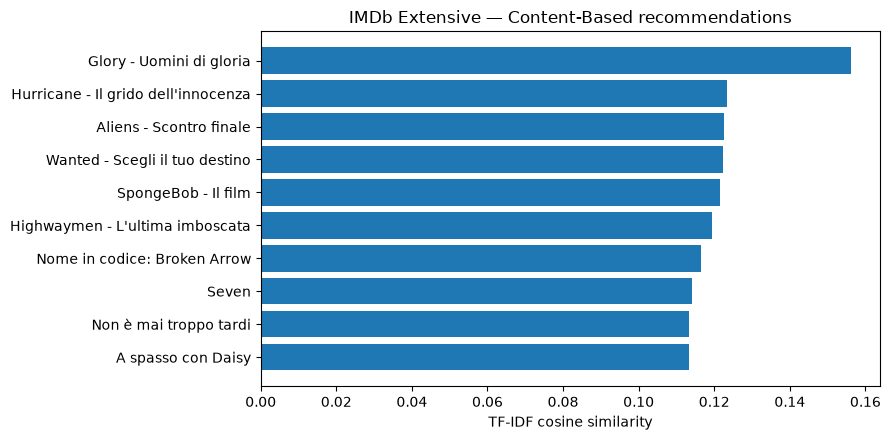

In [4]:
imdb_text=(imdb_movies.genre.str.replace(',',' ',regex=False)+' '+
           imdb_movies.director.str.replace(',',' ',regex=False)+' '+
           imdb_movies.actors.str.replace(',',' ',regex=False)+' '+imdb_movies.description)
imdb_vectorizer=TfidfVectorizer(stop_words='english',ngram_range=(1,2),max_features=6000)
imdb_features=imdb_vectorizer.fit_transform(imdb_text)
imdb_title=str(imdb_movies.iloc[0].title)
imdb_content=recommend_by_content(imdb_movies,imdb_features,imdb_title,k=10)
print('Selected IMDb title:',imdb_title)
display(imdb_content.round(4))
assert len(imdb_content)==10
fig,ax=plt.subplots(figsize=(9,4.5));table=imdb_content.iloc[::-1]
ax.barh(table.title.str.slice(0,38),table.cosine_similarity)
ax.set(title='IMDb Extensive — Content-Based recommendations',xlabel='TF-IDF cosine similarity')
fig.tight_layout();plt.show()


## Task 2 — Collaborative Filtering approximation

The IMDb Extensive ratings file contains **aggregated audience statistics**, not `userId`–`movieId`–`rating` interactions. I therefore compare six demographic audience groups instead of claiming personalized recommendations.

I represent their film-average ratings in a group-by-movie matrix, require at least **30 votes** for a group/movie observation, and calculate **Pearson correlations** for groups with enough common movies. I estimate a group's missing average rating from positively correlated groups.

For evaluation, I hide approximately **15% of eligible observed group averages**, compute predictions from training observations only, and report **MAE**, **RMSE** and a simple training-group-mean baseline. The scores describe group-average errors on IMDb's 1–10 scale, not individuals' preferences.


IMDb matrix dimensions (groups × movies): (6, 3000)


,Women 18–29,Women 30–44,Women 45+,Men 18–29,Men 30–44,Men 45+
Women 18–29,1.000,0.978,0.915,0.940,0.923,0.894
Women 30–44,0.978,1.000,0.952,0.937,0.948,0.936
Women 45+,0.915,0.952,1.000,0.870,0.893,0.950
Men 18–29,0.940,0.937,0.870,1.000,0.984,0.935
Men 30–44,0.923,0.948,0.893,0.984,1.000,0.964
Men 45+,0.894,0.936,0.950,0.935,0.964,1.000


,Value
Held-out group means,2700.000000
MAE,0.183546
RMSE,0.247744
Training-group-mean baseline MAE,0.704668


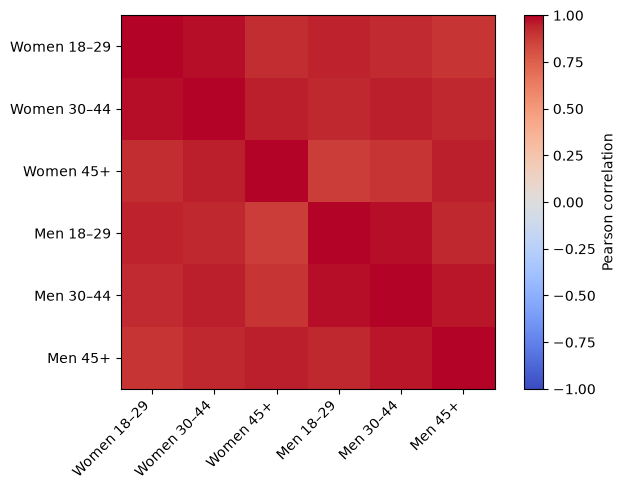

In [5]:
def make_cohort_matrix(frame,min_votes=30):
    rows=[]
    for mean_col,votes_col in COHORTS.values():
        mean=pd.to_numeric(frame[mean_col],errors='coerce')
        nvotes=pd.to_numeric(frame[votes_col],errors='coerce').fillna(0)
        rows.append(mean.where(mean.between(1,10)&nvotes.ge(min_votes)).to_numpy(float))
    return pd.DataFrame(rows,index=list(COHORTS),columns=frame.imdb_title_id.tolist())

def group_similarity(groups,min_overlap=15):
    x=groups.to_numpy(float);n=x.shape[0];sim=np.eye(n)
    for i in range(n):
        for j in range(i+1,n):
            valid=np.isfinite(x[i])&np.isfinite(x[j])
            if valid.sum()>=min_overlap and np.std(x[i,valid])>1e-12 and np.std(x[j,valid])>1e-12:
                s=np.corrcoef(x[i,valid],x[j,valid])[0,1]
                sim[i,j]=sim[j,i]=float(np.clip(s,-1,1)) if np.isfinite(s) else 0.0
            else:sim[i,j]=sim[j,i]=0.0
    return pd.DataFrame(sim,index=groups.index,columns=groups.index)

def predict_group_average(groups,similarity,row,col):
    x=groups.to_numpy(float)
    group_av=np.nanmean(x,axis=1)
    global_mean=float(np.nanmean(x))
    base=float(group_av[row]) if np.isfinite(group_av[row]) else global_mean
    w=similarity.iloc[row].to_numpy(float).copy();w[row]=0
    good=(w>0)&np.isfinite(x[:,col])&np.isfinite(group_av)
    if not good.any():return float(np.clip(base,1,10))
    result=base+np.dot(w[good],x[good,col]-group_av[good])/w[good].sum()
    return float(np.clip(result,1,10))

def evaluate_groups(groups,seed=42,fraction=0.15):
    x=groups.to_numpy(float)
    pairs=np.argwhere(np.isfinite(x))
    if len(pairs)<60:raise ValueError('Need at least 60 observed demographic averages for validation')
    rng=np.random.default_rng(seed);rng.shuffle(pairs)
    train=groups.copy()
    withheld=[];max_holdout=max(1,round(len(pairs)*fraction))
    for row,col in pairs:
        if len(withheld)>=max_holdout:break
        if train.iloc[row].notna().sum()<=15 or train.iloc[:,col].notna().sum()<=2:continue
        withheld.append((int(row),int(col),float(groups.iloc[row,col])))
        train.iloc[row,col]=np.nan
    if not withheld:raise ValueError('Unable to select any evaluable holdout')
    sims=group_similarity(train)
    y_true=np.array([value for _,_,value in withheld])
    y_pred=np.array([predict_group_average(train,sims,row,col) for row,col,_ in withheld])
    group_means=np.nanmean(train.to_numpy(float),axis=1)
    baseline=np.array([group_means[row] for row,_,_ in withheld])
    diff=y_pred-y_true
    return {'Held-out group means':len(y_true),'MAE':float(np.mean(abs(diff))),
            'RMSE':float(np.sqrt(np.mean(diff**2))),
            'Training-group-mean baseline MAE':float(np.mean(abs(baseline-y_true)))},train

imdb_groups=make_cohort_matrix(imdb_movies)
imdb_sim=group_similarity(imdb_groups)
print('IMDb matrix dimensions (groups × movies):',imdb_groups.shape)
display(imdb_sim.round(3))
imdb_scores,imdb_train_groups=evaluate_groups(imdb_groups)
display(pd.DataFrame([imdb_scores]).T.rename(columns={0:'Value'}))
assert np.isfinite(imdb_scores['MAE'])
fig,ax=plt.subplots(figsize=(7,5))
heat=ax.imshow(imdb_sim.to_numpy(),vmin=-1,vmax=1,cmap='coolwarm')
ax.set_xticks(range(6),imdb_sim.columns,rotation=45,ha='right')
ax.set_yticks(range(6),imdb_sim.index)
fig.colorbar(heat,ax=ax,label='Pearson correlation');fig.tight_layout();plt.show()


In [6]:
# Example estimates for a named cohort. If no cells are missing, demonstrate estimates for sufficiently observed movies.
chosen_group='Women 18–29'; row=list(imdb_groups.index).index(chosen_group)
available=np.flatnonzero(imdb_groups.iloc[row].isna().to_numpy() & (imdb_groups.notna().sum(axis=0).to_numpy()>=2))
reason='Missing group-average estimates'
if not len(available):
    available=np.flatnonzero(imdb_groups.notna().sum(axis=0).to_numpy()>=3)
    reason='Illustrative group-average estimates for observed movie IDs (not unobserved personal preferences)'
if not len(available):raise ValueError('Not enough IMDb group-mean observations for ranking')
est=np.array([predict_group_average(imdb_groups,imdb_sim,row,int(j)) for j in available])
order=np.argsort(-est)[:10]
keys=imdb_groups.columns[available[order]]
imdb_group_top=imdb_movies.set_index('imdb_title_id').loc[keys,['title','genre','avg_vote']].copy()
imdb_group_top['estimated_group_average']=est[order]
print('IMDb group:',chosen_group,'|',reason)
display(imdb_group_top.reset_index())


IMDb group: Women 18–29 | Illustrative group-average estimates for observed movie IDs (not unobserved personal preferences)


,imdb_title_id,title,genre,avg_vote,estimated_group_average
0,tt0111161,Le ali della libertà,Drama,9.3,9.369949
1,tt0068646,Il padrino,"Crime, Drama",9.2,9.247216
2,tt0071562,Il padrino - Parte II,"Crime, Drama",9.0,9.047216
3,tt0108052,Schindler's List,"Biography, Drama, History",8.9,9.030874
4,tt0050083,La parola ai giurati,"Crime, Drama",8.9,8.990699
5,tt0167260,Il Signore degli Anelli - Il ritorno del re,"Action, Adventure, Drama",8.9,8.971838
6,tt0120737,Il Signore degli Anelli - La compagnia dell'An...,"Action, Adventure, Drama",8.8,8.930058
7,tt0468569,Il cavaliere oscuro,"Action, Crime, Drama",9.0,8.873832
8,tt0110912,Pulp Fiction,"Crime, Drama",8.9,8.867750
9,tt0109830,Forrest Gump,"Drama, Romance",8.8,8.831569


## My results and interpretation

I compare the two **required IMDb methods**, not different rating scales or unrelated datasets. Content-Based Filtering yields a ranked list of similar movies, whereas the cohort-correlation approach produces estimated **group-level averages**. These methods answer different questions, so I do not compare their cosine similarity values with MAE/RMSE as if they were identical measurements.


In [7]:
summary = pd.DataFrame([
 {'Task':'1 — Content-Based', 'Data':'Movie descriptions and metadata', 'Result':f'{len(imdb_content)} recommended films', 'Measurement':'TF-IDF cosine similarity'},
 {'Task':'2 — Cohort rating patterns', 'Data':'Six demographic rating groups', 'Result':f'{imdb_scores["Held-out group means"]} held-out group means', 'Measurement':f'MAE {imdb_scores["MAE"]:.4f}; RMSE {imdb_scores["RMSE"]:.4f}; baseline MAE {imdb_scores["Training-group-mean baseline MAE"]:.4f}'}
])
display(summary)
print('PASS — Both assigned IMDb recommendation methods completed from embedded real source records.')


,Task,Data,Result,Measurement
0,1 — Content-Based,Movie descriptions and metadata,10 recommended films,TF-IDF cosine similarity
1,2 — Cohort rating patterns,Six demographic rating groups,2700 held-out group means,MAE 0.1835; RMSE 0.2477; baseline MAE 0.7047


PASS — Both assigned IMDb recommendation methods completed from embedded real source records.


## My conclusion

I found that the **Content-Based** method recommends movies based on information describing their content. My second approach studies IMDb's **demographic rating patterns** using correlations between cohort averages; because it does not contain individual user histories, it cannot predict a particular viewer's preferences in the way that user-based collaborative filtering or SVD can.

**Limitations:** I used 3,000 selected IMDb titles rather than the entire original collection; popular titles are overrepresented. Cohort averages are aggregated statistics, not personal ratings. I reported held-out evaluation with a training-only baseline and documented the scope of each result.

**Sources:** [Stefano Leone, IMDb Extensive](https://www.kaggle.com/datasets/stefanoleone992/imdb-extensive-dataset); Professor Beth Muturi's Assignment 8 notebook; [Rounak Banik, Movie Recommender Systems](https://www.kaggle.com/code/rounakbanik/movie-recommender-systems); [scikit-learn TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).
